# RGB Wound 3D Reconstruction: real SALVE + audited Syn3DWound

### Principal evidence
- Our RGB-estimated cameras + RGB-only reviewed masks recover a connected supported
  Syn3DWound sacrum surface, independently compared to held-out synthetic geometry.
- The primary real benchmark **SALVE was acquired**, not merely its paper:
  all required RGB/calibration/scanner-GT inputs and all published aligned outputs.
  Both real recording devices were evaluated separately.
- Our initial real SALVE CPU SGBM trials fail cross-pair consistency. Independently
  evaluated published meshes show that usable real RGB wound geometry **does exist**.
- No marker size is invented. All mm errors are **after GT-derived evaluation
  alignment**, not independently recovered physical scale or clinical accuracy.

In [2]:
from pathlib import Path
import os

EXPERIMENT_MODE = "DATASET_RESCUE"  # or "LEGACY_M0_M1"
DATASET = "SALVE"                  # "SALVE" or "SYN3DWOUND"
METHOD = "COLMAP"                  # "COLMAP", "MESHROOM", "NEUS_FACTO", "NEURALANGELO"
ACTION = "REPLAY"                  # see selectable experiment modes below; REPLAY never reruns acquisition
DEVICE = "iPhone"                  # "iPhone" or "Logitech"; do not mix devices in SfM
WOUND = "PIS4"
SYN_SEQUENCE = "Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta"
LICENCE_ACKNOWLEDGED = False        # CC BY-NC-SA 4.0 public benchmark; no redistribution
ROOT = Path(os.environ.get("RGB_WOUND_REPO", Path.cwd()))
INPUT_ROOT = Path(os.environ.get("RGB_RESCUE_INPUT",
    ROOT / "data" / "rgb_wound" / ("salve" if DATASET == "SALVE" else "syn_audit")))
SAVED_RESULTS = Path(os.environ.get("RGB_RESCUE_SAVED", ROOT / "results" / "rgb_wound" / "dataset_rescue"))
assert EXPERIMENT_MODE in {"DATASET_RESCUE", "LEGACY_M0_M1"}
assert DATASET in {"SALVE", "SYN3DWOUND"}
assert METHOD in {"COLMAP", "MESHROOM", "NEUS_FACTO", "NEURALANGELO"}
assert ACTION in {"REPLAY", "RECONSTRUCT", "EVALUATE_PUBLISHED", "NATIVE_SALVE", "SENSOR_ROUTER", "SENSOR_GENERALIZATION", "CALIBRATION_SAFETY", "STRICT_CALIBRATION_HOLDOUT", "CLEAN_MEASUREMENT_VALIDITY", "OBSERVABLE_GEOMETRY"}
NATIVE_REQUIRE_GPU = True  # False ONLY for explicitly labeled local CPU diagnostics
SENSOR_OUTPUT_BASE = Path(os.environ.get("RGB_SENSOR_OUTPUT",
    "/kaggle/working/sensor_router" if Path("/kaggle/working").exists()
    else ROOT/"results"/"rgb_wound"/"sensor_router"))
SENSOR_SEQUENCE = "Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta"

GENERALIZATION_INPUT = Path(os.environ.get("RGB_GENERALIZATION_INPUT",
    ROOT/"results"/"rgb_wound"/"sensor_generalization"))
GENERALIZATION_OUTPUT = Path(os.environ.get("RGB_GENERALIZATION_OUTPUT",
    "/kaggle/working/sensor_generalization/runs" if Path("/kaggle/working").exists()
    else GENERALIZATION_INPUT/"runs"))
GENERALIZATION_SEQUENCES = ["shoulder", "arm", "hand", "sacrum_phi"]
GENERALIZATION_RUN_RGB = True
GENERALIZATION_RUN_DEPTH = True

CALIBRATION_TARGET = "VIRTUAL_CHARUCO_STEPPED"
CALIBRATION_OUTPUT = Path(os.environ.get("RGB_CALIBRATION_OUTPUT",
    '/kaggle/working/calibration_safety/v2' if Path("/kaggle/working").exists()
    else ROOT.joinpath("results", "rgb_wound", 'calibration_safety', 'v2')))

STRICT_HOLDOUT_OUTPUT = Path(os.environ.get("RGB_STRICT_HOLDOUT_OUTPUT",
    "/kaggle/working/strict_calibration_holdout" if Path("/kaggle/working").exists()
    else ROOT/"results"/"rgb_wound"/"strict_calibration_holdout"))

CLEAN_MEASUREMENT_OUTPUT = Path(os.environ.get("RGB_CLEAN_MEASUREMENT_OUTPUT",
    "/kaggle/working/clean_measurement_validity" if Path("/kaggle/working").exists()
    else ROOT/"results"/"rgb_wound"/"clean_measurement_validity"))

OBSERVABLE_OUTPUT = Path(os.environ.get("RGB_OBSERVABLE_OUTPUT",
    "/kaggle/working/observable_geometry" if Path("/kaggle/working").exists()
    else ROOT/"results"/"rgb_wound"/"observable_geometry"))


In [3]:
import importlib.util, subprocess, sys, json, csv, hashlib, time, math, gc
import urllib.parse, urllib.request
from datetime import datetime, timezone

if EXPERIMENT_MODE == "DATASET_RESCUE":
    if ACTION == "NATIVE_SALVE" and NATIVE_REQUIRE_GPU and sys.platform == "linux":
        import importlib.metadata
        try:
            cuda_wheel = importlib.metadata.version("pycolmap-cuda12")
        except importlib.metadata.PackageNotFoundError:
            cuda_wheel = None
        if cuda_wheel != "4.2.1":
            subprocess.check_call([sys.executable,"-m","pip","install","pycolmap-cuda12==4.2.1"])
    dependencies = {"numpy":"numpy", "scipy":"scipy", "cv2":"opencv-contrib-python-headless",
        "open3d":"open3d", "pycolmap":"pycolmap==4.2.1", "matplotlib":"matplotlib", "plotly":"plotly", "PIL":"pillow"}
    missing = [package for module,package in dependencies.items() if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.check_call([sys.executable,"-m","pip","install","--quiet",*missing])
import cv2, numpy as np, open3d as o3d, pycolmap, matplotlib.pyplot as plt, plotly.graph_objects as go
from scipy.spatial import Delaunay, cKDTree, ConvexHull
from matplotlib.path import Path as PolygonPath
from PIL import Image, ImageDraw
from IPython.display import display, Markdown, Image as NotebookImage
cv2.setNumThreads(3)
OUTPUT_BASE = Path(os.environ.get("RGB_RESCUE_OUTPUT",
    Path("/kaggle/working/rgb_wound") if Path("/kaggle/working").exists() else ROOT / "results" / "rgb_wound"))
RESCUE_OUT = OUTPUT_BASE / ("rescue_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%f"))

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## Next milestone: native SALVE PIS4 / iPhone

Synthetic RGB-only feasibility **PASS**; overall real-world validation and our
independent metric-scale recovery **NOT YET PASS**. Physical camera acquisition
**NOT CURRENTLY REQUIRED**. The successful synthetic baseline is hash-sealed,
including both runs and the complete saved replay notebook; do not retune it.

Set `ACTION="NATIVE_SALVE"`, `DATASET="SALVE"`, `METHOD="COLMAP"`,
`DEVICE="iPhone"`, `WOUND="PIS4"`, `LICENCE_ACKNOWLEDGED=True`.
Keep `NATIVE_REQUIRE_GPU=True` for the requested Kaggle experiment.
Enable a Kaggle NVIDIA accelerator. A CUDA12 PyCOLMAP4.2.1 wheel is installed
only in this Linux GPU mode, **before importing PyCOLMAP**. Existing SGBM remains
CPU: GPU accelerates SIFT/matching, not an invented CUDA SGBM implementation.

Attach the prepared PIS4 input bundle (or the acquired SALVE folders plus metadata).
No published meshes or optional 140.94GB checkpoints are needed. The bundle
contains native images, calibration, scanner reference, reviewed masks, source
hashes and the previous common evaluation ROI. For manual folder layout use
`RGB_RESCUE_INPUT` for SALVE and `RGB_NATIVE_META` for the manifest/masks directory.

This mode **actually runs two disjoint25-frame reconstructions**, full2123x3804
RGB, no downsampling/crop, then compares subsets in an RGB-only camera gauge.
Scanner data is used only after reconstruction for explicit rigid-vs-similarity
evaluation. A printed fiducial is visible, but its independently measured side
length is not established; it is NOT used to certify metric scale.

The earlier masks were clipped by a central coordinate box. All50 replacement
native overlays were directly reviewed: coarse outer wound+rim, not expert
anatomical labels. All official frames are accepted; there are no fabricated
rejected examples. Low-sharpness and reflective views remain flagged.

**Current access:** Kaggle browser is logged out; API credentials are absent.
Local full-native executions are CPU diagnostics, never labeled Kaggle results.
This mode fails explicitly if its required GPU/input/license is unavailable.


In [5]:
from pathlib import Path
import ast
import csv
import gc
import hashlib
import importlib.metadata
import json
import math
import os
import shutil
import subprocess
import sys
import time
import cv2
import numpy as np
import open3d as o3d
import plotly.graph_objects as go
import pycolmap
from scipy.spatial import Delaunay, cKDTree
from PIL import Image, ImageDraw
import matplotlib
import matplotlib.pyplot as plt
def native_environment(require_gpu, output):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    smi = shutil.which('nvidia-smi')
    gpu = subprocess.run([smi, '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'], capture_output=True, text=True, check=True).stdout.strip() if smi else None
    cuda = subprocess.run([smi], capture_output=True, text=True, check=True).stdout if smi else None
    receipt = dict(gpu=gpu, cuda_driver_report=cuda, pycolmap_has_cuda=bool(pycolmap.has_cuda), python=sys.version, execution_kind='KAGGLE_GPU' if gpu and Path('/kaggle').exists() else 'LOCAL_CPU_DIAGNOSTIC_NOT_KAGGLE', packages={**{name: importlib.metadata.version(name) for name in ('numpy', 'scipy', 'open3d', 'Pillow')}, 'pycolmap': pycolmap.__version__}, opencv=cv2.__version__, require_gpu=require_gpu, stereo_acceleration='Existing OpenCV SGBM remains CPU; GPU used for COLMAP SIFT if compiled with CUDA.', independent_metric_scale_valid=False)
    if require_gpu and (not gpu or not pycolmap.has_cuda):
        receipt.update(status='BLOCKED_NOT_RUN', reason='NVIDIA GPU and CUDA-enabled PyCOLMAP required for requested Kaggle run.')
    else:
        receipt['status'] = 'READY'
    (output / 'environment.json').write_text(json.dumps(receipt, indent=2))
    print(json.dumps(receipt, indent=2), flush=True)
    if receipt['status'] != 'READY':
        raise RuntimeError(receipt['reason'] + ' No CPU substitution or published-mesh fallback.')
    return receipt
def native_verify_inputs(data, manifest, masks):
    (data, masks) = (Path(data), Path(masks))
    seq = data / 'Training_Data' / 'Accuracy' / 'iPhone' / 'PIS4'
    files = sorted((seq / 'images').glob('*.jpg'))
    if len(files) != manifest['available_frames']:
        raise ValueError('PIS4/iPhone image count differs from reviewed native manifest.')
    if hashlib.sha256((data / manifest['scanner_file']).read_bytes()).hexdigest() != manifest['scanner_sha256']:
        raise ValueError('Scanner file differs from recorded reference.')
    for record in manifest['calibration_and_evaluation_files']:
        if hashlib.sha256((data / record['path']).read_bytes()).hexdigest() != record['sha256']:
            raise ValueError('Calibration/evaluation reference hash mismatch: ' + record['path'])
    calibration = pycolmap.Reconstruction(str(seq / 'sparse' / '0'))
    cameras = list(calibration.cameras.values())
    if len(cameras) != 1 or cameras[0].model_name != 'PINHOLE' or (not np.allclose(cameras[0].calibration_matrix(), manifest['K'])):
        raise ValueError('Native calibration model/intrinsics differ from reviewed manifest.')
    records = {r['name']: r for r in manifest['frames']}
    if set(records) != {p.name for p in files}:
        raise ValueError('Native image names differ from reviewed manifest.')
    for path in files:
        record = records[path.name]
        if record['review_status'] != 'REVIEWED_COARSE_OUTER_WOUND':
            raise ValueError('Unreviewed wound mask: ' + path.name)
        if hashlib.sha256(path.read_bytes()).hexdigest() != record['sha256']:
            raise ValueError('RGB hash mismatch: ' + path.name)
        mask_file = masks / (path.stem + '.png')
        if hashlib.sha256(mask_file.read_bytes()).hexdigest() != record['mask_sha256']:
            raise ValueError('Reviewed mask hash mismatch: ' + path.name)
        image = cv2.imread(str(path))
        mask = cv2.imread(str(mask_file), cv2.IMREAD_GRAYSCALE)
        if image is None or mask is None or image.shape[:2] != mask.shape:
            raise ValueError('Image/mask shape mismatch: ' + path.name)
        if image.shape[1::-1] != tuple(manifest['image_dimensions']) or not set(np.unique(mask)) <= {0, 255}:
            raise ValueError('Not native RGB / binary reviewed mask: ' + path.name)
    return (seq, files, records)
def native_pair_pixel_medians(points, R, t, K, region):
    cam = points @ R.T + t
    p = cam @ K.T
    uv = np.rint(p[:, :2] / np.maximum(cam[:, 2:3], 1e-12)).astype(int)
    (h, w) = region.shape
    ok = (cam[:, 2] > 0) & (uv[:, 0] >= 0) & (uv[:, 0] < w) & (uv[:, 1] >= 0) & (uv[:, 1] < h)
    idx = np.flatnonzero(ok)
    idx = idx[region[uv[idx, 1], uv[idx, 0]]]
    if not len(idx):
        return np.empty((0, 3))
    pixel = uv[idx, 1] * w + uv[idx, 0]
    order = np.lexsort((cam[idx, 2], pixel))
    (pixel, depth) = (pixel[order], cam[idx[order], 2])
    (unique, start, count) = np.unique(pixel, return_index=True, return_counts=True)
    mid = start + count // 2
    z = (depth[mid] + depth[start + (count - 1) // 2]) / 2
    rays = np.column_stack([unique % w, unique // w, np.ones(len(unique))]) @ np.linalg.inv(K).T
    return (rays * z[:, None] - t) @ R
def native_fit_correspondences(source, target, optimize_scale):
    (source, target) = (np.asarray(source), np.asarray(target))
    if source.shape != target.shape or source.ndim != 2 or source.shape[1] != 3 or (len(source) < 3):
        raise ValueError('Alignment requires at least three paired 3D points.')
    (a, b) = (source.mean(0), target.mean(0))
    if not np.isfinite(source).all() or not np.isfinite(target).all() or np.linalg.matrix_rank(source - a) < 2:
        raise ValueError('Alignment correspondences must be finite and non-collinear.')
    (u, s, vt) = np.linalg.svd((target - b).T @ (source - a) / len(source))
    sign = np.ones(3)
    sign[-1] = np.linalg.det(u @ vt)
    rotation = u @ np.diag(sign) @ vt
    scale = float((s * sign).sum() / np.mean(np.sum((source - a) ** 2, axis=1))) if optimize_scale else 1.0
    transform = np.eye(4)
    transform[:3, :3] = scale * rotation
    transform[:3, 3] = b - scale * rotation @ a
    return transform
def native_transform(points, transform):
    return np.asarray(points) @ transform[:3, :3].T + transform[:3, 3]
def native_gate(result, repeatability=None):
    required = {'registered_fraction': 0.5, 'stable_mask_fraction_all_pixels': 0.7, 'surface_retained_fraction': 0.8, 'scanner_bed_completeness_1mm': 0.8}
    checks = {k: result.get(k) is not None and result[k] >= v for (k, v) in required.items()}
    checks['cross_view_iqr'] = result.get('median_cross_pair_iqr_over_width') is not None and result['median_cross_pair_iqr_over_width'] < 1
    checks['connected_supported_surface'] = result.get('surface_components') == 1
    checks['bed_error'] = result.get('scanner_bed_mean_error_mm') is not None and result['scanner_bed_mean_error_mm'] <= 1
    checks['independent_subsets'] = repeatability is not None and repeatability.get('mean_disagreement_over_width') is not None and (repeatability['mean_disagreement_over_width'] <= 0.05)
    if all(checks.values()):
        status = 'PASS'
    elif not checks['connected_supported_surface'] or not checks['cross_view_iqr']:
        status = 'FAILED'
    else:
        numeric = [(result.get('stable_mask_fraction_all_pixels') or 0) / 0.7, (result.get('scanner_bed_completeness_1mm') or 0) / 0.8, 1 / max(result.get('scanner_bed_mean_error_mm') or math.inf, 1e-12)]
        status = 'PARTIAL' if min(numeric) >= 0.9 and sum(checks.values()) >= len(checks) - 1 else 'FAILED'
    return dict(status=status, checks=checks, engineering_not_clinical=True)
def native_surface_scores(points, predicted_mesh, scanner_points, scanner_mesh, tolerances=(0.5, 1.0, 2.0)):
    if not len(points) or not len(scanner_points):
        raise ValueError('Surface scores require nonempty prediction and scanner ROI.')
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(scanner_mesh))
    d = scene.compute_distance(o3d.core.Tensor(np.asarray(points, np.float32))).numpy()
    if not len(predicted_mesh.triangles):
        back = cKDTree(points).query(scanner_points)[0]
        completeness_kind = 'distance to candidate points, no supported surface'
    else:
        pred = o3d.t.geometry.RaycastingScene()
        pred.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(predicted_mesh))
        back = pred.compute_distance(o3d.core.Tensor(np.asarray(scanner_points, np.float32))).numpy()
        completeness_kind = 'scanner ROI points to supported triangle surface'
    forward_nn = cKDTree(scanner_points).query(points)[0]
    backward_nn = cKDTree(points).query(scanner_points)[0]
    return dict(mean=float(d.mean()), median=float(np.median(d)), p90=float(np.percentile(d, 90)), p95=float(np.percentile(d, 95)), chamfer_l1=float((forward_nn.mean() + backward_nn.mean()) / 2), completeness={str(t): float(np.mean(back <= t)) for t in tolerances}, gt_samples=len(scanner_points), predicted_samples=len(points), completeness_kind=completeness_kind, distances=d)
def native_run(data, manifest, mask_dir, output, subset, helpers, require_gpu=True):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=False)
    started = time.perf_counter()
    env = native_environment(require_gpu, output)
    (seq, files, records) = native_verify_inputs(data, manifest, mask_dir)
    selected = files[::2] if subset == 'A' else files[1::2]
    if subset not in ('A', 'B'):
        raise ValueError('Expected disjoint temporal subset A or B.')
    K = np.asarray(manifest['K'], float)
    (w, h) = manifest['image_dimensions']
    conf = dict(subset=subset, images=[p.name for p in selected], native_dimensions=[w, h], pre_stereo_downsampling=False, stereo_input='full native frames, no crop', max_disparity=192, stereo_pair_limit=70, neighbor_offsets=[1, 2, 3, 4], stable_iqr_over_width=0.25, mask_agreement=0.7, min_views=3, native_triangle_edge_limit=2.5, triangle_edge_width_limit=0.1, seed=42, masks='Hash-bound assistant-reviewed coarse outer region incl rim', metric_scale_valid=False, environment=env)
    (output / 'configuration.json').write_text(json.dumps(conf, indent=2))
    image_dir = output / 'images'
    image_dir.mkdir()
    for path in selected:
        shutil.copy2(path, image_dir / path.name)
    database = output / 'database.db'
    sparse = output / 'sparse'
    sparse.mkdir()
    reader = pycolmap.ImageReaderOptions()
    reader.camera_model = 'PINHOLE'
    reader.camera_params = ','.join(map(str, [K[0, 0], K[1, 1], K[0, 2], K[1, 2]]))
    extraction = pycolmap.FeatureExtractionOptions()
    extraction.num_threads = 3
    extraction.max_image_size = max(w, h)
    extraction.sift.max_num_features = 8192
    device = pycolmap.Device.cuda if require_gpu else pycolmap.Device.cpu
    pycolmap.extract_features(database, image_dir, camera_mode=pycolmap.CameraMode.SINGLE, reader_options=reader, extraction_options=extraction, device=device)
    matching = pycolmap.FeatureMatchingOptions()
    matching.num_threads = 3
    pycolmap.match_exhaustive(database, matching_options=matching, device=device)
    mapper = pycolmap.IncrementalPipelineOptions()
    mapper.num_threads = 3
    mapper.random_seed = 42
    mapper.multiple_models = False
    mapper.init_num_trials = 40
    mapper.ba_global_max_num_iterations = 40
    mapper.ba_refine_focal_length = False
    mapper.ba_refine_principal_point = False
    mapper.ba_refine_extra_params = False
    mapper.mapper.abs_pose_refine_focal_length = False
    mapper.mapper.abs_pose_refine_extra_params = False
    models = pycolmap.incremental_mapping(database, image_dir, sparse, options=mapper)
    if not models:
        (output / 'failure.json').write_text(json.dumps(dict(stage='RGB_SFM', reason='No registered model'), indent=2))
        raise RuntimeError('Native RGB SfM failed.')
    rec = max(models.values(), key=lambda r: r.num_reg_images())
    rec.write(str(sparse / '0'))
    poses = {i.name: (i.cam_from_world().rotation.matrix(), i.cam_from_world().translation) for i in rec.images.values() if i.has_pose}
    sparse_xyz = np.array([p.xyz for p in rec.points3D.values()])
    errors = []
    for image in rec.images.values():
        if not image.has_pose:
            continue
        (R, t) = poses[image.name]
        for point in image.points2D:
            if point.has_point3D():
                q = K @ (R @ rec.points3D[point.point3D_id].xyz + t)
                if q[2] > 0:
                    errors.append(float(np.linalg.norm(q[:2] / q[2] - point.xy)))
    names = sorted(poses)
    ref = names[len(names) // 2]
    masks = {name: cv2.imread(str(Path(mask_dir) / (Path(name).stem + '.png')), 0) > 0 for name in names}
    images = {name: cv2.imread(str(seq / 'images' / name)) for name in names}
    region = cv2.dilate(masks[ref].astype(np.uint8), np.ones((121, 121), np.uint8)) > 0
    centers = np.array([-R.T @ t for (R, t) in poses.values()])
    pc = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(sparse_xyz))
    o3d.io.write_point_cloud(str(output / 'sparse_RGB.ply'), pc)
    fig = go.Figure([go.Scatter3d(x=sparse_xyz[:, 0], y=sparse_xyz[:, 1], z=sparse_xyz[:, 2], mode='markers', marker=dict(size=1), name='RGB sparse'), go.Scatter3d(x=centers[:, 0], y=centers[:, 1], z=centers[:, 2], mode='lines+markers', name='estimated cameras')])
    fig.update_layout(scene_aspectmode='data', title='Independently estimated native RGB cameras; arbitrary scale')
    fig.write_html(str(output / 'cameras_sparse.html'), include_plotlyjs=True)
    (output / 'poses.json').write_text(json.dumps({n: dict(R=r.tolist(), t=t.tolist()) for (n, (r, t)) in poses.items()}, indent=2))
    (receipts, pts, ids) = ([], [], [])
    candidates = [(a, b) for (i, a) in enumerate(names) for b in names[i + 1:i + 5]]
    indices = np.unique(np.rint(np.linspace(0, len(candidates) - 1, min(70, len(candidates)))).astype(int))
    for (pair_id, index) in enumerate(indices):
        (a, b) = candidates[index]
        receipt = dict(a=a, b=b, status='rejected')
        pair_start = time.perf_counter()
        for (aa, bb) in ((a, b), (b, a)):
            try:
                (xyz, _, _) = helpers['dense_pair'](images[aa], images[bb], poses[aa], poses[bb], K, w, 192)
                local = native_pair_pixel_medians(xyz, *poses[ref], K, region)
                if len(local) < 20:
                    raise ValueError('Fewer than20 local native pixels.')
                pts.append(local)
                ids.append(np.full(len(local), pair_id, np.int32))
                receipt.update(status='accepted', local_pixels=len(local), direction=[aa, bb])
                break
            except (ValueError, cv2.error) as error:
                receipt['reason'] = str(error).splitlines()[0]
        receipt['seconds'] = time.perf_counter() - pair_start
        receipts.append(receipt)
        (output / 'pair_receipts.json').write_text(json.dumps(receipts, indent=2))
        if pair_id % 10 == 0:
            print(subset, 'native pair', pair_id, receipt['status'], receipt['seconds'], flush=True)
        gc.collect()
    if not pts:
        raise RuntimeError('No native stereo pair produced local evidence; pair receipts retained.')
    xyz = np.concatenate(pts)
    pair_ids = np.concatenate(ids)
    del pts, ids
    gc.collect()
    o3d.io.write_point_cloud(str(output / 'dense_local_candidate_arbitrary.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(xyz)))
    consensus = helpers['per_pixel_pair_consensus'](xyz, pair_ids, *poses[ref], K, region)
    np.savez_compressed(output / 'consensus.npz', consensus=consensus, K=K, region=region, reference=ref)
    if not len(consensus):
        raise RuntimeError('No native pixels supported by at least three distinct stereo pairs.')
    uv = consensus[:, :2].astype(int)
    bed_rows = masks[ref][uv[:, 1], uv[:, 0]]
    bed = consensus[bed_rows]
    (R, t) = poses[ref]
    q = sparse_xyz @ R.T + t
    proj = q @ K.T
    suv = np.rint(proj[:, :2] / np.maximum(q[:, 2:3], 1e-12)).astype(int)
    valid = (q[:, 2] > 0) & (suv[:, 0] >= 0) & (suv[:, 0] < w) & (suv[:, 1] >= 0) & (suv[:, 1] < h)
    idx = np.flatnonzero(valid)
    idx = idx[region[suv[idx, 1], suv[idx, 0]]]
    if len(idx) < 10:
        raise RuntimeError('Insufficient independently triangulated local points to normalize wound-width diagnostic.')
    width = float(np.median(q[idx, 2]) * records[ref]['wound_width_px'] / K[0, 0])
    rays = np.column_stack([consensus[:, :2], np.ones(len(consensus))]) @ np.linalg.inv(K).T
    candidate_xyz = (rays * consensus[:, 2, None] - t) @ R
    votes = np.zeros(len(candidate_xyz))
    visible = np.zeros(len(candidate_xyz))
    for name in names:
        (cr, ct) = poses[name]
        v = candidate_xyz @ cr.T + ct
        p = v @ K.T
        px = np.rint(p[:, :2] / np.maximum(v[:, 2:3], 1e-12)).astype(int)
        ok = (v[:, 2] > 0) & (px[:, 0] >= 0) & (px[:, 0] < w) & (px[:, 1] >= 0) & (px[:, 1] < h)
        visible += ok
        j = np.flatnonzero(ok)
        votes[j] += masks[name][px[j, 1], px[j, 0]]
    agreement = np.divide(votes, visible, out=np.zeros_like(votes), where=visible > 0)
    stable = consensus[:, 3] / width <= 0.25
    bed_support = stable & bed_rows & (agreement >= 0.7) & (visible >= 3)
    skin_support = stable & ~bed_rows & (agreement <= 0.3) & (visible >= 3)
    bed_xyz = candidate_xyz[bed_rows]
    surface = o3d.geometry.TriangleMesh()
    triangles = np.empty((0, 3), int)
    retained = 0.0
    components = 0
    if bed_support.sum() >= 20:
        supported_uv = uv[bed_support]
        supported_xyz = candidate_xyz[bed_support]
        (triangles, _) = helpers['supported_mesh'](supported_uv.astype(float), edge_factor=2.5)
        if len(triangles):
            edge = np.linalg.norm(supported_xyz[triangles] - np.roll(supported_xyz[triangles], 1, axis=1), axis=2)
            midpoint = (supported_uv[triangles] + np.roll(supported_uv[triangles], 1, axis=1)) / 2
            midpoint = np.rint(midpoint).astype(int)
            inside = masks[ref][midpoint[:, :, 1], midpoint[:, :, 0]].all(1)
            triangles = triangles[(edge < 0.1 * width).all(1) & inside]
        surface = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(supported_xyz), o3d.utility.Vector3iVector(triangles))
        if len(triangles):
            (labels, counts, _) = surface.cluster_connected_triangles()
            components = len(counts)
            winner = int(np.argmax(counts))
            retained = float(np.max(counts) / sum(counts))
            surface.remove_triangles_by_mask(np.asarray(labels) != winner)
            surface.remove_unreferenced_vertices()
            surface.compute_vertex_normals()
            o3d.io.write_triangle_mesh(str(output / 'supported_wound_candidate_arbitrary.ply'), surface)
            boundary = helpers['boundary_edges'](np.asarray(surface.triangles))
            boundary_xyz = np.asarray(surface.vertices)[np.unique(boundary)]
            o3d.io.write_point_cloud(str(output / 'support_boundary_NOT_anatomical_GT.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(boundary_xyz)))
    o3d.io.write_point_cloud(str(output / 'surrounding_supported_arbitrary.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(candidate_xyz[skin_support])))
    support = np.full((h, w), np.nan)
    support[uv[:, 1], uv[:, 0]] = consensus[:, 3] / width
    confidence = np.zeros((h, w))
    confidence[uv[bed_support, 1], uv[bed_support, 0]] = 1
    (fig, axes) = plt.subplots(1, 3, figsize=(14, 6))
    axes[0].imshow(cv2.cvtColor(images[ref], cv2.COLOR_BGR2RGB))
    axes[0].contour(masks[ref], levels=[0.5], colors='yellow')
    a = axes[1].imshow(support, vmin=0, vmax=2, cmap='magma')
    fig.colorbar(a, ax=axes[1])
    axes[1].set_title('Depth IQR / RGB-SfM wound width')
    axes[2].imshow(confidence, cmap='viridis')
    axes[2].set_title('Supported pixels; black=unsupported')
    (ys, xs) = np.where(region)
    for ax in axes:
        ax.set_xlim(xs.min(), xs.max())
        ax.set_ylim(ys.max(), ys.min())
    fig.tight_layout()
    fig.savefig(output / 'support_disagreement.png', dpi=150)
    plt.close(fig)
    result = dict(subset=subset, available=50, selected=len(selected), registered=len(poses), registered_fraction=len(poses) / len(selected), failed_frames=sorted(set(conf['images']) - set(poses)), reprojection_mean_px=float(np.mean(errors)), reprojection_median_px=float(np.median(errors)), reprojection_p95_px=float(np.percentile(errors, 95)), reference=ref, wound_width_px_median=float(np.median([records[n]['wound_width_px'] for n in names])), wound_width_arbitrary=width, accepted_pairs=sum((r['status'] == 'accepted' for r in receipts)), attempted_pairs=len(receipts), consensus_bed_pixels=len(bed), mask_pixels=int(masks[ref].sum()), median_cross_pair_iqr_over_width=float(np.median(bed[:, 3]) / width) if len(bed) else None, stable_mask_fraction_all_pixels=float((stable & bed_rows).sum() / masks[ref].sum()), supported_mask_fraction_all_pixels=float(bed_support.sum() / masks[ref].sum()), unsupported_mask_fraction=float(1 - bed_support.sum() / masks[ref].sum()), cross_view_mask_agreement_fraction=float(np.mean(agreement[bed_rows] >= 0.7)) if len(bed) else None, surface_prefilter_components=components, surface_retained_fraction=retained, surface_components=1 if len(surface.triangles) else 0, surface_vertices=len(surface.vertices), surface_triangles=len(surface.triangles), scanner_bed_mean_error_mm=None, scanner_bed_completeness_1mm=None, status='CANDIDATE_NOT_VALIDATED', physical_metric_scale_valid=False, runtime_seconds=time.perf_counter() - started, environment=env)
    np.savez_compressed(output / 'candidate.npz', bed=bed_xyz, skin=candidate_xyz[skin_support], stable_bed=candidate_xyz[bed_support], reference=ref)
    result['gate'] = native_gate(result)
    (output / 'result.json').write_text(json.dumps(result, indent=2))
    print(json.dumps(result, indent=2), flush=True)
    return result
def native_evaluate(data, manifest, mask_dir, runs, output, shared_roi, helpers):
    from matplotlib.path import Path as PolygonPath
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    provided = pycolmap.Reconstruction(str(Path(data) / 'Training_Data' / 'Accuracy' / 'iPhone' / 'PIS4' / 'sparse' / '0'))
    pposes = {i.name: (i.cam_from_world().rotation.matrix(), i.cam_from_world().translation) for i in provided.images.values()}
    K = np.asarray(manifest['K'], float)
    M = np.loadtxt(Path(data) / 'transformations' / 'Iphone' / '50' / 'PIS4' / 'transform4x4.txt')
    scanner = o3d.io.read_point_cloud(str(Path(data) / 'GT' / 'PIS4_2.ply')).voxel_down_sample(0.15)
    gt = np.asarray(scanner.points)
    tri = Delaunay(gt[:, :2]).simplices
    tri = tri[(np.linalg.norm(gt[tri] - np.roll(gt[tri], 1, axis=1), axis=2) < 1).all(1)]
    scanner_mesh = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(gt), o3d.utility.Vector3iVector(tri))
    o3d.io.write_triangle_mesh(str(output / 'scanner_2p5D_bounded_1mm_edges.ply'), scanner_mesh)
    roi = np.load(shared_roi)
    common = roi['GT_bed']
    polygon = PolygonPath(roi['polygon_xy'])
    ref = sorted(pposes)[len(pposes) // 2]
    mask = cv2.imread(str(Path(mask_dir) / (Path(ref).stem + '.png')), 0)
    width_record = next((r['wound_width_px'] for r in manifest['frames'] if r['name'] == ref))
    erosion = max(3, round(0.08 * width_record) // 2 * 2 + 1)
    inner = cv2.erode(mask, np.ones((erosion, erosion), np.uint8)) > 0
    ring = (cv2.dilate(mask, np.ones((121, 121), np.uint8)) > 0) & (mask == 0)

    def project_flags(points, region):
        raw = (points - M[:3, 3]) @ np.linalg.inv(M[:3, :3]).T
        (R, t) = pposes[ref]
        q = raw @ R.T + t
        p = q @ K.T
        uv = np.rint(p[:, :2] / np.maximum(q[:, 2:3], 1e-12)).astype(int)
        (h, w) = region.shape
        ok = (q[:, 2] > 0) & (uv[:, 0] >= 0) & (uv[:, 0] < w) & (uv[:, 1] >= 0) & (uv[:, 1] < h)
        flags = np.zeros(len(points), bool)
        i = np.flatnonzero(ok)
        flags[i] = region[uv[i, 1], uv[i, 0]]
        return flags
    gtinner = common[project_flags(common, inner)]
    gtskin = gt[project_flags(gt, ring)]
    np.savez(output / 'scanner_ROIs.npz', common_outer=common, inner_bed=gtinner, surrounding=gtskin)
    rows = []
    gauge = {}
    shape = {}
    for (subset, folder) in runs.items():
        folder = Path(folder)
        result = json.loads((folder / 'result.json').read_text())
        poses = {n: (np.array(v['R']), np.array(v['t'])) for (n, v) in json.loads((folder / 'poses.json').read_text()).items()}
        names = sorted(poses)
        source = np.array([-poses[n][0].T @ poses[n][1] for n in names])
        rgbtarget = np.array([-pposes[n][0].T @ pposes[n][1] for n in names])
        rgb_transform = native_fit_correspondences(source, rgbtarget, True)
        gauge[subset] = rgb_transform
        candidate = np.load(folder / 'candidate.npz')
        raw_bed = candidate['bed']
        skin = candidate['skin']
        mesh_path = folder / 'supported_wound_candidate_arbitrary.ply'
        mesh = o3d.io.read_triangle_mesh(str(mesh_path)) if mesh_path.exists() else o3d.geometry.TriangleMesh()
        shape[subset] = (mesh, raw_bed, skin, result)
        scanner_centers = native_transform(rgbtarget, M)
        for (mode, scale_opt) in (('RIGID_DIAGNOSTIC_RAW_GAUGE', False), ('SIMILARITY_GT_ALIGNED_EVALUATION', True)):
            transform = native_fit_correspondences(source, scanner_centers, scale_opt)
            initial = transform.copy()
            transformed_skin = native_transform(skin, transform)
            icp_receipt = dict(status='NOT_RUN_INSUFFICIENT_SUPPORTED_SURROUNDING', fitness=None)
            if len(skin) >= 50 and len(gtskin) >= 50:
                sourcepc = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(transformed_skin))
                targetpc = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(gtskin))
                icp = o3d.pipelines.registration.registration_icp(sourcepc, targetpc, 2, np.eye(4), o3d.pipelines.registration.TransformationEstimationPointToPoint(False), o3d.pipelines.registration.ICPConvergenceCriteria(max_iteration=40))
                transform = icp.transformation @ transform
                icp_receipt = dict(status='RIGID_ONLY_SURROUNDING_REFINEMENT', fitness=icp.fitness, inlier_rmse=icp.inlier_rmse, scale_optimized_in_refinement=False)
            aligned = native_transform(raw_bed, transform)
            sm = o3d.geometry.TriangleMesh(mesh)
            sm.transform(transform)
            surface_points = np.asarray(sm.vertices) if len(sm.triangles) else aligned
            inner_flags = project_flags(surface_points, inner)
            outer_flags = polygon.contains_points(surface_points[:, :2])
            points = surface_points[inner_flags & outer_flags]
            predinner = o3d.geometry.TriangleMesh(sm)
            if len(sm.triangles):
                face = np.asarray(sm.triangles)
                predinner.remove_triangles_by_mask(~(inner_flags & outer_flags)[face].all(1))
                predinner.remove_unreferenced_vertices()
            scores = None
            if len(points) and len(gtinner):
                scores = native_surface_scores(points, predinner, gtinner, scanner_mesh)
            raw_scores = native_surface_scores(aligned, sm, gtinner, scanner_mesh) if len(aligned) else None
            aligned_skin = native_transform(skin, transform)
            skin_scores = native_surface_scores(aligned_skin, o3d.geometry.TriangleMesh(), gtskin, scanner_mesh) if len(skin) and len(gtskin) else None

            def summary(score):
                return {k: v for (k, v) in score.items() if k != 'distances'} if score is not None else None
            row = dict(subset=subset, alignment_mode=mode, scale_optimized=scale_opt, transform=transform.tolist(), initial_transform=initial.tolist(), determinant_scale=float(np.cbrt(np.linalg.det(transform[:3, :3]))), alignment_initialization='Camera-center correspondences to supplied RGB SfM plus AUTHORS scanner transform; evaluation only.', alignment_refinement=icp_receipt, inner_bed=summary(scores), all_raw_bed_candidate_diagnostic=summary(raw_scores), surrounding=summary(skin_scores), gt_inner_samples=len(gtinner), gt_outer_samples=len(common), gt_skin_samples=len(gtskin), ROI='same published common outer ROI; inner bed = reviewed RGB mask eroded8%width, excludes rim', scanner_surface='0.15mm voxel point cloud + XY interpolation, rejects3Dedges>=1mm', precise_boundary_GT_available=False, units='GT-ALIGNED EVALUATION MEASUREMENT' if scale_opt else 'RAW SfM unit treated as mm ONLY to expose gauge mismatch; not physically interpretable accuracy', metric_scale_independent=False)
            rows.append(row)
            if scale_opt:
                result['scanner_bed_mean_error_mm'] = scores['mean'] if scores else None
                result['scanner_bed_completeness_1mm'] = scores['completeness']['1.0'] if scores else None
                o3d.io.write_point_cloud(str(folder / 'wound_candidate_GT_ALIGNED_EVALUATION.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(aligned)))
                if len(sm.triangles):
                    o3d.io.write_triangle_mesh(str(folder / 'supported_surface_GT_ALIGNED_EVALUATION.ply'), sm)
                if scores:
                    (fig, ax) = plt.subplots(figsize=(7, 6))
                    sc = ax.scatter(points[:, 0], points[:, 1], s=2, c=scores['distances'], vmin=0, vmax=2, cmap='inferno')
                    ax.set_aspect('equal')
                    ax.set_title(subset + ': supported inner-bed error, GT-aligned evaluation')
                    fig.colorbar(sc, ax=ax, label='Approx scanner surface distance(mm)')
                    fig.savefig(folder / 'inner_bed_error_GT_aligned.png', dpi=150)
                    plt.close(fig)
                fig = go.Figure([go.Scatter3d(x=common[:, 0], y=common[:, 1], z=common[:, 2], mode='markers', marker=dict(size=1, color='blue'), name='Independent scanner'), go.Scatter3d(x=aligned[:, 0], y=aligned[:, 1], z=aligned[:, 2], mode='markers', marker=dict(size=1, color='red'), name='Our candidate, NOT validated')])
                fig.update_layout(scene_aspectmode='data', title=subset + ': GT-ALIGNED EVALUATION; not independent scale')
                fig.write_html(str(folder / 'scanner_overlay.html'), include_plotlyjs=True)
                if len(skin) >= 20 and len(mesh.vertices) >= 20:
                    (origin, basis, predict, ref_scores, kind) = helpers['camera_frame_reference'](skin, *poses[result['reference']])
                    local = (np.asarray(mesh.vertices) - origin) @ basis
                    zref = predict(local[:, :2])
                    deficit = zref - local[:, 2]
                    np.savez(folder / 'healthy_reference_arbitrary_ESTIMATED.npz', origin=origin, basis=basis, vertices=np.asarray(mesh.vertices), reference_local_z=zref, deficit_arbitrary=deficit)
                    result['healthy_reference'] = dict(kind=kind, heldout_rmse_arbitrary=ref_scores, status='ESTIMATED_FROM_SUPPORTED_SURROUNDING_NOT_CLINICAL_DEPTH', depth_volume_issued=False)
                    (fig, axes) = plt.subplots(1, 2, figsize=(12, 5), subplot_kw={'projection': '3d'})
                    axes[0].plot_trisurf(local[:, 0], local[:, 1], zref, triangles=np.asarray(mesh.triangles), color='green')
                    axes[0].set_title('Estimated healthy reference, arbitrary units')
                    axes[1].scatter(local[:, 0], local[:, 1], local[:, 2], s=2, c=deficit, cmap='coolwarm')
                    axes[1].set_title('Candidate depth relative to reference, NOT validated')
                    fig.savefig(folder / 'estimated_reference_depth.png', dpi=150)
                    plt.close(fig)
            (folder / 'result.json').write_text(json.dumps(result, indent=2))
    repeat = dict(status='NOT_EVALUABLE_SUPPORTED_SURFACE_MISSING', mean_disagreement_over_width=None, uses_scanner=False, alignment='Each independent run Sim3 to PROVIDED RGB-only SfM camera trajectory; no scanner transform', disjoint_subsets=True)
    if set(shape) == {'A', 'B'}:
        (am, ap, _, ar) = shape['A']
        (bm, bp, _, br) = shape['B']
        at = native_transform(ap, gauge['A'])
        bt = native_transform(bp, gauge['B'])
        width = ar['wound_width_arbitrary'] * np.cbrt(np.linalg.det(gauge['A'][:3, :3]))
        if len(at) and len(bt):
            da = cKDTree(bt).query(at)[0]
            db = cKDTree(at).query(bt)[0]
            repeat['candidate_only_chamfer_over_width'] = float((da.mean() + db.mean()) / (2 * width))
        if len(am.triangles) and len(bm.triangles):
            am = o3d.geometry.TriangleMesh(am)
            bm = o3d.geometry.TriangleMesh(bm)
            am.transform(gauge['A'])
            bm.transform(gauge['B'])
            sc1 = o3d.t.geometry.RaycastingScene()
            sc1.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(am))
            sc2 = o3d.t.geometry.RaycastingScene()
            sc2.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(bm))
            d1 = sc2.compute_distance(o3d.core.Tensor(np.asarray(am.vertices, np.float32))).numpy()
            d2 = sc1.compute_distance(o3d.core.Tensor(np.asarray(bm.vertices, np.float32))).numpy()
            repeat.update(status='SUPPORTED_SUBSETS_COMPARED', mean_disagreement_over_width=float((d1.mean() + d2.mean()) / (2 * width)), p95_over_width=float(max(np.percentile(d1, 95), np.percentile(d2, 95)) / width), supported_bidirectional_completeness_5pct_width=[float(np.mean(d1 <= 0.05 * width)), float(np.mean(d2 <= 0.05 * width))])
        fig = go.Figure([go.Scatter3d(x=at[:, 0], y=at[:, 1], z=at[:, 2], mode='markers', marker=dict(size=1, color='red'), name='A candidate'), go.Scatter3d(x=bt[:, 0], y=bt[:, 1], z=bt[:, 2], mode='markers', marker=dict(size=1, color='blue'), name='B candidate')])
        fig.update_layout(scene_aspectmode='data', title='RGB-only subset alignment, no scanner; candidates may FAIL')
        fig.write_html(str(output / 'A_vs_B_RGB_only.html'), include_plotlyjs=True)
    (output / 'repeatability.json').write_text(json.dumps(repeat, indent=2))
    for (subset, folder) in runs.items():
        folder = Path(folder)
        result = json.loads((folder / 'result.json').read_text())
        result['gate'] = native_gate(result, repeat)
        (folder / 'result.json').write_text(json.dumps(result, indent=2))
    (output / 'scanner_evaluation.json').write_text(json.dumps(rows, indent=2))
    print('RGB-only subset comparison:', json.dumps(repeat, indent=2), flush=True)
    return (rows, repeat)

In [6]:
if EXPERIMENT_MODE == "DATASET_RESCUE" and ACTION == "NATIVE_SALVE":
    if (DATASET,METHOD,DEVICE,WOUND) != ("SALVE","COLMAP","iPhone","PIS4"):
        raise ValueError("Native fixture requires SALVE / COLMAP / iPhone / PIS4.")
    native_output=RESCUE_OUT/"native_SALVE_PIS4_iPhone"
    native_environment(NATIVE_REQUIRE_GPU,native_output)
    if not LICENCE_ACKNOWLEDGED:
        raise ValueError("Acknowledge SALVE CC BY-NC-SA4.0 terms before reconstruction.")
    native_meta=Path(os.environ.get("RGB_NATIVE_META",ROOT/"results"/"rgb_wound"/"salve_native"))
    if not (native_meta/"native_input_manifest.json").exists() and Path("/kaggle/input").exists():
        candidates=list(Path("/kaggle/input").rglob("native_input_manifest.json"))
        if len(candidates)!=1:
            raise ValueError("Attach one reviewed PIS4 native bundle, or set RGB_NATIVE_META explicitly.")
        native_meta=candidates[0].parent
    native_data=INPUT_ROOT
    if "RGB_RESCUE_INPUT" not in os.environ and (native_meta/"salve").is_dir():
        native_data=native_meta/"salve"
    native_manifest=json.loads((native_meta/"native_input_manifest.json").read_text())
    native_verify_inputs(native_data,native_manifest,native_meta/"native_masks")
    print("VERIFIED native inputs:",native_data,"metadata:",native_meta)
    print("Exact sequence: Accuracy/iPhone/PIS4; 50nativeframes;25+25disjoint subsets.")
    (native_output/"verified_manifest.json").write_text(json.dumps(native_manifest,indent=2))


In [8]:
NATIVE_SALVE_RECORDED = {'inputs': {'dataset': 'SALVE', 'split': 'Accuracy', 'wound': 'PIS4', 'device': 'iPhone', 'available_frames': 50, 'image_dimensions': [2123, 3804], 'K': [[3226.7253740789192, 0.0, 1059.0785212931128], [0.0, 3222.1331177998973, 1914.1606237477984], [0.0, 0.0, 1.0]], 'frames': [{'name': '00001.jpg', 'sha256': '7dba30b10f663fb895f914ec9ff9c30b3d28d543cecd0aca96a9f987a4a7ceea', 'mask_sha256': '440f231b57962854849fe997daf5e761b2f25971aaca01a0c9b96d3f790ae1e4', 'width': 2123, 'height': 3804, 'wound_width_px': 262.06597900390625, 'wound_length_px': 475.69818115234375, 'bbox': [421, 1654, 257, 497], 'wound_area_px': 79278, 'wound_sharpness': 70.47644228243335, 'full_sharpness': 10.721347771168055, 'specular_fraction': 0.004477913166326093, 'surrounding_material_pixels': 106701, 'border_clearance_px': 421, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00049.jpg', 'sha256': 'ba2642e78dc3ec94f82c15e20bac9d6d425407961848a704455f57d99592479e', 'mask_sha256': 'f7b26d640f7728de47ed1ba07a6c932a048ffe104e4dd4e48822b4155ec077a6', 'width': 2123, 'height': 3804, 'wound_width_px': 280.5624694824219, 'wound_length_px': 496.9881286621094, 'bbox': [465, 1611, 278, 522], 'wound_area_px': 87983, 'wound_sharpness': 101.16640608590299, 'full_sharpness': 11.925286000480396, 'specular_fraction': 0.005239648568473455, 'surrounding_material_pixels': 113355, 'border_clearance_px': 465, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00083.jpg', 'sha256': '58cb77411fe597e13dd3b58ffe65bbb860c898fa727b9e4440a9c32de7930289', 'mask_sha256': '71eb6914bcb36e7148fe15d183fa900c0c3720cc63bd93a0f467a8998dc35379', 'width': 2123, 'height': 3804, 'wound_width_px': 300.0968322753906, 'wound_length_px': 504.34710693359375, 'bbox': [520, 1621, 298, 541], 'wound_area_px': 100435, 'wound_sharpness': 96.79191772048127, 'full_sharpness': 12.961413166977916, 'specular_fraction': 0.005416438492557375, 'surrounding_material_pixels': 119511, 'border_clearance_px': 520, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00113.jpg', 'sha256': '5d39a57f643f8f091229b0bf03315369ace3488277099baf69f068f1621bbca3', 'mask_sha256': '05939210aca0d46612b2e8d525b4fddcda3fda7241f24ec209d1541d6c4f2b19', 'width': 2123, 'height': 3804, 'wound_width_px': 319.16748046875, 'wound_length_px': 516.7552490234375, 'bbox': [591, 1667, 323, 554], 'wound_area_px': 111098, 'wound_sharpness': 117.66347347074752, 'full_sharpness': 16.281965227185587, 'specular_fraction': 0.006435759419611514, 'surrounding_material_pixels': 125382, 'border_clearance_px': 591, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00125.jpg', 'sha256': '75fd05901e5d35fb0757cd17e46fae9dfa789e4238a89e0b7e9d8e34f51fb150', 'mask_sha256': '4c3c234cad04d3f2b2b6f1be464f4444c41930b1c069f8b047e7cb6d057e94ea', 'width': 2123, 'height': 3804, 'wound_width_px': 330.8466796875, 'wound_length_px': 514.83251953125, 'bbox': [602, 1671, 329, 554], 'wound_area_px': 112809, 'wound_sharpness': 115.12297210424362, 'full_sharpness': 16.8621368213891, 'specular_fraction': 0.009192528964887554, 'surrounding_material_pixels': 124517, 'border_clearance_px': 602, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00177.jpg', 'sha256': 'd22bb64a01d53150aa67beb7dfd1700e207c8a270e2f6cf16667c96cfa345d48', 'mask_sha256': '13e39bf0406acd7c705eeb1a2b839155443054bb9254be355f96a7cc2c179f43', 'width': 2123, 'height': 3804, 'wound_width_px': 398.16558837890625, 'wound_length_px': 554.2975463867188, 'bbox': [744, 1701, 385, 609], 'wound_area_px': 141516, 'wound_sharpness': 164.9351629754487, 'full_sharpness': 14.245677376841687, 'specular_fraction': 0.004677916278018033, 'surrounding_material_pixels': 149423, 'border_clearance_px': 744, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00181.jpg', 'sha256': '937dfc373996dd633717ed2f27ecb80750df10cc83797bb47f9f78169f732ef7', 'mask_sha256': 'd957f3588df313fad6de0b19ef77f7e4b09bdbfa1f4641149cc903f4102cc8ce', 'width': 2123, 'height': 3804, 'wound_width_px': 413.6199645996094, 'wound_length_px': 550.6287231445312, 'bbox': [750, 1702, 397, 610], 'wound_area_px': 145648, 'wound_sharpness': 180.93017887352497, 'full_sharpness': 15.44212948107127, 'specular_fraction': 0.005719268373063825, 'surrounding_material_pixels': 149920, 'border_clearance_px': 750, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00211.jpg', 'sha256': 'c7833a8b745df9be021957f4e569ad145b427f28e2785cab586bce1bf40bca5a', 'mask_sha256': 'a043fdb7b62c35dd67b2e7e87b8c269d75f68cbddd228dbcd217ac7289a2d636', 'width': 2123, 'height': 3804, 'wound_width_px': 401.90753173828125, 'wound_length_px': 590.638427734375, 'bbox': [884, 1718, 404, 608], 'wound_area_px': 157219, 'wound_sharpness': 166.79377551394998, 'full_sharpness': 14.879613422030047, 'specular_fraction': 0.0072192292280195145, 'surrounding_material_pixels': 150446, 'border_clearance_px': 835, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00263.jpg', 'sha256': '894d70481f84653feac5d9419136a9cf922932b4f865147786c8d81b15f67ad8', 'mask_sha256': '7fa992e0fbd3b7b2fcb63f2bee67e5b932a1945246908e50f32ab04b649effa9', 'width': 2123, 'height': 3804, 'wound_width_px': 406.4789123535156, 'wound_length_px': 594.2237548828125, 'bbox': [852, 1678, 415, 592], 'wound_area_px': 169297, 'wound_sharpness': 161.04279711301223, 'full_sharpness': 12.549852534210986, 'specular_fraction': 0.006503363910760379, 'surrounding_material_pixels': 146611, 'border_clearance_px': 852, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00289.jpg', 'sha256': 'cad95cef323a7fb460d2d6f1337a8f934358279c548c83177561052c27d61968', 'mask_sha256': 'e19672dd6091f1598af0616968d1ffe6c95c990e262229fe8449c3f29552fec5', 'width': 2123, 'height': 3804, 'wound_width_px': 397.9122619628906, 'wound_length_px': 593.2369384765625, 'bbox': [923, 1663, 424, 587], 'wound_area_px': 162674, 'wound_sharpness': 152.30925969680322, 'full_sharpness': 13.220210712913767, 'specular_fraction': 0.004450619029469983, 'surrounding_material_pixels': 147008, 'border_clearance_px': 776, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00305.jpg', 'sha256': '4424b6c7c1f37a32eb4a3621e39786c3b99203897c5145adb54b3781c70d1109', 'mask_sha256': '975ba5f682efefde1471faa37d1840f9ddb525b671549ddf905d3d4d1dcaa035', 'width': 2123, 'height': 3804, 'wound_width_px': 376.16497802734375, 'wound_length_px': 556.7640380859375, 'bbox': [924, 1727, 386, 557], 'wound_area_px': 148401, 'wound_sharpness': 164.42023816976732, 'full_sharpness': 12.507081437309463, 'specular_fraction': 0.0034231575258926827, 'surrounding_material_pixels': 139153, 'border_clearance_px': 813, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00357.jpg', 'sha256': '8a316820c55886e93897408393ef975d4542d084b5fc60a72ffaae5c0fbf0359', 'mask_sha256': '3624266d0cf4fe6c19acf383a8660a36f832c4fbb54b6c521fe3e6e538194a6a', 'width': 2123, 'height': 3804, 'wound_width_px': 317.82440185546875, 'wound_length_px': 495.448486328125, 'bbox': [1186, 1563, 329, 493], 'wound_area_px': 113528, 'wound_sharpness': 108.27364704171063, 'full_sharpness': 10.627951795517472, 'specular_fraction': 0.0018497639348883095, 'surrounding_material_pixels': 121649, 'border_clearance_px': 608, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00389.jpg', 'sha256': 'bad2dcabfba66f9acb68da95a2c0bcf906bdffb0be2fce612f047a492960e2da', 'mask_sha256': '0f47dfebaf39c905deb98adf9e51aad89cf5bbe98353a422198a7dec454cc2e8', 'width': 2123, 'height': 3804, 'wound_width_px': 281.3868103027344, 'wound_length_px': 483.974609375, 'bbox': [1220, 1522, 297, 481], 'wound_area_px': 99223, 'wound_sharpness': 132.9350570348491, 'full_sharpness': 16.154509642818148, 'specular_fraction': 0.0020660532336252684, 'surrounding_material_pixels': 113366, 'border_clearance_px': 606, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00397.jpg', 'sha256': '19a0b61448e084cead5b469fd8f144542d329364ffa8130a1c01947812498c71', 'mask_sha256': '2902970bd8c8166f2339852a68c037c673852265af68e6456ee642c43d3ea750', 'width': 2123, 'height': 3804, 'wound_width_px': 279.9221496582031, 'wound_length_px': 475.30230712890625, 'bbox': [1213, 1518, 297, 475], 'wound_area_px': 98190, 'wound_sharpness': 146.27502498518928, 'full_sharpness': 15.797196766472537, 'specular_fraction': 0.0022201853549241265, 'surrounding_material_pixels': 113830, 'border_clearance_px': 613, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00421.jpg', 'sha256': 'b36841eb60b62bf176da671035b0bd8b387f3a6062631b6efad619851ff4838c', 'mask_sha256': '78ab7c4085d9d6f91b2759233e4072dce01153ba6f3774b76478258a78752ba7', 'width': 2123, 'height': 3804, 'wound_width_px': 272.0021667480469, 'wound_length_px': 501.1790771484375, 'bbox': [1191, 1531, 293, 499], 'wound_area_px': 100299, 'wound_sharpness': 142.79122677386022, 'full_sharpness': 13.650293738149667, 'specular_fraction': 0.0017148725311319157, 'surrounding_material_pixels': 114408, 'border_clearance_px': 639, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00469.jpg', 'sha256': 'dd29073982de34fc3b881518b6105ebbb0ae76019091c0df46cec975b9fcf863', 'mask_sha256': '8f6fbbc495cdf58c959f736b5c8b331b4e0c85df1cc7dc55b3af4b221fcf0fa2', 'width': 2123, 'height': 3804, 'wound_width_px': 308.91339111328125, 'wound_length_px': 543.841064453125, 'bbox': [1110, 1665, 332, 539], 'wound_area_px': 122482, 'wound_sharpness': 157.0909467928771, 'full_sharpness': 12.629052490470293, 'specular_fraction': 0.002318708055061152, 'surrounding_material_pixels': 127238, 'border_clearance_px': 681, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00491.jpg', 'sha256': 'cc1fa28fabdd107b3eade5f11b326c874afdfdb3109f6bbd9efbbdde05187922', 'mask_sha256': '479831899da474f7242ef4660a77db3ddc44c5774933548dc4ae3e8de24316cf', 'width': 2123, 'height': 3804, 'wound_width_px': 320.1478576660156, 'wound_length_px': 558.7020263671875, 'bbox': [1050, 1780, 345, 560], 'wound_area_px': 133219, 'wound_sharpness': 143.47463969143425, 'full_sharpness': 11.346524936999835, 'specular_fraction': 0.0026197464325659254, 'surrounding_material_pixels': 128928, 'border_clearance_px': 728, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00517.jpg', 'sha256': '857d174742a20847bc4da221d465058710382b3f75fa391e2f8379db14e3b425', 'mask_sha256': 'ec1d1dae07ad13f42542b452ed4ec3ecb85675a0d94d8ab110cca788bb8f27dd', 'width': 2123, 'height': 3804, 'wound_width_px': 375.62957763671875, 'wound_length_px': 585.6240234375, 'bbox': [971, 1833, 377, 591], 'wound_area_px': 159932, 'wound_sharpness': 129.62384761157492, 'full_sharpness': 11.711017308990545, 'specular_fraction': 0.004752019608333542, 'surrounding_material_pixels': 141735, 'border_clearance_px': 775, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00565.jpg', 'sha256': '3ae2062162d1ddcf3302cac0e0805a1797ca4f2591b385e69c419f7ca9c581e7', 'mask_sha256': 'e0863822d00e78436bd51646d6ef86bff1f21eb051bbe0a8214d5eb3ff1c8c72', 'width': 2123, 'height': 3804, 'wound_width_px': 436.46441650390625, 'wound_length_px': 640.0653076171875, 'bbox': [882, 1807, 459, 636], 'wound_area_px': 205597, 'wound_sharpness': 126.23738155759685, 'full_sharpness': 12.994651979007509, 'specular_fraction': 0.004095390496943049, 'surrounding_material_pixels': 158131, 'border_clearance_px': 782, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00573.jpg', 'sha256': '757b669d1dc64b5cbc28b85ca298af3259537d1f0c380c3afa5b622e01cec723', 'mask_sha256': '714eadac0677e07fea33a211c23b93ecfbf2c3467c1a45c051c9b37954d00a3d', 'width': 2123, 'height': 3804, 'wound_width_px': 445.40228271484375, 'wound_length_px': 641.1201171875, 'bbox': [875, 1787, 461, 638], 'wound_area_px': 203714, 'wound_sharpness': 137.58783311734692, 'full_sharpness': 13.37247971631722, 'specular_fraction': 0.003593272921841405, 'surrounding_material_pixels': 160100, 'border_clearance_px': 787, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00621.jpg', 'sha256': 'ece70548d0898669da5f75cf693f4db3cfda3b39ba879f4efdcabfd01970fd1b', 'mask_sha256': '64175a84a5f27ef31a14c5d2d77b1e9c5aac398e99e8e76d8f4ae10875c1eda3', 'width': 2123, 'height': 3804, 'wound_width_px': 459.7398681640625, 'wound_length_px': 694.7386474609375, 'bbox': [866, 1732, 474, 689], 'wound_area_px': 221648, 'wound_sharpness': 144.2339243038664, 'full_sharpness': 14.74278544025777, 'specular_fraction': 0.00472821771457446, 'surrounding_material_pixels': 170219, 'border_clearance_px': 783, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00646.jpg', 'sha256': 'fa09d3dc22dd7ff942560a0b908c015bc2e802c6c71e440aecd4d45789c8fd8e', 'mask_sha256': '9f0fd052e92c52a6d7e2dd76ce9cad30b5cbd16b25aefbee06252fa6534ee7fd', 'width': 2123, 'height': 3804, 'wound_width_px': 473.9039306640625, 'wound_length_px': 699.9434204101562, 'bbox': [881, 1739, 487, 716], 'wound_area_px': 224808, 'wound_sharpness': 128.7891123397665, 'full_sharpness': 14.3996135657147, 'specular_fraction': 0.004839685420447671, 'surrounding_material_pixels': 178548, 'border_clearance_px': 755, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00690.jpg', 'sha256': 'ff25c824cbe47684f678741e35c9e3e331e522817b11fd2363d8b314d82cab56', 'mask_sha256': 'b0d66bce3155d0cd1983776c269e826ddd387580e12406a84e435ee111aa2f31', 'width': 2123, 'height': 3804, 'wound_width_px': 415.0158386230469, 'wound_length_px': 658.82861328125, 'bbox': [759, 1832, 417, 667], 'wound_area_px': 183588, 'wound_sharpness': 139.56742015091007, 'full_sharpness': 12.130287628487789, 'specular_fraction': 0.006389306490620302, 'surrounding_material_pixels': 155737, 'border_clearance_px': 759, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00713.jpg', 'sha256': 'be8cdf06d87e659ad2b3d132a6df069d4715d8989d16b47e2a98718834fd2d21', 'mask_sha256': 'd6de6dc4471e01614568ec773272d80752a55d43873f16666038f4bd7f0df45a', 'width': 2123, 'height': 3804, 'wound_width_px': 391.3714904785156, 'wound_length_px': 591.6253051757812, 'bbox': [846, 1753, 406, 637], 'wound_area_px': 167292, 'wound_sharpness': 188.59482673125117, 'full_sharpness': 13.720471040630741, 'specular_fraction': 0.0073763240322310695, 'surrounding_material_pixels': 148872, 'border_clearance_px': 846, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00750.jpg', 'sha256': '196d83463d94a03683d362fa1c409036f854548f72745e47191ddc0590d70930', 'mask_sha256': '0d1caa9fe871bfe30561189717a5d4a5b2d42ea9eab224e7479d7357d8e6281e', 'width': 2123, 'height': 3804, 'wound_width_px': 387.12664794921875, 'wound_length_px': 672.1229858398438, 'bbox': [742, 1530, 390, 672], 'wound_area_px': 170037, 'wound_sharpness': 162.33625099465797, 'full_sharpness': 13.21696723966181, 'specular_fraction': 0.0058810729429477114, 'surrounding_material_pixels': 156198, 'border_clearance_px': 742, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00775.jpg', 'sha256': '8b0cabefc20df075c6f8dbb1d743f488219bf0af82b6ceee6cd36f995670e1eb', 'mask_sha256': '91d32ee48dd0a1217ff16e4bd7764e0deb1726d41e45158744bbcc5360c25bd1', 'width': 2123, 'height': 3804, 'wound_width_px': 407.70977783203125, 'wound_length_px': 631.9329223632812, 'bbox': [704, 1417, 386, 674], 'wound_area_px': 162305, 'wound_sharpness': 151.8557302785521, 'full_sharpness': 12.513195809702953, 'specular_fraction': 0.0066726225316533685, 'surrounding_material_pixels': 156347, 'border_clearance_px': 704, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00791.jpg', 'sha256': '86a65db7a6d06b7dcecd7cb85af1cac4232401133013d83e71ead633eb32a35c', 'mask_sha256': 'b7de65c698e5ff4dbc7914e0c4319f77ca31ca1222101b8c9d6ca9781d09eeea', 'width': 2123, 'height': 3804, 'wound_width_px': 352.08843994140625, 'wound_length_px': 659.6241455078125, 'bbox': [786, 1357, 362, 653], 'wound_area_px': 152222, 'wound_sharpness': 138.54579395768357, 'full_sharpness': 12.124282972580891, 'specular_fraction': 0.0063459946656856435, 'surrounding_material_pixels': 148585, 'border_clearance_px': 786, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00817.jpg', 'sha256': '3c81662ec92dafe29685f5917e313139947cbd4c6c2e31314cceaa751739322f', 'mask_sha256': '752b2abdac64c753280124b2db9df69154b5f95f1d87d4b4d450d2df4466a092', 'width': 2123, 'height': 3804, 'wound_width_px': 338.6448059082031, 'wound_length_px': 653.2960815429688, 'bbox': [748, 1271, 347, 645], 'wound_area_px': 144483, 'wound_sharpness': 182.09833234760734, 'full_sharpness': 13.507762607878435, 'specular_fraction': 0.00565464449104739, 'surrounding_material_pixels': 145189, 'border_clearance_px': 748, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00841.jpg', 'sha256': 'f4a5fe6d25756f15e5a0398e5ef15f418a65ff7ec464cee4c234758c9f565e32', 'mask_sha256': '3082a40a82d4b796db2054c123144419cc0ebb1d0a483880479c8f5d5188de9e', 'width': 2123, 'height': 3804, 'wound_width_px': 324.9669494628906, 'wound_length_px': 657.0909423828125, 'bbox': [663, 1321, 339, 638], 'wound_area_px': 139225, 'wound_sharpness': 89.45363870839384, 'full_sharpness': 9.529101404716432, 'specular_fraction': 0.005968755611420362, 'surrounding_material_pixels': 140235, 'border_clearance_px': 663, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00875.jpg', 'sha256': '170368fcafe2fd99bff5031ecdc0106b36f387748b6c52310ea5787c9a548802', 'mask_sha256': '14267e40917cdcae4086646ff57edb0cb50f07307f424502a5432b17494c1d77', 'width': 2123, 'height': 3804, 'wound_width_px': 338.01031494140625, 'wound_length_px': 646.1367797851562, 'bbox': [540, 1526, 345, 639], 'wound_area_px': 143123, 'wound_sharpness': 85.67923369065653, 'full_sharpness': 11.134297817579116, 'specular_fraction': 0.005128455943489167, 'surrounding_material_pixels': 143528, 'border_clearance_px': 540, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00901.jpg', 'sha256': 'c99f2d18c01f288a7b17a2efbebb435304ba24250ceaf855041ae4308bdead40', 'mask_sha256': '487c02a91329a79f0b6e61bbed12a11fd6e69cb345a09fed407dbed1ba6fe6ae', 'width': 2123, 'height': 3804, 'wound_width_px': 337.51416015625, 'wound_length_px': 662.8858642578125, 'bbox': [461, 1739, 349, 649], 'wound_area_px': 143603, 'wound_sharpness': 53.54449272223445, 'full_sharpness': 9.593836024955658, 'specular_fraction': 0.005842496326678412, 'surrounding_material_pixels': 142046, 'border_clearance_px': 461, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00959.jpg', 'sha256': '020b9f844c4a37aa21d780b28c0a8541706ec6ef2b9e9dffac78a7dc15e4f6cb', 'mask_sha256': '0beb08b3aa4e9edcce1fff8eaa53c1fdfe58b1230debf866202ba9bc8fa88acc', 'width': 2123, 'height': 3804, 'wound_width_px': 379.95849609375, 'wound_length_px': 586.5052490234375, 'bbox': [396, 2192, 372, 628], 'wound_area_px': 158165, 'wound_sharpness': 75.74523848344384, 'full_sharpness': 16.55149002997409, 'specular_fraction': 0.003610153953150191, 'surrounding_material_pixels': 140450, 'border_clearance_px': 396, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00967.jpg', 'sha256': '331d143d18548d4c4119b8a9d1f05ecb23bbd43b83310cbdf7ed326fbfd2ba36', 'mask_sha256': '4f3d7bd2d023f47842a8ed293a782ad8f40477537fac584bd99e2bd2c2c876cb', 'width': 2123, 'height': 3804, 'wound_width_px': 381.55218505859375, 'wound_length_px': 594.7606201171875, 'bbox': [399, 2203, 373, 633], 'wound_area_px': 162767, 'wound_sharpness': 80.0780541251438, 'full_sharpness': 17.120119610266944, 'specular_fraction': 0.0030964507547598715, 'surrounding_material_pixels': 142449, 'border_clearance_px': 399, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '00994.jpg', 'sha256': 'c501f9f8cc9d263b976fdf0f897929352070a8d38fca0f5da31007d8ca9fcf05', 'mask_sha256': '6066c782d3a435c2bbadb97936df8a17ba6080c8e6e176ecaaed368553e7539f', 'width': 2123, 'height': 3804, 'wound_width_px': 401.2825622558594, 'wound_length_px': 574.56591796875, 'bbox': [624, 2126, 393, 620], 'wound_area_px': 168540, 'wound_sharpness': 81.20192987533291, 'full_sharpness': 13.87931498666996, 'specular_fraction': 0.005790910169692655, 'surrounding_material_pixels': 141923, 'border_clearance_px': 624, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01021.jpg', 'sha256': '8726ae627dd25abd0cc96bcc3c2791f781f63f3f19f16affb3b669237c0485f8', 'mask_sha256': '4a32392f02b7269b41229c42622281857605034f9342699e95034756783d6038', 'width': 2123, 'height': 3804, 'wound_width_px': 376.1502685546875, 'wound_length_px': 576.085693359375, 'bbox': [636, 2135, 372, 621], 'wound_area_px': 160602, 'wound_sharpness': 124.6057765066587, 'full_sharpness': 13.24168287159927, 'specular_fraction': 0.005554102688634014, 'surrounding_material_pixels': 137452, 'border_clearance_px': 636, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01067.jpg', 'sha256': 'ebbeb0b75f0e0286c25d5ce1ea0ee3dbfd822b62eda112cb1c55af1e457c0a5e', 'mask_sha256': '21e07c6aea88c8ba8ecb5deb757dcf743bda48b412c8c93d00f2f71cc29e7443', 'width': 2123, 'height': 3804, 'wound_width_px': 416.80987548828125, 'wound_length_px': 647.813720703125, 'bbox': [728, 2061, 432, 652], 'wound_area_px': 193029, 'wound_sharpness': 135.42592425921325, 'full_sharpness': 14.21919547646207, 'specular_fraction': 0.007169907112402799, 'surrounding_material_pixels': 155007, 'border_clearance_px': 728, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01110.jpg', 'sha256': '009f7b4c616b6f3f642d82b7c086c90fa77482c4831ac7f6e7d60507d33fa674', 'mask_sha256': '73e0a5340aedb6ecada99cb27e448f2a82a0770a880814829d2de461bed20401', 'width': 2123, 'height': 3804, 'wound_width_px': 382.302490234375, 'wound_length_px': 603.724365234375, 'bbox': [915, 1873, 410, 609], 'wound_area_px': 164246, 'wound_sharpness': 93.73061603181972, 'full_sharpness': 12.67025704377178, 'specular_fraction': 0.006471999318096027, 'surrounding_material_pixels': 143384, 'border_clearance_px': 798, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01122.jpg', 'sha256': '0d83b6f8e04a04a61a5caff9e331014ae04bb910d5c11dbc433a4276b2fd0695', 'mask_sha256': 'c32af470c4a55dbcdec2b1bd822de653b97f4bb45e9ef67a6ea9cd625a7d205d', 'width': 2123, 'height': 3804, 'wound_width_px': 374.4029235839844, 'wound_length_px': 595.94140625, 'bbox': [980, 1836, 401, 598], 'wound_area_px': 155884, 'wound_sharpness': 127.32632235175296, 'full_sharpness': 14.736709681172131, 'specular_fraction': 0.00792255779938929, 'surrounding_material_pixels': 140225, 'border_clearance_px': 742, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01141.jpg', 'sha256': '1f6a494557852085904ff5c042fbca446dc9e3752bcf702fe880c3927ab876d3', 'mask_sha256': 'aafe508f78fdbc7aca151f4b72124512c0e84a89027b8b35ff1009d1777abbfc', 'width': 2123, 'height': 3804, 'wound_width_px': 351.5434875488281, 'wound_length_px': 583.6456298828125, 'bbox': [1059, 1757, 387, 584], 'wound_area_px': 146393, 'wound_sharpness': 119.98586626768893, 'full_sharpness': 12.34032672314957, 'specular_fraction': 0.007698455527245155, 'surrounding_material_pixels': 136467, 'border_clearance_px': 677, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01180.jpg', 'sha256': 'da92ae5efd0a82cc0355d823b9a961db277fcb807e39940f5041b6aa4d18aef2', 'mask_sha256': '548afd37e98f47944df43c114e2ace6c0ed16a06967198ac7971eade084c6ab9', 'width': 2123, 'height': 3804, 'wound_width_px': 346.7047119140625, 'wound_length_px': 595.1502075195312, 'bbox': [1279, 1680, 384, 598], 'wound_area_px': 146501, 'wound_sharpness': 76.42914659345162, 'full_sharpness': 14.263759821553526, 'specular_fraction': 0.004116012859980478, 'surrounding_material_pixels': 138628, 'border_clearance_px': 460, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01215.jpg', 'sha256': '41c017c1414d139cf74c769ee7f8942dfeccf67dbf9cbfb02f34ef7ab04c005c', 'mask_sha256': '0b818baa32be830412ec78b52949544f797153aa4d6fc43e76ebaf0d8af0bf82', 'width': 2123, 'height': 3804, 'wound_width_px': 317.93255615234375, 'wound_length_px': 579.6842651367188, 'bbox': [1241, 1502, 371, 570], 'wound_area_px': 133999, 'wound_sharpness': 86.77226885027397, 'full_sharpness': 16.605138955264593, 'specular_fraction': 0.002097030574855036, 'surrounding_material_pixels': 133649, 'border_clearance_px': 511, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01259.jpg', 'sha256': 'ad171daa9310599ab94521ed80f965bbdeb4ed2da18f428f78f4293055649a14', 'mask_sha256': 'a981b64922367ecd9c0bcc4410c90cc48af9ecc3c07d4a6a558bdd284c6e27e7', 'width': 2123, 'height': 3804, 'wound_width_px': 323.1792907714844, 'wound_length_px': 583.0025634765625, 'bbox': [1434, 1596, 347, 579], 'wound_area_px': 133479, 'wound_sharpness': 42.818681009753185, 'full_sharpness': 12.371663958871242, 'specular_fraction': 0.001610740266259112, 'surrounding_material_pixels': 131446, 'border_clearance_px': 342, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01287.jpg', 'sha256': 'c9c9d7a27f87be7851a4c1419356b09b47d575a29326325b446deb7029d0a929', 'mask_sha256': 'f86abea19e32e0a8623cbb1de668240d549f39793b3c2fb6242ec9da6f206192', 'width': 2123, 'height': 3804, 'wound_width_px': 369.6065368652344, 'wound_length_px': 560.4954223632812, 'bbox': [1581, 1666, 371, 574], 'wound_area_px': 132979, 'wound_sharpness': 44.62644465668045, 'full_sharpness': 19.05125687610361, 'specular_fraction': 0.0012483174034998007, 'surrounding_material_pixels': 137192, 'border_clearance_px': 171, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01297.jpg', 'sha256': 'cc938bc0289480eb572d58f2f1bbbef42af4d091323824cad2c0901dfe1b2bd1', 'mask_sha256': '94d6e6e11dc224c67e9114d1788abe2a9e364886c81e0d5a7284522baac526ae', 'width': 2123, 'height': 3804, 'wound_width_px': 360.45416259765625, 'wound_length_px': 573.3278198242188, 'bbox': [1598, 1644, 372, 577], 'wound_area_px': 136160, 'wound_sharpness': 48.50395085349786, 'full_sharpness': 21.819306028271043, 'specular_fraction': 0.0012925969447708577, 'surrounding_material_pixels': 140770, 'border_clearance_px': 153, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01327.jpg', 'sha256': '7478afbeccd757e648bd527dd5268359be3dd73f8a3a23e3e15c6d3216a46a79', 'mask_sha256': '2af998f431c241319302c20767ebb511fdb6a7b3e1d991a4afad4213d7956146', 'width': 2123, 'height': 3804, 'wound_width_px': 303.621826171875, 'wound_length_px': 556.6824340820312, 'bbox': [1613, 1774, 338, 556], 'wound_area_px': 121365, 'wound_sharpness': 40.82854585041536, 'full_sharpness': 20.071049735636574, 'specular_fraction': 0.000988752935360277, 'surrounding_material_pixels': 125442, 'border_clearance_px': 172, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01351.jpg', 'sha256': '94239ee5c50a8471ae70ffdbb1eac956f656de6257aa6198910a983f8b3cfe47', 'mask_sha256': '8f995e756112b7a4f94b39765b22e7de3f8634d83bd5c28d674602e142782f88', 'width': 2123, 'height': 3804, 'wound_width_px': 312.4914855957031, 'wound_length_px': 540.5742797851562, 'bbox': [1392, 1884, 339, 531], 'wound_area_px': 117849, 'wound_sharpness': 67.53128205018899, 'full_sharpness': 17.4039438615518, 'specular_fraction': 0.0034196302047535404, 'surrounding_material_pixels': 122353, 'border_clearance_px': 392, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01389.jpg', 'sha256': '2d8607205759af388197b4579895f56e4743c36800bbc09b70a99639c1f11c4b', 'mask_sha256': 'fd535e4ba3c4fad4c805463fe83c4f41f36071b33353216a8c2c964b9688afce', 'width': 2123, 'height': 3804, 'wound_width_px': 328.8980712890625, 'wound_length_px': 528.9059448242188, 'bbox': [1192, 1998, 361, 531], 'wound_area_px': 122777, 'wound_sharpness': 70.50837777361893, 'full_sharpness': 12.795897439124378, 'specular_fraction': 0.005448903296219976, 'surrounding_material_pixels': 125472, 'border_clearance_px': 570, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01419.jpg', 'sha256': 'bf1a0261a2c79fd67f04609bc92bd3a56e322942c4879b97862aa68032f2da45', 'mask_sha256': '215c0c0ebecc388d7bb5ae24e7056f3eb67ba77b793c84e4b0801cf1a9da2fbb', 'width': 2123, 'height': 3804, 'wound_width_px': 360.12652587890625, 'wound_length_px': 545.7749633789062, 'bbox': [1022, 1986, 391, 562], 'wound_area_px': 139132, 'wound_sharpness': 106.06429215940894, 'full_sharpness': 15.78312943395014, 'specular_fraction': 0.003917143432136389, 'surrounding_material_pixels': 133390, 'border_clearance_px': 710, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01451.jpg', 'sha256': '3a7908a668ddc3dc04e4b5c9362b0620ba22123def274aa2f1dd8bb4133643cd', 'mask_sha256': 'ca7a94a6948418e1f2c6bb8db152127521cddf91cb374141dfa7cd9feb6f9d4e', 'width': 2123, 'height': 3804, 'wound_width_px': 374.15948486328125, 'wound_length_px': 534.2781982421875, 'bbox': [911, 2078, 396, 577], 'wound_area_px': 147169, 'wound_sharpness': 106.95532536114382, 'full_sharpness': 14.58000738494089, 'specular_fraction': 0.003900277911788488, 'surrounding_material_pixels': 136629, 'border_clearance_px': 816, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'A', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}, {'name': '01484.jpg', 'sha256': '5266fea783839ad08480373a13b5c756af275319a4fc3430e6a0de4b1ed5806d', 'mask_sha256': '61d7480a322f0b1653a8f53f8b78787bff3a7f6121e0a8dd4a6f85f2a3a3ed1b', 'width': 2123, 'height': 3804, 'wound_width_px': 363.66644287109375, 'wound_length_px': 540.353271484375, 'bbox': [775, 2078, 361, 584], 'wound_area_px': 144778, 'wound_sharpness': 107.95173387978281, 'full_sharpness': 14.146474593183207, 'specular_fraction': 0.003025321526751302, 'surrounding_material_pixels': 133000, 'border_clearance_px': 775, 'review_status': 'REVIEWED_COARSE_OUTER_WOUND', 'corrected': False, 'reviewer': 'assistant: direct visual inspection of all50 native crop overlays plus full-frame thumbnails', 'accepted': True, 'rejection_reason': None, 'subset': 'B', 'correction': 'Removed earlier central-coordinate clipping in RGB-contour generation; no GT used.'}], 'masks': 'All50 directly reviewed native RGB outer-wound masks, include irregular rim. Not expert anatomical GT; no scanner used.', 'source_selection': 'Official 50 selected sharp frames; independently inspected.', 'scanner_file': 'GT/PIS4_2.ply', 'scanner_sha256': 'ca372ee079bdeeecf54f9ebf192d6172602216e85c7cee9c0a2e22dbde1b45da', 'gpu_access': {'status': 'BLOCKED_NOT_RUN', 'url': 'https://www.kaggle.com/code', 'browser': 'Login/Sign Up displayed, no authenticated session.', 'api': 'No KAGGLE_API_TOKEN, legacy API environment or credential file configured.', 'expected': 'Authenticated NVIDIA GPU notebook session with SALVE inputs attached.', 'minimal_action': 'Sign in to Kaggle; import the notebook, attach acquired SALVE inputs and enable NVIDIA GPU.'}, 'review_contact_sheets': ['native_overlay_review_00.jpg', 'native_overlay_review_10.jpg', 'native_overlay_review_20.jpg', 'native_overlay_review_30.jpg', 'native_overlay_review_40.jpg'], 'selected_frames': 50, 'rejected_frames': [], 'selection_note': 'All official sharp-selected views have visible wound and surrounding phantom. No rejected frames fabricated. Low-sharpness and specular views retained and flagged; frame-subset omissions are not quality rejection.', 'subsets': {'A': ['00001.jpg', '00083.jpg', '00125.jpg', '00181.jpg', '00263.jpg', '00305.jpg', '00389.jpg', '00421.jpg', '00491.jpg', '00565.jpg', '00621.jpg', '00690.jpg', '00750.jpg', '00791.jpg', '00841.jpg', '00901.jpg', '00967.jpg', '01021.jpg', '01110.jpg', '01141.jpg', '01215.jpg', '01287.jpg', '01327.jpg', '01389.jpg', '01451.jpg'], 'B': ['00049.jpg', '00113.jpg', '00177.jpg', '00211.jpg', '00289.jpg', '00357.jpg', '00397.jpg', '00469.jpg', '00517.jpg', '00573.jpg', '00646.jpg', '00713.jpg', '00775.jpg', '00817.jpg', '00875.jpg', '00959.jpg', '00994.jpg', '01067.jpg', '01122.jpg', '01180.jpg', '01259.jpg', '01297.jpg', '01351.jpg', '01419.jpg', '01484.jpg']}, 'scale_reference': 'Printed fiducials visible in RGB, but no independently measured marker side length has been established. Not used for metric recovery.', 'calibration_and_evaluation_files': [{'path': 'Training_Data\\Accuracy\\iPhone\\PIS4\\sparse\\0\\cameras.bin', 'sha256': '3bee587bcc641d920bb9e0c3dd2f654b79e3fb61add7608c980e9ed7d04c153d', 'bytes': 64}, {'path': 'Training_Data\\Accuracy\\iPhone\\PIS4\\sparse\\0\\cameras.txt', 'sha256': 'cefec2a4f0a0203e30ac53d6cc6e4bef5ca90cab1b4efe5b104adf5ddec2333e', 'bytes': 213}, {'path': 'Training_Data\\Accuracy\\iPhone\\PIS4\\sparse\\0\\images.bin', 'sha256': '7f1d2c57fb2d4cfc2ee22409f9ac45d48a0d422224b7c1aca1c4eec1da98c977', 'bytes': 2461708}, {'path': 'Training_Data\\Accuracy\\iPhone\\PIS4\\sparse\\0\\images.txt', 'sha256': '8db91fa4e768f3049b62645d3916062b637f49655ff3567c8f4b7b54751e9da6', 'bytes': 4315892}, {'path': 'Training_Data\\Accuracy\\iPhone\\PIS4\\sparse\\0\\points3D.bin', 'sha256': 'd887fdb8e92bae1d2c418c5d27dc96a6d54b6c6d161bee864ac8f952d7d13a0c', 'bytes': 1302829}, {'path': 'Training_Data\\Accuracy\\iPhone\\PIS4\\sparse\\0\\points3D.ply', 'sha256': 'b07ce7093964265dbc863487f19cc7691a70ed6bb033f48fb59cd4e4c4c7c545', 'bytes': 432638}, {'path': 'Training_Data\\Accuracy\\iPhone\\PIS4\\sparse\\0\\points3D.txt', 'sha256': 'c1ec1819794f548f706425f4a8a89219760096935301f6f722780e619b9bb5c6', 'bytes': 1946783}, {'path': 'transformations\\Iphone\\50\\PIS4\\transform4x4.txt', 'sha256': '60017fc5df59b6d455d9161086eefdd75d1220f3a6218e0695e27e46c546de6e', 'bytes': 404}]}, 'A': {'status': 'NOT_YET_AVAILABLE', 'file': 'CPU_NATIVE_A/result.json'}, 'B': {'status': 'NOT_YET_AVAILABLE', 'file': 'CPU_NATIVE_B/result.json'}, 'evaluation': {'status': 'NOT_YET_AVAILABLE', 'file': 'evaluation/scanner_evaluation.json'}, 'repeatability': {'status': 'NOT_YET_AVAILABLE', 'file': 'evaluation/repeatability.json'}}
if EXPERIMENT_MODE == "DATASET_RESCUE" and ACTION == "REPLAY":
    display(Markdown("### Native SALVE milestone: CPU diagnostics are NOT Kaggle GPU execution"))
    print(json.dumps({k:v for k,v in NATIVE_SALVE_RECORDED.items() if k!="inputs"},indent=2))
    print("Kaggle access receipt:",NATIVE_SALVE_RECORDED["inputs"]["gpu_access"])
    native_saved=Path(os.environ.get("RGB_NATIVE_META",ROOT/"results"/"rgb_wound"/"salve_native"))
    for relative in ["accepted_rejected_selection.png",*[f"native_overlay_review_{i:02}.jpg" for i in range(0,50,10)],
                     "CPU_NATIVE_A/support_disagreement.png","CPU_NATIVE_B/support_disagreement.png",
                     "CPU_NATIVE_A/inner_bed_error_GT_aligned.png","CPU_NATIVE_B/inner_bed_error_GT_aligned.png"]:
        file=native_saved/relative
        if file.exists():
            display(Markdown("#### "+relative))
            display(NotebookImage(filename=str(file)))
        else:
            print("Recorded visual attachment unavailable:",relative)


### Native SALVE milestone: CPU diagnostics are NOT Kaggle GPU execution

{
  "A": {
    "status": "NOT_YET_AVAILABLE",
    "file": "CPU_NATIVE_A/result.json"
  },
  "B": {
    "status": "NOT_YET_AVAILABLE",
    "file": "CPU_NATIVE_B/result.json"
  },
  "evaluation": {
    "status": "NOT_YET_AVAILABLE",
    "file": "evaluation/scanner_evaluation.json"
  },
  "repeatability": {
    "status": "NOT_YET_AVAILABLE",
    "file": "evaluation/repeatability.json"
  }
}
Kaggle access receipt: {'status': 'BLOCKED_NOT_RUN', 'url': 'https://www.kaggle.com/code', 'browser': 'Login/Sign Up displayed, no authenticated session.', 'api': 'No KAGGLE_API_TOKEN, legacy API environment or credential file configured.', 'expected': 'Authenticated NVIDIA GPU notebook session with SALVE inputs attached.', 'minimal_action': 'Sign in to Kaggle; import the notebook, attach acquired SALVE inputs and enable NVIDIA GPU.'}
Recorded visual attachment unavailable: accepted_rejected_selection.png
Recorded visual attachment unavailable: native_overlay_review_00.jpg
Recorded visual attachment un

## 1. Acquisition, scope, licensing and inventories

SALVE's official project Dataset button resolves via
[DOI 10.25919/h3mg-xh67](https://doi.org/10.25919/h3mg-xh67) to CSIRO collection
64747; current metadata reports DOI 10.25919/cvhk-pc32. The public manifest is
`https://data.csiro.au/dap/ws/v2/collections/csiro:64747/data`; no authentication.
The release README explicitly separates required benchmark inputs from optional
training checkpoints. **All 2,250 core files and all 102 aligned output files
were downloaded and size-verified: 2,352 files / 5.73 GB, zero failures.**
The **entire 4,946-file / 146.68-GB collection is inventoried**, but its remaining
140.94 GB of raw training/working checkpoints was **not downloaded**. This is not
a claim that all 146.68 GB was acquired. The complete sanitized manifest is exported.

SALVE: three silicone phantoms (PIS3/PIS4/SD), two devices, six Accuracy sequences
plus eighteen Precision splits; all 1,200 selected RGB frames inventoried.
The video-selected frames are already provided, with PINHOLE calibration and
LightGlue/COLMAP pose estimates. Those supplied poses are not scanner camera GT.
The scanner reference files are **point clouds, not native triangle meshes**.
Point-to-surface evaluation uses a clearly labeled bounded-edge 2.5D scanner
interpolation; point-to-point Chamfer is also reported.

Syn3DWound: **all 52 subject-specific sequences** inventoried; five evenly spaced
RGB/mask representatives per sequence inspected. The ranked table states sampled
minima, not every-frame minima. White wound labels can be decoded from some shaded
mask renders after review, but the failed leg render is not a usable wound label.
Do not confuse the projected GT patch width with actual lesion width.
OBJ Y-up -> Blender Z-up `(x,-z,y)` was checked against RGB patch projections.
No certified physical unit conversion is available for this synthetic sequence.

In [9]:
RECORDED_RESULTS = {'salve_acquisition': {'task': 'SALVE RGB silicone wound phantom benchmark — complete official inventory + bounded acquisition', 'generated_at_utc': '2026-11-05T01:12:49Z', 'dataset_identity': {'name': 'SALVE 3D Silicon Wounds Dataset, WACV25', 'paper': "Chierchia et al., 'SALVE: A 3D Reconstruction Benchmark of Wounds from Consumer-grade Videos', WACV 2025, pp.4205-4214", 'arxiv': 'arXiv:2407.19652 (v3)', 'project_page': 'https://remichierchia.github.io/SALVE/', 'dataset_doi_project_page_link': 'https://doi.org/10.25919/h3mg-xh67', 'dataset_doi_canonical_current_version': '10.25919/cvhk-pc32', 'dap_collection_id': 'csiro:64747', 'dap_landing_page': 'https://data.csiro.au/collection/csiro:64747', 'dap_api_metadata_endpoint': 'https://data.csiro.au/dap/ws/v2/collections/csiro:64747', 'dap_api_file_manifest_endpoint': 'https://data.csiro.au/dap/ws/v2/collections/csiro:64747/data', 'code_repo': 'https://github.com/RemiChierchia/SALVE (README describing folder layout only; no data hosted on GitHub)', 'publisher': 'CSIRO (Australia) / Queensland University of Technology', 'project': "AI4M_P21_ICVG-MRFF 'Transforming Wound Care through Telehealth' (WBS R-18357, MRFF RARUR000158)"}, 'license_and_access': {'licence': 'Creative Commons Attribution Noncommercial-Share Alike 4.0 (CC BY-NC-SA 4.0)', 'licence_link': 'https://data.csiro.au/licence/1202', 'rights_statement': 'All Rights (including copyright) CSIRO 2025.', 'access_level': 'Public', 'data_restricted': False, 'auth_required_for_metadata_and_download': False, 'ethics_clearance': '2022_015_LR (silicone phantoms only; no human subject data)'}, 'full_official_collection_inventory': {'source': 'live query of https://data.csiro.au/dap/ws/v2/collections/csiro:64747 and .../data on 2026-11-04/05', 'total_files': 4946, 'total_image_count_reported_by_api': None, 'total_bytes': 146675994428, 'total_GB': 146.68, 'note_api_metadata_fileCount_imageCount': 'from collection metadata endpoint: fileCount=4946, imageCount=2450, collectionSize=146675994428 bytes (146.68 GB) — matches full file-manifest query used here', 'top_level_breakdown': {'data_release/Aligned_Meshes': {'files': 102, 'bytes': 3721190420}, 'data_release/Evaluation_Code': {'files': 6, 'bytes': 24966}, 'data_release/GT': {'files': 3, 'bytes': 129792654}, 'data_release/LightGlue_COLMAP': {'files': 1965, 'bytes': 40541004979}, 'data_release/Meshroom': {'files': 268, 'bytes': 1553717676}, 'data_release/Neuralangelo': {'files': 130, 'bytes': 58332939298}, 'data_release/Neusfacto': {'files': 231, 'bytes': 40515282266}, 'data_release/Postprocessing': {'files': 1, 'bytes': 2107}, 'data_release/Preprocessing': {'files': 2, 'bytes': 28150}, 'data_release/README.md': {'files': 1, 'bytes': 2346}, 'data_release/Training_Data': {'files': 2231, 'bytes': 1882007141}, 'data_release/transformations': {'files': 6, 'bytes': 2425}}}, 'acquisition_status_DISCLOSURE': {'claim': "NOT all 146.68 GB / 4946 files were downloaded. A bounded subset was acquired across 3 rounds, as explicitly scoped by task instructions. The remaining ~141 GB (all LightGlue_COLMAP/Meshroom/Neuralangelo/Neusfacto raw training checkpoints/working outputs) was NOT downloaded; this is reconstruction-method working/checkpoint data, not the benchmark's raw inputs or published evaluation meshes.", 'total_official_files': 4946, 'total_official_bytes': 146675994428, 'downloaded_files': 2352, 'downloaded_bytes': 5733050209, 'downloaded_fraction_by_files': 0.4755, 'downloaded_fraction_by_bytes': 0.0391, 'not_downloaded_files': 2594, 'not_downloaded_bytes': 140942944219, 'not_downloaded_GB': 140.94}, 'acquired_subset_1_core_benchmark': {'description': 'Raw input benchmark: multi-view RGB frames (2 devices), COLMAP/LightGlue SfM sparse reconstructions, scanner ground-truth point clouds, evaluation code, pre/postprocessing scripts, coordinate transforms, and top-level README.', 'manifest_prefixes': ['data_release/Training_Data', 'data_release/GT', 'data_release/Evaluation_Code', 'data_release/Postprocessing', 'data_release/Preprocessing', 'data_release/transformations', 'data_release/README.md'], 'declared_file_count': 2250, 'declared_bytes': 2011859789, 'download_receipt': '_download_receipt.json', 'download_result': {'total': 2250, 'ok': 2250, 'fail': 0, 'bytes_downloaded': 2011859789}, 'verified_complete': True, 'local_root': 'C:\\Users\\dpayalar\\source\\bioprinting-pipeline-honeycomb\\data\\rgb_wound\\salve'}, 'acquired_subset_2_aligned_meshes_accuracy_baselines': {'description': 'Official PRECOMPUTED/PUBLISHED baseline reconstruction outputs (meshes/point clouds) for the Accuracy experiment, manually aligned to GT by the SALVE authors, plus PolyLine wound-perimeter crop files. Published results, NOT locally re-run.', 'manifest_prefix': 'data_release/Aligned_Meshes/Accuracy', 'declared_file_count': 45, 'declared_bytes': 2600965704, 'download_receipt': '_download_receipt_aligned_meshes_accuracy.json', 'download_result': {'total': 45, 'ok': 45, 'fail': 0, 'bytes_downloaded': 2600965704}, 'verified_complete': True, 'coverage_matrix': {'wounds': ['PIS3', 'PIS4', 'SD'], 'devices': ['iPhone', 'Logitech'], 'combinations_covered': 6, 'methods_per_combination': ['CM (COLMAP)', 'LGCM (LightGlue+COLMAP)', 'MR (Meshroom)', 'NAngelo (Neuralangelo)', 'NF (Neus-facto)', '2DGS', 'SG (SuGaR)'], 'files_per_wound_folder': 15, 'note': '15 = 7 methods x 2 devices (14 mesh/obj files) + 1 PolyLine_Large.txt perimeter file per wound'}, 'local_root': 'C:\\Users\\dpayalar\\source\\bioprinting-pipeline-honeycomb\\data\\rgb_wound\\salve\\Aligned_Meshes\\Accuracy'}, 'acquired_subset_3_aligned_meshes_precision_baselines': {'description': 'Official PRECOMPUTED/PUBLISHED baseline reconstruction outputs for the Precision (repeatability) experiment: inter-device and inter-recording comparisons across 3 random 50-frame splits per video. Published results, NOT locally re-run.', 'manifest_prefix': 'data_release/Aligned_Meshes/Precision', 'declared_file_count': 57, 'declared_bytes': 1120224716, 'download_receipt': '_download_receipt_aligned_meshes_precision.json', 'download_result': {'total': 57, 'ok': 57, 'fail': 0, 'bytes_downloaded': 1120224716}, 'verified_complete': True, 'schema': {'folders': ['PIS3', 'PIS4', 'SD'], 'files_per_wound_folder': 19, 'naming_pattern_mr_and_gt_per_split': "{split:01|02|03}_{MR|<WOUND>}_{iphone|logitech}_crop.ply . MR = Meshroom aligned-mesh per split (CONFIRMED: has vertex-color RGB properties, e.g. 01_MR_iphone_crop.ply has vertex=32770/face=64676 with red/green/blue columns, consistent with photogrammetry texture). <WOUND> files (e.g. 01_PIS4_iphone_crop.ply, 01_PIS4_logitech_crop.ply) have PROVENANCE UNKNOWN / NOT ESTABLISHED -- could plausibly be a derived/postprocessed GT subset OR a reconstruction-method output; neither is confirmed. See 'precision_wound_named_crop_files_provenance_investigation' below. Treat as NOT established ground truth -- exclude from GT-dependent evaluation unless provenance is clarified.", 'naming_pattern_neural_methods': 'NAngelo_{Iphone|Logitech}_{WOUND}_Split{01|02|03}_{crop_gt_translated|crop_aligned_translated|aligned_translated}.ply (Neuralangelo reconstruction per device x split, translated back from the bbox-centered training coordinate frame)', 'perimeter_file': 'PolyLine_Large.txt (same wound-area evaluation perimeter as used in Accuracy split)', 'use_case': 'Evaluate inter-device repeatability (same split, iPhone vs Logitech) and inter-recording repeatability (same device, different splits 01/02/03) for Meshroom (MR) and Neuralangelo (NAngelo) without local recompute', 'files_per_folder_breakdown': '12 files matching {split}_{MR|<WOUND>}_{device}_crop.ply (6 confirmed Meshroom + 6 provenance-UNKNOWN wound-named) + 6 Neuralangelo *_translated.ply files (2 devices x 3 splits) + 1 PolyLine_Large.txt = 19'}, 'local_root': 'C:\\Users\\dpayalar\\source\\bioprinting-pipeline-honeycomb\\data\\rgb_wound\\salve\\Aligned_Meshes\\Precision', 'files_per_folder_breakdown': '12 Meshroom+GT crop files (3 splits x 2 devices x 2 [MR mesh + GT crop]) + 6 Neuralangelo translated files (2 devices x 3 splits) + 1 PolyLine_Large.txt = 19', 'precision_wound_named_crop_files_provenance_investigation': {'caveat_tool_signature_not_discriminating': "The 'CloudCompare'+'Open3D' tool signature in the disputed files' header is NOT a useful discriminator: the confirmed-Meshroom file 01_MR_iphone_crop.ply in the SAME folder carries an IDENTICAL 'Created by Open3D' / 'Generated by CloudCompare!' signature, showing this is a generic artifact of whatever common crop/export pipeline the SALVE authors used for multiple files in this release folder, not evidence specific to GT or to any one method.", 'question': "What is the true provenance of the 18 files named '{split}_{WOUND}_{device}_crop.ply' (e.g. 01_PIS4_iphone_crop.ply, 01_PIS4_logitech_crop.ply, ... 6 per wound x 3 wounds = 18 files) inside Aligned_Meshes/Precision/{PIS3,PIS4,SD}/ ? Earlier characterizations in this receipt went through two incorrect extremes: first labeling them as 'GT scanner point-cloud crop', then overcorrecting to 'confirmed NOT GT / likely Neus-facto'. Both overstated the evidence.", 'conclusion_for_users_of_this_dataset': "Provenance of the 18 '{split}_{WOUND}_{device}_crop.ply' files in Aligned_Meshes/Precision is UNKNOWN / NOT ESTABLISHED from official code/manifest/paper alone -- they are NEITHER confirmed as ground truth NOR confirmed as a specific reconstruction method's output. Exclude them from any ground-truth-dependent evaluation unless/until the SALVE authors clarify provenance. If a definite, unambiguous GT reference is required, use data_release/GT/{wound}_2.ply (the single device-independent scanner point cloud) directly via the official transformations/ and Evaluation_Code alignment pipeline.", 'unconfirmed_circumstantial_observations_not_proof_either_way': ["Official data_release manifest (not downloaded, filenames/sizes only, verified via already-saved _dap_data_manifest_page1.json) contains a parallel raw-output tree 'data_release/Neusfacto/Precision/{Iphone|Logitech}/{PIS3,PIS4,SD}/Split_0{1,2,3}/scale0XX/neus-facto/<timestamp>/mesh_1024_vm.ply' whose path components (device, wound, split) match the '{split}_{WOUND}_{device}' token structure of the disputed filenames. This is a naming/path correlation only, not proof of identity.", "data_release/Evaluation_Code/Precision/sample_meshes.py contains an active line wounds = ['SD'] and a commented-out alternate glob (Neusfacto/{w}/*.ply) immediately above the active glob ({w}/*_translated.ply) -- showing the authors considered a separate Neusfacto source tree as an input option somewhere in their precision pipeline, but this script as checked out does not reference or produce files named '{split}_{WOUND}_{device}_crop.ply'.", "Raw Neusfacto file data_release/Neusfacto/Precision/Iphone/PIS4/Split_01/scale008/neus-facto/2024-03-05_123906/mesh_1024_vm.ply (verified via a small ranged HTTP GET of only its PLY header, 400 bytes, NOT a full download) has 1134822 vertices / 2264572 faces, NO per-vertex color, and header comment referencing the 'trimesh' library. Its colorless character matches the disputed crop file (422964v/842834f, roughly 37% of the raw count) but the counts do not match exactly, and no official script was found that explicitly performs a crop+rename step producing the disputed filenames. This is consistent with, but does not establish, a Neus-facto origin.", "Confirmed Meshroom file 01_MR_iphone_crop.ply carries per-vertex RGB color (photogrammetry texture); the disputed wound-named files and the raw Neusfacto mesh_1024_vm.ply are both colorless. This distinguishes the disputed files from Meshroom's style but does not establish their actual origin."], 'investigation_method': "No additional large files were downloaded. Evidence was gathered from: (1) files already acquired in this session (GT/*.ply headers, Aligned_Meshes/Precision/*.ply headers and PLY element counts, Evaluation_Code/Precision/sample_meshes.py and eval_all.py, Postprocessing/mesh_transform.py, Preprocessing/run.py source code), (2) filename-only grep of the already-downloaded sanitized manifest CSV for the 'Neusfacto' prefix (no download), and (3) one small ranged HTTP GET (400 bytes, PLY header only) against a single already-known Neusfacto raw-mesh presigned URL to read its vertex/face element counts without downloading the full 43MB file. Investigation concluded per user instruction (no further probing); final classification softened from 'confirmed NOT GT / likely Neus-facto' to 'UNKNOWN / NOT ESTABLISHED' per user correction.", 'verified_facts_observed': ['DEVICE-DEPENDENT COUNTS (verified observation, not conclusive proof of non-GT origin): vertex/face counts for the same wound+split differ between iphone/logitech variants, e.g. PIS4 split01: iphone=422964v/842834f vs logitech=530289v/1056976f; SD split01: iphone=429904v/856980f vs logitech=760115v/1517165f; PIS3 split01: iphone=634285v/1265052f vs logitech=625014v/1246096f. A per-device crop/visibility-restricted subset of a shared scan could legitimately vary like this, so this fact alone does not establish the files are not GT-derived.', "FORMAT/CONNECTIVITY DIFFERENCE FROM NATIVE GT (verified observation, not conclusive proof of non-GT origin): native GT files (data_release/GT/{PIS3_2,PIS4_2,SD_2}.ply) are ASCII-format PLY, carry per-vertex RGB color, header 'comment Created by CloudCompare v2.11.1 (Anoia)', and have ZERO triangle faces (e.g. GT/PIS4_2.ply = 737921 points, 0 faces). The disputed '<WOUND>_crop' files are BINARY-format PLY, have NO per-vertex color (PIS4 checked directly), header 'comment Created by Open3D' + 'obj_info Generated by CloudCompare!', and DO contain triangle faces (e.g. 01_PIS4_iphone_crop.ply = 422964 vertices / 842834 faces). A postprocessed/re-meshed/re-exported GT artifact could plausibly acquire these same differences, so this fact alone does not establish the files are not GT-derived."], 'determination': "UNKNOWN / NOT ESTABLISHED. Exact provenance of these 18 files could not be confirmed from official code/manifest alone. The observed facts (device-dependent vertex/face counts; binary encoding with triangle faces and no color, vs. native GT's ASCII point cloud with color) are consistent with several explanations and do NOT by themselves prove either 'not GT' or 'is method X'. (a) A device-dependent crop could legitimately arise even from a single shared scanner cloud if the crop/visibility region was computed per device (e.g. restricted to each device's own camera frustum/registered viewpoint, or to points visible/reconstructible from that recording) -- so device-dependence alone does not rule out a GT-derived origin. (b) A postprocessed/meshed GT export (e.g. re-triangulated via Poisson/ball-pivoting in CloudCompare, or resampled) could plausibly gain triangle faces and change from ASCII to binary encoding relative to the released raw data_release/GT/*.ply point clouds -- so the format/connectivity difference alone does not rule out a GT-derived origin either. These are verified HEADER/COUNT/PATH FACTS (recorded below) but they are NOT by themselves conclusive proof of provenance either way; the files are classified UNKNOWN rather than 'confirmed NOT GT' or 'confirmed Neus-facto'."}}, 'NOT_downloaded_by_design': {'data_release/LightGlue_COLMAP': "1965 files / 40.54 GB — raw SfM/MVS intermediate working outputs, out of scope ('no weights/checkpoints needed')", 'data_release/Meshroom': '268 files / 1.55 GB — raw Meshroom pipeline working outputs beyond the already-acquired Aligned_Meshes summaries', 'data_release/Neuralangelo': '130 files / 58.33 GB — neural network training checkpoints/logs', 'data_release/Neusfacto': '231 files / 40.52 GB — neural network training checkpoints/logs', 'how_to_fetch_later': 'Re-query https://data.csiro.au/dap/ws/v2/collections/csiro:64747/data (public, no auth) for the full file list with fresh presigned S3 URLs (48h expiry each), filter by filename prefix, stream-download.'}, 'dataset_schema_facts_verified_from_paper_and_api': {'wound_phantoms': '3 TraumaSIM (traumasim.com.au) realistic silicone wound phantoms: SD=Surgical Wound Dehiscence, PIS3=Pressure Injury Stage 3, PIS4=Pressure Injury Stage 4', 'devices_two': ['iPhone 14 Pro Max (4K video, 2160x3840 frames)', 'Logitech 4K Webcam (1080x1920 frames)'], 'scanner_ground_truth': 'Revopoint POP 3D scanner -> GT point clouds data_release/GT/{PIS3_2,PIS4_2,SD_2}.ply', 'units': 'Metric; reconstruction error metrics (AD, Wasserstein-2, Hausdorff Distance, HD90) reported in millimetres', 'frame_selection': '60 fps sampling -> equal consecutive chunks -> sharpest frame per chunk via variance of 3x3 Laplacian filter', 'accuracy_split': '50 curated sharp frames per video (per wound x device) -> Training_Data/Accuracy/{Logitech,iPhone/{SD,PIS3,PIS4}}', 'precision_split': '150 sharp frames per video -> 50 sub-sequences of 3 -> randomly assigned into 3 splits of 50 frames (Split_01/02/03) for inter-device/inter-recording precision', 'camera_poses': 'LightGlue+COLMAP (LGCM) sparse reconstructions in Training_Data/.../sparse/0', 'gt_alignment': 'transformations/ gives per-wound rotation+translation to map SfM coords -> GT scanner coords; Postprocessing/mesh_transform.py reverses neural-rendering bbox centering', 'evaluation_perimeter': 'Aligned_Meshes/{Accuracy,Precision}/<wound>/PolyLine_Large.txt restricts evaluation to the vicinity of the wound area'}, 'obstacles_and_notes': ["Dataset download link is not discoverable via generic web search; only reachable via project page 'Dataset' button -> DOI -> CSIRO DAP collection -> public REST API (DAP web UI itself is a JS SPA unreadable by non-JS fetch).", 'All downloads completed with 0 failures across three batches (2250/2250 core; 45/45 Aligned_Meshes/Accuracy; 57/57 Aligned_Meshes/Precision).', "Presigned S3 URLs in the raw manifest expire after 48h; the persisted CSV manifest is sanitized and contains no signed URLs (verified: no 'X-Amz' or 's3.data.csiro.au' substrings)."], 'deliverables': {'sanitized_full_manifest_csv': 'C:\\Users\\dpayalar\\source\\bioprinting-pipeline-honeycomb\\results\\rgb_wound\\dataset_rescue\\salve_full_manifest.csv', 'sanitized_full_manifest_csv_columns': ['id', 'filename', 'size_bytes', 'last_updated'], 'sanitized_full_manifest_row_count': 4946, 'this_receipt_path': 'C:\\Users\\dpayalar\\source\\bioprinting-pipeline-honeycomb\\results\\rgb_wound\\dataset_rescue\\salve_acquisition.json', 'downloaded_data_root': 'C:\\Users\\dpayalar\\source\\bioprinting-pipeline-honeycomb\\data\\rgb_wound\\salve'}}, 'syn_ranking': [{'subject': 'subject_1', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 119.0, 'minimum_sampled_wound_width_px': 96, 'median_wound_area_px': 4567.0, 'median_blur_score': 121.02867629099339, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 324.6696203796612, 'rank': 1}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 117.0, 'minimum_sampled_wound_width_px': 94, 'median_wound_area_px': 4503.0, 'median_blur_score': 118.2160643284619, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 320.8219254859089, 'rank': 2}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 134.0, 'minimum_sampled_wound_width_px': 133, 'median_wound_area_px': 5845.0, 'median_blur_score': 45.6424165809713, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 293.7699059293325, 'rank': 3}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 76.0, 'minimum_sampled_wound_width_px': 57, 'median_wound_area_px': 3231.0, 'median_blur_score': 172.91129512606054, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 293.2214477265506, 'rank': 4}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 76.0, 'minimum_sampled_wound_width_px': 59, 'median_wound_area_px': 3190.0, 'median_blur_score': 173.9726901724759, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 291.6987359876801, 'rank': 5}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 102.0, 'minimum_sampled_wound_width_px': 100, 'median_wound_area_px': 4152.0, 'median_blur_score': 40.24438345168663, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 239.6707199341735, 'rank': 6}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 101.0, 'minimum_sampled_wound_width_px': 100, 'median_wound_area_px': 3902.0, 'median_blur_score': 41.661477359119516, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 234.4533746611315, 'rank': 7}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 70.0, 'minimum_sampled_wound_width_px': 69, 'median_wound_area_px': 2973.0, 'median_blur_score': 41.9072002594129, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 204.96247714360373, 'rank': 8}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 65.0, 'minimum_sampled_wound_width_px': 59, 'median_wound_area_px': 2334.0, 'median_blur_score': 63.92709794515228, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 201.61665086403866, 'rank': 9}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 65.0, 'minimum_sampled_wound_width_px': 58, 'median_wound_area_px': 2286.0, 'median_blur_score': 64.00569294257953, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 199.5905440163978, 'rank': 10}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 70.0, 'minimum_sampled_wound_width_px': 69, 'median_wound_area_px': 2949.0, 'median_blur_score': 32.63148338630579, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 190.90612938008354, 'rank': 11}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 76.0, 'minimum_sampled_wound_width_px': 75, 'median_wound_area_px': 3077.0, 'median_blur_score': 27.268724211104278, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 185.36959029807358, 'rank': 12}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 77.0, 'minimum_sampled_wound_width_px': 75, 'median_wound_area_px': 3221.0, 'median_blur_score': 22.70676589721817, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 179.66911011757801, 'rank': 13}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 63.0, 'minimum_sampled_wound_width_px': 60, 'median_wound_area_px': 1695.0, 'median_blur_score': 40.308059990677386, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 153.1973484052305, 'rank': 14}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 64.0, 'minimum_sampled_wound_width_px': 61, 'median_wound_area_px': 1698.0, 'median_blur_score': 38.41598191307622, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 151.40082833194165, 'rank': 15}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_100487_arm_weak_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_100487_arm_weak_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 121.0, 'minimum_sampled_wound_width_px': 120, 'median_wound_area_px': 1940.0, 'median_blur_score': 25.553689276661746, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 144.43239874063286, 'rank': 16}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 62.0, 'minimum_sampled_wound_width_px': 57, 'median_wound_area_px': 1753.0, 'median_blur_score': 29.164676766574086, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 142.6333976429998, 'rank': 17}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 61.0, 'minimum_sampled_wound_width_px': 57, 'median_wound_area_px': 1789.0, 'median_blur_score': 26.503880278517794, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 140.1846745215565, 'rank': 18}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_100487_arm_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_100487_arm_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 121.0, 'minimum_sampled_wound_width_px': 119, 'median_wound_area_px': 1963.0, 'median_blur_score': 18.279777779721293, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 131.10324644712827, 'rank': 19}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_100487_arm_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_100487_arm_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 94.0, 'minimum_sampled_wound_width_px': 41, 'median_wound_area_px': 1383.0, 'median_blur_score': 21.044052480006485, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 115.02626677329283, 'rank': 20}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_100487_arm_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_100487_arm_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 5, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': 93.0, 'minimum_sampled_wound_width_px': 42, 'median_wound_area_px': 1360.0, 'median_blur_score': 20.021521871432007, 'median_glare_fraction': 0.0, 'surrounding_skin_visible': True, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 112.31421514773754, 'rank': 21}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0415_leg_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0415_leg_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 22}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0415_leg_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0415_leg_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 23}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0415_leg_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0415_leg_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 24}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0415_leg_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0415_leg_weak_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 25}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0534_foot_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0534_foot_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 26}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0534_foot_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0534_foot_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 27}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0534_foot_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0534_foot_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 28}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0534_foot_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0534_foot_weak_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 29}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_100487_arm_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_100487_arm_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 30}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_100487_arm_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_100487_arm_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 31}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_100487_arm_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_100487_arm_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 32}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_100487_arm_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_100487_arm_weak_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 33}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 34}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 35}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 36}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 37}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-008_sacrum_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-008_sacrum_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 38}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-008_sacrum_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-008_sacrum_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 39}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-008_sacrum_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-008_sacrum_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 40}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-008_sacrum_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-008_sacrum_weak_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 41}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0415_leg_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0415_leg_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 42}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0415_leg_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0415_leg_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 43}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0415_leg_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0415_leg_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 44}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0415_leg_weak_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0415_leg_weak_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 45}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0534_foot_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0534_foot_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 46}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0534_foot_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0534_foot_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 47}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0534_foot_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0534_foot_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 48}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0534_foot_weak_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0534_foot_weak_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 49}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0008_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0008_strong_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 50}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0008_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0008_strong_lighting_theta', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 51}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0008_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0008_weak_lighting_phi', 'sampled_frames': 5, 'visible_sample_frames': 0, 'intrinsics': True, 'extrinsics': True, 'gt_mesh': True, 'masks': 'shaded renderer; white-component conversion conditional on visible patch', 'width_measurement': 'five evenly spaced samples; not every-frame minimum', 'clear_overlapping_views': 'sampled visibility only; verify full selected sequence', 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'median_wound_area_px': None, 'median_blur_score': None, 'median_glare_fraction': None, 'surrounding_skin_visible': False, 'original_images_available': True, 'blurred_images_available': True, 'motion_blurred_images_available': True, 'ranking_score': 0, 'rank': 52}], 'salve_inventory': [{'sequence': 'Precision\\iPhone\\PIS3\\Split_02', 'split': 'Precision', 'device': 'iPhone', 'wound': 'PIS3', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 438.7920974691709, 'minimum_wound_width_px': 27.744791666666668, 'median_length_px': 707.4090895652772, 'median_blur_score': 306.71735360454153, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2513.9196455096153}, {'sequence': 'Precision\\iPhone\\PIS3\\Split_03', 'split': 'Precision', 'device': 'iPhone', 'wound': 'PIS3', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 431.6403029123942, 'minimum_wound_width_px': 31.733333333333334, 'median_length_px': 717.9476310729981, 'median_blur_score': 335.0906083855276, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2511.016006966759}, {'sequence': 'Precision\\iPhone\\PIS3\\Split_01', 'split': 'Precision', 'device': 'iPhone', 'wound': 'PIS3', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 430.69030586878466, 'minimum_wound_width_px': 7.927083333333334, 'median_length_px': 722.2314568758011, 'median_blur_score': 298.93019230666835, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2456.4635886342235}, {'sequence': 'Accuracy\\iPhone\\PIS3', 'split': 'Accuracy', 'device': 'iPhone', 'wound': 'PIS3', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 417.4769702911377, 'minimum_wound_width_px': 7.925000000000001, 'median_length_px': 723.9516703605652, 'median_blur_score': 304.6407223984633, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2388.9745157822454}, {'sequence': 'Accuracy\\iPhone\\PIS4', 'split': 'Accuracy', 'device': 'iPhone', 'wound': 'PIS4', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 366.9230499267578, 'minimum_wound_width_px': 150.57500000000002, 'median_length_px': 561.4515624046326, 'median_blur_score': 611.9599893079215, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2355.0220878786}, {'sequence': 'Precision\\iPhone\\PIS4\\Split_02', 'split': 'Precision', 'device': 'iPhone', 'wound': 'PIS4', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 356.6427143732707, 'minimum_wound_width_px': 150.5354166666667, 'median_length_px': 568.2177204052607, 'median_blur_score': 611.5462059147692, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2288.798977927291}, {'sequence': 'Precision\\iPhone\\PIS4\\Split_01', 'split': 'Precision', 'device': 'iPhone', 'wound': 'PIS4', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 354.15635930299766, 'minimum_wound_width_px': 146.728125, 'median_length_px': 566.0665558576584, 'median_blur_score': 606.9587466000023, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2270.180168018925}, {'sequence': 'Precision\\iPhone\\PIS4\\Split_03', 'split': 'Precision', 'device': 'iPhone', 'wound': 'PIS4', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 349.0354624827703, 'minimum_wound_width_px': 150.77291666666667, 'median_length_px': 569.1352975686391, 'median_blur_score': 618.5775312573514, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2243.9621974029137}, {'sequence': 'Accuracy\\iPhone\\SD', 'split': 'Accuracy', 'device': 'iPhone', 'wound': 'SD', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 367.06225016117094, 'minimum_wound_width_px': 110.89166666666667, 'median_length_px': 1402.653874429067, 'median_blur_score': 447.0810689454971, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2240.9055573050705}, {'sequence': 'Precision\\iPhone\\SD\\Split_01', 'split': 'Precision', 'device': 'iPhone', 'wound': 'SD', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 365.07580488125484, 'minimum_wound_width_px': 138.43229166666669, 'median_length_px': 1399.2743839104971, 'median_blur_score': 421.5327466327514, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2207.3457735233624}, {'sequence': 'Precision\\iPhone\\SD\\Split_03', 'split': 'Precision', 'device': 'iPhone', 'wound': 'SD', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 366.98687460422514, 'minimum_wound_width_px': 146.38125000000002, 'median_length_px': 1389.126871776581, 'median_blur_score': 394.55809119687495, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2194.690746278788}, {'sequence': 'Precision\\iPhone\\SD\\Split_02', 'split': 'Precision', 'device': 'iPhone', 'wound': 'SD', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 361.74639830589297, 'minimum_wound_width_px': 87.01458333333333, 'median_length_px': 1402.6331968466443, 'median_blur_score': 421.02356887081174, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 2186.779103211108}, {'sequence': 'Accuracy\\Logitech\\SD', 'split': 'Accuracy', 'device': 'Logitech', 'wound': 'SD', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 315.9758220116297, 'minimum_wound_width_px': 150.390625, 'median_length_px': 638.4635837872823, 'median_blur_score': 59.268641479674926, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 1295.125467800015}, {'sequence': 'Precision\\Logitech\\SD\\Split_01', 'split': 'Precision', 'device': 'Logitech', 'wound': 'SD', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 316.0799433390299, 'minimum_wound_width_px': 151.25, 'median_length_px': 638.4633547465006, 'median_blur_score': 58.624973129969874, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 1292.158355869947}, {'sequence': 'Precision\\Logitech\\SD\\Split_03', 'split': 'Precision', 'device': 'Logitech', 'wound': 'SD', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 319.5198974609375, 'minimum_wound_width_px': 192.0, 'median_length_px': 625.3993835449219, 'median_blur_score': 55.751540049657244, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 1290.4395120347067}, {'sequence': 'Precision\\Logitech\\SD\\Split_02', 'split': 'Precision', 'device': 'Logitech', 'wound': 'SD', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 315.84424042701727, 'minimum_wound_width_px': 149.45312500000003, 'median_length_px': 637.9599355856578, 'median_blur_score': 53.70821588728819, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 1264.013039534933}, {'sequence': 'Accuracy\\Logitech\\PIS3', 'split': 'Accuracy', 'device': 'Logitech', 'wound': 'PIS3', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 256.3923586845398, 'minimum_wound_width_px': 70.109375, 'median_length_px': 348.0770490169525, 'median_blur_score': 52.031540240948104, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 1018.1050418070321}, {'sequence': 'Precision\\Logitech\\PIS3\\Split_03', 'split': 'Precision', 'device': 'Logitech', 'wound': 'PIS3', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 253.5886916557948, 'minimum_wound_width_px': 83.69375000000001, 'median_length_px': 352.01484913031265, 'median_blur_score': 45.42507226644743, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 973.2327391443414}, {'sequence': 'Precision\\Logitech\\PIS3\\Split_01', 'split': 'Precision', 'device': 'Logitech', 'wound': 'PIS3', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 256.19281504948935, 'minimum_wound_width_px': 88.96873491605122, 'median_length_px': 353.98629352251686, 'median_blur_score': 42.26024168655893, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 965.1382852921614}, {'sequence': 'Precision\\Logitech\\PIS3\\Split_02', 'split': 'Precision', 'device': 'Logitech', 'wound': 'PIS3', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 254.23937198321022, 'minimum_wound_width_px': 68.14166666666667, 'median_length_px': 346.7929895718892, 'median_blur_score': 36.40624014504344, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 920.8137014170321}, {'sequence': 'Accuracy\\Logitech\\PIS4', 'split': 'Accuracy', 'device': 'Logitech', 'wound': 'PIS4', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 183.5099666992823, 'minimum_wound_width_px': 20.239583333333332, 'median_length_px': 307.64166666666665, 'median_blur_score': 42.45801985735767, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 692.1620503376193}, {'sequence': 'Precision\\Logitech\\PIS4\\Split_02', 'split': 'Precision', 'device': 'Logitech', 'wound': 'PIS4', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 184.63237631320953, 'minimum_wound_width_px': 20.062496173381806, 'median_length_px': 314.3077805042267, 'median_blur_score': 38.191200675537985, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 677.3150561310314}, {'sequence': 'Precision\\Logitech\\PIS4\\Split_03', 'split': 'Precision', 'device': 'Logitech', 'wound': 'PIS4', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 185.26685002644857, 'minimum_wound_width_px': 28.116666666666667, 'median_length_px': 309.88298950195315, 'median_blur_score': 37.344984068621635, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 675.5984908999342}, {'sequence': 'Precision\\Logitech\\PIS4\\Split_01', 'split': 'Precision', 'device': 'Logitech', 'wound': 'PIS4', 'frame_count': 50, 'candidate_visible_frames': 50, 'median_wound_width_px': 183.61145833333333, 'minimum_wound_width_px': 18.159375, 'median_length_px': 297.76062259674075, 'median_blur_score': 32.8885557588067, 'median_glare_fraction': 0.0, 'masks': 'RGB color candidates; require visual review', 'gt': 'scanner point cloud, no native triangles', 'provided_cameras': True, 'ranking_score': 646.8773735716904}], 'method_feasibility': {'generated_by': 'research+implementation session, same-task follow-up', 'generated_at_utc_note': 'Captured 2026-11-04; hardware/tooling facts verified via bounded local commands, not assumed', 'local_hardware_receipt': {'machine_os': 'Windows_NT (Windows-10-10.0.26200-SP0 per platform.platform())', 'gpu': {'name': 'Intel(R) Iris(R) Xe Graphics', 'adapter_ram_bytes': 2147479552, 'driver_version': '32.0.101.7088', 'nvidia_gpu_present': False, 'nvidia_smi_available': False, 'cuda_path_env_set': False, 'nvcc_available': False, 'torch_cuda_available_in_dermdepth_env': False}, 'cpu_logical_cores': 8, 'total_physical_memory_bytes': 25434484736, 'repo_main_venv': {'python_version': '3.10.11', 'pycolmap': '4.2.1', 'open3d': '0.20.0', 'opencv_python_cv2': '5.0.0', 'torch_installed': False}, 'dermdepth_isolated_venv': {'path': 'data/rgb_wound/dermdepth_env', 'python_version': '3.10.11', 'torch_version': '2.14.1+cpu', 'torchvision_version': '0.29.2+cpu', 'install_source': 'https://download.pytorch.org/whl/cpu', 'note': 'Isolated venv created to avoid destabilizing repo main .venv; CPU-only wheel used because no NVIDIA GPU is present.'}}, 'methods': [{'name': 'Meshroom (AliceVision)', 'status': 'BLOCKED on this machine', 'blocker_reason': 'Dense reconstruction (DepthMap node) requires an NVIDIA CUDA-capable GPU; prebuilt Windows binaries are built with CUDA-12 and documented as requiring compute capability >= 5.0. Machine has only Intel Iris Xe integrated graphics, no NVIDIA GPU, no CUDA toolkit, no nvidia-smi/nvcc.', 'official_urls': {'meshroom_repo': 'https://github.com/alicevision/Meshroom', 'alicevision_repo': 'https://github.com/alicevision/AliceVision', 'releases': 'https://github.com/alicevision/meshroom/releases', 'windows_binary': 'https://zenodo.org/records/16887472/files/Meshroom-2025.1.0-Windows.zip', 'manual': 'https://meshroom-manual.readthedocs.io', 'alicevision_install_docs': 'https://github.com/alicevision/AliceVision/blob/develop/INSTALL.md'}, 'license': {'meshroom': 'MPL2 (Meshroom/COPYING.md -> LICENSE-MPL2.md)', 'alicevision': 'MPL2 (AliceVision/README.md, COPYING.md)'}, 'hardware_requirements': {'gpu_required': True, 'gpu_type': 'NVIDIA CUDA, compute capability >= 5.0', 'cuda_version_prebuilt_binaries': 'CUDA 12', 'cuda_version_source_build_min': '>= 11.0 (feature extraction and depth map computation per AliceVision INSTALL.md dependency list)', 'cpu_fallback_available': 'Only for sparse SfM stages (feature extraction/matching); DepthMap/dense mesh stage has no documented CPU path'}, 'exact_commands': {'cli_entry_point': 'meshroom_batch -p photogrammetry -i /input/path -o /output/path -s /path/to/project.mg', 'mesh_export_note': "Mesh export (OBJ/PLY) is produced automatically by the Texturing/MeshFiltering nodes of the 'photogrammetry' pipeline template; no separate export command needed beyond running the pipeline."}, 'receipt': 'BLOCKED: no NVIDIA GPU detected (Get-CimInstance Win32_VideoController -> Intel Iris Xe only); nvidia-smi not found; CUDA_PATH not set; nvcc not found. DepthMap node cannot execute. Not attempted beyond environment probe, per hardware blocker.'}, {'name': 'SDFStudio NeuS-facto', 'status': 'BLOCKED on this machine', 'blocker_reason': 'Hard dependency on tiny-cuda-nn, a CUDA-only compiled PyTorch extension (no CPU build exists). Requires CUDA toolkit (tested with 11.3) + NVCC + NVIDIA GPU just to build/install, which this machine does not have.', 'official_urls': {'repo': 'https://github.com/autonomousvision/sdfstudio', 'project_page': 'https://autonomousvision.github.io/sdfstudio/', 'tiny_cuda_nn': 'https://github.com/NVlabs/tiny-cuda-nn'}, 'license': 'See repository LICENSE (built on nerfstudio / Apache-2.0-style research code; not independently re-verified beyond README in this pass)', 'hardware_requirements': {'gpu_required': True, 'gpu_type': 'NVIDIA CUDA (tested with CUDA 11.3)', 'reference_runtime': '~15 min for 20K iterations on an RTX 3090 GPU (per README)'}, 'exact_commands': {'train': 'ns-train neus-facto --pipeline.model.sdf-field.inside-outside False --vis viewer --experiment-name neus-facto-dtu65 sdfstudio-data --data data/sdfstudio-demo-data/dtu-scan65', 'export_mesh': 'ns-extract-mesh --load-config outputs/neus-facto-dtu65/neus-facto/XXX/config.yml --output-path meshes/neus-facto-dtu65.ply'}, 'receipt': 'BLOCKED: tiny-cuda-nn cannot be installed/compiled without CUDA toolkit + NVIDIA GPU; not attempted install given no NVIDIA GPU present on this machine.'}, {'name': 'NVIDIA Neuralangelo', 'status': 'BLOCKED on this machine', 'blocker_reason': 'Explicit minimum 24GB GPU VRAM requirement with default config (down to 8GB with reduced hash-grid hyperparameters); CUDA-only, no CPU inference/training path documented. Machine has no NVIDIA GPU at all.', 'official_urls': {'repo': 'https://github.com/NVlabs/neuralangelo', 'project_page': 'https://research.nvidia.com/labs/dir/neuralangelo/', 'paper': 'https://arxiv.org/abs/2306.03092'}, 'license': 'Non-commercial NVIDIA research license (built on NVIDIA Imaginaire library; business inquiries require NVIDIA research licensing form)', 'hardware_requirements': {'gpu_required': True, 'min_vram_default_config_gb': 24, 'min_vram_reduced_config_gb': 8, 'requires_docker_or_conda_cuda_env': True}, 'exact_commands': {'train': 'torchrun --nproc_per_node=${GPUS} train.py --logdir=logs/${GROUP}/${NAME} --config=${CONFIG} --show_pbar', 'export_mesh': 'torchrun --nproc_per_node=${GPUS} projects/neuralangelo/scripts/extract_mesh.py --config=${CONFIG} --checkpoint=${CHECKPOINT} --output_file=${OUTPUT_MESH} --resolution=${RESOLUTION} --block_res=${BLOCK_RES} [--textured]'}, 'receipt': 'BLOCKED: no NVIDIA GPU present; minimum documented requirement is 8-24GB VRAM NVIDIA GPU. Not attempted.'}, {'name': 'DermDepth', 'status': 'RUNNABLE on CPU â€” VERIFIED END-TO-END on this machine', 'disambiguation_note': "Not a generic term. Identified as Carrion & Norouzi, 'DermDepth: Toward Monocular Metric Scale 3D Reconstruction Models for Dermatology', MICCAI 2026, arXiv 2607.13010. Verified via direct GitHub repository search (not search-snippet assumption).", 'official_urls': {'code_repo': 'https://github.com/hectorcarrion/dermdepth', 'base_model_repo': 'https://github.com/microsoft/MoGe', 'weights_hf': 'https://huggingface.co/hcarrion/DermDepth', 'data_hf': 'https://huggingface.co/datasets/hcarrion/D-Synth', 'base_weights_hf': 'https://huggingface.co/Ruicheng/moge-2-vitl-normal', 'arxiv': 'https://arxiv.org/abs/2607.13010', 'phd_thesis_context': 'https://github.com/hectorcarrion/phd_thesis'}, 'license': {'dermdepth_code': 'CC BY-NC 4.0', 'dermdepth_weights': 'CC BY-NC 4.0', 'dsynth_data': 'CC BY-NC 4.0', 'moge2_base_weights': 'MIT (base MoGe v2.0.0 code repo, pinned to pre-V3 commit b942f00)', 'note_real_eval_datasets': 'WoundsDB, SKINL2, DDI are governed by their own original-source licenses, not re-verified in this pass'}, 'hardware_requirements': {'gpu_required': False, 'cpu_inference_supported': True, 'evidence': 'MoGe infer CLI explicitly documents --device cpu|cuda|cuda:0; underlying model is a plain PyTorch DINOv2 ViT-L forward pass with no custom CUDA kernels (unlike tiny-cuda-nn/Triton-based competitors). CONFIRMED empirically on this machine (see cpu_inference_verified_runs below).', 'gpu_reference_latency': '~60ms/image on A100 or RTX3090, FP16, ViT-L (per MoGe README) -- GPU only used for speed, not required', 'training_requires_gpu': 'Yes, training/fine-tuning documented as ~2.5h on 1x A100; inference with released checkpoints does not require GPU'}, 'setup_notes': {'moge_version_pin_required': "microsoft/MoGe main branch (V3, commit 74fbce0) requires flex-gemm (Triton-based, CUDA-only, no CPU/macOS wheels). Had to checkout pre-V3 commit b942f00bdc2a2a23ebb474fbe034d487e6dcceec (MoGe v2.0.0) to get a CPU-installable package matching the DermDepth checkpoint's v2 architecture.", 'isolated_env_path': 'data/rgb_wound/dermdepth_env (separate venv, does not touch repo main .venv)', 'exact_install_commands': ['py -3.10 -m venv data/rgb_wound/dermdepth_env', 'pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu', 'git clone --depth 1 https://github.com/microsoft/MoGe.git (then git fetch/checkout commit b942f00bdc2a2a23ebb474fbe034d487e6dcceec)', 'pip install -e ./MoGe', 'pip install accelerate mlflow-skinny', 'git clone --depth 1 https://github.com/hectorcarrion/dermdepth.git', 'python -c "from huggingface_hub import hf_hub_download; hf_hub_download(\'Ruicheng/moge-2-vitl-normal\', \'model.pt\', local_dir=\'MoGe\')"', 'python -c "from huggingface_hub import hf_hub_download; hf_hub_download(\'hcarrion/DermDepth\', \'DermDepth_Synth_SKINL2_WoundsDB_DDI.pt\', local_dir=\'checkpoints\')"'], 'runner_script': 'results/rgb_wound/dataset_rescue/dermdepth/run_dermdepth_inference.py'}, 'cpu_inference_verified_runs': [{'input_image': 'data/rgb_wound/syn3dwound_leg/images/image_000.png', 'output_dir': 'results/rgb_wound/dataset_rescue/dermdepth', 'original_size_wh': [4000, 2160], 'inference_size_wh': [1024, 553], 'resize_reason': 'Downscaled to max-side 1024 to bound CPU runtime; no upscaling performed.', 'model_load_seconds': 15.019273042678833, 'inference_seconds': 80.98741030693054, 'missing_state_dict_keys': 0, 'unexpected_state_dict_keys': 0, 'depth_range_meters': [0.4202110171318054, 1.455234169960022], 'depth_mean_meters': 0.8494847416877747, 'valid_pixel_fraction': 1.0, 'point_cloud_num_points': 566272, 'receipt_file': 'results/rgb_wound/dataset_rescue/dermdepth/image_000_dermdepth_receipt.json'}, {'input_image': 'results/rgb_wound/dataset_rescue/sfm_subject_1_Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta/images/image_000.png', 'output_dir': 'results/rgb_wound/dataset_rescue/dermdepth/sacrum_crop', 'original_size_wh': [627, 565], 'inference_size_wh': [627, 565], 'resize_reason': 'Native resolution preserved; crop already below the 1024px max-side bound, so no resizing occurred (no upscaling).', 'model_load_seconds': 17.181145191192627, 'inference_seconds': 60.02345561981201, 'missing_state_dict_keys': 0, 'unexpected_state_dict_keys': 0, 'depth_range_meters': [0.31641101837158203, 0.4884333908557892], 'depth_mean_meters': 0.366213858127594, 'valid_pixel_fraction': 0.7952858816389324, 'point_cloud_num_points': 281734, 'receipt_file': 'results/rgb_wound/dataset_rescue/dermdepth/sacrum_crop/image_000_dermdepth_receipt.json'}], 'raw_output_schema': {'depth': 'float32 (H, W) array, meters, metric scale', 'points': 'float32 (H, W, 3) array, meters, OpenCV camera coordinates (x right, y down, z forward), camera at origin', 'mask': 'bool (H, W) array, valid-pixel mask', 'intrinsics': 'float32 (3, 3) array, normalized camera intrinsics (MoGe-2 convention)', 'normal': 'float32 (H, W, 3) array, unit surface normal vectors in OpenCV camera coordinates'}, 'caveats': ['No GT alignment/fusion performed in this pass -- raw model outputs only, by design (parent task handles coordinate audit).', 'CPU inference is slow (60-81s/image on this 8-core machine) vs ~60ms on GPU; fine for single-image spot checks, not for batch/dataset-scale runs without further optimization or a GPU.', 'resolution_level=9 (max detail) was used for both runs; this is the slowest but most accurate setting.', 'fp16 was explicitly disabled for CPU (use_fp16=False) since autocast fp16 has no benefit and limited support on CPU.']}]}, 'processing_ablation': [{'variant': 'native_crop', 'stereo_pairs': 50, 'accepted_pairs': 25, 'original_wound_width_px': 19, 'upsampled_pixels_are_not_new_geometry': True, 'stable_mask_pixel_fraction': 0.0, 'metric_scale_valid': False, 'mask_source': 'same assistant reviewed original-resolution mask for every variant', 'point_to_surface_mean_over_width': 18.493827821231566, 'chamfer_l1': 0.13278617836700268, 'completeness': 0.0, 'geometric_score_status': 'Compared against held-out mesh after camera-center Sim3 alignment', 'median_cross_pair_iqr_over_width': 36.40075902515866, 'supported_original_wound_pixels': 319, 'point_to_surface_mean': 0.15674737095832825, 'point_to_surface_median': 0.14539200067520142, 'point_to_surface_p95': 0.34708908200263977, 'completeness_tolerance': 0.0004237829303741455, 'gt_samples': 320, 'predicted_points': 319, 'units': 'dataset coordinate units (physical units not certified)', 'runtime_seconds': 11.156801000004634, 'retained_for_pipeline': False}, {'variant': 'lanczos_2x', 'stereo_pairs': 50, 'accepted_pairs': 25, 'original_wound_width_px': 19, 'upsampled_pixels_are_not_new_geometry': True, 'stable_mask_pixel_fraction': 0.0, 'metric_scale_valid': False, 'mask_source': 'same assistant reviewed original-resolution mask for every variant', 'point_to_surface_mean_over_width': 11.809112322594073, 'chamfer_l1': 0.1029602859733835, 'completeness': 0.0, 'geometric_score_status': 'Compared against held-out mesh after camera-center Sim3 alignment', 'median_cross_pair_iqr_over_width': 36.513194487122526, 'supported_original_wound_pixels': 320, 'point_to_surface_mean': 0.10009000450372696, 'point_to_surface_median': 0.05672386661171913, 'point_to_surface_p95': 0.27613481879234314, 'completeness_tolerance': 0.0004237829303741455, 'gt_samples': 320, 'predicted_points': 320, 'units': 'dataset coordinate units (physical units not certified)', 'runtime_seconds': 73.57997100008652, 'retained_for_pipeline': False}, {'variant': 'lanczos_4x', 'stereo_pairs': 50, 'accepted_pairs': 25, 'original_wound_width_px': 19, 'upsampled_pixels_are_not_new_geometry': True, 'stable_mask_pixel_fraction': 0.003125, 'metric_scale_valid': False, 'mask_source': 'same assistant reviewed original-resolution mask for every variant', 'point_to_surface_mean_over_width': 10.04263298295305, 'chamfer_l1': 0.09663197674377288, 'completeness': 0.0, 'geometric_score_status': 'Compared against held-out mesh after camera-center Sim3 alignment', 'median_cross_pair_iqr_over_width': 35.07910826938249, 'supported_original_wound_pixels': 319, 'point_to_surface_mean': 0.08511792868375778, 'point_to_surface_median': 0.056761112064123154, 'point_to_surface_p95': 0.22473539412021637, 'completeness_tolerance': 0.0004237829303741455, 'gt_samples': 320, 'predicted_points': 319, 'units': 'dataset coordinate units (physical units not certified)', 'runtime_seconds': 866.0356909000548, 'retained_for_pipeline': False}, {'variant': 'mild_CLAHE', 'stereo_pairs': 50, 'accepted_pairs': 25, 'original_wound_width_px': 19, 'upsampled_pixels_are_not_new_geometry': True, 'stable_mask_pixel_fraction': 0.0, 'metric_scale_valid': False, 'mask_source': 'same assistant reviewed original-resolution mask for every variant', 'point_to_surface_mean_over_width': 21.536621224212936, 'chamfer_l1': 0.1459298550033901, 'completeness': 0.0, 'geometric_score_status': 'Compared against held-out mesh after camera-center Sim3 alignment', 'median_cross_pair_iqr_over_width': 32.38095201315535, 'supported_original_wound_pixels': 318, 'point_to_surface_mean': 0.1825370490550995, 'point_to_surface_median': 0.1776825487613678, 'point_to_surface_p95': 0.28062334656715393, 'completeness_tolerance': 0.0004237829303741455, 'gt_samples': 320, 'predicted_points': 318, 'units': 'dataset coordinate units (physical units not certified)', 'runtime_seconds': 11.42453319998458, 'retained_for_pipeline': False}, {'variant': 'conservative_unsharp', 'stereo_pairs': 50, 'accepted_pairs': 25, 'original_wound_width_px': 19, 'upsampled_pixels_are_not_new_geometry': True, 'stable_mask_pixel_fraction': 0.0, 'metric_scale_valid': False, 'mask_source': 'same assistant reviewed original-resolution mask for every variant', 'point_to_surface_mean_over_width': 17.608219094841104, 'chamfer_l1': 0.12894316359338492, 'completeness': 0.0, 'geometric_score_status': 'Compared against held-out mesh after camera-center Sim3 alignment', 'median_cross_pair_iqr_over_width': 36.22357599386149, 'supported_original_wound_pixels': 320, 'point_to_surface_mean': 0.14924125373363495, 'point_to_surface_median': 0.1440185159444809, 'point_to_surface_p95': 0.32873299717903137, 'completeness_tolerance': 0.0004237829303741455, 'gt_samples': 320, 'predicted_points': 320, 'units': 'dataset coordinate units (physical units not certified)', 'runtime_seconds': 11.931817899923772, 'retained_for_pipeline': False}], 'published_comparison': [{'dataset': 'SALVE', 'wound': 'PIS4', 'device': 'iphone', 'method': 'CM', 'provenance': 'Official published precomputed aligned mesh; NOT a local re-run', 'local_training_runtime_seconds': None, 'local_training_GPU': None, 'common_input_frames': 50, 'input_split': 'Accuracy', 'same_as_local_25_frame_baseline': False, 'ROI': 'common scanner XY convex hull of RGB-reviewed main wound region, includes rim; same ROI for all methods/devices', 'point_to_surface_reference': 'bounded-edge 2.5D scanner point-cloud interpolation; 1mm maximum edges', 'file': 'data\\rgb_wound\\salve\\Aligned_Meshes\\Accuracy\\PIS4\\CM_iphone_reg.obj', 'evaluation_runtime_seconds': 29.71883009991143, 'chamfer_l1': 0.28151182839640027, 'point_to_surface_mean': 0.1452435851097107, 'point_to_surface_median': 0.1066376268863678, 'point_to_surface_p95': 0.3962247967720032, 'completeness': 0.9964122539831303, 'completeness_tolerance': 1.0, 'gt_samples': 68288, 'predicted_points': 99536, 'units': "scanner mm after AUTHORS' manual GT-derived alignment; not raw scale recovery"}, {'dataset': 'SALVE', 'wound': 'PIS4', 'device': 'logitech', 'method': 'CM', 'provenance': 'Official published precomputed aligned mesh; NOT a local re-run', 'local_training_runtime_seconds': None, 'local_training_GPU': None, 'common_input_frames': 50, 'input_split': 'Accuracy', 'same_as_local_25_frame_baseline': False, 'ROI': 'common scanner XY convex hull of RGB-reviewed main wound region, includes rim; same ROI for all methods/devices', 'point_to_surface_reference': 'bounded-edge 2.5D scanner point-cloud interpolation; 1mm maximum edges', 'file': 'data\\rgb_wound\\salve\\Aligned_Meshes\\Accuracy\\PIS4\\CM_logitech_reg.obj', 'evaluation_runtime_seconds': 5.491222299984656, 'chamfer_l1': 0.6175894496589271, 'point_to_surface_mean': 0.618247926235199, 'point_to_surface_median': 0.34916985034942627, 'point_to_surface_p95': 2.1293506622314453, 'completeness': 0.9014028819119025, 'completeness_tolerance': 1.0, 'gt_samples': 68288, 'predicted_points': 98860, 'units': "scanner mm after AUTHORS' manual GT-derived alignment; not raw scale recovery"}, {'dataset': 'SALVE', 'wound': 'PIS4', 'device': 'iphone', 'method': 'LGCM', 'provenance': 'Official published precomputed aligned mesh; NOT a local re-run', 'local_training_runtime_seconds': None, 'local_training_GPU': None, 'common_input_frames': 50, 'input_split': 'Accuracy', 'same_as_local_25_frame_baseline': False, 'ROI': 'common scanner XY convex hull of RGB-reviewed main wound region, includes rim; same ROI for all methods/devices', 'point_to_surface_reference': 'bounded-edge 2.5D scanner point-cloud interpolation; 1mm maximum edges', 'file': 'data\\rgb_wound\\salve\\Aligned_Meshes\\Accuracy\\PIS4\\LGCM_iphone_reg.obj', 'evaluation_runtime_seconds': 17.773318300023675, 'chamfer_l1': 0.29472877947772247, 'point_to_surface_mean': 0.1566043198108673, 'point_to_surface_median': 0.10696234554052353, 'point_to_surface_p95': 0.45115160942077637, 'completeness': 0.9944206888472352, 'completeness_tolerance': 1.0, 'gt_samples': 68288, 'predicted_points': 99616, 'units': "scanner mm after AUTHORS' manual GT-derived alignment; not raw scale recovery"}, {'dataset': 'SALVE', 'wound': 'PIS4', 'device': 'logitech', 'method': 'LGCM', 'provenance': 'Official published precomputed aligned mesh; NOT a local re-run', 'local_training_runtime_seconds': None, 'local_training_GPU': None, 'common_input_frames': 50, 'input_split': 'Accuracy', 'same_as_local_25_frame_baseline': False, 'ROI': 'common scanner XY convex hull of RGB-reviewed main wound region, includes rim; same ROI for all methods/devices', 'point_to_surface_reference': 'bounded-edge 2.5D scanner point-cloud interpolation; 1mm maximum edges', 'file': 'data\\rgb_wound\\salve\\Aligned_Meshes\\Accuracy\\PIS4\\LGCM_logitech_reg.obj', 'evaluation_runtime_seconds': 3.5011453999904916, 'chamfer_l1': 0.5732269987470835, 'point_to_surface_mean': 0.6088507175445557, 'point_to_surface_median': 0.3419305980205536, 'point_to_surface_p95': 2.1760361194610596, 'completeness': 0.9506941190253045, 'completeness_tolerance': 1.0, 'gt_samples': 68288, 'predicted_points': 98625, 'units': "scanner mm after AUTHORS' manual GT-derived alignment; not raw scale recovery"}, {'dataset': 'SALVE', 'wound': 'PIS4', 'device': 'iphone', 'method': 'MR', 'provenance': 'Official published precomputed aligned mesh; NOT a local re-run', 'local_training_runtime_seconds': None, 'local_training_GPU': None, 'common_input_frames': 50, 'input_split': 'Accuracy', 'same_as_local_25_frame_baseline': False, 'ROI': 'common scanner XY convex hull of RGB-reviewed main wound region, includes rim; same ROI for all methods/devices', 'point_to_surface_reference': 'bounded-edge 2.5D scanner point-cloud interpolation; 1mm maximum edges', 'file': 'data\\rgb_wound\\salve\\Aligned_Meshes\\Accuracy\\PIS4\\MR_iphone_reg.obj', 'evaluation_runtime_seconds': 1.5457041000481695, 'chamfer_l1': 0.2540968855482111, 'point_to_surface_mean': 0.1016271561384201, 'point_to_surface_median': 0.07606875896453857, 'point_to_surface_p95': 0.2771358788013458, 'completeness': 0.9952846766635426, 'completeness_tolerance': 1.0, 'gt_samples': 68288, 'predicted_points': 95639, 'units': "scanner mm after AUTHORS' manual GT-derived alignment; not raw scale recovery"}, {'dataset': 'SALVE', 'wound': 'PIS4', 'device': 'logitech', 'method': 'MR', 'provenance': 'Official published precomputed aligned mesh; NOT a local re-run', 'local_training_runtime_seconds': None, 'local_training_GPU': None, 'common_input_frames': 50, 'input_split': 'Accuracy', 'same_as_local_25_frame_baseline': False, 'ROI': 'common scanner XY convex hull of RGB-reviewed main wound region, includes rim; same ROI for all methods/devices', 'point_to_surface_reference': 'bounded-edge 2.5D scanner point-cloud interpolation; 1mm maximum edges', 'file': 'data\\rgb_wound\\salve\\Aligned_Meshes\\Accuracy\\PIS4\\MR_logitech_reg.obj', 'evaluation_runtime_seconds': 1.2054856999311596, 'chamfer_l1': 0.45835920117691137, 'point_to_surface_mean': 0.2922319173812866, 'point_to_surface_median': 0.22863171994686127, 'point_to_surface_p95': 0.7800058126449585, 'completeness': 0.9057521087160263, 'completeness_tolerance': 1.0, 'gt_samples': 68288, 'predicted_points': 91540, 'units': "scanner mm after AUTHORS' manual GT-derived alignment; not raw scale recovery"}, {'dataset': 'SALVE', 'wound': 'PIS4', 'device': 'iphone', 'method': 'NF', 'provenance': 'Official published precomputed aligned mesh; NOT a local re-run', 'local_training_runtime_seconds': None, 'local_training_GPU': None, 'common_input_frames': 50, 'input_split': 'Accuracy', 'same_as_local_25_frame_baseline': False, 'ROI': 'common scanner XY convex hull of RGB-reviewed main wound region, includes rim; same ROI for all methods/devices', 'point_to_surface_reference': 'bounded-edge 2.5D scanner point-cloud interpolation; 1mm maximum edges', 'file': 'data\\rgb_wound\\salve\\Aligned_Meshes\\Accuracy\\PIS4\\NF_iphone_reg.obj', 'evaluation_runtime_seconds': 2.889697300037369, 'chamfer_l1': 0.28041661632401116, 'point_to_surface_mean': 0.13128359615802765, 'point_to_surface_median': 0.10206630080938339, 'point_to_surface_p95': 0.33182379603385925, 'completeness': 0.9956361293345829, 'completeness_tolerance': 1.0, 'gt_samples': 68288, 'predicted_points': 98776, 'units': "scanner mm after AUTHORS' manual GT-derived alignment; not raw scale recovery"}, {'dataset': 'SALVE', 'wound': 'PIS4', 'device': 'logitech', 'method': 'NF', 'provenance': 'Official published precomputed aligned mesh; NOT a local re-run', 'local_training_runtime_seconds': None, 'local_training_GPU': None, 'common_input_frames': 50, 'input_split': 'Accuracy', 'same_as_local_25_frame_baseline': False, 'ROI': 'common scanner XY convex hull of RGB-reviewed main wound region, includes rim; same ROI for all methods/devices', 'point_to_surface_reference': 'bounded-edge 2.5D scanner point-cloud interpolation; 1mm maximum edges', 'file': 'data\\rgb_wound\\salve\\Aligned_Meshes\\Accuracy\\PIS4\\NF_logitech_reg.obj', 'evaluation_runtime_seconds': 2.1218625999754295, 'chamfer_l1': 0.28722580777570317, 'point_to_surface_mean': 0.1371845155954361, 'point_to_surface_median': 0.09660440683364868, 'point_to_surface_p95': 0.40951716899871826, 'completeness': 0.9915358481724461, 'completeness_tolerance': 1.0, 'gt_samples': 68288, 'predicted_points': 98306, 'units': "scanner mm after AUTHORS' manual GT-derived alignment; not raw scale recovery"}, {'dataset': 'SALVE', 'wound': 'PIS4', 'device': 'iphone', 'method': 'NAngelo', 'provenance': 'Official published precomputed aligned mesh; NOT a local re-run', 'local_training_runtime_seconds': None, 'local_training_GPU': None, 'common_input_frames': 50, 'input_split': 'Accuracy', 'same_as_local_25_frame_baseline': False, 'ROI': 'common scanner XY convex hull of RGB-reviewed main wound region, includes rim; same ROI for all methods/devices', 'point_to_surface_reference': 'bounded-edge 2.5D scanner point-cloud interpolation; 1mm maximum edges', 'file': 'data\\rgb_wound\\salve\\Aligned_Meshes\\Accuracy\\PIS4\\NAngelo_Iphone_PIS4_crop_aligned.ply', 'evaluation_runtime_seconds': 2.576468300074339, 'chamfer_l1': 0.24742313917655662, 'point_to_surface_mean': 0.09559027850627899, 'point_to_surface_median': 0.06495670229196548, 'point_to_surface_p95': 0.29458245635032654, 'completeness': 0.9957386363636364, 'completeness_tolerance': 1.0, 'gt_samples': 68288, 'predicted_points': 99286, 'units': "scanner mm after AUTHORS' manual GT-derived alignment; not raw scale recovery"}, {'dataset': 'SALVE', 'wound': 'PIS4', 'device': 'logitech', 'method': 'NAngelo', 'provenance': 'Official published precomputed aligned mesh; NOT a local re-run', 'local_training_runtime_seconds': None, 'local_training_GPU': None, 'common_input_frames': 50, 'input_split': 'Accuracy', 'same_as_local_25_frame_baseline': False, 'ROI': 'common scanner XY convex hull of RGB-reviewed main wound region, includes rim; same ROI for all methods/devices', 'point_to_surface_reference': 'bounded-edge 2.5D scanner point-cloud interpolation; 1mm maximum edges', 'file': 'data\\rgb_wound\\salve\\Aligned_Meshes\\Accuracy\\PIS4\\NAngelo_Logitech_PIS4_crop_aligned.ply', 'evaluation_runtime_seconds': 3.6832463999744505, 'chamfer_l1': 1.1035093058476846, 'point_to_surface_mean': 0.8785516023635864, 'point_to_surface_median': 0.7152152061462402, 'point_to_surface_p95': 2.2152585983276367, 'completeness': 0.4477507029053421, 'completeness_tolerance': 1.0, 'gt_samples': 68288, 'predicted_points': 98894, 'units': "scanner mm after AUTHORS' manual GT-derived alignment; not raw scale recovery"}], 'published_repeatability': [{'method': 'MR', 'device': 'iphone', 'split_a': '01', 'split_b': '02', 'pairwise_chamfer_l1_mm': 0.47802776743507175, 'symmetric_p95_mm': 1.3084339607181867, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}, {'method': 'MR', 'device': 'iphone', 'split_a': '01', 'split_b': '03', 'pairwise_chamfer_l1_mm': 0.19062048915168764, 'symmetric_p95_mm': 0.43232056412211634, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}, {'method': 'MR', 'device': 'iphone', 'split_a': '02', 'split_b': '03', 'pairwise_chamfer_l1_mm': 0.5191598787288091, 'symmetric_p95_mm': 1.4121292971456443, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}, {'method': 'MR', 'device': 'logitech', 'split_a': '01', 'split_b': '02', 'pairwise_chamfer_l1_mm': 0.20839870918556616, 'symmetric_p95_mm': 0.4242717124926015, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}, {'method': 'MR', 'device': 'logitech', 'split_a': '01', 'split_b': '03', 'pairwise_chamfer_l1_mm': 0.1944189288554864, 'symmetric_p95_mm': 0.46399573974580643, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}, {'method': 'MR', 'device': 'logitech', 'split_a': '02', 'split_b': '03', 'pairwise_chamfer_l1_mm': 0.18300576692801912, 'symmetric_p95_mm': 0.3866295935491344, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}, {'method': 'NAngelo', 'device': 'iphone', 'split_a': '01', 'split_b': '02', 'pairwise_chamfer_l1_mm': 0.14138446916109693, 'symmetric_p95_mm': 0.2605955681916612, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}, {'method': 'NAngelo', 'device': 'iphone', 'split_a': '01', 'split_b': '03', 'pairwise_chamfer_l1_mm': 0.13292832511449026, 'symmetric_p95_mm': 0.2393411361255983, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}, {'method': 'NAngelo', 'device': 'iphone', 'split_a': '02', 'split_b': '03', 'pairwise_chamfer_l1_mm': 0.12715557028056537, 'symmetric_p95_mm': 0.23319365633278522, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}, {'method': 'NAngelo', 'device': 'logitech', 'split_a': '01', 'split_b': '02', 'pairwise_chamfer_l1_mm': 0.38969613784183366, 'symmetric_p95_mm': 0.7667853864387888, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}, {'method': 'NAngelo', 'device': 'logitech', 'split_a': '01', 'split_b': '03', 'pairwise_chamfer_l1_mm': 0.47737704934170444, 'symmetric_p95_mm': 1.147826524866632, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}, {'method': 'NAngelo', 'device': 'logitech', 'split_a': '02', 'split_b': '03', 'pairwise_chamfer_l1_mm': 0.5639662033822351, 'symmetric_p95_mm': 1.1946125199955158, 'GT_fit_aligned': True, 'physical_scale_repeatability_validated': False}], 'dermdepth': {'baseline': 'DermDepth monocular, known-intrinsic backprojection; NEVER GT or fused prior', 'frames': 1, 'input_resolution': [627, 565], 'valid_wound_fraction': 1.0, 'model_depth_units': 'model-predicted meters, not independently validated on this synthetic scene', 'ground_truth_units': 'dataset coordinate units, physical conversion not certified', 'physical_metric_accuracy': None, 'physical_metric_accuracy_reason': 'No documented independent conversion from dataset coordinates to physical meters', 'median_predicted_depth_meters': 0.36248132586479187, 'median_GT_depth_dataset_units': 1.004749059677124, 'conditional_median_depth_ratio_if_dataset_unit_were_meter': 0.3608168363571167, 'shape_alignment': 'GT-fitted median depth scale only, no rotation/translation fit; ORACLE scale-invariant shape evaluation', 'GT_fitted_scale': 2.771489143371582, 'metric_scale_valid': False, 'chamfer_l1': 0.0026825579223129182, 'point_to_surface_mean': 0.002850527176633477, 'point_to_surface_median': 0.0020427226554602385, 'point_to_surface_p95': 0.007246481254696846, 'completeness': 0.6353211009174312, 'completeness_tolerance': 0.003051925392150879, 'gt_samples': 6104, 'predicted_points': 6104, 'units': 'dataset coordinate units (physical units not certified)', 'shape_point_to_surface_mean_over_width': 0.04670047282224904}, 'syn_supported_surface': {'geometry': 'largest connected surface from stable RGB-pixel samples; native-pixel Delaunay edges <=2.5 pixels, no large-hole filling', 'units': 'dataset coordinate units; Sim3 evaluation only, no physical scale certification', 'stable_fraction': 0.8213893680413987, 'cross_view_mask_agreement_fraction': 0.9843186451309394, 'stable_and_multiview_supported_fraction': 0.8083738435000785, 'prefilter_components': 6, 'discarded_component_triangles': 74, 'retained_triangle_fraction': 0.9924032440201211, 'vertices': 5092, 'triangles': 9667, 'gt_wound_lateral_width': 0.061038505375385285, 'point_to_surface_mean': 0.0023788525722920895, 'point_to_surface_mean_over_width': 0.03897298127412796, 'point_to_surface_p95_over_width': 0.058516208082437515, 'gt_to_predicted_surface_mean_over_width': 0.03362628072500229, 'wound_bed_completeness_at_5pct_width': 0.9264416775884666, 'topology_components': 1, 'boundary_edges': 595, 'physical_metric_scale_valid': False, 'coherent_surface_check_pass': True}, 'our_algorithm_repeatability': {'runs': [{'run': 'standalone_initial', 'source': 'results\\rgb_wound\\dataset_rescue\\estimated_reviewed_subject_1_Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta', 'registration': {'registered_frames': 20, 'input_frames': 20, 'registered_fraction': 1.0, 'reprojection_error_px': 0.17925893944960136, 'runtime_seconds': 19.99530829989817, 'crop_lo': [1708, 846], 'crop_hi': [2335, 1411], 'K': [[2222.222222222222, 0.0, 292.0], [0.0, 2222.222222222222, 234.0], [0.0, 0.0, 1.0]], 'camera_alignment_rmse': 0.0004237417776157942, 'scale_fitted_to_GT_cameras': 0.057429770225564905, 'alignment': 'Sim3 evaluation only; NOT independent metric scale recovery'}, 'geometry': {'geometry': 'largest connected surface from stable RGB-pixel samples; native-pixel Delaunay edges <=2.5 pixels, no large-hole filling', 'units': 'dataset coordinate units; Sim3 evaluation only, no physical scale certification', 'stable_fraction': 0.8213893680413987, 'cross_view_mask_agreement_fraction': 0.9843186451309394, 'stable_and_multiview_supported_fraction': 0.8083738435000785, 'prefilter_components': 6, 'discarded_component_triangles': 74, 'retained_triangle_fraction': 0.9924032440201211, 'vertices': 5092, 'triangles': 9667, 'gt_wound_lateral_width': 0.061038505375385285, 'point_to_surface_mean': 0.0023788525722920895, 'point_to_surface_mean_over_width': 0.03897298127412796, 'point_to_surface_p95_over_width': 0.058516208082437515, 'gt_to_predicted_surface_mean_over_width': 0.03362628072500229, 'wound_bed_completeness_at_5pct_width': 0.9264416775884666, 'topology_components': 1, 'boundary_edges': 595, 'physical_metric_scale_valid': False, 'coherent_surface_check_pass': True}}, {'run': 'notebook_rerun', 'source': 'results\\rgb_wound\\rescue_20261105T012156_939713\\estimated_reviewed_subject_1_Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta', 'registration': {'registered_frames': 20, 'input_frames': 20, 'registered_fraction': 1.0, 'reprojection_error_px': 0.1738677826041466, 'runtime_seconds': 15.444345500087366, 'crop_lo': [1708, 846], 'crop_hi': [2335, 1411], 'K': [[2222.222222222222, 0.0, 292.0], [0.0, 2222.222222222222, 234.0], [0.0, 0.0, 1.0]], 'camera_alignment_rmse': 0.0003565060384226416, 'scale_fitted_to_GT_cameras': 0.05735694648811074, 'alignment': 'Sim3 evaluation only; NOT independent metric scale recovery'}, 'geometry': {'geometry': 'largest connected surface from stable RGB-pixel samples; native-pixel Delaunay edges <=2.5 pixels, no large-hole filling', 'units': 'dataset coordinate units; Sim3 evaluation only, no physical scale certification', 'stable_fraction': 0.8543202132664263, 'cross_view_mask_agreement_fraction': 0.9840050180335581, 'stable_and_multiview_supported_fraction': 0.8395797396895092, 'prefilter_components': 4, 'discarded_component_triangles': 10, 'retained_triangle_fraction': 0.9990222917481424, 'vertices': 5341, 'triangles': 10218, 'gt_wound_lateral_width': 0.061038505375385285, 'point_to_surface_mean': 0.0024914867244660854, 'point_to_surface_mean_over_width': 0.04081827774643898, 'point_to_surface_p95_over_width': 0.0704512745141983, 'gt_to_predicted_surface_mean_over_width': 0.035859666764736176, 'wound_bed_completeness_at_5pct_width': 0.8571428571428571, 'topology_components': 1, 'boundary_edges': 520, 'physical_metric_scale_valid': False, 'coherent_surface_check_pass': True}}], 'repeatability': 'two complete CPU algorithm executions on same20RGBframes, NOT physical capture repeatability', 'pairwise_chamfer_over_width': 0.009074408588498036, 'completeness_range': [0.8571428571428571, 0.9264416775884666]}, 'syn_controls': [{'mode': 'estimated poses + renderer masks', 'oracle': True, 'frames': 20, 'median_wound_width_px': 135.0, 'minimum_wound_width_px': 132, 'pair_count': 70, 'accepted_pairs': 35, 'runtime_seconds': 18.95440389995929, 'source_resolution': 'original pixels, fixed crop', 'metric_scale_valid': False, 'gt_axis_transform': 'OBJ Y-up -> Blender Z-up (x,-z,y), image projection checked', 'reconstructed_pixels': 6104, 'reference_mask_pixels': 6104, 'camera_alignment_rmse': 0.0004237417776157981, 'scale_fitted_to_GT_cameras': 0.057429770225564926, 'alignment': 'Sim3 evaluation only; NOT independent metric scale recovery', 'median_cross_pair_iqr_over_width': 0.043408351078399604, 'stable_mask_pixel_fraction': 0.8232306684141546, 'gt_depth_abs_error_over_width': 0.04605290488703845, 'chamfer_l1': 0.0021982916706844245, 'point_to_surface_mean': 0.002320866798982024, 'point_to_surface_median': 0.0023262477479875088, 'point_to_surface_p95': 0.0035261893644928932, 'completeness': 0.9333224115334207, 'completeness_tolerance': 0.0030519252687692643, 'gt_samples': 6104, 'predicted_points': 6104, 'units': 'dataset coordinate units (physical units not certified)', 'evaluation_mask': 'Identical threshold-decoded renderer mask image_000 for all four comparisons'}, {'mode': 'estimated poses + reviewed masks', 'oracle': False, 'frames': 20, 'median_wound_width_px': 135.0, 'minimum_wound_width_px': 132, 'pair_count': 70, 'accepted_pairs': 35, 'runtime_seconds': 21.426126100006513, 'source_resolution': 'original pixels, fixed crop', 'metric_scale_valid': False, 'gt_axis_transform': 'OBJ Y-up -> Blender Z-up (x,-z,y), image projection checked', 'reconstructed_pixels': 6377, 'reference_mask_pixels': 6377, 'camera_alignment_rmse': 0.0004237417776157981, 'scale_fitted_to_GT_cameras': 0.057429770225564926, 'alignment': 'Sim3 evaluation only; NOT independent metric scale recovery', 'median_cross_pair_iqr_over_width': 0.04331308207223153, 'stable_mask_pixel_fraction': 0.8213893680413987, 'gt_depth_abs_error_over_width': 0.04582447254354392, 'chamfer_l1': 0.002223322440328593, 'point_to_surface_mean': 0.0023101193364709616, 'point_to_surface_median': 0.002323680790141225, 'point_to_surface_p95': 0.003515072399750352, 'completeness': 0.9341415465268676, 'completeness_tolerance': 0.0030519252687692643, 'gt_samples': 6104, 'predicted_points': 6377, 'units': 'dataset coordinate units (physical units not certified)', 'evaluation_mask': 'Identical threshold-decoded renderer mask image_000 for all four comparisons'}, {'mode': 'gt poses + renderer masks', 'oracle': True, 'frames': 20, 'median_wound_width_px': 135.0, 'minimum_wound_width_px': 132, 'pair_count': 70, 'accepted_pairs': 37, 'runtime_seconds': 21.288875599973835, 'source_resolution': 'original pixels, fixed crop', 'metric_scale_valid': False, 'gt_axis_transform': 'OBJ Y-up -> Blender Z-up (x,-z,y), image projection checked', 'reconstructed_pixels': 6104, 'reference_mask_pixels': 6104, 'median_cross_pair_iqr_over_width': 0.04212883415814363, 'stable_mask_pixel_fraction': 0.8874508519003932, 'gt_depth_abs_error_over_width': 0.013001128309654402, 'chamfer_l1': 0.0007785086200775206, 'point_to_surface_mean': 0.0008623867179267108, 'point_to_surface_median': 0.0007542145904153585, 'point_to_surface_p95': 0.002151880878955126, 'completeness': 1.0, 'completeness_tolerance': 0.0030519252687692643, 'gt_samples': 6104, 'predicted_points': 6104, 'units': 'dataset coordinate units (physical units not certified)', 'evaluation_mask': 'Identical threshold-decoded renderer mask image_000 for all four comparisons'}, {'mode': 'gt poses + reviewed masks', 'oracle': True, 'frames': 20, 'median_wound_width_px': 135.0, 'minimum_wound_width_px': 132, 'pair_count': 70, 'accepted_pairs': 37, 'runtime_seconds': 22.174529899959452, 'source_resolution': 'original pixels, fixed crop', 'metric_scale_valid': False, 'gt_axis_transform': 'OBJ Y-up -> Blender Z-up (x,-z,y), image projection checked', 'reconstructed_pixels': 6377, 'reference_mask_pixels': 6377, 'median_cross_pair_iqr_over_width': 0.0416953017879122, 'stable_mask_pixel_fraction': 0.8902305159165752, 'gt_depth_abs_error_over_width': 0.013064833874123083, 'chamfer_l1': 0.0008026147340330448, 'point_to_surface_mean': 0.0008580097346566617, 'point_to_surface_median': 0.0007533581228926778, 'point_to_surface_p95': 0.0021252110600471497, 'completeness': 1.0, 'completeness_tolerance': 0.0030519252687692643, 'gt_samples': 6104, 'predicted_points': 6377, 'units': 'dataset coordinate units (physical units not certified)', 'evaluation_mask': 'Identical threshold-decoded renderer mask image_000 for all four comparisons'}], 'salve_local': [{'dataset': 'SALVE', 'device': 'iPhone', 'wound': 'PIS4', 'method': 'COLMAP SIFT + calibrated CPU SGBM', 'frames': 25, 'registered_frames': 25, 'registered_frame_percentage': 100.0, 'reprojection_error_px': 0.5485747068462693, 'reference_frame': '00750.jpg', 'supplied_pose_provenance': 'Author LightGlue+COLMAP pose estimates, used ONLY for evaluation alignment', 'native_median_wound_width_px': 351.5434875488281, 'working_median_wound_width_px': 129.32428816563106, 'native_minimum_wound_width_px': 154.99996948242188, 'median_cross_pair_depth_iqr_over_width': 1.8936788765557908, 'stable_mask_pixel_fraction': 0.0, 'reconstructed_pixels': 7566, 'reference_mask_pixels': 23026, 'accepted_pairs': 25, 'attempted_pairs': 90, 'pose_alignment': {'camera_alignment_rmse': 0.012769286657209592, 'scale_fitted_to_GT_cameras': 0.9663651925675616, 'alignment': 'Sim3 evaluation only; NOT independent metric scale recovery'}, 'official_GT_alignment_scale': 37.74178193106867, 'scanner_units': 'mm', 'metric_scale_recovery_validated': False, 'GT_surface_metric': 'distance to bounded-edge XY triangulation of independent scanner point cloud', 'GT_bed_selection': 'scanner samples projected into reference RGB mask with author poses and published transformation', 'mask_review': 'Assistant-reviewed coarse outer wound-region RGB masks (rim included), not exact tissue/clinical labels', 'runtime_seconds': 174.58302399993408, 'chamfer_l1': 21.732769490588506, 'point_to_surface_mean': 39.456764221191406, 'point_to_surface_median': 2.4600510597229004, 'point_to_surface_p95': 90.20738220214844, 'completeness': 0.42831441610109994, 'completeness_tolerance': 1.4016321813049453, 'gt_samples': 68368, 'predicted_points': 7566, 'units': 'scanner millimeters AFTER GT-derived evaluation alignment; NOT independently recovered metric scale', 'coherent_wound_reconstruction_pass': False, 'decision': 'FAIL: unstable cross-pair depths and incomplete recovered bed; camera registration alone is not a wound pass', 'resolution_caveat': 'Native RGB is resolved; first CPU trial reduced working minor width to ~130px. This is NOT evidence every properly resolved method fails.'}, {'dataset': 'SALVE', 'device': 'Logitech', 'wound': 'PIS4', 'method': 'COLMAP SIFT + calibrated CPU SGBM', 'frames': 25, 'registered_frames': 25, 'registered_frame_percentage': 100.0, 'reprojection_error_px': 0.8069177548071592, 'reference_frame': '00618.jpg', 'supplied_pose_provenance': 'Author LightGlue+COLMAP pose estimates, used ONLY for evaluation alignment', 'native_median_wound_width_px': 185.0338897705078, 'working_median_wound_width_px': 133.3234409051523, 'native_minimum_wound_width_px': 125.48298645019531, 'median_cross_pair_depth_iqr_over_width': 16.53413879722561, 'stable_mask_pixel_fraction': 0.0006856023506366307, 'reconstructed_pixels': 2876, 'reference_mask_pixels': 30630, 'accepted_pairs': 33, 'attempted_pairs': 90, 'pose_alignment': {'camera_alignment_rmse': 0.019052789539307533, 'scale_fitted_to_GT_cameras': 1.0739959327943986, 'alignment': 'Sim3 evaluation only; NOT independent metric scale recovery'}, 'official_GT_alignment_scale': 34.74570471191498, 'scanner_units': 'mm', 'metric_scale_recovery_validated': False, 'GT_surface_metric': 'distance to bounded-edge XY triangulation of independent scanner point cloud', 'GT_bed_selection': 'scanner samples projected into reference RGB mask with author poses and published transformation', 'mask_review': 'Assistant-reviewed coarse outer wound-region RGB masks (rim included), not exact tissue/clinical labels', 'runtime_seconds': 149.68550740007777, 'chamfer_l1': 241.01872937531627, 'point_to_surface_mean': 467.73687744140625, 'point_to_surface_median': 131.0037841796875, 'point_to_surface_p95': 2424.412353515625, 'completeness': 0.2471344522996521, 'completeness_tolerance': 2.892291463586998, 'gt_samples': 124758, 'predicted_points': 2876, 'units': 'scanner millimeters AFTER GT-derived evaluation alignment; NOT independently recovered metric scale', 'coherent_wound_reconstruction_pass': False, 'decision': 'FAIL: unstable cross-pair depths and incomplete recovered bed; camera registration alone is not a wound pass', 'resolution_caveat': 'Native RGB is resolved; first CPU trial reduced working minor width to ~130px. This is NOT evidence every properly resolved method fails.'}], 'syn_registration': {'registered_frames': 20, 'input_frames': 20, 'registered_fraction': 1.0, 'reprojection_error_px': 0.17925893944960136, 'runtime_seconds': 19.99530829989817, 'crop_lo': [1708, 846], 'crop_hi': [2335, 1411], 'K': [[2222.222222222222, 0.0, 292.0], [0.0, 2222.222222222222, 234.0], [0.0, 0.0, 1.0]], 'camera_alignment_rmse': 0.0004237417776157942, 'scale_fitted_to_GT_cameras': 0.057429770225564905, 'alignment': 'Sim3 evaluation only; NOT independent metric scale recovery'}}

def table(rows, fields):
    lines=["|"+"|".join(fields)+"|", "|"+"|".join("---" for _ in fields)+"|"]
    for row in rows:
        values=[]
        for field in fields:
            value=row.get(field)
            values.append(f"{value:.6g}" if isinstance(value,float) else str(value).replace("|","/"))
        lines.append("|"+"|".join(values)+"|")
    display(Markdown("\n".join(lines)))

if EXPERIMENT_MODE == "DATASET_RESCUE":
    display(Markdown("### Syn3DWound: full 52-sequence ranking (top 10 shown)"))
    table(RECORDED_RESULTS["syn_ranking"][:10],["rank","subject","sequence","median_wound_width_px",
        "minimum_sampled_wound_width_px","visible_sample_frames","median_blur_score"])
    display(Markdown("### SALVE: all six Accuracy sequence diagnostics"))
    table([r for r in RECORDED_RESULTS["salve_inventory"] if r["split"]=="Accuracy"],
        ["device","wound","median_wound_width_px","minimum_wound_width_px","median_blur_score","masks"])

### Syn3DWound: full 52-sequence ranking (top 10 shown)

|rank|subject|sequence|median_wound_width_px|minimum_sampled_wound_width_px|visible_sample_frames|median_blur_score|
|---|---|---|---|---|---|---|
|1|subject_1|Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi|119|96|5|121.029|
|2|subject_1|Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi|117|94|5|118.216|
|3|subject_1|Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta|134|133|5|45.6424|
|4|subject_2|Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi|76|57|5|172.911|
|5|subject_2|Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi|76|59|5|173.973|
|6|subject_1|Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_theta|102|100|5|40.2444|
|7|subject_1|Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_theta|101|100|5|41.6615|
|8|subject_2|Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta|70|69|5|41.9072|
|9|subject_1|Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_phi|65|59|5|63.9271|
|10|subject_1|Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_phi|65|58|5|64.0057|

### SALVE: all six Accuracy sequence diagnostics

|device|wound|median_wound_width_px|minimum_wound_width_px|median_blur_score|masks|
|---|---|---|---|---|---|
|iPhone|PIS3|417.477|7.925|304.641|RGB color candidates; require visual review|
|iPhone|PIS4|366.923|150.575|611.96|RGB color candidates; require visual review|
|iPhone|SD|367.062|110.892|447.081|RGB color candidates; require visual review|
|Logitech|SD|315.976|150.391|59.2686|RGB color candidates; require visual review|
|Logitech|PIS3|256.392|70.1094|52.0315|RGB color candidates; require visual review|
|Logitech|PIS4|183.51|20.2396|42.458|RGB color candidates; require visual review|

## 2. Controls, classical reconstruction and supported surface

The top **image-quality** Syn3DWound candidate (weak-light sacrum phi) was actually
run: 23/23 cameras register, yet both estimated and supplied-pose stereo fail
(0 stable wound pixels). Image ranking is not a geometry pass. The third-ranked,
more frontal **strong-light sacrum theta** succeeds with useful native detail.

Our selected strong-theta sequence uses **20 original RGB views**, a fixed
RGB-reviewed crop with surrounding skin, a RGB-only manually placed polygon
propagated by forward/backward-checked optical flow, and separately reviewed
renderer masks for oracle controls. The same reference renderer ROI is used for
all four GT comparisons. GT camera/mesh inputs never enter the estimated-pose
stereo branch; camera-center Sim3 is **evaluation only**.

An actual baseline limitation was found: the old CPU implementation rejected
every vertical-epipolar pair. The shared SGBM helper now transposes rectified
vertical pairs and restores the axes before Q reprojection, with unit tests for
horizontal and vertical algebra. This is a methodological correction, not image
super-resolution. Pair receipts include every rejection.

The supported mesh uses only stable samples (cross-pair IQR <=0.25 wound width)
with >=70% multi-view mask agreement. The existing bounded-edge Delaunay mesher
interpolates **at most 2.5 native pixels** and rejects edges >0.1 wound width.
Large holes remain; no new stable-pixel evidence is counted from interpolation.
An adjacent-pixel-only mesh fragmented and covered only 74.5% of GT at the chosen
tolerance. Bounded-edge extraction retains 99.24% of supported triangles in one
component and reaches **92.64%** GT completeness at 5% wound-width tolerance.
This is a connected, independently evaluated research surface, not clinical,
exact-boundary, watertight, printable or metric-scale validation.

The same notebook's **RECONSTRUCT mode was then run end-to-end in a fresh kernel**,
including fresh camera estimation and all four controls. Both complete runs pass,
but are not identical: GT completeness is **85.7-92.6%** and mean surface error
**3.90-4.08% of width**. Pairwise mesh Chamfer is **0.91% of width** after their
explicit evaluation alignments. This is limited same-data algorithm-repeatability
evidence, not independently repeated physical captures.

In [10]:
if EXPERIMENT_MODE == "DATASET_RESCUE":
    table(RECORDED_RESULTS["syn_controls"],["mode","oracle","median_wound_width_px",
        "median_cross_pair_iqr_over_width","stable_mask_pixel_fraction","chamfer_l1",
        "point_to_surface_mean","completeness","runtime_seconds"])
    print("Our registration:", json.dumps(RECORDED_RESULTS["syn_registration"],indent=2))
    print("Supported mesh:", json.dumps(RECORDED_RESULTS["syn_supported_surface"],indent=2))
    print("Two complete algorithm executions:",json.dumps(RECORDED_RESULTS["our_algorithm_repeatability"],indent=2))

|mode|oracle|median_wound_width_px|median_cross_pair_iqr_over_width|stable_mask_pixel_fraction|chamfer_l1|point_to_surface_mean|completeness|runtime_seconds|
|---|---|---|---|---|---|---|---|---|
|estimated poses + renderer masks|True|135|0.0434084|0.823231|0.00219829|0.00232087|0.933322|18.9544|
|estimated poses + reviewed masks|False|135|0.0433131|0.821389|0.00222332|0.00231012|0.934142|21.4261|
|gt poses + renderer masks|True|135|0.0421288|0.887451|0.000778509|0.000862387|1|21.2889|
|gt poses + reviewed masks|True|135|0.0416953|0.890231|0.000802615|0.00085801|1|22.1745|

Our registration: {
  "registered_frames": 20,
  "input_frames": 20,
  "registered_fraction": 1.0,
  "reprojection_error_px": 0.17925893944960136,
  "runtime_seconds": 19.99530829989817,
  "crop_lo": [
    1708,
    846
  ],
  "crop_hi": [
    2335,
    1411
  ],
  "K": [
    [
      2222.222222222222,
      0.0,
      292.0
    ],
    [
      0.0,
      2222.222222222222,
      234.0
    ],
    [
      0.0,
      0.0,
      1.0
    ]
  ],
  "camera_alignment_rmse": 0.0004237417776157942,
  "scale_fitted_to_GT_cameras": 0.057429770225564905,
  "alignment": "Sim3 evaluation only; NOT independent metric scale recovery"
}
Supported mesh: {
  "geometry": "largest connected surface from stable RGB-pixel samples; native-pixel Delaunay edges <=2.5 pixels, no large-hole filling",
  "units": "dataset coordinate units; Sim3 evaluation only, no physical scale certification",
  "stable_fraction": 0.8213893680413987,
  "cross_view_mask_agreement_fraction": 0.9843186451309394,
  "stable_and_multivie

## 3. SALVE: our CPU baseline versus published reference reconstructions

Our PIS4 experiments were run **separately** for both devices: SIFT registration,
25 selected views, RGB-reviewed outer-region masks, healthy material retained,
SGBM and independent scanner comparison. Both register 25/25, but fail dense
stability/completeness. Working minor widths were reduced to approximately 130px;
these trials are **not evidence that all properly resolved classical/neural
methods fail SALVE**. A separately exported depth-band ablation based only on our
RGB-SfM points reduces extreme outliers but does not pass.

The public release contains the authors' actual aligned meshes. We evaluated
COLMAP, LightGlue-COLMAP, Meshroom, NeuS-facto and Neuralangelo on **the identical
50-frame Accuracy input split and identical PIS4 scanner/RGB-reviewed ROI**, for
both devices. This ten-result table is **published-precomputed evidence**, not
our retraining, not a comparison on our 25-frame input, and not independent
metric scale recovery. Scanner errors use the authors' GT-derived manual alignment.
No new ICP fit was applied to make this Accuracy table look better.

### SALVE evaluation class and camera audit (closed)

Use only these two interpretation labels:
- `GT_SIMILARITY_ALIGNED_SHAPE_EVALUATION`: scanner-GT or GT-derived camera
  similarity alignment may set scale; results evaluate shape and are comparable
  to the paper, but do **not** show independent metric-scale recovery.
- `INDEPENDENT_SCALE_EVALUATION`: GT is not used to recover scale. Status for
  independent metric-scale evidence on the current SALVE data is **NOT PROVEN**.

The Accuracy raw PIS4 videos are present at `Training_Data/raw/{iPhone,Logitech}/PIS4/input.mp4`.
The prior reconstructions consumed the official extracted `Accuracy/` still frames,
not decoded MP4 streams; the 50 iPhone input-frame hashes match the official
`Accuracy/iPhone/PIS4/images` set exactly. The PIS4 `transforms.json` intrinsics
match the corresponding `sparse/0/cameras.bin` PINHOLE parameters for both devices.
The saved iPhone input-manifest K also matches exactly. No camera-input mismatch
was found, so no completed SALVE result is invalidated and no experiment is rerun.

Classify both local 25-frame PIS4 CPU results and depth-band ablations, all
published Accuracy comparisons, and the published Precision split/pairwise
comparisons as `GT_SIMILARITY_ALIGNED_SHAPE_EVALUATION`. The Precision pairwise
records also state `GT_fit_aligned=true`. All resulting millimeter values are
GT-aligned evaluation coordinates, not recovered scale. No independent metric
scale evidence exists: the fiducial has no independently measured side length.
The additive machine-readable classification is recorded in
`results/rgb_wound/dataset_rescue/salve/salve_interpretation_audit.json`.


Local Meshroom dense/NeuS-facto/Neuralangelo training is GPU-blocked: this machine
has Intel Iris Xe, no NVIDIA/CUDA. The receipts preserve official commands,
licenses, required hardware and what was actually executed. On Kaggle, those
training recipes need a suitable GPU and their upstream environments; no untested
training adapter is presented as a working result.

Precision: downloaded all 57 aligned outputs and evaluated **known MR and
Neuralangelo** interleaved splits pairwise in their shared released frame.
These are same-capture frame-subset tests, not independent camera scans.
Cross-cohort Precision-to-Accuracy GT alignment is not certified; the raw
cross-cohort numbers are not promoted to validated split accuracy. Ambiguously
named wound-only outputs are not guessed to be GT or NeuS-facto.

In [11]:
if EXPERIMENT_MODE == "DATASET_RESCUE":
    display(Markdown("### OUR local CPU trials: both fail"))
    table(RECORDED_RESULTS["salve_local"],["device","registered_frame_percentage","reprojection_error_px",
        "native_median_wound_width_px","working_median_wound_width_px","median_cross_pair_depth_iqr_over_width",
        "stable_mask_pixel_fraction","chamfer_l1","point_to_surface_mean","completeness"])
    display(Markdown("### PUBLISHED aligned Accuracy meshes: NOT our neural re-runs; distances in scanner mm after GT alignment"))
    table(RECORDED_RESULTS["published_comparison"],["method","device","common_input_frames",
        "chamfer_l1","point_to_surface_mean","point_to_surface_p95","completeness"])
    display(Markdown("### Published Precision frame-subset repeatability (GT-dependent released alignment)"))
    table(RECORDED_RESULTS["published_repeatability"],["method","device","split_a","split_b",
        "pairwise_chamfer_l1_mm","symmetric_p95_mm"])

### OUR local CPU trials: both fail

|device|registered_frame_percentage|reprojection_error_px|native_median_wound_width_px|working_median_wound_width_px|median_cross_pair_depth_iqr_over_width|stable_mask_pixel_fraction|chamfer_l1|point_to_surface_mean|completeness|
|---|---|---|---|---|---|---|---|---|---|
|iPhone|100|0.548575|351.543|129.324|1.89368|0|21.7328|39.4568|0.428314|
|Logitech|100|0.806918|185.034|133.323|16.5341|0.000685602|241.019|467.737|0.247134|

### PUBLISHED aligned Accuracy meshes: NOT our neural re-runs; distances in scanner mm after GT alignment

|method|device|common_input_frames|chamfer_l1|point_to_surface_mean|point_to_surface_p95|completeness|
|---|---|---|---|---|---|---|
|CM|iphone|50|0.281512|0.145244|0.396225|0.996412|
|CM|logitech|50|0.617589|0.618248|2.12935|0.901403|
|LGCM|iphone|50|0.294729|0.156604|0.451152|0.994421|
|LGCM|logitech|50|0.573227|0.608851|2.17604|0.950694|
|MR|iphone|50|0.254097|0.101627|0.277136|0.995285|
|MR|logitech|50|0.458359|0.292232|0.780006|0.905752|
|NF|iphone|50|0.280417|0.131284|0.331824|0.995636|
|NF|logitech|50|0.287226|0.137185|0.409517|0.991536|
|NAngelo|iphone|50|0.247423|0.0955903|0.294582|0.995739|
|NAngelo|logitech|50|1.10351|0.878552|2.21526|0.447751|

### Published Precision frame-subset repeatability (GT-dependent released alignment)

|method|device|split_a|split_b|pairwise_chamfer_l1_mm|symmetric_p95_mm|
|---|---|---|---|---|---|
|MR|iphone|01|02|0.478028|1.30843|
|MR|iphone|01|03|0.19062|0.432321|
|MR|iphone|02|03|0.51916|1.41213|
|MR|logitech|01|02|0.208399|0.424272|
|MR|logitech|01|03|0.194419|0.463996|
|MR|logitech|02|03|0.183006|0.38663|
|NAngelo|iphone|01|02|0.141384|0.260596|
|NAngelo|iphone|01|03|0.132928|0.239341|
|NAngelo|iphone|02|03|0.127156|0.233194|
|NAngelo|logitech|01|02|0.389696|0.766785|
|NAngelo|logitech|01|03|0.477377|1.14783|
|NAngelo|logitech|02|03|0.563966|1.19461|

## 4. Image-processing ablations and independent monocular baseline

All five failed-leg variants use identical frames, recovered poses, original
reviewed masks, GT geometry, and a fixed 700x600 crop retaining healthy skin.
Compare native crop, 2x/4x Lanczos, mild CLAHE and conservative unsharp masking.
Every variant scores consensus on **original pixels**, never pseudoreplicated
upsampled pixels. The generalized vertical/horizontal stereo engine is fixed
across these ablations, so these numbers differ from the historical horizontal-only
M1 diagnostics. 4x processing takes ~866s and still has only 1/320 stable pixels,
zero GT completeness; no processed variant is retained. Real-ESRGAN was optional
and not used: hallucinated texture is not geometric evidence.

DermDepth's released non-commercial checkpoint was actually run on CPU in an
isolated environment, with verified compatible state dictionaries (0 missing /
unexpected keys), on the original leg frame and the selected native sacrum crop.
The latter takes ~60s. It was **not silently fused** with stereo. Its predicted
meters cannot be certified against undocumented synthetic physical units.
The reported monocular shape comparison explicitly fits median depth scale to GT
(oracle shape-only alignment): ~4.67% width mean surface error and 63.5% completeness.
This is not a single-view metric-accuracy pass.

In [12]:
if EXPERIMENT_MODE == "DATASET_RESCUE":
    table(RECORDED_RESULTS["processing_ablation"],["variant","original_wound_width_px",
        "median_cross_pair_iqr_over_width","stable_mask_pixel_fraction",
        "point_to_surface_mean_over_width","completeness","runtime_seconds","retained_for_pipeline"])
    print("Independent, unfused DermDepth evaluation:",json.dumps(RECORDED_RESULTS["dermdepth"],indent=2))

|variant|original_wound_width_px|median_cross_pair_iqr_over_width|stable_mask_pixel_fraction|point_to_surface_mean_over_width|completeness|runtime_seconds|retained_for_pipeline|
|---|---|---|---|---|---|---|---|
|native_crop|19|36.4008|0|18.4938|0|11.1568|False|
|lanczos_2x|19|36.5132|0|11.8091|0|73.58|False|
|lanczos_4x|19|35.0791|0.003125|10.0426|0|866.036|False|
|mild_CLAHE|19|32.381|0|21.5366|0|11.4245|False|
|conservative_unsharp|19|36.2236|0|17.6082|0|11.9318|False|

Independent, unfused DermDepth evaluation: {
  "baseline": "DermDepth monocular, known-intrinsic backprojection; NEVER GT or fused prior",
  "frames": 1,
  "input_resolution": [
    627,
    565
  ],
  "valid_wound_fraction": 1.0,
  "model_depth_units": "model-predicted meters, not independently validated on this synthetic scene",
  "ground_truth_units": "dataset coordinate units, physical conversion not certified",
  "physical_metric_accuracy": null,
  "physical_metric_accuracy_reason": "No documented independent conversion from dataset coordinates to physical meters",
  "median_predicted_depth_meters": 0.36248132586479187,
  "median_GT_depth_dataset_units": 1.004749059677124,
  "conditional_median_depth_ratio_if_dataset_unit_were_meter": 0.3608168363571167,
  "shape_alignment": "GT-fitted median depth scale only, no rotation/translation fit; ORACLE scale-invariant shape evaluation",
  "GT_fitted_scale": 2.771489143371582,
  "metric_scale_valid": false,
  "chamfer_l1": 0.0026825579223

## 5. Reproducible numerical helpers and selectable execution

Attach the public input folders using `RGB_RESCUE_INPUT`; accept the dataset
license explicitly before reconstruction. Every new execution has a new output
root. Our classical workflows below are the actual experiment source, not a
package refactor. The Syn3DWound reviewed polygon fixture is sequence-specific;
do not transfer it to another subject or sequence.

`METHOD` selects either our classical reconstruction or an explicitly requested
published reference evaluation. `RECONSTRUCT` with a CUDA method stops with an
honest requirements receipt instead of pretending to run it on CPU. No automatic
fallback to prettier Gaussian rendering or GT/predicted depth occurs.

In [13]:
def dense_pair(left, right, pose_left, pose_right, K_in, width, max_disparity):
    ratio = min(1.0, width / left.shape[1])
    size = (round(left.shape[1] * ratio), round(left.shape[0] * ratio))
    k = K_in.copy()
    k[0] *= size[0] / left.shape[1]
    k[1] *= size[1] / left.shape[0]
    (a, b) = [cv2.resize(im, size) for im in (left, right)]
    (Ra, ta) = pose_left
    (Rb, tb) = pose_right
    rotation = Rb @ Ra.T
    translation = tb - rotation @ ta
    (R1, R2, P1, P2, Q, _, _) = cv2.stereoRectify(k, None, k, None, size, rotation, translation.reshape(3, 1), flags=cv2.CALIB_ZERO_DISPARITY, alpha=0)
    vertical = abs(P2[1, 3]) > abs(P2[0, 3])
    axis = 1 if vertical else 0
    if P2[axis, 3] >= 0:
        raise ValueError('Reversed disparity; swap left/right images and poses.')
    if P1[0, 0] > 4 * k[0, 0]:
        raise ValueError('Rectification has excessive magnification (unstable baseline).')
    maps = [cv2.initUndistortRectifyMap(k, None, r, p, size, cv2.CV_32FC1) for (r, p) in ((R1, P1), (R2, P2))]
    a = cv2.remap(a, *maps[0], cv2.INTER_LINEAR)
    b = cv2.remap(b, *maps[1], cv2.INTER_LINEAR)
    num = min(max_disparity, size[axis] // 3 // 16 * 16)
    if num < 16:
        raise ValueError('Rectified disparity axis too short for SGBM.')
    params = dict(numDisparities=num, blockSize=5, P1=8 * 25, P2=32 * 25, uniquenessRatio=10, speckleWindowSize=80, speckleRange=2, disp12MaxDiff=1, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
    (ag, bg) = [cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in (a, b)]
    if vertical:
        (ag, bg) = (ag.T.copy(), bg.T.copy())
    dl = cv2.StereoSGBM_create(minDisparity=0, **params).compute(ag, bg).astype(np.float32) / 16
    dr = cv2.StereoSGBM_create(minDisparity=-num + 1, **params).compute(bg, ag).astype(np.float32) / 16
    if vertical:
        (dl, dr) = (dl.T, dr.T)
    (yy, xx) = np.indices(dl.shape)
    xr = xx if vertical else np.rint(xx - dl).astype(int)
    yr = np.rint(yy - dl).astype(int) if vertical else yy
    valid = (dl > 1) & (dl < num - 1) & (xr >= 0) & (xr < size[0]) & (yr >= 0) & (yr < size[1])
    rx = np.clip(xr, 0, size[0] - 1)
    ry = np.clip(yr, 0, size[1] - 1)
    valid &= np.abs(dl + dr[ry, rx]) < 1.5
    (mx, my) = maps[0]
    valid &= (mx >= 0) & (mx < size[0] - 1) & (my >= 0) & (my < size[1] - 1)
    (mx, my) = maps[1]
    valid &= (mx[ry, rx] >= 0) & (mx[ry, rx] < size[0] - 1) & (my[ry, rx] >= 0) & (my[ry, rx] < size[1] - 1)
    xyz = cv2.reprojectImageTo3D(dl, Q)
    valid &= np.isfinite(xyz).all(axis=2) & (xyz[:, :, 2] > 0)
    camera = xyz[valid] @ R1
    world = (camera - ta) @ Ra
    return (world, cv2.cvtColor(a, cv2.COLOR_BGR2RGB)[valid], np.where(valid, dl, np.nan))

def supported_mesh(local, edge_factor=4.0):
    uv = local[:, :2]
    (_, unique) = np.unique(np.round(uv, 10), axis=0, return_index=True)
    if len(unique) != len(uv):
        raise ValueError('Multiple surface heights at one UV; not a valid single-valued bed.')
    tri = Delaunay(uv).simplices
    spacing = np.median(cKDTree(uv).query(uv, k=2)[0][:, 1])
    edge = np.max(np.linalg.norm(uv[tri] - np.roll(uv[tri], 1, axis=1), axis=2), axis=1)
    return (tri[edge <= spacing * edge_factor], float(spacing))

def boundary_edges(triangles):
    edges = np.sort(np.concatenate([triangles[:, [0, 1]], triangles[:, [1, 2]], triangles[:, [2, 0]]]), axis=1)
    (unique, count) = np.unique(edges, axis=0, return_counts=True)
    return unique[count == 1]

def per_pixel_pair_consensus(points, pair_ids, R, t, K, region):
    cam = points @ R.T + t
    projection = cam @ K.T
    uv = np.rint(projection[:, :2] / np.where(cam[:, 2] > 0, cam[:, 2], 1)[:, None]).astype(int)
    (h, w) = region.shape
    good = (cam[:, 2] > 0) & (uv[:, 0] >= 0) & (uv[:, 0] < w) & (uv[:, 1] >= 0) & (uv[:, 1] < h)
    indices = np.flatnonzero(good)
    indices = indices[region[uv[indices, 1], uv[indices, 0]]]
    if not len(indices):
        return np.empty((0, 6))
    pixels = uv[indices, 1] * w + uv[indices, 0]
    order = np.lexsort((pair_ids[indices], pixels))
    indices = indices[order]
    pixels = pixels[order]
    pairs = pair_ids[indices]
    start = np.r_[0, np.flatnonzero((pixels[1:] != pixels[:-1]) | (pairs[1:] != pairs[:-1])) + 1]
    end = np.r_[start[1:], len(indices)]
    pair_depth = np.array([np.median(cam[indices[a:b], 2]) for (a, b) in zip(start, end)])
    pair_pixel = pixels[start]
    (_, starts, counts) = np.unique(pair_pixel, return_index=True, return_counts=True)
    rows = []
    for (a, count) in zip(starts, counts):
        if count < 3:
            continue
        z = pair_depth[a:a + count]
        q = np.percentile(z, [25, 50, 75])
        pixel = pair_pixel[a]
        rows.append([pixel % w, pixel // w, q[1], q[2] - q[0], count, len(z)])
    return np.asarray(rows, float).reshape(-1, 6)

def mesh_components(triangles):
    vertices = set(map(int, np.unique(triangles)))
    parent = {v: v for v in vertices}

    def find(v):
        while parent[v] != v:
            parent[v] = parent[parent[v]]
            v = parent[v]
        return v
    for tri in triangles:
        for v in tri[1:]:
            (a, b) = (find(int(tri[0])), find(int(v)))
            parent[a] = b
    return len({find(v) for v in vertices})

def camera_frame_reference(healthy, R, t):
    if len(healthy) < 20:
        raise ValueError('Insufficient supported healthy skin; do not fit a reference.')
    origin = np.median(healthy, axis=0)
    basis = np.column_stack([R.T[:, 0], -R.T[:, 1], -R.T[:, 2]])
    local = (healthy - origin) @ basis
    length = max(float(np.std(local[:, :2])), 1e-12)

    def design(uv, kind):
        (x, y) = (np.asarray(uv) / length).T
        return np.column_stack([np.ones(len(x)), x, y]) if kind == 'plane' else np.column_stack([np.ones(len(x)), x, y, x * x, x * y, y * y])
    train = np.arange(len(local)) % 5 != 0
    scores = {}
    coefficients = {}
    for kind in ('plane', 'quadratic'):
        A = design(local[:, :2], kind)
        (coef, _, rank, _) = np.linalg.lstsq(A[train], local[train, 2], rcond=None)
        if rank != A.shape[1]:
            raise ValueError('Reference support is rank-deficient.')
        scores[kind] = float(np.sqrt(np.mean((A[~train] @ coef - local[~train, 2]) ** 2)))
        coefficients[kind] = np.linalg.lstsq(A, local[:, 2], rcond=None)[0]
    kind = 'quadratic' if scores['quadratic'] < 0.9 * scores['plane'] else 'plane'
    return (origin, basis, lambda uv: design(uv, kind) @ coefficients[kind], scores, kind)

def provided_scene(seq):
    reconstruction = pycolmap.Reconstruction(str(next(seq.glob('*colmap'))))
    poses = {}
    for image in reconstruction.images.values():
        name = f"image_{int(image.name.split('_')[-1]):03}.png"
        transform = image.cam_from_world()
        poses[name] = (transform.rotation.matrix(), transform.translation)
    camera = next(iter(reconstruction.cameras.values()))
    mesh = o3d.io.read_triangle_mesh(str(seq / 'cropped_mesh.obj'))
    vertices = np.asarray(mesh.vertices).copy()
    mesh.vertices = o3d.utility.Vector3dVector(vertices[:, [0, 2, 1]] * [1, -1, 1])
    return (camera.calibration_matrix(), poses, mesh)

def similarity_from_cameras(source, target):
    common = sorted(set(source) & set(target))
    if len(common) < 3:
        raise ValueError('Camera evaluation alignment needs at least three shared registered views.')
    a = np.array([-source[n][0].T @ source[n][1] for n in common])
    b = np.array([-target[n][0].T @ target[n][1] for n in common])
    am = a.mean(0)
    bm = b.mean(0)
    if not np.isfinite(a).all() or not np.isfinite(b).all():
        raise ValueError('Camera centers must be finite.')
    if np.linalg.matrix_rank(a - am) < 2 or np.linalg.matrix_rank(b - bm) < 2:
        raise ValueError('Camera trajectory cannot identify a similarity rotation (collinear/coincident centers).')
    (u, s, vt) = np.linalg.svd((b - bm).T @ (a - am) / len(a))
    correction = np.ones(3)
    correction[-1] = np.linalg.det(u @ vt)
    rotation = u @ np.diag(correction) @ vt
    scale = (s * correction).sum() / np.mean(np.sum((a - am) ** 2, axis=1))
    translation = bm - scale * rotation @ am
    aligned = scale * a @ rotation.T + translation
    return (scale, rotation, translation, dict(camera_alignment_rmse=float(np.sqrt(np.mean(np.sum((aligned - b) ** 2, axis=1)))), scale_fitted_to_GT_cameras=float(scale), alignment='Sim3 evaluation only; NOT independent metric scale recovery'))

def ray_depth(mesh, K, pose, shape):
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh))
    (h, w) = shape
    (y, x) = np.mgrid[:h, :w]
    rays = np.column_stack([x.ravel(), y.ravel(), np.ones(h * w)]) @ np.linalg.inv(K).T
    (R, t) = pose
    origin = -R.T @ t
    directions = rays @ R
    values = np.column_stack([np.tile(origin, (len(rays), 1)), directions]).astype(np.float32)
    hit = scene.cast_rays(o3d.core.Tensor(values))['t_hit'].numpy().reshape(h, w)
    hit[~np.isfinite(hit)] = np.nan
    return hit

def surface_metrics(points, mesh, gt_samples, tolerance):
    points = np.asarray(points)
    if not len(points) or not len(gt_samples):
        raise ValueError('Geometry metrics require nonempty prediction and held-out GT.')
    if not np.isfinite(points).all() or not np.isfinite(gt_samples).all() or (not np.isfinite(tolerance)) or (tolerance <= 0):
        raise ValueError('Geometry metrics require finite coordinates and a positive finite tolerance.')
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh))
    distances = scene.compute_distance(o3d.core.Tensor(points.astype(np.float32))).numpy()
    forward = cKDTree(gt_samples).query(points)[0]
    backward = cKDTree(points).query(gt_samples)[0]
    return dict(chamfer_l1=float((forward.mean() + backward.mean()) / 2), point_to_surface_mean=float(distances.mean()), point_to_surface_median=float(np.median(distances)), point_to_surface_p95=float(np.percentile(distances, 95)), completeness=float(np.mean(backward <= tolerance)), completeness_tolerance=float(tolerance), gt_samples=len(gt_samples), predicted_points=len(points), units='dataset coordinate units (physical units not certified)')

def notebook_functions():
    return {name:globals()[name] for name in ("dense_pair","supported_mesh","boundary_edges",
        "per_pixel_pair_consensus","mesh_components","camera_frame_reference")}

In [14]:
def run_salve_colmap(device, wound):
    cv2.setNumThreads(3)
    BASE = INPUT_ROOT
    seq = BASE / 'Training_Data/Accuracy' / device / wound
    OUT = RESCUE_OUT / 'salve' / (device + '_' + wound)
    OUT.mkdir(parents=True, exist_ok=True)
    F = notebook_functions()
    start = time.perf_counter()
    provided = pycolmap.Reconstruction(str(seq / 'sparse/0'))
    camera = next(iter(provided.cameras.values()))
    K = camera.calibration_matrix()
    if camera.model_name != 'PINHOLE':
        raise ValueError('This acquired SALVE split is expected to be undistorted PINHOLE.')
    provided_poses = {i.name: (i.cam_from_world().rotation.matrix(), i.cam_from_world().translation) for i in provided.images.values()}
    files = sorted((seq / 'images').glob('*.jpg'))[::2]
    images = {}
    masks = {}
    records = []
    panels = []
    image_dir = OUT / 'images'
    image_dir.mkdir(exist_ok=True)
    mask_dir = OUT / 'masks'
    mask_dir.mkdir(exist_ok=True)
    ratio = min(1.0, 1400 / max(camera.width, camera.height))
    size = (round(camera.width * ratio), round(camera.height * ratio))
    kc = K.copy()
    kc[0] *= size[0] / camera.width
    kc[1] *= size[1] / camera.height
    for p in files:
        rgb = cv2.imread(str(p))
        (h, w) = rgb.shape[:2]
        hsv = cv2.cvtColor(rgb, cv2.COLOR_BGR2HSV)
        candidate = ((hsv[:, :, 0] < 28) | (hsv[:, :, 0] > 165)) & (hsv[:, :, 1] > 100) & (hsv[:, :, 2] > 45)
        candidate[:h // 5] = False
        candidate[4 * h // 5:] = False
        candidate[:, :w // 6] = False
        candidate[:, 5 * w // 6:] = False
        candidate = cv2.morphologyEx(candidate.astype(np.uint8), cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
        (n, labels, stats, cent) = cv2.connectedComponentsWithStats(candidate)
        if n < 2:
            raise ValueError('No mask candidate in ' + p.name)
        j = 1 + np.argmax(stats[1:, 4])
        (contours, _) = cv2.findContours((labels == j).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        mask = np.zeros((h, w), np.uint8)
        cv2.drawContours(mask, contours, -1, 255, cv2.FILLED)
        binary = cv2.resize(mask, size, interpolation=cv2.INTER_NEAREST) > 0
        work = cv2.resize(rgb, size, interpolation=cv2.INTER_AREA)
        images[p.name] = work
        masks[p.name] = binary
        cv2.imwrite(str(image_dir / p.name), work)
        cv2.imwrite(str(mask_dir / (p.stem + '.png')), binary.astype(np.uint8) * 255)
        (minor, major) = sorted(cv2.minAreaRect(contours[0])[1])
        records.append(dict(name=p.name, native_wound_width_px=float(minor), native_wound_length_px=float(major), working_width_px=float(minor * size[0] / w), mask_source='RGB color contour, pending visual review'))
        overlay = work.copy()
        (contours, _) = cv2.findContours(binary.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(overlay, contours, -1, (0, 255, 255), 1)
        (x, y, bw, bh) = cv2.boundingRect(contours[0])
        zoom = overlay[max(y - 50, 0):y + bh + 50, max(x - 50, 0):x + bw + 50]
        im = Image.fromarray(cv2.cvtColor(zoom, cv2.COLOR_BGR2RGB))
        im.thumbnail((320, 260))
        tile = Image.new('RGB', (320, 290), 'white')
        tile.paste(im, (0, 25))
        ImageDraw.Draw(tile).text((0, 0), p.name, fill='black')
        panels.append(tile)
    sheet = Image.new('RGB', (1600, 290 * ((len(panels) + 4) // 5)), 'white')
    for (i, panel) in enumerate(panels):
        sheet.paste(panel, (i % 5 * 320, i // 5 * 290))
    sheet.save(OUT / 'RGB_mask_review.png')
    (OUT / 'wound_resolution.json').write_text(json.dumps(records, indent=2))
    database = OUT / 'database.db'
    sparse = OUT / 'sparse'
    sparse.mkdir(exist_ok=True)
    if (OUT / 'poses.json').exists():
        raise FileExistsError('Choose a new output directory; do not silently reuse poses.')
    reader = pycolmap.ImageReaderOptions()
    reader.camera_model = 'PINHOLE'
    reader.camera_params = ','.join(map(str, [kc[0, 0], kc[1, 1], kc[0, 2], kc[1, 2]]))
    extraction = pycolmap.FeatureExtractionOptions()
    extraction.num_threads = 3
    extraction.max_image_size = 1400
    extraction.sift.max_num_features = 8192
    pycolmap.extract_features(database, image_dir, camera_mode=pycolmap.CameraMode.SINGLE, reader_options=reader, extraction_options=extraction, device=pycolmap.Device.cpu)
    matching = pycolmap.FeatureMatchingOptions()
    matching.num_threads = 3
    pycolmap.match_exhaustive(database, matching_options=matching, device=pycolmap.Device.cpu)
    mapper = pycolmap.IncrementalPipelineOptions()
    mapper.num_threads = 3
    mapper.random_seed = 42
    mapper.multiple_models = False
    mapper.init_num_trials = 40
    mapper.ba_global_max_num_iterations = 40
    mapper.ba_refine_focal_length = False
    mapper.ba_refine_principal_point = False
    mapper.ba_refine_extra_params = False
    mapper.mapper.abs_pose_refine_focal_length = False
    mapper.mapper.abs_pose_refine_extra_params = False
    models = pycolmap.incremental_mapping(database, image_dir, sparse, options=mapper)
    if not models:
        raise RuntimeError('SALVE SfM failed; see saved full COLMAP log.')
    rec = max(models.values(), key=lambda m: m.num_reg_images())
    poses = {i.name: (i.cam_from_world().rotation.matrix(), i.cam_from_world().translation) for i in rec.images.values() if i.has_pose}
    (OUT / 'poses.json').write_text(json.dumps({n: dict(R=r.tolist(), t=t.tolist()) for (n, (r, t)) in poses.items()}, indent=2))
    (scale, rot, trans, align) = similarity_from_cameras(poses, provided_poses)
    M = np.loadtxt(BASE / 'transformations' / ('Iphone' if device == 'iPhone' else device) / '50' / wound / 'transform4x4.txt')

    def to_scanner(xyz):
        p = scale * xyz @ rot.T + trans
        return p @ M[:3, :3].T + M[:3, 3]
    names = sorted(poses)
    ref = names[len(names) // 2]
    pts = []
    ids = []
    receipts = []
    for (i, a) in enumerate(names):
        for b in names[i + 1:i + 5]:
            receipt = dict(a=a, b=b, status='rejected')
            for (aa, bb) in [(a, b), (b, a)]:
                try:
                    (xyz, col, disp) = F['dense_pair'](images[aa], images[bb], poses[aa], poses[bb], kc, size[0], 192)
                    cam = xyz @ poses[ref][0].T + poses[ref][1]
                    p = cam @ kc.T
                    uv = p[:, :2] / p[:, 2:]
                    (yy, xx) = np.where(masks[ref])
                    center = np.array([xx.mean(), yy.mean()])
                    radius = max(np.ptp(xx), np.ptp(yy)) * 0.8 + 60
                    xyz = xyz[np.linalg.norm(uv - center, axis=1) < radius]
                    if len(xyz) < 20:
                        raise ValueError('Insufficient supported local points.')
                    pts.append(xyz)
                    ids.append(np.full(len(xyz), len(receipts), np.int32))
                    receipt.update(status='accepted', points=len(xyz))
                    break
                except (ValueError, cv2.error) as error:
                    receipt['reason'] = str(error).splitlines()[0]
            receipts.append(receipt)
    xyz = np.concatenate(pts)
    pairids = np.concatenate(ids)
    ring = cv2.dilate(masks[ref].astype(np.uint8), np.ones((61, 61), np.uint8)) > 0
    consensus = F['per_pixel_pair_consensus'](xyz, pairids, *poses[ref], kc, ring)
    np.savez(OUT / 'raw_stereo.npz', points=xyz, pair_ids=pairids, consensus=consensus, K=kc)
    (OUT / 'pair_receipts.json').write_text(json.dumps(receipts, indent=2))
    uv = consensus[:, :2].astype(int)
    isbed = masks[ref][uv[:, 1], uv[:, 0]]
    bed = consensus[isbed]
    rays = np.column_stack([bed[:, :2], np.ones(len(bed))]) @ np.linalg.inv(kc).T
    (R, t) = poses[ref]
    native = (rays * bed[:, 2, None] - t) @ R
    world = to_scanner(native)
    native_width = np.median(bed[:, 2]) * np.median([r['working_width_px'] for r in records]) / kc[0, 0]
    stable = bed[:, 3] / native_width <= 0.25
    gtpc = o3d.io.read_point_cloud(str(BASE / 'GT' / (wound + '_2.ply')))
    gtpc = gtpc.voxel_down_sample(0.15)
    gtpoints = np.asarray(gtpc.points)
    tri = Delaunay(gtpoints[:, :2]).simplices
    length = np.linalg.norm(gtpoints[tri][:, [1, 2, 0]] - gtpoints[tri], axis=2)
    tri = tri[(length < 1.0).all(1)]
    gtmesh = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(gtpoints), o3d.utility.Vector3iVector(tri))
    o3d.io.write_triangle_mesh(str(OUT / 'scanner_2p5D_reference_approximation.ply'), gtmesh)
    provided_gt = (gtpoints - M[:3, 3]) @ np.linalg.inv(M[:3, :3]).T
    (pr, pt) = provided_poses[ref]
    q = provided_gt @ pr.T + pt
    p = q @ kc.T
    guv = np.rint(p[:, :2] / p[:, 2:]).astype(int)
    ok = (q[:, 2] > 0) & (guv[:, 0] >= 0) & (guv[:, 0] < size[0]) & (guv[:, 1] >= 0) & (guv[:, 1] < size[1])
    index = np.flatnonzero(ok)
    index = index[masks[ref][guv[index, 1], guv[index, 0]]]
    gtbed = gtpoints[index]
    width_mm = native_width * scale * np.linalg.norm(M[:3, 0])
    metrics = surface_metrics(world, gtmesh, gtbed, 0.05 * width_mm)
    metrics['units'] = 'scanner millimeters AFTER GT-derived evaluation alignment; NOT independently recovered metric scale'
    metrics['evaluation_class'] = 'GT_SIMILARITY_ALIGNED_SHAPE_EVALUATION'
    metrics['independent_scale_status'] = 'NOT_PROVEN'
    result = dict(dataset='SALVE', device=device, wound=wound, method='COLMAP SIFT + calibrated CPU SGBM', frames=len(files), registered_frames=len(poses), registered_frame_percentage=100 * len(poses) / len(files), reprojection_error_px=rec.compute_mean_reprojection_error(), reference_frame=ref, supplied_pose_provenance='Author LightGlue+COLMAP pose estimates, used ONLY for evaluation alignment', native_median_wound_width_px=float(np.median([r['native_wound_width_px'] for r in records])), working_median_wound_width_px=float(np.median([r['working_width_px'] for r in records])), native_minimum_wound_width_px=float(min((r['native_wound_width_px'] for r in records))), median_cross_pair_depth_iqr_over_width=float(np.median(bed[:, 3] / native_width)), stable_mask_pixel_fraction=float(stable.sum() / masks[ref].sum()), reconstructed_pixels=len(bed), reference_mask_pixels=int(masks[ref].sum()), accepted_pairs=sum((r['status'] == 'accepted' for r in receipts)), attempted_pairs=len(receipts), pose_alignment=align, official_GT_alignment_scale=float(np.linalg.norm(M[:3, 0])), scanner_units='mm', metric_scale_recovery_validated=False, GT_surface_metric='distance to bounded-edge XY triangulation of independent scanner point cloud', GT_bed_selection='scanner samples projected into reference RGB mask with author poses and published transformation', mask_review='PENDING assistant visual check; do not claim bed until reviewed', runtime_seconds=time.perf_counter() - start, **metrics)
    (OUT / 'result.json').write_text(json.dumps(result, indent=2))
    np.savez(OUT / 'candidate.npz', world=world, native=native, consensus=bed, all_consensus=consensus, mask=masks[ref], gt_points=gtbed, K=kc, native_width=native_width, width_mm=width_mm, pose_R=R, pose_t=t, similarity_scale=scale, similarity_R=rot, similarity_t=trans, official_transform=M, reference_frame=ref)
    o3d.io.write_point_cloud(str(OUT / 'candidate_bed_scanner_aligned.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(world)))
    o3d.io.write_point_cloud(str(OUT / 'camera_trajectory_scanner_aligned.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(to_scanner(np.array([-r.T @ t for (r, t) in poses.values()])))))
    print(json.dumps(result, indent=2), flush=True)
    return None

In [16]:
def estimate_syn_cameras(seq):
    out = RESCUE_OUT / ('sfm_' + seq.parent.name + '_' + seq.name)
    out.mkdir(parents=True, exist_ok=True)
    images = out / 'images'
    images.mkdir(exist_ok=True)
    (K, gtposes, mesh) = provided_scene(seq)
    raw = cv2.imread(str(seq / 'mask/mask_000.png'), 0)
    (R, t) = gtposes['image_000.png']
    v = np.asarray(mesh.vertices)
    q = v @ R.T + t
    p = q @ K.T
    uv = p[:, :2] / p[:, 2:]
    lo = np.array([1708, 846])
    hi = np.array([2335, 1411])
    kc = K.copy()
    kc[:2, 2] -= lo
    names = []
    for p in sorted((seq / 'images').glob('image_*.png')):
        if int(p.stem.split('_')[-1]) not in range(0,40,2):
            continue
        if not (seq / 'mask' / p.name.replace('image_', 'mask_')).exists():
            continue
        rgb = cv2.imread(str(p))
        cv2.imwrite(str(images / p.name), rgb[lo[1]:hi[1], lo[0]:hi[0]])
        names.append(p.name)
    database = out / 'database.db'
    sparse = out / 'sparse'
    sparse.mkdir(exist_ok=True)
    if database.exists():
        raise FileExistsError('Explicitly select a new SfM output; no stale DB reuse.')
    start = time.perf_counter()
    reader = pycolmap.ImageReaderOptions()
    reader.camera_model = 'PINHOLE'
    reader.camera_params = ','.join(map(str, [kc[0, 0], kc[1, 1], kc[0, 2], kc[1, 2]]))
    options = pycolmap.FeatureExtractionOptions()
    options.num_threads = 4
    options.max_image_size = 1600
    options.sift.max_num_features = 8192
    pycolmap.extract_features(database, images, camera_mode=pycolmap.CameraMode.SINGLE, reader_options=reader, extraction_options=options, device=pycolmap.Device.cpu)
    matching = pycolmap.FeatureMatchingOptions()
    matching.num_threads = 4
    pycolmap.match_exhaustive(database, matching_options=matching, device=pycolmap.Device.cpu)
    mapper = pycolmap.IncrementalPipelineOptions()
    mapper.num_threads = 4
    mapper.random_seed = 42
    mapper.multiple_models = False
    mapper.ba_refine_focal_length = False
    mapper.ba_refine_principal_point = False
    mapper.ba_refine_extra_params = False
    mapper.mapper.abs_pose_refine_focal_length = False
    mapper.mapper.abs_pose_refine_extra_params = False
    mapper.init_num_trials = 40
    mapper.ba_global_max_num_iterations = 40
    models = pycolmap.incremental_mapping(database, images, sparse, options=mapper)
    if not models:
        raise RuntimeError('No reconstructed cameras; see explicit COLMAP log.')
    rec = max(models.values(), key=lambda m: m.num_reg_images())
    poses = {i.name: (i.cam_from_world().rotation.matrix(), i.cam_from_world().translation) for i in rec.images.values() if i.has_pose}
    (out / 'poses.json').write_text(json.dumps({n: dict(R=r.tolist(), t=t.tolist()) for (n, (r, t)) in poses.items()}, indent=2))
    (scale, R, t, alignment) = similarity_from_cameras(poses, gtposes)
    result = dict(registered_frames=len(poses), input_frames=len(names), registered_fraction=len(poses) / len(names), reprojection_error_px=rec.compute_mean_reprojection_error(), runtime_seconds=time.perf_counter() - start, crop_lo=lo.tolist(), crop_hi=hi.tolist(), K=kc.tolist(), **alignment)
    (out / 'registration.json').write_text(json.dumps(result, indent=2))
    print(json.dumps(result, indent=2))
    return None

In [17]:
def prepare_syn_rgb_masks():
    root = RESCUE_OUT / 'sfm_subject_1_Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta'
    out = root / 'rgb_reviewed_masks'
    out.mkdir(exist_ok=True)
    reference = cv2.imread(str(root / 'images/image_000.png'))
    gray = cv2.cvtColor(reference, cv2.COLOR_BGR2GRAY)
    polygon = np.array([[250, 287], [252, 273], [263, 260], [277, 256], [292, 260], [308, 269], [324, 262], [338, 252], [354, 256], [372, 263], [382, 280], [384, 302], [378, 319], [364, 324], [345, 316], [326, 313], [310, 305], [292, 299], [275, 300], [262, 299]], np.float32)
    records = []
    panels = []
    previous_gray = gray
    previous_polygon = polygon
    for p in sorted((root / 'images').glob('*.png')):
        rgb = cv2.imread(str(p))
        other = cv2.cvtColor(rgb, cv2.COLOR_BGR2GRAY)
        if p.name == 'image_000.png':
            poly = polygon
        else:
            (tracked, status, error) = cv2.calcOpticalFlowPyrLK(previous_gray, other, previous_polygon[:, None], None, winSize=(31, 31), maxLevel=3, criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 50, 0.001))
            (backward, backstatus, _) = cv2.calcOpticalFlowPyrLK(other, previous_gray, tracked, None, winSize=(31, 31), maxLevel=3)
            if not status.all() or not backstatus.all() or np.max(np.linalg.norm(backward[:, 0] - previous_polygon, axis=1)) > 1.5:
                raise RuntimeError('RGB polygon propagation failed quality check: ' + p.name)
            poly = tracked[:, 0]
        previous_gray = other
        previous_polygon = poly.astype(np.float32)
        poly = np.rint(poly).astype(np.int32)
        mask = np.zeros(rgb.shape[:2], np.uint8)
        cv2.fillPoly(mask, [poly], 255)
        cv2.imwrite(str(out / p.name), mask)
        overlay = rgb.copy()
        cv2.polylines(overlay, [poly], True, (0, 255, 255), 1)
        im = Image.fromarray(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        im.thumbnail((400, 320))
        panel = Image.new('RGB', (400, 350), 'white')
        panel.paste(im, (0, 25))
        ImageDraw.Draw(panel).text((0, 0), p.name, fill='black')
        panels.append(panel)
        records.append(dict(name=p.name, sha256=hashlib.sha256(p.read_bytes()).hexdigest(), polygon=poly.tolist(), source='RGB-only manually placed polygon in image_000, forward/backward-checked Lucas-Kanade propagation', review='assistant visually reviewed all 20 RGB overlays; coarse boundary, not clinical ground truth; no GT mesh or mask used in contour placement', uncertainty_px=3))
    sheet = Image.new('RGB', (1600, 350 * ((len(panels) + 3) // 4)), 'white')
    for (i, panel) in enumerate(panels):
        sheet.paste(panel, (i % 4 * 400, i // 4 * 350))
    sheet.save(root / 'rgb_only_mask_review.png')
    (root / 'rgb_only_annotations.json').write_text(json.dumps(records, indent=2))
    return None

In [18]:
def run_syn_control(seq, pose_mode, mask_mode):
    cv2.setNumThreads(4)
    OUT = RESCUE_OUT / (pose_mode + '_' + mask_mode + '_' + seq.parent.name + '_' + seq.name)
    OUT.mkdir(parents=True, exist_ok=True)
    (K, poses, mesh) = provided_scene(seq)
    gtposes = poses
    sfm = RESCUE_OUT / ('sfm_' + seq.parent.name + '_' + seq.name)
    registration = json.loads((sfm / 'registration.json').read_text())
    selected_names = set(json.loads((sfm / 'poses.json').read_text()))
    if pose_mode == 'estimated':
        poses = {n: (np.array(v['R']), np.array(v['t'])) for (n, v) in json.loads((sfm / 'poses.json').read_text()).items()}
    F = notebook_functions()
    images = {}
    masks = {}
    records = []
    panels = []
    ref_name = 'image_000.png'
    im0 = cv2.imread(str(seq / 'images' / ref_name))
    raw0 = cv2.imread(str(seq / 'mask' / 'mask_000.png'), 0)
    (R, t) = poses[ref_name]
    v = np.asarray(mesh.vertices)
    q = v @ R.T + t
    proj = q @ K.T
    proj = proj[:, :2] / proj[:, 2:]
    lo = np.array(registration['crop_lo'])
    hi = np.array(registration['crop_hi'])
    kc = K.copy()
    kc[:2, 2] -= lo
    for p in sorted((seq / 'images').glob('*.png')):
        if p.name not in selected_names:
            continue
        mp = seq / 'mask' / p.name.replace('image_', 'mask_')
        if not mp.exists():
            continue
        rgb = cv2.imread(str(p))
        raw = cv2.imread(str(mp), 0)
        crop = rgb[lo[1]:hi[1], lo[0]:hi[0]]
        mask = raw[lo[1]:hi[1], lo[0]:hi[0]] > 128
        if mask_mode == 'reviewed':
            mask = cv2.imread(str(sfm / 'rgb_reviewed_masks' / p.name), 0) > 0
        (n, labels, stats, cent) = cv2.connectedComponentsWithStats(mask.astype(np.uint8))
        if n < 2:
            continue
        j = 1 + np.argmax(stats[1:, 4])
        mask = labels == j
        (x, y, w, h, area) = stats[j]
        if x == 0 or y == 0 or x + w >= crop.shape[1] or (y + h >= crop.shape[0]):
            continue
        gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
        records.append(dict(name=p.name, width_px=int(w), height_px=int(h), area_px=int(area), blur_variance=float(cv2.Laplacian(gray, cv2.CV_64F).var())))
        images[p.name] = crop
        masks[p.name] = mask
        cv2.imwrite(str(OUT / ('mask_' + p.name)), mask.astype(np.uint8) * 255)
        overlay = crop.copy()
        (contours, _) = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(overlay, contours, -1, (0, 255, 255), 1)
        panel = Image.fromarray(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        panel.thumbnail((400, 320))
        tile = Image.new('RGB', (400, 350), 'white')
        tile.paste(panel, (0, 25))
        ImageDraw.Draw(tile).text((0, 0), p.name + f' {w}x{h}px', fill='black')
        panels.append(tile)
    sheet = Image.new('RGB', (1600, 350 * ((len(panels) + 3) // 4)), 'white')
    for (i, panel) in enumerate(panels):
        sheet.paste(panel, (i % 4 * 400, i // 4 * 350))
    sheet.save(OUT / 'mask_review.png')
    (OUT / 'resolution.json').write_text(json.dumps(records, indent=2))
    print('RESOLUTION', len(records), 'median', np.median([r['width_px'] for r in records]), flush=True)
    names = sorted(images)
    points = []
    pairids = []
    receipts = []
    start = time.perf_counter()
    for (i, a) in enumerate(names):
        for b in names[i + 1:i + 5]:
            receipt = dict(a=a, b=b)
            accepted = False
            for (aa, bb) in [(a, b), (b, a)]:
                try:
                    (xyz, col, disp) = F['dense_pair'](images[aa], images[bb], poses[aa], poses[bb], kc, images[a].shape[1], 128)
                    cam = xyz @ poses[ref_name][0].T + poses[ref_name][1]
                    uv = cam @ kc.T
                    uv = uv[:, :2] / uv[:, 2:]
                    center = np.array(masks[ref_name].shape[::-1]) / 2
                    keep = np.linalg.norm(uv - center, axis=1) < min(images[a].shape[:2]) * 0.48
                    xyz = xyz[keep]
                    if len(xyz) < 20:
                        raise ValueError('Insufficient positive LR-consistent local stereo points')
                    pairids.append(np.full(len(xyz), len(receipts), np.int32))
                    points.append(xyz)
                    receipt.update(status='accepted', points=len(xyz), left=aa)
                    accepted = True
                    break
                except (ValueError, cv2.error) as error:
                    receipt['reason'] = str(error).splitlines()[0]
            if not accepted:
                receipt['status'] = 'rejected'
            receipts.append(receipt)
    xyz = np.concatenate(points) if points else np.empty((0, 3))
    ids = np.concatenate(pairids) if pairids else np.empty(0, np.int32)
    (OUT / 'pair_receipts.json').write_text(json.dumps(receipts, indent=2))
    np.savez(OUT / 'raw_stereo.npz', points=xyz, pair_ids=ids, K=kc, crop_lo=lo)
    reference = masks[ref_name]
    ring = cv2.dilate(reference.astype(np.uint8), np.ones((51, 51), np.uint8)) > 0
    consensus = F['per_pixel_pair_consensus'](xyz, ids, *poses[ref_name], kc, ring)
    np.save(OUT / 'consensus.npy', consensus)
    uv = consensus[:, :2].astype(int)
    inside = reference[uv[:, 1], uv[:, 0]]
    bed = consensus[inside]
    gtdepth = ray_depth(mesh, kc, gtposes[ref_name], reference.shape)
    evaluation_mask = raw0[lo[1]:hi[1], lo[0]:hi[0]] > 128
    (y, x) = np.where(evaluation_mask & np.isfinite(gtdepth))
    rays = np.column_stack([x, y, np.ones(len(x))]) @ np.linalg.inv(kc).T
    (R, t) = gtposes[ref_name]
    gtpoints = (rays * gtdepth[y, x, None] - t) @ R
    width = np.median(gtdepth[y, x]) * np.median([r['width_px'] for r in records]) / K[0, 0]
    result = dict(mode=pose_mode + ' poses + ' + mask_mode + ' masks', oracle=pose_mode == 'gt' or mask_mode == 'renderer', frames=len(names), median_wound_width_px=float(np.median([r['width_px'] for r in records])), minimum_wound_width_px=int(min((r['width_px'] for r in records))), pair_count=len(receipts), accepted_pairs=sum((r['status'] == 'accepted' for r in receipts)), runtime_seconds=time.perf_counter() - start, source_resolution='original pixels, fixed crop', metric_scale_valid=False, gt_axis_transform='OBJ Y-up -> Blender Z-up (x,-z,y), image projection checked', reconstructed_pixels=len(bed), reference_mask_pixels=int(reference.sum()))
    if len(bed):
        r = np.column_stack([bed[:, :2], np.ones(len(bed))]) @ np.linalg.inv(kc).T
        (rr, tt) = poses[ref_name]
        world = (r * bed[:, 2, None] - tt) @ rr
        alignment_scale = 1.0
        if pose_mode == 'estimated':
            (alignment_scale, alignment_R, alignment_t, alignment) = similarity_from_cameras(poses, gtposes)
            world = alignment_scale * world @ alignment_R.T + alignment_t
            result.update(alignment)
        estimated_width = np.median(bed[:, 2]) * np.median([r['width_px'] for r in records]) / K[0, 0]
        stable = bed[:, 3] / estimated_width <= 0.25
        aligned_depth = (world @ R.T + t)[:, 2]
        result.update(median_cross_pair_iqr_over_width=float(np.median(bed[:, 3] / estimated_width)), stable_mask_pixel_fraction=float(stable.sum() / reference.sum()), gt_depth_abs_error_over_width=float(np.nanmedian(np.abs(aligned_depth - gtdepth[bed[:, 1].astype(int), bed[:, 0].astype(int)])) / width))
        result.update(surface_metrics(world, mesh, gtpoints, 0.05 * width))
        result['evaluation_mask'] = 'Identical threshold-decoded renderer mask image_000 for all four comparisons'
        o3d.io.write_point_cloud(str(OUT / 'candidate_bed_oracle.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(world)))
        np.savez(OUT / 'candidate.npz', world=world, consensus=bed, gt_points=gtpoints, gt_depth=gtdepth, mask=reference, all_consensus=consensus, K=kc, estimated_pose_R=rr, estimated_pose_t=tt, evaluation_mask=evaluation_mask, crop_lo=lo, estimated_width=estimated_width, gt_width=width, alignment_scale=alignment_scale)
    (OUT / 'result.json').write_text(json.dumps(result, indent=2))
    print(json.dumps(result, indent=2), flush=True)
    return None

In [19]:
def export_syn_supported_surface(seq):
    F = notebook_functions()
    base = RESCUE_OUT
    out = base / ('estimated_reviewed_' + seq.parent.name + '_' + seq.name)
    z = np.load(out / 'candidate.npz')
    world = z['world']
    bed = z['consensus']
    width = float(z['gt_width'])
    estimated_width = float(z['estimated_width'])
    (K, gtposes, gtmesh) = provided_scene(seq)
    sfm = base / ('sfm_' + seq.parent.name + '_' + seq.name)
    poses = {n: (np.array(v['R']), np.array(v['t'])) for (n, v) in json.loads((sfm / 'poses.json').read_text()).items()}
    (scale, rot, trans, alignment) = similarity_from_cameras(poses, gtposes)
    stable = bed[:, 3] / estimated_width <= 0.25
    kc = z['K']
    shape = z['mask'].shape
    (pose_R, pose_t) = (z['estimated_pose_R'], z['estimated_pose_t'])
    native = (world - trans) @ rot / scale
    votes = np.zeros(len(world), int)
    seen = np.zeros(len(world), int)
    for (name, (R, t)) in poses.items():
        mask = cv2.imread(str(sfm / 'rgb_reviewed_masks' / name), 0) > 0
        c = native @ R.T + t
        p = c @ kc.T
        uv = np.rint(p[:, :2] / p[:, 2:]).astype(int)
        ok = (c[:, 2] > 0) & (uv[:, 0] >= 0) & (uv[:, 0] < shape[1]) & (uv[:, 1] >= 0) & (uv[:, 1] < shape[0])
        idx = np.flatnonzero(ok)
        seen[idx] += 1
        votes[idx] += mask[uv[idx, 1], uv[idx, 0]]
    agrees = (seen >= 3) & (votes / np.maximum(seen, 1) >= 0.7)
    support = stable & agrees
    uv = bed[:, :2].astype(int)
    indices = np.flatnonzero(support)
    supported_uv = np.column_stack([uv[indices], np.zeros(len(indices))])
    (local_tri, _) = F['supported_mesh'](supported_uv, edge_factor=2.5)
    tri = indices[local_tri]
    samples = np.concatenate([uv[tri].mean(1, keepdims=True), (uv[tri] + uv[tri][:, [1, 2, 0]]) / 2], axis=1)
    sample_pixels = np.rint(samples).astype(int)
    tri = tri[z['mask'][sample_pixels[:, :, 1], sample_pixels[:, :, 0]].all(1)]
    edges = world[tri][:, [1, 2, 0]] - world[tri]
    tri = tri[(np.linalg.norm(edges, axis=2) < 0.1 * width).all(1)]
    mesh = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(world), o3d.utility.Vector3iVector(tri))
    (clusters, counts, areas) = mesh.cluster_connected_triangles()
    clusters = np.asarray(clusters)
    counts = np.asarray(counts)
    if not len(counts):
        raise RuntimeError('No supported triangles')
    largest = int(np.argmax(counts))
    retained = tri[clusters == largest]
    discarded = int((clusters != largest).sum())
    final = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(world), o3d.utility.Vector3iVector(retained))
    final.remove_unreferenced_vertices()
    final.compute_vertex_normals()
    o3d.io.write_triangle_mesh(str(out / 'wound_mesh_supported_GT_aligned.ply'), final)
    o3d.io.write_triangle_mesh(str(out / 'wound_mesh_supported_GT_aligned.obj'), final)
    finalnative = o3d.geometry.TriangleMesh(final)
    finalnative.vertices = o3d.utility.Vector3dVector((np.asarray(final.vertices) - trans) @ rot / scale)
    o3d.io.write_triangle_mesh(str(out / 'wound_mesh_supported_arbitrary.ply'), finalnative)
    allc = z['all_consensus']
    rays = np.column_stack([allc[:, :2], np.ones(len(allc))]) @ np.linalg.inv(kc).T
    fullnative = (rays * allc[:, 2, None] - pose_t) @ pose_R
    fullworld = scale * fullnative @ rot.T + trans
    fulluv = allc[:, :2].astype(int)
    isbed = z['mask'][fulluv[:, 1], fulluv[:, 0]]
    skin = fullworld[~isbed]
    o3d.io.write_point_cloud(str(out / 'surrounding_skin_GT_aligned.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(skin)))
    o3d.io.write_point_cloud(str(out / 'complete_local_surface_GT_aligned.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(fullworld)))
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(gtmesh))
    vertices = np.asarray(final.vertices)
    triangles = np.asarray(final.triangles)
    distance = scene.compute_distance(o3d.core.Tensor(vertices.astype(np.float32))).numpy()
    predscene = o3d.t.geometry.RaycastingScene()
    predscene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(final))
    gtpoints = z['gt_points']
    back = predscene.compute_distance(o3d.core.Tensor(gtpoints.astype(np.float32))).numpy()
    boundary = F['boundary_edges'](triangles)
    boundary_xyz = vertices[np.unique(boundary)]
    o3d.io.write_point_cloud(str(out / 'wound_boundary_GT_aligned.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(boundary_xyz)))
    result = dict(geometry='largest connected surface from stable RGB-pixel samples; native-pixel Delaunay edges <=2.5 pixels, no large-hole filling', units='dataset coordinate units; Sim3 evaluation only, no physical scale certification', stable_fraction=float(stable.mean()), cross_view_mask_agreement_fraction=float(agrees.mean()), stable_and_multiview_supported_fraction=float(support.mean()), prefilter_components=len(counts), discarded_component_triangles=discarded, retained_triangle_fraction=float(len(retained) / len(tri)), vertices=len(vertices), triangles=len(triangles), gt_wound_lateral_width=float(width), point_to_surface_mean=float(distance.mean()), point_to_surface_mean_over_width=float(distance.mean() / width), point_to_surface_p95_over_width=float(np.percentile(distance, 95) / width), gt_to_predicted_surface_mean_over_width=float(back.mean() / width), wound_bed_completeness_at_5pct_width=float(np.mean(back <= 0.05 * width)), topology_components=1, boundary_edges=len(boundary), physical_metric_scale_valid=False)
    result['coherent_surface_check_pass'] = bool(result['stable_and_multiview_supported_fraction'] >= 0.8 and result['retained_triangle_fraction'] >= 0.95 and (result['wound_bed_completeness_at_5pct_width'] >= 0.8) and (result['point_to_surface_mean_over_width'] <= 0.05))
    (out / 'surface_validation.json').write_text(json.dumps(result, indent=2))
    print(json.dumps(result, indent=2))
    fig = plt.figure(figsize=(16, 10))
    viewR = gtposes['image_000.png'][0]
    center = vertices.mean(0)
    local = (vertices - center) @ viewR.T
    skinlocal = (skin - center) @ viewR.T
    gtlocal = (gtpoints - center) @ viewR.T
    for (j, title) in enumerate(['Recovered supported bed', 'Independent GT bed', 'Error / wound width', 'Skin + boundary + bed'], 1):
        ax = fig.add_subplot(2, 2, j, projection='3d')
        if j in (1, 4):
            ax.plot_trisurf(*local.T, triangles=triangles, color='salmon', linewidth=0.1, alpha=0.9)
        if j == 2:
            ax.scatter(*gtlocal.T, s=1, c='cyan')
        if j == 3:
            sc = ax.scatter(*local.T, s=2, c=distance / width, cmap='inferno', vmin=0, vmax=0.1)
            fig.colorbar(sc, ax=ax, label='Distance / wound width')
        if j == 4:
            ax.scatter(*skinlocal.T, s=0.5, c='green', alpha=0.1)
            lines = np.full((len(boundary) * 3, 3), np.nan)
            lines[::3] = local[boundary[:, 0]]
            lines[1::3] = local[boundary[:, 1]]
            ax.plot(*lines.T, color='orange', linewidth=0.4)
        ax.set_title(title)
        ax.set_xlabel('camera x (GT units)')
        ax.set_ylabel('camera y (GT units)')
        ax.set_zlabel('camera depth offset (GT units)')
        ax.view_init(elev=25, azim=-60)
    fig.suptitle('RGB-estimated cameras + RGB-only reviewed masks; GT used only for evaluation alignment')
    fig.tight_layout()
    fig.savefig(out / 'validated_geometry_panels.png')
    plt.close(fig)
    error = np.full(shape, np.nan)
    error[uv[:, 1], uv[:, 0]] = np.linalg.norm(world - (np.column_stack([uv, np.ones(len(uv))]) @ np.linalg.inv(kc).T * z['gt_depth'][uv[:, 1], uv[:, 0], None] - gtposes['image_000.png'][1]) @ gtposes['image_000.png'][0], axis=1) / width
    (fig, axes) = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(z['mask'])
    axes[0].set_title('RGB-only reviewed mask')
    axes[1].imshow(np.where(z['mask'], z['gt_depth'], np.nan))
    axes[1].set_title('Held-out GT camera depth')
    im = axes[2].imshow(error, vmin=0, vmax=0.15, cmap='inferno')
    axes[2].set_title('Aligned point error / wound width')
    fig.colorbar(im, ax=axes[2])
    fig.tight_layout()
    fig.savefig(out / 'gt_error_heatmap.png')
    plt.close(fig)
    plot = go.Figure()
    plot.add_trace(go.Mesh3d(x=vertices[:, 0], y=vertices[:, 1], z=vertices[:, 2], i=triangles[:, 0], j=triangles[:, 1], k=triangles[:, 2], intensity=distance / width, colorscale='Inferno', colorbar=dict(title='Error / width'), name='supported RGB bed'))
    plot.add_scatter3d(x=gtpoints[:, 0], y=gtpoints[:, 1], z=gtpoints[:, 2], mode='markers', marker=dict(size=1, color='cyan'), name='held-out GT')
    plot.update_layout(title='Sim3-aligned evaluation; not physical metric-scale validation', scene=dict(aspectmode='data'))
    plot.write_html(str(out / 'ground_truth_alignment.html'), include_plotlyjs=True)
    frames = []
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_trisurf(*local.T, triangles=triangles, color='salmon', alpha=0.9)
    ax.scatter(*gtlocal.T, s=0.5, c='cyan', alpha=0.3)
    ax.set_title('RGB surface + held-out GT / aligned units')
    for angle in range(0, 360, 20):
        ax.view_init(elev=25, azim=angle)
        fig.canvas.draw()
        frames.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba()).copy()).convert('RGB'))
    frames[0].save(out / 'surface_rotation.gif', save_all=True, append_images=frames[1:], duration=130, loop=0)
    plt.close(fig)
    return None

In [20]:
def evaluate_published_salve(wound):
    cv2.setNumThreads(2)
    o3d.utility.random.seed(42)
    base = INPUT_ROOT
    out = RESCUE_OUT / 'salve' / 'published_comparison'
    out.mkdir(parents=True, exist_ok=True)
    gtpc = o3d.io.read_point_cloud(str(base / 'GT' / (wound + '_2.ply'))).voxel_down_sample(0.15)
    gt = np.asarray(gtpc.points)
    seq = base / 'Training_Data/Accuracy/iPhone' / wound
    rec = pycolmap.Reconstruction(str(seq / 'sparse/0'))
    images = sorted(rec.images.values(), key=lambda i: i.name)
    reference = images[len(images) // 2]
    K = next(iter(rec.cameras.values())).calibration_matrix()
    M = np.loadtxt(base / 'transformations/Iphone/50' / wound / 'transform4x4.txt')
    rgb = cv2.imread(str(seq / 'images' / reference.name))
    hsv = cv2.cvtColor(rgb, cv2.COLOR_BGR2HSV)
    red = ((hsv[:, :, 0] < 28) | (hsv[:, :, 0] > 165)) & (hsv[:, :, 1] > 100) & (hsv[:, :, 2] > 45)
    (n, labels, stats, cent) = cv2.connectedComponentsWithStats(red.astype(np.uint8))
    j = 1 + np.argmax(stats[1:, 4])
    (contours, _) = cv2.findContours((labels == j).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros(red.shape, np.uint8)
    cv2.drawContours(mask, contours, -1, 255, cv2.FILLED)
    overlay = rgb.copy()
    cv2.drawContours(overlay, contours, -1, (0, 255, 255), 4)
    cv2.imwrite(str(out / 'common_RGB_ROI_review.jpg'), overlay)
    provided = (gt - M[:3, 3]) @ np.linalg.inv(M[:3, :3]).T
    R = reference.cam_from_world().rotation.matrix()
    t = reference.cam_from_world().translation
    q = provided @ R.T + t
    p = q @ K.T
    uv = np.rint(p[:, :2] / p[:, 2:]).astype(int)
    ok = (q[:, 2] > 0) & (uv[:, 0] >= 0) & (uv[:, 0] < mask.shape[1]) & (uv[:, 1] >= 0) & (uv[:, 1] < mask.shape[0])
    index = np.flatnonzero(ok)
    index = index[mask[uv[index, 1], uv[index, 0]] > 0]
    gtbed = gt[index]
    polygon = PolygonPath(gtbed[ConvexHull(gtbed[:, :2]).vertices, :2])
    tri = Delaunay(gt[:, :2]).simplices
    tri = tri[(np.linalg.norm(gt[tri][:, [1, 2, 0]] - gt[tri], axis=2) < 1).all(1)]
    gtmesh = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(gt), o3d.utility.Vector3iVector(tri))
    o3d.io.write_triangle_mesh(str(out / 'scanner_reference_2p5D.ply'), gtmesh)
    np.savez(out / 'common_evaluation_ROI.npz', GT_bed=gtbed, polygon_xy=polygon.vertices)
    rows = []
    for method in ('CM', 'LGCM', 'MR', 'NF', 'NAngelo'):
        for device in ('iphone', 'logitech'):
            files = [p for p in (base / 'Aligned_Meshes/Accuracy' / wound).iterdir() if p.stem.split('_')[0] == method and device in p.stem.lower()]
            if len(files) != 1:
                raise ValueError('Ambiguous published mesh ' + method + ' ' + device)
            path = files[0]
            start = time.perf_counter()
            mesh = o3d.io.read_triangle_mesh(str(path))
            vertices = np.asarray(mesh.vertices)
            faces = np.asarray(mesh.triangles)
            inside = polygon.contains_points(vertices[:, :2])
            selected = inside[faces].any(1)
            crop = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(vertices), o3d.utility.Vector3iVector(faces[selected]))
            crop.remove_unreferenced_vertices()
            if not len(crop.triangles):
                raise ValueError('No published wound ROI triangles: ' + str(path))
            cloud = crop.sample_points_uniformly(100000)
            points = np.asarray(cloud.points)
            keep = polygon.contains_points(points[:, :2])
            points = points[keep]
            metrics = surface_metrics(points, gtmesh, gtbed, 1.0)
            metrics['units'] = "scanner mm after AUTHORS' manual GT-derived alignment; not raw scale recovery"
            row = dict(dataset='SALVE', wound=wound, device=device, method=method, provenance='Official published precomputed aligned mesh; NOT a local re-run', local_training_runtime_seconds=None, local_training_GPU=None, common_input_frames=50, input_split='Accuracy', same_as_local_25_frame_baseline=False, ROI='common scanner XY convex hull of RGB-reviewed main wound region, includes rim; same ROI for all methods/devices', point_to_surface_reference='bounded-edge 2.5D scanner point-cloud interpolation; 1mm maximum edges', file=str(path), evaluation_runtime_seconds=time.perf_counter() - start, **metrics)
            rows.append(row)
            (out / 'comparison.json').write_text(json.dumps(rows, indent=2))
            with (out / 'comparison.csv').open('w', newline='', encoding='utf-8') as f:
                w = csv.DictWriter(f, fieldnames=list(rows[0]))
                w.writeheader()
                w.writerows(rows)
            scene = o3d.t.geometry.RaycastingScene()
            scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(gtmesh))
            error = scene.compute_distance(o3d.core.Tensor(points.astype(np.float32))).numpy()
            colors = plt.get_cmap('inferno')(np.clip(error / 2, 0, 1))[:, :3]
            pc = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points))
            pc.colors = o3d.utility.Vector3dVector(colors)
            o3d.io.write_point_cloud(str(out / (method + '_' + device + '_error_cloud_mm.ply')), pc)
            (fig, ax) = plt.subplots(figsize=(7, 5))
            sc = ax.scatter(points[:, 0], points[:, 1], s=0.3, c=error, cmap='inferno', vmin=0, vmax=2)
            ax.set_aspect('equal')
            ax.set_title(method + ' ' + device + ' / PUBLISHED aligned result')
            fig.colorbar(sc, ax=ax, label='Distance to scanner surface (mm)')
            fig.tight_layout()
            fig.savefig(out / (method + '_' + device + '_error_heatmap.png'))
            plt.close(fig)
            print(method, device, json.dumps(metrics), flush=True)
            del mesh, crop, cloud, scene, pc, vertices, faces, points
            gc.collect()
    return None

In [22]:
SYN_REVIEWED_SOURCE_HASHES = {'image_000.png': 'ae3030677a296513566cf9c758344e85fa63ffac2f58e5e5304ea5d20ea4a735', 'image_002.png': 'aa3b493ae3c7a89a6ec746b80700e99c6087a45c449a4d31b9f10a8756bedc5f', 'image_004.png': 'e9e406e4d6deb7f3bf7de636c822026955129db13254ee3e09de0a989521a100', 'image_006.png': '413da9fdd6ebab12d5e170b04e473184c92ccb7fb446d28442b7d5c30b4cccba', 'image_008.png': 'aa672cd74434f9860c4b09f9e94a050b052c48555f543a721fefcb832eb91983', 'image_010.png': 'b99e65805eba758c552fd7ad5f24f443bfee95350b699ced53d36b80ddcfff41', 'image_012.png': 'a96f743c2aa34c9607a572d82472703aacf198f3d87df478d6cd6d03782ccecd', 'image_014.png': 'a4abe7ffb4c68cdeb0c2e58cbb4b5ea13b63542e8249fb4c35357813b44ae445', 'image_016.png': 'e9e883fefc2875b7300084610674a289aeb5cc573d1c411ceeb2ee73962ab031', 'image_018.png': '2c99f2afc89b5dee98dd72e9c433dd780fc9829b7092dd1088bb98b7572559ef', 'image_020.png': 'c404f4262a5a5ec31131ada605b9880c2b22d272a7a422ac6d72857236d0157a', 'image_022.png': 'a7e355490e408e2541c27fd3cccb37733ef996ab87e24f1d42e11a68ee1d8997', 'image_024.png': '59ceb6f8d21aa4296b871f1a28dd36ac98ea6fc1747579fefadb67419842e9f5', 'image_026.png': '8e6dcc0f433804fa478ca6f9bfcf410479648d9a68573d78ff8c2184be172330', 'image_028.png': '8eabb4483939ded65be67b676bea58689d966e3afe6f16fe4f6aff532345e775', 'image_030.png': '7c9eff5d1641ea52920679086790dd6ab9bd3a29dc0f77d0bd87b6da88443fc0', 'image_032.png': 'dd4804467ab64c186486d5788e69f1464b849bb007bc0e2884bee07a18a1ff1f', 'image_034.png': '24d5c5e5814ae33f226c326dde36e3a106fcbbe19c6e17c1f2816f139bb2c358', 'image_036.png': '0eee773059f9ad75157a3d48325c777c9f7d409a745e02ee3c8c84d9b821e397', 'image_038.png': 'bd2a3ed5eef2312edb17e3a0dd92a15510bc856fbb31fe83efbd9f7d9ca3b52c'}

# Controlled synthetic capability-based sensor routing

**No real RGB-D capture is present.** Live file listings of all52Syn3DWound
sequences found rendered RGB, shaded2Dmasks, cropped meshes, BB metadata and
COLMAP calibrated camera files; no native depth maps or standalone3Dlabel arrays
were located. **Physical unit conversion is ambiguous.** The following depth is
**SYNTHETIC MESH-RENDERED DEPTH**, camera-Z in dataset units, never RealSense data.

The previously passing RGB baseline, masks, outputs and saved replay remain
hash-sealed. This is a new controlled experiment directory, not baseline tuning.
All60RGBviews of subject1 strong-light sacrum-theta get native-aligned depth/
validity/first-hit visibility/normals and calibration metadata. Geometry controls
use the same fixed native627x565crop, same renderer masks and same evaluation ROI.
Two disjoint10-view subsets each execute RGB SfM/stereo and depth fusion.
Oracle masks/supplied poses/depth remain explicitly diagnostic; they are not
deployable segmentation or independent sensor validation.

Select `ACTION="SENSOR_ROUTER"`, `DATASET="SYN3DWOUND"`, `METHOD="COLMAP"`,
`LICENCE_ACKNOWLEDGED=True`. Point `RGB_RESCUE_INPUT` to the acquired syn_audit
folder (or set it explicitly when attaching in Kaggle). The complete60RGB+mask
sequence, cropped mesh and COLMAP files are required. This experiment is CPU
compatible; no new neural weights, event route or robot/planner integration.
Default `ACTION="REPLAY"` displays the completed controlled results.

**Profiles:** oracle; hypothetical D405-like close-range stereo; generic low-res
depth; low coverage; high noise; very-low resolution; deliberately misaligned
depth; clean high-resolution RGB; compressed/reduced/blurred/row-warped/exposure-
varying BASIC_RGB. D405 range/aligned-optics/global-shutter inspiration comes from
[official specs](https://www.realsenseai.com/products/d405-series/); **noise,
dropout and quantization fractions are experimental choices, not verified D405
performance or exact hardware replicas**.

Mesh→depth→points comparisons and subpixel reprojection verify software internal
consistency. Oracle depth evaluated against its source mesh is an upper-bound
self-consistency check, NOT independent ground-truth validation of a real sensor.
All geometry errors use wound-width-normalized tolerances (1%,2%,5%); no invented
mm thresholds. Depth/volume/perimeter estimates are reported separately with
reference-fit and hole-boundary caveats; no clinical/print-ready claims.


In [23]:
from pathlib import Path
import ast
import csv
import gc
import hashlib
import json
import math
import os
import shutil
import time
import cv2
import numpy as np
import open3d as o3d
import pycolmap
import matplotlib
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.spatial import Delaunay, cKDTree
from PIL import Image, ImageDraw
def sensor_route(capabilities, quality):
    needed = ('has_rgb', 'calibration_valid', 'has_depth', 'depth_aligned_to_rgb', 'metric_scale_valid', 'depth_scale_consistent', 'has_camera_poses')
    if any((k not in capabilities for k in needed)):
        raise ValueError('Incomplete capability metadata.')
    if not capabilities['has_rgb'] or not capabilities['calibration_valid']:
        return dict(route=None, decision='REFUSE_TO_PRINT', reason='Missing RGB or valid calibration.', print_authorized=False)
    rgb_ok = quality.get('wound_width_px', 0) >= 100 and quality.get('sharpness', 0) > 10
    depth_ok = capabilities['has_depth'] and capabilities['depth_aligned_to_rgb'] and capabilities['depth_scale_consistent'] and (quality.get('depth_coverage', 0) >= 0.7) and (quality.get('depth_noise_over_width', math.inf) <= 0.02)
    if capabilities['has_depth'] and quality.get('rgb_depth_boundary_disagreement', 0) > 0.1:
        return dict(route=None, decision='REFUSE_TO_PRINT', reason='RGB/depth transition disagreement above10%wound width.', print_authorized=False)
    if not rgb_ok:
        return dict(route=None, decision='RESCAN', reason='Wound unresolved or blurry.', print_authorized=False)
    if depth_ok:
        route = 'HIGH_RES_RGB_PLUS_DEPTH' if capabilities.get('high_res_rgb', False) else 'RGBD_FUSION'
    else:
        route = 'RGB_POSE_ASSISTED' if capabilities['has_camera_poses'] else 'RGB_ONLY'
    geometry_bad = not capabilities['has_camera_poses'] or quality.get('stable_fraction', 0) < 0.7 or quality.get('completeness', 0) < 0.8 or (quality.get('components', 0) != 1)
    if geometry_bad:
        decision = 'INSUFFICIENT_GEOMETRY'
    elif not capabilities['metric_scale_valid']:
        decision = 'INSUFFICIENT_SCALE'
    elif capabilities.get('synthetic_depth', False):
        decision = 'REFUSE_TO_PRINT'
    elif capabilities['has_depth'] and (not depth_ok):
        decision = 'FALLBACK_TO_RGB'
    elif depth_ok and quality.get('rgb_failed', False):
        decision = 'FALLBACK_TO_RGBD'
    else:
        decision = 'ACCEPT'
    return dict(route=route, decision=decision, reason='Capability/quality routing, research geometry only.', print_authorized=False, fallback='FALLBACK_TO_RGB' if capabilities['has_depth'] and (not depth_ok) else None, synthetic_geometry=capabilities.get('synthetic_depth', False), insufficient_scale=not capabilities['metric_scale_valid'], geometry_evidence=dict(stable_fraction=quality.get('stable_fraction'), completeness=quality.get('completeness'), components=quality.get('components')), threshold_provenance='Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.')
def sensor_render(mesh, K, pose, shape):
    (h, w) = shape
    (R, t) = pose
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh))
    (y, x) = np.mgrid[:h, :w]
    directions = np.column_stack([x.ravel(), y.ravel(), np.ones(h * w)]) @ np.linalg.inv(K).T @ R
    origin = -R.T @ t
    rays = np.column_stack([np.tile(origin, (h * w, 1)), directions]).astype(np.float32)
    hit = scene.cast_rays(o3d.core.Tensor(rays))
    depth = hit['t_hit'].numpy().reshape(h, w)
    valid = np.isfinite(depth) & (depth > 0)
    normals = hit['primitive_normals'].numpy().reshape(h, w, 3) @ R.T
    normals[~valid] = 0
    depth[~valid] = np.nan
    return (depth, valid, normals)
def sensor_unproject(depth, K, pose):
    (y, x) = np.where(np.isfinite(depth) & (depth > 0))
    (R, t) = pose
    rays = np.column_stack([x, y, np.ones(len(x))]) @ np.linalg.inv(K).T
    return ((rays * depth[y, x, None] - t) @ R, np.column_stack([x, y]))
def sensor_corrupt(depth, rgb, width, profile, seed):
    rng = np.random.default_rng(seed)
    factor = int(profile.get('downsample', 1))
    (h, w) = depth.shape
    small = cv2.resize(depth, (max(2, w // factor), max(2, h // factor)), interpolation=cv2.INTER_NEAREST)
    native_valid = np.isfinite(small)
    nominal = np.nanmedian(small)
    noise = float(profile.get('noise_over_width', 0)) * width * (small / nominal) ** 2
    corrupted = small + rng.normal(0, 1, small.shape) * noise
    quant = float(profile.get('quantization_over_width', 0)) * width
    if quant > 0:
        corrupted = np.round(corrupted / quant) * quant
    dropped = rng.random(small.shape) < profile.get('missing_fraction', 0)
    edges = cv2.morphologyEx(native_valid.astype(np.uint8), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    dropped |= edges & (rng.random(small.shape) < profile.get('edge_dropout', 0))
    hsv = cv2.cvtColor(cv2.resize(rgb, small.shape[::-1]), cv2.COLOR_BGR2HSV)
    reflect = (hsv[:, :, 2] > 180) & (hsv[:, :, 1] < 60)
    dropped |= reflect & (rng.random(small.shape) < profile.get('specular_dropout', 0))
    corrupted[dropped | ~native_valid] = np.nan
    if profile.get('disparity_relative_error', 0) > 0:
        valid = np.isfinite(corrupted)
        inv = 1 / corrupted[valid]
        inv += rng.normal(0, profile['disparity_relative_error'], valid.sum()) / nominal
        corrupted[valid] = np.where(inv > 0, 1 / inv, np.nan)
    up = cv2.resize(corrupted, (w, h), interpolation=cv2.INTER_NEAREST)
    return (up, dict(profile=profile, downsample=factor, source_depth_resolution=list(small.shape[::-1]), output_aligned_rgb_resolution=[w, h], scale='dataset units', synthetic=True, noise_calibration='Hypothetical fractions of wound width; NOT measured D405 noise.'))
def sensor_rgb_profile(rgb, profile, seed):
    rng = np.random.default_rng(seed)
    if profile == 'MACHINE_VISION_RGB':
        return (rgb.copy(), dict(description='Clean original reference, not an actual machine-vision camera.'))
    if profile != 'BASIC_RGB':
        raise ValueError('Unknown RGB profile.')
    (h, w) = rgb.shape[:2]
    im = cv2.resize(rgb, (w // 2, h // 2), interpolation=cv2.INTER_AREA)
    im = cv2.blur(im, (5, 1))
    gain = rng.uniform(0.8, 1.2)
    im = np.clip(im * gain, 0, 255).astype(np.uint8)
    yy = np.arange(im.shape[0])
    xx = np.arange(im.shape[1])
    maps = np.meshgrid(xx, yy)
    mx = (maps[0] + 2 * np.sin(maps[1] / max(1, im.shape[0]) * np.pi)).astype(np.float32)
    im = cv2.remap(im, mx, maps[1].astype(np.float32), cv2.INTER_LINEAR)
    (_, jpeg) = cv2.imencode('.jpg', im, [cv2.IMWRITE_JPEG_QUALITY, 55])
    im = cv2.imdecode(jpeg, cv2.IMREAD_COLOR)
    return (im, dict(description='2x reduced resolution,JPEG55,5px horizontal blur, exposure gain0.8-1.2,2px row warp; software ablation, not calibrated rolling shutter', gain=float(gain)))
def sensor_sfm(images, K, out):
    out = Path(out)
    out.mkdir(parents=True, exist_ok=True)
    start = time.perf_counter()
    folder = out / 'images'
    folder.mkdir()
    for (name, rgb) in images.items():
        cv2.imwrite(str(folder / name), rgb)
    reader = pycolmap.ImageReaderOptions()
    reader.camera_model = 'PINHOLE'
    reader.camera_params = ','.join(map(str, [K[0, 0], K[1, 1], K[0, 2], K[1, 2]]))
    ext = pycolmap.FeatureExtractionOptions()
    ext.num_threads = 3
    ext.max_image_size = max(next(iter(images.values())).shape[:2])
    ext.sift.max_num_features = 8192
    pycolmap.extract_features(out / 'database.db', folder, camera_mode=pycolmap.CameraMode.SINGLE, reader_options=reader, extraction_options=ext, device=pycolmap.Device.cpu)
    match = pycolmap.FeatureMatchingOptions()
    match.num_threads = 3
    pycolmap.match_exhaustive(out / 'database.db', matching_options=match, device=pycolmap.Device.cpu)
    opts = pycolmap.IncrementalPipelineOptions()
    opts.num_threads = 3
    opts.random_seed = 42
    opts.multiple_models = False
    opts.init_num_trials = 40
    opts.ba_global_max_num_iterations = 40
    opts.ba_refine_focal_length = False
    opts.ba_refine_principal_point = False
    opts.ba_refine_extra_params = False
    opts.mapper.abs_pose_refine_focal_length = False
    opts.mapper.abs_pose_refine_extra_params = False
    (out / 'sparse').mkdir()
    models = pycolmap.incremental_mapping(out / 'database.db', folder, out / 'sparse', options=opts)
    if not models:
        receipt = dict(status='FAILED_SFM', registered=0, selected=len(images), runtime=time.perf_counter() - start)
        (out / 'registration.json').write_text(json.dumps(receipt, indent=2))
        return ({}, receipt)
    rec = max(models.values(), key=lambda m: m.num_reg_images())
    poses = {i.name: (i.cam_from_world().rotation.matrix(), i.cam_from_world().translation) for i in rec.images.values() if i.has_pose}
    receipt = dict(status='RGB_ESTIMATED', registered=len(poses), selected=len(images), registered_fraction=len(poses) / len(images), reprojection_error_px=rec.compute_mean_reprojection_error(), runtime=time.perf_counter() - start)
    (out / 'registration.json').write_text(json.dumps(receipt, indent=2))
    (out / 'poses.json').write_text(json.dumps({n: dict(R=r.tolist(), t=t.tolist()) for (n, (r, t)) in poses.items()}, indent=2))
    rec.export_PLY(str(out / 'sparse_RGB_estimated.ply'))
    return (poses, receipt)
def sensor_stereo(images, poses, K, reference, region, helpers):
    points = []
    ids = []
    receipts = []
    names = sorted(set(images) & set(poses))
    for (i, a) in enumerate(names):
        for b in names[i + 1:i + 5]:
            receipt = dict(a=a, b=b, status='rejected')
            for (aa, bb) in ((a, b), (b, a)):
                try:
                    (xyz, _, _) = helpers['dense_pair'](images[aa], images[bb], poses[aa], poses[bb], K, region.shape[1], 128)
                    q = xyz @ poses[reference][0].T + poses[reference][1]
                    p = q @ K.T
                    uv = p[:, :2] / np.maximum(q[:, 2:3], 1e-12)
                    center = np.array(region.shape[::-1]) / 2
                    keep = np.linalg.norm(uv - center, axis=1) < min(region.shape) * 0.48
                    xyz = xyz[keep]
                    if len(xyz) < 20:
                        raise ValueError('Insufficient LR-consistent local points.')
                    points.append(xyz)
                    ids.append(np.full(len(xyz), len(receipts), np.int32))
                    receipt.update(status='accepted', points=len(xyz))
                    break
                except (ValueError, cv2.error) as error:
                    receipt['reason'] = str(error).splitlines()[0]
            receipts.append(receipt)
    xyz = np.concatenate(points) if points else np.empty((0, 3))
    pairids = np.concatenate(ids) if ids else np.empty(0, int)
    if reference not in poses:
        return (np.empty((0, 6)), receipts)
    consensus = helpers['per_pixel_pair_consensus'](xyz, pairids, *poses[reference], K, region)
    return (consensus, receipts)
def sensor_mesh(consensus, K, pose, mask, width, helpers):
    if not len(consensus):
        return (o3d.geometry.TriangleMesh(), dict(stable=0.0, unsupported=1.0, components=0, retained=0.0))
    uv = consensus[:, :2].astype(int)
    inside = mask[uv[:, 1], uv[:, 0]]
    stable = consensus[:, 3] / width <= 0.25
    supported = inside & stable
    rays = np.column_stack([consensus[:, :2], np.ones(len(consensus))]) @ np.linalg.inv(K).T
    (R, t) = pose
    allxyz = (rays * consensus[:, 2, None] - t) @ R
    rows = np.flatnonzero(supported)
    mesh = o3d.geometry.TriangleMesh()
    diagnostic = dict(stable=float(supported.sum() / max(mask.sum(), 1)), unsupported=float(1 - supported.sum() / max(mask.sum(), 1)), components=0, retained=0.0, allxyz=allxyz, inside=inside, stable_rows=stable)
    if len(rows) < 20:
        return (mesh, diagnostic)
    (triangles, _) = helpers['supported_mesh'](uv[rows].astype(float), edge_factor=2.5)
    triangles = rows[triangles]
    samples = np.concatenate([uv[triangles].mean(1, keepdims=True), (uv[triangles] + np.roll(uv[triangles], 1, axis=1)) / 2], axis=1)
    s = np.rint(samples).astype(int)
    keep = mask[s[:, :, 1], s[:, :, 0]].all(1)
    edge = np.linalg.norm(allxyz[triangles] - np.roll(allxyz[triangles], 1, axis=1), axis=2)
    triangles = triangles[keep & (edge < 0.1 * width).all(1)]
    mesh = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(allxyz), o3d.utility.Vector3iVector(triangles))
    if not len(triangles):
        return (mesh, diagnostic)
    (labels, counts, _) = mesh.cluster_connected_triangles()
    winner = int(np.argmax(counts))
    diagnostic.update(components=len(counts), retained=float(max(counts) / sum(counts)))
    mesh.remove_triangles_by_mask(np.asarray(labels) != winner)
    mesh.remove_unreferenced_vertices()
    mesh.compute_vertex_normals()
    return (mesh, diagnostic)
def sensor_measure(mesh, healthy, pose, helpers):
    if not len(mesh.triangles) or len(healthy) < 20:
        return dict(status='UNSUPPORTED_MEASUREMENTS_WITHHELD', perimeter=None, area=None, max_depth=None, volume=None)
    (origin, basis, reference, scores, kind) = helpers['camera_frame_reference'](healthy, *pose)
    xyz = np.asarray(mesh.vertices)
    faces = np.asarray(mesh.triangles)
    boundary = helpers['boundary_edges'](faces)
    perimeter = float(np.linalg.norm(xyz[boundary[:, 0]] - xyz[boundary[:, 1]], axis=1).sum())
    area = float(np.linalg.norm(np.cross(xyz[faces[:, 1]] - xyz[faces[:, 0]], xyz[faces[:, 2]] - xyz[faces[:, 0]]), axis=1).sum() / 2)
    local = (xyz - origin) @ basis
    depth = reference(local[:, :2]) - local[:, 2]
    uv = local[:, :2]
    projected = np.abs(np.cross(uv[faces[:, 1]] - uv[faces[:, 0]], uv[faces[:, 2]] - uv[faces[:, 0]])) / 2
    volume = float((projected * np.maximum(depth[faces], 0).mean(1)).sum())
    return dict(status='SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', perimeter=perimeter, area=area, max_depth=float(np.max(depth)), volume=volume, perimeter_kind='all supported mesh boundary edges INCLUDING holes; not precise anatomical perimeter', volume_kind='positive reference deficit integrated over supported triangles, not closed anatomical volume', reference_kind=kind, reference_holdout_RMSE=scores, local=local, depth=depth, reference_z=reference(local[:, :2]))
def sensor_score(mesh, source_mesh, gtpoints, tolerance):
    if not len(mesh.triangles):
        return dict(mean=None, median=None, p95=None, completeness=0.0, distances=np.empty(0), gt_distances=np.full(len(gtpoints), np.inf))
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(source_mesh))
    points = np.asarray(mesh.vertices, np.float32)
    distances = scene.compute_distance(o3d.core.Tensor(points)).numpy()
    predicted = o3d.t.geometry.RaycastingScene()
    predicted.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh))
    gt_distance = predicted.compute_distance(o3d.core.Tensor(np.asarray(gtpoints, np.float32))).numpy()
    return dict(mean=float(distances.mean()), median=float(np.median(distances)), p95=float(np.percentile(distances, 95)), completeness=float(np.mean(gt_distance <= tolerance)), distances=distances, gt_distances=gt_distance)
def sensor_alignment(estimated, target, helpers):
    (scale, R, t, receipt) = helpers['similarity_from_cameras'](estimated, target)
    return (scale, R, t, receipt)
def sensor_experiment(data, output, helpers, render_cache=None):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=False)
    seq = Path(data)
    (K, gtposes, source_mesh) = helpers['provided_scene'](seq)
    lo = np.array([1708, 846])
    hi = np.array([2335, 1411])
    kc = K.copy()
    kc[:2, 2] -= lo
    selected = [f'image_{i:03}.png' for i in range(0, 40, 2)]
    images = {}
    masks = {}
    depths = {}
    valids = {}
    render_receipts = []
    native_dir = output / 'rendered_native'
    native_dir.mkdir()
    source_mesh.compute_vertex_normals()
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(source_mesh))
    start = time.perf_counter()
    source_files = [seq / 'cropped_mesh.obj']
    source_files += list(next(seq.glob('*colmap')).glob('*.txt'))
    source_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}
    cached_receipts = {}
    if render_cache is not None:
        render_cache = Path(render_cache)
        cached = json.loads((render_cache / 'render_cache_manifest.json').read_text())
        if cached['source_hashes'] != source_hashes:
            raise ValueError('Mesh/camera sources differ from validated depth cache.')
        for (name, digest) in cached['depth_file_hashes'].items():
            if hashlib.sha256((render_cache / 'rendered_native' / name).read_bytes()).hexdigest() != digest:
                raise ValueError('Validated synthetic depth cache changed: ' + name)
        cached_receipts = {r['name']: r for r in json.loads((render_cache / 'depth_rendering_validation.json').read_text())}
    for name in sorted(gtposes):
        path = seq / 'images' / name
        if not path.exists():
            raise ValueError('Complete selected sequence RGB required for every-view rendering: ' + name)
        rgb = cv2.imread(str(path))
        (h, w) = rgb.shape[:2]
        (R, t) = gtposes[name]
        xyz = np.asarray(source_mesh.vertices)
        q = xyz @ R.T + t
        p = q @ K.T
        projected = p[:, :2] / q[:, 2:]
        crop_lo = np.maximum(np.floor(projected.min(0)).astype(int) - 2, 0)
        crop_hi = np.minimum(np.ceil(projected.max(0)).astype(int) + 3, [w, h])
        localK = K.copy()
        localK[:2, 2] -= crop_lo
        crop_shape = tuple((crop_hi - crop_lo)[::-1])
        if render_cache is None:
            (z, valid, normal) = sensor_render(source_mesh, localK, (R, t), crop_shape)
            full = np.full((h, w), np.nan, np.float32)
            full[crop_lo[1]:crop_hi[1], crop_lo[0]:crop_hi[0]] = z
            valid_full = np.isfinite(full)
            normals = np.zeros((h, w, 3), np.float16)
            normals[crop_lo[1]:crop_hi[1], crop_lo[0]:crop_hi[0]] = normal
            np.savez_compressed(native_dir / (Path(name).stem + '.npz'), camera_z=full, valid_depth=valid_full, visibility_occlusion=valid_full, normals_camera=normals)
        else:
            if cached_receipts[name]['RGB_sha256'] != hashlib.sha256(path.read_bytes()).hexdigest():
                raise ValueError('RGB source differs from synthetic depth cache.')
            src = render_cache / 'rendered_native' / (Path(name).stem + '.npz')
            shutil.copy2(src, native_dir / src.name)
            saved = np.load(src)
            full = saved['camera_z']
            normals = saved['normals_camera']
            z = full[crop_lo[1]:crop_hi[1], crop_lo[0]:crop_hi[0]]
            valid = np.isfinite(z)
        (cloud, uv) = sensor_unproject(z, localK, (R, t))
        dist = scene.compute_distance(o3d.core.Tensor(cloud.astype(np.float32))).numpy()
        cam = cloud @ R.T + t
        reproj = cam @ localK.T
        reproj = reproj[:, :2] / reproj[:, 2:]
        receipt = dict(name=name, RGB_sha256=hashlib.sha256(path.read_bytes()).hexdigest(), native_shape=[w, h], K=K.tolist(), R=R.tolist(), t=t.tolist(), crop_lo=crop_lo.tolist(), valid_pixels=int(valid.sum()), mesh_roundtrip_mean=float(dist.mean()), mesh_roundtrip_p95=float(np.percentile(dist, 95)), mesh_roundtrip_max=float(dist.max()), reprojection_max_px=float(np.linalg.norm(reproj - uv, axis=1).max()), units='dataset units; physically ambiguous', metric_scale_valid=False, provenance='SYNTHETIC MESH-RENDERED DEPTH', sensor_captured=False, Z_convention='Camera Z, rays unnormalized so t_hit equals Z', visibility='first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness')
        render_receipts.append(receipt)
        if name in selected:
            images[name] = rgb[lo[1]:hi[1], lo[0]:hi[0]]
            maskraw = cv2.imread(str(seq / 'mask' / name.replace('image_', 'mask_')), 0)
            raw = maskraw[lo[1]:hi[1], lo[0]:hi[0]] > 128
            (n, labels, stats, _) = cv2.connectedComponentsWithStats(raw.astype(np.uint8))
            if n < 2:
                raise ValueError('Renderer mask unavailable: ' + name)
            masks[name] = labels == 1 + np.argmax(stats[1:, 4])
            depths[name] = full[lo[1]:hi[1], lo[0]:hi[0]].copy()
            valids[name] = np.isfinite(depths[name])
        del full, normals, rgb
        gc.collect()
    (output / 'depth_rendering_validation.json').write_text(json.dumps(render_receipts, indent=2))
    cache = dict(source_hashes=source_hashes, depth_file_hashes={p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in native_dir.glob('*.npz')}, numerical_validation='Roundtrip max<=1e-5dataset units; reprojection max<=0.05nativepx (float32 raycast budget)', cache_reuse=str(render_cache) if render_cache else None)
    if max((r['mesh_roundtrip_max'] for r in render_receipts)) > 1e-05 or max((r['reprojection_max_px'] for r in render_receipts)) > 0.05:
        raise ValueError('Synthetic depth rendering failed declared numerical consistency thresholds.')
    (output / 'render_cache_manifest.json').write_text(json.dumps(cache, indent=2))
    o3d.io.write_triangle_mesh(str(output / 'ground_truth_mesh.obj'), source_mesh)
    ref = selected[0]
    shape = images[ref].shape[:2]
    region = cv2.dilate(masks[ref].astype(np.uint8), np.ones((51, 51), np.uint8)) > 0
    gtref = depths[ref]
    (gtxyz, gtuv) = sensor_unproject(np.where(region, gtref, np.nan), kc, gtposes[ref])
    inside = masks[ref][gtuv[:, 1], gtuv[:, 0]]
    gtbed = gtxyz[inside]
    gtskin = gtxyz[~inside]
    width = float(np.nanmedian(gtref[masks[ref]]) * np.ptp(np.where(masks[ref])[1]) / K[0, 0])
    gtcons = np.column_stack([gtuv, gtref[gtuv[:, 1], gtuv[:, 0]], np.zeros(len(gtuv)), np.full(len(gtuv), 20), np.full(len(gtuv), 20)])
    (gtmesh, gtdiag) = sensor_mesh(gtcons, kc, gtposes[ref], masks[ref], width, helpers)
    gtmeasure = sensor_measure(gtmesh, gtskin, gtposes[ref], helpers)
    profiles = {'ORACLE_DEPTH': dict(downsample=1, noise_over_width=0, missing_fraction=0), 'D405_LIKE_DEPTH': dict(downsample=4, noise_over_width=0.005, quantization_over_width=0.001, missing_fraction=0.1, edge_dropout=0.5, specular_dropout=0.5, disparity_relative_error=0.001), 'GENERIC_RGBD_DEPTH': dict(downsample=4, noise_over_width=0.005, quantization_over_width=0.001, missing_fraction=0.1, edge_dropout=0.3, specular_dropout=0.3), 'LOW_COVERAGE': dict(downsample=4, noise_over_width=0.005, missing_fraction=0.6), 'HIGH_NOISE': dict(downsample=4, noise_over_width=0.05, missing_fraction=0.1), 'VERY_LOW_RES': dict(downsample=8, noise_over_width=0.005, missing_fraction=0.1), 'MISALIGNED_DEPTH': dict(downsample=4, noise_over_width=0.005, missing_fraction=0.1, shift_px=20)}
    (output / 'profiles.json').write_text(json.dumps(dict(profiles=profiles, D405_like='Inspired by close-range stereo only; relative noise/dropout are hypothetical, NOT calibrated D405 replication.', D405_source='https://www.realsenseai.com/products/d405-series/', cited_capability='7cm-50cm ideal range; matched RGB/depth; global-shutter stereo. No meter/mm conversion from this dataset.', units='All noise/quantization specified relative to wound width in dataset units.'), indent=2))
    results = []
    mesh_map = {}
    estimated_cache = {}
    routes = [('RGB_ONLY_ESTIMATED', 'RGB', None), ('RGB_ONLY_SUPPLIED_ORACLE', 'RGB_GT', None), ('RGBD_ORACLE', 'DEPTH', 'ORACLE_DEPTH'), ('RGBD_D405_LIKE', 'DEPTH', 'D405_LIKE_DEPTH'), ('RGBD_GENERIC_LOW_RGB', 'DEPTH', 'GENERIC_RGBD_DEPTH'), ('HIGH_RES_RGB_PLUS_DEPTH', 'HIGH_DEPTH', 'GENERIC_RGBD_DEPTH'), ('BASIC_RGB', 'BASIC', None), ('RGBD_LOW_COVERAGE', 'HIGH_DEPTH', 'LOW_COVERAGE'), ('RGBD_HIGH_NOISE', 'HIGH_DEPTH', 'HIGH_NOISE'), ('RGBD_VERY_LOW_RES', 'HIGH_DEPTH', 'VERY_LOW_RES'), ('RGBD_MISALIGNED', 'HIGH_DEPTH', 'MISALIGNED_DEPTH')]
    for subset in ('A', 'B'):
        names = selected[::2] if subset == 'A' else selected[1::2]
        for (route, kind, profile) in routes:
            route_start = time.perf_counter()
            folder = output / (route + '_' + subset)
            folder.mkdir()
            ri = {n: images[n] for n in names}
            rm = {n: masks[n] for n in names}
            rk = kc.copy()
            rregion = region.copy()
            maskref = masks[ref].copy()
            reference_pose = gtposes[ref]
            if kind == 'BASIC':
                ri = {n: sensor_rgb_profile(images[n], 'BASIC_RGB', 100 + selected.index(n))[0] for n in names}
                factor = ri[names[0]].shape[1] / shape[1]
                rk[0] *= factor
                rk[1] *= ri[names[0]].shape[0] / shape[0]
                rm = {n: cv2.resize(masks[n].astype(np.uint8), ri[n].shape[1::-1], interpolation=cv2.INTER_NEAREST) > 0 for n in names}
                maskref = cv2.resize(masks[ref].astype(np.uint8), ri[names[0]].shape[1::-1], interpolation=cv2.INTER_NEAREST) > 0
                rregion = cv2.dilate(maskref.astype(np.uint8), np.ones((25, 25), np.uint8)) > 0
            metadata = dict(route=route, subset=subset, input_frames=names, mask_kind='identical renderer masks, diagnostic controlled mask isolation', scale='dataset units; no physical metric certification', depth_provenance=None)
            reg = dict(registered=len(names), selected=len(names), registered_fraction=1.0, reprojection_error_px=0.0, provenance='SUPPLIED SYNTHETIC POSES, diagnostic not deployable')
            c = np.empty((0, 6))
            depth_coverage = None
            boundary_error = 0.0
            alignment = None
            if kind in ('RGB', 'RGB_GT', 'BASIC'):
                if kind in ('RGB', 'BASIC'):
                    (poses, reg) = sensor_sfm(ri, rk, folder / 'sfm')
                    if len(poses) >= 3:
                        (scale, rot, trans, alignment) = sensor_alignment(poses, gtposes, helpers)
                        (rr, tt) = gtposes[ref]
                        reference_pose = (rr @ rot, (rr @ trans + tt) / scale)
                        poses_for_consensus = {**poses, ref: reference_pose}
                        (c, receipts) = sensor_stereo(ri, poses_for_consensus, rk, ref, rregion, helpers)
                        comparison_width = width / scale
                    else:
                        receipts = []
                        comparison_width = width
                else:
                    poses = {n: gtposes[n] for n in names}
                    poses[ref] = gtposes[ref]
                    (c, receipts) = sensor_stereo(ri, poses, rk, ref, rregion, helpers)
                    comparison_width = width
                metadata['pair_receipts'] = receipts
                disagreement = float(np.median(c[:, 3]) / comparison_width) if len(c) else None
            else:
                points = []
                view_ids = []
                coverage = []
                bounds = []
                profile_record = profiles[profile]
                for (index, name) in enumerate(names):
                    (corrupt, pmeta) = sensor_corrupt(depths[name], images[name], width, profile_record, 42 + selected.index(name))
                    if profile_record.get('shift_px'):
                        shift = profile_record['shift_px']
                        moved = np.full_like(corrupt, np.nan)
                        moved[:, shift:] = corrupt[:, :-shift]
                        corrupt = moved
                    coverage.append(float(np.isfinite(corrupt[masks[name]]).mean()))
                    predicted_valid = np.isfinite(corrupt)
                    native_valid = valids[name]
                    (contours, _) = cv2.findContours(predicted_valid.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                    filled = np.zeros_like(predicted_valid, np.uint8)
                    if contours:
                        cv2.drawContours(filled, contours, -1, 1, cv2.FILLED)
                    edge = cv2.morphologyEx(filled, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
                    trueedge = cv2.morphologyEx(native_valid.astype(np.uint8), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
                    if edge.any() and trueedge.any():
                        distances = cv2.distanceTransform((~trueedge).astype(np.uint8), cv2.DIST_L2, 3)
                        bounds.append(float(np.percentile(distances[edge], 95) / np.ptp(np.where(masks[name])[1])))
                    (xyz, _) = sensor_unproject(corrupt, kc, gtposes[name])
                    points.append(xyz)
                    view_ids.append(np.full(len(xyz), index, int))
                    if index == 0:
                        np.savez_compressed(folder / 'sample_synthetic_depth.npz', camera_z=corrupt, valid=np.isfinite(corrupt))
                        (fig, axes) = plt.subplots(1, 3, figsize=(13, 4))
                        axes[0].imshow(depths[name], cmap='viridis')
                        axes[0].set_title('SYNTHETIC MESH-RENDERED DEPTH')
                        axes[1].imshow(corrupt, cmap='viridis')
                        axes[1].set_title(profile + ' (dataset units)')
                        axes[2].imshow(predicted_valid != native_valid, cmap='magma')
                        axes[2].set_title('Coverage/support disagreement')
                        fig.tight_layout()
                        fig.savefig(folder / 'depth_coverage_disagreement.png', dpi=120)
                        plt.close(fig)
                xyz = np.concatenate(points)
                ids = np.concatenate(view_ids)
                c = helpers['per_pixel_pair_consensus'](xyz, ids, *gtposes[ref], kc, region)
                disagreement = float(np.median(c[:, 3]) / width) if len(c) else None
                depth_coverage = float(np.mean(coverage))
                boundary_error = float(np.median(bounds)) if bounds else 0.0
                metadata['depth_provenance'] = 'SYNTHETIC MESH-RENDERED DEPTH'
                metadata['profile'] = pmeta
                comparison_width = width
                if kind == 'DEPTH' and profile != 'ORACLE_DEPTH':
                    factor = profile_record['downsample']
                    low = cv2.resize(maskref.astype(np.uint8), (shape[1] // factor, shape[0] // factor), interpolation=cv2.INTER_NEAREST)
                    maskref = cv2.resize(low, shape[::-1], interpolation=cv2.INTER_NEAREST) > 0
            (mesh, diag) = sensor_mesh(c, rk, reference_pose, maskref, comparison_width, helpers)
            np.save(folder / 'consensus.npy', c)
            allxyz = diag.pop('allxyz', np.empty((0, 3)))
            inbed = diag.pop('inside', np.empty(0, bool))
            stable_rows = diag.pop('stable_rows', np.empty(0, bool))
            healthy = allxyz[~inbed & stable_rows] if len(allxyz) else np.empty((0, 3))
            if alignment is not None:
                (scale, rot, trans, _) = sensor_alignment(poses, gtposes, helpers)
                mesh.vertices = o3d.utility.Vector3dVector(scale * np.asarray(mesh.vertices) @ rot.T + trans)
                healthy = scale * healthy @ rot.T + trans
                allxyz = scale * allxyz @ rot.T + trans
                metadata['evaluation_only_camera_similarity'] = alignment
            score = sensor_score(mesh, source_mesh, gtbed, 0.05 * width)
            measure = sensor_measure(mesh, healthy, gtposes[ref], helpers)
            skin_error = None
            if len(healthy):
                sc = o3d.t.geometry.RaycastingScene()
                sc.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(source_mesh))
                skin_error = float(sc.compute_distance(o3d.core.Tensor(healthy.astype(np.float32))).numpy().mean() / width)
            vertex = np.asarray(mesh.vertices)
            exact_depth_error = None
            if len(vertex):
                (cr, ct) = gtposes[ref]
                q = vertex @ cr.T + ct
                p = q @ kc.T
                pix = np.rint(p[:, :2] / q[:, 2:]).astype(int)
                ok = (pix[:, 0] >= 0) & (pix[:, 0] < shape[1]) & (pix[:, 1] >= 0) & (pix[:, 1] < shape[0])
                ix = np.flatnonzero(ok)
                z = gtref[pix[ix, 1], pix[ix, 0]]
                ix = ix[np.isfinite(z)]
                if len(ix):
                    exact_depth_error = float(np.percentile(np.abs(q[ix, 2] - gtref[pix[ix, 1], pix[ix, 0]]), 95) / width)
            rgb_factor = profiles[profile].get('downsample', 1) if kind == 'DEPTH' and profile != 'ORACLE_DEPTH' else 1
            row = dict(route=route, subset=subset, configuration='RGB_ONLY' if kind in ('RGB', 'RGB_GT', 'BASIC') else 'RGB_PLUS_SYNTHETIC_DEPTH' if kind == 'HIGH_DEPTH' else 'RGBD_SYNTHETIC', diagnostic_oracle=True, pose_oracle=kind not in ('RGB', 'BASIC'), segmentation_oracle=True, registered_fraction=reg.get('registered_fraction', 0), reprojection_error_px=reg.get('reprojection_error_px'), wound_width_px=float(np.ptp(np.where(maskref)[1])), segmentation_source_wound_width_px=float(np.ptp(np.where(maskref)[1]) / rgb_factor), RGB_native_resolution=[shape[1] // rgb_factor, shape[0] // rgb_factor] if kind == 'DEPTH' else list(next(iter(ri.values())).shape[1::-1]), low_RGB_ablation='Oracle masks decimated to RGB tier then re-aligned; NOT a learned segmentation evaluation', depth_coverage=depth_coverage, depth_boundary_disagreement_over_width=boundary_error, cross_view_iqr_over_width=disagreement, stable_mask_fraction=diag['stable'], unsupported_fraction=diag['unsupported'], prefilter_components=diag['components'], retained_fraction=diag['retained'], final_components=1 if len(mesh.triangles) else 0, mean_surface_error_over_width=score['mean'] / width if score['mean'] is not None else None, median_surface_error_over_width=score['median'] / width if score['median'] is not None else None, p95_surface_error_over_width=score['p95'] / width if score['p95'] is not None else None, completeness_5pct_width=score['completeness'], completeness_1pct_width=float(np.mean(score['gt_distances'] <= 0.01 * width)), completeness_2pct_width=float(np.mean(score['gt_distances'] <= 0.02 * width)), surrounding_error_over_width=skin_error, p95_camera_depth_error_over_width=exact_depth_error, max_depth_error_over_width=None, perimeter_relative_error=None, area_relative_error=None, volume_relative_error=None, measurements_status=measure['status'], runtime_seconds=time.perf_counter() - route_start, metric_scale_valid=False, units='dataset units normalized by wound width, NOT physical metric', noise_over_width=profiles[profile].get('noise_over_width', 0) if profile else None)
            for (key, denominator) in (('max_depth', width), ('perimeter', gtmeasure['perimeter']), ('area', gtmeasure['area']), ('volume', gtmeasure['volume'])):
                if measure.get(key) is not None and gtmeasure.get(key) is not None and denominator:
                    error = abs(measure[key] - gtmeasure[key]) / denominator
                    row[{'max_depth': 'max_depth_error_over_width', 'perimeter': 'perimeter_relative_error', 'area': 'area_relative_error', 'volume': 'volume_relative_error'}[key]] = float(error)
            caps = dict(has_rgb=True, has_depth=kind not in ('RGB', 'RGB_GT', 'BASIC'), has_camera_poses=True, calibration_valid=True, depth_aligned_to_rgb=kind not in ('RGB', 'RGB_GT', 'BASIC'), depth_scale_consistent=kind not in ('RGB', 'RGB_GT', 'BASIC'), metric_scale_valid=False, synthetic_depth=kind not in ('RGB', 'RGB_GT', 'BASIC'), high_res_rgb=kind == 'HIGH_DEPTH')
            quality = dict(wound_width_px=row['segmentation_source_wound_width_px'], sharpness=float(cv2.Laplacian(cv2.cvtColor(next(iter(ri.values())), cv2.COLOR_BGR2GRAY), cv2.CV_64F).var()), depth_coverage=depth_coverage or 0, depth_noise_over_width=row['noise_over_width'] or 0, rgb_depth_boundary_disagreement=boundary_error, stable_fraction=row['stable_mask_fraction'], completeness=row['completeness_5pct_width'], components=row['final_components'])
            row['router'] = sensor_route(caps, quality)
            metadata['capabilities'] = caps
            metadata['router_quality_inputs'] = quality
            row['geometry_gate'] = 'PASS_RESEARCH_ONLY' if row['stable_mask_fraction'] >= 0.7 and row['completeness_5pct_width'] >= 0.8 and (row['mean_surface_error_over_width'] is not None) and (row['mean_surface_error_over_width'] <= 0.05) and (row['final_components'] == 1) and (row['retained_fraction'] >= 0.8) else 'FAILED'
            results.append(row)
            mesh_map[route, subset] = mesh
            if len(allxyz):
                o3d.io.write_point_cloud(str(folder / 'complete_local_candidate_DATASET_UNITS.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(allxyz)))
            if len(healthy):
                o3d.io.write_point_cloud(str(folder / 'surrounding_supported_DATASET_UNITS.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(healthy)))
            if len(mesh.triangles):
                o3d.io.write_triangle_mesh(str(folder / 'wound_surface_DATASET_UNITS.ply'), mesh)
            (folder / 'configuration.json').write_text(json.dumps(metadata, indent=2))
            (folder / 'result.json').write_text(json.dumps(row, indent=2))
            measurements = {k: v for (k, v) in measure.items() if k not in ('local', 'depth', 'reference_z')}
            (folder / 'measurements_ESTIMATED_DATASET_UNITS.json').write_text(json.dumps(measurements, indent=2))
            if len(vertex):
                (fig, axes) = plt.subplots(1, 2, figsize=(11, 4))
                sc = axes[0].scatter(vertex[:, 0], vertex[:, 1], s=2, c=score['distances'] / width, cmap='inferno', vmin=0, vmax=0.1)
                axes[0].set_aspect('equal')
                axes[0].set_title(route + ' ' + subset + ': wound-only error / width')
                fig.colorbar(sc, ax=axes[0])
                coverage = np.zeros(shape, float)
                if len(c):
                    cuv = c[:, :2].astype(int)
                    if kind == 'BASIC':
                        cuv = np.rint(cuv * ([shape[1], shape[0]] / np.array(maskref.shape[::-1]))).astype(int)
                        cuv = np.clip(cuv, [0, 0], [shape[1] - 1, shape[0] - 1])
                    coverage[cuv[:, 1], cuv[:, 0]] = 1
                axes[1].imshow(coverage, cmap='viridis')
                axes[1].contour(masks[ref], levels=[0.5], colors='red')
                axes[1].set_title('All ROI support incl unsupported pixels')
                fig.tight_layout()
                fig.savefig(folder / 'error_support_heatmap.png', dpi=130)
                plt.close(fig)
            (output / 'comparison.json').write_text(json.dumps(results, indent=2))
            print(route, subset, row['geometry_gate'], row['mean_surface_error_over_width'], row['completeness_5pct_width'], flush=True)
    repeat = []
    for (route, _, _) in routes:
        (a, b) = (mesh_map[route, 'A'], mesh_map[route, 'B'])
        row = dict(route=route, mean_disagreement_over_width=None, p95_disagreement_over_width=None, alignment='supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', depth_no_new_GT_alignment=True, subsets='10+10disjoint source views')
        if len(a.triangles) and len(b.triangles):
            sa = o3d.t.geometry.RaycastingScene()
            sa.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(a))
            sb = o3d.t.geometry.RaycastingScene()
            sb.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(b))
            da = sb.compute_distance(o3d.core.Tensor(np.asarray(a.vertices, np.float32))).numpy()
            db = sa.compute_distance(o3d.core.Tensor(np.asarray(b.vertices, np.float32))).numpy()
            row.update(mean_disagreement_over_width=float((da.mean() + db.mean()) / (2 * width)), p95_disagreement_over_width=float(max(np.percentile(da, 95), np.percentile(db, 95)) / width))
        repeat.append(row)
    (output / 'repeatability.json').write_text(json.dumps(repeat, indent=2))
    fields = [k for k in results[0] if k != 'router']
    with (output / 'comparison.csv').open('w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        writer.writerows(({k: r[k] for k in fields} for r in results))
    (output / 'experiment_summary.json').write_text(json.dumps(dict(sequence=str(seq), selected_RGB_frames=selected, full_sequence_depth_frames=len(render_receipts), total_runtime_seconds=time.perf_counter() - start, units='AMBIGUOUS_PHYSICAL_SCALE', width_dataset_units=width, masks='Same renderer masks/ROI, diagnostic mask isolation. No trained segmentation claim.', oracle_limit='Mesh-derived oracle input evaluated against same source mesh is an implementation upper bound, NOT independent validation of a sensor.', neural_or_robot_integration=False, print_ready=False, no_depth_confidence_fusion='Optional route F not run: no independent RGB confidence-depth prior justified.', event_route='NOT_IMPLEMENTED_NO_NATIVE_EVENT_STREAMS'), indent=2))
    return (results, repeat, render_receipts)

def sensor_export_report(seq, out, helpers):
    seq = Path(seq)
    out = Path(out)
    base = out
    scope = helpers
    caps = dict(has_rgb=True, has_depth=True, has_camera_poses=True, calibration_valid=True, depth_aligned_to_rgb=True, depth_scale_consistent=True, metric_scale_valid=False, synthetic_depth=True, high_res_rgb=True)
    good = dict(wound_width_px=135, sharpness=45, depth_coverage=0.9, depth_noise_over_width=0.005, rgb_depth_boundary_disagreement=0.01, stable_fraction=0.9, completeness=0.9, components=1)
    cases = []
    for (name, c, q) in [('valid synthetic depth, ambiguous physical scale', caps, good), ('40%depth coverage fallback', caps, {**good, 'depth_coverage': 0.4}), ('5%width depth noise fallback', caps, {**good, 'depth_noise_over_width': 0.05}), ('RGB-depth support boundary shift refusal', caps, {**good, 'rgb_depth_boundary_disagreement': 0.2}), ('no depth, RGB poses available', {**caps, 'has_depth': False, 'depth_scale_consistent': False}, good), ('unresolved wound requires rescan', caps, {**good, 'wound_width_px': 25}), ('invalid calibration refusal', {**caps, 'calibration_valid': False}, good), ('hypothetical physical calibrated device, RGB failed', {**caps, 'metric_scale_valid': True, 'synthetic_depth': False}, {**good, 'rgb_failed': True})]:
        cases.append(dict(case=name, capabilities=c, quality=q, decision=sensor_route(c, q), provenance='Software control case, NOT observed physical sensor validation'))
    (base / 'router_behavior_cases.json').write_text(json.dumps(cases, indent=2))
    if not (out / 'comparison.json').exists():
        raise RuntimeError('Controlled runs must finish before presentation.')
    results = json.loads((out / 'comparison.json').read_text())
    rep = {r['route']: r for r in json.loads((out / 'repeatability.json').read_text())}
    routes = list(dict.fromkeys((r['route'] for r in results)))
    (fig, axes) = plt.subplots(2, 3, figsize=(18, 10))
    for (ax, key, title) in [(axes[0, 0], 'mean_surface_error_over_width', 'Mean wound error / width'), (axes[0, 1], 'completeness_5pct_width', 'Completeness @5%width'), (axes[0, 2], 'stable_mask_fraction', 'Stable mask pixel fraction'), (axes[1, 0], 'volume_relative_error', 'Reference-deficit volume relative error'), (axes[1, 1], 'runtime_seconds', 'Per-route runtime(s)')]:
        for (i, s) in enumerate(('A', 'B')):
            vals = [next((r for r in results if r['route'] == route and r['subset'] == s)).get(key) for route in routes]
            heights = [np.nan if v is None else v for v in vals]
            ax.bar(np.arange(len(routes)) + (0.15 if i else -0.15), heights, width=0.3, label=s)
            for (j, v) in enumerate(vals):
                if v is None and i == 0:
                    ax.text(j, 0.02, 'N/A', rotation=90, ha='center', fontsize=7, transform=ax.get_xaxis_transform())
        ax.set_xticks(np.arange(len(routes)), routes, rotation=65, ha='right', fontsize=7)
        ax.set_title(title)
        ax.legend()
    rates = [np.mean([r['geometry_gate'] != 'PASS_RESEARCH_ONLY' for r in results if r['route'] == route]) for route in routes]
    axes[1, 2].bar(np.arange(len(routes)), rates)
    axes[1, 2].set_xticks(np.arange(len(routes)), routes, rotation=65, ha='right', fontsize=7)
    axes[1, 2].set_title('Surface-distance gate failure; NOT print permission/population rate')
    fig.suptitle('Controlled synthetic evidence; no physical scale/sensor certification')
    fig.tight_layout()
    fig.savefig(out / 'comparison_plots.png', dpi=150)
    plt.close(fig)
    (K, poses, source_mesh) = scope['provided_scene'](seq)
    camera = np.load(out / 'rendered_native' / 'image_000.npz')['camera_z'][846:1411, 1708:2335]
    mask = cv2.imread(str(seq / 'mask' / 'mask_000.png'), 0)[846:1411, 1708:2335] > 128
    (contours, _) = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contour = max(contours, key=cv2.contourArea)[:, 0]
    kc = K.copy()
    kc[:2, 2] -= [1708, 846]
    (R, t) = poses['image_000.png']
    z = camera[contour[:, 1], contour[:, 0]]
    ok = np.isfinite(z)
    contour = contour[ok]
    z = z[ok]
    rays = np.column_stack([contour, np.ones(len(contour))]) @ np.linalg.inv(kc).T
    gtboundary = (rays * z[:, None] - t) @ R
    from scipy.spatial import cKDTree
    width = json.loads((out / 'experiment_summary.json').read_text())['width_dataset_units']
    boundary_rows = []
    for result in results:
        (route, subset) = (result['route'], result['subset'])
        p = out / (route + '_' + subset) / 'wound_surface_DATASET_UNITS.ply'
        row = dict(route=route, subset=subset, mean_boundary_error_over_width=None, p95_boundary_error_over_width=None, boundary_recall_2pct_width=0, provenance='Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', include_internal_hole_boundaries=True)
        if p.exists():
            mesh = o3d.io.read_triangle_mesh(str(p))
            edges = scope['boundary_edges'](np.asarray(mesh.triangles))
            points = np.asarray(mesh.vertices)[np.unique(edges)]
            distances = cKDTree(gtboundary).query(points)[0]
            reverse = cKDTree(points).query(gtboundary)[0]
            row.update(mean_boundary_error_over_width=float(distances.mean() / width), p95_boundary_error_over_width=float(np.percentile(distances, 95) / width), boundary_recall_2pct_width=float(np.mean(reverse <= 0.02 * width)))
            o3d.io.write_point_cloud(str(p.parent / 'boundary_support_including_holes.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points)))
            scene = o3d.t.geometry.RaycastingScene()
            scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(source_mesh))
            xyz = np.asarray(mesh.vertices)
            error = scene.compute_distance(o3d.core.Tensor(xyz.astype(np.float32))).numpy() / width
            camera_points = xyz @ R.T + t
            (fig, axes) = plt.subplots(1, 2, figsize=(12, 5))
            sc = axes[0].scatter(camera_points[:, 0], camera_points[:, 1], s=2, c=error, cmap='inferno', vmin=0, vmax=0.1)
            axes[0].set_aspect('equal')
            axes[0].invert_yaxis()
            axes[0].set_title(route + ' ' + subset + ': camera-XY wound error / width')
            fig.colorbar(sc, ax=axes[0], label='Distance to source mesh / width')
            rgb = cv2.imread(str(seq / 'images' / 'image_000.png'))[846:1411, 1708:2335]
            axes[1].imshow(cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB))
            axes[1].contour(mask, levels=[0.5], colors='yellow')
            projected = camera_points @ kc.T
            uv = projected[:, :2] / projected[:, 2:]
            axes[1].scatter(uv[:, 0], uv[:, 1], s=0.4, c=error, cmap='inferno', vmin=0, vmax=0.1, alpha=0.8)
            axes[1].set_title('Projected support + RGB diagnostic mask')
            axes[1].set_xlim(210, 400)
            axes[1].set_ylim(340, 220)
            fig.tight_layout()
            fig.savefig(p.parent / 'error_support_heatmap.png', dpi=150)
            plt.close(fig)
        boundary_rows.append(row)
    (out / 'boundary_evaluation.json').write_text(json.dumps(boundary_rows, indent=2))
    o3d.io.write_point_cloud(str(out / 'synthetic_label_GT_boundary.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(gtboundary)))
    tiles = []
    for i in range(0, 40, 2):
        rgb = cv2.imread(str(seq / 'images' / f'image_{i:03}.png'))[846:1411, 1708:2335]
        mask = cv2.imread(str(seq / 'mask' / f'mask_{i:03}.png'), 0)[846:1411, 1708:2335] > 128
        (contours, _) = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(rgb, contours, -1, (0, 255, 255), 1)
        tile = Image.new('RGB', (320, 310), 'white')
        im = Image.fromarray(cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB))
        im.thumbnail((320, 280))
        tile.paste(im, (0, 25))
        ImageDraw.Draw(tile).text((3, 3), f'image_{i:03}: reviewed renderer mask', fill='black')
        tiles.append(tile)
    sheet = Image.new('RGB', (1280, 1550), 'white')
    for (j, t) in enumerate(tiles):
        sheet.paste(t, (j % 4 * 320, j // 4 * 310))
    sheet.save(out / 'rgb_mask_sheet.png')
    rgb = cv2.imread(str(seq / 'images' / 'image_000.png'))
    native = np.load(out / 'rendered_native' / 'image_000.npz')
    depth = native['camera_z']
    valid = native['valid_depth']
    (fig, axes) = plt.subplots(1, 3, figsize=(14, 6))
    axes[0].imshow(cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB))
    axes[0].contour(valid, levels=[0.5], colors='cyan')
    axes[0].set_title('Native4000x2160 RGB + mesh visibility')
    im = axes[1].imshow(depth, cmap='viridis')
    axes[1].set_title('SYNTHETIC MESH-RENDERED camera-Z')
    fig.colorbar(im, ax=axes[1], label='dataset units, NOT meters')
    axes[2].imshow(native['normals_camera'].astype(np.float32) * 0.5 + 0.5)
    axes[2].set_title('Synthetic first-hit camera normals')
    for ax in axes:
        ax.set_xlim(1708, 2335)
        ax.set_ylim(1411, 846)
    fig.tight_layout()
    fig.savefig(out / 'native_depth_alignment.png', dpi=150)
    plt.close(fig)
    chosen = ['RGB_ONLY_ESTIMATED', 'RGBD_ORACLE', 'RGBD_D405_LIKE', 'HIGH_RES_RGB_PLUS_DEPTH']
    meshes = []
    for route in chosen:
        p = out / (route + '_A') / 'wound_surface_DATASET_UNITS.ply'
        meshes.append(o3d.io.read_triangle_mesh(str(p)) if p.exists() else o3d.geometry.TriangleMesh())
    allv = np.vstack([np.asarray(m.vertices) for m in meshes if len(m.vertices)])
    frames = []
    for azimuth in range(0, 360, 30):
        fig = plt.figure(figsize=(16, 4))
        for (j, (route, mesh)) in enumerate(zip(chosen, meshes)):
            ax = fig.add_subplot(1, 4, j + 1, projection='3d')
            v = np.asarray(mesh.vertices)
            t = np.asarray(mesh.triangles)
            if len(t):
                ax.plot_trisurf(v[:, 0], v[:, 1], v[:, 2], triangles=t, color=['salmon', 'cyan', 'gold', 'green'][j], linewidth=0)
            else:
                ax.text2D(0.2, 0.5, 'FAILED / no surface', transform=ax.transAxes)
            ax.set_xlim(allv[:, 0].min(), allv[:, 0].max())
            ax.set_ylim(allv[:, 1].min(), allv[:, 1].max())
            ax.set_zlim(allv[:, 2].min(), allv[:, 2].max())
            ax.view_init(25, azimuth)
            ax.set_title(route, fontsize=9)
            ax.set_axis_off()
        fig.suptitle('Same synthetic wound/ROI, diagnostic surfaces; NOT print-ready')
        fig.canvas.draw()
        frames.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[:, :, :3].copy()))
        plt.close(fig)
    frames[0].save(out / 'side_by_side_rotation.gif', save_all=True, append_images=frames[1:], duration=150, loop=0)
    summary = []
    for route in routes:
        rr = [r for r in results if r['route'] == route]
        summary.append(dict(route=route, passes=sum((r['geometry_gate'] == 'PASS_RESEARCH_ONLY' for r in rr)), mean_error_range=[r['mean_surface_error_over_width'] for r in rr], completeness_range=[r['completeness_5pct_width'] for r in rr], stable_range=[r['stable_mask_fraction'] for r in rr], repeatability=rep[route], decisions=[r['router'] for r in rr]))
    (base / 'route_summary.json').write_text(json.dumps(summary, indent=2))
    print(json.dumps(summary, indent=2))

In [24]:
if EXPERIMENT_MODE == "DATASET_RESCUE" and ACTION == "SENSOR_ROUTER":
    if (DATASET,METHOD)!=("SYN3DWOUND","COLMAP"):
        raise ValueError("Sensor controls require SYN3DWOUND / COLMAP.")
    if not LICENCE_ACKNOWLEDGED:
        raise ValueError("Acknowledge CC BY-NC-SA4.0 dataset terms.")
    seq=INPUT_ROOT/"Syn3DWound"/"subject_1"/SENSOR_SEQUENCE
    sensor_run=SENSOR_OUTPUT_BASE/("comparison_"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%f"))
    sensor_helpers={**notebook_functions(),"provided_scene":provided_scene,
                    "similarity_from_cameras":similarity_from_cameras}
    sensor_cache=os.environ.get("RGB_SENSOR_DEPTH_CACHE")
    sensor_results,sensor_repeatability,sensor_rendering=sensor_experiment(seq,sensor_run,sensor_helpers,render_cache=sensor_cache)
    sensor_export_report(seq,sensor_run,sensor_helpers)
    table(sensor_results,["route","subset","registered_fraction","stable_mask_fraction",
        "mean_surface_error_over_width","p95_surface_error_over_width","completeness_5pct_width","geometry_gate"])
    print("Physical scale remains ambiguous; no print authorization.",sensor_run)


In [25]:
SENSOR_RECORDED = {'audit': {'source': 'https://data.csiro.au/dap/api/v2/collections/73258/folders/contents', 'method': 'Direct live paginated file listing of every child folder in all52 inventoried sequences.', 'sequences': 52, 'native_depth_sequences': 0, 'units': 'Dataset units, physical metric scale ambiguous', 'real_sensor_RGBD': False, 'generated_depth_label': 'SYNTHETIC MESH-RENDERED DEPTH', 'annotation_limit': 'Standalone3Dsegmentation labels not located; project claim of3Dannotations is not interpreted as a verified released label array.'}, 'inventory': [{'subject': 'subject_1', 'sequence': 'Syn3DWound_0415_leg_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0415_leg_strong_lighting_phi', 'body_region': 'leg', 'wound_id': '0415', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_0415_leg_strong_lighting_phi_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 22}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0415_leg_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0415_leg_strong_lighting_theta', 'body_region': 'leg', 'wound_id': '0415', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_0415_leg_strong_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 23}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0415_leg_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0415_leg_weak_lighting_phi', 'body_region': 'leg', 'wound_id': '0415', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_0415_leg_weak_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 24}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0415_leg_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0415_leg_weak_lighting_theta', 'body_region': 'leg', 'wound_id': '0415', 'lighting': 'weak', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_0415_leg_weak_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 25}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0534_foot_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0534_foot_strong_lighting_phi', 'body_region': 'foot', 'wound_id': '0534', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_0534_foot_strong_lighting_phi_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 26}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0534_foot_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0534_foot_strong_lighting_theta', 'body_region': 'foot', 'wound_id': '0534', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_0534_foot_strong_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 27}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0534_foot_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0534_foot_weak_lighting_phi', 'body_region': 'foot', 'wound_id': '0534', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_0534_foot_weak_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 28}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_0534_foot_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_0534_foot_weak_lighting_theta', 'body_region': 'foot', 'wound_id': '0534', 'lighting': 'weak', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_0534_foot_weak_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 29}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_100487_arm_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_100487_arm_strong_lighting_phi', 'body_region': 'arm', 'wound_id': '100487', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_100487_arm_strong_lighting_phi_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 30}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_100487_arm_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_100487_arm_strong_lighting_theta', 'body_region': 'arm', 'wound_id': '100487', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_100487_arm_strong_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 31}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_100487_arm_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_100487_arm_weak_lighting_phi', 'body_region': 'arm', 'wound_id': '100487', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_100487_arm_weak_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 32}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_100487_arm_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_100487_arm_weak_lighting_theta', 'body_region': 'arm', 'wound_id': '100487', 'lighting': 'weak', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_100487_arm_weak_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 33}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_phi', 'body_region': 'hand', 'wound_id': 'case24_day1_scene1_raw', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_case24_day1_scene1_raw_hand_strong_lighting_phi_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 34}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta', 'body_region': 'hand', 'wound_id': 'case24_day1_scene1_raw', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_case24_day1_scene1_raw_hand_strong_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 35}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_phi', 'body_region': 'hand', 'wound_id': 'case24_day1_scene1_raw', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_case24_day1_scene1_raw_hand_weak_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 36}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_theta', 'body_region': 'hand', 'wound_id': 'case24_day1_scene1_raw', 'lighting': 'weak', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_case24_day1_scene1_raw_hand_weak_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 37}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_phi', 'body_region': 'shoulder', 'wound_id': 'slough-pressure-ulcer-0023', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '65.0', 'minimum_sampled_wound_width_px': '58', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_slough-pressure-ulcer-0023_shoulder_strong_lighting_phi_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 10}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_theta', 'body_region': 'shoulder', 'wound_id': 'slough-pressure-ulcer-0023', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '101.0', 'minimum_sampled_wound_width_px': '100', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_slough-pressure-ulcer-0023_shoulder_strong_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 7}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_phi', 'body_region': 'shoulder', 'wound_id': 'slough-pressure-ulcer-0023', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '65.0', 'minimum_sampled_wound_width_px': '59', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_slough-pressure-ulcer-0023_shoulder_weak_lighting_phi_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 9}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_theta', 'body_region': 'shoulder', 'wound_id': 'slough-pressure-ulcer-0023', 'lighting': 'weak', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '102.0', 'minimum_sampled_wound_width_px': '100', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_slough-pressure-ulcer-0023_shoulder_weak_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 6}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-008_sacrum_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-008_sacrum_strong_lighting_phi', 'body_region': 'sacrum', 'wound_id': 'slough-pressure-ulcer-008', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_slough-pressure-ulcer-008_sacrum_strong_lighting_phi_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 38}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-008_sacrum_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-008_sacrum_strong_lighting_theta', 'body_region': 'sacrum', 'wound_id': 'slough-pressure-ulcer-008', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_slough-pressure-ulcer-008_sacrum_strong_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 39}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-008_sacrum_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-008_sacrum_weak_lighting_phi', 'body_region': 'sacrum', 'wound_id': 'slough-pressure-ulcer-008', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_slough-pressure-ulcer-008_sacrum_weak_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 40}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-008_sacrum_weak_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_slough-pressure-ulcer-008_sacrum_weak_lighting_theta', 'body_region': 'sacrum', 'wound_id': 'slough-pressure-ulcer-008', 'lighting': 'weak', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_slough-pressure-ulcer-008_sacrum_weak_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 41}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi', 'body_region': 'sacrum', 'wound_id': 'sloughy-pressure-ulcer-0022', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '117.0', 'minimum_sampled_wound_width_px': '94', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 2}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta', 'remote': '/Syn3DWound/subject_1/Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta', 'body_region': 'sacrum', 'wound_id': 'sloughy-pressure-ulcer-0022', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '134.0', 'minimum_sampled_wound_width_px': '133', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 3}, {'subject': 'subject_1', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi', 'remote': '/Syn3DWound/subject_1/Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi', 'body_region': 'sacrum', 'wound_id': 'sloughy-pressure-ulcer-0022', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '119.0', 'minimum_sampled_wound_width_px': '96', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'jamal_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi_colmap', 'mask'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 1}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0415_leg_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0415_leg_strong_lighting_phi', 'body_region': 'leg', 'wound_id': '0415', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_0415_leg_strong_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 42}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0415_leg_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0415_leg_strong_lighting_theta', 'body_region': 'leg', 'wound_id': '0415', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_0415_leg_weak_lighting_theta_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 43}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0415_leg_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0415_leg_weak_lighting_phi', 'body_region': 'leg', 'wound_id': '0415', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_0415_leg_weak_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 44}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0415_leg_weak_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0415_leg_weak_lighting_theta', 'body_region': 'leg', 'wound_id': '0415', 'lighting': 'weak', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_0415_leg_weak_lighting_theta_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 45}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0534_foot_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0534_foot_strong_lighting_phi', 'body_region': 'foot', 'wound_id': '0534', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_0534_foot_strong_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 46}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0534_foot_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0534_foot_strong_lighting_theta', 'body_region': 'foot', 'wound_id': '0534', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 236, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_0534_foot_weak_lighting_theta_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 47}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0534_foot_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0534_foot_weak_lighting_phi', 'body_region': 'foot', 'wound_id': '0534', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_0534_foot_weak_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 48}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_0534_foot_weak_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_0534_foot_weak_lighting_theta', 'body_region': 'foot', 'wound_id': '0534', 'lighting': 'weak', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_0534_foot_weak_lighting_theta_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 49}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_100487_arm_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_100487_arm_strong_lighting_phi', 'body_region': 'arm', 'wound_id': '100487', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '93.0', 'minimum_sampled_wound_width_px': '42', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_100487_arm_strong_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 21}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_100487_arm_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_100487_arm_strong_lighting_theta', 'body_region': 'arm', 'wound_id': '100487', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '121.0', 'minimum_sampled_wound_width_px': '119', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_100487_arm_weak_lighting_theta_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 19}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_100487_arm_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_100487_arm_weak_lighting_phi', 'body_region': 'arm', 'wound_id': '100487', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '94.0', 'minimum_sampled_wound_width_px': '41', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_100487_arm_weak_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 20}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_100487_arm_weak_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_100487_arm_weak_lighting_theta', 'body_region': 'arm', 'wound_id': '100487', 'lighting': 'weak', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '121.0', 'minimum_sampled_wound_width_px': '120', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_100487_arm_weak_lighting_theta_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 16}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_phi', 'body_region': 'hand', 'wound_id': 'case24_day1_scene1_raw', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '62.0', 'minimum_sampled_wound_width_px': '57', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_case24_day1_scene1_raw_hand_strong_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 17}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta', 'body_region': 'hand', 'wound_id': 'case24_day1_scene1_raw', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '70.0', 'minimum_sampled_wound_width_px': '69', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_case24_day1_scene1_raw_hand_weak_lighting_theta_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 8}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_phi', 'body_region': 'hand', 'wound_id': 'case24_day1_scene1_raw', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '61.0', 'minimum_sampled_wound_width_px': '57', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_case24_day1_scene1_raw_hand_weak_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 18}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_theta', 'body_region': 'hand', 'wound_id': 'case24_day1_scene1_raw', 'lighting': 'weak', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '70.0', 'minimum_sampled_wound_width_px': '69', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_case24_day1_scene1_raw_hand_weak_lighting_theta_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 11}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0008_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0008_strong_lighting_phi', 'body_region': 'UNPARSED', 'wound_id': 'sloughy-pressure-ulcer-0008_strong_lighting_phi', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_sloughy-pressure-ulcer-0008_strong_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 50}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0008_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0008_strong_lighting_theta', 'body_region': 'UNPARSED', 'wound_id': 'sloughy-pressure-ulcer-0008_strong_lighting_theta', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_sloughy-pressure-ulcer-0008_strong_lighting_theta_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 51}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0008_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0008_weak_lighting_phi', 'body_region': 'UNPARSED', 'wound_id': 'sloughy-pressure-ulcer-0008_weak_lighting_phi', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': None, 'minimum_sampled_wound_width_px': None, 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_sloughy-pressure-ulcer-0008_weak_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 52}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi', 'body_region': 'sacrum', 'wound_id': 'sloughy-pressure-ulcer-0022', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '76.0', 'minimum_sampled_wound_width_px': '59', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 5}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi', 'body_region': 'sacrum', 'wound_id': 'sloughy-pressure-ulcer-0022', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '76.0', 'minimum_sampled_wound_width_px': '57', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 4}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_strong_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_strong_lighting_phi', 'body_region': 'shoulder', 'wound_id': 'sloughy-pressure-ulcer-0023', 'lighting': 'strong', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '63.0', 'minimum_sampled_wound_width_px': '60', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_sloughy-pressure-ulcer-0023_shoulder_strong_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 14}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_strong_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_strong_lighting_theta', 'body_region': 'shoulder', 'wound_id': 'sloughy-pressure-ulcer-0023', 'lighting': 'strong', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '77.0', 'minimum_sampled_wound_width_px': '75', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_theta_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 13}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_phi', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_phi', 'body_region': 'shoulder', 'wound_id': 'sloughy-pressure-ulcer-0023', 'lighting': 'weak', 'trajectory': 'phi', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '64.0', 'minimum_sampled_wound_width_px': '61', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_phi_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 15}, {'subject': 'subject_2', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_theta', 'remote': '/Syn3DWound/subject_2/Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_theta', 'body_region': 'shoulder', 'wound_id': 'sloughy-pressure-ulcer-0023', 'lighting': 'weak', 'trajectory': 'theta', 'rgb_resolution': '4000x2160 (verified sampled RGB; not every frame)', 'views': 60, 'median_wound_width_px': '76.0', 'minimum_sampled_wound_width_px': '75', 'width_scope': 'five evenly spaced samples; not every-frame minimum', 'masks_available': True, 'mask_kind': 'shaded renderer, not universally decodable binary labels', 'mesh_available': True, 'intrinsics_available': True, 'extrinsics_available': True, 'colmap_outputs': True, 'native_depth_files': [], 'native_depth_available': False, 'threeD_label_files': [], 'threeD_label_status': 'No standalone per-vertex/face label file located; cropped mesh and BB present', 'physical_scale_status': 'AMBIGUOUS: no independently certified meter/mm conversion located', 'coordinate_units': 'dataset units', 'file_extensions': {'.png': 239, '.txt': 3}, 'folder_names': ['images', 'images_blurred', 'images_motion_blurred', 'mask', 'simon_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_theta_colmap'], 'calibration_files': ['cameras.txt', 'images.txt', 'points3D.txt'], 'root_files': ['BB.txt', 'cropped_mesh.obj', '.DS_Store'], 'rank': 12}], 'results': [{'route': 'RGB_ONLY_ESTIMATED', 'subset': 'A', 'configuration': 'RGB_ONLY', 'diagnostic_oracle': True, 'pose_oracle': False, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.15297430040549068, 'wound_width_px': 135.0, 'depth_coverage': None, 'depth_boundary_disagreement_over_width': 0.0, 'cross_view_iqr_over_width': 18.906700098765327, 'stable_mask_fraction': 0.0, 'unsupported_fraction': 1.0, 'prefilter_components': 0, 'retained_fraction': 0.0, 'final_components': 0, 'mean_surface_error_over_width': None, 'median_surface_error_over_width': None, 'p95_surface_error_over_width': None, 'completeness_5pct_width': 0.0, 'completeness_1pct_width': 0.0, 'completeness_2pct_width': 0.0, 'surrounding_error_over_width': None, 'p95_camera_depth_error_over_width': None, 'max_depth_error_over_width': None, 'perimeter_relative_error': None, 'area_relative_error': None, 'volume_relative_error': None, 'measurements_status': 'UNSUPPORTED_MEASUREMENTS_WITHHELD', 'runtime_seconds': 10.025420899968594, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': None, 'router': {'route': 'RGB_POSE_ASSISTED', 'decision': 'INSUFFICIENT_GEOMETRY', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': False, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 0.0, 'completeness': 0.0, 'components': 0}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'geometry_gate': 'FAILED', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGB_ONLY_ESTIMATED', 'subset': 'A', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGB_ONLY_SUPPLIED_ORACLE', 'subset': 'A', 'configuration': 'RGB_ONLY', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': None, 'depth_boundary_disagreement_over_width': 0.0, 'cross_view_iqr_over_width': 18.96357847133988, 'stable_mask_fraction': 0.0, 'unsupported_fraction': 1.0, 'prefilter_components': 0, 'retained_fraction': 0.0, 'final_components': 0, 'mean_surface_error_over_width': None, 'median_surface_error_over_width': None, 'p95_surface_error_over_width': None, 'completeness_5pct_width': 0.0, 'completeness_1pct_width': 0.0, 'completeness_2pct_width': 0.0, 'surrounding_error_over_width': None, 'p95_camera_depth_error_over_width': None, 'max_depth_error_over_width': None, 'perimeter_relative_error': None, 'area_relative_error': None, 'volume_relative_error': None, 'measurements_status': 'UNSUPPORTED_MEASUREMENTS_WITHHELD', 'runtime_seconds': 4.111215400043875, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': None, 'router': {'route': 'RGB_POSE_ASSISTED', 'decision': 'INSUFFICIENT_GEOMETRY', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': False, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 0.0, 'completeness': 0.0, 'components': 0}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'geometry_gate': 'FAILED', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGB_ONLY_SUPPLIED_ORACLE', 'subset': 'A', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_ORACLE', 'subset': 'A', 'configuration': 'RGBD_SYNTHETIC', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 1.0, 'depth_boundary_disagreement_over_width': 0.0, 'cross_view_iqr_over_width': 0.0007471816145886515, 'stable_mask_fraction': 1.0, 'unsupported_fraction': 0.0, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.0001663298086334685, 'median_surface_error_over_width': 0.00010234335259501047, 'p95_surface_error_over_width': 0.0005313330205986016, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 1.0, 'completeness_2pct_width': 1.0, 'surrounding_error_over_width': 0.00015438991249538958, 'p95_camera_depth_error_over_width': 0.0005990520481764856, 'max_depth_error_over_width': 0.000237342067580357, 'perimeter_relative_error': 0.004983375746385881, 'area_relative_error': 0.0006899531271703148, 'volume_relative_error': 0.0011950537295331598, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 7.429063600022346, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0, 'router': {'route': 'RGBD_FUSION', 'decision': 'INSUFFICIENT_SCALE', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 1.0, 'completeness': 1.0, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_ORACLE', 'subset': 'A', 'mean_boundary_error_over_width': 0.0009716063301696266, 'p95_boundary_error_over_width': 0.0074565904541821285, 'boundary_recall_2pct_width': 1.0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_D405_LIKE', 'subset': 'A', 'configuration': 'RGBD_SYNTHETIC', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.9139862696629819, 'depth_boundary_disagreement_over_width': 0.057882110663247985, 'cross_view_iqr_over_width': 0.01785745931577968, 'stable_mask_fraction': 1.0, 'unsupported_fraction': 0.0, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.006579537324556661, 'median_surface_error_over_width': 0.005706177406894711, 'p95_surface_error_over_width': 0.015743578103359326, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 0.8731979030144168, 'completeness_2pct_width': 0.9790301441677588, 'surrounding_error_over_width': 0.00753348832949996, 'p95_camera_depth_error_over_width': 0.017396831257789385, 'max_depth_error_over_width': 0.02448414214667895, 'perimeter_relative_error': 0.2708415212880616, 'area_relative_error': 0.3204743483607267, 'volume_relative_error': 0.029709777016774824, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 6.856863099965267, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': None, 'decision': 'RESCAN', 'reason': 'Wound unresolved or blurry.', 'print_authorized': False}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 33.75, 'RGB_profile_crop_resolution': [156, 141], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_D405_LIKE', 'subset': 'A', 'mean_boundary_error_over_width': 0.02002298438744827, 'p95_boundary_error_over_width': 0.0333900372698844, 'boundary_recall_2pct_width': 0.6153846153846154, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_GENERIC_LOW_RGB', 'subset': 'A', 'configuration': 'RGBD_SYNTHETIC', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.9139862696629819, 'depth_boundary_disagreement_over_width': 0.05548438159980584, 'cross_view_iqr_over_width': 0.007562623287768172, 'stable_mask_fraction': 1.0, 'unsupported_fraction': 0.0, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.0045045064180372334, 'median_surface_error_over_width': 0.0040809881114956086, 'p95_surface_error_over_width': 0.01019780849764485, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 0.9221821756225426, 'completeness_2pct_width': 0.9809960681520314, 'surrounding_error_over_width': 0.0055930293165147305, 'p95_camera_depth_error_over_width': 0.011083645317761103, 'max_depth_error_over_width': 0.006880585774920461, 'perimeter_relative_error': 0.1396463233957124, 'area_relative_error': 0.05674839617745727, 'volume_relative_error': 0.017878346344372558, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 5.840801000013016, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': None, 'decision': 'RESCAN', 'reason': 'Wound unresolved or blurry.', 'print_authorized': False}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 33.75, 'RGB_profile_crop_resolution': [156, 141], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_GENERIC_LOW_RGB', 'subset': 'A', 'mean_boundary_error_over_width': 0.018876029779425645, 'p95_boundary_error_over_width': 0.03244231772896179, 'boundary_recall_2pct_width': 0.6430769230769231, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'subset': 'A', 'configuration': 'RGB_PLUS_SYNTHETIC_DEPTH', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.9139862696629819, 'depth_boundary_disagreement_over_width': 0.05548438159980584, 'cross_view_iqr_over_width': 0.007562623287768172, 'stable_mask_fraction': 1.0, 'unsupported_fraction': 0.0, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.0048718764154771395, 'median_surface_error_over_width': 0.00431022596380085, 'p95_surface_error_over_width': 0.011381644371249437, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 0.9501965923984272, 'completeness_2pct_width': 0.9998361730013107, 'surrounding_error_over_width': 0.0054270620457828045, 'p95_camera_depth_error_over_width': 0.012088127185795201, 'max_depth_error_over_width': 0.005688346307296779, 'perimeter_relative_error': 0.02175660631468462, 'area_relative_error': 0.0713283415661576, 'volume_relative_error': 0.08189830232017555, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 6.220295700011775, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'decision': 'INSUFFICIENT_SCALE', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 1.0, 'completeness': 1.0, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'subset': 'A', 'mean_boundary_error_over_width': 0.007895673460761565, 'p95_boundary_error_over_width': 0.01897511229453777, 'boundary_recall_2pct_width': 0.9907692307692307, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'BASIC_RGB', 'subset': 'A', 'configuration': 'RGB_ONLY', 'diagnostic_oracle': True, 'pose_oracle': False, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.33944210595390156, 'wound_width_px': 66.0, 'depth_coverage': None, 'depth_boundary_disagreement_over_width': 0.0, 'cross_view_iqr_over_width': 4.268044904147794, 'stable_mask_fraction': 0.0, 'unsupported_fraction': 1.0, 'prefilter_components': 0, 'retained_fraction': 0.0, 'final_components': 0, 'mean_surface_error_over_width': None, 'median_surface_error_over_width': None, 'p95_surface_error_over_width': None, 'completeness_5pct_width': 0.0, 'completeness_1pct_width': 0.0, 'completeness_2pct_width': 0.0, 'surrounding_error_over_width': None, 'p95_camera_depth_error_over_width': None, 'max_depth_error_over_width': None, 'perimeter_relative_error': None, 'area_relative_error': None, 'volume_relative_error': None, 'measurements_status': 'UNSUPPORTED_MEASUREMENTS_WITHHELD', 'runtime_seconds': 3.3673152999253944, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': None, 'router': {'route': None, 'decision': 'RESCAN', 'reason': 'Wound unresolved or blurry.', 'print_authorized': False}, 'geometry_gate': 'FAILED', 'segmentation_source_wound_width_px': 66.0, 'RGB_profile_crop_resolution': [313, 282], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'BASIC_RGB', 'subset': 'A', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_LOW_COVERAGE', 'subset': 'A', 'configuration': 'RGB_PLUS_SYNTHETIC_DEPTH', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.4206309304136582, 'depth_boundary_disagreement_over_width': 0.5292815408419749, 'cross_view_iqr_over_width': 0.006179956514151158, 'stable_mask_fraction': 0.812254259501966, 'unsupported_fraction': 0.18774574049803405, 'prefilter_components': 3, 'retained_fraction': 0.9981394330743132, 'final_components': 1, 'mean_surface_error_over_width': 0.005242140178843253, 'median_surface_error_over_width': 0.004557873011796475, 'p95_surface_error_over_width': 0.012584525029600207, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 0.872870249017038, 'completeness_2pct_width': 0.9904980340760158, 'surrounding_error_over_width': 0.0057847267016768456, 'p95_camera_depth_error_over_width': 0.01329981718633993, 'max_depth_error_over_width': 0.008987509443327074, 'perimeter_relative_error': 2.2005110224026527, 'area_relative_error': 0.10082224332226448, 'volume_relative_error': 0.2678179195262443, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 4.010557600064203, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': None, 'decision': 'REFUSE_TO_PRINT', 'reason': 'RGB/depth transition disagreement above10%wound width.', 'print_authorized': False}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_LOW_COVERAGE', 'subset': 'A', 'mean_boundary_error_over_width': 0.06056036913708285, 'p95_boundary_error_over_width': 0.16640221589520876, 'boundary_recall_2pct_width': 0.92, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_HIGH_NOISE', 'subset': 'A', 'configuration': 'RGB_PLUS_SYNTHETIC_DEPTH', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.9139862696629819, 'depth_boundary_disagreement_over_width': 0.03773383804682112, 'cross_view_iqr_over_width': 0.04597658576873308, 'stable_mask_fraction': 0.9972149410222805, 'unsupported_fraction': 0.0027850589777195234, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.01567397037350213, 'median_surface_error_over_width': 0.013404079210576892, 'p95_surface_error_over_width': 0.038250353974229045, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 0.8066841415465269, 'completeness_2pct_width': 0.9939384010484927, 'surrounding_error_over_width': 0.015100357122719288, 'p95_camera_depth_error_over_width': 0.04129643994136637, 'max_depth_error_over_width': 0.10800127826832688, 'perimeter_relative_error': 1.0157080019362386, 'area_relative_error': 1.4956526269995412, 'volume_relative_error': 0.02684887844938706, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 5.585449900012463, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.05, 'router': {'route': 'RGB_POSE_ASSISTED', 'decision': 'REFUSE_TO_PRINT', 'reason': 'Depth policy triggers RGB fallback, but that RGB subset has no supported wound geometry.', 'print_authorized': False, 'fallback': 'FALLBACK_TO_RGB', 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 0.9972149410222805, 'completeness': 1.0, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.', 'fallback_target_evaluated': 'RGB_ONLY_ESTIMATED_A', 'fallback_target_geometry': 'FAILED'}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_HIGH_NOISE', 'subset': 'A', 'mean_boundary_error_over_width': 0.024464225744043982, 'p95_boundary_error_over_width': 0.06684618402763814, 'boundary_recall_2pct_width': 0.8738461538461538, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_VERY_LOW_RES', 'subset': 'A', 'configuration': 'RGB_PLUS_SYNTHETIC_DEPTH', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.9096587098169533, 'depth_boundary_disagreement_over_width': 0.06259135554607649, 'cross_view_iqr_over_width': 0.01057799052770582, 'stable_mask_fraction': 1.0, 'unsupported_fraction': 0.0, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.00796703776958229, 'median_surface_error_over_width': 0.006870677641046413, 'p95_surface_error_over_width': 0.01916117812445055, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 0.7403342070773263, 'completeness_2pct_width': 0.9813237221494102, 'surrounding_error_over_width': 0.00956113450229168, 'p95_camera_depth_error_over_width': 0.020409357357031997, 'max_depth_error_over_width': 0.00998812189971507, 'perimeter_relative_error': 0.03318034690053571, 'area_relative_error': 0.09680197102809507, 'volume_relative_error': 0.1437237339100861, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 5.880507900030352, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'decision': 'INSUFFICIENT_SCALE', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 1.0, 'completeness': 1.0, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_VERY_LOW_RES', 'subset': 'A', 'mean_boundary_error_over_width': 0.011630003339718744, 'p95_boundary_error_over_width': 0.027160480063198933, 'boundary_recall_2pct_width': 0.8123076923076923, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_MISALIGNED', 'subset': 'A', 'configuration': 'RGB_PLUS_SYNTHETIC_DEPTH', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.9085824342306694, 'depth_boundary_disagreement_over_width': 0.17104477668876078, 'cross_view_iqr_over_width': 0.007599616415736399, 'stable_mask_fraction': 1.0, 'unsupported_fraction': 0.0, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.02250735185855119, 'median_surface_error_over_width': 0.020428677162411056, 'p95_surface_error_over_width': 0.048640839887546444, 'completeness_5pct_width': 0.9621559633027523, 'completeness_1pct_width': 0.2652359108781127, 'completeness_2pct_width': 0.5155635648754915, 'surrounding_error_over_width': 0.03440415859222412, 'p95_camera_depth_error_over_width': 0.05355699220793069, 'max_depth_error_over_width': 0.005301147973785699, 'perimeter_relative_error': 0.014480692755783103, 'area_relative_error': 0.06957968475185933, 'volume_relative_error': 0.36168569748412643, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 5.864260099944659, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': None, 'decision': 'REFUSE_TO_PRINT', 'reason': 'RGB/depth transition disagreement above10%wound width.', 'print_authorized': False}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_MISALIGNED', 'subset': 'A', 'mean_boundary_error_over_width': 0.02806068922060922, 'p95_boundary_error_over_width': 0.05324403210541321, 'boundary_recall_2pct_width': 0.39692307692307693, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGB_ONLY_ESTIMATED', 'subset': 'B', 'configuration': 'RGB_ONLY', 'diagnostic_oracle': True, 'pose_oracle': False, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.15790182975173228, 'wound_width_px': 135.0, 'depth_coverage': None, 'depth_boundary_disagreement_over_width': 0.0, 'cross_view_iqr_over_width': 1.9628129267328307, 'stable_mask_fraction': 0.0, 'unsupported_fraction': 1.0, 'prefilter_components': 0, 'retained_fraction': 0.0, 'final_components': 0, 'mean_surface_error_over_width': None, 'median_surface_error_over_width': None, 'p95_surface_error_over_width': None, 'completeness_5pct_width': 0.0, 'completeness_1pct_width': 0.0, 'completeness_2pct_width': 0.0, 'surrounding_error_over_width': None, 'p95_camera_depth_error_over_width': None, 'max_depth_error_over_width': None, 'perimeter_relative_error': None, 'area_relative_error': None, 'volume_relative_error': None, 'measurements_status': 'UNSUPPORTED_MEASUREMENTS_WITHHELD', 'runtime_seconds': 8.36344729992561, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': None, 'router': {'route': 'RGB_POSE_ASSISTED', 'decision': 'INSUFFICIENT_GEOMETRY', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': False, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 0.0, 'completeness': 0.0, 'components': 0}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'geometry_gate': 'FAILED', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGB_ONLY_ESTIMATED', 'subset': 'B', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGB_ONLY_SUPPLIED_ORACLE', 'subset': 'B', 'configuration': 'RGB_ONLY', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': None, 'depth_boundary_disagreement_over_width': 0.0, 'cross_view_iqr_over_width': 1.9338055780062173, 'stable_mask_fraction': 0.0, 'unsupported_fraction': 1.0, 'prefilter_components': 0, 'retained_fraction': 0.0, 'final_components': 0, 'mean_surface_error_over_width': None, 'median_surface_error_over_width': None, 'p95_surface_error_over_width': None, 'completeness_5pct_width': 0.0, 'completeness_1pct_width': 0.0, 'completeness_2pct_width': 0.0, 'surrounding_error_over_width': None, 'p95_camera_depth_error_over_width': None, 'max_depth_error_over_width': None, 'perimeter_relative_error': None, 'area_relative_error': None, 'volume_relative_error': None, 'measurements_status': 'UNSUPPORTED_MEASUREMENTS_WITHHELD', 'runtime_seconds': 4.142076599993743, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': None, 'router': {'route': 'RGB_POSE_ASSISTED', 'decision': 'INSUFFICIENT_GEOMETRY', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': False, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 0.0, 'completeness': 0.0, 'components': 0}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'geometry_gate': 'FAILED', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGB_ONLY_SUPPLIED_ORACLE', 'subset': 'B', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_ORACLE', 'subset': 'B', 'configuration': 'RGBD_SYNTHETIC', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 1.0, 'depth_boundary_disagreement_over_width': 0.0, 'cross_view_iqr_over_width': 0.0008766141217352957, 'stable_mask_fraction': 1.0, 'unsupported_fraction': 0.0, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.00017693199910519784, 'median_surface_error_over_width': 0.00011733718838195738, 'p95_surface_error_over_width': 0.0005220841985336608, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 1.0, 'completeness_2pct_width': 1.0, 'surrounding_error_over_width': 0.00021797046065330505, 'p95_camera_depth_error_over_width': 0.0005915734575422802, 'max_depth_error_over_width': 3.6902811202977146e-05, 'perimeter_relative_error': 0.004735335430919891, 'area_relative_error': 5.4573596175695116e-05, 'volume_relative_error': 0.00305116735123192, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 6.959915800020099, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0, 'router': {'route': 'RGBD_FUSION', 'decision': 'INSUFFICIENT_SCALE', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 1.0, 'completeness': 1.0, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_ORACLE', 'subset': 'B', 'mean_boundary_error_over_width': 0.0010438508248206708, 'p95_boundary_error_over_width': 0.0074396830661023145, 'boundary_recall_2pct_width': 1.0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_D405_LIKE', 'subset': 'B', 'configuration': 'RGBD_SYNTHETIC', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.8965327383028014, 'depth_boundary_disagreement_over_width': 0.057229266197723436, 'cross_view_iqr_over_width': 0.01785031157352716, 'stable_mask_fraction': 1.0, 'unsupported_fraction': 0.0, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.006348907660958192, 'median_surface_error_over_width': 0.0053741166940376745, 'p95_surface_error_over_width': 0.015157555457694226, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 0.8568152031454783, 'completeness_2pct_width': 0.9791939711664482, 'surrounding_error_over_width': 0.0075425999239087105, 'p95_camera_depth_error_over_width': 0.016591351774707143, 'max_depth_error_over_width': 0.017737754652547486, 'perimeter_relative_error': 0.2271251672916668, 'area_relative_error': 0.2958174152802599, 'volume_relative_error': 0.013835574945942635, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 5.745716099976562, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': None, 'decision': 'RESCAN', 'reason': 'Wound unresolved or blurry.', 'print_authorized': False}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 33.75, 'RGB_profile_crop_resolution': [156, 141], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_D405_LIKE', 'subset': 'B', 'mean_boundary_error_over_width': 0.01979639544267483, 'p95_boundary_error_over_width': 0.033474396864373375, 'boundary_recall_2pct_width': 0.6276923076923077, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_GENERIC_LOW_RGB', 'subset': 'B', 'configuration': 'RGBD_SYNTHETIC', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.8965327383028014, 'depth_boundary_disagreement_over_width': 0.05519417219172376, 'cross_view_iqr_over_width': 0.007604553671628901, 'stable_mask_fraction': 1.0, 'unsupported_fraction': 0.0, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.004903784130424556, 'median_surface_error_over_width': 0.0045005350592632375, 'p95_surface_error_over_width': 0.010825154444967667, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 0.9064547837483617, 'completeness_2pct_width': 0.9808322411533421, 'surrounding_error_over_width': 0.005735853686928749, 'p95_camera_depth_error_over_width': 0.011775670598820462, 'max_depth_error_over_width': 0.008455763232163587, 'perimeter_relative_error': 0.13306543662212322, 'area_relative_error': 0.05522962066977141, 'volume_relative_error': 0.02586520769927337, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 5.981091300025582, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': None, 'decision': 'RESCAN', 'reason': 'Wound unresolved or blurry.', 'print_authorized': False}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 33.75, 'RGB_profile_crop_resolution': [156, 141], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_GENERIC_LOW_RGB', 'subset': 'B', 'mean_boundary_error_over_width': 0.018848374043729303, 'p95_boundary_error_over_width': 0.0324533558646483, 'boundary_recall_2pct_width': 0.6615384615384615, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'subset': 'B', 'configuration': 'RGB_PLUS_SYNTHETIC_DEPTH', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.8965327383028014, 'depth_boundary_disagreement_over_width': 0.05519417219172376, 'cross_view_iqr_over_width': 0.007604553671628901, 'stable_mask_fraction': 1.0, 'unsupported_fraction': 0.0, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.005319005448849203, 'median_surface_error_over_width': 0.00474571317992884, 'p95_surface_error_over_width': 0.012145836981265487, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 0.9325032765399738, 'completeness_2pct_width': 1.0, 'surrounding_error_over_width': 0.005546674132347107, 'p95_camera_depth_error_over_width': 0.012965927509148528, 'max_depth_error_over_width': 0.0072991643151811055, 'perimeter_relative_error': 0.02873642336633685, 'area_relative_error': 0.0752728419706025, 'volume_relative_error': 0.08388148213055334, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 6.64453280007001, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'decision': 'INSUFFICIENT_SCALE', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 1.0, 'completeness': 1.0, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'subset': 'B', 'mean_boundary_error_over_width': 0.00800839317382347, 'p95_boundary_error_over_width': 0.019125476256210912, 'boundary_recall_2pct_width': 0.9846153846153847, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'BASIC_RGB', 'subset': 'B', 'configuration': 'RGB_ONLY', 'diagnostic_oracle': True, 'pose_oracle': False, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.40569009030923453, 'wound_width_px': 66.0, 'depth_coverage': None, 'depth_boundary_disagreement_over_width': 0.0, 'cross_view_iqr_over_width': None, 'stable_mask_fraction': 0.0, 'unsupported_fraction': 1.0, 'prefilter_components': 0, 'retained_fraction': 0.0, 'final_components': 0, 'mean_surface_error_over_width': None, 'median_surface_error_over_width': None, 'p95_surface_error_over_width': None, 'completeness_5pct_width': 0.0, 'completeness_1pct_width': 0.0, 'completeness_2pct_width': 0.0, 'surrounding_error_over_width': None, 'p95_camera_depth_error_over_width': None, 'max_depth_error_over_width': None, 'perimeter_relative_error': None, 'area_relative_error': None, 'volume_relative_error': None, 'measurements_status': 'UNSUPPORTED_MEASUREMENTS_WITHHELD', 'runtime_seconds': 2.8130289000691846, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': None, 'router': {'route': None, 'decision': 'RESCAN', 'reason': 'Wound unresolved or blurry.', 'print_authorized': False}, 'geometry_gate': 'FAILED', 'segmentation_source_wound_width_px': 66.0, 'RGB_profile_crop_resolution': [313, 282], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'BASIC_RGB', 'subset': 'B', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_LOW_COVERAGE', 'subset': 'B', 'configuration': 'RGB_PLUS_SYNTHETIC_DEPTH', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.392564756401117, 'depth_boundary_disagreement_over_width': 0.5385344082251527, 'cross_view_iqr_over_width': 0.0062045515933924645, 'stable_mask_fraction': 0.7416448230668414, 'unsupported_fraction': 0.25835517693315857, 'prefilter_components': 9, 'retained_fraction': 0.9931854788749845, 'final_components': 1, 'mean_surface_error_over_width': 0.0056353499945133384, 'median_surface_error_over_width': 0.004925083754364186, 'p95_surface_error_over_width': 0.01324330235768684, 'completeness_5pct_width': 0.9973787680209698, 'completeness_1pct_width': 0.8014416775884666, 'completeness_2pct_width': 0.9690366972477065, 'surrounding_error_over_width': 0.00582398846745491, 'p95_camera_depth_error_over_width': 0.014087073037205938, 'max_depth_error_over_width': 0.008918912944926034, 'perimeter_relative_error': 2.645032972507219, 'area_relative_error': 0.20160780012133495, 'volume_relative_error': 0.3229950621986963, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 4.511069100000896, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': None, 'decision': 'REFUSE_TO_PRINT', 'reason': 'RGB/depth transition disagreement above10%wound width.', 'print_authorized': False}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_LOW_COVERAGE', 'subset': 'B', 'mean_boundary_error_over_width': 0.061215580939383854, 'p95_boundary_error_over_width': 0.16232869224164706, 'boundary_recall_2pct_width': 0.8553846153846154, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_HIGH_NOISE', 'subset': 'B', 'configuration': 'RGB_PLUS_SYNTHETIC_DEPTH', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.8965327383028014, 'depth_boundary_disagreement_over_width': 0.03503420194780846, 'cross_view_iqr_over_width': 0.045302024531888016, 'stable_mask_fraction': 0.9986893840104849, 'unsupported_fraction': 0.001310615989515096, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.01576393411834065, 'median_surface_error_over_width': 0.013499550122403, 'p95_surface_error_over_width': 0.038658633878194355, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 0.8112712975098296, 'completeness_2pct_width': 0.9962319790301442, 'surrounding_error_over_width': 0.01493233721703291, 'p95_camera_depth_error_over_width': 0.04115455484758819, 'max_depth_error_over_width': 0.08947874128801386, 'perimeter_relative_error': 0.78702454660472, 'area_relative_error': 1.5655184015769246, 'volume_relative_error': 0.17108785095831494, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 5.245944099966437, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.05, 'router': {'route': 'RGB_POSE_ASSISTED', 'decision': 'REFUSE_TO_PRINT', 'reason': 'Depth policy triggers RGB fallback, but that RGB subset has no supported wound geometry.', 'print_authorized': False, 'fallback': 'FALLBACK_TO_RGB', 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 0.9986893840104849, 'completeness': 1.0, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.', 'fallback_target_evaluated': 'RGB_ONLY_ESTIMATED_B', 'fallback_target_geometry': 'FAILED'}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_HIGH_NOISE', 'subset': 'B', 'mean_boundary_error_over_width': 0.01781176429640523, 'p95_boundary_error_over_width': 0.04158588867973913, 'boundary_recall_2pct_width': 0.88, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_VERY_LOW_RES', 'subset': 'B', 'configuration': 'RGB_PLUS_SYNTHETIC_DEPTH', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.9000097463152248, 'depth_boundary_disagreement_over_width': 0.07126865813981241, 'cross_view_iqr_over_width': 0.01017508272813887, 'stable_mask_fraction': 0.9988532110091743, 'unsupported_fraction': 0.0011467889908256534, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.008950323124371547, 'median_surface_error_over_width': 0.007520283986462973, 'p95_surface_error_over_width': 0.02153432938360963, 'completeness_5pct_width': 1.0, 'completeness_1pct_width': 0.6929882044560943, 'completeness_2pct_width': 0.9714941022280472, 'surrounding_error_over_width': 0.009609650820493698, 'p95_camera_depth_error_over_width': 0.023043636537183828, 'max_depth_error_over_width': 0.010514622382973259, 'perimeter_relative_error': 0.05124824799868139, 'area_relative_error': 0.11100939291359406, 'volume_relative_error': 0.1453276902704347, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 6.083964099991135, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'decision': 'INSUFFICIENT_SCALE', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 0.9988532110091743, 'completeness': 1.0, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_VERY_LOW_RES', 'subset': 'B', 'mean_boundary_error_over_width': 0.011735370640916868, 'p95_boundary_error_over_width': 0.029919715011349646, 'boundary_recall_2pct_width': 0.8153846153846154, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}, {'route': 'RGBD_MISALIGNED', 'subset': 'B', 'configuration': 'RGB_PLUS_SYNTHETIC_DEPTH', 'diagnostic_oracle': True, 'pose_oracle': True, 'segmentation_oracle': True, 'registered_fraction': 1.0, 'reprojection_error_px': 0.0, 'wound_width_px': 135.0, 'depth_coverage': 0.8933240343339273, 'depth_boundary_disagreement_over_width': 0.16915359533430444, 'cross_view_iqr_over_width': 0.007548122961779233, 'stable_mask_fraction': 1.0, 'unsupported_fraction': 0.0, 'prefilter_components': 1, 'retained_fraction': 1.0, 'final_components': 1, 'mean_surface_error_over_width': 0.02301028828116384, 'median_surface_error_over_width': 0.020645980912332537, 'p95_surface_error_over_width': 0.049603521285637185, 'completeness_5pct_width': 0.9647771952817824, 'completeness_1pct_width': 0.2632699868938401, 'completeness_2pct_width': 0.5060615989515073, 'surrounding_error_over_width': 0.0343497134745121, 'p95_camera_depth_error_over_width': 0.05448519960909668, 'max_depth_error_over_width': 0.0025082669291904697, 'perimeter_relative_error': 0.006962372332010894, 'area_relative_error': 0.07011097474576312, 'volume_relative_error': 0.36915487932902574, 'measurements_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'runtime_seconds': 5.855685199960135, 'metric_scale_valid': False, 'units': 'dataset units normalized by wound width, NOT physical metric', 'noise_over_width': 0.005, 'router': {'route': None, 'decision': 'REFUSE_TO_PRINT', 'reason': 'RGB/depth transition disagreement above10%wound width.', 'print_authorized': False}, 'geometry_gate': 'PASS_RESEARCH_ONLY', 'segmentation_source_wound_width_px': 135.0, 'RGB_profile_crop_resolution': [627, 565], 'RGB_source_native_resolution': [4000, 2160], 'low_RGB_ablation': 'Controlled oracle-mask decimation, not evaluated trained segmentation.', 'boundary': {'route': 'RGBD_MISALIGNED', 'subset': 'B', 'mean_boundary_error_over_width': 0.02784005782118932, 'p95_boundary_error_over_width': 0.053148036190978534, 'boundary_recall_2pct_width': 0.37846153846153846, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, 'morphometry_caveat': 'Supported triangle reference-deficit estimates; holes and roughness included. Low surface error does not validate area/volume.'}], 'repeatability': [{'route': 'RGB_ONLY_ESTIMATED', 'mean_disagreement_over_width': None, 'p95_disagreement_over_width': None, 'alignment': 'supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', 'depth_no_new_GT_alignment': True, 'subsets': '10+10disjoint source views'}, {'route': 'RGB_ONLY_SUPPLIED_ORACLE', 'mean_disagreement_over_width': None, 'p95_disagreement_over_width': None, 'alignment': 'supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', 'depth_no_new_GT_alignment': True, 'subsets': '10+10disjoint source views'}, {'route': 'RGBD_ORACLE', 'mean_disagreement_over_width': 0.00023835967294871807, 'p95_disagreement_over_width': 0.0007632099441252649, 'alignment': 'supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', 'depth_no_new_GT_alignment': True, 'subsets': '10+10disjoint source views'}, {'route': 'RGBD_D405_LIKE', 'mean_disagreement_over_width': 0.005458081141114235, 'p95_disagreement_over_width': 0.013302648440003395, 'alignment': 'supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', 'depth_no_new_GT_alignment': True, 'subsets': '10+10disjoint source views'}, {'route': 'RGBD_GENERIC_LOW_RGB', 'mean_disagreement_over_width': 0.0023444872349500656, 'p95_disagreement_over_width': 0.005689277313649654, 'alignment': 'supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', 'depth_no_new_GT_alignment': True, 'subsets': '10+10disjoint source views'}, {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'mean_disagreement_over_width': 0.002354190917685628, 'p95_disagreement_over_width': 0.005736016668379307, 'alignment': 'supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', 'depth_no_new_GT_alignment': True, 'subsets': '10+10disjoint source views'}, {'route': 'BASIC_RGB', 'mean_disagreement_over_width': None, 'p95_disagreement_over_width': None, 'alignment': 'supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', 'depth_no_new_GT_alignment': True, 'subsets': '10+10disjoint source views'}, {'route': 'RGBD_LOW_COVERAGE', 'mean_disagreement_over_width': 0.004963619634509087, 'p95_disagreement_over_width': 0.015094897709786892, 'alignment': 'supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', 'depth_no_new_GT_alignment': True, 'subsets': '10+10disjoint source views'}, {'route': 'RGBD_HIGH_NOISE', 'mean_disagreement_over_width': 0.008697102777659893, 'p95_disagreement_over_width': 0.02261359617114067, 'alignment': 'supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', 'depth_no_new_GT_alignment': True, 'subsets': '10+10disjoint source views'}, {'route': 'RGBD_VERY_LOW_RES', 'mean_disagreement_over_width': 0.0030741640366613865, 'p95_disagreement_over_width': 0.007661994080990553, 'alignment': 'supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', 'depth_no_new_GT_alignment': True, 'subsets': '10+10disjoint source views'}, {'route': 'RGBD_MISALIGNED', 'mean_disagreement_over_width': 0.0024472365621477365, 'p95_disagreement_over_width': 0.0057768626138567924, 'alignment': 'supplied synthetic frame; RGB-only gauge recovered for EVALUATION ONLY', 'depth_no_new_GT_alignment': True, 'subsets': '10+10disjoint source views'}], 'summary': {'sequence': 'C:\\Users\\dpayalar\\source\\bioprinting-pipeline-honeycomb\\data\\rgb_wound\\syn_audit\\Syn3DWound\\subject_1\\Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta', 'selected_RGB_frames': ['image_000.png', 'image_002.png', 'image_004.png', 'image_006.png', 'image_008.png', 'image_010.png', 'image_012.png', 'image_014.png', 'image_016.png', 'image_018.png', 'image_020.png', 'image_022.png', 'image_024.png', 'image_026.png', 'image_028.png', 'image_030.png', 'image_032.png', 'image_034.png', 'image_036.png', 'image_038.png'], 'full_sequence_depth_frames': 60, 'total_runtime_seconds': 165.1906455999706, 'units': 'AMBIGUOUS_PHYSICAL_SCALE', 'width_dataset_units': 0.061038505375385285, 'masks': 'Same renderer masks/ROI, diagnostic mask isolation. No trained segmentation claim.', 'oracle_limit': 'Mesh-derived oracle input evaluated against same source mesh is an implementation upper bound, NOT independent validation of a sensor.', 'neural_or_robot_integration': False, 'print_ready': False, 'no_depth_confidence_fusion': 'Optional route F not run: no independent RGB confidence-depth prior justified.', 'event_route': 'NOT_IMPLEMENTED_NO_NATIVE_EVENT_STREAMS'}, 'profiles': {'profiles': {'ORACLE_DEPTH': {'downsample': 1, 'noise_over_width': 0, 'missing_fraction': 0}, 'D405_LIKE_DEPTH': {'downsample': 4, 'noise_over_width': 0.005, 'quantization_over_width': 0.001, 'missing_fraction': 0.1, 'edge_dropout': 0.5, 'specular_dropout': 0.5, 'disparity_relative_error': 0.001}, 'GENERIC_RGBD_DEPTH': {'downsample': 4, 'noise_over_width': 0.005, 'quantization_over_width': 0.001, 'missing_fraction': 0.1, 'edge_dropout': 0.3, 'specular_dropout': 0.3}, 'LOW_COVERAGE': {'downsample': 4, 'noise_over_width': 0.005, 'missing_fraction': 0.6}, 'HIGH_NOISE': {'downsample': 4, 'noise_over_width': 0.05, 'missing_fraction': 0.1}, 'VERY_LOW_RES': {'downsample': 8, 'noise_over_width': 0.005, 'missing_fraction': 0.1}, 'MISALIGNED_DEPTH': {'downsample': 4, 'noise_over_width': 0.005, 'missing_fraction': 0.1, 'shift_px': 20}}, 'D405_like': 'Inspired by close-range stereo only; relative noise/dropout are hypothetical, NOT calibrated D405 replication.', 'D405_source': 'https://www.realsenseai.com/products/d405-series/', 'cited_capability': '7cm-50cm ideal range; matched RGB/depth; global-shutter stereo. No meter/mm conversion from this dataset.', 'units': 'All noise/quantization specified relative to wound width in dataset units.'}, 'rendering': [{'name': 'image_000.png', 'RGB_sha256': 'ae3030677a296513566cf9c758344e85fa63ffac2f58e5e5304ea5d20ea4a735', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6703165381406948, 0.742075473287507, -1.3384059194265774e-08], [-0.03367577098925495, -0.030419408174533036, -0.9989698535105233], [-0.7413109674779923, -0.6696258789202217, 0.04538045528326662]], 't': [0.042650830236727444, 1.1543781620882843, 1.0626829862025247], 'crop_lo': [1886, 1024], 'valid_pixels': 42657, 'mesh_roundtrip_mean': 5.228037736060287e-08, 'mesh_roundtrip_p95': 1.3678457833066204e-07, 'mesh_roundtrip_max': 2.3713455732377042e-07, 'reprojection_max_px': 0.000473845767305016, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_001.png', 'RGB_sha256': '5aa8540be0c31a8cbdd52540b717e58d33caf7683cd370878fa62bd7a8088d22', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6763969543864286, 0.736537484694547, -3.4741479693067845e-09], [-0.014610349889569885, -0.013417464544047242, -0.9998033278920557], [-0.7363925610951502, -0.6762637728192713, 0.0198364463420464]], 't': [0.04355337547951876, 1.1525222560054509, 1.0864523886891515], 'crop_lo': [1886, 1023], 'valid_pixels': 43322, 'mesh_roundtrip_mean': 5.149700754714104e-08, 'mesh_roundtrip_p95': 1.3580714153249573e-07, 'mesh_roundtrip_max': 2.3324007258906931e-07, 'reprojection_max_px': 0.0005412206125865235, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_002.png', 'RGB_sha256': 'aa3b493ae3c7a89a6ec746b80700e99c6087a45c449a4d31b9f10a8756bedc5f', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6742200371807452, 0.7385307988129337, -1.4126533204317226e-07], [-0.0007485392293181126, -0.0006836673571555263, -0.9999996054843436], [-0.7385304194712037, -0.674219571419097, 0.0010135616378745826]], 't': [0.043229809764220306, 1.1506858803015614, 1.1125924406057004], 'crop_lo': [1886, 1023], 'valid_pixels': 43049, 'mesh_roundtrip_mean': 5.1903381148576955e-08, 'mesh_roundtrip_p95': 1.365714012990793e-07, 'mesh_roundtrip_max': 2.441699678001896e-07, 'reprojection_max_px': 0.0007050302876569455, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_003.png', 'RGB_sha256': 'eb9100ccf6a300c40000fa161764747de6210008883659d16ee7678d1848d57e', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6623784736571232, 0.7491692230895592, 7.485512742988476e-08], [0.019150517959935887, 0.01693211506315473, -0.9996731583201043], [-0.7489244170719003, -0.662162095698034, -0.02556233376321604]], 't': [0.041478126076226474, 1.1473777724576948, 1.13942447833157], 'crop_lo': [1886, 1023], 'valid_pixels': 43516, 'mesh_roundtrip_mean': 4.891392180184084e-08, 'mesh_roundtrip_p95': 1.320246241220957e-07, 'mesh_roundtrip_max': 2.2794392862124369e-07, 'reprojection_max_px': 0.0004172371611457323, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_004.png', 'RGB_sha256': 'e9e406e4d6deb7f3bf7de636c822026955129db13254ee3e09de0a989521a100', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6729095858884651, 0.7397250204193071, 4.209226389662035e-08], [0.0295783101427034, 0.02690658575340399, -0.9992003810785983], [-0.7391334313934448, -0.6723713052653049, -0.03998571552944119]], 't': [0.04303522874854773, 1.1452656729778259, 1.1558837878987522], 'crop_lo': [1886, 1023], 'valid_pixels': 43565, 'mesh_roundtrip_mean': 5.051503038089322e-08, 'mesh_roundtrip_p95': 1.3493576034306898e-07, 'mesh_roundtrip_max': 2.5023305738614e-07, 'reprojection_max_px': 0.0007413123636633047, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_005.png', 'RGB_sha256': 'e6ec8b54757a6067c9e19c3dd63d074be0bf6f6fc22eb6d01b79fa3d692f06a7', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6683840185104417, 0.7438167926981448, -2.191423360553557e-07], [0.02537769425058356, 0.022803577594585622, -0.9994179961581879], [-0.743383745944399, -0.6679947135348969, -0.03411820009211897]], 't': [0.042364663002839364, 1.1461511106460311, 1.1446846093498433], 'crop_lo': [1885, 1023], 'valid_pixels': 43930, 'mesh_roundtrip_mean': 5.060955388103139e-08, 'mesh_roundtrip_p95': 1.3534651088775718e-07, 'mesh_roundtrip_max': 2.5484905563644134e-07, 'reprojection_max_px': 0.0011068957160212927, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_006.png', 'RGB_sha256': '413da9fdd6ebab12d5e170b04e473184c92ccb7fb446d28442b7d5c30b4cccba', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6746158450542765, 0.7381688264914092, 2.458436587637891e-08], [0.04771531203466023, 0.04360735168266805, -0.9979085668743507], [-0.7366250507559051, -0.6732050522983924, -0.0646400516220953]], 't': [0.04328864406787147, 1.1410794886208226, 1.1926690926219905], 'crop_lo': [1887, 1023], 'valid_pixels': 42870, 'mesh_roundtrip_mean': 5.327601826365935e-08, 'mesh_roundtrip_p95': 1.4018183946973295e-07, 'mesh_roundtrip_max': 2.5211849674633413e-07, 'reprojection_max_px': 0.00043241681209167947, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_007.png', 'RGB_sha256': 'c469b0fe760d3da20c1c04b2adfbef2b055f634aa9faf5d0e62ed4f48f398505', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6625808136021858, 0.7489909717124145, 2.440032476069831e-08], [0.057318106411043734, 0.050705157826057556, -0.9970677430782168], [-0.7467945570129443, -0.6606375510845034, -0.07652738307050688]], 't': [0.041507913280891984, 1.1387555567970251, 1.20497581445807], 'crop_lo': [1887, 1023], 'valid_pixels': 43036, 'mesh_roundtrip_mean': 5.279321868556508e-08, 'mesh_roundtrip_p95': 1.3858881686701352e-07, 'mesh_roundtrip_max': 2.886559116177523e-07, 'reprojection_max_px': 0.001444916823732397, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_008.png', 'RGB_sha256': 'aa672cd74434f9860c4b09f9e94a050b052c48555f543a721fefcb832eb91983', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6716546371975527, 0.7408648118901495, -1.0963405755459732e-07], [0.0666235298443083, 0.06039933714229595, -0.9959485802428475], [-0.7378631138416687, -0.6689331803099862, -0.08992680643419004]], 't': [0.04284904130646083, 1.136035398355913, 1.2077939425573296], 'crop_lo': [1886, 1022], 'valid_pixels': 44159, 'mesh_roundtrip_mean': 4.8610356628842055e-08, 'mesh_roundtrip_p95': 1.320246241220957e-07, 'mesh_roundtrip_max': 3.799065666498791e-07, 'reprojection_max_px': 0.0011144671072308228, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_009.png', 'RGB_sha256': 'de03667269474e034b3f1a324ce2c0bbeaeaeb526d9754236ea4a1b7bf48fba4', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6791433188794058, 0.7340052337042096, -2.9733527973085927e-08], [0.06886775648510474, 0.06372053626865926, -0.9955885456190738], [-0.7307673468497894, -0.6761476443396244, -0.09382436691681728]], 't': [0.0439623825861204, 1.13523470074235, 1.2199800533581833], 'crop_lo': [1887, 1023], 'valid_pixels': 43480, 'mesh_roundtrip_mean': 5.3624297891019523e-08, 'mesh_roundtrip_p95': 1.4018183946973295e-07, 'mesh_roundtrip_max': 3.0034249220989295e-07, 'reprojection_max_px': 0.0011841859627705683, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_010.png', 'RGB_sha256': 'b99e65805eba758c552fd7ad5f24f443bfee95350b699ced53d36b80ddcfff41', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6657558623790267, 0.7461702763762488, -1.1849916942141547e-07], [0.0977558433737768, 0.08722026303027341, -0.9913813298497107], [-0.7397390596917963, -0.6600174730572608, -0.13101031871187474]], 't': [0.04197623697682218, 1.126223397868996, 1.2509399079227084], 'crop_lo': [1885, 1022], 'valid_pixels': 44476, 'mesh_roundtrip_mean': 4.688392252205631e-08, 'mesh_roundtrip_p95': 1.3075715799004684e-07, 'mesh_roundtrip_max': 2.414263917671633e-07, 'reprojection_max_px': 0.0017174575246526884, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_011.png', 'RGB_sha256': 'd0a23c234e8077c062a2df0e11011a90064501169ef58cd95d7a60efe7933003', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6520126209594501, 0.758208188723507, -3.14816986923816e-08], [0.11551574201482784, 0.09933638441124426, -0.9883260893855208], [-0.7493569048151528, -0.6444010305438155, -0.15235360676156118]], 't': [0.039956323568749674, 1.1202426115843314, 1.2780989735416028], 'crop_lo': [1885, 1022], 'valid_pixels': 44184, 'mesh_roundtrip_mean': 4.77855977010222e-08, 'mesh_roundtrip_p95': 1.320246241220957e-07, 'mesh_roundtrip_max': 2.300046304526404e-07, 'reprojection_max_px': 0.0002101524404363826, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_012.png', 'RGB_sha256': 'a96f743c2aa34c9607a572d82472703aacf198f3d87df478d6cd6d03782ccecd', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6725252019700911, 0.7400745999704417, 3.4933043679963305e-08], [0.12567674635754195, 0.11420560644920541, -0.9854758910759704], [-0.7293255575848091, -0.6627570919617431, -0.16981654911562782]], 't': [0.04297819969686856, 1.115218630061586, 1.3068950688848417], 'crop_lo': [1887, 1022], 'valid_pixels': 43365, 'mesh_roundtrip_mean': 5.1711303683532606e-08, 'mesh_roundtrip_p95': 1.3677447441295953e-07, 'mesh_roundtrip_max': 2.752684622464585e-07, 'reprojection_max_px': 0.0009945619329454185, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_013.png', 'RGB_sha256': '7bc3c1c3d6c71809fd14453e93a1ada7b6c1a8563864bd523387e66fb6aeabf8', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6632709447391858, 0.7483791727567068, -6.34301590696218e-08], [0.13553445227388067, 0.12012102449405893, -0.9834638834922845], [-0.736003939162581, -0.6523031593292291, -0.1811038370837068]], 't': [0.0416097522766492, 1.1115695058569188, 1.296967082289969], 'crop_lo': [1884, 1021], 'valid_pixels': 45336, 'mesh_roundtrip_mean': 5.2897632940585027e-08, 'mesh_roundtrip_p95': 1.3738191739776084e-07, 'mesh_roundtrip_max': 2.424087881536252e-07, 'reprojection_max_px': 0.0004892971221024826, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_014.png', 'RGB_sha256': 'a4abe7ffb4c68cdeb0c2e58cbb4b5ea13b63542e8249fb4c35357813b44ae445', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6677689674271527, 0.7443686019087851, 6.627156534655398e-08], [0.13235971735964414, 0.1187392567568154, -0.9840639710275796], [-0.7325063281147262, -0.6571273684351113, -0.17781481248805142]], 't': [0.042273722649362355, 1.1126676246759857, 1.3128979499403215], 'crop_lo': [1887, 1022], 'valid_pixels': 43587, 'mesh_roundtrip_mean': 5.080567788695589e-08, 'mesh_roundtrip_p95': 1.3621527727991634e-07, 'mesh_roundtrip_max': 2.5342927756355493e-07, 'reprojection_max_px': 1.6719978282558894e-05, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_015.png', 'RGB_sha256': '0c317f7f8b409e851d190bc1f3201ed40597a9e28f82beaa737004a60badc8e9', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6586712686643876, 0.752430956015203, 1.4361497729931116e-07], [0.1607163205238319, 0.14068973586666944, -0.9769220837540493], [-0.7350663969242874, -0.643470395464407, -0.21359629375487033]], 't': [0.04093264210531444, 1.100403761642208, 1.3510856298818155], 'crop_lo': [1886, 1022], 'valid_pixels': 43695, 'mesh_roundtrip_mean': 4.995168723098686e-08, 'mesh_roundtrip_p95': 1.3498716100457386e-07, 'mesh_roundtrip_max': 2.8478376634666347e-07, 'reprojection_max_px': 0.0003303366288252629, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_016.png', 'RGB_sha256': 'e9e883fefc2875b7300084610674a289aeb5cc573d1c411ceeb2ee73962ab031', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.667879111020723, 0.7442696010446734, -7.293996978630091e-08], [0.1757628088569827, 0.157722829939698, -0.9717153984872269], [-0.7232182755309122, -0.6489885527459549, -0.23615460205714678]], 't': [0.04229014907580364, 1.092039778577564, 1.38182590702408], 'crop_lo': [1887, 1022], 'valid_pixels': 43118, 'mesh_roundtrip_mean': 5.246205958542305e-08, 'mesh_roundtrip_p95': 1.3943737542376766e-07, 'mesh_roundtrip_max': 2.5331974029541016e-07, 'reprojection_max_px': 0.000449557431544615, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_017.png', 'RGB_sha256': '5b1d28b5a63fd1a303454e815cdc372fd08cd78119d0fcdbe82ed613eee616f3', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.659804713655747, 0.7514372058637702, 8.252807393027695e-08], [0.18008040268498293, 0.15812091812491302, -0.970859872510009], [-0.7295402133708404, -0.6405778400202324, -0.23964809287159383]], 't': [0.04109923855173481, 1.0905628547888355, 1.3695241579024255], 'crop_lo': [1885, 1022], 'valid_pixels': 44536, 'mesh_roundtrip_mean': 4.740656223134465e-08, 'mesh_roundtrip_p95': 1.3144521915364749e-07, 'mesh_roundtrip_max': 2.998800709974603e-07, 'reprojection_max_px': 0.0002436503768491494, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_018.png', 'RGB_sha256': '2c99f2afc89b5dee98dd72e9c433dd780fc9829b7092dd1088bb98b7572559ef', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6654068312630035, 0.7464810286997146, 7.814979113840437e-08], [0.19943311562522115, 0.17777301414627555, -0.9636510132657309], [-0.7193471752920195, -0.6412198661671896, -0.2671644803017448]], 't': [0.04192473140567543, 1.079310611855103, 1.4082069899903829], 'crop_lo': [1887, 1022], 'valid_pixels': 43663, 'mesh_roundtrip_mean': 4.993807678488338e-08, 'mesh_roundtrip_p95': 1.3627894190904044e-07, 'mesh_roundtrip_max': 2.6257350782543654e-07, 'reprojection_max_px': 0.0003157459083204452, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_019.png', 'RGB_sha256': '31c2201d3e94e29e8f4dc50bb58cc3b48da45233fcb514f44def7ee2bc94b12d', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6590722016949087, 0.7520794275981897, -9.0691725629366e-08], [0.2144352350217813, 0.18791675109050743, -0.9584908161995076], [-0.72086128720967, -0.631714848124709, -0.2851229043169108]], 't': [0.04099163278451812, 1.0712946707913877, 1.4460371490823185], 'crop_lo': [1888, 1023], 'valid_pixels': 42033, 'mesh_roundtrip_mean': 5.3043301306843205e-08, 'mesh_roundtrip_p95': 1.4161004457946547e-07, 'mesh_roundtrip_max': 2.5647750589996576e-07, 'reprojection_max_px': 0.0006442657546481906, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_020.png', 'RGB_sha256': 'c404f4262a5a5ec31131ada605b9880c2b22d272a7a422ac6d72857236d0157a', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6691917899153981, 0.743089537017602, -3.994219260894383e-08], [0.21918794035221972, 0.19739049974100875, -0.9555069328885566], [-0.7100272578071829, -0.6394175411801826, -0.29496826532520415]], 't': [0.042484277708428664, 1.0669395583127885, 1.4570778186094202], 'crop_lo': [1889, 1023], 'valid_pixels': 41934, 'mesh_roundtrip_mean': 5.254229762385876e-08, 'mesh_roundtrip_p95': 1.4018183946973295e-07, 'mesh_roundtrip_max': 2.5994413022090157e-07, 'reprojection_max_px': 0.0005002460548173254, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_021.png', 'RGB_sha256': '83318c49208ee801b65389b1aa250c5c5af9bae99d06b015de8616ee01d94e85', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6710990228661253, 0.7413680045035425, -4.7332708308367444e-08], [0.21578251701861045, 0.19532981036970243, -0.9567049551082951], [-0.7092703458136959, -0.6420435714794499, -0.2910600465944746]], 't': [0.04276674915043799, 1.0687795689757698, 1.4441922616630052], 'crop_lo': [1888, 1022], 'valid_pixels': 42696, 'mesh_roundtrip_mean': 6.208892244785602e-08, 'mesh_roundtrip_p95': 1.564621925354004e-07, 'mesh_roundtrip_max': 3.2098083124765253e-07, 'reprojection_max_px': 0.0007284692693167328, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_022.png', 'RGB_sha256': 'a7e355490e408e2541c27fd3cccb37733ef996ab87e24f1d42e11a68ee1d8997', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6687553494035432, 0.7434833339635281, -5.008519199378725e-08], [0.2404818824712185, 0.21631036119568592, -0.9462446028696203], [-0.7035168314153006, -0.6328055912958288, -0.3234533838530149]], 't': [0.042419623952671515, 1.0531410700232584, 1.4855564050492198], 'crop_lo': [1889, 1022], 'valid_pixels': 41962, 'mesh_roundtrip_mean': 5.155045457172491e-08, 'mesh_roundtrip_p95': 1.3858881686701352e-07, 'mesh_roundtrip_max': 2.4881481408556283e-07, 'reprojection_max_px': 0.0020525022955610404, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_023.png', 'RGB_sha256': '54430df51bef8f8556f3b37fc600f706ec86d6893649af2351c8d43ae2e219fc', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6623977424984007, 0.7491521685694276, 2.3390501868725266e-08], [0.24741654091821302, 0.2187649782852913, -0.9438891978466941], [-0.707116699670106, -0.6252301902974082, -0.3302619791713135]], 't': [0.04148100722532888, 1.0495644381257812, 1.4937333381919444], 'crop_lo': [1888, 1023], 'valid_pixels': 41830, 'mesh_roundtrip_mean': 5.289342652758933e-08, 'mesh_roundtrip_p95': 1.4050630170459044e-07, 'mesh_roundtrip_max': 3.132789743176545e-07, 'reprojection_max_px': 0.00045039751267567655, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_024.png', 'RGB_sha256': '59ceb6f8d21aa4296b871f1a28dd36ac98ea6fc1747579fefadb67419842e9f5', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6575802868187566, 0.7533848311035726, -1.3815833183050685e-07], [0.2688543225853536, 0.2346649421442044, -0.9341573562627168], [-0.7037798355765448, -0.6142832484250398, -0.35686198116898327]], 't': [0.04077231241030432, 1.0353368987406313, 1.4979141182298648], 'crop_lo': [1886, 1022], 'valid_pixels': 43696, 'mesh_roundtrip_mean': 4.789773200286618e-08, 'mesh_roundtrip_p95': 1.3431724710244453e-07, 'mesh_roundtrip_max': 2.700771233321575e-07, 'reprojection_max_px': 0.0009570249589557283, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_025.png', 'RGB_sha256': 'c0aa25b3927c989edf0c43ed2d194f2f2a8c048e8cd1df2a18a294d27c5db1ac', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6655067001459769, 0.7463919041619127, -7.935837437189619e-08], [0.2849886534676378, 0.2541048084443942, -0.9242360265487229], [-0.6898422587759863, -0.6150852711432969, -0.38182168943322803]], 't': [0.04193953187392279, 1.0213273738581599, 1.5450787312640166], 'crop_lo': [1888, 1022], 'valid_pixels': 41774, 'mesh_roundtrip_mean': 5.1294840375248896e-08, 'mesh_roundtrip_p95': 1.383883869721103e-07, 'mesh_roundtrip_max': 2.6407553832541453e-07, 'reprojection_max_px': 7.316037496417818e-05, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_026.png', 'RGB_sha256': '8e6dcc0f433804fa478ca6f9bfcf410479648d9a68573d78ff8c2184be172330', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6746260421141586, 0.7381599386095059, -4.0461059058749527e-08], [0.29021601275196196, 0.2652367222031389, -0.9194695856774961], [-0.678715522815225, -0.6202979591096556, -0.3931615531189323]], 't': [0.04329009864765335, 1.0147993318419424, 1.560844330840382], 'crop_lo': [1889, 1022], 'valid_pixels': 41351, 'mesh_roundtrip_mean': 5.259791890921406e-08, 'mesh_roundtrip_p95': 1.4018183946973295e-07, 'mesh_roundtrip_max': 2.8361179715830076e-07, 'reprojection_max_px': 0.0006639506658881828, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_027.png', 'RGB_sha256': '8140c44e18dcf2e8c46cf91e660b45fde557173c05ecd802e25b0f77d9342992', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6691208285462322, 0.7431540072867082, -9.233816866682787e-08], [0.2941501618334459, 0.2648465038529787, -0.9183312360500847], [-0.6824613987909198, -0.6144743267750298, -0.3958133533044277]], 't': [0.04247374099067258, 1.0130725792931994, 1.5747476055703693], 'crop_lo': [1890, 1023], 'valid_pixels': 40427, 'mesh_roundtrip_mean': 5.577542339096908e-08, 'mesh_roundtrip_p95': 1.4770201062219712e-07, 'mesh_roundtrip_max': 3.437778843817796e-07, 'reprojection_max_px': 0.0009454036951930394, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_028.png', 'RGB_sha256': '8eabb4483939ded65be67b676bea58689d966e3afe6f16fe4f6aff532345e775', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.676366087077404, 0.7365657553786253, -2.5941734926870907e-08], [0.3236635193938231, 0.29721031875356885, -0.8982805990907959], [-0.6616426816719807, -0.6075664543840699, -0.43942249985029314]], 't': [0.04354879466352307, 0.9853911759669138, 1.6112975584941722], 'crop_lo': [1889, 1022], 'valid_pixels': 40705, 'mesh_roundtrip_mean': 5.150450022028963e-08, 'mesh_roundtrip_p95': 1.3918833019488375e-07, 'mesh_roundtrip_max': 2.7607393349171616e-07, 'reprojection_max_px': 0.0003264947538670925, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_029.png', 'RGB_sha256': '101a5297710858ebbf82cae0f1c847565fbe643ad5d189e54c7124172e532403', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.670250357630795, 0.7421353971005419, -2.731433074165679e-08], [0.32306470623025685, 0.2917716296035038, -0.9002770236552602], [-0.6681273405705963, -0.6034107855380422, -0.43531793135116015]], 't': [0.04264094811982029, 0.9879828066943421, 1.5974752094236244], 'crop_lo': [1888, 1022], 'valid_pixels': 41551, 'mesh_roundtrip_mean': 5.0408544893798535e-08, 'mesh_roundtrip_p95': 1.383883869721103e-07, 'mesh_roundtrip_max': 2.441699678001896e-07, 'reprojection_max_px': 0.00082964154595764, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_030.png', 'RGB_sha256': '7c9eff5d1641ea52920679086790dd6ab9bd3a29dc0f77d0bd87b6da88443fc0', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6733821940401128, 0.7392937255757863, 1.042693355546298e-07], [0.3419108105557973, 0.3114284979584111, -0.8866277635965636], [-0.6554786116272708, -0.5970398486528685, -0.46248259751223175]], 't': [0.04310550227645038, 0.9693764981521973, 1.6328435524902005], 'crop_lo': [1889, 1023], 'valid_pixels': 40645, 'mesh_roundtrip_mean': 5.024298488365275e-08, 'mesh_roundtrip_p95': 1.383883869721103e-07, 'mesh_roundtrip_max': 2.6791028062689293e-07, 'reprojection_max_px': 0.0020093338536458826, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_031.png', 'RGB_sha256': 'b53e8f2d5b174fa11257a2c1016de11a82dfdf2fc8bca6a0a436b00ffb8c989b', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6710267383647208, 0.7414331884602976, 8.381962435244361e-08], [0.3511300535420847, 0.31778683983152534, -0.8807492452547716], [-0.6530167367303406, -0.591006239025371, -0.4735829566739771]], 't': [0.04275601044926525, 0.9613294941128068, 1.6519450433320273], 'crop_lo': [1890, 1023], 'valid_pixels': 39879, 'mesh_roundtrip_mean': 6.293924315059485e-08, 'mesh_roundtrip_p95': 1.6105150280054659e-07, 'mesh_roundtrip_max': 3.2210300560109317e-07, 'reprojection_max_px': 9.310512540560026e-05, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_032.png', 'RGB_sha256': 'dd4804467ab64c186486d5788e69f1464b849bb007bc0e2884bee07a18a1ff1f', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.670107454758925, 0.7422644963939402, -8.784301619435553e-10], [0.34802936226918435, 0.3141964623338862, -0.8832646181485101], [-0.6556158521615036, -0.5918819477459832, -0.46887538594762246]], 't': [0.042619787716835944, 0.9647158872403843, 1.620053890010631], 'crop_lo': [1887, 1022], 'valid_pixels': 42136, 'mesh_roundtrip_mean': 4.897042060747481e-08, 'mesh_roundtrip_p95': 1.3580714153249573e-07, 'mesh_roundtrip_max': 3.326999262753816e-07, 'reprojection_max_px': 0.0009909857071090087, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_033.png', 'RGB_sha256': '0f8faf465bf89e43064d72174e85ce31cf72504f1ec6d9d8ef0e8e622619773f', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6818794075774202, 0.731465024279524, -7.331403845123319e-08], [0.3580376630296003, 0.333766127596812, -0.8720145898167088], [-0.6378480333093082, -0.5946085529629185, -0.4894804324908586]], 't': [0.04437057341180051, 0.9498469035876997, 1.6551748385416154], 'crop_lo': [1889, 1022], 'valid_pixels': 40711, 'mesh_roundtrip_mean': 5.222226562295873e-08, 'mesh_roundtrip_p95': 1.399836975224389e-07, 'mesh_roundtrip_max': 3.0692413588440104e-07, 'reprojection_max_px': 0.0009984553009755735, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_034.png', 'RGB_sha256': '24d5c5e5814ae33f226c326dde36e3a106fcbbe19c6e17c1f2816f139bb2c358', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6705227583241553, 0.7418892173615561, -8.917424959564713e-08], [0.37170697139178377, 0.33595013108813787, -0.8654314461590938], [-0.6420541552362213, -0.580291349017828, -0.5010276975218995]], 't': [0.04268132999746337, 0.9406748738653974, 1.670736907769701], 'crop_lo': [1889, 1023], 'valid_pixels': 40245, 'mesh_roundtrip_mean': 5.1133543621517674e-08, 'mesh_roundtrip_p95': 1.3969838619232178e-07, 'mesh_roundtrip_max': 2.85950903844423e-07, 'reprojection_max_px': 0.0006252484968313302, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_035.png', 'RGB_sha256': 'a2f3d4d148c16ab383065ffa3df4574c5f3ab107c1c1780cc20d2d0ace295566', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6548055966211344, 0.7557973840166936, 1.0119131577113194e-07], [0.4036391057898412, 0.3497037927643628, -0.8454482546186701], [-0.6389876039201896, -0.553604184660937, -0.5340573937302748]], 't': [0.04036535628467473, 0.9135871418076142, 1.7271314293775575], 'crop_lo': [1890, 1025], 'valid_pixels': 38003, 'mesh_roundtrip_mean': 5.767448385540774e-08, 'mesh_roundtrip_p95': 1.4788980706725852e-07, 'mesh_roundtrip_max': 2.996022772094875e-07, 'reprojection_max_px': 8.844732487334048e-05, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_036.png', 'RGB_sha256': '0eee773059f9ad75157a3d48325c777c9f7d409a745e02ee3c8c84d9b821e397', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6825996926111033, 0.7307919596438238, -2.8398014995101306e-08], [0.3966267441515753, 0.37047141069422684, -0.8399034891475922], [-0.6137948469185628, -0.5733181987156158, -0.5427351303073393]], 't': [0.044478237098211616, 0.9071072292414133, 1.7306229391392733], 'crop_lo': [1891, 1023], 'valid_pixels': 38246, 'mesh_roundtrip_mean': 5.177692941060741e-08, 'mesh_roundtrip_p95': 1.4175697060636594e-07, 'mesh_roundtrip_max': 2.886559116177523e-07, 'reprojection_max_px': 0.0012078487565396272, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_037.png', 'RGB_sha256': '6b8c74b7ed877a4caeefe3be4a5fc45cdea6743fbeae92406506759550c82d0c', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6663344519992169, 0.7456535696215928, -1.2543821120702958e-07], [0.4147349893279374, 0.3706168972519668, -0.831046523559834], [-0.619672602683542, -0.5537546296007886, -0.5562036204991996]], 't': [0.04206170960087263, 0.89491522317328, 1.748624200081668], 'crop_lo': [1891, 1025], 'valid_pixels': 37698, 'mesh_roundtrip_mean': 5.800983160497708e-08, 'mesh_roundtrip_p95': 1.5141368692184187e-07, 'mesh_roundtrip_max': 3.4771150581036636e-07, 'reprojection_max_px': 0.00133358693359221, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_038.png', 'RGB_sha256': 'bd2a3ed5eef2312edb17e3a0dd92a15510bc856fbb31fe83efbd9f7d9ca3b52c', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6683232679002296, 0.7438711626842279, 5.130293301291999e-09], [0.4191218121364374, 0.37655547610129425, -0.8261616010386443], [-0.6145577379422165, -0.5521428961474395, -0.5634334808837957]], 't': [0.04235574458604674, 0.8885620565812147, 1.7375769332180369], 'crop_lo': [1889, 1024], 'valid_pixels': 38939, 'mesh_roundtrip_mean': 5.138229397516625e-08, 'mesh_roundtrip_p95': 1.4181193819240434e-07, 'mesh_roundtrip_max': 3.362680729424028e-07, 'reprojection_max_px': 0.00047371335284339633, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_039.png', 'RGB_sha256': '7a53e9379657b913a07c74f5e2cb55fb74c42fcb6c7dc41c922f9b756f39aefe', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6699591994047673, 0.742398127776054, -1.5211718107366323e-08], [0.4433437435444866, 0.40008465333231524, -0.8021089117010409], [-0.5954840931421685, -0.5373801271398837, -0.5971780214438078]], 't': [0.04259788485144611, 0.8572302473135878, 1.7668113146857252], 'crop_lo': [1888, 1024], 'valid_pixels': 38630, 'mesh_roundtrip_mean': 4.9979821170609284e-08, 'mesh_roundtrip_p95': 1.383883869721103e-07, 'mesh_roundtrip_max': 2.773027745206491e-07, 'reprojection_max_px': 0.00048424367832744996, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_040.png', 'RGB_sha256': '45b1eb68bcbaa4b488df145310c31f10ad1333b927e788f99f9ee10628117045', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6748389201731333, 0.7379649558653083, -6.018338488678054e-08], [0.4288439729799476, 0.3921603683448709, -0.81382002667583], [-0.6005706643885165, -0.5491975171963073, -0.5811168704845766]], 't': [0.043321807504765886, 0.8726353096776016, 1.7567315857728083], 'crop_lo': [1889, 1024], 'valid_pixels': 38490, 'mesh_roundtrip_mean': 5.1748390461625604e-08, 'mesh_roundtrip_p95': 1.4389461000519077e-07, 'mesh_roundtrip_max': 3.3593775583540264e-07, 'reprojection_max_px': 0.00024348094476886635, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_041.png', 'RGB_sha256': '77e0549bf7f5133dffb25155bc35c7fe26b01f33580e85c2f52a7abf5b198f80', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6604002020167832, 0.7509138424887104, -4.881185605709604e-08], [0.4544805725111408, 0.3996983365387323, -0.7960456383003667], [-0.5977616649226578, -0.5257087123169377, -0.6052366203025563]], 't': [0.0411869045201918, 0.8490434224956296, 1.7981936281617834], 'crop_lo': [1890, 1026], 'valid_pixels': 36706, 'mesh_roundtrip_mean': 5.102503308762607e-08, 'mesh_roundtrip_p95': 1.4057727071303816e-07, 'mesh_roundtrip_max': 3.240145929339633e-07, 'reprojection_max_px': 3.938862436031694e-05, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_042.png', 'RGB_sha256': 'b0835bd3ef5cb3556f71510bb3d75dca93980bb8f51010366cf4396a12724b74', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6564786919734957, 0.7543433138851865, 2.456233103576011e-07], [0.4626974889759763, 0.40267067488039343, -0.789789009233962], [-0.5957724976017873, -0.5184802891221151, -0.613377109400012]], 't': [0.040610837357121454, 0.8408149894419328, 1.790985656668898], 'crop_lo': [1888, 1026], 'valid_pixels': 37636, 'mesh_roundtrip_mean': 4.815303000782478e-08, 'mesh_roundtrip_p95': 1.365714012990793e-07, 'mesh_roundtrip_max': 2.5506679435238766e-07, 'reprojection_max_px': 0.002949185399798981, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_043.png', 'RGB_sha256': 'd69458dcbce3db1c0422ba628d02774fb75e9d344b19a0daa65dca862ed95748', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6646120093551848, 0.7471903319822047, -3.317949090475558e-07], [0.46960038499696, 0.41769929930982763, -0.7778198079301624], [-0.5811788628455912, -0.5169475630952625, -0.6284893053965206]], 't': [0.04180730150884848, 0.8256505259834181, 1.810986873753805], 'crop_lo': [1889, 1026], 'valid_pixels': 36932, 'mesh_roundtrip_mean': 4.872171643910406e-08, 'mesh_roundtrip_p95': 1.37583796799845e-07, 'mesh_roundtrip_max': 2.886559116177523e-07, 'reprojection_max_px': 0.0038238872767891226, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_044.png', 'RGB_sha256': '1c82a61be38e30d417ef6352ccc6e2b1923120915098a56ae6a0d5c4f1d096cc', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6607908503997835, 0.7505708894174185, 1.177237307636858e-09], [0.4818369111459341, 0.42420107074811786, -0.766737935316605], [-0.5754909652620098, -0.5066529486298984, -0.6419611614912253]], 't': [0.041244233441178224, 0.8112787632841361, 1.816571817953502], 'crop_lo': [1888, 1026], 'valid_pixels': 37159, 'mesh_roundtrip_mean': 4.8701256361027845e-08, 'mesh_roundtrip_p95': 1.4082385746405635e-07, 'mesh_roundtrip_max': 2.9699700121454953e-07, 'reprojection_max_px': 0.0018392428391294934, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_045.png', 'RGB_sha256': '4fbf42e9416b707e60d791ffc21f821d5ea62e5c9a580c3c0581120515124044', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6629268332810427, 0.7486848513892098, -1.044587326082258e-07], [0.49185994074849326, 0.4355193018747292, -0.7539211321152054], [-0.564449116738243, -0.4997942257202469, -0.6569656885821833]], 't': [0.0415588252695116, 0.7949523935602656, 1.845548599629101], 'crop_lo': [1890, 1027], 'valid_pixels': 35762, 'mesh_roundtrip_mean': 4.9867473705944576e-08, 'mesh_roundtrip_p95': 1.37583796799845e-07, 'mesh_roundtrip_max': 2.803636789394659e-07, 'reprojection_max_px': 0.001468698753133144, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_046.png', 'RGB_sha256': '0a3fd9b2d72731a1e3ca4bee228f7d08cb0a0d054cb94e9ef99a1a1ce5e70e3e', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.670605477168758, 0.7418156141567003, -1.556894755894156e-07], [0.5025060052203905, 0.454267033649402, -0.7356152979568827], [-0.5456904984734035, -0.49330694953960064, -0.6774011023138076]], 't': [0.04269348321084365, 0.7719291964415191, 1.8715066205877662], 'crop_lo': [1891, 1027], 'valid_pixels': 34814, 'mesh_roundtrip_mean': 4.9150152392485325e-08, 'mesh_roundtrip_p95': 1.3943737542376766e-07, 'mesh_roundtrip_max': 3.2279163519888243e-07, 'reprojection_max_px': 0.003020240068291361, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_047.png', 'RGB_sha256': 'bca12af3a6de266e95aed010d4b722e1fd23c393a83d17156a8de4bc2c21f48c', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6750800540083675, 0.7377468253220331, -2.420271608127855e-07], [0.5112201477135431, 0.4677933534453964, -0.7209885141878858], [-0.5319063252533665, -0.48672384238536504, -0.6929495341558845]], 't': [0.04335731043330808, 0.7535709622332263, 1.8852867572341516], 'crop_lo': [1891, 1027], 'valid_pixels': 34447, 'mesh_roundtrip_mean': 4.791828089878436e-08, 'mesh_roundtrip_p95': 1.383883869721103e-07, 'mesh_roundtrip_max': 3.0483712976092647e-07, 'reprojection_max_px': 0.0048560837614478125, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_048.png', 'RGB_sha256': 'f7d592c3fbf4e8bbb4861dafe95f151d0fa6cf395f2cafaeec943d5b455e99f4', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6755881726311377, 0.7372796448401177, -2.44454182452003e-07], [0.5134031685522759, 0.4704438695456903, -0.7177046458831813], [-0.5291488081968183, -0.4848726611248042, -0.6963481191698546]], 't': [0.04343308181952893, 0.7494413141671679, 1.8778691606839022], 'crop_lo': [1890, 1027], 'valid_pixels': 35073, 'mesh_roundtrip_mean': 5.2681659923337065e-08, 'mesh_roundtrip_p95': 1.4994003549873014e-07, 'mesh_roundtrip_max': 3.244212507524935e-07, 'reprojection_max_px': 0.0009259998511581431, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_049.png', 'RGB_sha256': '0a06683c00e6664401024762bf7dc687211ab47f9556b7d2b0a6db077d5890b2', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6535829057464251, 0.7568558847795969, -6.221399945216533e-08], [0.5418703353296762, 0.467931325545077, -0.6981527620943125], [-0.5284007664786403, -0.45630024019795024, -0.715949872749402]], 't': [0.04018611303750319, 0.7239151028114232, 1.8845385390003102], 'crop_lo': [1887, 1028], 'valid_pixels': 35272, 'mesh_roundtrip_mean': 4.419939614308532e-08, 'mesh_roundtrip_p95': 1.3493576034306898e-07, 'mesh_roundtrip_max': 2.901903144447715e-07, 'reprojection_max_px': 0.002079952247839381, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_050.png', 'RGB_sha256': '87f59a759a3486d29cd2ca32770fb3030d3208353f1b1d49ab730b826ca1fd65', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6620196598264534, 0.7494897403992616, -5.080602283880076e-07], [0.5372752704895937, 0.47456892495451364, -0.6972239013244675], [-0.5225611492297764, -0.4615744944145249, -0.7168569551078499]], 't': [0.0414249291502351, 0.7230726968064793, 1.891511939058688], 'crop_lo': [1888, 1028], 'valid_pixels': 34817, 'mesh_roundtrip_mean': 4.642454598524637e-08, 'mesh_roundtrip_p95': 1.399836975224389e-07, 'mesh_roundtrip_max': 3.111453850124235e-07, 'reprojection_max_px': 0.006928123786098747, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_051.png', 'RGB_sha256': 'fda9345a839989c39ed1a2fabef2054aa4ccc1f185f28dc8158c492324029684', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6555049710198395, 0.7551914189663803, -6.396356438953532e-08], [0.5478384230938828, 0.47552239544486463, -0.6882962892033139], [-0.5197952880341135, -0.4511813828922787, -0.7254302863319857]], 't': [0.04046786536284941, 0.7115981121471435, 1.9133379607486347], 'crop_lo': [1889, 1029], 'valid_pixels': 33610, 'mesh_roundtrip_mean': 4.571449707668762e-08, 'mesh_roundtrip_p95': 1.3534651088775718e-07, 'mesh_roundtrip_max': 3.245067716761696e-07, 'reprojection_max_px': 0.0011768806099879691, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_052.png', 'RGB_sha256': '21deca6ed97884369dd7481a8d204d65c2b3a33957fea4cee8db428707e4777c', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6696974061474659, 0.7426340006033292, -3.315112781510088e-08], [0.5544666670004239, 0.5000106580332417, -0.6652488402872175], [-0.4940364096274157, -0.44551548285771314, -0.7466216239665306]], 't': [0.042559140351297486, 0.6833207582479712, 1.925288396669412], 'crop_lo': [1889, 1029], 'valid_pixels': 33430, 'mesh_roundtrip_mean': 4.5391583824994086e-08, 'mesh_roundtrip_p95': 1.3858881686701352e-07, 'mesh_roundtrip_max': 2.80066529967371e-07, 'reprojection_max_px': 0.00016865799995070466, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_053.png', 'RGB_sha256': 'b244472be9ecfe9050ed996632ce4a6034afdd704f92d7e53667ba4bd422d1ec', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6723510540244246, 0.7402339071733492, -2.035212711970491e-07], [0.553563246200754, 0.5027976307928459, -0.663899783262223], [-0.4914407083106236, -0.4463731089915931, -0.7478230761454929]], 't': [0.042952252480514375, 0.6817505373436621, 1.9387338748567693], 'crop_lo': [1891, 1029], 'valid_pixels': 32590, 'mesh_roundtrip_mean': 4.561406541370161e-08, 'mesh_roundtrip_p95': 1.365714012990793e-07, 'mesh_roundtrip_max': 2.9295091508174664e-07, 'reprojection_max_px': 0.002876516490731304, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_054.png', 'RGB_sha256': 'e2d6dd39671488385def6a7957a1c6f16e62020c93d73b3df955519d19b6bac9', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6635512481589172, 0.7481362190085761, -6.176717602113246e-07], [0.5797391500312201, 0.5141884848743463, -0.6320720481534189], [-0.4728745289333187, -0.4194100069661325, -0.7749151738795399]], 't': [0.04165041232692879, 0.6417670422416393, 1.9624791448663679], 'crop_lo': [1890, 1031], 'valid_pixels': 31644, 'mesh_roundtrip_mean': 4.3606398492102016e-08, 'mesh_roundtrip_p95': 1.3514129193481494e-07, 'mesh_roundtrip_max': 2.957092135602579e-07, 'reprojection_max_px': 0.010370115819875179, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_055.png', 'RGB_sha256': 'ebd4f86aded39c65a0dec6089ca2b7ebf97d8c3ecaaf3c750792a154b830805d', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6666157680371168, 0.7454007796944773, 1.1967241347887736e-07], [0.5738575391472971, 0.5132044459317168, -0.6382071775514471], [-0.4757203455108446, -0.4254392487127172, -0.7698639069495397]], 't': [0.042103434820827346, 0.6495169268652745, 1.951907998664586], 'crop_lo': [1889, 1030], 'valid_pixels': 32215, 'mesh_roundtrip_mean': 4.3982556263699735e-08, 'mesh_roundtrip_p95': 1.3493576034306898e-07, 'mesh_roundtrip_max': 2.7516759359969e-07, 'reprojection_max_px': 0.0014251990134914088, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_056.png', 'RGB_sha256': 'cb0f4cad80c30541dab0544b21462c02dfc02f5a6e5c2217ef5f4d87c0c6640c', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6520495580200776, 0.7581760362163118, 1.047469895265607e-07], [0.5972289517894319, 0.5136315493998804, -0.6160357714040238], [-0.4670636798523147, -0.40168593529295504, -0.7877178540549039]], 't': [0.039961751687089375, 0.621414231426602, 1.9737432156516137], 'crop_lo': [1889, 1030], 'valid_pixels': 31149, 'mesh_roundtrip_mean': 4.300859757222497e-08, 'mesh_roundtrip_p95': 1.3457530201321788e-07, 'mesh_roundtrip_max': 3.210672900877398e-07, 'reprojection_max_px': 0.0006031485726442532, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_057.png', 'RGB_sha256': '2e4aee48e10ebeb90102d3e2ebfab1a5c72f90ebe58898e44e5ba26240e35621', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6657592020707952, 0.7461679833520246, -1.91820032219292e-07], [0.5908680813897443, 0.5271935564052623, -0.6106901218495737], [-0.455677045476801, -0.4065720786652933, -0.7918710116455903]], 't': [0.041976646106785864, 0.6153938948081823, 1.9730506398994407], 'crop_lo': [1889, 1031], 'valid_pixels': 31251, 'mesh_roundtrip_mean': 4.8836909627425484e-08, 'mesh_roundtrip_p95': 1.431209852853499e-07, 'mesh_roundtrip_max': 3.309433509457449e-07, 'reprojection_max_px': 0.0024777367713692466, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_058.png', 'RGB_sha256': '3a49a26d351babae12b644e83d7344129093b3e38941414e4b5f3be2de4fffe3', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6653627668005646, 0.7465232725725055, -3.6711172890502297e-07], [0.5964799638376117, 0.5316290796476688, -0.6013181107877446], [-0.4488971477218134, -0.4000935154794407, -0.7990128330480584]], 't': [0.04191790818368624, 0.6038058595853357, 1.9834570127640685], 'crop_lo': [1890, 1032], 'valid_pixels': 30699, 'mesh_roundtrip_mean': 4.344090243080245e-08, 'mesh_roundtrip_p95': 1.3534651088775718e-07, 'mesh_roundtrip_max': 2.642856600232335e-07, 'reprojection_max_px': 0.005704742075671464, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}, {'name': 'image_059.png', 'RGB_sha256': 'b0da6200bf996b76db237eeb92cbb291591768804023d79c214740365d22b9c8', 'native_shape': [4000, 2160], 'K': [[2222.222222222222, 0.0, 2000.0], [0.0, 2222.222222222222, 1080.0], [0.0, 0.0, 1.0]], 'R': [[-0.6778215655385482, 0.7352274107638705, 3.1160083457937304e-08], [0.5897169756595004, 0.5436717070822186, -0.5972062874849249], [-0.43908226354244645, -0.40479885826663264, -0.8020886332732344]], 't': [0.04376537031281735, 0.5993141095475725, 1.9934737715898105], 'crop_lo': [1891, 1031], 'valid_pixels': 30135, 'mesh_roundtrip_mean': 4.639469253220341e-08, 'mesh_roundtrip_p95': 1.3858881686701352e-07, 'mesh_roundtrip_max': 3.141636852888041e-07, 'reprojection_max_px': 0.0017060710375731275, 'units': 'dataset units; physically ambiguous', 'metric_scale_valid': False, 'provenance': 'SYNTHETIC MESH-RENDERED DEPTH', 'sensor_captured': False, 'Z_convention': 'Camera Z, rays unnormalized so t_hit equals Z', 'visibility': 'first mesh ray hit; outside cropped source mesh UNKNOWN, not sensor missingness'}], 'router_cases': [{'case': 'valid synthetic depth, ambiguous physical scale', 'capabilities': {'has_rgb': True, 'has_depth': True, 'has_camera_poses': True, 'calibration_valid': True, 'depth_aligned_to_rgb': True, 'depth_scale_consistent': True, 'metric_scale_valid': False, 'synthetic_depth': True, 'high_res_rgb': True}, 'quality': {'wound_width_px': 135, 'sharpness': 45, 'depth_coverage': 0.9, 'depth_noise_over_width': 0.005, 'rgb_depth_boundary_disagreement': 0.01, 'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'decision': {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'decision': 'INSUFFICIENT_SCALE', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'provenance': 'Software control case, NOT observed physical sensor validation'}, {'case': '40%depth coverage fallback', 'capabilities': {'has_rgb': True, 'has_depth': True, 'has_camera_poses': True, 'calibration_valid': True, 'depth_aligned_to_rgb': True, 'depth_scale_consistent': True, 'metric_scale_valid': False, 'synthetic_depth': True, 'high_res_rgb': True}, 'quality': {'wound_width_px': 135, 'sharpness': 45, 'depth_coverage': 0.4, 'depth_noise_over_width': 0.005, 'rgb_depth_boundary_disagreement': 0.01, 'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'decision': {'route': 'RGB_POSE_ASSISTED', 'decision': 'INSUFFICIENT_SCALE', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': 'FALLBACK_TO_RGB', 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'provenance': 'Software control case, NOT observed physical sensor validation'}, {'case': '5%width depth noise fallback', 'capabilities': {'has_rgb': True, 'has_depth': True, 'has_camera_poses': True, 'calibration_valid': True, 'depth_aligned_to_rgb': True, 'depth_scale_consistent': True, 'metric_scale_valid': False, 'synthetic_depth': True, 'high_res_rgb': True}, 'quality': {'wound_width_px': 135, 'sharpness': 45, 'depth_coverage': 0.9, 'depth_noise_over_width': 0.05, 'rgb_depth_boundary_disagreement': 0.01, 'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'decision': {'route': 'RGB_POSE_ASSISTED', 'decision': 'INSUFFICIENT_SCALE', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': 'FALLBACK_TO_RGB', 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'provenance': 'Software control case, NOT observed physical sensor validation'}, {'case': 'RGB-depth support boundary shift refusal', 'capabilities': {'has_rgb': True, 'has_depth': True, 'has_camera_poses': True, 'calibration_valid': True, 'depth_aligned_to_rgb': True, 'depth_scale_consistent': True, 'metric_scale_valid': False, 'synthetic_depth': True, 'high_res_rgb': True}, 'quality': {'wound_width_px': 135, 'sharpness': 45, 'depth_coverage': 0.9, 'depth_noise_over_width': 0.005, 'rgb_depth_boundary_disagreement': 0.2, 'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'decision': {'route': None, 'decision': 'REFUSE_TO_PRINT', 'reason': 'RGB/depth transition disagreement above10%wound width.', 'print_authorized': False}, 'provenance': 'Software control case, NOT observed physical sensor validation'}, {'case': 'no depth, RGB poses available', 'capabilities': {'has_rgb': True, 'has_depth': False, 'has_camera_poses': True, 'calibration_valid': True, 'depth_aligned_to_rgb': True, 'depth_scale_consistent': False, 'metric_scale_valid': False, 'synthetic_depth': True, 'high_res_rgb': True}, 'quality': {'wound_width_px': 135, 'sharpness': 45, 'depth_coverage': 0.9, 'depth_noise_over_width': 0.005, 'rgb_depth_boundary_disagreement': 0.01, 'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'decision': {'route': 'RGB_POSE_ASSISTED', 'decision': 'INSUFFICIENT_SCALE', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': True, 'insufficient_scale': True, 'geometry_evidence': {'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'provenance': 'Software control case, NOT observed physical sensor validation'}, {'case': 'unresolved wound requires rescan', 'capabilities': {'has_rgb': True, 'has_depth': True, 'has_camera_poses': True, 'calibration_valid': True, 'depth_aligned_to_rgb': True, 'depth_scale_consistent': True, 'metric_scale_valid': False, 'synthetic_depth': True, 'high_res_rgb': True}, 'quality': {'wound_width_px': 25, 'sharpness': 45, 'depth_coverage': 0.9, 'depth_noise_over_width': 0.005, 'rgb_depth_boundary_disagreement': 0.01, 'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'decision': {'route': None, 'decision': 'RESCAN', 'reason': 'Wound unresolved or blurry.', 'print_authorized': False}, 'provenance': 'Software control case, NOT observed physical sensor validation'}, {'case': 'invalid calibration refusal', 'capabilities': {'has_rgb': True, 'has_depth': True, 'has_camera_poses': True, 'calibration_valid': False, 'depth_aligned_to_rgb': True, 'depth_scale_consistent': True, 'metric_scale_valid': False, 'synthetic_depth': True, 'high_res_rgb': True}, 'quality': {'wound_width_px': 135, 'sharpness': 45, 'depth_coverage': 0.9, 'depth_noise_over_width': 0.005, 'rgb_depth_boundary_disagreement': 0.01, 'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'decision': {'route': None, 'decision': 'REFUSE_TO_PRINT', 'reason': 'Missing RGB or valid calibration.', 'print_authorized': False}, 'provenance': 'Software control case, NOT observed physical sensor validation'}, {'case': 'hypothetical physical calibrated device, RGB failed', 'capabilities': {'has_rgb': True, 'has_depth': True, 'has_camera_poses': True, 'calibration_valid': True, 'depth_aligned_to_rgb': True, 'depth_scale_consistent': True, 'metric_scale_valid': True, 'synthetic_depth': False, 'high_res_rgb': True}, 'quality': {'wound_width_px': 135, 'sharpness': 45, 'depth_coverage': 0.9, 'depth_noise_over_width': 0.005, 'rgb_depth_boundary_disagreement': 0.01, 'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1, 'rgb_failed': True}, 'decision': {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'decision': 'FALLBACK_TO_RGBD', 'reason': 'Capability/quality routing, research geometry only.', 'print_authorized': False, 'fallback': None, 'synthetic_geometry': False, 'insufficient_scale': False, 'geometry_evidence': {'stable_fraction': 0.9, 'completeness': 0.9, 'components': 1}, 'threshold_provenance': 'Conservative engineering policy, NOT inferred hardware performance or an optimized crossover.'}, 'provenance': 'Software control case, NOT observed physical sensor validation'}], 'boundary': [{'route': 'RGB_ONLY_ESTIMATED', 'subset': 'A', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGB_ONLY_SUPPLIED_ORACLE', 'subset': 'A', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_ORACLE', 'subset': 'A', 'mean_boundary_error_over_width': 0.0009716063301696266, 'p95_boundary_error_over_width': 0.0074565904541821285, 'boundary_recall_2pct_width': 1.0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_D405_LIKE', 'subset': 'A', 'mean_boundary_error_over_width': 0.02002298438744827, 'p95_boundary_error_over_width': 0.0333900372698844, 'boundary_recall_2pct_width': 0.6153846153846154, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_GENERIC_LOW_RGB', 'subset': 'A', 'mean_boundary_error_over_width': 0.018876029779425645, 'p95_boundary_error_over_width': 0.03244231772896179, 'boundary_recall_2pct_width': 0.6430769230769231, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'subset': 'A', 'mean_boundary_error_over_width': 0.007895673460761565, 'p95_boundary_error_over_width': 0.01897511229453777, 'boundary_recall_2pct_width': 0.9907692307692307, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'BASIC_RGB', 'subset': 'A', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_LOW_COVERAGE', 'subset': 'A', 'mean_boundary_error_over_width': 0.06056036913708285, 'p95_boundary_error_over_width': 0.16640221589520876, 'boundary_recall_2pct_width': 0.92, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_HIGH_NOISE', 'subset': 'A', 'mean_boundary_error_over_width': 0.024464225744043982, 'p95_boundary_error_over_width': 0.06684618402763814, 'boundary_recall_2pct_width': 0.8738461538461538, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_VERY_LOW_RES', 'subset': 'A', 'mean_boundary_error_over_width': 0.011630003339718744, 'p95_boundary_error_over_width': 0.027160480063198933, 'boundary_recall_2pct_width': 0.8123076923076923, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_MISALIGNED', 'subset': 'A', 'mean_boundary_error_over_width': 0.02806068922060922, 'p95_boundary_error_over_width': 0.05324403210541321, 'boundary_recall_2pct_width': 0.39692307692307693, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGB_ONLY_ESTIMATED', 'subset': 'B', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGB_ONLY_SUPPLIED_ORACLE', 'subset': 'B', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_ORACLE', 'subset': 'B', 'mean_boundary_error_over_width': 0.0010438508248206708, 'p95_boundary_error_over_width': 0.0074396830661023145, 'boundary_recall_2pct_width': 1.0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_D405_LIKE', 'subset': 'B', 'mean_boundary_error_over_width': 0.01979639544267483, 'p95_boundary_error_over_width': 0.033474396864373375, 'boundary_recall_2pct_width': 0.6276923076923077, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_GENERIC_LOW_RGB', 'subset': 'B', 'mean_boundary_error_over_width': 0.018848374043729303, 'p95_boundary_error_over_width': 0.0324533558646483, 'boundary_recall_2pct_width': 0.6615384615384615, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'subset': 'B', 'mean_boundary_error_over_width': 0.00800839317382347, 'p95_boundary_error_over_width': 0.019125476256210912, 'boundary_recall_2pct_width': 0.9846153846153847, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'BASIC_RGB', 'subset': 'B', 'mean_boundary_error_over_width': None, 'p95_boundary_error_over_width': None, 'boundary_recall_2pct_width': 0, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_LOW_COVERAGE', 'subset': 'B', 'mean_boundary_error_over_width': 0.061215580939383854, 'p95_boundary_error_over_width': 0.16232869224164706, 'boundary_recall_2pct_width': 0.8553846153846154, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_HIGH_NOISE', 'subset': 'B', 'mean_boundary_error_over_width': 0.01781176429640523, 'p95_boundary_error_over_width': 0.04158588867973913, 'boundary_recall_2pct_width': 0.88, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_VERY_LOW_RES', 'subset': 'B', 'mean_boundary_error_over_width': 0.011735370640916868, 'p95_boundary_error_over_width': 0.029919715011349646, 'boundary_recall_2pct_width': 0.8153846153846154, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}, {'route': 'RGBD_MISALIGNED', 'subset': 'B', 'mean_boundary_error_over_width': 0.02784005782118932, 'p95_boundary_error_over_width': 0.053148036190978534, 'boundary_recall_2pct_width': 0.37846153846153846, 'provenance': 'Renderer2Dlabel contour projected onto GT mesh; synthetic transition only, no expert anatomical claim', 'include_internal_hole_boundaries': True}], 'decision_analysis': {'status': 'CONTROLLED_SYNTHETIC_SOFTWARE_COMPARISON_COMPLETE_PHYSICAL_SCALE_PARTIAL', 'quantitative_significance': 'Strong descriptive contrast only, one wound/two subsets; no population statistical significance.', 'best_corrupted_synthetic_profile': 'GENERIC_RGBD_DEPTH, aligned4x-lower-resolution depth,0.5%width noise and10%missing simulated; still diagnostic mesh-derived input, not nonoracle sensor data', 'high_res_RGB_plus_depth': {'mean_surface_error_over_width': [0.0048718764154771395, 0.005319005448849203], 'completeness_5pct_width': [1.0, 1.0], 'stable_fraction': [1.0, 1.0], 'volume_relative_error': [0.08189830232017555, 0.08388148213055334]}, 'matched_boundary_ablation': {'lowRGB_perimeter_relative_error': [0.1396463233957124, 0.13306543662212322], 'highRGB_perimeter_relative_error': [0.02175660631468462, 0.02873642336633685], 'lowRGB_mean_boundary_error_over_width': [0.018876029779425645, 0.018848374043729303], 'highRGB_mean_boundary_error_over_width': [0.007895673460761565, 0.00800839317382347], 'interpretation': 'Identical depth/noise/view subsets. Extra RGB resolution is NOT a universal accuracy winner; oracle mask sampling changes support/edge geometry. Trained segmentation not tested.'}, 'cheapest_geometry_only_profile': 'Generic single RGBD with coarse oracle RGB masks meets surface gates, but its~33px wound fails conservative100px input-quality policy. Not purchase-ready.', 'cheapest_capability_bundle_worth_testing': 'One device providing sufficiently resolved RGB, aligned/calibrated usable depth and reliable poses. HIGH_RES_RGB_PLUS_DEPTH describes capabilities, NOT necessarily two physical cameras.', 'coverage_noise_limits': 'Measured~39-42% per-view coverage still yields74-81%stable fused pixels and~99.7%completeness, but26.8-32.3%reference-volume error.5%width noise yields~150-157%surface-area error despite passing distance/completeness gates.70%coverage/2%noise policies are conservative assumptions, not optimized thresholds.', 'refusal': 'Any synthetic-only or uncertified-scale result never authorizes printing; calibration failure, boundary disagreement, or a failed fallback also refuses. Repeatable misaligned depth remains systematically wrong.', 'two_sensor_justification': 'Not established. Coarse depth plus usable RGB helps this software chain, but a second RGB camera is not justified by these oracle-mask results alone.', 'physical_units': 'AMBIGUOUS, no mm/meter accuracy claim', 'source_depth': 'SYNTHETIC MESH-RENDERED DEPTH', 'next_experiment': 'Repeat matched generic-depth/mask-resolution controls on one additional resolved Syn3DWound wound/trajectory, with a blinded RGB-only mask review. Do not retune the sealed baseline or buy hardware.'}}
SENSOR_CANONICAL_RELATIVE = 'notebook_verified/comparison_20261105T021755_391367'
if EXPERIMENT_MODE == "DATASET_RESCUE" and ACTION == "REPLAY":
    display(Markdown("## Completed synthetic sensor-routing comparison, NOT physical RGB-D validation"))
    print("Verified audit:",json.dumps(SENSOR_RECORDED["audit"],indent=2))
    if isinstance(SENSOR_RECORDED["inventory"],list):
        table(sorted(SENSOR_RECORDED["inventory"],key=lambda r:r["rank"])[:12],
            ["subject","sequence","views","median_wound_width_px","native_depth_available","physical_scale_status"])
    if isinstance(SENSOR_RECORDED["results"],list):
        table(SENSOR_RECORDED["results"],["route","subset","registered_fraction","stable_mask_fraction",
            "mean_surface_error_over_width","median_surface_error_over_width","p95_surface_error_over_width",
            "completeness_5pct_width","perimeter_relative_error","area_relative_error","volume_relative_error","geometry_gate"])
        table(SENSOR_RECORDED["repeatability"],["route","mean_disagreement_over_width","p95_disagreement_over_width"])
        table(SENSOR_RECORDED["boundary"],["route","subset","mean_boundary_error_over_width","p95_boundary_error_over_width","boundary_recall_2pct_width"])
    print("Router/fallback/refusal cases:",json.dumps(SENSOR_RECORDED["router_cases"],indent=2))
    print("Measured capability conclusions:",json.dumps(SENSOR_RECORDED["decision_analysis"],indent=2))
    for relative in ["controlled/RGBD_D405_LIKE_A/depth_coverage_disagreement.png",
                     "controlled/HIGH_RES_RGB_PLUS_DEPTH_A/error_support_heatmap.png",
                     "controlled/RGB_ONLY_ESTIMATED_A/error_support_heatmap.png",
                     "controlled/comparison_plots.png","controlled/side_by_side_rotation.gif",
                     "controlled/rgb_mask_sheet.png","controlled/native_depth_alignment.png"]:
        file=SENSOR_OUTPUT_BASE/SENSOR_CANONICAL_RELATIVE/relative[len("controlled/"):]
        if file.exists():display(NotebookImage(filename=str(file)))
        else:print("Replay visual attachment unavailable:",relative)


## Completed synthetic sensor-routing comparison, NOT physical RGB-D validation

Verified audit: {
  "source": "https://data.csiro.au/dap/api/v2/collections/73258/folders/contents",
  "method": "Direct live paginated file listing of every child folder in all52 inventoried sequences.",
  "sequences": 52,
  "native_depth_sequences": 0,
  "units": "Dataset units, physical metric scale ambiguous",
  "real_sensor_RGBD": false,
  "generated_depth_label": "SYNTHETIC MESH-RENDERED DEPTH",
  "annotation_limit": "Standalone3Dsegmentation labels not located; project claim of3Dannotations is not interpreted as a verified released label array."
}


|subject|sequence|views|median_wound_width_px|native_depth_available|physical_scale_status|
|---|---|---|---|---|---|
|subject_1|Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi|60|119.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|
|subject_1|Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi|60|117.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|
|subject_1|Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta|60|134.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|
|subject_2|Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi|60|76.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|
|subject_2|Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_phi|60|76.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|
|subject_1|Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_theta|60|102.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|
|subject_1|Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_theta|60|101.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|
|subject_2|Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta|60|70.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|
|subject_1|Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_phi|60|65.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|
|subject_1|Syn3DWound_slough-pressure-ulcer-0023_shoulder_strong_lighting_phi|60|65.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|
|subject_2|Syn3DWound_case24_day1_scene1_raw_hand_weak_lighting_theta|60|70.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|
|subject_2|Syn3DWound_sloughy-pressure-ulcer-0023_shoulder_weak_lighting_theta|60|76.0|False|AMBIGUOUS: no independently certified meter/mm conversion located|

|route|subset|registered_fraction|stable_mask_fraction|mean_surface_error_over_width|median_surface_error_over_width|p95_surface_error_over_width|completeness_5pct_width|perimeter_relative_error|area_relative_error|volume_relative_error|geometry_gate|
|---|---|---|---|---|---|---|---|---|---|---|---|
|RGB_ONLY_ESTIMATED|A|1|0|None|None|None|0|None|None|None|FAILED|
|RGB_ONLY_SUPPLIED_ORACLE|A|1|0|None|None|None|0|None|None|None|FAILED|
|RGBD_ORACLE|A|1|1|0.00016633|0.000102343|0.000531333|1|0.00498338|0.000689953|0.00119505|PASS_RESEARCH_ONLY|
|RGBD_D405_LIKE|A|1|1|0.00657954|0.00570618|0.0157436|1|0.270842|0.320474|0.0297098|PASS_RESEARCH_ONLY|
|RGBD_GENERIC_LOW_RGB|A|1|1|0.00450451|0.00408099|0.0101978|1|0.139646|0.0567484|0.0178783|PASS_RESEARCH_ONLY|
|HIGH_RES_RGB_PLUS_DEPTH|A|1|1|0.00487188|0.00431023|0.0113816|1|0.0217566|0.0713283|0.0818983|PASS_RESEARCH_ONLY|
|BASIC_RGB|A|1|0|None|None|None|0|None|None|None|FAILED|
|RGBD_LOW_COVERAGE|A|1|0.812254|0.00524214|0.00455787|0.0125845|1|2.20051|0.100822|0.267818|PASS_RESEARCH_ONLY|
|RGBD_HIGH_NOISE|A|1|0.997215|0.015674|0.0134041|0.0382504|1|1.01571|1.49565|0.0268489|PASS_RESEARCH_ONLY|
|RGBD_VERY_LOW_RES|A|1|1|0.00796704|0.00687068|0.0191612|1|0.0331803|0.096802|0.143724|PASS_RESEARCH_ONLY|
|RGBD_MISALIGNED|A|1|1|0.0225074|0.0204287|0.0486408|0.962156|0.0144807|0.0695797|0.361686|PASS_RESEARCH_ONLY|
|RGB_ONLY_ESTIMATED|B|1|0|None|None|None|0|None|None|None|FAILED|
|RGB_ONLY_SUPPLIED_ORACLE|B|1|0|None|None|None|0|None|None|None|FAILED|
|RGBD_ORACLE|B|1|1|0.000176932|0.000117337|0.000522084|1|0.00473534|5.45736e-05|0.00305117|PASS_RESEARCH_ONLY|
|RGBD_D405_LIKE|B|1|1|0.00634891|0.00537412|0.0151576|1|0.227125|0.295817|0.0138356|PASS_RESEARCH_ONLY|
|RGBD_GENERIC_LOW_RGB|B|1|1|0.00490378|0.00450054|0.0108252|1|0.133065|0.0552296|0.0258652|PASS_RESEARCH_ONLY|
|HIGH_RES_RGB_PLUS_DEPTH|B|1|1|0.00531901|0.00474571|0.0121458|1|0.0287364|0.0752728|0.0838815|PASS_RESEARCH_ONLY|
|BASIC_RGB|B|1|0|None|None|None|0|None|None|None|FAILED|
|RGBD_LOW_COVERAGE|B|1|0.741645|0.00563535|0.00492508|0.0132433|0.997379|2.64503|0.201608|0.322995|PASS_RESEARCH_ONLY|
|RGBD_HIGH_NOISE|B|1|0.998689|0.0157639|0.0134996|0.0386586|1|0.787025|1.56552|0.171088|PASS_RESEARCH_ONLY|
|RGBD_VERY_LOW_RES|B|1|0.998853|0.00895032|0.00752028|0.0215343|1|0.0512482|0.111009|0.145328|PASS_RESEARCH_ONLY|
|RGBD_MISALIGNED|B|1|1|0.0230103|0.020646|0.0496035|0.964777|0.00696237|0.070111|0.369155|PASS_RESEARCH_ONLY|

|route|mean_disagreement_over_width|p95_disagreement_over_width|
|---|---|---|
|RGB_ONLY_ESTIMATED|None|None|
|RGB_ONLY_SUPPLIED_ORACLE|None|None|
|RGBD_ORACLE|0.00023836|0.00076321|
|RGBD_D405_LIKE|0.00545808|0.0133026|
|RGBD_GENERIC_LOW_RGB|0.00234449|0.00568928|
|HIGH_RES_RGB_PLUS_DEPTH|0.00235419|0.00573602|
|BASIC_RGB|None|None|
|RGBD_LOW_COVERAGE|0.00496362|0.0150949|
|RGBD_HIGH_NOISE|0.0086971|0.0226136|
|RGBD_VERY_LOW_RES|0.00307416|0.00766199|
|RGBD_MISALIGNED|0.00244724|0.00577686|

|route|subset|mean_boundary_error_over_width|p95_boundary_error_over_width|boundary_recall_2pct_width|
|---|---|---|---|---|
|RGB_ONLY_ESTIMATED|A|None|None|0|
|RGB_ONLY_SUPPLIED_ORACLE|A|None|None|0|
|RGBD_ORACLE|A|0.000971606|0.00745659|1|
|RGBD_D405_LIKE|A|0.020023|0.03339|0.615385|
|RGBD_GENERIC_LOW_RGB|A|0.018876|0.0324423|0.643077|
|HIGH_RES_RGB_PLUS_DEPTH|A|0.00789567|0.0189751|0.990769|
|BASIC_RGB|A|None|None|0|
|RGBD_LOW_COVERAGE|A|0.0605604|0.166402|0.92|
|RGBD_HIGH_NOISE|A|0.0244642|0.0668462|0.873846|
|RGBD_VERY_LOW_RES|A|0.01163|0.0271605|0.812308|
|RGBD_MISALIGNED|A|0.0280607|0.053244|0.396923|
|RGB_ONLY_ESTIMATED|B|None|None|0|
|RGB_ONLY_SUPPLIED_ORACLE|B|None|None|0|
|RGBD_ORACLE|B|0.00104385|0.00743968|1|
|RGBD_D405_LIKE|B|0.0197964|0.0334744|0.627692|
|RGBD_GENERIC_LOW_RGB|B|0.0188484|0.0324534|0.661538|
|HIGH_RES_RGB_PLUS_DEPTH|B|0.00800839|0.0191255|0.984615|
|BASIC_RGB|B|None|None|0|
|RGBD_LOW_COVERAGE|B|0.0612156|0.162329|0.855385|
|RGBD_HIGH_NOISE|B|0.0178118|0.0415859|0.88|
|RGBD_VERY_LOW_RES|B|0.0117354|0.0299197|0.815385|
|RGBD_MISALIGNED|B|0.0278401|0.053148|0.378462|

Router/fallback/refusal cases: [
  {
    "case": "valid synthetic depth, ambiguous physical scale",
    "capabilities": {
      "has_rgb": true,
      "has_depth": true,
      "has_camera_poses": true,
      "calibration_valid": true,
      "depth_aligned_to_rgb": true,
      "depth_scale_consistent": true,
      "metric_scale_valid": false,
      "synthetic_depth": true,
      "high_res_rgb": true
    },
    "quality": {
      "wound_width_px": 135,
      "sharpness": 45,
      "depth_coverage": 0.9,
      "depth_noise_over_width": 0.005,
      "rgb_depth_boundary_disagreement": 0.01,
      "stable_fraction": 0.9,
      "completeness": 0.9,
      "components": 1
    },
    "decision": {
      "route": "HIGH_RES_RGB_PLUS_DEPTH",
      "decision": "INSUFFICIENT_SCALE",
      "reason": "Capability/quality routing, research geometry only.",
      "print_authorized": false,
      "fallback": null,
      "synthetic_geometry": true,
      "insufficient_scale": true,
      "geometry_evidence"

In [28]:
def write_failure_receipt(stage, reason, extra=None):
    RESCUE_OUT.mkdir(parents=True,exist_ok=True)
    receipt=dict(stage=stage,status="BLOCKED_NOT_RUN",reason=reason,dataset=DATASET,method=METHOD)
    if extra is not None:
        receipt["details"]=extra
    (RESCUE_OUT/(stage+"_receipt.json")).write_text(json.dumps(receipt,indent=2))
    print(json.dumps(receipt,indent=2))
    return receipt

if EXPERIMENT_MODE == "DATASET_RESCUE" and ACTION == "RECONSTRUCT":
    if not LICENCE_ACKNOWLEDGED:
        raise ValueError("Acknowledge the public benchmark's CC BY-NC-SA4.0 terms before reconstruction.")
    RESCUE_OUT.mkdir(parents=True,exist_ok=False)
    if METHOD != "COLMAP":
        facts=RECORDED_RESULTS["method_feasibility"]
        write_failure_receipt("GPU_method","No verified local CUDA training execution. Use the upstream environment/commands in the receipt; published references are a separate explicit mode.",facts)
        raise RuntimeError("CUDA method was NOT executed; no CPU or published-output success fallback.")
    if DATASET == "SALVE":
        run_salve_colmap(DEVICE,WOUND)
        display(Markdown("Dense statistics are candidates until RGB masks and exported geometry are visually reviewed."))
    else:
        if SYN_SEQUENCE != "Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta":
            raise ValueError("RGB-reviewed fixture is bound to subject_1 strong-theta sacrum; another sequence requires reviewed masks.")
        seq=INPUT_ROOT/"Syn3DWound"/"subject_1"/SYN_SEQUENCE
        for name,digest in SYN_REVIEWED_SOURCE_HASHES.items():
            if hashlib.sha256((seq/"images"/name).read_bytes()).hexdigest()!=digest:
                raise ValueError("Reviewed RGB fixture does not match input: "+name)
        estimate_syn_cameras(seq)
        prepare_syn_rgb_masks()
        for pose_mode in ("gt","estimated"):
            for mask_mode in ("renderer","reviewed"):
                run_syn_control(seq,pose_mode,mask_mode)
        export_syn_supported_surface(seq)

if EXPERIMENT_MODE == "DATASET_RESCUE" and ACTION == "EVALUATE_PUBLISHED":
    if DATASET != "SALVE":
        raise ValueError("Published mesh references in this experiment are from SALVE, not Syn3DWound.")
    mapping={"COLMAP":"CM","MESHROOM":"MR","NEUS_FACTO":"NF","NEURALANGELO":"NAngelo"}
    if not LICENCE_ACKNOWLEDGED:
        raise ValueError("Acknowledge the dataset license before evaluating attached published meshes.")
    evaluate_published_salve(WOUND)
    measured=json.loads((RESCUE_OUT/"salve"/"published_comparison"/"comparison.json").read_text())
    selected=[r for r in measured if r["method"]==mapping[METHOD]]
    display(Markdown("**Explicit PUBLISHED REFERENCE mode:** newly evaluated attached author-aligned meshes, NOT a training re-run. Both devices shown."))
    table(selected,["method","device","chamfer_l1","point_to_surface_mean","completeness","provenance"])

## 6. Visual validation and final milestone decision

Exports include inventories/rankings, RGB/mask sheets, camera models/trajectories,
sparse and local dense clouds, supported wound mesh/boundary, surrounding material,
GT alignment/error maps, rotations, numerical tables, acquisition/hardware/pair
receipts, and independent DermDepth maps. **Failed branches never export a valid
wound mesh just to satisfy an output list.**

**PROVEN:** a dataset-first connected, supported RGB-estimated wound surface exists
on the selected Syn3DWound sequence and is compared against held-out geometry;
published SALVE RGB-derived surfaces also compare well to an independent scanner.
**FAILED:** tiny leg + processing rescue, top-ranked phi stereo, our first SALVE
CPU dense trials; not RGB in general.
**NOT YET PROVEN:** our own real-SALVE dense recovery, new GPU neural re-runs,
independent metric-scale recovery, exact expert wound boundary, physical/clinical
accuracy, independent scan repeatability, full146GB checkpoint acquisition.
**BEST DATASET:** SALVE for real RGB/scanner benchmarking; strong-theta sacrum for
our currently successful reproducible classical chain.
**BEST METHOD:** our tested classical Syn3DWound branch passes the research surface
check. Published NeuS-facto is accurate on both devices; Neuralangelo is best on
the iPhone Accuracy case but much worse on Logitech. Do not rank by render quality
or pretend one Accuracy case plus same-capture splits proves universal superiority.
**SMALLEST NEXT EXPERIMENT:** rerun a selected SALVE sequence using the acquired
native-resolution frames and a GPU-capable dense COLMAP/Meshroom or NeuS-facto
environment on Kaggle, then evaluate the same scanner ROI with explicit pre/post
alignment and scale receipts. **No physical-camera purchase/input is requested.**

In [29]:
VISUAL_EXPORTS = [('Reviewed Syn3DWound RGB-only masks', 'sfm_subject_1_Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta/rgb_only_mask_review.png'), ('Our supported Syn3DWound bed + independent GT', 'estimated_reviewed_subject_1_Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta/validated_geometry_panels.png'), ('Our supported surface rotation', 'estimated_reviewed_subject_1_Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta/surface_rotation.gif'), ('Real SALVE sequence resolution diagnostics', 'salve/accuracy_wound_resolution_review.png'), ('Our iPhone dense failure—not an RGB infeasibility result', 'salve/iPhone_PIS4/depth_failure_heatmap.png'), ('PUBLISHED Neuralangelo iPhone mesh + scanner', 'salve/published_comparison/NAngelo_Iphone_PUBLISHED_geometry.png'), ('PUBLISHED NeuS-facto Logitech error heatmap', 'salve/published_comparison/NF_logitech_error_heatmap.png'), ('Independent, unfused monocular baseline', 'dermdepth/sacrum_crop/monocular_vs_GT.png')]
if EXPERIMENT_MODE == "DATASET_RESCUE":
    for title,relative in VISUAL_EXPORTS:
        file=SAVED_RESULTS/relative
        display(Markdown("### "+title))
        if file.exists():
            display(NotebookImage(filename=str(file)))
        else:
            print("REPLAY export attachment unavailable:",relative,
                  "— inspect the saved notebook output or attach RGB_RESCUE_SAVED. This did not run reconstruction.")
    display(Markdown("**Dataset-first milestone: supported synthetic RGB surface demonstrated; real scanner benchmark acquired/evaluated. No physical-camera input required.**"))

### Reviewed Syn3DWound RGB-only masks

REPLAY export attachment unavailable: sfm_subject_1_Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta/rgb_only_mask_review.png — inspect the saved notebook output or attach RGB_RESCUE_SAVED. This did not run reconstruction.


### Our supported Syn3DWound bed + independent GT

REPLAY export attachment unavailable: estimated_reviewed_subject_1_Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta/validated_geometry_panels.png — inspect the saved notebook output or attach RGB_RESCUE_SAVED. This did not run reconstruction.


### Our supported surface rotation

REPLAY export attachment unavailable: estimated_reviewed_subject_1_Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_strong_lighting_theta/surface_rotation.gif — inspect the saved notebook output or attach RGB_RESCUE_SAVED. This did not run reconstruction.


... (7 outputs left out)

REPLAY export attachment unavailable: salve/published_comparison/NF_logitech_error_heatmap.png — inspect the saved notebook output or attach RGB_RESCUE_SAVED. This did not run reconstruction.


### Independent, unfused monocular baseline

REPLAY export attachment unavailable: dermdepth/sacrum_crop/monocular_vs_GT.png — inspect the saved notebook output or attach RGB_RESCUE_SAVED. This did not run reconstruction.


**Dataset-first milestone: supported synthetic RGB surface demonstrated; real scanner benchmark acquired/evaluated. No physical-camera input required.**

In [30]:
if EXPERIMENT_MODE == "DATASET_RESCUE" and ACTION == "NATIVE_SALVE":
    runs={subset:native_output/("RUN_"+subset) for subset in ("A","B")}
    for subset,folder in runs.items():
        native_run(native_data,native_manifest,native_meta/"native_masks",folder,subset,
                   notebook_functions(),require_gpu=NATIVE_REQUIRE_GPU)
    common_roi=native_meta/"common_evaluation_ROI.npz"
    if not common_roi.exists():
        common_roi=SAVED_RESULTS/"salve"/"published_comparison"/"common_evaluation_ROI.npz"
    evaluation,repeatability=native_evaluate(native_data,native_manifest,native_meta/"native_masks",
        runs,native_output/"evaluation",common_roi,notebook_functions())
    print("Scanner evaluation:",json.dumps(evaluation,indent=2))
    print("RGB-only repeatability:",json.dumps(repeatability,indent=2))
    for subset,folder in runs.items():
        print(subset,json.loads((folder/"result.json").read_text())["gate"])


# RGB-only wound surface reconstruction: a classical, notebook-first experiment

**Research/phantoms only. No robot commands. No clinical claims.**
RGB overlap -> calibrated COLMAP SfM -> dense stereo -> masks projected onto visible
surface -> independent scale -> wound geometry. This is **visible surface** recovery,
not CT or internal tissue imaging. A plausible rendering is not geometric validation.
Run top-to-bottom. Every result is labelled MEASURED, ESTIMATED, ASSUMED or NOT YET TESTED.

## Repository audit (before modifications)
* `data/dataset.py` resizes RGB to 256x256, divides by 255, and represents FUSeg
  masks as a centroid and ordered polar radii. `models/polar_decoder.py` predicts
  that 2D boundary; `data/polar_conversion.py:polar_to_mask` can rasterize it.
* `models/volumetric_decoder.py` **predicts** depth (`sigmoid * max_depth_mm`).
  It does not measure depth from calibrated rays.
* `models/volumetric_encoder.py:VolumetricFusion` fuses per-view features without
  calibrated projection. Its voxel position is not used in the fusion calculation.
  An array with three spatial dimensions is not evidence of metric reconstruction.
* `data/multiview_dataset.py:_render_view` uses simplified orthographic projections
  mixing pixel X/Y and synthetic depth. Background/noise are regenerated per view.
  These are **synthetic labels**, not a consistent photographic SfM benchmark.
* `modules/depth_sensor.py` separates simulated depth from optional RealSense D405
  hardware. `depth_fusion.py` combines predicted/measured depths. Neither is used here.
* `modules/wound_to_trajectory.py` maps normalized geometry using a supplied/default
  60-mm field of view, then assumes a cylinder for `plan_full_trajectory`.
  The decoder already labels depth in mm whereas the bridge rescales it again.
  Do not pass reconstructed geometry through this path without a later unit/frame audit.
* Reuse the trained **2D** boundary model, training preprocessing, and mask conversion
  unchanged when a compatible checkpoint is attached. No compatible Python checkpoint
  is tracked in this checkout; `robot/trainedNet.mat` is a different MATLAB interface.
  Preserve the planner, sensor, training and robot code.

## Dataset decision and provenance
**SALVE:** a wound-reconstruction release could not be verified from GitHub,
publication and repository searches on 2026-11-04. This is not proof it does not exist.
An authoritative link is needed before treating it as the preferred real benchmark.

**Syn3DWound:** verified official [project](https://lebrat.github.io/Syn3DWound/),
[paper](https://arxiv.org/abs/2311.15836),
[collection DOI](https://doi.org/10.25919/5rwz-ts17), CSIRO collection 73258.
CC BY-NC-SA 4.0: check the official terms before downloading/reusing/redistributing.
The collection is ~49 GB; download **one sequence only**, not the whole collection.
It supplies RGB, rendered `mask/` images, a cropped mesh and COLMAP camera files.
Do not assume the rendered masks are binary or the Blender coordinates are millimeters.
The supplied poses are reserved for evaluation, **never** fed into pose estimation.

Initial sequence: subject_1 / Syn3DWound_0415_leg_strong_lighting_phi.
Inspected images show a full lower-body scene rather than a wound close-up. The
inspected `mask/` renders are shaded RGB, not 0/255 binary labels. This notebook
rejects those as segmentation instead of inventing a wound. This may block wound
measurements even when scene reconstruction succeeds. No marker is documented
in this sequence, and the supplied README does not certify coordinate units.

## 0. Kaggle setup
Use Internet ON for package installation/download; GPU is optional for this CPU baseline.
Offline: attach compatible wheels and install them first. PyCOLMAP 4.2.1 is the
tested API. The CPU dense baseline is OpenCV SGBM over calibrated image pairs,
with left/right checks and point fusion, **not** COLMAP CUDA PatchMatch.
It is a deliberately modest baseline; holes remain visible.

In [32]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    import importlib.util
    import subprocess
    import sys

    required = {
        "numpy": "numpy", "scipy": "scipy", "cv2": "opencv-contrib-python-headless",
        "matplotlib": "matplotlib", "plotly": "plotly", "PIL": "pillow",
        "pycolmap": "pycolmap==4.2.1", "open3d": "open3d",
    }
    missing = [package for module, package in required.items()
               if importlib.util.find_spec(module) is None]
    if missing:
        subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)
    import cv2
    import numpy as np
    import scipy
    import pycolmap
    import open3d as o3d
    import matplotlib.pyplot as plt
    import plotly.graph_objects as go
    from scipy.spatial import Delaunay, cKDTree
    from PIL import Image, ImageDraw
    from pathlib import Path
    from IPython.display import display, Markdown
    import csv
    import hashlib
    import json
    import math
    import os
    import platform
    import shutil
    import urllib.parse
    import urllib.request

    if pycolmap.__version__ != "4.2.1":
        raise RuntimeError("Tested with pycolmap==4.2.1; install that version and restart.")
    np.random.seed(42)
    cv2.setNumThreads(4)
    print("Python", platform.python_version(), "PyCOLMAP", pycolmap.__version__,
          "OpenCV", cv2.__version__, "CUDA:", pycolmap.has_cuda)

## 1. Configuration and required attachments
Defaults work locally with `data/rgb_wound/syn3dwound_leg`, or in Kaggle after
attaching that sequence as a dataset. Set `RGB_WOUND_INPUT` / `RGB_WOUND_OUTPUT`
environment variables to override paths. All generated files go in a **new run
directory**; stale databases and clouds are never silently reused.

Required: `images/image_000.png ...` (prefer 30-80 overlapping sharp views) and
calibration. For Syn3DWound retain the supplied `*colmap/cameras.bin`,
`images.bin`, `points3D.bin` and original filenames. `camera_N` is explicitly
mapped to `image_NNN.png` only for this dataset.

Optional:
* `masks/<RGB-stem>.png`: reviewed binary 0/255 or 0/1 wound masks, same pixel
  coordinates as RGB, or set `MASK_MODE="polar_checkpoint"` and attach your
  repository plus a trusted `training/train.py` polar checkpoint.
* `calibration.json`: `{"K":[[fx,0,cx],[0,fy,cy],[0,0,1]],
  "dist":[k1,k2,p1,p2,k3],"image_size":[width,height],"source":"..."}`.
  No invented focal length. Intrinsics alone do **not** determine absolute scale.
* `marker.json`: `{"dictionary":"DICT_4X4_50","id":0,"side_mm":20,
  "source":"measured printed marker side, excluding paper margin"}`.
* `cropped_mesh.obj`: held-out synthetic GT. Coordinate units must be independently
  documented before converting to mm. No geometry-alignment fit is claimed as scale accuracy.

No automatic inference of medical labels from colors. `mask/` is deliberately
not accepted as a binary segmentation folder without inspection/conversion.

In [33]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    from datetime import datetime, timezone
    LOCAL_ROOT = Path.cwd()
    if not (LOCAL_ROOT / "models").exists() and (LOCAL_ROOT.parent / "models").exists():
        LOCAL_ROOT = LOCAL_ROOT.parent
    IN_KAGGLE = Path("/kaggle/input").exists()
    default_input = (Path("/kaggle/input/syn3dwound-leg") if IN_KAGGLE
                     else LOCAL_ROOT / "data" / "rgb_wound" / "syn3dwound_leg")
    DATA = Path(os.environ.get("RGB_WOUND_INPUT", str(default_input)))
    output_base = Path(os.environ.get("RGB_WOUND_OUTPUT",
                       "/kaggle/working/rgb_wound" if IN_KAGGLE
                       else str(LOCAL_ROOT / "results" / "rgb_wound")))
    OUT = output_base / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%f")
    OUT.mkdir(parents=True, exist_ok=False)
    CFG = dict(dataset="Syn3DWound", max_frames=40, min_frames=3,
               calibration_mode="dataset", checkerboard_inner_corners=None, checkerboard_square_mm=None,
               max_width=1600, blur_min=8.0, glare_max=0.15,
               duplicate_delta=0.4, ring_pixels=35, mask_mode="provided",
               mask_folder="masks", repo_root=str(LOCAL_ROOT), checkpoint=None,
               dense_width=960, dense_neighbors=2, min_pair_angle_deg=1.0,
               max_pair_angle_deg=18.0, max_disparity=256,
               mask_vote_fraction=0.7, min_mask_views=2,
               reference="quadratic", mesh_edge_factor=4.0,
               gt_units_mm=None, gt_units_source=None,
               download_syn3dwound=False, accept_dataset_license=False)
    state = dict(status="NOT YET TESTED", dataset=CFG["dataset"],
                 sequence=DATA.name, metric_scale_valid=False, failures=[],
                 selected_images=[], registered_images=[], outputs={},
                 checks={}, assumptions=[], measurements=None)

    def save_json(path, value):
        Path(path).write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")

    def problem(stage, message):
        state["failures"].append({"stage": stage, "reason": str(message)})
        print(f"BLOCKED [{stage}]: {message}")

    save_json(OUT / "config.json", {**CFG, "input": str(DATA)})
    save_json(OUT / "versions.json", dict(python=platform.python_version(),
        numpy=np.__version__, scipy=scipy.__version__, cv2=cv2.__version__,
        pycolmap=pycolmap.__version__, open3d=o3d.__version__))
    print("INPUT:", DATA, "\nOUTPUT:", OUT, "\nSCALE: ARBITRARY SCALE")

### Optional official download (one sequence, explicit licence acknowledgement)
Normally attach data manually. If enabled this retrieves 40 evenly spaced RGB
views, corresponding raw mask renders, calibration/poses, and mesh from the public
CSIRO API. Network/access errors are surfaced. No credentials or expiring download
URLs are written to the notebook. Preserve the dataset citation and licence.

In [35]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    def csiro_contents(folder):
        query = urllib.parse.urlencode(dict(folder=folder, size=100, page=1,
                                           q="", sb="default", so="ASC"))
        url = "https://data.csiro.au/dap/api/v2/collections/73258/folders/contents?" + query
        with urllib.request.urlopen(url, timeout=90) as response:
            result = json.load(response)
        if result["total"] > 100:
            raise RuntimeError("Folder needs pagination; do not silently truncate it.")
        return result["items"]

    def download_syn3dwound(destination, count=40):
        remote = "/Syn3DWound/subject_1/Syn3DWound_0415_leg_strong_lighting_phi"
        rows = csiro_contents(remote)
        files = [r["file"] for r in rows if r["type"] == "FILE"
                 and not r["file"]["filename"].startswith(".")]
        for row in rows:
            if row["type"] != "FOLDER":
                continue
            folder = row["folder"]
            if folder["name"] not in ("images", "mask") and not folder["name"].endswith("colmap"):
                continue
            entries = sorted([r["file"] for r in csiro_contents(folder["path"])
                              if r["type"] == "FILE"], key=lambda r: r["filename"])
            if folder["name"] in ("images", "mask"):
                indices = np.linspace(0, len(entries)-1, min(count, len(entries))).round().astype(int)
                entries = [entries[i] for i in indices]
            files.extend(entries)
        for entry in files:
            target = destination / entry["path"].removeprefix(remote + "/")
            target.parent.mkdir(parents=True, exist_ok=True)
            if not target.exists() or target.stat().st_size != entry["fileSize"]:
                urllib.request.urlretrieve(entry["downloadUrl"], target)
            if target.stat().st_size != entry["fileSize"]:
                raise RuntimeError(f"Incomplete download: {target}")
        print("Downloaded", len(files), "files from DOI 10.25919/5rwz-ts17")

    if CFG["download_syn3dwound"]:
        if not CFG["accept_dataset_license"]:
            raise RuntimeError("Review CC BY-NC-SA 4.0 and set accept_dataset_license=True first.")
        download_syn3dwound(DATA, CFG["max_frames"])
    paths = sorted(p for p in (DATA / "images").glob("*")
                   if p.suffix.lower() in (".png", ".jpg", ".jpeg"))
    if not paths:
        problem("input", f"No RGB images at {DATA / 'images'}. Attach the documented sequence.")

## 2. Inspect RGB, frame selection and calibration
Blur (Laplacian variance), clipped highlights and thumbnail difference are
transparent **heuristics**, not proofs of sufficient texture/overlap. Inspect the
contact sheet and tune thresholds rather than blindly adding images.
All rejected frames and reasons are saved. Image order is filename order;
rename video frames with zero-padded chronological indices.

**DATASET mode:** read only supplied intrinsics from COLMAP / calibration.json.
**MY CAMERA mode:** call `calibrate_checkerboard` with >=8 diverse checkerboard
views, measured square size and inner-corner counts. It reports per-view and RMS
reprojection errors. Recalibrate if focus/resolution changes. Do not mix cameras
or variable intrinsics in the single-camera MVP.
To run it here set `calibration_mode="my_camera"`, supply
`checkerboard_inner_corners=(columns, rows)` and `checkerboard_square_mm`, and attach
`calibration_images/` at the original capture resolution. No board size is assumed.

In [36]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    def calibrate_checkerboard(files, inner_corners, square_mm):
        if square_mm <= 0 or len(files) < 8:
            raise ValueError("Need a measured positive square size and >=8 calibration views.")
        template = np.zeros((np.prod(inner_corners), 3), np.float32)
        template[:, :2] = np.mgrid[:inner_corners[0], :inner_corners[1]].T.reshape(-1, 2) * square_mm
        objects, corners, used, size = [], [], [], None
        for file in files:
            im = cv2.imread(str(file), cv2.IMREAD_GRAYSCALE)
            if im is None:
                raise ValueError(f"Unreadable calibration image: {file}")
            current = im.shape[::-1]
            if size is not None and current != size:
                raise ValueError("Calibration image resolutions differ.")
            size = current
            ok, pts = cv2.findChessboardCornersSB(im, inner_corners)
            if ok:
                objects.append(template.copy())
                corners.append(pts.astype(np.float32))
                used.append(str(file))
        if len(used) < 8:
            raise ValueError(f"Only {len(used)} boards detected; capture more diverse views.")
        rms, K, dist, rotations, translations = cv2.calibrateCamera(objects, corners, size, None, None)
        errors = []
        for obj, pts, r, t in zip(objects, corners, rotations, translations):
            proj, _ = cv2.projectPoints(obj, r, t, K, dist)
            errors.append(float(np.sqrt(np.mean(np.sum((pts-proj)**2, axis=2)))))
        return dict(K=K.tolist(), dist=dist.ravel().tolist(), image_size=list(size),
                    source="MY CAMERA: OpenCV measured checkerboard", rms_px=float(rms),
                    per_view_rmse_px=errors, used_images=used)

    def validate_calibration(cal):
        K = np.asarray(cal["K"], float)
        dist = np.asarray(cal["dist"], float)
        size = tuple(cal["image_size"])
        if (K.shape != (3, 3) or not np.isfinite(K).all() or
            not np.isfinite(dist).all() or K[0,0] <= 0 or K[1,1] <= 0 or
            not np.allclose(K[2], [0, 0, 1]) or len(size) != 2 or min(size) <= 0 or
            not cal.get("source")):
            raise ValueError("Invalid/undocumented calibration.")
        if not np.isclose(K[0,1], 0) or not np.isclose(K[1,0], 0):
            raise ValueError("This OpenCV baseline requires zero-skew calibration.")
        if dist.size not in (0, 4, 5, 8, 12, 14):
            raise ValueError("Unsupported OpenCV distortion coefficient count.")
        return K, dist, size

    def load_calibration(root):
        if (root / "calibration.json").exists():
            return json.loads((root / "calibration.json").read_text())
        dirs = sorted(root.glob("*colmap"))
        if CFG["dataset"] != "Syn3DWound" or len(dirs) != 1:
            raise FileNotFoundError("Attach calibration.json or the documented Syn3DWound COLMAP files.")
        supplied = pycolmap.Reconstruction(dirs[0])
        calibrations = [(c.width, c.height, c.calibration_matrix()) for c in supplied.cameras.values()]
        width, height, K = calibrations[0]
        if any(w != width or h != height or not np.allclose(k, K) for w,h,k in calibrations):
            raise ValueError("Multiple intrinsics: single-camera MVP cannot merge them.")
        if any(c.model_name not in ("PINHOLE", "SIMPLE_PINHOLE") for c in supplied.cameras.values()):
            raise ValueError("Translate supplied distortion explicitly into calibration.json.")
        return dict(K=K.tolist(), dist=[0,0,0,0,0], image_size=[width,height],
                    source=f"DATASET: {dirs[0].name}/cameras.bin (provided ideal pinhole)")

    def select_frames(files, cfg):
        selected, report, last = [], [], None
        for file in files:
            rgb = cv2.imread(str(file))
            if rgb is None:
                raise ValueError(f"Unreadable RGB: {file}")
            gray = cv2.cvtColor(rgb, cv2.COLOR_BGR2GRAY)
            thumb = cv2.resize(gray, (160, 90)).astype(float)
            blur = float(cv2.Laplacian(cv2.resize(gray, (800, 450)), cv2.CV_64F).var())
            glare = float(np.mean(np.all(rgb >= 250, axis=2)))
            delta = float(np.mean(np.abs(thumb-last))) if last is not None else None
            reason = ("blur" if blur < cfg["blur_min"] else "glare" if glare > cfg["glare_max"]
                      else "near-duplicate" if delta is not None and delta < cfg["duplicate_delta"] else None)
            report.append(dict(name=file.name, width=rgb.shape[1], height=rgb.shape[0],
                               blur=blur, glare=glare, delta=delta, rejection=reason))
            if reason is None:
                selected.append(file)
                last = thumb
        if len(selected) > cfg["max_frames"]:
            keep = np.linspace(0, len(selected)-1, cfg["max_frames"]).round().astype(int)
            selected = [selected[i] for i in keep]
        kept = {p.name for p in selected}
        for row in report:
            if row["rejection"] is None and row["name"] not in kept:
                row["rejection"] = "even-subsample"
        return selected, report

    cal, selected, report = None, [], []
    if paths:
        try:
            if CFG["calibration_mode"]=="my_camera":
                if CFG["checkerboard_inner_corners"] is None or CFG["checkerboard_square_mm"] is None:
                    raise ValueError("Supply measured checkerboard geometry; no defaults are invented.")
                board_files=sorted(p for p in (DATA/"calibration_images").glob("*")
                                   if p.suffix.lower() in (".png",".jpg",".jpeg"))
                cal=calibrate_checkerboard(board_files,tuple(CFG["checkerboard_inner_corners"]),
                                          CFG["checkerboard_square_mm"])
                fig,axes=plt.subplots(1,2,figsize=(12,4))
                example=cv2.imread(cal["used_images"][0])
                ok,corners=cv2.findChessboardCornersSB(cv2.cvtColor(example,cv2.COLOR_BGR2GRAY),
                                                     tuple(CFG["checkerboard_inner_corners"]))
                cv2.drawChessboardCorners(example,tuple(CFG["checkerboard_inner_corners"]),corners,ok)
                axes[0].imshow(cv2.cvtColor(example,cv2.COLOR_BGR2RGB)); axes[0].axis("off")
                axes[1].plot(cal["per_view_rmse_px"],"o")
                axes[1].set(xlabel="Calibration view",ylabel="Reprojection RMSE (px)",
                            title=f"Overall RMS: {cal['rms_px']:.3f} px")
                fig.savefig(OUT/"camera_calibration.png"); plt.show()
            elif CFG["calibration_mode"]=="dataset":
                cal = load_calibration(DATA)
            else:
                raise ValueError("calibration_mode must be dataset or my_camera.")
            K_original, distortion, size_original = validate_calibration(cal)
            selected, report = select_frames(paths, CFG)
            state["selected_images"] = [p.name for p in selected]
            save_json(OUT / "input_manifest.json",
                      {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in selected})
            save_json(OUT / "calibration.json", cal)
            save_json(OUT / "frame_selection.json", report)
            print("Usable/total:", len(selected), "/", len(paths), "Original size:", size_original)
            print("Calibration source:", cal["source"])
            if len(selected) < CFG["min_frames"]:
                raise ValueError("Too few usable overlapping images after quality filtering.")
            fig, axes = plt.subplots(2, 4, figsize=(16, 5))
            for ax, i in zip(axes.flat, np.linspace(0,len(selected)-1,8).round().astype(int)):
                ax.imshow(cv2.cvtColor(cv2.imread(str(selected[i])), cv2.COLOR_BGR2RGB))
                ax.set_title(selected[i].name)
                ax.axis("off")
            fig.tight_layout()
            fig.savefig(OUT / "rgb_contact_sheet.png")
            plt.show()
        except (ValueError, FileNotFoundError) as error:
            problem("calibration/input", error)
            cal = None

## 3. Reuse wound boundaries, preserve surrounding skin
`provided`: only accept **binary** reviewed masks with matching dimensions.
`polar_checkpoint`: load the existing encoder/PolarDecoder (no training, no ImageNet
download), exact training RGB/255 preprocessing, strict checkpoint state loading.
Model predictions are **ESTIMATED** labels, not ground truth.
Missing masks or a shaded RGB render cause an explicit segmentation blocker.

Images and masks are undistorted/resized together. We never black out healthy skin
before feature matching. A dilation ring is retained for reference-surface fitting.
Review the saved overlays before interpreting geometry.

In [37]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    def binary_mask(file, shape):
        im = cv2.imread(str(file), cv2.IMREAD_UNCHANGED)
        if im is None:
            raise ValueError(f"Missing/unreadable reviewed mask: {file}")
        if im.ndim == 3:
            if im.shape[2] != 3 or not (np.array_equal(im[:,:,0],im[:,:,1]) and
                                       np.array_equal(im[:,:,1],im[:,:,2])):
                raise ValueError(f"{file.name}: RGB render is not a binary mask.")
            im = im[:,:,0]
        if im.shape != shape or not set(np.unique(im)).issubset({0, 1, 255}):
            raise ValueError(f"{file.name}: expected same-resolution binary 0/1/255 mask.")
        return (im > 0).astype(np.uint8)

    def make_polar_predictor(repo, checkpoint):
        import torch
        if not checkpoint or not Path(checkpoint).is_file():
            raise FileNotFoundError("Attach a trusted trained polar checkpoint; never use random weights.")
        sys.path.insert(0, str(repo))
        from models.encoder import CNNTransformerEncoder
        from models.polar_decoder import PolarDecoder
        from data.polar_conversion import polar_to_mask
        ckpt = torch.load(checkpoint, map_location="cpu", weights_only=True)
        if ckpt["decoder_type"] != "polar":
            raise ValueError("MVP adapter supports training/train.py 2D polar checkpoints only.")
        config = ckpt["config"]
        encoder = CNNTransformerEncoder(d_model=config["d_model"], num_heads=config["num_heads"],
            num_layers=config["num_encoder_layers"], pretrained=False).eval()
        decoder = PolarDecoder(config["d_model"], config["num_points"]).eval()
        encoder.load_state_dict(ckpt["encoder_state"], strict=True)
        decoder.load_state_dict(ckpt["decoder_state"], strict=True)
        def predict(rgb):
            small = cv2.resize(rgb, (256, 256))
            tensor = torch.from_numpy(small.copy()).permute(2,0,1).float()[None] / 255
            with torch.no_grad():
                pred = decoder(encoder(tensor))
            mask = polar_to_mask(pred["centroid"][0].numpy(), pred["radii"][0].numpy(), 256)
            return cv2.resize(mask, (rgb.shape[1],rgb.shape[0]), interpolation=cv2.INTER_NEAREST) > 0
        return predict

    IMAGES, MASKS, RINGS = {}, {}, {}
    K = None
    if cal is not None:
        predictor = None
        if CFG["mask_mode"] == "polar_checkpoint":
            predictor = make_polar_predictor(Path(CFG["repo_root"]), CFG["checkpoint"])
        elif CFG["mask_mode"] != "provided":
            raise ValueError("mask_mode must be provided or polar_checkpoint")
        state["segmentation_source"]=("ESTIMATED: existing trained polar model" if predictor
                                      else "Provided binary masks, provenance to be reviewed")
        image_dir = OUT / "images"
        image_dir.mkdir()
        w, h = size_original
        ratio = min(1.0, CFG["max_width"] / w)
        size = (round(w*ratio), round(h*ratio))
        K = K_original.copy()
        K[0] *= size[0] / w
        K[1] *= size[1] / h
        mapx, mapy = cv2.initUndistortRectifyMap(K_original, distortion, None, K, size, cv2.CV_32FC1)
        thumbnails = []
        for file in selected:
            bgr = cv2.imread(str(file))
            if bgr.shape[:2] != (h,w):
                raise ValueError("RGB resolution differs from calibration; do not silently rescale K.")
            IMAGES[file.name] = cv2.remap(bgr,mapx,mapy,cv2.INTER_LINEAR)
            cv2.imwrite(str(image_dir / file.name), IMAGES[file.name])
            try:
                mask = (predictor(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)) if predictor
                        else binary_mask(DATA / CFG["mask_folder"] / (file.stem+".png"), (h,w)))
                mask = cv2.remap(mask.astype(np.uint8),mapx,mapy,cv2.INTER_NEAREST)
                MASKS[file.name] = mask.astype(bool)
                kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,
                    (2*CFG["ring_pixels"]+1, 2*CFG["ring_pixels"]+1))
                RINGS[file.name] = (cv2.dilate(mask,kernel)>0) & ~MASKS[file.name]
            except ValueError as error:
                problem("segmentation", error)
            overlay = IMAGES[file.name].copy()
            if file.name in MASKS:
                overlay[MASKS[file.name]] = (0.5*overlay[MASKS[file.name]]+np.array([0,0,127])).astype(np.uint8)
                overlay[RINGS[file.name]] = (0.5*overlay[RINGS[file.name]]+np.array([0,100,0])).astype(np.uint8)
                cv2.drawContours(overlay,cv2.findContours(MASKS[file.name].astype(np.uint8),
                    cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)[0],-1,(0,255,255),2)
            thumbnails.append(Image.fromarray(cv2.cvtColor(cv2.resize(overlay,(480,270)),cv2.COLOR_BGR2RGB)))
        thumbnails[0].save(OUT / "rgb_and_masks.gif",save_all=True,append_images=thumbnails[1:],duration=150,loop=0)
        display(thumbnails[len(thumbnails)//2])
        print("Reviewed/predicted masks:",len(MASKS),"/",len(IMAGES),"; full RGB retained for SfM")
        if not MASKS:
            problem("segmentation", "No usable wound masks. Scene SfM may continue; wound extraction is blocked.")
            rendered=sorted((DATA/"mask").glob("*.png"))
            if rendered:
                example=cv2.imread(str(rendered[len(rendered)//2]))
                gray=cv2.cvtColor(example,cv2.COLOR_BGR2GRAY)
                fig,axes=plt.subplots(1,2,figsize=(12,4))
                axes[0].imshow(cv2.cvtColor(example,cv2.COLOR_BGR2RGB)); axes[0].axis("off")
                axes[0].set_title("Raw dataset mask render: NOT accepted as segmentation")
                axes[1].hist(gray.ravel(),bins=64); axes[1].set(xlabel="Rendered intensity",ylabel="Pixels")
                fig.savefig(OUT/"raw_mask_diagnostic.png"); plt.show()
                print("Raw mask range:",int(gray.min()),int(gray.max()),
                      "Unique grayscale values:",len(np.unique(gray)),"(not binarized)")

## 4. Camera poses: calibrated COLMAP SfM, not supplied poses
SIFT -> exhaustive matching (<=80 views) -> incremental reconstruction.
Known undistorted K is fixed in bundle adjustment. Report all registered and
failed names, disconnected components and reprojection error. Never quietly
discard failed registrations. A 90% registration rate is an engineering target,
not proof that the wound is covered.

In [39]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    def cloud_plot(points, colors=None, cameras=None, title="3D", filename=None):
        step = max(1,len(points)//30000)
        p = points[::step]
        marker = dict(size=1)
        if colors is not None:
            marker["color"] = ["rgb(%d,%d,%d)"%tuple(c) for c in colors[::step]]
        fig = go.Figure(go.Scatter3d(x=p[:,0],y=p[:,1],z=p[:,2],mode="markers",marker=marker,name="surface"))
        if cameras is not None and len(cameras):
            fig.add_scatter3d(x=cameras[:,0],y=cameras[:,1],z=cameras[:,2],
                mode="lines+markers",marker=dict(size=3,color="blue"),name="camera order")
        fig.update_layout(title=title,scene=dict(aspectmode="data"),height=600)
        if filename:
            fig.write_html(str(filename), include_plotlyjs=True)
        display(fig)
        return fig

    rec, poses, sparse = None, {}, np.empty((0,3))
    if IMAGES:
        database = OUT / "database.db"
        sparse_dir = OUT / "sparse"
        sparse_dir.mkdir()
        reader = pycolmap.ImageReaderOptions()
        reader.camera_model = "PINHOLE"
        reader.camera_params = ",".join(map(str,[K[0,0],K[1,1],K[0,2],K[1,2]]))
        options = pycolmap.FeatureExtractionOptions()
        options.num_threads = 4
        options.max_image_size = CFG["max_width"]
        options.sift.max_num_features = 8192
        pycolmap.extract_features(database,image_dir,camera_mode=pycolmap.CameraMode.SINGLE,
            reader_options=reader,extraction_options=options,device=pycolmap.Device.cpu)
        matching = pycolmap.FeatureMatchingOptions()
        matching.num_threads = 4
        pycolmap.match_exhaustive(database,matching_options=matching,device=pycolmap.Device.cpu)
        mapper = pycolmap.IncrementalPipelineOptions()
        mapper.num_threads = 4
        mapper.random_seed = 42
        mapper.ba_refine_focal_length = False
        mapper.ba_refine_principal_point = False
        mapper.ba_refine_extra_params = False
        mapper.mapper.abs_pose_refine_focal_length = False
        mapper.mapper.abs_pose_refine_extra_params = False
        models = pycolmap.incremental_mapping(database,image_dir,sparse_dir,options=mapper)
        if not models:
            problem("SfM","No cameras registered. Inspect texture, blur, overlap, calibration, parallax.")
        else:
            rec = max(models.values(),key=lambda m:m.num_reg_images())
            for image in rec.images.values():
                if image.has_pose:
                    transform = image.cam_from_world().matrix()
                    poses[image.name] = (transform[:3,:3],transform[:3,3])
            state["registered_images"] = sorted(poses)
            state["registration_success"] = len(poses)/len(IMAGES)
            state["failed_registration"] = sorted(set(IMAGES)-set(poses))
            state["component_sizes"] = [m.num_reg_images() for m in models.values()]
            state["sfm_reprojection_error_px"] = float(rec.compute_mean_reprojection_error())
            state["checks"]["registration_ge_90pct"] = state["registration_success"] >= 0.9
            save_json(OUT/"registration.json",{k:state[k] for k in (
                "registered_images","registration_success","failed_registration","component_sizes","sfm_reprojection_error_px")})
            save_json(OUT/"poses.json",{name:dict(R=R.tolist(),t=t.tolist()) for name,(R,t) in poses.items()})
            sparse = np.array([p.xyz for p in rec.points3D.values()]).reshape(-1,3)
            centers = np.array([-R.T@t for name,(R,t) in sorted(poses.items())])
            sparse_colors = np.array([p.color for p in rec.points3D.values()])
            cloud_plot(sparse,sparse_colors,centers,"ESTIMATED camera motion + sparse scene (arbitrary units)",OUT/"cameras_sparse.html")
            print("Registration:",state["registration_success"],"Failed:",state["failed_registration"])
            print("Components:",state["component_sizes"],"Reprojection error:",state["sfm_reprojection_error_px"])

## 5. Dense CPU baseline: calibrated stereo pairs
Use neighbors in capture order with nonzero parallax, rectify using recovered
poses, estimate SGBM disparity, check left/right agreement (<1.5 px), transform
positive depth back to the SfM frame, and voxel-fuse. Pair results and disparities
are saved; inspect failures. No Poisson hole-filling is used to manufacture a bed.
This is **ESTIMATED geometry**, not ground truth.

In [40]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    def dense_pair(left, right, pose_left, pose_right, K_in, width, max_disparity):
        ratio=min(1.,width/left.shape[1])
        size=(round(left.shape[1]*ratio),round(left.shape[0]*ratio))
        k=K_in.copy()
        k[0]*=size[0]/left.shape[1]
        k[1]*=size[1]/left.shape[0]
        a,b=[cv2.resize(im,size) for im in (left,right)]
        Ra,ta=pose_left
        Rb,tb=pose_right
        rotation=Rb@Ra.T
        translation=tb-rotation@ta
        R1,R2,P1,P2,Q,_,_=cv2.stereoRectify(k,None,k,None,size,rotation,
            translation.reshape(3,1),flags=cv2.CALIB_ZERO_DISPARITY,alpha=0)
        vertical=abs(P2[1,3])>abs(P2[0,3])
        axis=1 if vertical else 0
        if P2[axis,3]>=0:
            raise ValueError("Reversed disparity; swap left/right images and poses.")
        if P1[0,0]>4*k[0,0]:
            raise ValueError("Rectification has excessive magnification (unstable baseline).")
        maps=[cv2.initUndistortRectifyMap(k,None,r,p,size,cv2.CV_32FC1)
              for r,p in ((R1,P1),(R2,P2))]
        a=cv2.remap(a,*maps[0],cv2.INTER_LINEAR)
        b=cv2.remap(b,*maps[1],cv2.INTER_LINEAR)
        num=min(max_disparity,size[axis]//3//16*16)
        if num<16:
            raise ValueError("Rectified disparity axis too short for SGBM.")
        params=dict(numDisparities=num,blockSize=5,P1=8*25,P2=32*25,uniquenessRatio=10,
            speckleWindowSize=80,speckleRange=2,disp12MaxDiff=1,mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
        ag,bg=[cv2.cvtColor(im,cv2.COLOR_BGR2GRAY) for im in (a,b)]
        # SGBM searches rows; transpose vertical epipolar images, then restore pixel axes.
        if vertical:
            ag,bg=ag.T.copy(),bg.T.copy()
        dl=cv2.StereoSGBM_create(minDisparity=0,**params).compute(ag,bg).astype(np.float32)/16
        dr=cv2.StereoSGBM_create(minDisparity=-num+1,**params).compute(bg,ag).astype(np.float32)/16
        if vertical:
            dl,dr=dl.T,dr.T
        yy,xx=np.indices(dl.shape)
        xr=xx if vertical else np.rint(xx-dl).astype(int)
        yr=np.rint(yy-dl).astype(int) if vertical else yy
        valid=(dl>1)&(dl<num-1)&(xr>=0)&(xr<size[0])&(yr>=0)&(yr<size[1])
        rx=np.clip(xr,0,size[0]-1);ry=np.clip(yr,0,size[1]-1)
        valid&=np.abs(dl+dr[ry,rx])<1.5
        mx,my=maps[0]
        valid&=(mx>=0)&(mx<size[0]-1)&(my>=0)&(my<size[1]-1)
        mx,my=maps[1]
        valid&=(mx[ry,rx]>=0)&(mx[ry,rx]<size[0]-1)&(my[ry,rx]>=0)&(my[ry,rx]<size[1]-1)
        xyz=cv2.reprojectImageTo3D(dl,Q)
        valid&=np.isfinite(xyz).all(axis=2)&(xyz[:,:,2]>0)
        camera=xyz[valid]@R1
        world=(camera-ta)@Ra
        return world,cv2.cvtColor(a,cv2.COLOR_BGR2RGB)[valid],np.where(valid,dl,np.nan)

    points, colors = np.empty((0,3)), np.empty((0,3),np.uint8)
    dense_report = []
    if rec is not None and len(sparse):
        names = sorted(poses)
        chunks, rgb_chunks = [], []
        target = np.median(sparse,axis=0)
        pairs = []
        for i,name in enumerate(names):
            for j in range(i+1,min(len(names),i+CFG["dense_neighbors"]+1)):
                other = names[j]
                va = target+poses[name][0].T@poses[name][1]
                vb = target+poses[other][0].T@poses[other][1]
                angle = np.degrees(np.arccos(np.clip(va@vb/(np.linalg.norm(va)*np.linalg.norm(vb)),-1,1)))
                if CFG["min_pair_angle_deg"] <= angle <= CFG["max_pair_angle_deg"]:
                    pairs.append((name,other))
        for index,(a,b) in enumerate(pairs):
            try:
                # Orient the pair for positive horizontal disparity.
                Ra,ta=poses[a]; Rb,tb=poses[b]
                if (tb-Rb@Ra.T@ta)[0] > 0:
                    a,b=b,a
                p,c,disparity = dense_pair(IMAGES[a],IMAGES[b],poses[a],poses[b],K,
                                          CFG["dense_width"],CFG["max_disparity"])
                chunks.append(p); rgb_chunks.append(c)
                dense_report.append(dict(left=a,right=b,points=len(p),status="estimated"))
                if index < 3:
                    fig,ax=plt.subplots(figsize=(10,4))
                    ax.imshow(disparity,cmap="turbo"); ax.set_title(f"{a} / {b}: valid disparity")
                    fig.savefig(OUT/f"disparity_{index}.png"); plt.show()
            except ValueError as error:
                dense_report.append(dict(left=a,right=b,points=0,status="rejected",reason=str(error)))
        save_json(OUT/"dense_pairs.json",dense_report)
        if chunks and sum(len(p) for p in chunks)>100:
            points=np.concatenate(chunks); colors=np.concatenate(rgb_chunks)
            pcd=o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points))
            pcd.colors=o3d.utility.Vector3dVector(colors/255)
            scene_span=float(np.linalg.norm(np.percentile(sparse,90,axis=0)-np.percentile(sparse,10,axis=0)))
            voxel=scene_span/1800
            pcd=pcd.voxel_down_sample(voxel)
            points=np.asarray(pcd.points); colors=(np.asarray(pcd.colors)*255).astype(np.uint8)
            o3d.io.write_point_cloud(str(OUT/"dense_scene_arbitrary.ply"),pcd)
            state["dense_points"]=len(points)
            state["dense_pair_counts"]=dict(attempted=len(dense_report),
                accepted=sum(r["status"]=="estimated" and r["points"]>0 for r in dense_report),
                rejected=sum(r["status"]=="rejected" for r in dense_report))
            cloud_plot(points,colors,centers,"Dense scene: ESTIMATED / ARBITRARY SCALE",OUT/"dense_scene.html")
        else:
            problem("dense","No sufficient stereo points. Inspect saved pairs/disparities; do not measure a sparse cloud.")

## 6. Independent scale: known-size marker outside the printing area
Detect the same ArUco ID in >=3 registered views. Triangulate each ordered corner,
check positive depth and reprojection RMSE, then compare the four reconstructed
sides with the measured marker side. Use the median ratio; report side dispersion
and diagonal consistency. These are **internal checks**, not independent scale
accuracy. A second measured length is required to test the <3% target.
Marker on moving tissue or an incorrectly printed size invalidates this calibration.

Absent a marker, all geometry stays in arbitrary units. GT similarity alignment
below is evaluation-only and is never used to set `metric_scale_valid`.

In [42]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    def triangulate_multiview(pixels, extrinsics, intrinsics):
        if len(pixels)!=len(extrinsics) or len(pixels)<2:
            raise ValueError("Need at least two paired observations.")
        rays=[]
        for uv,(R,t) in zip(pixels,extrinsics):
            ray=R.T@np.linalg.solve(intrinsics,np.r_[uv,1.0])
            rays.append(ray/np.linalg.norm(ray))
        if np.min(np.array(rays)@np.array(rays).T)>np.cos(np.radians(0.5)):
            raise ValueError("Insufficient triangulation parallax (<0.5 degrees).")
        A=[]
        for uv,(R,t) in zip(pixels,extrinsics):
            P=intrinsics@np.column_stack([R,t])
            A.extend([uv[0]*P[2]-P[0],uv[1]*P[2]-P[1]])
        _,_,Vt=np.linalg.svd(A)
        h=Vt[-1]
        if abs(h[3])<1e-12:
            raise ValueError("Degenerate triangulation.")
        point=h[:3]/h[3]
        errors=[]
        for uv,(R,t) in zip(pixels,extrinsics):
            cam=R@point+t
            if cam[2]<=0:
                raise ValueError("Triangulated marker behind a camera.")
            proj=intrinsics@cam
            errors.append(np.linalg.norm(proj[:2]/proj[2]-uv))
        return point,float(np.sqrt(np.mean(np.square(errors))))

    def marker_scale(images, poses, K, config):
        if not hasattr(cv2,"aruco"):
            raise RuntimeError("Marker path needs opencv-contrib-python-headless; install it and restart.")
        side=float(config["side_mm"])
        if not math.isfinite(side) or side<=0 or not config.get("source"):
            raise ValueError("Marker needs measured side_mm and documented source.")
        dictionary=cv2.aruco.getPredefinedDictionary(getattr(cv2.aruco,config["dictionary"]))
        detector=cv2.aruco.ArucoDetector(dictionary)
        detections=[]
        for name in sorted(poses):
            corners,ids,_=detector.detectMarkers(images[name])
            if ids is not None and config["id"] in ids.ravel():
                detections.append((name,corners[list(ids.ravel()).index(config["id"])][0]))
        if len(detections)<3:
            raise ValueError("Need the same marker in >=3 registered views.")
        corners3,errors=[],[]
        for corner in range(4):
            p,error=triangulate_multiview([d[1][corner] for d in detections],
                                         [poses[d[0]] for d in detections],K)
            corners3.append(p); errors.append(error)
        corners3=np.array(corners3)
        sides=np.linalg.norm(corners3-np.roll(corners3,1,axis=0),axis=1)
        scale=side/np.median(sides)
        dispersion=float(np.std(sides)/np.mean(sides))
        diagonals=np.array([np.linalg.norm(corners3[0]-corners3[2]),
                            np.linalg.norm(corners3[1]-corners3[3])])*scale/(side*np.sqrt(2))
        planarity=np.linalg.svd(corners3-corners3.mean(axis=0),compute_uv=False)[-1]*scale/side
        if max(errors)>2 or dispersion>0.03 or np.max(np.abs(diagonals-1))>0.03 or planarity>0.01:
            raise ValueError(f"Marker geometry inconsistent: rmse={errors}, side CV={dispersion}, diagonals={diagonals}")
        return float(scale),dict(source=config["source"],method="ArUco triangulated measured side",
            side_mm=side,views=len(detections),corner_rmse_px=errors,side_cv=dispersion,
            diagonal_ratios=diagonals.tolist(),planarity_relative=float(planarity),
            scale_accuracy_independently_validated=False)

    scale=1.0
    if len(points) and poses:
        if (DATA/"marker.json").exists():
            try:
                scale,scale_info=marker_scale(IMAGES,poses,K,json.loads((DATA/"marker.json").read_text()))
                state["metric_scale_valid"]=True
                state["scale_info"]=scale_info
                save_json(OUT/"scale.json",scale_info)
            except ValueError as error:
                problem("scale",error)
        else:
            problem("scale","No measured marker attached. No millimeter measurements will be reported.")
    unit="mm" if state["metric_scale_valid"] else "arbitrary_unit"
    print("METRIC SCALE" if state["metric_scale_valid"] else "ARBITRARY SCALE")

## 7. Localize wound and healthy ring in 3D
Project dense points through recovered cameras into the undistorted masks.
Reject points behind cameras/outside images. Approximate visibility using a
per-pixel frontmost-depth buffer; require >=2 views and 70% agreeing wound votes.
This prevents a back surface from inheriting a foreground mask. It is an estimate,
not a substitute for checking overlays and bed coverage.

In [43]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    def classify_surface(points, poses, K, masks, rings, shape, vote_fraction=0.7, min_views=2):
        seen=np.zeros(len(points),int); wound=np.zeros(len(points),int); healthy=np.zeros(len(points),int)
        h,w=shape
        tolerance=max(np.linalg.norm(np.ptp(points,axis=0))*0.002,1e-8)
        for name,(R,t) in poses.items():
            if name not in masks:
                continue
            cam=points@R.T+t
            projected=cam@K.T
            z=cam[:,2]
            xy=np.rint(projected[:,:2]/np.where(z>0,z,1)[:,None]).astype(int)
            ok=(z>0)&(xy[:,0]>=0)&(xy[:,0]<w)&(xy[:,1]>=0)&(xy[:,1]<h)
            idx=np.flatnonzero(ok)
            pix=xy[idx,1]*w+xy[idx,0]
            buffer=np.full(h*w,np.inf)
            np.minimum.at(buffer,pix,z[idx])
            idx=idx[z[idx]<=buffer[pix]+tolerance]
            x,y=xy[idx].T
            seen[idx]+=1; wound[idx]+=masks[name][y,x]; healthy[idx]+=rings[name][y,x]
        enough=seen>=min_views
        return enough&(wound/np.maximum(seen,1)>=vote_fraction), enough&(healthy/np.maximum(seen,1)>=vote_fraction)

    wound_points,healthy_points=np.empty((0,3)),np.empty((0,3))
    if len(points) and len(MASKS)>=CFG["min_mask_views"]:
        wound_flag,healthy_flag=classify_surface(points,poses,K,MASKS,RINGS,
            next(iter(IMAGES.values())).shape[:2],CFG["mask_vote_fraction"],CFG["min_mask_views"])
        wound_points=points[wound_flag]*scale
        healthy_points=points[healthy_flag]*scale
        label_colors=colors.copy()
        label_colors[wound_flag]=[230,60,60]; label_colors[healthy_flag]=[60,210,80]
        cloud_plot(points*scale,label_colors,title=f"Red=wound, green=healthy ring / {unit}",filename=OUT/"wound_labels.html")
        if len(wound_points)<50 or len(healthy_points)<50:
            problem("wound extraction","Insufficient triangulated wound/healthy-ring samples; no depth or volume.")

## 8. Reference surface, open mesh and measurements
Use PCA of the healthy ring to establish a local tangent frame; orient its normal
toward the cameras. Fit either a plane or a quadratic height field to healthy
points. Compare held-out residuals for both; the quadratic is not automatically
correct. Display the reference with the bed **before** interpreting volume.

The mesh is a local **2.5D height-field estimate**: Delaunay in tangent coordinates,
reject long edges, reject triangles not supported by wound masks. This excludes
undercuts/overhangs and cannot recover occluded tissue. Boundary edges include
holes; report them rather than closing a convex hull. Volume is the integral of
positive normal deficits over projected triangles, not 2D perimeter.
Mean depth is projected-area weighted. Negative deficits are reported, not hidden.
Do not use these estimates for printing.

In [44]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    def fit_reference(healthy, cameras, kind="quadratic"):
        if len(healthy)<20:
            raise ValueError("Insufficient healthy-skin reference points.")
        origin=np.median(healthy,axis=0)
        _,s,Vt=np.linalg.svd(healthy-origin,full_matrices=False)
        if s[1] < s[0]*0.05:
            raise ValueError("Healthy ring is nearly collinear.")
        normal=Vt[2]
        if np.dot(np.mean(cameras,axis=0)-origin,normal)<0:
            normal=-normal
        u=Vt[0]; v=np.cross(normal,u)
        basis=np.column_stack([u,v,normal])
        local=(healthy-origin)@basis
        length=max(np.std(local[:,:2]),1e-12)
        def design(uv, model):
            x,y=(uv/length).T
            terms=[np.ones(len(x)),x,y]
            if model=="quadratic":
                terms.extend([x*x,x*y,y*y])
            elif model!="plane":
                raise ValueError("Reference must be plane or quadratic.")
            return np.column_stack(terms)
        train=np.arange(len(local))%5!=0
        scores={}
        for model in ("plane","quadratic"):
            A=design(local[:,:2],model)
            coeff,_,rank,_=np.linalg.lstsq(A[train],local[train,2],rcond=None)
            if rank!=A.shape[1]:
                raise ValueError("Ill-conditioned reference fit.")
            scores[model]=float(np.sqrt(np.mean((A[~train]@coeff-local[~train,2])**2)))
        A=design(local[:,:2],kind)
        coeff=np.linalg.lstsq(A,local[:,2],rcond=None)[0]
        def predict(uv):
            return design(np.asarray(uv),kind)@coeff
        return origin,basis,predict,scores

    def supported_mesh(local, edge_factor=4.0):
        uv=local[:,:2]
        _,unique=np.unique(np.round(uv,10),axis=0,return_index=True)
        if len(unique)!=len(uv):
            raise ValueError("Multiple surface heights at one UV; not a valid single-valued bed.")
        tri=Delaunay(uv).simplices
        spacing=np.median(cKDTree(uv).query(uv,k=2)[0][:,1])
        edge=np.max(np.linalg.norm(uv[tri]-np.roll(uv[tri],1,axis=1),axis=2),axis=1)
        return tri[edge<=spacing*edge_factor],float(spacing)

    def boundary_edges(triangles):
        edges=np.sort(np.concatenate([triangles[:,[0,1]],triangles[:,[1,2]],triangles[:,[2,0]]]),axis=1)
        unique,count=np.unique(edges,axis=0,return_counts=True)
        return unique[count==1]

    def measure_surface(local, triangles, reference):
        if not len(triangles):
            raise ValueError("No supported triangles.")
        xyz=local[triangles]
        cross=np.cross(xyz[:,1]-xyz[:,0],xyz[:,2]-xyz[:,0])
        surface_area=float(np.linalg.norm(cross,axis=1).sum()/2)
        projected=np.abs(cross[:,2])/2
        deficits=reference(local[:,:2])-local[:,2]
        positive=np.maximum(deficits,0)
        boundary=boundary_edges(triangles)
        perimeter=float(np.linalg.norm(local[boundary[:,0]]-local[boundary[:,1]],axis=1).sum())
        area=float(projected.sum())
        if area<=0:
            raise ValueError("Degenerate projected area.")
        volume=float(np.sum(projected*positive[triangles].mean(axis=1)))
        return dict(perimeter=perimeter,surface_area=surface_area,projected_area=area,
            max_depth=float(positive[np.unique(triangles)].max()),mean_depth=volume/area,volume=volume,
            negative_depth_fraction=float(np.mean(deficits<0)),boundary_edges=len(boundary)),deficits,boundary

    triangles=np.empty((0,3),int)
    if len(wound_points)>=50 and len(healthy_points)>=50:
        metric_cameras=centers*scale
        origin,basis,reference,scores=fit_reference(healthy_points,metric_cameras,CFG["reference"])
        local=(wound_points-origin)@basis
        triangles,spacing=supported_mesh(local,CFG["mesh_edge_factor"])
        if len(triangles):
            # Check centroids against multiple masks too, not just vertices.
            centroid_world=wound_points[triangles].mean(axis=1)/scale
            accepted,_=classify_surface(np.vstack([points,centroid_world]),poses,K,MASKS,RINGS,
                next(iter(IMAGES.values())).shape[:2],CFG["mask_vote_fraction"],CFG["min_mask_views"])
            triangles=triangles[accepted[len(points):]]
        if not len(triangles):
            problem("meshing","No mask-supported short-edge triangles. Do not fill the missing bed.")
        else:
            measured,depth,boundary=measure_surface(local,triangles,reference)
            ref_world=np.column_stack([local[:,:2],reference(local[:,:2])])@basis.T+origin
            fig=go.Figure()
            fig.add_trace(go.Mesh3d(x=wound_points[:,0],y=wound_points[:,1],z=wound_points[:,2],
                i=triangles[:,0],j=triangles[:,1],k=triangles[:,2],intensity=depth,
                colorscale="Turbo",colorbar=dict(title=f"Depth ({unit})"),name="bed"))
            fig.add_trace(go.Mesh3d(x=ref_world[:,0],y=ref_world[:,1],z=ref_world[:,2],
                i=triangles[:,0],j=triangles[:,1],k=triangles[:,2],color="green",opacity=0.35,name="estimated reference"))
            line=np.full((len(boundary)*3,3),np.nan)
            line[0::3]=wound_points[boundary[:,0]]; line[1::3]=wound_points[boundary[:,1]]
            fig.add_scatter3d(x=line[:,0],y=line[:,1],z=line[:,2],mode="lines",line=dict(color="yellow",width=4),name="all boundary/hole edges")
            fig.update_layout(scene=dict(aspectmode="data"),title=f"ESTIMATED bed + {CFG['reference']} reference ({unit})")
            fig.write_html(str(OUT/"bed_reference_depth.html"),include_plotlyjs=True)
            display(fig)
            state["reference_holdout_rmse"]=scores
            mesh=o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(wound_points),o3d.utility.Vector3iVector(triangles))
            mesh.compute_vertex_normals()
            o3d.io.write_triangle_mesh(str(OUT/"wound_mesh.ply"),mesh)
            o3d.io.write_triangle_mesh(str(OUT/"wound_mesh.obj"),mesh)
            for name,vertices in (("wound_boundary",wound_points[np.unique(boundary)]),
                                  ("healthy_skin_ring",healthy_points),("reference_surface",ref_world)):
                o3d.io.write_point_cloud(str(OUT/(name+".ply")),
                                        o3d.geometry.PointCloud(o3d.utility.Vector3dVector(vertices)))
            np.savez(OUT/"surface_geometry_research_only.npz",vertices=wound_points,triangles=triangles,
                     boundary_edges=boundary,healthy_points=healthy_points,reference_vertices=ref_world,
                     local_origin=origin,local_basis=basis,unit=unit,robot_frame_valid=False)
            suffixes = (dict(perimeter="mm",surface_area="mm2",projected_area="mm2",max_depth="mm",
                             mean_depth="mm",volume="mm3") if state["metric_scale_valid"]
                        else dict(perimeter="au",surface_area="au2",projected_area="au2",max_depth="au",
                                  mean_depth="au",volume="au3"))
            state["measurements"]={f"{k}_{suffixes[k]}" if k in suffixes else k:v for k,v in measured.items()}
            state["measurements"].update(metric_scale_valid=state["metric_scale_valid"],
                interpretation="ESTIMATED: observed supported triangles only; holes excluded",
                full_wound_volume_validated=False,robot_frame_valid=False)
            save_json(OUT/"measurements.json",state["measurements"])
            with (OUT/"measurements.csv").open("w",newline="",encoding="utf-8") as f:
                writer=csv.DictWriter(f,fieldnames=state["measurements"])
                writer.writeheader(); writer.writerow(state["measurements"])
            print(state["measurements"],"Plane/quadratic holdout RMSE:",scores)

## 9. Held-out validation, coverage and honest engineering gates
Pose evaluation uses **similarity alignment** of estimated and provided camera
centers. Scale from this fit is **not** a measurement or an independent scale test.
Raw point/mesh distances require shared coordinate conventions and compatible
scene extent. The supplied cropped mesh may be in a different frame: do not run
ICP and call the resulting fit independent accuracy.

Coverage is checked by projecting a wound mesh into reviewed masks: foreground
mask pixels without projected triangles indicate missing bed. A watertight-looking
mesh alone is not evidence. Targets: >=90% registration, <3% independently checked
scale error, no major bed holes, repeat scans within ~5% for area/max depth.
Unavailable tests stay **NOT YET TESTED**, never pass by default.

In [45]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    def similarity_alignment(source,target):
        if len(source)<4 or source.shape!=target.shape:
            raise ValueError("Need >=4 paired camera centers.")
        x=source-source.mean(axis=0); y=target-target.mean(axis=0)
        U,s,Vt=np.linalg.svd(y.T@x/len(x))
        signs=np.ones(3); signs[-1]=np.sign(np.linalg.det(U@Vt))
        R=U@np.diag(signs)@Vt
        scale_fit=float(np.sum(s*signs)/np.mean(np.sum(x*x,axis=1)))
        if scale_fit<=0 or not np.isfinite(scale_fit):
            raise ValueError("Degenerate alignment.")
        t=target.mean(axis=0)-scale_fit*source.mean(axis=0)@R.T
        return scale_fit,R,t

    def coverage_fraction(vertices,triangles,poses,K,masks):
        fractions={}
        for name,(R,t) in poses.items():
            if name not in masks or not masks[name].any():
                continue
            cam=vertices@R.T+t
            proj=cam@K.T
            uv=np.rint(proj[:,:2]/np.where(cam[:,2]>0,cam[:,2],1)[:,None]).astype(np.int32)
            raster=np.zeros(masks[name].shape,np.uint8)
            for tri in triangles:
                if np.all(cam[tri,2]>0):
                    cv2.fillConvexPoly(raster,uv[tri],1)
            fractions[name]=float(np.mean(raster[masks[name]]))
        return fractions

    state["checks"].update(independent_scale_error_lt_3pct="NOT YET TESTED",
        no_major_bed_holes="NOT YET TESTED",repeatability_area_depth_within_5pct="NOT YET TESTED")
    gt_dirs=sorted(DATA.glob("*colmap"))
    if poses and CFG["dataset"]=="Syn3DWound" and len(gt_dirs)==1:
        gt=pycolmap.Reconstruction(gt_dirs[0])
        gt_by_name={f"image_{int(im.name.removeprefix('camera_')):03d}.png": im.projection_center()
                    for im in gt.images.values() if im.name.startswith("camera_")}
        common=sorted(set(poses)&set(gt_by_name))
        if len(common)>=4:
            est=np.array([-poses[n][0].T@poses[n][1] for n in common])
            truth=np.array([gt_by_name[n] for n in common])
            a,rot,trans=similarity_alignment(est,truth)
            aligned=a*est@rot.T+trans
            rmse=float(np.sqrt(np.mean(np.sum((aligned-truth)**2,axis=1))))
            span=float(np.linalg.norm(np.ptp(truth,axis=0)))
            state["pose_evaluation"]=dict(method="evaluation-only similarity fit",
                paired_cameras=len(common),rmse_dataset_units=rmse,normalized_rmse=rmse/span,
                alignment_scale=a,metric_scale_validation=False)
            cloud_plot(truth,np.tile([0,180,0],(len(truth),1)),aligned,
                       "GT centers (green) vs aligned estimated trajectory",OUT/"pose_evaluation.html")
            # Do not silently align cropped meshes that do not share the provided camera frame.
            if len(wound_points) and (DATA/"cropped_mesh.obj").exists():
                gt_mesh=o3d.io.read_triangle_mesh(str(DATA/"cropped_mesh.obj"))
                if not gt_mesh.has_triangles():
                    problem("GT geometry","Supplied cropped mesh has no triangles.")
                else:
                    predicted=a*(wound_points/scale)@rot.T+trans
                    gt_sample=np.asarray(gt_mesh.sample_points_uniformly(20000).points)
                    d1=cKDTree(gt_sample).query(predicted)[0]
                    d2=cKDTree(predicted).query(gt_sample)[0]
                    state["gt_distance"]=dict(mean_symmetric_nn_dataset_units=float((d1.mean()+d2.mean())/2),
                        p95_pred_to_gt_dataset_units=float(np.percentile(d1,95)),
                        warning="Requires provided camera/mesh frames to agree; no ICP correction; not millimeters.")
    if len(triangles):
        coverage=coverage_fraction(wound_points/scale,triangles,poses,K,MASKS)
        state["projected_mask_coverage"]=coverage
        if coverage:
            state["checks"]["no_major_bed_holes"]=min(coverage.values())>=0.95
        else:
            problem("coverage","No nonempty masks available to assess bed coverage.")
    print("ENGINEERING CHECKS:",json.dumps(state["checks"],indent=2))

## 10. Visual evidence, exports and final summary
Artifacts include raw RGB/mask sweep GIF, contact sheet, camera/sparse HTML,
dense/disparity visualizations, and (only when supported) wound mesh, boundary,
reference surface, heatmap and JSON/CSV measurements. The geometry archive is
planner-oriented research data, **not** directly compatible with the cylinder
planner and **not** a validated robot-frame toolpath.
No training, neural replacement, robot integration or production refactor is performed.

In [50]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    if rec is not None and len(sparse):
        # Actual track-supported growth; not interpolation of a completed dense mesh.
        ordered=sorted(poses)
        frame_index={name:i for i,name in enumerate(ordered)}
        track_points=[]
        for point in rec.points3D.values():
            indices=sorted({frame_index[rec.image(e.image_id).name] for e in point.track.elements
                            if rec.image(e.image_id).name in frame_index})
            if len(indices)>=2:
                track_points.append((indices[1],point.xyz))
        progress=[]
        for count in np.linspace(2,len(ordered),6).round().astype(int):
            growing=np.array([p for first,p in track_points if first<count]).reshape(-1,3)
            fig=plt.figure(figsize=(5,5)); ax=fig.add_subplot(111,projection="3d")
            if len(growing):
                ax.scatter(*growing.T,s=1,c="gray")
            ax.scatter(*centers[:count].T,c="blue",s=5)
            for dim,setter in enumerate((ax.set_xlim,ax.set_ylim,ax.set_zlim)):
                limits=np.percentile(sparse[:,dim],[1,99]); setter(*limits)
            ax.set_title(f"Track-supported sparse growth: first {count} registered views")
            fig.canvas.draw()
            progress.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[:,:,:3].copy()))
            plt.close(fig)
        progress[0].save(OUT/"sparse_progress.gif",save_all=True,append_images=progress[1:],duration=450,loop=0)
        frames=[]
        for azimuth in range(0,360,30):
            fig=plt.figure(figsize=(5,5))
            ax=fig.add_subplot(111,projection="3d")
            sample=points if len(points) else sparse
            rgb=colors/255 if len(points) else None
            step=max(1,len(sample)//8000)
            ax.scatter(*sample[::step].T,c=rgb[::step] if rgb is not None else "gray",s=0.4)
            ax.scatter(*centers.T,c="blue",s=5)
            ax.view_init(elev=25,azim=azimuth); ax.set_title("ESTIMATED scene / arbitrary units")
            fig.canvas.draw()
            frames.append(Image.fromarray(np.asarray(fig.canvas.buffer_rgba())[:,:,:3].copy()))
            plt.close(fig)
        frames[0].save(OUT/"scene_rotation.gif",save_all=True,append_images=frames[1:],duration=180,loop=0)
    state["status"]=("PARTIAL: reconstructed scene; wound/metric validation incomplete"
        if len(points) else "BLOCKED: no dense reconstruction")
    if len(triangles):
        state["status"]="ESTIMATED wound geometry; engineering validation still required"
    state["outputs"]={p.name:str(p) for p in sorted(OUT.iterdir()) if p.is_file()}
    state["proven"]=["Repository interfaces inspected", "No measured depth/robot inputs used"]
    state["measured"]=["RGB dimensions/frame quality and saved registration statistics"] if paths else []
    state["estimated"]=(["RGB-only camera poses and surface geometry"] if rec is not None else [])
    state["assumed"]=["Static scene, rigid calibrated camera, sufficient overlap",
                     "Reference surface approximates missing skin only; hidden tissue cannot be measured"]
    state["not_yet_tested"]=["Clinical accuracy", "Robot-frame registration", "Repeated physical scans",
        "Independent absolute scale error", "Full wound perimeter/area/depth/volume accuracy"]
    if rec is None:
        next_experiment="Inspect input/calibration, blur and overlap; retry calibrated SfM on one valid sequence."
    elif not len(points):
        next_experiment="Inspect rejected stereo pairs and disparities; fix the smallest baseline/rectification problem."
    elif len(MASKS)<2:
        next_experiment="Attach reviewed same-resolution binary masks for this sequence and inspect wound visibility."
    elif len(wound_points)<50 or len(healthy_points)<50:
        next_experiment="Acquire a closer overlapping wound-phantom sweep with visible bed and surrounding skin."
    elif not state["metric_scale_valid"]:
        next_experiment="Attach a wound-phantom RGB sweep with a measured ArUco marker and a second independent check length."
    else:
        next_experiment="Repeat the same phantom scan and compare area/depth against an independent measured reference."
    state["smallest_next_experiment"]=next_experiment
    save_json(OUT/"summary.json",state)
    display(Markdown("### Final outcome\n**"+state["status"]+"**\n\n"
        f"Dataset: {state['dataset']} / {state['sequence']}  \n"
        f"Selected: {len(state['selected_images'])}; registered: {len(state['registered_images'])}  \n"
        f"Metric scale established: **{state['metric_scale_valid']}**  \n"
        f"Measurements: {state['measurements']}  \n"
        f"Smallest next experiment: {state['smallest_next_experiment']}"))
    print(json.dumps(state,indent=2))

---
# M1: isolate the wound-localization and geometry hypothesis

**M0 geometry infrastructure: PASS (user-accepted). Overall RGB wound reconstruction:
NOT VALIDATED.** The previous summary describes M0 only. This section is the
wound-specific experiment and contains the final decision.

### Saved execution provenance
The saved M1 outputs reuse the accepted RGB-estimated M0 reconstruction
`20261104T230128_761741` after verifying all source RGB SHA256 hashes against
its input manifest. M0 outputs are retained; only M1 was re-executed in a fresh
kernel with those saved poses and the original calibration. A full rerun
timed out after 900 seconds in M0 camera estimation, before M1. No GT pose
substitution was made. Running this notebook from the top recomputes M0.

## Checkpoint search and compatibility (2026-11-04)
Searched the worktree (including ignored model artifacts, excluding environment
packages), tracked files, three remote branches, saved notebook checkpoint paths,
and GitHub releases. No `.pth`, `.pt`, `.ckpt`, `.onnx`, `.h5`, or `.keras` weights
were present. `robot/trainedNet.mat` **does contain weights**, but inspection with
`scipy.io.loadmat` shows a **2 -> 35 -> 30 -> 2** network (tansig/tansig/purelin).
`robot/junto2.m` feeds `[Xc;Yc]` after threshold-based centroid detection and
mapminmax normalization. It is a camera/robot coordinate mapper, **not an RGB
segmentation network**. It cannot consume these images and is not run as segmentation.

The qualitative notebooks reference
`/kaggle/input/datasets/dianisay/trainedmodels/Models/Polar/best.pth` and
`/kaggle/input/polar-v2-weights/best.pth`. These are references, not embedded
weights; public Kaggle searches returned empty arrays. No private credentials
were searched for or used. No training was performed.

## Image-space mask review
Full-resolution RGB inspection found the same very small lower-leg lesion.
Threshold candidates selected only the bright red rim and excluded the dark bed:
**REJECTED**, never used in fusion. The polygons below were manually corrected
in image coordinates and visually reviewed by the assistant on paired RGB/overlay
contact sheets. They are **coarse outer lesion support (rim + bed), ~3-pixel
boundary uncertainty**, not clinician/human-certified ground truth or exact tissue
segmentation. There is no claim that the user reviewed them.

Sixteen early, most frontal RGB views were annotated (frames 0-23). Later views
become grazing/partly occluded and are deliberately **not assigned guessed masks**.
The lesion is only about 10-20 pixels wide in the original 4000x2160 images.
All polygons are bound to SHA256 hashes of the source RGB. No GT camera poses,
mesh, marker or physical size were used to create the annotations.
The render folder `mask/` remains rejected as segmentation.

This tests **image-identified wound region -> supported 3D geometry** independently
of learned segmentation. It cannot establish clinical or exact-boundary accuracy.

In [52]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    M1_ANNOTATIONS = [{'name': 'image_000.png', 'sha256': 'a82ecc24cda196c0e075f54b54ac928f4c0a323d9b141eeecab6a3360735019c', 'polygon': [[1952, 1054], [1959, 1057], [1960, 1064], [1956, 1073], [1949, 1077], [1943, 1074], [1941, 1068], [1945, 1060]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_002.png', 'sha256': '4b2ea13f6e11bdc0992eab62be9c6f4c4f46da43f57362669be7dc85e45219e1', 'polygon': [[1953, 1053], [1960, 1057], [1961, 1064], [1957, 1073], [1950, 1077], [1944, 1074], [1942, 1068], [1947, 1059]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_003.png', 'sha256': 'da26a40ba2c64fbedc12a1ac8de5c0529f917bd85b7d9e90caac6a3acfcbf91a', 'polygon': [[1953, 1053], [1960, 1056], [1961, 1063], [1958, 1072], [1951, 1075], [1945, 1073], [1943, 1067], [1947, 1059]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_005.png', 'sha256': '78b7a98949d2fdd4529275cc53fc4f6b5102d57e9cdd1e0e74b8a18a7ba48c14', 'polygon': [[1954, 1050], [1961, 1054], [1962, 1061], [1959, 1071], [1953, 1075], [1947, 1072], [1945, 1066], [1948, 1057]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_006.png', 'sha256': 'f9b1e2cf947cfbfa9feb4490ddaf8237b370b8d288b987fa096855a976e78102', 'polygon': [[1954, 1050], [1961, 1054], [1962, 1061], [1959, 1071], [1953, 1075], [1947, 1072], [1945, 1066], [1948, 1057]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_008.png', 'sha256': 'e4fed5c2933659b1bf7c77271e53b94ed0d231a83f6abf2e63e0333357818f75', 'polygon': [[1955, 1049], [1962, 1053], [1963, 1061], [1960, 1070], [1954, 1074], [1949, 1071], [1947, 1065], [1950, 1056]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_009.png', 'sha256': 'a5c0267125da9f1cf14528a96dd5591647cbebec6084ed10deda61c962acf441', 'polygon': [[1956, 1048], [1962, 1052], [1963, 1060], [1960, 1069], [1955, 1073], [1950, 1070], [1948, 1064], [1951, 1055]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_011.png', 'sha256': '3f51b820094aa11577c91802d5e3caa0f00ffc26652efdba4264583157067590', 'polygon': [[1956, 1046], [1962, 1050], [1963, 1058], [1961, 1068], [1956, 1072], [1951, 1069], [1949, 1063], [1952, 1053]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_012.png', 'sha256': 'f00644b1d737a313c6ccc2bc93d58d34f8b5937a8eb3078557e00217e1bf92f0', 'polygon': [[1957, 1046], [1963, 1050], [1964, 1058], [1962, 1068], [1957, 1072], [1952, 1069], [1950, 1063], [1953, 1053]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_014.png', 'sha256': '988fd5d0462284dba47a5efb1437ad10b65075dbed4ba6070d57d3636868bb9a', 'polygon': [[1958, 1044], [1964, 1048], [1965, 1056], [1963, 1066], [1958, 1070], [1954, 1067], [1952, 1061], [1955, 1051]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_015.png', 'sha256': '348fd7bf4ad240bca82d0de730bdf4124e1dcabc97029d1ea0fbe4455ab46e5d', 'polygon': [[1959, 1044], [1965, 1048], [1966, 1056], [1964, 1066], [1959, 1070], [1955, 1067], [1953, 1061], [1956, 1051]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_017.png', 'sha256': 'cba889ea2e88ec6474b5e65489e67c3d732de4f03521ec1776952b32b41c313d', 'polygon': [[1958, 1043], [1964, 1047], [1965, 1055], [1963, 1065], [1959, 1069], [1955, 1066], [1953, 1060], [1955, 1050]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_018.png', 'sha256': '670536272c3946f6c540c61c3893bd5cd0b51a4065daa26238bc62feb7a2d64f', 'polygon': [[1959, 1042], [1965, 1046], [1966, 1054], [1964, 1064], [1960, 1068], [1956, 1065], [1954, 1059], [1956, 1049]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_020.png', 'sha256': '7faa244e9e939f0d15c95df03f866e5444cb2ca64ca9ce0ad2bb3e9f3b461b66', 'polygon': [[1960, 1042], [1966, 1046], [1967, 1054], [1965, 1064], [1961, 1068], [1957, 1065], [1955, 1059], [1957, 1049]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_021.png', 'sha256': '9e475a3ec34cecb31c7dd11b0592fa78f987dfdee05b639dc4132e4fe3924c45', 'polygon': [[1962, 1041], [1967, 1045], [1968, 1053], [1966, 1063], [1962, 1067], [1959, 1064], [1957, 1058], [1959, 1048]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}, {'name': 'image_023.png', 'sha256': '05e20a7b89f6092218a18ae10c81f8bd8716cc8574428ae029edb2b89356f46c', 'polygon': [[1963, 1040], [1968, 1044], [1969, 1052], [1967, 1062], [1963, 1066], [1960, 1063], [1958, 1057], [1960, 1047]], 'review_status': 'assistant_visual_review_coarse_outer_lesion', 'uncertainty_px': 3, 'provenance': 'RGB-only hand-corrected outer lesion polygon; no GT geometry; not human/clinical ground truth'}]

    M1_OUT=OUT/"m1_wound"
    M1_OUT.mkdir(exist_ok=True)
    M1=dict(infrastructure_m0="PASS",overall_wound_reconstruction_validated=False,
            dataset=state["dataset"],sequence=state["sequence"],
            segmentation="Assistant-reviewed coarse RGB polygons, not clinical ground truth",
            annotation_uncertainty_px=3,metric_scale_valid=False,measurements=None,
            proven=[],estimated=[],not_yet_proven=[],failed=[])
    save_json(M1_OUT/"reviewed_annotations.json",M1_ANNOTATIONS)

    def verify_annotation_rgb(file, record):
        digest=hashlib.sha256(Path(file).read_bytes()).hexdigest()
        if digest!=record["sha256"]:
            raise ValueError(f"{record['name']}: RGB differs from visually reviewed source; do not transfer annotations.")
        image=cv2.imread(str(file))
        if image is None:
            raise ValueError(f"Unreadable RGB: {file}")
        poly=np.asarray(record["polygon"],np.int32)
        if poly.ndim!=2 or poly.shape[1]!=2 or len(poly)<3:
            raise ValueError("Invalid reviewed polygon.")
        h,w=image.shape[:2]
        if np.any(poly<0) or np.any(poly[:,0]>=w) or np.any(poly[:,1]>=h):
            raise ValueError("Reviewed polygon outside its RGB.")
        return image,poly

    m1_images,m1_masks,m1_rings={}, {}, {}
    m1_records=[]
    m1_crop=(1600,800,2300,1400)  # fixed image-coordinate crop, not a GT geometry crop
    m1_ready=bool(poses) and CFG["dataset"]=="Syn3DWound"
    if not m1_ready:
        M1["failed"].append("This reviewed experiment requires the exact documented Syn3DWound sequence and recovered poses.")
    else:
        x0,y0,x1,y1=m1_crop
        m1_K=K_original.copy()
        m1_K[0,2]-=x0; m1_K[1,2]-=y0
        if not np.allclose(distortion,0):
            raise ValueError("Reviewed fixture is for ideal Syn3DWound pinhole images; do not reuse on distorted images.")
        panels=[]
        binary_dir=M1_OUT/"reviewed_masks_original_resolution"
        binary_dir.mkdir(exist_ok=True)
        for record in M1_ANNOTATIONS:
            name=record["name"]
            image,polygon=verify_annotation_rgb(DATA/"images"/name,record)
            mask=np.zeros(image.shape[:2],np.uint8)
            cv2.fillPoly(mask,[polygon],255)
            cv2.imwrite(str(binary_dir/name),mask)
            x,y,w,h=cv2.boundingRect(polygon)
            zoom=image[y-7:y+h+7,x-7:x+w+7].copy()
            overlay=zoom.copy()
            cv2.polylines(overlay,[polygon-[x-7,y-7]],True,(0,255,255),1)
            rgb_panel=np.hstack([zoom,overlay])
            panel=Image.fromarray(cv2.cvtColor(rgb_panel,cv2.COLOR_BGR2RGB)).resize((296,225),Image.Resampling.NEAREST)
            labelled=Image.new("RGB",(300,250),"white"); labelled.paste(panel,(0,25))
            ImageDraw.Draw(labelled).text((0,0),name+f" ({w}x{h} px)",fill="black")
            panels.append(labelled)
            if name not in poses:
                print("REJECTED from 3D: annotation has no registered pose:",name)
                continue
            m1_records.append(record)
            m1_images[name]=image[y0:y1,x0:x1].copy()
            smallmask=mask[y0:y1,x0:x1]>0
            m1_masks[name]=smallmask
            kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(51,51))
            m1_rings[name]=(cv2.dilate(smallmask.astype(np.uint8),kernel)>0)&~smallmask
        sheet=Image.new("RGB",(1200,math.ceil(len(panels)/4)*250),"white")
        for i,panel in enumerate(panels):
            sheet.paste(panel,((i%4)*300,(i//4)*250))
        sheet.save(M1_OUT/"rgb_reviewed_masks.png")
        display(sheet)
        panels[0].save(M1_OUT/"rgb_mask_sweep.gif",save_all=True,append_images=panels[1:],duration=250,loop=0)
        M1["annotated_frames"]=len(M1_ANNOTATIONS)
        M1["annotated_registered_frames"]=len(m1_records)
        M1["proven"].append("Same visible lesion identified in 16 original RGB frames with assistant-reviewed, hash-bound coarse polygons.")
        print("Mask-associated recovered cameras:",len(m1_records),"; no GT poses used.")

## Full-resolution local stereo: smallest resolution fix
M0 downsampled the entire body scene. A lesion 15 pixels across becomes only a
few pixels at that resolution. Retain the **original pixels**, crop a fixed
700x600 local neighborhood (including healthy skin), shift the principal point
by the crop offset, and reuse the **estimated M0 poses**, never supplied GT poses.
This is not super-resolution and creates no extra image detail.

Run the same CPU SGBM baseline on up to four nearby registered annotated views.
Save every accepted/rejected pair. Labels do not influence disparity estimates.
Fuse masks and the healthy ring through the calibrated projection after matching.
Raw candidate clouds are shown even when incoherent; they are not called valid beds.

In [56]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    m1_points,m1_colors=np.empty((0,3)),np.empty((0,3),np.uint8)
    m1_pair_ids=np.empty(0,int)
    m1_pairs=[]
    if m1_ready:
        names=sorted(m1_images)
        chunks,rgb_chunks,id_chunks=[],[],[]
        ref_name=names[0]
        ref_R,ref_t=poses[ref_name]
        ref_record=next(r for r in m1_records if r["name"]==ref_name)
        center2=np.mean(ref_record["polygon"],axis=0)-[x0,y0]
        for i,left in enumerate(names):
            for right in names[i+1:i+5]:
                a,b=left,right
                Ra,ta=poses[a]; Rb,tb=poses[b]
                if (tb-Rb@Ra.T@ta)[0]>0:
                    a,b=b,a
                pair_id=len(m1_pairs)
                try:
                    p,c,d=dense_pair(m1_images[a],m1_images[b],poses[a],poses[b],
                                    m1_K,700,256)
                    # Bound work to the reference lesion neighborhood, in RGB coordinates.
                    camera=p@ref_R.T+ref_t
                    projection=camera@m1_K.T
                    uv=projection[:,:2]/np.where(camera[:,2]>0,camera[:,2],1)[:,None]
                    keep=(camera[:,2]>0)&(np.linalg.norm(uv-center2,axis=1)<70)
                    p,c=p[keep],c[keep]
                    chunks.append(p); rgb_chunks.append(c); id_chunks.append(np.full(len(p),pair_id,int))
                    m1_pairs.append(dict(pair_id=pair_id,left=a,right=b,local_samples=len(p),status="estimated"))
                except ValueError as error:
                    m1_pairs.append(dict(pair_id=pair_id,left=a,right=b,local_samples=0,
                                         status="rejected",reason=str(error)))
        save_json(M1_OUT/"local_stereo_pairs.json",m1_pairs)
        if chunks and sum(len(p) for p in chunks):
            m1_points=np.concatenate(chunks); m1_colors=np.concatenate(rgb_chunks)
            m1_pair_ids=np.concatenate(id_chunks)
            selected_poses={n:poses[n] for n in names}
            m1_wf,m1_hf=classify_surface(m1_points,selected_poses,m1_K,m1_masks,m1_rings,
                (600,700),vote_fraction=.7,min_views=3)
            m1_wound=m1_points[m1_wf]; m1_skin=m1_points[m1_hf]
            M1.update(raw_local_samples=len(m1_points),raw_wound_samples=len(m1_wound),
                      raw_healthy_samples=len(m1_skin),stereo_pairs_attempted=len(m1_pairs),
                      stereo_pairs_accepted=sum(p["status"]=="estimated" and p["local_samples"]>0 for p in m1_pairs))
            def export_m1_cloud(name,vertices,colors=None):
                if not len(vertices):
                    save_json(M1_OUT/(name+"_EMPTY.json"),dict(points=0,
                        reason="No samples passed support checks; no nonempty PLY was fabricated."))
                    print("NO SUPPORTED SAMPLES:",name)
                    return
                cloud=o3d.geometry.PointCloud(o3d.utility.Vector3dVector(vertices))
                if colors is not None:
                    cloud.colors=o3d.utility.Vector3dVector(colors/255)
                if not o3d.io.write_point_cloud(str(M1_OUT/(name+".ply")),cloud):
                    raise OSError("Could not save point cloud: "+name)
            export_m1_cloud("local_surface_arbitrary",m1_points,m1_colors)
            export_m1_cloud("candidate_wound_bed_NOT_VALIDATED",m1_wound)
            export_m1_cloud("candidate_healthy_ring_NOT_VALIDATED",m1_skin)
            labels=m1_colors.copy()
            labels[m1_wf]=[230,50,50]; labels[m1_hf]=[40,210,70]
            cloud_plot(m1_points,labels,title="CANDIDATE local surface: red wound / green ring (arbitrary units)",
                       filename=M1_OUT/"local_surface_labels_NOT_VALIDATED.html")
            cloud_plot(m1_wound,title="CANDIDATE wound samples: inspect thickness, outliers and holes",
                       filename=M1_OUT/"wound_samples_NOT_VALIDATED.html")
            M1["estimated"].append("Stereo points projected into the same wound masks and healthy-skin ring; raw geometry is not automatically coherent.")
        else:
            M1["failed"].append("No local stereo samples; no wound surface can be inferred.")

## Cross-pair consistency, not point-count as success
For each reference pixel, compute a median depth **within each distinct stereo
pair**, then compare these medians across pairs. Require >=3 distinct pairs.
This avoids counting thousands of correlated samples from one pair as agreement.
Report the interquartile depth spread relative to the lesion's image-derived
lateral width at the estimated distance (dimensionless; no mm claim).

Engineering-only gates (not tuned to guarantee success):
* median cross-pair depth IQR / lesion lateral width <=0.25;
* >=80% of reference wound pixels have >=3-pair support and IQR <=0.25 width;
* >=50 supported bed and healthy-ring samples;
* reference holdout RMSE / lesion width <=0.10;
* a single connected short-edge mesh, no non-manifold boundary vertices,
  and >=90% projected reference-mask coverage.

A median depth is only a robust **candidate estimate**, not measured tissue shape.
No interpolation fills rejected pixels. Rejected samples remain visible in exports.

In [57]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    def per_pixel_pair_consensus(points,pair_ids,R,t,K,region):
        cam=points@R.T+t
        projection=cam@K.T
        uv=np.rint(projection[:,:2]/np.where(cam[:,2]>0,cam[:,2],1)[:,None]).astype(int)
        h,w=region.shape
        good=(cam[:,2]>0)&(uv[:,0]>=0)&(uv[:,0]<w)&(uv[:,1]>=0)&(uv[:,1]<h)
        indices=np.flatnonzero(good)
        indices=indices[region[uv[indices,1],uv[indices,0]]]
        if not len(indices):
            return np.empty((0,6))
        pixels=uv[indices,1]*w+uv[indices,0]
        order=np.lexsort((pair_ids[indices],pixels))
        indices=indices[order]; pixels=pixels[order]
        pairs=pair_ids[indices]
        start=np.r_[0,np.flatnonzero((pixels[1:]!=pixels[:-1])|(pairs[1:]!=pairs[:-1]))+1]
        end=np.r_[start[1:],len(indices)]
        pair_depth=np.array([np.median(cam[indices[a:b],2]) for a,b in zip(start,end)])
        pair_pixel=pixels[start]
        _,starts,counts=np.unique(pair_pixel,return_index=True,return_counts=True)
        rows=[]
        for a,count in zip(starts,counts):
            if count<3:
                continue
            z=pair_depth[a:a+count]
            q=np.percentile(z,[25,50,75])
            pixel=pair_pixel[a]
            rows.append([pixel%w,pixel//w,q[1],q[2]-q[0],count,len(z)])
        return np.asarray(rows,float).reshape(-1,6)

    def camera_frame_reference(healthy,R,t):
        if len(healthy)<20:
            raise ValueError("Insufficient supported healthy skin; do not fit a reference.")
        origin=np.median(healthy,axis=0)
        # Local camera-aligned 2.5D frame avoids choosing a depth-noise principal axis.
        basis=np.column_stack([R.T[:,0],-R.T[:,1],-R.T[:,2]])
        local=(healthy-origin)@basis
        length=max(float(np.std(local[:,:2])),1e-12)
        def design(uv,kind):
            x,y=(np.asarray(uv)/length).T
            return (np.column_stack([np.ones(len(x)),x,y]) if kind=="plane" else
                    np.column_stack([np.ones(len(x)),x,y,x*x,x*y,y*y]))
        train=np.arange(len(local))%5!=0
        scores={}
        coefficients={}
        for kind in ("plane","quadratic"):
            A=design(local[:,:2],kind)
            coef,_,rank,_=np.linalg.lstsq(A[train],local[train,2],rcond=None)
            if rank!=A.shape[1]:
                raise ValueError("Reference support is rank-deficient.")
            scores[kind]=float(np.sqrt(np.mean((A[~train]@coef-local[~train,2])**2)))
            coefficients[kind]=np.linalg.lstsq(A,local[:,2],rcond=None)[0]
        kind="quadratic" if scores["quadratic"]<.9*scores["plane"] else "plane"
        return origin,basis,lambda uv:design(uv,kind)@coefficients[kind],scores,kind

    def mesh_components(triangles):
        vertices=set(map(int,np.unique(triangles)))
        parent={v:v for v in vertices}
        def find(v):
            while parent[v]!=v:
                parent[v]=parent[parent[v]]; v=parent[v]
            return v
        for tri in triangles:
            for v in tri[1:]:
                a,b=find(int(tri[0])),find(int(v))
                parent[a]=b
        return len({find(v) for v in vertices})

    m1_tri=np.empty((0,3),int)
    m1_candidate=np.empty((0,3))
    m1_coherent=False
    if len(m1_points):
        region=m1_masks[ref_name]|m1_rings[ref_name]
        consensus=per_pixel_pair_consensus(m1_points,m1_pair_ids,ref_R,ref_t,m1_K,region)
        save_json(M1_OUT/"consensus_columns.json",["pixel_x","pixel_y","median_depth_au",
                  "cross_pair_iqr_au","distinct_pair_count","pair_median_count"])
        np.save(M1_OUT/"per_pixel_pair_consensus.npy",consensus)
        if len(consensus):
            uv=consensus[:,:2].astype(int)
            is_bed=m1_masks[ref_name][uv[:,1],uv[:,0]]
            if not is_bed.any():
                M1["failed"].append("No wound pixels have three distinct stereo-pair depth estimates.")
            else:
                poly=np.asarray(ref_record["polygon"])-[x0,y0]
                width_px=float(np.ptp(poly[:,0]))
                lateral_width=float(np.median(consensus[is_bed,2])*width_px/m1_K[0,0])
                normalized_iqr=consensus[:,3]/lateral_width
                stable=normalized_iqr<=.25
                stable_coverage=float(np.sum(stable&is_bed)/m1_masks[ref_name].sum())
                median_spread=float(np.median(normalized_iqr[is_bed]))
                M1["consistency"]=dict(reference=ref_name,distinct_pairs_required=3,
                    median_depth_iqr_over_lateral_width=median_spread,
                    stable_mask_pixel_fraction=stable_coverage,
                    supported_wound_pixels=int(is_bed.sum()),stable_wound_pixels=int((is_bed&stable).sum()),
                    reference_wound_mask_pixels=int(m1_masks[ref_name].sum()),
                    annotation_width_px=width_px,unit="dimensionless")
                depth_image=np.full(region.shape,np.nan)
                uncertainty=np.full(region.shape,np.nan)
                depth_image[uv[:,1],uv[:,0]]=consensus[:,2]
                uncertainty[uv[:,1],uv[:,0]]=normalized_iqr
                fig,axes=plt.subplots(1,3,figsize=(15,5))
                bx,by,bw,bh=cv2.boundingRect(poly.astype(np.int32))
                zoom=(slice(by-10,by+bh+10),slice(bx-10,bx+bw+10))
                axes[0].imshow(cv2.cvtColor(m1_images[ref_name][zoom],cv2.COLOR_BGR2RGB))
                axes[0].set_title("Original RGB: lesion at native resolution")
                im=axes[1].imshow(depth_image[zoom],cmap="viridis")
                axes[1].set_title("CANDIDATE camera depth / arbitrary units"); fig.colorbar(im,ax=axes[1])
                im=axes[2].imshow(uncertainty[zoom],cmap="magma",vmin=0,vmax=2)
                axes[2].set_title("Depth IQR / lesion width (not clinical)"); fig.colorbar(im,ax=axes[2])
                fig.tight_layout(); fig.savefig(M1_OUT/"depth_and_disagreement.png"); plt.show()
                np.savez(M1_OUT/"depth_and_uncertainty_maps.npz",depth_au=depth_image,
                         iqr_over_width=uncertainty,reviewed_mask=m1_masks[ref_name],
                         interpretation="CANDIDATE; not validated wound depth")
                rays=np.column_stack([consensus[:,:2],np.ones(len(consensus))])@np.linalg.inv(m1_K).T
                median_world=(rays*consensus[:,2,None]-ref_t)@ref_R
                stable_bed=median_world[stable&is_bed]
                stable_skin=median_world[stable&~is_bed]
                M1["stable_healthy_samples"]=len(stable_skin)
                # Candidate export retains disagreement rather than making it disappear.
                m1_candidate=median_world[is_bed]
                m1_reference_skin=median_world[~is_bed]
                export_m1_cloud("pair_median_candidate_bed_NOT_VALIDATED",m1_candidate)
                export_m1_cloud("stable_bed_samples_only",stable_bed)
                export_m1_cloud("stable_healthy_samples_only",stable_skin)
                spread_pass=median_spread<=.25
                coverage_pass=stable_coverage>=.8 and len(stable_bed)>=50 and len(stable_skin)>=50
                M1["gates"]=dict(depth_pair_agreement=spread_pass,stable_bed_coverage=coverage_pass)
                # Fit/display a candidate even on failure, clearly labelled, to expose failure.
                if len(m1_candidate)>=20 and len(m1_reference_skin)>=20:
                    origin,basis,reference,scores,ref_kind=camera_frame_reference(m1_reference_skin,ref_R,ref_t)
                    local=(m1_candidate-origin)@basis
                    m1_tri,spacing=supported_mesh(local,edge_factor=2.5)
                    if len(m1_tri):
                        boundary=boundary_edges(m1_tri)
                        deficit=reference(local[:,:2])-local[:,2]
                        ref_vertices=np.column_stack([local[:,:2],reference(local[:,:2])])@basis.T+origin
                        reference_pass=scores[ref_kind]/lateral_width<=.10
                        components=mesh_components(m1_tri)
                        _,degrees=np.unique(boundary,return_counts=True)
                        closed_manifold=bool(np.all(degrees==2)) and components==1
                        projected=coverage_fraction(m1_candidate,m1_tri,{ref_name:poses[ref_name]},
                                                    m1_K,{ref_name:m1_masks[ref_name]})
                        mesh_coverage=projected.get(ref_name,0.)
                        M1["gates"].update(reference_residual=reference_pass,
                                           single_manifold_mesh=closed_manifold,
                                           projected_mesh_coverage=mesh_coverage>=.9)
                        M1["candidate_mesh_diagnostics"]=dict(components=components,
                            boundary_edges=len(boundary),reference_model=ref_kind,
                            reference_holdout_rmse_over_width={k:v/lateral_width for k,v in scores.items()},
                            projected_reference_mask_coverage=mesh_coverage)
                        m1_coherent=all(M1["gates"].values())
                        mesh=o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(m1_candidate),
                                                       o3d.utility.Vector3iVector(m1_tri))
                        mesh.compute_vertex_normals()
                        for extension in ("ply","obj"):
                            if not o3d.io.write_triangle_mesh(str(M1_OUT/("candidate_wound_mesh_NOT_VALIDATED."+extension)),mesh):
                                raise OSError("Failed candidate mesh export.")
                        export_m1_cloud("candidate_3d_boundary_NOT_VALIDATED",m1_candidate[np.unique(boundary)])
                        export_m1_cloud("candidate_reference_surface_NOT_VALIDATED",ref_vertices)
                        np.savez(M1_OUT/"candidate_geometry_NOT_VALIDATED.npz",vertices=m1_candidate,
                            triangles=m1_tri,boundary_edges=boundary,healthy_points=m1_reference_skin,
                            reference_vertices=ref_vertices,reference_deficit_au=deficit,
                            geometry_valid=m1_coherent,metric_scale_valid=False,robot_frame_valid=False)
                        line=np.full((len(boundary)*3,3),np.nan)
                        line[::3]=m1_candidate[boundary[:,0]]; line[1::3]=m1_candidate[boundary[:,1]]
                        snapshot=plt.figure(figsize=(16,10))
                        reference_local=(ref_vertices-origin)@basis
                        skin_local=(m1_reference_skin-origin)@basis
                        line_local=(line-origin)@basis
                        variants=("combined","bed","boundary","healthy_skin","reference","side_view")
                        for index,variant in enumerate(variants,1):
                            ax=snapshot.add_subplot(2,3,index,projection="3d")
                            if variant in ("combined","bed","side_view"):
                                ax.plot_trisurf(*local.T,triangles=m1_tri,color="red",alpha=.7)
                            if variant in ("combined","reference","side_view"):
                                ax.plot_trisurf(*reference_local.T,triangles=m1_tri,color="cyan",alpha=.35)
                            if variant in ("combined","boundary","side_view"):
                                ax.plot(*line_local.T,color="orange",linewidth=1)
                            if variant in ("combined","healthy_skin","side_view"):
                                ax.scatter(*skin_local.T,color="green",s=1,alpha=.3)
                            ax.set_title("NOT VALIDATED: "+variant)
                            ax.set_xlabel("Camera tangent x (au)")
                            ax.set_ylabel("Camera tangent y (au)")
                            ax.set_zlabel("Camera depth offset (au)")
                            if variant=="side_view":
                                ax.view_init(elev=5,azim=0)
                        snapshot.suptitle("Candidate geometry only: cross-pair / reference gates FAILED"
                            if not m1_coherent else "Candidate geometry: numerical gates passed, visual review required")
                        snapshot.tight_layout()
                        snapshot.savefig(M1_OUT/"candidate_components_NOT_VALIDATED.png")
                        plt.show()
                        for variant in ("combined","bed","boundary","healthy_skin","reference"):
                            fig=go.Figure()
                            if variant in ("combined","bed"):
                                fig.add_trace(go.Mesh3d(x=m1_candidate[:,0],y=m1_candidate[:,1],z=m1_candidate[:,2],
                                    i=m1_tri[:,0],j=m1_tri[:,1],k=m1_tri[:,2],intensity=deficit,
                                    colorscale="Turbo",colorbar=dict(title="Candidate deficit (au)"),name="candidate bed"))
                            if variant in ("combined","reference"):
                                fig.add_trace(go.Mesh3d(x=ref_vertices[:,0],y=ref_vertices[:,1],z=ref_vertices[:,2],
                                    i=m1_tri[:,0],j=m1_tri[:,1],k=m1_tri[:,2],color="green",opacity=.35,name="candidate reference"))
                            if variant in ("combined","boundary"):
                                fig.add_scatter3d(x=line[:,0],y=line[:,1],z=line[:,2],mode="lines",
                                                 line=dict(color="orange",width=4),name="candidate boundary + holes")
                            if variant in ("combined","healthy_skin"):
                                skin=m1_reference_skin
                                fig.add_scatter3d(x=skin[:,0],y=skin[:,1],z=skin[:,2],mode="markers",
                                                 marker=dict(color="green",size=2),name="candidate healthy ring")
                            fig.update_layout(title=f"NOT VALIDATED: {variant} / arbitrary units",
                                scene=dict(aspectmode="data"),height=650)
                            fig.write_html(str(M1_OUT/(variant+"_NOT_VALIDATED.html")),include_plotlyjs=True)
                            if variant=="combined":
                                display(fig)
                        M1["estimated"].append("Exported median-depth candidate boundary, bed, healthy ring, fitted reference and deficit heatmap; inspect failure flags.")
                        if not m1_coherent:
                            M1["failed"].append("Candidate wound mesh fails at least one cross-pair/coverage/reference/coherence gate; do not call it a recovered valid bed.")
                if not spread_pass or not coverage_pass:
                    M1["failed"].append("Stable stereo support is insufficient for the wound bed; point count alone is not geometric evidence.")
                print("Consistency:",M1["consistency"],"Gates:",M1.get("gates"))

## Final M1 decision and the smallest justified next experiment
Neither a candidate mesh nor camera registration is a pass for this hypothesis.
Geometric support, reference quality and visual inspection must agree. Rendering
an arbitrary mesh does not prove a wound bed has been recovered.

**No independent scale reference is present in this sequence.** The synthetic
camera geometry is **not** used to claim physical scale recovery. Consequently
no perimeter/area/depth/volume measurements are issued in this M1 experiment;
the candidate coordinate/depth arrays remain in arbitrary units.
No marker is synthesized and no GT mesh is used to carve/label the wound.

If local detail remains unresolved, the smallest next input is **one closer,
sharp, overlapping RGB wound-phantom sweep** (30-60 views; aim for the wound
hundreds rather than tens of pixels wide), with surrounding skin. The same
notebook and classical baseline should be retried before any neural method.
Alternatively supply an accessible benchmark sequence with that level of detail.

To establish metric accuracy afterward (or in the same phantom capture):
1. Calibrate an inexpensive fixed-focus RGB camera at the capture resolution.
2. Put a measured ArUco marker beside—not inside—the wound/printing area.
   Record the actual black-square side, not the paper size.
3. Keep the phantom and marker rigid; capture a 30-60-view sweep with parallax,
   diffuse light and sharp focus. Do not rely on robot coordinates for scale.
4. Recover scale from triangulated marker corners; reserve a **second independent
   caliper-measured length** not used in scale fitting to test <3% scale error.
5. Repeat three scans. Compare area/max depth repeatability (~5% initial target);
   independently measure phantom depth/volume with a suitable reference before
   asserting depth/volume accuracy. These are engineering, not clinical criteria.
No robot integration, neural reconstruction, training or package refactor.

In [58]:
if EXPERIMENT_MODE == "LEGACY_M0_M1":
    M1["coherent_wound_reconstruction_pass"]=bool(m1_coherent)
    M1["metric_scale_valid"]=False
    M1["measurements"]=None
    M1["not_yet_proven"]=[
        "Accurate wound-bed/boundary geometry from this low-resolution lesion",
        "Exact tissue boundary (assistant polygons are coarse and not expert ground truth)",
        "Cheap physical RGB camera performance",
        "Independent metric scale and <3% scale accuracy",
        "Perimeter/area/depth/volume accuracy and repeatability",
        "Clinical accuracy and robot-frame compatibility"]
    if m1_coherent:
        M1["decision"]="NUMERICAL CANDIDATE PASS; independent visual/geometry validation still required"
        M1["smallest_next_experiment"]="Repeat a close-up phantom RGB scan with a measured ArUco marker and a separate independent check length."
    else:
        M1["decision"]="FAIL: coherent wound bed/boundary not demonstrated; M0 infrastructure remains PASS"
        M1["smallest_next_experiment"]="Provide one closer RGB wound-phantom sweep (or accessible close-up dataset) with sharp overlapping views, visible bed and surrounding skin. Do not retrain."
    save_json(M1_OUT/"measurements_status.json",dict(metric_scale_valid=False,measurements=None,
        reason="No independent scale reference; candidate geometry not validated",
        candidate_coordinates="arbitrary units only",synthetic_camera_scale_used=False))
    M1["outputs"]={p.name:str(p) for p in sorted(M1_OUT.iterdir()) if p.is_file()}
    save_json(M1_OUT/"summary.json",M1)
    display(Markdown("## M1 final result\n**"+M1["decision"]+"**\n\n"
        "**PROVEN**\n"+''.join("- "+x+"\n" for x in M1["proven"])+"\n"
        "**ESTIMATED**\n"+''.join("- "+x+"\n" for x in M1["estimated"])+"\n"
        "**NOT YET PROVEN**\n"+''.join("- "+x+"\n" for x in M1["not_yet_proven"])+"\n"
        "**FAILED**\n"+''.join("- "+x+"\n" for x in M1["failed"])+"\n"
        "**Next input:** "+M1["smallest_next_experiment"]))
    print(json.dumps(M1,indent=2))

# Generalizing the sealed sensor experiment

The completed **11-route experiment is SHA256 sealed**, including a complete
replay notebook snapshot. Its conclusion remains **synthetic only**: aligned
depth improves the bed, lower-resolution depth can support surfaces, resolved
RGB improves the perimeter, and repeatable misalignment can corrupt volume.
D405 performance, wet/reflective wounds, physical units, real calibration
stability and safe printing remain unproven.

**Before reconstruction:** all 52 candidates ranked; three new wound IDs
(shoulder/arm/hand) plus same-wound sacrum-phi trajectory/weak-light stress
selected. The hand is deliberately below the preferred 100-pixel width.
Prior ranking used five RGB/renderer-mask samples from the previous audit;
it did not use reconstruction scores. New masks use **RGB only**, not those
renderer masks or source depth. All 240 RGB overlays were reviewed; rejected
tracking at camera jumps and RGB-only contour corrections are documented.
496 RGB/mask/review files were frozen before this milestone unlocked geometry.
Reference contours are assistant-reviewed annotations, not clinical labels;
hand uses a conservative dark core. No post-unlock mask correction.

**Execution:** 4 sequences x 63 route/subset results = **252**. RGB 10/20/30
uses two disjoint subsets; all 60 views has no disjoint repeatability.
The sealed 128-disparity/pair-neighbor stereo settings are unchanged.
Five focused depth routes plus six coverage levels, 0/1/2/4/8-pixel offsets,
six image-plane rotations (+/-0.25,0.5,1 degree), and six depth-scale errors
(+/-1,2,5%) use two disjoint 20-view subsets. Generic/high-res routes use
**identical depth**, changing frozen-mask sampling only; no second physical
camera was tested. Rotations are image-plane surrogates, NOT full extrinsic
rotation validation. Runtime excludes scoring/visual exports and notes cached
own RGB-estimated poses; original SfM runtime is reported separately.

**Separate evaluation from routing:** geometry errors use supplied synthetic
cameras/source mesh and width-normalized research tolerances. Rendered depth
evaluated against its generating mesh is NOT independent sensor validation.
RGB camera similarity is evaluation-only, not metric-scale recovery. The
evaluation ROI is the frozen RGB contour projected onto the source, not an
independent anatomical boundary label. Volume integrates positive fitted
healthy-surface deficit over supported triangles; holes count in perimeter.

The observable router uses **only observed depth, reviewed RGB masks and
cross-view fusion**, including observed-depth/RGB-width normalization; no
GT width/error/completeness enters its gate. It is conservative and
**not validated as a safety detector**. Depression/rim disagreement can
false-alarm when wound color does not trace a depth discontinuity. A common
scale gauge cannot be certified by edge agreement/repeatability.
All routes keep `print_authorized=False`; no robot/planner integration.

### Run in this same notebook

Set `ACTION="SENSOR_GENERALIZATION"`, `DATASET="SYN3DWOUND"`,
`METHOD="COLMAP"`, `LICENCE_ACKNOWLEDGED=True`. Attach the acquired dataset
and frozen review inputs. `RGB_RESCUE_INPUT` points to the folder containing
`Syn3DWound`; `RGB_GENERALIZATION_INPUT` contains `selection.json`,
`mask_freeze.json`, `blinded_inputs/` and `blinded_masks/`. The input folder
can be read-only. `RGB_GENERALIZATION_OUTPUT` is a writable runs folder
(default `/kaggle/working/sensor_generalization/runs`).

The guard verifies all frozen hashes before each source-mesh access. Missing
review/source files fail explicitly; there is no fabricated mask/depth fallback.
Compatible saved version-2 route outputs are resumed; otherwise numerical
reconstruction runs. Default `REPLAY` displays recorded completed results.
The generalization cells reuse the existing numerical helpers; no package
refactor, extra event route, hardware request or physical metric claim.


In [59]:


from pathlib import Path, PureWindowsPath
import ast
import csv
import gc
import hashlib
import json
import math
import os
import time
from datetime import datetime, timezone
import cv2
import numpy as np
import open3d as o3d
import pycolmap
import matplotlib
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay, cKDTree
from scipy.ndimage import distance_transform_edt
def g_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')
def g_verify_masks(base):
    base = Path(base)
    freeze = json.loads((base / 'mask_freeze.json').read_text())
    if freeze['phase'] != 'MASK_REVIEW_COMPLETE_BEFORE_GEOMETRY_UNLOCK':
        raise ValueError('Blinded RGB review must precede geometry access.')
    for r in freeze['files']:
        relative = PureWindowsPath(r['path'])
        if relative.is_absolute() or '..' in relative.parts:
            raise ValueError('Frozen review paths must remain inside their input folder.')
        if hashlib.sha256(base.joinpath(*relative.parts).read_bytes()).hexdigest() != r['sha256']:
            raise ValueError('Frozen RGB/mask/review changed: ' + r['path'])
    return hashlib.sha256((base / 'mask_freeze.json').read_bytes()).hexdigest()
def g_subsets(names, count):
    if count == len(names):
        return {'ALL': list(names)}
    if 2 * count > len(names):
        raise ValueError('Two disjoint subsets unavailable at this view count.')
    return {tag: [pool[i] for i in np.linspace(0, len(pool) - 1, count).round().astype(int)] for (tag, pool) in (('A', names[::2]), ('B', names[1::2]))}
def g_corruption(depth, config):
    """Corrupt observed depth coordinates; never alter RGB annotations."""
    (h, w) = depth.shape
    scale = float(config.get('depth_scale', 1.0))
    angle = float(config.get('rotation_deg', 0.0))
    dx = float(config.get('offset_px', 0.0))
    affine = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    affine[0, 2] += dx
    return cv2.warpAffine(depth * scale, affine, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=float('nan'))
def g_observable(depth, mask):
    """Only observed depth and frozen RGB mask enter this heuristic."""
    coverage = float(np.isfinite(depth[mask]).mean())
    valid = np.isfinite(depth)
    width_px = max(float(np.ptp(np.where(mask)[1])), 1.0)
    if valid.sum() < 30:
        return dict(coverage=coverage, boundary_disagreement=1.0, edge_offset_px=None, residual_noise_relative_z=None, calibration_observable=False)
    nearest = distance_transform_edt(~valid, return_distances=False, return_indices=True)
    filled = depth[tuple(nearest)].astype(np.float32)
    smoothed = cv2.GaussianBlur(filled, (0, 0), 1.5)
    outer = cv2.dilate(mask.astype(np.uint8), np.ones((41, 41), np.uint8)) > 0
    inner = cv2.dilate(mask.astype(np.uint8), np.ones((9, 9), np.uint8)) > 0
    ring = outer & ~inner & valid
    (yy, xx) = np.mgrid[:mask.shape[0], :mask.shape[1]]
    center = np.array([xx[mask].mean(), yy[mask].mean()])
    x = (xx - center[0]) / width_px
    y = (yy - center[1]) / width_px
    design = np.stack([np.ones_like(x), x, y, x * x, x * y, y * y], -1)
    if ring.sum() < 30:
        return dict(coverage=coverage, boundary_disagreement=1.0, edge_offset_px=None, residual_noise_relative_z=None, calibration_observable=False)
    coeff = np.linalg.lstsq(design[ring], smoothed[ring], rcond=None)[0]
    deficit = smoothed - design @ coeff
    positive = float(np.percentile(deficit[mask], 90))
    noise = float(np.median(np.abs(filled[mask & valid] - smoothed[mask & valid])) / max(abs(float(np.median(filled[mask & valid]))), 1e-12))
    if positive <= 0:
        return dict(coverage=coverage, boundary_disagreement=1.0, edge_offset_px=None, residual_noise_relative_z=noise, calibration_observable=False)
    candidate = (deficit > 0.2 * positive) & outer
    (n, labels, stats, _) = cv2.connectedComponentsWithStats(candidate.astype(np.uint8))
    if n < 2:
        return dict(coverage=coverage, boundary_disagreement=1.0, edge_offset_px=None, residual_noise_relative_z=noise, calibration_observable=False)
    winner = max(range(1, n), key=lambda k: int(((labels == k) & mask).sum()))
    candidate = labels == winner
    edge = cv2.morphologyEx(candidate.astype(np.uint8), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    rgb_edge = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
    d1 = distance_transform_edt(~edge)[rgb_edge]
    d2 = distance_transform_edt(~rgb_edge)[edge]
    disagreement = float((np.median(d1) + np.median(d2)) / 2 / width_px)
    difference = np.array([xx[candidate].mean() - xx[mask].mean(), yy[candidate].mean() - yy[mask].mean()])
    return dict(coverage=coverage, boundary_disagreement=disagreement, edge_offset_px=float(np.linalg.norm(difference)), residual_noise_relative_z=noise, calibration_observable=True)
def g_router(quality, has_depth, scale_valid=False):
    if has_depth and (not quality.get('calibration_observable', False) or quality.get('boundary_disagreement', 1.0) > 0.04):
        decision = 'RGB_DEPTH_CALIBRATION_FAILED'
    elif has_depth and quality.get('coverage', 0.0) < 0.7:
        decision = 'REQUEST_DEPTH_RESCAN'
    elif quality.get('wound_width_px', 0.0) < 100:
        decision = 'INSUFFICIENT_BOUNDARY_RESOLUTION'
    elif not has_depth and quality.get('view_count', 0) < 20:
        decision = 'REQUEST_MORE_RGB_VIEWS'
    elif quality.get('stable_fraction', 0.0) < 0.7 or quality.get('cross_view_iqr_over_width', 1.0) > 0.03:
        decision = 'REQUEST_DEPTH_RESCAN' if has_depth else 'INSUFFICIENT_GEOMETRY'
    elif not has_depth and (not scale_valid):
        decision = 'REFUSE_TO_PRINT'
    else:
        decision = 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION'
    return dict(decision=decision, print_authorized=False, physical_metric_scale_valid=scale_valid, policy='Experimental offline gate, not certified safety; no GT metrics used.', common_depth_scale_identifiable=False, calibration_target_required_before_physical_use=True)
def g_online_consensus(consensus, mask, K):
    """Normalize fusion quality using observed camera-Z and RGB width only."""
    width_px = float(np.ptp(np.where(mask)[1]))
    width = float(np.median(consensus[:, 2]) * width_px / K[0, 0]) if len(consensus) else 0.0
    if width <= 0:
        return dict(stable_fraction=0.0, cross_view_iqr_over_width=1.0, observed_wound_width_depth_units=None)
    uv = consensus[:, :2].astype(int)
    stable = (consensus[:, 3] <= 0.25 * width) & mask[uv[:, 1], uv[:, 0]]
    return dict(stable_fraction=float(stable.sum() / max(mask.sum(), 1)), cross_view_iqr_over_width=float(np.median(consensus[:, 3]) / width), observed_wound_width_depth_units=width)
def g_depth_consensus(points, view_ids, R, t, K, region):
    """Batch the sealed median-per-view/pixel estimator without changing it."""
    camera = points @ R.T + t
    projection = camera @ K.T
    uv = np.rint(projection[:, :2] / np.where(camera[:, 2] > 0, camera[:, 2], 1)[:, None]).astype(int)
    (h, w) = region.shape
    valid = (camera[:, 2] > 0) & (uv[:, 0] >= 0) & (uv[:, 0] < w) & (uv[:, 1] >= 0) & (uv[:, 1] < h)
    indices = np.flatnonzero(valid)
    indices = indices[region[uv[indices, 1], uv[indices, 0]]]
    if not len(indices):
        return np.empty((0, 6))
    pixels = uv[indices, 1] * w + uv[indices, 0]
    order = np.lexsort((view_ids[indices], pixels))
    indices = indices[order]
    pixels = pixels[order]
    views = view_ids[indices]
    starts = np.r_[0, np.flatnonzero((pixels[1:] != pixels[:-1]) | (views[1:] != views[:-1])) + 1]
    counts = np.diff(np.r_[starts, len(indices)])
    depths = np.empty(len(starts))
    for count in np.unique(counts):
        groups = np.flatnonzero(counts == count)
        values = camera[indices[starts[groups, None] + np.arange(count)], 2]
        depths[groups] = np.median(values, axis=1)
    pair_pixels = pixels[starts]
    (unique, begins, counts) = np.unique(pair_pixels, return_index=True, return_counts=True)
    keep = counts >= 3
    quantiles = np.empty((len(unique), 3))
    for count in np.unique(counts[keep]):
        groups = np.flatnonzero(counts == count)
        values = depths[begins[groups, None] + np.arange(count)]
        quantiles[groups] = np.percentile(values, [25, 50, 75], axis=1).T
    pixels = unique[keep]
    q = quantiles[keep]
    count = counts[keep]
    return np.column_stack([pixels % w, pixels // w, q[:, 1], q[:, 2] - q[:, 0], count, count])
def g_boundary(mesh):
    xyz = np.asarray(mesh.vertices)
    faces = np.asarray(mesh.triangles)
    if not len(faces):
        return np.empty((0, 3))
    edges = boundary_edges(faces)
    return (xyz[edges[:, 0]] + xyz[edges[:, 1]]) / 2
def g_visual(folder, images, mask, mesh, healthy, measured, score, width, reference_pose, K):
    folder = Path(folder)
    if not len(mesh.triangles):
        return
    o3d.io.write_triangle_mesh(str(folder / 'wound_surface_DATASET_UNITS.ply'), mesh)
    if len(healthy):
        o3d.io.write_point_cloud(str(folder / 'surrounding_healthy_DATASET_UNITS.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(healthy)))
    boundary = g_boundary(mesh)
    o3d.io.write_point_cloud(str(folder / 'wound_boundary_DATASET_UNITS.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(boundary)))
    xyz = np.asarray(mesh.vertices)
    (R, t) = reference_pose
    camera = xyz @ R.T + t
    uv = camera @ K.T
    uv = uv[:, :2] / camera[:, 2:]
    (fig, axes) = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(cv2.cvtColor(next(iter(images.values())), cv2.COLOR_BGR2RGB))
    axes[0].contour(mask, levels=[0.5], colors=['yellow'], linewidths=0.7)
    item = axes[1].scatter(uv[:, 0], uv[:, 1], c=score['distances'] / width, s=2, cmap='inferno', vmin=0, vmax=0.1)
    fig.colorbar(item, ax=axes[1])
    axes[1].set_title('Surface error / wound width')
    if measured.get('depth') is not None:
        local = measured['local']
        item = axes[2].scatter(local[:, 0], local[:, 1], c=measured['depth'] / width, s=2, cmap='viridis')
        fig.colorbar(item, ax=axes[2])
        axes[2].set_title('Healthy-reference deficit / width')
        reference = np.column_stack([local[:, :2], measured['reference_z']])
        np.savez_compressed(folder / 'healthy_reference_and_depth.npz', local=local, reference=reference, deficit=measured['depth'])
    for ax in axes[1:]:
        ax.set_aspect('equal')
    fig.tight_layout()
    fig.savefig(folder / 'error_depth_boundary.png', dpi=110)
    plt.close(fig)
def g_evaluate(folder, consensus, K, pose, mask, width, helpers, source, gtbed, gtm, gtboundary, metadata, healthy_override=None, transform=None, visuals=False, images=None):
    (mesh, diag) = sensor_mesh(consensus, K, pose, mask, width, helpers)
    allxyz = diag.pop('allxyz', np.empty((0, 3)))
    inside = diag.pop('inside', np.empty(0, bool))
    stable = diag.pop('stable_rows', np.empty(0, bool))
    healthy = allxyz[~inside & stable] if len(allxyz) else np.empty((0, 3))
    if healthy_override is not None:
        healthy = healthy_override
    if transform is not None:
        (scale, rot, trans) = transform
        mesh.vertices = o3d.utility.Vector3dVector(scale * np.asarray(mesh.vertices) @ rot.T + trans)
        healthy = scale * healthy @ rot.T + trans
        allxyz = scale * allxyz @ rot.T + trans
    evalwidth = metadata['wound_width_dataset_units']
    score = sensor_score(mesh, source, gtbed, 0.05 * evalwidth)
    measure = sensor_measure(mesh, healthy, metadata['_gtpose'], helpers)
    row = {k: v for (k, v) in metadata.items() if not k.startswith('_')}
    row.update(stable_mask_fraction=diag['stable'], supported_wound_bed_fraction=diag['stable'], completeness_5pct_width=score['completeness'], mean_surface_error_over_width=score['mean'] / evalwidth if score['mean'] is not None else None, p95_surface_error_over_width=score['p95'] / evalwidth if score['p95'] is not None else None, perimeter_relative_error=None, max_depth_error_over_width=None, volume_relative_error=None, area_relative_error=None, boundary_error_over_width=None, final_components=1 if len(mesh.triangles) else 0, retained_fraction=diag['retained'], measurement_status=measure['status'], print_authorized=False)
    boundary = g_boundary(mesh)
    if len(boundary) and len(gtboundary):
        row['boundary_error_over_width'] = float((cKDTree(gtboundary).query(boundary)[0].mean() + cKDTree(boundary).query(gtboundary)[0].mean()) / 2 / evalwidth)
    for (key, outkey, denom) in (('perimeter', 'perimeter_relative_error', gtm.get('perimeter')), ('max_depth', 'max_depth_error_over_width', evalwidth), ('volume', 'volume_relative_error', gtm.get('volume')), ('area', 'area_relative_error', gtm.get('area'))):
        if measure.get(key) is not None and gtm.get(key) is not None and denom:
            row[outkey] = float(abs(measure[key] - gtm[key]) / denom)
    quality = dict(metadata['_observable'], **g_online_consensus(consensus, mask, K), wound_width_px=row['effective_RGB_wound_width_px'], view_count=row['views'])
    row['online_gate_version'] = 2
    row['router'] = g_router(quality, row['has_depth'], scale_valid=False)
    row['surface_gate'] = bool(diag['stable'] >= 0.7 and score['completeness'] >= 0.8 and (score['mean'] is not None) and (score['mean'] / evalwidth <= 0.05) and (diag['retained'] >= 0.8))
    row['measurement_gate'] = bool(row['surface_gate'] and row['perimeter_relative_error'] is not None and (row['perimeter_relative_error'] <= 0.2) and (row['max_depth_error_over_width'] is not None) and (row['max_depth_error_over_width'] <= 0.05) and (row['volume_relative_error'] is not None) and (row['volume_relative_error'] <= 0.2))
    row['dangerous_volume_error'] = row['volume_relative_error'] is not None and row['volume_relative_error'] > 0.2
    row['fault_detected'] = row['router']['decision'] == 'RGB_DEPTH_CALIBRATION_FAILED'
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    g_json(folder / 'result.json', row)
    g_json(folder / 'online_quality_inputs.json', quality)
    g_json(folder / 'measurements_DATASET_UNITS.json', {k: v for (k, v) in measure.items() if k not in ('local', 'depth', 'reference_z')})
    if len(allxyz) and visuals:
        o3d.io.write_point_cloud(str(folder / 'complete_local_surface_DATASET_UNITS.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(allxyz)))
    if visuals:
        g_visual(folder, images, mask, mesh, healthy, measure, score, evalwidth, metadata['_gtpose'], K)
    return (row, mesh)
def g_repeat(a, b, width):
    if not len(a.triangles) or not len(b.triangles):
        return dict(mean=None, p95=None, status='UNAVAILABLE_UNSUPPORTED_SUBSET')
    va = np.asarray(a.vertices)
    vb = np.asarray(b.vertices)
    distances = np.r_[cKDTree(va).query(vb)[0], cKDTree(vb).query(va)[0]] / width
    return dict(mean=float(distances.mean()), p95=float(np.percentile(distances, 95)), status='DISJOINT_FRAMES_SAME_SYNTHETIC_CAPTURE_NOT_PHYSICAL_REPEATABILITY')
def g_sequence(base, selected, helpers, run_rgb=True, run_depth=True, dataset_root=None, output_root=None):
    base = Path(base)
    ident = selected['id']
    output = (Path(output_root) if output_root is not None else base / 'runs') / ident
    output.mkdir(parents=True, exist_ok=True)
    freeze_hash = g_verify_masks(base)
    g_json(output / 'geometry_unlock.json', dict(UTC=datetime.now(timezone.utc).isoformat(), mask_freeze_sha256=freeze_hash, note='Geometry accessed only after all masks frozen and hash verified.'))
    ann = json.loads((base / 'blinded_masks' / ident / 'FROZEN.json').read_text())
    lo = np.array(ann['lo'])
    hi = np.array(ann['hi'])
    dataset_root = Path(dataset_root) if dataset_root is not None else Path.cwd() / 'data' / 'rgb_wound' / 'syn_audit'
    seq = dataset_root / 'Syn3DWound' / selected['subject'] / selected['sequence']
    (K, poses, source) = provided_scene(seq)
    K[:2, 2] -= lo
    names = [r['name'] for r in ann['records']]
    images = {n: cv2.imread(str(base / 'blinded_inputs' / ident / n))[lo[1]:hi[1], lo[0]:hi[0]] for n in names}
    masks = {n: cv2.imread(str(base / 'blinded_masks' / ident / n), 0) > 0 for n in names}
    ref = names[0]
    shape = masks[ref].shape
    region = cv2.dilate(masks[ref].astype(np.uint8), np.ones((51, 51), np.uint8)) > 0
    cache = output / 'synthetic_rendered_depth'
    cache.mkdir(exist_ok=True)
    source_hash = hashlib.sha256((seq / 'cropped_mesh.obj').read_bytes()).hexdigest()
    depths = {}
    for n in names:
        p = cache / (Path(n).stem + '.npz')
        if p.exists():
            saved = np.load(p)
            if str(saved['source_sha256']) != source_hash:
                raise ValueError('Depth source mesh changed.')
            depths[n] = saved['depth']
        else:
            (depth, valid, normals) = sensor_render(source, K, poses[n], shape)
            np.savez_compressed(p, depth=depth, valid=valid, source_sha256=source_hash)
            depths[n] = depth
    gtref = depths[ref]
    (xyz, uv) = sensor_unproject(np.where(region, gtref, np.nan), K, poses[ref])
    inbed = masks[ref][uv[:, 1], uv[:, 0]]
    gtbed = xyz[inbed]
    gtskin = xyz[~inbed]
    width_px = float(np.ptp(np.where(masks[ref])[1]))
    width = float(np.nanmedian(gtref[masks[ref]]) * width_px / K[0, 0])
    gtcons = np.column_stack([uv, gtref[uv[:, 1], uv[:, 0]], np.zeros(len(uv)), np.full((len(uv), 2), 60)])
    (gtmesh, _) = sensor_mesh(gtcons, K, poses[ref], masks[ref], width, helpers)
    gtm = sensor_measure(gtmesh, gtskin, poses[ref], helpers)
    gtb = g_boundary(gtmesh)
    o3d.io.write_triangle_mesh(str(output / 'source_wound_reference_DATASET_UNITS.ply'), gtmesh)
    g_json(output / 'evaluation_contract.json', dict(width_dataset_units=width, native_width_min=float(min((r['wound_width_px'] for r in ann['records']))), native_width_median=float(np.median([r['wound_width_px'] for r in ann['records']])), provenance='Supplied synthetic calibrated cameras and source mesh, no certified physical units.', independent_sensor_validation=False, segmentation_oracle=False, mask_freeze_sha256=freeze_hash, gt_ROI='Frozen RGB mask backprojected to source mesh; not independent anatomical 3D labels.', gates=dict(surface_mean_max=0.05, completeness_min=0.8, stable_min=0.7, perimeter_relative_max=0.2, depth_over_width_max=0.05, volume_relative_max=0.2), caveat='Thresholds fixed engineering research tolerances, NOT clinical or printable tolerances.'))
    rows = []
    if run_rgb:
        for count in (10, 20, 30, len(names)):
            route = f'RGB_ONLY_{count}_VIEW'
            meshes = {}
            for (subset, chosen) in g_subsets(names, count).items():
                folder = output / (route + '_' + subset)
                if (folder / 'result.json').exists() and json.loads((folder / 'result.json').read_text()).get('online_gate_version') == 2:
                    rows.append(json.loads((folder / 'result.json').read_text()))
                    meshpath = folder / 'wound_surface_DATASET_UNITS.ply'
                    meshes[subset] = o3d.io.read_triangle_mesh(str(meshpath)) if meshpath.exists() else o3d.geometry.TriangleMesh()
                    continue
                start = time.perf_counter()
                folder.mkdir(exist_ok=True)
                ri = {n: images[n] for n in chosen}
                if (folder / 'sfm' / 'registration.json').exists():
                    registration = json.loads((folder / 'sfm' / 'registration.json').read_text())
                    posespath = folder / 'sfm' / 'poses.json'
                    estimated = {n: (np.array(p['R']), np.array(p['t'])) for (n, p) in json.loads(posespath.read_text()).items()} if posespath.exists() else {}
                else:
                    (estimated, registration) = sensor_sfm(ri, K, folder / 'sfm')
                consensus = np.empty((0, 6))
                pairs = []
                transform = None
                comparison_width = width
                reference_pose = poses[ref]
                alignment = None
                if len(estimated) >= 3:
                    (scale, rot, trans, alignment) = similarity_from_cameras(estimated, poses)
                    reference_pose = (poses[ref][0] @ rot, (poses[ref][0] @ trans + poses[ref][1]) / scale)
                    (consensus, pairs) = sensor_stereo(ri, {**estimated, ref: reference_pose}, K, ref, region, helpers)
                    comparison_width = width / scale
                    transform = (scale, rot, trans)
                g_json(folder / 'stereo_pairs.json', pairs)
                metadata = dict(sequence=ident, route=route, subset=subset, views=count, has_depth=False, pose_source='FRESH_RGB_SFM', segmentation_oracle=False, units='dataset units, not mm', wound_width_dataset_units=width, effective_RGB_wound_width_px=width_px, registered_fraction=registration.get('registered_fraction', 0), reprojection_error_px=registration.get('reprojection_error_px'), alignment=alignment, cross_view_iqr_over_width=float(np.median(consensus[:, 3]) / comparison_width) if len(consensus) else None, runtime_seconds=time.perf_counter() - start, depth_coverage=None, boundary_disagreement=None, _gtpose=poses[ref], _observable={})
                (row, mesh) = g_evaluate(folder, consensus, K, reference_pose, masks[ref], comparison_width, helpers, source, gtbed, gtm, gtb, metadata, transform=transform, visuals=True, images=images)
                meshes[subset] = mesh
                rows.append(row)
                g_json(output / 'progress.json', dict(last_completed=route + '_' + subset, rows=len(rows)))
                print(ident, route, subset, 'registered', row['registered_fraction'], 'stable', row['stable_mask_fraction'], flush=True)
            repeat = g_repeat(meshes.get('A', o3d.geometry.TriangleMesh()), meshes.get('B', o3d.geometry.TriangleMesh()), width)
            g_json(output / (route + '_repeatability.json'), repeat)
    if run_depth:
        profiles = [('GENERIC_ALIGNED_RGBD', dict(missing_fraction=0.1), {}, 4), ('HIGH_RES_RGB_PLUS_DEPTH', dict(missing_fraction=0.1), {}, 1), ('LOW_DEPTH_COVERAGE', dict(missing_fraction=0.6), {}, 1), ('HIGH_DEPTH_NOISE', dict(missing_fraction=0.1, noise_over_width=0.05), {}, 1), ('MISALIGNED_DEPTH', dict(missing_fraction=0.1), dict(offset_px=20), 1)]
        for missing in (0.1, 0.3, 0.5, 0.7, 0.85, 0.95):
            profiles.append((f'COVERAGE_{1 - missing:.2f}', dict(missing_fraction=missing), {}, 1))
        for offset in (0, 1, 2, 4, 8):
            profiles.append((f'OFFSET_{offset}px', dict(missing_fraction=0.1), dict(offset_px=offset), 1))
        for angle in (-1.0, -0.5, -0.25, 0.25, 0.5, 1.0):
            profiles.append((f'ROTATION_{angle:+.2f}deg', dict(missing_fraction=0.1), dict(rotation_deg=angle), 1))
        for scale in (0.95, 0.98, 0.99, 1.01, 1.02, 1.05):
            profiles.append((f'SCALE_{scale:.2f}', dict(missing_fraction=0.1), dict(depth_scale=scale), 1))
        for (route, profile_update, fault, rgbfactor) in profiles:
            meshes = {}
            for (subset, chosen) in g_subsets(names, 20).items():
                folder = output / (route + '_' + subset)
                if (folder / 'result.json').exists() and json.loads((folder / 'result.json').read_text()).get('online_gate_version') == 2:
                    rows.append(json.loads((folder / 'result.json').read_text()))
                    meshpath = folder / 'wound_surface_DATASET_UNITS.ply'
                    meshes[subset] = o3d.io.read_triangle_mesh(str(meshpath)) if meshpath.exists() else o3d.geometry.TriangleMesh()
                    continue
                start = time.perf_counter()
                profile = dict(downsample=4, noise_over_width=0.005, quantization_over_width=0.001, missing_fraction=0.1, edge_dropout=0.3, specular_dropout=0.3)
                profile.update(profile_update)
                points = []
                viewids = []
                observables = []
                for n in chosen:
                    (corrupt, _) = sensor_corrupt(depths[n], images[n], width, profile, 100 + names.index(n))
                    corrupt = g_corruption(corrupt, fault)
                    obs = g_observable(corrupt, masks[n])
                    observables.append(obs)
                    valid_region = cv2.dilate(masks[n].astype(np.uint8), np.ones((61, 61), np.uint8)) > 0
                    (xyz, _) = sensor_unproject(np.where(valid_region, corrupt, np.nan), K, poses[n])
                    points.append(xyz)
                    viewids.append(np.full(len(xyz), len(viewids), int))
                consensus = g_depth_consensus(np.concatenate(points), np.concatenate(viewids), *poses[ref], K, region)
                maskref = masks[ref]
                if rgbfactor > 1:
                    maskref = cv2.resize(cv2.resize(maskref.astype(np.uint8), (shape[1] // rgbfactor, shape[0] // rgbfactor), interpolation=cv2.INTER_NEAREST), shape[::-1], interpolation=cv2.INTER_NEAREST) > 0
                observable = dict(coverage=float(np.mean([o['coverage'] for o in observables])), boundary_disagreement=float(np.median([o['boundary_disagreement'] for o in observables])), calibration_observable=sum((o['calibration_observable'] for o in observables)) >= 0.8 * len(observables))
                metadata = dict(sequence=ident, route=route, subset=subset, views=len(chosen), has_depth=True, pose_source='SUPPLIED_SYNTHETIC_CALIBRATED_POSES_ORACLE', segmentation_oracle=False, depth_source='SOURCE_MESH_RENDER_NOT_SENSOR', units='dataset units, not mm', wound_width_dataset_units=width, effective_RGB_wound_width_px=width_px / rgbfactor, registered_fraction=1.0, reprojection_error_px=None, profile=profile, fault=fault, depth_coverage=observable['coverage'], boundary_disagreement=observable['boundary_disagreement'], cross_view_iqr_over_width=float(np.median(consensus[:, 3]) / width) if len(consensus) else None, runtime_seconds=time.perf_counter() - start, _gtpose=poses[ref], _observable=observable)
                (row, mesh) = g_evaluate(folder, consensus, K, poses[ref], maskref, width, helpers, source, gtbed, gtm, gtb, metadata, visuals=True, images=images)
                g_json(folder / 'observed_checks_per_view.json', observables)
                meshes[subset] = mesh
                rows.append(row)
                print(ident, route, subset, 'stable', round(row['stable_mask_fraction'], 3), 'volume', row['volume_relative_error'], row['router']['decision'], flush=True)
                gc.collect()
            g_json(output / (route + '_repeatability.json'), g_repeat(meshes['A'], meshes['B'], width))
    g_json(output / 'comparison.json', rows)
    return rows
def g_run(base, helpers, selected_ids=None, run_rgb=True, run_depth=True, dataset_root=None, output_root=None):
    base = Path(base)
    selection = json.loads((base / 'selection.json').read_text())['sequences']
    results = []
    for selected in selection:
        if selected_ids and selected['id'] not in selected_ids:
            continue
        results.extend(g_sequence(base, selected, helpers, run_rgb, run_depth, dataset_root, output_root))
    return results

from pathlib import Path
import csv
import json
import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from scipy.stats import spearmanr
def g_csv(path, rows):
    if not rows:
        raise ValueError('Cannot export an empty comparison table.')
    columns = list(dict.fromkeys((k for r in rows for k in r)))
    with Path(path).open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=columns)
        writer.writeheader()
        writer.writerows([{k: json.dumps(v) if isinstance(v, (dict, list)) else v for (k, v) in r.items()} for r in rows])
def g_export(base, output_root=None):
    base = Path(base)
    runs = Path(output_root) if output_root is not None else base / 'runs'
    report = runs.parent / 'analysis'
    report.mkdir(exist_ok=True)
    selections = json.loads((base / 'selection.json').read_text())['sequences']
    rows = []
    for selection in selections:
        ident = selection['id']
        current = json.loads((runs / ident / 'comparison.json').read_text())
        if len(current) != 63 or any((r.get('online_gate_version') != 2 for r in current)):
            raise ValueError('Incomplete observable-only experiment: ' + ident)
        for r in current:
            folder = runs / ident / (r['route'] + '_' + r['subset'])
            r['online_quality'] = json.loads((folder / 'online_quality_inputs.json').read_text())
            repeat = json.loads((runs / ident / (r['route'] + '_repeatability.json')).read_text())
            r['repeatability_mean_over_width'] = repeat['mean']
            r['repeatability_p95_over_width'] = repeat['p95']
            r['repeatability_status'] = repeat['status']
            r['runtime_scope'] = 'Reconstruction before scoring/export; RGB cached own SfM poses on corrected-gate run'
            registration = folder / 'sfm' / 'registration.json'
            r['original_sfm_runtime_seconds'] = json.loads(registration.read_text()).get('runtime') if registration.exists() else None
        mask = np.asarray(PILImage.open(base / 'blinded_masks' / ident / 'image_000.png')) > 0
        source_depth = np.load(runs / ident / 'synthetic_rendered_depth' / 'image_000.npz')['depth']
        contract = json.loads((runs / ident / 'evaluation_contract.json').read_text())
        contract['frozen_reference_mask_source_support_fraction'] = float(np.isfinite(source_depth[mask]).mean())
        contract['source_support_caveat'] = 'Completeness denominator includes available source-mesh ROI only; outside-source support remains unknown, never healthy/background.'
        (runs / ident / 'evaluation_contract.json').write_text(json.dumps(contract, indent=2, allow_nan=False), encoding='utf-8')
        for r in current:
            r['source_ROI_support_fraction'] = contract['frozen_reference_mask_source_support_fraction']
        poses_file = runs / ident / 'RGB_ONLY_60_VIEW_ALL' / 'sfm' / 'poses.json'
        if poses_file.exists():
            poses = json.loads(poses_file.read_text())
            centers = np.array([-np.asarray(p['R']).T @ np.asarray(p['t']) for p in poses.values()])
            fig = plt.figure(figsize=(6, 5))
            ax = fig.add_subplot(111, projection='3d')
            ax.plot(*centers.T, 'o-', markersize=2)
            ax.set_title(ident + ' registered RGB cameras\nown SfM gauge, NOT physical scale')
            fig.tight_layout()
            fig.savefig(runs / ident / 'recovered_camera_trajectory.png', dpi=120)
            plt.close(fig)
        for r in current:
            folder = runs / ident / (r['route'] + '_' + r['subset'])
            reference_file = folder / 'healthy_reference_and_depth.npz'
            if reference_file.exists():
                saved = np.load(reference_file)
                mesh = o3d.io.read_triangle_mesh(str(folder / 'wound_surface_DATASET_UNITS.ply'))
                reference_mesh = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(saved['reference']), mesh.triangles)
                o3d.io.write_triangle_mesh(str(folder / 'fitted_healthy_reference_LOCAL_FRAME.ply'), reference_mesh)
                if r['route'] == 'HIGH_RES_RGB_PLUS_DEPTH' and r['subset'] == 'A':
                    local = saved['local']
                    fig = plt.figure(figsize=(7, 5))
                    ax = fig.add_subplot(111, projection='3d')
                    ax.plot_trisurf(*local.T, triangles=np.asarray(mesh.triangles), cmap='viridis', linewidth=0)
                    refxyz = saved['reference']
                    ax.plot_trisurf(*refxyz.T, triangles=np.asarray(mesh.triangles), color='orange', alpha=0.25, linewidth=0)
                    ax.set_title(ident + ': bed + fitted healthy reference\nLOCAL FRAME; not measured physical units')
                    fig.tight_layout()
                    fig.savefig(folder / 'bed_and_healthy_reference.png', dpi=120)
                    plt.close(fig)
        rows.extend(current)
    if len(rows) != 252 or any((r['print_authorized'] or r['router']['print_authorized'] for r in rows)):
        raise ValueError('Incomplete comparison or forbidden print authorization.')
    metrics = ['mean_surface_error_over_width', 'completeness_5pct_width', 'perimeter_relative_error', 'max_depth_error_over_width', 'volume_relative_error', 'boundary_error_over_width', 'stable_mask_fraction', 'cross_view_iqr_over_width', 'repeatability_mean_over_width']
    aggregates = []
    sequence_table = []
    for route in dict.fromkeys((r['route'] for r in rows)):
        route_rows = [r for r in rows if r['route'] == route]
        entry = dict(route=route, sequences=len(selections), subsets=len(route_rows), surface_successes=0, measurement_successes=0, router_acceptances=0)
        for selection in selections:
            rr = [r for r in route_rows if r['sequence'] == selection['id']]
            surface = all((r['surface_gate'] for r in rr))
            measurement = all((r['measurement_gate'] for r in rr))
            accepted = all((r['router']['decision'] == 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION' for r in rr))
            entry['surface_successes'] += surface
            entry['measurement_successes'] += measurement
            entry['router_acceptances'] += accepted
            record = dict(sequence=selection['id'], route=route, surface_pass=surface, measurement_pass=measurement, offline_router_accept=accepted, decisions=sorted({r['router']['decision'] for r in rr}))
            for metric in metrics:
                values = [r[metric] for r in rr if r.get(metric) is not None]
                record[metric + '_mean'] = float(np.mean(values)) if values else None
                record[metric + '_worst'] = (min(values) if 'completeness' in metric or 'stable' in metric else max(values)) if values else None
                record[metric + '_unavailable'] = len(rr) - len(values)
            sequence_table.append(record)
        entry['surface_failures'] = len(selections) - entry['surface_successes']
        entry['measurement_failures'] = len(selections) - entry['measurement_successes']
        entry['router_rejections'] = len(selections) - entry['router_acceptances']
        entry['decisions'] = sorted({r['router']['decision'] for r in route_rows})
        for metric in metrics:
            values = [r[metric] for r in route_rows if r.get(metric) is not None]
            entry[metric + '_mean_available_only'] = float(np.mean(values)) if values else None
            entry[metric + '_worst_available'] = (min(values) if 'completeness' in metric or 'stable' in metric else max(values)) if values else None
            entry[metric + '_unavailable'] = len(route_rows) - len(values)
        aggregates.append(entry)
    faults = [r for r in rows if r['route'].startswith(('OFFSET_', 'ROTATION_', 'SCALE_')) or r['route'] == 'MISALIGNED_DEPTH']
    clean = [r for r in rows if r['route'] == 'HIGH_RES_RGB_PLUS_DEPTH']
    dangerous = [r for r in faults if r['dangerous_volume_error']]
    confusion = dict(clean_subsets=len(clean), clean_calibration_false_alarms=sum((r['fault_detected'] for r in clean)), corruption_subsets=len(faults), dangerous_volume_subsets=len(dangerous), dangerous_specific_calibration_detections=sum((r['fault_detected'] for r in dangerous)), dangerous_offline_acceptances=sum((r['router']['decision'] == 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION' for r in dangerous)), missed_specific_calibration_faults=[dict(sequence=r['sequence'], route=r['route'], subset=r['subset'], volume_error=r['volume_relative_error'], decision=r['router']['decision'], repeatability=r['repeatability_mean_over_width']) for r in dangerous if not r['fault_detected']], warning='Offsets/rotations are image-plane surrogates, not full extrinsic calibration. 0px controls counted separately below. Common depth-scale gauge is unidentifiable without independent reference. Thresholds NOT fitted to evaluation errors.')
    nonzero = [r for r in faults if r['route'] != 'OFFSET_0px']
    confusion['nonzero_corruption_subsets'] = len(nonzero)
    confusion['zero_offset_false_alarms'] = sum((r['fault_detected'] for r in faults if r['route'] == 'OFFSET_0px'))
    predictors = []
    for predictor in ('coverage', 'boundary_disagreement', 'cross_view_iqr_over_width', 'stable_fraction'):
        for outcome in ('mean_surface_error_over_width', 'max_depth_error_over_width', 'volume_relative_error'):
            valid = [(r['online_quality'].get(predictor), r.get(outcome)) for r in rows if r['has_depth']]
            valid = [(x, y) for (x, y) in valid if x is not None and y is not None]
            if len(valid) >= 3 and np.ptp([x for (x, _) in valid]) > 0 and (np.ptp([y for (_, y) in valid]) > 0):
                rho = float(spearmanr(*zip(*valid)).statistic)
            else:
                rho = None
            predictors.append(dict(observable=predictor, outcome=outcome, samples=len(valid), spearman_rho=rho, status='EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'))
    g_csv(report / 'all_route_subsets.csv', rows)
    g_csv(report / 'sequence_metrics.csv', sequence_table)
    g_csv(report / 'aggregate_metrics.csv', aggregates)
    g_csv(report / 'calibration_sweep.csv', faults)
    g_csv(report / 'coverage_sweep.csv', [r for r in rows if r['route'].startswith('COVERAGE_')])
    g_csv(report / 'RGB_view_count.csv', [r for r in rows if not r['has_depth']])
    g_csv(report / 'observable_correlations.csv', predictors)
    (report / 'calibration_detection.json').write_text(json.dumps(confusion, indent=2, allow_nan=False), encoding='utf-8')
    failed = [dict(sequence=r['sequence'], route=r['route'], subset=r['subset'], surface_gate=r['surface_gate'], measurement_gate=r['measurement_gate'], measurement_status=r['measurement_status'], decision=r['router']['decision'], surface_error=r['mean_surface_error_over_width'], completeness=r['completeness_5pct_width'], volume_error=r['volume_relative_error']) for r in rows if not r['measurement_gate']]
    (report / 'failure_receipts.json').write_text(json.dumps(failed, indent=2, allow_nan=False), encoding='utf-8')
    (fig, axes) = plt.subplots(2, 2, figsize=(12, 8))
    for selection in selections:
        ident = selection['id']
        rr = [r for r in rows if r['sequence'] == ident]
        rgb = [r for r in rr if not r['has_depth']]
        counts = sorted({r['views'] for r in rgb})
        axes[0, 0].plot(counts, [np.mean([r['stable_mask_fraction'] for r in rgb if r['views'] == n]) for n in counts], 'o-', label=ident)
        cov = [r for r in rr if r['route'].startswith('COVERAGE_')]
        levels = sorted({r['route'] for r in cov})
        axes[0, 1].plot([np.mean([r['depth_coverage'] for r in cov if r['route'] == level]) for level in levels], [max((r['volume_relative_error'] for r in cov if r['route'] == level)) for level in levels], 'o-', label=ident)
        offset = [r for r in rr if r['route'].startswith('OFFSET_')]
        axes[1, 0].plot([0, 1, 2, 4, 8], [max((r['volume_relative_error'] for r in offset if r['route'] == f'OFFSET_{n}px')) for n in (0, 1, 2, 4, 8)], 'o-', label=ident)
        axes[1, 1].plot([0, 1, 2, 4, 8], [np.mean([r['fault_detected'] for r in offset if r['route'] == f'OFFSET_{n}px']) for n in (0, 1, 2, 4, 8)], 'o-', label=ident)
    for (ax, title, xlabel, ylabel) in zip(axes.flat, ('RGB view count (sealed stereo settings)', 'Coverage vs WORST subset volume error', 'Offset vs WORST subset volume error', 'Specific calibration detection (including false alarms)'), ('Views', 'Observed valid-depth fraction', 'Image-plane offset px', 'Image-plane offset px'), ('Stable wound pixels', 'Relative volume error', 'Relative volume error', 'Detection fraction')):
        ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
        ax.legend()
        ax.grid(alpha=0.2)
    axes[0, 1].axvline(0.7, ls='--', c='black')
    axes[1, 0].axhline(0.2, ls='--', c='black')
    fig.tight_layout()
    fig.savefig(report / 'viewcount_coverage_calibration.png', dpi=140)
    plt.close(fig)
    frames = []
    for angle in range(0, 360, 30):
        fig = plt.figure(figsize=(12, 6))
        for (i, selection) in enumerate(selections):
            ax = fig.add_subplot(1, 4, i + 1, projection='3d')
            mesh = o3d.io.read_triangle_mesh(str(runs / selection['id'] / 'HIGH_RES_RGB_PLUS_DEPTH_A' / 'wound_surface_DATASET_UNITS.ply'))
            xyz = np.asarray(mesh.vertices)
            faces = np.asarray(mesh.triangles)
            ax.plot_trisurf(*xyz.T, triangles=faces, cmap='viridis', linewidth=0)
            ax.view_init(25, angle)
            ax.set_box_aspect(np.maximum(np.ptp(xyz, axis=0), 0.005))
            ax.set_title(selection['id'] + '\nsynthetic depth, frozen RGB boundary', fontsize=9)
            ax.set_xlabel('dataset units')
        fig.tight_layout()
        fig.canvas.draw()
        frames.append(PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())[:, :, :3].copy()))
        plt.close(fig)
    frames[0].save(report / 'matched_sequence_rotation.gif', save_all=True, append_images=frames[1:], duration=160, loop=0)
    summary = dict(route_subset_count=len(rows), sequences=selections, aggregate=aggregates, calibration_detection=confusion, predictors=predictors, physical_validation=False, print_authorized=False, universal_surface_profiles=[r['route'] for r in aggregates if r['surface_successes'] == 4], universal_measurement_profiles=[r['route'] for r in aggregates if r['measurement_successes'] == 4], universal_router_profiles=[r['route'] for r in aggregates if r['router_acceptances'] == 4], caveats=['Three new wounds plus same-wound trajectory stress; not four independent wounds.', 'Rendered depth evaluated against its source mesh: synthetic software control, not independent sensor validation.', 'Frozen RGB reference ROI is not independently labeled anatomical boundary.', 'RGB evaluation uses GT-camera similarity, not recovered physical scale.', 'Missing measurements explicitly counted; no null converted to passing.', 'Common scale requires an independent known-size/depth reference; repeatability is insufficient.'])
    (report / 'summary.json').write_text(json.dumps(summary, indent=2, allow_nan=False), encoding='utf-8')
    return summary

In [61]:
if EXPERIMENT_MODE == "DATASET_RESCUE" and ACTION == "SENSOR_GENERALIZATION":
    if (DATASET, METHOD) != ("SYN3DWOUND", "COLMAP"):
        raise ValueError("Generalization requires SYN3DWOUND / COLMAP.")
    if not LICENCE_ACKNOWLEDGED:
        raise ValueError("Acknowledge Syn3DWound CC BY-NC-SA 4.0 terms.")
    g_verify_masks(GENERALIZATION_INPUT)
    generalization_helpers = {**notebook_functions(), "provided_scene": provided_scene,
                              "similarity_from_cameras": similarity_from_cameras}
    generalization_results = g_run(GENERALIZATION_INPUT, generalization_helpers,
        GENERALIZATION_SEQUENCES, GENERALIZATION_RUN_RGB, GENERALIZATION_RUN_DEPTH,
        dataset_root=INPUT_ROOT, output_root=GENERALIZATION_OUTPUT)
    table(generalization_results, ["sequence", "route", "subset", "registered_fraction",
        "stable_mask_fraction", "mean_surface_error_over_width", "completeness_5pct_width",
        "perimeter_relative_error", "max_depth_error_over_width", "volume_relative_error",
        "surface_gate", "measurement_gate"])
    if set(GENERALIZATION_SEQUENCES) == {"shoulder", "arm", "hand", "sacrum_phi"} and GENERALIZATION_RUN_RGB and GENERALIZATION_RUN_DEPTH:
        generalization_summary = g_export(GENERALIZATION_INPUT, GENERALIZATION_OUTPUT)
        print("Completed:", generalization_summary["route_subset_count"], "results; no printing.")
    else:
        print("Selected numerical subset completed; full aggregate is deliberately withheld.")


In [62]:
GENERALIZATION_RECORDED = {'route_subset_count': 252, 'sequences': [{'id': 'shoulder', 'subject': 'subject_1', 'sequence': 'Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_theta', 'reason': 'New anatomy/wound geometry; weak illumination;~102px sampled width'}, {'id': 'arm', 'subject': 'subject_2', 'sequence': 'Syn3DWound_100487_arm_weak_lighting_theta', 'reason': 'New wound ID/avatar/anatomy; weak illumination;~121px sampled width'}, {'id': 'hand', 'subject': 'subject_2', 'sequence': 'Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta', 'reason': 'Third distinct wound geometry;~70px deliberately below preferred100px resolution stress'}, {'id': 'sacrum_phi', 'subject': 'subject_1', 'sequence': 'Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi', 'reason': 'Additional difficult lighting/trajectory; same source wound as sealed baseline, NOT independent wound'}], 'aggregate': [{'route': 'RGB_ONLY_10_VIEW', 'sequences': 4, 'subsets': 8, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['INSUFFICIENT_BOUNDARY_RESOLUTION', 'REQUEST_MORE_RGB_VIEWS'], 'mean_surface_error_over_width_mean_available_only': None, 'mean_surface_error_over_width_worst_available': None, 'mean_surface_error_over_width_unavailable': 8, 'completeness_5pct_width_mean_available_only': 0.0, 'completeness_5pct_width_worst_available': 0.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': None, 'perimeter_relative_error_worst_available': None, 'perimeter_relative_error_unavailable': 8, 'max_depth_error_over_width_mean_available_only': None, 'max_depth_error_over_width_worst_available': None, 'max_depth_error_over_width_unavailable': 8, 'volume_relative_error_mean_available_only': None, 'volume_relative_error_worst_available': None, 'volume_relative_error_unavailable': 8, 'boundary_error_over_width_mean_available_only': None, 'boundary_error_over_width_worst_available': None, 'boundary_error_over_width_unavailable': 8, 'stable_mask_fraction_mean_available_only': 0.0, 'stable_mask_fraction_worst_available': 0.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': None, 'cross_view_iqr_over_width_worst_available': None, 'cross_view_iqr_over_width_unavailable': 8, 'repeatability_mean_over_width_mean_available_only': None, 'repeatability_mean_over_width_worst_available': None, 'repeatability_mean_over_width_unavailable': 8}, {'route': 'RGB_ONLY_20_VIEW', 'sequences': 4, 'subsets': 8, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['INSUFFICIENT_BOUNDARY_RESOLUTION', 'INSUFFICIENT_GEOMETRY'], 'mean_surface_error_over_width_mean_available_only': None, 'mean_surface_error_over_width_worst_available': None, 'mean_surface_error_over_width_unavailable': 8, 'completeness_5pct_width_mean_available_only': 0.0, 'completeness_5pct_width_worst_available': 0.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': None, 'perimeter_relative_error_worst_available': None, 'perimeter_relative_error_unavailable': 8, 'max_depth_error_over_width_mean_available_only': None, 'max_depth_error_over_width_worst_available': None, 'max_depth_error_over_width_unavailable': 8, 'volume_relative_error_mean_available_only': None, 'volume_relative_error_worst_available': None, 'volume_relative_error_unavailable': 8, 'boundary_error_over_width_mean_available_only': None, 'boundary_error_over_width_worst_available': None, 'boundary_error_over_width_unavailable': 8, 'stable_mask_fraction_mean_available_only': 0.0, 'stable_mask_fraction_worst_available': 0.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 14.980490445721934, 'cross_view_iqr_over_width_worst_available': 23.544180059276137, 'cross_view_iqr_over_width_unavailable': 6, 'repeatability_mean_over_width_mean_available_only': None, 'repeatability_mean_over_width_worst_available': None, 'repeatability_mean_over_width_unavailable': 8}, {'route': 'RGB_ONLY_30_VIEW', 'sequences': 4, 'subsets': 8, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['INSUFFICIENT_BOUNDARY_RESOLUTION', 'INSUFFICIENT_GEOMETRY'], 'mean_surface_error_over_width_mean_available_only': 0.16770611730661755, 'mean_surface_error_over_width_worst_available': 0.16770611730661755, 'mean_surface_error_over_width_unavailable': 7, 'completeness_5pct_width_mean_available_only': 0.0, 'completeness_5pct_width_worst_available': 0.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.6572507981110156, 'perimeter_relative_error_worst_available': 0.6572507981110156, 'perimeter_relative_error_unavailable': 7, 'max_depth_error_over_width_mean_available_only': 0.011949712883706663, 'max_depth_error_over_width_worst_available': 0.011949712883706663, 'max_depth_error_over_width_unavailable': 7, 'volume_relative_error_mean_available_only': 0.9942539403049396, 'volume_relative_error_worst_available': 0.9942539403049396, 'volume_relative_error_unavailable': 7, 'boundary_error_over_width_mean_available_only': 0.2518644679928997, 'boundary_error_over_width_worst_available': 0.2518644679928997, 'boundary_error_over_width_unavailable': 7, 'stable_mask_fraction_mean_available_only': 0.013694784127776392, 'stable_mask_fraction_worst_available': 0.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 8.071495682274916, 'cross_view_iqr_over_width_worst_available': 8.071495682274916, 'cross_view_iqr_over_width_unavailable': 7, 'repeatability_mean_over_width_mean_available_only': None, 'repeatability_mean_over_width_worst_available': None, 'repeatability_mean_over_width_unavailable': 8}, {'route': 'RGB_ONLY_60_VIEW', 'sequences': 4, 'subsets': 4, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['INSUFFICIENT_BOUNDARY_RESOLUTION', 'INSUFFICIENT_GEOMETRY'], 'mean_surface_error_over_width_mean_available_only': 1.035039869731382, 'mean_surface_error_over_width_worst_available': 1.9854657019968311, 'mean_surface_error_over_width_unavailable': 2, 'completeness_5pct_width_mean_available_only': 0.053895841744045214, 'completeness_5pct_width_worst_available': 0.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 1.3170071125722624, 'perimeter_relative_error_worst_available': 1.796904992874911, 'perimeter_relative_error_unavailable': 2, 'max_depth_error_over_width_mean_available_only': 0.06134577584968842, 'max_depth_error_over_width_worst_available': 0.06834001621232154, 'max_depth_error_over_width_unavailable': 2, 'volume_relative_error_mean_available_only': 0.23818013313132222, 'volume_relative_error_worst_available': 0.2823616025898173, 'volume_relative_error_unavailable': 2, 'boundary_error_over_width_mean_available_only': 1.226444999380393, 'boundary_error_over_width_worst_available': 2.3409898616787195, 'boundary_error_over_width_unavailable': 2, 'stable_mask_fraction_mean_available_only': 0.361881868274861, 'stable_mask_fraction_worst_available': 0.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.20050420281036202, 'cross_view_iqr_over_width_worst_available': 0.21137069299070557, 'cross_view_iqr_over_width_unavailable': 2, 'repeatability_mean_over_width_mean_available_only': None, 'repeatability_mean_over_width_worst_available': None, 'repeatability_mean_over_width_unavailable': 4}, {'route': 'GENERIC_ALIGNED_RGBD', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 3, 'router_acceptances': 0, 'surface_failures': 0, 'measurement_failures': 1, 'router_rejections': 4, 'decisions': ['INSUFFICIENT_BOUNDARY_RESOLUTION', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.003642084858552128, 'mean_surface_error_over_width_worst_available': 0.004920924057290943, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.9988897860314897, 'completeness_5pct_width_worst_available': 0.9955591441259588, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.15450316023799443, 'perimeter_relative_error_worst_available': 0.21833412729947535, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.008594862828824953, 'max_depth_error_over_width_worst_available': 0.012268330924950279, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.04546055614462306, 'volume_relative_error_worst_available': 0.12956486497280542, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.016114914164775708, 'boundary_error_over_width_worst_available': 0.022676958892476715, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.01210072239999587, 'cross_view_iqr_over_width_worst_available': 0.01582644943347944, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0031731359521763843, 'repeatability_mean_over_width_worst_available': 0.004049702757398423, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 1, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 3, 'decisions': ['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.0036617412749969805, 'mean_surface_error_over_width_worst_available': 0.005026858793315401, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.03642760387968697, 'perimeter_relative_error_worst_available': 0.08394760383734375, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.007717398335046221, 'max_depth_error_over_width_worst_available': 0.00979073419533755, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.05424731200864089, 'volume_relative_error_worst_available': 0.12025488075250995, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.003798560485157626, 'boundary_error_over_width_worst_available': 0.004755977268941745, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.01210072239999587, 'cross_view_iqr_over_width_worst_available': 0.01582644943347944, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0031979744140950136, 'repeatability_mean_over_width_worst_available': 0.004020664379073002, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'LOW_DEPTH_COVERAGE', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 0, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.004593829163798087, 'mean_surface_error_over_width_worst_available': 0.006251180450664629, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.2670686538701736, 'perimeter_relative_error_worst_available': 0.4101274921623051, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.01708430545755361, 'max_depth_error_over_width_worst_available': 0.03671515919578414, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.06967303916473454, 'volume_relative_error_worst_available': 0.1495888153149986, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.012021072798804369, 'boundary_error_over_width_worst_available': 0.020189664332657203, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 0.9688143420758362, 'stable_mask_fraction_worst_available': 0.9576100121114252, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.010376090587865155, 'cross_view_iqr_over_width_worst_available': 0.013272647197078661, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.005205204813384868, 'repeatability_mean_over_width_worst_available': 0.007081648773871842, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'HIGH_DEPTH_NOISE', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 0, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.011354601957589871, 'mean_surface_error_over_width_worst_available': 0.014187761466499516, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.39952357777889425, 'perimeter_relative_error_worst_available': 0.7189925995762296, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.04452719800782327, 'max_depth_error_over_width_worst_available': 0.054251933484420464, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.13860128974727826, 'volume_relative_error_worst_available': 0.3702432791186384, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.009585847726579597, 'boundary_error_over_width_worst_available': 0.011431714895603207, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.049890432594815896, 'cross_view_iqr_over_width_worst_available': 0.054038362618332815, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.01092792323716964, 'repeatability_mean_over_width_worst_available': 0.014632975527795675, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'MISALIGNED_DEPTH', 'sequences': 4, 'subsets': 8, 'surface_successes': 3, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 1, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.019844205546422848, 'mean_surface_error_over_width_worst_available': 0.06110976907467675, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.9206076865485401, 'completeness_5pct_width_worst_available': 0.6730721237833791, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.3308634637165893, 'perimeter_relative_error_worst_available': 1.1253308259278196, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.017864148803092894, 'max_depth_error_over_width_worst_available': 0.04160010518989441, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.4411222961352545, 'volume_relative_error_worst_available': 0.8054735948422104, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.026407592664439344, 'boundary_error_over_width_worst_available': 0.08410087324501955, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.04266595806402987, 'cross_view_iqr_over_width_worst_available': 0.08343502295020376, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0064760659485906015, 'repeatability_mean_over_width_worst_available': 0.008469401927154997, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'COVERAGE_0.90', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 1, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 3, 'decisions': ['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.0036617412749969805, 'mean_surface_error_over_width_worst_available': 0.005026858793315401, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.03642760387968697, 'perimeter_relative_error_worst_available': 0.08394760383734375, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.007717398335046221, 'max_depth_error_over_width_worst_available': 0.00979073419533755, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.05424731200864089, 'volume_relative_error_worst_available': 0.12025488075250995, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.003798560485157626, 'boundary_error_over_width_worst_available': 0.004755977268941745, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.01210072239999587, 'cross_view_iqr_over_width_worst_available': 0.01582644943347944, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0031979744140950136, 'repeatability_mean_over_width_worst_available': 0.004020664379073002, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'COVERAGE_0.70', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 0, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 4, 'decisions': ['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.0038803385254698366, 'mean_surface_error_over_width_worst_available': 0.0052589410044525135, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.048819494516333835, 'perimeter_relative_error_worst_available': 0.11778245829389486, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.011208542027768685, 'max_depth_error_over_width_worst_available': 0.02426314971456071, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.059621842333922884, 'volume_relative_error_worst_available': 0.11025891772840511, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.004062996684617581, 'boundary_error_over_width_worst_available': 0.004736249908811318, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 0.999859737413964, 'stable_mask_fraction_worst_available': 0.9995311767463666, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.011708984111341973, 'cross_view_iqr_over_width_worst_available': 0.015234732052024393, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.003782517918696034, 'repeatability_mean_over_width_worst_available': 0.004991680775699262, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'COVERAGE_0.50', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 0, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 4, 'decisions': ['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.0042958707106921555, 'mean_surface_error_over_width_worst_available': 0.005683824932033764, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.09298057451574245, 'perimeter_relative_error_worst_available': 0.16564569572766277, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.016813270183385323, 'max_depth_error_over_width_worst_available': 0.03789461291092974, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.0727682818071415, 'volume_relative_error_worst_available': 0.1286605433969253, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.00541876628951477, 'boundary_error_over_width_worst_available': 0.0077199291867439575, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 0.9940539520683951, 'stable_mask_fraction_worst_available': 0.9899071457408155, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.010990392291593678, 'cross_view_iqr_over_width_worst_available': 0.014239011643764118, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0045969828409408355, 'repeatability_mean_over_width_worst_available': 0.006010911022650898, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'COVERAGE_0.30', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 0, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.0049578164187176425, 'mean_surface_error_over_width_worst_available': 0.006844990488627975, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.9995458215583367, 'completeness_5pct_width_worst_available': 0.9963665724666936, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 1.3027225340310373, 'perimeter_relative_error_worst_available': 2.5824167068935293, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.017323742730763432, 'max_depth_error_over_width_worst_available': 0.03064105561622738, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.14385490819291102, 'volume_relative_error_worst_available': 0.21647063991280288, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.03124240363339802, 'boundary_error_over_width_worst_available': 0.05653533750704102, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 0.8761967054640005, 'stable_mask_fraction_worst_available': 0.8477997577714977, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.009611098125526999, 'cross_view_iqr_over_width_worst_available': 0.012155055924774309, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0065705690997625524, 'repeatability_mean_over_width_worst_available': 0.009499885227190998, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'COVERAGE_0.15', 'sequences': 4, 'subsets': 8, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.005071508746775434, 'mean_surface_error_over_width_worst_available': 0.0068779535909598375, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.3606430815236191, 'completeness_5pct_width_worst_available': 0.2175339896858884, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.555906791854468, 'perimeter_relative_error_worst_available': 2.2388641445909125, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.01092794970938313, 'max_depth_error_over_width_worst_available': 0.018147494130593928, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.848982091624703, 'volume_relative_error_worst_available': 0.9380310758185276, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.17011906565531718, 'boundary_error_over_width_worst_available': 0.24243039167851713, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 0.4233879659546074, 'stable_mask_fraction_worst_available': 0.346386758175212, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.008613903881329793, 'cross_view_iqr_over_width_worst_available': 0.010803268889286706, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.08879504153622353, 'repeatability_mean_over_width_worst_available': 0.1136291945757963, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'COVERAGE_0.05', 'sequences': 4, 'subsets': 8, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.005120769585977814, 'mean_surface_error_over_width_worst_available': 0.007503190082293126, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.04625417432490586, 'completeness_5pct_width_worst_available': 0.019072911636890393, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.9311872366468622, 'perimeter_relative_error_worst_available': 0.9529202844276878, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.003641980446539013, 'max_depth_error_over_width_worst_available': 0.00604338994132158, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.9945290946496413, 'volume_relative_error_worst_available': 0.998519305704592, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.2573485912778021, 'boundary_error_over_width_worst_available': 0.36254795767454984, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 0.051459882875319496, 'stable_mask_fraction_worst_available': 0.031627233220666344, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.008312663278716024, 'cross_view_iqr_over_width_worst_available': 0.010872369164784563, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.4293725019969896, 'repeatability_mean_over_width_worst_available': 0.8407059619392996, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'OFFSET_0px', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 1, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 3, 'decisions': ['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.0036617412749969805, 'mean_surface_error_over_width_worst_available': 0.005026858793315401, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.03642760387968697, 'perimeter_relative_error_worst_available': 0.08394760383734375, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.007717398335046221, 'max_depth_error_over_width_worst_available': 0.00979073419533755, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.05424731200864089, 'volume_relative_error_worst_available': 0.12025488075250995, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.003798560485157626, 'boundary_error_over_width_worst_available': 0.004755977268941745, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.01210072239999587, 'cross_view_iqr_over_width_worst_available': 0.01582644943347944, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0031979744140950136, 'repeatability_mean_over_width_worst_available': 0.004020664379073002, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'OFFSET_1px', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 0, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 4, 'decisions': ['RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.0037446661002564978, 'mean_surface_error_over_width_worst_available': 0.005440451671507798, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.04479604865076246, 'perimeter_relative_error_worst_available': 0.09823318398644977, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.008779264742307674, 'max_depth_error_over_width_worst_available': 0.01181307800932736, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.07397176421540849, 'volume_relative_error_worst_available': 0.1331951640103106, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.004078160122129319, 'boundary_error_over_width_worst_available': 0.005385535648715399, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.013034667818814995, 'cross_view_iqr_over_width_worst_available': 0.01685292757203374, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0033734958255060544, 'repeatability_mean_over_width_worst_available': 0.004255197964495496, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'OFFSET_2px', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 0, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 4, 'decisions': ['RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.004254777306399947, 'mean_surface_error_over_width_worst_available': 0.005902771158131381, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.05049547712815605, 'perimeter_relative_error_worst_available': 0.14470577779300706, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.009076753424255943, 'max_depth_error_over_width_worst_available': 0.011244844416700086, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.09420938574214308, 'volume_relative_error_worst_available': 0.16061374710201246, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.0048968927410717065, 'boundary_error_over_width_worst_available': 0.007812439995052714, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.014281568219269136, 'cross_view_iqr_over_width_worst_available': 0.019034659025474795, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.003574893734336176, 'repeatability_mean_over_width_worst_available': 0.004447648956872141, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'OFFSET_4px', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 2, 'router_acceptances': 0, 'surface_failures': 0, 'measurement_failures': 2, 'router_rejections': 4, 'decisions': ['RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.005704155552477714, 'mean_surface_error_over_width_worst_available': 0.009895626910477517, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.061465872497006524, 'perimeter_relative_error_worst_available': 0.1677180529216524, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.010184992045299967, 'max_depth_error_over_width_worst_available': 0.014603415670559991, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.14823816879097423, 'volume_relative_error_worst_available': 0.22336236861806597, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.007098276026782906, 'boundary_error_over_width_worst_available': 0.01619821840373885, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.017198873657435654, 'cross_view_iqr_over_width_worst_available': 0.025909708859798902, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.003950364412028971, 'repeatability_mean_over_width_worst_available': 0.00502276579626856, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'OFFSET_8px', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 1, 'router_acceptances': 0, 'surface_failures': 0, 'measurement_failures': 3, 'router_rejections': 4, 'decisions': ['RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.009024849788691882, 'mean_surface_error_over_width_worst_available': 0.022197332531117952, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.9988145744946344, 'completeness_5pct_width_worst_available': 0.9947591714499626, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.10492690763974738, 'perimeter_relative_error_worst_available': 0.32593086644747804, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.010922521194025703, 'max_depth_error_over_width_worst_available': 0.018509354450106114, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.24792834481636902, 'volume_relative_error_worst_available': 0.4595586833504722, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.011520936739493351, 'boundary_error_over_width_worst_available': 0.03218582243022676, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.02344473691432015, 'cross_view_iqr_over_width_worst_available': 0.04100458720608042, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.004629600681897886, 'repeatability_mean_over_width_worst_available': 0.00617391694065823, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'ROTATION_-1.00deg', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 1, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 3, 'decisions': ['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.005237569024352663, 'mean_surface_error_over_width_worst_available': 0.00649001903437122, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.038805176918409484, 'perimeter_relative_error_worst_available': 0.07720518119399572, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.006349578236774042, 'max_depth_error_over_width_worst_available': 0.008953970142000719, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.06762862911656845, 'volume_relative_error_worst_available': 0.09675616852143548, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.005506862639923626, 'boundary_error_over_width_worst_available': 0.006596312382470075, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.012264386446334647, 'cross_view_iqr_over_width_worst_available': 0.016434433830139487, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0032147297552313474, 'repeatability_mean_over_width_worst_available': 0.0040861392658674105, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'ROTATION_-0.50deg', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 1, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 3, 'decisions': ['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.0038388601016945585, 'mean_surface_error_over_width_worst_available': 0.005026858793315401, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.03425386068653299, 'perimeter_relative_error_worst_available': 0.08516678944094996, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.007261233655373695, 'max_depth_error_over_width_worst_available': 0.011140253470241345, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.049592364561238035, 'volume_relative_error_worst_available': 0.11633671956491293, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.004104360439512843, 'boundary_error_over_width_worst_available': 0.004755977268941745, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.011655195860454924, 'cross_view_iqr_over_width_worst_available': 0.015850804475679516, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0030870399228079236, 'repeatability_mean_over_width_worst_available': 0.004020664379073002, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'ROTATION_-0.25deg', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 1, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 3, 'decisions': ['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.0035488384465944744, 'mean_surface_error_over_width_worst_available': 0.005026858793315401, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.03487376406810998, 'perimeter_relative_error_worst_available': 0.08394760383734375, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.007601373996072174, 'max_depth_error_over_width_worst_available': 0.00972776362413232, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.05532923810921643, 'volume_relative_error_worst_available': 0.11145198555377704, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.0037210560848623345, 'boundary_error_over_width_worst_available': 0.004755977268941745, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.011732712134725697, 'cross_view_iqr_over_width_worst_available': 0.01582644943347944, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0031314031986261893, 'repeatability_mean_over_width_worst_available': 0.004020664379073002, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'ROTATION_+0.25deg', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 1, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 3, 'decisions': ['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.004075759557647614, 'mean_surface_error_over_width_worst_available': 0.005026858793315401, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.039097787664278585, 'perimeter_relative_error_worst_available': 0.08394760383734375, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.008229811372453422, 'max_depth_error_over_width_worst_available': 0.010947802114182602, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.05397397675441666, 'volume_relative_error_worst_available': 0.10318217627913341, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.004131212354194282, 'boundary_error_over_width_worst_available': 0.004755977268941745, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.012841700078472146, 'cross_view_iqr_over_width_worst_available': 0.01582644943347944, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.003395525571954533, 'repeatability_mean_over_width_worst_available': 0.004020664379073002, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'ROTATION_+0.50deg', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 4, 'router_acceptances': 1, 'surface_failures': 0, 'measurement_failures': 0, 'router_rejections': 3, 'decisions': ['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.0045695892280384455, 'mean_surface_error_over_width_worst_available': 0.006254752070960098, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.048433414920602394, 'perimeter_relative_error_worst_available': 0.08882887746574221, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.009239599680697652, 'max_depth_error_over_width_worst_available': 0.01709389056812333, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.060987471342984406, 'volume_relative_error_worst_available': 0.0919859478864819, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.004742720728785074, 'boundary_error_over_width_worst_available': 0.005379719464446483, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.014165948206274818, 'cross_view_iqr_over_width_worst_available': 0.017867809362785737, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.0037174552221547665, 'repeatability_mean_over_width_worst_available': 0.004779346908173121, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'ROTATION_+1.00deg', 'sequences': 4, 'subsets': 8, 'surface_successes': 4, 'measurement_successes': 3, 'router_acceptances': 1, 'surface_failures': 0, 'measurement_failures': 1, 'router_rejections': 3, 'decisions': ['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.005705359770235957, 'mean_surface_error_over_width_worst_available': 0.010307046749238522, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 1.0, 'completeness_5pct_width_worst_available': 1.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.0745649024123619, 'perimeter_relative_error_worst_available': 0.1797802871143035, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.012041439190830344, 'max_depth_error_over_width_worst_available': 0.025569376398211777, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.07209582488200733, 'volume_relative_error_worst_available': 0.20222852443303957, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.006101190599532477, 'boundary_error_over_width_worst_available': 0.00948211803585962, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.016793907300853, 'cross_view_iqr_over_width_worst_available': 0.027024364257054227, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.004249408537428606, 'repeatability_mean_over_width_worst_available': 0.006839217211406704, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'SCALE_0.95', 'sequences': 4, 'subsets': 8, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 1.008867855938134, 'mean_surface_error_over_width_worst_available': 1.7588280535134877, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.0, 'completeness_5pct_width_worst_available': 0.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 1.6402884613580104, 'perimeter_relative_error_worst_available': 3.6836288870931164, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.08104402011198036, 'max_depth_error_over_width_worst_available': 0.10486558213417518, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.3175429982073675, 'volume_relative_error_worst_available': 0.5408905011242388, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 1.0568088714414767, 'boundary_error_over_width_worst_available': 1.7543901678616292, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 0.882474719081904, 'stable_mask_fraction_worst_available': 0.5397658457811869, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.10179718889123235, 'cross_view_iqr_over_width_worst_available': 0.18893037465899656, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.012820539589590597, 'repeatability_mean_over_width_worst_available': 0.021683576610557507, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'SCALE_0.98', 'sequences': 4, 'subsets': 8, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.3986465525179616, 'mean_surface_error_over_width_worst_available': 0.6821771843843872, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.0, 'completeness_5pct_width_worst_available': 0.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.8795154788403257, 'perimeter_relative_error_worst_available': 3.7287363944099052, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.057985964241689975, 'max_depth_error_over_width_worst_available': 0.12422890164167791, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.3835330187391803, 'volume_relative_error_worst_available': 0.4843681671269324, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.4076639710758374, 'boundary_error_over_width_worst_available': 0.6540630687720428, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 0.9964675010092854, 'stable_mask_fraction_worst_available': 0.9842551473556722, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.06460491125695175, 'cross_view_iqr_over_width_worst_available': 0.12263167670837921, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.009760217823146764, 'repeatability_mean_over_width_worst_available': 0.018548920309866233, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'SCALE_0.99', 'sequences': 4, 'subsets': 8, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 1, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 3, 'decisions': ['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.2003750568318482, 'mean_surface_error_over_width_worst_available': 0.33954368542113134, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.0, 'completeness_5pct_width_worst_available': 0.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.1790685881789495, 'perimeter_relative_error_worst_available': 0.40720159222912283, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.02810056719592264, 'max_depth_error_over_width_worst_available': 0.0656693884906145, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.13507552552208135, 'volume_relative_error_worst_available': 0.2393711738746465, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.2081186901374214, 'boundary_error_over_width_worst_available': 0.3345262845228031, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.037873827276740483, 'cross_view_iqr_over_width_worst_available': 0.07348222197434094, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.007207818509811115, 'repeatability_mean_over_width_worst_available': 0.01378586189563493, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'SCALE_1.01', 'sequences': 4, 'subsets': 8, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.20453750186041733, 'mean_surface_error_over_width_worst_available': 0.3480263452460078, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.0, 'completeness_5pct_width_worst_available': 0.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.09380501399782792, 'perimeter_relative_error_worst_available': 0.13625175827113478, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.01176362573311728, 'max_depth_error_over_width_worst_available': 0.01806629225442859, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.21022779583580262, 'volume_relative_error_worst_available': 0.5016734407216307, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.21142702369243338, 'boundary_error_over_width_worst_available': 0.34834927851815434, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.025889407394475948, 'cross_view_iqr_over_width_worst_available': 0.035221443088432045, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.005135483110581205, 'repeatability_mean_over_width_worst_available': 0.006925588302975578, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'SCALE_1.02', 'sequences': 4, 'subsets': 8, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.4163188615724741, 'mean_surface_error_over_width_worst_available': 0.7001270688504941, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.0, 'completeness_5pct_width_worst_available': 0.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.20786569086628198, 'perimeter_relative_error_worst_available': 0.33457442196072046, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.018223444096053948, 'max_depth_error_over_width_worst_available': 0.03444648398583128, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.41760127604609854, 'volume_relative_error_worst_available': 0.9213744495293394, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 0.42203746809079323, 'boundary_error_over_width_worst_available': 0.6977974114856917, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 1.0, 'stable_mask_fraction_worst_available': 1.0, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.04790867003797582, 'cross_view_iqr_over_width_worst_available': 0.07377769009001862, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.007818526868914174, 'repeatability_mean_over_width_worst_available': 0.012977248762940813, 'repeatability_mean_over_width_unavailable': 0}, {'route': 'SCALE_1.05', 'sequences': 4, 'subsets': 8, 'surface_successes': 0, 'measurement_successes': 0, 'router_acceptances': 0, 'surface_failures': 4, 'measurement_failures': 4, 'router_rejections': 4, 'decisions': ['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED'], 'mean_surface_error_over_width_mean_available_only': 0.9569041698799878, 'mean_surface_error_over_width_worst_available': 1.4795491435929646, 'mean_surface_error_over_width_unavailable': 0, 'completeness_5pct_width_mean_available_only': 0.0, 'completeness_5pct_width_worst_available': 0.0, 'completeness_5pct_width_unavailable': 0, 'perimeter_relative_error_mean_available_only': 0.6007705475282423, 'perimeter_relative_error_worst_available': 1.5896334138907533, 'perimeter_relative_error_unavailable': 0, 'max_depth_error_over_width_mean_available_only': 0.03767172509900309, 'max_depth_error_over_width_worst_available': 0.057512196228314674, 'max_depth_error_over_width_unavailable': 0, 'volume_relative_error_mean_available_only': 0.3622675742675936, 'volume_relative_error_worst_available': 0.7341856888720582, 'volume_relative_error_unavailable': 0, 'boundary_error_over_width_mean_available_only': 1.0919369990025458, 'boundary_error_over_width_worst_available': 1.7998779527157578, 'boundary_error_over_width_unavailable': 0, 'stable_mask_fraction_mean_available_only': 0.9979891778642203, 'stable_mask_fraction_worst_available': 0.9908256880733946, 'stable_mask_fraction_unavailable': 0, 'cross_view_iqr_over_width_mean_available_only': 0.07004350197311864, 'cross_view_iqr_over_width_worst_available': 0.12993994822361776, 'cross_view_iqr_over_width_unavailable': 0, 'repeatability_mean_over_width_mean_available_only': 0.011201112762784057, 'repeatability_mean_over_width_worst_available': 0.020090092261791988, 'repeatability_mean_over_width_unavailable': 0}], 'calibration_detection': {'clean_subsets': 8, 'clean_calibration_false_alarms': 6, 'corruption_subsets': 144, 'dangerous_volume_subsets': 43, 'dangerous_specific_calibration_detections': 37, 'dangerous_offline_acceptances': 0, 'missed_specific_calibration_faults': [{'sequence': 'shoulder', 'route': 'SCALE_0.95', 'subset': 'B', 'volume_error': 0.2146540737521314, 'decision': 'REQUEST_DEPTH_RESCAN', 'repeatability': 0.01329004298988862}, {'sequence': 'shoulder', 'route': 'SCALE_0.98', 'subset': 'A', 'volume_error': 0.4288562548619057, 'decision': 'REQUEST_DEPTH_RESCAN', 'repeatability': 0.007887457248880769}, {'sequence': 'shoulder', 'route': 'SCALE_0.98', 'subset': 'B', 'volume_error': 0.4843681671269324, 'decision': 'REQUEST_DEPTH_RESCAN', 'repeatability': 0.007887457248880769}, {'sequence': 'shoulder', 'route': 'SCALE_1.02', 'subset': 'B', 'volume_error': 0.2184214069639479, 'decision': 'REQUEST_DEPTH_RESCAN', 'repeatability': 0.008615476610504883}, {'sequence': 'shoulder', 'route': 'SCALE_1.05', 'subset': 'A', 'volume_error': 0.2736361589812899, 'decision': 'REQUEST_DEPTH_RESCAN', 'repeatability': 0.012408463061950354}, {'sequence': 'shoulder', 'route': 'SCALE_1.05', 'subset': 'B', 'volume_error': 0.2562436684959724, 'decision': 'REQUEST_DEPTH_RESCAN', 'repeatability': 0.012408463061950354}], 'warning': 'Offsets/rotations are image-plane surrogates, not full extrinsic calibration. 0px controls counted separately below. Common depth-scale gauge is unidentifiable without independent reference. Thresholds NOT fitted to evaluation errors.', 'nonzero_corruption_subsets': 136, 'zero_offset_false_alarms': 6}, 'predictors': [{'observable': 'coverage', 'outcome': 'mean_surface_error_over_width', 'samples': 224, 'spearman_rho': 0.19096390994129314, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}, {'observable': 'coverage', 'outcome': 'max_depth_error_over_width', 'samples': 224, 'spearman_rho': -0.08357094075482434, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}, {'observable': 'coverage', 'outcome': 'volume_relative_error', 'samples': 224, 'spearman_rho': -0.06667326340572895, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}, {'observable': 'boundary_disagreement', 'outcome': 'mean_surface_error_over_width', 'samples': 224, 'spearman_rho': 0.1359441831210079, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}, {'observable': 'boundary_disagreement', 'outcome': 'max_depth_error_over_width', 'samples': 224, 'spearman_rho': 0.12993241814668283, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}, {'observable': 'boundary_disagreement', 'outcome': 'volume_relative_error', 'samples': 224, 'spearman_rho': -0.09024378395895007, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}, {'observable': 'cross_view_iqr_over_width', 'outcome': 'mean_surface_error_over_width', 'samples': 224, 'spearman_rho': 0.6185753047973224, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}, {'observable': 'cross_view_iqr_over_width', 'outcome': 'max_depth_error_over_width', 'samples': 224, 'spearman_rho': 0.6718922341524346, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}, {'observable': 'cross_view_iqr_over_width', 'outcome': 'volume_relative_error', 'samples': 224, 'spearman_rho': 0.0742587947884807, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}, {'observable': 'stable_fraction', 'outcome': 'mean_surface_error_over_width', 'samples': 224, 'spearman_rho': -0.0865179797830089, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}, {'observable': 'stable_fraction', 'outcome': 'max_depth_error_over_width', 'samples': 224, 'spearman_rho': -0.13607324125283465, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}, {'observable': 'stable_fraction', 'outcome': 'volume_relative_error', 'samples': 224, 'spearman_rho': -0.35472817059324324, 'status': 'EXPLORATORY_CONFOUNDED_REPEATED_SUBSETS_NOT_INDEPENDENT_PREDICTIVE_VALIDATION'}], 'physical_validation': False, 'print_authorized': False, 'universal_surface_profiles': ['GENERIC_ALIGNED_RGBD', 'HIGH_RES_RGB_PLUS_DEPTH', 'LOW_DEPTH_COVERAGE', 'HIGH_DEPTH_NOISE', 'COVERAGE_0.90', 'COVERAGE_0.70', 'COVERAGE_0.50', 'COVERAGE_0.30', 'OFFSET_0px', 'OFFSET_1px', 'OFFSET_2px', 'OFFSET_4px', 'OFFSET_8px', 'ROTATION_-1.00deg', 'ROTATION_-0.50deg', 'ROTATION_-0.25deg', 'ROTATION_+0.25deg', 'ROTATION_+0.50deg', 'ROTATION_+1.00deg'], 'universal_measurement_profiles': ['HIGH_RES_RGB_PLUS_DEPTH', 'COVERAGE_0.90', 'COVERAGE_0.70', 'COVERAGE_0.50', 'OFFSET_0px', 'OFFSET_1px', 'OFFSET_2px', 'ROTATION_-1.00deg', 'ROTATION_-0.50deg', 'ROTATION_-0.25deg', 'ROTATION_+0.25deg', 'ROTATION_+0.50deg'], 'universal_router_profiles': [], 'caveats': ['Three new wounds plus same-wound trajectory stress; not four independent wounds.', 'Rendered depth evaluated against its source mesh: synthetic software control, not independent sensor validation.', 'Frozen RGB reference ROI is not independently labeled anatomical boundary.', 'RGB evaluation uses GT-camera similarity, not recovered physical scale.', 'Missing measurements explicitly counted; no null converted to passing.', 'Common scale requires an independent known-size/depth reference; repeatability is insufficient.']}
GENERALIZATION_SEQUENCE_RECORDED = [{'sequence': 'shoulder', 'route': 'RGB_ONLY_10_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_MORE_RGB_VIEWS"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '2', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '2', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '2', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '2', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '2', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '', 'cross_view_iqr_over_width_worst': '', 'cross_view_iqr_over_width_unavailable': '2', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'arm', 'route': 'RGB_ONLY_10_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_MORE_RGB_VIEWS"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '2', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '2', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '2', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '2', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '2', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '', 'cross_view_iqr_over_width_worst': '', 'cross_view_iqr_over_width_unavailable': '2', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'hand', 'route': 'RGB_ONLY_10_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_BOUNDARY_RESOLUTION"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '2', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '2', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '2', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '2', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '2', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '', 'cross_view_iqr_over_width_worst': '', 'cross_view_iqr_over_width_unavailable': '2', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'sacrum_phi', 'route': 'RGB_ONLY_10_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_MORE_RGB_VIEWS"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '2', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '2', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '2', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '2', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '2', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '', 'cross_view_iqr_over_width_worst': '', 'cross_view_iqr_over_width_unavailable': '2', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'shoulder', 'route': 'RGB_ONLY_20_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_GEOMETRY"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '2', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '2', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '2', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '2', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '2', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '', 'cross_view_iqr_over_width_worst': '', 'cross_view_iqr_over_width_unavailable': '2', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'arm', 'route': 'RGB_ONLY_20_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_GEOMETRY"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '2', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '2', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '2', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '2', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '2', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '', 'cross_view_iqr_over_width_worst': '', 'cross_view_iqr_over_width_unavailable': '2', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'hand', 'route': 'RGB_ONLY_20_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_BOUNDARY_RESOLUTION"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '2', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '2', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '2', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '2', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '2', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '23.544180059276137', 'cross_view_iqr_over_width_worst': '23.544180059276137', 'cross_view_iqr_over_width_unavailable': '1', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'sacrum_phi', 'route': 'RGB_ONLY_20_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_GEOMETRY"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '2', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '2', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '2', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '2', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '2', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '6.416800832167732', 'cross_view_iqr_over_width_worst': '6.416800832167732', 'cross_view_iqr_over_width_unavailable': '1', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'shoulder', 'route': 'RGB_ONLY_30_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_GEOMETRY"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '2', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '2', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '2', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '2', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '2', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '', 'cross_view_iqr_over_width_worst': '', 'cross_view_iqr_over_width_unavailable': '2', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'arm', 'route': 'RGB_ONLY_30_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_GEOMETRY"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '2', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '2', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '2', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '2', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '2', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '', 'cross_view_iqr_over_width_worst': '', 'cross_view_iqr_over_width_unavailable': '2', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'hand', 'route': 'RGB_ONLY_30_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_BOUNDARY_RESOLUTION"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '2', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '2', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '2', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '2', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '2', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '', 'cross_view_iqr_over_width_worst': '', 'cross_view_iqr_over_width_unavailable': '2', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'sacrum_phi', 'route': 'RGB_ONLY_30_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_GEOMETRY"]', 'mean_surface_error_over_width_mean': '0.16770611730661755', 'mean_surface_error_over_width_worst': '0.16770611730661755', 'mean_surface_error_over_width_unavailable': '1', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.6572507981110156', 'perimeter_relative_error_worst': '0.6572507981110156', 'perimeter_relative_error_unavailable': '1', 'max_depth_error_over_width_mean': '0.011949712883706663', 'max_depth_error_over_width_worst': '0.011949712883706663', 'max_depth_error_over_width_unavailable': '1', 'volume_relative_error_mean': '0.9942539403049396', 'volume_relative_error_worst': '0.9942539403049396', 'volume_relative_error_unavailable': '1', 'boundary_error_over_width_mean': '0.2518644679928997', 'boundary_error_over_width_worst': '0.2518644679928997', 'boundary_error_over_width_unavailable': '1', 'stable_mask_fraction_mean': '0.05477913651110557', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '8.071495682274916', 'cross_view_iqr_over_width_worst': '8.071495682274916', 'cross_view_iqr_over_width_unavailable': '1', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '2'}, {'sequence': 'shoulder', 'route': 'RGB_ONLY_60_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_GEOMETRY"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '1', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '1', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '1', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '1', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '1', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '', 'cross_view_iqr_over_width_worst': '', 'cross_view_iqr_over_width_unavailable': '1', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '1'}, {'sequence': 'arm', 'route': 'RGB_ONLY_60_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_GEOMETRY"]', 'mean_surface_error_over_width_mean': '1.9854657019968311', 'mean_surface_error_over_width_worst': '1.9854657019968311', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.8371092322696141', 'perimeter_relative_error_worst': '0.8371092322696141', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.05435153548705531', 'max_depth_error_over_width_worst': '0.05435153548705531', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.2823616025898173', 'volume_relative_error_worst': '0.2823616025898173', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '2.3409898616787195', 'boundary_error_over_width_worst': '2.3409898616787195', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.7079231129864041', 'stable_mask_fraction_worst': '0.7079231129864041', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.21137069299070557', 'cross_view_iqr_over_width_worst': '0.21137069299070557', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '1'}, {'sequence': 'hand', 'route': 'RGB_ONLY_60_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_BOUNDARY_RESOLUTION"]', 'mean_surface_error_over_width_mean': '0.08461403746593317', 'mean_surface_error_over_width_worst': '0.08461403746593317', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.21558336697618086', 'completeness_5pct_width_worst': '0.21558336697618086', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '1.796904992874911', 'perimeter_relative_error_worst': '1.796904992874911', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.06834001621232154', 'max_depth_error_over_width_worst': '0.06834001621232154', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.19399866367282714', 'volume_relative_error_worst': '0.19399866367282714', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.11190013708206625', 'boundary_error_over_width_worst': '0.11190013708206625', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.73960436011304', 'stable_mask_fraction_worst': '0.73960436011304', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.18963771263001847', 'cross_view_iqr_over_width_worst': '0.18963771263001847', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '1'}, {'sequence': 'sacrum_phi', 'route': 'RGB_ONLY_60_VIEW', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_GEOMETRY"]', 'mean_surface_error_over_width_mean': '', 'mean_surface_error_over_width_worst': '', 'mean_surface_error_over_width_unavailable': '1', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '', 'perimeter_relative_error_worst': '', 'perimeter_relative_error_unavailable': '1', 'max_depth_error_over_width_mean': '', 'max_depth_error_over_width_worst': '', 'max_depth_error_over_width_unavailable': '1', 'volume_relative_error_mean': '', 'volume_relative_error_worst': '', 'volume_relative_error_unavailable': '1', 'boundary_error_over_width_mean': '', 'boundary_error_over_width_worst': '', 'boundary_error_over_width_unavailable': '1', 'stable_mask_fraction_mean': '0.0', 'stable_mask_fraction_worst': '0.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '', 'cross_view_iqr_over_width_worst': '', 'cross_view_iqr_over_width_unavailable': '1', 'repeatability_mean_over_width_mean': '', 'repeatability_mean_over_width_worst': '', 'repeatability_mean_over_width_unavailable': '1'}, {'sequence': 'shoulder', 'route': 'GENERIC_ALIGNED_RGBD', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["INSUFFICIENT_BOUNDARY_RESOLUTION"]', 'mean_surface_error_over_width_mean': '0.004839676092532502', 'mean_surface_error_over_width_worst': '0.004873015832116298', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.17167070653738853', 'perimeter_relative_error_worst': '0.17442854000604502', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.007329584520577058', 'max_depth_error_over_width_worst': '0.008207865405450154', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.012676427858787384', 'volume_relative_error_worst': '0.024604696387084058', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.015576308380674149', 'boundary_error_over_width_worst': '0.015598029335083889', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00880042025233339', 'cross_view_iqr_over_width_worst': '0.008802249943695361', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.00239175204618354', 'repeatability_mean_over_width_worst': '0.00239175204618354', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'GENERIC_ALIGNED_RGBD', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0023696938476597687', 'mean_surface_error_over_width_worst': '0.002445692101334978', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.11468764631699513', 'perimeter_relative_error_worst': '0.11558888700971612', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.00825057809315207', 'max_depth_error_over_width_worst': '0.009769496552267267', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.07474399652307143', 'volume_relative_error_worst': '0.12956486497280542', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.011777412991766491', 'boundary_error_over_width_worst': '0.011785705724804795', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00999042245364962', 'cross_view_iqr_over_width_worst': '0.010138927084212813', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0027227768689279995', 'repeatability_mean_over_width_worst': '0.0027227768689279995', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'GENERIC_ALIGNED_RGBD', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004603119174109384', 'mean_surface_error_over_width_worst': '0.004920924057290943', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.9955591441259588', 'completeness_5pct_width_worst': '0.9955591441259588', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.11382805482614532', 'perimeter_relative_error_worst': '0.1140358046680194', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.01014827144334907', 'max_depth_error_over_width_worst': '0.012268330924950279', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.06262008556430512', 'volume_relative_error_worst': '0.06683021917992887', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.022579258189083587', 'boundary_error_over_width_worst': '0.022676958892476715', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.015766506708988406', 'cross_view_iqr_over_width_worst': '0.01582644943347944', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004049702757398423', 'repeatability_mean_over_width_worst': '0.004049702757398423', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'GENERIC_ALIGNED_RGBD', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0027558503199068586', 'mean_surface_error_over_width_worst': '0.002861812557110808', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.21782623327144882', 'perimeter_relative_error_worst': '0.21833412729947535', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008651017258221615', 'max_depth_error_over_width_worst': '0.01008853846544653', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.031801714632328344', 'volume_relative_error_worst': '0.036483480345175', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.014526677097578603', 'boundary_error_over_width_worst': '0.01485348645997779', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.013845540185012061', 'cross_view_iqr_over_width_worst': '0.013863559320663327', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003528312136195574', 'repeatability_mean_over_width_worst': '0.003528312136195574', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'True', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"]', 'mean_surface_error_over_width_mean': '0.0047970580035197625', 'mean_surface_error_over_width_worst': '0.004840971597053296', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02137185407873439', 'perimeter_relative_error_worst': '0.02145782023809033', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0058325286802312455', 'max_depth_error_over_width_worst': '0.006680175845109503', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08996505394342456', 'volume_relative_error_worst': '0.0994638670413507', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004578101746399072', 'boundary_error_over_width_worst': '0.004670957695822857', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00880042025233339', 'cross_view_iqr_over_width_worst': '0.008802249943695361', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0023939895165310744', 'repeatability_mean_over_width_worst': '0.0023939895165310744', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.002404147418954069', 'mean_surface_error_over_width_worst': '0.0024680460003932664', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.027483847693447538', 'perimeter_relative_error_worst': '0.03135144249335825', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008272724401192422', 'max_depth_error_over_width_worst': '0.00979073419533755', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.06522097220006653', 'volume_relative_error_worst': '0.12025488075250995', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.0019850619436178507', 'boundary_error_over_width_worst': '0.002114263802998092', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00999042245364962', 'cross_view_iqr_over_width_worst': '0.010138927084212813', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.002769210185250669', 'repeatability_mean_over_width_worst': '0.002769210185250669', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004658797641574865', 'mean_surface_error_over_width_worst': '0.005026858793315401', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02472135574478431', 'perimeter_relative_error_worst': '0.02499436869963433', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.00852435341831703', 'max_depth_error_over_width_worst': '0.00972776362413232', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.01054595109307577', 'volume_relative_error_worst': '0.014454408035031983', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004335337972634177', 'boundary_error_over_width_worst': '0.004755977268941745', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.015766506708988406', 'cross_view_iqr_over_width_worst': '0.01582644943347944', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004020664379073002', 'repeatability_mean_over_width_worst': '0.004020664379073002', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'HIGH_RES_RGB_PLUS_DEPTH', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0027869620359392265', 'mean_surface_error_over_width_worst': '0.002909578188214223', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07213335800178164', 'perimeter_relative_error_worst': '0.08394760383734375', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008239986840444186', 'max_depth_error_over_width_worst': '0.009667903447689637', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.05125727079799672', 'volume_relative_error_worst': '0.05554637111604225', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004295740277979406', 'boundary_error_over_width_worst': '0.004401162635929396', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.013845540185012061', 'cross_view_iqr_over_width_worst': '0.013863559320663327', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003608033575525308', 'repeatability_mean_over_width_worst': '0.003608033575525308', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'LOW_DEPTH_COVERAGE', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.0051572776649319585', 'mean_surface_error_over_width_worst': '0.005208458331658104', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.39703180044882125', 'perimeter_relative_error_worst': '0.4101274921623051', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.007646820794353871', 'max_depth_error_over_width_worst': '0.008027932460653841', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.09179208458612417', 'volume_relative_error_worst': '0.09369031556440797', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.01909458224594622', 'boundary_error_over_width_worst': '0.020189664332657203', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9747102848865283', 'stable_mask_fraction_worst': '0.9730806373732497', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.007342430913272222', 'cross_view_iqr_over_width_worst': '0.007363002185265636', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003958963202228642', 'repeatability_mean_over_width_worst': '0.003958963202228642', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'LOW_DEPTH_COVERAGE', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.003501594135000277', 'mean_surface_error_over_width_worst': '0.003659471759022816', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.18734182831205282', 'perimeter_relative_error_worst': '0.24351515631373635', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.015744147481892738', 'max_depth_error_over_width_worst': '0.016838251446241126', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.07488076903963824', 'volume_relative_error_worst': '0.1495888153149986', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.0044799454353909324', 'boundary_error_over_width_worst': '0.0046724739530610935', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9603844350679793', 'stable_mask_fraction_worst': '0.9596812001875293', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.008473352783481113', 'cross_view_iqr_over_width_worst': '0.008515456753263057', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004614743051054407', 'repeatability_mean_over_width_worst': '0.004614743051054407', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'LOW_DEPTH_COVERAGE', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.006092635613879963', 'mean_surface_error_over_width_worst': '0.006251180450664629', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.2755227955068004', 'perimeter_relative_error_worst': '0.3109070457941471', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.03151443031683994', 'max_depth_error_over_width_worst': '0.03671515919578414', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.009069822725378355', 'volume_relative_error_worst': '0.01079184668561403', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.01791909035304437', 'boundary_error_over_width_worst': '0.018791519848990555', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.959628582963262', 'stable_mask_fraction_worst': '0.9576100121114252', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.013158055315932', 'cross_view_iqr_over_width_worst': '0.013272647197078661', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.007081648773871842', 'repeatability_mean_over_width_worst': '0.007081648773871842', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'LOW_DEPTH_COVERAGE', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0036238092413801498', 'mean_surface_error_over_width_worst': '0.0037051127353423764', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.20837819121301981', 'perimeter_relative_error_worst': '0.21239220788209637', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.013431823237127896', 'max_depth_error_over_width_worst': '0.013720751615833485', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.10294948030779741', 'volume_relative_error_worst': '0.10953913265872654', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.006590673160835952', 'boundary_error_over_width_worst': '0.007092483295163535', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9805340653855752', 'stable_mask_fraction_worst': '0.9777888694784128', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.012530523338775287', 'cross_view_iqr_over_width_worst': '0.012650083194691755', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.005165464226384583', 'repeatability_mean_over_width_worst': '0.005165464226384583', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'HIGH_DEPTH_NOISE', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.011784760056914863', 'mean_surface_error_over_width_worst': '0.012004943626167991', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.33345038396933213', 'perimeter_relative_error_worst': '0.34185874926051546', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.04387224268645828', 'max_depth_error_over_width_worst': '0.04572606836904373', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08228255408245429', 'volume_relative_error_worst': '0.16174273561415622', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.00864578626266458', 'boundary_error_over_width_worst': '0.008657106834282929', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.046193533939008866', 'cross_view_iqr_over_width_worst': '0.0462606777909116', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.010259161794762162', 'repeatability_mean_over_width_worst': '0.010259161794762162', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'HIGH_DEPTH_NOISE', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.011336704683825742', 'mean_surface_error_over_width_worst': '0.011422328782954266', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.5130828308622576', 'perimeter_relative_error_worst': '0.5381788327493265', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.04126952431355402', 'max_depth_error_over_width_worst': '0.04434131420577437', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.24848750535858602', 'volume_relative_error_worst': '0.3702432791186384', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.008700469052325969', 'boundary_error_over_width_worst': '0.009602214717478541', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.046707973788159635', 'cross_view_iqr_over_width_worst': '0.0473288408542501', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.009542084716393054', 'repeatability_mean_over_width_worst': '0.009542084716393054', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'HIGH_DEPTH_NOISE', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.013283497258305183', 'mean_surface_error_over_width_worst': '0.014187761466499516', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.1737696805667293', 'perimeter_relative_error_worst': '0.1743212141977318', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.04112040664812662', 'max_depth_error_over_width_worst': '0.05347082807860326', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.14092330603410944', 'volume_relative_error_worst': '0.2040687061560909', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.010361194537418185', 'boundary_error_over_width_worst': '0.011300128991068957', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.05265230238342511', 'cross_view_iqr_over_width_worst': '0.05291099438062706', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.014632975527795675', 'repeatability_mean_over_width_worst': '0.014632975527795675', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'HIGH_DEPTH_NOISE', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN", "RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.00901344583131369', 'mean_surface_error_over_width_worst': '0.0093972836509866', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.577791415717258', 'perimeter_relative_error_worst': '0.7189925995762296', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.05184661838315414', 'max_depth_error_over_width_worst': '0.054251933484420464', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08271179351396321', 'volume_relative_error_worst': '0.08509956749387464', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.010635941053909657', 'boundary_error_over_width_worst': '0.011431714895603207', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.054007920268669976', 'cross_view_iqr_over_width_worst': '0.054038362618332815', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.009277470909727668', 'repeatability_mean_over_width_worst': '0.009277470909727668', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'MISALIGNED_DEPTH', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.006648697754817398', 'mean_surface_error_over_width_worst': '0.006711879298874824', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.026481253154061753', 'perimeter_relative_error_worst': '0.029276440680788062', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0007264244484850895', 'max_depth_error_over_width_worst': '0.0011228493267235894', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.4704600369214501', 'volume_relative_error_worst': '0.47245210751117295', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.007030955254695603', 'boundary_error_over_width_worst': '0.007215027900107637', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.009060585145631874', 'cross_view_iqr_over_width_worst': '0.009105860991163233', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0025200066350719204', 'repeatability_mean_over_width_worst': '0.0025200066350719204', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'MISALIGNED_DEPTH', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.005868027251644647', 'mean_surface_error_over_width_worst': '0.006727029477374632', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.16226574689464116', 'perimeter_relative_error_worst': '0.25005441621596075', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.015577500645167126', 'max_depth_error_over_width_worst': '0.01915914772712341', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.2082565346073212', 'volume_relative_error_worst': '0.2358581263569589', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.005745386990449761', 'boundary_error_over_width_worst': '0.0062273406819646614', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.026269181073776498', 'cross_view_iqr_over_width_worst': '0.028130349750324402', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.006480015261830703', 'repeatability_mean_over_width_worst': '0.006480015261830703', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'MISALIGNED_DEPTH', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.008479507879777757', 'mean_surface_error_over_width_worst': '0.009888398174221477', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.12427300198795', 'perimeter_relative_error_worst': '0.13604608957760975', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.015735151996321976', 'max_depth_error_over_width_worst': '0.0165161800997748', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.7941372212772659', 'volume_relative_error_worst': '0.8054735948422104', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.012435010358269761', 'boundary_error_over_width_worst': '0.01432291447629627', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.05254503655685101', 'cross_view_iqr_over_width_worst': '0.05516047777201512', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.008469401927154997', 'repeatability_mean_over_width_worst': '0.008469401927154997', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'MISALIGNED_DEPTH', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.05838058929945159', 'mean_surface_error_over_width_worst': '0.06110976907467675', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.6824307461941602', 'completeness_5pct_width_worst': '0.6730721237833791', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '1.0104338528297045', 'perimeter_relative_error_worst': '1.1253308259278196', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.03941751812239738', 'max_depth_error_over_width_worst': '0.04160010518989441', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.29163539173498065', 'volume_relative_error_worst': '0.31718054696676845', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.08041901805434226', 'boundary_error_over_width_worst': '0.08410087324501955', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.08278902947986008', 'cross_view_iqr_over_width_worst': '0.08343502295020376', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.008434839970304787', 'repeatability_mean_over_width_worst': '0.008434839970304787', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'COVERAGE_0.90', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'True', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"]', 'mean_surface_error_over_width_mean': '0.0047970580035197625', 'mean_surface_error_over_width_worst': '0.004840971597053296', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02137185407873439', 'perimeter_relative_error_worst': '0.02145782023809033', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0058325286802312455', 'max_depth_error_over_width_worst': '0.006680175845109503', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08996505394342456', 'volume_relative_error_worst': '0.0994638670413507', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004578101746399072', 'boundary_error_over_width_worst': '0.004670957695822857', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00880042025233339', 'cross_view_iqr_over_width_worst': '0.008802249943695361', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0023939895165310744', 'repeatability_mean_over_width_worst': '0.0023939895165310744', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'COVERAGE_0.90', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.002404147418954069', 'mean_surface_error_over_width_worst': '0.0024680460003932664', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.027483847693447538', 'perimeter_relative_error_worst': '0.03135144249335825', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008272724401192422', 'max_depth_error_over_width_worst': '0.00979073419533755', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.06522097220006653', 'volume_relative_error_worst': '0.12025488075250995', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.0019850619436178507', 'boundary_error_over_width_worst': '0.002114263802998092', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00999042245364962', 'cross_view_iqr_over_width_worst': '0.010138927084212813', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.002769210185250669', 'repeatability_mean_over_width_worst': '0.002769210185250669', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'COVERAGE_0.90', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004658797641574865', 'mean_surface_error_over_width_worst': '0.005026858793315401', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02472135574478431', 'perimeter_relative_error_worst': '0.02499436869963433', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.00852435341831703', 'max_depth_error_over_width_worst': '0.00972776362413232', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.01054595109307577', 'volume_relative_error_worst': '0.014454408035031983', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004335337972634177', 'boundary_error_over_width_worst': '0.004755977268941745', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.015766506708988406', 'cross_view_iqr_over_width_worst': '0.01582644943347944', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004020664379073002', 'repeatability_mean_over_width_worst': '0.004020664379073002', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'COVERAGE_0.90', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0027869620359392265', 'mean_surface_error_over_width_worst': '0.002909578188214223', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07213335800178164', 'perimeter_relative_error_worst': '0.08394760383734375', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008239986840444186', 'max_depth_error_over_width_worst': '0.009667903447689637', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.05125727079799672', 'volume_relative_error_worst': '0.05554637111604225', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004295740277979406', 'boundary_error_over_width_worst': '0.004401162635929396', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.013845540185012061', 'cross_view_iqr_over_width_worst': '0.013863559320663327', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003608033575525308', 'repeatability_mean_over_width_worst': '0.003608033575525308', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'COVERAGE_0.70', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION", "REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.004861835416680179', 'mean_surface_error_over_width_worst': '0.004872313037317174', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.028804082228614292', 'perimeter_relative_error_worst': '0.02980635350926603', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.005865280432080667', 'max_depth_error_over_width_worst': '0.006198250849397228', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08332625880413756', 'volume_relative_error_worst': '0.09166916196719412', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004695367248085452', 'boundary_error_over_width_worst': '0.004736249908811318', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.0084386268895164', 'cross_view_iqr_over_width_worst': '0.008443812294192651', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0028256858813291348', 'repeatability_mean_over_width_worst': '0.0028256858813291348', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'COVERAGE_0.70', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN", "RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.002684777888690878', 'mean_surface_error_over_width_worst': '0.0026956320824065402', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.03392032886179468', 'perimeter_relative_error_worst': '0.04026457827316753', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.011850119905526486', 'max_depth_error_over_width_worst': '0.013509742411209846', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.07941093237842092', 'volume_relative_error_worst': '0.11025891772840511', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.0023217291417076385', 'boundary_error_over_width_worst': '0.0023893372509997727', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9997655883731833', 'stable_mask_fraction_worst': '0.9995311767463666', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.0095996417099335', 'cross_view_iqr_over_width_worst': '0.009668008054114817', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0032595601797435433', 'repeatability_mean_over_width_worst': '0.0032595601797435433', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'COVERAGE_0.70', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.00498549572489032', 'mean_surface_error_over_width_worst': '0.0052589410044525135', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.03330416826118672', 'perimeter_relative_error_worst': '0.038056682949438744', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.017069431475446782', 'max_depth_error_over_width_worst': '0.02426314971456071', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.018805200976489425', 'volume_relative_error_worst': '0.03542043169022954', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004625951440544153', 'boundary_error_over_width_worst': '0.004639035291074991', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9997981429148164', 'stable_mask_fraction_worst': '0.9995962858296327', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.015090584047110799', 'cross_view_iqr_over_width_worst': '0.015234732052024393', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004991680775699262', 'repeatability_mean_over_width_worst': '0.004991680775699262', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'COVERAGE_0.70', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0029892450716179696', 'mean_surface_error_over_width_worst': '0.003090546967742193', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.09924939871373967', 'perimeter_relative_error_worst': '0.11778245829389486', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.010049336298020803', 'max_depth_error_over_width_worst': '0.01241754533448608', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.056944977176643624', 'volume_relative_error_worst': '0.06188267548322138', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004608938908133081', 'boundary_error_over_width_worst': '0.004726903386900176', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9998752183678563', 'stable_mask_fraction_worst': '0.9997504367357125', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.013707083798807189', 'cross_view_iqr_over_width_worst': '0.013728854647936295', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004053144838012197', 'repeatability_mean_over_width_worst': '0.004053144838012197', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'COVERAGE_0.50', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.0050337659990353015', 'mean_surface_error_over_width_worst': '0.005075907149917764', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07811435209149839', 'perimeter_relative_error_worst': '0.0803445604224099', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.007825022611460473', 'max_depth_error_over_width_worst': '0.007849206614980134', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08405061830156974', 'volume_relative_error_worst': '0.08939631095730192', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.005961060709431293', 'boundary_error_over_width_worst': '0.006357645097841819', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9948696281989378', 'stable_mask_fraction_worst': '0.9938435538387252', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.007838511706317709', 'cross_view_iqr_over_width_worst': '0.00789822155741555', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003432684065148597', 'repeatability_mean_over_width_worst': '0.003432684065148597', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'COVERAGE_0.50', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.0031988986693659424', 'mean_surface_error_over_width_worst': '0.0033211630308182735', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.05008164002178667', 'perimeter_relative_error_worst': '0.05529406171122099', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.015787472358522882', 'max_depth_error_over_width_worst': '0.017051218756999203', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.07421222402848593', 'volume_relative_error_worst': '0.1286605433969253', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.0028231230798912367', 'boundary_error_over_width_worst': '0.002891588745959772', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.993905297702766', 'stable_mask_fraction_worst': '0.992498827941866', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.008958429460597887', 'cross_view_iqr_over_width_worst': '0.009053821268045558', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004157120849219677', 'repeatability_mean_over_width_worst': '0.004157120849219677', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'COVERAGE_0.50', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.005563047807518932', 'mean_surface_error_over_width_worst': '0.005683824932033764', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.09337894967581725', 'perimeter_relative_error_worst': '0.09523656345370185', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.030445921473372505', 'max_depth_error_over_width_worst': '0.03789461291092974', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.05141798996230697', 'volume_relative_error_worst': '0.09616779550997565', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.007361025268957173', 'boundary_error_over_width_worst': '0.0077199291867439575', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.990310859911183', 'stable_mask_fraction_worst': '0.9899071457408155', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.014041739597342454', 'cross_view_iqr_over_width_worst': '0.014239011643764118', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.006010911022650898', 'repeatability_mean_over_width_worst': '0.006010911022650898', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'COVERAGE_0.50', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0033877703668484466', 'mean_surface_error_over_width_worst': '0.00348359612345701', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.15034735627386747', 'perimeter_relative_error_worst': '0.16564569572766277', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.013194664290185433', 'max_depth_error_over_width_worst': '0.014620519421082383', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08139229493620334', 'volume_relative_error_worst': '0.08854605696373978', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.005529856099779377', 'boundary_error_over_width_worst': '0.005664801949824053', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9971300224606938', 'stable_mask_fraction_worst': '0.9962565510356876', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.013122888402116666', 'cross_view_iqr_over_width_worst': '0.013185191064826792', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0047872154267441696', 'repeatability_mean_over_width_worst': '0.0047872154267441696', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'COVERAGE_0.30', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.0052911026257937005', 'mean_surface_error_over_width_worst': '0.0053580451426827914', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '2.4543528590326966', 'perimeter_relative_error_worst': '2.5824167068935293', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008253279675416721', 'max_depth_error_over_width_worst': '0.00907080644537558', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.18862587306987086', 'volume_relative_error_worst': '0.1985036808728797', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.05610021015144334', 'boundary_error_over_width_worst': '0.05653533750704102', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.8733703524867213', 'stable_mask_fraction_worst': '0.8719217769193627', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.006850982205283991', 'cross_view_iqr_over_width_worst': '0.006866133671075777', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.005117598023735714', 'repeatability_mean_over_width_worst': '0.005117598023735714', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'COVERAGE_0.30', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.0038420514869943203', 'mean_surface_error_over_width_worst': '0.004053970996382989', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.863908016224453', 'perimeter_relative_error_worst': '0.9884980884272726', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.01640932647740528', 'max_depth_error_over_width_worst': '0.018859194502316174', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.16617814625521146', 'volume_relative_error_worst': '0.21647063991280288', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.011127061713047216', 'boundary_error_over_width_worst': '0.012181596632394676', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.8581809657759025', 'stable_mask_fraction_worst': '0.8518518518518519', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00791582895424053', 'cross_view_iqr_over_width_worst': '0.0079833879416563', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.005605983078144361', 'repeatability_mean_over_width_worst': '0.005605983078144361', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'COVERAGE_0.30', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.006720867257900159', 'mean_surface_error_over_width_worst': '0.006844990488627975', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.9981832862333468', 'completeness_5pct_width_worst': '0.9963665724666936', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '1.1745747016620989', 'perimeter_relative_error_worst': '1.183835811165714', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.029119915609337643', 'max_depth_error_over_width_worst': '0.03064105561622738', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.07118635129957815', 'volume_relative_error_worst': '0.09514478530149438', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.04346436621699298', 'boundary_error_over_width_worst': '0.046603673084703666', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.85284618490109', 'stable_mask_fraction_worst': '0.8477997577714977', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.01203407850533983', 'cross_view_iqr_over_width_worst': '0.012155055924774309', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.009499885227190998', 'repeatability_mean_over_width_worst': '0.009499885227190998', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'COVERAGE_0.30', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.003977244304182387', 'mean_surface_error_over_width_worst': '0.004033400101084689', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.7180545592049004', 'perimeter_relative_error_worst': '0.8562319632726684', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.015512449160894084', 'max_depth_error_over_width_worst': '0.01899922980378967', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.1494292621469836', 'volume_relative_error_worst': '0.16961276320167204', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.01427797645210854', 'boundary_error_over_width_worst': '0.016639362621749233', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9203893186922885', 'stable_mask_fraction_worst': '0.9089094085350636', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.011643502837243646', 'cross_view_iqr_over_width_worst': '0.011820082002349097', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.006058810069979136', 'repeatability_mean_over_width_worst': '0.006058810069979136', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'COVERAGE_0.15', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.005182948630146466', 'mean_surface_error_over_width_worst': '0.0056517503796395556', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.2818686624818928', 'completeness_5pct_width_worst': '0.27486721390632546', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.32800946474641757', 'perimeter_relative_error_worst': '0.45476564867362224', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.004526937615358158', 'max_depth_error_over_width_worst': '0.004669455074490942', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.9188199538982063', 'volume_relative_error_worst': '0.9258938835614391', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.20260526681399316', 'boundary_error_over_width_worst': '0.20769371512875087', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.40264365041042977', 'stable_mask_fraction_worst': '0.4016175760502173', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.006138703462736952', 'cross_view_iqr_over_width_worst': '0.006222028459958924', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.09454865896117622', 'repeatability_mean_over_width_worst': '0.09454865896117622', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'COVERAGE_0.15', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.003971669351580446', 'mean_surface_error_over_width_worst': '0.004550201941662649', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.34763244256915143', 'completeness_5pct_width_worst': '0.2175339896858884', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.3610027437448382', 'perimeter_relative_error_worst': '0.6467135729489295', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.010210662689473678', 'max_depth_error_over_width_worst': '0.014580150262858143', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.8646007876546339', 'volume_relative_error_worst': '0.9380310758185276', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.12318535173925438', 'boundary_error_over_width_worst': '0.156737818809921', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.43905297702766055', 'stable_mask_fraction_worst': '0.4313173933427098', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00695056433481925', 'cross_view_iqr_over_width_worst': '0.0069739024413523875', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.07503053598084757', 'repeatability_mean_over_width_worst': '0.07503053598084757', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'COVERAGE_0.15', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.006744123924777296', 'mean_surface_error_over_width_worst': '0.0068779535909598375', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.23233750504642714', 'completeness_5pct_width_worst': '0.2272910779168349', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.2909627506538941', 'perimeter_relative_error_worst': '0.2996419948826304', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.01378341924088672', 'max_depth_error_over_width_worst': '0.015905311500793388', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.8976461160576263', 'volume_relative_error_worst': '0.9006347362590766', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.22756302058972053', 'boundary_error_over_width_worst': '0.24243039167851713', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.35123132821962055', 'stable_mask_fraction_worst': '0.346386758175212', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.010706154967010013', 'cross_view_iqr_over_width_worst': '0.010803268889286706', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.1136291945757963', 'repeatability_mean_over_width_worst': '0.1136291945757963', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'COVERAGE_0.15', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.004387293080597526', 'mean_surface_error_over_width_worst': '0.004609790703830053', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.5807337159970052', 'completeness_5pct_width_worst': '0.38183179435987025', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '1.2436522082727224', 'perimeter_relative_error_worst': '2.2388641445909125', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.01519077929181396', 'max_depth_error_over_width_worst': '0.018147494130593928', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.7148615088883453', 'volume_relative_error_worst': '0.8481280110369052', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.12712262347830067', 'boundary_error_over_width_worst': '0.17582036525782943', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.5006239081607188', 'stable_mask_fraction_worst': '0.47566758173196905', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.01066019276075296', 'cross_view_iqr_over_width_worst': '0.01071325522228142', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.071971776627074', 'repeatability_mean_over_width_worst': '0.071971776627074', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'COVERAGE_0.05', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.006206629327988282', 'mean_surface_error_over_width_worst': '0.007503190082293126', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.02034041525832931', 'completeness_5pct_width_worst': '0.019072911636890393', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.9460379832695469', 'perimeter_relative_error_worst': '0.9529202844276878', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.004491803731698685', 'max_depth_error_over_width_worst': '0.0059660302500650865', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.9984995343523608', 'volume_relative_error_worst': '0.998519305704592', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.3398652500362045', 'boundary_error_over_width_worst': '0.36254795767454984', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.042129406084017385', 'stable_mask_fraction_worst': '0.031627233220666344', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.005979496159573366', 'cross_view_iqr_over_width_worst': '0.0060214639238524185', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.8407059619392996', 'repeatability_mean_over_width_worst': '0.8407059619392996', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'COVERAGE_0.05', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004215839018839191', 'mean_surface_error_over_width_worst': '0.00526348114119526', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.08556024378809189', 'completeness_5pct_width_worst': '0.0759493670886076', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.9318289966757919', 'perimeter_relative_error_worst': '0.941777549507095', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.004702671672338543', 'max_depth_error_over_width_worst': '0.005620918526394097', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.9927290755926499', 'volume_relative_error_worst': '0.9976166938701035', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.16275011226404423', 'boundary_error_over_width_worst': '0.17429938673046574', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.05508673230192218', 'stable_mask_fraction_worst': '0.053445850914205346', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.0066597317938099886', 'cross_view_iqr_over_width_worst': '0.006707705588006237', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.3477462504483118', 'repeatability_mean_over_width_worst': '0.3477462504483118', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'COVERAGE_0.05', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.00447591772009678', 'mean_surface_error_over_width_worst': '0.0049822136189333665', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.036939846588615266', 'completeness_5pct_width_worst': '0.03229713362939039', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.910092078793171', 'perimeter_relative_error_worst': '0.926251102659568', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.002181297925966755', 'max_depth_error_over_width_worst': '0.003759355222806301', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.9917645082687381', 'volume_relative_error_worst': '0.9928535523250125', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.31471031942241656', 'boundary_error_over_width_worst': '0.33676039944706876', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.04461041582559548', 'stable_mask_fraction_worst': '0.04319741622930965', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.010155131867036312', 'cross_view_iqr_over_width_worst': '0.010872369164784563', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.14420941954842065', 'repeatability_mean_over_width_worst': '0.14420941954842065', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'COVERAGE_0.05', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.005584692276987002', 'mean_surface_error_over_width_worst': '0.007097944418826051', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.04217619166458697', 'completeness_5pct_width_worst': '0.041926628400299475', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.9367898878489391', 'perimeter_relative_error_worst': '0.9379258975081103', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0031921484561520702', 'max_depth_error_over_width_worst': '0.00604338994132158', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.9951232603848166', 'volume_relative_error_worst': '0.9960124086178297', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.21206868338854296', 'boundary_error_over_width_worst': '0.24574261632081437', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.06401297728974295', 'stable_mask_fraction_worst': '0.05215872223608685', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.010456293294444426', 'cross_view_iqr_over_width_worst': '0.010868153334643792', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.3848283760519264', 'repeatability_mean_over_width_worst': '0.3848283760519264', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'OFFSET_0px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'True', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"]', 'mean_surface_error_over_width_mean': '0.0047970580035197625', 'mean_surface_error_over_width_worst': '0.004840971597053296', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02137185407873439', 'perimeter_relative_error_worst': '0.02145782023809033', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0058325286802312455', 'max_depth_error_over_width_worst': '0.006680175845109503', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08996505394342456', 'volume_relative_error_worst': '0.0994638670413507', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004578101746399072', 'boundary_error_over_width_worst': '0.004670957695822857', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00880042025233339', 'cross_view_iqr_over_width_worst': '0.008802249943695361', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0023939895165310744', 'repeatability_mean_over_width_worst': '0.0023939895165310744', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'OFFSET_0px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.002404147418954069', 'mean_surface_error_over_width_worst': '0.0024680460003932664', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.027483847693447538', 'perimeter_relative_error_worst': '0.03135144249335825', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008272724401192422', 'max_depth_error_over_width_worst': '0.00979073419533755', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.06522097220006653', 'volume_relative_error_worst': '0.12025488075250995', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.0019850619436178507', 'boundary_error_over_width_worst': '0.002114263802998092', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00999042245364962', 'cross_view_iqr_over_width_worst': '0.010138927084212813', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.002769210185250669', 'repeatability_mean_over_width_worst': '0.002769210185250669', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'OFFSET_0px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004658797641574865', 'mean_surface_error_over_width_worst': '0.005026858793315401', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02472135574478431', 'perimeter_relative_error_worst': '0.02499436869963433', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.00852435341831703', 'max_depth_error_over_width_worst': '0.00972776362413232', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.01054595109307577', 'volume_relative_error_worst': '0.014454408035031983', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004335337972634177', 'boundary_error_over_width_worst': '0.004755977268941745', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.015766506708988406', 'cross_view_iqr_over_width_worst': '0.01582644943347944', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004020664379073002', 'repeatability_mean_over_width_worst': '0.004020664379073002', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'OFFSET_0px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0027869620359392265', 'mean_surface_error_over_width_worst': '0.002909578188214223', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07213335800178164', 'perimeter_relative_error_worst': '0.08394760383734375', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008239986840444186', 'max_depth_error_over_width_worst': '0.009667903447689637', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.05125727079799672', 'volume_relative_error_worst': '0.05554637111604225', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004295740277979406', 'boundary_error_over_width_worst': '0.004401162635929396', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.013845540185012061', 'cross_view_iqr_over_width_worst': '0.013863559320663327', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003608033575525308', 'repeatability_mean_over_width_worst': '0.003608033575525308', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'OFFSET_1px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004896765922085231', 'mean_surface_error_over_width_worst': '0.004945993927410986', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.022253516782801276', 'perimeter_relative_error_worst': '0.025483961734828243', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.005439339598598289', 'max_depth_error_over_width_worst': '0.006241571925951625', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.11892272501699305', 'volume_relative_error_worst': '0.1296668569339459', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004467981139171942', 'boundary_error_over_width_worst': '0.004584180700936349', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00880188504965565', 'cross_view_iqr_over_width_worst': '0.008809124107067213', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0024019179429460094', 'repeatability_mean_over_width_worst': '0.0024019179429460094', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'OFFSET_1px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.002463987896654163', 'mean_surface_error_over_width_worst': '0.0024649511337807516', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.03323853352378923', 'perimeter_relative_error_worst': '0.03406147321068262', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.009366996485365719', 'max_depth_error_over_width_worst': '0.009758089460145194', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.07962798991891029', 'volume_relative_error_worst': '0.1331951640103106', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.001990648020494311', 'boundary_error_over_width_worst': '0.0021978206529859406', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.010435305525607667', 'cross_view_iqr_over_width_worst': '0.010698192038563965', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0029841639164344715', 'repeatability_mean_over_width_worst': '0.0029841639164344715', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'OFFSET_1px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004886196627225845', 'mean_surface_error_over_width_worst': '0.005440451671507798', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02632781006789302', 'perimeter_relative_error_worst': '0.03033248902277022', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.011770519088816572', 'max_depth_error_over_width_worst': '0.01181307800932736', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.0445445122194148', 'volume_relative_error_worst': '0.04596176876759372', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.005062454610339618', 'boundary_error_over_width_worst': '0.005385535648715399', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.01680932613128635', 'cross_view_iqr_over_width_worst': '0.01685292757203374', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004255197964495496', 'repeatability_mean_over_width_worst': '0.004255197964495496', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'OFFSET_1px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.002731713955060752', 'mean_surface_error_over_width_worst': '0.002772642708227201', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.09736433422856633', 'perimeter_relative_error_worst': '0.09823318398644977', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008540203796450119', 'max_depth_error_over_width_worst': '0.009681357524939644', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.05279182970631585', 'volume_relative_error_worst': '0.05447272075338524', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004791556718511405', 'boundary_error_over_width_worst': '0.004916775154382596', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.016092154568710312', 'cross_view_iqr_over_width_worst': '0.01609469001674626', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.00385270347814824', 'repeatability_mean_over_width_worst': '0.00385270347814824', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'OFFSET_2px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004999340426906052', 'mean_surface_error_over_width_worst': '0.005049652952504813', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.023749581681409462', 'perimeter_relative_error_worst': '0.024629407259440825', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.004823475183709201', 'max_depth_error_over_width_worst': '0.0056195934379114345', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.1486303380111728', 'volume_relative_error_worst': '0.16061374710201246', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004485973830350851', 'boundary_error_over_width_worst': '0.004600793230629401', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.008796556497868844', 'cross_view_iqr_over_width_worst': '0.008809507793952596', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0024091816896403685', 'repeatability_mean_over_width_worst': '0.0024091816896403685', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'OFFSET_2px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.002557951168523788', 'mean_surface_error_over_width_worst': '0.0025978740505259983', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.03331111662037995', 'perimeter_relative_error_worst': '0.03583873433887881', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.010922286884390568', 'max_depth_error_over_width_worst': '0.01117004467121845', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08283190436799749', 'volume_relative_error_worst': '0.1423542370441563', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.002046377050371621', 'boundary_error_over_width_worst': '0.0021976061472391084', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.010961294145924068', 'cross_view_iqr_over_width_worst': '0.011274228640002309', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0031718833575469954', 'repeatability_mean_over_width_worst': '0.0031718833575469954', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'OFFSET_2px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.005162565125233326', 'mean_surface_error_over_width_worst': '0.005902771158131381', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.024350649308918858', 'perimeter_relative_error_worst': '0.02440815484764859', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.011168336784599952', 'max_depth_error_over_width_worst': '0.011244844416700086', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08646861020760463', 'volume_relative_error_worst': '0.09256683448914799', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.005648055690138827', 'boundary_error_over_width_worst': '0.006203222654080354', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.018338483371755178', 'cross_view_iqr_over_width_worst': '0.01853052661482043', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004447648956872141', 'repeatability_mean_over_width_worst': '0.004447648956872141', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'OFFSET_2px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0042992525049366185', 'mean_surface_error_over_width_worst': '0.004561888509453196', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.12057056090191592', 'perimeter_relative_error_worst': '0.14470577779300706', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.00939291484432405', 'max_depth_error_over_width_worst': '0.009600293869669426', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.058906690381797404', 'volume_relative_error_worst': '0.060361072464687894', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.007407164393425527', 'boundary_error_over_width_worst': '0.007812439995052714', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.019029938861528456', 'cross_view_iqr_over_width_worst': '0.019034659025474795', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004270860933285199', 'repeatability_mean_over_width_worst': '0.004270860933285199', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'OFFSET_4px', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.005212854152737775', 'mean_surface_error_over_width_worst': '0.005266928526016499', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02432535318883803', 'perimeter_relative_error_worst': '0.02648165470739438', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0035417291039831454', 'max_depth_error_over_width_worst': '0.004074464626284116', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.20321961635133448', 'volume_relative_error_worst': '0.21420345193688242', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.0045954497605612135', 'boundary_error_over_width_worst': '0.0047556914925448845', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.008802795408746681', 'cross_view_iqr_over_width_worst': '0.008824118033811366', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0023967625446343933', 'repeatability_mean_over_width_worst': '0.0023967625446343933', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'OFFSET_4px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0028350430163931514', 'mean_surface_error_over_width_worst': '0.002931945079191265', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.041894268972655656', 'perimeter_relative_error_worst': '0.04914992915958701', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.012639401720893246', 'max_depth_error_over_width_worst': '0.014000221171921698', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.10147634276842413', 'volume_relative_error_worst': '0.16157698883348168', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.002306505592399753', 'boundary_error_over_width_worst': '0.002512025958808324', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.01223845928188041', 'cross_view_iqr_over_width_worst': '0.012781105261873652', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0034661062685108963', 'repeatability_mean_over_width_worst': '0.0034661062685108963', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'OFFSET_4px', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.005572416688880666', 'mean_surface_error_over_width_worst': '0.00659227211054842', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.0320995143091465', 'perimeter_relative_error_worst': '0.033162491691208745', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.01225126883747418', 'max_depth_error_over_width_worst': '0.012392235110374118', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.2081149564415537', 'volume_relative_error_worst': '0.22336236861806597', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.006322373734793047', 'boundary_error_over_width_worst': '0.007350152819375646', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.02187495414508101', 'cross_view_iqr_over_width_worst': '0.022444745355401318', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0049158230387020335', 'repeatability_mean_over_width_worst': '0.0049158230387020335', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'OFFSET_4px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.00919630835189926', 'mean_surface_error_over_width_worst': '0.009895626910477517', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.1475443535173859', 'perimeter_relative_error_worst': '0.1677180529216524', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.012307568518849298', 'max_depth_error_over_width_worst': '0.014603415670559991', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08014175960258466', 'volume_relative_error_worst': '0.08405169487700631', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.015168775019377613', 'boundary_error_over_width_worst': '0.01619821840373885', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.025879285794034514', 'cross_view_iqr_over_width_worst': '0.025909708859798902', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.00502276579626856', 'repeatability_mean_over_width_worst': '0.00502276579626856', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'OFFSET_8px', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.005611423372510352', 'mean_surface_error_over_width_worst': '0.005677533325436164', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.021724911920767538', 'perimeter_relative_error_worst': '0.022166067257395727', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.002137818009851579', 'max_depth_error_over_width_worst': '0.0028179755908675826', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.29841501415062593', 'volume_relative_error_worst': '0.30831312055350096', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.0047675123047078855', 'boundary_error_over_width_worst': '0.00485188142738845', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.008819607815121307', 'cross_view_iqr_over_width_worst': '0.008836384983307289', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0023948410037487617', 'repeatability_mean_over_width_worst': '0.0023948410037487617', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'OFFSET_8px', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0033723777438417896', 'mean_surface_error_over_width_worst': '0.0036187365493097565', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07632595710573986', 'perimeter_relative_error_worst': '0.10081915366166856', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.012143844148003404', 'max_depth_error_over_width_worst': '0.014355597987686859', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.13567338378761842', 'volume_relative_error_worst': '0.19602002719874764', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.002965280363384488', 'boundary_error_over_width_worst': '0.003095781113032766', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.015227372957322308', 'cross_view_iqr_over_width_worst': '0.016162040234522147', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004187825939835114', 'repeatability_mean_over_width_worst': '0.004187825939835114', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'OFFSET_8px', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0062447007622956074', 'mean_surface_error_over_width_worst': '0.007488713165083634', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.04679483793976209', 'perimeter_relative_error_worst': '0.04778225742389894', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.011293126486383686', 'max_depth_error_over_width_worst': '0.013859699443301534', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.4419723083717598', 'volume_relative_error_worst': '0.4595586833504722', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.007652911151581756', 'boundary_error_over_width_worst': '0.009111909716439066', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.028979500250043144', 'cross_view_iqr_over_width_worst': '0.03015710846402914', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.005761818843349436', 'repeatability_mean_over_width_worst': '0.005761818843349436', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'OFFSET_8px', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.02087089727611978', 'mean_surface_error_over_width_worst': '0.022197332531117952', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.9952582979785376', 'completeness_5pct_width_worst': '0.9947591714499626', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.27486192359272005', 'perimeter_relative_error_worst': '0.32593086644747804', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.018115296131864137', 'max_depth_error_over_width_worst': '0.018509354450106114', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.11565267295547191', 'volume_relative_error_worst': '0.1161153383853065', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.03069804313829927', 'boundary_error_over_width_worst': '0.03218582243022676', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.040752466634793844', 'cross_view_iqr_over_width_worst': '0.04100458720608042', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.00617391694065823', 'repeatability_mean_over_width_worst': '0.00617391694065823', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'ROTATION_-1.00deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'True', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"]', 'mean_surface_error_over_width_mean': '0.004830312591202585', 'mean_surface_error_over_width_worst': '0.004872250048239742', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02790971798047074', 'perimeter_relative_error_worst': '0.02877138485075255', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.00510105971389948', 'max_depth_error_over_width_worst': '0.005859131542660883', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08909872215151857', 'volume_relative_error_worst': '0.09675616852143548', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004833533736042394', 'boundary_error_over_width_worst': '0.004878084625729544', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.008935275255486182', 'cross_view_iqr_over_width_worst': '0.008947067160779051', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0024236978503720634', 'repeatability_mean_over_width_worst': '0.0024236978503720634', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'ROTATION_-1.00deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION", "RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.006425099435173281', 'mean_surface_error_over_width_worst': '0.00649001903437122', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02430827929628867', 'perimeter_relative_error_worst': '0.02676657606304746', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0057923352546670834', 'max_depth_error_over_width_worst': '0.006410020238116307', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.07572870950119712', 'volume_relative_error_worst': '0.09407930441635778', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.006551049293212015', 'boundary_error_over_width_worst': '0.006596312382470075', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.010548219775982842', 'cross_view_iqr_over_width_worst': '0.010721068763374154', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.002786778174301852', 'repeatability_mean_over_width_worst': '0.002786778174301852', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'ROTATION_-1.00deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004642682134067372', 'mean_surface_error_over_width_worst': '0.005131209455492279', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.027054567631092256', 'perimeter_relative_error_worst': '0.027611321020428875', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.00794427638815709', 'max_depth_error_over_width_worst': '0.008953970142000719', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.034061643227378445', 'volume_relative_error_worst': '0.04216658367209338', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004407938843446201', 'boundary_error_over_width_worst': '0.0049735903676089545', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.016241801773533154', 'cross_view_iqr_over_width_worst': '0.016434433830139487', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0040861392658674105', 'repeatability_mean_over_width_worst': '0.0040861392658674105', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'ROTATION_-1.00deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.005052181936967416', 'mean_surface_error_over_width_worst': '0.005168705027526445', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07594814276578628', 'perimeter_relative_error_worst': '0.07720518119399572', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.006560641590372515', 'max_depth_error_over_width_worst': '0.006705218217204779', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.07162544158617967', 'volume_relative_error_worst': '0.07639646754014401', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.006234928686993895', 'boundary_error_over_width_worst': '0.006353650090117438', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.013332248980336407', 'cross_view_iqr_over_width_worst': '0.013374866038709073', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0035623037303840633', 'repeatability_mean_over_width_worst': '0.0035623037303840633', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'ROTATION_-0.50deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION", "RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004796950105563049', 'mean_surface_error_over_width_worst': '0.004841047708855193', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.021412702150521087', 'perimeter_relative_error_worst': '0.021782954075217745', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.004999914732679632', 'max_depth_error_over_width_worst': '0.005832746582881424', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.10803866041373851', 'volume_relative_error_worst': '0.11633671956491293', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.0045693881000676995', 'boundary_error_over_width_worst': '0.0046657197560637945', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.008858950016954687', 'cross_view_iqr_over_width_worst': '0.008872211091879018', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0023936287348651', 'repeatability_mean_over_width_worst': '0.0023936287348651', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'ROTATION_-0.50deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'True', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"]', 'mean_surface_error_over_width_mean': '0.002831007752998052', 'mean_surface_error_over_width_worst': '0.00285231249173088', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.017732583615681523', 'perimeter_relative_error_worst': '0.01825821523160744', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.005773929092033397', 'max_depth_error_over_width_worst': '0.005782148648652181', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.07194142638070336', 'volume_relative_error_worst': '0.09695115771295386', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.002969239678512834', 'boundary_error_over_width_worst': '0.0030636896275957584', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.008357603937964982', 'cross_view_iqr_over_width_worst': '0.008401576187238639', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.002367999326867664', 'repeatability_mean_over_width_worst': '0.002367999326867664', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'ROTATION_-0.50deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004658797641574865', 'mean_surface_error_over_width_worst': '0.005026858793315401', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02472135574478431', 'perimeter_relative_error_worst': '0.02499436869963433', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008591693406212377', 'max_depth_error_over_width_worst': '0.009794523174776321', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.0058577974765298396', 'volume_relative_error_worst': '0.009772036708883764', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004335337972634177', 'boundary_error_over_width_worst': '0.004755977268941745', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.015778638931709544', 'cross_view_iqr_over_width_worst': '0.015850804475679516', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004020664379073002', 'repeatability_mean_over_width_worst': '0.004020664379073002', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'ROTATION_-0.50deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0030686849066422685', 'mean_surface_error_over_width_worst': '0.003189861892112522', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07314880123514503', 'perimeter_relative_error_worst': '0.08516678944094996', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.009679397390569375', 'max_depth_error_over_width_worst': '0.011140253470241345', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.012531573973980423', 'volume_relative_error_worst': '0.014409689732517791', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004543476006836664', 'boundary_error_over_width_worst': '0.0045918585667033725', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.013625590555190486', 'cross_view_iqr_over_width_worst': '0.013688548004303521', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003565867250425929', 'repeatability_mean_over_width_worst': '0.003565867250425929', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'ROTATION_-0.25deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'True', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"]', 'mean_surface_error_over_width_mean': '0.0047970580035197625', 'mean_surface_error_over_width_worst': '0.004840971597053296', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02137185407873439', 'perimeter_relative_error_worst': '0.02145782023809033', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0058325286802312455', 'max_depth_error_over_width_worst': '0.006680175845109503', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08996505394342456', 'volume_relative_error_worst': '0.0994638670413507', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004578101746399072', 'boundary_error_over_width_worst': '0.004670957695822857', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00880042025233339', 'cross_view_iqr_over_width_worst': '0.008802249943695361', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0023939895165310744', 'repeatability_mean_over_width_worst': '0.0023939895165310744', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'ROTATION_-0.25deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION", "RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0019525361053440427', 'mean_surface_error_over_width_worst': '0.001990850986342057', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02126848844713955', 'perimeter_relative_error_worst': '0.02284854965267558', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.007820501668545822', 'max_depth_error_over_width_worst': '0.008654460549026965', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.06924026613914558', 'volume_relative_error_worst': '0.11145198555377704', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.0016750443424366826', 'boundary_error_over_width_worst': '0.0017292317742463189', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.008521831093729873', 'cross_view_iqr_over_width_worst': '0.008530157189130846', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.002502925323375373', 'repeatability_mean_over_width_worst': '0.002502925323375373', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'ROTATION_-0.25deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004658797641574865', 'mean_surface_error_over_width_worst': '0.005026858793315401', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02472135574478431', 'perimeter_relative_error_worst': '0.02499436869963433', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.00852435341831703', 'max_depth_error_over_width_worst': '0.00972776362413232', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.01054595109307577', 'volume_relative_error_worst': '0.014454408035031983', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004335337972634177', 'boundary_error_over_width_worst': '0.004755977268941745', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.015766506708988406', 'cross_view_iqr_over_width_worst': '0.01582644943347944', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004020664379073002', 'repeatability_mean_over_width_worst': '0.004020664379073002', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'ROTATION_-0.25deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0027869620359392265', 'mean_surface_error_over_width_worst': '0.002909578188214223', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07213335800178164', 'perimeter_relative_error_worst': '0.08394760383734375', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008228112217194602', 'max_depth_error_over_width_worst': '0.009657559828691535', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.051565681261219784', 'volume_relative_error_worst': '0.055806382260183966', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004295740277979406', 'boundary_error_over_width_worst': '0.004401162635929396', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.013842090483851118', 'cross_view_iqr_over_width_worst': '0.013853682968073742', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003608033575525308', 'repeatability_mean_over_width_worst': '0.003608033575525308', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'ROTATION_+0.25deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'True', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"]', 'mean_surface_error_over_width_mean': '0.0047970580035197625', 'mean_surface_error_over_width_worst': '0.004840971597053296', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02137185407873439', 'perimeter_relative_error_worst': '0.02145782023809033', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0058325286802312455', 'max_depth_error_over_width_worst': '0.006680175845109503', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08996505394342456', 'volume_relative_error_worst': '0.0994638670413507', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004578101746399072', 'boundary_error_over_width_worst': '0.004670957695822857', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00880042025233339', 'cross_view_iqr_over_width_worst': '0.008802249943695361', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0023939895165310744', 'repeatability_mean_over_width_worst': '0.0023939895165310744', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'ROTATION_+0.25deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0040602205495566', 'mean_surface_error_over_width_worst': '0.0040732702713396265', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.038164582831814', 'perimeter_relative_error_worst': '0.040899200426676816', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.010314374891030398', 'max_depth_error_over_width_worst': '0.010947802114182602', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.06430996571014783', 'volume_relative_error_worst': '0.10318217627913341', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.0033156694197644726', 'boundary_error_over_width_worst': '0.0033653996783345624', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.012944936999513924', 'cross_view_iqr_over_width_worst': '0.01321908148398051', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0035594148166887473', 'repeatability_mean_over_width_worst': '0.0035594148166887473', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'ROTATION_+0.25deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004658797641574865', 'mean_surface_error_over_width_worst': '0.005026858793315401', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02472135574478431', 'perimeter_relative_error_worst': '0.02499436869963433', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.00852435341831703', 'max_depth_error_over_width_worst': '0.00972776362413232', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.01054595109307577', 'volume_relative_error_worst': '0.014454408035031983', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004335337972634177', 'boundary_error_over_width_worst': '0.004755977268941745', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.015766506708988406', 'cross_view_iqr_over_width_worst': '0.01582644943347944', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004020664379073002', 'repeatability_mean_over_width_worst': '0.004020664379073002', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'ROTATION_+0.25deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0027869620359392265', 'mean_surface_error_over_width_worst': '0.002909578188214223', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07213335800178164', 'perimeter_relative_error_worst': '0.08394760383734375', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008247988500235018', 'max_depth_error_over_width_worst': '0.009677149743074924', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.05107493627101849', 'volume_relative_error_worst': '0.05534378737677691', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004295740277979406', 'boundary_error_over_width_worst': '0.004401162635929396', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.013854936353052865', 'cross_view_iqr_over_width_worst': '0.01387335066080288', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003608033575525308', 'repeatability_mean_over_width_worst': '0.003608033575525308', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'ROTATION_+0.50deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'True', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"]', 'mean_surface_error_over_width_mean': '0.004797606825018497', 'mean_surface_error_over_width_worst': '0.004841556287332236', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02101426701938333', 'perimeter_relative_error_worst': '0.02110347812489032', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.006635087825019894', 'max_depth_error_over_width_worst': '0.00744158878036904', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.07263287229938555', 'volume_relative_error_worst': '0.08320369634156193', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004595124392198704', 'boundary_error_over_width_worst': '0.0046899987925348545', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.00888929251188811', 'cross_view_iqr_over_width_worst': '0.008906984691999525', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0023941443805420306', 'repeatability_mean_over_width_worst': '0.0023941443805420306', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'ROTATION_+0.50deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.006073322789363357', 'mean_surface_error_over_width_worst': '0.006254752070960098', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07455951764594954', 'perimeter_relative_error_worst': '0.08882887746574221', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.015369599557313485', 'max_depth_error_over_width_worst': '0.01709389056812333', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.06670462387841536', 'volume_relative_error_worst': '0.07199154429011484', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.005326646055409598', 'boundary_error_over_width_worst': '0.005379719464446483', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.017521482846728064', 'cross_view_iqr_over_width_worst': '0.017867809362785737', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004779346908173121', 'repeatability_mean_over_width_worst': '0.004779346908173121', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'ROTATION_+0.50deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.004658797641574865', 'mean_surface_error_over_width_worst': '0.005026858793315401', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02472135574478431', 'perimeter_relative_error_worst': '0.02499436869963433', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.008433351418183448', 'max_depth_error_over_width_worst': '0.00964002531622348', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.016828173526980145', 'volume_relative_error_worst': '0.02076833882462359', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004335337972634177', 'boundary_error_over_width_worst': '0.004755977268941745', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.015753268617023013', 'cross_view_iqr_over_width_worst': '0.01583604879694069', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004020664379073002', 'repeatability_mean_over_width_worst': '0.004020664379073002', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'ROTATION_+0.50deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.002748629656197062', 'mean_surface_error_over_width_worst': '0.0028374243141991735', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.0734385192722924', 'perimeter_relative_error_worst': '0.0845982500901348', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.00652035992227378', 'max_depth_error_over_width_worst': '0.008309526300732529', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.0877842156671566', 'volume_relative_error_worst': '0.0919859478864819', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004713774494897818', 'boundary_error_over_width_worst': '0.004899233246955161', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.014499748849460078', 'cross_view_iqr_over_width_worst': '0.014548160961754234', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003675665220830912', 'repeatability_mean_over_width_worst': '0.003675665220830912', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'ROTATION_+1.00deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'True', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"]', 'mean_surface_error_over_width_mean': '0.005102345940321523', 'mean_surface_error_over_width_worst': '0.005149457395999125', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.02850403031440337', 'perimeter_relative_error_worst': '0.033790763149617375', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0067286364978290086', 'max_depth_error_over_width_worst': '0.0075644489544388575', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.08943311894158475', 'volume_relative_error_worst': '0.10152705161896458', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004862950193668149', 'boundary_error_over_width_worst': '0.004987037760564671', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.009004715118572815', 'cross_view_iqr_over_width_worst': '0.009031882012010327', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.002426889155640669', 'repeatability_mean_over_width_worst': '0.002426889155640669', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'ROTATION_+1.00deg', 'surface_pass': 'True', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.009856159324983543', 'mean_surface_error_over_width_worst': '0.010307046749238522', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.17591592336710732', 'perimeter_relative_error_worst': '0.1797802871143035', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.022024818188478016', 'max_depth_error_over_width_worst': '0.025569376398211777', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.1478443270826338', 'volume_relative_error_worst': '0.20222852443303957', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.009253580704813785', 'boundary_error_over_width_worst': '0.00948211803585962', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.026672277122679236', 'cross_view_iqr_over_width_worst': '0.027024364257054227', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.006839217211406704', 'repeatability_mean_over_width_worst': '0.006839217211406704', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'ROTATION_+1.00deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.0047001631403894165', 'mean_surface_error_over_width_worst': '0.004931023675753182', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.026766041323684733', 'perimeter_relative_error_worst': '0.03132741797480645', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.009468242409118918', 'max_depth_error_over_width_worst': '0.0111411367302409', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.018431431502010976', 'volume_relative_error_worst': '0.02746165134840616', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.004480033444282088', 'boundary_error_over_width_worst': '0.004624174742340609', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.01636393568838892', 'cross_view_iqr_over_width_worst': '0.016711603899791292', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003992885961672496', 'repeatability_mean_over_width_worst': '0.003992885961672496', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'ROTATION_+1.00deg', 'surface_pass': 'True', 'measurement_pass': 'True', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.003162770675249344', 'mean_surface_error_over_width_worst': '0.003231864887322425', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '1.0', 'completeness_5pct_width_worst': '1.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.06707361464425216', 'perimeter_relative_error_worst': '0.06913463851868284', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.009944059667895435', 'max_depth_error_over_width_worst': '0.010476700247821037', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.03267442200179983', 'volume_relative_error_worst': '0.040211418005651194', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.005808198055365885', 'boundary_error_over_width_worst': '0.0059232037697746435', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.015134701273771024', 'cross_view_iqr_over_width_worst': '0.015191511203093077', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.003738641820994554', 'repeatability_mean_over_width_worst': '0.003738641820994554', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'SCALE_0.95', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.9330228072971731', 'mean_surface_error_over_width_worst': '0.9365836405005493', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '2.5838865485298945', 'perimeter_relative_error_worst': '3.6836288870931164', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.10279699840596253', 'max_depth_error_over_width_worst': '0.10486558213417518', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.15389568933109873', 'volume_relative_error_worst': '0.2146540737521314', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.9124886062656321', 'boundary_error_over_width_worst': '0.9134005557832197', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9753138580395944', 'stable_mask_fraction_worst': '0.9747706422018348', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.11750216453391327', 'cross_view_iqr_over_width_worst': '0.12187304284234994', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.01329004298988862', 'repeatability_mean_over_width_worst': '0.01329004298988862', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'SCALE_0.95', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.8950504859146521', 'mean_surface_error_over_width_worst': '0.8960648582209236', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.5253006565961389', 'perimeter_relative_error_worst': '0.6634191453029791', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0679809747939193', 'max_depth_error_over_width_worst': '0.07543357594821719', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.23794061762380556', 'volume_relative_error_worst': '0.390447027863133', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.8819760341895664', 'boundary_error_over_width_worst': '0.8843213672843948', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9985935302390998', 'stable_mask_fraction_worst': '0.9976558837318331', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.05462079598239565', 'cross_view_iqr_over_width_worst': '0.05520228845784341', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.009743594261516405', 'repeatability_mean_over_width_worst': '0.009743594261516405', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'SCALE_0.95', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '1.7579961992489752', 'mean_surface_error_over_width_worst': '1.7588280535134877', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '2.6599539822839797', 'perimeter_relative_error_worst': '3.253633359362111', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.08246719350936699', 'max_depth_error_over_width_worst': '0.0948927229075651', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.3883011974864144', 'volume_relative_error_worst': '0.5408905011242388', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '1.7453326409904208', 'boundary_error_over_width_worst': '1.7543901678616292', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.5561162696810658', 'stable_mask_fraction_worst': '0.5397658457811869', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.18502991487306356', 'cross_view_iqr_over_width_worst': '0.18893037465899656', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.021683576610557507', 'repeatability_mean_over_width_worst': '0.021683576610557507', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'SCALE_0.95', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.44940193129173533', 'mean_surface_error_over_width_worst': '0.44950988312691', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.7920126580220279', 'perimeter_relative_error_worst': '0.8777566308609795', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.07093091373867264', 'max_depth_error_over_width_worst': '0.07237507874872125', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.49003448838815133', 'volume_relative_error_worst': '0.49278526662270256', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.6874382043202878', 'boundary_error_over_width_worst': '0.6904003035289138', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9998752183678563', 'stable_mask_fraction_worst': '0.9997504367357125', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.050035880175556935', 'cross_view_iqr_over_width_worst': '0.05157566792852079', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.006564944496399854', 'repeatability_mean_over_width_worst': '0.006564944496399854', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'SCALE_0.98', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.3700661863171506', 'mean_surface_error_over_width_worst': '0.37046158975255006', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.2451176264970128', 'perimeter_relative_error_worst': '0.2903896753243119', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.049575153088470596', 'max_depth_error_over_width_worst': '0.05885623343283878', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.45661221099441907', 'volume_relative_error_worst': '0.4843681671269324', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.36696931945787103', 'boundary_error_over_width_worst': '0.3669844766440856', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.05897482148136799', 'cross_view_iqr_over_width_worst': '0.059348546196490555', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.007887457248880769', 'repeatability_mean_over_width_worst': '0.007887457248880769', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'SCALE_0.98', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.3524666199732171', 'mean_surface_error_over_width_worst': '0.35303452228652754', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.37429660946587795', 'perimeter_relative_error_worst': '0.3878202835820594', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.06569005035211667', 'max_depth_error_over_width_worst': '0.07268127007005322', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.44452241309344653', 'volume_relative_error_worst': '0.46851701398357176', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.3431059379743648', 'boundary_error_over_width_worst': '0.34510711196360255', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.05229408480172574', 'cross_view_iqr_over_width_worst': '0.05332782534684758', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.007960763043200363', 'repeatability_mean_over_width_worst': '0.007960763043200363', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'SCALE_0.98', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.6739356883259657', 'mean_surface_error_over_width_worst': '0.6821771843843872', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '2.737999884910789', 'perimeter_relative_error_worst': '3.7287363944099052', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.1102707770541553', 'max_depth_error_over_width_worst': '0.12422890164167791', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.31514219976253', 'volume_relative_error_worst': '0.38775258648998506', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.652588244780042', 'boundary_error_over_width_worst': '0.6540630687720428', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9858700040371418', 'stable_mask_fraction_worst': '0.9842551473556722', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.12086808602830618', 'cross_view_iqr_over_width_worst': '0.12263167670837921', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.018548920309866233', 'repeatability_mean_over_width_worst': '0.018548920309866233', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'SCALE_0.98', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.19811771545551288', 'mean_surface_error_over_width_worst': '0.1982497482662339', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.16064779448762267', 'perimeter_relative_error_worst': '0.17890066428338292', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.006407876472017322', 'max_depth_error_over_width_worst': '0.006811178353026576', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.3178552511063255', 'volume_relative_error_worst': '0.330353676961638', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.26799238209107196', 'boundary_error_over_width_worst': '0.2684803915311441', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.026282652716407128', 'cross_view_iqr_over_width_worst': '0.026300648084540645', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0046437306906396926', 'repeatability_mean_over_width_worst': '0.0046437306906396926', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'SCALE_0.99', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'True', 'decisions': '["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"]', 'mean_surface_error_over_width_mean': '0.18612543574182722', 'mean_surface_error_over_width_worst': '0.18651855290700875', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07308852216479433', 'perimeter_relative_error_worst': '0.07869247855303108', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.020678199026530883', 'max_depth_error_over_width_worst': '0.022382916872264267', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.04380881385440426', 'volume_relative_error_worst': '0.05497014544593128', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.1839653013947512', 'boundary_error_over_width_worst': '0.18488100997993465', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.027098519687623668', 'cross_view_iqr_over_width_worst': '0.02720601270372345', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004722826279999664', 'repeatability_mean_over_width_worst': '0.004722826279999664', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'SCALE_0.99', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.17324105960152583', 'mean_surface_error_over_width_worst': '0.17451609896519385', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.1977070540305222', 'perimeter_relative_error_worst': '0.219946670393734', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.03228331952779503', 'max_depth_error_over_width_worst': '0.034787394073548444', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.2361861551372459', 'volume_relative_error_worst': '0.2393711738746465', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.17119770521919597', 'boundary_error_over_width_worst': '0.17239038951549793', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.03461166867361796', 'cross_view_iqr_over_width_worst': '0.035010106429145', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.006370338241725723', 'repeatability_mean_over_width_worst': '0.006370338241725723', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'SCALE_0.99', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.33501729350755316', 'mean_surface_error_over_width_worst': '0.33954368542113134', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.3468639488751887', 'perimeter_relative_error_worst': '0.40720159222912283', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.05302090333459346', 'max_depth_error_over_width_worst': '0.0656693884906145', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.0631957419728806', 'volume_relative_error_worst': '0.12509455948867218', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.3286522720841152', 'boundary_error_over_width_worst': '0.3345262845228031', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.07182411699336241', 'cross_view_iqr_over_width_worst': '0.07348222197434094', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.01378586189563493', 'repeatability_mean_over_width_worst': '0.01378586189563493', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'SCALE_0.99', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.10711643847648653', 'mean_surface_error_over_width_worst': '0.1073009918031954', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.09861482764529275', 'perimeter_relative_error_worst': '0.10319471856665952', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.006419846894771184', 'max_depth_error_over_width_worst': '0.006690465801181106', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.1971113911237946', 'volume_relative_error_worst': '0.19767423752415952', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.1486594818516233', 'boundary_error_over_width_worst': '0.14903483933853326', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.01796100375235791', 'cross_view_iqr_over_width_worst': '0.018000969936516308', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.00395224762188414', 'repeatability_mean_over_width_worst': '0.00395224762188414', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'SCALE_1.01', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.17617565307553268', 'mean_surface_error_over_width_worst': '0.17665132792486832', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.11846682136935985', 'perimeter_relative_error_worst': '0.1271955083297765', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.017191952590848394', 'max_depth_error_over_width_worst': '0.017322119513444527', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.13898490124821034', 'volume_relative_error_worst': '0.16920409344987192', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.17603890503471545', 'boundary_error_over_width_worst': '0.1762020659016746', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.03487465571754715', 'cross_view_iqr_over_width_worst': '0.03496161179455675', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.005832254150766477', 'repeatability_mean_over_width_worst': '0.005832254150766477', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'SCALE_1.01', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.1725508983649402', 'mean_surface_error_over_width_worst': '0.17306681170475627', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.050292389287786184', 'perimeter_relative_error_worst': '0.054583000281295674', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.0077220446360534494', 'max_depth_error_over_width_worst': '0.007934066034208424', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.47104931800611594', 'volume_relative_error_worst': '0.5016734407216307', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.1740225665106086', 'boundary_error_over_width_worst': '0.1749658159572197', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.01744037590899982', 'cross_view_iqr_over_width_worst': '0.017756596309446374', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0037797383927561886', 'repeatability_mean_over_width_worst': '0.0037797383927561886', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'SCALE_1.01', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.3472806110222181', 'mean_surface_error_over_width_worst': '0.3480263452460078', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.07643594803830779', 'perimeter_relative_error_worst': '0.09206836427875774', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.007028705163942148', 'max_depth_error_over_width_worst': '0.008529266352888837', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.2012548032772185', 'volume_relative_error_worst': '0.23569995472834152', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.3474501141348032', 'boundary_error_over_width_worst': '0.34834927851815434', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.033228104452287015', 'cross_view_iqr_over_width_worst': '0.035221443088432045', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.006925588302975578', 'repeatability_mean_over_width_worst': '0.006925588302975578', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'SCALE_1.01', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.12214284497897837', 'mean_surface_error_over_width_worst': '0.12261721040161892', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.13002489729585787', 'perimeter_relative_error_worst': '0.13625175827113478', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.015111800541625127', 'max_depth_error_over_width_worst': '0.01806629225442859', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.029622160811665743', 'volume_relative_error_worst': '0.03790076353835266', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.14819650908960624', 'boundary_error_over_width_worst': '0.14836729003153493', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.0180144934990698', 'cross_view_iqr_over_width_worst': '0.018106642575950408', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004004351595826577', 'repeatability_mean_over_width_worst': '0.004004351595826577', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'SCALE_1.02', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.3593738324157973', 'mean_surface_error_over_width_worst': '0.3596418766024869', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.2876906503675484', 'perimeter_relative_error_worst': '0.33457442196072046', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.028759163812589878', 'max_depth_error_over_width_worst': '0.03444648398583128', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.129358927279887', 'volume_relative_error_worst': '0.2184214069639479', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.3583548738143459', 'boundary_error_over_width_worst': '0.3586818691219865', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.06340771954088714', 'cross_view_iqr_over_width_worst': '0.06364099962990342', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.008615476610504883', 'repeatability_mean_over_width_worst': '0.008615476610504883', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'SCALE_1.02', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.3499981226041209', 'mean_surface_error_over_width_worst': '0.35032939025246856', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.15348437135587192', 'perimeter_relative_error_worst': '0.158161437952732', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.007250174111518952', 'max_depth_error_over_width_worst': '0.00782945346166824', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.9211913249222996', 'volume_relative_error_worst': '0.9213744495293394', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.3536439219425323', 'boundary_error_over_width_worst': '0.35465060456092334', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.03204416415186945', 'cross_view_iqr_over_width_worst': '0.03269018378229304', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.004866642553059389', 'repeatability_mean_over_width_worst': '0.004866642553059389', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'SCALE_1.02', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.6960696276061855', 'mean_surface_error_over_width_worst': '0.7001270688504941', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.23416322465911005', 'perimeter_relative_error_worst': '0.33443715918408845', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.011987279627213437', 'max_depth_error_over_width_worst': '0.012095782626719169', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.6008652302593687', 'volume_relative_error_worst': '0.6771993853092051', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.6972751675100293', 'boundary_error_over_width_worst': '0.6977974114856917', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.07027781988576173', 'cross_view_iqr_over_width_worst': '0.07377769009001862', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.012977248762940813', 'repeatability_mean_over_width_worst': '0.012977248762940813', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'SCALE_1.02', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.2598338636637927', 'mean_surface_error_over_width_worst': '0.26070158861322407', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.1561245170825976', 'perimeter_relative_error_worst': '0.18664500038547963', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.02489715883289352', 'max_depth_error_over_width_worst': '0.02613272495577766', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.018989621722838967', 'volume_relative_error_worst': '0.028800482643873557', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.27887590909626553', 'boundary_error_over_width_worst': '0.28058958084883695', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.025904976573384957', 'cross_view_iqr_over_width_worst': '0.025951400415951165', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0048147395491516115', 'repeatability_mean_over_width_worst': '0.0048147395491516115', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'shoulder', 'route': 'SCALE_1.05', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["REQUEST_DEPTH_RESCAN"]', 'mean_surface_error_over_width_mean': '0.9264785500985955', 'mean_surface_error_over_width_worst': '0.92848953471883', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '1.3834266081333961', 'perimeter_relative_error_worst': '1.5896334138907533', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.05348108084978047', 'max_depth_error_over_width_worst': '0.057512196228314674', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.2649399137386311', 'volume_relative_error_worst': '0.2736361589812899', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.9168258306910386', 'boundary_error_over_width_worst': '0.9246001754614804', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9929985514244326', 'stable_mask_fraction_worst': '0.9908256880733946', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.12905883459913348', 'cross_view_iqr_over_width_worst': '0.12993994822361776', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.012408463061950354', 'repeatability_mean_over_width_worst': '0.012408463061950354', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'arm', 'route': 'SCALE_1.05', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.7312894481339667', 'mean_surface_error_over_width_worst': '0.7314679247572832', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.15740231886744854', 'perimeter_relative_error_worst': '0.1739239930364955', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.016322047224120836', 'max_depth_error_over_width_worst': '0.026535842156607963', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.6230528816936061', 'volume_relative_error_worst': '0.7341856888720582', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.9266919289349873', 'boundary_error_over_width_worst': '0.9272632284647283', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9997655883731833', 'stable_mask_fraction_worst': '0.9995311767463666', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.02670778137717489', 'cross_view_iqr_over_width_worst': '0.0270044025517888', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.0054169706737482995', 'repeatability_mean_over_width_worst': '0.0054169706737482995', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'hand', 'route': 'SCALE_1.05', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '1.4737428243312343', 'mean_surface_error_over_width_worst': '1.4795491435929646', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.3874881587299494', 'perimeter_relative_error_worst': '0.44179856898663433', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.023839459143615536', 'max_depth_error_over_width_worst': '0.02403025498707805', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.41158983294428103', 'volume_relative_error_worst': '0.7231004203568528', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '1.7905378635938085', 'boundary_error_over_width_worst': '1.7998779527157578', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '0.9991925716592653', 'stable_mask_fraction_worst': '0.9987888574888979', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.07535115904762091', 'cross_view_iqr_over_width_worst': '0.08251408049856665', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.020090092261791988', 'repeatability_mean_over_width_worst': '0.020090092261791988', 'repeatability_mean_over_width_unavailable': '0'}, {'sequence': 'sacrum_phi', 'route': 'SCALE_1.05', 'surface_pass': 'False', 'measurement_pass': 'False', 'offline_router_accept': 'False', 'decisions': '["RGB_DEPTH_CALIBRATION_FAILED"]', 'mean_surface_error_over_width_mean': '0.6961058569561551', 'mean_surface_error_over_width_worst': '0.6977701029552424', 'mean_surface_error_over_width_unavailable': '0', 'completeness_5pct_width_mean': '0.0', 'completeness_5pct_width_worst': '0.0', 'completeness_5pct_width_unavailable': '0', 'perimeter_relative_error_mean': '0.4747651043821751', 'perimeter_relative_error_worst': '0.4893637339712464', 'perimeter_relative_error_unavailable': '0', 'max_depth_error_over_width_mean': '0.05704431317849552', 'max_depth_error_over_width_worst': '0.05748511169831672', 'max_depth_error_over_width_unavailable': '0', 'volume_relative_error_mean': '0.14948766869385616', 'volume_relative_error_worst': '0.16693711482321807', 'volume_relative_error_unavailable': '0', 'boundary_error_over_width_mean': '0.7336923727903488', 'boundary_error_over_width_worst': '0.7350810377137565', 'boundary_error_over_width_unavailable': '0', 'stable_mask_fraction_mean': '1.0', 'stable_mask_fraction_worst': '1.0', 'stable_mask_fraction_unavailable': '0', 'cross_view_iqr_over_width_mean': '0.049056232868545276', 'cross_view_iqr_over_width_worst': '0.05010234772674119', 'cross_view_iqr_over_width_unavailable': '0', 'repeatability_mean_over_width_mean': '0.006888925053645591', 'repeatability_mean_over_width_worst': '0.006888925053645591', 'repeatability_mean_over_width_unavailable': '0'}]
if EXPERIMENT_MODE == "DATASET_RESCUE" and ACTION == "REPLAY":
    display(Markdown("## Completed 252-result synthetic generalization; physical validation NOT proven"))
    table(GENERALIZATION_RECORDED["sequences"], ["id", "subject", "sequence", "reason"])
    focused_routes = {"RGB_ONLY_10_VIEW", "RGB_ONLY_20_VIEW", "RGB_ONLY_30_VIEW",
        "RGB_ONLY_60_VIEW", "GENERIC_ALIGNED_RGBD", "HIGH_RES_RGB_PLUS_DEPTH",
        "LOW_DEPTH_COVERAGE", "HIGH_DEPTH_NOISE", "MISALIGNED_DEPTH"}
    table([r for r in GENERALIZATION_RECORDED["aggregate"] if r["route"] in focused_routes],
        ["route", "surface_successes", "surface_failures", "measurement_successes",
         "router_acceptances", "mean_surface_error_over_width_mean_available_only",
         "mean_surface_error_over_width_worst_available", "completeness_5pct_width_worst_available",
         "volume_relative_error_worst_available", "volume_relative_error_unavailable", "decisions"])
    table([r for r in GENERALIZATION_SEQUENCE_RECORDED if r["route"] in focused_routes],
        ["sequence", "route", "surface_pass", "measurement_pass", "offline_router_accept",
         "mean_surface_error_over_width_worst", "completeness_5pct_width_worst",
         "perimeter_relative_error_worst", "max_depth_error_over_width_worst",
         "volume_relative_error_worst", "decisions"])
    print("Calibration detection:", json.dumps(GENERALIZATION_RECORDED["calibration_detection"], indent=2))
    print("Universal surface profiles:", GENERALIZATION_RECORDED["universal_surface_profiles"])
    print("Universal measurement profiles:", GENERALIZATION_RECORDED["universal_measurement_profiles"])
    print("Universal router profiles:", GENERALIZATION_RECORDED["universal_router_profiles"])
    print("Caveats:", json.dumps(GENERALIZATION_RECORDED["caveats"], indent=2))


## Completed 252-result synthetic generalization; physical validation NOT proven

|id|subject|sequence|reason|
|---|---|---|---|
|shoulder|subject_1|Syn3DWound_slough-pressure-ulcer-0023_shoulder_weak_lighting_theta|New anatomy/wound geometry; weak illumination;~102px sampled width|
|arm|subject_2|Syn3DWound_100487_arm_weak_lighting_theta|New wound ID/avatar/anatomy; weak illumination;~121px sampled width|
|hand|subject_2|Syn3DWound_case24_day1_scene1_raw_hand_strong_lighting_theta|Third distinct wound geometry;~70px deliberately below preferred100px resolution stress|
|sacrum_phi|subject_1|Syn3DWound_sloughy-pressure-ulcer-0022_sacrum_weak_lighting_phi|Additional difficult lighting/trajectory; same source wound as sealed baseline, NOT independent wound|

|route|surface_successes|surface_failures|measurement_successes|router_acceptances|mean_surface_error_over_width_mean_available_only|mean_surface_error_over_width_worst_available|completeness_5pct_width_worst_available|volume_relative_error_worst_available|volume_relative_error_unavailable|decisions|
|---|---|---|---|---|---|---|---|---|---|---|
|RGB_ONLY_10_VIEW|0|4|0|0|None|None|0|None|8|['INSUFFICIENT_BOUNDARY_RESOLUTION', 'REQUEST_MORE_RGB_VIEWS']|
|RGB_ONLY_20_VIEW|0|4|0|0|None|None|0|None|8|['INSUFFICIENT_BOUNDARY_RESOLUTION', 'INSUFFICIENT_GEOMETRY']|
|RGB_ONLY_30_VIEW|0|4|0|0|0.167706|0.167706|0|0.994254|7|['INSUFFICIENT_BOUNDARY_RESOLUTION', 'INSUFFICIENT_GEOMETRY']|
|RGB_ONLY_60_VIEW|0|4|0|0|1.03504|1.98547|0|0.282362|2|['INSUFFICIENT_BOUNDARY_RESOLUTION', 'INSUFFICIENT_GEOMETRY']|
|GENERIC_ALIGNED_RGBD|4|0|3|0|0.00364208|0.00492092|0.995559|0.129565|0|['INSUFFICIENT_BOUNDARY_RESOLUTION', 'RGB_DEPTH_CALIBRATION_FAILED']|
|HIGH_RES_RGB_PLUS_DEPTH|4|0|4|1|0.00366174|0.00502686|1|0.120255|0|['RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'RGB_DEPTH_CALIBRATION_FAILED']|
|LOW_DEPTH_COVERAGE|4|0|0|0|0.00459383|0.00625118|1|0.149589|0|['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED']|
|HIGH_DEPTH_NOISE|4|0|0|0|0.0113546|0.0141878|1|0.370243|0|['REQUEST_DEPTH_RESCAN', 'RGB_DEPTH_CALIBRATION_FAILED']|
|MISALIGNED_DEPTH|3|1|0|0|0.0198442|0.0611098|0.673072|0.805474|0|['RGB_DEPTH_CALIBRATION_FAILED']|

|sequence|route|surface_pass|measurement_pass|offline_router_accept|mean_surface_error_over_width_worst|completeness_5pct_width_worst|perimeter_relative_error_worst|max_depth_error_over_width_worst|volume_relative_error_worst|decisions|
|---|---|---|---|---|---|---|---|---|---|---|
|shoulder|RGB_ONLY_10_VIEW|False|False|False||0.0||||["REQUEST_MORE_RGB_VIEWS"]|
|arm|RGB_ONLY_10_VIEW|False|False|False||0.0||||["REQUEST_MORE_RGB_VIEWS"]|
|hand|RGB_ONLY_10_VIEW|False|False|False||0.0||||["INSUFFICIENT_BOUNDARY_RESOLUTION"]|
|sacrum_phi|RGB_ONLY_10_VIEW|False|False|False||0.0||||["REQUEST_MORE_RGB_VIEWS"]|
|shoulder|RGB_ONLY_20_VIEW|False|False|False||0.0||||["INSUFFICIENT_GEOMETRY"]|
|arm|RGB_ONLY_20_VIEW|False|False|False||0.0||||["INSUFFICIENT_GEOMETRY"]|
|hand|RGB_ONLY_20_VIEW|False|False|False||0.0||||["INSUFFICIENT_BOUNDARY_RESOLUTION"]|
|sacrum_phi|RGB_ONLY_20_VIEW|False|False|False||0.0||||["INSUFFICIENT_GEOMETRY"]|
|shoulder|RGB_ONLY_30_VIEW|False|False|False||0.0||||["INSUFFICIENT_GEOMETRY"]|
|arm|RGB_ONLY_30_VIEW|False|False|False||0.0||||["INSUFFICIENT_GEOMETRY"]|
|hand|RGB_ONLY_30_VIEW|False|False|False||0.0||||["INSUFFICIENT_BOUNDARY_RESOLUTION"]|
|sacrum_phi|RGB_ONLY_30_VIEW|False|False|False|0.16770611730661755|0.0|0.6572507981110156|0.011949712883706663|0.9942539403049396|["INSUFFICIENT_GEOMETRY"]|
|shoulder|RGB_ONLY_60_VIEW|False|False|False||0.0||||["INSUFFICIENT_GEOMETRY"]|
|arm|RGB_ONLY_60_VIEW|False|False|False|1.9854657019968311|0.0|0.8371092322696141|0.05435153548705531|0.2823616025898173|["INSUFFICIENT_GEOMETRY"]|
|hand|RGB_ONLY_60_VIEW|False|False|False|0.08461403746593317|0.21558336697618086|1.796904992874911|0.06834001621232154|0.19399866367282714|["INSUFFICIENT_BOUNDARY_RESOLUTION"]|
|sacrum_phi|RGB_ONLY_60_VIEW|False|False|False||0.0||||["INSUFFICIENT_GEOMETRY"]|
|shoulder|GENERIC_ALIGNED_RGBD|True|True|False|0.004873015832116298|1.0|0.17442854000604502|0.008207865405450154|0.024604696387084058|["INSUFFICIENT_BOUNDARY_RESOLUTION"]|
|arm|GENERIC_ALIGNED_RGBD|True|True|False|0.002445692101334978|1.0|0.11558888700971612|0.009769496552267267|0.12956486497280542|["RGB_DEPTH_CALIBRATION_FAILED"]|
|hand|GENERIC_ALIGNED_RGBD|True|True|False|0.004920924057290943|0.9955591441259588|0.1140358046680194|0.012268330924950279|0.06683021917992887|["RGB_DEPTH_CALIBRATION_FAILED"]|
|sacrum_phi|GENERIC_ALIGNED_RGBD|True|False|False|0.002861812557110808|1.0|0.21833412729947535|0.01008853846544653|0.036483480345175|["RGB_DEPTH_CALIBRATION_FAILED"]|
|shoulder|HIGH_RES_RGB_PLUS_DEPTH|True|True|True|0.004840971597053296|1.0|0.02145782023809033|0.006680175845109503|0.0994638670413507|["RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"]|
|arm|HIGH_RES_RGB_PLUS_DEPTH|True|True|False|0.0024680460003932664|1.0|0.03135144249335825|0.00979073419533755|0.12025488075250995|["RGB_DEPTH_CALIBRATION_FAILED"]|
|hand|HIGH_RES_RGB_PLUS_DEPTH|True|True|False|0.005026858793315401|1.0|0.02499436869963433|0.00972776362413232|0.014454408035031983|["RGB_DEPTH_CALIBRATION_FAILED"]|
|sacrum_phi|HIGH_RES_RGB_PLUS_DEPTH|True|True|False|0.002909578188214223|1.0|0.08394760383734375|0.009667903447689637|0.05554637111604225|["RGB_DEPTH_CALIBRATION_FAILED"]|
|shoulder|LOW_DEPTH_COVERAGE|True|False|False|0.005208458331658104|1.0|0.4101274921623051|0.008027932460653841|0.09369031556440797|["REQUEST_DEPTH_RESCAN"]|
|arm|LOW_DEPTH_COVERAGE|True|False|False|0.003659471759022816|1.0|0.24351515631373635|0.016838251446241126|0.1495888153149986|["REQUEST_DEPTH_RESCAN"]|
|hand|LOW_DEPTH_COVERAGE|True|False|False|0.006251180450664629|1.0|0.3109070457941471|0.03671515919578414|0.01079184668561403|["RGB_DEPTH_CALIBRATION_FAILED"]|
|sacrum_phi|LOW_DEPTH_COVERAGE|True|False|False|0.0037051127353423764|1.0|0.21239220788209637|0.013720751615833485|0.10953913265872654|["RGB_DEPTH_CALIBRATION_FAILED"]|
|shoulder|HIGH_DEPTH_NOISE|True|False|False|0.012004943626167991|1.0|0.34185874926051546|0.04572606836904373|0.16174273561415622|["RGB_DEPTH_CALIBRATION_FAILED"]|
|arm|HIGH_DEPTH_NOISE|True|False|False|0.011422328782954266|1.0|0.5381788327493265|0.04434131420577437|0.3702432791186384|["RGB_DEPTH_CALIBRATION_FAILED"]|
|hand|HIGH_DEPTH_NOISE|True|False|False|0.014187761466499516|1.0|0.1743212141977318|0.05347082807860326|0.2040687061560909|["RGB_DEPTH_CALIBRATION_FAILED"]|
|sacrum_phi|HIGH_DEPTH_NOISE|True|False|False|0.0093972836509866|1.0|0.7189925995762296|0.054251933484420464|0.08509956749387464|["REQUEST_DEPTH_RESCAN", "RGB_DEPTH_CALIBRATION_FAILED"]|
|shoulder|MISALIGNED_DEPTH|True|False|False|0.006711879298874824|1.0|0.029276440680788062|0.0011228493267235894|0.47245210751117295|["RGB_DEPTH_CALIBRATION_FAILED"]|
|arm|MISALIGNED_DEPTH|True|False|False|0.006727029477374632|1.0|0.25005441621596075|0.01915914772712341|0.2358581263569589|["RGB_DEPTH_CALIBRATION_FAILED"]|
|hand|MISALIGNED_DEPTH|True|False|False|0.009888398174221477|1.0|0.13604608957760975|0.0165161800997748|0.8054735948422104|["RGB_DEPTH_CALIBRATION_FAILED"]|
|sacrum_phi|MISALIGNED_DEPTH|False|False|False|0.06110976907467675|0.6730721237833791|1.1253308259278196|0.04160010518989441|0.31718054696676845|["RGB_DEPTH_CALIBRATION_FAILED"]|

Calibration detection: {
  "clean_subsets": 8,
  "clean_calibration_false_alarms": 6,
  "corruption_subsets": 144,
  "dangerous_volume_subsets": 43,
  "dangerous_specific_calibration_detections": 37,
  "dangerous_offline_acceptances": 0,
  "missed_specific_calibration_faults": [
    {
      "sequence": "shoulder",
      "route": "SCALE_0.95",
      "subset": "B",
      "volume_error": 0.2146540737521314,
      "decision": "REQUEST_DEPTH_RESCAN",
      "repeatability": 0.01329004298988862
    },
    {
      "sequence": "shoulder",
      "route": "SCALE_0.98",
      "subset": "A",
      "volume_error": 0.4288562548619057,
      "decision": "REQUEST_DEPTH_RESCAN",
      "repeatability": 0.007887457248880769
    },
    {
      "sequence": "shoulder",
      "route": "SCALE_0.98",
      "subset": "B",
      "volume_error": 0.4843681671269324,
      "decision": "REQUEST_DEPTH_RESCAN",
      "repeatability": 0.007887457248880769
    },
    {
      "sequence": "shoulder",
      "route": "SCALE_

### Recorded diagnostics

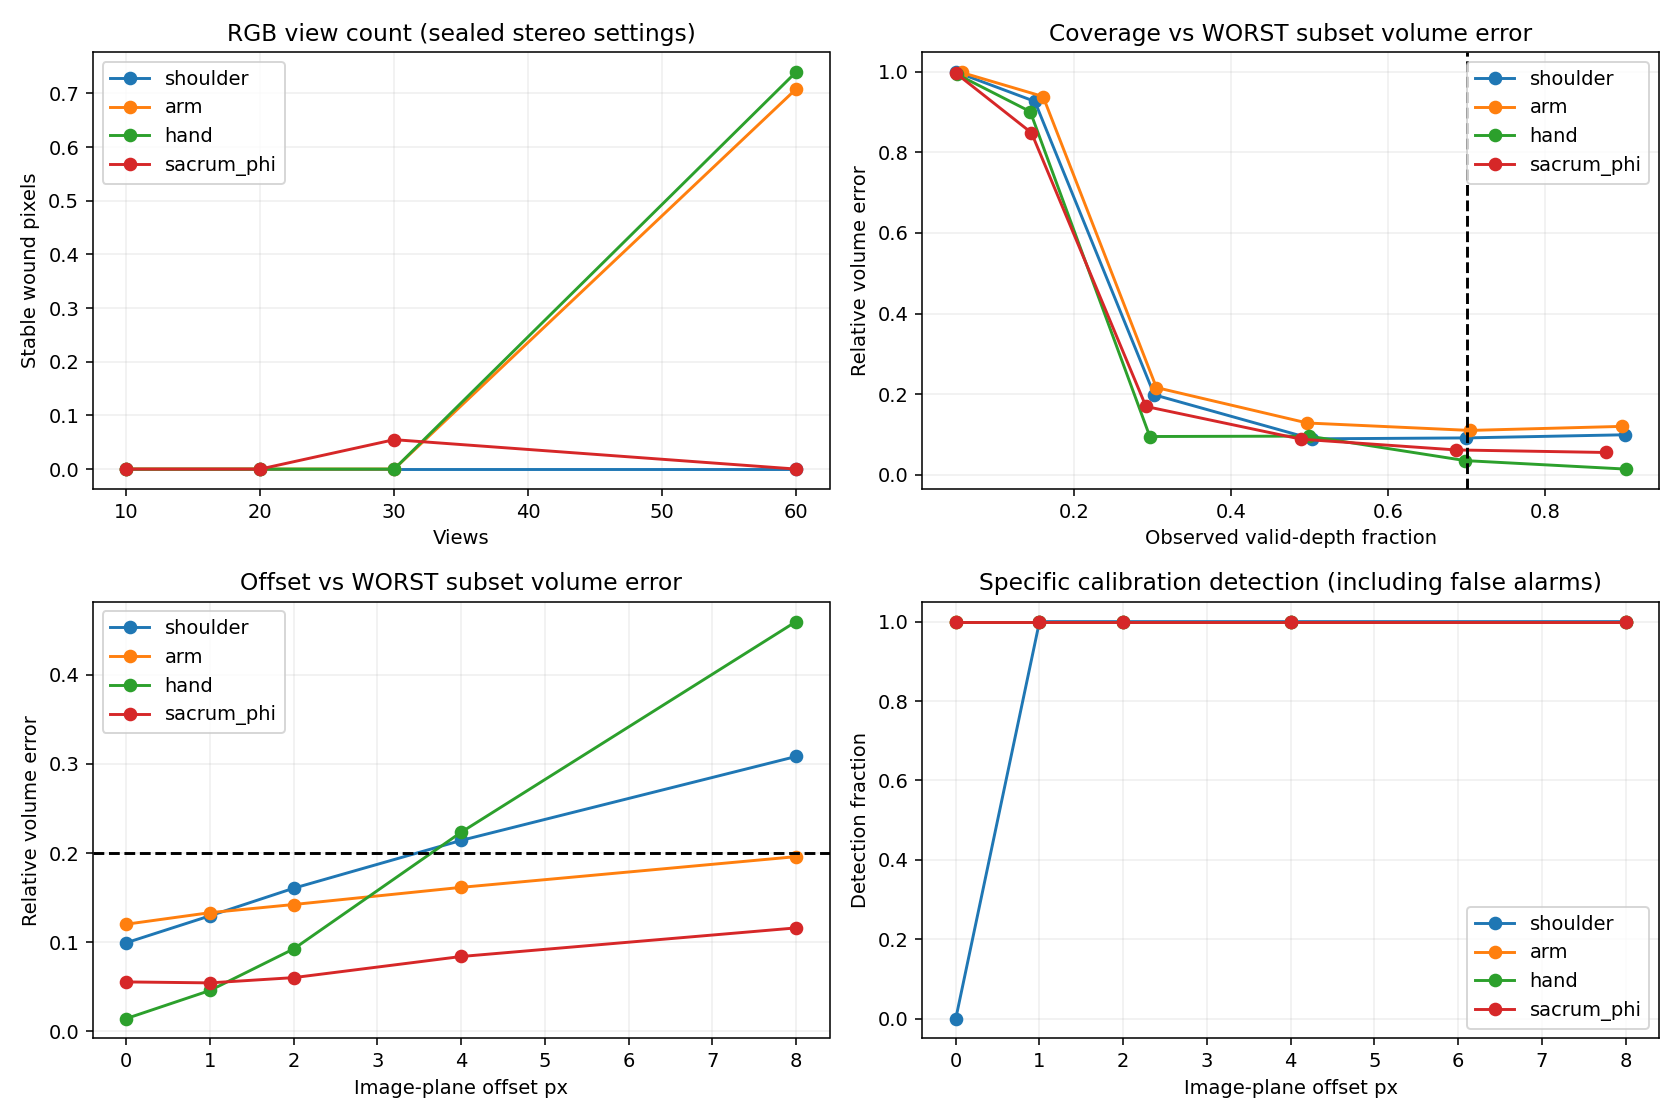

Matched rotating meshes, individual error/depth maps, healthy rings, reference arrays, RGB overlays, cameras and all failure receipts are under the generalization output folder. Missing support is not filled.

# Independent virtual calibration-target safety

The completed 252-result generalization, frozen masks, original sensor/RGB
results and complete error-free replay are preserved under a SHA256 seal.
This new study never retunes or reruns those experiments.

**Question:** can a target independent of wound geometry/masks reject faulty
RGB-depth calibration before offline wound reconstruction eligibility?
Known manufactured target coordinates are allowed online. True target poses,
fault labels and source-wound meshes are **evaluation only**.

The study creates synthetic ChArUco RGB observations and planar/stepped depth
features. Full camera-coordinate rotation/translation, wrong intrinsics,
distortion, depth scale/bias, synchronization and combined faults are applied.
These replace the previous image-plane offset/rotation surrogates.
Clean target corner detection and depth recovery are verified explicitly.
TRAIN target observations tune the detector. The TEST fault manifest is
frozen and hashed **before tuning**; thresholds are frozen before TEST scoring.
Wound consequences are never used for detector tuning.

**Protocol caveat:** the corrected V2 used three TEST configurations for
preliminary pipeline smoke checks before the final threshold values were
computed. They are not strictly untouched holdout. The report includes a
93-configuration untouched subset (23 clean / 70 non-clean), excluding those
three. No threshold was revised after final TEST scoring. Clean corner/step
geometry verifies, but worst single-view PnP rotation 0.280 degrees misses the
unchanged 0.2-degree verification gate. These limitations remain **PARTIAL**.

All wound consequences use the same frozen RGB contours, synthetic rendered
depth, source mesh and disjoint 20-view subsets as the sealed study. Rejected
faults are reconstructed **only to score diagnostic consequences**; they
cannot become eligible through good GT scores. Error tables use the worst
subset, not averages hiding catastrophic failures. Maximum-depth error is
reported both relative to source maximum depth and relative to wound width.
Clean depth/noise reference errors remain visible.

**Limits:** source-mesh depth evaluated against its generating mesh is not an
independent sensor measurement. Synthetic target dimensions do not certify
the wound dataset's physical unit. A common fault applied to target and wound
does not guarantee detection under every motion/occlusion pattern. A frozen
simulator holdout is not clinical or physical calibration validation.
`print_authorized=False` always. Calibration PASS permits only eligibility
for `RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION`; observable coverage,
resolution and cross-view geometry gates still apply.

Set `ACTION="CALIBRATION_SAFETY"`, `DATASET="SYN3DWOUND"`,
`METHOD="COLMAP"`, `CALIBRATION_TARGET="VIRTUAL_CHARUCO_STEPPED"`,
`LICENCE_ACKNOWLEDGED=True`. `RGB_GENERALIZATION_INPUT` must contain the
unchanged frozen review and source-depth caches under `runs/`.
`RGB_RESCUE_INPUT` contains `Syn3DWound`; `RGB_CALIBRATION_OUTPUT` is writable.
Target/fault outputs are deterministic and hash-verified before resume.
Default REPLAY shows recorded completed outputs without acquisition or training.


In [63]:
from __future__ import annotations

import ast
import hashlib
import inspect
import json
import math
import os
import textwrap
from datetime import datetime, timezone
from pathlib import Path
from typing import Any
import cv2
import numpy as np
_PROTOCOL_VERSION = 'v2'
(_WIDTH, _HEIGHT) = (640, 480)
_WORKING_DISTANCE = 1.0
_GRID = (10, 7)
_SQUARE = 0.03
_MARKER = 0.021
(_BOARD_W, _BOARD_H) = (_GRID[0] * _SQUARE, _GRID[1] * _SQUARE)
_PLATE_XYXY = (-0.015, -0.015, 0.42, 0.225)
_TABLE_OFFSET = 0.01
_BLOCKS = ({'xywh': [0.345, 0.015, 0.045, 0.045], 'height': 0.02}, {'xywh': [0.345, 0.0825, 0.045, 0.045], 'height': 0.04}, {'xywh': [0.345, 0.15, 0.045, 0.045], 'height': 0.06})
_IMAGE_K = np.array([[1000.0, 0.0, _WIDTH / 2], [0.0, 1000.0, _HEIGHT / 2], [0.0, 0.0, 1.0]], dtype=np.float64)
_ZERO_DIST = np.zeros(5, dtype=np.float64)
_DICT_ID = cv2.aruco.DICT_4X4_50
_DICT_NAME = 'DICT_4X4_50'
_SUPERSAMPLE = 3
_TEX_PX_PER_WD = 3000
_RGB_NOISE_SIGMA = 2.0
_DEPTH_NOISE_SIGMA = 0.0005
_TABLE_GRAY = 90.0
_FACE_GRAY = (228.0, 150.0, 175.0, 200.0, 130.0)
_MIN_CORNERS = 12
_STEP_ROI_DILATION = 0.01
_THRESHOLD_FACTOR = 1.5
_THRESHOLD_FLOORS = {'rgb_reprojection_px': 0.5, 'depth_scale_error_fraction': 0.002, 'rigid_fit_rmse_fraction': 0.001, 'rgb_depth_rotation_deg': 0.15, 'rgb_depth_translation_fraction': 0.002, 'plane_residual_fraction': 0.0005, 'step_height_error_fraction': 0.001, 'normal_angle_deg': 0.15, 'alignment_reprojection_px': 0.5, 'cross_view_translation_std_fraction': 0.001, 'cross_view_rotation_std_deg': 0.1}
_METRIC_RULES = {'rgb_reprojection_px': 'RGB_INTRINSICS_FAILED', 'depth_scale_error_fraction': 'DEPTH_SCALE_FAILED', 'rgb_depth_rotation_deg': 'RGB_DEPTH_EXTRINSICS_FAILED', 'rgb_depth_translation_fraction': 'RGB_DEPTH_EXTRINSICS_FAILED', 'alignment_reprojection_px': 'RGB_DEPTH_EXTRINSICS_FAILED', 'normal_angle_deg': 'RGB_DEPTH_EXTRINSICS_FAILED', 'cross_view_translation_std_fraction': 'SYNCHRONIZATION_FAILED', 'cross_view_rotation_std_deg': 'SYNCHRONIZATION_FAILED', 'plane_residual_fraction': 'CALIBRATION_WARNING', 'step_height_error_fraction': 'CALIBRATION_WARNING', 'rigid_fit_rmse_fraction': 'CALIBRATION_WARNING'}
_DECISION_PRIORITY = ('SYNCHRONIZATION_FAILED', 'RGB_INTRINSICS_FAILED', 'DEPTH_SCALE_FAILED', 'RGB_DEPTH_EXTRINSICS_FAILED', 'CALIBRATION_WARNING')
_TEXTURE_CACHE: dict[str, np.ndarray] = {}
def _utc() -> str:
    return datetime.now(timezone.utc).isoformat()
def _sha(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()
def _json_bytes(value: Any) -> bytes:
    return json.dumps(value, sort_keys=True, separators=(',', ':'), allow_nan=False).encode('utf-8')
def _json_write(path: Path, value: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False) + '\n', encoding='utf-8')
def _json_load(path: Path) -> Any:
    return json.loads(Path(path).read_text(encoding='utf-8'))
def _artifact_sha(path: Path) -> str:
    path = Path(path)
    if path.is_file():
        return _sha(path.read_bytes())
    entries = [{'name': p.relative_to(path).as_posix(), 'sha256': _sha(p.read_bytes())} for p in sorted(path.rglob('*')) if p.is_file()]
    return _sha(_json_bytes(entries))
def _finite(value: Any) -> bool:
    try:
        return value is not None and bool(np.isfinite(float(value)))
    except (TypeError, ValueError):
        return False
def _jsonable(value: Any) -> Any:
    if isinstance(value, dict):
        return {str(k): _jsonable(v) for (k, v) in value.items()}
    if isinstance(value, (list, tuple)):
        return [_jsonable(v) for v in value]
    if isinstance(value, np.ndarray):
        return _jsonable(value.tolist())
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        return float(value) if np.isfinite(value) else None
    return value
def _safe_id(family: str, payload: dict[str, Any]) -> str:
    return f"{family.lower().replace(' ', '_')}-{_sha(_json_bytes(payload))[:10]}"
def _board():
    dictionary = cv2.aruco.getPredefinedDictionary(_DICT_ID)
    board = cv2.aruco.CharucoBoard(_GRID, _SQUARE, _MARKER, dictionary)
    return (dictionary, board)
def _rot_xyz(degrees: list[float] | tuple[float, ...]) -> np.ndarray:
    (x, y, z) = np.deg2rad(np.asarray(degrees, dtype=np.float64))
    rx = np.array([[1, 0, 0], [0, math.cos(x), -math.sin(x)], [0, math.sin(x), math.cos(x)]])
    ry = np.array([[math.cos(y), 0, math.sin(y)], [0, 1, 0], [-math.sin(y), 0, math.cos(y)]])
    rz = np.array([[math.cos(z), -math.sin(z), 0], [math.sin(z), math.cos(z), 0], [0, 0, 1]])
    return rz @ ry @ rx
def _pose_matrix(rvec: np.ndarray) -> np.ndarray:
    return cv2.Rodrigues(np.asarray(rvec, dtype=np.float64).reshape(3))[0]
def _project(xyz: np.ndarray, rvec: np.ndarray, tvec: np.ndarray, K: np.ndarray, dist: np.ndarray | None=None) -> np.ndarray:
    (p, _) = cv2.projectPoints(np.asarray(xyz, dtype=np.float64).reshape(-1, 1, 3), np.asarray(rvec, dtype=np.float64).reshape(3), np.asarray(tvec, dtype=np.float64).reshape(3), np.asarray(K, dtype=np.float64), dist)
    return p.reshape(-1, 2)
def c_project(points: np.ndarray, K: np.ndarray, dist: np.ndarray | None=None) -> np.ndarray:
    """Project camera-frame points (Nx3) to Nx2 pixel coordinates."""
    xyz = np.asarray(points, dtype=np.float64).reshape(-1, 3)
    if not len(xyz):
        return np.empty((0, 2), dtype=np.float64)
    return _project(xyz, np.zeros(3), np.zeros(3), K, dist)
def c_rgb_calibration(Ktrue: np.ndarray, fault: dict[str, Any], shape: tuple[int, ...]) -> tuple[np.ndarray, np.ndarray]:
    """Return the RGB intrinsics/distortion declared to the detector (shape=(h,w))."""
    (h, w) = (int(shape[0]), int(shape[1]))
    k = np.asarray(Ktrue, dtype=np.float64).copy()
    k[0, 0] *= 1.0 + float(fault.get('rgb_focal_scale', 0.0))
    k[1, 1] *= 1.0 + float(fault.get('rgb_focal_scale', 0.0))
    pp = fault.get('rgb_principal_fraction', [0.0, 0.0])
    k[0, 2] += float(pp[0]) * w
    k[1, 2] += float(pp[1]) * h
    return (k, np.asarray(fault.get('rgb_distortion', [0, 0, 0, 0, 0]), dtype=np.float64))
def c_fault_points(points_camera: np.ndarray, fault: dict[str, Any], Ktrue: np.ndarray, working_distance: float) -> np.ndarray:
    """Corrupt camera-frame 3D points using declared depth calibration faults.

    Semantics are identical to v1. Scale-like keys are fractional deltas
    (depth_scale=0.02 means +2%). ``sync_delta`` is not applied here. Invalid
    input rows and points transformed behind the camera are returned as NaN.
    """
    src = np.asarray(points_camera, dtype=np.float64).reshape(-1, 3)
    out = np.full_like(src, np.nan, dtype=np.float64)
    valid = np.isfinite(src).all(axis=1) & (src[:, 2] > 0)
    if not valid.any():
        return out
    points = src[valid].copy()
    ktrue = np.asarray(Ktrue, dtype=np.float64)
    pix = c_project(points, ktrue, np.zeros(5))
    kdecl = ktrue.copy()
    sf = 1.0 + float(fault.get('focal_scale', 0.0))
    kdecl[0, 0] *= sf
    kdecl[1, 1] *= sf
    pp = fault.get('principal_fraction', [0.0, 0.0])
    (width, height) = (2.0 * ktrue[0, 2], 2.0 * ktrue[1, 2])
    kdecl[0, 2] += float(pp[0]) * width
    kdecl[1, 2] += float(pp[1]) * height
    ddecl = np.asarray(fault.get('distortion', [0, 0, 0, 0, 0]), dtype=np.float64).reshape(1, 5)
    normalized = cv2.undistortPoints(pix.reshape(-1, 1, 2), kdecl, ddecl).reshape(-1, 2)
    z = points[:, 2].copy()
    z *= 1.0 + float(fault.get('depth_scale', 0.0))
    z += float(fault.get('bias_fraction', 0.0)) * working_distance
    z += float(fault.get('bias_linear', 0.0)) * (points[:, 2] - working_distance)
    z += float(fault.get('bias_nonlinear', 0.0)) * (points[:, 2] - working_distance) ** 2 / working_distance
    xyz = np.column_stack((normalized[:, 0] * z, normalized[:, 1] * z, z))
    if 'depth_noise_sigma_fraction' in fault:
        rng = np.random.default_rng(int(fault.get('noise_seed', 0)))
        xyz += rng.normal(0.0, float(fault['depth_noise_sigma_fraction']) * working_distance, xyz.shape)
    xyz = (_rot_xyz(fault.get('rotation_deg', [0, 0, 0])) @ xyz.T).T
    tr = np.asarray(fault.get('translation_fraction', [0, 0, 0]), dtype=np.float64) * working_distance
    xyz += tr
    pose_r = np.asarray(fault.get('pose_rotation_deg', [0, 0, 0]), dtype=np.float64)
    xyz = (_rot_xyz(pose_r) @ xyz.T).T
    xyz += np.asarray(fault.get('pose_translation_fraction', [0, 0, 0]), dtype=np.float64) * working_distance
    good = np.isfinite(xyz).all(axis=1) & (xyz[:, 2] > 0)
    ix = np.flatnonzero(valid)
    out[ix[good]] = xyz[good]
    return out
def _fault_catalogue() -> list[dict[str, Any]]:
    """Same 190 fault dicts, families, splits and sequences as v1; new v2 seeds/IDs."""
    configs: list[dict[str, Any]] = []

    def add(family: str, fault: dict[str, Any], split: str='TEST', target_kind: str='STEPPED', sequence: str | None=None) -> None:
        n = len(configs)
        seq = sequence or ('shoulder' if split == 'TRAIN' else ('arm', 'hand', 'sacrum_phi')[n % 3])
        magnitudes = []
        for value in fault.values():
            try:
                magnitudes.extend(np.abs(np.asarray(value, dtype=np.float64)).reshape(-1).tolist())
            except (TypeError, ValueError):
                continue
        payload = {'family': family, 'fault': fault, 'split': split, 'protocol': 'v2', 'sequence': seq, 'target_kind': target_kind, 'index': n}
        configs.append({'id': _safe_id(family, payload), 'split': split, 'sequence': seq, 'family': family, 'magnitude': max(magnitudes, default=0.0), 'fault': fault, 'seed': 50021 + n * 41, 'target_kind': target_kind})
    for i in range(8):
        add('CLEAN', {}, 'TRAIN', sequence='shoulder')
    for i in range(24):
        add('CLEAN', {}, 'TEST', sequence=('arm', 'hand', 'sacrum_phi')[i % 3])

    def split_magnitude(magnitude: float, train_values: tuple[float, ...]) -> str:
        return 'TRAIN' if any((abs(magnitude - t) < 1e-08 for t in train_values)) else 'TEST'
    for (axis, key) in enumerate(('translation_fraction',) * 3):
        for mag in (0.0025, 0.005, 0.01, 0.02, 0.05):
            for sign in (-1, 1):
                v = [0.0, 0.0, 0.0]
                v[axis] = sign * mag
                add('translation', {key: v}, split_magnitude(mag, (0.0025, 0.01, 0.05)))
    for axis in range(3):
        for mag in (0.1, 0.25, 0.5, 1.0, 2.0, 5.0):
            for sign in (-1, 1):
                v = [0.0, 0.0, 0.0]
                v[axis] = sign * mag
                add(('pitch', 'yaw', 'roll')[axis], {'rotation_deg': v}, split_magnitude(mag, (0.1, 0.5, 2.0)))
    for mag in (0.005, 0.01, 0.02, 0.05, 0.1):
        for sign in (-1, 1):
            add('depth_scale', {'depth_scale': sign * mag}, split_magnitude(mag, (0.005, 0.02, 0.1)))
    for (key, values, train) in (('bias_fraction', (0.005, 0.01, 0.02), (0.005, 0.02)), ('bias_linear', (0.01, 0.03, 0.06), (0.01, 0.06)), ('bias_nonlinear', (0.02, 0.05, 0.1), (0.02, 0.1))):
        for mag in values:
            for sign in (-1, 1):
                add(key, {key: sign * mag}, split_magnitude(mag, train))
    for rgb in (False, True):
        prefix = 'rgb_' if rgb else ''
        key = prefix + 'focal_scale' if rgb else 'focal_scale'
        for mag in (0.01, 0.03, 0.05):
            for sign in (-1, 1):
                add('rgb_focal' if rgb else 'depth_focal', {key: sign * mag}, split_magnitude(mag, (0.01, 0.05)))
        key = prefix + 'principal_fraction' if rgb else 'principal_fraction'
        for axis in range(2):
            for mag in (0.002, 0.005, 0.01):
                for sign in (-1, 1):
                    v = [0.0, 0.0]
                    v[axis] = sign * mag
                    add('rgb_principal' if rgb else 'depth_principal', {key: v}, split_magnitude(mag, (0.002, 0.01)))
        for mag in (0.02, 0.05):
            for sign in (-1, 1):
                d = [0.0, 0.0, 0.0, 0.0, 0.0]
                d[0] = sign * mag
                add('rgb_distortion' if rgb else 'depth_distortion', {'rgb_distortion' if rgb else 'distortion': d}, split_magnitude(mag, (0.02,)))
    for delta in (-1, 1):
        add('synchronization', {'sync_delta': delta})
    for (axis, mag) in ((0, 0.25), (1, 0.5), (2, 0.25)):
        r = [0.0, 0.0, 0.0]
        r[axis] = mag
        add('pose_mismatch', {'pose_rotation_deg': r})
    combos = [{'rotation_deg': [0.0, 1.0, 0.0], 'depth_scale': 0.02}, {'rotation_deg': [0.0, -2.0, 0.0], 'depth_scale': -0.05}, {'translation_fraction': [0.0, 0.0, 0.01], 'bias_fraction': 0.02}, {'translation_fraction': [0.0, 0.0, -0.02], 'bias_linear': -0.03}, {'focal_scale': 0.03, 'rotation_deg': [0.0, 0.0, 1.0]}, {'principal_fraction': [0.005, 0.0], 'translation_fraction': [0.005, 0.0, 0.0]}, {'rgb_focal_scale': -0.03, 'rotation_deg': [1.0, 0.0, 0.0]}, {'depth_scale': 0.02, 'bias_nonlinear': 0.05}, {'rotation_deg': [0.0, 1.0, 0.0], 'bias_fraction': 0.01}, {'rgb_principal_fraction': [0.0, 0.005], 'depth_scale': -0.02}, {'rotation_deg': [0.0, 0.0, 2.0], 'pose_translation_fraction': [0.005, 0.0, 0.0]}, {'rgb_distortion': [0.05, 0.0, 0.0, 0.0, 0.0], 'focal_scale': -0.02}]
    for (i, fault) in enumerate(combos):
        add('combined', fault, 'TRAIN' if i in (0, 3, 7) else 'TEST')
    add('noise_control', {'depth_noise_sigma_fraction': 0.001, 'noise_seed': 13}, 'TRAIN')
    add('noise_control', {'depth_noise_sigma_fraction': 0.002, 'noise_seed': 29}, 'TEST')
    add('target_missing', {'target_missing': True}, 'TEST')
    return configs
def c_fault_catalogue(base: str | os.PathLike[str]) -> list[dict[str, Any]]:
    """Return the deterministic 190-row TRAIN/TEST catalogue (94 TRAIN, 96 TEST).

    Fault dicts, families, splits and sequences are identical to v1 row-by-row;
    only seeds and IDs differ (see v1_v2_config_map.json).
    """
    return _fault_catalogue()
def _v1_equivalent_ids() -> list[dict[str, Any]]:
    rows = []
    for (n, cfg) in enumerate(_fault_catalogue()):
        payload = {'family': cfg['family'], 'fault': cfg['fault'], 'split': cfg['split'], 'sequence': cfg['sequence'], 'target_kind': cfg['target_kind'], 'index': n}
        rows.append({'v2_id': cfg['id'], 'v1_id': _safe_id(cfg['family'], payload), 'split': cfg['split'], 'sequence': cfg['sequence'], 'family': cfg['family'], 'fault': cfg['fault']})
    return rows
def _calibration_clean_configs() -> list[dict[str, Any]]:
    """Additional TRAIN-only shoulder CLEAN captures used solely for thresholds."""
    rows = []
    for i in range(32):
        payload = {'family': 'CLEAN', 'role': 'threshold_calibration_only', 'index': i, 'protocol': 'v2'}
        rows.append({'id': 'cal' + _safe_id('CLEAN', payload), 'split': 'TRAIN', 'sequence': 'shoulder', 'family': 'CLEAN', 'magnitude': 0.0, 'fault': {}, 'seed': 90001 + i * 53, 'target_kind': 'STEPPED', 'role': 'threshold_calibration_only'})
    return rows
def _layout(kind: str) -> dict[str, Any]:
    blocks = [] if kind == 'PLANAR' else [{'xywh': list(b['xywh']), 'height': b['height']} for b in _BLOCKS]
    board_points = [[(i + 0.5) * _SQUARE, (j + 0.5) * _SQUARE, 0.0] for j in range(_GRID[1]) for i in range(_GRID[0])]
    tops = [[b['xywh'][0] + b['xywh'][2] / 2, b['xywh'][1] + b['xywh'][3] / 2, -b['height']] for b in blocks]
    return {'kind': kind, 'plate_xyxy': list(_PLATE_XYXY), 'board_width': _BOARD_W, 'board_height': _BOARD_H, 'square_length': _SQUARE, 'marker_length': _MARKER, 'dictionary': _DICT_NAME, 'grid': list(_GRID), 'blocks': blocks, 'landmark_xyz': board_points + tops, 'landmark_plane': [True] * len(board_points) + [False] * len(tops), 'step_heights': [b['height'] for b in blocks]}
def _camera_pose(seed: int, sequence: str, index: int) -> tuple[np.ndarray, np.ndarray]:
    rng = np.random.default_rng(int(seed) + int(index) * 997)
    seq_offset = {'shoulder': 0.0, 'arm': -2.0, 'hand': 1.5, 'sacrum_phi': 2.5}.get(sequence, 0.0)
    tilt = rng.uniform(-9.0, 9.0) + seq_offset
    yaw = rng.uniform(-11.0, 11.0)
    roll = rng.uniform(-7.0, 7.0)
    R = _rot_xyz([tilt, yaw, roll])
    center = np.array([(_PLATE_XYXY[0] + _PLATE_XYXY[2]) / 2, (_PLATE_XYXY[1] + _PLATE_XYXY[3]) / 2, 0.0])
    tvec = np.array([rng.uniform(-0.02, 0.02), rng.uniform(-0.015, 0.015), 1.0 + rng.uniform(-0.04, 0.04)]) - R @ center
    return (cv2.Rodrigues(R)[0].reshape(3), tvec)
def _frame_pose(seed: int, sequence: str, index: int, frame: int) -> tuple[np.ndarray, np.ndarray]:
    """Target pose in an adjacent frame (hand-held motion model, eval-only truth)."""
    (rvec, tvec) = _camera_pose(seed, sequence, index)
    if not frame:
        return (rvec, tvec)
    rng = np.random.default_rng([int(seed), int(index), 7])
    axis = rng.normal(size=3)
    axis /= np.linalg.norm(axis)
    rate = np.deg2rad(rng.uniform(0.6, 1.2))
    vel = rng.normal(size=3)
    vel *= rng.uniform(0.004, 0.008) / np.linalg.norm(vel)
    Rm = _pose_matrix(axis * rate * frame)
    R = Rm @ _pose_matrix(rvec)
    return (cv2.Rodrigues(R)[0].reshape(3), Rm @ tvec + vel * frame)
def _raycast(layout: dict[str, Any], rvec: np.ndarray, tvec: np.ndarray, K: np.ndarray, dist: np.ndarray | None, us: np.ndarray, vs: np.ndarray, include_table: bool=True, include_target: bool=True) -> tuple[np.ndarray, np.ndarray]:
    """Ray-cast known geometry. Returns camera z and surface code per pixel.

    Codes: -1 none, 0 base plate, 1 table, 10*(i+1)+f for block i with face f
    (0 top, 1 x-low, 2 x-high, 3 y-low, 4 y-high side).
    """
    shape = np.shape(us)
    pix = np.column_stack((np.ravel(us), np.ravel(vs))).astype(np.float64)
    K = np.asarray(K, dtype=np.float64)
    if dist is None or not np.any(np.asarray(dist)):
        xn = (pix[:, 0] - K[0, 2]) / K[0, 0]
        yn = (pix[:, 1] - K[1, 2]) / K[1, 1]
    else:
        nrm = cv2.undistortPoints(pix.reshape(-1, 1, 2), K, np.asarray(dist, dtype=np.float64).reshape(1, -1)).reshape(-1, 2)
        (xn, yn) = (nrm[:, 0], nrm[:, 1])
    dc = np.column_stack((xn, yn, np.ones_like(xn)))
    R = _pose_matrix(rvec)
    o = -R.T @ np.asarray(tvec, dtype=np.float64).reshape(3)
    d = dc @ R
    best = np.full(len(d), np.inf)
    surf = np.full(len(d), -1, dtype=np.int32)
    with np.errstate(divide='ignore', invalid='ignore'):
        if include_target:
            tp = (0.0 - o[2]) / d[:, 2]
            hx = o[0] + tp * d[:, 0]
            hy = o[1] + tp * d[:, 1]
            (x0, y0, x1, y1) = layout['plate_xyxy']
            good = np.isfinite(tp) & (tp > 0) & (hx >= x0) & (hx <= x1) & (hy >= y0) & (hy <= y1)
            best[good] = tp[good]
            surf[good] = 0
        if include_table:
            tt = (_TABLE_OFFSET - o[2]) / d[:, 2]
            good = np.isfinite(tt) & (tt > 0) & (tt < best)
            best[good] = tt[good]
            surf[good] = 1
        if include_target:
            for (i, b) in enumerate(layout['blocks']):
                (bx, by, bw, bh) = b['xywh']
                lo = np.array([bx, by, -b['height']])
                hi = np.array([bx + bw, by + bh, 0.0])
                t1 = (lo - o) / d
                t2 = (hi - o) / d
                tmn = np.fmin(t1, t2)
                tmx = np.fmax(t1, t2)
                tin = np.fmax.reduce(tmn, axis=1)
                tout = np.fmin.reduce(tmx, axis=1)
                hit = np.isfinite(tin) & (tout >= tin) & (tin > 0) & (tin < best)
                ax = np.argmax(np.where(np.isnan(tmn), -np.inf, tmn), axis=1)
                face = np.where(ax == 2, 0, np.where(ax == 0, np.where(d[:, 0] > 0, 1, 2), np.where(d[:, 1] > 0, 3, 4)))
                best[hit] = tin[hit]
                surf[hit] = 10 * (i + 1) + face[hit]
    best[~np.isfinite(best)] = np.nan
    return (best.reshape(shape), surf.reshape(shape))
def _plate_texture() -> np.ndarray:
    if 'plate' not in _TEXTURE_CACHE:
        (_, board) = _board()
        s = _TEX_PX_PER_WD
        (bw, bh) = (int(round(_BOARD_W * s)), int(round(_BOARD_H * s)))
        img = board.generateImage((bw, bh), marginSize=0, borderBits=1)
        (x0, y0, x1, y1) = _PLATE_XYXY
        tex = np.full((int(round((y1 - y0) * s)), int(round((x1 - x0) * s))), 255, np.uint8)
        (ox, oy) = (int(round(-x0 * s)), int(round(-y0 * s)))
        tex[oy:oy + bh, ox:ox + bw] = img
        _TEXTURE_CACHE['plate'] = tex
    return _TEXTURE_CACHE['plate']
def _supersample_K(K: np.ndarray, s: int) -> np.ndarray:
    Ks = np.asarray(K, dtype=np.float64).copy()
    Ks[0, 0] *= s
    Ks[1, 1] *= s
    Ks[0, 2] = (K[0, 2] + 0.5) * s - 0.5
    Ks[1, 2] = (K[1, 2] + 0.5) * s - 0.5
    return Ks
def _render_rgb(layout: dict[str, Any], rvec: np.ndarray, tvec: np.ndarray, K: np.ndarray, rng: np.random.Generator, missing: bool=False, noise_sigma: float=_RGB_NOISE_SIGMA, occluder: dict[str, float] | None=None) -> np.ndarray:
    s = _SUPERSAMPLE
    Ks = _supersample_K(K, s)
    (hs, ws) = (_HEIGHT * s, _WIDTH * s)
    img = np.full((hs, ws), _TABLE_GRAY, np.float32)
    if not missing:
        tex = _plate_texture().astype(np.float32)
        (th, tw) = tex.shape
        (x0, y0, x1, y1) = layout['plate_xyxy']
        src = np.float32([[-0.5, -0.5], [tw - 0.5, -0.5], [tw - 0.5, th - 0.5], [-0.5, th - 0.5]])
        dst = _project(np.array([[x0, y0, 0], [x1, y0, 0], [x1, y1, 0], [x0, y1, 0]], float), rvec, tvec, Ks).astype(np.float32)
        Hm = cv2.getPerspectiveTransform(src, dst)
        warped = cv2.warpPerspective(tex, Hm, (ws, hs), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        cover = cv2.warpPerspective(np.ones_like(tex), Hm, (ws, hs), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        img = img * (1.0 - cover) + warped
        if layout['blocks']:
            verts = []
            for b in layout['blocks']:
                (x, y, w, h) = b['xywh']
                for z in (0.0, -b['height']):
                    verts += [[x, y, z], [x + w, y, z], [x + w, y + h, z], [x, y + h, z]]
            pv = _project(np.array(verts), rvec, tvec, Ks)
            u0 = max(0, int(np.floor(pv[:, 0].min())) - 2)
            u1 = min(ws, int(np.ceil(pv[:, 0].max())) + 3)
            v0 = max(0, int(np.floor(pv[:, 1].min())) - 2)
            v1 = min(hs, int(np.ceil(pv[:, 1].max())) + 3)
            if u1 > u0 and v1 > v0:
                (vv, uu) = np.mgrid[v0:v1, u0:u1]
                (_, surf) = _raycast(layout, rvec, tvec, Ks, None, uu.astype(float), vv.astype(float))
                box = surf >= 10
                lut = np.asarray(_FACE_GRAY, np.float32)
                patch = img[v0:v1, u0:u1]
                patch[box] = lut[surf[box] % 10]
    if occluder:
        cv2.circle(img, (int(round((occluder['u'] + 0.5) * s - 0.5)), int(round((occluder['v'] + 0.5) * s - 0.5))), int(round(occluder['r'] * s)), float(occluder.get('gray', 170.0)), -1, cv2.LINE_AA)
    small = cv2.resize(img, (_WIDTH, _HEIGHT), interpolation=cv2.INTER_AREA)
    small = small + rng.normal(0.0, noise_sigma, small.shape)
    gray = np.clip(np.rint(small), 0, 255).astype(np.uint8)
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
def _render_depth(layout: dict[str, Any], rvec: np.ndarray, tvec: np.ndarray, K: np.ndarray, rng: np.random.Generator, missing: bool=False, occluder: dict[str, float] | None=None, dropout: float=0.0) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    (vv, uu) = np.mgrid[0:_HEIGHT, 0:_WIDTH]
    (z, surf) = _raycast(layout, rvec, tvec, K, None, uu.astype(float), vv.astype(float), include_table=True, include_target=not missing)
    visible = (surf == 0) | (surf >= 10)
    if occluder:
        disc = (uu - occluder['u']) ** 2 + (vv - occluder['v']) ** 2 <= occluder['r'] ** 2
        z = np.where(disc, float(occluder.get('z', 0.85)), z)
        visible = visible & ~disc
        surf = np.where(disc, -2, surf)
    noisy = z + rng.normal(0.0, 1.0, z.shape) * _DEPTH_NOISE_SIGMA * np.nan_to_num(z) ** 2
    if dropout > 0:
        noisy = np.where(rng.random(z.shape) < dropout, np.nan, noisy)
    return (noisy.astype(np.float32), visible.astype(np.uint8) * 255, surf)
def _depth_cloud(depth: np.ndarray, K: np.ndarray) -> np.ndarray:
    (vv, uu) = np.mgrid[0:depth.shape[0], 0:depth.shape[1]]
    z = depth.astype(np.float64)
    return np.stack(((uu - K[0, 2]) / K[0, 0] * z, (vv - K[1, 2]) / K[1, 1] * z, z), axis=-1).reshape(-1, 3)
def _declared_calibration(fault: dict[str, Any], Ktrue: np.ndarray) -> dict[str, Any]:
    (rgbk, rgbd) = c_rgb_calibration(Ktrue, fault, (_HEIGHT, _WIDTH))
    depthk = np.asarray(Ktrue, dtype=np.float64).copy()
    depthk[0, 0] *= 1.0 + float(fault.get('focal_scale', 0.0))
    depthk[1, 1] *= 1.0 + float(fault.get('focal_scale', 0.0))
    pp = fault.get('principal_fraction', [0.0, 0.0])
    depthk[0, 2] += pp[0] * _WIDTH
    depthk[1, 2] += pp[1] * _HEIGHT
    return {'rgb_K': rgbk.tolist(), 'rgb_distortion': rgbd.tolist(), 'depth_K': depthk.tolist(), 'image_shape': [_HEIGHT, _WIDTH], 'depth_distortion': list(fault.get('distortion', [0, 0, 0, 0, 0]))}
def _make_views(cfg: dict[str, Any], kind: str | None=None, controls: dict[str, Any] | None=None) -> tuple[list[dict[str, Any]], list[dict[str, Any]], dict[str, Any]]:
    """Render the configuration's OWN two views. Returns observations, eval-only truth, declared."""
    controls = controls or {}
    kind = kind or cfg['target_kind']
    layout = _layout(kind)
    fault = cfg['fault']
    sync = int(fault.get('sync_delta', 0))
    (views, truths) = ([], [])
    for view in (0, 1):
        (rvec, tvec) = _camera_pose(cfg['seed'], cfg['sequence'], view)
        (drv, dtv) = _frame_pose(cfg['seed'], cfg['sequence'], view, sync)
        missing = bool(fault.get('target_missing', False)) or controls.get('missing_view') == view
        occluder = None
        if controls.get('occluder'):
            orng = np.random.default_rng([int(cfg['seed']), view, 3])
            centre = _project(np.array([[_BOARD_W * orng.uniform(0.3, 0.7), _BOARD_H * orng.uniform(0.3, 0.7), 0.0]]), rvec, tvec, _IMAGE_K)[0]
            occluder = {'u': float(centre[0]), 'v': float(centre[1]), 'r': 55.0, 'z': 0.85, 'gray': 170.0}
        image = _render_rgb(layout, rvec, tvec, _IMAGE_K, np.random.default_rng([int(cfg['seed']), view, 1]), missing, float(controls.get('rgb_noise_sigma', _RGB_NOISE_SIGMA)), occluder)
        (depth, visibility, _) = _render_depth(layout, drv, dtv, _IMAGE_K, np.random.default_rng([int(cfg['seed']), view, 2]), missing, occluder, float(controls.get('depth_dropout', 0.0)))
        cloud = c_fault_points(_depth_cloud(depth, _IMAGE_K), fault, _IMAGE_K, _WORKING_DISTANCE)
        views.append({'rgb': image, 'depth': depth, 'depth_points_camera': cloud.reshape(_HEIGHT, _WIDTH, 3)})
        truths.append({'view': view, 'rvec': rvec, 'tvec': tvec, 'depth_rvec': drv, 'depth_tvec': dtv, 'visibility': visibility, 'kind': kind, 'target_missing': bool(missing), 'occluder': occluder})
    return (views, truths, _declared_calibration(fault, _IMAGE_K))
def _vector_angle(a: np.ndarray, b: np.ndarray) -> float:
    a = a / max(float(np.linalg.norm(a)), 1e-12)
    b = b / max(float(np.linalg.norm(b)), 1e-12)
    return float(np.degrees(np.arccos(np.clip(abs(float(a @ b)), -1.0, 1.0))))
def _rigid_fit(source: np.ndarray, target: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    a = np.asarray(source, dtype=np.float64)
    b = np.asarray(target, dtype=np.float64)
    (ac, bc) = (a.mean(axis=0), b.mean(axis=0))
    (u, _, vt) = np.linalg.svd((a - ac).T @ (b - bc))
    d = np.eye(3)
    d[2, 2] = np.linalg.det(vt.T @ u.T)
    R = vt.T @ d @ u.T
    return (R, bc - R @ ac)
def _rotation_difference(Ra: np.ndarray, Rb: np.ndarray) -> float:
    R = Ra.T @ Rb
    return float(np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1.0, 1.0))))
def _metric_template() -> dict[str, float]:
    return {k: float('nan') for k in ('rgb_reprojection_px', 'depth_scale_error_fraction', 'rigid_fit_rmse_fraction', 'rgb_depth_rotation_deg', 'rgb_depth_translation_fraction', 'plane_residual_fraction', 'step_height_error_fraction', 'normal_angle_deg', 'alignment_reprojection_px', 'cross_view_translation_std_fraction', 'cross_view_rotation_std_deg')}
def _fit_plane(points: np.ndarray) -> tuple[np.ndarray, np.ndarray, float]:
    c = points.mean(axis=0)
    (_, _, vt) = np.linalg.svd(points - c)
    n = vt[-1]
    if float(n @ -c) < 0:
        n = -n
    return (c, n, float(np.sqrt(np.mean(((points - c) @ n) ** 2))))
def _register(cloud: np.ndarray, K: np.ndarray, dist: np.ndarray) -> np.ndarray:
    """Z-buffer the declared-frame depth cloud into RGB pixels using declared RGB calibration."""
    pts = np.asarray(cloud, dtype=np.float64).reshape(-1, 3)
    reg = np.full((_HEIGHT * _WIDTH, 3), np.nan)
    ok = np.isfinite(pts).all(axis=1) & (pts[:, 2] > 0)
    if not ok.any():
        return reg.reshape(_HEIGHT, _WIDTH, 3)
    P = pts[ok]
    pix = c_project(P, K, dist)
    good = np.isfinite(pix).all(axis=1)
    ui = np.rint(np.where(good, pix[:, 0], -1)).astype(np.int64)
    vi = np.rint(np.where(good, pix[:, 1], -1)).astype(np.int64)
    inb = good & (ui >= 0) & (ui < _WIDTH) & (vi >= 0) & (vi < _HEIGHT)
    (P, ui, vi) = (P[inb], ui[inb], vi[inb])
    lin = vi * _WIDTH + ui
    order = np.lexsort((P[:, 2], lin))
    lin_s = lin[order]
    first = np.ones(len(order), dtype=bool)
    first[1:] = lin_s[1:] != lin_s[:-1]
    sel = order[first]
    reg[lin[sel]] = P[sel]
    return reg.reshape(_HEIGHT, _WIDTH, 3)
def _block_silhouette_mask(blocks: list[dict[str, Any]], rvec: np.ndarray, tvec: np.ndarray, K: np.ndarray, dist: np.ndarray, dilate_px: int=4, expand: float=0.0) -> list[np.ndarray]:
    masks = []
    for b in blocks:
        (x, y, w, h) = b['xywh']
        (x, y, w, h) = (x - expand, y - expand, w + 2 * expand, h + 2 * expand)
        verts = [[x, y, z] for z in (0.0, -b['height'])] + [[x + w, y, z] for z in (0.0, -b['height'])] + [[x + w, y + h, z] for z in (0.0, -b['height'])] + [[x, y + h, z] for z in (0.0, -b['height'])]
        pv = _project(np.array(verts, float), rvec, tvec, K, dist)
        m = np.zeros((_HEIGHT, _WIDTH), np.uint8)
        if np.isfinite(pv).all():
            hull = cv2.convexHull(np.rint(pv).astype(np.int32))
            cv2.fillConvexPoly(m, hull, 1)
            if dilate_px:
                m = cv2.dilate(m, np.ones((2 * dilate_px + 1, 2 * dilate_px + 1), np.uint8))
        masks.append(m)
    return masks
def _observe_one(obs: dict[str, Any], declared: dict[str, Any], model: dict[str, Any]) -> dict[str, Any]:
    """Single-view target measurement from RGB + declared-frame depth cloud only."""
    metrics = _metric_template()
    blocks = list(model.get('blocks', []))
    info: dict[str, Any] = {'observed': False, 'metrics': metrics, 'corner_ids': [], 'corner_pixels': [], 'corners_detected': 0, 'corners_used': 0, 'corners_excluded_step_visibility': 0, 'depth_landmarks_used': 0, 'steps_found': 0, 'steps_expected': len(blocks), 'steps_missing': False, 'pose': None, 'delta': None}
    (_, board) = _board()
    rgb = np.asarray(obs['rgb'])
    gray = cv2.cvtColor(rgb, cv2.COLOR_BGR2GRAY) if rgb.ndim == 3 else rgb
    (corners, ids, _, _) = cv2.aruco.CharucoDetector(board).detectBoard(gray)
    if ids is not None and corners is not None:
        info['corner_ids'] = ids.reshape(-1).astype(int).tolist()
        info['corner_pixels'] = np.asarray(corners, dtype=np.float64).reshape(-1, 2).tolist()
        info['corners_detected'] = len(info['corner_ids'])
    if info['corners_detected'] < _MIN_CORNERS:
        return info
    ids_a = np.asarray(info['corner_ids'], dtype=np.int64)
    px = np.asarray(info['corner_pixels'], dtype=np.float64)
    obj_all = np.asarray(model['charuco_corners_xyz'], dtype=np.float64)
    K = np.asarray(declared['rgb_K'], dtype=np.float64)
    dist = np.asarray(declared['rgb_distortion'], dtype=np.float64)

    def solve(sel: np.ndarray) -> tuple[bool, np.ndarray, np.ndarray]:
        (ok, rv, tv) = cv2.solvePnP(obj_all[ids_a[sel]], px[sel], K, dist, flags=cv2.SOLVEPNP_IPPE)
        if not ok:
            return (False, np.zeros(3), np.zeros(3))
        (rv, tv) = cv2.solvePnPRefineLM(obj_all[ids_a[sel]], px[sel], K, dist, rv, tv)
        return (True, rv.reshape(3), tv.reshape(3))
    keep = np.ones(len(ids_a), dtype=bool)
    (ok, rvec, tvec) = solve(keep)
    if not ok or tvec[2] <= 0:
        return info
    if blocks:
        masks = _block_silhouette_mask(blocks, rvec, tvec, K, dist, dilate_px=4)
        union = np.any(np.stack(masks), axis=0)
        ui = np.clip(np.rint(px[:, 0]).astype(int), 0, _WIDTH - 1)
        vi = np.clip(np.rint(px[:, 1]).astype(int), 0, _HEIGHT - 1)
        keep = ~union[vi, ui]
        info['corners_excluded_step_visibility'] = int((~keep).sum())
        if (~keep).any():
            if keep.sum() < _MIN_CORNERS:
                return info
            (ok, rvec, tvec) = solve(keep)
            if not ok:
                return info
    info['observed'] = True
    info['corners_used'] = int(keep.sum())
    info['used_corner_mask'] = keep
    projected = _project(obj_all[ids_a[keep]], rvec, tvec, K, dist)
    metrics['rgb_reprojection_px'] = float(np.sqrt(np.mean(np.sum((projected - px[keep]) ** 2, axis=1))))
    Rr = _pose_matrix(rvec)
    info['pose'] = (rvec, tvec)
    cloud = np.asarray(obs['depth_points_camera'], dtype=np.float64).reshape(-1, 3)
    if cloud.shape[0] != _HEIGHT * _WIDTH:
        return info
    reg = _register(cloud, K, dist)
    (vv, uu) = np.mgrid[0:_HEIGHT, 0:_WIDTH]
    (_, expected) = _raycast(model, rvec, tvec, K, dist, uu.astype(float), vv.astype(float), include_table=False)
    L = np.asarray(model['landmark_xyz'], dtype=np.float64)
    plane_flag = np.asarray(model['landmark_plane'], dtype=bool)
    BL = L[plane_flag]
    lpix = _project(BL, rvec, tvec, K, dist)
    meas = np.full((len(BL), 3), np.nan)
    guard = 3
    for (i, (u, v)) in enumerate(lpix):
        if not np.isfinite([u, v]).all():
            continue
        (ui, vi) = (int(round(u)), int(round(v)))
        if not (guard <= ui < _WIDTH - guard and guard <= vi < _HEIGHT - guard):
            continue
        if not np.all(expected[vi - guard:vi + guard + 1, ui - guard:ui + guard + 1] == 0):
            continue
        patch = reg[vi - 2:vi + 3, ui - 2:ui + 3].reshape(-1, 3)
        patch = patch[np.isfinite(patch).all(axis=1)]
        if len(patch) >= 5:
            meas[i] = np.median(patch, axis=0)
    okb = np.isfinite(meas).all(axis=1)
    info['depth_landmarks_used'] = int(okb.sum())
    info['landmark_index'] = np.flatnonzero(okb)
    info['landmark_pixels'] = lpix[okb]
    info['landmark_measured'] = meas[okb]
    if okb.sum() < 10:
        return info
    (src, dst) = (BL[okb], meas[okb])
    (c, n, rms) = _fit_plane(dst)
    info['plane'] = (c, n)
    metrics['plane_residual_fraction'] = rms / _WORKING_DISTANCE
    metrics['normal_angle_deg'] = _vector_angle(n, Rr[:, 2])
    md = np.linalg.norm(src[:, None, :] - src[None, :, :], axis=2)
    od = np.linalg.norm(dst[:, None, :] - dst[None, :, :], axis=2)
    pair = np.triu(np.ones(md.shape, dtype=bool), 1) & (md > 0.05)
    if pair.any():
        ratio = float(np.median(od[pair] / md[pair]))
        info['depth_scale_estimate'] = ratio
        metrics['depth_scale_error_fraction'] = abs(ratio - 1.0)
    steps = []
    if blocks:
        roi_masks = _block_silhouette_mask(blocks, rvec, tvec, K, dist, dilate_px=0, expand=_STEP_ROI_DILATION)
        for (b, m) in zip(blocks, roi_masks):
            P = reg[m > 0]
            P = P[np.isfinite(P).all(axis=1)]
            H = float(b['height'])
            if len(P) < 25:
                steps.append(None)
                continue
            hgt = (P - c) @ n
            coarse = np.abs(hgt - H) < 0.4 * H
            if coarse.sum() < 25:
                steps.append(None)
                continue
            hm = float(np.median(hgt[coarse]))
            mad = 1.4826 * float(np.median(np.abs(hgt[coarse] - hm)))
            fine = np.abs(hgt - hm) < max(0.002, 4.0 * mad)
            if fine.sum() < 25:
                steps.append(None)
                continue
            (x, y, w, h) = b['xywh']
            steps.append({'centroid': P[fine].mean(axis=0), 'height': float(np.median(hgt[fine])), 'known_height': H, 'model_top': np.array([x + w / 2, y + h / 2, -H]), 'model_foot': np.array([x + w / 2, y + h / 2, 0.0]), 'points': int(fine.sum())})
        found = [s for s in steps if s is not None]
        info['steps'] = steps
        info['steps_found'] = len(found)
        if found:
            metrics['step_height_error_fraction'] = max((abs(s['height'] - s['known_height']) for s in found)) / _WORKING_DISTANCE
        if len(found) < 2:
            info['steps_missing'] = True
            return info
        msrc = np.vstack([np.vstack((s['model_top'], s['model_foot'])) for s in found])
        mdst = np.vstack([np.vstack((s['centroid'], s['centroid'] - s['height'] * n)) for s in found])
        (Rd, td) = _rigid_fit(msrc, mdst)
        info['depth_pose'] = (Rd, td)
        Rdel = Rd @ Rr.T
        centre = msrc.mean(axis=0)
        disp = Rd @ centre + td - (Rr @ centre + tvec)
        metrics['rgb_depth_rotation_deg'] = _rotation_difference(np.eye(3), Rdel)
        metrics['rgb_depth_translation_fraction'] = float(np.linalg.norm(disp)) / _WORKING_DISTANCE
        meas_px = c_project(np.vstack([s['centroid'] for s in found]), K, dist)
        model_px = _project(np.vstack([s['model_top'] for s in found]), rvec, tvec, K, dist)
        metrics['alignment_reprojection_px'] = float(np.sqrt(np.mean(np.sum((meas_px - model_px) ** 2, axis=1))))
        all_src = np.vstack((src, msrc))
        all_dst = np.vstack((dst, mdst))
        info['delta'] = (Rdel, disp)
    else:
        (all_src, all_dst) = (src, dst)
        rgb_n = Rr[:, 2] if float(Rr[:, 2] @ -tvec) > 0 else -Rr[:, 2]
        axis = np.cross(rgb_n, n)
        ang = math.asin(min(1.0, float(np.linalg.norm(axis))))
        Rdel = _pose_matrix(axis / max(float(np.linalg.norm(axis)), 1e-12) * ang) if ang > 0 else np.eye(3)
        centre = src.mean(axis=0)
        offset = float(n @ (c - (Rr @ centre + tvec)))
        disp = n * offset
        metrics['rgb_depth_rotation_deg'] = _rotation_difference(np.eye(3), Rdel)
        metrics['rgb_depth_translation_fraction'] = abs(offset) / _WORKING_DISTANCE
        info['delta'] = (Rdel, disp)
    (Rf, tf) = _rigid_fit(all_src, all_dst)
    resid = np.linalg.norm((Rf @ all_src.T).T + tf - all_dst, axis=1)
    metrics['rigid_fit_rmse_fraction'] = float(np.sqrt(np.mean(resid ** 2))) / _WORKING_DISTANCE
    return info
def _required_metrics(stepped: bool, views: int) -> list[str]:
    keys = list(_metric_template())
    if not stepped:
        keys = [k for k in keys if k not in ('alignment_reprojection_px', 'step_height_error_fraction')]
    if views < 2:
        keys = [k for k in keys if not k.startswith('cross_view')]
    return keys
def c_detect(observations: list[dict[str, Any]] | dict[str, Any], declared: dict[str, Any], model: dict[str, Any], thresholds: dict[str, float]) -> dict[str, Any]:
    """Pure target-only detector.

    Inputs: RGB images and declared-frame depth clouds (``depth_points_camera``),
    declared calibration, and the known manufactured target model. No fault
    labels, true poses or true extrinsics are accepted or used.
    """
    obs_list = observations if isinstance(observations, list) else [observations]
    results = [_observe_one(o, declared, model) for o in obs_list]
    detected = [r for r in results if r['observed']]
    per_view = [{'observed': r['observed'], 'corners_detected': r['corners_detected'], 'corners_used': r['corners_used'], 'corners_excluded_step_visibility': r['corners_excluded_step_visibility'], 'depth_landmarks_used': r['depth_landmarks_used'], 'steps_found': r['steps_found'], 'steps_expected': r['steps_expected'], 'metrics': _jsonable(r['metrics'])} for r in results]
    base = {'rgb_corner_locations_px': [r['corner_pixels'] for r in results], 'rgb_corner_ids': [r['corner_ids'] for r in results], 'detected_views': len(detected), 'total_views': len(obs_list), 'print_authorized': False, 'protocol_version': _PROTOCOL_VERSION, 'per_view': per_view}
    if not detected:
        return dict(base, decision='TARGET_NOT_OBSERVED', status='FAIL', observations={k: None for k in _metric_template()}, confidence=0.99, recommendedaction='REFUSE_WOUND_RECONSTRUCTION', reconstruction_allowed=False, check_ratios={}, max_metric_ratio=None, structural_failures=[], inconclusive_reasons=['no ChArUco target observed in any view'])
    metrics: dict[str, float] = {}
    for key in _metric_template():
        vals = [r['metrics'][key] for r in detected if np.isfinite(r['metrics'][key])]
        metrics[key] = float(max(vals)) if vals else float('nan')
    deltas = [r['delta'] for r in detected if r['delta'] is not None]
    if len(deltas) >= 2:
        (angles, trans) = ([], [])
        mean_d = np.mean([d[1] for d in deltas], axis=0)
        for i in range(len(deltas)):
            trans.append(float(np.linalg.norm(deltas[i][1] - mean_d)))
            for j in range(i + 1, len(deltas)):
                angles.append(_rotation_difference(deltas[i][0], deltas[j][0]) / 2.0)
        metrics['cross_view_rotation_std_deg'] = float(np.sqrt(np.mean(np.square(angles))))
        metrics['cross_view_translation_std_fraction'] = float(np.sqrt(np.mean(np.square(trans)))) / _WORKING_DISTANCE
    stepped = bool(model.get('blocks'))
    structural = []
    if stepped and any((r.get('steps_missing') for r in detected)):
        structural.append('EXPECTED_STEPS_NOT_FOUND_IN_DEPTH')
    failed = set()
    for (key, category) in _METRIC_RULES.items():
        (value, limit) = (metrics.get(key), thresholds.get(key))
        if _finite(value) and limit is not None and (value > float(limit)):
            failed.add(category)
    if structural:
        failed.add('RGB_DEPTH_EXTRINSICS_FAILED')
    decision = next((name for name in _DECISION_PRIORITY if name in failed), 'CALIBRATION_PASS')
    reasons = []
    if len(detected) < len(obs_list):
        reasons.append(f'target observed in {len(detected)}/{len(obs_list)} views')
    missing = [k for k in _required_metrics(stepped, len(obs_list)) if not np.isfinite(metrics[k])]
    if missing:
        reasons.append('unobservable required metrics: ' + ','.join(missing))
    if decision == 'CALIBRATION_PASS' and reasons:
        decision = 'CALIBRATION_INCONCLUSIVE'
    ratios = {k: float(metrics[k]) / float(thresholds[k]) if _finite(metrics.get(k)) and thresholds.get(k) else None for k in _METRIC_RULES}
    finite_ratios = [v for v in ratios.values() if v is not None]
    max_ratio = max(finite_ratios) if finite_ratios else None
    if decision == 'CALIBRATION_PASS':
        confidence = float(np.clip(0.5 + 0.49 * (1.0 - (max_ratio or 0.0)), 0.5, 0.99))
    elif decision == 'CALIBRATION_INCONCLUSIVE':
        confidence = 0.5
    else:
        confidence = float(np.clip(0.5 + 0.49 * min(1.0, (max_ratio or 1.0) - 1.0), 0.5, 0.99)) if not structural else 0.9
    status = 'PASS' if decision == 'CALIBRATION_PASS' else 'WARN' if decision == 'CALIBRATION_WARNING' else 'FAIL'
    return dict(base, decision=decision, status=status, observations=_jsonable(metrics), confidence=confidence, recommendedaction='RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION' if decision == 'CALIBRATION_PASS' else 'REFUSE_WOUND_RECONSTRUCTION', reconstruction_allowed=decision == 'CALIBRATION_PASS', check_ratios=ratios, max_metric_ratio=max_ratio, structural_failures=structural, inconclusive_reasons=reasons)
def _calibrate_thresholds(train_clean: list[dict[str, Any]]) -> dict[str, float]:
    """Frozen rule (declared before data): max(floor, 1.5 x TRAIN-clean maximum)."""
    thresholds = {}
    for (key, floor) in _THRESHOLD_FLOORS.items():
        vals = [float(r['observations'][key]) for r in train_clean if _finite(r['observations'].get(key))]
        thresholds[key] = float(max(floor, _THRESHOLD_FACTOR * max(vals, default=0.0)))
    return thresholds
_OPEN_THRESHOLDS = {k: 1000000000.0 for k in _THRESHOLD_FLOORS}
def c_freeze_manifest(base: str | os.PathLike[str]) -> tuple[dict[str, Any], dict[str, Any]]:
    """Write (or verify) the v2 held-out manifest; must precede any v2 tuning."""
    out = Path(base)
    out.mkdir(parents=True, exist_ok=True)
    test = [c for c in c_fault_catalogue(out) if c['split'] == 'TEST']
    (mp, rp) = (out / 'heldout_fault_manifest.json', out / 'heldout_manifest_receipt.json')
    if mp.exists() or rp.exists():
        (manifest, receipt) = (_json_load(mp), _json_load(rp))
        if _sha(_json_bytes(manifest)) != receipt.get('sha256') or manifest.get('rows') != test or receipt.get('row_count') != len(test):
            raise RuntimeError('Existing v2 held-out manifest failed verification')
        return (manifest, receipt)
    manifest = {'created_utc': _utc(), 'protocol_version': _PROTOCOL_VERSION, 'synthetic_only': True, 'rows': test}
    receipt = {'sha256': _sha(_json_bytes(manifest)), 'created_utc': manifest['created_utc'], 'row_count': len(test), 'protocol_version': _PROTOCOL_VERSION, 'frozen_before_threshold_tuning': True, 'frozen_before_v2_generator_debugging': True, 'seeds_disjoint_from_v1': True, 'heldout_magnitudes_disjoint_from_train': 'unchanged v1 split rule; TEST rows use unseen magnitudes, combinations, sync, pose mismatch, missing target'}
    _json_write(mp, manifest)
    _json_write(rp, receipt)
    _json_write(out / 'v1_v2_config_map.json', {'note': 'identical fault dict + sequence + split + family per row; v2 seeds/IDs differ', 'rows': _v1_equivalent_ids()})
    return (manifest, receipt)
def _clean_validation_view(obs: dict[str, Any], truth: dict[str, Any], declared: dict[str, Any], model: dict[str, Any]) -> dict[str, Any]:
    """EVAL-ONLY comparison of detector internals with true pose (never fed back)."""
    r = _observe_one(obs, declared, model)
    row: dict[str, Any] = {'view': truth['view'], 'observed': r['observed'], 'corners_detected': r['corners_detected'], 'corners_used': r['corners_used'], 'corners_excluded_step_visibility': r['corners_excluded_step_visibility']}
    if not r['observed']:
        return row
    (Rt, tt) = (_pose_matrix(truth['rvec']), np.asarray(truth['tvec']))
    (rvec, tvec) = r['pose']
    obj = np.asarray(model['charuco_corners_xyz'])
    ids = np.asarray(r['corner_ids'])[r['used_corner_mask']]
    px = np.asarray(r['corner_pixels'])[r['used_corner_mask']]
    err = np.linalg.norm(_project(obj[ids], truth['rvec'], tt, _IMAGE_K) - px, axis=1)
    row.update(true_pose_corner_err_max_px=float(err.max()), true_pose_corner_err_rms_px=float(np.sqrt(np.mean(err ** 2))), pnp_rotation_err_deg=_rotation_difference(_pose_matrix(rvec), Rt), pnp_translation_err_wd=float(np.linalg.norm(tvec - tt)), depth_landmarks_used=r['depth_landmarks_used'])
    if r['depth_landmarks_used']:
        lp = np.asarray(r['landmark_pixels'])
        (z, surf) = _raycast(_layout(truth['kind']), truth['depth_rvec'], truth['depth_tvec'], _IMAGE_K, None, np.rint(lp[:, 0]), np.rint(lp[:, 1]))
        rays = np.column_stack(((np.rint(lp[:, 0]) - _IMAGE_K[0, 2]) / _IMAGE_K[0, 0], (np.rint(lp[:, 1]) - _IMAGE_K[1, 2]) / _IMAGE_K[1, 1], np.ones(len(lp))))
        truepts = rays * z[:, None]
        L = np.asarray(model['landmark_xyz'])[np.asarray(model['landmark_plane'], bool)][r['landmark_index']]
        model_cam = (Rt @ L.T).T + tt
        meas = np.asarray(r['landmark_measured'])
        row.update(landmarks_truly_visible_fraction=float(np.mean(surf == 0)), landmark_surface_point_err_max_wd=float(np.nanmax(np.linalg.norm(meas - truepts, axis=1))), landmark_known_coordinate_err_median_wd=float(np.median(np.linalg.norm(meas - model_cam, axis=1))), landmark_known_coordinate_err_max_wd=float(np.max(np.linalg.norm(meas - model_cam, axis=1))))
    if 'plane' in r:
        (c, n) = r['plane']
        row.update(plane_normal_err_deg=_vector_angle(n, Rt[:, 2]), plane_offset_err_wd=float(abs(n @ (c - tt))), plane_residual_wd=r['metrics']['plane_residual_fraction'])
    found = [s for s in r.get('steps', []) if s is not None]
    row['steps_found'] = len(found)
    row['steps_expected'] = r['steps_expected']
    if found:
        row['step_height_err_max_wd'] = float(max((abs(s['height'] - s['known_height']) for s in found)))
        row['step_centroid_err_max_wd'] = float(max((np.linalg.norm(s['centroid'] - (Rt @ s['model_top'] + tt)) for s in found)))
    if 'depth_pose' in r:
        (Rd, td) = r['depth_pose']
        centre = np.mean([s['model_top'] for s in found], axis=0)
        row.update(depth_pose_rotation_err_deg=_rotation_difference(Rd, Rt), depth_pose_translation_err_wd=float(np.linalg.norm(Rd @ centre + td - (Rt @ centre + tt))))
    row['detector_metrics'] = _jsonable(r['metrics'])
    return row
_CLEAN_GATES = {'G1_true_pose_corner_err_max_px_lt': 1.0, 'G2_pnp_rotation_err_median_deg_lt': 0.1, 'G2_pnp_rotation_err_max_deg_lt': 0.2, 'G3_landmarks_truly_visible_fraction_eq': 1.0, 'G4_step_height_err_max_wd_lt': 0.002, 'G4_all_steps_found': True, 'G5_step_centroid_err_max_wd_lt': 0.002, 'G6_depth_pose_rotation_err_max_deg_lt': 0.5}
def _gate_summary(rows: list[dict[str, Any]]) -> dict[str, Any]:
    obs = [r for r in rows if r.get('observed')]

    def col(k):
        return np.asarray([r[k] for r in obs if _finite(r.get(k))], dtype=np.float64)

    def stats(k):
        a = col(k)
        return None if not a.size else {'median': float(np.median(a)), 'p90': float(np.percentile(a, 90)), 'max': float(a.max()), 'n': int(a.size)}
    keys = ['true_pose_corner_err_max_px', 'true_pose_corner_err_rms_px', 'pnp_rotation_err_deg', 'pnp_translation_err_wd', 'landmarks_truly_visible_fraction', 'landmark_surface_point_err_max_wd', 'landmark_known_coordinate_err_median_wd', 'landmark_known_coordinate_err_max_wd', 'plane_normal_err_deg', 'plane_offset_err_wd', 'plane_residual_wd', 'step_height_err_max_wd', 'step_centroid_err_max_wd', 'depth_pose_rotation_err_deg', 'depth_pose_translation_err_wd', 'corners_used', 'corners_excluded_step_visibility', 'depth_landmarks_used']
    s = {k: stats(k) for k in keys}
    g = _CLEAN_GATES

    def lt(k, q, lim):
        a = col(k)
        return bool(a.size and (np.median(a) if q == 'median' else a.max()) < lim)
    gates = {'G1': lt('true_pose_corner_err_max_px', 'max', g['G1_true_pose_corner_err_max_px_lt']), 'G2': lt('pnp_rotation_err_deg', 'median', g['G2_pnp_rotation_err_median_deg_lt']) and lt('pnp_rotation_err_deg', 'max', g['G2_pnp_rotation_err_max_deg_lt']), 'G3': bool(col('landmarks_truly_visible_fraction').size and col('landmarks_truly_visible_fraction').min() >= 1.0), 'G4': lt('step_height_err_max_wd', 'max', g['G4_step_height_err_max_wd_lt']) and all((r.get('steps_found') == r.get('steps_expected') for r in obs)), 'G5': lt('step_centroid_err_max_wd', 'max', g['G5_step_centroid_err_max_wd_lt']), 'G6': lt('depth_pose_rotation_err_deg', 'max', g['G6_depth_pose_rotation_err_max_deg_lt']), 'all_views_observed': len(obs) == len(rows)}
    return {'views': len(rows), 'observed_views': len(obs), 'summary': s, 'gate_limits': g, 'gates': gates, 'overall': 'PASS' if all(gates.values()) else 'PARTIAL'}
def _target_model(kind: str='STEPPED') -> dict[str, Any]:
    layout = _layout(kind)
    (_, board) = _board()
    return {'synthetic_only': True, 'protocol_version': _PROTOCOL_VERSION, 'units': 'working_distance_fraction', 'working_distance': _WORKING_DISTANCE, 'target_kind': kind, 'rgb_depth_baseline_modeled': False, 'frame_convention': 'target frame: origin at ChArUco top-left outer corner, x right, y down, z into the plate; step blocks extend toward the camera (negative z)', 'dictionary': _DICT_NAME, 'grid': list(_GRID), 'square_length_wd': _SQUARE, 'marker_length_wd': _MARKER, 'board_size_wd': [_BOARD_W, _BOARD_H], 'plate_xyxy': layout['plate_xyxy'], 'table_offset_wd': _TABLE_OFFSET, 'blocks': layout['blocks'], 'step_heights_wd': layout['step_heights'], 'charuco_corners_xyz': np.asarray(board.getChessboardCorners(), dtype=np.float64).reshape(-1, 3).tolist(), 'landmark_xyz': layout['landmark_xyz'], 'landmark_plane': layout['landmark_plane'], 'physical_scale_example': '1 WD = 250 mm: plate 108.75 x 60 mm, squares 7.5 mm, steps 5/10/15 mm', 'rendering': {'image_size': [_WIDTH, _HEIGHT], 'K_true': _IMAGE_K.tolist(), 'supersample': _SUPERSAMPLE, 'rgb_noise_sigma_dn': _RGB_NOISE_SIGMA, 'depth_noise_sigma_wd_at_z1': _DEPTH_NOISE_SIGMA, 'depth_noise_model': 'sigma*z^2', 'views_per_configuration': 2, 'sync_motion_model': 'per-view constant rate 0.6-1.2 deg/frame about random axis + 0.004-0.008 WD/frame'}, 'limitations': ['co-located ideal RGB/depth cameras (no baseline)', 'zero true lens distortion', 'ideal ray-cast depth without flying pixels, multipath or edge mixing', 'Gaussian sensor noise only; no motion blur, defocus or rolling shutter', 'no physical, clinical, or printing validation']}
def _write_obj(path: Path, model: dict[str, Any], scale: float, plate_thickness: float, label: str) -> None:
    (x0, y0, x1, y1) = model['plate_xyxy']
    (verts, faces) = ([], [])

    def box(lo, hi, skip_bottom=False):
        b = len(verts) + 1
        for z in (lo[2], hi[2]):
            verts.extend([[lo[0], lo[1], z], [hi[0], lo[1], z], [hi[0], hi[1], z], [lo[0], hi[1], z]])
        quads = [(0, 1, 2, 3), (4, 7, 6, 5), (0, 4, 5, 1), (1, 5, 6, 2), (2, 6, 7, 3), (3, 7, 4, 0)]
        for q in quads[1 if skip_bottom else 0:]:
            faces.append([b + i for i in q])
    if plate_thickness > 0:
        box([x0, y0, 0.0], [x1, y1, plate_thickness / scale])
    else:
        b = len(verts) + 1
        verts.extend([[x0, y0, 0.0], [x1, y0, 0.0], [x1, y1, 0.0], [x0, y1, 0.0]])
        faces.append([b, b + 1, b + 2, b + 3])
    for blk in model['blocks']:
        (x, y, w, h) = blk['xywh']
        box([x, y, -blk['height']], [x + w, y + h, 0.0], skip_bottom=False)
    lines = [f'# {label}', f"# units: {('mm' if scale != 1.0 else 'working-distance fractions')}; scale={scale}", '# frame: x right, y down, z into plate; blocks extend to negative z (toward camera)']
    lines += [f'v {v[0] * scale:.9f} {v[1] * scale:.9f} {v[2] * scale:.9f}' for v in verts]
    lines += ['f ' + ' '.join((str(i) for i in fc)) for fc in faces]
    path.write_text('\n'.join(lines) + '\n', encoding='utf-8')
def _parse_obj(path: Path) -> np.ndarray:
    return np.array([[float(t) for t in line.split()[1:4]] for line in path.read_text(encoding='utf-8').splitlines() if line.startswith('v ')])
def _export_geometry(out: Path, model: dict[str, Any], thresholds: dict[str, float] | None) -> dict[str, Any]:
    _write_obj(out / 'target_visual_wd.obj', model, 1.0, 0.0, 'EXACT renderer geometry (zero-thickness plate + step blocks), normalized WD units')
    _write_obj(out / 'target_visual_250mm.obj', model, 250.0, 3.0, 'VISUAL/proposed manufacturing model at 250 mm WD; 3 mm plate thickness is visual-only, not renderer truth')
    v = _parse_obj(out / 'target_visual_wd.obj')
    checks = {'plate_vertices_match': bool(np.allclose(v[:4, :2], [[model['plate_xyxy'][0], model['plate_xyxy'][1]], [model['plate_xyxy'][2], model['plate_xyxy'][1]], [model['plate_xyxy'][2], model['plate_xyxy'][3]], [model['plate_xyxy'][0], model['plate_xyxy'][3]]], atol=1e-09))}
    for (i, blk) in enumerate(model['blocks']):
        bv = v[4 + 8 * i:12 + 8 * i]
        (x, y, w, h) = blk['xywh']
        checks[f'block{i}_footprint_match'] = bool(np.allclose([bv[:, 0].min(), bv[:, 1].min(), bv[:, 0].max(), bv[:, 1].max()], [x, y, x + w, y + h], atol=1e-09))
        checks[f'block{i}_height_match'] = bool(abs(-bv[:, 2].min() - blk['height']) < 1e-09)
    v250 = _parse_obj(out / 'target_visual_250mm.obj')
    checks['mm_model_plate_span_mm'] = [float(v250[:, 0].max() - v250[:, 0].min()), float(v250[:, 1].max() - v250[:, 1].min())]
    checks['mm_model_step_heights_mm'] = [float(-v250[8 + 8 * i:16 + 8 * i, 2].min()) for i in range(len(model['blocks']))]
    tex = _plate_texture()
    cv2.imwrite(str(out / 'charuco_board.png'), tex)
    (_, board) = _board()
    (corners, ids, _, _) = cv2.aruco.CharucoDetector(board).detectBoard(tex)
    if ids is not None:
        expect = (np.asarray(model['charuco_corners_xyz'])[ids.ravel(), :2] - np.array(_PLATE_XYXY[:2])) * _TEX_PX_PER_WD - 0.5
        checks['board_png_corners_detected'] = int(len(ids))
        checks['board_png_corner_err_max_px'] = float(np.max(np.linalg.norm(corners.reshape(-1, 2) - expect, axis=1)))
    checks['board_png_px_per_wd'] = _TEX_PX_PER_WD
    _json_write(out / 'geometry_export_validation.json', {'synthetic_only': True, 'checks': checks, 'all_pass': all((v for (k, v) in checks.items() if isinstance(v, bool)))})
    mm = 250.0
    design = {'synthetic_design_only': True, 'working_distance_mm': mm, 'scale_mm_per_wd': mm, 'units_note': 'normalized WD values x 250 mm; NOT calibrated wound units', 'plate_mm': [(model['plate_xyxy'][2] - model['plate_xyxy'][0]) * mm, (model['plate_xyxy'][3] - model['plate_xyxy'][1]) * mm], 'charuco': {'grid': list(_GRID), 'dictionary': _DICT_NAME, 'square_mm': _SQUARE * mm, 'marker_mm': _MARKER * mm, 'board_mm': [_BOARD_W * mm, _BOARD_H * mm], 'white_margin_mm': 0.015 * mm}, 'steps': [{'footprint_xywh_mm': [c * mm for c in b['xywh']], 'height_mm': b['height'] * mm} for b in model['blocks']], 'step_to_board_gap_mm': (_BLOCKS[0]['xywh'][0] - _BOARD_W) * mm, 'plate_thickness_mm_visual_only': 3.0, 'material': 'matte, rigid, dimensionally stable polymer or anodized aluminium; matte print surface', 'meshes': {'exact_renderer_wd': 'target_visual_wd.obj', 'visual_250mm': 'target_visual_250mm.obj'}}
    if thresholds:
        design['tolerance_recommendation_from_frozen_thresholds'] = {'rule': 'manufacturing error <= 1/4 of the frozen clean threshold (synthetic budget; unvalidated)', 'plate_flatness_mm': thresholds['plane_residual_fraction'] * mm / 4, 'step_height_mm': thresholds['step_height_error_fraction'] * mm / 4, 'print_scale_fraction': thresholds['depth_scale_error_fraction'] / 4, 'step_position_mm': thresholds['rgb_depth_translation_fraction'] * mm / 4}
    _json_write(out / 'physical_target_design.json', design)
    return checks
def c_sensitivity(records: list[dict[str, Any]], thresholds: dict[str, float], multipliers: tuple[float, ...]=(0.5, 0.75, 1.0, 1.25, 1.5)) -> list[dict[str, Any]]:
    """Post-hoc threshold sensitivity from frozen detector reports only (non-authorizing).

    TARGET_NOT_OBSERVED, CALIBRATION_INCONCLUSIVE and structural failures (e.g.
    expected steps absent in depth) stay blocked at every multiplier; reports
    with inconclusive reasons can never become PASS.
    """
    factors = tuple((float(x) for x in multipliers))
    if not factors or any((not np.isfinite(x) or x <= 0 for x in factors)):
        raise ValueError('multipliers must be finite positive values')
    output = []
    for row in records:
        report = row.get('report', {})
        original = report.get('decision', 'CALIBRATION_INCONCLUSIVE')
        observed = report.get('observations') or {}
        structural = list(report.get('structural_failures') or [])
        reasons = list(report.get('inconclusive_reasons') or [])
        ratios0: dict[str, float | None] = {}
        for key in _METRIC_RULES:
            (value, limit) = (observed.get(key), thresholds.get(key))
            ratios0[key] = float(value) / float(limit) if _finite(value) and limit else None
        active = [v for v in ratios0.values() if v is not None]
        scenarios = []
        for factor in factors:
            if original in ('TARGET_NOT_OBSERVED', 'CALIBRATION_INCONCLUSIVE') and (not structural):
                (decision, basis) = (original, 'forced_blocked_unobservable')
            elif structural:
                (decision, basis) = ('RGB_DEPTH_EXTRINSICS_FAILED', 'forced_blocked_structural')
            else:
                failed = {cat for (key, cat) in _METRIC_RULES.items() if ratios0[key] is not None and ratios0[key] > factor}
                decision = next((n for n in _DECISION_PRIORITY if n in failed), 'CALIBRATION_PASS')
                if decision == 'CALIBRATION_PASS' and reasons:
                    decision = 'CALIBRATION_INCONCLUSIVE'
                basis = 'metric_thresholds'
            ratios = {k: None if v is None else v / factor for (k, v) in ratios0.items()}
            scenarios.append({'threshold_multiplier': factor, 'decision_under_multiplier': decision, 'hypothetical_reconstruction_allowed': decision == 'CALIBRATION_PASS', 'posthoc_only': True, 'authorization_changed': False, 'max_metric_ratio': max(active) / factor if active else None, 'threshold_margin_fraction': 1.0 - max(active) / factor if active else None, 'check_ratios': ratios, 'decision_basis': basis, 'print_authorized': False})
        output.append({'id': row.get('id'), 'base_decision': original, 'base_max_metric_ratio': max(active) if active else None, 'base_check_ratios': ratios0, 'structural_failures': structural, 'scenarios': scenarios})
    return output
_PROTOCOL_FUNCTIONS = ('_finite', '_jsonable', '_board', '_rot_xyz', '_pose_matrix', '_project', 'c_project', 'c_rgb_calibration', 'c_fault_points', '_raycast', '_register', '_block_silhouette_mask', '_vector_angle', '_rigid_fit', '_rotation_difference', '_metric_template', '_fit_plane', '_observe_one', '_required_metrics', 'c_detect', '_calibrate_thresholds', 'c_sensitivity')
_PROTOCOL_CONSTANTS = ('_PROTOCOL_VERSION', '_WIDTH', '_HEIGHT', '_WORKING_DISTANCE', '_GRID', '_SQUARE', '_MARKER', '_BOARD_W', '_BOARD_H', '_TABLE_OFFSET', '_IMAGE_K', '_ZERO_DIST', '_DICT_ID', '_DICT_NAME', '_MIN_CORNERS', '_STEP_ROI_DILATION', '_THRESHOLD_FACTOR', '_THRESHOLD_FLOORS', '_METRIC_RULES', '_DECISION_PRIORITY')
def _protocol_ast_sha256() -> str | None:
    """AST-normalized hash of detector protocol functions + constants.

    Invariant to comments/formatting and to notebook inlining via ast.unparse.
    Returns None when source is unavailable (e.g. functions defined by exec in a
    notebook cell), in which case callers must fall back to the pinned constant.
    """
    try:
        parts = []
        for name in _PROTOCOL_FUNCTIONS:
            tree = ast.parse(textwrap.dedent(inspect.getsource(globals()[name])))
            parts.append(name + '\n' + ast.dump(tree, annotate_fields=True, include_attributes=False))
    except (OSError, TypeError, KeyError, SyntaxError, IndentationError):
        return None
    consts = {name: _jsonable(globals()[name]) for name in _PROTOCOL_CONSTANTS}
    parts.append(json.dumps(consts, sort_keys=True, default=str))
    return _sha('\n'.join(parts).encode('utf-8'))
_FROZEN_DETECTOR_PROTOCOL_SHA256 = '607ec00b09717810d0829a027253256f221388852fa2856ff7a57e379766d11c'
def _detector_protocol_sha256() -> str:
    live = _protocol_ast_sha256()
    if live is not None:
        return live
    if _FROZEN_DETECTOR_PROTOCOL_SHA256 is None:
        raise RuntimeError('detector source unavailable and no pinned protocol hash')
    return _FROZEN_DETECTOR_PROTOCOL_SHA256
def c_detector_fingerprint() -> dict[str, Any]:
    """Live detector fingerprint vs pinned frozen constant (no file path needed)."""
    live = _protocol_ast_sha256()
    return {'protocol_version': _PROTOCOL_VERSION, 'scheme': 'sha256(ast.dump per protocol function + constants JSON)', 'live_ast_sha256': live, 'pinned_sha256': _FROZEN_DETECTOR_PROTOCOL_SHA256, 'source': 'inspect_ast' if live is not None else 'pinned_constant_source_unavailable', 'matches_pinned': live == _FROZEN_DETECTOR_PROTOCOL_SHA256 if live is not None else None, 'functions': list(_PROTOCOL_FUNCTIONS), 'constants': list(_PROTOCOL_CONSTANTS)}
def _detector_fingerprint() -> str:
    return _detector_protocol_sha256()
def _module_sha_documentary() -> str | None:
    path = globals().get('__file__')
    try:
        return _artifact_sha(Path(path)) if path else None
    except OSError:
        return None
_EVAL_KEYS = ('rvec', 'tvec', 'depth_rvec', 'depth_tvec')
_ARTIFACTS = ('heldout_fault_manifest.json', 'heldout_manifest_receipt.json', 'target_model.json', 'charuco_board.png', 'geometry_export_validation.json', 'physical_target_design.json', 'target_visual_wd.obj', 'target_visual_250mm.obj', 'clean_validation_train.json', 'train_calibration_data_receipt.json', 'frozen_detector_thresholds.json', 'frozen_detector_receipt.json', 'detector_outputs.json', 'planar_ablation_comparison.json', 'negative_controls.json', 'clean_validation_test.json', 'threshold_sensitivity_posthoc.json', 'target_run_summary.json', 'eval_only/fault_evaluation_receipts.json', 'run_output_receipt.json')
def _view_data_sha(views: list[dict[str, Any]]) -> str:
    h = hashlib.sha256()
    for v in views:
        h.update(np.ascontiguousarray(v['rgb']).tobytes())
        h.update(np.ascontiguousarray(v['depth'], dtype=np.float32).tobytes())
    return h.hexdigest()
def _eval_truth(truths: list[dict[str, Any]]) -> list[dict[str, Any]]:
    return [{'view': t['view'], 'target_kind': t['kind'], 'target_missing': t['target_missing'], **{k: np.asarray(t[k], dtype=np.float64).tolist() for k in _EVAL_KEYS}} for t in truths]
def _threshold_body(thresholds: dict[str, float], train_ids: list[str]) -> dict[str, Any]:
    return {'created_utc': _utc(), 'protocol_version': _PROTOCOL_VERSION, 'source': 'TRAIN shoulder CLEAN only (8 catalogue + 32 calibration-only captures); rule max(floor, 1.5 x TRAIN-clean max) declared before data', 'floors': dict(_THRESHOLD_FLOORS), 'factor': _THRESHOLD_FACTOR, 'thresholds': thresholds, 'train_ids': train_ids}
def _save_capture(folder: Path, stem: str, views: list[dict[str, Any]], truths: list[dict[str, Any]]) -> list[str]:
    folder.mkdir(parents=True, exist_ok=True)
    names = []
    for (v, t) in zip(views, truths):
        s = f"{stem}_v{t['view']}"
        cv2.imwrite(str(folder / f'{s}_rgb.png'), v['rgb'])
        np.save(folder / f'{s}_depth.npy', np.asarray(v['depth'], dtype=np.float32))
        cv2.imwrite(str(folder / f'{s}_visibility.png'), t['visibility'])
        names += [f'{s}_rgb.png', f'{s}_depth.npy', f'{s}_visibility.png']
    return names
def _diagnostic_image(path: Path, view: dict[str, Any], report: dict[str, Any], k: int, title: str) -> None:
    img = np.asarray(view['rgb']).copy()
    pts = report['rgb_corner_locations_px'][k] if k < len(report['rgb_corner_locations_px']) else []
    for (u, v) in pts:
        cv2.circle(img, (int(round(u)), int(round(v))), 3, (0, 255, 0), 1, cv2.LINE_AA)
    cv2.putText(img, title[:70], (8, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1, cv2.LINE_AA)
    cv2.putText(img, f"{report['decision']} max_ratio={report.get('max_metric_ratio')}"[:80], (8, 42), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1, cv2.LINE_AA)
    cv2.imwrite(str(path), img)
def _negative_control_configs() -> list[dict[str, Any]]:
    controls = [('view_missing', {'missing_view': 1}), ('rgb_noise_high', {'rgb_noise_sigma': 8.0}), ('depth_dropout', {'depth_dropout': 0.2}), ('occluder', {'occluder': True})]
    seqs = ('arm', 'hand', 'sacrum_phi')
    rows = []
    for (name, ctrl) in controls:
        for i in range(6):
            rows.append({'id': f'nc-{name}-{i}', 'split': 'TEST_CONTROL', 'sequence': seqs[i % 3], 'family': 'CLEAN', 'magnitude': 0.0, 'fault': {}, 'seed': 70001 + i * 61 + len(rows) * 7, 'target_kind': 'STEPPED', 'control': name, 'controls': ctrl})
    for i in range(6):
        rows.append({'id': f'nc-target_missing-{i}', 'split': 'TEST_CONTROL', 'sequence': seqs[i % 3], 'family': 'target_missing', 'magnitude': 1.0, 'fault': {'target_missing': True}, 'seed': 71001 + i * 67, 'target_kind': 'STEPPED', 'control': 'target_missing', 'controls': {}})
    return rows
def _family_table(configs: list[dict[str, Any]], reports: dict[str, dict[str, Any]]) -> dict[str, Any]:
    table: dict[str, Any] = {}
    for cfg in configs:
        r = reports[cfg['id']]
        t = table.setdefault(cfg['family'], {'n': 0, 'blocked': 0, 'decisions': {}})
        t['n'] += 1
        t['blocked'] += int(not r['reconstruction_allowed'])
        t['decisions'][r['decision']] = t['decisions'].get(r['decision'], 0) + 1
    for t in table.values():
        t['block_rate'] = t['blocked'] / t['n']
    return table
def _c_run_target_fresh(base: str | os.PathLike[str]) -> list[dict[str, Any]]:
    out = Path(base)
    (manifest, mreceipt) = c_freeze_manifest(out)
    live = _protocol_ast_sha256()
    if _FROZEN_DETECTOR_PROTOCOL_SHA256 is None or live != _FROZEN_DETECTOR_PROTOCOL_SHA256:
        raise RuntimeError('live detector protocol hash differs from pinned frozen constant')
    models = {'STEPPED': _target_model('STEPPED'), 'PLANAR': _target_model('PLANAR')}
    _json_write(out / 'target_model.json', models)
    cal_cfgs = [c for c in c_fault_catalogue(out) if c['split'] == 'TRAIN' and c['family'] == 'CLEAN']
    cal_cfgs += _calibration_clean_configs()
    (cal_reports, val_rows, data_rows) = ([], [], [])
    for cfg in cal_cfgs:
        (views, truths, declared) = _make_views(cfg)
        model = models[cfg['target_kind']]
        cal_reports.append(c_detect(views, declared, model, _OPEN_THRESHOLDS))
        for (v, t) in zip(views, truths):
            val_rows.append(dict(_clean_validation_view(v, t, declared, model), id=cfg['id']))
        data_rows.append({'id': cfg['id'], 'seed': cfg['seed'], 'view_data_sha256': _view_data_sha(views)})
    thresholds = _calibrate_thresholds(cal_reports)
    train_gates = _gate_summary(val_rows)
    _json_write(out / 'clean_validation_train.json', {'synthetic_only': True, 'split': 'TRAIN', 'eval_only_true_pose_used': True, 'used_for_thresholds': False, 'gates': train_gates, 'rows': _jsonable(val_rows), 'train_clean_reports_open_thresholds': [{'id': c['id'], 'observations': r['observations']} for (c, r) in zip(cal_cfgs, cal_reports)]})
    _json_write(out / 'train_calibration_data_receipt.json', {'note': 'per-config SHA of rendered uint8 RGB + float32 depth (same numeric platform)', 'rows': data_rows})
    data_sha = _artifact_sha(out / 'train_calibration_data_receipt.json')
    tbody = _threshold_body(thresholds, [c['id'] for c in cal_cfgs])
    tsha = _sha(_json_bytes(tbody))
    _json_write(out / 'frozen_detector_thresholds.json', dict(tbody, sha256=tsha))
    _json_write(out / 'frozen_detector_receipt.json', {'created_utc': _utc(), 'protocol_version': _PROTOCOL_VERSION, 'detector_protocol_sha256': live, 'module_sha256': live, 'module_file_sha256_documentary_only': _module_sha_documentary(), 'fingerprint_scheme': c_detector_fingerprint()['scheme'], 'thresholds_sha256': tsha, 'synthetic_data_sha256': data_sha, 'heldout_manifest_sha256': mreceipt['sha256'], 'frozen_before_heldout_evaluation': True, 'clean_validation_gates_train': train_gates['overall'], 'detector_inputs': ['rgb', 'depth_points_camera', 'declared calibration', 'known target model'], 'excluded_inputs': ['fault identity', 'true poses', 'true extrinsics', 'wound data/consequences']})
    geometry_checks = _export_geometry(out, models['STEPPED'], thresholds)
    if not all((v for v in geometry_checks.values() if isinstance(v, bool))):
        raise RuntimeError('target geometry export validation failed')
    test = manifest['rows']
    (records, planar, evals, test_val, diag) = ([], [], [], [], [])
    reports: dict[str, dict[str, Any]] = {}
    preports: dict[str, dict[str, Any]] = {}
    for cfg in test:
        (views, truths, declared) = _make_views(cfg)
        rep = c_detect(views, declared, models[cfg['target_kind']], thresholds)
        records.append({'id': cfg['id'], 'report': rep})
        reports[cfg['id']] = rep
        ev = {'id': cfg['id'], 'fault': cfg['fault'], 'family': cfg['family'], 'sequence': cfg['sequence'], 'seed': cfg['seed'], 'target_kind': cfg['target_kind'], 'true_poses': _eval_truth(truths), 'view_data_sha256': _view_data_sha(views)}
        if cfg['family'] == 'CLEAN':
            ev['clean_capture_files'] = _save_capture(out / 'clean_captures', cfg['id'], views, truths)
            for (v, t) in zip(views, truths):
                test_val.append(dict(_clean_validation_view(v, t, declared, models[cfg['target_kind']]), id=cfg['id']))
        if cfg['family'] == 'CLEAN' and (not rep['reconstruction_allowed']) or cfg['fault'].get('target_missing'):
            for k in range(len(views)):
                name = f"{cfg['id']}_v{k}.png"
                (out / 'diagnostic_images').mkdir(exist_ok=True)
                _diagnostic_image(out / 'diagnostic_images' / name, views[k], rep, k, cfg['id'])
                diag.append(name)
        evals.append(ev)
        if cfg['target_kind'] == 'STEPPED':
            (pv, pt, pdcl) = _make_views(cfg, kind='PLANAR')
            prep = c_detect(pv, pdcl, models['PLANAR'], thresholds)
            preports[cfg['id']] = prep
            planar.append({'base_fault_config_id': cfg['id'], 'consequence_reuse_id': cfg['id'], 'family': cfg['family'], 'report': prep})
    _json_write(out / 'eval_only' / 'fault_evaluation_receipts.json', {'eval_only': True, 'not_detector_input': True, 'rows': evals})
    nc_rows = []
    for cfg in _negative_control_configs():
        (views, truths, declared) = _make_views(cfg, controls=cfg['controls'])
        rep = c_detect(views, declared, models['STEPPED'], thresholds)
        nc_rows.append({'id': cfg['id'], 'control': cfg['control'], 'sequence': cfg['sequence'], 'seed': cfg['seed'], 'decision': rep['decision'], 'reconstruction_allowed': rep['reconstruction_allowed'], 'max_metric_ratio': rep['max_metric_ratio'], 'inconclusive_reasons': rep['inconclusive_reasons'], 'per_view': rep['per_view']})
        if cfg['control'] in ('view_missing', 'target_missing', 'occluder') and cfg['id'].endswith('-0'):
            (out / 'diagnostic_images').mkdir(exist_ok=True)
            for k in range(len(views)):
                name = f"{cfg['id']}_v{k}.png"
                _diagnostic_image(out / 'diagnostic_images' / name, views[k], rep, k, cfg['id'])
                diag.append(name)
    nc_summary: dict[str, Any] = {}
    for r in nc_rows:
        s = nc_summary.setdefault(r['control'], {'n': 0, 'allowed': 0, 'decisions': {}})
        s['n'] += 1
        s['allowed'] += int(r['reconstruction_allowed'])
        s['decisions'][r['decision']] = s['decisions'].get(r['decision'], 0) + 1
    _json_write(out / 'negative_controls.json', {'synthetic_only': True, 'thresholds_sha256': tsha, 'expected': {'view_missing': 'CALIBRATION_INCONCLUSIVE (blocked)', 'target_missing': 'TARGET_NOT_OBSERVED (blocked)', 'rgb_noise_high': 'false-alarm probe (pass desired, block acceptable)', 'depth_dropout': 'false-alarm probe (pass desired, block acceptable)', 'occluder': 'false-alarm/robustness probe; must never fabricate a pass from wrong data'}, 'summary': nc_summary, 'rows': nc_rows})
    return _finalize_run(out, manifest, mreceipt, models, thresholds, tsha, live, train_gates, records, reports, planar, preports, test_val, diag, nc_summary)
def _finalize_run(out, manifest, mreceipt, models, thresholds, tsha, live, train_gates, records, reports, planar, preports, test_val, diag, nc_summary) -> list[dict[str, Any]]:
    test = manifest['rows']
    test_gates = _gate_summary(test_val)
    _json_write(out / 'clean_validation_test.json', {'synthetic_only': True, 'split': 'TEST', 'post_freeze_eval_only': True, 'used_for_thresholds': False, 'gates': test_gates, 'rows': _jsonable(test_val)})
    sens = c_sensitivity(records, thresholds)
    _json_write(out / 'threshold_sensitivity_posthoc.json', {'synthetic_only': True, 'posthoc_only': True, 'changes_frozen_detector': False, 'multipliers': [0.5, 0.75, 1.0, 1.25, 1.5], 'manifest_sha256': mreceipt['sha256'], 'thresholds_sha256': tsha, 'detector_sha256': live, 'forced_blocked_count': sum((s['scenarios'][0]['decision_basis'].startswith('forced') for s in sens)), 'wound_consequence_analysis': 'parent-owned; not inspected by target agent', 'summary': {str(m): sum((s['scenarios'][i]['hypothetical_reconstruction_allowed'] for s in sens)) for (i, m) in enumerate((0.5, 0.75, 1.0, 1.25, 1.5))}, 'records': sens})
    _json_write(out / 'detector_outputs.json', {'synthetic_only': True, 'split': 'TEST', 'protocol_version': _PROTOCOL_VERSION, 'manifest_sha256': mreceipt['sha256'], 'thresholds_sha256': tsha, 'detector_sha256': live, 'records': records})
    stepped_cfgs = [c for c in test if c['id'] in preports]
    planar_cmp = {'stepped': _family_table(stepped_cfgs, reports), 'planar': _family_table(stepped_cfgs, preports)}
    missed = sorted({c['family'] for c in stepped_cfgs if c['family'] != 'CLEAN' and reports[c['id']]['reconstruction_allowed'] is False and preports[c['id']]['reconstruction_allowed']})
    _json_write(out / 'planar_ablation_comparison.json', {'synthetic_only': True, 'detector_only': True, 'manifest_sha256': mreceipt['sha256'], 'thresholds_sha256': tsha, 'protocol_version': _PROTOCOL_VERSION, 'consequence_reuse_policy': 'PLANAR rows reuse the wound consequence of consequence_reuse_id; same fault dict, sequence and seed, PLANAR target only', 'by_family': planar_cmp, 'families_blocked_by_stepped_but_passed_by_planar': missed, 'records': planar})
    clean = [c for c in test if c['family'] == 'CLEAN']
    clean_pass = sum((reports[c['id']]['reconstruction_allowed'] for c in clean))
    pclean = [c for c in clean if c['id'] in preports]
    nonclean = [c for c in test if c['family'] != 'CLEAN']
    decisions: dict[str, int] = {}
    for r in reports.values():
        decisions[r['decision']] = decisions.get(r['decision'], 0) + 1
    summary = {'synthetic_only': True, 'protocol_version': _PROTOCOL_VERSION, 'calibration_scope': 'synthetic RGB-D target check only; no printing/physical/clinical validation', 'manifest_sha256': mreceipt['sha256'], 'test_count': len(test), 'thresholds': thresholds, 'target_model_sha256': _artifact_sha(out / 'target_model.json'), 'clean_test_count': len(clean), 'clean_pass_count': int(clean_pass), 'clean_false_alarm_count': len(clean) - int(clean_pass), 'clean_false_alarm_rate': (len(clean) - clean_pass) / max(1, len(clean)), 'v1_reference_clean_false_alarm': {'count': 6, 'of': 24, 'rate': 0.25, 'root_causes': ['pooled CLEAN captures (lowercase family check)', 'fiducials occluded by step blocks', 'depth landmarks without visibility test']}, 'fault_rejection_rate_nonclean': sum((not reports[c['id']]['reconstruction_allowed'] for c in nonclean)) / max(1, len(nonclean)), 'decision_counts': decisions, 'by_family': _family_table(test, reports), 'planar_ablation_count': len(planar), 'planar_clean_false_alarm_count': sum((not preports[c['id']]['reconstruction_allowed'] for c in pclean)), 'planar_clean_false_alarm_rate': sum((not preports[c['id']]['reconstruction_allowed'] for c in pclean)) / max(1, len(pclean)), 'planar_fault_rejection_rate_nonclean': sum((not preports[c['id']]['reconstruction_allowed'] for c in stepped_cfgs if c['family'] != 'CLEAN')) / max(1, sum((c['family'] != 'CLEAN' for c in stepped_cfgs))), 'clean_validation_gates': {'TRAIN': train_gates['gates'], 'TRAIN_overall': train_gates['overall'], 'TEST_posthoc': test_gates['gates'], 'TEST_overall': test_gates['overall']}, 'negative_controls': nc_summary, 'diagnostic_images': sorted(set(diag)), 'all_target_families': sorted({c['family'] for c in test}), 'limitations': models['STEPPED']['limitations'] + ['depth focal scale and depth scale are only partly separable (pairwise distances vs. step geometry)', 'PLANAR target cannot observe in-plane RGB-depth translation/rotation about the normal', 'z-translation sensitivity is limited by PnP depth precision', 'RGB distortion errors of small magnitude are largely absorbed by PnP'], 'detector_sha256': live}
    _json_write(out / 'target_run_summary.json', summary)
    _json_write(out / 'run_output_receipt.json', _output_receipt(out))
    return records
def _output_receipt(out: Path) -> dict[str, Any]:
    files = [n for n in _ARTIFACTS if n != 'run_output_receipt.json']
    return {'created_utc': _utc(), 'protocol_version': _PROTOCOL_VERSION, 'artifact_sha256': {n: _artifact_sha(out / n) for n in files}, 'detector_outputs_sha256': _artifact_sha(out / 'detector_outputs.json'), 'planar_ablation_sha256': _artifact_sha(out / 'planar_ablation_comparison.json'), 'summary_sha256': _artifact_sha(out / 'target_run_summary.json'), 'eval_faults_sha256': _artifact_sha(out / 'eval_only' / 'fault_evaluation_receipts.json')}
def _verified_existing_run(base: str | os.PathLike[str]) -> list[dict[str, Any]] | None:
    out = Path(base)
    if not (out / 'run_output_receipt.json').exists() and (not (out / 'detector_outputs.json').exists()):
        return None
    v = c_verify_target_run(out)
    if not v['verified']:
        raise RuntimeError('Existing v2 calibration run failed verification: ' + ','.join((k for (k, ok) in v['checks'].items() if not ok)))
    return _json_load(out / 'detector_outputs.json')['records']
def c_verify_target_run(base: str | os.PathLike[str], regenerate_train_data: bool=False) -> dict[str, Any]:
    """Public hash verification of a frozen v2 run (no source-file path required)."""
    out = Path(base)
    checks: dict[str, bool] = {n: (out / n).is_file() for n in _ARTIFACTS}
    if not all(checks.values()):
        return {'verified': False, 'checks': checks}
    (manifest, mrec) = (_json_load(out / 'heldout_fault_manifest.json'), _json_load(out / 'heldout_manifest_receipt.json'))
    (th, drec) = (_json_load(out / 'frozen_detector_thresholds.json'), _json_load(out / 'frozen_detector_receipt.json'))
    (outputs, orec) = (_json_load(out / 'detector_outputs.json'), _json_load(out / 'run_output_receipt.json'))
    body = dict(th)
    tsha = body.pop('sha256', None)
    live = _protocol_ast_sha256()
    test_rows = [c for c in c_fault_catalogue(out) if c['split'] == 'TEST']
    checks.update({'manifest_sha': _sha(_json_bytes(manifest)) == mrec.get('sha256'), 'manifest_rows_match_catalogue': manifest.get('rows') == test_rows, 'thresholds_sha': _sha(_json_bytes(body)) == tsha == drec.get('thresholds_sha256'), 'pinned_protocol_matches_receipt': drec.get('detector_protocol_sha256') == _FROZEN_DETECTOR_PROTOCOL_SHA256, 'live_protocol_matches_pinned_or_unavailable': live is None or live == _FROZEN_DETECTOR_PROTOCOL_SHA256, 'train_data_receipt_sha': _artifact_sha(out / 'train_calibration_data_receipt.json') == drec.get('synthetic_data_sha256'), 'outputs_bind_manifest_thresholds_detector': outputs.get('manifest_sha256') == mrec.get('sha256') and outputs.get('thresholds_sha256') == tsha and (outputs.get('detector_sha256') == _FROZEN_DETECTOR_PROTOCOL_SHA256), 'output_count': len(outputs.get('records', [])) == len(test_rows)})
    for (n, h) in orec.get('artifact_sha256', {}).items():
        checks['artifact:' + n] = _artifact_sha(out / n) == h
    if regenerate_train_data:
        rows = _json_load(out / 'train_calibration_data_receipt.json')['rows']
        cfgs = {c['id']: c for c in [c for c in c_fault_catalogue(out) if c['split'] == 'TRAIN'] + _calibration_clean_configs()}
        checks['train_data_regenerated_bit_identical'] = all((_view_data_sha(_make_views(cfgs[r['id']])[0]) == r['view_data_sha256'] for r in rows))
    return {'verified': all(checks.values()), 'checks': checks, 'live_protocol_sha256': live, 'pinned_protocol_sha256': _FROZEN_DETECTOR_PROTOCOL_SHA256, 'fingerprint_source': 'inspect_ast' if live is not None else 'pinned_constant'}
def c_run_target(base: str | os.PathLike[str]) -> list[dict[str, Any]]:
    """Return the hash-verified frozen TEST run (96 records), or create it once."""
    existing = _verified_existing_run(base)
    if existing is not None:
        return existing
    return _c_run_target_fresh(base)
def c_run_training_target(base: str | os.PathLike[str]) -> list[dict[str, Any]]:
    """94 TRAIN reports with the already-frozen detector (never tunes; TEST artifacts untouched)."""
    out = Path(base)
    if _verified_existing_run(out) is None:
        raise RuntimeError('Run c_run_target first to freeze the v2 detector')
    th = _json_load(out / 'frozen_detector_thresholds.json')
    configs = [c for c in c_fault_catalogue(out) if c['split'] == 'TRAIN']
    (path, rpath) = (out / 'training_detector_outputs.json', out / 'training_detector_receipt.json')
    if path.exists() or rpath.exists():
        if not (path.is_file() and rpath.is_file()):
            raise RuntimeError('Partial v2 training artifacts; refusing overwrite')
        (rec, outputs) = (_json_load(rpath), _json_load(path))
        if rec.get('configs_sha256') != _sha(_json_bytes(configs)) or rec.get('thresholds_sha256') != th['sha256'] or rec.get('outputs_sha256') != _artifact_sha(path) or ([r['id'] for r in outputs['records']] != [c['id'] for c in configs]):
            raise RuntimeError('Existing v2 training reports failed verification')
        return outputs['records']
    models = _json_load(out / 'target_model.json')
    records = []
    for cfg in configs:
        (views, _, declared) = _make_views(cfg)
        records.append({'id': cfg['id'], 'report': c_detect(views, declared, models[cfg['target_kind']], th['thresholds'])})
    _json_write(path, {'synthetic_only': True, 'split': 'TRAIN', 'protocol_version': _PROTOCOL_VERSION, 'configs_sha256': _sha(_json_bytes(configs)), 'thresholds_sha256': th['sha256'], 'detector_sha256': _FROZEN_DETECTOR_PROTOCOL_SHA256, 'note': 'TRAIN CLEAN rows were also threshold-calibration inputs (not out-of-sample)', 'records': records})
    _json_write(rpath, {'created_utc': _utc(), 'configs_sha256': _sha(_json_bytes(configs)), 'thresholds_sha256': th['sha256'], 'outputs_sha256': _artifact_sha(path), 'heldout_outputs_unchanged': True, 'thresholds_retuned': False})
    return records
def c_run_all_target_reports(base: str | os.PathLike[str]) -> list[dict[str, Any]]:
    """Convenience: 94 TRAIN + 96 TEST records in catalogue order (190)."""
    by_id = {r['id']: r for r in c_run_target(base) + c_run_training_target(base)}
    return [by_id[c['id']] for c in c_fault_catalogue(base)]
__all__ = ['c_fault_catalogue', 'c_fault_points', 'c_rgb_calibration', 'c_project', 'c_detect', 'c_run_target', 'c_run_training_target', 'c_run_all_target_reports', 'c_sensitivity', 'c_freeze_manifest', 'c_verify_target_run', 'c_detector_fingerprint']

from pathlib import Path, PureWindowsPath
import ast
import csv
import gc
import hashlib
import json
import math
import os
import time
import cv2
import numpy as np
import open3d as o3d
import pycolmap
import matplotlib
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay, cKDTree
from scipy.ndimage import distance_transform_edt
def c_notebook_helpers(path):
    scope = globals()
    notebook = json.loads(Path(path).read_text(encoding='utf-8'))

    def definitions(body):
        for node in body:
            if isinstance(node, ast.FunctionDef):
                yield node
            elif isinstance(node, ast.If):
                yield from definitions(node.body)
    for cell in notebook['cells']:
        if cell['cell_type'] == 'code':
            exec(compile(ast.Module(body=list(definitions(ast.parse(''.join(cell['source'])).body)), type_ignores=[]), '<sealed numerical helpers>', 'exec'), scope)
    return scope
def c_load_wound(generalization, ident, helpers, dataset_root):
    generalization = Path(generalization)
    selected = next((s for s in json.loads((generalization / 'selection.json').read_text())['sequences'] if s['id'] == ident))
    ann = json.loads((generalization / 'blinded_masks' / ident / 'FROZEN.json').read_text())
    (lo, hi) = (np.array(ann['lo']), np.array(ann['hi']))
    sequence = Path(dataset_root) / 'Syn3DWound' / selected['subject'] / selected['sequence']
    (K, poses, source) = helpers['provided_scene'](sequence)
    K[:2, 2] -= lo
    names = [r['name'] for r in ann['records']]
    masks = {n: cv2.imread(str(generalization / 'blinded_masks' / ident / n), 0) > 0 for n in names}
    ref = names[0]
    region = cv2.dilate(masks[ref].astype(np.uint8), np.ones((51, 51), np.uint8)) > 0
    depths = {}
    source_hash = hashlib.sha256((sequence / 'cropped_mesh.obj').read_bytes()).hexdigest()
    for n in names:
        p = generalization / 'runs' / ident / 'synthetic_rendered_depth' / (Path(n).stem + '.npz')
        with np.load(p) as saved:
            if str(saved['source_sha256']) != source_hash:
                raise ValueError('Synthetic source changed: ' + ident)
            depths[n] = saved['depth'].copy()
    reference = depths[ref]
    width = json.loads((generalization / 'runs' / ident / 'evaluation_contract.json').read_text())['width_dataset_units']
    working_distance = float(np.nanmedian(reference[region]))
    (xyz, uv) = helpers['sensor_unproject'](np.where(region, reference, np.nan), K, poses[ref])
    inside = masks[ref][uv[:, 1], uv[:, 0]]
    (gtbed, gtskin) = (xyz[inside], xyz[~inside])
    gtcons = np.column_stack([uv, reference[uv[:, 1], uv[:, 0]], np.zeros(len(uv)), np.full((len(uv), 2), 60)])
    (gtmesh, _) = helpers['sensor_mesh'](gtcons, K, poses[ref], masks[ref], width, helpers)
    gtm = helpers['sensor_measure'](gtmesh, gtskin, poses[ref], helpers)
    profile = dict(downsample=4, noise_over_width=0.005, quantization_over_width=0.001, missing_fraction=0.1, edge_dropout=0.3, specular_dropout=0.3)
    observed = {}
    for n in names:
        im = cv2.imread(str(generalization / 'blinded_inputs' / ident / n))
        if im is None:
            raise ValueError('Missing RGB frame: ' + n)
        im = im[lo[1]:hi[1], lo[0]:hi[0]]
        (d, _) = helpers['sensor_corrupt'](depths[n], im, width, profile, 100 + names.index(n))
        valid = cv2.dilate(masks[n].astype(np.uint8), np.ones((61, 61), np.uint8)) > 0
        (y, x) = np.where(valid & np.isfinite(d) & (d > 0))
        camera = np.column_stack([x, y, np.ones(len(x))]) @ np.linalg.inv(K).T * d[y, x, None]
        observed[n] = dict(camera=camera, pixel_count=len(camera), coverage=float(np.isfinite(d[masks[n]]).mean()))
    return dict(ident=ident, K=K, poses=poses, names=names, masks=masks, ref=ref, region=region, width=width, working_distance=working_distance, gtbed=gtbed, gtskin=gtskin, source=source, gtm=gtm, gtboundary=helpers['g_boundary'](gtmesh), observed=observed, profile=profile)
def c_calibration_router(calibration, online):
    """Calibration is checked before reconstruction eligibility; printing never follows."""
    if calibration['decision'] != 'CALIBRATION_PASS':
        return dict(decision='REFUSE_WOUND_RECONSTRUCTION', calibration_decision=calibration['decision'], reconstruction_accepted=False, print_authorized=False)
    acceptable = online['coverage'] >= 0.7 and online['stable_fraction'] >= 0.7 and (online['cross_view_iqr_over_width'] <= 0.03) and (online['wound_width_px'] >= 100)
    return dict(decision='RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION' if acceptable else 'REFUSE_WOUND_RECONSTRUCTION', calibration_decision='CALIBRATION_PASS', reconstruction_accepted=bool(acceptable), print_authorized=False, physical_metric_validation=False)
def c_consequence(wound, configuration, report, target_functions, helpers, output, visuals=False):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    fault = configuration['fault']
    (K, reference_pose) = (wound['K'], wound['poses'][wound['ref']])
    (reported_K, rgb_distortion) = target_functions['c_rgb_calibration'](K, fault, wound['region'].shape)
    (h, w) = wound['region'].shape
    (grid_y, grid_x) = np.mgrid[:h, :w]
    rays = np.column_stack([(grid_x.ravel() - reported_K[0, 2]) / reported_K[0, 0], (grid_y.ravel() - reported_K[1, 2]) / reported_K[1, 1], np.ones(h * w)])
    if fault.get('rgb_focal_scale', 0.0) <= -1.0:
        raise ValueError('Declared RGB focal length must remain positive.')
    distorted = target_functions['c_project'](rays, reported_K, rgb_distortion).reshape(h, w, 2)
    (mapx, mapy) = (distorted[:, :, 0].astype(np.float32), distorted[:, :, 1].astype(np.float32))
    mask = cv2.remap(wound['masks'][wound['ref']].astype(np.uint8), mapx, mapy, cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT) > 0
    region = cv2.remap(wound['region'].astype(np.uint8), mapx, mapy, cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT) > 0
    (rows, meshes) = ([], {})
    for (subset, chosen) in helpers['g_subsets'](wound['names'], 20).items():
        start = time.perf_counter()
        folder = output / subset
        folder.mkdir(exist_ok=True)
        (xyzs, viewids, coverages) = ([], [], [])
        for n in chosen:
            index = wound['names'].index(n)
            paired = wound['names'][(index + int(fault.get('sync_delta', 0))) % len(wound['names'])]
            observed = wound['observed'][paired]
            camera = target_functions['c_fault_points'](observed['camera'], fault, K, wound['working_distance'])
            (rotation, translation) = wound['poses'][n]
            xyzs.append((camera - translation) @ rotation)
            viewids.append(np.full(len(camera), len(viewids), np.int32))
            coverages.append(observed['coverage'])
        consensus = helpers['g_depth_consensus'](np.concatenate(xyzs), np.concatenate(viewids), *reference_pose, reported_K, region)
        online = dict(helpers['g_online_consensus'](consensus, mask, reported_K), coverage=float(np.mean(coverages)), wound_width_px=float(np.ptp(np.where(mask)[1])) if mask.any() else 0.0, view_count=len(chosen))
        metadata = dict(sequence=wound['ident'], route=configuration['id'], subset=subset, views=len(chosen), has_depth=True, pose_source='SUPPLIED_SYNTHETIC_CAMERA_POSES_DIAGNOSTIC', depth_source='SOURCE_MESH_RENDER_NOT_SENSOR', segmentation_oracle=False, units='uncertified dataset units', wound_width_dataset_units=wound['width'], effective_RGB_wound_width_px=online['wound_width_px'], fault=fault, calibration_decision_before_geometry=report['decision'], diagnostic_reconstruction_even_when_calibration_rejected=True, registered_fraction=1.0, reprojection_error_px=None, working_distance_observed_depth_units=wound['working_distance'], runtime_seconds=time.perf_counter() - start, _gtpose=reference_pose, _observable=dict(coverage=online['coverage'], boundary_disagreement=0.0, calibration_observable=False))
        (row, mesh) = helpers['g_evaluate'](folder, consensus, reported_K, reference_pose, mask, wound['width'], helpers, wound['source'], wound['gtbed'], wound['gtm'], wound['gtboundary'], metadata, visuals=False)
        measure = json.loads((folder / 'measurements_DATASET_UNITS.json').read_text())
        denominator = wound['gtm'].get('max_depth')
        row['max_depth_relative_error'] = abs(measure['max_depth'] - denominator) / abs(denominator) if denominator and measure['max_depth'] is not None else None
        row['measured_volume_dataset_units_cubed'] = measure.get('volume')
        row['source_reference_volume_dataset_units_cubed'] = wound['gtm'].get('volume')
        row['measured_max_depth_dataset_units'] = measure.get('max_depth')
        row['source_reference_max_depth_dataset_units'] = denominator
        (row['fault_id'], row['split'], row['family'], row['magnitude']) = (configuration['id'], configuration['split'], configuration['family'], configuration['magnitude'])
        row['router'] = c_calibration_router(report, online)
        row['fault_detected'] = report['decision'] != 'CALIBRATION_PASS'
        row['fault_detection_provenance'] = 'INDEPENDENT_TARGET_NO_WOUND_GT'
        row['online_gate_version'] = 3
        row['runtime_seconds'] = time.perf_counter() - start
        row['print_authorized'] = False
        helpers['g_json'](folder / 'result.json', row)
        helpers['g_json'](folder / 'online_quality_inputs.json', online)
        meshes[subset] = mesh
        if len(mesh.triangles):
            o3d.io.write_triangle_mesh(str(folder / 'wound_surface_DATASET_UNITS.ply'), mesh)
        if visuals and len(mesh.triangles):
            boundary = helpers['g_boundary'](mesh)
            o3d.io.write_point_cloud(str(folder / 'wound_boundary_DATASET_UNITS.ply'), o3d.geometry.PointCloud(o3d.utility.Vector3dVector(boundary)))
        rows.append(row)
    repeat = helpers['g_repeat'](meshes['A'], meshes['B'], wound['width'])
    for row in rows:
        row['repeatability_mean_over_width'] = repeat['mean']
        row['repeatability_p95_over_width'] = repeat['p95']
        helpers['g_json'](output / row['subset'] / 'result.json', row)
    helpers['g_json'](output / 'repeatability.json', repeat)
    return rows
def c_run_consequences(base, generalization, dataset_root, target_functions, helpers):
    (base, generalization) = (Path(base), Path(generalization))
    helpers['g_verify_masks'](generalization)
    configurations = target_functions['c_fault_catalogue'](base / 'target')
    target_records = target_functions['c_run_target'](base / 'target')
    requested_split = os.environ.get('CALIBRATION_SPLIT')
    if requested_split != 'TEST' and 'c_run_training_target' in target_functions:
        target_records += target_functions['c_run_training_target'](base / 'target')
    by_id = {r['id']: r['report'] for r in target_records}
    if requested_split:
        if requested_split not in ('TRAIN', 'TEST'):
            raise ValueError('CALIBRATION_SPLIT must be TRAIN or TEST.')
        configurations = [r for r in configurations if r['split'] == requested_split]
    missing = [r['id'] for r in configurations if r['id'] not in by_id]
    if missing:
        raise ValueError('Missing frozen target detector records: ' + ', '.join(missing[:5]))
    rows = []
    for ident in ('shoulder', 'arm', 'hand', 'sacrum_phi'):
        selected = [r for r in configurations if r['sequence'] == ident]
        if not selected:
            continue
        wound = c_load_wound(generalization, ident, helpers, dataset_root)
        for config in selected:
            folder = base / 'consequences' / config['id']
            digest = hashlib.sha256(json.dumps(dict(configuration=config, report=by_id[config['id']]), sort_keys=True).encode()).hexdigest()
            receipt = folder / 'configuration_receipt.json'
            if receipt.exists():
                saved = json.loads(receipt.read_text())
                if saved['sha256'] != digest:
                    raise ValueError('Fault or frozen detector changed: ' + config['id'])
                current = [json.loads((folder / s / 'result.json').read_text()) for s in ('A', 'B')]
                for r in current:
                    if r.get('fault_detection_provenance') not in ('INDEPENDENT_TARGET_NO_WOUND_GT', 'INDEPENDENT_TARGET_V2_NO_WOUND_GT'):
                        r['fault_detected'] = by_id[config['id']]['decision'] != 'CALIBRATION_PASS'
                        r['fault_detection_provenance'] = 'INDEPENDENT_TARGET_NO_WOUND_GT'
                        r['online_gate_version'] = 3
                        helpers['g_json'](folder / r['subset'] / 'result.json', r)
                        helpers['g_json'](folder / 'detection_metadata_correction.json', dict(numeric_geometry_changed=False, router_decisions_changed=False, reason='Inherited generalization fault_detected flag replaced with independent target decision.', print_authorized=False))
            else:
                current = c_consequence(wound, config, by_id[config['id']], target_functions, helpers, folder, visuals=config['family'] == 'CLEAN' or 'combined' in config['family'].lower())
                helpers['g_json'](receipt, dict(sha256=digest, print_authorized=False, calibration_checked_before_reconstruction=True, geometry_scored_after_rejection_for_diagnostic_consequences_only=True))
            rows.extend(current)
            helpers['g_json'](base / 'consequence_progress.json', dict(last=config['id'], completed_rows=len(rows)))
            print(config['id'], ident, by_id[config['id']]['decision'], 'volumes', [r['volume_relative_error'] for r in current], flush=True)
            gc.collect()
        del wound
        gc.collect()
    if requested_split:
        helpers['g_json'](base / ('partial_' + requested_split.lower() + '_consequences.json'), rows)
        return rows
    helpers['g_json'](base / 'all_consequences.json', rows)
    keys = sorted(set().union(*(r.keys() for r in rows)))
    with (base / 'all_consequences.csv').open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=keys)
        writer.writeheader()
        writer.writerows(({k: json.dumps(v) if isinstance(v, (dict, list)) else v for (k, v) in r.items()} for r in rows))
    return rows

from pathlib import Path
import csv
import json
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
def c_write(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')
def c_confusion(samples, threshold, key='volume_relative_error'):
    usable = [r for r in samples if r[key] is not None]
    dangerous = [r for r in usable if r[key] > threshold]
    tp = sum((r['calibration_blocked'] for r in dangerous))
    fn = len(dangerous) - tp
    safe = [r for r in usable if r[key] <= threshold]
    fp = sum((r['calibration_blocked'] for r in safe))
    tn = len(safe) - fp
    return dict(threshold=threshold, metric=key, samples=len(samples), measurable_samples=len(usable), unavailable=len(samples) - len(usable), dangerous_count=len(dangerous), true_positive=tp, false_negative=fn, false_positive_relative_to_consequence=fp, true_negative=tn, recall=tp / len(dangerous) if dangerous else None, false_negative_rate=fn / len(dangerous) if dangerous else None, precision=tp / (tp + fp) if tp + fp else None, confusion_matrix=[[tn, fp], [fn, tp]])
def c_reduce_configurations(rows):
    configurations = []
    for ident in sorted({r['fault_id'] for r in rows}):
        subset = [r for r in rows if r['fault_id'] == ident]
        first = subset[0]
        reduced = {k: first[k] for k in ('fault_id', 'split', 'family', 'magnitude', 'sequence', 'fault')}
        reduced['calibration_decision'] = first['calibration_decision_before_geometry']
        reduced['calibration_blocked'] = reduced['calibration_decision'] != 'CALIBRATION_PASS'
        reduced['any_offline_acceptance'] = any((r['router']['reconstruction_accepted'] for r in subset))
        reduced['failed_surface_support'] = any((r['stable_mask_fraction'] < 0.7 or r['retained_fraction'] < 0.8 or r['final_components'] != 1 or (r['completeness_5pct_width'] < 0.8) for r in subset))
        reduced['failed_surface_gate'] = any((not r['surface_gate'] for r in subset))
        reduced['subset_count'] = len(subset)
        for key in ('volume_relative_error', 'max_depth_relative_error', 'max_depth_error_over_width', 'mean_surface_error_over_width', 'perimeter_relative_error', 'repeatability_mean_over_width'):
            valid = [r[key] for r in subset if r[key] is not None]
            reduced[key] = max(valid) if valid else None
            reduced[key + '_unavailable_subsets'] = sum((r[key] is None for r in subset))
        reduced['completeness_5pct_width'] = min((r['completeness_5pct_width'] for r in subset))
        configurations.append(reduced)
    return configurations
def c_analyze_calibration(base, target_records):
    base = Path(base)
    output = base / 'analysis'
    output.mkdir(exist_ok=True)
    rows = json.loads((base / 'all_consequences.json').read_text())
    configs = c_reduce_configurations(rows)
    test = [r for r in configs if r['split'] == 'TEST']
    clean = [r for r in test if r['family'] == 'CLEAN']
    faults = [r for r in test if r['family'] != 'CLEAN']
    clean_false = [r for r in clean if r['calibration_blocked']]
    matrices = [c_confusion(faults, t) for t in (0.05, 0.1, 0.2)]
    matrices.append(c_confusion(faults, 0.05, 'max_depth_relative_error'))
    all_capture_matrices = [c_confusion(test, t) for t in (0.05, 0.1, 0.2)]
    all_capture_matrices.append(c_confusion(test, 0.05, 'max_depth_relative_error'))
    unsupported = [r for r in faults if r['failed_surface_support']]
    support_detection = dict(faults=len(unsupported), calibration_blocked=sum((r['calibration_blocked'] for r in unsupported)), offline_accepted=sum((r['any_offline_acceptance'] for r in unsupported)), recall=sum((r['calibration_blocked'] for r in unsupported)) / len(unsupported) if unsupported else None)
    missed = [r for r in faults if not r['calibration_blocked'] and (r['volume_relative_error'] is not None and r['volume_relative_error'] > 0.1 or (r['max_depth_relative_error'] is not None and r['max_depth_relative_error'] > 0.05) or r['failed_surface_support'])]
    accepted = [r for r in test if r['any_offline_acceptance'] and r['volume_relative_error'] is not None]
    worst_accepted = max(accepted, key=lambda r: r['volume_relative_error']) if accepted else None
    accepted_subsets = [r for r in rows if r['split'] == 'TEST' and r['router']['reconstruction_accepted'] and (r['volume_relative_error'] is not None)]
    worst_accepted_subset = max(accepted_subsets, key=lambda r: r['volume_relative_error']) if accepted_subsets else None
    worst_missed = max(missed, key=lambda r: r['volume_relative_error'] if r['volume_relative_error'] is not None else float('inf')) if missed else None
    volume_misses = [r for r in missed if r['volume_relative_error'] is not None]
    worst_volume_missed = max(volume_misses, key=lambda r: r['volume_relative_error']) if volume_misses else None
    (by_family, by_magnitude) = ([], [])
    magnitude_groups = sorted({(r['family'], str(r['magnitude'])) for r in faults})
    by_family_magnitude = []
    for (family, magnitude) in magnitude_groups:
        group = [r for r in faults if r['family'] == family and str(r['magnitude']) == magnitude]
        by_family_magnitude.append(dict(family=family, magnitude=magnitude, configurations=len(group), volume_10=c_confusion(group, 0.1), volume_20=c_confusion(group, 0.2)))
    for (grouping, destination) in (('family', by_family), ('magnitude', by_magnitude)):
        for label in sorted({str(r[grouping]) for r in faults}):
            group = [r for r in faults if str(r[grouping]) == label]
            destination.append(dict(group=label, configurations=len(group), any_fault_block_rate=sum((r['calibration_blocked'] for r in group)) / len(group), volume_10=c_confusion(group, 0.1), volume_20=c_confusion(group, 0.2)))
    fpr = len(clean_false) / len(clean) if clean else None
    gate20 = matrices[2]['recall'] == 1.0 if matrices[2]['dangerous_count'] else False
    gate10 = matrices[1]['recall'] is not None and matrices[1]['recall'] >= 0.95
    gateclean = fpr is not None and fpr <= 0.1
    gate_no_failed = not any((r['router']['reconstruction_accepted'] and r['calibration_decision_before_geometry'] != 'CALIBRATION_PASS' for r in rows))
    summary = dict(status='PASS' if gate20 and gate10 and gateclean and gate_no_failed else 'PARTIAL', engineering_gate_status='PASS' if gate20 and gate10 and gateclean and gate_no_failed else 'FAIL', configuration_count=len(configs), route_subset_count=len(rows), heldout_configuration_count=len(test), heldout_clean_count=len(clean), heldout_fault_count=len(faults), training_count=len(configs) - len(test), clean_false_alarm_rate=fpr, clean_false_alarm_count=len(clean_false), dangerous_confusion=matrices, support_failure_detection=support_detection, all_heldout_capture_consequence_confusion=all_capture_matrices, engineering_gates=dict(volume_20_detection_100pct=gate20, volume_10_detection_at_least_95pct=gate10, clean_false_alarm_at_most_10pct=gateclean, no_failed_or_inconclusive_calibration_acceptance=gate_no_failed), worst_missed_fault=worst_missed, worst_accepted_volume=worst_accepted, worst_actually_accepted_subset=worst_accepted_subset, worst_missed_measurable_volume_fault=worst_volume_missed, calibration_misses=missed, clean_false_alarms=clean_false, by_family=by_family, by_magnitude=by_magnitude, print_authorized=False, by_family_magnitude=by_family_magnitude, provenance='Synthetic independently designed target; synthetic source-mesh-rendered wound depth. Not physical validation.', statistical_unit='Fault configuration uses worst of two disjoint20view subsets; not independent captures.', dangerous_definition='Absolute source-reference volume/depth error, not injected parameter magnitude. Clean baseline errors reported separately.', subset_repeatability='Same synthetic capture split, not real repeated calibration or wound capture.', metric_scale='Virtual target has specified synthetic dimensions; wound dataset units are not certified meters.', synchronization_scope='One shared fault configuration for target and wound. Different target/wound motion sensitivity remains a generalization risk.', holdout_scope='New fault magnitudes and three anatomy sequences held out; thresholds tuned using target TRAIN observations only.')
    baseline_by_sequence = {}
    for r in configs:
        if r['family'] == 'CLEAN':
            baseline_by_sequence.setdefault(r['sequence'], []).append(r)
    summary['clean_wound_error_controls'] = {sequence: {'volume_error_range': [min((r['volume_relative_error'] for r in controls if r['volume_relative_error'] is not None)), max((r['volume_relative_error'] for r in controls if r['volume_relative_error'] is not None))], 'max_depth_relative_error_range': [min((r['max_depth_relative_error'] for r in controls if r['max_depth_relative_error'] is not None)), max((r['max_depth_relative_error'] for r in controls if r['max_depth_relative_error'] is not None))]} for (sequence, controls) in baseline_by_sequence.items() if any((r['volume_relative_error'] is not None for r in controls)) and any((r['max_depth_relative_error'] is not None for r in controls))}
    summary['clean_error_warning'] = 'Clean synthetic wound reconstruction has nonzero source-reference error. Calibration cannot remove reconstruction bias; absolute and fault-induced consequences must be distinguished.'
    target_base = base / 'target'
    target_summary = json.loads((target_base / 'target_run_summary.json').read_text())
    summary['target_detector_summary'] = target_summary
    protocol_note = target_base / 'v2_protocol_note.json'
    if protocol_note.exists():
        summary['protocol_deviations'] = json.loads(protocol_note.read_text())
        summary['strict_heldout_blinding_fully_satisfied'] = False
        summary['strict_blinding_caveat'] = 'Three TEST configurations were used for pre-pin pipeline smoke tests. Thresholds use TRAIN clean only, but these three are not strictly uninspected holdout.'
        smoke_ids = {'clean-9470e5e95a', 'target_missing-978633efed', 'synchronization-edb9672e2d'}
        strict_test = [r for r in test if r['fault_id'] not in smoke_ids]
        strict_faults = [r for r in strict_test if r['family'] != 'CLEAN']
        strict_clean = [r for r in strict_test if r['family'] == 'CLEAN']
        summary['strict_uninspected_subset'] = dict(configurations=len(strict_test), clean=len(strict_clean), nonclean=len(strict_faults), excluded_smoke_ids=sorted(smoke_ids), clean_false_alarm_rate=sum((r['calibration_blocked'] for r in strict_clean)) / len(strict_clean) if strict_clean else None, volume_10=c_confusion(strict_faults, 0.1), volume_20=c_confusion(strict_faults, 0.2))
        untouched = [r for r in faults if r['family'] not in ('synchronization', 'target_missing')]
        summary['conservative_uninspected_fault_analysis'] = [c_confusion(untouched, 0.1), c_confusion(untouched, 0.2)]
    if (base / 'geometry_reuse_receipt.json').exists():
        summary['geometry_reuse'] = json.loads((base / 'geometry_reuse_receipt.json').read_text())
    if target_summary.get('clean_validation_gates', {}).get('TEST_overall') == 'PARTIAL':
        summary['status'] = 'PARTIAL'
        summary['clean_pose_validation_status'] = 'PARTIAL_MAX_ROTATION_GATE_FAILED'
    for (filename, key) in (('target_ablation_report.json', 'target_check_ablation'), ('physical_target_design.json', 'physical_target_recommendation')):
        path = target_base / filename
        if not path.exists():
            raise ValueError('Required target interpretation/design not yet available: ' + filename)
        summary[key] = json.loads(path.read_text())
    recommendations = target_base / 'physical_target_design_recommendations.json'
    if recommendations.exists():
        summary['physical_target_recommendation_details'] = json.loads(recommendations.read_text())
    summary['planar_ablation'] = json.loads((target_base / 'planar_ablation_comparison.json').read_text())
    thresholds = json.loads((target_base / 'frozen_detector_thresholds.json').read_text())
    if 'thresholds' in thresholds:
        thresholds = thresholds['thresholds']
    target_by_id = {r['id']: r['report'] for r in target_records}
    if not target_by_id:
        target_by_id = {r['id']: r['report'] for r in json.loads((target_base / 'detector_outputs.json').read_text())['records']}
    sensitivity = []
    for multiplier in (0.5, 0.75, 1.0, 1.25, 1.5):
        variant = []
        for r in test:
            report = target_by_id[r['fault_id']]
            observed = report.get('observations', {})
            unobservable = report['decision'] in ('TARGET_NOT_OBSERVED', 'CALIBRATION_INCONCLUSIVE')
            blocked = unobservable or any((observed.get(k) is not None and observed[k] > limit * multiplier for (k, limit) in thresholds.items() if isinstance(limit, (float, int))))
            variant.append({**r, 'calibration_blocked': bool(blocked)})
        negatives = [r for r in variant if r['family'] == 'CLEAN']
        positives = [r for r in variant if r['family'] != 'CLEAN']
        sensitivity.append(dict(multiplier=multiplier, clean_false_alarm_rate=sum((r['calibration_blocked'] for r in negatives)) / len(negatives) if negatives else None, volume_10=c_confusion(positives, 0.1), volume_20=c_confusion(positives, 0.2), status='POSTHOC_SENSITIVITY_ONLY_FROZEN_ROUTER_NOT_CHANGED'))
    summary['threshold_sensitivity_posthoc'] = sensitivity
    combined = [r for r in faults if r['family'] == 'combined']
    summary['combined_fault_detection'] = dict(configurations=len(combined), rejected=sum((r['calibration_blocked'] for r in combined)), volume_10=c_confusion(combined, 0.1), volume_20=c_confusion(combined, 0.2))
    planar = summary['planar_ablation']
    planar_records = planar.get('records', []) if isinstance(planar, dict) else planar
    planar_by_id = {}
    for r in planar_records:
        if not isinstance(r, dict):
            continue
        ident = r.get('id', r.get('base_fault_config_id'))
        if ident is None:
            continue
        report = r.get('planar', r.get('planar_report', r.get('report')))
        if isinstance(report, dict) and 'decision' in report:
            planar_by_id[ident] = report
    if len(planar_by_id) == len(test):
        planar_test = [{**r, 'calibration_blocked': planar_by_id[r['fault_id']]['decision'] != 'CALIBRATION_PASS'} for r in test]
        summary['planar_wound_consequence_detection'] = [c_confusion([r for r in planar_test if r['family'] != 'CLEAN'], t) for t in (0.1, 0.2)]
    baseline_rows = {(r['sequence'], r['subset']): r for r in rows if r['family'] == 'CLEAN'}
    induced = []
    for r in rows:
        clean_row = baseline_rows.get((r['sequence'], r['subset']))
        reference = r.get('source_reference_volume_dataset_units_cubed')
        measured = r.get('measured_volume_dataset_units_cubed')
        clean_volume = clean_row.get('measured_volume_dataset_units_cubed') if clean_row else None
        induced.append(dict(fault_id=r['fault_id'], subset=r['subset'], split=r['split'], sequence=r['sequence'], volume_absolute_source_error=r['volume_relative_error'], additional_volume_deviation_over_source=abs(measured - clean_volume) / abs(reference) if reference and measured is not None and (clean_volume is not None) else None))
    for r in configs:
        baselines = baseline_by_sequence.get(r['sequence'], [])
        volumes = [v['volume_relative_error'] for v in baselines if v['volume_relative_error'] is not None]
        r['clean_reference_error_range'] = [min(volumes), max(volumes)] if volumes else None
    c_write(output / 'summary.json', summary)
    c_write(output / 'configuration_worst_cases.json', configs)
    c_write(output / 'missed_fault_examples.json', missed)
    c_write(output / 'clean_false_alarm_examples.json', clean_false)
    c_write(output / 'confusion_matrices.json', matrices)
    c_write(output / 'absolute_vs_fault_induced_volume.json', induced)
    c_write(output / 'threshold_sensitivity_wound_consequences.json', sensitivity)
    for (filename, records) in (('detection_by_family.csv', by_family), ('detection_by_magnitude.csv', by_magnitude), ('detection_by_family_and_magnitude.csv', by_family_magnitude)):
        with (output / filename).open('w', encoding='utf-8', newline='') as stream:
            writer = csv.DictWriter(stream, fieldnames=list(records[0]) if records else ['group'])
            writer.writeheader()
            writer.writerows(({k: json.dumps(v) if isinstance(v, (dict, list)) else v for (k, v) in r.items()} for r in records))
    (fig, axes) = plt.subplots(2, 2, figsize=(13, 9))
    for (axis, matrix) in zip(axes.ravel()[:3], matrices[:3]):
        values = np.array(matrix['confusion_matrix'])
        axis.imshow(values, cmap='Blues')
        for ((i, j), v) in np.ndenumerate(values):
            axis.text(j, i, str(v), ha='center', va='center')
        axis.set_xticks([0, 1], ['Calibration PASS', 'Blocked'])
        axis.set_yticks([0, 1], ['Below threshold', 'Dangerous'])
        axis.set_title(f"Held-out volume error > {matrix['threshold']:.0%}")
    axis = axes.ravel()[3]
    for family in sorted({r['family'] for r in faults}):
        group = [r for r in faults if r['family'] == family and r['volume_relative_error'] is not None]
        if group:
            axis.scatter([r['max_depth_relative_error'] or 0 for r in group], [r['volume_relative_error'] for r in group], label=family, s=18)
    axis.axhline(0.2, linestyle='--', color='red')
    axis.set(xlabel='Worst maximum-depth relative error', ylabel='Worst reference-volume relative error')
    axis.legend(fontsize=6, loc='upper left', ncol=2)
    fig.suptitle('Synthetic held-out target safety; absolute wound errors; no print authorization')
    fig.tight_layout()
    fig.savefig(output / 'confusion_and_consequences.png', dpi=125)
    plt.close(fig)
    families = sorted({r['family'] for r in faults})
    columns = 4
    (fig, axes) = plt.subplots(int(np.ceil(len(families) / columns)), columns, figsize=(15, 3 * int(np.ceil(len(families) / columns))))
    for (axis, family) in zip(axes.ravel(), families):
        group = sorted([r for r in faults if r['family'] == family and r['volume_relative_error'] is not None], key=lambda r: float(r['magnitude']))
        for (blocked, color, label) in ((False, 'red', 'Calibration PASS'), (True, 'blue', 'Blocked')):
            part = [r for r in group if r['calibration_blocked'] == blocked]
            axis.scatter([r['magnitude'] for r in part], [r['volume_relative_error'] for r in part], color=color, label=label, s=22)
        axis.axhline(0.2, color='black', linestyle='--', linewidth=0.7)
        axis.set(title=family, xlabel='Magnitude (family-specific units)', ylabel='Worst relative volume error')
    for axis in axes.ravel()[len(families):]:
        axis.axis('off')
    axes.ravel()[0].legend(fontsize=6)
    fig.suptitle('Held-out wound consequences: rejected and missed faults; magnitudes are not comparable across families')
    fig.tight_layout()
    fig.savefig(output / 'wound_consequence_curves.png', dpi=120)
    plt.close(fig)
    return summary
def c_visual_missed_faults(base, generalization, dataset_root, helpers):
    (base, generalization) = (Path(base), Path(generalization))
    summary = json.loads((base / 'analysis' / 'summary.json').read_text())
    candidates = [r for r in (summary['worst_missed_fault'], summary['worst_accepted_volume']) if r]
    configs = json.loads((base / 'analysis' / 'configuration_worst_cases.json').read_text())
    candidates += sorted([r for r in configs if r['split'] == 'TEST' and r['volume_relative_error'] is not None], key=lambda r: r['volume_relative_error'], reverse=True)[:2]
    unique = {r['fault_id']: r for r in candidates}
    output = base / 'analysis' / 'missed_and_catastrophic_visuals'
    output.mkdir(exist_ok=True)
    import open3d as o3d
    import cv2
    for (ident, result) in unique.items():
        seq = next((s for s in json.loads((generalization / 'selection.json').read_text())['sequences'] if s['id'] == result['sequence']))
        ann = json.loads((generalization / 'blinded_masks' / result['sequence'] / 'FROZEN.json').read_text())
        (K, poses, source) = helpers['provided_scene'](Path(dataset_root) / 'Syn3DWound' / seq['subject'] / seq['sequence'])
        K[:2, 2] -= np.array(ann['lo'])
        name = ann['records'][0]['name']
        (lo, hi) = (ann['lo'], ann['hi'])
        image = cv2.imread(str(generalization / 'blinded_inputs' / result['sequence'] / name))
        image = cv2.cvtColor(image[lo[1]:hi[1], lo[0]:hi[0]], cv2.COLOR_BGR2RGB)
        (fig, axes) = plt.subplots(1, 3, figsize=(14, 4))
        axes[0].imshow(image)
        axes[0].set_title(result['sequence'] + ': frozen RGB')
        mesh_path = base / 'consequences' / ident / 'A' / 'wound_surface_DATASET_UNITS.ply'
        if not mesh_path.exists() and (not result['failed_surface_support']):
            raise ValueError('Supported wound mesh export is missing: ' + str(mesh_path))
        mesh = o3d.io.read_triangle_mesh(str(mesh_path)) if mesh_path.exists() else o3d.geometry.TriangleMesh()
        if len(mesh.vertices):
            points = np.asarray(mesh.vertices)
            camera = points @ poses[name][0].T + poses[name][1]
            uv = camera @ K.T
            uv = uv[:, :2] / camera[:, 2:]
            scene = o3d.t.geometry.RaycastingScene()
            scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(source))
            error = scene.compute_distance(o3d.core.Tensor(points.astype(np.float32))).numpy()
            width = json.loads((generalization / 'runs' / result['sequence'] / 'evaluation_contract.json').read_text())['width_dataset_units']
            item = axes[1].scatter(uv[:, 0], uv[:, 1], c=error / width, s=2, cmap='inferno')
            axes[1].invert_yaxis()
            axes[1].set_aspect('equal')
            fig.colorbar(item, ax=axes[1])
            axes[1].set_title('Source surface error / width')
            axes[2].scatter(camera[:, 0], camera[:, 2], s=2, c=error / width, cmap='inferno')
            axes[2].set_title('Recovered camera-X/Z section')
        else:
            axes[1].set_title('Unsupported wound surface')
            axes[2].axis('off')
        fig.suptitle(ident + ' | ' + result['calibration_decision'] + f" | worst volume error {result['volume_relative_error']}")
        fig.tight_layout()
        fig.savefig(output / (ident + '.png'), dpi=120)
        plt.close(fig)
    return list(unique)

In [65]:
if EXPERIMENT_MODE == "DATASET_RESCUE" and ACTION == "CALIBRATION_SAFETY":
    if (DATASET, METHOD, CALIBRATION_TARGET) != ("SYN3DWOUND", "COLMAP", "VIRTUAL_CHARUCO_STEPPED"):
        raise ValueError("Calibration safety requires SYN3DWOUND/COLMAP/VIRTUAL_CHARUCO_STEPPED.")
    if not LICENCE_ACKNOWLEDGED:
        raise ValueError("Acknowledge Syn3DWound CC BY-NC-SA 4.0 terms.")
    calibration_helpers = {**notebook_functions(), **globals()}
    calibration_target_records = c_run_target(CALIBRATION_OUTPUT/"target")
    calibration_consequences = c_run_consequences(CALIBRATION_OUTPUT, GENERALIZATION_INPUT,
        INPUT_ROOT, globals(), calibration_helpers)
    calibration_summary = c_analyze_calibration(CALIBRATION_OUTPUT, calibration_target_records)
    print("Calibration safety:", calibration_summary["status"],
        "held-out configurations", calibration_summary["heldout_configuration_count"],
        "print_authorized", calibration_summary["print_authorized"])
    table(calibration_summary["dangerous_confusion"],
        ["metric", "threshold", "dangerous_count", "recall", "false_negative_rate", "precision"])


In [66]:
CALIBRATION_RECORDED = {'status': 'PARTIAL', 'engineering_gate_status': 'FAIL', 'configuration_count': 190, 'route_subset_count': 380, 'heldout_configuration_count': 96, 'heldout_clean_count': 24, 'heldout_fault_count': 72, 'training_count': 94, 'clean_false_alarm_rate': 0.0, 'clean_false_alarm_count': 0, 'dangerous_confusion': [{'threshold': 0.05, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 61, 'true_positive': 55, 'false_negative': 6, 'false_positive_relative_to_consequence': 6, 'true_negative': 1, 'recall': 0.9016393442622951, 'false_negative_rate': 0.09836065573770492, 'precision': 0.9016393442622951, 'confusion_matrix': [[1, 6], [6, 55]]}, {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 47, 'true_positive': 43, 'false_negative': 4, 'false_positive_relative_to_consequence': 18, 'true_negative': 3, 'recall': 0.9148936170212766, 'false_negative_rate': 0.0851063829787234, 'precision': 0.7049180327868853, 'confusion_matrix': [[3, 18], [4, 43]]}, {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 27, 'true_positive': 27, 'false_negative': 0, 'false_positive_relative_to_consequence': 34, 'true_negative': 7, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.4426229508196721, 'confusion_matrix': [[7, 34], [0, 27]]}, {'threshold': 0.05, 'metric': 'max_depth_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 68, 'true_positive': 61, 'false_negative': 7, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 0.8970588235294118, 'false_negative_rate': 0.10294117647058823, 'precision': 1.0, 'confusion_matrix': [[0, 0], [7, 61]]}], 'support_failure_detection': {'faults': 28, 'calibration_blocked': 28, 'offline_accepted': 0, 'recall': 1.0}, 'all_heldout_capture_consequence_confusion': [{'threshold': 0.05, 'metric': 'volume_relative_error', 'samples': 96, 'measurable_samples': 92, 'unavailable': 4, 'dangerous_count': 77, 'true_positive': 55, 'false_negative': 22, 'false_positive_relative_to_consequence': 6, 'true_negative': 9, 'recall': 0.7142857142857143, 'false_negative_rate': 0.2857142857142857, 'precision': 0.9016393442622951, 'confusion_matrix': [[9, 6], [22, 55]]}, {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 96, 'measurable_samples': 92, 'unavailable': 4, 'dangerous_count': 55, 'true_positive': 43, 'false_negative': 12, 'false_positive_relative_to_consequence': 18, 'true_negative': 19, 'recall': 0.7818181818181819, 'false_negative_rate': 0.21818181818181817, 'precision': 0.7049180327868853, 'confusion_matrix': [[19, 18], [12, 43]]}, {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 96, 'measurable_samples': 92, 'unavailable': 4, 'dangerous_count': 27, 'true_positive': 27, 'false_negative': 0, 'false_positive_relative_to_consequence': 34, 'true_negative': 31, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.4426229508196721, 'confusion_matrix': [[31, 34], [0, 27]]}, {'threshold': 0.05, 'metric': 'max_depth_relative_error', 'samples': 96, 'measurable_samples': 92, 'unavailable': 4, 'dangerous_count': 92, 'true_positive': 61, 'false_negative': 31, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 0.6630434782608695, 'false_negative_rate': 0.33695652173913043, 'precision': 1.0, 'confusion_matrix': [[0, 0], [31, 61]]}], 'engineering_gates': {'volume_20_detection_100pct': True, 'volume_10_detection_at_least_95pct': False, 'clean_false_alarm_at_most_10pct': True, 'no_failed_or_inconclusive_calibration_acceptance': True}, 'worst_missed_fault': {'fault_id': 'pose_mismatch-be47f5205d', 'split': 'TEST', 'family': 'pose_mismatch', 'magnitude': 0.25, 'sequence': 'arm', 'fault': {'pose_rotation_deg': [0.0, 0.0, 0.25]}, 'calibration_decision': 'CALIBRATION_PASS', 'calibration_blocked': False, 'any_offline_acceptance': True, 'failed_surface_support': False, 'failed_surface_gate': False, 'subset_count': 2, 'volume_relative_error': 0.1296998539100428, 'volume_relative_error_unavailable_subsets': 0, 'max_depth_relative_error': 0.8186697998449745, 'max_depth_relative_error_unavailable_subsets': 0, 'max_depth_error_over_width': 0.008856329054434927, 'max_depth_error_over_width_unavailable_subsets': 0, 'mean_surface_error_over_width': 0.001995857508175032, 'mean_surface_error_over_width_unavailable_subsets': 0, 'perimeter_relative_error': 0.022956701904605144, 'perimeter_relative_error_unavailable_subsets': 0, 'repeatability_mean_over_width': 0.0026930957211357925, 'repeatability_mean_over_width_unavailable_subsets': 0, 'completeness_5pct_width': 1.0, 'clean_reference_error_range': [0.12025488075250357, 0.12025488075250357]}, 'worst_accepted_volume': {'fault_id': 'pose_mismatch-be47f5205d', 'split': 'TEST', 'family': 'pose_mismatch', 'magnitude': 0.25, 'sequence': 'arm', 'fault': {'pose_rotation_deg': [0.0, 0.0, 0.25]}, 'calibration_decision': 'CALIBRATION_PASS', 'calibration_blocked': False, 'any_offline_acceptance': True, 'failed_surface_support': False, 'failed_surface_gate': False, 'subset_count': 2, 'volume_relative_error': 0.1296998539100428, 'volume_relative_error_unavailable_subsets': 0, 'max_depth_relative_error': 0.8186697998449745, 'max_depth_relative_error_unavailable_subsets': 0, 'max_depth_error_over_width': 0.008856329054434927, 'max_depth_error_over_width_unavailable_subsets': 0, 'mean_surface_error_over_width': 0.001995857508175032, 'mean_surface_error_over_width_unavailable_subsets': 0, 'perimeter_relative_error': 0.022956701904605144, 'perimeter_relative_error_unavailable_subsets': 0, 'repeatability_mean_over_width': 0.0026930957211357925, 'repeatability_mean_over_width_unavailable_subsets': 0, 'completeness_5pct_width': 1.0, 'clean_reference_error_range': [0.12025488075250357, 0.12025488075250357]}, 'worst_actually_accepted_subset': {'sequence': 'arm', 'route': 'pose_mismatch-be47f5205d', 'subset': 'A', 'views': 20, 'has_depth': True, 'pose_source': 'SUPPLIED_SYNTHETIC_CAMERA_POSES_DIAGNOSTIC', 'depth_source': 'SOURCE_MESH_RENDER_NOT_SENSOR', 'segmentation_oracle': False, 'units': 'uncertified dataset units', 'wound_width_dataset_units': 0.0535176212310791, 'effective_RGB_wound_width_px': 119.0, 'fault': {'pose_rotation_deg': [0.0, 0.0, 0.25]}, 'calibration_decision_before_geometry': 'CALIBRATION_PASS', 'diagnostic_reconstruction_even_when_calibration_rejected': True, 'registered_fraction': 1.0, 'reprojection_error_px': None, 'working_distance_observed_depth_units': 0.9998132586479187, 'runtime_seconds': 0.0, 'stable_mask_fraction': 1.0, 'supported_wound_bed_fraction': 1.0, 'completeness_5pct_width': 1.0, 'mean_surface_error_over_width': 0.001970299571098068, 'p95_surface_error_over_width': 0.005052638662789913, 'perimeter_relative_error': 0.022956701904605144, 'max_depth_error_over_width': 0.008856329054434927, 'volume_relative_error': 0.1296998539100428, 'area_relative_error': 0.06817822304009147, 'boundary_error_over_width': 0.0017622633023599169, 'final_components': 1, 'retained_fraction': 1.0, 'measurement_status': 'SYNTHETIC_DATASET_UNIT_REFERENCE_ESTIMATE_NOT_PHYSICAL', 'print_authorized': False, 'online_gate_version': 4, 'router': {'decision': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'calibration_decision': 'CALIBRATION_PASS', 'reconstruction_accepted': True, 'print_authorized': False, 'physical_metric_validation': False}, 'surface_gate': True, 'measurement_gate': True, 'dangerous_volume_error': False, 'fault_detected': False, 'max_depth_relative_error': 0.8186697998449745, 'measured_volume_dataset_units_cubed': 1.4050802441622073e-07, 'source_reference_volume_dataset_units_cubed': 1.614477775828126e-07, 'measured_max_depth_dataset_units': 0.0010529206205225493, 'source_reference_max_depth_dataset_units': 0.0005789509566894999, 'fault_id': 'pose_mismatch-be47f5205d', 'split': 'TEST', 'family': 'pose_mismatch', 'magnitude': 0.25, 'repeatability_mean_over_width': 0.0026930957211357925, 'repeatability_p95_over_width': 0.006620992875998552, 'fault_detection_provenance': 'INDEPENDENT_TARGET_V2_NO_WOUND_GT', 'diagnostic_geometry_reused_from_v1': True, 'source_fault_id': 'pose_mismatch-145344a6d6', 'source_result_sha256': 'fef9ead85fb82e26dcef6b162ab880592985a49dce9d6c69f641d1e0e3d9b6a2', 'original_geometry_runtime_seconds': 0.40150460007134825}, 'worst_missed_measurable_volume_fault': {'fault_id': 'pose_mismatch-be47f5205d', 'split': 'TEST', 'family': 'pose_mismatch', 'magnitude': 0.25, 'sequence': 'arm', 'fault': {'pose_rotation_deg': [0.0, 0.0, 0.25]}, 'calibration_decision': 'CALIBRATION_PASS', 'calibration_blocked': False, 'any_offline_acceptance': True, 'failed_surface_support': False, 'failed_surface_gate': False, 'subset_count': 2, 'volume_relative_error': 0.1296998539100428, 'volume_relative_error_unavailable_subsets': 0, 'max_depth_relative_error': 0.8186697998449745, 'max_depth_relative_error_unavailable_subsets': 0, 'max_depth_error_over_width': 0.008856329054434927, 'max_depth_error_over_width_unavailable_subsets': 0, 'mean_surface_error_over_width': 0.001995857508175032, 'mean_surface_error_over_width_unavailable_subsets': 0, 'perimeter_relative_error': 0.022956701904605144, 'perimeter_relative_error_unavailable_subsets': 0, 'repeatability_mean_over_width': 0.0026930957211357925, 'repeatability_mean_over_width_unavailable_subsets': 0, 'completeness_5pct_width': 1.0, 'clean_reference_error_range': [0.12025488075250357, 0.12025488075250357]}, 'calibration_misses': [{'fault_id': 'bias_nonlinear-04b7618884', 'split': 'TEST', 'family': 'bias_nonlinear', 'magnitude': 0.05, 'sequence': 'sacrum_phi', 'fault': {'bias_nonlinear': -0.05}, 'calibration_decision': 'CALIBRATION_PASS', 'calibration_blocked': False, 'any_offline_acceptance': True, 'failed_surface_support': False, 'failed_surface_gate': False, 'subset_count': 2, 'volume_relative_error': 0.0546392527761445, 'volume_relative_error_unavailable_subsets': 0, 'max_depth_relative_error': 0.260992175987199, 'max_depth_relative_error_unavailable_subsets': 0, 'max_depth_error_over_width': 0.009771256798097896, 'max_depth_error_over_width_unavailable_subsets': 0, 'mean_surface_error_over_width': 0.0030216061506047535, 'mean_surface_error_over_width_unavailable_subsets': 0, 'perimeter_relative_error': 0.0700607369031707, 'perimeter_relative_error_unavailable_subsets': 0, 'repeatability_mean_over_width': 0.003593278592797724, 'repeatability_mean_over_width_unavailable_subsets': 0, 'completeness_5pct_width': 1.0, 'clean_reference_error_range': [0.05554637111603854, 0.05554637111603854]}, {'fault_id': 'bias_nonlinear-b544bb8b39', 'split': 'TEST', 'family': 'bias_nonlinear', 'magnitude': 0.05, 'sequence': 'arm', 'fault': {'bias_nonlinear': 0.05}, 'calibration_decision': 'CALIBRATION_PASS', 'calibration_blocked': False, 'any_offline_acceptance': True, 'failed_surface_support': False, 'failed_surface_gate': False, 'subset_count': 2, 'volume_relative_error': 0.11823118640910033, 'volume_relative_error_unavailable_subsets': 0, 'max_depth_relative_error': 0.892546295423422, 'max_depth_relative_error_unavailable_subsets': 0, 'max_depth_error_over_width': 0.009655521298188311, 'max_depth_error_over_width_unavailable_subsets': 0, 'mean_surface_error_over_width': 0.0025944637696391454, 'mean_surface_error_over_width_unavailable_subsets': 0, 'perimeter_relative_error': 0.03490189641621127, 'perimeter_relative_error_unavailable_subsets': 0, 'repeatability_mean_over_width': 0.0028150123253227488, 'repeatability_mean_over_width_unavailable_subsets': 0, 'completeness_5pct_width': 1.0, 'clean_reference_error_range': [0.12025488075250357, 0.12025488075250357]}, {'fault_id': 'depth_distortion-0718104aa9', 'split': 'TEST', 'family': 'depth_distortion', 'magnitude': 0.05, 'sequence': 'sacrum_phi', 'fault': {'distortion': [-0.05, 0.0, 0.0, 0.0, 0.0]}, 'calibration_decision': 'CALIBRATION_PASS', 'calibration_blocked': False, 'any_offline_acceptance': True, 'failed_surface_support': False, 'failed_surface_gate': False, 'subset_count': 2, 'volume_relative_error': 0.056002247858194305, 'volume_relative_error_unavailable_subsets': 0, 'max_depth_relative_error': 0.2578999224723941, 'max_depth_relative_error_unavailable_subsets': 0, 'max_depth_error_over_width': 0.00965548626565304, 'max_depth_error_over_width_unavailable_subsets': 0, 'mean_surface_error_over_width': 0.0029102414273289505, 'mean_surface_error_over_width_unavailable_subsets': 0, 'perimeter_relative_error': 0.08390781495841096, 'perimeter_relative_error_unavailable_subsets': 0, 'repeatability_mean_over_width': 0.0036009748091222734, 'repeatability_mean_over_width_unavailable_subsets': 0, 'completeness_5pct_width': 1.0, 'clean_reference_error_range': [0.05554637111603854, 0.05554637111603854]}, {'fault_id': 'depth_distortion-4880a532b0', 'split': 'TEST', 'family': 'depth_distortion', 'magnitude': 0.05, 'sequence': 'arm', 'fault': {'distortion': [0.05, 0.0, 0.0, 0.0, 0.0]}, 'calibration_decision': 'CALIBRATION_PASS', 'calibration_blocked': False, 'any_offline_acceptance': True, 'failed_surface_support': False, 'failed_surface_gate': False, 'subset_count': 2, 'volume_relative_error': 0.11719903217841361, 'volume_relative_error_unavailable_subsets': 0, 'max_depth_relative_error': 0.9215341239380589, 'max_depth_relative_error_unavailable_subsets': 0, 'max_depth_error_over_width': 0.009969110180968365, 'max_depth_error_over_width_unavailable_subsets': 0, 'mean_surface_error_over_width': 0.0024659563808257763, 'mean_surface_error_over_width_unavailable_subsets': 0, 'perimeter_relative_error': 0.02989560289121969, 'perimeter_relative_error_unavailable_subsets': 0, 'repeatability_mean_over_width': 0.0027555661868067646, 'repeatability_mean_over_width_unavailable_subsets': 0, 'completeness_5pct_width': 1.0, 'clean_reference_error_range': [0.12025488075250357, 0.12025488075250357]}, {'fault_id': 'pose_mismatch-be47f5205d', 'split': 'TEST', 'family': 'pose_mismatch', 'magnitude': 0.25, 'sequence': 'arm', 'fault': {'pose_rotation_deg': [0.0, 0.0, 0.25]}, 'calibration_decision': 'CALIBRATION_PASS', 'calibration_blocked': False, 'any_offline_acceptance': True, 'failed_surface_support': False, 'failed_surface_gate': False, 'subset_count': 2, 'volume_relative_error': 0.1296998539100428, 'volume_relative_error_unavailable_subsets': 0, 'max_depth_relative_error': 0.8186697998449745, 'max_depth_relative_error_unavailable_subsets': 0, 'max_depth_error_over_width': 0.008856329054434927, 'max_depth_error_over_width_unavailable_subsets': 0, 'mean_surface_error_over_width': 0.001995857508175032, 'mean_surface_error_over_width_unavailable_subsets': 0, 'perimeter_relative_error': 0.022956701904605144, 'perimeter_relative_error_unavailable_subsets': 0, 'repeatability_mean_over_width': 0.0026930957211357925, 'repeatability_mean_over_width_unavailable_subsets': 0, 'completeness_5pct_width': 1.0, 'clean_reference_error_range': [0.12025488075250357, 0.12025488075250357]}, {'fault_id': 'rgb_distortion-7b63eb1371', 'split': 'TEST', 'family': 'rgb_distortion', 'magnitude': 0.05, 'sequence': 'arm', 'fault': {'rgb_distortion': [-0.05, 0.0, 0.0, 0.0, 0.0]}, 'calibration_decision': 'CALIBRATION_PASS', 'calibration_blocked': False, 'any_offline_acceptance': True, 'failed_surface_support': False, 'failed_surface_gate': False, 'subset_count': 2, 'volume_relative_error': 0.12025488075250357, 'volume_relative_error_unavailable_subsets': 0, 'max_depth_relative_error': 0.9050452342913452, 'max_depth_relative_error_unavailable_subsets': 0, 'max_depth_error_over_width': 0.00979073419533751, 'max_depth_error_over_width_unavailable_subsets': 0, 'mean_surface_error_over_width': 0.0024680460003932664, 'mean_surface_error_over_width_unavailable_subsets': 0, 'perimeter_relative_error': 0.03135144249336089, 'perimeter_relative_error_unavailable_subsets': 0, 'repeatability_mean_over_width': 0.002769210185250685, 'repeatability_mean_over_width_unavailable_subsets': 0, 'completeness_5pct_width': 1.0, 'clean_reference_error_range': [0.12025488075250357, 0.12025488075250357]}, {'fault_id': 'roll-16caf4e62c', 'split': 'TEST', 'family': 'roll', 'magnitude': 0.25, 'sequence': 'hand', 'fault': {'rotation_deg': [0.0, 0.0, -0.25]}, 'calibration_decision': 'CALIBRATION_PASS', 'calibration_blocked': False, 'any_offline_acceptance': False, 'failed_surface_support': False, 'failed_surface_gate': False, 'subset_count': 2, 'volume_relative_error': 0.019594810803471703, 'volume_relative_error_unavailable_subsets': 0, 'max_depth_relative_error': 0.3625163777215352, 'max_depth_relative_error_unavailable_subsets': 0, 'max_depth_error_over_width': 0.009675621469655685, 'max_depth_error_over_width_unavailable_subsets': 0, 'mean_surface_error_over_width': 0.00494405650426186, 'mean_surface_error_over_width_unavailable_subsets': 0, 'perimeter_relative_error': 0.021854963449357764, 'perimeter_relative_error_unavailable_subsets': 0, 'repeatability_mean_over_width': 0.00400632098973596, 'repeatability_mean_over_width_unavailable_subsets': 0, 'completeness_5pct_width': 1.0, 'clean_reference_error_range': [0.014454408035034907, 0.014454408035034907]}], 'clean_false_alarms': [], 'by_family': [{'group': 'bias_fraction', 'configurations': 2, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}}, {'group': 'bias_linear', 'configurations': 2, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}}, {'group': 'bias_nonlinear', 'configurations': 2, 'any_fault_block_rate': 0.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 0, 'false_negative': 1, 'false_positive_relative_to_consequence': 0, 'true_negative': 1, 'recall': 0.0, 'false_negative_rate': 1.0, 'precision': None, 'confusion_matrix': [[1, 0], [1, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 2, 'recall': None, 'false_negative_rate': None, 'precision': None, 'confusion_matrix': [[2, 0], [0, 0]]}}, {'group': 'combined', 'configurations': 9, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 9, 'measurable_samples': 9, 'unavailable': 0, 'dangerous_count': 8, 'true_positive': 8, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.8888888888888888, 'confusion_matrix': [[0, 1], [0, 8]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 9, 'measurable_samples': 9, 'unavailable': 0, 'dangerous_count': 6, 'true_positive': 6, 'false_negative': 0, 'false_positive_relative_to_consequence': 3, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.6666666666666666, 'confusion_matrix': [[0, 3], [0, 6]]}}, {'group': 'depth_distortion', 'configurations': 2, 'any_fault_block_rate': 0.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 0, 'false_negative': 1, 'false_positive_relative_to_consequence': 0, 'true_negative': 1, 'recall': 0.0, 'false_negative_rate': 1.0, 'precision': None, 'confusion_matrix': [[1, 0], [1, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 2, 'recall': None, 'false_negative_rate': None, 'precision': None, 'confusion_matrix': [[2, 0], [0, 0]]}}, {'group': 'depth_focal', 'configurations': 2, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}}, {'group': 'depth_principal', 'configurations': 4, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 2], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 4, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 4], [0, 0]]}}, {'group': 'depth_scale', 'configurations': 4, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 3, 'true_positive': 3, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.75, 'confusion_matrix': [[0, 1], [0, 3]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 2], [0, 2]]}}, {'group': 'noise_control', 'configurations': 1, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 1], [0, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 1], [0, 0]]}}, {'group': 'pitch', 'configurations': 6, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 4, 'unavailable': 2, 'dangerous_count': 4, 'true_positive': 4, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 4]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 4, 'unavailable': 2, 'dangerous_count': 3, 'true_positive': 3, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.75, 'confusion_matrix': [[0, 1], [0, 3]]}}, {'group': 'pose_mismatch', 'configurations': 3, 'any_fault_block_rate': 0.6666666666666666, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 3, 'measurable_samples': 3, 'unavailable': 0, 'dangerous_count': 3, 'true_positive': 2, 'false_negative': 1, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 0.6666666666666666, 'false_negative_rate': 0.3333333333333333, 'precision': 1.0, 'confusion_matrix': [[0, 0], [1, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 3, 'measurable_samples': 3, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 1, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[1, 1], [0, 1]]}}, {'group': 'rgb_distortion', 'configurations': 2, 'any_fault_block_rate': 0.5, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 0, 'false_negative': 1, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 0.0, 'false_negative_rate': 1.0, 'precision': 0.0, 'confusion_matrix': [[0, 1], [1, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 1, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[1, 1], [0, 0]]}}, {'group': 'rgb_focal', 'configurations': 2, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}}, {'group': 'rgb_principal', 'configurations': 4, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 2], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 3, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.25, 'confusion_matrix': [[0, 3], [0, 1]]}}, {'group': 'roll', 'configurations': 6, 'any_fault_block_rate': 0.8333333333333334, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 6, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 3, 'true_negative': 1, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.4, 'confusion_matrix': [[1, 3], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 6, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 5, 'true_negative': 1, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[1, 5], [0, 0]]}}, {'group': 'synchronization', 'configurations': 2, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}}, {'group': 'target_missing', 'configurations': 1, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 1], [0, 0]]}}, {'group': 'translation', 'configurations': 12, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 12, 'measurable_samples': 12, 'unavailable': 0, 'dangerous_count': 10, 'true_positive': 10, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.8333333333333334, 'confusion_matrix': [[0, 2], [0, 10]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 12, 'measurable_samples': 12, 'unavailable': 0, 'dangerous_count': 8, 'true_positive': 8, 'false_negative': 0, 'false_positive_relative_to_consequence': 4, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.6666666666666666, 'confusion_matrix': [[0, 4], [0, 8]]}}, {'group': 'yaw', 'configurations': 6, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 4, 'unavailable': 2, 'dangerous_count': 4, 'true_positive': 4, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 4]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 4, 'unavailable': 2, 'dangerous_count': 3, 'true_positive': 3, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.75, 'confusion_matrix': [[0, 1], [0, 3]]}}], 'by_magnitude': [{'group': '0.005', 'configurations': 15, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 15, 'measurable_samples': 15, 'unavailable': 0, 'dangerous_count': 10, 'true_positive': 10, 'false_negative': 0, 'false_positive_relative_to_consequence': 5, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.6666666666666666, 'confusion_matrix': [[0, 5], [0, 10]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 15, 'measurable_samples': 15, 'unavailable': 0, 'dangerous_count': 5, 'true_positive': 5, 'false_negative': 0, 'false_positive_relative_to_consequence': 10, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.3333333333333333, 'confusion_matrix': [[0, 10], [0, 5]]}}, {'group': '0.01', 'configurations': 4, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 3, 'true_positive': 3, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.75, 'confusion_matrix': [[0, 1], [0, 3]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 3, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.25, 'confusion_matrix': [[0, 3], [0, 1]]}}, {'group': '0.02', 'configurations': 8, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 8, 'measurable_samples': 8, 'unavailable': 0, 'dangerous_count': 7, 'true_positive': 7, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.875, 'confusion_matrix': [[0, 1], [0, 7]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 8, 'measurable_samples': 8, 'unavailable': 0, 'dangerous_count': 7, 'true_positive': 7, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.875, 'confusion_matrix': [[0, 1], [0, 7]]}}, {'group': '0.03', 'configurations': 6, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 6, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 5, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.16666666666666666, 'confusion_matrix': [[0, 5], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 6, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 6, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 6], [0, 0]]}}, {'group': '0.05', 'configurations': 9, 'any_fault_block_rate': 0.4444444444444444, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 9, 'measurable_samples': 9, 'unavailable': 0, 'dangerous_count': 6, 'true_positive': 3, 'false_negative': 3, 'false_positive_relative_to_consequence': 1, 'true_negative': 2, 'recall': 0.5, 'false_negative_rate': 0.5, 'precision': 0.75, 'confusion_matrix': [[2, 1], [3, 3]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 9, 'measurable_samples': 9, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 5, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[5, 2], [0, 2]]}}, {'group': '0.25', 'configurations': 8, 'any_fault_block_rate': 0.75, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 8, 'measurable_samples': 8, 'unavailable': 0, 'dangerous_count': 6, 'true_positive': 5, 'false_negative': 1, 'false_positive_relative_to_consequence': 1, 'true_negative': 1, 'recall': 0.8333333333333334, 'false_negative_rate': 0.16666666666666666, 'precision': 0.8333333333333334, 'confusion_matrix': [[1, 1], [1, 5]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 8, 'measurable_samples': 8, 'unavailable': 0, 'dangerous_count': 3, 'true_positive': 3, 'false_negative': 0, 'false_positive_relative_to_consequence': 3, 'true_negative': 2, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[2, 3], [0, 3]]}}, {'group': '0.5', 'configurations': 1, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 1]]}}, {'group': '1.0', 'configurations': 12, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 12, 'measurable_samples': 12, 'unavailable': 0, 'dangerous_count': 10, 'true_positive': 10, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.8333333333333334, 'confusion_matrix': [[0, 2], [0, 10]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 12, 'measurable_samples': 12, 'unavailable': 0, 'dangerous_count': 7, 'true_positive': 7, 'false_negative': 0, 'false_positive_relative_to_consequence': 5, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5833333333333334, 'confusion_matrix': [[0, 5], [0, 7]]}}, {'group': '2.0', 'configurations': 2, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}}, {'group': '29.0', 'configurations': 1, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 1], [0, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 1], [0, 0]]}}, {'group': '5.0', 'configurations': 6, 'any_fault_block_rate': 1.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 2, 'unavailable': 4, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 2, 'unavailable': 4, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}}], 'print_authorized': False, 'by_family_magnitude': [{'family': 'bias_fraction', 'magnitude': '0.01', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}}, {'family': 'bias_linear', 'magnitude': '0.03', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}}, {'family': 'bias_nonlinear', 'magnitude': '0.05', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 0, 'false_negative': 1, 'false_positive_relative_to_consequence': 0, 'true_negative': 1, 'recall': 0.0, 'false_negative_rate': 1.0, 'precision': None, 'confusion_matrix': [[1, 0], [1, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 2, 'recall': None, 'false_negative_rate': None, 'precision': None, 'confusion_matrix': [[2, 0], [0, 0]]}}, {'family': 'combined', 'magnitude': '0.005', 'configurations': 1, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 1]]}}, {'family': 'combined', 'magnitude': '0.02', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}}, {'family': 'combined', 'magnitude': '0.05', 'configurations': 1, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 1], [0, 0]]}}, {'family': 'combined', 'magnitude': '1.0', 'configurations': 3, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 3, 'measurable_samples': 3, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.6666666666666666, 'confusion_matrix': [[0, 1], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 3, 'measurable_samples': 3, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.6666666666666666, 'confusion_matrix': [[0, 1], [0, 2]]}}, {'family': 'combined', 'magnitude': '2.0', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}}, {'family': 'depth_distortion', 'magnitude': '0.05', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 0, 'false_negative': 1, 'false_positive_relative_to_consequence': 0, 'true_negative': 1, 'recall': 0.0, 'false_negative_rate': 1.0, 'precision': None, 'confusion_matrix': [[1, 0], [1, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 2, 'recall': None, 'false_negative_rate': None, 'precision': None, 'confusion_matrix': [[2, 0], [0, 0]]}}, {'family': 'depth_focal', 'magnitude': '0.03', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}}, {'family': 'depth_principal', 'magnitude': '0.005', 'configurations': 4, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 2], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 4, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 4], [0, 0]]}}, {'family': 'depth_scale', 'magnitude': '0.01', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}}, {'family': 'depth_scale', 'magnitude': '0.05', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}}, {'family': 'noise_control', 'magnitude': '29.0', 'configurations': 1, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 1], [0, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 1], [0, 0]]}}, {'family': 'pitch', 'magnitude': '0.25', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}}, {'family': 'pitch', 'magnitude': '1.0', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}}, {'family': 'pitch', 'magnitude': '5.0', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 0, 'unavailable': 2, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': None, 'confusion_matrix': [[0, 0], [0, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 0, 'unavailable': 2, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': None, 'confusion_matrix': [[0, 0], [0, 0]]}}, {'family': 'pose_mismatch', 'magnitude': '0.25', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 1, 'false_negative': 1, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 0.5, 'false_negative_rate': 0.5, 'precision': 1.0, 'confusion_matrix': [[0, 0], [1, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 1, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[1, 1], [0, 0]]}}, {'family': 'pose_mismatch', 'magnitude': '0.5', 'configurations': 1, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 1]]}}, {'family': 'rgb_distortion', 'magnitude': '0.05', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 0, 'false_negative': 1, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 0.0, 'false_negative_rate': 1.0, 'precision': 0.0, 'confusion_matrix': [[0, 1], [1, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 1, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[1, 1], [0, 0]]}}, {'family': 'rgb_focal', 'magnitude': '0.03', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}}, {'family': 'rgb_principal', 'magnitude': '0.005', 'configurations': 4, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 2], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 4, 'measurable_samples': 4, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 3, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.25, 'confusion_matrix': [[0, 3], [0, 1]]}}, {'family': 'roll', 'magnitude': '0.25', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 1, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[1, 1], [0, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 1, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[1, 1], [0, 0]]}}, {'family': 'roll', 'magnitude': '1.0', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}}, {'family': 'roll', 'magnitude': '5.0', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 2, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 2], [0, 0]]}}, {'family': 'synchronization', 'magnitude': '1.0', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}}, {'family': 'target_missing', 'magnitude': '1.0', 'configurations': 1, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 1]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 1, 'measurable_samples': 1, 'unavailable': 0, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': 0.0, 'confusion_matrix': [[0, 1], [0, 0]]}}, {'family': 'translation', 'magnitude': '0.005', 'configurations': 6, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 6, 'unavailable': 0, 'dangerous_count': 5, 'true_positive': 5, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.8333333333333334, 'confusion_matrix': [[0, 1], [0, 5]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 6, 'unavailable': 0, 'dangerous_count': 3, 'true_positive': 3, 'false_negative': 0, 'false_positive_relative_to_consequence': 3, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 3], [0, 3]]}}, {'family': 'translation', 'magnitude': '0.02', 'configurations': 6, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 6, 'unavailable': 0, 'dangerous_count': 5, 'true_positive': 5, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.8333333333333334, 'confusion_matrix': [[0, 1], [0, 5]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 6, 'measurable_samples': 6, 'unavailable': 0, 'dangerous_count': 5, 'true_positive': 5, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.8333333333333334, 'confusion_matrix': [[0, 1], [0, 5]]}}, {'family': 'yaw', 'magnitude': '0.25', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 1, 'true_positive': 1, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.5, 'confusion_matrix': [[0, 1], [0, 1]]}}, {'family': 'yaw', 'magnitude': '1.0', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 2, 'unavailable': 0, 'dangerous_count': 2, 'true_positive': 2, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 1.0, 'confusion_matrix': [[0, 0], [0, 2]]}}, {'family': 'yaw', 'magnitude': '5.0', 'configurations': 2, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 0, 'unavailable': 2, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': None, 'confusion_matrix': [[0, 0], [0, 0]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 2, 'measurable_samples': 0, 'unavailable': 2, 'dangerous_count': 0, 'true_positive': 0, 'false_negative': 0, 'false_positive_relative_to_consequence': 0, 'true_negative': 0, 'recall': None, 'false_negative_rate': None, 'precision': None, 'confusion_matrix': [[0, 0], [0, 0]]}}], 'provenance': 'Synthetic independently designed target; synthetic source-mesh-rendered wound depth. Not physical validation.', 'statistical_unit': 'Fault configuration uses worst of two disjoint20view subsets; not independent captures.', 'dangerous_definition': 'Absolute source-reference volume/depth error, not injected parameter magnitude. Clean baseline errors reported separately.', 'subset_repeatability': 'Same synthetic capture split, not real repeated calibration or wound capture.', 'metric_scale': 'Virtual target has specified synthetic dimensions; wound dataset units are not certified meters.', 'synchronization_scope': 'One shared fault configuration for target and wound. Different target/wound motion sensitivity remains a generalization risk.', 'holdout_scope': 'New fault magnitudes and three anatomy sequences held out; thresholds tuned using target TRAIN observations only.', 'clean_wound_error_controls': {'shoulder': {'volume_error_range': [0.09946386704134985, 0.09946386704134985], 'max_depth_relative_error_range': [0.317418024002444, 0.317418024002444]}, 'sacrum_phi': {'volume_error_range': [0.05554637111603854, 0.05554637111603854], 'max_depth_relative_error_range': [0.258231587827872, 0.258231587827872]}, 'hand': {'volume_error_range': [0.014454408035034907, 0.014454408035034907], 'max_depth_relative_error_range': [0.3644699871125934, 0.3644699871125934]}, 'arm': {'volume_error_range': [0.12025488075250357, 0.12025488075250357], 'max_depth_relative_error_range': [0.9050452342913452, 0.9050452342913452]}}, 'clean_error_warning': 'Clean synthetic wound reconstruction has nonzero source-reference error. Calibration cannot remove reconstruction bias; absolute and fault-induced consequences must be distinguished.', 'target_detector_summary': {'all_target_families': ['CLEAN', 'bias_fraction', 'bias_linear', 'bias_nonlinear', 'combined', 'depth_distortion', 'depth_focal', 'depth_principal', 'depth_scale', 'noise_control', 'pitch', 'pose_mismatch', 'rgb_distortion', 'rgb_focal', 'rgb_principal', 'roll', 'synchronization', 'target_missing', 'translation', 'yaw'], 'by_family': {'CLEAN': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 24}, 'n': 24}, 'bias_fraction': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'DEPTH_SCALE_FAILED': 2}, 'n': 2}, 'bias_linear': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'RGB_DEPTH_EXTRINSICS_FAILED': 2}, 'n': 2}, 'bias_nonlinear': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 2}, 'n': 2}, 'combined': {'block_rate': 1.0, 'blocked': 9, 'decisions': {'DEPTH_SCALE_FAILED': 3, 'RGB_DEPTH_EXTRINSICS_FAILED': 4, 'SYNCHRONIZATION_FAILED': 2}, 'n': 9}, 'depth_distortion': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 2}, 'n': 2}, 'depth_focal': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'DEPTH_SCALE_FAILED': 1, 'RGB_DEPTH_EXTRINSICS_FAILED': 1}, 'n': 2}, 'depth_principal': {'block_rate': 1.0, 'blocked': 4, 'decisions': {'RGB_DEPTH_EXTRINSICS_FAILED': 4}, 'n': 4}, 'depth_scale': {'block_rate': 1.0, 'blocked': 4, 'decisions': {'DEPTH_SCALE_FAILED': 3, 'SYNCHRONIZATION_FAILED': 1}, 'n': 4}, 'noise_control': {'block_rate': 1.0, 'blocked': 1, 'decisions': {'RGB_DEPTH_EXTRINSICS_FAILED': 1}, 'n': 1}, 'pitch': {'block_rate': 1.0, 'blocked': 6, 'decisions': {'DEPTH_SCALE_FAILED': 2, 'RGB_DEPTH_EXTRINSICS_FAILED': 3, 'SYNCHRONIZATION_FAILED': 1}, 'n': 6}, 'pose_mismatch': {'block_rate': 0.6666666666666666, 'blocked': 2, 'decisions': {'CALIBRATION_PASS': 1, 'RGB_DEPTH_EXTRINSICS_FAILED': 2}, 'n': 3}, 'rgb_distortion': {'block_rate': 0.5, 'blocked': 1, 'decisions': {'CALIBRATION_PASS': 1, 'RGB_DEPTH_EXTRINSICS_FAILED': 1}, 'n': 2}, 'rgb_focal': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'DEPTH_SCALE_FAILED': 2}, 'n': 2}, 'rgb_principal': {'block_rate': 1.0, 'blocked': 4, 'decisions': {'RGB_DEPTH_EXTRINSICS_FAILED': 4}, 'n': 4}, 'roll': {'block_rate': 0.8333333333333334, 'blocked': 5, 'decisions': {'CALIBRATION_PASS': 1, 'RGB_DEPTH_EXTRINSICS_FAILED': 4, 'SYNCHRONIZATION_FAILED': 1}, 'n': 6}, 'synchronization': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'SYNCHRONIZATION_FAILED': 2}, 'n': 2}, 'target_missing': {'block_rate': 1.0, 'blocked': 1, 'decisions': {'TARGET_NOT_OBSERVED': 1}, 'n': 1}, 'translation': {'block_rate': 1.0, 'blocked': 12, 'decisions': {'DEPTH_SCALE_FAILED': 6, 'RGB_DEPTH_EXTRINSICS_FAILED': 6}, 'n': 12}, 'yaw': {'block_rate': 1.0, 'blocked': 6, 'decisions': {'DEPTH_SCALE_FAILED': 4, 'RGB_DEPTH_EXTRINSICS_FAILED': 1, 'SYNCHRONIZATION_FAILED': 1}, 'n': 6}}, 'calibration_scope': 'synthetic RGB-D target check only; no printing/physical/clinical validation', 'clean_false_alarm_count': 0, 'clean_false_alarm_rate': 0.0, 'clean_pass_count': 24, 'clean_test_count': 24, 'clean_validation_gates': {'TEST_overall': 'PARTIAL', 'TEST_posthoc': {'G1': True, 'G2': False, 'G3': True, 'G4': True, 'G5': True, 'G6': True, 'all_views_observed': True}, 'TRAIN': {'G1': True, 'G2': False, 'G3': True, 'G4': True, 'G5': True, 'G6': True, 'all_views_observed': True}, 'TRAIN_overall': 'PARTIAL'}, 'decision_counts': {'CALIBRATION_PASS': 31, 'DEPTH_SCALE_FAILED': 23, 'RGB_DEPTH_EXTRINSICS_FAILED': 33, 'SYNCHRONIZATION_FAILED': 8, 'TARGET_NOT_OBSERVED': 1}, 'detector_sha256': '607ec00b09717810d0829a027253256f221388852fa2856ff7a57e379766d11c', 'diagnostic_images': ['nc-occluder-0_v0.png', 'nc-occluder-0_v1.png', 'nc-target_missing-0_v0.png', 'nc-target_missing-0_v1.png', 'nc-view_missing-0_v0.png', 'nc-view_missing-0_v1.png', 'target_missing-978633efed_v0.png', 'target_missing-978633efed_v1.png'], 'fault_rejection_rate_nonclean': 0.9027777777777778, 'limitations': ['co-located ideal RGB/depth cameras (no baseline)', 'zero true lens distortion', 'ideal ray-cast depth without flying pixels, multipath or edge mixing', 'Gaussian sensor noise only; no motion blur, defocus or rolling shutter', 'no physical, clinical, or printing validation', 'depth focal scale and depth scale are only partly separable (pairwise distances vs. step geometry)', 'PLANAR target cannot observe in-plane RGB-depth translation/rotation about the normal', 'z-translation sensitivity is limited by PnP depth precision', 'RGB distortion errors of small magnitude are largely absorbed by PnP'], 'manifest_sha256': '010fa7001070715537d4774a85668efa5f447f8a0fabfe4d57b0d964fd56904d', 'negative_controls': {'depth_dropout': {'allowed': 6, 'decisions': {'CALIBRATION_PASS': 6}, 'n': 6}, 'occluder': {'allowed': 0, 'decisions': {'DEPTH_SCALE_FAILED': 4, 'RGB_DEPTH_EXTRINSICS_FAILED': 2}, 'n': 6}, 'rgb_noise_high': {'allowed': 6, 'decisions': {'CALIBRATION_PASS': 6}, 'n': 6}, 'target_missing': {'allowed': 0, 'decisions': {'TARGET_NOT_OBSERVED': 6}, 'n': 6}, 'view_missing': {'allowed': 0, 'decisions': {'CALIBRATION_INCONCLUSIVE': 6}, 'n': 6}}, 'planar_ablation_count': 96, 'planar_clean_false_alarm_count': 0, 'planar_clean_false_alarm_rate': 0.0, 'planar_fault_rejection_rate_nonclean': 0.5694444444444444, 'protocol_version': 'v2', 'synthetic_only': True, 'target_model_sha256': '80774bba97885e004491dfc791be3f5c1528f16e22fd315650fdbabc0df68284', 'test_count': 96, 'thresholds': {'alignment_reprojection_px': 0.9104628724219423, 'cross_view_rotation_std_deg': 0.2479796648493151, 'cross_view_translation_std_fraction': 0.001, 'depth_scale_error_fraction': 0.002, 'normal_angle_deg': 0.3192019674181593, 'plane_residual_fraction': 0.0005, 'rgb_depth_rotation_deg': 0.32059071482822704, 'rgb_depth_translation_fraction': 0.002, 'rgb_reprojection_px': 0.5, 'rigid_fit_rmse_fraction': 0.001, 'step_height_error_fraction': 0.001}, 'v1_reference_clean_false_alarm': {'count': 6, 'of': 24, 'rate': 0.25, 'root_causes': ['pooled CLEAN captures (lowercase family check)', 'fiducials occluded by step blocks', 'depth landmarks without visibility test']}}, 'protocol_deviations': {'created_utc': '2026-11-05T17:34:44.870076+00:00', 'protocol_version': 'v2', 'synthetic_only': True, 'v1_status': 'immutable; clean-pose report 12.73deg/21.62px superseded (analysis compared mismatched pooled views); real v1 defects: pooled CLEAN captures, step-occluded fiducials, unvisibility-checked depth landmarks', 'v2_fixes': ['own 2 views per config', 'steps beside ChArUco (54 corners, none occluded)', 'depth landmark visibility from known layout at observed PnP pose', '3x supersampled pixel-centre-correct rendering'], 'clean_validation_overall': 'PARTIAL: G2 single-view PnP rotation max 0.21deg TRAIN / 0.28deg TEST > 0.2deg gate (medians 0.065/0.070 < 0.1); all other gates pass; gate not weakened', 'disclosure': 'before pinning, a pipeline smoke test (scratch dir, deleted) rendered 3 TEST configs (1 CLEAN, target_missing, sync) with 2-capture thresholds; no detector/threshold/manifest change followed except pinning the protocol hash constant', 'fingerprint': {'scheme': 'sha256 over ast.dump of 22 protocol functions + constants JSON', 'sha256': '607ec00b09717810d0829a027253256f221388852fa2856ff7a57e379766d11c', 'helpers': ['c_detector_fingerprint', '_detector_fingerprint', '_protocol_ast_sha256', 'c_verify_target_run']}, 'module_file_sha256_documentary': '9ccd2c4a037a21bbc5fa16da5603d58efdd89ba6eaf016f258214f25c83aad48', 'heldout_manifest_sha256': '010fa7001070715537d4774a85668efa5f447f8a0fabfe4d57b0d964fd56904d', 'thresholds_sha256': 'd704b1d05803f7ceb814786a01ba9517ad54d765bcca833edd6e845da2d75726'}, 'strict_heldout_blinding_fully_satisfied': False, 'strict_blinding_caveat': 'Three TEST configurations were used for pre-pin pipeline smoke tests. Thresholds use TRAIN clean only, but these three are not strictly uninspected holdout.', 'strict_uninspected_subset': {'configurations': 93, 'clean': 23, 'nonclean': 70, 'excluded_smoke_ids': ['clean-9470e5e95a', 'synchronization-edb9672e2d', 'target_missing-978633efed'], 'clean_false_alarm_rate': 0.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 70, 'measurable_samples': 66, 'unavailable': 4, 'dangerous_count': 45, 'true_positive': 41, 'false_negative': 4, 'false_positive_relative_to_consequence': 18, 'true_negative': 3, 'recall': 0.9111111111111111, 'false_negative_rate': 0.08888888888888889, 'precision': 0.6949152542372882, 'confusion_matrix': [[3, 18], [4, 41]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 70, 'measurable_samples': 66, 'unavailable': 4, 'dangerous_count': 26, 'true_positive': 26, 'false_negative': 0, 'false_positive_relative_to_consequence': 33, 'true_negative': 7, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.4406779661016949, 'confusion_matrix': [[7, 33], [0, 26]]}}, 'conservative_uninspected_fault_analysis': [{'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 69, 'measurable_samples': 65, 'unavailable': 4, 'dangerous_count': 44, 'true_positive': 40, 'false_negative': 4, 'false_positive_relative_to_consequence': 18, 'true_negative': 3, 'recall': 0.9090909090909091, 'false_negative_rate': 0.09090909090909091, 'precision': 0.6896551724137931, 'confusion_matrix': [[3, 18], [4, 40]]}, {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 69, 'measurable_samples': 65, 'unavailable': 4, 'dangerous_count': 25, 'true_positive': 25, 'false_negative': 0, 'false_positive_relative_to_consequence': 33, 'true_negative': 7, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.43103448275862066, 'confusion_matrix': [[7, 33], [0, 25]]}], 'geometry_reuse': {'configurations': 190, 'subset_results': 380, 'matched': [{'new_fault_id': 'clean-0c28657902', 'old_fault_id': 'clean-d8081f4d31', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-b9a0ead34e', 'old_fault_id': 'clean-d8081f4d31', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-edb213678d', 'old_fault_id': 'clean-d8081f4d31', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-8e5609c372', 'old_fault_id': 'clean-d8081f4d31', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-02278d92dc', 'old_fault_id': 'clean-d8081f4d31', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-24e0a8aeab', 'old_fault_id': 'clean-d8081f4d31', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-33980610bf', 'old_fault_id': 'clean-d8081f4d31', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-bdf57d0de2', 'old_fault_id': 'clean-d8081f4d31', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-9470e5e95a', 'old_fault_id': 'clean-50be59ad99', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-d46e36b04f', 'old_fault_id': 'clean-3539af0d68', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-4bf46b1a91', 'old_fault_id': 'clean-6b0ee783ee', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-a2bd00ac60', 'old_fault_id': 'clean-50be59ad99', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-b31a3dadb6', 'old_fault_id': 'clean-3539af0d68', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-a9cc3f0c99', 'old_fault_id': 'clean-6b0ee783ee', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-b57f283b31', 'old_fault_id': 'clean-50be59ad99', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-21bb8dbb3d', 'old_fault_id': 'clean-3539af0d68', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-8009f729fc', 'old_fault_id': 'clean-6b0ee783ee', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-f071965441', 'old_fault_id': 'clean-50be59ad99', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-2949d7ae43', 'old_fault_id': 'clean-3539af0d68', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-5e131d9392', 'old_fault_id': 'clean-6b0ee783ee', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-5663d3a21a', 'old_fault_id': 'clean-50be59ad99', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-57a2e6ce67', 'old_fault_id': 'clean-3539af0d68', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-3263835f75', 'old_fault_id': 'clean-6b0ee783ee', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-68f622c201', 'old_fault_id': 'clean-50be59ad99', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-2b13e2cd82', 'old_fault_id': 'clean-3539af0d68', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-9a76f5ac47', 'old_fault_id': 'clean-6b0ee783ee', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-b53e74b497', 'old_fault_id': 'clean-50be59ad99', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-7525e8b3eb', 'old_fault_id': 'clean-3539af0d68', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-8548df0493', 'old_fault_id': 'clean-6b0ee783ee', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-2ad2e8a4c9', 'old_fault_id': 'clean-50be59ad99', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-4caac2e4ef', 'old_fault_id': 'clean-3539af0d68', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'clean-0662880092', 'old_fault_id': 'clean-6b0ee783ee', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-529d0ef85c', 'old_fault_id': 'translation-8caf79acf2', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-cb3f197f68', 'old_fault_id': 'translation-f0ed8ae066', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-dd20b27daf', 'old_fault_id': 'translation-ccf567e61c', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-fad9c4da28', 'old_fault_id': 'translation-f54cf7f47f', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-c5a318b50b', 'old_fault_id': 'translation-499d60a3e1', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-8034f99e6b', 'old_fault_id': 'translation-b0d3cf8a56', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-e901dfd208', 'old_fault_id': 'translation-5fe806c7aa', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-f8c1f8c228', 'old_fault_id': 'translation-6f07f92d16', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-932e8db420', 'old_fault_id': 'translation-072191f94a', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-25ead73d84', 'old_fault_id': 'translation-80fc7b8905', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-7b6600a578', 'old_fault_id': 'translation-6272c777ad', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-a8ec1e6813', 'old_fault_id': 'translation-1b73449feb', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-b336cc1b4c', 'old_fault_id': 'translation-92478c089a', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-a3d2799430', 'old_fault_id': 'translation-a106c8053a', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-6bab1e6a4a', 'old_fault_id': 'translation-2c1e2d4956', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-9b45c1d782', 'old_fault_id': 'translation-5505b82e27', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-94a65a7e1b', 'old_fault_id': 'translation-9ed23716a8', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-96964b3b73', 'old_fault_id': 'translation-ab260bd7c9', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-cead523535', 'old_fault_id': 'translation-e421c3b6da', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-c13de25676', 'old_fault_id': 'translation-1e98fea076', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-bd2d24e56e', 'old_fault_id': 'translation-309546a2de', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-3fc12db85e', 'old_fault_id': 'translation-7912d8e7de', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-247ab292d5', 'old_fault_id': 'translation-81ff2ed011', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-908ab63554', 'old_fault_id': 'translation-3f87b9d9c3', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-049918ad9a', 'old_fault_id': 'translation-c31df2d7d4', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-66b14c5998', 'old_fault_id': 'translation-077382c98a', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-14d7f08302', 'old_fault_id': 'translation-ddf39fce36', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-ab215a8cd1', 'old_fault_id': 'translation-fa137297e1', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-c02dfc1fa2', 'old_fault_id': 'translation-896965f04c', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'translation-9b4257381f', 'old_fault_id': 'translation-3b91e14e9d', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-69421be693', 'old_fault_id': 'pitch-6474382892', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-586006f5b0', 'old_fault_id': 'pitch-aa707badc9', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-b4c15f04ed', 'old_fault_id': 'pitch-29e0eb3a0e', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-331fd3255d', 'old_fault_id': 'pitch-e8d9b78a3c', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-12da190c79', 'old_fault_id': 'pitch-a6959346d7', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-bc78133986', 'old_fault_id': 'pitch-52184e6eb7', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-cddf42f6fb', 'old_fault_id': 'pitch-5533ca4999', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-989b657c73', 'old_fault_id': 'pitch-0787efff88', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-bc62b23605', 'old_fault_id': 'pitch-6014fc222c', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-1f0d891ca0', 'old_fault_id': 'pitch-539d8ef5d8', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-30edaf63d9', 'old_fault_id': 'pitch-c0e2338b25', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'pitch-102cf8dc47', 'old_fault_id': 'pitch-12dd8e53fb', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-e3d8536179', 'old_fault_id': 'yaw-428a310438', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-7265c2c3b0', 'old_fault_id': 'yaw-fb15752ad0', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-6ee1854b43', 'old_fault_id': 'yaw-d9f9de70b4', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-76b030df04', 'old_fault_id': 'yaw-8118522d0d', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-a2af3ed892', 'old_fault_id': 'yaw-00eedd9d66', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-a32c9ddfd3', 'old_fault_id': 'yaw-0fe0cd6514', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-f0ab32e8cc', 'old_fault_id': 'yaw-5e52b53b62', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-d8f8482461', 'old_fault_id': 'yaw-e946884592', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-16839bd0a4', 'old_fault_id': 'yaw-fc2726b443', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-4df1971c89', 'old_fault_id': 'yaw-7cc1080e33', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-2445726aaa', 'old_fault_id': 'yaw-eb8f5deed2', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'yaw-be37c76665', 'old_fault_id': 'yaw-a296875768', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-31585b9956', 'old_fault_id': 'roll-80cfb2ec9b', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-d2647ca1d3', 'old_fault_id': 'roll-de6ec0b890', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-16caf4e62c', 'old_fault_id': 'roll-1770ad8185', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-426fc1ed92', 'old_fault_id': 'roll-3e8816ffe0', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-e1ab462636', 'old_fault_id': 'roll-77598481ae', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-28bc54262e', 'old_fault_id': 'roll-e0653f8680', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-885dbeff26', 'old_fault_id': 'roll-9b170bb270', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-d388640d54', 'old_fault_id': 'roll-6e412b14c5', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-a1604554f0', 'old_fault_id': 'roll-593bf3fbbd', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-1c609be70b', 'old_fault_id': 'roll-b8a003199b', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-84d6afb526', 'old_fault_id': 'roll-612eaa5a4c', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'roll-4318fd3910', 'old_fault_id': 'roll-15feac599e', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_scale-ce97625026', 'old_fault_id': 'depth_scale-14a5fde1b3', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_scale-9af0322728', 'old_fault_id': 'depth_scale-a8bbc52371', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_scale-0ce8975319', 'old_fault_id': 'depth_scale-bb9a7d75fd', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_scale-796d26e22e', 'old_fault_id': 'depth_scale-ffa20bebc4', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_scale-9ff41668d0', 'old_fault_id': 'depth_scale-7001b13519', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_scale-0ce0c3b327', 'old_fault_id': 'depth_scale-6772b2bf23', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_scale-29d796e63e', 'old_fault_id': 'depth_scale-da204ed39e', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_scale-cd2c3bb09e', 'old_fault_id': 'depth_scale-9691d23f7b', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_scale-0250718df8', 'old_fault_id': 'depth_scale-ee7f05722b', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_scale-ada4cbe259', 'old_fault_id': 'depth_scale-2923f233a6', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_fraction-f3719bf31e', 'old_fault_id': 'bias_fraction-dad3a29e54', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_fraction-c9a2f6b951', 'old_fault_id': 'bias_fraction-1acaf220ef', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_fraction-df2fd6ff08', 'old_fault_id': 'bias_fraction-4fe676f84d', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_fraction-2974865cc9', 'old_fault_id': 'bias_fraction-1a30dc4971', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_fraction-801fc0e59d', 'old_fault_id': 'bias_fraction-7ada19147f', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_fraction-da9c512a8c', 'old_fault_id': 'bias_fraction-d3de041b47', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_linear-da616a526e', 'old_fault_id': 'bias_linear-553101f678', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_linear-9108dbc718', 'old_fault_id': 'bias_linear-8e11925757', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_linear-c000721611', 'old_fault_id': 'bias_linear-a4ef197f5e', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_linear-d3b33dca03', 'old_fault_id': 'bias_linear-c9d92099ac', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_linear-611cc5d6e1', 'old_fault_id': 'bias_linear-245d587c08', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_linear-0b8aeaf94d', 'old_fault_id': 'bias_linear-aa45da69d5', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_nonlinear-0c217d6482', 'old_fault_id': 'bias_nonlinear-22ead31664', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_nonlinear-073cce0981', 'old_fault_id': 'bias_nonlinear-bd44d1e8b1', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_nonlinear-04b7618884', 'old_fault_id': 'bias_nonlinear-01033f503a', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_nonlinear-b544bb8b39', 'old_fault_id': 'bias_nonlinear-8763c40ee6', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_nonlinear-283356dcec', 'old_fault_id': 'bias_nonlinear-8cfddfc244', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'bias_nonlinear-9084c32919', 'old_fault_id': 'bias_nonlinear-56b532440b', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_focal-7097fd1493', 'old_fault_id': 'depth_focal-7f48d45788', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_focal-8b091ff3f1', 'old_fault_id': 'depth_focal-6f938d07f9', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_focal-3f0222de03', 'old_fault_id': 'depth_focal-c21617c1e4', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_focal-1d511d6363', 'old_fault_id': 'depth_focal-9bdad9f640', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_focal-af168a9237', 'old_fault_id': 'depth_focal-93715912d9', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_focal-98e148747b', 'old_fault_id': 'depth_focal-9edef5c20e', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-b68758c065', 'old_fault_id': 'depth_principal-7db1b86ca4', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-becbadbb85', 'old_fault_id': 'depth_principal-7f73b80636', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-697c3b06ec', 'old_fault_id': 'depth_principal-a2f1264690', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-208ba4fb31', 'old_fault_id': 'depth_principal-bd96cc2d63', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-a643e7ecc6', 'old_fault_id': 'depth_principal-1fe0adef68', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-5e140e1115', 'old_fault_id': 'depth_principal-291b0077d9', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-8d289f6c1e', 'old_fault_id': 'depth_principal-1f4bc3256e', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-ab35fa1cb9', 'old_fault_id': 'depth_principal-c83f21d79b', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-246b8fbd00', 'old_fault_id': 'depth_principal-beb7fe6c2b', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-36ec547477', 'old_fault_id': 'depth_principal-d42d7053e8', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-cae3725099', 'old_fault_id': 'depth_principal-7503752c67', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_principal-10158a61e9', 'old_fault_id': 'depth_principal-27c1455bb1', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_distortion-04fc73c963', 'old_fault_id': 'depth_distortion-8d700c3ad7', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_distortion-8a9defa8cd', 'old_fault_id': 'depth_distortion-1d549a3466', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_distortion-0718104aa9', 'old_fault_id': 'depth_distortion-a3466748aa', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'depth_distortion-4880a532b0', 'old_fault_id': 'depth_distortion-add7c331ae', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_focal-e68eab0188', 'old_fault_id': 'rgb_focal-f8c70c1c3e', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_focal-080e2de6f9', 'old_fault_id': 'rgb_focal-3c5b557846', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_focal-bde5d774bc', 'old_fault_id': 'rgb_focal-37a228c4de', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_focal-f75ea8737e', 'old_fault_id': 'rgb_focal-10a234db84', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_focal-a7e1fb9d66', 'old_fault_id': 'rgb_focal-d56567e596', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_focal-843e0f8a50', 'old_fault_id': 'rgb_focal-7153e62361', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-928627aa8e', 'old_fault_id': 'rgb_principal-e22357426c', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-2c88cf54e9', 'old_fault_id': 'rgb_principal-ae1b0abca6', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-3f838f3f9b', 'old_fault_id': 'rgb_principal-e444316510', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-2cb727cf8c', 'old_fault_id': 'rgb_principal-c632f82499', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-f420959bba', 'old_fault_id': 'rgb_principal-07c73dc12d', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-6be481fb3d', 'old_fault_id': 'rgb_principal-278696494f', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-aed019cad2', 'old_fault_id': 'rgb_principal-4dd472bf90', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-61bb81c30b', 'old_fault_id': 'rgb_principal-cb7444f725', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-8e24bb537b', 'old_fault_id': 'rgb_principal-f62575433a', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-5911dd7291', 'old_fault_id': 'rgb_principal-d98c94f66d', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-0a663bac88', 'old_fault_id': 'rgb_principal-138f6d465f', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_principal-2687da24b6', 'old_fault_id': 'rgb_principal-dccec82a09', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_distortion-40cf031b03', 'old_fault_id': 'rgb_distortion-16e472d725', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_distortion-827df19aa5', 'old_fault_id': 'rgb_distortion-5f9786b6d7', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_distortion-7b63eb1371', 'old_fault_id': 'rgb_distortion-00b82947ae', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'rgb_distortion-0be9e00e0d', 'old_fault_id': 'rgb_distortion-8c1761c1d1', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'synchronization-edb9672e2d', 'old_fault_id': 'synchronization-6179bbbb6b', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'synchronization-c090089e0e', 'old_fault_id': 'synchronization-8d7969c307', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'pose_mismatch-ac928c5e60', 'old_fault_id': 'pose_mismatch-2637afe843', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'pose_mismatch-6e88273520', 'old_fault_id': 'pose_mismatch-54643436c0', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'pose_mismatch-be47f5205d', 'old_fault_id': 'pose_mismatch-145344a6d6', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-8b4b1dd2a0', 'old_fault_id': 'combined-58c3dc713c', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-3e68e8507f', 'old_fault_id': 'combined-e98534bb12', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-c03b0e805f', 'old_fault_id': 'combined-42d8f6e8c7', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-d32c4dd88e', 'old_fault_id': 'combined-19777a2ba9', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-51de99f02f', 'old_fault_id': 'combined-8be642ea9f', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-4a679d8635', 'old_fault_id': 'combined-6db082ac21', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-16d7e92d1c', 'old_fault_id': 'combined-64374c20bb', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-57e3220338', 'old_fault_id': 'combined-09d7cc5924', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-aaf458075b', 'old_fault_id': 'combined-b281407129', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-5eebbf2db8', 'old_fault_id': 'combined-15dea11d79', 'sequence': 'hand', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-c584d90930', 'old_fault_id': 'combined-a45d7208d3', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'combined-1da604005b', 'old_fault_id': 'combined-5d9621bfda', 'sequence': 'arm', 'exact_transform_equivalence': True}, {'new_fault_id': 'noise_control-57c302c644', 'old_fault_id': 'noise_control-e83acc2d00', 'sequence': 'shoulder', 'exact_transform_equivalence': True}, {'new_fault_id': 'noise_control-d6360af27b', 'old_fault_id': 'noise_control-8e65d19a76', 'sequence': 'sacrum_phi', 'exact_transform_equivalence': True}, {'new_fault_id': 'target_missing-978633efed', 'old_fault_id': 'target_missing-7b11e10e50', 'sequence': 'arm', 'exact_transform_equivalence': True}], 'target_thresholds_use_wound_ground_truth': False, 'new_target_holdout': True, 'geometry_recomputed': False, 'tested_points_per_fault': 1024, 'original_source': 'results\\rgb_wound\\calibration_safety', 'print_authorized': False}, 'clean_pose_validation_status': 'PARTIAL_MAX_ROTATION_GATE_FAILED', 'target_check_ablation': {'TEST_planar_ablation': {'baseline_blocked': 41, 'baseline_blocked_nonclean': 41, 'c_sensitivity_multiplier_summary': {'0.5': {'allowed': 27, 'allowed_clean': 18, 'allowed_nonclean': 9}, '0.75': {'allowed': 46, 'allowed_clean': 23, 'allowed_nonclean': 23}, '1.0': {'allowed': 55, 'allowed_clean': 24, 'allowed_nonclean': 31}, '1.25': {'allowed': 58, 'allowed_clean': 24, 'allowed_nonclean': 34}, '1.5': {'allowed': 62, 'allowed_clean': 24, 'allowed_nonclean': 38}}, 'category_removal': {'CALIBRATION_WARNING': {'ids': ['noise_control-d6360af27b'], 'new_passes': 1, 'new_passes_by_family': {'noise_control': 1}, 'new_passes_nonclean': 1, 'removed_checks': ['plane_residual_fraction', 'rigid_fit_rmse_fraction', 'step_height_error_fraction']}, 'DEPTH_SCALE_FAILED': {'ids': ['yaw-76b030df04', 'depth_focal-3f0222de03'], 'new_passes': 2, 'new_passes_by_family': {'depth_focal': 1, 'yaw': 1}, 'new_passes_nonclean': 2, 'removed_checks': ['depth_scale_error_fraction']}, 'RGB_DEPTH_EXTRINSICS_FAILED': {'ids': ['roll-84d6afb526', 'depth_focal-1d511d6363', 'rgb_distortion-0be9e00e0d', 'pose_mismatch-6e88273520', 'combined-1da604005b'], 'new_passes': 5, 'new_passes_by_family': {'combined': 1, 'depth_focal': 1, 'pose_mismatch': 1, 'rgb_distortion': 1, 'roll': 1}, 'new_passes_nonclean': 5, 'removed_checks': ['alignment_reprojection_px', 'normal_angle_deg', 'rgb_depth_rotation_deg', 'rgb_depth_translation_fraction']}, 'RGB_INTRINSICS_FAILED': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rgb_reprojection_px']}, 'SYNCHRONIZATION_FAILED': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['cross_view_rotation_std_deg', 'cross_view_translation_std_fraction']}}, 'checks_failing_count': {'cross_view_rotation_std_deg': 6, 'cross_view_translation_std_fraction': 21, 'depth_scale_error_fraction': 31, 'normal_angle_deg': 20, 'plane_residual_fraction': 4, 'rgb_depth_rotation_deg': 20, 'rgb_depth_translation_fraction': 28, 'rigid_fit_rmse_fraction': 20}, 'clean_max_metric_ratio': {'max': 0.7921687395358752, 'median': 0.44355982889044737, 'min': 0.41471196259994064, 'n': 24}, 'forced_blocked_ids_never_unblocked': ['target_missing-978633efed'], 'label': 'TEST PLANAR ablation (96, detector-only)', 'n': 96, 'redundant_checks_zero_new_passes_when_removed': ['alignment_reprojection_px', 'cross_view_rotation_std_deg', 'cross_view_translation_std_fraction', 'normal_angle_deg', 'rgb_depth_rotation_deg', 'rgb_depth_translation_fraction', 'rgb_reprojection_px', 'rigid_fit_rmse_fraction', 'step_height_error_fraction'], 'single_check_removal': {'alignment_reprojection_px': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['alignment_reprojection_px']}, 'cross_view_rotation_std_deg': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['cross_view_rotation_std_deg']}, 'cross_view_translation_std_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['cross_view_translation_std_fraction']}, 'depth_scale_error_fraction': {'ids': ['yaw-76b030df04', 'depth_focal-3f0222de03'], 'new_passes': 2, 'new_passes_by_family': {'depth_focal': 1, 'yaw': 1}, 'new_passes_nonclean': 2, 'removed_checks': ['depth_scale_error_fraction']}, 'normal_angle_deg': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['normal_angle_deg']}, 'plane_residual_fraction': {'ids': ['noise_control-d6360af27b'], 'new_passes': 1, 'new_passes_by_family': {'noise_control': 1}, 'new_passes_nonclean': 1, 'removed_checks': ['plane_residual_fraction']}, 'rgb_depth_rotation_deg': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rgb_depth_rotation_deg']}, 'rgb_depth_translation_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rgb_depth_translation_fraction']}, 'rgb_reprojection_px': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rgb_reprojection_px']}, 'rigid_fit_rmse_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rigid_fit_rmse_fraction']}, 'step_height_error_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['step_height_error_fraction']}}, 'sole_blocking_check': {'depth_scale_error_fraction': [{'family': 'yaw', 'id': 'yaw-76b030df04'}, {'family': 'depth_focal', 'id': 'depth_focal-3f0222de03'}], 'plane_residual_fraction': [{'family': 'noise_control', 'id': 'noise_control-d6360af27b'}]}, 'stored_decisions_reproduced': True}, 'TEST_stepped': {'baseline_blocked': 65, 'baseline_blocked_nonclean': 65, 'c_sensitivity_multiplier_summary': {'0.5': {'allowed': 11, 'allowed_clean': 10, 'allowed_nonclean': 1}, '0.75': {'allowed': 27, 'allowed_clean': 23, 'allowed_nonclean': 4}, '1.0': {'allowed': 31, 'allowed_clean': 24, 'allowed_nonclean': 7}, '1.25': {'allowed': 33, 'allowed_clean': 24, 'allowed_nonclean': 9}, '1.5': {'allowed': 33, 'allowed_clean': 24, 'allowed_nonclean': 9}}, 'category_removal': {'CALIBRATION_WARNING': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['plane_residual_fraction', 'rigid_fit_rmse_fraction', 'step_height_error_fraction']}, 'DEPTH_SCALE_FAILED': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['depth_scale_error_fraction']}, 'RGB_DEPTH_EXTRINSICS_FAILED': {'ids': ['roll-426fc1ed92', 'roll-885dbeff26', 'roll-d388640d54', 'depth_principal-697c3b06ec', 'depth_principal-208ba4fb31', 'depth_principal-246b8fbd00', 'depth_principal-36ec547477', 'rgb_principal-3f838f3f9b', 'rgb_principal-2cb727cf8c', 'rgb_principal-8e24bb537b', 'rgb_principal-5911dd7291', 'rgb_distortion-0be9e00e0d', 'combined-4a679d8635'], 'new_passes': 13, 'new_passes_by_family': {'combined': 1, 'depth_principal': 4, 'rgb_distortion': 1, 'rgb_principal': 4, 'roll': 3}, 'new_passes_nonclean': 13, 'removed_checks': ['alignment_reprojection_px', 'normal_angle_deg', 'rgb_depth_rotation_deg', 'rgb_depth_translation_fraction']}, 'RGB_INTRINSICS_FAILED': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rgb_reprojection_px']}, 'SYNCHRONIZATION_FAILED': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['cross_view_rotation_std_deg', 'cross_view_translation_std_fraction']}}, 'checks_failing_count': {'alignment_reprojection_px': 51, 'cross_view_rotation_std_deg': 6, 'cross_view_translation_std_fraction': 7, 'depth_scale_error_fraction': 28, 'normal_angle_deg': 17, 'plane_residual_fraction': 2, 'rgb_depth_rotation_deg': 27, 'rgb_depth_translation_fraction': 56, 'rigid_fit_rmse_fraction': 44, 'step_height_error_fraction': 7}, 'clean_max_metric_ratio': {'max': 0.8220895030238538, 'median': 0.5320553185848786, 'min': 0.4005916701128565, 'n': 24}, 'forced_blocked_ids_never_unblocked': ['pitch-30edaf63d9', 'yaw-2445726aaa', 'yaw-be37c76665', 'target_missing-978633efed'], 'label': 'TEST STEPPED (96, frozen held-out)', 'n': 96, 'redundant_checks_zero_new_passes_when_removed': ['cross_view_rotation_std_deg', 'cross_view_translation_std_fraction', 'depth_scale_error_fraction', 'normal_angle_deg', 'plane_residual_fraction', 'rgb_depth_rotation_deg', 'rgb_depth_translation_fraction', 'rgb_reprojection_px', 'rigid_fit_rmse_fraction', 'step_height_error_fraction'], 'single_check_removal': {'alignment_reprojection_px': {'ids': ['roll-426fc1ed92'], 'new_passes': 1, 'new_passes_by_family': {'roll': 1}, 'new_passes_nonclean': 1, 'removed_checks': ['alignment_reprojection_px']}, 'cross_view_rotation_std_deg': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['cross_view_rotation_std_deg']}, 'cross_view_translation_std_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['cross_view_translation_std_fraction']}, 'depth_scale_error_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['depth_scale_error_fraction']}, 'normal_angle_deg': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['normal_angle_deg']}, 'plane_residual_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['plane_residual_fraction']}, 'rgb_depth_rotation_deg': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rgb_depth_rotation_deg']}, 'rgb_depth_translation_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rgb_depth_translation_fraction']}, 'rgb_reprojection_px': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rgb_reprojection_px']}, 'rigid_fit_rmse_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rigid_fit_rmse_fraction']}, 'step_height_error_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['step_height_error_fraction']}}, 'sole_blocking_check': {'alignment_reprojection_px': [{'family': 'roll', 'id': 'roll-426fc1ed92'}]}, 'stored_decisions_reproduced': True}, 'TRAIN_stepped_in_sample': {'baseline_blocked': 73, 'baseline_blocked_nonclean': 73, 'c_sensitivity_multiplier_summary': {'0.5': {'allowed': 11, 'allowed_clean': 7, 'allowed_nonclean': 4}, '0.75': {'allowed': 19, 'allowed_clean': 8, 'allowed_nonclean': 11}, '1.0': {'allowed': 21, 'allowed_clean': 8, 'allowed_nonclean': 13}, '1.25': {'allowed': 22, 'allowed_clean': 8, 'allowed_nonclean': 14}, '1.5': {'allowed': 28, 'allowed_clean': 8, 'allowed_nonclean': 20}}, 'category_removal': {'CALIBRATION_WARNING': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['plane_residual_fraction', 'rigid_fit_rmse_fraction', 'step_height_error_fraction']}, 'DEPTH_SCALE_FAILED': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['depth_scale_error_fraction']}, 'RGB_DEPTH_EXTRINSICS_FAILED': {'ids': ['translation-529d0ef85c', 'translation-cb3f197f68', 'translation-7b6600a578', 'translation-a8ec1e6813', 'translation-bd2d24e56e', 'translation-3fc12db85e', 'pitch-69421be693', 'pitch-586006f5b0', 'yaw-e3d8536179', 'yaw-7265c2c3b0', 'roll-e1ab462636', 'roll-28bc54262e', 'depth_focal-7097fd1493', 'depth_focal-8b091ff3f1', 'depth_principal-b68758c065', 'depth_principal-becbadbb85', 'depth_principal-8d289f6c1e', 'depth_principal-ab35fa1cb9', 'rgb_principal-928627aa8e', 'rgb_principal-2c88cf54e9', 'rgb_principal-aed019cad2', 'rgb_principal-61bb81c30b'], 'new_passes': 22, 'new_passes_by_family': {'depth_focal': 2, 'depth_principal': 4, 'pitch': 2, 'rgb_principal': 4, 'roll': 2, 'translation': 6, 'yaw': 2}, 'new_passes_nonclean': 22, 'removed_checks': ['alignment_reprojection_px', 'normal_angle_deg', 'rgb_depth_rotation_deg', 'rgb_depth_translation_fraction']}, 'RGB_INTRINSICS_FAILED': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rgb_reprojection_px']}, 'SYNCHRONIZATION_FAILED': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['cross_view_rotation_std_deg', 'cross_view_translation_std_fraction']}}, 'checks_failing_count': {'alignment_reprojection_px': 59, 'cross_view_rotation_std_deg': 9, 'cross_view_translation_std_fraction': 11, 'depth_scale_error_fraction': 33, 'normal_angle_deg': 19, 'plane_residual_fraction': 6, 'rgb_depth_rotation_deg': 24, 'rgb_depth_translation_fraction': 58, 'rigid_fit_rmse_fraction': 45, 'step_height_error_fraction': 15}, 'clean_max_metric_ratio': {'max': 0.6666666666666667, 'median': 0.44469304514095553, 'min': 0.40769529505253205, 'n': 8}, 'forced_blocked_ids_never_unblocked': [], 'label': 'TRAIN STEPPED (94; CLEAN rows were threshold inputs, in-sample)', 'n': 94, 'redundant_checks_zero_new_passes_when_removed': ['cross_view_rotation_std_deg', 'cross_view_translation_std_fraction', 'depth_scale_error_fraction', 'normal_angle_deg', 'plane_residual_fraction', 'rgb_depth_rotation_deg', 'rgb_reprojection_px', 'rigid_fit_rmse_fraction', 'step_height_error_fraction'], 'single_check_removal': {'alignment_reprojection_px': {'ids': ['pitch-69421be693', 'pitch-586006f5b0', 'yaw-7265c2c3b0', 'depth_focal-7097fd1493', 'depth_principal-b68758c065', 'depth_principal-becbadbb85', 'depth_principal-8d289f6c1e', 'depth_principal-ab35fa1cb9', 'rgb_principal-928627aa8e', 'rgb_principal-2c88cf54e9', 'rgb_principal-aed019cad2', 'rgb_principal-61bb81c30b'], 'new_passes': 12, 'new_passes_by_family': {'depth_focal': 1, 'depth_principal': 4, 'pitch': 2, 'rgb_principal': 4, 'yaw': 1}, 'new_passes_nonclean': 12, 'removed_checks': ['alignment_reprojection_px']}, 'cross_view_rotation_std_deg': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['cross_view_rotation_std_deg']}, 'cross_view_translation_std_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['cross_view_translation_std_fraction']}, 'depth_scale_error_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['depth_scale_error_fraction']}, 'normal_angle_deg': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['normal_angle_deg']}, 'plane_residual_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['plane_residual_fraction']}, 'rgb_depth_rotation_deg': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rgb_depth_rotation_deg']}, 'rgb_depth_translation_fraction': {'ids': ['translation-bd2d24e56e'], 'new_passes': 1, 'new_passes_by_family': {'translation': 1}, 'new_passes_nonclean': 1, 'removed_checks': ['rgb_depth_translation_fraction']}, 'rgb_reprojection_px': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rgb_reprojection_px']}, 'rigid_fit_rmse_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['rigid_fit_rmse_fraction']}, 'step_height_error_fraction': {'ids': [], 'new_passes': 0, 'new_passes_by_family': {}, 'new_passes_nonclean': 0, 'removed_checks': ['step_height_error_fraction']}}, 'sole_blocking_check': {'alignment_reprojection_px': [{'family': 'pitch', 'id': 'pitch-69421be693'}, {'family': 'pitch', 'id': 'pitch-586006f5b0'}, {'family': 'yaw', 'id': 'yaw-7265c2c3b0'}, {'family': 'depth_focal', 'id': 'depth_focal-7097fd1493'}, {'family': 'depth_principal', 'id': 'depth_principal-b68758c065'}, {'family': 'depth_principal', 'id': 'depth_principal-becbadbb85'}, {'family': 'depth_principal', 'id': 'depth_principal-8d289f6c1e'}, {'family': 'depth_principal', 'id': 'depth_principal-ab35fa1cb9'}, {'family': 'rgb_principal', 'id': 'rgb_principal-928627aa8e'}, {'family': 'rgb_principal', 'id': 'rgb_principal-2c88cf54e9'}, {'family': 'rgb_principal', 'id': 'rgb_principal-aed019cad2'}, {'family': 'rgb_principal', 'id': 'rgb_principal-61bb81c30b'}], 'rgb_depth_translation_fraction': [{'family': 'translation', 'id': 'translation-bd2d24e56e'}]}, 'stored_decisions_reproduced': True}, 'blinding_disclosure': {'changes_after_smoke': 'only run orchestration (_c_run_target_fresh geometry-export call and _ARTIFACTS list) and pinning _FROZEN_DETECTOR_PROTOCOL_SHA256. The detector-protocol AST hash 607ec00b... was computed BEFORE the smoke test and is identical after; threshold rule, floors, factor 1.5 and calibration-capture list were fixed before the smoke test.', 'exposed_test_v2_ids_best_effort': ['clean-9470e5e95a', 'target_missing-978633efed', 'synchronization-edb9672e2d'], 'final_thresholds_chosen': 'deterministically by the pre-declared rule from the 40 TRAIN captures during the final run, i.e. AFTER the smoke test; no manual threshold choice exists, but TEST exposure before final freeze means blinding is not strict.', 'held_out_manifest_frozen': '2026-11-05T17:10:21Z (SHA 010fa700...), before any v2 generator debugging, threshold computation or TEST rendering', 'impact_assessment': '3/96 TEST configs (1/24 CLEAN) were seen pre-freeze; no decision or code depended on them. Readers may exclude these ids for a strictly blinded subset.', 'pre_freeze_TRAIN_only_work': 'generator/detector debug on 6 calibration-only CLEAN captures (gate check) and one TRAIN config per family at open thresholds', 'smoke_test_exposure': 'after the manifest freeze and before the final threshold freeze, two pipeline smoke runs in a deleted scratch directory rendered and scored 3 TEST configs (1 CLEAN, 1 target_missing, 1 synchronization) using thresholds from 2 TRAIN captures; observed decisions: CLEAN PASS (max ratio 0.86), TARGET_NOT_OBSERVED, SYNCHRONIZATION_FAILED. The first attempt failed in resume verification (missing charuco_board.png) before scoring was rechecked.', 'status': 'PARTIAL_BLINDING', 'strict_blinding_fulfilled': False}, 'changes_frozen_detector': False, 'clean_pose_validation_status': {'TEST_overall': 'PARTIAL', 'TRAIN_overall': 'PARTIAL', 'failed_gate': 'G2 single-view PnP rotation max <0.2deg: TRAIN 0.211deg, TEST 0.280deg (medians 0.065/0.070 <0.1 pass)', 'status_preserved': 'PARTIAL (target_run_summary unchanged)'}, 'created_utc': '2026-11-05T17:37:50.119135+00:00', 'fingerprint': {'builder_guidance': "import the original v2 file as a module, assert c_detector_fingerprint()['live_ast_sha256'] == detector_outputs.json['detector_sha256'] BEFORE inlining; after ast.unparse inlining inspect is unavailable so the pinned constant is used and data/threshold/manifest/output hashes are still verified.", 'private': ['_protocol_ast_sha256() -> str|None (None when inspect source unavailable)', '_detector_protocol_sha256() -> str (live AST else pinned; raises if neither)', '_detector_fingerprint() -> str (alias of _detector_protocol_sha256)'], 'public': 'c_detector_fingerprint() -> dict {protocol_version, scheme, live_ast_sha256 (str|None), pinned_sha256, source, matches_pinned (bool|None), functions, constants}', 'v1_difference': 'v1 _detector_protocol_sha256 hashes raw inspect.getsource text (7ecd0367...); v2 hashes ast.dump (formatting/inlining invariant). Schemes are not cross-comparable.', 'v2_sha256': '607ec00b09717810d0829a027253256f221388852fa2856ff7a57e379766d11c', 'verify': 'c_verify_target_run(base, regenerate_train_data=False) -> {verified, checks, live_protocol_sha256, pinned_protocol_sha256, fingerprint_source}'}, 'input_sha256': {'clean_validation_test.json': '062e73dcb5104e13fd888dfedee799e3f16c2b9c55f7c5213edccfaa50a18b6b', 'clean_validation_train.json': '1a3ae52edd4035aaa016bef55379f7aed3a6e85062a57776fecd6466a41ebeda', 'detector_outputs.json': '8758c81e5b3a1af3feaae828293e1641219da4341ea3edf543ccdf2afd602443', 'frozen_detector_thresholds.json': '825cffa82739b312c5d940bd47e61498bd87410fc0fde1b0511a22aecb674e2b', 'heldout_fault_manifest.json': 'e3847a83de24e2129b500b0000a938ac8e8a288d4d469643946bc8057c31920e', 'planar_ablation_comparison.json': '12c25f42859cdc2a51249ff7430a6c953f9c7d5e5f8099e353220206bf840c87', 'run_output_receipt.json': 'e5f235b3a95cced1d2fc96c4173dfd054180055c27f4d5443500e6a8b8d8742e', 'target_run_summary.json': '2b38de15bd8513a283f0af018d08f838d65951d7a00407e31079e5e56823d8c2', 'training_detector_outputs.json': '44649585025118ab107895a75838e428fcaf4b1b65c60655ed0a22e4b9930c60'}, 'method': 'Remove one check (or one decision category) at a time from the frozen report observations, re-apply the frozen thresholds and v2 decision priority (same semantics as c_detect/c_sensitivity). TARGET_NOT_OBSERVED, CALIBRATION_INCONCLUSIVE and structural failures stay blocked under every removal.', 'protocol_version': 'v2', 'read_only_posthoc': True, 'semantics_note': 'Structural failure EXPECTED_STEPS_NOT_FOUND_IN_DEPTH adds RGB_DEPTH_EXTRINSICS_FAILED to the failed set exactly as c_detect (higher-priority metric failures keep their label); such rows can never pass under any removal. c_sensitivity labels structural rows RGB_DEPTH_EXTRINSICS_FAILED (forced_blocked_structural), which may differ in label but not in blocking from the stored c_detect decision.', 'synthetic_only': True, 'thresholds': {'alignment_reprojection_px': 0.9104628724219423, 'cross_view_rotation_std_deg': 0.2479796648493151, 'cross_view_translation_std_fraction': 0.001, 'depth_scale_error_fraction': 0.002, 'normal_angle_deg': 0.3192019674181593, 'plane_residual_fraction': 0.0005, 'rgb_depth_rotation_deg': 0.32059071482822704, 'rgb_depth_translation_fraction': 0.002, 'rgb_reprojection_px': 0.5, 'rigid_fit_rmse_fraction': 0.001, 'step_height_error_fraction': 0.001}, 'thresholds_retuned': False, 'training_data_clarification': {'composition': '8 catalogue TRAIN shoulder CLEAN configs + 32 calibration-only shoulder CLEAN configs (cal*), 2 own views each', 'correction': "prior reply said '48 TRAIN-calibration views'; correct value is 40 captures / 80 views. TEST clean validation is 48 views.", 'test_clean_validation': '24 TEST CLEAN configs x 2 views = 48 views (post-freeze eval only)', 'threshold_captures': 40, 'threshold_views': 80}, 'verification': {'c_verify_target_run': True, 'fingerprint_source': 'inspect_ast'}, 'wound_consequences_inspected': False}, 'physical_target_recommendation': {'charuco': {'board_mm': [75.0, 52.5], 'dictionary': 'DICT_4X4_50', 'grid': [10, 7], 'marker_mm': 5.25, 'square_mm': 7.5, 'white_margin_mm': 3.75}, 'material': 'matte, rigid, dimensionally stable polymer or anodized aluminium; matte print surface', 'meshes': {'exact_renderer_wd': 'target_visual_wd.obj', 'visual_250mm': 'target_visual_250mm.obj'}, 'plate_mm': [108.75, 60.0], 'plate_thickness_mm_visual_only': 3.0, 'scale_mm_per_wd': 250.0, 'step_to_board_gap_mm': 11.249999999999996, 'steps': [{'footprint_xywh_mm': [86.25, 3.75, 11.25, 11.25], 'height_mm': 5.0}, {'footprint_xywh_mm': [86.25, 20.625, 11.25, 11.25], 'height_mm': 10.0}, {'footprint_xywh_mm': [86.25, 37.5, 11.25, 11.25], 'height_mm': 15.0}], 'synthetic_design_only': True, 'tolerance_recommendation_from_frozen_thresholds': {'plate_flatness_mm': 0.03125, 'print_scale_fraction': 0.0005, 'rule': 'manufacturing error <= 1/4 of the frozen clean threshold (synthetic budget; unvalidated)', 'step_height_mm': 0.0625, 'step_position_mm': 0.125}, 'units_note': 'normalized WD values x 250 mm; NOT calibrated wound units', 'working_distance_mm': 250.0}, 'physical_target_recommendation_details': {'created_utc': '2026-11-05T17:39:01.400472+00:00', 'protocol_version': 'v2', 'synthetic_design_only': True, 'status': 'RECOMMENDATION_NOT_PHYSICALLY_VALIDATED', 'supplements': 'physical_target_design.json (frozen run artifact, hash-bound in run_output_receipt.json; not modified)', 'units': 'normalized working-distance (WD) values; proposed mm = WD x 250 mm. Not calibrated wound units.', 'target_dimensions_mm': {'plate': [108.75, 60.0], 'charuco_grid': '10x7 squares DICT_4X4_50, 54 inner corners', 'square': 7.5, 'marker': 5.25, 'board': [75.0, 52.5], 'white_margin': 3.75, 'steps': [{'footprint_xywh': [86.25, 3.75, 11.25, 11.25], 'height': 5.0}, {'footprint_xywh': [86.25, 20.625, 11.25, 11.25], 'height': 10.0}, {'footprint_xywh': [86.25, 37.5, 11.25, 11.25], 'height': 15.0}], 'step_to_board_gap': 11.25, 'plate_thickness_visual_only': 3.0}, 'camera_working_distance': {'simulated_range_mm': [240.0, 260.0], 'simulated_range_wd': [0.96, 1.04], 'recommended_range_mm': [200.0, 300.0], 'recommended_nominal_mm': 250.0, 'status': '200-300 mm is geometry-only feasible (projection check below); detector/threshold behaviour was only simulated at 240-260 mm', 'note': 'synthetic sensor 640x480, f=1000 px (HFOV ~35.5 deg). Square size in image scales as f*7.5mm/Z; keep >= ~20 px/square on the real camera. Depth noise model sigma=0.0005*Z^2 WD; real ToF/stereo noise must be measured.'}, 'view_angles': {'simulated': {'pitch_deg': [-11.0, 11.5], 'yaw_deg': [-11.0, 11.0], 'roll_deg': [-7.0, 7.0], 'board_normal_to_optical_axis_deg': {'min': 0.32, 'median': 7.94, 'max': 15.01}, 'views_per_configuration': 2}, 'recommended_capture': {'orientations': '2-3 views per calibration check: one near-frontal (0-5 deg), one pitched 10-20 deg, one yawed 10-20 deg (opposite sides across sessions)', 'all_54_corners_and_3_step_tops_must_be_visible': True, 'roll': 'any within +-15 deg'}, 'validated_by_simulation': 'only <=~15 deg board obliquity and 240-260 mm; thresholds are frozen for that regime', 'NOT_validated': '15-20 deg obliquity and 200-240 / 260-300 mm: only projection feasibility checked (corners in frame, no corner inside step silhouette); detection accuracy, depth-feature quality and false-alarm rate there are UNKNOWN and would need a new frozen synthetic study and physical tests', 'geometry_projection_feasibility': {'method': 'project plate, 54 corners and step tops for pitch/yaw/combined tilt at Z=0.8/1.0/1.2 WD (200/250/300 mm); worst case over 6 tilt directions', 'result': 'all in frame, 0 corners inside step silhouettes up to 25 deg at all three distances; min median square size 21.8 px (300 mm, 25 deg), 27.2 px (250 mm, 20 deg), 33.7 px (200 mm, 20 deg)', 'step_shadow_margin': 'step occlusion length h*tan(theta) = 15 mm*tan(20 deg) = 5.5 mm < 11.25 mm gap'}}, 'feature_to_fault_mapping': {'rgb_reprojection_px (ChArUco PnP residual)': 'RGB intrinsics/distortion (weak: small focal/principal/k1 errors absorbed by PnP)', 'depth_scale_error_fraction (pairwise distances of 70 plate landmarks)': 'depth scale, depth focal (confounded with scale), constant bias via perspective, RGB focal (via PnP depth)', 'plane_residual / normal_angle_deg': 'depth distortion, nonlinear bias (curvature), RGB-depth rotation (pitch/yaw tilt of the plane)', 'step_height_error_fraction (3 known steps)': 'linear/nonlinear depth bias and scale over depth range (heights 5/10/15 mm)', 'rgb_depth_rotation/translation, alignment_reprojection_px (depth-only 6DoF from step tops vs RGB PnP)': 'RGB-depth extrinsic rotation (incl. roll about the normal) and lateral translation, depth/RGB principal point, pose mismatch; requires steps (PLANAR cannot observe in-plane)', 'cross_view_* (variability of RGB-depth delta across views)': 'synchronization (adjacent depth frame with motion), view-dependent errors', 'target observation / structural': 'target missing -> TARGET_NOT_OBSERVED; view missing -> INCONCLUSIVE; expected steps absent -> blocked', 'ablation_evidence': {'stepped_nonclean_block_rate': 0.9028, 'planar_nonclean_block_rate': 0.5694, 'single_check_removal_new_passes_TEST': {'alignment_reprojection_px': 1, 'cross_view_rotation_std_deg': 0, 'cross_view_translation_std_fraction': 0, 'depth_scale_error_fraction': 0, 'normal_angle_deg': 0, 'plane_residual_fraction': 0, 'rgb_depth_rotation_deg': 0, 'rgb_depth_translation_fraction': 0, 'rgb_reprojection_px': 0, 'rigid_fit_rmse_fraction': 0, 'step_height_error_fraction': 0}, 'extrinsics_category_removal_new_passes_TEST': 13, 'interpretation': 'checks are largely redundant one-at-a-time; the RGB-depth extrinsic group (step-based) is the only group whose removal unblocks faults (13 TEST)'}, 'known_missed_TEST_faults': ['roll 0.25 deg (ratio 1.00)', 'pose-mismatch roll 0.25 deg (0.98)', 'nonlinear bias +-0.05', 'depth distortion k1 +-0.05', 'RGB distortion k1 -0.05']}, 'tolerance_budget_from_frozen_thresholds': {'rule': 'manufacturing/measurement error <= 1/4 of frozen clean threshold (synthetic budget)', 'plate_flatness_mm': 0.03125, 'step_height_mm': 0.0625, 'pattern_scale_fraction': 0.0005, 'pattern_scale_mm_over_75mm_board': 0.0375, 'step_position_mm': 0.125}, 'manufacturing_constraints': {'summary': '~0.031 mm flatness and ~0.063 mm step height are NOT guaranteed by ordinary FDM printing (typical +-0.1-0.3 mm, warp); resin SLA is marginal and must be measured', 'low_cost_options': ['Base: precision-ground or fly-cut aluminium/steel plate (>=6 mm thick), or ground ceramic/glass tile; verify flatness, do not assume', 'Steps: off-the-shelf steel gauge blocks 5/10/15 mm (grade 2 or better; micron-level tolerance) or CNC-machined aluminium blocks measured with a micrometer; bond with thin rigid adhesive or screw, then re-measure installed height', 'Pattern: print at >=1200 dpi on matte dimensionally-stable film/photo paper, laminate flat, or laser-mark/photo-etch anodized aluminium; measure printed square pitch and declare the MEASURED model (scale error budget 0.05% = ~0.04 mm over 75 mm usually exceeds office-printer accuracy unless measured)', 'Surfaces: matte, diffuse, non-translucent (avoid glass/glossy specular depth artifacts); step tops matte', 'FDM acceptable only for a non-metrological fixture/holder, not for calibration geometry'], 'measurement_instruments': ['Flatness: granite surface plate + dial/test indicator (1-2 um resolution) sweep, or CMM; calipers (+-0.02-0.03 mm) are insufficient for 0.031 mm', 'Step height: micrometer or height gauge on surface plate (+-0.005 mm); report installed height relative to plate', 'Pattern pitch: measuring microscope / vision measuring machine, or calibrated flatbed scan against a certified scale', 'Record measured dimensions with uncertainty in a target certificate; the detector model must use measured, not nominal, values']}, 'limitations': ['no physical/clinical/printing validation', 'co-located ideal cameras, zero true distortion, no flying pixels/multipath', 'angles >15 deg and distances outside 240-260 mm not simulated', 'depth focal vs depth scale confounded']}, 'planar_ablation': {'by_family': {'planar': {'CLEAN': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 24}, 'n': 24}, 'bias_fraction': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'DEPTH_SCALE_FAILED': 2}, 'n': 2}, 'bias_linear': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 2}, 'n': 2}, 'bias_nonlinear': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 2}, 'n': 2}, 'combined': {'block_rate': 0.7777777777777778, 'blocked': 7, 'decisions': {'CALIBRATION_PASS': 2, 'RGB_DEPTH_EXTRINSICS_FAILED': 1, 'SYNCHRONIZATION_FAILED': 6}, 'n': 9}, 'depth_distortion': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 2}, 'n': 2}, 'depth_focal': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'DEPTH_SCALE_FAILED': 1, 'RGB_DEPTH_EXTRINSICS_FAILED': 1}, 'n': 2}, 'depth_principal': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 4}, 'n': 4}, 'depth_scale': {'block_rate': 1.0, 'blocked': 4, 'decisions': {'DEPTH_SCALE_FAILED': 2, 'SYNCHRONIZATION_FAILED': 2}, 'n': 4}, 'noise_control': {'block_rate': 1.0, 'blocked': 1, 'decisions': {'CALIBRATION_WARNING': 1}, 'n': 1}, 'pitch': {'block_rate': 0.6666666666666666, 'blocked': 4, 'decisions': {'CALIBRATION_PASS': 2, 'DEPTH_SCALE_FAILED': 1, 'SYNCHRONIZATION_FAILED': 3}, 'n': 6}, 'pose_mismatch': {'block_rate': 0.3333333333333333, 'blocked': 1, 'decisions': {'CALIBRATION_PASS': 2, 'RGB_DEPTH_EXTRINSICS_FAILED': 1}, 'n': 3}, 'rgb_distortion': {'block_rate': 0.5, 'blocked': 1, 'decisions': {'CALIBRATION_PASS': 1, 'RGB_DEPTH_EXTRINSICS_FAILED': 1}, 'n': 2}, 'rgb_focal': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'SYNCHRONIZATION_FAILED': 2}, 'n': 2}, 'rgb_principal': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 4}, 'n': 4}, 'roll': {'block_rate': 0.3333333333333333, 'blocked': 2, 'decisions': {'CALIBRATION_PASS': 4, 'RGB_DEPTH_EXTRINSICS_FAILED': 1, 'SYNCHRONIZATION_FAILED': 1}, 'n': 6}, 'synchronization': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'SYNCHRONIZATION_FAILED': 2}, 'n': 2}, 'target_missing': {'block_rate': 1.0, 'blocked': 1, 'decisions': {'TARGET_NOT_OBSERVED': 1}, 'n': 1}, 'translation': {'block_rate': 0.5833333333333334, 'blocked': 7, 'decisions': {'CALIBRATION_PASS': 5, 'DEPTH_SCALE_FAILED': 3, 'SYNCHRONIZATION_FAILED': 4}, 'n': 12}, 'yaw': {'block_rate': 0.8333333333333334, 'blocked': 5, 'decisions': {'CALIBRATION_PASS': 1, 'DEPTH_SCALE_FAILED': 2, 'SYNCHRONIZATION_FAILED': 3}, 'n': 6}}, 'stepped': {'CLEAN': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 24}, 'n': 24}, 'bias_fraction': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'DEPTH_SCALE_FAILED': 2}, 'n': 2}, 'bias_linear': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'RGB_DEPTH_EXTRINSICS_FAILED': 2}, 'n': 2}, 'bias_nonlinear': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 2}, 'n': 2}, 'combined': {'block_rate': 1.0, 'blocked': 9, 'decisions': {'DEPTH_SCALE_FAILED': 3, 'RGB_DEPTH_EXTRINSICS_FAILED': 4, 'SYNCHRONIZATION_FAILED': 2}, 'n': 9}, 'depth_distortion': {'block_rate': 0.0, 'blocked': 0, 'decisions': {'CALIBRATION_PASS': 2}, 'n': 2}, 'depth_focal': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'DEPTH_SCALE_FAILED': 1, 'RGB_DEPTH_EXTRINSICS_FAILED': 1}, 'n': 2}, 'depth_principal': {'block_rate': 1.0, 'blocked': 4, 'decisions': {'RGB_DEPTH_EXTRINSICS_FAILED': 4}, 'n': 4}, 'depth_scale': {'block_rate': 1.0, 'blocked': 4, 'decisions': {'DEPTH_SCALE_FAILED': 3, 'SYNCHRONIZATION_FAILED': 1}, 'n': 4}, 'noise_control': {'block_rate': 1.0, 'blocked': 1, 'decisions': {'RGB_DEPTH_EXTRINSICS_FAILED': 1}, 'n': 1}, 'pitch': {'block_rate': 1.0, 'blocked': 6, 'decisions': {'DEPTH_SCALE_FAILED': 2, 'RGB_DEPTH_EXTRINSICS_FAILED': 3, 'SYNCHRONIZATION_FAILED': 1}, 'n': 6}, 'pose_mismatch': {'block_rate': 0.6666666666666666, 'blocked': 2, 'decisions': {'CALIBRATION_PASS': 1, 'RGB_DEPTH_EXTRINSICS_FAILED': 2}, 'n': 3}, 'rgb_distortion': {'block_rate': 0.5, 'blocked': 1, 'decisions': {'CALIBRATION_PASS': 1, 'RGB_DEPTH_EXTRINSICS_FAILED': 1}, 'n': 2}, 'rgb_focal': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'DEPTH_SCALE_FAILED': 2}, 'n': 2}, 'rgb_principal': {'block_rate': 1.0, 'blocked': 4, 'decisions': {'RGB_DEPTH_EXTRINSICS_FAILED': 4}, 'n': 4}, 'roll': {'block_rate': 0.8333333333333334, 'blocked': 5, 'decisions': {'CALIBRATION_PASS': 1, 'RGB_DEPTH_EXTRINSICS_FAILED': 4, 'SYNCHRONIZATION_FAILED': 1}, 'n': 6}, 'synchronization': {'block_rate': 1.0, 'blocked': 2, 'decisions': {'SYNCHRONIZATION_FAILED': 2}, 'n': 2}, 'target_missing': {'block_rate': 1.0, 'blocked': 1, 'decisions': {'TARGET_NOT_OBSERVED': 1}, 'n': 1}, 'translation': {'block_rate': 1.0, 'blocked': 12, 'decisions': {'DEPTH_SCALE_FAILED': 6, 'RGB_DEPTH_EXTRINSICS_FAILED': 6}, 'n': 12}, 'yaw': {'block_rate': 1.0, 'blocked': 6, 'decisions': {'DEPTH_SCALE_FAILED': 4, 'RGB_DEPTH_EXTRINSICS_FAILED': 1, 'SYNCHRONIZATION_FAILED': 1}, 'n': 6}}}, 'consequence_reuse_policy': 'PLANAR rows reuse the wound consequence of consequence_reuse_id; same fault dict, sequence and seed, PLANAR target only', 'detector_only': True, 'families_blocked_by_stepped_but_passed_by_planar': ['bias_linear', 'combined', 'depth_principal', 'pitch', 'pose_mismatch', 'rgb_principal', 'roll', 'translation', 'yaw'], 'manifest_sha256': '010fa7001070715537d4774a85668efa5f447f8a0fabfe4d57b0d964fd56904d', 'protocol_version': 'v2', 'records': [{'base_fault_config_id': 'clean-9470e5e95a', 'consequence_reuse_id': 'clean-9470e5e95a', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.16924929874092948, 'cross_view_translation_std_fraction': 0.10642082573080036, 'depth_scale_error_fraction': 0.4475209263042901, 'normal_angle_deg': 0.15269508157690437, 'plane_residual_fraction': 0.27168415449347383, 'rgb_depth_rotation_deg': 0.15203363104430354, 'rgb_depth_translation_fraction': 0.10370179653800336, 'rgb_reprojection_px': 0.1438790009984239, 'rigid_fit_rmse_fraction': 0.4770390534767377, 'step_height_error_fraction': None}, 'confidence': 0.7562508637963985, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4770390534767377, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.041970384377757304, 'cross_view_translation_std_fraction': 0.00010642082573080036, 'depth_scale_error_fraction': 0.0008950418526085802, 'normal_angle_deg': 0.048740570454424204, 'plane_residual_fraction': 0.00013584207724673693, 'rgb_depth_rotation_deg': 0.048740570454424204, 'rgb_depth_translation_fraction': 0.00020740359307600673, 'rgb_reprojection_px': 0.07193950049921195, 'rigid_fit_rmse_fraction': 0.0004770390534767377, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0006959004208160202, 'normal_angle_deg': 0.04067146257245983, 'plane_residual_fraction': 0.00012854349642679613, 'rgb_depth_rotation_deg': 0.04067146257245983, 'rgb_depth_translation_fraction': 0.00020740359307600673, 'rgb_reprojection_px': 0.06567514223379049, 'rigid_fit_rmse_fraction': 0.00041492575360912374, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0008950418526085802, 'normal_angle_deg': 0.048740570454424204, 'plane_residual_fraction': 0.00013584207724673693, 'rgb_depth_rotation_deg': 0.048740570454424204, 'rgb_depth_translation_fraction': 5.553124158395833e-06, 'rgb_reprojection_px': 0.07193950049921195, 'rigid_fit_rmse_fraction': 0.0004770390534767377, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[164.29713439941406, 134.4650115966797], [193.88011169433594, 138.08563232421875], [223.4023895263672, 141.5888214111328], [252.42037963867188, 145.0681915283203], [281.4260559082031, 148.57940673828125], [309.98638916015625, 152.0694122314453], [338.42877197265625, 155.48098754882812], [366.47479248046875, 158.8514404296875], [394.41845703125, 162.29393005371094], [161.13397216796875, 163.8515167236328], [190.70584106445312, 167.4022979736328], [220.30201721191406, 170.69357299804688], [249.43411254882812, 174.2500457763672], [278.3682556152344, 177.51014709472656], [306.9682922363281, 180.8092498779297], [335.40447998046875, 184.21046447753906], [363.49407958984375, 187.42626953125], [391.4133605957031, 190.619384765625], [157.86309814453125, 193.41104125976562], [187.61004638671875, 196.6206512451172], [217.1835174560547, 199.96437072753906], [246.3714141845703, 203.30189514160156], [275.3387756347656, 206.45188903808594], [303.892578125, 209.61460876464844], [332.4145812988281, 212.75390625], [360.4973449707031, 215.97152709960938], [388.46044921875, 219.12257385253906], [154.67477416992188, 222.79104614257812], [184.51112365722656, 226.05528259277344], [214.033203125, 229.25071716308594], [243.29705810546875, 232.37734985351562], [272.2391357421875, 235.4237518310547], [300.8341979980469, 238.4896240234375], [329.3901062011719, 241.521484375], [357.5011901855469, 244.50267028808594], [385.44580078125, 247.52670288085938], [151.55108642578125, 252.39349365234375], [181.4211883544922, 255.44830322265625], [210.80593872070312, 258.4687194824219], [240.20465087890625, 261.4388732910156], [269.1684875488281, 264.41888427734375], [297.785888671875, 267.410888671875], [326.36181640625, 270.300537109375], [354.50579833984375, 273.2240905761719], [382.456298828125, 275.9512939453125], [148.45960998535156, 281.8506164550781], [178.19287109375, 284.8076477050781], [207.72555541992188, 287.63031005859375], [237.0829620361328, 290.5335388183594], [266.1068115234375, 293.4313659667969], [294.7391357421875, 296.2647705078125], [323.34246826171875, 298.99151611328125], [351.509521484375, 301.64654541015625], [379.4809265136719, 304.5052795410156]], [[168.02940368652344, 140.84552001953125], [197.21578979492188, 143.70175170898438], [226.40159606933594, 146.65213012695312], [255.56944274902344, 149.57998657226562], [284.9524230957031, 152.5606231689453], [314.3802185058594, 155.50962829589844], [343.810546875, 158.3807373046875], [373.3142395019531, 161.42471313476562], [402.8536682128906, 164.29383850097656], [165.4419403076172, 170.3131866455078], [194.4829559326172, 173.28286743164062], [223.57241821289062, 176.16921997070312], [252.73414611816406, 179.1195831298828], [282.0900573730469, 182.00885009765625], [311.4519348144531, 184.958984375], [340.68707275390625, 187.90869140625], [370.2787780761719, 190.8542022705078], [399.6197814941406, 193.8183135986328], [162.69407653808594, 199.50633239746094], [191.734375, 202.45631408691406], [220.84210205078125, 205.44815063476562], [250.0397491455078, 208.41200256347656], [279.297119140625, 211.3907470703125], [308.4546203613281, 214.39898681640625], [337.7264709472656, 217.38038635253906], [367.21331787109375, 220.37026977539062], [396.6517028808594, 223.27590942382812], [160.28196716308594, 228.55796813964844], [189.23548889160156, 231.5697784423828], [218.2755126953125, 234.5408935546875], [247.32513427734375, 237.55751037597656], [276.42572021484375, 240.5602569580078], [305.5657958984375, 243.52853393554688], [334.7504577636719, 246.57420349121094], [364.2206115722656, 249.5541534423828], [393.484130859375, 252.59161376953125], [157.57720947265625, 257.5987548828125], [186.5474090576172, 260.5855712890625], [215.4843292236328, 263.5982360839844], [244.5244598388672, 266.6167907714844], [273.5422668457031, 269.61346435546875], [302.6316833496094, 272.63623046875], [331.7923583984375, 275.6473693847656], [361.1341552734375, 278.685302734375], [390.426025390625, 281.68585205078125], [155.08648681640625, 286.48150634765625], [183.83346557617188, 289.5276184082031], [212.7269744873047, 292.5440368652344], [241.65733337402344, 295.56903076171875], [270.6806640625, 298.5999755859375], [299.7255859375, 301.6272277832031], [328.8633728027344, 304.6733093261719], [358.12957763671875, 307.6920166015625], [387.3673095703125, 310.7991638183594]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-d46e36b04f', 'consequence_reuse_id': 'clean-d46e36b04f', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.5039265016562257, 'cross_view_translation_std_fraction': 0.21435493393402447, 'depth_scale_error_fraction': 0.12848268192866552, 'normal_angle_deg': 0.5603198773860439, 'plane_residual_fraction': 0.2537803104822934, 'rgb_depth_rotation_deg': 0.5578926618038763, 'rgb_depth_translation_fraction': 0.24032671089797428, 'rgb_reprojection_px': 0.18095947029764162, 'rigid_fit_rmse_fraction': 0.4461366303110914, 'step_height_error_fraction': None}, 'confidence': 0.7154432600808385, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.5603198773860439, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.12496352498939867, 'cross_view_translation_std_fraction': 0.00021435493393402448, 'depth_scale_error_fraction': 0.00025696536385733104, 'normal_angle_deg': 0.17885520724512702, 'plane_residual_fraction': 0.0001268901552411467, 'rgb_depth_rotation_deg': 0.17885520724512702, 'rgb_depth_translation_fraction': 0.0004806534217959486, 'rgb_reprojection_px': 0.09047973514882081, 'rigid_fit_rmse_fraction': 0.00044613663031109143, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00025696536385733104, 'normal_angle_deg': 0.07426842370217829, 'plane_residual_fraction': 0.0001268901552411467, 'rgb_depth_rotation_deg': 0.07426842370217829, 'rgb_depth_translation_fraction': 0.0004806534217959486, 'rgb_reprojection_px': 0.09047973514882081, 'rigid_fit_rmse_fraction': 0.00044613663031109143, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00024115269803326456, 'normal_angle_deg': 0.17885520724512702, 'plane_residual_fraction': 0.0001263242176023717, 'rgb_depth_rotation_deg': 0.17885520724512702, 'rgb_depth_translation_fraction': 5.42065309278215e-05, 'rgb_reprojection_px': 0.07493417861211617, 'rigid_fit_rmse_fraction': 0.0004197225517165929, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[158.63206481933594, 175.07095336914062], [186.55007934570312, 175.58839416503906], [214.6312713623047, 176.4667510986328], [242.82225036621094, 177.15846252441406], [271.3475341796875, 177.7020721435547], [299.65771484375, 178.52243041992188], [328.4687194824219, 179.26150512695312], [357.2082214355469, 179.84561157226562], [386.20025634765625, 180.58506774902344], [157.00772094726562, 202.9754638671875], [185.1063232421875, 203.75418090820312], [213.2665252685547, 204.49891662597656], [241.502685546875, 205.44102478027344], [269.8900146484375, 206.2108154296875], [298.5261535644531, 206.86666870117188], [327.3140563964844, 207.63381958007812], [356.22625732421875, 208.48681640625], [385.2117919921875, 209.37045288085938], [155.4491729736328, 231.37237548828125], [183.480712890625, 232.1954803466797], [211.6618194580078, 232.9995574951172], [240.16119384765625, 233.70504760742188], [268.5714111328125, 234.6095428466797], [297.3726501464844, 235.51913452148438], [326.2292785644531, 236.42176818847656], [355.1360778808594, 237.3372802734375], [384.31256103515625, 238.1788787841797], [153.62521362304688, 259.6752624511719], [181.7970428466797, 260.5992736816406], [210.30242919921875, 261.4863586425781], [238.60523986816406, 262.513427734375], [267.4022521972656, 263.4388427734375], [296.1362609863281, 264.4033508300781], [324.9839782714844, 265.3574523925781], [354.06976318359375, 266.2943420410156], [383.33026123046875, 267.2535095214844], [152.0048828125, 288.40966796875], [180.39154052734375, 289.385986328125], [208.63357543945312, 290.4170227050781], [237.36724853515625, 291.3680725097656], [265.9423522949219, 292.3860168457031], [294.79608154296875, 293.4170837402344], [323.78070068359375, 294.4082946777344], [353.0129089355469, 295.436279296875], [382.3663024902344, 296.42767333984375], [150.41567993164062, 317.1929626464844], [178.61842346191406, 318.3000183105469], [207.2957000732422, 319.3099365234375], [235.75369262695312, 320.42169189453125], [264.6103210449219, 321.478515625], [293.5392761230469, 322.5003662109375], [322.624267578125, 323.5623779296875], [351.892333984375, 324.61444091796875], [381.38165283203125, 325.7121887207031]], [[131.00770568847656, 177.51316833496094], [161.958740234375, 175.64056396484375], [193.1801300048828, 173.98336791992188], [223.9071807861328, 172.31117248535156], [254.6642608642578, 170.46365356445312], [285.4203796386719, 168.6614227294922], [315.97052001953125, 166.893310546875], [346.4435729980469, 165.2843780517578], [376.7554016113281, 163.42918395996094], [133.31024169921875, 208.37269592285156], [164.38247680664062, 206.52960205078125], [195.267578125, 204.65699768066406], [225.98915100097656, 202.814697265625], [256.5743408203125, 201.11636352539062], [287.3357849121094, 199.2141571044922], [317.5803527832031, 197.4632568359375], [348.0243225097656, 195.5588836669922], [378.2958984375, 193.8198699951172], [135.60882568359375, 238.89254760742188], [166.498046875, 237.1353302001953], [197.36668395996094, 235.2424774169922], [227.90435791015625, 233.3839111328125], [258.54315185546875, 231.46755981445312], [288.95941162109375, 229.56625366210938], [319.3856506347656, 227.67259216308594], [349.53375244140625, 225.877197265625], [379.5860900878906, 224.04884338378906], [137.93917846679688, 269.3804626464844], [168.65786743164062, 267.4299621582031], [199.4362335205078, 265.4658508300781], [229.93336486816406, 263.5270080566406], [260.43048095703125, 261.58319091796875], [290.65521240234375, 259.63336181640625], [320.9573974609375, 257.7582092285156], [351.1354675292969, 255.90769958496094], [381.14544677734375, 254.1001739501953], [140.34043884277344, 299.48651123046875], [170.9083251953125, 297.49591064453125], [201.47772216796875, 295.4984130859375], [231.84817504882812, 293.52056884765625], [262.3176574707031, 291.5618896484375], [292.48846435546875, 289.5845642089844], [322.5559997558594, 287.6243591308594], [352.56744384765625, 285.69317626953125], [382.52447509765625, 283.7478332519531], [142.536865234375, 329.43255615234375], [173.15725708007812, 327.416015625], [203.55030822753906, 325.4162292480469], [233.76699829101562, 323.39599609375], [264.1241760253906, 321.4024963378906], [294.2650451660156, 319.4040222167969], [324.29034423828125, 317.4200744628906], [354.16644287109375, 315.4222106933594], [383.91888427734375, 313.4395446777344]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-4bf46b1a91', 'consequence_reuse_id': 'clean-4bf46b1a91', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.10429962904273818, 'cross_view_translation_std_fraction': 0.0939620067083889, 'depth_scale_error_fraction': 0.1046610514883195, 'normal_angle_deg': 0.40247400568621544, 'plane_residual_fraction': 0.2657496772656548, 'rgb_depth_rotation_deg': 0.400730553048662, 'rgb_depth_translation_fraction': 0.11976739241279183, 'rgb_reprojection_px': 0.16843452516504487, 'rigid_fit_rmse_fraction': 0.43595434278093215, 'step_height_error_fraction': None}, 'confidence': 0.7763823720373433, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.43595434278093215, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.025864187053926107, 'cross_view_translation_std_fraction': 9.396200670838891e-05, 'depth_scale_error_fraction': 0.000209322102976639, 'normal_angle_deg': 0.1284704944497074, 'plane_residual_fraction': 0.0001328748386328274, 'rgb_depth_rotation_deg': 0.1284704944553813, 'rgb_depth_translation_fraction': 0.00023953478482558366, 'rgb_reprojection_px': 0.08421726258252243, 'rigid_fit_rmse_fraction': 0.00043595434278093217, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00018838023860601183, 'normal_angle_deg': 0.1284704944497074, 'plane_residual_fraction': 0.0001282403421737529, 'rgb_depth_rotation_deg': 0.1284704944553813, 'rgb_depth_translation_fraction': 5.199635720498514e-05, 'rgb_reprojection_px': 0.08421726258252243, 'rigid_fit_rmse_fraction': 0.00041912094104181786, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.000209322102976639, 'normal_angle_deg': 0.08296075223637511, 'plane_residual_fraction': 0.0001328748386328274, 'rgb_depth_rotation_deg': 0.08296075224516154, 'rgb_depth_translation_fraction': 0.00023953478482558366, 'rgb_reprojection_px': 0.07420819346334089, 'rigid_fit_rmse_fraction': 0.00043595434278093217, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[146.71942138671875, 170.02224731445312], [176.37380981445312, 169.8206329345703], [205.7243194580078, 169.75411987304688], [235.14842224121094, 169.6060028076172], [264.4385681152344, 169.52687072753906], [293.51336669921875, 169.4866485595703], [322.58978271484375, 169.4093475341797], [351.5776062011719, 169.32675170898438], [380.54180908203125, 169.18899536132812], [146.7922821044922, 199.36248779296875], [176.46951293945312, 199.21617126464844], [205.79638671875, 198.9228973388672], [235.35733032226562, 198.76051330566406], [264.513427734375, 198.59596252441406], [293.71978759765625, 198.4813232421875], [322.8330078125, 198.4384765625], [351.8831787109375, 198.28268432617188], [380.7896728515625, 198.12429809570312], [146.9256591796875, 228.58566284179688], [176.5135955810547, 228.4488983154297], [206.03663635253906, 228.337890625], [235.47186279296875, 228.0502166748047], [264.7193603515625, 227.75926208496094], [294.03472900390625, 227.60720825195312], [323.2411193847656, 227.47271728515625], [352.2878112792969, 227.359130859375], [381.29156494140625, 227.1361541748047], [147.05140686035156, 258.0473937988281], [176.5911407470703, 257.741455078125], [206.26104736328125, 257.5216369628906], [235.55984497070312, 257.40679931640625], [265.0267639160156, 257.1606750488281], [294.3314514160156, 256.76422119140625], [323.4798278808594, 256.56982421875], [352.51873779296875, 256.4299621582031], [381.52374267578125, 256.2320556640625], [147.19949340820312, 287.5063171386719], [176.74476623535156, 287.26287841796875], [206.39990234375, 286.9515380859375], [235.74642944335938, 286.5972900390625], [265.2590637207031, 286.45098876953125], [294.50750732421875, 286.1864013671875], [323.6231384277344, 285.7506408691406], [352.7846374511719, 285.5225830078125], [381.7789001464844, 285.33001708984375], [147.3187713623047, 317.1107177734375], [176.81964111328125, 316.6507873535156], [206.4968719482422, 316.43280029296875], [235.9844970703125, 316.11700439453125], [265.4670715332031, 315.67413330078125], [294.6537780761719, 315.4514465332031], [324.0013732910156, 315.18048095703125], [353.2121887207031, 314.662109375], [382.2759704589844, 314.48638916015625]], [[176.44760131835938, 148.905029296875], [206.49256896972656, 152.8405303955078], [236.38755798339844, 156.85748291015625], [265.8411560058594, 160.75457763671875], [295.2787780761719, 164.65548706054688], [324.2964172363281, 168.55506896972656], [353.0525207519531, 172.4108123779297], [381.50152587890625, 176.25294494628906], [409.7599182128906, 179.92942810058594], [172.7028350830078, 178.66600036621094], [202.90147399902344, 182.6456298828125], [232.7084503173828, 186.4896240234375], [262.3724060058594, 190.36911010742188], [291.6163635253906, 194.12359619140625], [320.6905822753906, 197.75013732910156], [349.54296875, 201.50418090820312], [378.19256591796875, 205.23284912109375], [406.4356689453125, 208.7602996826172], [169.19459533691406, 208.68130493164062], [199.3528289794922, 212.47218322753906], [229.24143981933594, 216.25604248046875], [258.73095703125, 219.7591552734375], [288.23553466796875, 223.474609375], [317.30047607421875, 227.13754272460938], [346.16632080078125, 230.59072875976562], [374.60784912109375, 234.2526397705078], [403.01947021484375, 237.6508331298828], [165.50503540039062, 238.60330200195312], [195.61651611328125, 242.3471221923828], [225.5770263671875, 245.78790283203125], [255.28038024902344, 249.4180450439453], [284.58709716796875, 252.86111450195312], [313.6742248535156, 256.4058837890625], [342.5889587402344, 259.751708984375], [371.2901611328125, 263.2931823730469], [399.5916442871094, 266.5814514160156], [161.77804565429688, 268.6266174316406], [192.0870819091797, 272.2066650390625], [221.9464569091797, 275.6064147949219], [251.62745666503906, 278.9577331542969], [281.1077575683594, 282.3962097167969], [310.3208923339844, 285.6620788574219], [339.22259521484375, 289.03192138671875], [367.72869873046875, 292.37518310546875], [396.26812744140625, 295.5457458496094], [158.29705810546875, 298.66717529296875], [188.42623901367188, 302.06292724609375], [218.4191436767578, 305.3795166015625], [248.0731964111328, 308.65142822265625], [277.5417175292969, 311.7728271484375], [306.68115234375, 315.10296630859375], [335.6398010253906, 318.33026123046875], [364.37359619140625, 321.4466857910156], [392.7197265625, 324.5554504394531]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-a2bd00ac60', 'consequence_reuse_id': 'clean-a2bd00ac60', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.12194828028826117, 'cross_view_translation_std_fraction': 0.12219271974963045, 'depth_scale_error_fraction': 0.36159376073130467, 'normal_angle_deg': 0.18488072126827698, 'plane_residual_fraction': 0.25736346161242285, 'rgb_depth_rotation_deg': 0.18407984772154826, 'rgb_depth_translation_fraction': 0.2217379281480215, 'rgb_reprojection_px': 0.19820460787966057, 'rigid_fit_rmse_fraction': 0.43519710231981196, 'step_height_error_fraction': None}, 'confidence': 0.7767534198632922, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.43519710231981196, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.030240693674833345, 'cross_view_translation_std_fraction': 0.00012219271974963045, 'depth_scale_error_fraction': 0.0007231875214626093, 'normal_angle_deg': 0.05901428996652234, 'plane_residual_fraction': 0.00012868173080621143, 'rgb_depth_rotation_deg': 0.05901428996652234, 'rgb_depth_translation_fraction': 0.00044347585629604306, 'rgb_reprojection_px': 0.09910230393983029, 'rigid_fit_rmse_fraction': 0.000435197102319812, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0007231875214626093, 'normal_angle_deg': 0.05901428996652234, 'plane_residual_fraction': 0.00012868173080621143, 'rgb_depth_rotation_deg': 0.05901428996652234, 'rgb_depth_translation_fraction': 0.00044347585629604306, 'rgb_reprojection_px': 0.09910230393983029, 'rigid_fit_rmse_fraction': 0.000435197102319812, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00019452317991575097, 'normal_angle_deg': 0.02757903557618349, 'plane_residual_fraction': 0.0001023030134341634, 'rgb_depth_rotation_deg': 0.027579035602614054, 'rgb_depth_translation_fraction': 0.00020335576698054058, 'rgb_reprojection_px': 0.07810077637712268, 'rigid_fit_rmse_fraction': 0.0004181048506975391, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[145.81573486328125, 168.4468231201172], [176.71412658691406, 168.66253662109375], [207.62796020507812, 169.43832397460938], [237.99374389648438, 169.68260192871094], [268.2059326171875, 170.40719604492188], [297.7735595703125, 170.73355102539062], [327.34429931640625, 171.3488311767578], [356.3879699707031, 171.68052673339844], [385.1871643066406, 172.25997924804688], [145.59002685546875, 198.87632751464844], [176.90928649902344, 199.4174346923828], [207.64198303222656, 199.60791015625], [238.26341247558594, 200.07958984375], [268.3744201660156, 200.39271545410156], [298.1589050292969, 200.56314086914062], [327.5220642089844, 200.87127685546875], [356.6244201660156, 201.29098510742188], [385.4916687011719, 201.5238800048828], [145.6592559814453, 229.71783447265625], [176.7001953125, 229.73931884765625], [207.78431701660156, 230.15353393554688], [238.32159423828125, 230.28485107421875], [268.5074157714844, 230.4386749267578], [298.3849792480469, 230.535400390625], [327.7617492675781, 230.59188842773438], [357.048828125, 230.73519897460938], [385.8700256347656, 230.8956298828125], [145.59727478027344, 260.6129150390625], [176.89404296875, 260.61676025390625], [207.7830047607422, 260.579345703125], [238.455078125, 260.5728454589844], [268.60345458984375, 260.54339599609375], [298.5357360839844, 260.5296936035156], [328.1923828125, 260.53033447265625], [357.4337463378906, 260.5011291503906], [386.3839111328125, 260.5178527832031], [145.5553741455078, 291.6579284667969], [176.88336181640625, 291.52850341796875], [207.8553466796875, 291.4029235839844], [238.5341796875, 291.1626281738281], [268.7638244628906, 290.9134216308594], [298.7291259765625, 290.6650695800781], [328.4608154296875, 290.5239562988281], [357.6678161621094, 290.4281921386719], [386.6322937011719, 290.2449951171875], [145.52993774414062, 322.7930908203125], [176.8950958251953, 322.51202392578125], [207.95489501953125, 322.1628112792969], [238.59310913085938, 321.6659851074219], [269.0151672363281, 321.4313659667969], [299.0528564453125, 321.0499572753906], [328.6562194824219, 320.6081237792969], [358.1236877441406, 320.3900451660156], [387.2109069824219, 319.9687194824219]], [[139.1006317138672, 143.92169189453125], [170.208984375, 147.5662841796875], [201.15252685546875, 151.3056640625], [231.9774627685547, 154.8585662841797], [262.8111877441406, 158.50491333007812], [293.5559997558594, 162.22482299804688], [324.4454345703125, 165.71267700195312], [354.88330078125, 169.4539031982422], [385.6616516113281, 172.98204040527344], [134.90716552734375, 174.3076629638672], [166.02365112304688, 177.91253662109375], [197.22767639160156, 181.53187561035156], [228.22744750976562, 185.2677001953125], [259.1887512207031, 188.76119995117188], [290.0496826171875, 192.47488403320312], [320.8351745605469, 196.11276245117188], [351.63934326171875, 199.6214599609375], [382.4144592285156, 203.3300323486328], [130.642822265625, 204.81326293945312], [161.93006896972656, 208.39471435546875], [193.26422119140625, 212.1856231689453], [224.4065704345703, 215.70057678222656], [255.47633361816406, 219.4068145751953], [286.5045166015625, 222.97450256347656], [317.50592041015625, 226.5515594482422], [348.4366149902344, 230.24095153808594], [379.4165954589844, 233.66363525390625], [126.43025207519531, 235.6309051513672], [157.76893615722656, 239.4115753173828], [189.28836059570312, 242.93479919433594], [220.46771240234375, 246.58096313476562], [251.70811462402344, 250.2265625], [282.88909912109375, 253.68338012695312], [314.0380859375, 257.39471435546875], [345.1922912597656, 260.841796875], [376.1180725097656, 264.5415954589844], [122.06047058105469, 266.81280517578125], [153.66270446777344, 270.4560852050781], [185.1942901611328, 274.064208984375], [216.61289978027344, 277.5816650390625], [247.96273803710938, 281.2796325683594], [279.4111328125, 284.8479309082031], [310.55218505859375, 288.3722229003906], [341.6771240234375, 291.90008544921875], [372.7995300292969, 295.495849609375], [117.77847290039062, 298.268310546875], [149.51583862304688, 301.72869873046875], [181.1718292236328, 305.4336853027344], [212.6034698486328, 308.9314270019531], [244.29513549804688, 312.5340576171875], [275.619873046875, 316.15069580078125], [307.0909729003906, 319.6124572753906], [338.4300537109375, 323.2365417480469], [369.6025390625, 326.6717529296875]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-b31a3dadb6', 'consequence_reuse_id': 'clean-b31a3dadb6', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.23828348990935827, 'cross_view_translation_std_fraction': 0.031122791681911288, 'depth_scale_error_fraction': 0.3435613222843026, 'normal_angle_deg': 0.2376455862503624, 'plane_residual_fraction': 0.2532556682104768, 'rgb_depth_rotation_deg': 0.23661614378069923, 'rgb_depth_translation_fraction': 0.03598350252337762, 'rgb_reprojection_px': 0.17075730257946495, 'rigid_fit_rmse_fraction': 0.42638736687979983, 'step_height_error_fraction': None}, 'confidence': 0.7810701902288981, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.42638736687979983, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.05908945996684782, 'cross_view_translation_std_fraction': 3.112279168191129e-05, 'depth_scale_error_fraction': 0.0006871226445686052, 'normal_angle_deg': 0.07585693867935754, 'plane_residual_fraction': 0.0001266278341052384, 'rgb_depth_rotation_deg': 0.07585693867455291, 'rgb_depth_translation_fraction': 7.196700504675525e-05, 'rgb_reprojection_px': 0.08537865128973247, 'rigid_fit_rmse_fraction': 0.00042638736687979984, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 9.437295291137016e-05, 'normal_angle_deg': 0.04990210417029709, 'plane_residual_fraction': 0.0001175232706319627, 'rgb_depth_rotation_deg': 0.04990210417029709, 'rgb_depth_translation_fraction': 7.196700504675525e-05, 'rgb_reprojection_px': 0.06551368070669861, 'rigid_fit_rmse_fraction': 0.0004104575342913752, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0006871226445686052, 'normal_angle_deg': 0.07585693867935754, 'plane_residual_fraction': 0.0001266278341052384, 'rgb_depth_rotation_deg': 0.07585693867455291, 'rgb_depth_translation_fraction': 1.0189286035777009e-05, 'rgb_reprojection_px': 0.08537865128973247, 'rigid_fit_rmse_fraction': 0.00042638736687979984, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[173.12515258789062, 138.5963134765625], [201.98873901367188, 141.8976287841797], [231.0226287841797, 145.298583984375], [260.2913818359375, 148.5357208251953], [289.54541015625, 151.8474578857422], [318.982177734375, 155.3273162841797], [348.57525634765625, 158.58900451660156], [378.3586730957031, 162.03164672851562], [408.2301330566406, 165.45713806152344], [169.8876495361328, 167.98001098632812], [198.7351837158203, 171.3879852294922], [227.72573852539062, 174.64089965820312], [256.8533630371094, 178.1737823486328], [286.23822021484375, 181.49346923828125], [315.5603942871094, 184.88375854492188], [345.1302185058594, 188.41026306152344], [374.7069396972656, 191.7443084716797], [404.5189514160156, 195.31817626953125], [166.75291442871094, 197.32579040527344], [195.58399963378906, 200.5986785888672], [224.5448455810547, 204.15203857421875], [253.6007080078125, 207.52406311035156], [282.7711181640625, 211.04031372070312], [312.21746826171875, 214.5050506591797], [341.5954284667969, 217.99227905273438], [371.2931823730469, 221.52220153808594], [400.9290466308594, 225.0514373779297], [163.64413452148438, 226.42022705078125], [192.45993041992188, 229.8472137451172], [221.37197875976562, 233.4110107421875], [250.3748016357422, 236.84324645996094], [279.4981384277344, 240.4482421875], [308.7047119140625, 243.98867797851562], [338.22900390625, 247.5347442626953], [367.663818359375, 251.13975524902344], [397.4186706542969, 254.66049194335938], [160.55348205566406, 255.47618103027344], [189.37379455566406, 259.0231628417969], [218.05223083496094, 262.6321105957031], [247.12570190429688, 266.1931457519531], [276.20501708984375, 269.6685485839844], [305.39483642578125, 273.3984375], [334.6532287597656, 276.9413146972656], [364.286376953125, 280.5760192871094], [393.7635192871094, 284.30084228515625], [157.5208282470703, 284.43695068359375], [186.19935607910156, 288.0305480957031], [214.88333129882812, 291.60955810546875], [243.71209716796875, 295.351806640625], [272.77679443359375, 298.89617919921875], [301.9832458496094, 302.52813720703125], [331.3283996582031, 306.3473205566406], [360.659912109375, 309.9635314941406], [390.3457336425781, 313.65185546875]], [[163.8910369873047, 160.33706665039062], [194.69679260253906, 163.49298095703125], [225.41407775878906, 166.65476989746094], [255.60433959960938, 169.7932891845703], [285.6454772949219, 173.07691955566406], [315.4649658203125, 176.23602294921875], [345.0383605957031, 179.3157958984375], [374.3416748046875, 182.34780883789062], [403.3648681640625, 185.35740661621094], [160.96194458007812, 190.54502868652344], [191.9997100830078, 193.6490478515625], [222.59393310546875, 196.68734741210938], [253.11831665039062, 199.74234008789062], [283.3003234863281, 202.74903869628906], [313.19305419921875, 205.74119567871094], [342.6580505371094, 208.75502014160156], [372.18359375, 211.65171813964844], [401.30950927734375, 214.61447143554688], [158.04562377929688, 221.18084716796875], [189.1887664794922, 224.09022521972656], [219.89309692382812, 227.03416442871094], [250.42784118652344, 229.83901977539062], [280.66217041015625, 232.7819061279297], [310.66162109375, 235.6595001220703], [340.4969482421875, 238.53529357910156], [369.90277099609375, 241.4320068359375], [399.27490234375, 244.2528533935547], [155.0493927001953, 251.7293243408203], [186.30064392089844, 254.63624572753906], [217.2796630859375, 257.4871826171875], [247.7672882080078, 260.3641052246094], [278.29888916015625, 263.07806396484375], [308.3941650390625, 265.7189025878906], [338.26678466796875, 268.51800537109375], [367.70623779296875, 271.3190612792969], [397.1163635253906, 273.8433837890625], [152.03610229492188, 282.7245788574219], [183.40528869628906, 285.48370361328125], [214.33782958984375, 288.30169677734375], [245.25027465820312, 290.7497253417969], [275.61004638671875, 293.49798583984375], [305.8760681152344, 296.2080078125], [335.795166015625, 298.6468811035156], [365.5681457519531, 301.357421875], [395.00897216796875, 303.763916015625], [149.0564727783203, 313.8736572265625], [180.46604919433594, 316.50384521484375], [211.6119384765625, 319.046630859375], [242.5157928466797, 321.5538024902344], [273.241943359375, 324.1896057128906], [303.5124206542969, 326.5310974121094], [333.5486755371094, 329.14593505859375], [363.4208068847656, 331.5246887207031], [392.8522033691406, 333.96685791015625]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-a9cc3f0c99', 'consequence_reuse_id': 'clean-a9cc3f0c99', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.2699993279257166, 'cross_view_translation_std_fraction': 0.11806146113651586, 'depth_scale_error_fraction': 0.1754876287898277, 'normal_angle_deg': 0.3940062997660385, 'plane_residual_fraction': 0.2758732219698586, 'rgb_depth_rotation_deg': 0.39229952785985367, 'rgb_depth_translation_fraction': 0.07952093227225772, 'rgb_reprojection_px': 0.1768934375800824, 'rigid_fit_rmse_fraction': 0.44355982889044737, 'step_height_error_fraction': None}, 'confidence': 0.7726556838436808, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.44355982889044737, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.06695434284855953, 'cross_view_translation_std_fraction': 0.00011806146113651586, 'depth_scale_error_fraction': 0.0003509752575796554, 'normal_angle_deg': 0.12576758606046853, 'plane_residual_fraction': 0.0001379366109849293, 'rgb_depth_rotation_deg': 0.12576758606336647, 'rgb_depth_translation_fraction': 0.00015904186454451544, 'rgb_reprojection_px': 0.0884467187900412, 'rigid_fit_rmse_fraction': 0.0004435598288904474, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 9.726764782791442e-05, 'normal_angle_deg': 0.12576758606046853, 'plane_residual_fraction': 0.0001080381866513427, 'rgb_depth_rotation_deg': 0.12576758606336647, 'rgb_depth_translation_fraction': 7.794856537279237e-05, 'rgb_reprojection_px': 0.0884467187900412, 'rigid_fit_rmse_fraction': 0.0004088639822162214, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0003509752575796554, 'normal_angle_deg': 0.05090895134574126, 'plane_residual_fraction': 0.0001379366109849293, 'rgb_depth_rotation_deg': 0.05090895136005956, 'rgb_depth_translation_fraction': 0.00015904186454451544, 'rgb_reprojection_px': 0.08110935043543215, 'rigid_fit_rmse_fraction': 0.0004435598288904474, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[120.57669067382812, 162.55447387695312], [152.99298095703125, 162.09698486328125], [185.41184997558594, 161.61856079101562], [217.36578369140625, 161.20176696777344], [249.33436584472656, 160.6541290283203], [280.8808898925781, 160.3402557373047], [312.4630126953125, 159.69522094726562], [343.6263122558594, 159.40431213378906], [374.7475280761719, 158.85614013671875], [121.84419250488281, 194.4022216796875], [154.29457092285156, 193.77037048339844], [186.28646850585938, 193.3188934326172], [218.19265747070312, 192.64312744140625], [249.70477294921875, 192.23434448242188], [281.3726501464844, 191.5530242919922], [312.5052490234375, 191.02313232421875], [343.69415283203125, 190.44679260253906], [374.5774230957031, 189.91954040527344], [123.34313201904297, 225.7805633544922], [155.33584594726562, 225.18887329101562], [187.258056640625, 224.55279541015625], [218.7770233154297, 223.81192016601562], [250.46681213378906, 223.2846221923828], [281.5726623535156, 222.5622100830078], [312.7024841308594, 221.8762969970703], [343.6336975097656, 221.39308166503906], [374.5057373046875, 220.6059112548828], [124.481689453125, 256.79962158203125], [156.4420623779297, 256.24725341796875], [188.08248901367188, 255.41099548339844], [219.54312133789062, 254.612060546875], [250.82305908203125, 253.8998260498047], [282.0084228515625, 253.29537963867188], [312.9400329589844, 252.49546813964844], [343.62103271484375, 251.67770385742188], [374.3672790527344, 251.104736328125], [125.74417877197266, 287.5705871582031], [157.48802185058594, 286.6940002441406], [188.95338439941406, 285.944091796875], [220.34852600097656, 285.12493896484375], [251.4461669921875, 284.377685546875], [282.4184875488281, 283.5187072753906], [313.1794738769531, 282.6059265136719], [343.63330078125, 281.83270263671875], [374.168212890625, 281.1491394042969], [127.15824127197266, 317.9221496582031], [158.54342651367188, 317.09027099609375], [189.79916381835938, 316.18011474609375], [220.9560546875, 315.2959289550781], [252.0525665283203, 314.4570007324219], [282.62158203125, 313.453369140625], [313.3761291503906, 312.5345458984375], [343.6266784667969, 311.5879211425781], [373.94549560546875, 310.7143859863281]], [[145.4897003173828, 149.53404235839844], [175.15899658203125, 151.0293426513672], [204.80899047851562, 152.51255798339844], [234.68890380859375, 153.97938537597656], [264.74139404296875, 155.50961303710938], [294.9203186035156, 156.9778289794922], [325.40716552734375, 158.49412536621094], [355.7093505859375, 160.10260009765625], [386.4548645019531, 161.54010009765625], [145.26133728027344, 179.44590759277344], [174.58912658691406, 180.9786834716797], [204.34437561035156, 182.5099334716797], [233.99378967285156, 184.1082763671875], [263.818603515625, 185.5906524658203], [293.87200927734375, 187.29217529296875], [324.0386047363281, 188.7158660888672], [354.42132568359375, 190.41665649414062], [384.68499755859375, 191.95448303222656], [144.8633575439453, 209.0380859375], [174.28598022460938, 210.543701171875], [203.610107421875, 212.31544494628906], [233.32235717773438, 213.734619140625], [262.93768310546875, 215.46002197265625], [292.72003173828125, 217.09202575683594], [322.80731201171875, 218.57200622558594], [352.8287658691406, 220.42738342285156], [383.23480224609375, 221.9883575439453], [144.60252380371094, 238.32521057128906], [173.67929077148438, 239.8907470703125], [203.09872436523438, 241.5330352783203], [232.49044799804688, 243.33045959472656], [262.04791259765625, 244.8548583984375], [291.64093017578125, 246.56568908691406], [321.5334777832031, 248.3936309814453], [351.4914245605469, 250.0320587158203], [381.5279235839844, 251.6454315185547], [144.4385986328125, 267.28662109375], [173.4324493408203, 268.86370849609375], [202.46376037597656, 270.5771179199219], [231.69029235839844, 272.3240051269531], [261.1703186035156, 274.1473693847656], [290.5751037597656, 275.780517578125], [320.3736877441406, 277.5360412597656], [350.1452941894531, 279.398681640625], [380.039794921875, 281.0268859863281], [144.1888885498047, 295.7270812988281], [172.89309692382812, 297.55902099609375], [201.87603759765625, 299.3622741699219], [230.97988891601562, 301.2022399902344], [260.2945861816406, 302.9040832519531], [289.5244140625, 304.6490173339844], [319.1253662109375, 306.5477600097656], [348.62109375, 308.41668701171875], [378.478515625, 310.2515563964844]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-b57f283b31', 'consequence_reuse_id': 'clean-b57f283b31', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.3414104593135712, 'cross_view_translation_std_fraction': 0.05101108936093206, 'depth_scale_error_fraction': 0.09001951508275097, 'normal_angle_deg': 0.600638159739516, 'plane_residual_fraction': 0.27891028556281927, 'rgb_depth_rotation_deg': 0.5980362918492621, 'rgb_depth_translation_fraction': 0.1376712288536979, 'rgb_reprojection_px': 0.18565087154776463, 'rigid_fit_rmse_fraction': 0.4327769483054656, 'step_height_error_fraction': None}, 'confidence': 0.6956873017276372, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.600638159739516, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.08466285127663012, 'cross_view_translation_std_fraction': 5.101108936093206e-05, 'depth_scale_error_fraction': 0.00018003903016550193, 'normal_angle_deg': 0.19172488229527615, 'plane_residual_fraction': 0.00013945514278140963, 'rgb_depth_rotation_deg': 0.19172488229717716, 'rgb_depth_translation_fraction': 0.0002753424577073958, 'rgb_reprojection_px': 0.09282543577388232, 'rigid_fit_rmse_fraction': 0.0004327769483054656, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 4.377189658777425e-05, 'normal_angle_deg': 0.19172488229527615, 'plane_residual_fraction': 0.00013945514278140963, 'rgb_depth_rotation_deg': 0.19172488229717716, 'rgb_depth_translation_fraction': 0.0002753424577073958, 'rgb_reprojection_px': 0.08205456342606554, 'rigid_fit_rmse_fraction': 0.0004327769483054656, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00018003903016550193, 'normal_angle_deg': 0.025139212046126843, 'plane_residual_fraction': 0.00010426507205309998, 'rgb_depth_rotation_deg': 0.025139212046126843, 'rgb_depth_translation_fraction': 0.00018580888696638321, 'rgb_reprojection_px': 0.09282543577388232, 'rigid_fit_rmse_fraction': 0.00038221650102266005, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[156.47044372558594, 178.38401794433594], [185.0873260498047, 176.8905792236328], [213.69100952148438, 175.53746032714844], [242.43405151367188, 174.27183532714844], [271.2633972167969, 172.7509307861328], [299.9316711425781, 171.48379516601562], [328.66278076171875, 170.11448669433594], [357.5509338378906, 168.65992736816406], [386.4893493652344, 167.3914031982422], [157.37733459472656, 206.76438903808594], [186.0574951171875, 205.50238037109375], [214.64569091796875, 204.17747497558594], [243.5409698486328, 202.71438598632812], [272.3976135253906, 201.45407104492188], [301.25469970703125, 200.0636444091797], [330.0676574707031, 198.63343811035156], [358.9239196777344, 197.38717651367188], [387.8228454589844, 195.9898681640625], [158.29400634765625, 235.52029418945312], [186.9064178466797, 234.25155639648438], [215.73814392089844, 232.7618865966797], [244.54580688476562, 231.47625732421875], [273.5050964355469, 230.2323455810547], [302.4593200683594, 228.7421112060547], [331.43511962890625, 227.464599609375], [360.3886413574219, 226.211181640625], [389.4324645996094, 224.6779022216797], [159.12625122070312, 264.3892517089844], [187.8717803955078, 263.0336608886719], [216.75318908691406, 261.59808349609375], [245.64431762695312, 260.4234619140625], [274.59918212890625, 259.0471496582031], [303.6132507324219, 257.59954833984375], [332.59735107421875, 256.41839599609375], [361.6510009765625, 255.01173400878906], [390.7671203613281, 253.61514282226562], [159.96018981933594, 293.3758850097656], [188.83938598632812, 291.95062255859375], [217.79058837890625, 290.6177978515625], [246.7757110595703, 289.4057922363281], [275.80242919921875, 288.0593566894531], [304.9028625488281, 286.6579284667969], [334.0071716308594, 285.4530334472656], [363.2137451171875, 284.17095947265625], [392.3636169433594, 282.6904296875], [160.8075408935547, 322.4468688964844], [189.78636169433594, 321.1744079589844], [218.84988403320312, 319.7104187011719], [247.90829467773438, 318.5038757324219], [277.0469970703125, 317.2821350097656], [306.26104736328125, 315.8271484375], [335.42022705078125, 314.5746765136719], [364.4842224121094, 313.3623352050781], [393.6867980957031, 311.94012451171875]], [[153.75648498535156, 153.47586059570312], [184.5814666748047, 156.12904357910156], [215.3861541748047, 158.85055541992188], [245.54957580566406, 161.556884765625], [275.5592346191406, 164.3284149169922], [305.280517578125, 166.84124755859375], [334.5510559082031, 169.47610473632812], [363.5686950683594, 172.11351013183594], [392.44012451171875, 174.56532287597656], [151.5218048095703, 183.47171020507812], [182.5794677734375, 186.15960693359375], [213.41775512695312, 188.5967254638672], [243.73666381835938, 191.30648803710938], [273.8426513671875, 193.6563720703125], [303.667724609375, 196.3095703125], [333.27264404296875, 198.61570739746094], [362.47930908203125, 201.1724853515625], [391.3642578125, 203.59173583984375], [149.30517578125, 213.74668884277344], [180.41307067871094, 216.25682067871094], [211.44036865234375, 218.64122009277344], [241.97837829589844, 221.1578369140625], [272.3348083496094, 223.4610595703125], [302.25567626953125, 225.74588012695312], [331.8081970214844, 228.2328643798828], [361.2088928222656, 230.4749755859375], [390.3175354003906, 232.64608764648438], [146.87501525878906, 244.46426391601562], [178.36709594726562, 246.6840057373047], [209.42823791503906, 249.06207275390625], [240.11451721191406, 251.425537109375], [270.5325927734375, 253.50189208984375], [300.67388916015625, 255.62123107910156], [330.4722595214844, 257.8902282714844], [359.99420166015625, 260.09552001953125], [389.2242431640625, 262.3096008300781], [144.43655395507812, 275.4732666015625], [176.21192932128906, 277.54400634765625], [207.40472412109375, 279.6162109375], [238.3538360595703, 281.69183349609375], [268.7985534667969, 283.8130798339844], [299.3166809082031, 286.0697937011719], [329.1125793457031, 287.90679931640625], [358.6143798828125, 290.02081298828125], [388.0753173828125, 291.9176940917969], [142.25689697265625, 306.595703125], [173.8703155517578, 308.6011962890625], [205.4204864501953, 310.56317138671875], [236.36521911621094, 312.6006164550781], [267.27569580078125, 314.54864501953125], [297.4860534667969, 316.42413330078125], [327.614501953125, 318.38037109375], [357.4024353027344, 320.2283630371094], [386.85125732421875, 322.0082092285156]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-21bb8dbb3d', 'consequence_reuse_id': 'clean-21bb8dbb3d', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.0734610603517664, 'cross_view_translation_std_fraction': 0.015277208095615245, 'depth_scale_error_fraction': 0.17393706389690067, 'normal_angle_deg': 0.16291021437228784, 'plane_residual_fraction': 0.26759832638759345, 'rgb_depth_rotation_deg': 0.1622045135493693, 'rgb_depth_translation_fraction': 0.08364852670850792, 'rgb_reprojection_px': 0.14549316775891724, 'rigid_fit_rmse_fraction': 0.4447546311762078, 'step_height_error_fraction': None}, 'confidence': 0.7720702307236582, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4447546311762078, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.01821684912550634, 'cross_view_translation_std_fraction': 1.5277208095615246e-05, 'depth_scale_error_fraction': 0.00034787412779380134, 'normal_angle_deg': 0.05200126094014837, 'plane_residual_fraction': 0.00013379916319379673, 'rgb_depth_rotation_deg': 0.05200126094715714, 'rgb_depth_translation_fraction': 0.00016729705341701585, 'rgb_reprojection_px': 0.07274658387945862, 'rigid_fit_rmse_fraction': 0.00044475463117620777, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00034787412779380134, 'normal_angle_deg': 0.05200126094014837, 'plane_residual_fraction': 0.00013379916319379673, 'rgb_depth_rotation_deg': 0.05200126094715714, 'rgb_depth_translation_fraction': 0.00016729705341701585, 'rgb_reprojection_px': 0.07274658387945862, 'rigid_fit_rmse_fraction': 0.00044475463117620777, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 3.7545868008415084e-05, 'normal_angle_deg': 0.04264188219269884, 'plane_residual_fraction': 0.00012194807525488116, 'rgb_depth_rotation_deg': 0.04264188220124595, 'rgb_depth_translation_fraction': 0.0001458122060376946, 'rgb_reprojection_px': 0.06720859242205703, 'rigid_fit_rmse_fraction': 0.0003981053184867064, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[145.6331024169922, 152.6090850830078], [174.67959594726562, 156.13363647460938], [203.81138610839844, 159.540283203125], [233.1105194091797, 163.0523223876953], [262.4243469238281, 166.50144958496094], [291.6798400878906, 169.9473419189453], [321.27313232421875, 173.49520874023438], [350.68939208984375, 176.98097229003906], [380.5074462890625, 180.4554901123047], [142.3379364013672, 181.96084594726562], [171.3519744873047, 185.47140502929688], [200.4558563232422, 188.9141082763672], [229.52789306640625, 192.5233917236328], [258.8221130371094, 195.93203735351562], [288.306884765625, 199.48910522460938], [317.6029968261719, 203.0487518310547], [347.2602844238281, 206.55078125], [376.6914367675781, 210.19444274902344], [138.8187713623047, 211.3132781982422], [167.82327270507812, 214.68203735351562], [196.90176391601562, 218.3602294921875], [226.2064208984375, 221.7529754638672], [255.39602661132812, 225.45254516601562], [284.654296875, 228.9307098388672], [314.17596435546875, 232.52479553222656], [343.5645446777344, 236.1482696533203], [373.221923828125, 239.65655517578125], [135.47743225097656, 240.47848510742188], [164.4657745361328, 244.0911407470703], [193.53887939453125, 247.56472778320312], [222.6074676513672, 251.252197265625], [251.82470703125, 254.72027587890625], [281.2232971191406, 258.41583251953125], [310.5419921875, 262.04119873046875], [340.01812744140625, 265.5782775878906], [369.53497314453125, 269.31219482421875], [132.0267791748047, 269.7342529296875], [161.10507202148438, 273.3360595703125], [190.1080322265625, 276.85064697265625], [219.26966857910156, 280.4969787597656], [248.4034423828125, 284.198974609375], [277.6249084472656, 287.70233154296875], [306.9922180175781, 291.4449768066406], [336.4619445800781, 295.1627197265625], [365.9049987792969, 298.6687316894531], [128.67103576660156, 298.7627868652344], [157.57557678222656, 302.4682922363281], [186.60902404785156, 306.1492614746094], [215.6641082763672, 309.704833984375], [244.8709716796875, 313.4532470703125], [274.2252197265625, 317.12713623046875], [303.4906005859375, 320.7269592285156], [332.812255859375, 324.4713439941406], [362.4012145996094, 328.28350830078125]], [[179.12060546875, 145.33004760742188], [208.28851318359375, 148.45123291015625], [237.60055541992188, 151.5845184326172], [267.21710205078125, 154.81495666503906], [296.8984375, 158.22467041015625], [326.8208312988281, 161.4509735107422], [357.0409240722656, 164.6776123046875], [387.4173889160156, 168.09434509277344], [417.9312438964844, 171.37672424316406], [174.79241943359375, 174.5375518798828], [204.13539123535156, 177.84596252441406], [233.51934814453125, 181.2668914794922], [263.2288818359375, 184.5391387939453], [292.9751892089844, 187.83741760253906], [323.0361633300781, 191.3554229736328], [353.3102111816406, 194.6567840576172], [383.7264099121094, 198.1235809326172], [414.3337097167969, 201.5823211669922], [170.55038452148438, 204.1575164794922], [199.88560485839844, 207.48013305664062], [229.43519592285156, 210.8973846435547], [259.1515808105469, 214.39990234375], [289.0335388183594, 217.8076629638672], [319.1882019042969, 221.39492797851562], [349.4705505371094, 224.78509521484375], [379.9314880371094, 228.43191528320312], [410.61614990234375, 231.94635009765625], [166.33265686035156, 233.73963928222656], [195.63494873046875, 237.36021423339844], [225.3367462158203, 240.78294372558594], [255.09201049804688, 244.43060302734375], [285.05267333984375, 247.9330596923828], [315.31756591796875, 251.57110595703125], [345.5863952636719, 255.2814178466797], [376.2994384765625, 258.7961730957031], [406.98956298828125, 262.5158996582031], [161.93724060058594, 263.6746520996094], [191.4594268798828, 267.3578186035156], [221.16073608398438, 270.8926696777344], [251.00048828125, 274.5582275390625], [281.0560302734375, 278.3226623535156], [311.36602783203125, 281.9968566894531], [341.7088928222656, 285.6544189453125], [372.45635986328125, 289.5222473144531], [403.33258056640625, 293.3170166015625], [157.62721252441406, 293.6416931152344], [187.1189727783203, 297.5049133300781], [216.90313720703125, 301.2472839355469], [246.74586486816406, 304.98272705078125], [276.99578857421875, 308.71490478515625], [307.4671630859375, 312.53729248046875], [337.8323059082031, 316.4517822265625], [368.5958251953125, 320.35260009765625], [399.587890625, 324.3511047363281]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-8009f729fc', 'consequence_reuse_id': 'clean-8009f729fc', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1271802295943067, 'cross_view_translation_std_fraction': 0.1248488162622713, 'depth_scale_error_fraction': 0.1528271985888896, 'normal_angle_deg': 0.4824549810805821, 'plane_residual_fraction': 0.23822428620533154, 'rgb_depth_rotation_deg': 0.48036506369736787, 'rgb_depth_translation_fraction': 0.25787614002661985, 'rgb_reprojection_px': 0.18742550208442477, 'rigid_fit_rmse_fraction': 0.4364246577167211, 'step_height_error_fraction': None}, 'confidence': 0.7535970592705148, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4824549810805821, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.03153811071025512, 'cross_view_translation_std_fraction': 0.0001248488162622713, 'depth_scale_error_fraction': 0.0003056543971777792, 'normal_angle_deg': 0.15400057915161264, 'plane_residual_fraction': 0.00011911214310266577, 'rgb_depth_rotation_deg': 0.15400057914924598, 'rgb_depth_translation_fraction': 0.0005157522800532397, 'rgb_reprojection_px': 0.09371275104221238, 'rigid_fit_rmse_fraction': 0.00043642465771672113, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0003056543971777792, 'normal_angle_deg': 0.09352830089918257, 'plane_residual_fraction': 0.0001178271688905723, 'rgb_depth_rotation_deg': 0.09352830090307941, 'rgb_depth_translation_fraction': 0.0002697801820862087, 'rgb_reprojection_px': 0.09169472698467855, 'rigid_fit_rmse_fraction': 0.00043642465771672113, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00023372452419945233, 'normal_angle_deg': 0.15400057915161264, 'plane_residual_fraction': 0.00011911214310266577, 'rgb_depth_rotation_deg': 0.15400057914924598, 'rgb_depth_translation_fraction': 0.0005157522800532397, 'rgb_reprojection_px': 0.09371275104221238, 'rigid_fit_rmse_fraction': 0.0004212358909309277, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[158.74000549316406, 171.2985076904297], [187.6182098388672, 171.65269470214844], [216.58975219726562, 172.37173461914062], [245.5041046142578, 172.7364044189453], [274.5058288574219, 173.42100524902344], [303.4578552246094, 173.8938446044922], [332.4253234863281, 174.47360229492188], [361.353515625, 175.05410766601562], [390.3276672363281, 175.50238037109375], [158.30172729492188, 200.14845275878906], [187.22950744628906, 200.58700561523438], [216.1070556640625, 201.2606201171875], [244.99560546875, 201.69952392578125], [273.84930419921875, 202.37306213378906], [302.90875244140625, 202.69459533691406], [331.7197570800781, 203.46580505371094], [360.67279052734375, 203.92318725585938], [389.60650634765625, 204.51864624023438], [157.60670471191406, 229.07179260253906], [186.50379943847656, 229.5294647216797], [215.50958251953125, 230.22718811035156], [244.43597412109375, 230.6015625], [273.4443664550781, 231.29954528808594], [302.36273193359375, 231.70977783203125], [331.34503173828125, 232.39170837402344], [360.2374267578125, 232.9093780517578], [389.2438659667969, 233.45579528808594], [157.14822387695312, 257.9128723144531], [186.02626037597656, 258.5024719238281], [214.91299438476562, 259.0991516113281], [243.76507568359375, 259.589111328125], [272.7186584472656, 260.28692626953125], [301.66741943359375, 260.6656188964844], [330.6289978027344, 261.3970031738281], [359.5700988769531, 261.76666259765625], [388.57501220703125, 262.46636962890625], [156.4947052001953, 286.8450622558594], [185.4793243408203, 287.4748229980469], [214.39256286621094, 288.0440368652344], [243.3736572265625, 288.52001953125], [272.2939758300781, 289.2103576660156], [301.2723388671875, 289.6364440917969], [330.2207336425781, 290.3104248046875], [359.15240478515625, 290.7470397949219], [388.0411376953125, 291.4237365722656], [155.88006591796875, 315.7615966796875], [184.76104736328125, 316.4787292480469], [213.72467041015625, 316.9342346191406], [242.637451171875, 317.5364074707031], [271.6220703125, 318.1692199707031], [300.5528259277344, 318.5943908691406], [329.5501708984375, 319.3166198730469], [358.50567626953125, 319.6910095214844], [387.51275634765625, 320.4198913574219]], [[150.30613708496094, 161.4802703857422], [178.54641723632812, 160.01431274414062], [207.32754516601562, 158.5772705078125], [235.95362854003906, 157.2200469970703], [265.0079040527344, 155.61981201171875], [294.1979675292969, 154.32919311523438], [323.5223083496094, 152.67543029785156], [353.02996826171875, 151.3603973388672], [382.70404052734375, 149.6981201171875], [150.95916748046875, 190.42909240722656], [179.48487854003906, 189.1106414794922], [208.18663024902344, 187.64663696289062], [236.89068603515625, 186.4293670654297], [265.8810119628906, 185.0426025390625], [295.2516784667969, 183.5819854736328], [324.5130310058594, 182.35037231445312], [354.3153991699219, 180.68116760253906], [383.8545227050781, 179.4864044189453], [151.75479125976562, 219.45428466796875], [180.37074279785156, 218.2647247314453], [209.02685546875, 216.88136291503906], [237.84043884277344, 215.6094970703125], [266.8777160644531, 214.44374084472656], [296.2234802246094, 213.21315002441406], [325.5641784667969, 211.77047729492188], [355.3046875, 210.5346221923828], [385.0639953613281, 209.3157501220703], [152.54957580566406, 248.4932861328125], [181.2329559326172, 247.46142578125], [209.80563354492188, 246.28921508789062], [238.64920043945312, 245.24127197265625], [267.8219299316406, 243.81021118164062], [297.27294921875, 242.6306610107422], [326.5919494628906, 241.50746154785156], [356.3989562988281, 240.3959197998047], [386.2832336425781, 239.2002410888672], [153.46119689941406, 277.66143798828125], [182.03036499023438, 276.5945129394531], [210.68685913085938, 275.56585693359375], [239.6433563232422, 274.5018005371094], [268.8061828613281, 273.4873962402344], [298.2779846191406, 272.45208740234375], [327.6207580566406, 271.34552001953125], [357.4799499511719, 270.2638854980469], [387.4228515625, 269.078857421875], [154.31520080566406, 307.01043701171875], [182.7848358154297, 306.0573425292969], [211.60084533691406, 305.0863342285156], [240.5885009765625, 304.16217041015625], [269.7806091308594, 303.1390380859375], [299.2890625, 302.1739807128906], [328.70806884765625, 301.1575012207031], [358.5191345214844, 300.1352233886719], [388.5007019042969, 299.14898681640625]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-f071965441', 'consequence_reuse_id': 'clean-f071965441', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.11371170743155812, 'cross_view_translation_std_fraction': 0.11106680214309574, 'depth_scale_error_fraction': 0.18648978218938073, 'normal_angle_deg': 0.25047803335255003, 'plane_residual_fraction': 0.3078148740533067, 'rgb_depth_rotation_deg': 0.24939300281532722, 'rgb_depth_translation_fraction': 0.05909732806301284, 'rgb_reprojection_px': 0.18004479230831397, 'rigid_fit_rmse_fraction': 0.42935660818334503, 'step_height_error_fraction': None}, 'confidence': 0.7796152619901608, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.42935660818334503, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.028198191098321158, 'cross_view_translation_std_fraction': 0.00011106680214309574, 'depth_scale_error_fraction': 0.00037297956437876145, 'normal_angle_deg': 0.0799530810411653, 'plane_residual_fraction': 0.00015390743702665337, 'rgb_depth_rotation_deg': 0.0799530810457238, 'rgb_depth_translation_fraction': 0.00011819465612602569, 'rgb_reprojection_px': 0.09002239615415698, 'rigid_fit_rmse_fraction': 0.00042935660818334504, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00023751518822612283, 'normal_angle_deg': 0.031969088035078815, 'plane_residual_fraction': 0.00015390743702665337, 'rgb_depth_rotation_deg': 0.03196908805787989, 'rgb_depth_translation_fraction': 0.00010493409408052662, 'rgb_reprojection_px': 0.08915022907294118, 'rigid_fit_rmse_fraction': 0.00042935660818334504, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00037297956437876145, 'normal_angle_deg': 0.0799530810411653, 'plane_residual_fraction': 0.0001352115254544987, 'rgb_depth_rotation_deg': 0.0799530810457238, 'rgb_depth_translation_fraction': 0.00011819465612602569, 'rgb_reprojection_px': 0.09002239615415698, 'rigid_fit_rmse_fraction': 0.0004235392974654379, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[141.83248901367188, 165.34339904785156], [169.8922576904297, 164.06886291503906], [198.34103393554688, 162.74888610839844], [226.6800994873047, 161.5144805908203], [255.50621032714844, 160.3945770263672], [284.4913330078125, 159.1326904296875], [313.6805419921875, 157.69284057617188], [343.28216552734375, 156.51441955566406], [372.85028076171875, 155.29248046875], [142.09033203125, 194.0102996826172], [170.26986694335938, 192.84523010253906], [198.4876708984375, 191.69503784179688], [227.2330780029297, 190.60421752929688], [255.9010009765625, 189.50636291503906], [284.9995422363281, 188.4126739501953], [314.3818054199219, 187.3260040283203], [343.75848388671875, 186.11851501464844], [373.5823974609375, 184.8289031982422], [142.29339599609375, 222.82327270507812], [170.4319305419922, 221.81787109375], [198.8250274658203, 220.83421325683594], [227.47718811035156, 219.79420471191406], [256.45538330078125, 218.789794921875], [285.5060729980469, 217.7730712890625], [314.8341979980469, 216.7089080810547], [344.5074768066406, 215.69483947753906], [374.45733642578125, 214.64768981933594], [142.41275024414062, 251.8065643310547], [170.54446411132812, 251.09864807128906], [199.17098999023438, 250.2125701904297], [227.7574005126953, 249.33897399902344], [256.7081604003906, 248.42471313476562], [286.051513671875, 247.46981811523438], [315.4959716796875, 246.54322814941406], [345.269287109375, 245.54953002929688], [375.2068786621094, 244.62521362304688], [142.48452758789062, 281.15570068359375], [170.74307250976562, 280.3718566894531], [199.43601989746094, 279.53448486328125], [228.28134155273438, 278.67913818359375], [257.3282775878906, 278.0013122558594], [286.51507568359375, 277.3092041015625], [316.0726623535156, 276.4457702636719], [345.7913513183594, 275.5694580078125], [375.78961181640625, 274.73345947265625], [142.57041931152344, 310.4255676269531], [171.07835388183594, 309.6778869628906], [199.62750244140625, 309.0647277832031], [228.51895141601562, 308.47528076171875], [257.6298522949219, 307.7102966308594], [286.9849548339844, 307.1858215332031], [316.5989074707031, 306.4610290527344], [346.5028381347656, 305.6893615722656], [376.5754089355469, 305.14959716796875]], [[138.6720733642578, 170.60552978515625], [167.3580322265625, 170.27891540527344], [196.17897033691406, 169.6194610595703], [225.23822021484375, 169.2626190185547], [254.51670837402344, 168.59295654296875], [284.1504211425781, 168.2407684326172], [313.89501953125, 167.56893920898438], [344.0701904296875, 167.1560821533203], [374.4779357910156, 166.5352783203125], [139.90927124023438, 200.27423095703125], [168.47799682617188, 199.73487854003906], [197.2188262939453, 199.4822998046875], [226.20574951171875, 199.16128540039062], [255.41702270507812, 198.63528442382812], [284.82501220703125, 198.37371826171875], [314.57452392578125, 197.89151000976562], [344.61041259765625, 197.5199737548828], [374.9447326660156, 197.28489685058594], [141.26309204101562, 229.5116424560547], [169.52545166015625, 229.33692932128906], [198.30316162109375, 229.05833435058594], [227.14215087890625, 228.71359252929688], [256.3345642089844, 228.50750732421875], [285.574462890625, 228.36184692382812], [315.418212890625, 228.09385681152344], [345.259033203125, 227.7340087890625], [375.489990234375, 227.5205841064453], [142.4434051513672, 258.5694274902344], [170.62579345703125, 258.5156555175781], [199.33631896972656, 258.462158203125], [228.12628173828125, 258.39056396484375], [257.1875305175781, 258.2843017578125], [286.48284912109375, 258.1280212402344], [316.0489196777344, 257.9728698730469], [345.7771301269531, 257.7556457519531], [375.97430419921875, 257.6446533203125], [143.53021240234375, 287.58123779296875], [171.7395477294922, 287.55792236328125], [200.34234619140625, 287.6040954589844], [228.99583435058594, 287.58740234375], [257.9720764160156, 287.59442138671875], [287.3008728027344, 287.6258850097656], [316.62213134765625, 287.6068115234375], [346.4872741699219, 287.65643310546875], [376.4992370605469, 287.6426696777344], [144.71385192871094, 316.42254638671875], [172.8404998779297, 316.54010009765625], [201.38819885253906, 316.6033630371094], [229.92123413085938, 316.7529602050781], [258.77880859375, 316.9245300292969], [287.9394836425781, 317.15472412109375], [317.45745849609375, 317.3276062011719], [346.94671630859375, 317.4601745605469], [377.1501159667969, 317.6133117675781]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-2949d7ae43', 'consequence_reuse_id': 'clean-2949d7ae43', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.06277161436161144, 'cross_view_translation_std_fraction': 0.1139012165746114, 'depth_scale_error_fraction': 0.4342339224657765, 'normal_angle_deg': 0.17751787834636382, 'plane_residual_fraction': 0.27339959392073737, 'rgb_depth_rotation_deg': 0.17674889949099595, 'rgb_depth_translation_fraction': 0.1173748751965662, 'rgb_reprojection_px': 0.17300155278744728, 'rigid_fit_rmse_fraction': 0.42552714204349584, 'step_height_error_fraction': None}, 'confidence': 0.7772253779917695, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4342339224657765, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.01556608389144286, 'cross_view_translation_std_fraction': 0.0001139012165746114, 'depth_scale_error_fraction': 0.000868467844931553, 'normal_angle_deg': 0.056664056020056794, 'plane_residual_fraction': 0.00013669979696036868, 'rgb_depth_rotation_deg': 0.05666405603292085, 'rgb_depth_translation_fraction': 0.0002347497503931324, 'rgb_reprojection_px': 0.08650077639372364, 'rigid_fit_rmse_fraction': 0.00042552714204349587, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0005369359972871024, 'normal_angle_deg': 0.056664056020056794, 'plane_residual_fraction': 0.00010907690885758263, 'rgb_depth_rotation_deg': 0.05666405603292085, 'rgb_depth_translation_fraction': 0.0002347497503931324, 'rgb_reprojection_px': 0.08650077639372364, 'rigid_fit_rmse_fraction': 0.0004177126125064768, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.000868467844931553, 'normal_angle_deg': 0.03815846439415683, 'plane_residual_fraction': 0.00013669979696036868, 'rgb_depth_rotation_deg': 0.038158464403708174, 'rgb_depth_translation_fraction': 7.006483706762315e-06, 'rgb_reprojection_px': 0.0744322156351245, 'rigid_fit_rmse_fraction': 0.00042552714204349587, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[169.81109619140625, 159.01425170898438], [200.4866485595703, 162.21441650390625], [231.3697509765625, 165.54934692382812], [262.04949951171875, 168.71730041503906], [292.7853698730469, 172.1957244873047], [323.5690612792969, 175.40162658691406], [354.51605224609375, 178.64027404785156], [385.4320068359375, 182.043701171875], [416.36541748046875, 185.3669891357422], [166.52207946777344, 189.5804901123047], [197.31344604492188, 193.13912963867188], [228.01974487304688, 196.39141845703125], [258.69293212890625, 199.61033630371094], [289.5269470214844, 202.9272003173828], [320.3969421386719, 206.32723999023438], [351.26019287109375, 209.553466796875], [382.1785583496094, 212.7789764404297], [412.93316650390625, 216.2676239013672], [163.3721466064453, 220.5350341796875], [194.0172576904297, 223.70387268066406], [224.6571044921875, 227.20433044433594], [255.4015655517578, 230.3750457763672], [286.31011962890625, 233.69992065429688], [317.0572204589844, 237.13775634765625], [347.7977600097656, 240.4386749267578], [378.6513366699219, 243.6605987548828], [409.5608825683594, 247.10089111328125], [160.13153076171875, 251.32449340820312], [190.59808349609375, 254.60186767578125], [221.46353149414062, 257.88873291015625], [252.2320098876953, 261.2975769042969], [282.91558837890625, 264.542236328125], [313.6399230957031, 267.82928466796875], [344.5232849121094, 271.29937744140625], [375.43682861328125, 274.5580749511719], [406.31707763671875, 277.90570068359375], [156.694580078125, 282.01202392578125], [187.4804229736328, 285.3707580566406], [218.17092895507812, 288.6633605957031], [248.80831909179688, 291.99945068359375], [279.5822448730469, 295.37908935546875], [310.4852600097656, 298.7652282714844], [341.3023376464844, 301.9853515625], [372.1336975097656, 305.54266357421875], [402.8525085449219, 308.6894226074219], [153.55746459960938, 312.6150817871094], [184.2749481201172, 316.0543212890625], [214.810791015625, 319.42498779296875], [245.54579162597656, 322.6715087890625], [276.37396240234375, 326.15655517578125], [307.0758972167969, 329.4771728515625], [337.8811340332031, 332.8575439453125], [368.6513671875, 336.2725524902344], [399.6212463378906, 339.64892578125]], [[172.44985961914062, 155.0785369873047], [200.3872528076172, 156.64466857910156], [228.54086303710938, 158.5002899169922], [256.9768981933594, 160.2595977783203], [285.6119689941406, 161.95127868652344], [314.53131103515625, 163.6407928466797], [343.6571350097656, 165.51011657714844], [373.2095031738281, 167.36473083496094], [402.8067321777344, 169.0772247314453], [170.370361328125, 183.6854705810547], [198.3704071044922, 185.5616455078125], [226.46534729003906, 187.46446228027344], [254.82383728027344, 189.4003448486328], [283.5508117675781, 191.25628662109375], [312.48760986328125, 193.12026977539062], [341.5574951171875, 194.9912872314453], [371.0128479003906, 196.85275268554688], [400.57110595703125, 198.76455688476562], [168.33055114746094, 212.5255889892578], [196.2589874267578, 214.4600830078125], [224.39427185058594, 216.4659881591797], [252.68902587890625, 218.44284057617188], [281.46075439453125, 220.43887329101562], [310.3819885253906, 222.46063232421875], [339.4882507324219, 224.46234130859375], [368.78741455078125, 226.51324462890625], [398.5106201171875, 228.53370666503906], [166.26173400878906, 241.36630249023438], [194.12716674804688, 243.4215545654297], [222.3427276611328, 245.43919372558594], [250.606689453125, 247.5608673095703], [279.3668212890625, 249.58712768554688], [308.2985534667969, 251.6960906982422], [337.40167236328125, 253.96763610839844], [366.668701171875, 256.19775390625], [396.4307861328125, 258.3709716796875], [164.11016845703125, 270.11566162109375], [192.02488708496094, 272.3170166015625], [220.22915649414062, 274.4523620605469], [248.5600128173828, 276.5986328125], [277.2622985839844, 278.8524169921875], [306.17047119140625, 281.2469787597656], [335.3081359863281, 283.45416259765625], [364.6341552734375, 285.7438049316406], [394.28851318359375, 288.0595397949219], [161.9678192138672, 298.7508544921875], [189.85177612304688, 301.2117614746094], [218.12820434570312, 303.4504699707031], [246.45132446289062, 305.7225646972656], [275.1869812011719, 308.1861572265625], [303.9920959472656, 310.5130615234375], [333.12103271484375, 312.8728942871094], [362.41253662109375, 315.3797302246094], [392.0887145996094, 317.7125549316406]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-5e131d9392', 'consequence_reuse_id': 'clean-5e131d9392', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.16902847000341145, 'cross_view_translation_std_fraction': 0.02498034399042678, 'depth_scale_error_fraction': 0.1545842796255581, 'normal_angle_deg': 0.22874895639724802, 'plane_residual_fraction': 0.27684561379783307, 'rgb_depth_rotation_deg': 0.22775805271208488, 'rgb_depth_translation_fraction': 0.07045023685899954, 'rgb_reprojection_px': 0.1503013888703457, 'rigid_fit_rmse_fraction': 0.4325184817716366, 'step_height_error_fraction': None}, 'confidence': 0.7780659439318981, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4325184817716366, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.04191562334143848, 'cross_view_translation_std_fraction': 2.4980343990426782e-05, 'depth_scale_error_fraction': 0.0003091685592511162, 'normal_angle_deg': 0.07301711692685231, 'plane_residual_fraction': 0.00013842280689891655, 'rgb_depth_rotation_deg': 0.07301711692685231, 'rgb_depth_translation_fraction': 0.00014090047371799908, 'rgb_reprojection_px': 0.07515069443517285, 'rigid_fit_rmse_fraction': 0.0004325184817716366, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 1.1475276522343592e-05, 'normal_angle_deg': 0.019237833007124682, 'plane_residual_fraction': 0.00013842280689891655, 'rgb_depth_rotation_deg': 0.019237833007124682, 'rgb_depth_translation_fraction': 0.00014090047371799908, 'rgb_reprojection_px': 0.07515069443517285, 'rigid_fit_rmse_fraction': 0.0004325184817716366, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0003091685592511162, 'normal_angle_deg': 0.07301711692685231, 'plane_residual_fraction': 0.00012191177510489648, 'rgb_depth_rotation_deg': 0.07301711692685231, 'rgb_depth_translation_fraction': 9.305450153919788e-05, 'rgb_reprojection_px': 0.07244042055596726, 'rigid_fit_rmse_fraction': 0.0004262897038335124, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[144.4357147216797, 159.1828155517578], [173.73565673828125, 162.31448364257812], [203.26678466796875, 165.4391632080078], [232.57691955566406, 168.5310821533203], [262.0164489746094, 171.66436767578125], [291.47607421875, 174.84767150878906], [320.84490966796875, 178.09197998046875], [350.3839111328125, 181.29595947265625], [379.8328552246094, 184.33615112304688], [141.4121551513672, 188.4970245361328], [170.71315002441406, 191.65438842773438], [200.22271728515625, 194.79965209960938], [229.5061492919922, 198.06271362304688], [258.8902282714844, 201.2610321044922], [288.3791198730469, 204.39096069335938], [317.6596374511719, 207.52706909179688], [347.2375793457031, 210.61546325683594], [376.5608825683594, 213.7600860595703], [138.4540557861328, 217.9335174560547], [167.71131896972656, 221.1540985107422], [197.16554260253906, 224.31466674804688], [226.40283203125, 227.3489532470703], [255.7788543701172, 230.56455993652344], [285.2686462402344, 233.68898010253906], [314.5700988769531, 236.87130737304688], [343.9759826660156, 240.16064453125], [373.42431640625, 243.32968139648438], [135.4646759033203, 247.34857177734375], [164.6676483154297, 250.46986389160156], [194.09510803222656, 253.56228637695312], [223.4150390625, 256.7154541015625], [252.66339111328125, 259.9148864746094], [282.13067626953125, 263.1658630371094], [311.46087646484375, 266.3558044433594], [340.7159118652344, 269.4499206542969], [370.2454528808594, 272.5973815917969], [132.47166442871094, 276.5483093261719], [161.6912384033203, 279.66259765625], [191.05551147460938, 282.8134765625], [220.3877716064453, 286.0943603515625], [249.5777130126953, 289.30255126953125], [278.9310302734375, 292.4446105957031], [308.36328125, 295.54638671875], [337.68115234375, 298.8271789550781], [366.9940490722656, 301.8594665527344], [129.50790405273438, 305.7032775878906], [158.65834045410156, 308.9369812011719], [188.01132202148438, 312.191650390625], [217.32203674316406, 315.3537902832031], [246.53761291503906, 318.4732971191406], [275.8305358886719, 321.5571594238281], [305.19183349609375, 324.7452392578125], [334.4576416015625, 327.9571533203125], [363.7085876464844, 331.26318359375]], [[173.49221801757812, 143.6707000732422], [202.7282257080078, 147.15550231933594], [231.95565795898438, 150.46690368652344], [261.0429382324219, 153.7172088623047], [290.0061340332031, 157.17803955078125], [318.6433410644531, 160.46035766601562], [347.4755859375, 163.6853485107422], [375.9551086425781, 167.01821899414062], [404.4420166015625, 170.36441040039062], [170.24658203125, 172.6352081298828], [199.54412841796875, 176.02740478515625], [228.72628784179688, 179.33914184570312], [257.8623962402344, 182.56849670410156], [286.8380126953125, 185.80715942382812], [315.7087707519531, 189.1978302001953], [344.47314453125, 192.41384887695312], [373.1842346191406, 195.56796264648438], [401.51641845703125, 198.7324981689453], [166.79847717285156, 201.6992645263672], [196.358642578125, 205.04241943359375], [225.5758056640625, 208.3206024169922], [254.6964111328125, 211.4923553466797], [283.7498474121094, 214.6497344970703], [312.65728759765625, 217.86541748046875], [341.5265197753906, 221.1474609375], [370.24163818359375, 224.32650756835938], [398.64300537109375, 227.43870544433594], [163.52061462402344, 230.88644409179688], [192.99644470214844, 234.22772216796875], [222.41537475585938, 237.3763885498047], [251.5707244873047, 240.5003204345703], [280.66033935546875, 243.61492919921875], [309.6389465332031, 246.74061584472656], [338.5312194824219, 249.9341583251953], [367.3388671875, 253.03616333007812], [395.8171081542969, 256.2625427246094], [160.25765991210938, 260.30267333984375], [189.68798828125, 263.41424560546875], [219.0860595703125, 266.587890625], [248.48252868652344, 269.58380126953125], [277.58544921875, 272.652099609375], [306.70697021484375, 275.8559265136719], [335.5440368652344, 278.7845764160156], [364.38616943359375, 281.8913269042969], [392.99212646484375, 284.9442138671875], [156.78439331054688, 289.5918884277344], [186.3784637451172, 292.7107849121094], [215.91094970703125, 295.70111083984375], [245.32872009277344, 298.76220703125], [274.5133972167969, 301.81048583984375], [303.5685119628906, 304.8229675292969], [332.5458068847656, 307.8689270019531], [361.43511962890625, 310.8450622558594], [390.1780700683594, 313.8237609863281]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-5663d3a21a', 'consequence_reuse_id': 'clean-5663d3a21a', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.13788389521102257, 'cross_view_translation_std_fraction': 0.1184453915742873, 'depth_scale_error_fraction': 0.3380475567010821, 'normal_angle_deg': 0.528670454733076, 'plane_residual_fraction': 0.2509810898842672, 'rgb_depth_rotation_deg': 0.5263803393658124, 'rgb_depth_translation_fraction': 0.07019513283521593, 'rgb_reprojection_px': 0.19358897486873675, 'rigid_fit_rmse_fraction': 0.4385361418554661, 'step_height_error_fraction': None}, 'confidence': 0.7309514771807928, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.528670454733076, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.03419240212254746, 'cross_view_translation_std_fraction': 0.0001184453915742873, 'depth_scale_error_fraction': 0.0006760951134021642, 'normal_angle_deg': 0.1687526492666508, 'plane_residual_fraction': 0.0001254905449421336, 'rgb_depth_rotation_deg': 0.16875264926881053, 'rgb_depth_translation_fraction': 0.00014039026567043186, 'rgb_reprojection_px': 0.09679448743436837, 'rigid_fit_rmse_fraction': 0.00043853614185546607, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0006760951134021642, 'normal_angle_deg': 0.1687526492666508, 'plane_residual_fraction': 0.0001185155703529581, 'rgb_depth_rotation_deg': 0.16875264926881053, 'rgb_depth_translation_fraction': 9.716505470278695e-05, 'rgb_reprojection_px': 0.07389511890299394, 'rigid_fit_rmse_fraction': 0.00043853614185546607, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0003774924581050332, 'normal_angle_deg': 0.10341206119161729, 'plane_residual_fraction': 0.0001254905449421336, 'rgb_depth_rotation_deg': 0.10341206119514168, 'rgb_depth_translation_fraction': 0.00014039026567043186, 'rgb_reprojection_px': 0.09679448743436837, 'rigid_fit_rmse_fraction': 0.0004342206305451548, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[143.88095092773438, 138.3769073486328], [174.56248474121094, 141.37399291992188], [204.9014434814453, 144.38739013671875], [234.8682098388672, 147.33042907714844], [264.5614929199219, 150.27862548828125], [293.82537841796875, 153.17153930664062], [322.81610107421875, 155.96656799316406], [351.51800537109375, 158.6873016357422], [379.8690185546875, 161.5533905029297], [141.42669677734375, 168.6287078857422], [171.9773712158203, 171.51295471191406], [202.21356201171875, 174.28509521484375], [232.19493103027344, 177.1682891845703], [261.6051025390625, 179.7844696044922], [290.8981628417969, 182.55801391601562], [319.7777099609375, 185.3392333984375], [348.4745788574219, 187.87034606933594], [376.6496887207031, 190.5236358642578], [138.8203887939453, 198.81629943847656], [169.4217529296875, 201.49375915527344], [199.51394653320312, 204.26223754882812], [229.3937530517578, 206.65907287597656], [258.7691650390625, 209.39178466796875], [287.95050048828125, 211.80032348632812], [316.7752685546875, 214.43141174316406], [345.3656005859375, 216.80950927734375], [373.54437255859375, 219.36676025390625], [136.41897583007812, 228.71810913085938], [166.7263946533203, 231.36280822753906], [196.77542114257812, 233.65753173828125], [226.56448364257812, 236.2408447265625], [256.0013732910156, 238.54568481445312], [285.1145324707031, 240.9009246826172], [313.7644348144531, 243.39207458496094], [342.3360290527344, 245.57823181152344], [370.4085693359375, 247.9116973876953], [133.8784942626953, 258.54925537109375], [164.3053436279297, 260.78680419921875], [194.2869110107422, 263.2227478027344], [223.78526306152344, 265.44964599609375], [253.21435546875, 267.5823974609375], [282.23126220703125, 269.8059997558594], [310.7703552246094, 272.0630187988281], [339.3028564453125, 274.3087463378906], [367.31884765625, 276.3769836425781], [131.4822540283203, 288.1523132324219], [161.62545776367188, 290.33642578125], [191.56175231933594, 292.39935302734375], [221.17388916015625, 294.461669921875], [250.42420959472656, 296.5246276855469], [279.3408508300781, 298.5216064453125], [307.8321228027344, 300.5741882324219], [336.21527099609375, 302.5389709472656], [364.2463073730469, 304.5791931152344]], [[145.1058807373047, 147.2884063720703], [175.85394287109375, 148.3047637939453], [206.68585205078125, 149.4311981201172], [237.439697265625, 150.4073486328125], [268.3135070800781, 151.4954071044922], [298.74456787109375, 152.57691955566406], [329.5165100097656, 153.51239013671875], [359.8060607910156, 154.6834716796875], [390.3676452636719, 155.70606994628906], [144.45970153808594, 178.028076171875], [175.3400115966797, 179.0890350341797], [205.81613159179688, 179.9619903564453], [236.609130859375, 181.21835327148438], [267.3768310546875, 182.24710083007812], [297.77099609375, 183.3125457763672], [328.3856201171875, 184.36155700683594], [358.7016906738281, 185.329833984375], [389.0162048339844, 186.3643341064453], [143.6988525390625, 208.5926055908203], [174.5038299560547, 209.60081481933594], [205.2887420654297, 210.5942840576172], [235.717529296875, 211.61273193359375], [266.4231872558594, 212.60166931152344], [296.7362060546875, 213.61148071289062], [327.3188781738281, 214.5880126953125], [357.5217590332031, 215.62229919433594], [387.74853515625, 216.6165008544922], [143.2827606201172, 239.22735595703125], [173.7567596435547, 240.2273712158203], [204.47669982910156, 241.13780212402344], [234.92254638671875, 242.12423706054688], [265.473876953125, 243.06195068359375], [295.7466735839844, 243.98464965820312], [326.2392578125, 244.93675231933594], [356.43621826171875, 245.88819885253906], [386.5618591308594, 246.8606414794922], [142.51480102539062, 269.5119934082031], [173.2462921142578, 270.46026611328125], [203.60113525390625, 271.44940185546875], [234.2024688720703, 272.3765563964844], [264.5157165527344, 273.3243408203125], [294.7728271484375, 274.24444580078125], [325.144775390625, 275.10467529296875], [355.3522644042969, 276.03387451171875], [385.4212341308594, 276.8785095214844], [141.88522338867188, 299.61572265625], [172.47352600097656, 300.54888916015625], [202.86495971679688, 301.51513671875], [233.26564025878906, 302.4913635253906], [263.5748291015625, 303.3638610839844], [293.7701110839844, 304.2672119140625], [324.0377197265625, 305.0936584472656], [354.2010498046875, 305.93353271484375], [384.2462463378906, 306.7865295410156]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-57a2e6ce67', 'consequence_reuse_id': 'clean-57a2e6ce67', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1717432915638867, 'cross_view_translation_std_fraction': 0.13462823366712348, 'depth_scale_error_fraction': 0.10235127695867874, 'normal_angle_deg': 0.3268148700374672, 'plane_residual_fraction': 0.26167040491494, 'rgb_depth_rotation_deg': 0.3253991605990774, 'rgb_depth_translation_fraction': 0.15186972100950208, 'rgb_reprojection_px': 0.17277066255481155, 'rigid_fit_rmse_fraction': 0.44029521223482493, 'step_height_error_fraction': None}, 'confidence': 0.7742553460049357, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.44029521223482493, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.042588843882130835, 'cross_view_translation_std_fraction': 0.0001346282336671235, 'depth_scale_error_fraction': 0.00020470255391735748, 'normal_angle_deg': 0.10431994949746956, 'plane_residual_fraction': 0.00013083520245747, 'rgb_depth_rotation_deg': 0.10431994950096328, 'rgb_depth_translation_fraction': 0.00030373944201900416, 'rgb_reprojection_px': 0.08638533127740577, 'rigid_fit_rmse_fraction': 0.00044029521223482493, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00020470255391735748, 'normal_angle_deg': 0.10431994949746956, 'plane_residual_fraction': 0.0001286589625690772, 'rgb_depth_rotation_deg': 0.10431994950096328, 'rgb_depth_translation_fraction': 0.00030373944201900416, 'rgb_reprojection_px': 0.08638533127740577, 'rigid_fit_rmse_fraction': 0.00044029521223482493, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 2.8670705929378926e-05, 'normal_angle_deg': 0.0845168929881771, 'plane_residual_fraction': 0.00013083520245747, 'rgb_depth_rotation_deg': 0.08451689298386478, 'rgb_depth_translation_fraction': 3.4678568309698965e-05, 'rgb_reprojection_px': 0.08404497979491929, 'rigid_fit_rmse_fraction': 0.0004130802428938286, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[175.39370727539062, 176.63404846191406], [204.0147705078125, 177.46986389160156], [232.6973114013672, 178.31906127929688], [261.56158447265625, 179.0028076171875], [290.51715087890625, 179.66067504882812], [319.5111083984375, 180.5038604736328], [348.5647277832031, 181.3494415283203], [377.6601257324219, 182.0395050048828], [406.9937744140625, 182.74159240722656], [174.64857482910156, 205.5194091796875], [203.4423828125, 206.43698120117188], [232.19639587402344, 207.23886108398438], [260.8472900390625, 207.995849609375], [289.68536376953125, 208.68728637695312], [318.6683654785156, 209.5458984375], [347.7012023925781, 210.4498748779297], [376.8656921386719, 211.26687622070312], [406.0982666015625, 211.98915100097656], [174.2721710205078, 234.43272399902344], [202.7113800048828, 235.28533935546875], [231.49488830566406, 236.11630249023438], [260.3004150390625, 236.7928924560547], [289.16387939453125, 237.6436004638672], [317.9626159667969, 238.54713439941406], [347.0220031738281, 239.44813537597656], [376.0450134277344, 240.3402862548828], [405.2682800292969, 241.16412353515625], [173.57928466796875, 263.1637268066406], [202.25518798828125, 263.9720153808594], [230.7487335205078, 264.7544860839844], [259.49578857421875, 265.66546630859375], [288.3935852050781, 266.5491943359375], [317.2874450683594, 267.47845458984375], [346.2426452636719, 268.4412536621094], [375.2630920410156, 269.29119873046875], [404.3507995605469, 270.20782470703125], [173.12130737304688, 291.6736145019531], [201.5541534423828, 292.59881591796875], [230.24749755859375, 293.54150390625], [258.79693603515625, 294.43011474609375], [287.57098388671875, 295.4443359375], [316.5076599121094, 296.3719787597656], [345.4062194824219, 297.274169921875], [374.4046325683594, 298.2096252441406], [403.420654296875, 299.0555725097656], [172.52676391601562, 320.3572692871094], [200.96322631835938, 321.3345031738281], [229.5467529296875, 322.27386474609375], [258.25439453125, 323.1900329589844], [286.82470703125, 324.14666748046875], [315.5880432128906, 325.0426330566406], [344.53131103515625, 326.02142333984375], [373.4736633300781, 326.87591552734375], [402.4841003417969, 327.8180236816406]], [[156.5689697265625, 171.3152618408203], [186.22381591796875, 167.63922119140625], [215.9612579345703, 164.18331909179688], [245.80810546875, 160.54623413085938], [275.9977111816406, 157.00128173828125], [306.4043273925781, 153.43287658691406], [336.6752014160156, 149.6827850341797], [367.413818359375, 146.13385009765625], [398.2455139160156, 142.4442596435547], [159.51222229003906, 201.3087158203125], [189.27232360839844, 197.7393341064453], [218.95663452148438, 194.28366088867188], [249.102294921875, 190.75340270996094], [279.2901306152344, 187.37876892089844], [309.5418701171875, 183.7319793701172], [340.0625915527344, 180.3383331298828], [370.65887451171875, 176.63424682617188], [401.5551452636719, 173.1671600341797], [162.5265350341797, 231.4119415283203], [192.2965087890625, 227.98252868652344], [222.22496032714844, 224.54428100585938], [252.2184600830078, 221.2709503173828], [282.43438720703125, 217.68551635742188], [312.71185302734375, 214.38136291503906], [343.4466552734375, 210.67733764648438], [374.1229553222656, 207.39730834960938], [404.9898986816406, 203.7239990234375], [165.457275390625, 261.5447998046875], [195.32528686523438, 258.3633117675781], [225.29306030273438, 254.93917846679688], [255.3679656982422, 251.60279846191406], [285.5666809082031, 248.3518524169922], [316.10009765625, 244.80250549316406], [346.6015930175781, 241.53936767578125], [377.4481506347656, 238.18943786621094], [408.4244689941406, 234.6331024169922], [168.45248413085938, 291.899658203125], [198.37623596191406, 288.60345458984375], [228.39077758789062, 285.45135498046875], [258.48504638671875, 282.2442321777344], [288.74835205078125, 278.8354797363281], [319.3701477050781, 275.5852966308594], [349.94140625, 272.3761901855469], [380.75860595703125, 268.9667053222656], [411.71875, 265.64404296875], [171.5120849609375, 322.337890625], [201.4268798828125, 319.17669677734375], [231.4589080810547, 315.9429931640625], [261.60076904296875, 312.7376403808594], [292.0258483886719, 309.5823669433594], [322.564208984375, 306.455078125], [353.37884521484375, 303.25390625], [384.2615966796875, 299.9091796875], [415.4149169921875, 296.68304443359375]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-3263835f75', 'consequence_reuse_id': 'clean-3263835f75', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.21782674344969993, 'cross_view_translation_std_fraction': 0.048262674484773026, 'depth_scale_error_fraction': 0.41066754222807145, 'normal_angle_deg': 0.5427950402278381, 'plane_residual_fraction': 0.2796753405053829, 'rgb_depth_rotation_deg': 0.5404437394279558, 'rgb_depth_translation_fraction': 0.029783844602544723, 'rgb_reprojection_px': 0.16511508701266656, 'rigid_fit_rmse_fraction': 0.4951421862174704, 'step_height_error_fraction': None}, 'confidence': 0.7240304302883593, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.5427950402278381, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.05401660283587433, 'cross_view_translation_std_fraction': 4.8262674484773026e-05, 'depth_scale_error_fraction': 0.0008213350844561429, 'normal_angle_deg': 0.17326124474554486, 'plane_residual_fraction': 0.00013983767025269145, 'rgb_depth_rotation_deg': 0.17326124474764842, 'rgb_depth_translation_fraction': 5.9567689205089444e-05, 'rgb_reprojection_px': 0.08255754350633328, 'rigid_fit_rmse_fraction': 0.0004951421862174704, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 1.843619535391028e-05, 'normal_angle_deg': 0.17326124474554486, 'plane_residual_fraction': 0.00013983767025269145, 'rgb_depth_rotation_deg': 0.17326124474764842, 'rgb_depth_translation_fraction': 3.730029513928315e-05, 'rgb_reprojection_px': 0.08255754350633328, 'rigid_fit_rmse_fraction': 0.00043262690183197875, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0008213350844561429, 'normal_angle_deg': 0.07711918156157496, 'plane_residual_fraction': 0.0001320884631150086, 'rgb_depth_rotation_deg': 0.07711918156157496, 'rgb_depth_translation_fraction': 5.9567689205089444e-05, 'rgb_reprojection_px': 0.07281595398134297, 'rigid_fit_rmse_fraction': 0.0004951421862174704, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[128.44586181640625, 192.38389587402344], [158.4227752685547, 190.12513732910156], [188.39479064941406, 187.78005981445312], [218.09767150878906, 185.57200622558594], [247.64862060546875, 183.37835693359375], [277.0958557128906, 181.2468719482422], [306.4129943847656, 178.90296936035156], [335.49517822265625, 176.7186737060547], [364.4701232910156, 174.54745483398438], [130.82911682128906, 222.11106872558594], [160.8734893798828, 219.6716766357422], [190.67538452148438, 217.45455932617188], [220.45108032226562, 215.18995666503906], [249.96188354492188, 212.74789428710938], [279.4071350097656, 210.51060485839844], [308.5610046386719, 208.39756774902344], [337.5989685058594, 206.00567626953125], [366.5711669921875, 203.7012481689453], [133.46800231933594, 251.6565704345703], [163.41708374023438, 249.39193725585938], [193.27259826660156, 246.92237854003906], [222.72781372070312, 244.5251922607422], [252.3617401123047, 242.27175903320312], [281.6032409667969, 239.75836181640625], [310.7711486816406, 237.4740753173828], [339.779296875, 235.22622680664062], [368.6854248046875, 232.735107421875], [135.90478515625, 281.37225341796875], [165.81106567382812, 278.7528381347656], [195.56893920898438, 276.4134521484375], [225.30078125, 273.8753356933594], [254.5892791748047, 271.46929931640625], [283.888427734375, 269.0787658691406], [313.1425476074219, 266.6070861816406], [342.06011962890625, 264.3033447265625], [370.8424377441406, 261.75653076171875], [138.4970703125, 310.7304992675781], [168.38525390625, 308.3321228027344], [198.0837860107422, 305.6595458984375], [227.549560546875, 303.2634582519531], [256.95654296875, 300.6107482910156], [286.3019714355469, 298.2678527832031], [315.3593444824219, 295.6260681152344], [344.3236389160156, 293.2956237792969], [373.02520751953125, 290.6586608886719], [140.9795379638672, 340.2895812988281], [170.70008850097656, 337.5613708496094], [200.47752380371094, 334.9193420410156], [229.89718627929688, 332.4322204589844], [259.3725280761719, 329.72015380859375], [288.4792785644531, 327.2913513183594], [317.5240173339844, 324.62957763671875], [346.43243408203125, 322.1632385253906], [375.246337890625, 319.56707763671875]], [[148.51487731933594, 170.47189331054688], [177.56683349609375, 168.42074584960938], [206.6846160888672, 166.37403869628906], [235.91677856445312, 164.33656311035156], [265.2347106933594, 162.2515106201172], [294.4337463378906, 160.16233825683594], [323.6305236816406, 158.02024841308594], [353.0663146972656, 155.99380493164062], [382.4293212890625, 153.82652282714844], [151.4753875732422, 199.40968322753906], [180.49024963378906, 197.3922882080078], [209.43914794921875, 195.35142517089844], [238.48712158203125, 193.3264617919922], [267.5084228515625, 191.3005828857422], [296.5838623046875, 189.23475646972656], [325.6578674316406, 187.1908416748047], [354.8609313964844, 185.09405517578125], [384.1778869628906, 183.09153747558594], [154.45713806152344, 227.97640991210938], [183.3262176513672, 225.99073791503906], [212.16432189941406, 224.03428649902344], [240.97434997558594, 221.92034912109375], [269.8839416503906, 219.82180786132812], [298.74786376953125, 217.88131713867188], [327.7323303222656, 215.8182830810547], [356.7388000488281, 213.80445861816406], [385.79852294921875, 211.77032470703125], [157.385986328125, 256.3548889160156], [186.0101776123047, 254.42123413085938], [214.6297607421875, 252.38084411621094], [243.43862915039062, 250.41421508789062], [272.288330078125, 248.42709350585938], [300.9817810058594, 246.40206909179688], [329.7493591308594, 244.42124938964844], [358.6135559082031, 242.4163055419922], [387.5547790527344, 240.4424591064453], [160.2980194091797, 284.4346923828125], [188.69166564941406, 282.40350341796875], [217.37814331054688, 280.47772216796875], [245.8866424560547, 278.4692687988281], [274.4888916015625, 276.50982666015625], [303.2633056640625, 274.54437255859375], [331.7360534667969, 272.5312194824219], [360.5341491699219, 270.5738220214844], [389.33245849609375, 268.57904052734375], [163.16567993164062, 312.0915832519531], [191.47695922851562, 310.2439270019531], [219.80523681640625, 308.25006103515625], [248.36163330078125, 306.37091064453125], [276.7322692871094, 304.3809814453125], [305.3352966308594, 302.4287109375], [333.7131652832031, 300.4484558105469], [362.4023742675781, 298.49139404296875], [390.9859619140625, 296.5432434082031]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-68f622c201', 'consequence_reuse_id': 'clean-68f622c201', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.7152503134409672, 'cross_view_translation_std_fraction': 0.006213405779596475, 'depth_scale_error_fraction': 0.12613959937701757, 'normal_angle_deg': 0.6081146327501437, 'plane_residual_fraction': 0.26461795791659914, 'rgb_depth_rotation_deg': 0.6054803779754583, 'rgb_depth_translation_fraction': 0.028779683801881065, 'rgb_reprojection_px': 0.18145994700699616, 'rigid_fit_rmse_fraction': 0.432303705915899, 'step_height_error_fraction': None}, 'confidence': 0.6395273464139261, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.7152503134409672, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.17736753301045863, 'cross_view_translation_std_fraction': 6.213405779596475e-06, 'depth_scale_error_fraction': 0.00025227919875403515, 'normal_angle_deg': 0.19411138718961726, 'plane_residual_fraction': 0.00013230897895829958, 'rgb_depth_rotation_deg': 0.19411138718961726, 'rgb_depth_translation_fraction': 5.755936760376213e-05, 'rgb_reprojection_px': 0.09072997350349808, 'rigid_fit_rmse_fraction': 0.000432303705915899, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00025227919875403515, 'normal_angle_deg': 0.17619007043654444, 'plane_residual_fraction': 0.00012459101186184, 'rgb_depth_rotation_deg': 0.17619007043447585, 'rgb_depth_translation_fraction': 5.355638383351551e-05, 'rgb_reprojection_px': 0.09072997350349808, 'rigid_fit_rmse_fraction': 0.000432303705915899, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00019034144500640338, 'normal_angle_deg': 0.19411138718961726, 'plane_residual_fraction': 0.00013230897895829958, 'rgb_depth_rotation_deg': 0.19411138718961726, 'rgb_depth_translation_fraction': 5.755936760376213e-05, 'rgb_reprojection_px': 0.08042393108928693, 'rigid_fit_rmse_fraction': 0.0003990476332164923, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[130.00697326660156, 178.6303253173828], [160.47103881835938, 177.6238555908203], [190.6078338623047, 176.62843322753906], [220.55014038085938, 175.62765502929688], [250.34603881835938, 174.65451049804688], [279.594970703125, 173.68972778320312], [308.7333068847656, 172.69708251953125], [337.6153869628906, 171.79098510742188], [366.417236328125, 170.8224639892578], [131.16505432128906, 208.33689880371094], [161.6197967529297, 207.19781494140625], [192.02159118652344, 206.0082244873047], [222.1373291015625, 204.82083129882812], [251.79248046875, 203.67794799804688], [281.46710205078125, 202.57464599609375], [310.6037902832031, 201.5344696044922], [339.6285705566406, 200.46292114257812], [368.4584045410156, 199.4642791748047], [132.29713439941406, 238.16856384277344], [162.75048828125, 236.63092041015625], [193.45481872558594, 235.5289306640625], [223.53599548339844, 234.3549041748047], [253.49044799804688, 233.07498168945312], [283.21240234375, 231.79519653320312], [312.5397033691406, 230.531494140625], [341.58612060546875, 229.461669921875], [370.533935546875, 228.25416564941406], [133.39443969726562, 268.2875061035156], [164.3086700439453, 266.72930908203125], [194.70654296875, 265.4244079589844], [225.1744842529297, 263.9749450683594], [255.23094177246094, 262.55517578125], [284.8740234375, 261.3026428222656], [314.4975891113281, 259.8243103027344], [343.6158142089844, 258.4964294433594], [372.61090087890625, 257.2688903808594], [134.4913787841797, 298.56256103515625], [165.49609375, 297.03826904296875], [196.28407287597656, 295.504638671875], [226.58355712890625, 293.8980712890625], [256.71929931640625, 292.4549865722656], [286.6689147949219, 290.8501281738281], [316.3924560546875, 289.4443359375], [345.73773193359375, 287.94091796875], [374.7597351074219, 286.4709167480469], [135.62046813964844, 329.3074035644531], [166.6231689453125, 327.6203308105469], [197.5825958251953, 325.7567443847656], [228.2628936767578, 324.26141357421875], [258.51123046875, 322.4996032714844], [288.51983642578125, 320.78662109375], [318.3605041503906, 319.3200988769531], [347.689453125, 317.5419006347656], [377.0675354003906, 315.9728698730469]], [[148.4450225830078, 147.31365966796875], [179.39990234375, 149.57266235351562], [209.94290161132812, 151.99618530273438], [240.39111328125, 154.37583923339844], [270.4361572265625, 156.60256958007812], [300.1309814453125, 158.889892578125], [329.5947265625, 161.3001708984375], [358.70635986328125, 163.49365234375], [387.6390380859375, 165.64462280273438], [146.46395874023438, 177.87379455566406], [177.42759704589844, 180.2271728515625], [207.96194458007812, 182.41893005371094], [238.37684631347656, 184.5272216796875], [268.3460388183594, 186.63580322265625], [298.0097961425781, 188.8202362060547], [327.4891357421875, 191.03851318359375], [356.6297912597656, 193.17645263671875], [385.533935546875, 195.29127502441406], [144.5135498046875, 208.5122833251953], [175.437744140625, 210.54080200195312], [205.95132446289062, 212.61024475097656], [236.30577087402344, 214.615478515625], [266.3139343261719, 216.63479614257812], [295.8895568847656, 218.66273498535156], [325.4193115234375, 220.6325225830078], [354.4714660644531, 222.6176300048828], [383.4292297363281, 224.56869506835938], [142.5463409423828, 239.0517578125], [173.44117736816406, 240.94654846191406], [204.00140380859375, 242.86878967285156], [234.2394256591797, 244.75100708007812], [264.2475891113281, 246.57521057128906], [293.79290771484375, 248.5196533203125], [323.3270568847656, 250.4253692626953], [352.4328918457031, 252.2389373779297], [381.2573547363281, 253.9734344482422], [140.55364990234375, 269.4914855957031], [171.4822235107422, 271.35772705078125], [201.92774963378906, 273.06976318359375], [232.26109313964844, 274.6737060546875], [262.192138671875, 276.49017333984375], [291.7200622558594, 278.3465270996094], [321.1921081542969, 279.8299865722656], [350.3101806640625, 281.5712585449219], [379.07763671875, 283.3199157714844], [138.62037658691406, 299.77783203125], [169.4018096923828, 301.57830810546875], [200.02294921875, 303.16912841796875], [230.10330200195312, 304.7149353027344], [260.1529541015625, 306.3739318847656], [289.6625671386719, 307.72705078125], [319.0712585449219, 309.4726867675781], [348.142822265625, 310.8934631347656], [376.8163146972656, 312.51446533203125]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-2b13e2cd82', 'consequence_reuse_id': 'clean-2b13e2cd82', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.2440891709625697, 'cross_view_translation_std_fraction': 0.04898464888892121, 'depth_scale_error_fraction': 0.14005259740157427, 'normal_angle_deg': 0.3056125172953678, 'plane_residual_fraction': 0.23697654366969595, 'rgb_depth_rotation_deg': 0.3042886530510979, 'rgb_depth_translation_fraction': 0.14547138955190786, 'rgb_reprojection_px': 0.1897412815152647, 'rigid_fit_rmse_fraction': 0.41471196259994064, 'step_height_error_fraction': None}, 'confidence': 0.7867911383260291, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.41471196259994064, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.06052915080864522, 'cross_view_translation_std_fraction': 4.898464888892122e-05, 'depth_scale_error_fraction': 0.00028010519480314855, 'normal_angle_deg': 0.09755211678829764, 'plane_residual_fraction': 0.00011848827183484797, 'rgb_depth_rotation_deg': 0.09755211679576985, 'rgb_depth_translation_fraction': 0.00029094277910381573, 'rgb_reprojection_px': 0.09487064075763235, 'rigid_fit_rmse_fraction': 0.00041471196259994063, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00018227243275836802, 'normal_angle_deg': 0.09755211678829764, 'plane_residual_fraction': 0.00011848827183484797, 'rgb_depth_rotation_deg': 0.09755211679576985, 'rgb_depth_translation_fraction': 0.00029094277910381573, 'rgb_reprojection_px': 0.08830165734792249, 'rigid_fit_rmse_fraction': 0.00041471196259994063, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00028010519480314855, 'normal_angle_deg': 0.026481015670974963, 'plane_residual_fraction': 0.00010824046395238127, 'rgb_depth_rotation_deg': 0.026481015698501455, 'rgb_depth_translation_fraction': 0.00020315118719183307, 'rgb_reprojection_px': 0.09487064075763235, 'rigid_fit_rmse_fraction': 0.0004028170911056449, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[146.08700561523438, 138.9675750732422], [176.12185668945312, 141.26483154296875], [206.33717346191406, 143.5680694580078], [236.43264770507812, 145.91571044921875], [266.6070251464844, 148.32785034179688], [296.7296142578125, 150.5609893798828], [327.0666809082031, 152.87808227539062], [357.4121398925781, 155.3293914794922], [387.756591796875, 157.4872589111328], [143.27882385253906, 168.80601501464844], [173.39932250976562, 171.36126708984375], [203.53713989257812, 173.52333068847656], [233.6946563720703, 175.87742614746094], [264.0909118652344, 178.33251953125], [294.3848876953125, 180.5514373779297], [324.57965087890625, 182.92291259765625], [355.0241394042969, 185.3739471435547], [385.4325256347656, 187.6197509765625], [140.40802001953125, 198.90682983398438], [170.5751190185547, 201.34628295898438], [200.80116271972656, 203.6418914794922], [231.23255920410156, 206.00794982910156], [261.4951171875, 208.40628051757812], [291.75732421875, 210.6974334716797], [322.32525634765625, 213.20327758789062], [352.5997009277344, 215.51416015625], [383.3147888183594, 217.740966796875], [137.5209197998047, 229.1322784423828], [167.7493896484375, 231.50735473632812], [198.2010498046875, 233.8078155517578], [228.5054473876953, 236.3459930419922], [258.8353576660156, 238.61192321777344], [289.40777587890625, 241.0883331298828], [319.7093200683594, 243.4915008544922], [350.3585205078125, 245.78497314453125], [380.783447265625, 248.35760498046875], [134.5896453857422, 259.4799499511719], [165.0190887451172, 261.78326416015625], [195.4402618408203, 264.3484191894531], [225.75721740722656, 266.61981201171875], [256.3819274902344, 269.1240234375], [286.7896423339844, 271.58343505859375], [317.400390625, 273.8887023925781], [347.9211120605469, 276.46990966796875], [378.51141357421875, 278.71856689453125], [131.68386840820312, 289.8788146972656], [162.27134704589844, 292.3998107910156], [192.591796875, 294.72198486328125], [223.2498321533203, 297.3058776855469], [253.63839721679688, 299.62799072265625], [284.38604736328125, 302.0920715332031], [314.8533935546875, 304.5384826660156], [345.5311584472656, 306.9964904785156], [376.3597106933594, 309.5980529785156]], [[158.62123107910156, 169.50868225097656], [189.45712280273438, 170.92367553710938], [220.12364196777344, 172.4519500732422], [250.5817413330078, 173.8268280029297], [281.3055725097656, 175.403076171875], [311.61480712890625, 176.72962951660156], [342.1959533691406, 178.31617736816406], [372.4824523925781, 179.65174865722656], [402.7368469238281, 181.25563049316406], [157.52317810058594, 199.9585723876953], [188.38356018066406, 201.50099182128906], [218.6619415283203, 202.73057556152344], [249.45545959472656, 204.44131469726562], [279.74517822265625, 205.71804809570312], [310.3381042480469, 207.28355407714844], [340.53704833984375, 208.58139038085938], [370.82525634765625, 210.11569213867188], [401.1452941894531, 211.4866943359375], [156.59506225585938, 230.50469970703125], [187.27456665039062, 231.8182830810547], [217.62399291992188, 233.3603515625], [248.1029052734375, 234.56129455566406], [278.494384765625, 236.1009063720703], [308.704345703125, 237.49130249023438], [339.0848388671875, 238.7695770263672], [369.3053894042969, 240.3472900390625], [399.4410400390625, 241.5628662109375], [155.57347106933594, 260.6294860839844], [186.15292358398438, 262.1124572753906], [216.5045623779297, 263.4649658203125], [246.7549591064453, 264.7489013671875], [277.20062255859375, 266.24755859375], [307.4263610839844, 267.5073547363281], [337.5197448730469, 268.83966064453125], [367.6214904785156, 270.3188171386719], [397.62384033203125, 271.57513427734375], [154.5645294189453, 290.70819091796875], [185.02822875976562, 292.1649169921875], [215.3973388671875, 293.47509765625], [245.53561401367188, 294.69866943359375], [275.7067565917969, 296.2082824707031], [305.91326904296875, 297.47625732421875], [336.00665283203125, 298.7030029296875], [366.0902404785156, 300.1614074707031], [396.08502197265625, 301.447998046875], [153.56106567382812, 320.5597229003906], [183.85873413085938, 321.97357177734375], [214.2491455078125, 323.3414001464844], [244.32553100585938, 324.6064758300781], [274.4803466796875, 325.829833984375], [304.5189208984375, 327.2522277832031], [334.5345764160156, 328.48931884765625], [364.473388671875, 329.687255859375], [394.4367370605469, 331.0943298339844]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-9a76f5ac47', 'consequence_reuse_id': 'clean-9a76f5ac47', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.15425415897749267, 'cross_view_translation_std_fraction': 0.08290565956414589, 'depth_scale_error_fraction': 0.10331537300878324, 'normal_angle_deg': 0.33326627212347976, 'plane_residual_fraction': 0.29211674981905894, 'rgb_depth_rotation_deg': 0.33182261624874143, 'rgb_depth_translation_fraction': 0.1223697058011324, 'rgb_reprojection_px': 0.16986820190924448, 'rigid_fit_rmse_fraction': 0.44101812103255744, 'step_height_error_fraction': None}, 'confidence': 0.7739011206940469, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.44101812103255744, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.038251894644851604, 'cross_view_translation_std_fraction': 8.290565956414589e-05, 'depth_scale_error_fraction': 0.00020663074601756648, 'normal_angle_deg': 0.10637924973593041, 'plane_residual_fraction': 0.00014605837490952946, 'rgb_depth_rotation_deg': 0.10637924973935649, 'rgb_depth_translation_fraction': 0.0002447394116022648, 'rgb_reprojection_px': 0.08493410095462224, 'rigid_fit_rmse_fraction': 0.00044101812103255746, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00011131163916400233, 'normal_angle_deg': 0.054781412427239266, 'plane_residual_fraction': 0.00014605837490952946, 'rgb_depth_rotation_deg': 0.054781412427239266, 'rgb_depth_translation_fraction': 8.303359137904791e-05, 'rgb_reprojection_px': 0.08488785002748254, 'rigid_fit_rmse_fraction': 0.0004262277080329885, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00020663074601756648, 'normal_angle_deg': 0.10637924973593041, 'plane_residual_fraction': 0.00013932957131719865, 'rgb_depth_rotation_deg': 0.10637924973935649, 'rgb_depth_translation_fraction': 0.0002447394116022648, 'rgb_reprojection_px': 0.08493410095462224, 'rigid_fit_rmse_fraction': 0.00044101812103255746, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[128.5652313232422, 179.26153564453125], [159.09178161621094, 176.72915649414062], [189.39663696289062, 174.48951721191406], [219.37612915039062, 172.1993408203125], [249.31069946289062, 169.73992919921875], [278.8349609375, 167.48757934570312], [308.52392578125, 165.11724853515625], [337.64593505859375, 162.90000915527344], [366.8144836425781, 160.59107971191406], [131.50125122070312, 209.15638732910156], [161.7784881591797, 206.58609008789062], [191.84912109375, 204.29171752929688], [221.78237915039062, 201.7093505859375], [251.54788208007812, 199.43234252929688], [281.1510009765625, 197.07077026367188], [310.4886474609375, 194.59976196289062], [339.5961608886719, 192.3402557373047], [368.5947265625, 189.91412353515625], [134.47308349609375, 238.66012573242188], [164.53546142578125, 236.31590270996094], [194.53733825683594, 233.65480041503906], [224.2567901611328, 231.20030212402344], [253.85516357421875, 228.6407012939453], [283.36651611328125, 226.36949157714844], [312.5470886230469, 223.73391723632812], [341.5590515136719, 221.43621826171875], [370.48175048828125, 218.91156005859375], [137.35009765625, 268.2213134765625], [167.3767852783203, 265.5245361328125], [197.20201110839844, 262.9404602050781], [226.68601989746094, 260.4220886230469], [256.31072998046875, 257.7743835449219], [285.4828796386719, 255.3485107421875], [314.5572814941406, 252.6860809326172], [343.4708557128906, 250.30715942382812], [372.3585510253906, 247.7086639404297], [140.2227783203125, 297.361083984375], [170.0074462890625, 294.5474548339844], [199.63746643066406, 291.87957763671875], [229.26878356933594, 289.33575439453125], [258.4541931152344, 286.6258239746094], [287.6005554199219, 284.03521728515625], [316.5548095703125, 281.44451904296875], [345.4727478027344, 278.7749328613281], [373.93438720703125, 276.3085021972656], [143.03277587890625, 326.2030029296875], [172.636474609375, 323.4303894042969], [202.2624969482422, 320.55694580078125], [231.56427001953125, 317.8962707519531], [260.6888122558594, 315.245361328125], [289.6842956542969, 312.48907470703125], [318.59814453125, 309.75836181640625], [347.30194091796875, 307.23712158203125], [375.6715393066406, 304.5158996582031]], [[142.7908172607422, 177.45570373535156], [171.49102783203125, 175.7366180419922], [200.24993896484375, 174.29864501953125], [228.7651824951172, 172.52862548828125], [257.5438232421875, 170.9222869873047], [286.3418273925781, 169.39999389648438], [315.05377197265625, 167.5740509033203], [343.64495849609375, 166.06430053710938], [372.50537109375, 164.4246063232422], [144.00994873046875, 205.95785522460938], [172.66859436035156, 204.39947509765625], [201.47938537597656, 202.64859008789062], [230.30821228027344, 201.17916870117188], [259.0038757324219, 199.47410583496094], [287.7352294921875, 197.72207641601562], [316.54876708984375, 196.30679321289062], [345.4446105957031, 194.5243377685547], [374.3009948730469, 192.9530029296875], [145.2992706298828, 234.59230041503906], [173.99264526367188, 233.02035522460938], [202.72268676757812, 231.4358367919922], [231.54869079589844, 229.66433715820312], [260.4761657714844, 228.17800903320312], [289.3913879394531, 226.53196716308594], [318.2667236328125, 224.82533264160156], [347.087646484375, 223.36451721191406], [375.96136474609375, 221.54248046875], [146.42645263671875, 263.4433898925781], [175.34295654296875, 261.75848388671875], [204.1787872314453, 260.26239013671875], [233.03384399414062, 258.54656982421875], [261.92608642578125, 256.9383239746094], [290.75714111328125, 255.3724365234375], [319.70001220703125, 253.6251983642578], [348.6268005371094, 252.1082305908203], [377.6228942871094, 250.4803924560547], [147.52163696289062, 292.43560791015625], [176.51919555664062, 290.6490173339844], [205.46717834472656, 289.1798095703125], [234.4497528076172, 287.5105285644531], [263.4357604980469, 285.8626708984375], [292.4349670410156, 284.3650817871094], [321.4303283691406, 282.5965576171875], [350.4537048339844, 281.0694580078125], [379.4351501464844, 279.4346618652344], [148.6943359375, 321.4403991699219], [177.71348571777344, 319.7346496582031], [206.6883087158203, 318.25225830078125], [235.72976684570312, 316.5527648925781], [264.799072265625, 314.93365478515625], [293.8533020019531, 313.4060974121094], [323.0283203125, 311.65252685546875], [352.0772705078125, 310.1977233886719], [381.2709655761719, 308.5317687988281]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-b53e74b497', 'consequence_reuse_id': 'clean-b53e74b497', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.25937500513632306, 'cross_view_translation_std_fraction': 0.11821606592001602, 'depth_scale_error_fraction': 0.05947092989133651, 'normal_angle_deg': 0.3160758303483753, 'plane_residual_fraction': 0.2494231728985315, 'rgb_depth_rotation_deg': 0.31470664071419746, 'rgb_depth_translation_fraction': 0.1363464228515229, 'rgb_reprojection_px': 0.18162995269905843, 'rigid_fit_rmse_fraction': 0.4477939948163973, 'step_height_error_fraction': None}, 'confidence': 0.7705809425399652, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4477939948163973, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.06431972684399477, 'cross_view_translation_std_fraction': 0.00011821606592001602, 'depth_scale_error_fraction': 0.00011894185978267302, 'normal_angle_deg': 0.10089202690052974, 'plane_residual_fraction': 0.00012471158644926576, 'rgb_depth_rotation_deg': 0.10089202690775459, 'rgb_depth_translation_fraction': 0.0002726928457030458, 'rgb_reprojection_px': 0.09081497634952922, 'rigid_fit_rmse_fraction': 0.0004477939948163973, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00010423364451761508, 'normal_angle_deg': 0.10089202690052974, 'plane_residual_fraction': 0.0001077945655495344, 'rgb_depth_rotation_deg': 0.10089202690775459, 'rgb_depth_translation_fraction': 0.0002726928457030458, 'rgb_reprojection_px': 0.08316639757427231, 'rigid_fit_rmse_fraction': 0.00038220943496280666, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00011894185978267302, 'normal_angle_deg': 0.043575643183333734, 'plane_residual_fraction': 0.00012471158644926576, 'rgb_depth_rotation_deg': 0.043575643183333734, 'rgb_depth_translation_fraction': 3.7893013053477025e-05, 'rgb_reprojection_px': 0.09081497634952922, 'rigid_fit_rmse_fraction': 0.0004477939948163973, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[138.75904846191406, 165.49830627441406], [170.3483123779297, 163.51116943359375], [201.6708526611328, 161.74913024902344], [232.5771484375, 160.04937744140625], [263.3162536621094, 158.23558044433594], [293.384033203125, 156.52174377441406], [323.3082580566406, 154.6798553466797], [352.6473388671875, 153.09103393554688], [381.8121643066406, 151.38758850097656], [141.12179565429688, 196.56146240234375], [172.83534240722656, 194.5726776123047], [204.22552490234375, 192.58636474609375], [235.1695556640625, 190.6212921142578], [265.6112060546875, 188.63401794433594], [295.843994140625, 186.67874145507812], [325.74139404296875, 184.86924743652344], [355.3800048828125, 182.91162109375], [384.4912109375, 181.18988037109375], [143.5361785888672, 227.9639892578125], [175.1971893310547, 225.62498474121094], [206.5681915283203, 223.56715393066406], [237.5319366455078, 221.44247436523438], [268.22802734375, 219.35086059570312], [298.4552917480469, 217.2157745361328], [328.3866271972656, 215.0979461669922], [357.88043212890625, 213.07742309570312], [387.2149353027344, 210.92544555664062], [145.82102966308594, 259.3796081542969], [177.5917510986328, 256.9231262207031], [208.98565673828125, 254.5062713623047], [240.04080200195312, 252.31906127929688], [270.6262512207031, 249.83026123046875], [300.941650390625, 247.5518341064453], [330.8542175292969, 245.37957763671875], [360.4890441894531, 243.1392059326172], [389.6980895996094, 240.82362365722656], [148.31382751464844, 290.7966003417969], [180.14947509765625, 288.3121337890625], [211.48193359375, 285.6216735839844], [242.4833984375, 283.164306640625], [273.27081298828125, 280.6075744628906], [303.62481689453125, 278.31573486328125], [333.4720458984375, 275.6371765136719], [363.1736755371094, 273.38006591796875], [392.4433288574219, 270.8538818359375], [150.6002197265625, 322.4720458984375], [182.4883270263672, 319.60418701171875], [213.89068603515625, 316.8402404785156], [244.98858642578125, 314.2424011230469], [275.6529235839844, 311.4796447753906], [306.0997619628906, 308.74578857421875], [336.114013671875, 306.2679748535156], [365.6067199707031, 303.5640563964844], [395.0291442871094, 300.9900817871094]], [[144.15408325195312, 159.45433044433594], [173.2606964111328, 158.53399658203125], [202.47183227539062, 157.76409912109375], [231.6876983642578, 157.0572052001953], [261.36358642578125, 156.30160522460938], [290.8341979980469, 155.4663543701172], [320.6172180175781, 154.5587615966797], [350.50836181640625, 153.73291015625], [380.5180969238281, 152.9678955078125], [143.56007385253906, 188.4119110107422], [172.8144073486328, 187.6086883544922], [202.28359985351562, 186.86038208007812], [231.63882446289062, 186.27960205078125], [261.3955078125, 185.47296142578125], [291.1717834472656, 184.62327575683594], [320.89691162109375, 183.9091033935547], [350.92974853515625, 183.28219604492188], [381.162109375, 182.47476196289062], [143.28529357910156, 217.56402587890625], [172.4960174560547, 216.88067626953125], [202.0112762451172, 216.35130310058594], [231.5664825439453, 215.52415466308594], [261.42926025390625, 214.85777282714844], [291.33685302734375, 214.32969665527344], [321.3621826171875, 213.50254821777344], [351.4560852050781, 212.8023681640625], [381.6081237792969, 212.2490234375], [142.6131134033203, 247.13668823242188], [172.2671356201172, 246.48886108398438], [201.72569274902344, 245.79107666015625], [231.5195770263672, 245.3495330810547], [261.4594421386719, 244.58409118652344], [291.4808044433594, 244.0479736328125], [321.52557373046875, 243.45632934570312], [351.775634765625, 242.69229125976562], [382.33734130859375, 242.24337768554688], [142.31455993652344, 276.7505187988281], [171.84632873535156, 276.34063720703125], [201.53851318359375, 275.66912841796875], [231.4925079345703, 275.270263671875], [261.4779052734375, 274.5680847167969], [291.5646057128906, 274.1444396972656], [321.800537109375, 273.50848388671875], [352.42474365234375, 273.0444641113281], [382.7498779296875, 272.4408264160156], [141.68630981445312, 306.7522277832031], [171.48162841796875, 306.4230651855469], [201.43994140625, 305.7740783691406], [231.41212463378906, 305.4335632324219], [261.5162048339844, 304.85626220703125], [291.6949462890625, 304.4399108886719], [322.2911376953125, 303.8863830566406], [352.6468811035156, 303.4447021484375], [383.4729919433594, 302.8697814941406]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-7525e8b3eb', 'consequence_reuse_id': 'clean-7525e8b3eb', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1496779620540553, 'cross_view_translation_std_fraction': 0.044377050172137, 'depth_scale_error_fraction': 0.08926245102558461, 'normal_angle_deg': 0.21278316015629542, 'plane_residual_fraction': 0.24937563597253973, 'rgb_depth_rotation_deg': 0.2118614177323721, 'rgb_depth_translation_fraction': 0.10671081432574613, 'rgb_reprojection_px': 0.17868500679092666, 'rigid_fit_rmse_fraction': 0.4384540965506201, 'step_height_error_fraction': None}, 'confidence': 0.7751574926901962, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4384540965506201, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.03711709086549314, 'cross_view_translation_std_fraction': 4.4377050172137e-05, 'depth_scale_error_fraction': 0.00017852490205116922, 'normal_angle_deg': 0.06792080335534278, 'plane_residual_fraction': 0.00012468781798626987, 'rgb_depth_rotation_deg': 0.06792080335534278, 'rgb_depth_translation_fraction': 0.00021342162865149226, 'rgb_reprojection_px': 0.08934250339546333, 'rigid_fit_rmse_fraction': 0.0004384540965506201, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00011302957716630146, 'normal_angle_deg': 0.008054212022083465, 'plane_residual_fraction': 0.00012257068092903984, 'rgb_depth_rotation_deg': 0.00805421206733491, 'rgb_depth_translation_fraction': 0.000131199781269415, 'rgb_reprojection_px': 0.08736118180555394, 'rigid_fit_rmse_fraction': 0.0004384540965506201, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00017852490205116922, 'normal_angle_deg': 0.06792080335534278, 'plane_residual_fraction': 0.00012468781798626987, 'rgb_depth_rotation_deg': 0.06792080335534278, 'rgb_depth_translation_fraction': 0.00021342162865149226, 'rgb_reprojection_px': 0.08934250339546333, 'rigid_fit_rmse_fraction': 0.0004016633980248355, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[150.50857543945312, 154.22706604003906], [180.28158569335938, 156.68734741210938], [209.7436981201172, 159.4811553955078], [239.40536499023438, 162.10206604003906], [268.6773376464844, 164.6534881591797], [298.0809326171875, 167.3977508544922], [327.3104248046875, 169.8980255126953], [356.362548828125, 172.530029296875], [385.36322021484375, 175.18016052246094], [148.2781982421875, 183.60494995117188], [177.82620239257812, 186.39137268066406], [207.4550018310547, 188.81655883789062], [236.83502197265625, 191.48316955566406], [266.3220520019531, 194.02381896972656], [295.5050964355469, 196.56178283691406], [324.5780334472656, 199.22508239746094], [353.5938415527344, 201.62042236328125], [382.47918701171875, 204.24859619140625], [145.8803253173828, 213.23118591308594], [175.50833129882812, 215.60948181152344], [205.0899658203125, 218.28118896484375], [234.45506286621094, 220.6440887451172], [263.6977233886719, 223.3340301513672], [292.8814697265625, 225.68016052246094], [322.0724182128906, 228.30780029296875], [350.9745178222656, 230.65565490722656], [379.8173522949219, 233.28285217285156], [143.55291748046875, 242.42742919921875], [173.29666137695312, 244.90577697753906], [202.60873413085938, 247.45004272460938], [232.04470825195312, 249.81800842285156], [261.3512878417969, 252.38436889648438], [290.4447021484375, 254.69752502441406], [319.4710998535156, 257.3209228515625], [348.42083740234375, 259.58355712890625], [377.2643127441406, 262.0854797363281], [141.42379760742188, 271.6471252441406], [170.9144287109375, 274.1938781738281], [200.30892944335938, 276.58251953125], [229.54859924316406, 278.8670654296875], [258.71856689453125, 281.3966064453125], [287.90582275390625, 283.7392883300781], [316.8011779785156, 286.1409606933594], [345.6503601074219, 288.48345947265625], [374.47760009765625, 290.722900390625], [139.28289794921875, 300.74676513671875], [168.57022094726562, 303.2226257324219], [197.9225311279297, 305.5099792480469], [227.1194610595703, 307.87371826171875], [256.40582275390625, 310.2840270996094], [285.41363525390625, 312.50274658203125], [314.337646484375, 314.7884521484375], [343.19915771484375, 317.17620849609375], [371.75567626953125, 319.4914855957031]], [[137.49148559570312, 143.57594299316406], [169.51100158691406, 147.2207489013672], [201.3829345703125, 150.91444396972656], [232.6241455078125, 154.37852478027344], [263.6854553222656, 158.0418243408203], [294.43695068359375, 161.5137481689453], [324.6246337890625, 164.94178771972656], [354.5133056640625, 168.38414001464844], [384.2965393066406, 171.65574645996094], [134.4042510986328, 175.25425720214844], [166.5688934326172, 178.59136962890625], [198.46934509277344, 182.16952514648438], [229.82217407226562, 185.5461883544922], [261.0127258300781, 188.7295379638672], [291.80401611328125, 192.1663818359375], [322.2275695800781, 195.4661102294922], [352.28070068359375, 198.61221313476562], [381.78125, 201.85025024414062], [131.25201416015625, 206.87261962890625], [163.5290069580078, 210.27523803710938], [195.509521484375, 213.4668731689453], [227.12542724609375, 216.56983947753906], [258.396728515625, 219.81369018554688], [289.2254638671875, 223.03370666503906], [319.6012268066406, 226.1935577392578], [349.64678955078125, 229.25717163085938], [379.5688171386719, 232.2642364501953], [127.96310424804688, 238.68165588378906], [160.5079345703125, 241.9027557373047], [192.55157470703125, 245.02024841308594], [224.26564025878906, 248.14083862304688], [255.54200744628906, 251.07447814941406], [286.51580810546875, 254.01756286621094], [317.1568908691406, 256.9210205078125], [347.3592224121094, 259.7873840332031], [377.2154541015625, 262.6441345214844], [124.72251892089844, 270.88885498046875], [157.4766387939453, 273.81671142578125], [189.56301879882812, 276.6695251464844], [221.46290588378906, 279.5844421386719], [252.73085021972656, 282.4589538574219], [283.8681640625, 285.37005615234375], [314.51544189453125, 287.9228210449219], [344.841064453125, 290.7220458984375], [374.7054443359375, 293.4252014160156], [121.62834930419922, 303.24871826171875], [154.30873107910156, 305.96319580078125], [186.62579345703125, 308.5801696777344], [218.42308044433594, 311.4018859863281], [250.06878662109375, 313.887939453125], [281.28363037109375, 316.51654052734375], [311.9966125488281, 319.2856750488281], [342.4280090332031, 321.6127014160156], [372.4590759277344, 324.2893371582031]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-8548df0493', 'consequence_reuse_id': 'clean-8548df0493', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.22028909442978456, 'cross_view_translation_std_fraction': 0.09664224997179505, 'depth_scale_error_fraction': 0.05108099612849415, 'normal_angle_deg': 0.3924949217084816, 'plane_residual_fraction': 0.25255757257887745, 'rgb_depth_rotation_deg': 0.3907946968489739, 'rgb_depth_translation_fraction': 0.07221582535446201, 'rgb_reprojection_px': 0.18479663740991328, 'rigid_fit_rmse_fraction': 0.41923728354192835, 'step_height_error_fraction': None}, 'confidence': 0.7845737310644552, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.41923728354192835, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.0546272158066571, 'cross_view_translation_std_fraction': 9.664224997179505e-05, 'depth_scale_error_fraction': 0.0001021619922569883, 'normal_angle_deg': 0.12528515121098374, 'plane_residual_fraction': 0.00012627878628943874, 'rgb_depth_rotation_deg': 0.12528515121389283, 'rgb_depth_translation_fraction': 0.00014443165070892404, 'rgb_reprojection_px': 0.09239831870495664, 'rigid_fit_rmse_fraction': 0.00041923728354192836, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 3.890279558804721e-05, 'normal_angle_deg': 0.12528515121098374, 'plane_residual_fraction': 0.00012627878628943874, 'rgb_depth_rotation_deg': 0.12528515121389283, 'rgb_depth_translation_fraction': 0.00014443165070892404, 'rgb_reprojection_px': 0.07453173709851363, 'rigid_fit_rmse_fraction': 0.00041923728354192836, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0001021619922569883, 'normal_angle_deg': 0.020939816871597648, 'plane_residual_fraction': 9.752057813651192e-05, 'rgb_depth_rotation_deg': 0.020939816906408337, 'rgb_depth_translation_fraction': 5.0221805147325546e-05, 'rgb_reprojection_px': 0.09239831870495664, 'rigid_fit_rmse_fraction': 0.00041702129543363513, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[154.5032196044922, 172.46034240722656], [184.5569610595703, 169.3917236328125], [214.47308349609375, 166.26560974121094], [243.9180450439453, 163.2348175048828], [273.27923583984375, 160.21133422851562], [302.2947998046875, 157.20619201660156], [330.98944091796875, 154.2048797607422], [359.4762878417969, 151.30235290527344], [387.66851806640625, 148.330322265625], [157.98597717285156, 202.35447692871094], [188.06011962890625, 199.06895446777344], [217.73695373535156, 195.73809814453125], [247.38116455078125, 192.58670043945312], [276.54608154296875, 189.48245239257812], [305.608642578125, 186.27865600585938], [334.3266296386719, 183.29591369628906], [362.6531982421875, 180.19882202148438], [390.8599853515625, 177.1221923828125], [161.4758758544922, 232.16587829589844], [191.47198486328125, 228.6412353515625], [221.33116149902344, 225.36257934570312], [250.62680053710938, 222.06129455566406], [279.8857421875, 218.67156982421875], [308.7715759277344, 215.4856414794922], [337.5323486328125, 212.310302734375], [365.942626953125, 209.04861450195312], [394.1935729980469, 205.761474609375], [164.9092254638672, 261.8101501464844], [194.8890380859375, 258.40386962890625], [224.5857391357422, 254.80072021484375], [254.10862731933594, 251.44761657714844], [283.3146057128906, 247.9782257080078], [312.18359375, 244.56231689453125], [340.7251892089844, 241.27969360351562], [369.25390625, 237.81820678710938], [397.3757019042969, 234.579345703125], [168.42608642578125, 291.57293701171875], [198.39598083496094, 287.92645263671875], [228.05564880371094, 284.3854064941406], [257.41650390625, 280.62640380859375], [286.54364013671875, 277.2651672363281], [315.4546203613281, 273.6131591796875], [344.087158203125, 270.2379455566406], [372.43890380859375, 266.646240234375], [400.5032043457031, 263.34765625], [171.8433837890625, 321.3294982910156], [201.72511291503906, 317.5035705566406], [231.39572143554688, 313.62457275390625], [260.7156982421875, 310.0182189941406], [289.8139343261719, 306.3782043457031], [318.60003662109375, 302.6671142578125], [347.3902893066406, 299.1049499511719], [375.58013916015625, 295.48443603515625], [403.6558837890625, 291.9197082519531]], [[134.64944458007812, 152.2459716796875], [164.93429565429688, 154.54689025878906], [195.43429565429688, 157.03285217285156], [225.97549438476562, 159.47689819335938], [256.68939208984375, 161.93980407714844], [287.64862060546875, 164.4689483642578], [318.8913269042969, 166.81100463867188], [350.2350158691406, 169.43946838378906], [381.6875, 171.9459686279297], [132.7738037109375, 182.9337615966797], [163.08843994140625, 185.5270538330078], [193.4312286376953, 188.11227416992188], [223.81689453125, 190.61190795898438], [254.54367065429688, 193.2099151611328], [285.56268310546875, 195.60862731933594], [316.4759521484375, 198.39480590820312], [347.69427490234375, 200.78746032714844], [379.0709228515625, 203.456298828125], [131.18507385253906, 213.63742065429688], [161.2513427734375, 216.33688354492188], [191.43423461914062, 218.855224609375], [221.67132568359375, 221.40025329589844], [252.42718505859375, 224.25424194335938], [283.1844482421875, 226.73489379882812], [314.1042175292969, 229.47296142578125], [345.2215881347656, 232.25364685058594], [376.5872497558594, 234.71652221679688], [129.42137145996094, 244.25172424316406], [159.3480987548828, 246.8108673095703], [189.44834899902344, 249.53350830078125], [219.6498565673828, 252.3441925048828], [250.26795959472656, 254.9471893310547], [280.7820129394531, 257.64117431640625], [311.613525390625, 260.4756164550781], [342.6326599121094, 263.26446533203125], [373.8114318847656, 265.96978759765625], [127.54475402832031, 274.5429992675781], [157.47764587402344, 277.3428649902344], [187.47723388671875, 280.06170654296875], [217.5980224609375, 282.7370300292969], [248.04150390625, 285.5591735839844], [278.61114501953125, 288.5180969238281], [309.399169921875, 291.3000793457031], [340.35687255859375, 294.21356201171875], [371.36285400390625, 296.88116455078125], [125.76068115234375, 304.6070251464844], [155.54049682617188, 307.4874267578125], [185.52874755859375, 310.355224609375], [215.573486328125, 313.23602294921875], [245.83554077148438, 316.0360412597656], [276.4019470214844, 318.84698486328125], [306.9381408691406, 321.74627685546875], [337.6885681152344, 324.6664123535156], [368.6822204589844, 327.6239929199219]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-2ad2e8a4c9', 'consequence_reuse_id': 'clean-2ad2e8a4c9', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.12205217007926251, 'cross_view_translation_std_fraction': 0.014825027707824448, 'depth_scale_error_fraction': 0.142643938622955, 'normal_angle_deg': 0.20872478394199323, 'plane_residual_fraction': 0.28041435574758256, 'rgb_depth_rotation_deg': 0.2078206217681095, 'rgb_depth_translation_fraction': 0.10224227302087786, 'rgb_reprojection_px': 0.18215090755078836, 'rigid_fit_rmse_fraction': 0.4509516372132141, 'step_height_error_fraction': None}, 'confidence': 0.7690336977655251, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4509516372132141, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.030266456230387123, 'cross_view_translation_std_fraction': 1.4825027707824448e-05, 'depth_scale_error_fraction': 0.00028528787724591, 'normal_angle_deg': 0.06662536168321447, 'plane_residual_fraction': 0.0001402071778737913, 'rgb_depth_rotation_deg': 0.06662536168868483, 'rgb_depth_translation_fraction': 0.00020448454604175573, 'rgb_reprojection_px': 0.09107545377539418, 'rigid_fit_rmse_fraction': 0.0004509516372132141, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00028528787724591, 'normal_angle_deg': 0.047061572798008953, 'plane_residual_fraction': 0.0001402071778737913, 'rgb_depth_rotation_deg': 0.04706157282124223, 'rgb_depth_translation_fraction': 0.00020448454604175573, 'rgb_reprojection_px': 0.09107545377539418, 'rigid_fit_rmse_fraction': 0.0004509516372132141, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 2.153789749659296e-05, 'normal_angle_deg': 0.06662536168321447, 'plane_residual_fraction': 0.00011786847702977495, 'rgb_depth_rotation_deg': 0.06662536168868483, 'rgb_depth_translation_fraction': 0.00017750684096735943, 'rgb_reprojection_px': 0.07621741170579607, 'rigid_fit_rmse_fraction': 0.0004367993592175183, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[145.515625, 146.4727783203125], [174.66017150878906, 147.8325653076172], [203.94631958007812, 149.40090942382812], [233.18438720703125, 150.61773681640625], [262.38531494140625, 152.24111938476562], [291.4430847167969, 153.5492706298828], [320.5210876464844, 155.06198120117188], [349.5315246582031, 156.48135375976562], [378.5643615722656, 157.81451416015625], [143.4458465576172, 174.9024658203125], [172.70889282226562, 176.46847534179688], [202.15969848632812, 177.6962890625], [231.4740753173828, 179.32986450195312], [260.61920166015625, 180.59518432617188], [290.0010986328125, 182.14845275878906], [319.2677917480469, 183.50994873046875], [348.4722595214844, 184.874755859375], [377.5373840332031, 186.41390991210938], [141.37013244628906, 203.67649841308594], [170.6328125, 205.0894012451172], [200.34996032714844, 206.54278564453125], [229.63607788085938, 207.98374938964844], [259.2091979980469, 209.43106079101562], [288.49151611328125, 210.7499542236328], [317.8653869628906, 212.3249969482422], [347.2817687988281, 213.59947204589844], [376.53399658203125, 215.11997985839844], [139.21177673339844, 232.67242431640625], [168.70765686035156, 234.30850219726562], [198.42506408691406, 235.5604248046875], [227.97349548339844, 237.0347137451172], [257.53424072265625, 238.45452880859375], [287.1216735839844, 239.75669860839844], [316.5481262207031, 241.3358612060547], [346.0189514160156, 242.59347534179688], [375.50091552734375, 244.1338348388672], [136.99566650390625, 262.1630554199219], [166.70654296875, 263.51202392578125], [196.48016357421875, 264.85528564453125], [226.33676147460938, 266.3748474121094], [255.88177490234375, 267.65576171875], [285.5605773925781, 269.2105712890625], [315.31329345703125, 270.4974670410156], [344.74359130859375, 271.88238525390625], [374.46734619140625, 273.3581848144531], [134.7351837158203, 291.6332092285156], [164.59130859375, 293.21099853515625], [194.58181762695312, 294.4728088378906], [224.4688262939453, 295.8275451660156], [254.3998260498047, 297.3585205078125], [284.15740966796875, 298.5933837890625], [313.8145446777344, 300.1199951171875], [343.5249938964844, 301.44256591796875], [373.39569091796875, 302.74884033203125]], [[156.4595947265625, 189.4830322265625], [185.3625030517578, 186.28184509277344], [214.30726623535156, 182.9285888671875], [243.27337646484375, 179.6211395263672], [272.3138122558594, 176.4009552001953], [301.33233642578125, 173.1356658935547], [330.39996337890625, 169.67904663085938], [359.4749450683594, 166.49148559570312], [388.5791015625, 163.2691192626953], [158.59507751464844, 217.86256408691406], [187.66043090820312, 214.59922790527344], [216.73670959472656, 211.40040588378906], [245.8729705810547, 208.1661834716797], [275.14288330078125, 204.7646942138672], [304.3475036621094, 201.50836181640625], [333.51593017578125, 198.3148651123047], [362.7387390136719, 194.8653564453125], [392.09649658203125, 191.6074981689453], [160.9801483154297, 246.62054443359375], [190.11732482910156, 243.32643127441406], [219.44761657714844, 240.13783264160156], [248.60565185546875, 236.75828552246094], [277.94354248046875, 233.53182983398438], [307.3971862792969, 230.33547973632812], [336.6760559082031, 226.89312744140625], [366.2002258300781, 223.62600708007812], [395.5570373535156, 220.42242431640625], [163.35604858398438, 275.6556396484375], [192.59844970703125, 272.47027587890625], [222.04965209960938, 269.2204284667969], [251.46884155273438, 265.8348388671875], [280.8572692871094, 262.5634765625], [310.4458312988281, 259.35186767578125], [339.9072265625, 256.03125], [369.5146789550781, 252.6451873779297], [399.18316650390625, 249.4483184814453], [165.58470153808594, 305.04486083984375], [195.21092224121094, 301.7134704589844], [224.63076782226562, 298.5140075683594], [254.3223419189453, 295.29840087890625], [283.82598876953125, 291.882568359375], [313.6184387207031, 288.6884765625], [343.283203125, 285.41021728515625], [372.89996337890625, 282.1260986328125], [402.6455993652344, 278.71612548828125], [168.0402374267578, 334.6239929199219], [197.55235290527344, 331.5348815917969], [227.403076171875, 328.1946105957031], [257.077392578125, 324.9120178222656], [286.8192443847656, 321.5538024902344], [316.6243591308594, 318.35772705078125], [346.5276184082031, 315.0135498046875], [376.4194641113281, 311.64825439453125], [406.3870544433594, 308.4490051269531]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-4caac2e4ef', 'consequence_reuse_id': 'clean-4caac2e4ef', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.03664091759710998, 'cross_view_translation_std_fraction': 0.035743362329985165, 'depth_scale_error_fraction': 0.22687225740769534, 'normal_angle_deg': 0.11522173578022432, 'plane_residual_fraction': 0.25009716703516816, 'rgb_depth_rotation_deg': 0.11472261372316904, 'rgb_depth_translation_fraction': 0.09113453164667958, 'rgb_reprojection_px': 0.1839083090243628, 'rigid_fit_rmse_fraction': 0.41908779860211615, 'step_height_error_fraction': None}, 'confidence': 0.784646978684963, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.41908779860211615, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.009086202465502706, 'cross_view_translation_std_fraction': 3.574336232998517e-05, 'depth_scale_error_fraction': 0.0004537445148153907, 'normal_angle_deg': 0.036779004750382926, 'plane_residual_fraction': 0.00012504858351758408, 'rgb_depth_rotation_deg': 0.03677900474047333, 'rgb_depth_translation_fraction': 0.00018226906329335915, 'rgb_reprojection_px': 0.0919541545121814, 'rigid_fit_rmse_fraction': 0.00041908779860211614, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0004537445148153907, 'normal_angle_deg': 0.01905708038358269, 'plane_residual_fraction': 0.0001242355350161927, 'rgb_depth_rotation_deg': 0.01905708040270759, 'rgb_depth_translation_fraction': 0.0001164622883403649, 'rgb_reprojection_px': 0.08587720497641885, 'rigid_fit_rmse_fraction': 0.0004106655357507399, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00010259890789088288, 'normal_angle_deg': 0.036779004750382926, 'plane_residual_fraction': 0.00012504858351758408, 'rgb_depth_rotation_deg': 0.03677900474047333, 'rgb_depth_translation_fraction': 0.00018226906329335915, 'rgb_reprojection_px': 0.0919541545121814, 'rigid_fit_rmse_fraction': 0.00041908779860211614, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[174.59063720703125, 159.799072265625], [203.36215209960938, 160.53012084960938], [232.04946899414062, 161.39146423339844], [260.80682373046875, 162.0842742919922], [289.76275634765625, 162.7136688232422], [318.8377990722656, 163.5101318359375], [348.1658020019531, 164.32269287109375], [377.4205017089844, 164.98367309570312], [406.69659423828125, 165.67320251464844], [173.16159057617188, 188.4281463623047], [201.75743103027344, 189.30426025390625], [230.57736206054688, 189.93240356445312], [259.545166015625, 190.70901489257812], [288.57415771484375, 191.52320861816406], [317.7508239746094, 192.41615295410156], [347.1253356933594, 193.23728942871094], [376.4872741699219, 193.89479064941406], [405.8841247558594, 194.69509887695312], [171.530029296875, 217.22824096679688], [200.39649963378906, 217.93179321289062], [229.366455078125, 218.74465942382812], [258.3538513183594, 219.5870819091797], [287.494140625, 220.51052856445312], [316.6419677734375, 221.4457550048828], [346.1477355957031, 222.30621337890625], [375.5288391113281, 223.1514434814453], [405.2141418457031, 223.94955444335938], [169.99765014648438, 246.16429138183594], [198.7935028076172, 247.01388549804688], [227.8281707763672, 247.8214874267578], [257.05670166015625, 248.71470642089844], [286.3188171386719, 249.6136016845703], [315.5505065917969, 250.5567169189453], [345.0863342285156, 251.50912475585938], [374.5868835449219, 252.4705810546875], [404.3743896484375, 253.4172821044922], [168.3560333251953, 275.36676025390625], [197.4381866455078, 276.242431640625], [226.41348266601562, 277.2850341796875], [255.6481170654297, 278.1347351074219], [285.0955505371094, 279.0829162597656], [314.502685546875, 280.0596618652344], [344.0768737792969, 280.9653015136719], [373.6212463378906, 281.98883056640625], [403.4852600097656, 282.9308166503906], [166.72996520996094, 304.51239013671875], [195.8152313232422, 305.5343933105469], [225.1474609375, 306.5047607421875], [254.44224548339844, 307.5370178222656], [283.7552185058594, 308.5601806640625], [313.40728759765625, 309.5445251464844], [343.0268249511719, 310.6017761230469], [372.6748352050781, 311.6173400878906], [402.6391296386719, 312.7066955566406]], [[144.2101287841797, 150.79678344726562], [175.11849975585938, 151.59181213378906], [205.87188720703125, 152.62855529785156], [236.48158264160156, 153.50421142578125], [266.74249267578125, 154.44729614257812], [296.8590393066406, 155.3438262939453], [326.7270202636719, 156.19090270996094], [356.46124267578125, 156.9304656982422], [385.8354797363281, 157.7178955078125], [143.45814514160156, 181.39077758789062], [174.5299530029297, 182.27220153808594], [205.44277954101562, 182.9031524658203], [236.01210021972656, 183.64874267578125], [266.4282531738281, 184.48553466796875], [296.5237731933594, 185.30279541015625], [326.48388671875, 185.97608947753906], [356.4254455566406, 186.51190185546875], [385.6177673339844, 187.48300170898438], [142.755859375, 212.09291076660156], [173.90235900878906, 212.61328125], [204.77903747558594, 213.43751525878906], [235.5146942138672, 214.03448486328125], [265.92523193359375, 214.6070098876953], [296.266357421875, 215.39694213867188], [326.23529052734375, 215.92591857910156], [355.8614807128906, 216.55792236328125], [385.4945983886719, 217.2846221923828], [142.20811462402344, 242.72799682617188], [173.37184143066406, 243.47459411621094], [204.36865234375, 243.85580444335938], [235.04000854492188, 244.4871368408203], [265.5194091796875, 244.98513793945312], [295.70904541015625, 245.50804138183594], [325.77850341796875, 246.0799560546875], [355.6005554199219, 246.53530883789062], [385.3661804199219, 247.1551513671875], [141.44259643554688, 273.6631774902344], [172.65916442871094, 274.1976318359375], [203.66458129882812, 274.5562438964844], [234.529052734375, 274.9984130859375], [265.14447021484375, 275.44451904296875], [295.4613342285156, 275.7574462890625], [325.5151672363281, 276.320556640625], [355.4452819824219, 276.6057434082031], [385.0885925292969, 277.11895751953125], [140.76141357421875, 304.5922546386719], [172.17625427246094, 305.0041198730469], [203.29161071777344, 305.392578125], [233.98068237304688, 305.6553039550781], [264.6076354980469, 305.947021484375], [295.0975341796875, 306.33563232421875], [325.3008117675781, 306.5284729003906], [355.21820068359375, 306.7839050292969], [384.7981262207031, 307.25531005859375]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'clean-0662880092', 'consequence_reuse_id': 'clean-0662880092', 'family': 'CLEAN', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.5190953652016597, 'cross_view_translation_std_fraction': 0.19591498549514383, 'depth_scale_error_fraction': 0.12533741915055074, 'normal_angle_deg': 0.7921687395358752, 'plane_residual_fraction': 0.2569791153941283, 'rgb_depth_rotation_deg': 0.7887371919754397, 'rgb_depth_translation_fraction': 0.1459962377642459, 'rgb_reprojection_px': 0.18296310091303897, 'rigid_fit_rmse_fraction': 0.429537790740887, 'step_height_error_fraction': None}, 'confidence': 0.6018373176274212, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.7921687395358752, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1287250946875404, 'cross_view_translation_std_fraction': 0.00019591498549514385, 'depth_scale_error_fraction': 0.0002506748383011015, 'normal_angle_deg': 0.25286182018701475, 'plane_residual_fraction': 0.00012848955769706417, 'rgb_depth_rotation_deg': 0.25286182018701475, 'rgb_depth_translation_fraction': 0.0002919924755284918, 'rgb_reprojection_px': 0.09148155045651948, 'rigid_fit_rmse_fraction': 0.000429537790740887, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00023832609764617985, 'normal_angle_deg': 0.25286182018701475, 'plane_residual_fraction': 0.00011816247416294125, 'rgb_depth_rotation_deg': 0.25286182018701475, 'rgb_depth_translation_fraction': 0.00010164880573484789, 'rgb_reprojection_px': 0.09148155045651948, 'rigid_fit_rmse_fraction': 0.0004145188965769994, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0002506748383011015, 'normal_angle_deg': 0.09701344739956025, 'plane_residual_fraction': 0.00012848955769706417, 'rgb_depth_rotation_deg': 0.09701344739956025, 'rgb_depth_translation_fraction': 0.0002919924755284918, 'rgb_reprojection_px': 0.08105086050831634, 'rigid_fit_rmse_fraction': 0.000429537790740887, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[170.77691650390625, 148.2586212158203], [199.6512908935547, 148.6183624267578], [228.9313201904297, 149.53140258789062], [258.29022216796875, 150.2803192138672], [287.55108642578125, 150.88180541992188], [317.089599609375, 151.58316040039062], [346.6074523925781, 152.40809631347656], [376.4345397949219, 153.04428100585938], [406.31243896484375, 153.65357971191406], [169.8848114013672, 177.47589111328125], [198.90457153320312, 178.2989044189453], [228.1334991455078, 178.93145751953125], [257.37774658203125, 179.6272430419922], [286.6112060546875, 180.49395751953125], [316.2614440917969, 181.3022003173828], [345.6858825683594, 182.01394653320312], [375.51226806640625, 182.67481994628906], [405.3882751464844, 183.5067596435547], [169.05416870117188, 206.7096710205078], [198.05453491210938, 207.5516815185547], [227.26611328125, 208.43524169921875], [256.4554138183594, 209.27609252929688], [285.7137145996094, 210.02743530273438], [315.33929443359375, 210.77122497558594], [344.8180847167969, 211.59385681152344], [374.5592956542969, 212.50563049316406], [404.4878845214844, 213.38247680664062], [168.17185974121094, 236.1532440185547], [197.18621826171875, 236.9519805908203], [226.3242950439453, 237.74166870117188], [255.49346923828125, 238.65878295898438], [284.813720703125, 239.53598022460938], [314.4339904785156, 240.4677276611328], [343.9986267089844, 241.41732788085938], [373.6578369140625, 242.33084106445312], [403.548583984375, 243.22047424316406], [167.28475952148438, 265.4869079589844], [196.31825256347656, 266.4123840332031], [225.40426635742188, 267.3642883300781], [254.5693817138672, 268.33245849609375], [283.92523193359375, 269.2608947753906], [313.5075988769531, 270.18560791015625], [343.1673278808594, 270.9641418457031], [372.7413635253906, 272.0314636230469], [402.6044006347656, 272.957275390625], [166.35707092285156, 294.7014465332031], [195.36468505859375, 295.69317626953125], [224.47218322753906, 296.68109130859375], [253.6021270751953, 297.71209716796875], [283.1435852050781, 298.675048828125], [312.52496337890625, 299.6811828613281], [342.2740478515625, 300.6760559082031], [371.91717529296875, 301.6813659667969], [401.7073974609375, 302.7110900878906]], [[170.96853637695312, 156.4633026123047], [201.35787963867188, 159.43734741210938], [231.5159454345703, 162.5780487060547], [261.4059143066406, 165.6041717529297], [290.9482116699219, 168.6300048828125], [320.36785888671875, 171.63031005859375], [349.4404602050781, 174.59518432617188], [378.3048095703125, 177.55291748046875], [406.7388000488281, 180.502685546875], [168.22750854492188, 186.5457305908203], [198.5661163330078, 189.5848846435547], [228.5998992919922, 192.46441650390625], [258.5386962890625, 195.4775848388672], [288.2239990234375, 198.38623046875], [317.5244140625, 201.28550720214844], [346.5437927246094, 204.08987426757812], [375.432861328125, 206.7935028076172], [403.8942565917969, 209.60458374023438], [165.464599609375, 216.7656707763672], [195.73443603515625, 219.6193389892578], [225.91659545898438, 222.46780395507812], [255.70968627929688, 225.31509399414062], [285.41571044921875, 227.9725799560547], [314.61474609375, 230.6505126953125], [343.7900695800781, 233.3601837158203], [372.5379333496094, 236.15338134765625], [401.1961669921875, 238.67762756347656], [162.61500549316406, 246.91603088378906], [193.0899658203125, 249.59043884277344], [223.23385620117188, 252.3668212890625], [252.97210693359375, 254.9605255126953], [282.5422668457031, 257.5397644042969], [311.8335266113281, 260.26983642578125], [340.8429260253906, 262.697021484375], [369.6680908203125, 265.36810302734375], [398.3298645019531, 267.7736511230469], [159.91014099121094, 277.0901794433594], [190.37783813476562, 279.59625244140625], [220.41957092285156, 282.21490478515625], [250.2740020751953, 284.58843994140625], [279.6805114746094, 287.227783203125], [309.1359558105469, 289.5827331542969], [338.1900329589844, 292.047607421875], [366.84954833984375, 294.49945068359375], [395.4468688964844, 296.7910461425781], [157.26795959472656, 307.14337158203125], [187.4224090576172, 309.5453796386719], [217.55384826660156, 311.87939453125], [247.29881286621094, 314.43585205078125], [276.94140625, 316.5985107421875], [306.3225402832031, 318.9332580566406], [335.3820495605469, 321.3771667480469], [364.1236267089844, 323.538330078125], [392.56463623046875, 325.7773742675781]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-dd20b27daf', 'consequence_reuse_id': 'translation-dd20b27daf', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.40368801430811585, 'cross_view_translation_std_fraction': 0.17546728744507642, 'depth_scale_error_fraction': 0.30194488448875845, 'normal_angle_deg': 0.39669260852550453, 'plane_residual_fraction': 0.2729423455287906, 'rgb_depth_rotation_deg': 0.39497419994384525, 'rgb_depth_translation_fraction': 0.26721842525661604, 'rgb_reprojection_px': 0.17837603502921975, 'rigid_fit_rmse_fraction': 0.4451065631523829, 'step_height_error_fraction': None}, 'confidence': 0.7718977840553323, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4451065631523829, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1001064184918121, 'cross_view_translation_std_fraction': 0.00017546728744507643, 'depth_scale_error_fraction': 0.0006038897689775169, 'normal_angle_deg': 0.12662506110158273, 'plane_residual_fraction': 0.0001364711727643953, 'rgb_depth_rotation_deg': 0.12662506109870442, 'rgb_depth_translation_fraction': 0.0005344368505132321, 'rgb_reprojection_px': 0.08918801751460988, 'rigid_fit_rmse_fraction': 0.0004451065631523829, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00043758841016350303, 'normal_angle_deg': 0.12662506110158273, 'plane_residual_fraction': 0.0001364711727643953, 'rgb_depth_rotation_deg': 0.12662506109870442, 'rgb_depth_translation_fraction': 0.0005344368505132321, 'rgb_reprojection_px': 0.07459573239139705, 'rigid_fit_rmse_fraction': 0.000439413918950129, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0006038897689775169, 'normal_angle_deg': 0.11647007789824308, 'plane_residual_fraction': 0.00012234431207527543, 'rgb_depth_rotation_deg': 0.11647007789824308, 'rgb_depth_translation_fraction': 0.00018554573737642946, 'rgb_reprojection_px': 0.08918801751460988, 'rigid_fit_rmse_fraction': 0.0004451065631523829, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[178.54188537597656, 145.8326873779297], [207.73739624023438, 148.76766967773438], [237.00997924804688, 151.70144653320312], [266.1927795410156, 154.60972595214844], [295.2917785644531, 157.56971740722656], [324.2582702636719, 160.52597045898438], [353.15252685546875, 163.463623046875], [381.9150085449219, 166.4263458251953], [410.80316162109375, 169.2195281982422], [175.5712127685547, 174.9030303955078], [204.84194946289062, 177.822509765625], [234.17510986328125, 180.6742706298828], [263.3489685058594, 183.61300659179688], [292.40972900390625, 186.54054260253906], [321.4306640625, 189.470947265625], [350.4020080566406, 192.39512634277344], [379.33245849609375, 195.2823028564453], [408.116943359375, 198.15536499023438], [172.60919189453125, 204.12989807128906], [201.97117614746094, 206.94808959960938], [231.29847717285156, 209.76123046875], [260.4443054199219, 212.6387481689453], [289.5569152832031, 215.52975463867188], [318.5039978027344, 218.41799926757812], [347.5713806152344, 221.32772827148438], [376.51788330078125, 224.17886352539062], [405.4353332519531, 226.9110107421875], [169.6414337158203, 233.32861328125], [199.04283142089844, 236.19174194335938], [228.3860626220703, 238.92564392089844], [257.52825927734375, 241.72207641601562], [286.6571044921875, 244.59686279296875], [315.74188232421875, 247.48382568359375], [344.7659606933594, 250.3782501220703], [373.71728515625, 253.1725311279297], [402.6060791015625, 255.89300537109375], [166.63876342773438, 262.52587890625], [196.16549682617188, 265.3731384277344], [225.44859313964844, 268.2270202636719], [254.6312255859375, 270.92449951171875], [283.79779052734375, 273.69866943359375], [313.0653991699219, 276.5696105957031], [342.1097412109375, 279.4017333984375], [371.1305236816406, 282.21099853515625], [399.9649963378906, 284.8416748046875], [163.67185974121094, 291.7508850097656], [193.12002563476562, 294.6655578613281], [222.50648498535156, 297.4411926269531], [251.73709106445312, 300.2765808105469], [281.0568542480469, 302.9660339355469], [310.2844543457031, 305.642578125], [339.36981201171875, 308.5031433105469], [368.3757019042969, 311.3014831542969], [397.3531799316406, 313.9613037109375]], [[141.4779510498047, 163.81773376464844], [169.83969116210938, 164.7037353515625], [198.49179077148438, 165.6905059814453], [227.24444580078125, 166.60342407226562], [256.0633850097656, 167.60031127929688], [284.9219055175781, 168.57810974121094], [314.11187744140625, 169.54379272460938], [343.3121337890625, 170.52963256835938], [372.54840087890625, 171.51181030273438], [140.3351593017578, 192.6073760986328], [168.67086791992188, 193.66943359375], [197.3671875, 194.6234893798828], [226.0574188232422, 195.67422485351562], [254.75030517578125, 196.6728057861328], [283.746826171875, 197.7206268310547], [312.81744384765625, 198.76194763183594], [342.3456726074219, 199.64559936523438], [371.45819091796875, 200.8367919921875], [139.20004272460938, 221.5186309814453], [167.51820373535156, 222.55984497070312], [196.2457275390625, 223.64389038085938], [224.7820281982422, 224.7126007080078], [253.6571044921875, 225.8306427001953], [282.6025085449219, 226.944091796875], [311.6974182128906, 228.12432861328125], [340.9423522949219, 229.25123596191406], [370.4039611816406, 230.3220977783203], [137.94532775878906, 250.45034790039062], [166.4544677734375, 251.5503692626953], [195.0302734375, 252.63832092285156], [223.6207733154297, 253.82376098632812], [252.5248565673828, 255.01670837402344], [281.5197448730469, 256.2186279296875], [310.58502197265625, 257.4093017578125], [339.75970458984375, 258.49627685546875], [369.2275695800781, 259.58154296875], [136.7090301513672, 279.4305114746094], [165.35121154785156, 280.50408935546875], [193.73826599121094, 281.6690368652344], [222.52981567382812, 282.9195556640625], [251.44960021972656, 284.2026672363281], [280.4523010253906, 285.4391174316406], [309.4767761230469, 286.53961181640625], [338.6180419921875, 287.7629699707031], [368.0985412597656, 289.0578308105469], [135.59007263183594, 308.3286437988281], [164.11155700683594, 309.5034484863281], [192.60784912109375, 310.68231201171875], [221.42898559570312, 312.0292663574219], [250.3616180419922, 313.3857116699219], [279.2920227050781, 314.53057861328125], [308.38336181640625, 315.80859375], [337.5220642089844, 317.2376708984375], [366.8680725097656, 318.49163818359375]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-fad9c4da28', 'consequence_reuse_id': 'translation-fad9c4da28', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.187276875391281, 'cross_view_translation_std_fraction': 0.2775172392819797, 'depth_scale_error_fraction': 0.5889946415862379, 'normal_angle_deg': 0.4004494730581294, 'plane_residual_fraction': 0.2616374186254365, 'rgb_depth_rotation_deg': 0.3987147903703671, 'rgb_depth_translation_fraction': 0.2311891153495769, 'rgb_reprojection_px': 0.19281585025035056, 'rigid_fit_rmse_fraction': 0.4200779504596093, 'step_height_error_fraction': None}, 'confidence': 0.7013926256227434, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.5889946415862379, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.046440856793556806, 'cross_view_translation_std_fraction': 0.0002775172392819797, 'depth_scale_error_fraction': 0.0011779892831724759, 'normal_angle_deg': 0.1278242596517201, 'plane_residual_fraction': 0.00013081870931271825, 'rgb_depth_rotation_deg': 0.1278242596574227, 'rgb_depth_translation_fraction': 0.0004623782306991538, 'rgb_reprojection_px': 0.09640792512517528, 'rigid_fit_rmse_fraction': 0.0004200779504596093, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 5.818272060365004e-05, 'normal_angle_deg': 0.03980761044623072, 'plane_residual_fraction': 0.00013081870931271825, 'rgb_depth_rotation_deg': 0.03980761044623072, 'rgb_depth_translation_fraction': 9.348103292232868e-05, 'rgb_reprojection_px': 0.09640792512517528, 'rigid_fit_rmse_fraction': 0.0004085390293201357, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0011779892831724759, 'normal_angle_deg': 0.1278242596517201, 'plane_residual_fraction': 0.00011758411095007274, 'rgb_depth_rotation_deg': 0.1278242596574227, 'rgb_depth_translation_fraction': 0.0004623782306991538, 'rgb_reprojection_px': 0.09020326830534438, 'rigid_fit_rmse_fraction': 0.0004200779504596093, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[145.59083557128906, 163.4154510498047], [176.67031860351562, 165.0431365966797], [207.92274475097656, 166.83737182617188], [238.9453582763672, 168.5545654296875], [270.0126037597656, 170.47093200683594], [300.941162109375, 172.34197998046875], [331.754638671875, 174.05946350097656], [362.5812683105469, 175.72877502441406], [393.4543151855469, 177.53451538085938], [143.68106079101562, 194.29888916015625], [175.0785369873047, 196.16287231445312], [206.2536163330078, 197.78009033203125], [237.37759399414062, 199.58145141601562], [268.3470764160156, 201.43055725097656], [299.34259033203125, 203.15866088867188], [330.21759033203125, 204.79994201660156], [361.16436767578125, 206.4790802001953], [391.64288330078125, 208.41563415527344], [142.0966796875, 225.46124267578125], [173.26083374023438, 227.11244201660156], [204.4578094482422, 228.85116577148438], [235.44850158691406, 230.47703552246094], [266.5937805175781, 232.3676300048828], [297.5260314941406, 234.06451416015625], [328.55328369140625, 235.62939453125], [359.36962890625, 237.51136779785156], [390.1878967285156, 239.2668914794922], [140.307861328125, 256.48828125], [171.42849731445312, 258.369140625], [202.59194946289062, 259.8583068847656], [233.68661499023438, 261.5841369628906], [264.7793884277344, 263.3890686035156], [295.78857421875, 264.99017333984375], [326.6782531738281, 266.6310119628906], [357.61102294921875, 268.38916015625], [388.47711181640625, 270.0723876953125], [138.3795623779297, 287.6429138183594], [169.633056640625, 289.3520812988281], [200.79388427734375, 291.0149841308594], [232.04034423828125, 292.59967041015625], [263.1792297363281, 294.38427734375], [294.1839294433594, 295.98529052734375], [325.1170654296875, 297.5852355957031], [355.9989318847656, 299.373779296875], [386.7264099121094, 300.9402770996094], [136.60743713378906, 318.7674865722656], [167.82240295410156, 320.4978942871094], [199.20016479492188, 322.1575012207031], [230.2882080078125, 323.71417236328125], [261.42144775390625, 325.42138671875], [292.4151916503906, 327.0301208496094], [323.5120849609375, 328.6792907714844], [354.38238525390625, 330.3277893066406], [385.330322265625, 331.9722595214844]], [[125.5729751586914, 167.4036407470703], [157.49899291992188, 167.4033660888672], [189.3012237548828, 167.5267333984375], [220.51406860351562, 167.58387756347656], [251.54273986816406, 167.63668823242188], [282.3965759277344, 167.77078247070312], [312.73809814453125, 167.87449645996094], [343.0447998046875, 168.0532989501953], [372.8560485839844, 168.18946838378906], [125.66081237792969, 198.5426025390625], [157.7000732421875, 198.51585388183594], [189.457763671875, 198.43197631835938], [220.87796020507812, 198.5111541748047], [252.13577270507812, 198.43548583984375], [282.8951110839844, 198.4071044921875], [313.48785400390625, 198.39414978027344], [343.6990051269531, 198.32891845703125], [373.6953125, 198.2744903564453], [125.7936782836914, 229.9730224609375], [157.9732666015625, 229.71499633789062], [189.7425994873047, 229.56793212890625], [221.3593292236328, 229.4112548828125], [252.54547119140625, 229.29627990722656], [283.53045654296875, 229.03330993652344], [314.3801574707031, 228.63168334960938], [344.5216979980469, 228.60267639160156], [374.5921936035156, 228.47116088867188], [125.96395874023438, 261.5711975097656], [158.2901153564453, 261.3706970214844], [190.1776580810547, 260.8683776855469], [221.68382263183594, 260.5589599609375], [253.16041564941406, 260.338623046875], [284.1929931640625, 259.8690185546875], [314.8349609375, 259.5568542480469], [345.40960693359375, 259.23858642578125], [375.5080871582031, 258.9166259765625], [126.13272094726562, 293.46484375], [158.5203399658203, 292.9761657714844], [190.41677856445312, 292.5217590332031], [222.27151489257812, 291.9359436035156], [253.5627899169922, 291.48583984375], [284.78436279296875, 291.1513366699219], [315.5479431152344, 290.5050354003906], [346.1828918457031, 290.0913391113281], [376.4345703125, 289.5413818359375], [126.31089782714844, 325.46807861328125], [158.52818298339844, 324.8349304199219], [190.6914520263672, 324.2485046386719], [222.52081298828125, 323.5699157714844], [254.1693878173828, 322.8366394042969], [285.4005126953125, 322.3426513671875], [316.36798095703125, 321.57220458984375], [346.87542724609375, 321.0035095214844], [377.34075927734375, 320.4737243652344]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-e901dfd208', 'consequence_reuse_id': 'translation-e901dfd208', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.3171509619325119, 'cross_view_translation_std_fraction': 1.2681348660372624, 'depth_scale_error_fraction': 0.6523364833179723, 'normal_angle_deg': 0.252438626618197, 'plane_residual_fraction': 0.28167949263854297, 'rgb_depth_rotation_deg': 0.2513451030779784, 'rgb_depth_translation_fraction': 1.4949828446443052, 'rgb_reprojection_px': 0.17579569582143442, 'rigid_fit_rmse_fraction': 0.5382802275283298, 'step_height_error_fraction': None}, 'confidence': 0.7425415938757095, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 1.4949828446443052, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.07864698924666219, 'cross_view_translation_std_fraction': 0.0012681348660372625, 'depth_scale_error_fraction': 0.0013046729666359447, 'normal_angle_deg': 0.0805789062688666, 'plane_residual_fraction': 0.0001408397463192715, 'rgb_depth_rotation_deg': 0.08057890626434351, 'rgb_depth_translation_fraction': 0.0029899656892886104, 'rgb_reprojection_px': 0.08789784791071721, 'rigid_fit_rmse_fraction': 0.0005382802275283299, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.000212163898937634, 'normal_angle_deg': 0.0805789062688666, 'plane_residual_fraction': 0.00010074901988465991, 'rgb_depth_rotation_deg': 0.08057890626434351, 'rgb_depth_translation_fraction': 0.00047199664928648425, 'rgb_reprojection_px': 0.08789784791071721, 'rigid_fit_rmse_fraction': 0.0005031043007044599, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0013046729666359447, 'normal_angle_deg': 0.07858864435579788, 'plane_residual_fraction': 0.0001408397463192715, 'rgb_depth_rotation_deg': 0.07858864436043551, 'rgb_depth_translation_fraction': 0.0029899656892886104, 'rgb_reprojection_px': 0.06961389480322676, 'rigid_fit_rmse_fraction': 0.0005382802275283299, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[130.64205932617188, 138.91001892089844], [162.2030792236328, 141.522216796875], [193.5279998779297, 144.42958068847656], [224.93382263183594, 147.08360290527344], [256.4203186035156, 149.66567993164062], [287.5207214355469, 152.46412658691406], [318.7370910644531, 155.16604614257812], [349.9145202636719, 157.74282836914062], [381.1226806640625, 160.4747314453125], [128.68446350097656, 170.27735900878906], [160.22711181640625, 172.93325805664062], [191.45458984375, 175.58558654785156], [222.5810546875, 178.3867950439453], [253.736083984375, 180.8450927734375], [285.1332092285156, 183.5201416015625], [316.15509033203125, 186.31719970703125], [347.3048400878906, 188.7759246826172], [378.1925354003906, 191.52227783203125], [126.86170959472656, 201.43203735351562], [158.15301513671875, 203.96229553222656], [189.36874389648438, 206.58047485351562], [220.43748474121094, 209.3446807861328], [251.4765167236328, 211.84060668945312], [282.4874572753906, 214.5054168701172], [313.5231018066406, 217.16595458984375], [344.3895568847656, 219.66091918945312], [375.2835388183594, 222.3800048828125], [125.13463592529297, 232.2576446533203], [156.2158660888672, 234.71104431152344], [187.24815368652344, 237.4262237548828], [218.2405548095703, 239.94659423828125], [249.14022827148438, 242.54539489746094], [279.9682312011719, 245.2454833984375], [310.7130126953125, 247.68458557128906], [341.5637512207031, 250.36024475097656], [372.3690490722656, 252.81324768066406], [123.24695587158203, 262.7252197265625], [154.25241088867188, 265.3670959472656], [185.13674926757812, 267.804931640625], [215.93934631347656, 270.47564697265625], [246.64120483398438, 272.97528076171875], [277.5002746582031, 275.5395812988281], [308.2403564453125, 278.10186767578125], [338.75592041015625, 280.5968017578125], [369.47076416015625, 283.2444152832031], [121.4565658569336, 293.0826416015625], [152.28768920898438, 295.5380554199219], [183.05670166015625, 298.1854553222656], [213.6372833251953, 300.59814453125], [244.44467163085938, 303.2423095703125], [275.0115661621094, 305.6004943847656], [305.5709533691406, 308.26751708984375], [336.157470703125, 310.62078857421875], [366.5807800292969, 313.279052734375]], [[154.83984375, 160.5608673095703], [184.59701538085938, 163.92337036132812], [214.1810302734375, 167.48583984375], [243.47360229492188, 170.72344970703125], [272.5801696777344, 174.1999053955078], [301.4676818847656, 177.49667358398438], [330.2535400390625, 180.70545959472656], [358.5807800292969, 184.08058166503906], [386.8519592285156, 187.40379333496094], [151.55972290039062, 189.70701599121094], [181.4618377685547, 193.20712280273438], [211.06710815429688, 196.4336395263672], [240.48785400390625, 199.67022705078125], [269.63470458984375, 202.97560119628906], [298.7020263671875, 206.21615600585938], [327.443359375, 209.46145629882812], [356.0575256347656, 212.59373474121094], [384.4184265136719, 215.7314453125], [148.36082458496094, 219.25604248046875], [178.2360076904297, 222.3588409423828], [207.9380340576172, 225.5849609375], [237.46865844726562, 228.75038146972656], [266.7147216796875, 231.9839630126953], [295.78887939453125, 235.20639038085938], [324.6717529296875, 238.3245086669922], [353.41552734375, 241.40089416503906], [381.7793273925781, 244.4486846923828], [144.9103546142578, 248.67881774902344], [175.0270233154297, 251.832275390625], [204.76783752441406, 255.00279235839844], [234.4640350341797, 258.1484375], [263.7806396484375, 261.2372741699219], [293.0279541015625, 264.27490234375], [322.0150146484375, 267.3298645019531], [350.68682861328125, 270.3063049316406], [379.3634948730469, 273.299072265625], [141.56414794921875, 278.5035705566406], [171.7086944580078, 281.518798828125], [201.6302947998047, 284.5317687988281], [231.44601440429688, 287.5517272949219], [260.81964111328125, 290.5069580078125], [290.2272644042969, 293.48101806640625], [319.29351806640625, 296.3951416015625], [348.1464538574219, 299.3660583496094], [376.65399169921875, 302.2330627441406], [138.2802734375, 308.4500427246094], [168.4613494873047, 311.416259765625], [198.52322387695312, 314.337646484375], [228.38084411621094, 317.22869873046875], [257.9240417480469, 320.0633850097656], [287.3538513183594, 322.8048095703125], [316.4791259765625, 325.6551208496094], [345.4349365234375, 328.49664306640625], [374.2196044921875, 331.3741760253906]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-f8c1f8c228', 'consequence_reuse_id': 'translation-f8c1f8c228', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.18308249105813035, 'cross_view_translation_std_fraction': 1.9450013122259813, 'depth_scale_error_fraction': 1.4675077636314704, 'normal_angle_deg': 0.466926313564375, 'plane_residual_fraction': 0.2520253309468386, 'rgb_depth_rotation_deg': 0.46490366387845866, 'rgb_depth_translation_fraction': 1.061715041602646, 'rgb_reprojection_px': 0.1957926347287999, 'rigid_fit_rmse_fraction': 0.6129448089103362, 'step_height_error_fraction': None}, 'confidence': 0.9630506429907308, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 1.9450013122259813, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.04540073477237289, 'cross_view_translation_std_fraction': 0.0019450013122259812, 'depth_scale_error_fraction': 0.002935015527262941, 'normal_angle_deg': 0.14904379792905686, 'plane_residual_fraction': 0.00012601266547341932, 'rgb_depth_rotation_deg': 0.14904379792905686, 'rgb_depth_translation_fraction': 0.002123430083205292, 'rgb_reprojection_px': 0.09789631736439995, 'rigid_fit_rmse_fraction': 0.0006129448089103362, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.001190448407144773, 'normal_angle_deg': 0.14904379792905686, 'plane_residual_fraction': 0.00011147973993489727, 'rgb_depth_rotation_deg': 0.14904379792905686, 'rgb_depth_translation_fraction': 0.002123430083205292, 'rgb_reprojection_px': 0.09789631736439995, 'rigid_fit_rmse_fraction': 0.000501823511103886, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.002935015527262941, 'normal_angle_deg': 0.07137781520869321, 'plane_residual_fraction': 0.00012601266547341932, 'rgb_depth_rotation_deg': 0.07137781520869321, 'rgb_depth_translation_fraction': 0.0018032781897037674, 'rgb_reprojection_px': 0.09258868785543264, 'rigid_fit_rmse_fraction': 0.0006129448089103362, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[159.08358764648438, 149.87852478027344], [190.286865234375, 152.38748168945312], [221.2275848388672, 154.72789001464844], [251.66453552246094, 157.14500427246094], [282.35101318359375, 159.54763793945312], [312.49505615234375, 161.99493408203125], [342.4886474609375, 164.4040985107422], [372.2976989746094, 166.6289520263672], [401.6890563964844, 169.084716796875], [156.82142639160156, 180.6249237060547], [188.11207580566406, 183.2702178955078], [218.95248413085938, 185.4072723388672], [249.61679077148438, 187.7312469482422], [280.1785888671875, 190.0623016357422], [310.3837890625, 192.365966796875], [340.3495178222656, 194.59127807617188], [370.0663757324219, 196.71119689941406], [399.55242919921875, 199.06556701660156], [154.77931213378906, 211.6582489013672], [185.8900604248047, 213.7783203125], [216.78916931152344, 216.2192840576172], [247.52618408203125, 218.34507751464844], [277.9639892578125, 220.4805450439453], [308.22412109375, 222.54220581054688], [338.20501708984375, 224.64244079589844], [367.7876892089844, 226.78128051757812], [397.4437255859375, 228.92405700683594], [152.65647888183594, 242.44874572753906], [183.78265380859375, 244.57379150390625], [214.6462860107422, 246.62686157226562], [245.419189453125, 248.69349670410156], [275.724853515625, 250.76332092285156], [306.04052734375, 252.77452087402344], [335.9055480957031, 254.81320190429688], [365.6165771484375, 256.8394775390625], [395.27581787109375, 258.8061828613281], [150.47984313964844, 273.4482116699219], [181.6715850830078, 275.3830261230469], [212.473388671875, 277.426513671875], [243.3420867919922, 279.2956237792969], [273.6048278808594, 281.2452087402344], [303.7719421386719, 283.1624755859375], [333.7886047363281, 284.86370849609375], [363.6289367675781, 287.0076904296875], [393.047607421875, 288.6749572753906], [148.5138397216797, 304.1636962890625], [179.5636749267578, 305.9440612792969], [210.47291564941406, 307.73663330078125], [241.14523315429688, 309.5729675292969], [271.5221252441406, 311.4808349609375], [301.6334228515625, 313.36077880859375], [331.5916442871094, 315.09625244140625], [361.38134765625, 316.7566223144531], [390.80096435546875, 318.5847473144531]], [[146.8810577392578, 171.54586791992188], [174.51914978027344, 170.4735565185547], [202.49281311035156, 169.47396850585938], [230.47341918945312, 168.41921997070312], [258.5553283691406, 167.3886260986328], [286.79376220703125, 166.32244873046875], [315.4219970703125, 165.24322509765625], [343.8975524902344, 164.1680908203125], [372.64471435546875, 162.99462890625], [146.60255432128906, 199.39845275878906], [174.50819396972656, 198.43885803222656], [202.47100830078125, 197.41171264648438], [230.54934692382812, 196.45115661621094], [258.7222900390625, 195.45257568359375], [287.3492126464844, 194.4297637939453], [315.732177734375, 193.4436798095703], [344.5174560546875, 192.413818359375], [373.4608459472656, 191.4324188232422], [146.5169219970703, 227.4334259033203], [174.47146606445312, 226.44430541992188], [202.52134704589844, 225.52374267578125], [230.65284729003906, 224.5325164794922], [259.23046875, 223.60475158691406], [287.57763671875, 222.68922424316406], [316.407958984375, 221.7319793701172], [345.2505798339844, 220.84715270996094], [374.24798583984375, 219.83834838867188], [146.44102478027344, 255.51516723632812], [174.4646453857422, 254.68685913085938], [202.53355407714844, 253.86647033691406], [230.81663513183594, 253.16668701171875], [259.4318542480469, 252.31529235839844], [288.0702819824219, 251.4013671875], [316.7459411621094, 250.50576782226562], [345.70672607421875, 249.5555419921875], [374.8213195800781, 248.70376586914062], [146.2482147216797, 284.10650634765625], [174.3952178955078, 283.3550720214844], [202.5498809814453, 282.5234375], [231.1121063232422, 281.65704345703125], [259.5799255371094, 280.9747009277344], [288.46417236328125, 280.2912902832031], [317.37255859375, 279.4501647949219], [346.4425354003906, 278.585205078125], [375.5689697265625, 277.7197265625], [146.046875, 312.6379089355469], [174.3121795654297, 312.0843505859375], [202.57089233398438, 311.3970947265625], [231.28427124023438, 310.5957336425781], [259.8554992675781, 309.90045166015625], [288.7099304199219, 309.3106384277344], [317.7434997558594, 308.5317077636719], [346.9714660644531, 307.7564392089844], [376.426513671875, 307.2132568359375]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-b336cc1b4c', 'consequence_reuse_id': 'translation-b336cc1b4c', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.14008619198609457, 'cross_view_translation_std_fraction': 0.48277016520049215, 'depth_scale_error_fraction': 0.6577312575007932, 'normal_angle_deg': 0.2487042183189327, 'plane_residual_fraction': 0.284996819645938, 'rgb_depth_rotation_deg': 0.2476268716632212, 'rgb_depth_translation_fraction': 0.41419857043439523, 'rgb_reprojection_px': 0.16138658075390366, 'rigid_fit_rmse_fraction': 0.4552025633712444, 'step_height_error_fraction': None}, 'confidence': 0.6677116838246113, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.6577312575007932, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.034738526938728545, 'cross_view_translation_std_fraction': 0.00048277016520049216, 'depth_scale_error_fraction': 0.0013154625150015864, 'normal_angle_deg': 0.07938687579259873, 'plane_residual_fraction': 0.000142498409822969, 'rgb_depth_rotation_deg': 0.07938687579718973, 'rgb_depth_translation_fraction': 0.0008283971408687905, 'rgb_reprojection_px': 0.08069329037695183, 'rigid_fit_rmse_fraction': 0.0004552025633712444, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0013154625150015864, 'normal_angle_deg': 0.07938687579259873, 'plane_residual_fraction': 0.00013112348801868116, 'rgb_depth_rotation_deg': 0.07938687579718973, 'rgb_depth_translation_fraction': 0.0008283971408687905, 'rgb_reprojection_px': 0.08069329037695183, 'rigid_fit_rmse_fraction': 0.00043211363203009273, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0009262121994833006, 'normal_angle_deg': 0.020919435319513763, 'plane_residual_fraction': 0.000142498409822969, 'rgb_depth_rotation_deg': 0.020919435354358373, 'rgb_depth_translation_fraction': 0.00014049243806045497, 'rgb_reprojection_px': 0.06626611387643665, 'rigid_fit_rmse_fraction': 0.0004552025633712444, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[158.13357543945312, 191.82144165039062], [188.289794921875, 189.3081512451172], [218.4425048828125, 186.53807067871094], [248.5889129638672, 183.89439392089844], [278.7889099121094, 181.32333374023438], [309.1600036621094, 178.5762939453125], [339.4782409667969, 175.7887725830078], [369.61517333984375, 173.34677124023438], [399.9815368652344, 170.57044982910156], [161.44032287597656, 221.82115173339844], [191.48561096191406, 219.2962646484375], [221.4036407470703, 216.50857543945312], [251.5741424560547, 213.92678833007812], [281.63739013671875, 211.39259338378906], [311.7535705566406, 208.61378479003906], [341.8932189941406, 206.1033935546875], [372.1882629394531, 203.4453582763672], [402.3445129394531, 200.74624633789062], [164.6625213623047, 251.57589721679688], [194.58059692382812, 248.99111938476562], [224.5526580810547, 246.4204864501953], [254.5165557861328, 243.68484497070312], [284.5506591796875, 241.1371612548828], [314.49102783203125, 238.5251007080078], [344.5141906738281, 235.9022674560547], [374.53192138671875, 233.4091339111328], [404.5727844238281, 230.61062622070312], [168.01327514648438, 281.10009765625], [197.7083282470703, 278.5083923339844], [227.5743408203125, 275.8588562011719], [257.43511962890625, 273.37384033203125], [287.3492126464844, 270.6525573730469], [317.20037841796875, 268.2144470214844], [347.08026123046875, 265.52532958984375], [376.90570068359375, 262.8764343261719], [406.7965087890625, 260.361572265625], [171.30885314941406, 310.4020080566406], [200.89634704589844, 307.66680908203125], [230.56251525878906, 305.28021240234375], [260.3448181152344, 302.5312194824219], [290.0342102050781, 300.09600830078125], [319.89678955078125, 297.57373046875], [349.5296630859375, 294.818359375], [379.3926696777344, 292.3665466308594], [409.1924133300781, 289.65655517578125], [174.49212646484375, 339.3648681640625], [204.0623016357422, 336.69873046875], [233.55633544921875, 334.2872619628906], [263.22723388671875, 331.6205139160156], [292.6910400390625, 329.1228942871094], [322.4112243652344, 326.5216979980469], [352.0213928222656, 323.9455261230469], [381.62176513671875, 321.4445495605469], [411.43133544921875, 318.7987976074219]], [[156.77044677734375, 183.56417846679688], [186.4615478515625, 180.36717224121094], [215.98355102539062, 177.24822998046875], [245.28543090820312, 173.98629760742188], [274.323974609375, 170.76214599609375], [303.09747314453125, 167.66082763671875], [331.5726013183594, 164.57518005371094], [359.89910888671875, 161.5405731201172], [388.08782958984375, 158.48170471191406], [160.35079956054688, 212.94593811035156], [190.04080200195312, 209.58929443359375], [219.5131072998047, 206.363525390625], [248.73275756835938, 202.9624786376953], [277.7427062988281, 199.64053344726562], [306.6289978027344, 196.45556640625], [335.2561950683594, 193.32305908203125], [363.5288391113281, 190.04364013671875], [391.6235046386719, 186.85574340820312], [163.7406005859375, 242.4397430419922], [193.5166015625, 238.9370574951172], [223.10813903808594, 235.4873046875], [252.3655548095703, 232.1200408935547], [281.3962707519531, 228.59927368164062], [310.2768249511719, 225.38328552246094], [338.73553466796875, 221.9040985107422], [367.2196960449219, 218.63108825683594], [395.37762451171875, 215.3746337890625], [167.30882263183594, 271.8577880859375], [197.04812622070312, 268.3820495605469], [226.54824829101562, 264.7015686035156], [255.80908203125, 261.3063049316406], [284.907958984375, 257.6322937011719], [313.7203063964844, 254.2702178955078], [342.41693115234375, 250.70004272460938], [370.72332763671875, 247.3882598876953], [398.9797668457031, 243.90798950195312], [170.70413208007812, 301.49261474609375], [200.54013061523438, 297.7223815917969], [230.17335510253906, 294.096923828125], [259.465576171875, 290.4164733886719], [288.51513671875, 286.76275634765625], [317.42559814453125, 283.2646789550781], [345.9958801269531, 279.5872497558594], [374.4355773925781, 276.1210021972656], [402.55718994140625, 272.5726013183594], [174.32156372070312, 331.1882019042969], [204.12896728515625, 327.3587341308594], [233.61337280273438, 323.5020446777344], [262.9952392578125, 319.68048095703125], [292.1697692871094, 315.92315673828125], [320.96624755859375, 312.2990417480469], [349.59027099609375, 308.5547790527344], [378.0965881347656, 304.82635498046875], [406.35382080078125, 301.31622314453125]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-a3d2799430', 'consequence_reuse_id': 'translation-a3d2799430', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.14623433335222025, 'cross_view_translation_std_fraction': 0.268977150798558, 'depth_scale_error_fraction': 0.2691840222981412, 'normal_angle_deg': 0.15279327189736117, 'plane_residual_fraction': 0.26767247197987204, 'rgb_depth_rotation_deg': 0.1521313960200859, 'rgb_depth_translation_fraction': 0.20221744969533917, 'rgb_reprojection_px': 0.17290985116042448, 'rigid_fit_rmse_fraction': 0.43978352837808043, 'step_height_error_fraction': None}, 'confidence': 0.7745060710947406, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.43978352837808043, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.036263140974146596, 'cross_view_translation_std_fraction': 0.000268977150798558, 'depth_scale_error_fraction': 0.0005383680445962824, 'normal_angle_deg': 0.048771912997895434, 'plane_residual_fraction': 0.00013383623598993603, 'rgb_depth_rotation_deg': 0.048771912997895434, 'rgb_depth_translation_fraction': 0.00040443489939067837, 'rgb_reprojection_px': 0.08645492558021224, 'rigid_fit_rmse_fraction': 0.00043978352837808045, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00026919679407955144, 'normal_angle_deg': 0.044971335021968664, 'plane_residual_fraction': 0.0001245443000854125, 'rgb_depth_rotation_deg': 0.0449713350462818, 'rgb_depth_translation_fraction': 0.0001339476999038018, 'rgb_reprojection_px': 0.08645492558021224, 'rigid_fit_rmse_fraction': 0.0004251732361559959, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0005383680445962824, 'normal_angle_deg': 0.048771912997895434, 'plane_residual_fraction': 0.00013383623598993603, 'rgb_depth_rotation_deg': 0.048771912997895434, 'rgb_depth_translation_fraction': 0.00040443489939067837, 'rgb_reprojection_px': 0.08521231307583643, 'rigid_fit_rmse_fraction': 0.00043978352837808045, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[147.1710968017578, 167.1800079345703], [177.3698272705078, 165.77200317382812], [207.5209503173828, 164.59707641601562], [237.55282592773438, 163.4691619873047], [267.5494384765625, 162.33030700683594], [297.49932861328125, 161.07122802734375], [327.3948059082031, 159.75978088378906], [357.06085205078125, 158.58079528808594], [386.6231384277344, 157.45985412597656], [148.53848266601562, 197.2850341796875], [178.80438232421875, 195.8833465576172], [208.87428283691406, 194.6162109375], [238.91726684570312, 193.4777374267578], [268.8515930175781, 192.26046752929688], [298.7054138183594, 190.8739013671875], [328.5378112792969, 189.63497924804688], [358.3379211425781, 188.4703369140625], [387.7505187988281, 187.3035430908203], [150.19021606445312, 227.28363037109375], [180.2626495361328, 225.8699493408203], [210.42300415039062, 224.58596801757812], [240.34146118164062, 223.3605499267578], [270.2950134277344, 222.10829162597656], [300.117919921875, 220.7417755126953], [329.73394775390625, 219.4788818359375], [359.45068359375, 218.2879180908203], [389.0108947753906, 216.8701934814453], [151.50384521484375, 257.2779846191406], [181.59471130371094, 255.87380981445312], [211.6195526123047, 254.4851837158203], [241.59544372558594, 253.25979614257812], [271.5339660644531, 251.76524353027344], [301.398681640625, 250.4962921142578], [331.0687255859375, 249.26876831054688], [360.5850524902344, 247.76905822753906], [390.2540588378906, 246.54302978515625], [153.02828979492188, 287.135498046875], [183.1682586669922, 285.6356506347656], [213.14761352539062, 284.40899658203125], [243.0660858154297, 282.89208984375], [272.7878723144531, 281.5330505371094], [302.5536804199219, 280.2653503417969], [332.3623046875, 278.7367858886719], [361.7821960449219, 277.471435546875], [391.39227294921875, 276.1391906738281], [154.494384765625, 316.8211364746094], [184.5120849609375, 315.4942932128906], [214.50181579589844, 314.077392578125], [244.42654418945312, 312.57794189453125], [274.318603515625, 311.3307800292969], [303.8530578613281, 309.6831970214844], [333.50115966796875, 308.4330749511719], [363.0957946777344, 306.9117126464844], [392.492919921875, 305.5545349121094]], [[136.77978515625, 152.95010375976562], [167.7035675048828, 156.74392700195312], [198.5773162841797, 160.81614685058594], [229.2332000732422, 164.66363525390625], [259.60162353515625, 168.6187744140625], [289.78857421875, 172.5283203125], [319.8913879394531, 176.3436737060547], [349.63409423828125, 180.2682342529297], [379.4195251464844, 183.9969482421875], [132.9041290283203, 183.4234161376953], [164.02398681640625, 187.4390411376953], [194.81198120117188, 191.30850219726562], [225.5209197998047, 195.13560485839844], [256.0111999511719, 198.87144470214844], [286.3473815917969, 202.64224243164062], [316.3772888183594, 206.46275329589844], [346.31475830078125, 210.2198486328125], [375.9091796875, 213.81390380859375], [129.1788787841797, 214.2785186767578], [160.29734802246094, 217.97463989257812], [191.20086669921875, 221.6978759765625], [221.78707885742188, 225.4739532470703], [252.4191436767578, 229.27981567382812], [282.6456604003906, 232.82615661621094], [312.8958740234375, 236.4767608642578], [342.6831970214844, 240.2467041015625], [372.5437316894531, 243.73635864257812], [125.33226013183594, 244.92745971679688], [156.4602508544922, 248.6174774169922], [187.4258575439453, 252.3807830810547], [218.2198944091797, 255.92977905273438], [248.68919372558594, 259.5575866699219], [279.1778259277344, 263.24578857421875], [309.34619140625, 266.7124938964844], [339.34832763671875, 270.35601806640625], [369.1668701171875, 273.7743835449219], [121.34503173828125, 275.8020324707031], [152.6165008544922, 279.43048095703125], [183.53231811523438, 282.9499816894531], [214.47618103027344, 286.5174560546875], [245.14321899414062, 290.0710144042969], [275.5272521972656, 293.5478820800781], [305.68817138671875, 297.0459289550781], [335.7976379394531, 300.6038818359375], [365.6145324707031, 303.87890625], [117.53571319580078, 306.65673828125], [148.631591796875, 310.3368835449219], [179.807373046875, 313.6584167480469], [210.61814880371094, 317.237548828125], [241.51266479492188, 320.66064453125], [271.86138916015625, 324.0166015625], [302.27447509765625, 327.4342956542969], [332.3605651855469, 330.694091796875], [362.3255310058594, 334.292724609375]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-94a65a7e1b', 'consequence_reuse_id': 'translation-94a65a7e1b', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.060339526338049905, 'cross_view_translation_std_fraction': 0.04276647514229973, 'depth_scale_error_fraction': 0.8368570533520137, 'normal_angle_deg': 0.182157341021004, 'plane_residual_fraction': 0.25127655084886213, 'rgb_depth_rotation_deg': 0.18136826473900663, 'rgb_depth_translation_fraction': 0.6863864463418987, 'rgb_reprojection_px': 0.20512491303584643, 'rigid_fit_rmse_fraction': 0.4948259304774849, 'step_height_error_fraction': None}, 'confidence': 0.5799400438575133, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.8368570533520137, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.014962975518476036, 'cross_view_translation_std_fraction': 4.2766475142299736e-05, 'depth_scale_error_fraction': 0.0016737141067040273, 'normal_angle_deg': 0.05814498163356506, 'plane_residual_fraction': 0.00012563827542443106, 'rgb_depth_rotation_deg': 0.05814498163983326, 'rgb_depth_translation_fraction': 0.0013727728926837975, 'rgb_reprojection_px': 0.10256245651792321, 'rigid_fit_rmse_fraction': 0.0004948259304774849, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0016737141067040273, 'normal_angle_deg': 0.03807673592694517, 'plane_residual_fraction': 0.0001137666271403644, 'rgb_depth_rotation_deg': 0.03807673593651701, 'rgb_depth_translation_fraction': 0.001350476881529023, 'rgb_reprojection_px': 0.10256245651792321, 'rigid_fit_rmse_fraction': 0.00046440130508301335, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0014584183066208567, 'normal_angle_deg': 0.05814498163356506, 'plane_residual_fraction': 0.00012563827542443106, 'rgb_depth_rotation_deg': 0.05814498163983326, 'rgb_depth_translation_fraction': 0.0013727728926837975, 'rgb_reprojection_px': 0.09355862291534352, 'rigid_fit_rmse_fraction': 0.0004948259304774849, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[160.98207092285156, 176.7032012939453], [191.4525909423828, 175.4243927001953], [221.77505493164062, 173.97251892089844], [252.25657653808594, 172.57574462890625], [282.4328308105469, 171.32569885253906], [312.5254211425781, 169.84791564941406], [342.5828552246094, 168.48870849609375], [372.59259033203125, 167.2946014404297], [402.5412902832031, 165.70248413085938], [162.25413513183594, 206.93362426757812], [192.61968994140625, 205.56857299804688], [223.262451171875, 204.15560913085938], [253.5570068359375, 202.5926055908203], [283.793701171875, 201.3258819580078], [314.2867126464844, 199.65159606933594], [344.3341369628906, 198.47259521484375], [374.3855285644531, 197.06105041503906], [404.3693542480469, 195.5891876220703], [163.4720916748047, 237.3497772216797], [193.8024444580078, 235.5759735107422], [224.5121307373047, 234.39154052734375], [255.0181427001953, 232.7855682373047], [285.50341796875, 231.39349365234375], [315.5956115722656, 229.93600463867188], [345.7995910644531, 228.47596740722656], [376.00665283203125, 227.08212280273438], [406.0725402832031, 225.53338623046875], [164.58236694335938, 267.6118469238281], [195.3712158203125, 266.26641845703125], [225.8817138671875, 264.5981750488281], [256.4516906738281, 263.2462158203125], [286.8236389160156, 261.58135986328125], [317.2861328125, 260.2417907714844], [347.5131530761719, 258.61151123046875], [377.6015930175781, 257.219970703125], [407.7065124511719, 255.6175994873047], [165.76121520996094, 298.3595886230469], [196.5716094970703, 296.6301574707031], [227.3499755859375, 295.26995849609375], [257.8175964355469, 293.5635681152344], [288.4124450683594, 292.1285705566406], [318.8323669433594, 290.5890808105469], [349.0749206542969, 289.03656005859375], [379.4351501464844, 287.4817810058594], [409.537353515625, 285.8515625], [167.1691436767578, 329.0484313964844], [197.87191772460938, 327.4560546875], [228.60751342773438, 325.72564697265625], [259.3603820800781, 324.3023681640625], [289.8173828125, 322.5518493652344], [320.421630859375, 321.0276184082031], [350.8257751464844, 319.53814697265625], [381.1368713378906, 317.7647705078125], [411.3902587890625, 316.3633728027344]], [[143.581787109375, 143.58409118652344], [174.25070190429688, 146.04014587402344], [204.49081420898438, 148.45327758789062], [234.5865478515625, 150.71038818359375], [264.622314453125, 153.24440002441406], [294.4873352050781, 155.51617431640625], [324.1924133300781, 157.78077697753906], [353.5812072753906, 160.27374267578125], [382.9497985839844, 162.4976348876953], [141.31248474121094, 173.48046875], [171.82789611816406, 175.90138244628906], [202.39254760742188, 178.28219604492188], [232.53884887695312, 180.50314331054688], [262.5784606933594, 182.73023986816406], [292.59393310546875, 185.07327270507812], [322.3753662109375, 187.40908813476562], [351.8013610839844, 189.56036376953125], [381.2981262207031, 191.7412872314453], [138.84471130371094, 203.69381713867188], [169.4797821044922, 205.75360107421875], [200.22215270996094, 208.24752807617188], [230.4190216064453, 210.36361694335938], [260.575439453125, 212.57150268554688], [290.5464782714844, 214.72384643554688], [320.4798278808594, 216.96815490722656], [350.12359619140625, 219.2301788330078], [379.55877685546875, 221.36766052246094], [136.5266571044922, 233.9468994140625], [167.39337158203125, 236.2249755859375], [197.9008331298828, 238.37889099121094], [228.35140991210938, 240.53570556640625], [258.5579833984375, 242.5496063232422], [288.6791687011719, 244.57681274414062], [318.5276184082031, 246.69891357421875], [348.34991455078125, 248.78419494628906], [377.7492980957031, 250.96990966796875], [134.09886169433594, 264.5314025878906], [165.1175079345703, 266.5124816894531], [195.63687133789062, 268.5650329589844], [226.3007354736328, 270.56494140625], [256.513427734375, 272.6048583984375], [286.678955078125, 274.71282958984375], [316.6151123046875, 276.6064758300781], [346.56610107421875, 278.8019104003906], [376.1673889160156, 280.64300537109375], [131.75794982910156, 295.1042785644531], [162.53933715820312, 297.1780090332031], [193.49365234375, 299.02587890625], [224.13137817382812, 300.93255615234375], [254.4959259033203, 302.9465026855469], [284.6924133300781, 304.7742004394531], [314.7903137207031, 306.8797912597656], [344.5931701660156, 308.6846923828125], [374.5195007324219, 310.6957702636719]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-96964b3b73', 'consequence_reuse_id': 'translation-96964b3b73', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.3984755865880866, 'cross_view_translation_std_fraction': 0.23567005847726125, 'depth_scale_error_fraction': 1.9287089885838826, 'normal_angle_deg': 0.37585170773682663, 'plane_residual_fraction': 0.25183032288996504, 'rgb_depth_rotation_deg': 0.37422357859413224, 'rgb_depth_translation_fraction': 1.534252419107884, 'rgb_reprojection_px': 0.16315427411785072, 'rigid_fit_rmse_fraction': 0.6613449766491495, 'step_height_error_fraction': None}, 'confidence': 0.9550674044061025, 'decision': 'DEPTH_SCALE_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 1.9287089885838826, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.09881384241274796, 'cross_view_translation_std_fraction': 0.00023567005847726125, 'depth_scale_error_fraction': 0.0038574179771677652, 'normal_angle_deg': 0.11997260456707007, 'plane_residual_fraction': 0.00012591516144498254, 'rgb_depth_rotation_deg': 0.11997260456707007, 'rgb_depth_translation_fraction': 0.0030685048382157677, 'rgb_reprojection_px': 0.08157713705892536, 'rigid_fit_rmse_fraction': 0.0006613449766491495, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0038574179771677652, 'normal_angle_deg': 0.07867517872794785, 'plane_residual_fraction': 0.00010165087200172738, 'rgb_depth_rotation_deg': 0.07867517873258038, 'rgb_depth_translation_fraction': 0.0030685048382157677, 'rgb_reprojection_px': 0.08157713705892536, 'rigid_fit_rmse_fraction': 0.0006613449766491495, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0008152672613024325, 'normal_angle_deg': 0.11997260456707007, 'plane_residual_fraction': 0.00012591516144498254, 'rgb_depth_rotation_deg': 0.11997260456707007, 'rgb_depth_translation_fraction': 0.0026801057291276796, 'rgb_reprojection_px': 0.0778859623488284, 'rigid_fit_rmse_fraction': 0.0005276327851406868, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[140.40538024902344, 161.62120056152344], [169.1475830078125, 160.41539001464844], [198.2298583984375, 158.9722137451172], [227.4455108642578, 157.565185546875], [256.8641662597656, 156.30381774902344], [286.6088562011719, 154.81443786621094], [316.64605712890625, 153.4136199951172], [346.86102294921875, 152.0414276123047], [377.47186279296875, 150.5653076171875], [142.65248107910156, 191.2738037109375], [171.4599609375, 189.923828125], [200.30531311035156, 188.598876953125], [229.50772094726562, 187.51600646972656], [258.7907409667969, 186.32447814941406], [288.50433349609375, 185.00384521484375], [318.43353271484375, 183.6773223876953], [348.5106506347656, 182.47210693359375], [378.7544860839844, 181.22108459472656], [145.2920379638672, 220.49411010742188], [173.65139770507812, 219.40863037109375], [202.52696228027344, 218.34019470214844], [231.52481079101562, 217.20240783691406], [260.74786376953125, 216.03375244140625], [290.38714599609375, 214.81466674804688], [320.1186218261719, 213.6359100341797], [350.03216552734375, 212.53817749023438], [380.3348388671875, 211.44473266601562], [147.5615692138672, 249.4677276611328], [176.08261108398438, 248.5189971923828], [204.6396484375, 247.47476196289062], [233.5638885498047, 246.51351928710938], [262.6524963378906, 245.485595703125], [292.1704406738281, 244.49977111816406], [321.64385986328125, 243.4677276611328], [351.5287780761719, 242.45933532714844], [381.6259765625, 241.51304626464844], [149.99032592773438, 278.3233642578125], [178.37411499023438, 277.3861083984375], [206.79049682617188, 276.5028991699219], [235.59930419921875, 275.542236328125], [264.5887145996094, 274.6346130371094], [293.8536071777344, 273.7289123535156], [323.40826416015625, 272.9000549316406], [353.1136779785156, 272.03497314453125], [383.0160217285156, 271.1648864746094], [152.42311096191406, 306.5850524902344], [180.54701232910156, 305.9236755371094], [208.96920776367188, 305.2231140136719], [237.56678771972656, 304.478271484375], [266.5380554199219, 303.5851745605469], [295.5881042480469, 302.7822570800781], [324.96673583984375, 302.14630126953125], [354.52728271484375, 301.38958740234375], [384.4496765136719, 300.5307312011719]], [[146.80325317382812, 175.37301635742188], [175.63287353515625, 174.3232421875], [204.6172637939453, 173.33338928222656], [233.6272430419922, 172.27349853515625], [262.77313232421875, 171.2536163330078], [292.09375, 170.25189208984375], [321.3782958984375, 169.17575073242188], [350.58203125, 168.12753295898438], [380.15576171875, 167.0517578125], [148.53269958496094, 204.3498077392578], [177.4127655029297, 203.41348266601562], [206.27256774902344, 202.415283203125], [235.22506713867188, 201.43478393554688], [264.21099853515625, 200.42864990234375], [293.31439208984375, 199.41680908203125], [322.43951416015625, 198.4339141845703], [351.5919494628906, 197.41131591796875], [380.943603515625, 196.44363403320312], [150.3737335205078, 233.17124938964844], [178.94293212890625, 232.22100830078125], [207.65292358398438, 231.2986297607422], [236.5142364501953, 230.32449340820312], [265.4875183105469, 229.3831024169922], [294.4559020996094, 228.4378662109375], [323.50750732421875, 227.43722534179688], [352.5719299316406, 226.47549438476562], [381.8049621582031, 225.49107360839844], [152.015625, 261.5962829589844], [180.53579711914062, 260.70819091796875], [209.28927612304688, 259.80047607421875], [237.9256134033203, 258.9136657714844], [266.6721496582031, 258.11065673828125], [295.5763244628906, 257.22930908203125], [324.5361328125, 256.323486328125], [353.5594787597656, 255.3751220703125], [382.6404113769531, 254.4623260498047], [153.5846710205078, 290.1476135253906], [182.23126220703125, 289.27984619140625], [210.6035614013672, 288.4165344238281], [239.39305114746094, 287.49017333984375], [268.04522705078125, 286.5562744140625], [296.76702880859375, 285.6683349609375], [325.5876770019531, 284.77490234375], [354.53887939453125, 283.9874572753906], [383.5332336425781, 283.1895751953125], [155.405517578125, 318.30303955078125], [183.64028930664062, 317.4471435546875], [212.25294494628906, 316.5500183105469], [240.61610412597656, 315.68896484375], [269.39312744140625, 314.89129638671875], [297.906005859375, 314.18701171875], [326.6612243652344, 313.3517761230469], [355.5119323730469, 312.4752197265625], [384.4866943359375, 311.58624267578125]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-247ab292d5', 'consequence_reuse_id': 'translation-247ab292d5', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.2120121477028883, 'cross_view_translation_std_fraction': 0.20347888808838258, 'depth_scale_error_fraction': 2.0969062363181967, 'normal_angle_deg': 0.18973711239302912, 'plane_residual_fraction': 0.2556306560090714, 'rgb_depth_rotation_deg': 0.18891520170354975, 'rgb_depth_translation_fraction': 2.440941910813628, 'rgb_reprojection_px': 0.18784084387590194, 'rigid_fit_rmse_fraction': 0.7216131944053853, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'DEPTH_SCALE_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 2.440941910813628, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.05257470133134573, 'cross_view_translation_std_fraction': 0.00020347888808838258, 'depth_scale_error_fraction': 0.0041938124726363935, 'normal_angle_deg': 0.060564459568095315, 'plane_residual_fraction': 0.0001278153280045357, 'rgb_depth_rotation_deg': 0.06056445955605971, 'rgb_depth_translation_fraction': 0.004881883821627257, 'rgb_reprojection_px': 0.09392042193795097, 'rigid_fit_rmse_fraction': 0.0007216131944053853, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0041938124726363935, 'normal_angle_deg': 0.060564459568095315, 'plane_residual_fraction': 0.00011723369503626883, 'rgb_depth_rotation_deg': 0.06056445955605971, 'rgb_depth_translation_fraction': 0.004805315194199161, 'rgb_reprojection_px': 0.09392042193795097, 'rigid_fit_rmse_fraction': 0.0007155698487706438, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0038370789558512808, 'normal_angle_deg': 0.058663210481174684, 'plane_residual_fraction': 0.0001278153280045357, 'rgb_depth_rotation_deg': 0.058663210481174684, 'rgb_depth_translation_fraction': 0.004881883821627257, 'rgb_reprojection_px': 0.07093828458958222, 'rigid_fit_rmse_fraction': 0.0007216131944053853, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[161.04879760742188, 161.06610107421875], [191.81976318359375, 163.4336700439453], [222.78550720214844, 166.1568145751953], [253.64895629882812, 168.50625610351562], [284.6575622558594, 171.30087280273438], [315.602294921875, 173.69647216796875], [346.6860046386719, 176.32064819335938], [377.58819580078125, 178.81822204589844], [408.6947326660156, 181.4060821533203], [158.4586181640625, 191.8591766357422], [189.38970947265625, 194.47723388671875], [220.32284545898438, 197.04241943359375], [251.31765747070312, 199.57290649414062], [282.1856994628906, 202.21360778808594], [313.1392517089844, 204.64837646484375], [344.12847900390625, 207.35894775390625], [375.2647705078125, 209.72315979003906], [406.1227111816406, 212.451171875], [155.76071166992188, 222.79974365234375], [186.56375122070312, 225.30892944335938], [217.5940399169922, 227.97637939453125], [248.4809112548828, 230.42807006835938], [279.5499572753906, 233.18740844726562], [310.499267578125, 235.62579345703125], [341.5951232910156, 238.2995147705078], [372.5069885253906, 240.7827911376953], [403.62188720703125, 243.39657592773438], [153.27084350585938, 253.68003845214844], [184.19264221191406, 256.40234375], [215.05760192871094, 258.9019470214844], [245.99464416503906, 261.50946044921875], [276.8918762207031, 264.12890625], [307.8830871582031, 266.6469421386719], [338.86944580078125, 269.33984375], [369.9633483886719, 271.7524108886719], [400.9351501464844, 274.48388671875], [150.5310516357422, 284.6653747558594], [181.50955200195312, 287.3857116699219], [212.46957397460938, 289.8811950683594], [243.4165802001953, 292.5038146972656], [274.34979248046875, 295.1861267089844], [305.3937683105469, 297.64141845703125], [336.3955078125, 300.32196044921875], [367.4793395996094, 302.9645080566406], [398.4413757324219, 305.5113220214844], [147.95960998535156, 315.655029296875], [178.84156799316406, 318.38189697265625], [209.78720092773438, 320.8226623535156], [240.71188354492188, 323.51434326171875], [271.6911315917969, 326.1915283203125], [302.6877136230469, 328.617431640625], [333.76708984375, 331.4603271484375], [364.74371337890625, 333.8342590332031], [395.7787780761719, 336.534912109375]], [[128.64854431152344, 195.61749267578125], [157.68374633789062, 192.21615600585938], [186.96229553222656, 188.60276794433594], [216.36964416503906, 185.1680145263672], [245.7552947998047, 181.55807495117188], [275.5018310546875, 178.02671813964844], [305.3775939941406, 174.4449462890625], [335.349609375, 170.80584716796875], [365.4486083984375, 167.27850341796875], [131.72483825683594, 225.25540161132812], [160.9029083251953, 221.72799682617188], [190.22467041015625, 218.41162109375], [219.5308380126953, 214.8835906982422], [249.11221313476562, 211.44850158691406], [278.7254943847656, 207.9381561279297], [308.6200256347656, 204.474853515625], [338.60198974609375, 200.9102325439453], [368.7783508300781, 197.42724609375], [134.94863891601562, 254.75889587402344], [164.11483764648438, 251.48468017578125], [193.38995361328125, 248.1818084716797], [222.70223999023438, 244.68043518066406], [252.42306518554688, 241.381591796875], [282.10003662109375, 237.93170166015625], [312.0788879394531, 234.37847900390625], [342.05926513671875, 231.1014404296875], [372.29302978515625, 227.5688018798828], [138.09361267089844, 284.5108642578125], [167.2902374267578, 281.3122863769531], [196.52459716796875, 277.9134216308594], [226.01681518554688, 274.6112976074219], [255.5933074951172, 271.3829650878906], [285.4344787597656, 267.97503662109375], [315.440185546875, 264.6583557128906], [345.4521789550781, 261.3166809082031], [375.6302185058594, 257.8357238769531], [141.2620391845703, 314.3282775878906], [170.4320831298828, 311.0321960449219], [199.68881225585938, 307.78509521484375], [229.2691192626953, 304.5313415527344], [258.8505554199219, 301.4060974121094], [288.6705017089844, 298.1534729003906], [318.6129455566406, 294.7659912109375], [348.8390197753906, 291.5835266113281], [379.1451721191406, 288.24456787109375], [144.39076232910156, 344.0657043457031], [173.54808044433594, 340.876220703125], [202.92153930664062, 337.69970703125], [232.40878295898438, 334.689453125], [262.2818298339844, 331.4596252441406], [292.06610107421875, 328.3188171386719], [322.0683288574219, 325.1004638671875], [352.28973388671875, 321.76788330078125], [382.5261535644531, 318.57635498046875]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-908ab63554', 'consequence_reuse_id': 'translation-908ab63554', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.2550387470292321, 'cross_view_translation_std_fraction': 0.4887499259087431, 'depth_scale_error_fraction': 1.9834673100873612, 'normal_angle_deg': 0.42945012055193327, 'plane_residual_fraction': 0.26871717964245323, 'rgb_depth_rotation_deg': 0.4275898117061536, 'rgb_depth_translation_fraction': 2.704001266158874, 'rgb_reprojection_px': 0.20216006588897217, 'rigid_fit_rmse_fraction': 0.7411974251505011, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'DEPTH_SCALE_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 2.704001266158874, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.06324442301189824, 'cross_view_translation_std_fraction': 0.0004887499259087431, 'depth_scale_error_fraction': 0.003966934620174722, 'normal_angle_deg': 0.1370813233881428, 'plane_residual_fraction': 0.0001343585898212266, 'rgb_depth_rotation_deg': 0.1370813233881428, 'rgb_depth_translation_fraction': 0.005408002532317748, 'rgb_reprojection_px': 0.10108003294448609, 'rigid_fit_rmse_fraction': 0.0007411974251505011, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.003966934620174722, 'normal_angle_deg': 0.07689056227881323, 'plane_residual_fraction': 0.0001343585898212266, 'rgb_depth_rotation_deg': 0.07689056228829332, 'rgb_depth_translation_fraction': 0.005054770723776781, 'rgb_reprojection_px': 0.0940731137613389, 'rigid_fit_rmse_fraction': 0.0007411974251505011, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0037688315241628523, 'normal_angle_deg': 0.1370813233881428, 'plane_residual_fraction': 0.00010826050042235501, 'rgb_depth_rotation_deg': 0.1370813233881428, 'rgb_depth_translation_fraction': 0.005408002532317748, 'rgb_reprojection_px': 0.10108003294448609, 'rigid_fit_rmse_fraction': 0.000663453052718591, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[169.45639038085938, 159.5399627685547], [197.73922729492188, 159.47926330566406], [226.54122924804688, 159.45277404785156], [255.57131958007812, 159.3702392578125], [285.02178955078125, 159.27230834960938], [314.6300048828125, 159.1278533935547], [344.6787414550781, 158.9889678955078], [375.125, 158.8417205810547], [405.7525329589844, 158.69223022460938], [168.97244262695312, 189.22789001464844], [197.4761505126953, 189.3020477294922], [226.2432861328125, 189.35079956054688], [255.32518005371094, 189.41610717773438], [284.5625, 189.4471435546875], [314.46826171875, 189.41143798828125], [344.42022705078125, 189.51409912109375], [374.66583251953125, 189.55711364746094], [405.4707336425781, 189.60365295410156], [168.55795288085938, 218.68145751953125], [197.06224060058594, 218.9667510986328], [225.71836853027344, 219.28916931152344], [254.7598114013672, 219.45619201660156], [284.3292541503906, 219.58056640625], [313.90447998046875, 219.81771850585938], [343.9670715332031, 220.19384765625], [374.4461975097656, 220.43319702148438], [405.13446044921875, 220.5555877685547], [168.25616455078125, 248.3910369873047], [196.56033325195312, 248.6698760986328], [225.4457550048828, 249.1769256591797], [254.4752655029297, 249.50946044921875], [283.7557067871094, 249.83522033691406], [313.5287780761719, 250.36270141601562], [343.549560546875, 250.6361541748047], [373.99639892578125, 251.14962768554688], [404.6459655761719, 251.53207397460938], [167.6890869140625, 277.9444274902344], [196.3021697998047, 278.4903869628906], [224.9383087158203, 279.11407470703125], [254.11488342285156, 279.55047607421875], [283.4765930175781, 280.2442626953125], [313.2574768066406, 280.64593505859375], [343.306396484375, 281.37481689453125], [373.6206970214844, 281.90277099609375], [404.36395263671875, 282.4700927734375], [167.4286651611328, 307.5351867675781], [195.60195922851562, 308.50848388671875], [224.54286193847656, 308.99578857421875], [253.58078002929688, 309.6383972167969], [283.1429748535156, 310.46405029296875], [312.6991882324219, 311.2441101074219], [342.7485046386719, 311.87139892578125], [373.3061828613281, 312.5694274902344], [403.94696044921875, 313.46600341796875]], [[139.31886291503906, 142.376953125], [169.84478759765625, 143.31613159179688], [200.66441345214844, 144.4685821533203], [231.52891540527344, 145.49258422851562], [262.4596862792969, 146.52911376953125], [293.3775634765625, 147.5807342529297], [324.4679260253906, 148.55458068847656], [355.31646728515625, 149.75181579589844], [386.4094543457031, 150.82115173339844], [137.5520477294922, 172.8091583251953], [168.4274444580078, 174.05970764160156], [199.3373565673828, 175.10354614257812], [230.1844940185547, 176.29522705078125], [260.98760986328125, 177.2699737548828], [292.09100341796875, 178.4330291748047], [323.1513977050781, 179.53814697265625], [354.346923828125, 180.47438049316406], [385.33294677734375, 181.6734619140625], [135.93043518066406, 203.58529663085938], [166.7480010986328, 204.67787170410156], [197.68907165527344, 205.8400421142578], [228.51258850097656, 206.7916717529297], [259.6510314941406, 208.20498657226562], [290.68438720703125, 209.33123779296875], [321.9356994628906, 210.3601837158203], [353.0897216796875, 211.55795288085938], [384.42730712890625, 212.50811767578125], [134.38504028320312, 234.4972381591797], [165.33091735839844, 235.60897827148438], [196.32150268554688, 236.72837829589844], [227.31385803222656, 238.00057983398438], [258.4304504394531, 239.1841278076172], [289.49945068359375, 240.3240203857422], [320.6217041015625, 241.50015258789062], [351.930908203125, 242.5082244873047], [383.29541015625, 243.76895141601562], [132.59303283691406, 265.5479736328125], [163.60067749023438, 266.6229553222656], [194.65911865234375, 267.8775329589844], [225.83644104003906, 269.1556396484375], [256.9842529296875, 270.36370849609375], [288.2845153808594, 271.4736328125], [319.47308349609375, 272.55926513671875], [350.669189453125, 273.754150390625], [382.1881103515625, 274.9941711425781], [131.04345703125, 296.6712646484375], [162.04812622070312, 297.9793395996094], [193.30606079101562, 299.21856689453125], [224.3733367919922, 300.4609680175781], [255.58499145507812, 301.54193115234375], [286.87469482421875, 302.6617736816406], [318.32550048828125, 303.96551513671875], [349.54803466796875, 305.2579650878906], [381.079833984375, 306.43670654296875]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-14d7f08302', 'consequence_reuse_id': 'translation-14d7f08302', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.13710161785924435, 'cross_view_translation_std_fraction': 4.079600924950088, 'depth_scale_error_fraction': 10.05449884621734, 'normal_angle_deg': 0.13457600845162604, 'plane_residual_fraction': 0.30541052390776047, 'rgb_depth_rotation_deg': 0.13399304682937635, 'rgb_depth_translation_fraction': 9.7883433604164, 'rgb_reprojection_px': 0.18377385708159172, 'rigid_fit_rmse_fraction': 2.1864503567294165, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 10.05449884621734, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.03399841324703429, 'cross_view_translation_std_fraction': 0.004079600924950088, 'depth_scale_error_fraction': 0.020108997692434682, 'normal_angle_deg': 0.04295692666504187, 'plane_residual_fraction': 0.00015270526195388024, 'rgb_depth_rotation_deg': 0.04295692666504187, 'rgb_depth_translation_fraction': 0.0195766867208328, 'rgb_reprojection_px': 0.09188692854079586, 'rigid_fit_rmse_fraction': 0.0021864503567294163, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.020108997692434682, 'normal_angle_deg': 0.04295692666504187, 'plane_residual_fraction': 0.00015270526195388024, 'rgb_depth_rotation_deg': 0.04295692666504187, 'rgb_depth_translation_fraction': 0.0195766867208328, 'rgb_reprojection_px': 0.08899634651748979, 'rigid_fit_rmse_fraction': 0.0021864503567294163, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.018531314043540026, 'normal_angle_deg': 0.026754835130647938, 'plane_residual_fraction': 0.0001496710196164546, 'rgb_depth_rotation_deg': 0.026754835157892714, 'rgb_depth_translation_fraction': 0.019319149997657253, 'rgb_reprojection_px': 0.09188692854079586, 'rigid_fit_rmse_fraction': 0.0020321883006527977, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[132.39683532714844, 157.56092834472656], [163.87681579589844, 157.32086181640625], [195.41665649414062, 157.134033203125], [226.3599395751953, 156.73033142089844], [256.87530517578125, 156.52598571777344], [287.2282409667969, 156.38525390625], [317.1754455566406, 156.08152770996094], [346.6268615722656, 155.74720764160156], [376.0505065917969, 155.49359130859375], [133.0912322998047, 188.8515625], [164.58334350585938, 188.4884490966797], [195.6585235595703, 187.89405822753906], [226.6388702392578, 187.5909881591797], [257.28460693359375, 187.24874877929688], [287.4322509765625, 186.65318298339844], [317.27740478515625, 186.40005493164062], [346.6395263671875, 185.86199951171875], [375.7903137207031, 185.50433349609375], [133.7335205078125, 219.98526000976562], [165.28643798828125, 219.3745574951172], [196.43287658691406, 218.6959991455078], [227.16603088378906, 218.239990234375], [257.5285339355469, 217.53866577148438], [287.52197265625, 216.99331665039062], [317.386962890625, 216.4277801513672], [346.61737060546875, 215.7354736328125], [375.7061767578125, 215.3309783935547], [134.5339813232422, 250.8039093017578], [165.8441925048828, 250.1229248046875], [196.79812622070312, 249.3676300048828], [227.51661682128906, 248.52511596679688], [257.73858642578125, 247.6691131591797], [287.69415283203125, 247.01564025878906], [317.45367431640625, 246.3592529296875], [346.6326599121094, 245.50222778320312], [375.6409912109375, 244.72879028320312], [135.3548583984375, 281.52374267578125], [166.5264892578125, 280.55401611328125], [197.3956756591797, 279.621337890625], [227.90841674804688, 278.6119079589844], [258.1922912597656, 277.6844177246094], [287.9550476074219, 276.77789306640625], [317.51043701171875, 275.8843688964844], [346.66162109375, 275.09149169921875], [375.5533142089844, 274.2130126953125], [136.0210418701172, 312.0247497558594], [167.1984100341797, 310.79791259765625], [197.8522491455078, 309.6614990234375], [228.40237426757812, 308.58636474609375], [258.4678955078125, 307.53460693359375], [288.246337890625, 306.47552490234375], [317.5658874511719, 305.46270751953125], [346.6152038574219, 304.4124450683594], [375.515380859375, 303.3981628417969]], [[157.37924194335938, 187.24974060058594], [183.78065490722656, 185.5619354248047], [210.74105834960938, 184.2719268798828], [237.99171447753906, 182.57273864746094], [265.49609375, 181.17098999023438], [293.2910461425781, 179.5558624267578], [321.3417053222656, 178.01710510253906], [349.56378173828125, 176.47332763671875], [378.3860778808594, 174.7578125], [157.62472534179688, 214.72608947753906], [184.4324493408203, 213.48300170898438], [211.36093139648438, 212.17239379882812], [238.5454864501953, 210.66502380371094], [266.18792724609375, 209.4274444580078], [293.9029846191406, 207.9443359375], [322.12646484375, 206.5524139404297], [350.4980163574219, 205.16201782226562], [379.3287353515625, 203.6212158203125], [158.07716369628906, 242.57150268554688], [184.7281951904297, 241.43797302246094], [211.75172424316406, 240.27613830566406], [239.24752807617188, 238.94888305664062], [266.73785400390625, 237.6139373779297], [294.60223388671875, 236.48829650878906], [322.79827880859375, 235.27027893066406], [351.43414306640625, 233.87876892089844], [380.2923889160156, 232.5619659423828], [158.4532928466797, 270.49908447265625], [185.3015594482422, 269.5198059082031], [212.39154052734375, 268.4333190917969], [239.65953063964844, 267.3826599121094], [267.45086669921875, 266.3091125488281], [295.4494323730469, 265.1983337402344], [323.60693359375, 263.991943359375], [352.3535461425781, 262.794677734375], [381.2387390136719, 261.69415283203125], [158.7262725830078, 298.55072021484375], [185.62376403808594, 297.592041015625], [212.76805114746094, 296.7099609375], [240.41273498535156, 295.7309875488281], [268.12811279296875, 294.8294982910156], [296.2259521484375, 293.8841552734375], [324.47735595703125, 292.9407653808594], [353.240234375, 291.9992370605469], [382.17535400390625, 291.0405578613281], [159.2706756591797, 326.69744873046875], [186.21688842773438, 326.04107666015625], [213.43997192382812, 325.339111328125], [240.8046417236328, 324.5084533691406], [268.6784362792969, 323.5908508300781], [296.7781677246094, 322.8039855957031], [325.3844299316406, 322.13482666015625], [354.0126953125, 321.3084716796875], [383.15472412109375, 320.4683837890625]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'translation-ab215a8cd1', 'consequence_reuse_id': 'translation-ab215a8cd1', 'family': 'translation', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.27841124868222966, 'cross_view_translation_std_fraction': 1.5002606609835938, 'depth_scale_error_fraction': 10.314644046422128, 'normal_angle_deg': 0.33720069355871657, 'plane_residual_fraction': 0.29709336475773696, 'rgb_depth_rotation_deg': 0.3357399943924802, 'rgb_depth_translation_fraction': 9.980144313012334, 'rgb_reprojection_px': 0.17775047965170912, 'rigid_fit_rmse_fraction': 2.2192244575690028, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 10.314644046422128, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.06904032813849863, 'cross_view_translation_std_fraction': 0.0015002606609835938, 'depth_scale_error_fraction': 0.020629288092844256, 'normal_angle_deg': 0.10763512479871017, 'plane_residual_fraction': 0.00014854668237886847, 'rgb_depth_rotation_deg': 0.10763512479871017, 'rgb_depth_translation_fraction': 0.019960288626024666, 'rgb_reprojection_px': 0.08887523982585456, 'rigid_fit_rmse_fraction': 0.0022192244575690028, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.020156294763864935, 'normal_angle_deg': 0.10763512479871017, 'plane_residual_fraction': 0.00014047046795548753, 'rgb_depth_rotation_deg': 0.10763512479871017, 'rgb_depth_translation_fraction': 0.019960288626024666, 'rgb_reprojection_px': 0.08800203888554724, 'rigid_fit_rmse_fraction': 0.002183024805136015, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.020629288092844256, 'normal_angle_deg': 0.040413383363333284, 'plane_residual_fraction': 0.00014854668237886847, 'rgb_depth_rotation_deg': 0.040413383372351695, 'rgb_depth_translation_fraction': 0.019613885504056912, 'rgb_reprojection_px': 0.08887523982585456, 'rigid_fit_rmse_fraction': 0.0022192244575690028, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[127.71195983886719, 169.1331787109375], [157.44705200195312, 167.58746337890625], [187.0426025390625, 166.3258819580078], [216.58380126953125, 164.7115020751953], [246.39256286621094, 163.3983612060547], [275.76446533203125, 161.93836975097656], [305.4671936035156, 160.50645446777344], [334.9850158691406, 159.1873779296875], [364.5545959472656, 157.60877990722656], [129.70567321777344, 198.57717895507812], [159.37242126464844, 197.31942749023438], [188.77137756347656, 195.71900939941406], [218.42282104492188, 194.44873046875], [247.82154846191406, 192.93157958984375], [277.4346008300781, 191.5108184814453], [306.7950134277344, 190.16819763183594], [336.44940185546875, 188.61903381347656], [365.7344665527344, 187.3306884765625], [131.69577026367188, 228.06723022460938], [161.3123321533203, 226.57386779785156], [190.5865936279297, 225.2623748779297], [220.15447998046875, 223.6960906982422], [249.5066680908203, 222.4038848876953], [278.8575134277344, 220.86001586914062], [308.39056396484375, 219.49525451660156], [337.6144104003906, 218.1219940185547], [367.1689758300781, 216.58668518066406], [133.66738891601562, 257.3039855957031], [163.16639709472656, 255.78411865234375], [192.45797729492188, 254.4326629638672], [221.70872497558594, 252.99514770507812], [251.1921844482422, 251.54139709472656], [280.461181640625, 250.18521118164062], [309.68914794921875, 248.63754272460938], [339.0861511230469, 247.36822509765625], [368.4375, 245.85032653808594], [135.61973571777344, 286.3556823730469], [164.98106384277344, 284.76177978515625], [194.3057861328125, 283.49346923828125], [223.4996795654297, 282.0063171386719], [252.64651489257812, 280.54730224609375], [281.91705322265625, 279.21759033203125], [311.26971435546875, 277.66650390625], [340.4519348144531, 276.4105529785156], [369.54949951171875, 274.8274230957031], [137.61984252929688, 315.1581726074219], [166.79010009765625, 313.6335144042969], [196.0023651123047, 312.3485412597656], [225.25096130371094, 310.8189392089844], [254.40406799316406, 309.4726867675781], [283.46337890625, 308.0551452636719], [312.5650329589844, 306.56103515625], [341.62261962890625, 305.23455810546875], [370.7904968261719, 303.6730651855469]], [[132.39749145507812, 158.60032653808594], [163.57240295410156, 161.06973266601562], [194.55482482910156, 163.48516845703125], [225.42808532714844, 165.65451049804688], [255.78250122070312, 168.09902954101562], [286.0882568359375, 170.39089965820312], [316.1156311035156, 172.50892639160156], [345.5989074707031, 174.78880310058594], [375.1501159667969, 177.1365966796875], [130.52635192871094, 189.37242126464844], [161.607666015625, 191.52801513671875], [192.51023864746094, 193.6533660888672], [223.18106079101562, 195.8876495361328], [253.47642517089844, 198.1223907470703], [283.5675048828125, 200.25804138183594], [313.3448486328125, 202.41751098632812], [342.72052001953125, 204.48782348632812], [372.1193542480469, 206.53646850585938], [128.68569946289062, 219.57818603515625], [159.65985107421875, 221.64207458496094], [190.46656799316406, 223.69041442871094], [220.72203063964844, 225.61788940429688], [251.09671020507812, 227.74725341796875], [280.8867492675781, 229.753173828125], [310.5582275390625, 231.7270965576172], [339.9090270996094, 233.72193908691406], [369.1541442871094, 235.64346313476562], [127.03811645507812, 249.55030822753906], [157.7960205078125, 251.53128051757812], [188.4313201904297, 253.47445678710938], [218.61146545410156, 255.42054748535156], [248.65245056152344, 257.31817626953125], [278.479736328125, 259.1239318847656], [307.8869323730469, 260.9222717285156], [337.23577880859375, 262.68267822265625], [366.20062255859375, 264.53375244140625], [125.3931884765625, 279.3258056640625], [155.9467315673828, 281.05401611328125], [186.3542938232422, 282.8044738769531], [216.50015258789062, 284.5453796386719], [246.41586303710938, 286.3954162597656], [275.91119384765625, 288.1209411621094], [305.3500061035156, 289.67779541015625], [334.4309997558594, 291.51239013671875], [363.31353759765625, 293.2021179199219], [123.58677673339844, 308.5457458496094], [154.2023162841797, 310.3168029785156], [184.41769409179688, 311.8198547363281], [214.29299926757812, 313.5775451660156], [244.07752990722656, 315.16802978515625], [273.488525390625, 316.6283264160156], [302.661376953125, 318.3970947265625], [331.583740234375, 319.7672119140625], [360.4168701171875, 321.4910583496094]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'pitch-b4c15f04ed', 'consequence_reuse_id': 'pitch-b4c15f04ed', 'family': 'pitch', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.15507947876820444, 'cross_view_translation_std_fraction': 0.6177817104637173, 'depth_scale_error_fraction': 0.42694635241824486, 'normal_angle_deg': 0.7187826044581671, 'plane_residual_fraction': 0.24236490835823066, 'rgb_depth_rotation_deg': 0.715668953825876, 'rgb_depth_translation_fraction': 0.39706530591934525, 'rgb_reprojection_px': 0.17070143206776403, 'rigid_fit_rmse_fraction': 0.43441605598850186, 'step_height_error_fraction': None}, 'confidence': 0.6377965238154981, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.7187826044581671, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.03845655716994582, 'cross_view_translation_std_fraction': 0.0006177817104637173, 'depth_scale_error_fraction': 0.0008538927048364897, 'normal_angle_deg': 0.22943682148899555, 'plane_residual_fraction': 0.00012118245417911533, 'rgb_depth_rotation_deg': 0.22943682148740702, 'rgb_depth_translation_fraction': 0.0007941306118386905, 'rgb_reprojection_px': 0.08535071603388202, 'rigid_fit_rmse_fraction': 0.0004344160559885019, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00024206758801481598, 'normal_angle_deg': 0.1769277668607496, 'plane_residual_fraction': 0.00012118245417911533, 'rgb_depth_rotation_deg': 0.17692776686486952, 'rgb_depth_translation_fraction': 0.0004507984424939556, 'rgb_reprojection_px': 0.07806738594675161, 'rigid_fit_rmse_fraction': 0.000426288190842648, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0008538927048364897, 'normal_angle_deg': 0.22943682148899555, 'plane_residual_fraction': 0.00011197575802660879, 'rgb_depth_rotation_deg': 0.22943682148740702, 'rgb_depth_translation_fraction': 0.0007941306118386905, 'rgb_reprojection_px': 0.08535071603388202, 'rigid_fit_rmse_fraction': 0.0004344160559885019, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[154.6446075439453, 193.7519073486328], [184.15187072753906, 191.36407470703125], [213.58493041992188, 189.05563354492188], [242.91986083984375, 186.5827178955078], [272.32391357421875, 184.32632446289062], [301.4775695800781, 181.81520080566406], [330.5379943847656, 179.49899291992188], [359.5257568359375, 177.23013305664062], [388.5287170410156, 174.69786071777344], [157.4828338623047, 223.1388397216797], [186.86407470703125, 220.6033477783203], [216.29925537109375, 218.31350708007812], [245.53382873535156, 215.72100830078125], [274.6166687011719, 213.41151428222656], [303.6974792480469, 210.92420959472656], [332.69940185546875, 208.5452117919922], [361.6440734863281, 206.2296600341797], [390.5494384765625, 203.7203826904297], [160.34695434570312, 252.25164794921875], [189.5764617919922, 249.62112426757812], [218.7811279296875, 247.3056182861328], [248.0445098876953, 244.70782470703125], [277.15447998046875, 242.40528869628906], [306.17950439453125, 239.8446502685547], [335.0438537597656, 237.45420837402344], [363.7941589355469, 235.04013061523438], [392.5875244140625, 232.5497589111328], [163.12380981445312, 281.1337585449219], [192.35516357421875, 278.55975341796875], [221.45343017578125, 276.0928649902344], [250.517333984375, 273.5715026855469], [279.4978332519531, 271.1698913574219], [308.4565734863281, 268.57177734375], [337.315185546875, 266.24786376953125], [365.998046875, 263.6058044433594], [394.6157531738281, 261.3280944824219], [165.76858520507812, 309.7250061035156], [194.9605255126953, 307.3404846191406], [224.06497192382812, 304.6820068359375], [252.9986114501953, 302.288330078125], [281.89093017578125, 299.623291015625], [310.6716613769531, 297.24658203125], [339.4686279296875, 294.61090087890625], [368.2102355957031, 292.2894287109375], [396.638671875, 289.6312561035156], [168.5462188720703, 338.4120788574219], [197.59585571289062, 335.7244873046875], [226.5440216064453, 333.297119140625], [255.4380645751953, 330.6927795410156], [284.3766174316406, 328.1996154785156], [313.0573425292969, 325.54730224609375], [341.6330871582031, 323.0934753417969], [370.30206298828125, 320.5265808105469], [398.6815185546875, 318.0075988769531]], [[148.73590087890625, 154.50930786132812], [178.27186584472656, 156.464111328125], [207.76475524902344, 158.48724365234375], [237.63168334960938, 160.47999572753906], [267.74749755859375, 162.5216522216797], [298.23699951171875, 164.51675415039062], [328.8179626464844, 166.49925231933594], [359.5511779785156, 168.6066131591797], [390.72601318359375, 170.64222717285156], [145.7799530029297, 184.4906463623047], [175.37367248535156, 186.55140686035156], [204.96023559570312, 188.6361083984375], [234.82896423339844, 190.81080627441406], [265.1108093261719, 193.02716064453125], [295.5042724609375, 195.25048828125], [326.17926025390625, 197.40711975097656], [357.1448974609375, 199.4812774658203], [388.19403076171875, 201.70167541503906], [142.81898498535156, 214.5924530029297], [172.40895080566406, 216.77728271484375], [202.2069854736328, 219.13624572753906], [232.16973876953125, 221.37974548339844], [262.37213134765625, 223.5722198486328], [292.6966552734375, 225.89373779296875], [323.53985595703125, 228.2607879638672], [354.4181823730469, 230.56411743164062], [385.64813232421875, 232.8336639404297], [139.8391876220703, 244.8124237060547], [169.47601318359375, 247.31661987304688], [199.330078125, 249.55162048339844], [229.3355712890625, 251.9482421875], [259.5274658203125, 254.3988800048828], [290.05499267578125, 256.73876953125], [320.732177734375, 259.3272705078125], [351.73126220703125, 261.6614074707031], [383.1631164550781, 264.3556213378906], [136.89697265625, 275.343994140625], [166.51036071777344, 277.6484375], [196.40933227539062, 280.3130187988281], [226.45330810546875, 282.6884460449219], [256.69000244140625, 285.3550109863281], [287.4279479980469, 287.8820495605469], [318.1855773925781, 290.4526672363281], [349.26226806640625, 292.98175048828125], [380.5257873535156, 295.57586669921875], [133.87188720703125, 305.69873046875], [163.44862365722656, 308.4945373535156], [193.47193908691406, 310.9735412597656], [223.4724578857422, 313.638916015625], [253.93260192871094, 316.37420654296875], [284.5517883300781, 318.94049072265625], [315.5289611816406, 321.7348937988281], [346.5223388671875, 324.4388122558594], [377.9219665527344, 327.3071594238281]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'pitch-331fd3255d', 'consequence_reuse_id': 'pitch-331fd3255d', 'family': 'pitch', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.25106354343664233, 'cross_view_translation_std_fraction': 0.012274549639976201, 'depth_scale_error_fraction': 0.5279122181651719, 'normal_angle_deg': 0.9382796715057491, 'plane_residual_fraction': 0.23752243979472337, 'rgb_depth_rotation_deg': 0.9342151948935551, 'rgb_depth_translation_fraction': 0.04218844339379405, 'rgb_reprojection_px': 0.1986628261378326, 'rigid_fit_rmse_fraction': 0.424741236360122, 'step_height_error_fraction': None}, 'confidence': 0.5302429609621829, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.9382796715057491, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.062258653357300034, 'cross_view_translation_std_fraction': 1.2274549639976202e-05, 'depth_scale_error_fraction': 0.0010558244363303437, 'normal_angle_deg': 0.29950071713309934, 'plane_residual_fraction': 0.00011876121989736168, 'rgb_depth_rotation_deg': 0.29950071713431625, 'rgb_depth_translation_fraction': 8.437688678758811e-05, 'rgb_reprojection_px': 0.0993314130689163, 'rigid_fit_rmse_fraction': 0.00042474123636012203, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0010558244363303437, 'normal_angle_deg': 0.29950071713309934, 'plane_residual_fraction': 0.00011876121989736168, 'rgb_depth_rotation_deg': 0.29950071713431625, 'rgb_depth_translation_fraction': 7.478673051354641e-05, 'rgb_reprojection_px': 0.09664278882475419, 'rigid_fit_rmse_fraction': 0.00042474123636012203, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00033418812491126104, 'normal_angle_deg': 0.19936146240879019, 'plane_residual_fraction': 0.00011746448710640741, 'rgb_depth_rotation_deg': 0.1993614624124465, 'rgb_depth_translation_fraction': 8.437688678758811e-05, 'rgb_reprojection_px': 0.0993314130689163, 'rigid_fit_rmse_fraction': 0.0003972541891808891, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[150.17286682128906, 173.6658477783203], [178.92283630371094, 173.4895477294922], [208.18978881835938, 173.52845764160156], [237.3959197998047, 173.49465942382812], [266.6417236328125, 173.4310760498047], [296.3329772949219, 173.3964385986328], [325.8942565917969, 173.30368041992188], [355.6707763671875, 173.2093505859375], [385.6559753417969, 173.08351135253906], [150.50103759765625, 203.197509765625], [179.46363830566406, 203.16799926757812], [208.4586181640625, 203.15098571777344], [237.57125854492188, 203.1478271484375], [266.88690185546875, 203.1573944091797], [296.44891357421875, 203.1188201904297], [325.9440002441406, 203.12232971191406], [355.69989013671875, 203.10855102539062], [385.60540771484375, 203.07867431640625], [150.957275390625, 232.45489501953125], [179.70330810546875, 232.48167419433594], [208.69140625, 232.52235412597656], [237.766357421875, 232.52365112304688], [267.2183837890625, 232.5966033935547], [296.4980163574219, 232.65402221679688], [326.3002014160156, 232.57696533203125], [355.6947021484375, 232.7899169921875], [385.59234619140625, 232.88624572753906], [151.44131469726562, 261.5201721191406], [180.23635864257812, 261.6576232910156], [209.11012268066406, 261.7547912597656], [238.18756103515625, 261.9991455078125], [267.38861083984375, 262.171630859375], [296.6146240234375, 262.3348388671875], [326.2635803222656, 262.466796875], [355.7384948730469, 262.49346923828125], [385.5513916015625, 262.627197265625], [151.7274169921875, 290.5794677734375], [180.50611877441406, 290.7247314453125], [209.4229278564453, 291.1147155761719], [238.44573974609375, 291.3130798339844], [267.4914855957031, 291.4847106933594], [296.7526550292969, 291.61309814453125], [326.30633544921875, 291.80328369140625], [355.7608642578125, 292.12957763671875], [385.5234680175781, 292.3800048828125], [152.3338165283203, 319.5120544433594], [180.82708740234375, 319.76556396484375], [209.6458282470703, 320.17047119140625], [238.557373046875, 320.4634094238281], [267.64825439453125, 320.59576416015625], [296.9366760253906, 320.88031005859375], [326.4007568359375, 321.3258361816406], [355.75750732421875, 321.5162048339844], [385.5292663574219, 321.74786376953125]], [[156.2110137939453, 166.33316040039062], [187.674072265625, 164.8497772216797], [219.27874755859375, 163.64463806152344], [250.14588928222656, 162.41787719726562], [280.7806091308594, 161.32044982910156], [311.26904296875, 160.04507446289062], [341.3022155761719, 158.7391357421875], [370.8357849121094, 157.56971740722656], [400.3504943847656, 156.4737091064453], [157.709716796875, 197.4970245361328], [189.6228790283203, 196.1815185546875], [220.95880126953125, 194.65463256835938], [252.10614013671875, 193.3391876220703], [282.6241149902344, 191.8515625], [313.111572265625, 190.51504516601562], [343.137939453125, 189.26943969726562], [372.74859619140625, 187.70835876464844], [402.2975158691406, 186.5017852783203], [159.6243133544922, 229.0578155517578], [191.4073486328125, 227.45703125], [222.75254821777344, 225.7407989501953], [253.7244110107422, 224.2991180419922], [284.53594970703125, 222.59832763671875], [314.93060302734375, 221.24229431152344], [344.99853515625, 219.53305053710938], [374.63720703125, 218.0992889404297], [404.23687744140625, 216.53213500976562], [161.4033966064453, 260.52862548828125], [193.21585083007812, 258.682373046875], [224.49331665039062, 256.8929138183594], [255.564208984375, 255.2965850830078], [286.4332275390625, 253.5029296875], [316.7480163574219, 251.67198181152344], [346.8615417480469, 250.10731506347656], [376.595703125, 248.42709350585938], [406.1929931640625, 246.65704345703125], [163.11436462402344, 292.2467956542969], [194.82083129882812, 290.23651123046875], [226.33450317382812, 288.3780212402344], [257.5126647949219, 286.3475646972656], [288.3207702636719, 284.4423522949219], [318.60986328125, 282.4830017089844], [348.669189453125, 280.58428955078125], [378.5750427246094, 278.70196533203125], [408.1222839355469, 276.940185546875], [164.79566955566406, 323.7330627441406], [196.56141662597656, 321.71356201171875], [228.24855041503906, 319.50738525390625], [259.3355712890625, 317.5310974121094], [290.1541442871094, 315.41253662109375], [320.5268249511719, 313.3758544921875], [350.770263671875, 311.4182434082031], [380.5025634765625, 309.3297424316406], [410.0852355957031, 307.34259033203125]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'pitch-cddf42f6fb', 'consequence_reuse_id': 'pitch-cddf42f6fb', 'family': 'pitch', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1771916247366554, 'cross_view_translation_std_fraction': 1.0999144199411839, 'depth_scale_error_fraction': 0.8618095396859538, 'normal_angle_deg': 3.1623375164914536, 'plane_residual_fraction': 0.22237322873459409, 'rgb_depth_rotation_deg': 3.1486387790287056, 'rgb_depth_translation_fraction': 0.6508166372638081, 'rgb_reprojection_px': 0.20098610860951174, 'rigid_fit_rmse_fraction': 0.6856397768849164, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 3.1623375164914536, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.043939919716301415, 'cross_view_translation_std_fraction': 0.0010999144199411838, 'depth_scale_error_fraction': 0.0017236190793719075, 'normal_angle_deg': 1.0094243569043277, 'plane_residual_fraction': 0.00011118661436729704, 'rgb_depth_rotation_deg': 1.0094243569046888, 'rgb_depth_translation_fraction': 0.0013016332745276163, 'rgb_reprojection_px': 0.10049305430475587, 'rigid_fit_rmse_fraction': 0.0006856397768849164, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0017236190793719075, 'normal_angle_deg': 0.9668054216900045, 'plane_residual_fraction': 0.00011118661436729704, 'rgb_depth_rotation_deg': 0.9668054216900045, 'rgb_depth_translation_fraction': 0.0009036649557716487, 'rgb_reprojection_px': 0.09622223688428108, 'rigid_fit_rmse_fraction': 0.0006856397768849164, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0015001142365128617, 'normal_angle_deg': 1.0094243569043277, 'plane_residual_fraction': 0.00010194493108524887, 'rgb_depth_rotation_deg': 1.0094243569046888, 'rgb_depth_translation_fraction': 0.0013016332745276163, 'rgb_reprojection_px': 0.10049305430475587, 'rigid_fit_rmse_fraction': 0.0006414971628973202, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[155.51625061035156, 152.23374938964844], [185.37464904785156, 152.55360412597656], [215.1570587158203, 153.1666259765625], [244.73817443847656, 153.53927612304688], [274.53826904296875, 154.1053924560547], [304.3524169921875, 154.51502990722656], [333.9720458984375, 155.02732849121094], [363.5870361328125, 155.5143585205078], [393.3929138183594, 155.96395874023438], [154.87635803222656, 181.7785186767578], [184.6881561279297, 182.4100799560547], [214.50332641601562, 182.69769287109375], [244.41641235351562, 183.3344268798828], [274.15069580078125, 183.6333465576172], [303.77349853515625, 184.25784301757812], [333.517822265625, 184.5908203125], [363.3389587402344, 185.1791229248047], [392.8763427734375, 185.55213928222656], [154.4256134033203, 211.5426788330078], [184.29734802246094, 212.0653076171875], [214.07554626464844, 212.489501953125], [243.6380615234375, 212.7566375732422], [273.5826110839844, 213.46807861328125], [303.4267578125, 213.7897491455078], [333.2358703613281, 214.39820861816406], [362.7727966308594, 214.7206268310547], [392.5295715332031, 215.3192138671875], [153.7119598388672, 241.4178466796875], [183.59153747558594, 241.76539611816406], [213.4984893798828, 242.3475799560547], [243.39138793945312, 242.65184020996094], [273.2330627441406, 243.25100708007812], [302.8890380859375, 243.56150817871094], [332.62774658203125, 244.1046600341797], [362.4907531738281, 244.4845733642578], [392.24566650390625, 244.97618103027344], [153.28343200683594, 271.2990417480469], [183.14833068847656, 271.5790710449219], [212.93006896972656, 272.14678955078125], [242.75662231445312, 272.51129150390625], [272.58251953125, 273.0135803222656], [302.4995422363281, 273.4566650390625], [332.3388977050781, 273.7586975097656], [362.1109619140625, 274.3638000488281], [391.6998596191406, 274.6377868652344], [152.57200622558594, 301.18115234375], [182.51837158203125, 301.5392761230469], [212.47462463378906, 301.9203796386719], [242.38450622558594, 302.4354553222656], [272.34478759765625, 302.8089904785156], [302.0749816894531, 303.3240051269531], [331.7804870605469, 303.6150817871094], [361.5711975097656, 304.17462158203125], [391.4629821777344, 304.51995849609375]], [[136.59210205078125, 154.34344482421875], [167.34568786621094, 156.5452880859375], [198.10914611816406, 159.2856903076172], [228.9010467529297, 161.48941040039062], [259.92022705078125, 164.1011962890625], [290.933349609375, 166.46897888183594], [322.2747802734375, 169.01119995117188], [353.4806213378906, 171.50430297851562], [384.8173828125, 173.92752075195312], [134.70335388183594, 185.2407989501953], [165.4942169189453, 187.67393493652344], [196.16204833984375, 190.27883911132812], [226.77813720703125, 192.69476318359375], [257.62103271484375, 195.21804809570312], [288.76763916015625, 197.59828186035156], [319.7020263671875, 200.330810546875], [350.9879150390625, 202.63250732421875], [382.2391357421875, 205.352783203125], [133.0548095703125, 216.06600952148438], [163.5111541748047, 218.5189208984375], [194.15689086914062, 221.1220703125], [224.64234924316406, 223.46359252929688], [255.52777099609375, 226.2274169921875], [286.4122009277344, 228.66781616210938], [317.48876953125, 231.3007354736328], [348.4530944824219, 233.76397705078125], [379.64373779296875, 236.37437438964844], [131.32766723632812, 246.5634002685547], [161.57034301757812, 249.2933349609375], [192.161865234375, 251.66973876953125], [222.6090087890625, 254.41751098632812], [253.40464782714844, 256.88336181640625], [284.1899719238281, 259.4974670410156], [314.9830627441406, 262.2061767578125], [345.8870849609375, 264.6506652832031], [376.9848327636719, 267.4002380371094], [129.48085021972656, 277.0816955566406], [159.6763153076172, 279.59832763671875], [189.9987030029297, 282.4099426269531], [220.5515899658203, 284.79949951171875], [251.24777221679688, 287.47637939453125], [281.78173828125, 290.1784973144531], [312.5716247558594, 292.63262939453125], [343.4790954589844, 295.4479675292969], [374.4608459472656, 298.0942687988281], [127.62139129638672, 307.3577880859375], [157.78594970703125, 309.8518981933594], [188.2520294189453, 312.5228576660156], [218.51754760742188, 315.26190185546875], [248.9867706298828, 317.80108642578125], [279.5534362792969, 320.5189208984375], [310.3840026855469, 323.3874816894531], [340.9632568359375, 325.8360900878906], [371.8177795410156, 328.61962890625]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'pitch-989b657c73', 'consequence_reuse_id': 'pitch-989b657c73', 'family': 'pitch', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.5471341375931684, 'cross_view_translation_std_fraction': 0.9243061880564296, 'depth_scale_error_fraction': 1.4547537910234443, 'normal_angle_deg': 3.235584201129647, 'plane_residual_fraction': 0.23250844028451328, 'rgb_depth_rotation_deg': 3.2215681708106483, 'rgb_depth_translation_fraction': 0.8326720355993203, 'rgb_reprojection_px': 0.16591004843530255, 'rigid_fit_rmse_fraction': 0.7330707303477885, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'DEPTH_SCALE_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 3.235584201129647, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.13567814006797296, 'cross_view_translation_std_fraction': 0.0009243061880564297, 'depth_scale_error_fraction': 0.0029095075820468885, 'normal_angle_deg': 1.0328048427476966, 'plane_residual_fraction': 0.00011625422014225664, 'rgb_depth_rotation_deg': 1.0328048427480496, 'rgb_depth_translation_fraction': 0.0016653440711986408, 'rgb_reprojection_px': 0.08295502421765127, 'rigid_fit_rmse_fraction': 0.0007330707303477885, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0002996242328965337, 'normal_angle_deg': 1.0328048427476966, 'plane_residual_fraction': 0.00011625422014225664, 'rgb_depth_rotation_deg': 1.0328048427480496, 'rgb_depth_translation_fraction': 0.00018752539795777003, 'rgb_reprojection_px': 0.07080611002116638, 'rigid_fit_rmse_fraction': 0.0006863066815008811, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0029095075820468885, 'normal_angle_deg': 0.9133504359087109, 'plane_residual_fraction': 0.00011464960524015921, 'rgb_depth_rotation_deg': 0.9133504359083118, 'rgb_depth_translation_fraction': 0.0016653440711986408, 'rgb_reprojection_px': 0.08295502421765127, 'rigid_fit_rmse_fraction': 0.0007330707303477885, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[138.4725341796875, 178.14584350585938], [167.30670166015625, 174.82229614257812], [196.35617065429688, 171.552734375], [225.32286071777344, 168.2457733154297], [254.59619140625, 164.90077209472656], [284.0548095703125, 161.58230590820312], [313.6582946777344, 158.19073486328125], [343.33319091796875, 154.85003662109375], [373.1525573730469, 151.5042724609375], [141.20794677734375, 207.42083740234375], [170.09530639648438, 204.2327423095703], [199.1415557861328, 200.9179229736328], [228.34365844726562, 197.63609313964844], [257.5757751464844, 194.44869995117188], [287.09515380859375, 191.2120819091797], [316.6011657714844, 187.82325744628906], [346.4302062988281, 184.44107055664062], [376.3206787109375, 181.32510375976562], [143.86630249023438, 236.6268768310547], [172.78379821777344, 233.51708984375], [201.93719482421875, 230.40980529785156], [231.24131774902344, 227.27545166015625], [260.5995788574219, 223.97885131835938], [290.0837707519531, 220.7446746826172], [319.7034606933594, 217.48667907714844], [349.51544189453125, 214.4210662841797], [379.4360046386719, 211.14019775390625], [146.61431884765625, 266.1383361816406], [175.63134765625, 262.99505615234375], [204.75885009765625, 259.85107421875], [234.1739959716797, 256.76141357421875], [263.5076599121094, 253.63333129882812], [293.08740234375, 250.5200958251953], [322.7326354980469, 247.41761779785156], [352.5663757324219, 244.27471923828125], [382.56024169921875, 241.02728271484375], [149.39239501953125, 295.64202880859375], [178.50498962402344, 292.5478515625], [207.63778686523438, 289.5318298339844], [237.04519653320312, 286.4831848144531], [266.5091247558594, 283.4602966308594], [296.1941223144531, 280.41552734375], [325.77496337890625, 277.322021484375], [355.6752624511719, 274.2100830078125], [385.6988220214844, 271.07769775390625], [152.3175811767578, 325.2389221191406], [181.39869689941406, 322.30389404296875], [210.5615692138672, 319.3043212890625], [239.9582977294922, 316.3399353027344], [269.50323486328125, 313.33465576171875], [299.2084045410156, 310.3265686035156], [328.8916015625, 307.2991027832031], [358.80487060546875, 304.2644348144531], [388.9188537597656, 301.21807861328125]], [[152.55813598632812, 187.29835510253906], [183.5158233642578, 184.2616729736328], [214.36737060546875, 181.29847717285156], [244.7931671142578, 178.36325073242188], [275.32293701171875, 175.42929077148438], [305.4498596191406, 172.49441528320312], [335.46343994140625, 169.47303771972656], [365.2499694824219, 166.70327758789062], [394.6949768066406, 163.84237670898438], [155.69956970214844, 217.7435760498047], [186.7215118408203, 214.71861267089844], [217.46119689941406, 211.66702270507812], [247.89955139160156, 208.63885498046875], [278.2865905761719, 205.6450653076172], [308.3766174316406, 202.6580352783203], [338.28240966796875, 199.69970703125], [367.84539794921875, 196.72531127929688], [397.459716796875, 193.80250549316406], [159.2718505859375, 248.3926544189453], [189.90931701660156, 245.29397583007812], [220.52841186523438, 242.16029357910156], [250.95521545410156, 238.94715881347656], [281.2526550292969, 235.84027099609375], [311.26947021484375, 232.73086547851562], [341.0281066894531, 229.66761779785156], [370.58013916015625, 226.64085388183594], [400.12420654296875, 223.62094116210938], [162.438232421875, 278.715576171875], [193.183349609375, 275.5745544433594], [223.5438232421875, 272.29022216796875], [253.98587036132812, 269.15386962890625], [284.1643981933594, 265.88262939453125], [314.0979919433594, 262.6714782714844], [343.7538146972656, 259.62652587890625], [373.4425354003906, 256.4035949707031], [402.6564636230469, 253.41148376464844], [165.6140899658203, 309.0722961425781], [196.34954833984375, 305.6103820800781], [226.69554138183594, 302.42303466796875], [257.0097961425781, 299.12579345703125], [287.0772705078125, 295.74542236328125], [316.85113525390625, 292.5281066894531], [346.5367736816406, 289.370361328125], [376.0621643066406, 286.1451721191406], [405.37213134765625, 282.8495178222656], [168.8782958984375, 339.18511962890625], [199.46485900878906, 335.6665954589844], [229.76113891601562, 332.3516845703125], [259.98626708984375, 328.8874816894531], [289.963134765625, 325.5505065917969], [319.66839599609375, 322.26971435546875], [349.4032897949219, 318.84454345703125], [378.6148681640625, 315.5717468261719], [407.9179382324219, 312.357177734375]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'pitch-30edaf63d9', 'consequence_reuse_id': 'pitch-30edaf63d9', 'family': 'pitch', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 2.9967538826782474, 'cross_view_translation_std_fraction': 6.403215521785906, 'depth_scale_error_fraction': 14.76875960066204, 'normal_angle_deg': 26.892670513398954, 'plane_residual_fraction': 5.482831865500686, 'rgb_depth_rotation_deg': 26.776175790383355, 'rgb_depth_translation_fraction': 8.336852463266803, 'rgb_reprojection_px': 0.22643247777300576, 'rigid_fit_rmse_fraction': 4.418330544157862, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 26.892670513398954, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.7431340234624355, 'cross_view_translation_std_fraction': 0.0064032155217859064, 'depth_scale_error_fraction': 0.02953751920132408, 'normal_angle_deg': 8.584193337005267, 'plane_residual_fraction': 0.002741415932750343, 'rgb_depth_rotation_deg': 8.584193337005267, 'rgb_depth_translation_fraction': 0.016673704926533608, 'rgb_reprojection_px': 0.11321623888650288, 'rigid_fit_rmse_fraction': 0.004418330544157862, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.005724905817249049, 'normal_angle_deg': 8.584193337005267, 'plane_residual_fraction': 0.002741415932750343, 'rgb_depth_rotation_deg': 8.584193337005267, 'rgb_depth_translation_fraction': 0.003999093200345718, 'rgb_reprojection_px': 0.08809512015843395, 'rigid_fit_rmse_fraction': 0.0032516838128738962, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.02953751920132408, 'normal_angle_deg': 8.572458640244097, 'plane_residual_fraction': 0.0025056193202236537, 'rgb_depth_rotation_deg': 8.572458640244097, 'rgb_depth_translation_fraction': 0.016673704926533608, 'rgb_reprojection_px': 0.11321623888650288, 'rigid_fit_rmse_fraction': 0.004418330544157862, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[154.5045623779297, 176.2750244140625], [184.38461303710938, 174.9434814453125], [214.402587890625, 173.71429443359375], [244.4351348876953, 172.54046630859375], [274.5289611816406, 171.4018096923828], [304.8362121582031, 170.26846313476562], [335.3519592285156, 168.8429718017578], [365.698974609375, 167.59666442871094], [396.5047912597656, 166.3778533935547], [155.63230895996094, 206.39178466796875], [185.5254364013672, 205.28948974609375], [215.50335693359375, 204.08314514160156], [245.54449462890625, 202.83827209472656], [275.65814208984375, 201.63800048828125], [306.0257568359375, 200.53799438476562], [336.4171447753906, 199.4347381591797], [366.8096008300781, 198.2925262451172], [397.47637939453125, 197.0792999267578], [156.937744140625, 236.47581481933594], [186.682861328125, 235.41912841796875], [216.6603546142578, 234.39341735839844], [246.6563720703125, 233.24725341796875], [276.8421325683594, 232.1085968017578], [307.2198181152344, 230.97300720214844], [337.51953125, 229.7790985107422], [368.052978515625, 228.737060546875], [398.5659484863281, 227.56182861328125], [158.2672119140625, 266.54217529296875], [188.0003204345703, 265.535888671875], [217.8501739501953, 264.48809814453125], [247.9035186767578, 263.4715576171875], [278.1080322265625, 262.4535217285156], [308.3543395996094, 261.4051818847656], [338.5751953125, 260.3523864746094], [369.1549987792969, 259.28948974609375], [399.60882568359375, 258.2132263183594], [159.4514617919922, 296.57525634765625], [189.30345153808594, 295.5833435058594], [219.16378784179688, 294.59185791015625], [249.16836547851562, 293.59930419921875], [279.304443359375, 292.61566162109375], [309.4793395996094, 291.6120910644531], [339.6946716308594, 290.584228515625], [370.31256103515625, 289.61065673828125], [400.6806335449219, 288.58062744140625], [160.59597778320312, 326.57098388671875], [190.4022979736328, 325.7153015136719], [220.37904357910156, 324.7121887207031], [250.3636474609375, 323.77349853515625], [280.4385070800781, 322.85430908203125], [310.5520935058594, 321.942626953125], [341.0437316894531, 321.1910400390625], [371.3916931152344, 320.1098327636719], [401.7771301269531, 319.1296691894531]], [[136.4095001220703, 179.17510986328125], [166.601806640625, 178.39227294921875], [196.778564453125, 177.54798889160156], [226.57044982910156, 176.63702392578125], [256.51397705078125, 176.1366424560547], [286.09344482421875, 175.404541015625], [315.45703125, 174.53414916992188], [344.47369384765625, 173.79379272460938], [373.51165771484375, 173.1950225830078], [137.12689208984375, 208.764892578125], [167.52008056640625, 207.94293212890625], [197.68679809570312, 207.14488220214844], [227.74537658691406, 206.31822204589844], [257.58392333984375, 205.42129516601562], [287.3801574707031, 204.51632690429688], [316.6478271484375, 203.62982177734375], [345.9134521484375, 202.761474609375], [374.9835510253906, 202.08470153808594], [137.8203887939453, 238.70803833007812], [168.450439453125, 237.6942596435547], [198.6678466796875, 236.72283935546875], [228.6652069091797, 235.64988708496094], [258.7327575683594, 234.82302856445312], [288.5038757324219, 233.8935546875], [318.0766296386719, 233.0176544189453], [347.4020080566406, 232.12887573242188], [376.4903564453125, 231.16561889648438], [138.57998657226562, 268.7951354980469], [169.35231018066406, 267.7204895019531], [199.64035034179688, 266.620361328125], [229.8910675048828, 265.5924377441406], [259.9518737792969, 264.5593566894531], [289.68499755859375, 263.4982604980469], [319.44976806640625, 262.50494384765625], [348.7120361328125, 261.4536437988281], [378.0443420410156, 260.4642028808594], [139.4151153564453, 299.2960205078125], [170.18194580078125, 298.0190124511719], [200.52395629882812, 296.88214111328125], [231.0062713623047, 295.5816955566406], [261.16912841796875, 294.5176086425781], [291.2602844238281, 293.5269775390625], [320.6560974121094, 292.2207946777344], [350.3797607421875, 291.1311340332031], [379.5300598144531, 289.8438415527344], [140.24716186523438, 329.6454772949219], [171.01844787597656, 328.4601745605469], [201.59243774414062, 327.1713562011719], [232.11529541015625, 325.7850341796875], [262.36859130859375, 324.5452575683594], [292.3390197753906, 323.38934326171875], [322.2801208496094, 322.205322265625], [351.6199035644531, 320.6889343261719], [381.15020751953125, 319.53350830078125]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'pitch-102cf8dc47', 'consequence_reuse_id': 'pitch-102cf8dc47', 'family': 'pitch', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 3.0267976142618616, 'cross_view_translation_std_fraction': 2.628238049605936, 'depth_scale_error_fraction': 18.601257008530546, 'normal_angle_deg': 27.65410253546478, 'plane_residual_fraction': 5.388123314921601, 'rgb_depth_rotation_deg': 27.534309411404866, 'rgb_depth_translation_fraction': 11.122306031490158, 'rgb_reprojection_px': 0.20230742745392766, 'rigid_fit_rmse_fraction': 5.153787176692389, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 27.65410253546478, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.750584257951363, 'cross_view_translation_std_fraction': 0.002628238049605936, 'depth_scale_error_fraction': 0.037202514017061095, 'normal_angle_deg': 8.827243936503866, 'plane_residual_fraction': 0.0026940616574608004, 'rgb_depth_rotation_deg': 8.827243936503866, 'rgb_depth_translation_fraction': 0.022244612062980316, 'rgb_reprojection_px': 0.10115371372696383, 'rigid_fit_rmse_fraction': 0.005153787176692389, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0284515662132363, 'normal_angle_deg': 8.187754540122945, 'plane_residual_fraction': 0.0026940616574608004, 'rgb_depth_rotation_deg': 8.18775454012299, 'rgb_depth_translation_fraction': 0.017995593420620373, 'rgb_reprojection_px': 0.10115371372696383, 'rigid_fit_rmse_fraction': 0.004887523826927917, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.037202514017061095, 'normal_angle_deg': 8.827243936503866, 'plane_residual_fraction': 0.0024225533577744577, 'rgb_depth_rotation_deg': 8.827243936503866, 'rgb_depth_translation_fraction': 0.022244612062980316, 'rgb_reprojection_px': 0.06331166142313362, 'rigid_fit_rmse_fraction': 0.005153787176692389, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[129.05128479003906, 137.4229736328125], [159.6437225341797, 139.74703979492188], [190.54412841796875, 142.32595825195312], [221.43402099609375, 144.5491943359375], [252.52606201171875, 147.22633361816406], [283.59503173828125, 149.56869506835938], [314.8464050292969, 152.16201782226562], [346.2754821777344, 154.53903198242188], [377.62359619140625, 157.08792114257812], [127.58102416992188, 168.43824768066406], [158.30223083496094, 170.8364715576172], [188.744873046875, 173.2899932861328], [219.6050567626953, 175.78282165527344], [250.48577880859375, 178.31399536132812], [281.61187744140625, 180.6942138671875], [312.5751037597656, 183.40609741210938], [343.78399658203125, 185.74729919433594], [375.06640625, 188.4049835205078], [126.36872100830078, 199.18307495117188], [156.5540008544922, 201.49368286132812], [187.21810913085938, 204.30368041992188], [217.69732666015625, 206.52963256835938], [248.56015014648438, 209.27670288085938], [279.4350280761719, 211.66671752929688], [310.4036560058594, 214.35557556152344], [341.4043884277344, 216.7786102294922], [372.5775451660156, 219.39678955078125], [124.87776184082031, 229.51344299316406], [155.28680419921875, 232.13778686523438], [185.5491943359375, 234.5958709716797], [215.98794555664062, 237.3732452392578], [246.5654754638672, 239.70797729492188], [277.38323974609375, 242.39871215820312], [308.1526184082031, 245.00723266601562], [338.90863037109375, 247.53631591796875], [369.9107971191406, 250.2332000732422], [123.5330581665039, 259.6480407714844], [153.6793975830078, 262.3149108886719], [183.85748291015625, 264.80364990234375], [214.37423706054688, 267.4517822265625], [244.62098693847656, 270.1385498046875], [275.37841796875, 272.7563171386719], [305.768798828125, 275.3731994628906], [336.6101379394531, 277.99383544921875], [367.44024658203125, 280.5495910644531], [122.38387298583984, 289.5182189941406], [152.3238067626953, 292.23046875], [182.38177490234375, 294.6937255859375], [212.48899841308594, 297.4577331542969], [242.7213134765625, 300.10504150390625], [273.2335205078125, 302.6316223144531], [303.5895690917969, 305.4328918457031], [334.2750244140625, 308.0477600097656], [364.7902526855469, 310.6507568359375]], [[126.56513977050781, 177.616455078125], [156.14871215820312, 174.28439331054688], [185.61325073242188, 170.95318603515625], [215.01315307617188, 167.58880615234375], [244.35899353027344, 164.36769104003906], [273.4723815917969, 161.07945251464844], [302.540771484375, 157.6818389892578], [331.5142517089844, 154.50225830078125], [360.4115905761719, 151.26231384277344], [130.61569213867188, 206.70465087890625], [160.10255432128906, 203.41163635253906], [189.41087341308594, 199.97744750976562], [218.58155822753906, 196.62930297851562], [247.6893768310547, 193.36788940429688], [276.7081298828125, 189.95693969726562], [305.63275146484375, 186.61724853515625], [334.59112548828125, 183.32540893554688], [363.31866455078125, 180.13116455078125], [134.6385498046875, 235.57977294921875], [163.9409942626953, 232.25128173828125], [193.1971435546875, 228.693603515625], [222.13978576660156, 225.31385803222656], [251.2418975830078, 221.94119262695312], [280.083251953125, 218.60928344726562], [308.7672424316406, 215.32826232910156], [337.4957275390625, 211.95956420898438], [366.1073913574219, 208.57357788085938], [138.62234497070312, 264.1762390136719], [167.7322540283203, 260.6535339355469], [196.74267578125, 257.31378173828125], [225.69573974609375, 253.77349853515625], [254.5522003173828, 250.4557647705078], [283.3451232910156, 247.03955078125], [311.89678955078125, 243.6101837158203], [340.46063232421875, 240.30772399902344], [368.863037109375, 236.88125610351562], [142.60415649414062, 292.45458984375], [171.57618713378906, 288.8559265136719], [200.4815216064453, 285.46484375], [229.28729248046875, 281.95477294921875], [257.8334655761719, 278.5662536621094], [286.49676513671875, 275.1984558105469], [314.95458984375, 271.6621398925781], [343.439697265625, 268.3692321777344], [371.5837707519531, 264.9288635253906], [146.54336547851562, 320.40325927734375], [175.38841247558594, 316.81805419921875], [204.15966796875, 313.3979187011719], [232.6611328125, 309.8271789550781], [261.32403564453125, 306.4272766113281], [289.61248779296875, 302.9580078125], [318.0329895019531, 299.5066223144531], [346.31207275390625, 296.108642578125], [374.4486083984375, 292.6297912597656]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'yaw-6ee1854b43', 'consequence_reuse_id': 'yaw-6ee1854b43', 'family': 'yaw', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1578571772959313, 'cross_view_translation_std_fraction': 0.10332800880448607, 'depth_scale_error_fraction': 0.848046692679516, 'normal_angle_deg': 0.829070306085218, 'plane_residual_fraction': 0.2658004080622496, 'rgb_depth_rotation_deg': 0.8254789068783521, 'rgb_depth_translation_fraction': 0.2952082961532152, 'rgb_reprojection_px': 0.19151760452415081, 'rigid_fit_rmse_fraction': 0.5368744657090937, 'step_height_error_fraction': None}, 'confidence': 0.5744571205870371, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.848046692679516, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.03914536991990396, 'cross_view_translation_std_fraction': 0.00010332800880448608, 'depth_scale_error_fraction': 0.001696093385359032, 'normal_angle_deg': 0.2646408728303771, 'plane_residual_fraction': 0.0001329002040311248, 'rgb_depth_rotation_deg': 0.26464087283175436, 'rgb_depth_translation_fraction': 0.0005904165923064304, 'rgb_reprojection_px': 0.09575880226207541, 'rigid_fit_rmse_fraction': 0.0005368744657090937, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.001696093385359032, 'normal_angle_deg': 0.23411075407602047, 'plane_residual_fraction': 0.0001329002040311248, 'rgb_depth_rotation_deg': 0.2341107540775773, 'rgb_depth_translation_fraction': 0.00038602426061348414, 'rgb_reprojection_px': 0.09575880226207541, 'rigid_fit_rmse_fraction': 0.000535700170822612, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.001610159448627968, 'normal_angle_deg': 0.2646408728303771, 'plane_residual_fraction': 0.00012333511521661123, 'rgb_depth_rotation_deg': 0.26464087283175436, 'rgb_depth_translation_fraction': 0.0005904165923064304, 'rgb_reprojection_px': 0.07598839587763659, 'rigid_fit_rmse_fraction': 0.0005368744657090937, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[150.35794067382812, 174.53793334960938], [179.41395568847656, 174.5366973876953], [208.57994079589844, 174.5767059326172], [238.0889129638672, 174.5878448486328], [267.59088134765625, 174.61471557617188], [297.41778564453125, 174.66574096679688], [327.5104675292969, 174.5609588623047], [357.4734802246094, 174.7083740234375], [387.64837646484375, 174.73887634277344], [150.4325714111328, 204.2771759033203], [179.4846954345703, 204.39877319335938], [208.5946807861328, 204.44532775878906], [238.10693359375, 204.54058837890625], [267.5395812988281, 204.59829711914062], [297.52056884765625, 204.57940673828125], [327.2527770996094, 204.8769073486328], [357.37701416015625, 205.03616333007812], [387.51654052734375, 205.23057556152344], [150.50253295898438, 233.70701599121094], [179.50111389160156, 233.9264373779297], [208.64358520507812, 234.26014709472656], [238.05850219726562, 234.41746520996094], [267.5559387207031, 234.5426025390625], [297.3028869628906, 234.76058959960938], [327.30535888671875, 234.82032775878906], [357.2102355957031, 235.27789306640625], [387.43572998046875, 235.4338836669922], [150.5548858642578, 263.340576171875], [179.5421600341797, 263.5448913574219], [208.67832946777344, 263.7469787597656], [238.10540771484375, 264.213623046875], [267.5338439941406, 264.4494323730469], [297.27716064453125, 264.6025390625], [327.0174865722656, 265.01422119140625], [357.0060119628906, 265.3656921386719], [387.2176208496094, 265.5367736816406], [150.6387176513672, 292.6490783691406], [179.6199188232422, 293.10333251953125], [208.69432067871094, 293.4748229980469], [238.08726501464844, 293.7222900390625], [267.4957275390625, 294.2543640136719], [297.18109130859375, 294.5348205566406], [326.83575439453125, 294.8498229980469], [356.7923278808594, 295.3733215332031], [386.9375915527344, 295.6046447753906], [150.7932891845703, 322.04937744140625], [179.65777587890625, 322.5173645019531], [208.8265838623047, 322.9023742675781], [238.05775451660156, 323.46270751953125], [267.4842224121094, 323.7803649902344], [297.0986328125, 324.3727722167969], [326.7145690917969, 324.6882629394531], [356.61566162109375, 325.30523681640625], [386.7128601074219, 325.62152099609375]], [[144.44488525390625, 146.4423828125], [173.31985473632812, 148.7696533203125], [202.38418579101562, 151.44342041015625], [231.60960388183594, 153.76513671875], [261.30816650390625, 156.41482543945312], [291.0933837890625, 158.90879821777344], [321.2142639160156, 161.4917449951172], [351.4783630371094, 164.17788696289062], [382.0368957519531, 166.63714599609375], [141.5684814453125, 176.185302734375], [170.4501495361328, 178.66075134277344], [199.48672485351562, 181.38023376464844], [228.71507263183594, 183.9595947265625], [258.3961486816406, 186.57717895507812], [288.2335205078125, 189.35877990722656], [318.2824401855469, 192.01930236816406], [348.52313232421875, 194.64727783203125], [379.03277587890625, 197.43585205078125], [138.71856689453125, 205.830078125], [167.56692504882812, 208.52828979492188], [196.60003662109375, 211.36961364746094], [225.93812561035156, 214.11911010742188], [255.482421875, 216.77566528320312], [285.335693359375, 219.593505859375], [315.37103271484375, 222.47882080078125], [345.53167724609375, 225.34796142578125], [376.19903564453125, 228.2793731689453], [135.9525909423828, 235.5341033935547], [164.6841278076172, 238.45533752441406], [193.7427215576172, 241.33387756347656], [223.13705444335938, 244.21730041503906], [252.56271362304688, 247.10043334960938], [282.4035339355469, 249.98777770996094], [312.4220275878906, 252.94346618652344], [342.62042236328125, 255.87936401367188], [373.2230529785156, 258.89849853515625], [133.2569122314453, 265.3413391113281], [161.9329071044922, 268.3327331542969], [190.97142028808594, 271.32904052734375], [220.29852294921875, 274.29864501953125], [249.64854431152344, 277.3455810546875], [279.5272521972656, 280.48919677734375], [309.45782470703125, 283.44677734375], [339.6497497558594, 286.539306640625], [370.3023986816406, 289.6054382324219], [130.41506958007812, 295.015380859375], [159.16574096679688, 298.10498046875], [188.19773864746094, 301.2375183105469], [217.3765869140625, 304.3741760253906], [246.76382446289062, 307.49322509765625], [276.55682373046875, 310.56341552734375], [306.60693359375, 313.8873291015625], [336.7208557128906, 317.1652526855469], [367.3407897949219, 320.4078674316406]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'yaw-76b030df04', 'consequence_reuse_id': 'yaw-76b030df04', 'family': 'yaw', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.16824257266284556, 'cross_view_translation_std_fraction': 0.34834993852908835, 'depth_scale_error_fraction': 1.7519205050178233, 'normal_angle_deg': 0.9721429226081605, 'plane_residual_fraction': 0.2595212500608335, 'rgb_depth_rotation_deg': 0.9679317558425788, 'rgb_depth_translation_fraction': 0.3864134937013246, 'rgb_reprojection_px': 0.1929173200527563, 'rigid_fit_rmse_fraction': 0.6385685949270122, 'step_height_error_fraction': None}, 'confidence': 0.8684410474587334, 'decision': 'DEPTH_SCALE_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 1.7519205050178233, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.04172073678231899, 'cross_view_translation_std_fraction': 0.00034834993852908834, 'depth_scale_error_fraction': 0.0035038410100356465, 'normal_angle_deg': 0.3103099335081642, 'plane_residual_fraction': 0.00012976062503041675, 'rgb_depth_rotation_deg': 0.3103099335105133, 'rgb_depth_translation_fraction': 0.0007728269874026492, 'rgb_reprojection_px': 0.09645866002637815, 'rigid_fit_rmse_fraction': 0.0006385685949270122, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0035038410100356465, 'normal_angle_deg': 0.27034518162402615, 'plane_residual_fraction': 0.00012297627401783016, 'rgb_depth_rotation_deg': 0.2703451816253743, 'rgb_depth_translation_fraction': 0.0007728269874026492, 'rgb_reprojection_px': 0.08651827299239753, 'rigid_fit_rmse_fraction': 0.0006385685949270122, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0013673501171376223, 'normal_angle_deg': 0.3103099335081642, 'plane_residual_fraction': 0.00012976062503041675, 'rgb_depth_rotation_deg': 0.3103099335105133, 'rgb_depth_translation_fraction': 7.967322669683064e-05, 'rgb_reprojection_px': 0.09645866002637815, 'rigid_fit_rmse_fraction': 0.0005288142668141489, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[126.58126068115234, 164.26800537109375], [156.49215698242188, 163.3101043701172], [186.52574157714844, 162.37603759765625], [216.6875762939453, 161.36505126953125], [247.3707275390625, 160.33010864257812], [277.8098449707031, 159.43006896972656], [308.69390869140625, 158.3706817626953], [339.70458984375, 157.4234619140625], [371.1932373046875, 156.35305786132812], [127.16722106933594, 194.6245574951172], [156.9706573486328, 193.7855224609375], [187.03857421875, 192.95272827148438], [217.41555786132812, 192.22705078125], [247.70184326171875, 191.33419799804688], [278.52044677734375, 190.37094116210938], [309.4027099609375, 189.51742553710938], [340.4882507324219, 188.56700134277344], [371.65460205078125, 187.66098022460938], [127.5248794555664, 225.3470916748047], [157.4725799560547, 224.50743103027344], [187.51918029785156, 223.673095703125], [217.7753143310547, 222.97528076171875], [248.40902709960938, 222.32614135742188], [279.1365051269531, 221.5379638671875], [309.9811096191406, 220.6012725830078], [341.163330078125, 219.87527465820312], [372.475341796875, 219.1691131591797], [128.0213165283203, 255.8075714111328], [157.87586975097656, 255.31272888183594], [188.0977020263672, 254.53712463378906], [218.4425506591797, 253.88829040527344], [248.8715057373047, 253.3484344482422], [279.5915222167969, 252.553466796875], [310.5576477050781, 251.87405395507812], [341.65301513671875, 251.3137664794922], [373.1553955078125, 250.53579711914062], [128.47813415527344, 286.5572204589844], [158.46310424804688, 286.0343933105469], [188.5283966064453, 285.4856872558594], [218.88697814941406, 284.84112548828125], [249.4827423095703, 284.4076232910156], [280.39764404296875, 283.7622375488281], [311.29400634765625, 283.28729248046875], [342.4757385253906, 282.6455078125], [373.6858825683594, 282.0399475097656], [128.8697509765625, 317.3564453125], [158.84812927246094, 316.746337890625], [189.12649536132812, 316.4246826171875], [219.49371337890625, 315.8753662109375], [250.08758544921875, 315.4761962890625], [280.723388671875, 314.9841613769531], [311.7660217285156, 314.5329284667969], [343.01318359375, 314.0684814453125], [374.51470947265625, 313.60540771484375]], [[122.34774017333984, 164.86607360839844], [154.61300659179688, 167.23080444335938], [186.943115234375, 169.527587890625], [218.84814453125, 171.72389221191406], [250.6383514404297, 174.12062072753906], [282.2829284667969, 176.37843322753906], [313.56488037109375, 178.5240020751953], [344.63848876953125, 180.7145538330078], [375.5938415527344, 182.99008178710938], [120.57770538330078, 196.58279418945312], [152.986083984375, 198.89593505859375], [184.95599365234375, 201.05857849121094], [216.7823486328125, 203.3542938232422], [248.44287109375, 205.40151977539062], [279.93548583984375, 207.46543884277344], [311.0133972167969, 209.57310485839844], [342.2197570800781, 211.6243133544922], [372.7427062988281, 213.78927612304688], [119.22606658935547, 228.26771545410156], [151.28628540039062, 230.2906036376953], [183.24754333496094, 232.38162231445312], [214.679931640625, 234.31744384765625], [246.4173126220703, 236.42813110351562], [277.5309143066406, 238.47265625], [308.5451354980469, 240.46759033203125], [339.4459533691406, 242.47100830078125], [370.1443176269531, 244.4036865234375], [117.54365539550781, 259.3501281738281], [149.46409606933594, 261.4423828125], [181.34527587890625, 263.2795715332031], [212.75364685058594, 265.28314208984375], [244.22042846679688, 267.1373596191406], [275.3681945800781, 268.9535827636719], [306.1858825683594, 270.90509033203125], [336.8213195800781, 272.6529846191406], [367.3460693359375, 274.59716796875], [115.95964813232422, 290.3736877441406], [147.81405639648438, 292.094482421875], [179.45806884765625, 293.8120422363281], [210.77391052246094, 295.6037292480469], [241.96200561523438, 297.5163879394531], [272.9265441894531, 299.3853759765625], [303.6149597167969, 301.1358337402344], [334.2786560058594, 302.7757873535156], [364.5434265136719, 304.56512451171875], [114.53490447998047, 320.6408386230469], [146.13644409179688, 322.5520324707031], [177.5941162109375, 324.2632141113281], [208.7711639404297, 325.8609313964844], [239.83120727539062, 327.5664978027344], [270.5709533691406, 329.3678894042969], [301.3262023925781, 330.9246520996094], [331.59442138671875, 332.5440979003906], [361.81549072265625, 334.3691101074219]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'yaw-f0ab32e8cc', 'consequence_reuse_id': 'yaw-f0ab32e8cc', 'family': 'yaw', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1670153795867455, 'cross_view_translation_std_fraction': 1.2950391301838078, 'depth_scale_error_fraction': 3.015717484899927, 'normal_angle_deg': 3.3605536999368666, 'plane_residual_fraction': 0.2958280214847199, 'rgb_depth_rotation_deg': 3.3459963218491033, 'rgb_depth_translation_fraction': 1.723875581089246, 'rgb_reprojection_px': 0.18815062393772228, 'rigid_fit_rmse_fraction': 1.00367262601081, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 3.3605536999368666, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.041416417854602296, 'cross_view_translation_std_fraction': 0.0012950391301838077, 'depth_scale_error_fraction': 0.006031434969799854, 'normal_angle_deg': 1.0726953526342224, 'plane_residual_fraction': 0.00014791401074235996, 'rgb_depth_rotation_deg': 1.0726953526342224, 'rgb_depth_translation_fraction': 0.003447751162178492, 'rgb_reprojection_px': 0.09407531196886114, 'rigid_fit_rmse_fraction': 0.00100367262601081, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.006031434969799854, 'normal_angle_deg': 0.9970877795177515, 'plane_residual_fraction': 0.00014791401074235996, 'rgb_depth_rotation_deg': 0.9970877795181171, 'rgb_depth_translation_fraction': 0.003447751162178492, 'rgb_reprojection_px': 0.08627769498861033, 'rigid_fit_rmse_fraction': 0.00100367262601081, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.002327792579536858, 'normal_angle_deg': 1.0726953526342224, 'plane_residual_fraction': 0.00012256036021528367, 'rgb_depth_rotation_deg': 1.0726953526342224, 'rgb_depth_translation_fraction': 0.0008708077487449097, 'rgb_reprojection_px': 0.09407531196886114, 'rigid_fit_rmse_fraction': 0.0006268294196785936, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[144.3232421875, 173.33767700195312], [172.05274963378906, 171.7526397705078], [200.0814666748047, 170.44781494140625], [228.38778686523438, 168.8747100830078], [256.8313293457031, 167.43511962890625], [285.6386413574219, 165.8687286376953], [314.73516845703125, 164.4217071533203], [344.26275634765625, 162.8356475830078], [373.7475280761719, 161.37362670898438], [146.9401397705078, 201.747802734375], [174.5951690673828, 200.5124053955078], [202.49986267089844, 199.27633666992188], [230.6383819580078, 197.79676818847656], [259.1658935546875, 196.52890014648438], [287.7444763183594, 195.22610473632812], [316.7106018066406, 193.73764038085938], [346.0506896972656, 192.45242309570312], [375.51611328125, 191.09982299804688], [149.61288452148438, 230.18959045410156], [177.2793426513672, 228.898681640625], [204.9918670654297, 227.7041473388672], [233.04063415527344, 226.5569305419922], [261.4081115722656, 225.4242401123047], [289.837890625, 224.231689453125], [318.6601867675781, 222.85902404785156], [347.7690124511719, 221.62388610839844], [377.3037414550781, 220.4810028076172], [152.39935302734375, 258.2093811035156], [179.6759796142578, 257.1701354980469], [207.44142150878906, 256.1112365722656], [235.38662719726562, 255.08233642578125], [263.52288818359375, 253.94334411621094], [291.94232177734375, 252.78317260742188], [320.633056640625, 251.7288818359375], [349.58624267578125, 250.6039581298828], [378.82464599609375, 249.53660583496094], [155.0272674560547, 285.828125], [182.3862762451172, 284.9853210449219], [209.74156188964844, 284.20953369140625], [237.58016967773438, 283.226318359375], [265.5885314941406, 282.3622741699219], [294.04248046875, 281.37109375], [322.5245056152344, 280.4257507324219], [351.454833984375, 279.4595642089844], [380.505615234375, 278.4808654785156], [157.59506225585938, 313.45361328125], [184.74594116210938, 312.553955078125], [212.33038330078125, 311.79791259765625], [239.8300323486328, 311.1984558105469], [267.7743225097656, 310.33026123046875], [296.072021484375, 309.489990234375], [324.51507568359375, 308.5923156738281], [353.2606201171875, 307.7566833496094], [382.2612609863281, 307.0463562011719]], [[121.99883270263672, 163.38401794433594], [153.1749725341797, 162.5249481201172], [184.4368133544922, 161.94967651367188], [215.5406951904297, 161.29331970214844], [246.8485565185547, 160.56019592285156], [278.2379455566406, 159.92831420898438], [309.5116882324219, 159.28468322753906], [340.63519287109375, 158.58602905273438], [372.090087890625, 157.87396240234375], [123.47332763671875, 194.40953063964844], [154.57858276367188, 193.66514587402344], [185.62600708007812, 193.1186981201172], [216.71240234375, 192.46807861328125], [247.8589630126953, 191.67465209960938], [279.0245056152344, 191.16656494140625], [310.24041748046875, 190.47462463378906], [341.473876953125, 189.6112823486328], [372.4783630371094, 189.20977783203125], [125.18235778808594, 225.366943359375], [156.06825256347656, 224.5664825439453], [186.99049377441406, 223.92575073242188], [217.89453125, 223.37977600097656], [248.87132263183594, 222.58297729492188], [279.8172607421875, 221.99835205078125], [310.92974853515625, 221.322265625], [341.8262634277344, 220.620849609375], [372.8759460449219, 220.0652618408203], [126.61569213867188, 255.73080444335938], [157.46533203125, 255.27713012695312], [188.27589416503906, 254.49517822265625], [219.0848846435547, 253.87901306152344], [249.82998657226562, 253.3306121826172], [280.6712951660156, 252.56626892089844], [311.5772399902344, 251.9950714111328], [342.4675598144531, 251.39950561523438], [373.41644287109375, 250.6336669921875], [128.2636260986328, 286.2244873046875], [158.7522430419922, 285.5008850097656], [189.50537109375, 284.79290771484375], [220.2240447998047, 284.24072265625], [250.80511474609375, 283.55267333984375], [281.6080322265625, 283.0456237792969], [312.36676025390625, 282.39898681640625], [343.0902404785156, 281.6347351074219], [373.7017822265625, 281.1175231933594], [129.62890625, 316.200439453125], [160.2932586669922, 315.5209045410156], [190.66366577148438, 314.82757568359375], [221.35116577148438, 314.37322998046875], [251.76583862304688, 313.5879821777344], [282.4419250488281, 313.0872497558594], [313.0133361816406, 312.46356201171875], [343.5613708496094, 311.712890625], [374.4352722167969, 311.38092041015625]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'yaw-d8f8482461', 'consequence_reuse_id': 'yaw-d8f8482461', 'family': 'yaw', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.5051451741162893, 'cross_view_translation_std_fraction': 0.9167485910415867, 'depth_scale_error_fraction': 2.6512125125834896, 'normal_angle_deg': 3.208423553308546, 'plane_residual_fraction': 0.2673631881371396, 'rgb_depth_rotation_deg': 3.194525178549386, 'rgb_depth_translation_fraction': 1.6091971674878354, 'rgb_reprojection_px': 0.17120764622189258, 'rigid_fit_rmse_fraction': 0.8847850185297331, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'DEPTH_SCALE_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 3.208423553308546, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.12526573097760635, 'cross_view_translation_std_fraction': 0.0009167485910415867, 'depth_scale_error_fraction': 0.005302425025166979, 'normal_angle_deg': 1.0241351105268495, 'plane_residual_fraction': 0.0001336815940685698, 'rgb_depth_rotation_deg': 1.0241351105279173, 'rgb_depth_translation_fraction': 0.0032183943349756708, 'rgb_reprojection_px': 0.08560382311094629, 'rigid_fit_rmse_fraction': 0.0008847850185297331, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.005302425025166979, 'normal_angle_deg': 0.9183339198800395, 'plane_residual_fraction': 0.00012702327911765472, 'rgb_depth_rotation_deg': 0.9183339198800395, 'rgb_depth_translation_fraction': 0.0032183943349756708, 'rgb_reprojection_px': 0.08092960545621047, 'rigid_fit_rmse_fraction': 0.0008847850185297331, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.002123076713963945, 'normal_angle_deg': 1.0241351105268495, 'plane_residual_fraction': 0.0001336815940685698, 'rgb_depth_rotation_deg': 1.0241351105279173, 'rgb_depth_translation_fraction': 0.0014558045457483792, 'rgb_reprojection_px': 0.08560382311094629, 'rigid_fit_rmse_fraction': 0.0006820370637714521, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[140.17721557617188, 202.5619354248047], [167.74449157714844, 199.28823852539062], [195.610595703125, 195.80030822753906], [223.5506134033203, 192.4930419921875], [251.61183166503906, 189.1094207763672], [279.7771301269531, 185.63026428222656], [308.25, 182.32693481445312], [336.59539794921875, 178.78817749023438], [365.3127746582031, 175.39598083496094], [142.32958984375, 230.39886474609375], [170.10357666015625, 227.07534790039062], [197.96510314941406, 223.68807983398438], [226.1642303466797, 220.45518493652344], [254.32362365722656, 217.14041137695312], [282.59698486328125, 213.65289306640625], [311.0996398925781, 210.4174346923828], [339.6045837402344, 206.9350128173828], [368.3907470703125, 203.54779052734375], [144.4910888671875, 258.3944396972656], [172.36444091796875, 255.20932006835938], [200.43276977539062, 251.83743286132812], [228.5233154296875, 248.5654754638672], [256.90155029296875, 245.36033630371094], [285.41473388671875, 242.04415893554688], [313.9786071777344, 238.60415649414062], [342.69354248046875, 235.45738220214844], [371.53570556640625, 231.94149780273438], [146.4987030029297, 286.6195068359375], [174.57334899902344, 283.4996643066406], [202.71084594726562, 280.31134033203125], [231.1820526123047, 277.1429748535156], [259.5624084472656, 273.7170104980469], [288.2554931640625, 270.5316467285156], [316.8915710449219, 267.33905029296875], [345.6891174316406, 263.93701171875], [374.67742919921875, 260.6332092285156], [148.64906311035156, 315.28399658203125], [176.87432861328125, 312.0455322265625], [205.15304565429688, 309.08941650390625], [233.63796997070312, 305.64813232421875], [262.3536071777344, 302.5372009277344], [291.0650939941406, 299.39111328125], [319.8108215332031, 296.1680908203125], [348.8264465332031, 292.80511474609375], [377.9277648925781, 289.5974426269531], [150.8636932373047, 343.92510986328125], [179.3188018798828, 340.838623046875], [207.63754272460938, 337.6903991699219], [236.28463745117188, 334.7020263671875], [265.01116943359375, 331.518798828125], [293.75103759765625, 328.41400146484375], [322.7895202636719, 325.2579040527344], [351.95758056640625, 322.05682373046875], [381.3382873535156, 318.7789001464844]], [[166.82864379882812, 146.7118377685547], [196.08145141601562, 148.44595336914062], [225.40171813964844, 150.2730712890625], [254.52711486816406, 151.82464599609375], [283.80755615234375, 153.58700561523438], [313.31793212890625, 155.39862060546875], [342.64910888671875, 157.05816650390625], [372.1051330566406, 158.70257568359375], [401.5796813964844, 160.49911499023438], [165.54727172851562, 176.1773681640625], [194.60011291503906, 177.80625915527344], [223.73912048339844, 179.53958129882812], [253.0478057861328, 181.38368225097656], [282.3371887207031, 183.046142578125], [311.5209655761719, 184.67784118652344], [340.79766845703125, 186.5246124267578], [370.3582458496094, 188.31690979003906], [399.6047058105469, 190.03663635253906], [164.35157775878906, 205.3843994140625], [193.35772705078125, 207.06613159179688], [222.39923095703125, 208.71444702148438], [251.466552734375, 210.5224151611328], [280.6065979003906, 212.38319396972656], [309.78753662109375, 214.14930725097656], [339.1639709472656, 215.74920654296875], [368.44482421875, 217.53094482421875], [397.6827087402344, 219.40480041503906], [162.8626708984375, 234.41539001464844], [191.8201904296875, 236.20712280273438], [220.82852172851562, 237.83908081054688], [249.87953186035156, 239.60511779785156], [279.0655822753906, 241.4569549560547], [308.2790222167969, 243.2694854736328], [337.4233703613281, 245.02984619140625], [366.5525207519531, 246.6862335205078], [395.7914123535156, 248.54905700683594], [161.55567932128906, 263.3780822753906], [190.50241088867188, 265.0998840332031], [219.43673706054688, 266.7998352050781], [248.4544677734375, 268.579345703125], [277.4508056640625, 270.4621887207031], [306.5320129394531, 272.31793212890625], [335.5657043457031, 274.008056640625], [364.6729431152344, 275.75311279296875], [393.90313720703125, 277.5727844238281], [160.38999938964844, 292.03253173828125], [189.13955688476562, 293.7822570800781], [218.0533447265625, 295.6112976074219], [246.78262329101562, 297.49542236328125], [275.8083190917969, 299.373046875], [304.7744140625, 301.1649475097656], [333.8036193847656, 302.893798828125], [362.9071044921875, 304.63555908203125], [392.1557922363281, 306.5313415527344]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'yaw-2445726aaa', 'consequence_reuse_id': 'yaw-2445726aaa', 'family': 'yaw', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.9955901557083522, 'cross_view_translation_std_fraction': 4.905935919736185, 'depth_scale_error_fraction': 7.140842419245841, 'normal_angle_deg': 16.003716342688985, 'plane_residual_fraction': 0.27240180568166666, 'rgb_depth_rotation_deg': 15.934390817667627, 'rgb_depth_translation_fraction': 4.328982978049135, 'rgb_reprojection_px': 0.17529670388784163, 'rigid_fit_rmse_fraction': 1.8653624366184614, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 16.003716342688985, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.2468861131398346, 'cross_view_translation_std_fraction': 0.004905935919736186, 'depth_scale_error_fraction': 0.014281684838491682, 'normal_angle_deg': 5.108417742588474, 'plane_residual_fraction': 0.00013620090284083335, 'rgb_depth_rotation_deg': 5.108417742588402, 'rgb_depth_translation_fraction': 0.00865796595609827, 'rgb_reprojection_px': 0.08764835194392082, 'rigid_fit_rmse_fraction': 0.0018653624366184614, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0018893834307023294, 'normal_angle_deg': 4.877693340437046, 'plane_residual_fraction': 0.00013620090284083335, 'rgb_depth_rotation_deg': 4.877693340436972, 'rgb_depth_translation_fraction': 0.0011633127064732606, 'rgb_reprojection_px': 0.08203151188434411, 'rigid_fit_rmse_fraction': 0.0009299363097515052, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.014281684838491682, 'normal_angle_deg': 5.108417742588474, 'plane_residual_fraction': 0.00010981433781033744, 'rgb_depth_rotation_deg': 5.108417742588402, 'rgb_depth_translation_fraction': 0.00865796595609827, 'rgb_reprojection_px': 0.08764835194392082, 'rigid_fit_rmse_fraction': 0.0018653624366184614, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[143.0011749267578, 179.8704376220703], [172.2513885498047, 177.9945831298828], [201.43380737304688, 175.96868896484375], [230.5392608642578, 174.02679443359375], [259.72039794921875, 172.0730438232422], [289.062255859375, 170.14907836914062], [318.3050231933594, 168.1703338623047], [347.44073486328125, 166.22998046875], [376.58465576171875, 164.23751831054688], [144.71875, 209.158935546875], [174.10231018066406, 207.22450256347656], [203.33619689941406, 205.2614288330078], [232.49502563476562, 203.29800415039062], [261.63836669921875, 201.28761291503906], [290.958740234375, 199.32398986816406], [320.2704162597656, 197.36805725097656], [349.4623107910156, 195.3672637939453], [378.5870361328125, 193.442626953125], [146.6177978515625, 238.38726806640625], [175.8463134765625, 236.41668701171875], [205.27394104003906, 234.45252990722656], [234.45530700683594, 232.4298858642578], [263.61492919921875, 230.46612548828125], [292.876708984375, 228.50027465820312], [322.269775390625, 226.47901916503906], [351.432861328125, 224.5306396484375], [380.6170654296875, 222.52334594726562], [148.5288848876953, 267.54559326171875], [177.75762939453125, 265.57421875], [207.17884826660156, 263.6023254394531], [236.419921875, 261.6273498535156], [265.5744934082031, 259.6313171386719], [294.83013916015625, 257.61846923828125], [324.2536315917969, 255.69833374023438], [353.45867919921875, 253.67909240722656], [382.6277160644531, 251.7288818359375], [150.46322631835938, 296.83306884765625], [179.65628051757812, 294.8366394042969], [209.02835083007812, 292.9111022949219], [238.37069702148438, 290.9563293457031], [267.5320739746094, 289.02325439453125], [296.8000793457031, 286.9945983886719], [326.1753234863281, 285.07366943359375], [355.4564514160156, 283.0888977050781], [384.61895751953125, 281.1263427734375], [152.3609161376953, 326.3148193359375], [181.54141235351562, 324.33319091796875], [210.87547302246094, 322.3375549316406], [240.26771545410156, 320.39154052734375], [269.51434326171875, 318.3863220214844], [298.7019958496094, 316.3770446777344], [328.18511962890625, 314.42144775390625], [357.4296875, 312.4180908203125], [386.63482666015625, 310.44110107421875]], [[143.6041717529297, 162.79605102539062], [174.97584533691406, 160.51116943359375], [206.42086791992188, 158.39968872070312], [237.41989135742188, 156.195068359375], [268.3741149902344, 153.83425903320312], [299.0842590332031, 151.6834259033203], [329.5274353027344, 149.49444580078125], [359.7994384765625, 147.38784790039062], [390.0383605957031, 145.24281311035156], [146.3449249267578, 194.12342834472656], [177.606201171875, 191.64016723632812], [208.77853393554688, 189.42835998535156], [239.79641723632812, 187.14540100097656], [270.6070861816406, 184.66246032714844], [301.37921142578125, 182.46522521972656], [331.66424560546875, 180.24490356445312], [362.0426330566406, 177.87033081054688], [392.1890563964844, 175.6175537109375], [148.9037628173828, 225.18321228027344], [180.3300018310547, 222.6245574951172], [211.388671875, 220.33177185058594], [242.26234436035156, 217.72250366210938], [273.05078125, 215.4780731201172], [303.5376281738281, 213.1163330078125], [334.0036926269531, 210.58529663085938], [364.2314453125, 208.42408752441406], [394.33477783203125, 205.92503356933594], [151.52964782714844, 256.046630859375], [182.73487854003906, 253.56124877929688], [213.73220825195312, 250.96278381347656], [244.63357543945312, 248.51243591308594], [275.4079895019531, 246.08860778808594], [305.7742614746094, 243.53424072265625], [336.22503662109375, 241.1987762451172], [366.3634338378906, 238.607421875], [396.3042907714844, 236.34852600097656], [154.33445739746094, 286.765625], [185.4307861328125, 284.2836608886719], [216.3991241455078, 281.58734130859375], [247.17579650878906, 279.00439453125], [277.6302795410156, 276.47222900390625], [308.2139587402344, 273.8687438964844], [338.40228271484375, 271.4240417480469], [368.45428466796875, 268.8121337890625], [398.34130859375, 266.4326477050781], [156.8087158203125, 317.4236755371094], [187.93902587890625, 314.68896484375], [218.7616729736328, 312.09527587890625], [249.50225830078125, 309.4615783691406], [280.0657958984375, 306.687255859375], [310.39959716796875, 304.2079162597656], [340.5144958496094, 301.52294921875], [370.50604248046875, 298.8663024902344], [400.3730163574219, 296.3879089355469]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'yaw-be37c76665', 'consequence_reuse_id': 'yaw-be37c76665', 'family': 'yaw', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.9325884861299671, 'cross_view_translation_std_fraction': 11.761308919615177, 'depth_scale_error_fraction': 19.72859297386331, 'normal_angle_deg': 22.462008621000646, 'plane_residual_fraction': 5.702513024379882, 'rgb_depth_rotation_deg': 22.364706812637305, 'rgb_depth_translation_fraction': 10.471316569978624, 'rgb_reprojection_px': 0.20446452570345755, 'rigid_fit_rmse_fraction': 6.141330245602624, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 22.462008621000646, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.2312629802328394, 'cross_view_translation_std_fraction': 0.011761308919615177, 'depth_scale_error_fraction': 0.039457185947726625, 'normal_angle_deg': 7.169917343987062, 'plane_residual_fraction': 0.002851256512189941, 'rgb_depth_rotation_deg': 7.1699173439871124, 'rgb_depth_translation_fraction': 0.02094263313995725, 'rgb_reprojection_px': 0.10223226285172878, 'rigid_fit_rmse_fraction': 0.006141330245602625, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.039457185947726625, 'normal_angle_deg': 7.169917343987062, 'plane_residual_fraction': 0.002745355841694963, 'rgb_depth_rotation_deg': 7.1699173439871124, 'rgb_depth_translation_fraction': 0.02094263313995725, 'rgb_reprojection_px': 0.0821609715687409, 'rigid_fit_rmse_fraction': 0.006141330245602625, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.003974211315238008, 'normal_angle_deg': 6.855190084546082, 'plane_residual_fraction': 0.002851256512189941, 'rgb_depth_rotation_deg': 6.855190084546082, 'rgb_depth_translation_fraction': 0.002656675358134654, 'rgb_reprojection_px': 0.10223226285172878, 'rigid_fit_rmse_fraction': 0.003129932194867925, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[135.37841796875, 134.84230041503906], [165.31349182128906, 137.5805206298828], [195.3839569091797, 140.4525909423828], [225.56687927246094, 143.20457458496094], [256.0906066894531, 145.83717346191406], [286.602783203125, 148.60752868652344], [317.6476135253906, 151.4249725341797], [348.50579833984375, 154.38897705078125], [379.7341003417969, 157.22706604003906], [132.88763427734375, 165.4251708984375], [162.72918701171875, 168.4136199951172], [192.7561798095703, 171.24862670898438], [223.0326690673828, 174.0285186767578], [253.41732788085938, 176.817626953125], [283.9076843261719, 179.68524169921875], [314.5995788574219, 182.55673217773438], [345.70245361328125, 185.47032165527344], [376.6294860839844, 188.457763671875], [130.60470581054688, 196.0362091064453], [160.42701721191406, 198.85488891601562], [190.38937377929688, 201.73939514160156], [220.45382690429688, 204.68356323242188], [250.6762237548828, 207.6480255126953], [281.296875, 210.6121368408203], [311.9256896972656, 213.5437774658203], [342.6266174316406, 216.5683135986328], [373.7953186035156, 219.5634765625], [128.3439178466797, 226.32493591308594], [157.96328735351562, 229.38307189941406], [187.78819274902344, 232.3791046142578], [217.81504821777344, 235.4021453857422], [248.1426544189453, 238.3976287841797], [278.48260498046875, 241.44473266601562], [309.08795166015625, 244.48165893554688], [339.7635803222656, 247.5308380126953], [370.7000427246094, 250.64312744140625], [126.02499389648438, 256.5166015625], [155.58070373535156, 259.5561218261719], [185.41111755371094, 262.61285400390625], [215.40818786621094, 265.7174377441406], [245.46482849121094, 268.82879638671875], [275.7015075683594, 272.0210876464844], [306.3316345214844, 275.19915771484375], [336.9576416015625, 278.4532165527344], [367.7129211425781, 281.5390930175781], [123.6530532836914, 286.5513610839844], [153.1708221435547, 289.7428283691406], [182.9359130859375, 292.8155212402344], [212.7045135498047, 296.08087158203125], [242.77015686035156, 299.326416015625], [273.1053771972656, 302.4624328613281], [303.4952087402344, 305.6455993652344], [334.1001892089844, 308.9201354980469], [364.79718017578125, 312.3066101074219]], [[154.32554626464844, 174.25791931152344], [185.15757751464844, 174.01910400390625], [215.6461639404297, 173.83258056640625], [246.08529663085938, 173.67137145996094], [276.2331237792969, 173.56622314453125], [305.98028564453125, 173.50462341308594], [335.5282897949219, 173.3998565673828], [364.8583984375, 173.30308532714844], [394.07366943359375, 173.0649871826172], [154.61402893066406, 204.68321228027344], [185.51515197753906, 204.5042266845703], [216.15737915039062, 204.33074951171875], [246.46055603027344, 203.9623565673828], [276.4979553222656, 203.62826538085938], [306.39105224609375, 203.4661102294922], [335.80999755859375, 203.27162170410156], [365.2906188964844, 202.8686981201172], [394.358154296875, 202.617431640625], [155.18946838378906, 235.4375762939453], [185.73141479492188, 234.72056579589844], [216.50955200195312, 234.5188446044922], [246.7179412841797, 234.2051544189453], [276.8000183105469, 233.6751251220703], [306.5845947265625, 233.4281768798828], [336.3945617675781, 232.8086700439453], [365.48876953125, 232.5582275390625], [394.5379638671875, 232.30389404296875], [155.52740478515625, 265.78192138671875], [186.4076690673828, 265.3977966308594], [216.84573364257812, 264.7224426269531], [247.2529296875, 264.3717041015625], [277.29437255859375, 263.6933288574219], [306.93927001953125, 263.3243408203125], [336.5220642089844, 262.6777038574219], [365.7080383300781, 262.3258972167969], [394.74578857421875, 261.6856689453125], [156.0109405517578, 296.3990783691406], [186.7129364013672, 295.607666015625], [217.36817932128906, 295.0928649902344], [247.54031372070312, 294.4329833984375], [277.52874755859375, 293.6669616699219], [307.38238525390625, 293.1896057128906], [336.71246337890625, 292.48681640625], [366.125732421875, 291.7985534667969], [395.0632629394531, 291.2737121582031], [156.4738006591797, 326.6861572265625], [187.29896545410156, 326.0285339355469], [217.70826721191406, 325.2895202636719], [247.86109924316406, 324.47552490234375], [277.85784912109375, 323.6015319824219], [307.5739440917969, 322.8392639160156], [337.1896667480469, 322.2337646484375], [366.40478515625, 321.444580078125], [395.428955078125, 320.6001892089844]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'roll-16caf4e62c', 'consequence_reuse_id': 'roll-16caf4e62c', 'family': 'roll', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.4642698865987881, 'cross_view_translation_std_fraction': 0.07114803292793508, 'depth_scale_error_fraction': 0.4753972199270651, 'normal_angle_deg': 0.4536479484406027, 'plane_residual_fraction': 0.2807863593809581, 'rgb_depth_rotation_deg': 0.45168281849659614, 'rgb_depth_translation_fraction': 0.14768497337071512, 'rgb_reprojection_px': 0.19001309015861723, 'rigid_fit_rmse_fraction': 0.5605763083549573, 'step_height_error_fraction': None}, 'confidence': 0.7153176089060709, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.5605763083549573, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.11512949087839701, 'cross_view_translation_std_fraction': 7.114803292793508e-05, 'depth_scale_error_fraction': 0.0009507944398541301, 'normal_angle_deg': 0.14480531765745208, 'plane_residual_fraction': 0.00014039317969047904, 'rgb_depth_rotation_deg': 0.14480531765745208, 'rgb_depth_translation_fraction': 0.00029536994674143023, 'rgb_reprojection_px': 0.09500654507930861, 'rigid_fit_rmse_fraction': 0.0005605763083549574, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0007236753750681224, 'normal_angle_deg': 0.14480531765745208, 'plane_residual_fraction': 0.00012066449291338163, 'rgb_depth_rotation_deg': 0.14480531765745208, 'rgb_depth_translation_fraction': 0.00029536994674143023, 'rgb_reprojection_px': 0.09500654507930861, 'rigid_fit_rmse_fraction': 0.0005605763083549574, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0009507944398541301, 'normal_angle_deg': 0.09636082019491994, 'plane_residual_fraction': 0.00014039317969047904, 'rgb_depth_rotation_deg': 0.09636082019491994, 'rgb_depth_translation_fraction': 0.00017167006761450228, 'rgb_reprojection_px': 0.06657252892906645, 'rigid_fit_rmse_fraction': 0.0005457106001132633, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[148.66510009765625, 169.62001037597656], [178.4599609375, 170.20082092285156], [207.86903381347656, 170.57261657714844], [237.2964324951172, 171.0997772216797], [266.4483337402344, 171.4952392578125], [295.44366455078125, 172.10958862304688], [324.2746276855469, 172.45004272460938], [352.7122497558594, 172.8637237548828], [381.37939453125, 173.38150024414062], [148.4020538330078, 198.8123016357422], [178.11997985839844, 199.3668670654297], [207.5591583251953, 199.5885772705078], [237.013671875, 200.06951904296875], [266.2975158691406, 200.43670654296875], [295.4954833984375, 200.55992126464844], [324.2259826660156, 201.25466918945312], [352.7958679199219, 201.47308349609375], [381.4217224121094, 201.8218536376953], [147.86441040039062, 228.33995056152344], [177.6317138671875, 228.4998321533203], [207.41360473632812, 228.75897216796875], [236.71493530273438, 229.2017364501953], [266.146484375, 229.46104431152344], [295.26617431640625, 229.6352081298828], [324.2244567871094, 229.98655700683594], [352.8323669433594, 230.35716247558594], [381.52496337890625, 230.4999237060547], [147.48497009277344, 257.6316833496094], [177.42379760742188, 257.9096984863281], [207.0741424560547, 258.2099914550781], [236.5296173095703, 258.4405212402344], [265.9039611816406, 258.5217590332031], [295.1807861328125, 258.6673583984375], [324.1732177734375, 258.98846435546875], [352.9231872558594, 259.2163391113281], [381.57672119140625, 259.42681884765625], [147.07357788085938, 287.4207458496094], [177.00669860839844, 287.4799499511719], [206.68167114257812, 287.5666809082031], [236.42367553710938, 287.6270446777344], [265.6849670410156, 287.7587585449219], [295.0609436035156, 287.9458923339844], [324.12005615234375, 288.0346374511719], [353.0231018066406, 288.275146484375], [381.6373291015625, 288.36553955078125], [146.57154846191406, 317.184326171875], [176.5850372314453, 317.2279052734375], [206.50531005859375, 317.2541809082031], [236.2194061279297, 317.2938537597656], [265.5753173828125, 317.32763671875], [294.903076171875, 317.3385009765625], [324.15081787109375, 317.384765625], [353.08660888671875, 317.3924560546875], [381.7758483886719, 317.4399108886719]], [[142.155029296875, 190.93190002441406], [169.1793670654297, 187.49501037597656], [196.44630432128906, 183.98851013183594], [223.96368408203125, 180.52455139160156], [251.74623107910156, 176.9446258544922], [279.8959045410156, 173.42710876464844], [308.3303527832031, 169.69920349121094], [336.86474609375, 166.1928253173828], [365.7668151855469, 162.4547882080078], [145.99339294433594, 219.0095977783203], [173.152587890625, 215.64913940429688], [200.29835510253906, 212.31752014160156], [227.83575439453125, 208.97064208984375], [255.56365966796875, 205.5943603515625], [283.6357727050781, 202.2409210205078], [312.0404968261719, 198.65586853027344], [340.5689697265625, 195.2751922607422], [369.4519348144531, 191.6331787109375], [150.0872039794922, 246.89759826660156], [177.00506591796875, 243.70016479492188], [204.28695678710938, 240.5357666015625], [231.64266967773438, 237.41400146484375], [259.4471740722656, 234.14796447753906], [287.4367370605469, 230.73965454101562], [315.6437683105469, 227.4998321533203], [344.29827880859375, 224.2262420654297], [373.10650634765625, 220.69090270996094], [154.02163696289062, 274.6847229003906], [180.89630126953125, 271.6993713378906], [208.0646209716797, 268.6221618652344], [235.5135040283203, 265.5961608886719], [263.29034423828125, 262.48193359375], [291.2325439453125, 259.3822021484375], [319.4226989746094, 256.2247314453125], [347.8725891113281, 252.89247131347656], [376.6270751953125, 249.68568420410156], [157.9040069580078, 302.5074157714844], [184.73922729492188, 299.5440979003906], [211.88706970214844, 296.6341552734375], [239.3071746826172, 293.5892639160156], [266.9495544433594, 290.7224426269531], [294.8485107421875, 287.6717529296875], [323.1014099121094, 284.6409606933594], [351.5718688964844, 281.6535339355469], [380.29833984375, 278.5413818359375], [161.84146118164062, 330.0279541015625], [188.63394165039062, 327.3930969238281], [215.71798706054688, 324.48553466796875], [243.12818908691406, 321.6602783203125], [270.7010192871094, 318.79400634765625], [298.57598876953125, 316.0049743652344], [326.665771484375, 313.1624450683594], [355.16998291015625, 310.2591247558594], [383.7586975097656, 307.34326171875]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'roll-426fc1ed92', 'consequence_reuse_id': 'roll-426fc1ed92', 'family': 'roll', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.07366761836796344, 'cross_view_translation_std_fraction': 0.24333065838241413, 'depth_scale_error_fraction': 0.10852048146414717, 'normal_angle_deg': 0.21150787575432958, 'plane_residual_fraction': 0.24285071668628444, 'rgb_depth_rotation_deg': 0.21059165767414675, 'rgb_depth_translation_fraction': 0.20843545008063802, 'rgb_reprojection_px': 0.1770023474011961, 'rigid_fit_rmse_fraction': 0.5875648134263532, 'step_height_error_fraction': None}, 'confidence': 0.7020932414210869, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.5875648134263532, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.018268071313134824, 'cross_view_translation_std_fraction': 0.00024333065838241414, 'depth_scale_error_fraction': 0.00021704096292829433, 'normal_angle_deg': 0.0675137300652176, 'plane_residual_fraction': 0.00012142535834314223, 'rgb_depth_rotation_deg': 0.067513730070616, 'rgb_depth_translation_fraction': 0.00041687090016127604, 'rgb_reprojection_px': 0.08850117370059805, 'rigid_fit_rmse_fraction': 0.0005875648134263532, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00021704096292829433, 'normal_angle_deg': 0.0675137300652176, 'plane_residual_fraction': 0.00012142535834314223, 'rgb_depth_rotation_deg': 0.067513730070616, 'rgb_depth_translation_fraction': 0.00041687090016127604, 'rgb_reprojection_px': 0.07065176730322828, 'rigid_fit_rmse_fraction': 0.000536168073100017, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0001932426329849246, 'normal_angle_deg': 0.04353365681581955, 'plane_residual_fraction': 0.00011204803613166436, 'rgb_depth_rotation_deg': 0.04353365680744753, 'rgb_depth_translation_fraction': 7.262033847902787e-05, 'rgb_reprojection_px': 0.08850117370059805, 'rigid_fit_rmse_fraction': 0.0005875648134263532, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[151.78460693359375, 140.83421325683594], [181.71133422851562, 143.6066131591797], [211.5835418701172, 146.4560089111328], [241.37997436523438, 149.13455200195312], [271.26434326171875, 151.9077606201172], [300.75360107421875, 154.6754150390625], [330.44775390625, 157.48207092285156], [359.9690246582031, 160.29476928710938], [389.4576110839844, 162.9076385498047], [149.86891174316406, 170.5419158935547], [179.61480712890625, 173.3833770751953], [209.440673828125, 176.02342224121094], [239.0569305419922, 178.6855926513672], [268.5586853027344, 181.45806884765625], [298.2364501953125, 184.24197387695312], [327.5486145019531, 186.81170654296875], [357.0154724121094, 189.54568481445312], [386.3407287597656, 192.3463592529297], [147.9764404296875, 199.9362335205078], [177.55841064453125, 202.5952911376953], [207.2389678955078, 205.3775177001953], [236.59996032714844, 207.99452209472656], [266.1247863769531, 210.61277770996094], [295.45965576171875, 213.40834045410156], [324.7334899902344, 216.0049285888672], [354.0250549316406, 218.59768676757812], [383.2677001953125, 221.35316467285156], [146.090087890625, 229.1338348388672], [175.495361328125, 231.6434326171875], [204.90829467773438, 234.39891052246094], [234.34246826171875, 237.0110626220703], [263.554931640625, 239.5634765625], [292.74053955078125, 242.31195068359375], [321.9417419433594, 244.78134155273438], [351.0829162597656, 247.4533233642578], [380.1627197265625, 250.10830688476562], [144.1641082763672, 257.81097412109375], [173.49874877929688, 260.48541259765625], [202.64218139648438, 263.1578674316406], [231.9221649169922, 265.6048889160156], [261.1575012207031, 268.3014221191406], [290.25897216796875, 270.7323913574219], [319.28948974609375, 273.419921875], [348.2363586425781, 275.9131164550781], [377.1153259277344, 278.5083312988281], [142.33340454101562, 286.435791015625], [171.43701171875, 288.9546203613281], [200.57017517089844, 291.4944763183594], [229.57540893554688, 294.1069641113281], [258.616943359375, 296.57574462890625], [287.5759582519531, 299.184326171875], [316.58197021484375, 301.68096923828125], [345.3594970703125, 304.2472229003906], [374.11505126953125, 306.65557861328125]], [[130.3944854736328, 162.71533203125], [161.5650634765625, 160.5648651123047], [192.59263610839844, 158.47198486328125], [223.4368133544922, 156.35838317871094], [253.90237426757812, 154.22999572753906], [284.2769470214844, 152.1222381591797], [314.3192138671875, 149.9385223388672], [344.02886962890625, 147.82899475097656], [373.5735168457031, 145.7411651611328], [132.6291046142578, 193.3977508544922], [164.10047912597656, 191.09071350097656], [195.25498962402344, 188.67752075195312], [226.07064819335938, 186.48077392578125], [256.5859375, 184.30726623535156], [286.9722595214844, 181.90940856933594], [317.1864929199219, 179.6796875], [346.913818359375, 177.5083465576172], [376.55908203125, 175.4537811279297], [135.114013671875, 224.2001190185547], [166.5254669189453, 221.61268615722656], [197.6548309326172, 219.31178283691406], [228.5149688720703, 216.69834899902344], [259.4195251464844, 214.4499969482422], [289.7129211425781, 212.08770751953125], [319.9717712402344, 209.6236572265625], [349.89251708984375, 207.455810546875], [379.5643005371094, 205.07652282714844], [137.46514892578125, 255.1295623779297], [169.01507568359375, 252.4905242919922], [200.37355041503906, 249.91201782226562], [231.38121032714844, 247.43113708496094], [262.1327209472656, 244.78662109375], [292.61248779296875, 242.34814453125], [322.8273010253906, 239.7832794189453], [352.83673095703125, 237.40155029296875], [382.63177490234375, 234.92025756835938], [139.72860717773438, 286.40606689453125], [171.4906005859375, 283.4882507324219], [202.75457763671875, 280.7940368652344], [233.9744415283203, 278.1583251953125], [264.7800598144531, 275.4651794433594], [295.5317687988281, 272.74481201171875], [325.7023010253906, 270.2521057128906], [355.9528503417969, 267.64501953125], [385.6800842285156, 265.02301025390625], [142.3604278564453, 317.53076171875], [173.9841766357422, 314.7016906738281], [205.42945861816406, 311.7061767578125], [236.56271362304688, 309.17413330078125], [267.57244873046875, 306.30926513671875], [298.37152099609375, 303.470947265625], [328.7450256347656, 300.70880126953125], [358.84423828125, 297.945068359375], [388.7835388183594, 295.341064453125]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'roll-885dbeff26', 'consequence_reuse_id': 'roll-885dbeff26', 'family': 'roll', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.35175649559894695, 'cross_view_translation_std_fraction': 0.14402981742304602, 'depth_scale_error_fraction': 0.4531809031713685, 'normal_angle_deg': 0.28663596116825646, 'plane_residual_fraction': 0.2678475554871128, 'rgb_depth_rotation_deg': 0.2853943002770437, 'rgb_depth_translation_fraction': 0.11714730008729668, 'rgb_reprojection_px': 0.17937825665087045, 'rigid_fit_rmse_fraction': 0.6051107748935087, 'step_height_error_fraction': None}, 'confidence': 0.6934957203021808, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.6051107748935087, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.08722845788719645, 'cross_view_translation_std_fraction': 0.00014402981742304603, 'depth_scale_error_fraction': 0.000906361806342737, 'normal_angle_deg': 0.09149476273770257, 'plane_residual_fraction': 0.00013392377774355642, 'rgb_depth_rotation_deg': 0.09149476273371912, 'rgb_depth_translation_fraction': 0.00023429460017459336, 'rgb_reprojection_px': 0.08968912832543523, 'rigid_fit_rmse_fraction': 0.0006051107748935087, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.000906361806342737, 'normal_angle_deg': 0.0841347429828578, 'plane_residual_fraction': 0.00010066355979065609, 'rgb_depth_rotation_deg': 0.0841347429871897, 'rgb_depth_translation_fraction': 0.00023429460017459336, 'rgb_reprojection_px': 0.08968912832543523, 'rigid_fit_rmse_fraction': 0.0005523300733267952, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0004787100797625232, 'normal_angle_deg': 0.09149476273770257, 'plane_residual_fraction': 0.00013392377774355642, 'rgb_depth_rotation_deg': 0.09149476273371912, 'rgb_depth_translation_fraction': 5.467676432208857e-05, 'rgb_reprojection_px': 0.07915614156436143, 'rigid_fit_rmse_fraction': 0.0006051107748935087, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[131.5111846923828, 164.6738739013672], [162.14614868164062, 164.3990020751953], [192.64646911621094, 164.06365966796875], [223.28965759277344, 163.62704467773438], [253.55999755859375, 163.41131591796875], [283.87939453125, 163.03887939453125], [314.3270263671875, 162.50328063964844], [344.3487548828125, 162.41070556640625], [374.3934326171875, 161.93045043945312], [131.6563262939453, 195.1219940185547], [162.48887634277344, 194.6329803466797], [193.04859924316406, 194.381103515625], [223.55308532714844, 193.87149047851562], [254.06463623046875, 193.52093505859375], [284.42620849609375, 193.19691467285156], [314.5923767089844, 192.64492797851562], [344.8153381347656, 192.3686065673828], [374.875732421875, 191.95960998535156], [131.951171875, 225.5320587158203], [162.62855529785156, 225.13278198242188], [193.4549560546875, 224.60433959960938], [223.9110870361328, 224.30917358398438], [254.49607849121094, 223.69911193847656], [284.78338623046875, 223.4152069091797], [315.2762145996094, 222.86273193359375], [345.4490966796875, 222.49826049804688], [375.52301025390625, 222.07257080078125], [132.27488708496094, 256.1296691894531], [163.0368194580078, 255.5628204345703], [193.63766479492188, 255.14122009277344], [224.41961669921875, 254.5831756591797], [254.81631469726562, 254.2530975341797], [285.4082946777344, 253.6029052734375], [315.62945556640625, 253.28871154785156], [345.996826171875, 252.6437225341797], [376.27197265625, 252.34242248535156], [132.42555236816406, 286.7182922363281], [163.3530731201172, 286.2913818359375], [193.9378204345703, 285.6940002441406], [224.70205688476562, 285.1945495605469], [255.3870086669922, 284.5775146484375], [285.72857666015625, 284.1512451171875], [316.32061767578125, 283.5361328125], [346.54132080078125, 283.0802917480469], [376.7216491699219, 282.51080322265625], [132.5922088623047, 317.477783203125], [163.5374298095703, 316.8489685058594], [194.44461059570312, 316.39239501953125], [225.02249145507812, 315.7984313964844], [255.66050720214844, 315.26708984375], [286.3695068359375, 314.56353759765625], [316.68212890625, 314.0945739746094], [347.22064208984375, 313.4874572753906], [377.513916015625, 312.96893310546875]], [[135.50393676757812, 180.45388793945312], [163.58676147460938, 178.3683624267578], [192.0458526611328, 176.26174926757812], [220.54981994628906, 174.08767700195312], [249.37161254882812, 171.80593872070312], [278.3108215332031, 169.6546630859375], [307.3968200683594, 167.50811767578125], [336.57696533203125, 165.38731384277344], [366.1693420410156, 163.17092895507812], [138.02955627441406, 209.35208129882812], [166.2352294921875, 207.33953857421875], [194.44456481933594, 205.27223205566406], [222.93695068359375, 203.2478790283203], [251.58200073242188, 201.16207885742188], [280.50592041015625, 199.00340270996094], [309.5466613769531, 196.94239807128906], [338.73724365234375, 194.7364959716797], [368.32122802734375, 192.6686553955078], [140.5663604736328, 237.95806884765625], [168.56573486328125, 236.0572052001953], [196.84640502929688, 234.15972900390625], [225.3658447265625, 232.22337341308594], [253.9562225341797, 230.2792205810547], [282.6729736328125, 228.29359436035156], [311.6905517578125, 226.28329467773438], [340.9348449707031, 224.31613159179688], [370.48468017578125, 222.1474609375], [143.07772827148438, 266.5411376953125], [171.19354248046875, 264.6676330566406], [199.38096618652344, 262.8417053222656], [227.6365966796875, 261.0775451660156], [256.34661865234375, 259.2439270019531], [285.0543212890625, 257.3769836425781], [313.9737548828125, 255.44700622558594], [343.1757507324219, 253.50625610351562], [372.4714660644531, 251.5653076171875], [145.58106994628906, 295.10382080078125], [173.53933715820312, 293.37652587890625], [201.64987182617188, 291.5570983886719], [230.1175994873047, 289.71661376953125], [258.544921875, 288.0673828125], [287.37786865234375, 286.3551330566406], [316.26800537109375, 284.48992919921875], [345.3605041503906, 282.6117248535156], [374.5205078125, 280.75701904296875], [148.1790008544922, 323.441162109375], [176.09033203125, 321.69708251953125], [204.2030029296875, 320.1508483886719], [232.43594360351562, 318.47259521484375], [260.876953125, 316.6686706542969], [289.523681640625, 315.1186828613281], [318.4345397949219, 313.431640625], [347.4420166015625, 311.6065368652344], [376.59228515625, 309.94671630859375]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'roll-d388640d54', 'consequence_reuse_id': 'roll-d388640d54', 'family': 'roll', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.5189499017183837, 'cross_view_translation_std_fraction': 0.11893214230263825, 'depth_scale_error_fraction': 0.5696180671597162, 'normal_angle_deg': 0.7831571954332837, 'plane_residual_fraction': 0.28378766638144487, 'rgb_depth_rotation_deg': 0.7797646844324063, 'rgb_depth_translation_fraction': 0.09866635448787453, 'rgb_reprojection_px': 0.1935622497469953, 'rigid_fit_rmse_fraction': 0.6145967910474469, 'step_height_error_fraction': None}, 'confidence': 0.606252974237691, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.7831571954332837, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.12868902270170982, 'cross_view_translation_std_fraction': 0.00011893214230263825, 'depth_scale_error_fraction': 0.0011392361343194324, 'normal_angle_deg': 0.24998531757999204, 'plane_residual_fraction': 0.00014189383319072245, 'rgb_depth_rotation_deg': 0.24998531757999204, 'rgb_depth_translation_fraction': 0.00019733270897574905, 'rgb_reprojection_px': 0.09678112487349765, 'rigid_fit_rmse_fraction': 0.000614596791047447, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.000891717398181946, 'normal_angle_deg': 0.24998531757999204, 'plane_residual_fraction': 0.00013367539768935856, 'rgb_depth_rotation_deg': 0.24998531757999204, 'rgb_depth_translation_fraction': 4.189761587039775e-05, 'rgb_reprojection_px': 0.09678112487349765, 'rigid_fit_rmse_fraction': 0.0005548973502644104, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0011392361343194324, 'normal_angle_deg': 0.19712181132080364, 'plane_residual_fraction': 0.00014189383319072245, 'rgb_depth_rotation_deg': 0.1971218113226526, 'rgb_depth_translation_fraction': 0.00019733270897574905, 'rgb_reprojection_px': 0.07883490048988066, 'rigid_fit_rmse_fraction': 0.000614596791047447, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[137.49229431152344, 152.8844451904297], [168.56629943847656, 155.12991333007812], [199.42202758789062, 157.31651306152344], [229.57630920410156, 159.32498168945312], [259.69732666015625, 161.50421142578125], [289.5113830566406, 163.61801147460938], [318.8153076171875, 165.59300231933594], [347.8525085449219, 167.6432647705078], [376.5993957519531, 169.65451049804688], [135.7530975341797, 182.77976989746094], [167.14610290527344, 184.83465576171875], [198.00601196289062, 186.81561279296875], [228.53585815429688, 188.8296356201172], [258.6950988769531, 190.77809143066406], [288.610107421875, 192.70481872558594], [318.2919006347656, 194.62570190429688], [347.5165710449219, 196.55093383789062], [376.3963317871094, 198.47694396972656], [134.18492126464844, 213.2836151123047], [165.57322692871094, 215.03738403320312], [196.61009216308594, 216.82762145996094], [227.4410400390625, 218.61929321289062], [257.7465515136719, 220.50694274902344], [287.80938720703125, 222.37965393066406], [317.554931640625, 224.10679626464844], [346.91204833984375, 225.72422790527344], [376.10882568359375, 227.49899291992188], [132.4462890625, 243.73916625976562], [164.06173706054688, 245.554931640625], [195.40919494628906, 247.26055908203125], [226.3244171142578, 248.7648162841797], [256.73199462890625, 250.51246643066406], [287.1029357910156, 252.1838836669922], [316.8548583984375, 253.6642608642578], [346.5126953125, 255.3784637451172], [375.6087341308594, 256.83392333984375], [130.60601806640625, 274.7470703125], [162.5373992919922, 276.400634765625], [193.91790771484375, 277.7898254394531], [225.1392822265625, 279.39959716796875], [255.7003631591797, 280.7684020996094], [286.384765625, 282.45574951171875], [316.3276062011719, 283.65142822265625], [345.983154296875, 285.2633972167969], [375.4167175292969, 286.5365295410156], [128.8914031982422, 306.1935729980469], [160.9335174560547, 307.52099609375], [192.5620880126953, 308.7749328613281], [223.6807403564453, 310.3831481933594], [254.73995971679688, 311.4801940917969], [285.4192810058594, 312.70513916015625], [315.53643798828125, 314.1505126953125], [345.4986267089844, 315.3918151855469], [375.0299072265625, 316.5697937011719]], [[155.10487365722656, 154.46981811523438], [185.4796905517578, 157.68870544433594], [215.69796752929688, 161.0895538330078], [245.7801513671875, 164.36354064941406], [275.72119140625, 167.5577392578125], [305.5533752441406, 170.71690368652344], [335.30572509765625, 174.0191650390625], [364.63751220703125, 177.2699432373047], [394.00372314453125, 180.41363525390625], [152.1670379638672, 184.53182983398438], [182.5135040283203, 187.81983947753906], [212.6522216796875, 191.1193389892578], [242.70716857910156, 194.3239288330078], [272.5856628417969, 197.43751525878906], [302.50750732421875, 200.4936981201172], [331.9079895019531, 203.64674377441406], [361.4234924316406, 206.74099731445312], [390.5984802246094, 209.85791015625], [149.3179931640625, 214.67547607421875], [179.5364227294922, 217.78370666503906], [209.63735961914062, 220.94647216796875], [239.6420135498047, 224.10472106933594], [269.5722351074219, 227.20230102539062], [299.2641906738281, 230.2852325439453], [328.7518615722656, 233.25730895996094], [358.1143798828125, 236.33644104003906], [387.3666687011719, 239.35671997070312], [146.41897583007812, 244.6202392578125], [176.58580017089844, 247.65065002441406], [206.6401824951172, 250.6595916748047], [236.58868408203125, 253.67056274414062], [266.4225769042969, 256.682861328125], [296.0757141113281, 259.6465759277344], [325.48748779296875, 262.6290283203125], [354.7567138671875, 265.5985107421875], [383.9319763183594, 268.5562438964844], [143.4293212890625, 274.51800537109375], [173.6641082763672, 277.4225769042969], [203.6367645263672, 280.4164733886719], [233.55792236328125, 283.3485107421875], [263.36541748046875, 286.2806701660156], [292.80877685546875, 289.16424560546875], [322.3330993652344, 291.95428466796875], [351.523681640625, 294.7718811035156], [380.5942077636719, 297.5978088378906], [140.6138916015625, 304.2020568847656], [170.67578125, 307.00921630859375], [200.6623077392578, 309.8284606933594], [230.46151733398438, 312.70684814453125], [260.31683349609375, 315.5404357910156], [289.6587829589844, 318.4169006347656], [319.14013671875, 321.26702880859375], [348.33441162109375, 323.8911437988281], [377.3753967285156, 326.6683654785156]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'roll-84d6afb526', 'consequence_reuse_id': 'roll-84d6afb526', 'family': 'roll', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.6804978223685924, 'cross_view_translation_std_fraction': 0.15966398356921246, 'depth_scale_error_fraction': 0.3067030960194339, 'normal_angle_deg': 2.461601203548792, 'plane_residual_fraction': 0.21090702040689613, 'rgb_depth_rotation_deg': 2.450937943083024, 'rgb_depth_translation_fraction': 0.2837465727856933, 'rgb_reprojection_px': 0.16538572829239012, 'rigid_fit_rmse_fraction': 0.5043820835120769, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'RGB_DEPTH_EXTRINSICS_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 2.461601203548792, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1687496219216523, 'cross_view_translation_std_fraction': 0.00015966398356921248, 'depth_scale_error_fraction': 0.0006134061920388678, 'normal_angle_deg': 0.7857479471716833, 'plane_residual_fraction': 0.00010545351020344806, 'rgb_depth_rotation_deg': 0.7857479471726111, 'rgb_depth_translation_fraction': 0.0005674931455713866, 'rgb_reprojection_px': 0.08269286414619506, 'rigid_fit_rmse_fraction': 0.000504382083512077, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0006134061920388678, 'normal_angle_deg': 0.7857479471716833, 'plane_residual_fraction': 9.095307866859933e-05, 'rgb_depth_rotation_deg': 0.7857479471726111, 'rgb_depth_translation_fraction': 0.0005674931455713866, 'rgb_reprojection_px': 0.08269286414619506, 'rigid_fit_rmse_fraction': 0.000504382083512077, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0002504648020221767, 'normal_angle_deg': 0.4625928456564221, 'plane_residual_fraction': 0.00010545351020344806, 'rgb_depth_rotation_deg': 0.46259284565721, 'rgb_depth_translation_fraction': 0.00024990859903892385, 'rgb_reprojection_px': 0.08031029200460879, 'rigid_fit_rmse_fraction': 0.0004462339836636714, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[150.53306579589844, 123.96534729003906], [182.7349853515625, 128.1988525390625], [214.61395263671875, 132.46897888183594], [246.28289794921875, 136.49900817871094], [277.504150390625, 140.6579132080078], [308.4297790527344, 144.74464416503906], [339.003173828125, 148.7330780029297], [369.3357238769531, 152.7383270263672], [399.3182067871094, 156.6914520263672], [146.82110595703125, 155.8209686279297], [179.19058227539062, 160.00575256347656], [211.06951904296875, 164.0235137939453], [242.58493041992188, 168.02488708496094], [273.8263854980469, 171.9251251220703], [304.78765869140625, 175.8397216796875], [335.4578857421875, 179.71041870117188], [365.6927185058594, 183.56732177734375], [395.6419982910156, 187.39401245117188], [143.1886444091797, 187.83494567871094], [175.42880249023438, 191.6468963623047], [207.45248413085938, 195.61207580566406], [238.98562622070312, 199.40367126464844], [270.37127685546875, 203.30784606933594], [301.26806640625, 206.98780822753906], [331.9322204589844, 210.6237335205078], [362.2629089355469, 214.42112731933594], [392.3688049316406, 217.96205139160156], [139.46945190429688, 219.72970581054688], [171.7051544189453, 223.55133056640625], [203.6626739501953, 227.2795867919922], [235.4090576171875, 230.870849609375], [266.6453552246094, 234.53253173828125], [297.6252136230469, 238.18894958496094], [328.3832702636719, 241.64825439453125], [358.6299133300781, 245.26260375976562], [388.66015625, 248.62841796875], [135.61683654785156, 251.7689208984375], [168.1629638671875, 255.4468231201172], [200.13035583496094, 258.86883544921875], [231.70118713378906, 262.4416198730469], [263.1089782714844, 265.80145263671875], [294.19171142578125, 269.4598693847656], [324.6997985839844, 272.61297607421875], [355.23638916015625, 276.1802673339844], [385.2627868652344, 279.395751953125], [132.06494140625, 283.7175598144531], [164.33827209472656, 287.3004455566406], [196.4656219482422, 290.55810546875], [228.15652465820312, 293.8347473144531], [259.5145568847656, 297.30535888671875], [290.5265197753906, 300.4347839355469], [321.2662048339844, 303.6241149902344], [351.5653381347656, 306.76995849609375], [381.6783447265625, 310.07208251953125]], [[127.42731475830078, 179.6020050048828], [158.2904510498047, 177.64309692382812], [189.2766571044922, 175.8630828857422], [219.79302978515625, 174.01849365234375], [250.45762634277344, 172.21875], [280.7990417480469, 170.3962860107422], [311.2370910644531, 168.41656494140625], [341.33282470703125, 166.57992553710938], [371.3409423828125, 164.6909942626953], [129.3941192626953, 210.3807373046875], [160.46588134765625, 208.450927734375], [191.32501220703125, 206.4900665283203], [221.88555908203125, 204.50228881835938], [252.4757080078125, 202.53565979003906], [282.8037109375, 200.57615661621094], [313.1588134765625, 198.70657348632812], [343.311767578125, 196.7399444580078], [373.2546081542969, 194.90733337402344], [131.53189086914062, 241.13174438476562], [162.5065155029297, 239.08570861816406], [193.38339233398438, 237.01220703125], [223.9591827392578, 234.9996795654297], [254.51100158691406, 232.93724060058594], [284.77880859375, 230.97811889648438], [315.1468505859375, 228.97418212890625], [345.2461853027344, 227.05795288085938], [375.17095947265625, 225.09877014160156], [133.61749267578125, 271.6400451660156], [164.5229949951172, 269.6663513183594], [195.41445922851562, 267.5165710449219], [226.02752685546875, 265.45501708984375], [256.501953125, 263.4129333496094], [286.77166748046875, 261.3424987792969], [317.1198425292969, 259.3167724609375], [347.176025390625, 257.2460021972656], [377.1424255371094, 255.20730590820312], [135.63414001464844, 302.47271728515625], [166.57833862304688, 300.1540222167969], [197.475830078125, 297.9582824707031], [228.01963806152344, 295.68603515625], [258.4519958496094, 293.67584228515625], [288.7652282714844, 291.5198669433594], [319.0604248046875, 289.4372863769531], [349.1605224609375, 287.361572265625], [378.9583435058594, 285.27294921875], [137.81106567382812, 332.8642883300781], [168.61190795898438, 330.7273864746094], [199.5113983154297, 328.4573669433594], [230.12982177734375, 326.29638671875], [260.5238952636719, 323.97113037109375], [290.77099609375, 321.6918640136719], [321.02288818359375, 319.54754638671875], [351.0556945800781, 317.4206848144531], [380.9100646972656, 315.2732238769531]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'roll-4318fd3910', 'consequence_reuse_id': 'roll-4318fd3910', 'family': 'roll', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 2.0827141685477413, 'cross_view_translation_std_fraction': 0.3425205196615412, 'depth_scale_error_fraction': 1.2144150449497904, 'normal_angle_deg': 1.8352715289686627, 'plane_residual_fraction': 0.2501404511106678, 'rgb_depth_rotation_deg': 1.8273214279060292, 'rgb_depth_translation_fraction': 0.2915062203705869, 'rgb_reprojection_px': 0.19134796072201837, 'rigid_fit_rmse_fraction': 0.6164906291827825, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 2.0827141685477413, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.5164707614933889, 'cross_view_translation_std_fraction': 0.0003425205196615412, 'depth_scale_error_fraction': 0.0024288300898995807, 'normal_angle_deg': 0.5858222827933305, 'plane_residual_fraction': 0.0001250702255553339, 'rgb_depth_rotation_deg': 0.5858222827933305, 'rgb_depth_translation_fraction': 0.0005830124407411737, 'rgb_reprojection_px': 0.09567398036100919, 'rigid_fit_rmse_fraction': 0.0006164906291827825, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0024288300898995807, 'normal_angle_deg': 0.5858222827933305, 'plane_residual_fraction': 0.0001241343283155469, 'rgb_depth_rotation_deg': 0.5858222827933305, 'rgb_depth_translation_fraction': 0.0005830124407411737, 'rgb_reprojection_px': 0.09567398036100919, 'rigid_fit_rmse_fraction': 0.0006164906291827825, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0003777527287620597, 'normal_angle_deg': 0.539649999296967, 'plane_residual_fraction': 0.0001250702255553339, 'rgb_depth_rotation_deg': 0.5396499992983177, 'rgb_depth_translation_fraction': 0.00010419753034778251, 'rgb_reprojection_px': 0.08168515071430914, 'rigid_fit_rmse_fraction': 0.0005465482565229449, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[133.3063507080078, 180.8567657470703], [162.48744201660156, 180.5010986328125], [191.80812072753906, 180.25784301757812], [221.44949340820312, 179.73873901367188], [251.1113739013672, 179.46995544433594], [280.8103332519531, 179.1156768798828], [310.7672119140625, 178.60775756835938], [340.8744201660156, 178.39491271972656], [371.38214111328125, 177.713134765625], [134.36338806152344, 210.52081298828125], [163.47842407226562, 210.3144989013672], [192.68255615234375, 209.8812713623047], [222.3123016357422, 209.5928497314453], [251.68228149414062, 209.40359497070312], [281.4955139160156, 209.03955078125], [311.4103698730469, 208.6771240234375], [341.3959045410156, 208.46116638183594], [371.4759826660156, 208.21534729003906], [135.42005920410156, 239.9611358642578], [164.46923828125, 239.6568603515625], [193.6000518798828, 239.49217224121094], [222.93898010253906, 239.35313415527344], [252.49871826171875, 239.09022521972656], [282.14300537109375, 238.82456970214844], [311.785888671875, 238.5462188720703], [341.66937255859375, 238.4210968017578], [371.6959533691406, 238.1973876953125], [136.45762634277344, 269.2981262207031], [165.44766235351562, 269.13653564453125], [194.51571655273438, 268.8322448730469], [223.70008850097656, 268.6730041503906], [253.25808715820312, 268.5495300292969], [282.6121520996094, 268.45306396484375], [312.42279052734375, 268.3610534667969], [342.2287902832031, 268.1034240722656], [372.1634216308594, 267.93359375], [137.4624786376953, 298.3780212402344], [166.44374084472656, 298.2774353027344], [195.4478302001953, 298.2227478027344], [224.53921508789062, 298.01953125], [253.7601776123047, 297.88128662109375], [283.4043884277344, 297.77325439453125], [312.7746276855469, 297.6451721191406], [342.55291748046875, 297.5792541503906], [372.447021484375, 297.517578125], [138.53428649902344, 327.24481201171875], [167.38357543945312, 327.2736511230469], [196.35784912109375, 327.18463134765625], [225.39324951171875, 327.1648254394531], [254.5346221923828, 327.0806579589844], [283.80908203125, 327.06829833984375], [313.42572021484375, 327.0508117675781], [342.8954162597656, 326.9212951660156], [372.64031982421875, 326.9339904785156]], [[165.6064910888672, 147.75820922851562], [196.38876342773438, 149.2421417236328], [226.6671600341797, 150.54672241210938], [257.00335693359375, 151.8208465576172], [287.22723388671875, 153.30052185058594], [317.1256408691406, 154.60166931152344], [346.7615661621094, 155.842041015625], [376.4825439453125, 157.30813598632812], [405.8130187988281, 158.5151824951172], [164.4307861328125, 178.06517028808594], [195.2519073486328, 179.44119262695312], [225.56735229492188, 180.62217712402344], [255.8960418701172, 181.95127868652344], [286.1645812988281, 183.3015594482422], [316.1152038574219, 184.47705078125], [345.78057861328125, 185.64599609375], [375.51947021484375, 186.91964721679688], [404.9483642578125, 188.276611328125], [163.40745544433594, 208.49534606933594], [193.9981689453125, 209.63302612304688], [224.59286499023438, 210.8449249267578], [254.8204345703125, 212.13418579101562], [285.08416748046875, 213.34962463378906], [315.0801696777344, 214.45425415039062], [344.8280029296875, 215.54598999023438], [374.52215576171875, 216.68605041503906], [404.1079406738281, 217.85922241210938], [162.2214813232422, 238.98779296875], [192.80760192871094, 240.15663146972656], [223.45977783203125, 241.26348876953125], [253.7327423095703, 242.381591796875], [284.02423095703125, 243.4263916015625], [314.0640869140625, 244.4796905517578], [343.85333251953125, 245.52821350097656], [373.5537109375, 246.5623779296875], [403.2188415527344, 247.63839721679688], [160.9205780029297, 269.5168762207031], [191.63587951660156, 270.4561767578125], [222.3101043701172, 271.5779113769531], [252.6504364013672, 272.5330810546875], [282.92529296875, 273.5434265136719], [313.0626220703125, 274.54266357421875], [342.87274169921875, 275.5335693359375], [372.6094055175781, 276.53814697265625], [402.3146667480469, 277.501953125], [159.69435119628906, 300.1134033203125], [190.53494262695312, 301.0459289550781], [221.33267211914062, 301.9437255859375], [251.5587921142578, 302.84222412109375], [281.8713073730469, 303.7103271484375], [312.0624694824219, 304.6356201171875], [341.92559814453125, 305.5669250488281], [371.6470031738281, 306.5163269042969], [401.40533447265625, 307.46514892578125]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_scale-0ce8975319', 'consequence_reuse_id': 'depth_scale-0ce8975319', 'family': 'depth_scale', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.17339225518447104, 'cross_view_translation_std_fraction': 0.30673785083920235, 'depth_scale_error_fraction': 4.7864702299020285, 'normal_angle_deg': 0.17652965759315628, 'plane_residual_fraction': 0.23785486048829485, 'rgb_depth_rotation_deg': 0.1757649594908359, 'rgb_depth_translation_fraction': 4.991869782783995, 'rgb_reprojection_px': 0.16816651940815927, 'rigid_fit_rmse_fraction': 1.1008600570752585, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'DEPTH_SCALE_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 4.991869782783995, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.04299775332811205, 'cross_view_translation_std_fraction': 0.0003067378508392024, 'depth_scale_error_fraction': 0.009572940459804058, 'normal_angle_deg': 0.05634861401138949, 'plane_residual_fraction': 0.00011892743024414743, 'rgb_depth_rotation_deg': 0.05634861400492145, 'rgb_depth_translation_fraction': 0.00998373956556799, 'rgb_reprojection_px': 0.08408325970407964, 'rigid_fit_rmse_fraction': 0.0011008600570752585, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.009572940459804058, 'normal_angle_deg': 0.053893365181952896, 'plane_residual_fraction': 0.00011663625562918572, 'rgb_depth_rotation_deg': 0.053893365175190194, 'rgb_depth_translation_fraction': 0.009598782812119204, 'rgb_reprojection_px': 0.06554129799827309, 'rigid_fit_rmse_fraction': 0.0011008600570752585, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.009549088089584767, 'normal_angle_deg': 0.05634861401138949, 'plane_residual_fraction': 0.00011892743024414743, 'rgb_depth_rotation_deg': 0.05634861400492145, 'rgb_depth_translation_fraction': 0.00998373956556799, 'rgb_reprojection_px': 0.08408325970407964, 'rigid_fit_rmse_fraction': 0.0010843082640755485, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[159.43582153320312, 145.46734619140625], [187.4422149658203, 148.29331970214844], [215.6607208251953, 151.1207275390625], [244.30130004882812, 153.8690185546875], [273.0744323730469, 156.76806640625], [302.1803894042969, 159.6868133544922], [331.5096130371094, 162.6280517578125], [361.1784973144531, 165.62974548339844], [391.0929870605469, 168.6289520263672], [155.60934448242188, 174.25953674316406], [183.6484832763672, 177.25143432617188], [211.96322631835938, 180.20889282226562], [240.52572631835938, 183.24807739257812], [269.4002990722656, 186.2923126220703], [298.49468994140625, 189.3580780029297], [327.82586669921875, 192.40740966796875], [357.5374755859375, 195.49476623535156], [387.5101318359375, 198.61053466796875], [151.82635498046875, 203.2232666015625], [179.86111450195312, 206.28131103515625], [208.20309448242188, 209.46615600585938], [236.76565551757812, 212.4880828857422], [265.65118408203125, 215.6416015625], [294.7554016113281, 218.84275817871094], [324.3017883300781, 222.2126007080078], [353.917724609375, 225.4500732421875], [384.00732421875, 228.63241577148438], [148.08340454101562, 232.1732177734375], [176.15106201171875, 235.41635131835938], [204.4853973388672, 238.5978240966797], [233.14134216308594, 241.9189453125], [261.98248291015625, 245.3533477783203], [291.2302551269531, 248.58770751953125], [320.58660888671875, 252.02728271484375], [350.3809814453125, 255.48291015625], [380.40765380859375, 258.8915100097656], [144.26629638671875, 261.3173522949219], [172.39312744140625, 264.60302734375], [200.63916015625, 268.0264587402344], [229.44918823242188, 271.5704650878906], [258.3208312988281, 274.9142150878906], [287.46240234375, 278.4739074707031], [316.89019775390625, 281.95849609375], [346.661376953125, 285.5455017089844], [376.6983337402344, 289.2499084472656], [140.41770935058594, 290.4558410644531], [168.50955200195312, 293.8978576660156], [196.89480590820312, 297.49444580078125], [225.56114196777344, 301.12908935546875], [254.54736328125, 304.660400390625], [283.70538330078125, 308.3980407714844], [313.34344482421875, 312.09210205078125], [343.1173095703125, 315.7263488769531], [373.244140625, 319.5425109863281]], [[142.95591735839844, 181.18765258789062], [171.2052001953125, 178.63414001464844], [199.4730682373047, 176.3101806640625], [227.91189575195312, 173.67173767089844], [256.60162353515625, 171.30381774902344], [285.4578857421875, 168.69183349609375], [314.4370422363281, 166.3141632080078], [343.53094482421875, 163.671630859375], [372.78961181640625, 161.2313690185547], [144.5690155029297, 209.62582397460938], [172.818115234375, 207.39524841308594], [201.32351684570312, 204.93161010742188], [229.74510192871094, 202.53684997558594], [258.4937438964844, 200.23464965820312], [287.4806213378906, 197.65367126464844], [316.482421875, 195.36997985839844], [345.6602478027344, 192.73973083496094], [375.1374206542969, 190.43902587890625], [146.39674377441406, 238.45541381835938], [174.507568359375, 236.1775665283203], [203.137451171875, 233.7564239501953], [231.59388732910156, 231.482177734375], [260.4910583496094, 229.2545623779297], [289.47625732421875, 226.77513122558594], [318.5765075683594, 224.48526000976562], [347.7658996582031, 222.1594696044922], [377.3998107910156, 219.65054321289062], [147.90928649902344, 267.3309631347656], [176.41207885742188, 265.09686279296875], [204.83714294433594, 262.7445983886719], [233.54708862304688, 260.5726318359375], [262.465087890625, 258.39410400390625], [291.4700927734375, 256.1158752441406], [320.6343994140625, 253.719482421875], [350.07073974609375, 251.4951171875], [379.54827880859375, 249.2871856689453], [149.5831298828125, 296.34405517578125], [178.14300537109375, 294.1750793457031], [206.63633728027344, 291.947998046875], [235.48150634765625, 289.700927734375], [264.4512634277344, 287.58538818359375], [293.5307312011719, 285.47796630859375], [322.67852783203125, 283.31134033203125], [352.3182373046875, 281.0784912109375], [381.70001220703125, 278.7917175292969], [151.40704345703125, 325.42095947265625], [179.77206420898438, 323.3721618652344], [208.52664184570312, 321.3021545410156], [237.4090118408203, 319.2311706542969], [266.4334411621094, 317.0966796875], [295.5410461425781, 314.9197998046875], [324.8992004394531, 312.7370910644531], [354.4476013183594, 310.5975341796875], [384.1740417480469, 308.5342712402344]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_scale-796d26e22e', 'consequence_reuse_id': 'depth_scale-796d26e22e', 'family': 'depth_scale', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.11440380043703288, 'cross_view_translation_std_fraction': 0.9487227521477454, 'depth_scale_error_fraction': 5.097694426191679, 'normal_angle_deg': 0.2129214449580015, 'plane_residual_fraction': 0.2861512292229272, 'rgb_depth_rotation_deg': 0.21199910352328713, 'rgb_depth_translation_fraction': 5.163609381167855, 'rgb_reprojection_px': 0.1781362083512816, 'rigid_fit_rmse_fraction': 1.1452219503505852, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'DEPTH_SCALE_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 5.163609381167855, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.02836981608986334, 'cross_view_translation_std_fraction': 0.0009487227521477454, 'depth_scale_error_fraction': 0.010195388852383358, 'normal_angle_deg': 0.0679649441361114, 'plane_residual_fraction': 0.0001430756146114636, 'rgb_depth_rotation_deg': 0.06796494414147393, 'rgb_depth_translation_fraction': 0.01032721876233571, 'rgb_reprojection_px': 0.0890681041756408, 'rigid_fit_rmse_fraction': 0.0011452219503505852, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.010195388852383358, 'normal_angle_deg': 0.04485647304382945, 'plane_residual_fraction': 0.0001430756146114636, 'rgb_depth_rotation_deg': 0.04485647304382945, 'rgb_depth_translation_fraction': 0.01023385160120224, 'rgb_reprojection_px': 0.0879795566971768, 'rigid_fit_rmse_fraction': 0.0011452219503505852, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.009759873321484314, 'normal_angle_deg': 0.0679649441361114, 'plane_residual_fraction': 0.00013729318671879432, 'rgb_depth_rotation_deg': 0.06796494414147393, 'rgb_depth_translation_fraction': 0.01032721876233571, 'rgb_reprojection_px': 0.0890681041756408, 'rigid_fit_rmse_fraction': 0.001119659561551973, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[165.46180725097656, 170.02767944335938], [193.35791015625, 168.721923828125], [221.45254516601562, 167.57052612304688], [249.58262634277344, 166.4293212890625], [278.24713134765625, 165.29685974121094], [306.80609130859375, 164.01980590820312], [335.75921630859375, 162.66354370117188], [364.9280700683594, 161.52406311035156], [394.3695983886719, 160.3627471923828], [166.02647399902344, 198.4802703857422], [193.8832550048828, 197.4591064453125], [222.1170654296875, 196.38888549804688], [250.45571899414062, 195.343017578125], [278.8554382324219, 194.21861267089844], [307.61529541015625, 193.0018768310547], [336.5734558105469, 191.8555450439453], [365.7647705078125, 190.67137145996094], [395.29022216796875, 189.58314514160156], [166.5882568359375, 227.146484375], [194.5093231201172, 226.1353759765625], [222.6807403564453, 225.1825408935547], [251.1602020263672, 224.1814727783203], [279.6273193359375, 223.1815948486328], [308.4730529785156, 222.20835876464844], [337.4833679199219, 221.1217498779297], [366.59356689453125, 220.1127471923828], [396.1651611328125, 219.10716247558594], [167.34950256347656, 255.61520385742188], [195.34263610839844, 254.76986694335938], [223.4776153564453, 253.93870544433594], [251.7718963623047, 253.12954711914062], [280.48297119140625, 252.262939453125], [309.3284606933594, 251.3603057861328], [338.3743591308594, 250.44679260253906], [367.526611328125, 249.46990966796875], [397.0506286621094, 248.5372772216797], [167.79867553710938, 284.4834289550781], [195.85055541992188, 283.5640563964844], [224.1975555419922, 282.822265625], [252.5568084716797, 282.11566162109375], [281.2457580566406, 281.40478515625], [310.1380920410156, 280.5228576660156], [339.2028503417969, 279.62371826171875], [368.4642028808594, 278.85693359375], [397.8410949707031, 278.1419677734375], [168.5089111328125, 313.2558898925781], [196.5110321044922, 312.512451171875], [224.76539611816406, 311.73846435546875], [253.36099243164062, 311.2680969238281], [282.0013732910156, 310.5016784667969], [310.775146484375, 309.7137451171875], [339.96405029296875, 309.16998291015625], [369.3264465332031, 308.3867492675781], [398.7716979980469, 307.6357421875]], [[167.19912719726562, 159.00511169433594], [195.1532745361328, 161.06544494628906], [223.352783203125, 163.27194213867188], [251.49838256835938, 165.3074951171875], [280.3010559082031, 167.45584106445312], [309.01220703125, 169.59033203125], [337.99957275390625, 171.73927307128906], [367.2793884277344, 173.97195434570312], [396.5939636230469, 176.26895141601562], [166.01278686523438, 187.51248168945312], [193.74095153808594, 189.68984985351562], [221.79225158691406, 191.8557586669922], [250.2266387939453, 194.23402404785156], [278.5354309082031, 196.42140197753906], [307.3238220214844, 198.57174682617188], [336.10296630859375, 200.88475036621094], [365.2484130859375, 203.2694549560547], [394.4521179199219, 205.51881408691406], [164.84938049316406, 215.7937469482422], [192.57632446289062, 218.17446899414062], [220.50120544433594, 220.465087890625], [248.56109619140625, 222.64056396484375], [277.03985595703125, 225.06878662109375], [305.46624755859375, 227.44557189941406], [334.2820129394531, 229.67196655273438], [363.149169921875, 232.22230529785156], [392.3433837890625, 234.52334594726562], [163.7075958251953, 243.8584747314453], [191.4649200439453, 246.3420867919922], [219.2557373046875, 248.5576629638672], [247.17318725585938, 251.1201934814453], [275.3868408203125, 253.46812438964844], [303.63433837890625, 255.86618041992188], [332.3615417480469, 258.41680908203125], [361.1260681152344, 260.74090576171875], [390.1317138671875, 263.40362548828125], [162.6140594482422, 271.6772155761719], [190.3040008544922, 274.2013854980469], [217.7152862548828, 276.6285705566406], [245.64036560058594, 279.1838073730469], [273.66455078125, 281.5923767089844], [302.0072021484375, 284.25518798828125], [330.4497985839844, 286.60931396484375], [359.1405334472656, 289.3318176269531], [387.9067687988281, 291.7762145996094], [161.62506103515625, 299.3285217285156], [188.97079467773438, 301.691650390625], [216.51785278320312, 304.38543701171875], [244.3097686767578, 306.8948059082031], [272.2505187988281, 309.5113220214844], [300.3578796386719, 312.1702575683594], [328.5480041503906, 314.69244384765625], [357.13037109375, 317.41558837890625], [385.7388916015625, 320.1726989746094]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_scale-29d796e63e', 'consequence_reuse_id': 'depth_scale-29d796e63e', 'family': 'depth_scale', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.19808817516735494, 'cross_view_translation_std_fraction': 2.1218791530160983, 'depth_scale_error_fraction': 25.07488011340875, 'normal_angle_deg': 0.29035549271648403, 'plane_residual_fraction': 0.2141260680590312, 'rgb_depth_rotation_deg': 0.28909771943757745, 'rgb_depth_translation_fraction': 24.811127028923362, 'rgb_reprojection_px': 0.18711741276871766, 'rigid_fit_rmse_fraction': 5.285881231248707, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 25.07488011340875, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.0491218392886131, 'cross_view_translation_std_fraction': 0.002121879153016098, 'depth_scale_error_fraction': 0.0501497602268175, 'normal_angle_deg': 0.09268204452577074, 'plane_residual_fraction': 0.0001070630340295156, 'rgb_depth_rotation_deg': 0.09268204452970318, 'rgb_depth_translation_fraction': 0.049622254057846725, 'rgb_reprojection_px': 0.09355870638435883, 'rigid_fit_rmse_fraction': 0.005285881231248707, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.04962264222065205, 'normal_angle_deg': 0.09268204452577074, 'plane_residual_fraction': 0.0001070630340295156, 'rgb_depth_rotation_deg': 0.09268204452970318, 'rgb_depth_translation_fraction': 0.049622254057846725, 'rgb_reprojection_px': 0.07441421259242467, 'rigid_fit_rmse_fraction': 0.005230284397688491, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0501497602268175, 'normal_angle_deg': 0.04588070331708964, 'plane_residual_fraction': 9.741201458245358e-05, 'rgb_depth_rotation_deg': 0.045880703325033384, 'rgb_depth_translation_fraction': 0.04880715465601141, 'rgb_reprojection_px': 0.09355870638435883, 'rigid_fit_rmse_fraction': 0.005285881231248707, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[133.14341735839844, 187.01109313964844], [163.59706115722656, 183.52841186523438], [194.03399658203125, 180.18411254882812], [224.2145233154297, 176.64944458007812], [254.11538696289062, 173.35113525390625], [283.69378662109375, 169.92828369140625], [313.2635192871094, 166.5647430419922], [342.468505859375, 163.37478637695312], [371.45806884765625, 160.0754852294922], [136.5167694091797, 217.12881469726562], [167.35972595214844, 213.53909301757812], [197.65235900878906, 209.99913024902344], [227.83726501464844, 206.4903564453125], [257.7498474121094, 202.9679412841797], [287.52825927734375, 199.49266052246094], [316.95355224609375, 196.09254455566406], [346.3219299316406, 192.56915283203125], [375.3523254394531, 189.30274963378906], [140.37489318847656, 247.40126037597656], [170.95693969726562, 243.62847900390625], [201.44459533691406, 239.9915313720703], [231.48118591308594, 236.3389129638672], [261.5591125488281, 232.6752166748047], [291.37060546875, 229.18023681640625], [320.7652587890625, 225.54364013671875], [350.2058410644531, 222.0523681640625], [379.2489013671875, 218.48721313476562], [143.89939880371094, 277.6645812988281], [174.6085205078125, 273.904052734375], [205.177734375, 270.1380615234375], [235.39537048339844, 266.3688659667969], [265.37841796875, 262.5477294921875], [295.19366455078125, 258.7801208496094], [324.642578125, 255.259033203125], [354.0015563964844, 251.50767517089844], [383.13751220703125, 247.82957458496094], [147.5345916748047, 308.3082580566406], [178.39724731445312, 304.2276306152344], [208.75770568847656, 300.4259338378906], [239.17015075683594, 296.3857421875], [269.19464111328125, 292.5163269042969], [298.966796875, 288.6915283203125], [328.50372314453125, 284.8445129394531], [357.8433532714844, 281.13201904296875], [387.0405578613281, 277.38995361328125], [151.31748962402344, 338.6234436035156], [182.04103088378906, 334.5723571777344], [212.54989624023438, 330.541015625], [242.81016540527344, 326.53887939453125], [272.90777587890625, 322.53289794921875], [302.6846008300781, 318.6175231933594], [332.4074401855469, 314.6078186035156], [361.68939208984375, 310.72540283203125], [390.8988952636719, 306.85296630859375]], [[137.74009704589844, 171.9127960205078], [168.52735900878906, 173.318115234375], [199.24935913085938, 174.53656005859375], [229.66278076171875, 175.8738250732422], [260.35980224609375, 177.33372497558594], [290.6133117675781, 178.55177307128906], [321.0882568359375, 179.9056396484375], [351.4056396484375, 181.33790588378906], [381.5498046875, 182.536376953125], [136.19171142578125, 202.27618408203125], [166.9202117919922, 203.51419067382812], [197.58863830566406, 204.74195861816406], [228.40916442871094, 206.21432495117188], [258.86468505859375, 207.4734649658203], [289.4788513183594, 208.6640625], [319.77166748046875, 210.03501892089844], [350.3919677734375, 211.38807678222656], [380.5652770996094, 212.58995056152344], [134.48468017578125, 232.65921020507812], [165.38607788085938, 233.9636993408203], [196.1829376220703, 235.380126953125], [226.8251190185547, 236.5234375], [257.5451965332031, 237.73501586914062], [288.1900939941406, 239.02398681640625], [318.7102355957031, 240.42555236816406], [349.31964111328125, 241.5453643798828], [379.6578674316406, 242.76287841796875], [132.61962890625, 263.42388916015625], [163.5977325439453, 264.587158203125], [194.56065368652344, 265.8075256347656], [225.4236297607422, 267.2787170410156], [256.34130859375, 268.4139404296875], [286.94757080078125, 269.5503845214844], [317.5531311035156, 270.78521728515625], [348.26544189453125, 272.1178283691406], [378.6468505859375, 273.38092041015625], [130.912109375, 294.3215637207031], [162.08657836914062, 295.45697021484375], [193.09524536132812, 296.58843994140625], [223.96957397460938, 297.8318176269531], [254.92225646972656, 299.0581359863281], [285.6430358886719, 300.3988037109375], [316.4529724121094, 301.4929504394531], [347.2523193359375, 302.72845458984375], [377.6539611816406, 303.79730224609375], [129.30235290527344, 325.3475036621094], [160.43014526367188, 326.492919921875], [191.49949645996094, 327.5589294433594], [222.53543090820312, 328.763916015625], [253.52940368652344, 330.0074157714844], [284.41827392578125, 331.26654052734375], [315.4332580566406, 332.5097961425781], [346.0351867675781, 333.5263366699219], [376.6857604980469, 334.6780090332031]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_scale-cd2c3bb09e', 'consequence_reuse_id': 'depth_scale-cd2c3bb09e', 'family': 'depth_scale', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.07164341331432889, 'cross_view_translation_std_fraction': 3.290394770383332, 'depth_scale_error_fraction': 25.32079189872105, 'normal_angle_deg': 0.34988517788580215, 'plane_residual_fraction': 0.27032931524735604, 'rgb_depth_rotation_deg': 0.34836953158392164, 'rgb_depth_translation_fraction': 25.001143054338684, 'rgb_reprojection_px': 0.1870029784782907, 'rigid_fit_rmse_fraction': 5.323803428412455, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 25.32079189872105, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.017766109622348238, 'cross_view_translation_std_fraction': 0.003290394770383332, 'depth_scale_error_fraction': 0.0506415837974421, 'normal_angle_deg': 0.11168403715160069, 'plane_residual_fraction': 0.00013516465762367802, 'rgb_depth_rotation_deg': 0.11168403715486405, 'rgb_depth_translation_fraction': 0.050002286108677366, 'rgb_reprojection_px': 0.09350148923914535, 'rigid_fit_rmse_fraction': 0.005323803428412455, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0506415837974421, 'normal_angle_deg': 0.11168403715160069, 'plane_residual_fraction': 0.00013516465762367802, 'rgb_depth_rotation_deg': 0.11168403715486405, 'rgb_depth_translation_fraction': 0.050002286108677366, 'rgb_reprojection_px': 0.07934271412280886, 'rigid_fit_rmse_fraction': 0.005323803428412455, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.04972641218974028, 'normal_angle_deg': 0.07703016269465082, 'plane_residual_fraction': 0.00012790140926816865, 'rgb_depth_rotation_deg': 0.07703016269465082, 'rgb_depth_translation_fraction': 0.04949212069149151, 'rgb_reprojection_px': 0.09350148923914535, 'rigid_fit_rmse_fraction': 0.00524230157457129, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[146.57388305664062, 146.7068634033203], [176.5533447265625, 150.23236083984375], [206.55406188964844, 153.54078674316406], [236.44972229003906, 156.86279296875], [266.4557800292969, 160.39573669433594], [296.3522033691406, 163.6513214111328], [326.32635498046875, 167.1448974609375], [356.18487548828125, 170.48263549804688], [385.99078369140625, 173.7966766357422], [143.3000030517578, 176.65481567382812], [173.2938232421875, 180.16529846191406], [203.2454071044922, 183.4879913330078], [233.19619750976562, 186.82574462890625], [263.1015319824219, 190.30870056152344], [293.0997009277344, 193.5346221923828], [322.8036193847656, 197.03524780273438], [352.71051025390625, 200.40814208984375], [382.6050720214844, 203.6724853515625], [139.79273986816406, 206.62448120117188], [169.768798828125, 210.08250427246094], [199.7324676513672, 213.4447479248047], [229.690185546875, 216.70578002929688], [259.6517333984375, 220.21185302734375], [289.5906677246094, 223.51974487304688], [319.5166015625, 226.8448486328125], [349.4480895996094, 230.3285369873047], [379.3658447265625, 233.57754516601562], [136.5004425048828, 236.57894897460938], [166.4578399658203, 239.95364379882812], [196.45755004882812, 243.39544677734375], [226.42398071289062, 246.669677734375], [256.3844909667969, 250.1018829345703], [286.31866455078125, 253.45046997070312], [316.236328125, 256.7267150878906], [346.0718078613281, 260.2073059082031], [375.8895263671875, 263.5036926269531], [133.1688232421875, 266.5539855957031], [163.14846801757812, 269.8684997558594], [193.0963592529297, 273.3465881347656], [223.0377655029297, 276.59918212890625], [252.95468139648438, 279.9735412597656], [282.92901611328125, 283.5060729980469], [312.7543640136719, 286.6069030761719], [342.6390380859375, 290.0458679199219], [372.5517883300781, 293.42071533203125], [129.66786193847656, 296.5130310058594], [159.56729125976562, 299.8843078613281], [189.63771057128906, 303.2940979003906], [219.51698303222656, 306.59295654296875], [249.572509765625, 309.8575439453125], [279.5200500488281, 313.3006591796875], [309.4821472167969, 316.5775451660156], [339.41998291015625, 319.8457946777344], [369.2891845703125, 323.339111328125]], [[148.78326416015625, 151.52496337890625], [179.15341186523438, 153.42236328125], [209.35775756835938, 155.42625427246094], [239.3968048095703, 157.36026000976562], [269.37591552734375, 159.29486083984375], [299.2319030761719, 161.21493530273438], [328.82904052734375, 163.1053466796875], [358.5035400390625, 164.91368103027344], [388.14324951171875, 166.75296020507812], [146.59046936035156, 181.22146606445312], [177.0521240234375, 183.05894470214844], [207.36883544921875, 184.8684539794922], [237.48390197753906, 186.76319885253906], [267.5033264160156, 188.6041717529297], [297.5115966796875, 190.5293426513672], [327.38916015625, 192.50437927246094], [357.2120361328125, 194.35379028320312], [386.7026672363281, 196.22882080078125], [144.47012329101562, 211.02613830566406], [174.8611602783203, 212.79066467285156], [205.37547302246094, 214.61318969726562], [235.55613708496094, 216.51763916015625], [265.71124267578125, 218.4348602294922], [295.8028869628906, 220.2925262451172], [325.77862548828125, 222.03370666503906], [355.61456298828125, 223.76329040527344], [385.4822082519531, 225.57521057128906], [142.2474365234375, 241.09671020507812], [172.68392944335938, 242.86654663085938], [203.348388671875, 244.60926818847656], [233.62203979492188, 246.50254821777344], [264.02752685546875, 248.3391571044922], [294.3149108886719, 250.0581817626953], [324.3497619628906, 251.73492431640625], [354.34979248046875, 253.53292846679688], [384.2291564941406, 255.40452575683594], [139.8615264892578, 271.4512939453125], [170.6051788330078, 273.2142028808594], [201.28839111328125, 274.89239501953125], [231.76620483398438, 276.5767517089844], [262.2890930175781, 278.40960693359375], [292.5337829589844, 280.21441650390625], [322.6910095214844, 281.70599365234375], [352.80804443359375, 283.6036376953125], [382.74639892578125, 285.38433837890625], [137.57276916503906, 301.8929748535156], [168.48001098632812, 303.5879821777344], [199.32972717285156, 305.41082763671875], [229.81309509277344, 307.1059875488281], [260.4470520019531, 308.65789794921875], [290.7569580078125, 310.465087890625], [321.34686279296875, 312.31640625], [351.4102783203125, 313.6952819824219], [381.48779296875, 315.4834899902344]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'bias_fraction-df2fd6ff08', 'consequence_reuse_id': 'bias_fraction-df2fd6ff08', 'family': 'bias_fraction', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.27889127203208375, 'cross_view_translation_std_fraction': 0.5788532931863106, 'depth_scale_error_fraction': 5.327974909617783, 'normal_angle_deg': 0.47791979043852817, 'plane_residual_fraction': 0.2302823239534147, 'rgb_depth_rotation_deg': 0.47584951877907844, 'rgb_depth_translation_fraction': 4.874370240878115, 'rgb_reprojection_px': 0.19880775645664162, 'rigid_fit_rmse_fraction': 1.1942315404704957, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'DEPTH_SCALE_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 5.327974909617783, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.0691593641679153, 'cross_view_translation_std_fraction': 0.0005788532931863107, 'depth_scale_error_fraction': 0.010655949819235566, 'normal_angle_deg': 0.1525529373760526, 'plane_residual_fraction': 0.00011514116197670734, 'rgb_depth_rotation_deg': 0.1525529373760526, 'rgb_depth_translation_fraction': 0.00974874048175623, 'rgb_reprojection_px': 0.09940387822832081, 'rigid_fit_rmse_fraction': 0.0011942315404704959, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.010228693454639393, 'normal_angle_deg': 0.1525529373760526, 'plane_residual_fraction': 0.00011514116197670734, 'rgb_depth_rotation_deg': 0.1525529373760526, 'rgb_depth_translation_fraction': 0.00974874048175623, 'rgb_reprojection_px': 0.09940387822832081, 'rigid_fit_rmse_fraction': 0.0011482225757800475, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.010655949819235566, 'normal_angle_deg': 0.058355460766493755, 'plane_residual_fraction': 0.00010230773917740148, 'rgb_depth_rotation_deg': 0.058355460772739357, 'rgb_depth_translation_fraction': 0.009499501231255406, 'rgb_reprojection_px': 0.09006937242714386, 'rigid_fit_rmse_fraction': 0.0011942315404704959, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[138.27256774902344, 176.1914825439453], [166.50082397460938, 176.2251434326172], [195.33970642089844, 176.2164764404297], [224.3208770751953, 176.23240661621094], [253.5420684814453, 176.28488159179688], [283.29925537109375, 176.31605529785156], [313.30401611328125, 176.30303955078125], [343.51434326171875, 176.33798217773438], [374.3766174316406, 176.2395782470703], [137.4297637939453, 205.66860961914062], [165.7237091064453, 205.9192352294922], [194.50445556640625, 206.17254638671875], [223.52908325195312, 206.38555908203125], [252.83859252929688, 206.4864959716797], [282.5556945800781, 206.61349487304688], [312.55426025390625, 206.83297729492188], [343.1585388183594, 206.92433166503906], [373.6134338378906, 207.3545379638672], [136.54620361328125, 235.5022735595703], [165.0485382080078, 235.7285919189453], [193.7150421142578, 236.26792907714844], [222.7653350830078, 236.49172973632812], [252.34579467773438, 236.7782745361328], [281.9267578125, 237.30865478515625], [312.1643371582031, 237.46652221679688], [342.43603515625, 237.91537475585938], [373.2034912109375, 238.39669799804688], [135.73890686035156, 265.34503173828125], [164.336669921875, 265.6968994140625], [193.08755493164062, 266.3423156738281], [222.208251953125, 266.72857666015625], [251.5340576171875, 267.38580322265625], [281.37200927734375, 267.7615051269531], [311.4551696777344, 268.4349365234375], [341.73052978515625, 268.86578369140625], [372.57672119140625, 269.5127868652344], [135.02633666992188, 295.20928955078125], [163.49835205078125, 295.7012023925781], [192.37255859375, 296.4811096191406], [221.49365234375, 297.2259826660156], [250.82366943359375, 297.7720947265625], [280.5984191894531, 298.51983642578125], [310.7080383300781, 299.3357238769531], [341.31884765625, 299.9273376464844], [372.0608825683594, 300.60589599609375], [134.30523681640625, 325.0856628417969], [162.65428161621094, 325.8188781738281], [191.52731323242188, 326.6419982910156], [220.64776611328125, 327.5572814941406], [250.30801391601562, 328.4582214355469], [280.0534362792969, 329.3759765625], [310.2569274902344, 330.2429504394531], [340.57171630859375, 331.095947265625], [371.4892578125, 331.9488830566406]], [[141.3742218017578, 165.10414123535156], [170.1555938720703, 162.26437377929688], [199.3694610595703, 159.43446350097656], [228.6331024169922, 156.5452117919922], [258.4824523925781, 153.55691528320312], [288.40350341796875, 150.76670837402344], [318.613525390625, 147.81951904296875], [349.30126953125, 144.91458129882812], [380.2215270996094, 141.8108673095703], [144.31048583984375, 194.92578125], [173.28704833984375, 192.37245178222656], [202.3299102783203, 189.62210083007812], [231.608642578125, 186.97177124023438], [261.34539794921875, 184.32424926757812], [291.3138427734375, 181.49374389648438], [321.47613525390625, 178.65476989746094], [352.0581359863281, 175.76992797851562], [382.7886657714844, 173.2017364501953], [147.42178344726562, 224.75404357910156], [176.1999053955078, 222.39979553222656], [205.30545043945312, 219.74928283691406], [234.5148468017578, 217.3389434814453], [264.25823974609375, 214.62228393554688], [294.11981201171875, 212.14549255371094], [324.33599853515625, 209.4695281982422], [354.6427001953125, 206.76126098632812], [385.58270263671875, 204.1275177001953], [150.36517333984375, 254.4767303466797], [179.15135192871094, 252.3329620361328], [208.2471923828125, 249.7766571044922], [237.45973205566406, 247.48707580566406], [267.03173828125, 245.01377868652344], [296.83935546875, 242.51812744140625], [327.1336975097656, 240.20668029785156], [357.52862548828125, 237.52037048339844], [388.3888244628906, 235.1888427734375], [153.41456604003906, 284.2890625], [182.17323303222656, 281.9828796386719], [211.1230926513672, 279.7005310058594], [240.41085815429688, 277.50030517578125], [269.7884521484375, 275.33038330078125], [299.66583251953125, 272.8771667480469], [329.73193359375, 270.5563659667969], [360.302490234375, 268.34539794921875], [390.9070129394531, 265.8362121582031], [156.39161682128906, 313.6249084472656], [185.0557403564453, 311.63861083984375], [214.01513671875, 309.5606689453125], [243.2939910888672, 307.5049133300781], [272.8022155761719, 305.4415588378906], [302.49957275390625, 303.2754821777344], [332.5677185058594, 301.0444030761719], [362.92608642578125, 298.742919921875], [393.66302490234375, 296.63470458984375]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'bias_fraction-2974865cc9', 'consequence_reuse_id': 'bias_fraction-2974865cc9', 'family': 'bias_fraction', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.29375908694018643, 'cross_view_translation_std_fraction': 0.47275139596424476, 'depth_scale_error_fraction': 5.056154180306027, 'normal_angle_deg': 0.4746888649376209, 'plane_residual_fraction': 0.25783894558193715, 'rgb_depth_rotation_deg': 0.47263258912775125, 'rgb_depth_translation_fraction': 5.0415950116729835, 'rgb_reprojection_px': 0.17914318297230808, 'rigid_fit_rmse_fraction': 1.1358089337759032, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'DEPTH_SCALE_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 5.056154180306027, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.07284627992586824, 'cross_view_translation_std_fraction': 0.0004727513959642448, 'depth_scale_error_fraction': 0.010112308360612055, 'normal_angle_deg': 0.1515216195995815, 'plane_residual_fraction': 0.00012891947279096858, 'rgb_depth_rotation_deg': 0.1515216195995815, 'rgb_depth_translation_fraction': 0.010083190023345968, 'rgb_reprojection_px': 0.08957159148615404, 'rigid_fit_rmse_fraction': 0.0011358089337759033, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.009942112362423039, 'normal_angle_deg': 0.1515216195995815, 'plane_residual_fraction': 0.00012891947279096858, 'rgb_depth_rotation_deg': 0.1515216195995815, 'rgb_depth_translation_fraction': 0.010036906636274536, 'rgb_reprojection_px': 0.08033360938262127, 'rigid_fit_rmse_fraction': 0.001126605395770796, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.010112308360612055, 'normal_angle_deg': 0.0628673763964556, 'plane_residual_fraction': 0.00010684725336637068, 'rgb_depth_rotation_deg': 0.0628673763964556, 'rgb_depth_translation_fraction': 0.010083190023345968, 'rgb_reprojection_px': 0.08957159148615404, 'rigid_fit_rmse_fraction': 0.0011358089337759033, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[152.96218872070312, 172.36463928222656], [183.20216369628906, 169.48660278320312], [213.50450134277344, 166.84280395507812], [243.55593872070312, 164.31126403808594], [273.6578369140625, 161.4761199951172], [303.5854187011719, 158.81565856933594], [333.50189208984375, 156.30291748046875], [363.3606262207031, 153.55650329589844], [393.0189208984375, 150.884033203125], [155.5813446044922, 202.40582275390625], [185.96238708496094, 199.5635223388672], [216.2871856689453, 196.82708740234375], [246.41415405273438, 194.22891235351562], [276.47613525390625, 191.4555206298828], [306.477783203125, 188.64328002929688], [336.42181396484375, 186.12513732910156], [366.244384765625, 183.3827667236328], [395.82708740234375, 180.61480712890625], [158.3727264404297, 232.50413513183594], [188.6078643798828, 229.64817810058594], [218.9181671142578, 226.9073944091797], [249.0957489013672, 224.14613342285156], [279.3327941894531, 221.435546875], [309.3414306640625, 218.59693908691406], [339.29241943359375, 215.83352661132812], [369.0901794433594, 213.22406005859375], [398.7738952636719, 210.4285888671875], [160.95005798339844, 262.6477966308594], [191.4222869873047, 259.8333435058594], [221.60379028320312, 257.06622314453125], [251.8310089111328, 254.3043975830078], [282.0671691894531, 251.43734741210938], [312.1639404296875, 248.573486328125], [342.10906982421875, 245.77525329589844], [371.92626953125, 243.0696563720703], [401.69866943359375, 240.3249053955078], [163.54185485839844, 293.13018798828125], [194.10952758789062, 290.19171142578125], [224.43856811523438, 287.31658935546875], [254.62271118164062, 284.4183654785156], [284.7694091796875, 281.5187683105469], [314.8896484375, 278.6159973144531], [344.8302001953125, 275.7980041503906], [374.8968200683594, 273.05328369140625], [404.6281433105469, 270.2562561035156], [166.41795349121094, 323.3873291015625], [196.7406463623047, 320.4555358886719], [227.23802185058594, 317.5134582519531], [257.3942565917969, 314.6649169921875], [287.6103210449219, 311.6225891113281], [317.6703796386719, 308.7426452636719], [347.8501281738281, 305.9309387207031], [377.6839904785156, 303.0503845214844], [407.5892333984375, 300.2374267578125]], [[147.2266845703125, 166.18040466308594], [176.98983764648438, 166.49024963378906], [206.91751098632812, 167.06153869628906], [236.83609008789062, 167.5128936767578], [266.8970031738281, 168.04161071777344], [296.99395751953125, 168.51637268066406], [327.1916809082031, 168.99185180664062], [357.3592834472656, 169.48870849609375], [387.53057861328125, 169.97007751464844], [146.56024169921875, 196.00997924804688], [176.57273864746094, 196.56524658203125], [206.4907989501953, 197.1815643310547], [236.4750213623047, 197.5740509033203], [266.469482421875, 198.21060180664062], [296.48974609375, 198.58058166503906], [326.5410461425781, 199.2650146484375], [356.6510314941406, 199.62200927734375], [386.8971862792969, 200.30728149414062], [146.38787841796875, 226.1007843017578], [176.10577392578125, 226.50172424316406], [205.99871826171875, 227.239013671875], [235.89198303222656, 227.61073303222656], [265.8707275390625, 228.30885314941406], [295.9066467285156, 228.69808959960938], [326.0948791503906, 229.3763885498047], [356.19976806640625, 229.81036376953125], [386.4305419921875, 230.43060302734375], [145.8077392578125, 256.0151672363281], [175.6083526611328, 256.5420837402344], [205.52308654785156, 257.201416015625], [235.4796142578125, 257.6397399902344], [265.4720458984375, 258.3507385253906], [295.4640808105469, 258.7620544433594], [325.5093078613281, 259.45745849609375], [355.5644226074219, 259.96966552734375], [385.71636962890625, 260.5263671875], [145.4410400390625, 285.9444885253906], [175.33119201660156, 286.50299072265625], [205.13812255859375, 287.16217041015625], [234.9471435546875, 287.6214599609375], [264.6959533691406, 288.4669494628906], [294.8598937988281, 288.8267822265625], [324.9144287109375, 289.4978332519531], [355.11859130859375, 290.09136962890625], [385.2904968261719, 290.5874328613281], [145.15187072753906, 315.7589416503906], [174.7119140625, 316.4776916503906], [204.61285400390625, 317.05767822265625], [234.4866485595703, 317.60906982421875], [264.4772644042969, 318.3509216308594], [294.44287109375, 318.797119140625], [324.4734802246094, 319.4905090332031], [354.51531982421875, 320.19512939453125], [384.6337585449219, 320.7235412597656]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'bias_linear-c000721611', 'consequence_reuse_id': 'bias_linear-c000721611', 'family': 'bias_linear', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.5780889166160051, 'cross_view_translation_std_fraction': 0.09711499600168488, 'depth_scale_error_fraction': 0.44154758229431046, 'normal_angle_deg': 0.9274782565548791, 'plane_residual_fraction': 0.26063545603567534, 'rgb_depth_rotation_deg': 0.923460569931064, 'rgb_depth_translation_fraction': 0.17505304424219278, 'rgb_reprojection_px': 0.21003671702537233, 'rigid_fit_rmse_fraction': 0.45252801166408335, 'step_height_error_fraction': None}, 'confidence': 0.5355356542881092, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.9274782565548791, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.14335429579554063, 'cross_view_translation_std_fraction': 9.711499600168489e-05, 'depth_scale_error_fraction': 0.0008830951645886209, 'normal_angle_deg': 0.29605288422988174, 'plane_residual_fraction': 0.00013031772801783768, 'rgb_depth_rotation_deg': 0.29605288422988174, 'rgb_depth_translation_fraction': 0.0003501060884843856, 'rgb_reprojection_px': 0.10501835851268616, 'rigid_fit_rmse_fraction': 0.0004525280116640834, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0008830951645886209, 'normal_angle_deg': 0.29605288422988174, 'plane_residual_fraction': 0.00012814423847265028, 'rgb_depth_rotation_deg': 0.29605288422988174, 'rgb_depth_translation_fraction': 0.00015790226109429876, 'rgb_reprojection_px': 0.10501835851268616, 'rigid_fit_rmse_fraction': 0.0004422297361793613, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0008305822129207607, 'normal_angle_deg': 0.24316063773799418, 'plane_residual_fraction': 0.00013031772801783768, 'rgb_depth_rotation_deg': 0.24316063773949306, 'rgb_depth_translation_fraction': 0.0003501060884843856, 'rgb_reprojection_px': 0.08111816652564487, 'rigid_fit_rmse_fraction': 0.0004525280116640834, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[170.18118286132812, 167.08164978027344], [199.6085662841797, 167.32179260253906], [229.35171508789062, 167.466552734375], [258.6891174316406, 167.5498046875], [288.3653564453125, 167.72076416015625], [317.6340026855469, 167.98602294921875], [347.1772766113281, 168.2295379638672], [376.4834289550781, 168.42611694335938], [405.6982421875, 168.51036071777344], [169.59243774414062, 196.439697265625], [199.41891479492188, 196.54226684570312], [228.94537353515625, 196.6468963623047], [258.5424499511719, 196.84397888183594], [288.1736145019531, 197.11395263671875], [317.5782775878906, 197.3080291748047], [347.1374206542969, 197.43701171875], [376.5163269042969, 197.51791381835938], [405.8038024902344, 197.6470489501953], [169.34996032714844, 225.81085205078125], [198.98390197753906, 226.02783203125], [228.62637329101562, 226.25840759277344], [258.4152526855469, 226.364990234375], [287.9814453125, 226.47402954101562], [317.5186767578125, 226.55665588378906], [347.2969055175781, 226.54026794433594], [376.5088195800781, 226.8274383544922], [406.044677734375, 226.99557495117188], [168.77088928222656, 255.48934936523438], [198.57980346679688, 255.58604431152344], [228.4493408203125, 255.6534423828125], [258.2442626953125, 255.80032348632812], [287.7455749511719, 256.0031433105469], [317.48175048828125, 256.1329040527344], [347.11065673828125, 256.3348083496094], [376.56390380859375, 256.4100036621094], [406.1919250488281, 256.5005798339844], [168.44256591796875, 285.3402404785156], [198.4032745361328, 285.41143798828125], [228.20901489257812, 285.4784851074219], [257.897216796875, 285.5296630859375], [287.60223388671875, 285.5947265625], [317.4380187988281, 285.6775207519531], [347.06561279296875, 285.75982666015625], [376.5918884277344, 285.9458923339844], [406.3092041015625, 286.0836181640625], [168.0146942138672, 315.19659423828125], [197.7262420654297, 315.4333801269531], [227.82630920410156, 315.3211975097656], [257.52197265625, 315.5430908203125], [287.5185546875, 315.4867248535156], [317.3761291503906, 315.51776123046875], [347.0487365722656, 315.5412902832031], [376.6316833496094, 315.61370849609375], [406.4202880859375, 315.6780700683594]], [[145.83013916015625, 168.55465698242188], [174.25657653808594, 170.53675842285156], [202.62713623046875, 172.616943359375], [231.3920440673828, 174.6224365234375], [260.29046630859375, 176.6831817626953], [289.2762145996094, 178.79916381835938], [318.45233154296875, 180.93116760253906], [347.7126770019531, 183.13768005371094], [377.4234619140625, 185.25852966308594], [143.0899200439453, 197.34637451171875], [171.45318603515625, 199.4762420654297], [199.9360809326172, 201.52044677734375], [228.62281799316406, 203.67466735839844], [257.53875732421875, 205.8306884765625], [286.6216735839844, 208.11476135253906], [315.78216552734375, 210.3099822998047], [345.3751220703125, 212.46612548828125], [374.86285400390625, 214.6366424560547], [140.3236083984375, 226.25518798828125], [168.61402893066406, 228.4156036376953], [197.32757568359375, 230.570556640625], [225.97268676757812, 232.75225830078125], [254.9520263671875, 235.19671630859375], [284.1100158691406, 237.43038940429688], [313.4292297363281, 239.60792541503906], [342.7795104980469, 241.97535705566406], [372.57952880859375, 244.29261779785156], [137.4602813720703, 255.2211456298828], [165.816162109375, 257.4869384765625], [194.49754333496094, 259.6795654296875], [223.4062957763672, 262.1781921386719], [252.36734008789062, 264.4715576171875], [281.5015563964844, 266.7481994628906], [310.796630859375, 269.3351745605469], [340.4400329589844, 271.5704345703125], [370.1038818359375, 273.9932861328125], [134.53945922851562, 284.31890869140625], [163.1285400390625, 286.5828857421875], [191.6845703125, 289.1275939941406], [220.604248046875, 291.4993896484375], [249.6094207763672, 293.920166015625], [278.8601989746094, 296.4612121582031], [308.36871337890625, 298.80938720703125], [337.819580078125, 301.4416198730469], [367.6310729980469, 303.75921630859375], [131.65386962890625, 313.4721984863281], [160.33580017089844, 315.91265869140625], [189.06492614746094, 318.4686279296875], [217.91644287109375, 320.97039794921875], [247.0513916015625, 323.5244445800781], [276.3719787597656, 326.11700439453125], [305.69482421875, 328.6122741699219], [335.4293212890625, 331.3013610839844], [365.2663879394531, 333.7773742675781]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'bias_linear-d3b33dca03', 'consequence_reuse_id': 'bias_linear-d3b33dca03', 'family': 'bias_linear', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.47640955024599585, 'cross_view_translation_std_fraction': 0.3029631972359546, 'depth_scale_error_fraction': 0.3826313633296108, 'normal_angle_deg': 0.8336776231327254, 'plane_residual_fraction': 0.29409463543372844, 'rgb_depth_rotation_deg': 0.8300662657609222, 'rgb_depth_translation_fraction': 0.3396797261718382, 'rgb_reprojection_px': 0.2022943731080595, 'rigid_fit_rmse_fraction': 0.47293550682725405, 'step_height_error_fraction': None}, 'confidence': 0.5814979646649645, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.8336776231327254, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.11813988060101499, 'cross_view_translation_std_fraction': 0.0003029631972359546, 'depth_scale_error_fraction': 0.0007652627266592216, 'normal_angle_deg': 0.2661115374964607, 'plane_residual_fraction': 0.00014704731771686421, 'rgb_depth_rotation_deg': 0.26611153749509114, 'rgb_depth_translation_fraction': 0.0006793594523436764, 'rgb_reprojection_px': 0.10114718655402975, 'rigid_fit_rmse_fraction': 0.00047293550682725406, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0007652627266592216, 'normal_angle_deg': 0.2661115374964607, 'plane_residual_fraction': 0.00014704731771686421, 'rgb_depth_rotation_deg': 0.26611153749509114, 'rgb_depth_translation_fraction': 0.0006793594523436764, 'rgb_reprojection_px': 0.07890368345770028, 'rigid_fit_rmse_fraction': 0.00047293550682725406, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0001244762033485447, 'normal_angle_deg': 0.17225967810307632, 'plane_residual_fraction': 0.00012878160932140736, 'rgb_depth_rotation_deg': 0.17225967810096052, 'rgb_depth_translation_fraction': 7.421104631506991e-05, 'rgb_reprojection_px': 0.10114718655402975, 'rigid_fit_rmse_fraction': 0.0004360612833003284, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[160.43270874023438, 145.37387084960938], [190.6644287109375, 148.42730712890625], [220.68020629882812, 151.51455688476562], [250.46800231933594, 154.48123168945312], [279.9748229980469, 157.58335876464844], [309.24920654296875, 160.5744171142578], [338.2198486328125, 163.57388305664062], [366.7303161621094, 166.57000732421875], [395.3182678222656, 169.4976348876953], [157.64466857910156, 175.4080047607422], [187.95208740234375, 178.39471435546875], [217.9093017578125, 181.35401916503906], [247.603271484375, 184.31097412109375], [277.12188720703125, 187.19607543945312], [306.328857421875, 190.01849365234375], [335.17730712890625, 192.79705810546875], [363.6918029785156, 195.63397216796875], [392.15869140625, 198.4814453125], [155.01461791992188, 205.37425231933594], [185.30169677734375, 208.2268524169922], [215.23072814941406, 210.95957946777344], [244.718017578125, 213.69044494628906], [274.2571105957031, 216.51580810546875], [303.3475036621094, 219.33946228027344], [332.22637939453125, 221.95236206054688], [360.646484375, 224.6111297607422], [389.10986328125, 227.37979125976562], [152.39413452148438, 235.2524871826172], [182.4634552001953, 237.82473754882812], [212.39234924316406, 240.52285766601562], [241.92324829101562, 243.27056884765625], [271.3368225097656, 245.72772216796875], [300.3983154296875, 248.43165588378906], [329.1968078613281, 250.97259521484375], [357.69036865234375, 253.4552459716797], [385.9769592285156, 256.0943298339844], [149.57618713378906, 264.84490966796875], [179.6714324951172, 267.4621276855469], [209.53553771972656, 269.9615478515625], [239.1883087158203, 272.48822021484375], [268.41741943359375, 274.93585205078125], [297.450439453125, 277.4794921875], [326.2247314453125, 279.7772216796875], [354.6481628417969, 282.38385009765625], [382.8730163574219, 284.6134338378906], [146.95199584960938, 294.5050964355469], [177.02198791503906, 296.854248046875], [206.7323760986328, 299.3693542480469], [236.2518310546875, 301.69000244140625], [265.5430603027344, 304.0621032714844], [294.5098876953125, 306.3687438964844], [323.3097839355469, 308.6019287109375], [351.6517028808594, 310.7941589355469], [379.8354187011719, 313.31231689453125]], [[139.81607055664062, 179.8376922607422], [170.38124084472656, 179.5460205078125], [200.62130737304688, 179.38829040527344], [230.97433471679688, 178.98773193359375], [261.3620910644531, 178.63600158691406], [291.46856689453125, 178.46253967285156], [321.5128479003906, 178.18157958984375], [351.53253173828125, 177.74363708496094], [381.5613098144531, 177.50608825683594], [140.35855102539062, 210.3040008544922], [170.6524200439453, 209.80746459960938], [201.03538513183594, 209.4463348388672], [231.43272399902344, 209.3077850341797], [261.5675964355469, 208.81272888183594], [291.7386779785156, 208.5302734375], [321.8268127441406, 208.30931091308594], [352.025146484375, 207.7074432373047], [381.8226623535156, 207.56307983398438], [140.6389923095703, 240.498291015625], [171.20567321777344, 240.2099151611328], [201.5085906982422, 239.68402099609375], [231.6844482421875, 239.44371032714844], [262.0050354003906, 239.07351684570312], [292.2290954589844, 238.66921997070312], [322.33831787109375, 238.38087463378906], [352.3307800292969, 237.9187469482422], [382.3238830566406, 237.53179931640625], [141.2032012939453, 270.6938781738281], [171.51605224609375, 270.4351806640625], [201.7404022216797, 269.8134460449219], [232.2458038330078, 269.5444030761719], [262.4305725097656, 269.2530517578125], [292.5278625488281, 268.68011474609375], [322.5588684082031, 268.42803955078125], [352.5650939941406, 267.9665222167969], [382.53106689453125, 267.5526428222656], [141.43153381347656, 301.1862487792969], [171.92294311523438, 300.53741455078125], [202.36480712890625, 300.23388671875], [232.5302276611328, 299.6344909667969], [262.6494140625, 299.3525085449219], [292.8489074707031, 298.77935791015625], [322.90875244140625, 298.4494323730469], [353.0655822753906, 298.1301574707031], [382.8016357421875, 297.52496337890625], [141.93882751464844, 331.31903076171875], [172.36627197265625, 330.7574157714844], [202.6279296875, 330.37457275390625], [232.89859008789062, 329.7606506347656], [263.3031005859375, 329.4939270019531], [293.3263854980469, 328.8397216796875], [323.3764343261719, 328.49908447265625], [353.29205322265625, 328.01324462890625], [383.2894287109375, 327.52532958984375]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'bias_nonlinear-04b7618884', 'consequence_reuse_id': 'bias_nonlinear-04b7618884', 'family': 'bias_nonlinear', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.2280987241807836, 'cross_view_translation_std_fraction': 0.09365815159769995, 'depth_scale_error_fraction': 0.3086702320289625, 'normal_angle_deg': 0.25290161185074667, 'plane_residual_fraction': 0.25759657969489197, 'rgb_depth_rotation_deg': 0.25180608274707983, 'rgb_depth_translation_fraction': 0.14829715074362565, 'rgb_reprojection_px': 0.19851551198750036, 'rigid_fit_rmse_fraction': 0.44541498440217525, 'step_height_error_fraction': None}, 'confidence': 0.7717466576429342, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.44541498440217525, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.05656384517490709, 'cross_view_translation_std_fraction': 9.365815159769996e-05, 'depth_scale_error_fraction': 0.000617340464057925, 'normal_angle_deg': 0.08072669206598201, 'plane_residual_fraction': 0.000128798289847446, 'rgb_depth_rotation_deg': 0.08072669206598201, 'rgb_depth_translation_fraction': 0.0002965943014872513, 'rgb_reprojection_px': 0.09925775599375018, 'rigid_fit_rmse_fraction': 0.00044541498440217527, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.000617340464057925, 'normal_angle_deg': 0.08072669206598201, 'plane_residual_fraction': 0.000128798289847446, 'rgb_depth_rotation_deg': 0.08072669206598201, 'rgb_depth_translation_fraction': 0.0002965943014872513, 'rgb_reprojection_px': 0.09348465217375437, 'rigid_fit_rmse_fraction': 0.00044541498440217527, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 9.66680197530545e-05, 'normal_angle_deg': 0.05107952811000013, 'plane_residual_fraction': 0.00012261606221517586, 'rgb_depth_rotation_deg': 0.05107952811713537, 'rgb_depth_translation_fraction': 0.00011098282705984971, 'rgb_reprojection_px': 0.09925775599375018, 'rigid_fit_rmse_fraction': 0.0004243031873118853, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[133.88145446777344, 188.80848693847656], [162.6679229736328, 187.2784423828125], [191.71804809570312, 185.5324249267578], [220.98464965820312, 183.8224334716797], [250.37640380859375, 182.2649383544922], [279.76153564453125, 180.4752655029297], [309.5289001464844, 178.69534301757812], [339.4091491699219, 177.1035919189453], [369.483642578125, 175.3028106689453], [135.90597534179688, 218.3461151123047], [164.7413330078125, 216.60568237304688], [193.64019775390625, 215.15255737304688], [222.8408966064453, 213.49900817871094], [252.2556610107422, 211.89308166503906], [281.5951843261719, 210.37571716308594], [311.3517761230469, 208.6427459716797], [341.05816650390625, 207.07711791992188], [371.0531005859375, 205.45785522460938], [138.05230712890625, 247.54290771484375], [166.68214416503906, 246.07159423828125], [195.66067504882812, 244.5156707763672], [224.6891326904297, 243.06871032714844], [254.07969665527344, 241.50047302246094], [283.4601745605469, 240.03761291503906], [313.011962890625, 238.4688262939453], [342.6657409667969, 236.88104248046875], [372.6402282714844, 235.36819458007812], [140.14352416992188, 276.64739990234375], [168.70957946777344, 275.39013671875], [197.60153198242188, 273.7881164550781], [226.6238250732422, 272.48779296875], [255.79042053222656, 271.001708984375], [285.3267822265625, 269.5480651855469], [314.6559143066406, 268.20233154296875], [344.46630859375, 266.6004333496094], [374.3471374511719, 265.3139953613281], [142.18919372558594, 305.7263488769531], [170.71395874023438, 304.4477233886719], [199.5459747314453, 303.19677734375], [228.5666046142578, 301.6722106933594], [257.6275634765625, 300.4565734863281], [286.9861755371094, 299.0737609863281], [316.497314453125, 297.60723876953125], [346.1341857910156, 296.40081787109375], [375.6969299316406, 295.0085144042969], [144.27789306640625, 334.6277160644531], [172.6741485595703, 333.47796630859375], [201.51995849609375, 332.2610778808594], [230.47543334960938, 330.9463195800781], [259.54962158203125, 329.6040344238281], [288.6903991699219, 328.4308776855469], [318.4052429199219, 327.3146057128906], [347.68878173828125, 325.7425842285156], [377.50439453125, 324.5290832519531]], [[170.84207153320312, 169.71261596679688], [198.82518005371094, 168.54296875], [227.13409423828125, 167.50057983398438], [255.4558563232422, 166.3646697998047], [283.9936218261719, 165.21548461914062], [312.66339111328125, 163.96847534179688], [341.6155700683594, 162.66836547851562], [370.68890380859375, 161.5355987548828], [400.134033203125, 160.43505859375], [171.33091735839844, 198.2768096923828], [199.432373046875, 197.21017456054688], [227.52684020996094, 196.11236572265625], [256.0881652832031, 195.0037078857422], [284.5618591308594, 193.85768127441406], [313.5063171386719, 192.7506866455078], [342.46875, 191.69033813476562], [371.5658874511719, 190.57215881347656], [400.9620056152344, 189.5259552001953], [171.67018127441406, 226.68051147460938], [199.73965454101562, 225.6669158935547], [228.2352752685547, 224.7413330078125], [256.5509948730469, 223.7158203125], [285.3953552246094, 222.7540283203125], [314.2332458496094, 221.77301025390625], [343.4186706542969, 220.59628295898438], [372.4630432128906, 219.772216796875], [401.78826904296875, 218.71697998046875], [172.2215576171875, 255.43707275390625], [200.38967895507812, 254.5276336669922], [228.60198974609375, 253.5328369140625], [257.2730407714844, 252.7113800048828], [285.8802795410156, 251.76687622070312], [314.77362060546875, 250.90866088867188], [343.9405822753906, 250.08511352539062], [373.32257080078125, 249.15020751953125], [402.65899658203125, 248.27838134765625], [172.5150604248047, 284.249755859375], [200.71617126464844, 283.42901611328125], [229.2650909423828, 282.5670166015625], [257.7479553222656, 281.6964416503906], [286.5384521484375, 280.9497375488281], [315.5394287109375, 280.26092529296875], [344.6404113769531, 279.41748046875], [374.1601867675781, 278.5303039550781], [403.5860290527344, 277.64080810546875], [172.96214294433594, 313.05206298828125], [201.31649780273438, 312.42584228515625], [229.6717987060547, 311.5734558105469], [258.4405517578125, 310.9934387207031], [287.341796875, 310.3301086425781], [316.3612976074219, 309.51519775390625], [345.5166015625, 308.73687744140625], [374.8462219238281, 308.1568298339844], [404.5343017578125, 307.4281005859375]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'bias_nonlinear-b544bb8b39', 'consequence_reuse_id': 'bias_nonlinear-b544bb8b39', 'family': 'bias_nonlinear', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.41491606267585845, 'cross_view_translation_std_fraction': 0.09265265219415275, 'depth_scale_error_fraction': 0.17935900377374914, 'normal_angle_deg': 0.5320582335862445, 'plane_residual_fraction': 0.2653081333258978, 'rgb_depth_rotation_deg': 0.5297534429058656, 'rgb_depth_translation_fraction': 0.19602521156792177, 'rgb_reprojection_px': 0.18439209053436806, 'rigid_fit_rmse_fraction': 0.4616770648949241, 'step_height_error_fraction': None}, 'confidence': 0.7292914655427402, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.5320582335862445, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1028907461629568, 'cross_view_translation_std_fraction': 9.265265219415275e-05, 'depth_scale_error_fraction': 0.0003587180075474983, 'normal_angle_deg': 0.1698340349417598, 'plane_residual_fraction': 0.0001326540666629489, 'rgb_depth_rotation_deg': 0.1698340349439058, 'rgb_depth_translation_fraction': 0.00039205042313584355, 'rgb_reprojection_px': 0.09219604526718403, 'rigid_fit_rmse_fraction': 0.00046167706489492414, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0002995696098635481, 'normal_angle_deg': 0.037694821752951996, 'plane_residual_fraction': 0.0001326540666629489, 'rgb_depth_rotation_deg': 0.03769482177228965, 'rgb_depth_translation_fraction': 0.00021127355177586745, 'rgb_reprojection_px': 0.09219604526718403, 'rigid_fit_rmse_fraction': 0.000458131273576934, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0003587180075474983, 'normal_angle_deg': 0.1698340349417598, 'plane_residual_fraction': 0.00012421053957644278, 'rgb_depth_rotation_deg': 0.1698340349439058, 'rgb_depth_translation_fraction': 0.00039205042313584355, 'rgb_reprojection_px': 0.07838376548138817, 'rigid_fit_rmse_fraction': 0.00046167706489492414, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[148.452880859375, 187.2984619140625], [175.9163360595703, 185.64166259765625], [203.6776580810547, 184.31918334960938], [231.81715393066406, 182.65643310546875], [260.385986328125, 181.29779052734375], [289.0689392089844, 179.60133361816406], [318.17156982421875, 178.18612670898438], [347.5207214355469, 176.54222106933594], [377.343017578125, 174.93035888671875], [150.27981567382812, 216.02198791503906], [177.64675903320312, 214.62240600585938], [205.45159912109375, 213.40109252929688], [233.523193359375, 212.009765625], [261.8995666503906, 210.59100341796875], [290.5748596191406, 209.33042907714844], [319.58819580078125, 207.8434295654297], [349.1159362792969, 206.43296813964844], [378.63763427734375, 205.1035919189453], [151.95492553710938, 244.63047790527344], [179.42626953125, 243.50576782226562], [207.1956329345703, 242.45860290527344], [235.2300262451172, 241.2826385498047], [263.5289611816406, 239.98330688476562], [292.23834228515625, 238.74722290039062], [321.30023193359375, 237.53277587890625], [350.51416015625, 236.4096221923828], [380.364990234375, 234.97006225585938], [153.5924072265625, 273.3519592285156], [181.15455627441406, 272.44219970703125], [208.7093505859375, 271.3468933105469], [236.73040771484375, 270.3719482421875], [265.22076416015625, 269.34808349609375], [293.71038818359375, 268.2511291503906], [322.74591064453125, 267.3003845214844], [352.0503234863281, 266.1509094238281], [381.5885925292969, 265.01763916015625], [155.447998046875, 301.8081359863281], [182.7292022705078, 300.97314453125], [210.4589080810547, 300.2710876464844], [238.48519897460938, 299.3681640625], [266.64947509765625, 298.4688415527344], [295.42529296875, 297.55120849609375], [324.3624572753906, 296.6038513183594], [353.5307922363281, 295.679931640625], [383.1610107421875, 294.7719421386719], [157.26470947265625, 330.3519287109375], [184.50765991210938, 329.5636901855469], [212.2421875, 328.8307189941406], [240.14659118652344, 328.3309020996094], [268.4226989746094, 327.5213928222656], [296.8603210449219, 326.6750183105469], [325.7355041503906, 326.07940673828125], [354.9871826171875, 325.39166259765625], [384.5345764160156, 324.5528259277344]], [[154.07106018066406, 185.55828857421875], [182.6645965576172, 184.4841766357422], [211.5657501220703, 183.49642944335938], [240.4990234375, 182.46009826660156], [269.5167236328125, 181.45245361328125], [298.5724792480469, 180.43215942382812], [327.760498046875, 179.3647918701172], [357.18255615234375, 178.3374481201172], [386.5006103515625, 177.26673889160156], [155.13253784179688, 214.53985595703125], [183.752685546875, 213.5414276123047], [212.56658935546875, 212.51670837402344], [241.5369415283203, 211.553466796875], [270.5105285644531, 210.5514373779297], [299.6051940917969, 209.53787231445312], [328.752685546875, 208.54205322265625], [358.17535400390625, 207.5251007080078], [387.480224609375, 206.55471801757812], [156.2457733154297, 243.53656005859375], [184.7692108154297, 242.52352905273438], [213.61868286132812, 241.59463500976562], [242.5227813720703, 240.62429809570312], [271.54852294921875, 239.66925048828125], [300.5733947753906, 238.72274780273438], [329.7469482421875, 237.7332305908203], [359.1271057128906, 236.8163604736328], [388.4745788574219, 235.85479736328125], [157.2796630859375, 272.5058288574219], [185.85963439941406, 271.5652770996094], [214.634033203125, 270.6076965332031], [243.53489685058594, 269.7145080566406], [272.5289611816406, 268.819580078125], [301.5795593261719, 267.958251953125], [330.7178649902344, 267.1445617675781], [360.0347595214844, 266.2189025878906], [389.44549560546875, 265.33001708984375], [158.31179809570312, 301.51788330078125], [186.96902465820312, 300.54364013671875], [215.65957641601562, 299.6620788574219], [244.55966186523438, 298.7806091308594], [273.5215759277344, 298.0526428222656], [302.5735168457031, 297.21295166015625], [331.6609191894531, 296.3377990722656], [360.96173095703125, 295.4419250488281], [390.401123046875, 294.5084228515625], [159.3798065185547, 330.385986328125], [187.96815490722656, 329.5296630859375], [216.6949462890625, 328.608154296875], [245.55191040039062, 327.85064697265625], [274.5435791015625, 327.1333312988281], [303.54266357421875, 326.3282165527344], [332.6727294921875, 325.4698486328125], [361.9930114746094, 324.5532531738281], [391.3831787109375, 323.756103515625]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_focal-3f0222de03', 'consequence_reuse_id': 'depth_focal-3f0222de03', 'family': 'depth_focal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.5957877533528351, 'cross_view_translation_std_fraction': 0.46323767790863335, 'depth_scale_error_fraction': 1.3432554157758458, 'normal_angle_deg': 0.9770384869413422, 'plane_residual_fraction': 0.2957074174760744, 'rgb_depth_rotation_deg': 0.9728061133748318, 'rgb_depth_translation_fraction': 0.23401049327493723, 'rgb_reprojection_px': 0.1829781588990842, 'rigid_fit_rmse_fraction': 0.615155721123646, 'step_height_error_fraction': None}, 'confidence': 0.6681951537301645, 'decision': 'DEPTH_SCALE_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 1.3432554157758458, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.14774324739776246, 'cross_view_translation_std_fraction': 0.0004632376779086334, 'depth_scale_error_fraction': 0.0026865108315516917, 'normal_angle_deg': 0.311872607274938, 'plane_residual_fraction': 0.00014785370873803718, 'rgb_depth_rotation_deg': 0.3118726072761066, 'rgb_depth_translation_fraction': 0.00046802098654987443, 'rgb_reprojection_px': 0.0914890794495421, 'rigid_fit_rmse_fraction': 0.0006151557211236461, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0026865108315516917, 'normal_angle_deg': 0.311872607274938, 'plane_residual_fraction': 0.00014785370873803718, 'rgb_depth_rotation_deg': 0.3118726072761066, 'rgb_depth_translation_fraction': 0.00046318412302938795, 'rgb_reprojection_px': 0.08171790507052341, 'rigid_fit_rmse_fraction': 0.0006151557211236461, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0004674560291846319, 'normal_angle_deg': 0.23048104893781637, 'plane_residual_fraction': 8.909324014177952e-05, 'rgb_depth_rotation_deg': 0.2304810489393977, 'rgb_depth_translation_fraction': 0.00046802098654987443, 'rgb_reprojection_px': 0.0914890794495421, 'rigid_fit_rmse_fraction': 0.0004776745901025156, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[156.39923095703125, 162.7266387939453], [183.75535583496094, 163.3511962890625], [211.58499145507812, 163.6383056640625], [239.63734436035156, 164.23504638671875], [268.234130859375, 164.55166625976562], [296.814208984375, 165.18197631835938], [325.9057922363281, 165.53919982910156], [355.3922424316406, 166.05441284179688], [385.09417724609375, 166.51165771484375], [154.39181518554688, 191.2679901123047], [181.90699768066406, 191.787353515625], [209.73117065429688, 192.46493530273438], [238.01467895507812, 193.11643981933594], [266.4794616699219, 193.61492919921875], [295.4134216308594, 194.37191772460938], [324.46832275390625, 194.91908264160156], [353.8855285644531, 195.56788635253906], [383.651611328125, 196.35733032226562], [152.4463653564453, 219.74766540527344], [180.0566864013672, 220.49490356445312], [208.07801818847656, 221.4145050048828], [236.3408660888672, 222.1506805419922], [264.78131103515625, 222.89910888671875], [293.6611633300781, 223.66635131835938], [322.91876220703125, 224.5284423828125], [352.5135803222656, 225.42164611816406], [382.44903564453125, 226.2411651611328], [150.44952392578125, 248.5306396484375], [178.2126922607422, 249.50575256347656], [206.2572021484375, 250.44186401367188], [234.5087432861328, 251.45777893066406], [263.2708435058594, 252.40219116210938], [292.26129150390625, 253.3805694580078], [321.49639892578125, 254.3956756591797], [351.17474365234375, 255.35052490234375], [381.1356201171875, 256.3687744140625], [148.4482421875, 277.5514221191406], [176.31971740722656, 278.5546569824219], [204.3809356689453, 279.6523132324219], [232.6747283935547, 280.7784423828125], [261.4915466308594, 281.9698486328125], [290.5387878417969, 283.1707458496094], [319.99169921875, 284.2388610839844], [349.627685546875, 285.4699401855469], [379.64593505859375, 286.5592041015625], [146.4609375, 306.6061096191406], [174.37539672851562, 307.8639831542969], [202.5123291015625, 309.2632141113281], [230.93658447265625, 310.4793395996094], [259.7203369140625, 311.68951416015625], [288.99212646484375, 312.97174072265625], [318.4761657714844, 314.4332580566406], [348.291015625, 315.6246032714844], [378.4455261230469, 317.0928039550781]], [[120.63836669921875, 159.31504821777344], [151.34918212890625, 157.88363647460938], [182.08224487304688, 156.65431213378906], [212.74032592773438, 155.4685821533203], [243.626953125, 154.31776428222656], [274.6103210449219, 153.031982421875], [305.75433349609375, 151.59828186035156], [336.849365234375, 150.50917053222656], [368.34161376953125, 149.1949462890625], [121.95636749267578, 190.0088348388672], [152.64393615722656, 188.89633178710938], [183.33187866210938, 187.61160278320312], [214.2166748046875, 186.53082275390625], [244.9683837890625, 185.4167938232422], [275.935546875, 184.15887451171875], [306.9721984863281, 183.04368591308594], [338.2333679199219, 181.58335876464844], [369.3678894042969, 180.55612182617188], [123.53550720214844, 220.97047424316406], [154.14605712890625, 219.7658233642578], [184.64596557617188, 218.61770629882812], [215.4016876220703, 217.4644775390625], [246.31948852539062, 216.45065307617188], [277.21710205078125, 215.35069274902344], [308.22711181640625, 214.15972900390625], [339.2850341796875, 212.94700622558594], [370.4591369628906, 211.70755004882812], [124.92678833007812, 251.6602325439453], [155.4537811279297, 250.65184020996094], [186.07101440429688, 249.5396270751953], [216.65455627441406, 248.48092651367188], [247.50160217285156, 247.43055725097656], [278.4568786621094, 246.29739379882812], [309.3928527832031, 245.267333984375], [340.44403076171875, 244.03887939453125], [371.5444641113281, 243.02749633789062], [126.40672302246094, 282.48779296875], [156.75, 281.45355224609375], [187.4146728515625, 280.45245361328125], [217.99337768554688, 279.3374938964844], [248.65908813476562, 278.34197998046875], [279.6488342285156, 277.35748291015625], [310.5144348144531, 276.2466735839844], [341.58978271484375, 275.2336730957031], [372.59478759765625, 274.02606201171875], [127.73780822753906, 313.11224365234375], [158.26876831054688, 312.1448974609375], [188.63772583007812, 311.1333312988281], [219.3963165283203, 310.16485595703125], [250.07772827148438, 309.1437072753906], [280.7325134277344, 308.0832824707031], [311.7000427246094, 307.174072265625], [342.6112976074219, 306.0462646484375], [373.7668762207031, 305.160400390625]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_focal-1d511d6363', 'consequence_reuse_id': 'depth_focal-1d511d6363', 'family': 'depth_focal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.5447702976718026, 'cross_view_translation_std_fraction': 0.044405810596537844, 'depth_scale_error_fraction': 0.10949047925445932, 'normal_angle_deg': 1.199887742905608, 'plane_residual_fraction': 0.2525435035696331, 'rgb_depth_rotation_deg': 1.194690022209543, 'rgb_depth_translation_fraction': 0.023892002381385398, 'rgb_reprojection_px': 0.16547357702558574, 'rigid_fit_rmse_fraction': 0.6068551186060273, 'step_height_error_fraction': None}, 'confidence': 0.597944994023748, 'decision': 'RGB_DEPTH_EXTRINSICS_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 1.199887742905608, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.13509195583651523, 'cross_view_translation_std_fraction': 4.440581059653784e-05, 'depth_scale_error_fraction': 0.00021898095850891863, 'normal_angle_deg': 0.38300652821640463, 'plane_residual_fraction': 0.00012627175178481657, 'rgb_depth_rotation_deg': 0.3830065282183078, 'rgb_depth_translation_fraction': 4.7784004762770794e-05, 'rgb_reprojection_px': 0.08273678851279287, 'rigid_fit_rmse_fraction': 0.0006068551186060272, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00021898095850891863, 'normal_angle_deg': 0.38300652821640463, 'plane_residual_fraction': 0.00012627175178481657, 'rgb_depth_rotation_deg': 0.3830065282183078, 'rgb_depth_translation_fraction': 4.119560408604966e-05, 'rgb_reprojection_px': 0.07634940113180523, 'rigid_fit_rmse_fraction': 0.0005847909837202625, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00014419942812260444, 'normal_angle_deg': 0.23612941522438097, 'plane_residual_fraction': 0.00011552802967420947, 'rgb_depth_rotation_deg': 0.23612941522283745, 'rgb_depth_translation_fraction': 4.7784004762770794e-05, 'rgb_reprojection_px': 0.08273678851279287, 'rigid_fit_rmse_fraction': 0.0006068551186060272, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[137.38575744628906, 180.58306884765625], [168.450927734375, 177.1244354248047], [199.6637420654297, 173.6093292236328], [230.5614471435547, 170.19044494628906], [261.5373840332031, 166.65231323242188], [292.3031311035156, 163.3263702392578], [322.7297668457031, 159.77688598632812], [353.2314453125, 156.4614715576172], [383.5195617675781, 152.96852111816406], [140.5013885498047, 211.19972229003906], [171.95799255371094, 207.47225952148438], [203.2165069580078, 203.93630981445312], [234.32821655273438, 200.42591857910156], [265.2881164550781, 196.81201171875], [296.0834045410156, 193.3665313720703], [326.6560974121094, 189.77780151367188], [357.31817626953125, 186.36241149902344], [387.6038818359375, 182.81021118164062], [143.65171813964844, 241.88955688476562], [175.28150939941406, 238.29637145996094], [206.58201599121094, 234.52980041503906], [237.67623901367188, 230.83714294433594], [268.892822265625, 227.34153747558594], [299.8182678222656, 223.63302612304688], [330.6437683105469, 220.1284637451172], [361.37823486328125, 216.48068237304688], [391.8244934082031, 212.9295196533203], [146.78387451171875, 272.9239807128906], [178.54489135742188, 269.2724304199219], [210.13412475585938, 265.462890625], [241.43792724609375, 261.6678771972656], [272.640869140625, 257.96435546875], [303.7095031738281, 254.34368896484375], [334.6408996582031, 250.5889129638672], [365.4768981933594, 246.89390563964844], [396.1876220703125, 243.3394012451172], [150.16514587402344, 304.419921875], [181.96908569335938, 300.4618835449219], [213.55096435546875, 296.5927734375], [245.16461181640625, 292.6993103027344], [276.4474792480469, 288.9268493652344], [307.6423034667969, 285.24127197265625], [338.6903381347656, 281.4482421875], [369.7060241699219, 277.6593322753906], [400.44287109375, 273.8500061035156], [153.42189025878906, 335.8923034667969], [185.34324645996094, 332.10235595703125], [217.20367431640625, 328.08001708984375], [248.7272186279297, 324.1925964355469], [280.3449401855469, 320.2845458984375], [311.6107177734375, 316.4034423828125], [342.84765625, 312.5233459472656], [373.79449462890625, 308.6266784667969], [404.7931823730469, 304.7967529296875]], [[176.92018127441406, 149.7235107421875], [206.5258026123047, 152.53074645996094], [235.91082763671875, 155.39112854003906], [265.22918701171875, 158.09202575683594], [294.25006103515625, 160.7178497314453], [323.0508117675781, 163.51292419433594], [351.6879577636719, 166.2913055419922], [380.3016357421875, 168.81228637695312], [408.5694885253906, 171.5317840576172], [174.4232177734375, 179.06118774414062], [204.00904846191406, 181.6768341064453], [233.40646362304688, 184.38609313964844], [262.6818542480469, 187.13661193847656], [291.72760009765625, 189.6474151611328], [320.6697082519531, 192.40196228027344], [349.46783447265625, 194.9214324951172], [378.05926513671875, 197.54736328125], [406.44891357421875, 200.24017333984375], [171.7030487060547, 208.44070434570312], [201.48301696777344, 211.0167236328125], [230.98863220214844, 213.56124877929688], [260.3893127441406, 216.23289489746094], [289.4778137207031, 218.66766357421875], [318.4549560546875, 221.36370849609375], [347.3011779785156, 223.72274780273438], [375.7121276855469, 226.3719940185547], [404.3546447753906, 228.7146453857422], [169.24810791015625, 237.78135681152344], [198.8807830810547, 240.42454528808594], [228.4841766357422, 242.799072265625], [257.7907409667969, 245.43844604492188], [287.105224609375, 247.75698852539062], [316.17486572265625, 250.3512420654297], [344.8926696777344, 252.69482421875], [373.60003662109375, 255.24224853515625], [402.13238525390625, 257.5573425292969], [166.52713012695312, 267.4331359863281], [196.41213989257812, 269.7821960449219], [225.9803009033203, 272.34686279296875], [255.49685668945312, 274.6170349121094], [284.61444091796875, 277.1136779785156], [313.6962585449219, 279.4790344238281], [342.6129150390625, 281.66278076171875], [371.4330749511719, 284.2088623046875], [399.84210205078125, 286.46954345703125], [163.97222900390625, 297.12213134765625], [193.7231903076172, 299.4610900878906], [223.48519897460938, 301.6579895019531], [252.9895477294922, 304.0592041015625], [282.3839416503906, 306.4133605957031], [311.43896484375, 308.5776672363281], [340.4132995605469, 310.8531494140625], [369.22235107421875, 313.21453857421875], [397.6722717285156, 315.4621887207031]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_principal-697c3b06ec', 'consequence_reuse_id': 'depth_principal-697c3b06ec', 'family': 'depth_principal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.18606588529131962, 'cross_view_translation_std_fraction': 0.48129589353539587, 'depth_scale_error_fraction': 0.4470628094166984, 'normal_angle_deg': 0.32102987952379036, 'plane_residual_fraction': 0.25448209735692323, 'rgb_depth_rotation_deg': 0.3196392297339946, 'rgb_depth_translation_fraction': 0.25093158454876957, 'rgb_reprojection_px': 0.18233706470724242, 'rigid_fit_rmse_fraction': 0.44464500245979005, 'step_height_error_fraction': None}, 'confidence': 0.754165012167656, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.48129589353539587, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.04614055587443255, 'cross_view_translation_std_fraction': 0.00048129589353539587, 'depth_scale_error_fraction': 0.0008941256188333968, 'normal_angle_deg': 0.10247336914400854, 'plane_residual_fraction': 0.00012724104867846162, 'rgb_depth_rotation_deg': 0.10247336914756522, 'rgb_depth_translation_fraction': 0.0005018631690975391, 'rgb_reprojection_px': 0.09116853235362121, 'rigid_fit_rmse_fraction': 0.00044464500245979004, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0005353871474197414, 'normal_angle_deg': 0.10247336914400854, 'plane_residual_fraction': 0.00012724104867846162, 'rgb_depth_rotation_deg': 0.10247336914756522, 'rgb_depth_translation_fraction': 0.0004712619309070515, 'rgb_reprojection_px': 0.09116853235362121, 'rigid_fit_rmse_fraction': 0.00044464500245979004, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0008941256188333968, 'normal_angle_deg': 0.05808253720137689, 'plane_residual_fraction': 0.00012232366907894473, 'rgb_depth_rotation_deg': 0.05808253721392679, 'rgb_depth_translation_fraction': 0.0005018631690975391, 'rgb_reprojection_px': 0.08113400559889758, 'rigid_fit_rmse_fraction': 0.0004362877423927148, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[163.14512634277344, 165.80099487304688], [190.8379364013672, 164.32736206054688], [219.14820861816406, 162.64614868164062], [247.3433837890625, 161.1897430419922], [275.7102355957031, 159.49607849121094], [304.4438781738281, 157.8783416748047], [333.3121643066406, 156.3597412109375], [362.3409118652344, 154.61170959472656], [391.47222900390625, 152.98727416992188], [164.13119506835938, 194.36541748046875], [192.08648681640625, 192.7456512451172], [220.18630981445312, 191.385498046875], [248.4927215576172, 189.7558135986328], [276.8485412597656, 188.37457275390625], [305.58575439453125, 186.70716857910156], [334.48663330078125, 185.34805297851562], [363.5556945800781, 183.6303253173828], [392.69439697265625, 182.25137329101562], [165.2235565185547, 222.73443603515625], [193.13528442382812, 221.4410400390625], [221.322265625, 220.036865234375], [249.5175323486328, 218.54737854003906], [278.1358642578125, 217.28810119628906], [306.74993896484375, 215.66477966308594], [335.6408386230469, 214.3768310546875], [364.7454833984375, 212.8083038330078], [394.2772216796875, 211.35638427734375], [166.2081298828125, 251.41806030273438], [194.2223663330078, 250.1404266357422], [222.41265869140625, 248.68966674804688], [250.6376495361328, 247.4798583984375], [279.3479309082031, 246.20758056640625], [308.0586242675781, 244.70347595214844], [337.00238037109375, 243.48269653320312], [366.15728759765625, 242.17234802246094], [395.4975280761719, 240.67782592773438], [167.236328125, 280.0212097167969], [195.30364990234375, 278.7209167480469], [223.45211791992188, 277.5560607910156], [251.74942016601562, 276.4141540527344], [280.4456787109375, 275.2202453613281], [309.3532409667969, 273.8580627441406], [338.3157958984375, 272.5906982421875], [367.4505920410156, 271.4568176269531], [396.677001953125, 270.1848449707031], [168.30384826660156, 308.6374816894531], [196.33197021484375, 307.58465576171875], [224.53131103515625, 306.4806213378906], [252.9306182861328, 305.4317626953125], [281.5660095214844, 304.2710266113281], [310.482177734375, 303.10711669921875], [339.5025939941406, 301.85198974609375], [368.6373596191406, 300.6496276855469], [398.1969909667969, 299.5571594238281]], [[174.72479248046875, 138.37855529785156], [204.62794494628906, 141.20335388183594], [234.36404418945312, 143.88092041015625], [263.54168701171875, 146.63153076171875], [292.575927734375, 149.4676513671875], [321.427734375, 152.25286865234375], [349.7491149902344, 154.8166046142578], [377.9776306152344, 157.5343475341797], [405.8753662109375, 160.24832153320312], [172.4857635498047, 167.6553192138672], [202.48878479003906, 170.45420837402344], [232.28622436523438, 173.12728881835938], [261.5435791015625, 175.6709442138672], [290.6275634765625, 178.4043731689453], [319.5350646972656, 180.86363220214844], [348.1079406738281, 183.4898223876953], [376.47174072265625, 185.98114013671875], [404.3981018066406, 188.52716064453125], [170.288330078125, 197.38143920898438], [200.3588104248047, 199.80523681640625], [230.09014892578125, 202.43954467773438], [259.5318298339844, 204.8444061279297], [288.6945495605469, 207.44708251953125], [317.60205078125, 209.77333068847656], [346.4320983886719, 212.31832885742188], [374.5931091308594, 214.61720275878906], [402.70709228515625, 217.08660888671875], [167.8387908935547, 227.19041442871094], [198.06546020507812, 229.5076446533203], [227.9205322265625, 231.8484649658203], [257.5207214355469, 234.33860778808594], [286.76416015625, 236.5691375732422], [315.75311279296875, 238.87794494628906], [344.5503845214844, 241.29583740234375], [372.9591979980469, 243.47756958007812], [401.2144470214844, 245.65699768066406], [165.4693603515625, 257.15435791015625], [195.75970458984375, 259.38262939453125], [225.71524047851562, 261.5484619140625], [255.47862243652344, 263.6953125], [284.7752380371094, 265.9754333496094], [313.9891357421875, 268.2560729980469], [342.7167053222656, 270.3856201171875], [371.3902282714844, 272.4665222167969], [399.5467834472656, 274.5267639160156], [163.28201293945312, 287.2283935546875], [193.54627990722656, 289.3680419921875], [223.59893798828125, 291.43017578125], [253.36715698242188, 293.56072998046875], [282.8790283203125, 295.5325012207031], [312.16241455078125, 297.5114440917969], [341.0074768066406, 299.5575866699219], [369.56610107421875, 301.5376281738281], [397.921142578125, 303.5607604980469]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_principal-208ba4fb31', 'consequence_reuse_id': 'depth_principal-208ba4fb31', 'family': 'depth_principal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.29462511886849013, 'cross_view_translation_std_fraction': 0.2861479154845377, 'depth_scale_error_fraction': 0.18542814721567158, 'normal_angle_deg': 0.4774083009010847, 'plane_residual_fraction': 0.27098086357166445, 'rgb_depth_rotation_deg': 0.475340244939499, 'rgb_depth_translation_fraction': 0.1649053571731957, 'rgb_reprojection_px': 0.1975544315363745, 'rigid_fit_rmse_fraction': 0.4439287927146266, 'step_height_error_fraction': None}, 'confidence': 0.7560699325584684, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4774083009010847, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.0730610382331978, 'cross_view_translation_std_fraction': 0.00028614791548453773, 'depth_scale_error_fraction': 0.00037085629443134316, 'normal_angle_deg': 0.15238966890938685, 'plane_residual_fraction': 0.00013549043178583223, 'rgb_depth_rotation_deg': 0.15238966891177852, 'rgb_depth_translation_fraction': 0.00032981071434639144, 'rgb_reprojection_px': 0.09877721576818725, 'rigid_fit_rmse_fraction': 0.0004439287927146266, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00037085629443134316, 'normal_angle_deg': 0.15238966890938685, 'plane_residual_fraction': 0.0001281864577137025, 'rgb_depth_rotation_deg': 0.15238966891177852, 'rgb_depth_translation_fraction': 0.00032981071434639144, 'rgb_reprojection_px': 0.09877721576818725, 'rigid_fit_rmse_fraction': 0.0004439287927146266, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 4.0949824565039705e-05, 'normal_angle_deg': 0.04515228450631199, 'plane_residual_fraction': 0.00013549043178583223, 'rgb_depth_rotation_deg': 0.0451522845143839, 'rgb_depth_translation_fraction': 0.00024353119290500703, 'rgb_reprojection_px': 0.08969952460704803, 'rigid_fit_rmse_fraction': 0.0004360100591558905, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[166.4204559326172, 181.4380340576172], [195.8028564453125, 180.37037658691406], [225.48011779785156, 179.3190155029297], [255.1404266357422, 178.23214721679688], [284.719970703125, 177.10365295410156], [314.4986877441406, 175.99050903320312], [344.3907165527344, 174.8453826904297], [374.24365234375, 173.7821807861328], [404.1283874511719, 172.65817260742188], [166.58311462402344, 210.58119201660156], [196.3903045654297, 209.5538787841797], [225.92538452148438, 208.52005004882812], [255.65805053710938, 207.496826171875], [285.5146789550781, 206.4583282470703], [315.43646240234375, 205.42755126953125], [345.38507080078125, 204.4040069580078], [375.3475036621094, 203.3225555419922], [405.3564453125, 202.28866577148438], [166.87721252441406, 240.22897338867188], [196.59718322753906, 239.15435791015625], [226.48924255371094, 238.1493682861328], [256.4154357910156, 237.07492065429688], [286.3776550292969, 236.00267028808594], [316.361328125, 235.0037841796875], [346.5240783691406, 233.6874542236328], [376.4638671875, 232.8609619140625], [406.5426330566406, 231.782958984375], [167.29446411132812, 269.8026428222656], [197.1576690673828, 268.80621337890625], [227.02474975585938, 267.8089904785156], [257.03631591796875, 266.8182067871094], [287.1332092285156, 265.7840576171875], [317.2675476074219, 264.754150390625], [347.40765380859375, 263.7697448730469], [377.52978515625, 262.71685791015625], [407.7464294433594, 261.7019348144531], [167.45213317871094, 299.88873291015625], [197.4950408935547, 298.8125305175781], [227.5426788330078, 297.8643798828125], [257.61859130859375, 296.8673400878906], [287.7731018066406, 295.9085388183594], [318.1146240234375, 294.8892517089844], [348.4122314453125, 293.9159851074219], [378.6691589355469, 292.9519348144531], [409.12701416015625, 291.97021484375], [167.73931884765625, 330.1097717285156], [197.70387268066406, 329.3451232910156], [228.13803100585938, 328.2459716796875], [258.39691162109375, 327.2969055175781], [288.56353759765625, 326.3253173828125], [318.94171142578125, 325.3360290527344], [349.4449157714844, 324.4029846191406], [379.7619323730469, 323.3969421386719], [410.5023193359375, 322.50677490234375]], [[179.64344787597656, 152.3463592529297], [207.32614135742188, 153.41751098632812], [235.00526428222656, 154.5672607421875], [262.9269714355469, 155.69598388671875], [291.20660400390625, 157.05911254882812], [319.4855041503906, 158.33409118652344], [348.03814697265625, 159.47821044921875], [376.6661682128906, 160.6672821044922], [405.65972900390625, 161.9430694580078], [177.8588104248047, 180.37869262695312], [205.4991912841797, 181.55625915527344], [233.33657836914062, 182.7688751220703], [261.3536071777344, 184.25714111328125], [289.4380187988281, 185.49713134765625], [317.7350158691406, 186.75621032714844], [346.4291687011719, 188.22259521484375], [375.2409973144531, 189.4750518798828], [404.18853759765625, 190.7569580078125], [176.14016723632812, 208.46913146972656], [203.61407470703125, 209.70521545410156], [231.5457000732422, 211.30105590820312], [259.50701904296875, 212.5362091064453], [287.69903564453125, 214.075439453125], [316.2267150878906, 215.46934509277344], [344.6669921875, 216.84417724609375], [373.5323181152344, 218.3997802734375], [402.53704833984375, 219.68829345703125], [174.3653106689453, 236.54031372070312], [201.96046447753906, 238.21231079101562], [229.70538330078125, 239.56634521484375], [257.72711181640625, 241.22796630859375], [286.0564270019531, 242.5830535888672], [314.5209045410156, 244.23826599121094], [343.1586608886719, 245.62539672851562], [371.9150085449219, 247.32962036132812], [400.9252624511719, 248.75303649902344], [172.47003173828125, 264.8865051269531], [200.2454833984375, 266.4816589355469], [228.00048828125, 268.15740966796875], [256.1454772949219, 269.6099548339844], [284.4219665527344, 271.3764953613281], [312.7276916503906, 272.9606018066406], [341.47943115234375, 274.54266357421875], [370.4013366699219, 276.3075256347656], [399.42938232421875, 277.805908203125], [170.65640258789062, 293.3187255859375], [198.39935302734375, 294.8742980957031], [226.361083984375, 296.5400085449219], [254.41796875, 298.3893127441406], [282.59619140625, 300.0767517089844], [311.1748962402344, 301.6681823730469], [339.73974609375, 303.53717041015625], [368.6271057128906, 305.3469543457031], [397.7112731933594, 307.0812683105469]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_principal-246b8fbd00', 'consequence_reuse_id': 'depth_principal-246b8fbd00', 'family': 'depth_principal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1588270149134739, 'cross_view_translation_std_fraction': 0.06665373913198719, 'depth_scale_error_fraction': 0.17325588974598238, 'normal_angle_deg': 0.24243533190292543, 'plane_residual_fraction': 0.22999034637758686, 'rgb_depth_rotation_deg': 0.2413851410698875, 'rgb_depth_translation_fraction': 0.09413900586515049, 'rgb_reprojection_px': 0.19822631194198395, 'rigid_fit_rmse_fraction': 0.42646019795244344, 'step_height_error_fraction': None}, 'confidence': 0.7810345030033028, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.42646019795244344, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.03938586992726043, 'cross_view_translation_std_fraction': 6.66537391319872e-05, 'depth_scale_error_fraction': 0.00034651177949196477, 'normal_angle_deg': 0.07738583491508824, 'plane_residual_fraction': 0.00011499517318879343, 'rgb_depth_rotation_deg': 0.07738583492450767, 'rgb_depth_translation_fraction': 0.00018827801173030098, 'rgb_reprojection_px': 0.09911315597099198, 'rigid_fit_rmse_fraction': 0.0004264601979524434, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00034651177949196477, 'normal_angle_deg': 0.03899643554326081, 'plane_residual_fraction': 0.00011499517318879343, 'rgb_depth_rotation_deg': 0.038996435561953015, 'rgb_depth_translation_fraction': 0.00018827801173030098, 'rgb_reprojection_px': 0.07325480014321369, 'rigid_fit_rmse_fraction': 0.0004264601979524434, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00019257698738006646, 'normal_angle_deg': 0.07738583491508824, 'plane_residual_fraction': 0.00011147114658306398, 'rgb_depth_rotation_deg': 0.07738583492450767, 'rgb_depth_translation_fraction': 5.809809728076339e-05, 'rgb_reprojection_px': 0.09911315597099198, 'rigid_fit_rmse_fraction': 0.00036938560173783503, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[120.27508544921875, 177.57089233398438], [148.93040466308594, 173.54698181152344], [178.1214141845703, 169.5494842529297], [207.53622436523438, 165.50209045410156], [237.3616485595703, 161.3509063720703], [267.44354248046875, 157.19790649414062], [297.8807373046875, 152.74935913085938], [328.6297607421875, 148.63690185546875], [359.7824401855469, 144.3477020263672], [124.9710922241211, 207.69503784179688], [153.6510772705078, 203.96527099609375], [182.59031677246094, 200.03335571289062], [212.13160705566406, 196.21644592285156], [241.76573181152344, 192.2767791748047], [271.8356018066406, 188.26268005371094], [302.2845153808594, 184.19876098632812], [333.0078125, 180.06777954101562], [364.0715637207031, 175.9436492919922], [129.62161254882812, 237.69583129882812], [158.3523406982422, 234.1104736328125], [187.37107849121094, 230.40072631835938], [216.5891571044922, 226.66799926757812], [246.35427856445312, 222.74392700195312], [276.32098388671875, 219.1311492919922], [306.5760803222656, 215.3076934814453], [337.362548828125, 211.373779296875], [368.3692626953125, 207.400634765625], [134.29098510742188, 267.4669494628906], [162.91946411132812, 264.1489562988281], [191.76455688476562, 260.5107421875], [221.18826293945312, 257.0087585449219], [250.70681762695312, 253.46331787109375], [280.62127685546875, 249.7606201171875], [310.9234313964844, 246.1957244873047], [341.5502014160156, 242.45547485351562], [372.588134765625, 238.65805053710938], [138.95726013183594, 297.29345703125], [167.5312042236328, 293.85662841796875], [196.41259765625, 290.54730224609375], [225.60025024414062, 287.2773132324219], [255.20895385742188, 283.72882080078125], [285.022705078125, 280.38018798828125], [315.28826904296875, 276.78717041015625], [345.7586669921875, 273.3844909667969], [376.65252685546875, 269.70367431640625], [143.55345153808594, 326.6153869628906], [172.10189819335938, 323.55657958984375], [200.9235076904297, 320.4407653808594], [230.08570861816406, 317.3042297363281], [259.5435485839844, 313.96502685546875], [289.3984375, 310.63433837890625], [319.6280517578125, 307.4652099609375], [350.0442810058594, 304.08880615234375], [380.8143615722656, 300.63720703125]], [[131.72439575195312, 155.30870056152344], [163.5566864013672, 154.592041015625], [195.516845703125, 154.33181762695312], [227.05877685546875, 153.68231201171875], [258.4581604003906, 153.35914611816406], [289.5563659667969, 152.697021484375], [320.5681457519531, 152.3109893798828], [351.42999267578125, 151.7421112060547], [381.9737548828125, 151.34750366210938], [132.85205078125, 186.70883178710938], [164.65318298339844, 186.3092041015625], [196.3370819091797, 185.5198211669922], [227.67098999023438, 185.00509643554688], [258.98602294921875, 184.4588623046875], [290.22064208984375, 183.64163208007812], [320.8038330078125, 183.3636932373047], [351.5284423828125, 182.6318817138672], [381.91943359375, 182.19198608398438], [134.0392608642578, 218.12548828125], [165.63023376464844, 217.43243408203125], [197.2945556640625, 216.63546752929688], [228.45977783203125, 216.00938415527344], [259.5682373046875, 215.37571716308594], [290.46575927734375, 214.604736328125], [321.23431396484375, 213.95957946777344], [351.5875244140625, 213.39263916015625], [382.1068420410156, 212.52691650390625], [135.22645568847656, 249.08712768554688], [166.6121826171875, 248.3656768798828], [198.05877685546875, 247.50120544433594], [229.26751708984375, 246.64866638183594], [260.15032958984375, 245.89511108398438], [290.8094787597656, 245.2659454345703], [321.47784423828125, 244.47373962402344], [351.75445556640625, 243.59886169433594], [382.0194396972656, 242.86119079589844], [136.3361053466797, 279.7535705566406], [167.61892700195312, 278.84185791015625], [198.8101348876953, 278.0704345703125], [229.8214874267578, 277.2273254394531], [260.5978088378906, 276.3841247558594], [291.3902587890625, 275.492431640625], [321.6287536621094, 274.5467224121094], [352.03070068359375, 273.6790771484375], [382.0646057128906, 272.87445068359375], [137.48023986816406, 310.3037109375], [168.50633239746094, 309.4379577636719], [199.63478088378906, 308.370849609375], [230.52484130859375, 307.41015625], [261.3343200683594, 306.4598693847656], [291.6496276855469, 305.472412109375], [322.0946960449219, 304.5159606933594], [352.21240234375, 303.5482482910156], [382.1551818847656, 302.5897216796875]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_principal-36ec547477', 'consequence_reuse_id': 'depth_principal-36ec547477', 'family': 'depth_principal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.5612644848748528, 'cross_view_translation_std_fraction': 0.2860936790803649, 'depth_scale_error_fraction': 0.3802809070758695, 'normal_angle_deg': 0.8568435925587149, 'plane_residual_fraction': 0.258251722114955, 'rgb_depth_rotation_deg': 0.8531318839378441, 'rgb_depth_translation_fraction': 0.20568472012416666, 'rgb_reprojection_px': 0.16742998702138345, 'rigid_fit_rmse_fraction': 0.4383328388209427, 'step_height_error_fraction': None}, 'confidence': 0.5701466396462297, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.8568435925587149, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1391821788510895, 'cross_view_translation_std_fraction': 0.0002860936790803649, 'depth_scale_error_fraction': 0.000760561814151739, 'normal_angle_deg': 0.2735061605143855, 'plane_residual_fraction': 0.0001291258610574775, 'rgb_depth_rotation_deg': 0.2735061605143855, 'rgb_depth_translation_fraction': 0.0004113694402483333, 'rgb_reprojection_px': 0.08371499351069173, 'rigid_fit_rmse_fraction': 0.0004383328388209427, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00014111358576140987, 'normal_angle_deg': 0.09507177319465064, 'plane_residual_fraction': 0.0001291258610574775, 'rgb_depth_rotation_deg': 0.09507177319081705, 'rgb_depth_translation_fraction': 0.00016395399950991217, 'rgb_reprojection_px': 0.07768408342065963, 'rigid_fit_rmse_fraction': 0.0004383328388209427, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.000760561814151739, 'normal_angle_deg': 0.2735061605143855, 'plane_residual_fraction': 9.744079387727084e-05, 'rgb_depth_rotation_deg': 0.2735061605143855, 'rgb_depth_translation_fraction': 0.0004113694402483333, 'rgb_reprojection_px': 0.08371499351069173, 'rigid_fit_rmse_fraction': 0.0003977765736176153, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[165.43930053710938, 168.20655822753906], [194.48202514648438, 170.6878662109375], [223.4669952392578, 173.4699249267578], [252.33660888671875, 176.03074645996094], [280.8505859375, 178.6398468017578], [309.4325866699219, 181.33619689941406], [337.6602783203125, 183.78712463378906], [365.8807373046875, 186.45550537109375], [394.017822265625, 188.92523193359375], [162.51129150390625, 196.33547973632812], [191.88523864746094, 198.9564208984375], [221.04798889160156, 201.50555419921875], [249.99322509765625, 204.17623901367188], [278.6884765625, 206.59056091308594], [307.487060546875, 209.26437377929688], [335.82208251953125, 211.66094970703125], [364.3831787109375, 214.24432373046875], [392.40924072265625, 216.67640686035156], [159.760986328125, 224.8636932373047], [189.32603454589844, 227.43556213378906], [218.5267791748047, 229.90524291992188], [247.57772827148438, 232.4352569580078], [276.5580139160156, 234.908203125], [305.43505859375, 237.4408721923828], [334.0845642089844, 239.80300903320312], [362.53082275390625, 242.36338806152344], [390.807861328125, 244.65907287597656], [157.01748657226562, 253.64837646484375], [186.56884765625, 256.2987365722656], [216.05369567871094, 258.5921325683594], [245.3738250732422, 261.13372802734375], [274.4344787597656, 263.50848388671875], [303.4253234863281, 265.8597717285156], [332.2638854980469, 268.38232421875], [360.7322082519531, 270.6314392089844], [389.37042236328125, 273.07861328125], [154.20248413085938, 282.8323669433594], [183.9100341796875, 285.3632507324219], [213.4806365966797, 287.6059265136719], [242.94664001464844, 290.1050720214844], [272.27606201171875, 292.41168212890625], [301.3902893066406, 294.66802978515625], [330.3651428222656, 297.07489013671875], [359.13812255859375, 299.4230041503906], [387.6186218261719, 301.611083984375], [151.34840393066406, 312.4021301269531], [181.1727752685547, 314.6826171875], [210.96798706054688, 316.9966735839844], [240.52337646484375, 319.34954833984375], [269.9963073730469, 321.56475830078125], [299.3203430175781, 323.7551574707031], [328.4320373535156, 326.1960754394531], [357.3923034667969, 328.37249755859375], [386.1451416015625, 330.5563049316406]], [[149.69374084472656, 142.48361206054688], [180.63693237304688, 145.63853454589844], [211.53457641601562, 149.24559020996094], [242.378662109375, 152.47003173828125], [272.98944091796875, 155.70193481445312], [303.49383544921875, 159.1217803955078], [333.8429870605469, 162.39320373535156], [364.286865234375, 165.59707641601562], [394.42486572265625, 168.85585021972656], [146.69552612304688, 173.34095764160156], [177.64349365234375, 176.54605102539062], [208.5107879638672, 179.7596435546875], [239.2955322265625, 183.15248107910156], [269.7184143066406, 186.3888702392578], [300.367431640625, 189.55294799804688], [330.60882568359375, 192.7249298095703], [360.8726806640625, 196.03184509277344], [391.08526611328125, 199.2998504638672], [143.69430541992188, 204.03451538085938], [174.5487060546875, 207.18923950195312], [205.44491577148438, 210.46665954589844], [236.08502197265625, 213.51145935058594], [266.6040954589844, 216.7603759765625], [297.14691162109375, 220.01878356933594], [327.521728515625, 223.199951171875], [357.58892822265625, 226.3787078857422], [387.6887512207031, 229.48837280273438], [140.68997192382812, 234.60317993164062], [171.5840301513672, 237.74305725097656], [202.39991760253906, 240.9739532470703], [232.99118041992188, 244.16970825195312], [263.4939880371094, 247.3092498779297], [293.8414611816406, 250.41807556152344], [324.2517395019531, 253.48590087890625], [354.5005798339844, 256.5042419433594], [384.4806823730469, 259.6064453125], [137.6068115234375, 265.32122802734375], [168.5751190185547, 268.3610534667969], [199.21823120117188, 271.498779296875], [229.82455444335938, 274.4964599609375], [260.3452453613281, 277.5907287597656], [290.6700439453125, 280.5837707519531], [320.9322204589844, 283.5987854003906], [351.2003173828125, 286.6376953125], [381.2269287109375, 289.65447998046875], [134.7556915283203, 295.6219482421875], [165.4766387939453, 298.7068176269531], [196.3505859375, 301.71026611328125], [226.71192932128906, 304.70703125], [257.298828125, 307.7000427246094], [287.6022033691406, 310.6435852050781], [317.7985534667969, 313.8083190917969], [347.83233642578125, 316.6903381347656], [377.8395690917969, 319.67779541015625]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_distortion-0718104aa9', 'consequence_reuse_id': 'depth_distortion-0718104aa9', 'family': 'depth_distortion', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.15335447708542918, 'cross_view_translation_std_fraction': 0.1217382268530652, 'depth_scale_error_fraction': 0.6699443579365472, 'normal_angle_deg': 0.41073032767930573, 'plane_residual_fraction': 0.2377986236223752, 'rgb_depth_rotation_deg': 0.4089511099651978, 'rgb_depth_translation_fraction': 0.11869954817472202, 'rgb_reprojection_px': 0.18058464049338294, 'rigid_fit_rmse_fraction': 0.4508747544062597, 'step_height_error_fraction': None}, 'confidence': 0.6617272646110919, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.6699443579365472, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.0380287918307867, 'cross_view_translation_std_fraction': 0.00012173822685306521, 'depth_scale_error_fraction': 0.0013398887158730943, 'normal_angle_deg': 0.13110592867353965, 'plane_residual_fraction': 0.0001188993118111876, 'rgb_depth_rotation_deg': 0.13110592867353965, 'rgb_depth_translation_fraction': 0.00023739909634944403, 'rgb_reprojection_px': 0.09029232024669147, 'rigid_fit_rmse_fraction': 0.0004508747544062597, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0013398887158730943, 'normal_angle_deg': 0.05518878708207516, 'plane_residual_fraction': 0.0001188993118111876, 'rgb_depth_rotation_deg': 0.05518878708867913, 'rgb_depth_translation_fraction': 6.099705099527348e-06, 'rgb_reprojection_px': 0.08372989645235236, 'rigid_fit_rmse_fraction': 0.0004508747544062597, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0007897221100408025, 'normal_angle_deg': 0.13110592867353965, 'plane_residual_fraction': 0.00010520139539195046, 'rgb_depth_rotation_deg': 0.13110592867353965, 'rgb_depth_translation_fraction': 0.00023739909634944403, 'rgb_reprojection_px': 0.09029232024669147, 'rigid_fit_rmse_fraction': 0.0004411621089587596, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[141.83042907714844, 157.5503387451172], [171.77662658691406, 159.22805786132812], [201.5161895751953, 160.66978454589844], [231.02330017089844, 162.37498474121094], [260.3112487792969, 163.78326416015625], [289.2725524902344, 165.4436492919922], [317.91070556640625, 166.90382385253906], [346.4423828125, 168.47613525390625], [374.6731872558594, 169.9516143798828], [140.5699462890625, 187.2435302734375], [170.53073120117188, 188.59242248535156], [200.39418029785156, 190.10919189453125], [229.7153778076172, 191.5487518310547], [259.0324401855469, 192.93167114257812], [288.1085510253906, 194.42906188964844], [316.7000427246094, 195.7486114501953], [345.41827392578125, 197.25836181640625], [373.53802490234375, 198.5591583251953], [139.37889099121094, 216.7628936767578], [169.3871612548828, 218.17578125], [199.0842742919922, 219.4802703857422], [228.517578125, 220.71417236328125], [257.7799072265625, 222.19972229003906], [286.7823486328125, 223.471923828125], [315.5776672363281, 224.65081787109375], [344.2409973144531, 226.0007781982422], [372.5260009765625, 227.32672119140625], [138.0147705078125, 246.46633911132812], [168.03631591796875, 247.61517333984375], [197.68382263183594, 248.7601318359375], [227.4183807373047, 250.1710205078125], [256.58721923828125, 251.40428161621094], [285.6068420410156, 252.4894256591797], [314.49658203125, 253.60693359375], [343.06298828125, 254.74502563476562], [371.4405822753906, 255.97198486328125], [136.634033203125, 276.2759704589844], [166.7198486328125, 277.2909851074219], [196.53123474121094, 278.43609619140625], [226.20526123046875, 279.4598083496094], [255.45199584960938, 280.5208740234375], [284.4981384277344, 281.5605773925781], [313.3854064941406, 282.5632019042969], [341.8232116699219, 283.6435546875], [370.3166198730469, 284.6334533691406], [135.44451904296875, 305.853271484375], [165.4886016845703, 306.859130859375], [195.37535095214844, 307.767822265625], [224.83670043945312, 308.7426452636719], [254.28976440429688, 309.6980285644531], [283.37664794921875, 310.62628173828125], [312.23284912109375, 311.60272216796875], [340.6725158691406, 312.5635681152344], [369.2445068359375, 313.5196533203125]], [[141.0626678466797, 158.8068084716797], [172.1665802001953, 160.52342224121094], [203.26239013671875, 162.43408203125], [234.13156127929688, 164.23724365234375], [264.7305603027344, 165.89923095703125], [295.4628601074219, 167.64723205566406], [325.9389343261719, 169.46163940429688], [356.4079284667969, 171.21676635742188], [386.6326599121094, 172.75961303710938], [139.19178771972656, 189.49354553222656], [170.44749450683594, 191.4066162109375], [201.40188598632812, 192.9169921875], [232.4749298095703, 194.69540405273438], [263.3056335449219, 196.4452362060547], [293.9344787597656, 198.1946563720703], [324.4857177734375, 199.73500061035156], [354.9195251464844, 201.49215698242188], [385.3479919433594, 203.211181640625], [137.38211059570312, 220.5009002685547], [168.4685516357422, 222.00794982910156], [199.6574249267578, 223.70684814453125], [230.63523864746094, 225.35348510742188], [261.59674072265625, 227.11642456054688], [292.4554138183594, 228.63014221191406], [323.0964660644531, 230.38243103027344], [353.5233459472656, 231.87071228027344], [383.9105529785156, 233.5285186767578], [135.46331787109375, 251.4733123779297], [166.7174835205078, 253.09463500976562], [198.044677734375, 254.58419799804688], [229.1676025390625, 256.3009948730469], [260.05816650390625, 257.7093200683594], [290.8591003417969, 259.43719482421875], [321.565673828125, 260.9294738769531], [352.2506408691406, 262.4889831542969], [382.5684814453125, 264.08538818359375], [133.46875, 282.5811767578125], [164.97569274902344, 284.15399169921875], [196.27423095703125, 285.63336181640625], [227.45285034179688, 287.2541198730469], [258.4368591308594, 288.6290283203125], [289.4311218261719, 290.27362060546875], [320.17138671875, 291.62127685546875], [350.6980285644531, 293.2953186035156], [381.34466552734375, 294.5935363769531], [131.67431640625, 313.77752685546875], [163.1464385986328, 315.4312438964844], [194.50428771972656, 316.6849670410156], [225.58831787109375, 318.3921813964844], [256.75897216796875, 319.6402893066406], [287.7335205078125, 321.17242431640625], [318.6375427246094, 322.60589599609375], [349.3799133300781, 324.048583984375], [380.0487976074219, 325.5476989746094]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'depth_distortion-4880a532b0', 'consequence_reuse_id': 'depth_distortion-4880a532b0', 'family': 'depth_distortion', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1665395417814939, 'cross_view_translation_std_fraction': 0.027625108325014937, 'depth_scale_error_fraction': 0.38605752960380046, 'normal_angle_deg': 0.213716463608327, 'plane_residual_fraction': 0.23422006326418693, 'rgb_depth_rotation_deg': 0.21279067828063483, 'rgb_depth_translation_fraction': 0.09485009451049421, 'rgb_reprojection_px': 0.1785389359779081, 'rigid_fit_rmse_fraction': 0.47150814339710445, 'step_height_error_fraction': None}, 'confidence': 0.7589610097354188, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.47150814339710445, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.04129841975513337, 'cross_view_translation_std_fraction': 2.7625108325014937e-05, 'depth_scale_error_fraction': 0.0007721150592076009, 'normal_angle_deg': 0.06821871565342942, 'plane_residual_fraction': 0.00011711003163209346, 'rgb_depth_rotation_deg': 0.06821871565877201, 'rgb_depth_translation_fraction': 0.00018970018902098843, 'rgb_reprojection_px': 0.08926946798895405, 'rigid_fit_rmse_fraction': 0.00047150814339710445, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0007721150592076009, 'normal_angle_deg': 0.026293624327401392, 'plane_residual_fraction': 0.00011711003163209346, 'rgb_depth_rotation_deg': 0.026293624341262728, 'rgb_depth_translation_fraction': 0.00013679591609549817, 'rgb_reprojection_px': 0.08609762481371541, 'rigid_fit_rmse_fraction': 0.000446265512024812, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0005541874199962438, 'normal_angle_deg': 0.06821871565342942, 'plane_residual_fraction': 0.00011526253930761524, 'rgb_depth_rotation_deg': 0.06821871565877201, 'rgb_depth_translation_fraction': 0.00018970018902098843, 'rgb_reprojection_px': 0.08926946798895405, 'rigid_fit_rmse_fraction': 0.00047150814339710445, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[159.6551513671875, 159.63479614257812], [188.7235107421875, 159.4290313720703], [218.3016815185547, 159.19593811035156], [247.81080627441406, 158.8103790283203], [277.81573486328125, 158.5721435546875], [308.22216796875, 158.4312286376953], [338.79241943359375, 158.052001953125], [369.564453125, 157.762451171875], [400.9096984863281, 157.5453338623047], [160.24986267089844, 189.75741577148438], [189.302734375, 189.67431640625], [218.52105712890625, 189.5696563720703], [248.24490356445312, 189.51666259765625], [278.1576843261719, 189.47552490234375], [308.4577331542969, 189.30349731445312], [338.82135009765625, 189.3240509033203], [369.7423095703125, 189.11582946777344], [400.91766357421875, 189.0311279296875], [160.563720703125, 219.8991241455078], [189.56541442871094, 219.9544677734375], [218.84613037109375, 220.05703735351562], [248.47857666015625, 220.15188598632812], [278.4299011230469, 220.20291137695312], [308.5301208496094, 220.2864227294922], [339.0260314941406, 220.34295654296875], [369.744873046875, 220.41409301757812], [400.9327087402344, 220.40707397460938], [161.14044189453125, 249.84298706054688], [190.01515197753906, 250.1947479248047], [219.31881713867188, 250.4097442626953], [248.67547607421875, 250.5183868408203], [278.5370788574219, 250.65260314941406], [308.63446044921875, 250.92236328125], [339.2350158691406, 251.25086975097656], [369.83709716796875, 251.4248504638672], [400.90899658203125, 251.5355987548828], [161.48143005371094, 279.7110290527344], [190.45562744140625, 280.1958312988281], [219.51905822753906, 280.50701904296875], [249.10018920898438, 280.7850341796875], [278.7325744628906, 281.29241943359375], [308.83544921875, 281.5387878417969], [339.34906005859375, 281.9043884277344], [369.91888427734375, 282.3897705078125], [400.9204406738281, 282.62115478515625], [161.95216369628906, 309.5194396972656], [190.73768615722656, 310.0726623535156], [219.87710571289062, 310.5172424316406], [249.39764404296875, 311.12713623046875], [279.0895080566406, 311.52923583984375], [309.0851135253906, 312.15069580078125], [339.4964599609375, 312.6236572265625], [370.07037353515625, 313.1267395019531], [401.0885925292969, 313.7117614746094]], [[134.4503631591797, 152.40621948242188], [164.36244201660156, 152.0011444091797], [194.38343811035156, 151.6339569091797], [224.423583984375, 151.38768005371094], [254.64260864257812, 151.13648986816406], [285.2050476074219, 150.68629455566406], [315.65667724609375, 150.41371154785156], [346.40155029296875, 150.18751525878906], [377.3447265625, 149.59359741210938], [135.2436981201172, 182.587158203125], [164.97007751464844, 182.46426391601562], [194.8317413330078, 182.24893188476562], [224.95582580566406, 181.90679931640625], [255.2167205810547, 181.6176300048828], [285.51641845703125, 181.46383666992188], [315.91424560546875, 181.26287841796875], [346.5396728515625, 180.8912353515625], [377.36474609375, 180.61038208007812], [135.93231201171875, 212.7920379638672], [165.58547973632812, 212.5797576904297], [195.50808715820312, 212.497802734375], [225.5186767578125, 212.3704071044922], [255.5911407470703, 212.16522216796875], [285.854736328125, 211.9064178466797], [316.3808898925781, 211.66848754882812], [346.72479248046875, 211.5469512939453], [377.5318908691406, 211.38536071777344], [136.6068115234375, 242.7922821044922], [166.39967346191406, 242.69952392578125], [196.18359375, 242.57139587402344], [226.07901000976562, 242.52365112304688], [256.1995544433594, 242.4711151123047], [286.36102294921875, 242.3680877685547], [316.5578308105469, 242.2785186767578], [347.0928039550781, 242.1106719970703], [377.5615539550781, 241.9180908203125], [137.44876098632812, 272.69769287109375], [167.02391052246094, 272.62786865234375], [196.6560821533203, 272.609130859375], [226.53868103027344, 272.5455017089844], [256.5315246582031, 272.5361328125], [286.6230163574219, 272.4993591308594], [316.8352966308594, 272.46453857421875], [347.3684387207031, 272.46905517578125], [377.6878967285156, 272.4126892089844], [138.2499237060547, 302.50006103515625], [167.51646423339844, 302.5997314453125], [197.41322326660156, 302.5245056152344], [227.14930725097656, 302.53887939453125], [257.0671081542969, 302.5324401855469], [287.1004333496094, 302.5553894042969], [317.3041687011719, 302.5598449707031], [347.5108642578125, 302.5557861328125], [377.94781494140625, 302.6218566894531]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'rgb_focal-bde5d774bc', 'consequence_reuse_id': 'rgb_focal-bde5d774bc', 'family': 'rgb_focal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.8921906040460374, 'cross_view_translation_std_fraction': 4.081299688245514, 'depth_scale_error_fraction': 15.437732025286977, 'normal_angle_deg': 0.762311427546062, 'plane_residual_fraction': 0.27787962104253866, 'rgb_depth_rotation_deg': 0.7590092170539874, 'rgb_depth_translation_fraction': 15.023726297629604, 'rgb_reprojection_px': 0.18455092160972533, 'rigid_fit_rmse_fraction': 3.2953226595407434, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 15.437732025286977, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.22124512697304435, 'cross_view_translation_std_fraction': 0.0040812996882455144, 'depth_scale_error_fraction': 0.030875464050573953, 'normal_angle_deg': 0.2433313074580486, 'plane_residual_fraction': 0.00013893981052126933, 'rgb_depth_rotation_deg': 0.24333130745655074, 'rgb_depth_translation_fraction': 0.03004745259525921, 'rgb_reprojection_px': 0.09227546080486267, 'rigid_fit_rmse_fraction': 0.0032953226595407435, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.030875464050573953, 'normal_angle_deg': 0.2433313074580486, 'plane_residual_fraction': 0.0001082870974901343, 'rgb_depth_rotation_deg': 0.24333130745655074, 'rgb_depth_translation_fraction': 0.029009412985333112, 'rgb_reprojection_px': 0.09227546080486267, 'rigid_fit_rmse_fraction': 0.0032953226595407435, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.030209206813041956, 'normal_angle_deg': 0.19987334786116434, 'plane_residual_fraction': 0.00013893981052126933, 'rgb_depth_rotation_deg': 0.19987334786298783, 'rgb_depth_translation_fraction': 0.03004745259525921, 'rgb_reprojection_px': 0.07532003161829867, 'rigid_fit_rmse_fraction': 0.003224176306207672, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[123.2320327758789, 187.34881591796875], [154.5680389404297, 184.03530883789062], [185.73194885253906, 180.72279357910156], [216.69256591796875, 177.44155883789062], [247.60488891601562, 174.3173828125], [278.3291931152344, 171.07867431640625], [308.6551513671875, 167.76898193359375], [338.92095947265625, 164.62173461914062], [369.0962829589844, 161.39474487304688], [126.64557647705078, 218.36697387695312], [158.2290496826172, 215.00257873535156], [189.34422302246094, 211.5736083984375], [220.35415649414062, 208.29978942871094], [251.09039306640625, 204.91233825683594], [281.6043395996094, 201.59854125976562], [312.0177307128906, 198.4204864501953], [342.2862243652344, 195.14588928222656], [372.294189453125, 191.78607177734375], [130.4112548828125, 249.4036102294922], [161.53543090820312, 245.7769317626953], [192.75033569335938, 242.4350128173828], [223.55685424804688, 238.9025421142578], [254.46063232421875, 235.51988220214844], [284.94732666015625, 232.26266479492188], [315.3917236328125, 228.62399291992188], [345.51531982421875, 225.51255798339844], [375.4375305175781, 222.133056640625], [133.96212768554688, 280.32373046875], [165.2864532470703, 276.6493225097656], [196.3393096923828, 273.18011474609375], [227.20701599121094, 269.56146240234375], [257.76116943359375, 266.12860107421875], [288.35821533203125, 262.5589599609375], [318.56793212890625, 259.21185302734375], [348.62908935546875, 255.6372528076172], [378.58282470703125, 252.3346405029297], [137.49923706054688, 311.211669921875], [168.73178100585938, 307.43353271484375], [199.644287109375, 303.8387756347656], [230.5584259033203, 300.2050476074219], [261.2684326171875, 296.5340270996094], [291.59490966796875, 292.9427185058594], [321.82269287109375, 289.42657470703125], [351.8753967285156, 285.822509765625], [381.7142333984375, 282.4035949707031], [141.1781005859375, 341.7609558105469], [172.32664489746094, 338.0879821777344], [203.2934112548828, 334.3662109375], [233.89157104492188, 330.70989990234375], [264.54669189453125, 326.87701416015625], [294.8836364746094, 323.2945251464844], [325.1894836425781, 319.5704040527344], [355.1553955078125, 315.9412841796875], [385.0743713378906, 312.4869079589844]], [[161.60499572753906, 192.6464080810547], [189.48780822753906, 189.76255798339844], [217.52908325195312, 186.87997436523438], [245.68629455566406, 183.93882751464844], [274.39031982421875, 181.0067596435547], [303.1165771484375, 178.089111328125], [332.1026611328125, 175.08055114746094], [361.3683166503906, 172.03419494628906], [390.72137451171875, 168.89111328125], [163.53550720214844, 221.2841033935547], [191.5285186767578, 218.47975158691406], [219.5983123779297, 215.5882110595703], [248.05470275878906, 212.7654571533203], [276.55242919921875, 209.99436950683594], [305.4636535644531, 207.1717529296875], [334.51300048828125, 204.35098266601562], [363.77105712890625, 201.34713745117188], [393.463623046875, 198.40354919433594], [165.5715789794922, 249.87767028808594], [193.51361083984375, 247.28269958496094], [221.72267150878906, 244.5349578857422], [250.3250274658203, 241.779052734375], [278.8608703613281, 239.16400146484375], [307.7821960449219, 236.37696838378906], [336.99749755859375, 233.523193359375], [366.4459228515625, 230.69488525390625], [396.031494140625, 227.8940887451172], [167.56309509277344, 278.6283874511719], [195.59268188476562, 276.24212646484375], [223.88616943359375, 273.54986572265625], [252.48887634277344, 270.9684143066406], [281.3163757324219, 268.41973876953125], [310.32745361328125, 265.6519470214844], [339.48828125, 263.06298828125], [368.9290466308594, 260.39739990234375], [398.64324951171875, 257.598876953125], [169.55247497558594, 307.61480712890625], [197.65866088867188, 305.2724304199219], [226.17971801757812, 302.70867919921875], [254.62940979003906, 300.3153076171875], [283.54083251953125, 297.68798828125], [312.60809326171875, 295.3104553222656], [341.93768310546875, 292.6115417480469], [371.5242919921875, 290.18682861328125], [401.3987121582031, 287.5130615234375], [171.58859252929688, 336.6464538574219], [199.75889587402344, 334.44744873046875], [228.35369873046875, 332.1098937988281], [256.927490234375, 329.63763427734375], [285.8381652832031, 327.3650817871094], [315.10467529296875, 324.81756591796875], [344.4839782714844, 322.4709777832031], [374.1856689453125, 320.0335693359375], [404.065185546875, 317.5361328125]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'rgb_focal-f75ea8737e', 'consequence_reuse_id': 'rgb_focal-f75ea8737e', 'family': 'rgb_focal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.10331900553994694, 'cross_view_translation_std_fraction': 2.692272943428731, 'depth_scale_error_fraction': 14.673074842192824, 'normal_angle_deg': 0.33716594874340533, 'plane_residual_fraction': 0.24627686115600644, 'rgb_depth_rotation_deg': 0.3357054000861202, 'rgb_depth_translation_fraction': 14.821150495905528, 'rgb_reprojection_px': 0.156534599343618, 'rigid_fit_rmse_fraction': 3.1153383938402834, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 14.821150495905528, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.025621012366360572, 'cross_view_translation_std_fraction': 0.0026922729434287313, 'depth_scale_error_fraction': 0.029346149684385647, 'normal_angle_deg': 0.10762403418530524, 'plane_residual_fraction': 0.00012313843057800322, 'rgb_depth_rotation_deg': 0.10762403418530524, 'rgb_depth_translation_fraction': 0.029642300991811057, 'rgb_reprojection_px': 0.078267299671809, 'rigid_fit_rmse_fraction': 0.0031153383938402834, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.02917607681463763, 'normal_angle_deg': 0.09534417786161409, 'plane_residual_fraction': 0.00012212312210096754, 'rgb_depth_rotation_deg': 0.09534417786543671, 'rgb_depth_translation_fraction': 0.029642300991811057, 'rgb_reprojection_px': 0.07573314276107258, 'rigid_fit_rmse_fraction': 0.003108941484994326, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.029346149684385647, 'normal_angle_deg': 0.10762403418530524, 'plane_residual_fraction': 0.00012313843057800322, 'rgb_depth_rotation_deg': 0.10762403418530524, 'rgb_depth_translation_fraction': 0.02963507285070749, 'rgb_reprojection_px': 0.078267299671809, 'rigid_fit_rmse_fraction': 0.0031153383938402834, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[150.44081115722656, 162.70298767089844], [178.7401580810547, 165.4556884765625], [207.37713623046875, 168.3568115234375], [236.13783264160156, 170.9456787109375], [264.9803466796875, 173.6920166015625], [294.09637451171875, 176.51641845703125], [323.3902587890625, 179.38763427734375], [352.7049560546875, 182.23919677734375], [382.4352722167969, 185.00711059570312], [146.49893188476562, 191.32952880859375], [174.93478393554688, 194.172607421875], [203.5912628173828, 196.8599090576172], [232.45986938476562, 199.74124145507812], [261.444580078125, 202.62338256835938], [290.7224426269531, 205.454345703125], [319.9121398925781, 208.4650115966797], [349.5728759765625, 211.36280822753906], [379.27099609375, 214.37957763671875], [142.55540466308594, 220.00706481933594], [171.13290405273438, 222.84133911132812], [199.79063415527344, 225.80894470214844], [228.69252014160156, 228.7219696044922], [257.8119201660156, 231.72677612304688], [287.1594543457031, 234.71530151367188], [316.5648193359375, 237.7061309814453], [346.25390625, 240.7340545654297], [376.0110778808594, 243.7789306640625], [138.55763244628906, 248.90505981445312], [167.26791381835938, 251.96324157714844], [196.04798889160156, 254.94281005859375], [225.0941925048828, 258.0881042480469], [254.3033447265625, 261.1862487792969], [283.5836181640625, 264.2881774902344], [313.21881103515625, 267.3948669433594], [342.8703308105469, 270.4176025390625], [372.7470703125, 273.6384582519531], [134.53173828125, 278.1775207519531], [163.35781860351562, 281.3076477050781], [192.2471160888672, 284.4102478027344], [221.40322875976562, 287.5353698730469], [250.56338500976562, 290.6256408691406], [280.0936584472656, 293.8330993652344], [309.64727783203125, 297.16290283203125], [339.51800537109375, 300.3913269042969], [369.5458068847656, 303.5499572753906], [130.509521484375, 307.4818420410156], [159.28456115722656, 310.72210693359375], [188.43443298339844, 313.9329833984375], [217.52903747558594, 317.26104736328125], [246.87710571289062, 320.4882507324219], [276.5218811035156, 323.66644287109375], [306.290771484375, 327.1537170410156], [336.20379638671875, 330.44622802734375], [366.3354797363281, 333.71356201171875]], [[143.76463317871094, 173.33212280273438], [173.46499633789062, 169.74037170410156], [203.2454376220703, 166.35092163085938], [232.83338928222656, 162.81130981445312], [262.65313720703125, 159.42575073242188], [292.5318908691406, 155.8480682373047], [322.5604553222656, 152.29290771484375], [352.46209716796875, 148.8163299560547], [382.5116271972656, 145.4196319580078], [147.44729614257812, 203.11566162109375], [177.05250549316406, 199.6044158935547], [206.62440490722656, 196.2891082763672], [236.43511962890625, 192.68942260742188], [266.2598571777344, 189.37339782714844], [296.0316162109375, 185.8184051513672], [325.9020690917969, 182.48121643066406], [355.8214416503906, 178.90557861328125], [385.829833984375, 175.47409057617188], [151.05935668945312, 232.76788330078125], [180.5756072998047, 229.46255493164062], [210.31451416015625, 226.0676727294922], [239.76805114746094, 222.52597045898438], [269.6208190917969, 219.28492736816406], [299.4839172363281, 215.7133026123047], [329.3993225097656, 212.37371826171875], [359.3230285644531, 208.88160705566406], [389.33306884765625, 205.4623260498047], [154.5852508544922, 262.5032653808594], [184.22303771972656, 259.22601318359375], [213.7022247314453, 255.7135009765625], [243.440673828125, 252.44033813476562], [273.2220764160156, 249.01516723632812], [302.9096374511719, 245.57235717773438], [332.70745849609375, 242.29493713378906], [362.63763427734375, 238.76657104492188], [392.6748962402344, 235.51348876953125], [158.2697296142578, 292.200439453125], [187.65765380859375, 288.7370300292969], [217.36666870117188, 285.463134765625], [246.92784118652344, 282.1856994628906], [276.5963134765625, 278.7117004394531], [306.5104064941406, 275.4661865234375], [336.2638244628906, 272.0591125488281], [366.0860595703125, 268.6267395019531], [396.00897216796875, 265.3533935546875], [161.7000732421875, 321.64398193359375], [191.26785278320312, 318.505615234375], [220.75045776367188, 315.11505126953125], [250.36387634277344, 311.82415771484375], [280.1470947265625, 308.4703674316406], [309.7584228515625, 305.19793701171875], [339.7047119140625, 301.8514709472656], [369.4697570800781, 298.4649658203125], [399.4088134765625, 295.1871643066406]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'rgb_principal-3f838f3f9b', 'consequence_reuse_id': 'rgb_principal-3f838f3f9b', 'family': 'rgb_principal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.1674711883660829, 'cross_view_translation_std_fraction': 0.3199660531879678, 'depth_scale_error_fraction': 0.4520043816798047, 'normal_angle_deg': 0.1752951197978616, 'plane_residual_fraction': 0.251986146122042, 'rgb_depth_rotation_deg': 0.17453576951455468, 'rgb_depth_translation_fraction': 0.3991969441228775, 'rgb_reprojection_px': 0.17139918938327836, 'rigid_fit_rmse_fraction': 0.4636650902485328, 'step_height_error_fraction': None}, 'confidence': 0.7628041057782189, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4636650902485328, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.04152944916293776, 'cross_view_translation_std_fraction': 0.0003199660531879678, 'depth_scale_error_fraction': 0.0009040087633596094, 'normal_angle_deg': 0.05595454711827935, 'plane_residual_fraction': 0.00012599307306102102, 'rgb_depth_rotation_deg': 0.055954547111765764, 'rgb_depth_translation_fraction': 0.0007983938882457549, 'rgb_reprojection_px': 0.08569959469163918, 'rigid_fit_rmse_fraction': 0.0004636650902485328, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0009040087633596094, 'normal_angle_deg': 0.05595454711827935, 'plane_residual_fraction': 0.00012599307306102102, 'rgb_depth_rotation_deg': 0.055954547111765764, 'rgb_depth_translation_fraction': 0.0001607649473230176, 'rgb_reprojection_px': 0.07154295659841196, 'rigid_fit_rmse_fraction': 0.0004636650902485328, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00042648402019240805, 'normal_angle_deg': 0.02734139972429017, 'plane_residual_fraction': 0.00011068137906757608, 'rgb_depth_rotation_deg': 0.02734139973762031, 'rgb_depth_translation_fraction': 0.0007983938882457549, 'rgb_reprojection_px': 0.08569959469163918, 'rigid_fit_rmse_fraction': 0.00042820752598493156, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[126.35919952392578, 197.31854248046875], [155.59486389160156, 194.21823120117188], [184.97549438476562, 190.99644470214844], [214.26626586914062, 187.85714721679688], [243.4419403076172, 184.71168518066406], [272.5363464355469, 181.67662048339844], [301.59954833984375, 178.57545471191406], [330.61016845703125, 175.54539489746094], [359.6862487792969, 172.3828887939453], [129.67344665527344, 226.45872497558594], [159.0827178955078, 223.36341857910156], [188.31564331054688, 220.25123596191406], [217.49180603027344, 217.03208923339844], [246.57456970214844, 213.88189697265625], [275.67108154296875, 210.7101593017578], [304.68548583984375, 207.6375732421875], [333.6693420410156, 204.5466766357422], [362.6191711425781, 201.4973602294922], [133.2084197998047, 255.55105590820312], [162.43272399902344, 252.41481018066406], [191.56077575683594, 249.3115234375], [220.63890075683594, 246.15972900390625], [249.75254821777344, 242.8791046142578], [278.8013916015625, 239.73060607910156], [307.7977600097656, 236.59788513183594], [336.703369140625, 233.52146911621094], [365.68267822265625, 230.3886260986328], [136.50442504882812, 284.54522705078125], [165.68519592285156, 281.4380187988281], [194.8084259033203, 278.2616882324219], [223.99932861328125, 275.0102844238281], [253.0744171142578, 271.8294677734375], [282.0320129394531, 268.6236877441406], [310.92877197265625, 265.5393981933594], [339.7924499511719, 262.39013671875], [368.62652587890625, 259.3503112792969], [139.9297637939453, 313.4975280761719], [169.135498046875, 310.3420104980469], [198.2432861328125, 307.1025085449219], [227.3064727783203, 303.8254699707031], [256.2752685546875, 300.66900634765625], [285.2089538574219, 297.52557373046875], [314.06005859375, 294.3820495605469], [342.8160705566406, 291.2321472167969], [371.5896301269531, 288.06854248046875], [143.360107421875, 342.326904296875], [172.43063354492188, 339.1097717285156], [201.46510314941406, 335.7397766113281], [230.46044921875, 332.59417724609375], [259.432373046875, 329.4502258300781], [288.3360900878906, 326.2984924316406], [317.1908264160156, 323.05438232421875], [345.8231506347656, 319.77386474609375], [374.59564208984375, 316.6316833496094]], [[146.8217315673828, 151.10574340820312], [178.4600372314453, 154.65931701660156], [209.744384765625, 158.55392456054688], [240.80825805664062, 162.2921142578125], [271.63037109375, 165.84483337402344], [302.30999755859375, 169.52207946777344], [332.5301513671875, 173.2127227783203], [362.56146240234375, 176.6564178466797], [392.45166015625, 180.34725952148438], [143.42152404785156, 182.2073974609375], [175.11712646484375, 185.7665557861328], [206.45925903320312, 189.41673278808594], [237.5575714111328, 192.9579620361328], [268.4951171875, 196.5106201171875], [299.19317626953125, 200.07652282714844], [329.4744567871094, 203.49205017089844], [359.61810302734375, 207.0068817138672], [389.5104675292969, 210.4320526123047], [139.7379913330078, 213.43533325195312], [171.5552978515625, 216.836669921875], [203.13226318359375, 220.4102020263672], [234.32151794433594, 223.7035675048828], [265.3843994140625, 227.3066864013672], [295.9911804199219, 230.6090545654297], [326.488037109375, 234.08743286132812], [356.5752868652344, 237.3886260986328], [386.6185607910156, 240.64300537109375], [136.33758544921875, 244.6742401123047], [168.18927001953125, 248.20619201660156], [199.6438446044922, 251.4923553466797], [231.0300750732422, 254.77517700195312], [262.1175231933594, 258.2159118652344], [292.84417724609375, 261.39630126953125], [323.4275207519531, 264.6286315917969], [353.6553955078125, 267.86651611328125], [383.6735534667969, 271.180908203125], [132.56297302246094, 276.362060546875], [164.5986328125, 279.501708984375], [196.3470458984375, 282.7099914550781], [227.6704864501953, 285.92218017578125], [258.6864013671875, 289.2575988769531], [289.6520690917969, 292.3980407714844], [320.40557861328125, 295.4599914550781], [350.7170104980469, 298.6554870605469], [380.79901123046875, 301.578857421875], [129.1830291748047, 307.8691711425781], [161.1641082763672, 311.0979919433594], [192.88662719726562, 314.27886962890625], [224.4013671875, 317.33868408203125], [255.62086486816406, 320.44403076171875], [286.5354309082031, 323.3813781738281], [317.3824157714844, 326.5402526855469], [347.6247863769531, 329.3921203613281], [377.85772705078125, 332.3963623046875]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'rgb_principal-2cb727cf8c', 'consequence_reuse_id': 'rgb_principal-2cb727cf8c', 'family': 'rgb_principal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.12151709043736812, 'cross_view_translation_std_fraction': 0.23600497870339743, 'depth_scale_error_fraction': 0.4217386036939885, 'normal_angle_deg': 0.5242775497499327, 'plane_residual_fraction': 0.3123780877418376, 'rgb_depth_rotation_deg': 0.5220064637541064, 'rgb_depth_translation_fraction': 0.3283325295782651, 'rgb_reprojection_px': 0.196025875580336, 'rigid_fit_rmse_fraction': 0.4334305765925443, 'step_height_error_fraction': None}, 'confidence': 0.733104000622533, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.5242775497499327, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.030133767360122462, 'cross_view_translation_std_fraction': 0.00023600497870339743, 'depth_scale_error_fraction': 0.000843477207387977, 'normal_angle_deg': 0.1673504253533504, 'plane_residual_fraction': 0.00015618904387091882, 'rgb_depth_rotation_deg': 0.16735042535988398, 'rgb_depth_translation_fraction': 0.0006566650591565302, 'rgb_reprojection_px': 0.098012937790168, 'rigid_fit_rmse_fraction': 0.00043343057659254433, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.000843477207387977, 'normal_angle_deg': 0.1673504253533504, 'plane_residual_fraction': 0.00015618904387091882, 'rgb_depth_rotation_deg': 0.16735042535988398, 'rgb_depth_translation_fraction': 0.0006566650591565302, 'rgb_reprojection_px': 0.09070825554010398, 'rigid_fit_rmse_fraction': 0.00043343057659254433, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0005257200349126911, 'normal_angle_deg': 0.14188403170258537, 'plane_residual_fraction': 0.00011388006664637383, 'rgb_depth_rotation_deg': 0.1418840317077229, 'rgb_depth_translation_fraction': 0.00018590159399333765, 'rgb_reprojection_px': 0.098012937790168, 'rigid_fit_rmse_fraction': 0.00042807745541035137, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[167.05259704589844, 151.5744171142578], [195.68792724609375, 152.71876525878906], [225.06275939941406, 154.33102416992188], [254.46885681152344, 155.53997802734375], [284.2221984863281, 156.8240203857422], [314.103515625, 158.30662536621094], [344.4119873046875, 159.53965759277344], [374.7967834472656, 160.9695281982422], [405.674560546875, 162.36904907226562], [166.6697998046875, 181.41281127929688], [195.4983367919922, 182.71524047851562], [224.50238037109375, 184.30499267578125], [253.66775512695312, 185.6444854736328], [283.3961181640625, 187.21261596679688], [313.1856994628906, 188.5746307373047], [343.32196044921875, 190.2106170654297], [373.6347351074219, 191.51527404785156], [404.3137512207031, 193.25462341308594], [166.4908905029297, 210.7494659423828], [195.14987182617188, 212.43055725097656], [223.92527770996094, 213.96063232421875], [253.13339233398438, 215.51535034179688], [282.5235595703125, 217.21066284179688], [312.2151184082031, 218.6779327392578], [342.1976623535156, 220.4206085205078], [372.40966796875, 222.04638671875], [402.7713623046875, 223.6204376220703], [166.26547241210938, 240.0188446044922], [194.5746307373047, 241.66651916503906], [223.4583740234375, 243.42739868164062], [252.46212768554688, 245.16696166992188], [281.5968322753906, 246.75924682617188], [311.2855224609375, 248.52932739257812], [341.0433654785156, 250.4183807373047], [371.155029296875, 252.16372680664062], [401.4722900390625, 253.88441467285156], [165.8328857421875, 268.9640808105469], [194.34068298339844, 270.6798400878906], [222.7793426513672, 272.5722961425781], [251.6696014404297, 274.4499816894531], [280.78192138671875, 276.36236572265625], [310.3493347167969, 278.2169494628906], [339.88409423828125, 280.0334167480469], [369.7685241699219, 281.86676025390625], [400.1060485839844, 283.7709045410156], [165.60501098632812, 297.57781982421875], [193.79071044921875, 299.55670166015625], [222.4075927734375, 301.4765319824219], [251.0928192138672, 303.4853515625], [280.1429443359375, 305.46051025390625], [309.39617919921875, 307.415283203125], [338.77581787109375, 309.45989990234375], [368.5617370605469, 311.4803466796875], [398.6684875488281, 313.5599365234375]], [[155.5166015625, 158.76510620117188], [185.71514892578125, 158.93927001953125], [216.29608154296875, 159.13809204101562], [246.6455078125, 159.2843475341797], [277.4774475097656, 159.3751220703125], [308.18798828125, 159.49647521972656], [338.9991149902344, 159.54661560058594], [370.0420227050781, 159.73492431640625], [401.1634521484375, 159.78240966796875], [156.37008666992188, 189.2915802001953], [186.51174926757812, 189.48109436035156], [216.67657470703125, 189.5742950439453], [247.2012176513672, 189.75672912597656], [277.5772705078125, 189.99830627441406], [308.31585693359375, 190.279296875], [338.9011535644531, 190.4600830078125], [369.70111083984375, 190.54566955566406], [400.64923095703125, 190.6853790283203], [157.3347625732422, 219.46145629882812], [187.29905700683594, 219.59559631347656], [217.3938751220703, 219.8539581298828], [247.51673889160156, 220.200927734375], [277.82550048828125, 220.4317169189453], [308.3853759765625, 220.57275390625], [338.81903076171875, 220.79550170898438], [369.53289794921875, 221.18753051757812], [400.4349365234375, 221.41268920898438], [158.1532745361328, 249.32839965820312], [187.87606811523438, 249.51898193359375], [217.8122100830078, 249.7606658935547], [247.89100646972656, 250.21417236328125], [278.207763671875, 250.47998046875], [308.4581604003906, 250.6501007080078], [338.7449645996094, 251.05865478515625], [369.4193420410156, 251.38511657714844], [399.98388671875, 251.572998046875], [158.89590454101562, 278.72198486328125], [188.56495666503906, 279.19927978515625], [218.45433044433594, 279.5107421875], [248.40797424316406, 279.7579345703125], [278.416259765625, 280.285400390625], [308.5167236328125, 280.5291442871094], [338.6820983886719, 280.84173583984375], [369.3754577636719, 281.4608154296875], [399.5404968261719, 281.54962158203125], [159.69314575195312, 308.0451354980469], [189.37840270996094, 308.49359130859375], [218.9309844970703, 308.7618103027344], [248.6491241455078, 309.3282470703125], [278.5546875, 309.589111328125], [308.54632568359375, 310.1063232421875], [338.65814208984375, 310.4925231933594], [368.9185485839844, 310.8099670410156], [399.3731994628906, 311.3721923828125]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'rgb_principal-8e24bb537b', 'consequence_reuse_id': 'rgb_principal-8e24bb537b', 'family': 'rgb_principal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.18285359626692235, 'cross_view_translation_std_fraction': 0.1309468773156952, 'depth_scale_error_fraction': 0.29603424263691114, 'normal_angle_deg': 0.4908641986635458, 'plane_residual_fraction': 0.259442177084062, 'rgb_depth_rotation_deg': 0.4887378539170109, 'rgb_depth_translation_fraction': 0.149897901964843, 'rgb_reprojection_px': 0.18247690932042993, 'rigid_fit_rmse_fraction': 0.4321383128746679, 'step_height_error_fraction': None}, 'confidence': 0.7494765426548625, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.4908641986635458, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.04534397351876338, 'cross_view_translation_std_fraction': 0.00013094687731569522, 'depth_scale_error_fraction': 0.0005920684852738223, 'normal_angle_deg': 0.15668481794854203, 'plane_residual_fraction': 0.00012972108854203098, 'rgb_depth_rotation_deg': 0.15668481795086814, 'rgb_depth_translation_fraction': 0.000299795803929686, 'rgb_reprojection_px': 0.09123845466021496, 'rigid_fit_rmse_fraction': 0.00043213831287466795, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0005643367622971684, 'normal_angle_deg': 0.08769674475716788, 'plane_residual_fraction': 0.00011447455652632534, 'rgb_depth_rotation_deg': 0.08769674475716788, 'rgb_depth_translation_fraction': 3.859212912951837e-05, 'rgb_reprojection_px': 0.07945666440326997, 'rigid_fit_rmse_fraction': 0.00043213831287466795, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0005920684852738223, 'normal_angle_deg': 0.15668481794854203, 'plane_residual_fraction': 0.00012972108854203098, 'rgb_depth_rotation_deg': 0.15668481795086814, 'rgb_depth_translation_fraction': 0.000299795803929686, 'rgb_reprojection_px': 0.09123845466021496, 'rigid_fit_rmse_fraction': 0.0004274005103550581, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[171.6123809814453, 135.22772216796875], [202.02001953125, 138.9581756591797], [232.27748107910156, 142.69097900390625], [262.16864013671875, 146.39776611328125], [291.96478271484375, 150.28482055664062], [321.6007995605469, 153.89996337890625], [351.2073669433594, 157.58616638183594], [380.4371032714844, 161.3566436767578], [409.55242919921875, 164.87196350097656], [168.03115844726562, 165.0756072998047], [198.4794464111328, 168.72409057617188], [228.6580352783203, 172.45985412597656], [258.74420166015625, 176.20550537109375], [288.67315673828125, 179.71507263183594], [318.4656677246094, 183.4477996826172], [347.9850158691406, 187.0584259033203], [377.4366760253906, 190.6010284423828], [406.49664306640625, 194.2020721435547], [164.38973999023438, 195.16099548339844], [194.7918701171875, 198.54176330566406], [225.3037872314453, 202.38047790527344], [255.4458770751953, 205.86387634277344], [285.4432067871094, 209.54336547851562], [315.29888916015625, 213.07994079589844], [344.81243896484375, 216.54510498046875], [374.35882568359375, 220.13455200195312], [403.6026916503906, 223.54811096191406], [160.6363983154297, 225.299072265625], [191.35638427734375, 228.74424743652344], [221.67628479003906, 232.38809204101562], [252.02951049804688, 235.80564880371094], [282.113037109375, 239.3960723876953], [312.0364074707031, 242.75413513183594], [341.65228271484375, 246.3468475341797], [371.35137939453125, 249.6416015625], [400.5983581542969, 253.19932556152344], [156.9453887939453, 255.6138458251953], [187.6995849609375, 259.1321716308594], [218.29270935058594, 262.52008056640625], [248.56097412109375, 265.919189453125], [278.6078796386719, 269.4266662597656], [308.7563171386719, 272.8038024902344], [338.53515625, 276.1940612792969], [368.2483825683594, 279.4885559082031], [397.5921325683594, 282.75079345703125], [153.3433837890625, 286.1379089355469], [184.04815673828125, 289.5442199707031], [214.6569061279297, 292.7956848144531], [245.19984436035156, 296.271240234375], [275.4732360839844, 299.624267578125], [305.5292053222656, 302.7404479980469], [335.4173889160156, 306.2303771972656], [365.113037109375, 309.4387512207031], [394.663818359375, 312.7060241699219]], [[135.35714721679688, 150.6259765625], [165.22503662109375, 153.2354278564453], [195.06358337402344, 155.6006622314453], [224.97547912597656, 158.19520568847656], [254.98748779296875, 160.5871124267578], [284.9796142578125, 163.19384765625], [315.2266540527344, 165.506591796875], [345.2538757324219, 168.16978454589844], [375.39105224609375, 170.5560760498047], [133.01800537109375, 180.63307189941406], [162.7718505859375, 183.32533264160156], [192.6037139892578, 185.64816284179688], [222.56985473632812, 188.28555297851562], [252.50967407226562, 190.6422882080078], [282.5456848144531, 193.30543518066406], [312.518310546875, 195.66839599609375], [342.5965576171875, 198.32223510742188], [372.65777587890625, 200.70384216308594], [130.6754913330078, 210.6327667236328], [160.4334259033203, 213.10194396972656], [190.4072265625, 215.6319122314453], [220.19325256347656, 218.17616271972656], [250.17901611328125, 220.65975952148438], [280.1059875488281, 223.3317108154297], [310.09869384765625, 225.71376037597656], [340.11456298828125, 228.3887176513672], [370.3320007324219, 230.72772216796875], [128.50692749023438, 240.54507446289062], [158.32485961914062, 243.1137237548828], [188.03765869140625, 245.55519104003906], [217.75799560546875, 248.24916076660156], [247.6294403076172, 250.63885498046875], [277.5918884277344, 253.3045654296875], [307.52105712890625, 255.70834350585938], [337.548095703125, 258.3822937011719], [367.5563049316406, 260.8241271972656], [126.16098022460938, 270.4732666015625], [155.96368408203125, 272.8732604980469], [185.59141540527344, 275.4799499511719], [215.465576171875, 278.05804443359375], [245.36007690429688, 280.5439147949219], [275.23968505859375, 283.1922607421875], [305.0888671875, 285.6231994628906], [335.02593994140625, 288.3445739746094], [365.0081481933594, 290.7541198730469], [124.00572204589844, 300.1151123046875], [153.56707763671875, 302.5951232910156], [183.42100524902344, 305.2872314453125], [213.06764221191406, 307.6985778808594], [242.8092041015625, 310.42620849609375], [272.6300354003906, 312.91290283203125], [302.6197204589844, 315.59814453125], [332.50164794921875, 318.1627502441406], [362.4700927734375, 320.6488952636719]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'rgb_principal-5911dd7291', 'consequence_reuse_id': 'rgb_principal-5911dd7291', 'family': 'rgb_principal', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.3257663096335436, 'cross_view_translation_std_fraction': 0.36756360147403183, 'depth_scale_error_fraction': 0.5207731676866167, 'normal_angle_deg': 0.3223534167548341, 'plane_residual_fraction': 0.2619750816438212, 'rgb_depth_rotation_deg': 0.32095703361459704, 'rgb_depth_translation_fraction': 0.35552432148435525, 'rgb_reprojection_px': 0.20542711084730317, 'rigid_fit_rmse_fraction': 0.4171495777072598, 'step_height_error_fraction': None}, 'confidence': 0.7348211478335578, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.5207731676866167, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.08078342028212435, 'cross_view_translation_std_fraction': 0.0003675636014740318, 'depth_scale_error_fraction': 0.0010415463353732335, 'normal_angle_deg': 0.10289584483210888, 'plane_residual_fraction': 0.0001309875408219106, 'rgb_depth_rotation_deg': 0.10289584483565097, 'rgb_depth_translation_fraction': 0.0007110486429687105, 'rgb_reprojection_px': 0.10271355542365158, 'rigid_fit_rmse_fraction': 0.0004171495777072598, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0010415463353732335, 'normal_angle_deg': 0.10289584483210888, 'plane_residual_fraction': 0.0001309875408219106, 'rgb_depth_rotation_deg': 0.10289584483565097, 'rgb_depth_translation_fraction': 0.0007110486429687105, 'rgb_reprojection_px': 0.10271355542365158, 'rigid_fit_rmse_fraction': 0.0004171495777072598, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0005145670868749175, 'normal_angle_deg': 0.0609400757602491, 'plane_residual_fraction': 0.00010469417140797093, 'rgb_depth_rotation_deg': 0.06094007577221052, 'rgb_depth_translation_fraction': 2.5110494285245057e-05, 'rgb_reprojection_px': 0.08798643983425362, 'rigid_fit_rmse_fraction': 0.0004121588815246179, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[128.69430541992188, 173.56175231933594], [160.4740753173828, 172.23095703125], [192.24766540527344, 170.6822509765625], [223.42294311523438, 169.36404418945312], [254.54696655273438, 167.9040069580078], [285.47772216796875, 166.53573608398438], [316.1188049316406, 165.240234375], [346.4761657714844, 163.73483276367188], [376.6099548339844, 162.443115234375], [130.22686767578125, 204.630859375], [162.24273681640625, 203.31065368652344], [193.76864624023438, 201.58148193359375], [225.34951782226562, 200.19577026367188], [256.4604797363281, 198.54705810546875], [287.4327392578125, 197.1434326171875], [318.1853332519531, 195.55479431152344], [348.54815673828125, 194.09410095214844], [378.8260498046875, 192.55276489257812], [131.7393035888672, 236.155517578125], [163.6074981689453, 234.387451171875], [195.5066375732422, 232.67909240722656], [226.9266815185547, 231.06985473632812], [258.387451171875, 229.4563446044922], [289.4114074707031, 227.7930908203125], [320.3367614746094, 226.10018920898438], [350.6268310546875, 224.5485382080078], [381.14031982421875, 222.98915100097656], [133.3587188720703, 267.6007080078125], [165.4324951171875, 265.789794921875], [197.2533721923828, 264.0245666503906], [228.73382568359375, 262.3291931152344], [260.276123046875, 260.5060729980469], [291.407470703125, 258.65142822265625], [322.3058776855469, 257.0209655761719], [352.8119812011719, 255.31265258789062], [383.39532470703125, 253.51556396484375], [134.64984130859375, 299.5389404296875], [166.94638061523438, 297.44390869140625], [198.81358337402344, 295.5785217285156], [230.5711212158203, 293.5644226074219], [262.1584167480469, 291.65240478515625], [293.3980712890625, 289.7669372558594], [324.3329772949219, 287.8868103027344], [355.1832275390625, 286.2671203613281], [385.53369140625, 284.3547668457031], [136.3916473388672, 331.39404296875], [168.48446655273438, 329.42864990234375], [200.58438110351562, 327.248291015625], [232.3888397216797, 325.35260009765625], [264.0358581542969, 323.23663330078125], [295.3643493652344, 321.22393798828125], [326.54425048828125, 319.3108825683594], [357.2984924316406, 317.2578125], [387.8613586425781, 315.3526916503906]], [[144.2084197998047, 167.70196533203125], [173.4873809814453, 168.8626708984375], [203.06642150878906, 170.08380126953125], [232.69802856445312, 171.26712036132812], [262.63494873046875, 172.41131591796875], [292.72906494140625, 173.5122833251953], [323.3279113769531, 174.5138702392578], [353.567138671875, 175.79360961914062], [384.4140319824219, 177.0271453857422], [143.47935485839844, 197.68772888183594], [172.6951141357422, 199.0352783203125], [202.32542419433594, 200.3034210205078], [231.8382110595703, 201.49224853515625], [261.6258239746094, 202.65187072753906], [291.692626953125, 203.9652862548828], [321.99945068359375, 205.33212280273438], [352.4702453613281, 206.48733520507812], [383.0801696777344, 207.7238311767578], [142.73922729492188, 227.59715270996094], [172.0561065673828, 228.92030334472656], [201.46990966796875, 230.3507080078125], [230.96710205078125, 231.53285217285156], [260.69305419921875, 232.91709899902344], [290.65911865234375, 234.381103515625], [320.82708740234375, 235.60752868652344], [351.3210754394531, 237.0500030517578], [381.7053527832031, 238.45358276367188], [142.25726318359375, 257.3984375], [171.3662872314453, 258.6712341308594], [200.5679931640625, 260.2392883300781], [230.15992736816406, 261.5539855957031], [259.7364501953125, 263.0184020996094], [289.6357116699219, 264.48388671875], [319.6883544921875, 265.87310791015625], [350.0945739746094, 267.4339294433594], [380.4978942871094, 268.7802734375], [141.4680633544922, 286.8490295410156], [170.5351104736328, 288.4481506347656], [199.70201110839844, 289.8581237792969], [229.33779907226562, 291.4473876953125], [258.7623291015625, 292.9105224609375], [288.616455078125, 294.5025634765625], [318.5892028808594, 296.0577392578125], [348.7815856933594, 297.5476989746094], [379.3213195800781, 299.20245361328125], [140.8400421142578, 316.3739318847656], [169.7648468017578, 317.8622131347656], [199.04580688476562, 319.50762939453125], [228.42758178710938, 321.18682861328125], [257.8473815917969, 322.65863037109375], [287.6022644042969, 324.41839599609375], [317.5477294921875, 326.0342712402344], [347.5758972167969, 327.56256103515625], [377.99609375, 329.3843994140625]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'rgb_distortion-7b63eb1371', 'consequence_reuse_id': 'rgb_distortion-7b63eb1371', 'family': 'rgb_distortion', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.3519490021067691, 'cross_view_translation_std_fraction': 0.3120293446759162, 'depth_scale_error_fraction': 0.16315812567868626, 'normal_angle_deg': 0.607575201153941, 'plane_residual_fraction': 0.25598152604177526, 'rgb_depth_rotation_deg': 0.6049432831160255, 'rgb_depth_translation_fraction': 0.6666875822200441, 'rgb_reprojection_px': 0.21058199487160292, 'rigid_fit_rmse_fraction': 0.4520569336017094, 'step_height_error_fraction': None}, 'confidence': 0.6633230847121784, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.6666875822200441, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.0872761955864875, 'cross_view_translation_std_fraction': 0.0003120293446759162, 'depth_scale_error_fraction': 0.0003263162513573725, 'normal_angle_deg': 0.19393919956282188, 'plane_residual_fraction': 0.00012799076302088763, 'rgb_depth_rotation_deg': 0.19393919956470115, 'rgb_depth_translation_fraction': 0.0013333751644400882, 'rgb_reprojection_px': 0.10529099743580146, 'rigid_fit_rmse_fraction': 0.0004520569336017094, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0003263162513573725, 'normal_angle_deg': 0.19393919956282188, 'plane_residual_fraction': 0.00012799076302088763, 'rgb_depth_rotation_deg': 0.19393919956470115, 'rgb_depth_translation_fraction': 0.0013333751644400882, 'rgb_reprojection_px': 0.104739132166493, 'rigid_fit_rmse_fraction': 0.00041643157784879647, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00012877190355942147, 'normal_angle_deg': 0.17778816670861933, 'plane_residual_fraction': 0.0001117411124924696, 'rgb_depth_rotation_deg': 0.17778816671066933, 'rgb_depth_translation_fraction': 0.0008264311002295538, 'rgb_reprojection_px': 0.10529099743580146, 'rigid_fit_rmse_fraction': 0.0004520569336017094, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[144.4329833984375, 168.59841918945312], [175.51239013671875, 168.89393615722656], [206.4459228515625, 169.33351135253906], [237.02163696289062, 169.51303100585938], [267.4281005859375, 169.7340545654297], [297.4564208984375, 170.17703247070312], [327.308837890625, 170.43679809570312], [356.64453125, 170.59878540039062], [385.9773864746094, 170.88351440429688], [144.30873107910156, 199.27638244628906], [175.54139709472656, 199.4617156982422], [206.53079223632812, 199.5365753173828], [237.3262176513672, 199.65602111816406], [267.591796875, 199.8124237060547], [297.7235412597656, 200.0544891357422], [327.6119384765625, 200.27120971679688], [357.3555603027344, 200.3934326171875], [386.5444030761719, 200.4958953857422], [144.39669799804688, 230.082763671875], [175.5714111328125, 230.09417724609375], [206.6123809814453, 230.12696838378906], [237.43057250976562, 230.07913208007812], [267.9439392089844, 230.1677703857422], [298.269287109375, 230.18760681152344], [328.2183532714844, 230.1927947998047], [357.7122802734375, 230.23611450195312], [387.2984313964844, 230.24783325195312], [144.3191375732422, 261.0374755859375], [175.604248046875, 260.83245849609375], [206.7280731201172, 260.6846618652344], [237.61842346191406, 260.59564208984375], [268.354248046875, 260.5117492675781], [298.54205322265625, 260.4295349121094], [328.5517272949219, 260.34808349609375], [358.4117126464844, 260.2001647949219], [387.764404296875, 260.060302734375], [144.19435119628906, 292.3088073730469], [175.64666748046875, 291.8124084472656], [206.95152282714844, 291.5760498046875], [237.8518524169922, 291.415283203125], [268.5321350097656, 291.1343994140625], [298.9351501464844, 290.7314147949219], [329.1053466796875, 290.51324462890625], [358.8407897949219, 290.36883544921875], [388.47900390625, 290.0804138183594], [144.19676208496094, 323.44610595703125], [175.5959930419922, 323.21142578125], [207.1470489501953, 322.5814208984375], [238.10299682617188, 322.3665771484375], [268.81683349609375, 321.7194519042969], [299.39288330078125, 321.4588928222656], [329.5194396972656, 320.9985656738281], [359.472900390625, 320.5575256347656], [389.3448486328125, 320.4400939941406]], [[138.77645874023438, 162.8893280029297], [166.550537109375, 163.24700927734375], [194.6125030517578, 163.47552490234375], [223.04148864746094, 163.5915985107422], [251.60470581054688, 163.91253662109375], [280.5516357421875, 164.26927185058594], [309.7618103027344, 164.470703125], [339.3973693847656, 164.62644958496094], [369.2782287597656, 164.92269897460938], [138.5335693359375, 191.87911987304688], [166.44361877441406, 192.41192626953125], [194.423583984375, 192.62979125976562], [222.6452178955078, 193.22784423828125], [251.3569793701172, 193.4917755126953], [280.2928771972656, 193.89443969726562], [309.42657470703125, 194.42356872558594], [338.932861328125, 194.6077880859375], [368.6160583496094, 195.28448486328125], [138.46209716796875, 220.85736083984375], [166.17514038085938, 221.4486541748047], [194.1604766845703, 221.97154235839844], [222.4117889404297, 222.50038146972656], [250.92332458496094, 223.12713623046875], [279.69866943359375, 223.5884246826172], [308.9366455078125, 224.28189086914062], [338.43023681640625, 224.69378662109375], [368.2687072753906, 225.39657592773438], [138.2258758544922, 249.67999267578125], [165.73428344726562, 250.51734924316406], [193.7399139404297, 251.2093505859375], [222.0919952392578, 251.79067993164062], [250.53175354003906, 252.52281188964844], [279.45660400390625, 253.31927490234375], [308.510009765625, 253.99317932128906], [337.8872985839844, 254.6170654296875], [367.59649658203125, 255.47219848632812], [137.8369598388672, 278.58905029296875], [165.5486297607422, 279.4676208496094], [193.38836669921875, 280.4574279785156], [221.65126037597656, 281.1689758300781], [250.25416564941406, 281.941162109375], [278.9859313964844, 282.7628173828125], [308.1227111816406, 283.60272216796875], [337.4867858886719, 284.5259094238281], [367.2216491699219, 285.4620361328125], [137.65243530273438, 307.43408203125], [165.38941955566406, 308.4292297363281], [193.30133056640625, 309.3871154785156], [221.4246368408203, 310.3916320800781], [249.78468322753906, 311.3744201660156], [278.55181884765625, 312.3658447265625], [307.6007995605469, 313.41375732421875], [336.9521484375, 314.41412353515625], [366.59942626953125, 315.4456787109375]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'rgb_distortion-0be9e00e0d', 'consequence_reuse_id': 'rgb_distortion-0be9e00e0d', 'family': 'rgb_distortion', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.39253406332229945, 'cross_view_translation_std_fraction': 0.3216025240711216, 'depth_scale_error_fraction': 0.07321316568753566, 'normal_angle_deg': 1.2368833359732716, 'plane_residual_fraction': 0.25442747627645107, 'rgb_depth_rotation_deg': 1.2315253563156696, 'rgb_depth_translation_fraction': 0.5524298827002964, 'rgb_reprojection_px': 0.21902536399062247, 'rigid_fit_rmse_fraction': 0.44530994352293013, 'step_height_error_fraction': None}, 'confidence': 0.6160728346269031, 'decision': 'RGB_DEPTH_EXTRINSICS_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 1.2368833359732716, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.09734046546460365, 'cross_view_translation_std_fraction': 0.0003216025240711216, 'depth_scale_error_fraction': 0.00014642633137507133, 'normal_angle_deg': 0.39481559430940444, 'plane_residual_fraction': 0.00012721373813822553, 'rgb_depth_rotation_deg': 0.39481559431032753, 'rgb_depth_translation_fraction': 0.0011048597654005927, 'rgb_reprojection_px': 0.10951268199531124, 'rigid_fit_rmse_fraction': 0.00044530994352293016, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 9.756008935468685e-05, 'normal_angle_deg': 0.2531172163442407, 'plane_residual_fraction': 0.00012347333392350078, 'rgb_depth_rotation_deg': 0.2531172163485604, 'rgb_depth_translation_fraction': 0.0004952120834414785, 'rgb_reprojection_px': 0.1016748927644325, 'rigid_fit_rmse_fraction': 0.000419331619667872, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00014642633137507133, 'normal_angle_deg': 0.39481559430940444, 'plane_residual_fraction': 0.00012721373813822553, 'rgb_depth_rotation_deg': 0.39481559431032753, 'rgb_depth_translation_fraction': 0.0011048597654005927, 'rgb_reprojection_px': 0.10951268199531124, 'rigid_fit_rmse_fraction': 0.00044530994352293016, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[139.57638549804688, 151.581787109375], [167.8756103515625, 152.24696350097656], [196.4707489013672, 152.65611267089844], [225.1241912841797, 153.34381103515625], [253.84857177734375, 153.7415771484375], [282.86474609375, 154.45066833496094], [312.1856384277344, 154.87173461914062], [341.45489501953125, 155.52725219726562], [370.9344482421875, 156.15057373046875], [139.9396209716797, 180.488525390625], [168.2554931640625, 181.2476806640625], [196.49195861816406, 181.684326171875], [225.18582153320312, 182.46070861816406], [253.7021942138672, 183.03468322753906], [282.6228332519531, 183.6136474609375], [311.6494445800781, 184.41505432128906], [340.9244079589844, 184.95947265625], [370.3905944824219, 185.5800323486328], [140.4214630126953, 209.25367736816406], [168.4401397705078, 209.78042602539062], [196.61387634277344, 210.5271453857422], [225.13169860839844, 211.35821533203125], [253.62022399902344, 212.04254150390625], [282.4576721191406, 212.67715454101562], [311.4476318359375, 213.47328186035156], [340.4984436035156, 214.28785705566406], [369.68572998046875, 214.90843200683594], [140.60299682617188, 237.52047729492188], [168.5736846923828, 238.44354248046875], [196.71287536621094, 239.2202911376953], [225.16847229003906, 239.9669189453125], [253.52764892578125, 240.68702697753906], [282.29351806640625, 241.50950622558594], [311.0970153808594, 242.44656372070312], [339.9835205078125, 243.26710510253906], [369.31146240234375, 244.18222045898438], [140.99258422851562, 265.7090148925781], [168.78497314453125, 266.55267333984375], [196.79307556152344, 267.5338134765625], [225.20921325683594, 268.430908203125], [253.4774627685547, 269.35028076171875], [281.9930725097656, 270.2386169433594], [310.5953063964844, 271.1079406738281], [339.5307312011719, 271.9420166015625], [368.53936767578125, 272.7764587402344], [141.4268798828125, 293.6536865234375], [169.16519165039062, 294.63446044921875], [197.0061492919922, 295.5447998046875], [225.15928649902344, 296.5737609863281], [253.41796875, 297.5462951660156], [281.68157958984375, 298.4979553222656], [310.4209289550781, 299.509033203125], [339.123779296875, 300.46685791015625], [368.0200500488281, 301.5019836425781]], [[130.98788452148438, 144.25636291503906], [161.55780029296875, 145.46263122558594], [192.24594116210938, 146.61874389648438], [222.56935119628906, 147.93885803222656], [253.0260009765625, 149.30496215820312], [283.3681335449219, 150.4871063232422], [313.5109558105469, 151.65025329589844], [343.5658874511719, 153.00375366210938], [373.641845703125, 154.2836151123047], [129.4088134765625, 174.3019561767578], [160.24774169921875, 175.49514770507812], [190.70127868652344, 176.66842651367188], [221.41763305664062, 177.9716033935547], [251.74049377441406, 179.300048828125], [282.28839111328125, 180.43397521972656], [312.46380615234375, 181.57643127441406], [342.7165832519531, 182.6907958984375], [372.7322692871094, 184.04171752929688], [127.82980346679688, 204.5587921142578], [158.61065673828125, 205.71307373046875], [189.43438720703125, 207.07598876953125], [220.11941528320312, 208.22238159179688], [250.58091735839844, 209.40753173828125], [281.1483459472656, 210.51028442382812], [311.4922790527344, 211.6168212890625], [341.6775207519531, 212.8067169189453], [371.93328857421875, 214.069091796875], [126.41077423095703, 235.0782928466797], [157.1999969482422, 236.3701629638672], [188.09275817871094, 237.410888671875], [218.69451904296875, 238.5176239013672], [249.43675231933594, 239.59580993652344], [279.9803466796875, 240.7181854248047], [310.4815979003906, 241.88632202148438], [340.74249267578125, 243.1101531982422], [371.19732666015625, 244.26768493652344], [124.6678466796875, 265.6480407714844], [155.67935180664062, 266.78253173828125], [186.5977783203125, 267.9375], [217.48411560058594, 269.0533447265625], [248.3087158203125, 270.1953430175781], [278.8520202636719, 271.38665771484375], [309.3974304199219, 272.4053039550781], [339.8761291503906, 273.5063781738281], [370.331787109375, 274.493896484375], [123.28168487548828, 296.5211486816406], [154.28604125976562, 297.6132507324219], [185.39215087890625, 298.6039733886719], [216.24810791015625, 299.6651306152344], [246.990234375, 300.7200012207031], [277.6366882324219, 301.8059387207031], [308.54425048828125, 303.0793762207031], [338.9640197753906, 303.8266906738281], [369.4481201171875, 305.0486755371094]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'synchronization-edb9672e2d', 'consequence_reuse_id': 'synchronization-edb9672e2d', 'family': 'synchronization', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 2.3437659576161503, 'cross_view_translation_std_fraction': 2.3535673330260103, 'depth_scale_error_fraction': 1.7827460501569359, 'normal_angle_deg': 3.261070052057525, 'plane_residual_fraction': 0.25232233748652494, 'rgb_depth_rotation_deg': 3.246943621131662, 'rgb_depth_translation_fraction': 2.3799159621658035, 'rgb_reprojection_px': 0.1745930951278579, 'rigid_fit_rmse_fraction': 0.5600635698088203, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 3.261070052057525, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.581206296654887, 'cross_view_translation_std_fraction': 0.0023535673330260104, 'depth_scale_error_fraction': 0.0035654921003138718, 'normal_angle_deg': 1.0409399765052012, 'plane_residual_fraction': 0.00012616116874326246, 'rgb_depth_rotation_deg': 1.0409399765055516, 'rgb_depth_translation_fraction': 0.004759831924331607, 'rgb_reprojection_px': 0.08729654756392895, 'rigid_fit_rmse_fraction': 0.0005600635698088203, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0035654921003138718, 'normal_angle_deg': 1.0409399765052012, 'plane_residual_fraction': 0.00012616116874326246, 'rgb_depth_rotation_deg': 1.0409399765055516, 'rgb_depth_translation_fraction': 0.004759831924331607, 'rgb_reprojection_px': 0.08729654756392895, 'rigid_fit_rmse_fraction': 0.0005600635698088203, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0005178969832113633, 'normal_angle_deg': 0.6300621921302346, 'plane_residual_fraction': 0.00011204651118946374, 'rgb_depth_rotation_deg': 0.6300621921308133, 'rgb_depth_translation_fraction': 5.33026266818004e-05, 'rgb_reprojection_px': 0.07724932282835872, 'rigid_fit_rmse_fraction': 0.00044716397002878314, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[149.57955932617188, 164.61859130859375], [180.0972900390625, 165.57614135742188], [210.26478576660156, 166.53146362304688], [240.06333923339844, 167.48863220214844], [269.55072021484375, 168.48123168945312], [298.8125305175781, 169.45266723632812], [327.90283203125, 170.37261962890625], [356.593017578125, 171.31385803222656], [385.21441650390625, 172.1855926513672], [149.0771942138672, 194.70069885253906], [179.44590759277344, 195.5523681640625], [209.4661407470703, 196.4449462890625], [239.30299377441406, 197.3052978515625], [268.63201904296875, 197.98680114746094], [297.91436767578125, 198.72068786621094], [326.791259765625, 199.5532684326172], [355.54736328125, 200.40489196777344], [383.9259338378906, 201.20547485351562], [148.49562072753906, 224.69137573242188], [178.66554260253906, 225.45150756835938], [208.64633178710938, 226.18614196777344], [238.45042419433594, 226.6526336669922], [267.77984619140625, 227.45916748046875], [296.9652099609375, 228.13125610351562], [325.8242492675781, 228.63990783691406], [354.47735595703125, 229.42420959472656], [382.7748718261719, 229.9738311767578], [147.84239196777344, 254.5216522216797], [178.03587341308594, 255.28665161132812], [207.9799346923828, 255.57913208007812], [237.55136108398438, 256.25164794921875], [266.9393615722656, 256.60791015625], [296.0821533203125, 257.2486877441406], [324.7811584472656, 257.6160888671875], [353.4600524902344, 258.25238037109375], [381.6322326660156, 258.6524353027344], [147.38343811035156, 284.3031005859375], [177.468505859375, 284.563232421875], [207.3272247314453, 285.0287170410156], [236.7937469482422, 285.4082946777344], [266.1214599609375, 285.69903564453125], [295.2065734863281, 286.2555847167969], [323.7913513183594, 286.5059509277344], [352.42437744140625, 286.82354736328125], [380.515625, 287.3377380371094], [146.67135620117188, 313.64947509765625], [176.68972778320312, 314.033203125], [206.51576232910156, 314.3260803222656], [235.99977111816406, 314.50970458984375], [265.34906005859375, 314.6476135253906], [294.2663879394531, 314.9234313964844], [322.8100891113281, 315.3256530761719], [351.34527587890625, 315.46697998046875], [379.47662353515625, 315.6553955078125]], [[136.49398803710938, 176.6495819091797], [168.34744262695312, 173.61109924316406], [199.73329162597656, 170.58673095703125], [231.09420776367188, 167.5869140625], [262.0255126953125, 164.5801544189453], [292.6485595703125, 161.6243438720703], [323.183349609375, 158.65066528320312], [353.3083801269531, 155.79522705078125], [383.2054138183594, 152.9274444580078], [139.67295837402344, 208.0306396484375], [171.6483154296875, 204.7747039794922], [203.27830505371094, 201.58692932128906], [234.51129150390625, 198.50279235839844], [265.4814453125, 195.39956665039062], [296.3079833984375, 192.3214569091797], [326.6414794921875, 189.26637268066406], [356.83935546875, 186.20111083984375], [386.732666015625, 183.18673706054688], [143.21871948242188, 239.45542907714844], [175.0558624267578, 236.10031127929688], [206.61190795898438, 232.70130920410156], [237.98399353027344, 229.47743225097656], [269.043701171875, 226.26202392578125], [299.7437438964844, 222.9723663330078], [330.3356018066406, 219.67347717285156], [360.5061340332031, 216.53297424316406], [390.4977722167969, 213.41888427734375], [146.45416259765625, 270.9560546875], [178.47059631347656, 267.49188232421875], [210.13925170898438, 263.9786682128906], [241.4642333984375, 260.5434875488281], [272.5320739746094, 257.2090148925781], [303.4004821777344, 253.67022705078125], [333.8431091308594, 250.42591857910156], [364.2069091796875, 247.11085510253906], [394.23211669921875, 243.70701599121094], [149.7555389404297, 302.7090759277344], [181.72694396972656, 298.9283447265625], [213.50193786621094, 295.5080871582031], [244.9432373046875, 291.69793701171875], [276.0916748046875, 288.28851318359375], [306.89300537109375, 284.6165771484375], [337.499755859375, 281.2107238769531], [367.7619323730469, 277.64471435546875], [397.77728271484375, 274.32666015625], [153.3238067626953, 334.451416015625], [185.3295440673828, 330.5727233886719], [217.0321044921875, 326.7689514160156], [248.44969177246094, 323.18218994140625], [279.6748352050781, 319.43707275390625], [310.5133972167969, 315.6455383300781], [341.2840881347656, 312.1258850097656], [371.479736328125, 308.4610595703125], [401.6365661621094, 304.86920166015625]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'synchronization-c090089e0e', 'consequence_reuse_id': 'synchronization-c090089e0e', 'family': 'synchronization', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 3.27398811799633, 'cross_view_translation_std_fraction': 4.7542125928212355, 'depth_scale_error_fraction': 3.5927529963315497, 'normal_angle_deg': 2.761539809431609, 'plane_residual_fraction': 0.27109318693300033, 'rgb_depth_rotation_deg': 2.7495772631669677, 'rgb_depth_translation_fraction': 3.018030781609943, 'rgb_reprojection_px': 0.18981486100097758, 'rigid_fit_rmse_fraction': 0.8464064811366697, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 4.7542125928212355, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.8118824762213699, 'cross_view_translation_std_fraction': 0.0047542125928212355, 'depth_scale_error_fraction': 0.007185505992663099, 'normal_angle_deg': 0.8814889402741383, 'plane_residual_fraction': 0.00013554659346650018, 'rgb_depth_rotation_deg': 0.8814889402741383, 'rgb_depth_translation_fraction': 0.006036061563219886, 'rgb_reprojection_px': 0.09490743050048879, 'rigid_fit_rmse_fraction': 0.0008464064811366697, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.007185505992663099, 'normal_angle_deg': 0.7616283285009576, 'plane_residual_fraction': 0.00013554659346650018, 'rgb_depth_rotation_deg': 0.7616283285009576, 'rgb_depth_translation_fraction': 0.006036061563219886, 'rgb_reprojection_px': 0.09490743050048879, 'rigid_fit_rmse_fraction': 0.0008464064811366697, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.004765213711960703, 'normal_angle_deg': 0.8814889402741383, 'plane_residual_fraction': 0.0001186397184561167, 'rgb_depth_rotation_deg': 0.8814889402741383, 'rgb_depth_translation_fraction': 0.0034733553982824648, 'rgb_reprojection_px': 0.08449044724234149, 'rigid_fit_rmse_fraction': 0.000682066605607777, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[133.56381225585938, 167.36245727539062], [165.3460693359375, 165.80218505859375], [196.7439727783203, 164.5645751953125], [228.06336975097656, 163.26580810546875], [259.04815673828125, 161.72735595703125], [289.59735107421875, 160.50424194335938], [320.2143859863281, 159.20504760742188], [350.3443603515625, 157.89523315429688], [380.25701904296875, 156.56939697265625], [135.29832458496094, 198.52989196777344], [167.06979370117188, 197.0933074951172], [198.44314575195312, 195.4755401611328], [229.72125244140625, 194.07826232910156], [260.6904602050781, 192.53392028808594], [291.4764099121094, 191.19781494140625], [321.9264831542969, 189.62545776367188], [352.3042907714844, 188.21702575683594], [382.17901611328125, 186.81141662597656], [136.82608032226562, 229.8558349609375], [168.62225341796875, 228.3290557861328], [200.36204528808594, 226.58535766601562], [231.48184204101562, 224.9807891845703], [262.5427551269531, 223.45286560058594], [293.4010314941406, 221.77420043945312], [323.7475280761719, 220.30010986328125], [354.1269836425781, 218.62046813964844], [384.0470886230469, 217.1940460205078], [138.51895141601562, 261.4453430175781], [170.4183349609375, 259.5970153808594], [201.9009552001953, 257.66668701171875], [233.3896484375, 256.1108093261719], [264.4183349609375, 254.3987579345703], [295.2752990722656, 252.5619659423828], [325.63739013671875, 250.8203887939453], [355.9410095214844, 249.2764129638672], [386.0278625488281, 247.52247619628906], [140.18995666503906, 292.9809265136719], [172.1859588623047, 291.0196533203125], [203.5765380859375, 289.2958679199219], [235.10385131835938, 287.22125244140625], [266.2281188964844, 285.4076232910156], [297.0323181152344, 283.4847717285156], [327.5538330078125, 281.5386962890625], [357.9418640136719, 279.792724609375], [387.84722900390625, 277.9857482910156], [141.7569580078125, 324.5157470703125], [173.65728759765625, 322.5933532714844], [205.5003662109375, 320.48291015625], [236.74388122558594, 318.55059814453125], [268.0254211425781, 316.4548645019531], [298.7478942871094, 314.47967529296875], [329.5776672363281, 312.5575866699219], [359.6933288574219, 310.50469970703125], [389.85650634765625, 308.5311584472656]], [[160.60830688476562, 151.08348083496094], [192.48268127441406, 154.5612030029297], [224.030517578125, 158.36581420898438], [255.1160888671875, 161.75357055664062], [285.79632568359375, 165.43275451660156], [316.3353271484375, 168.83697509765625], [346.4362487792969, 172.36734008789062], [376.2156677246094, 175.6629638671875], [405.5799865722656, 179.15689086914062], [157.4833221435547, 182.3422393798828], [189.43980407714844, 185.96449279785156], [221.09085083007812, 189.38539123535156], [252.33399963378906, 192.67604064941406], [283.1976318359375, 196.16627502441406], [313.60595703125, 199.44374084472656], [343.7247009277344, 202.6178741455078], [373.6665344238281, 205.97618103027344], [403.3153076171875, 209.25027465820312], [154.4202117919922, 213.9840545654297], [186.38693237304688, 217.28005981445312], [218.22592163085938, 220.54946899414062], [249.39894104003906, 223.66148376464844], [280.4448547363281, 227.02398681640625], [311.03082275390625, 230.22244262695312], [341.3834533691406, 233.3397979736328], [371.3136901855469, 236.40463256835938], [400.8175964355469, 239.4524688720703], [151.27037048339844, 245.64451599121094], [183.3621063232422, 248.8077850341797], [215.1956787109375, 251.89646911621094], [246.5384979248047, 255.02130126953125], [277.58154296875, 258.09393310546875], [308.41448974609375, 261.0507507324219], [338.66802978515625, 264.01953125], [368.7032775878906, 266.9044189453125], [398.4924011230469, 269.77691650390625], [147.91734313964844, 277.6142272949219], [180.33181762695312, 280.5579833984375], [212.15919494628906, 283.5636291503906], [243.6468505859375, 286.4466857910156], [274.78887939453125, 289.3555908203125], [305.7003479003906, 292.25860595703125], [336.2324523925781, 294.82806396484375], [366.3836669921875, 297.62164306640625], [396.1681823730469, 300.43218994140625], [144.742919921875, 309.6651916503906], [177.16879272460938, 312.5491638183594], [209.24720764160156, 315.35235595703125], [240.70387268066406, 317.9821472167969], [272.1125183105469, 320.6017761230469], [302.912841796875, 323.3600769042969], [333.54046630859375, 325.9261474609375], [363.7359924316406, 328.5505065917969], [393.6531677246094, 331.2290344238281]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'pose_mismatch-ac928c5e60', 'consequence_reuse_id': 'pose_mismatch-ac928c5e60', 'family': 'pose_mismatch', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.13019161119727507, 'cross_view_translation_std_fraction': 0.07148314180804308, 'depth_scale_error_fraction': 0.3303993422150153, 'normal_angle_deg': 0.6895033235746899, 'plane_residual_fraction': 0.24987419892211166, 'rgb_depth_rotation_deg': 0.6865165060877751, 'rgb_depth_translation_fraction': 0.10980222465235273, 'rgb_reprojection_px': 0.17276972166461474, 'rigid_fit_rmse_fraction': 0.4715673397777347, 'step_height_error_fraction': None}, 'confidence': 0.652143371448402, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.6895033235746899, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.032284872110892614, 'cross_view_translation_std_fraction': 7.148314180804308e-05, 'depth_scale_error_fraction': 0.0006607986844300306, 'normal_angle_deg': 0.22009081742640074, 'plane_residual_fraction': 0.00012493709946105583, 'rgb_depth_rotation_deg': 0.22009081742805672, 'rgb_depth_translation_fraction': 0.00021960444930470545, 'rgb_reprojection_px': 0.08638486083230737, 'rigid_fit_rmse_fraction': 0.0004715673397777347, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 9.145378918851144e-05, 'normal_angle_deg': 0.22009081742640074, 'plane_residual_fraction': 0.00012493709946105583, 'rgb_depth_rotation_deg': 0.22009081742805672, 'rgb_depth_translation_fraction': 8.114521073480016e-05, 'rgb_reprojection_px': 0.08638486083230737, 'rigid_fit_rmse_fraction': 0.00043324648176672567, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0006607986844300306, 'normal_angle_deg': 0.2037639110802136, 'plane_residual_fraction': 0.00012352282356499722, 'rgb_depth_rotation_deg': 0.2037639110802136, 'rgb_depth_translation_fraction': 0.00021960444930470545, 'rgb_reprojection_px': 0.08383050636589424, 'rigid_fit_rmse_fraction': 0.0004715673397777347, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[152.90977478027344, 186.51852416992188], [183.9508819580078, 183.34812927246094], [214.68504333496094, 180.28271484375], [245.23143005371094, 177.0805206298828], [275.56964111328125, 174.00071716308594], [305.52972412109375, 170.92855834960938], [335.360107421875, 167.81951904296875], [364.7386169433594, 164.83729553222656], [394.11639404296875, 161.85252380371094], [156.38519287109375, 217.26312255859375], [187.4378662109375, 213.8350372314453], [218.2679443359375, 210.5883026123047], [248.6903076171875, 207.41683959960938], [279.01385498046875, 204.22732543945312], [309.1094970703125, 200.96983337402344], [338.763671875, 197.75027465820312], [368.3923645019531, 194.58963012695312], [397.5931091308594, 191.55844116210938], [159.7542724609375, 247.9809112548828], [190.66610717773438, 244.45028686523438], [221.6237335205078, 241.1732177734375], [252.28805541992188, 237.6783905029297], [282.5699462890625, 234.35731506347656], [312.6241149902344, 231.19578552246094], [342.3958740234375, 227.67445373535156], [371.8703918457031, 224.53924560546875], [401.2729187011719, 221.31011962890625], [163.26077270507812, 278.7239685058594], [194.3583221435547, 275.28533935546875], [225.16172790527344, 271.60906982421875], [255.66796875, 268.2416076660156], [286.04461669921875, 264.6241760253906], [316.1553039550781, 261.284423828125], [345.85919189453125, 257.7423095703125], [375.49755859375, 254.42498779296875], [404.7279357910156, 251.0564727783203], [166.58636474609375, 309.6606750488281], [197.68214416503906, 305.9549560546875], [228.55023193359375, 302.47344970703125], [259.2778015136719, 298.617431640625], [289.54583740234375, 295.0570068359375], [319.7408752441406, 291.55645751953125], [349.4724426269531, 287.8396301269531], [379.0844421386719, 284.4151611328125], [408.4020080566406, 280.81317138671875], [170.1580810546875, 340.61279296875], [201.28079223632812, 336.75286865234375], [232.17047119140625, 333.00079345703125], [262.6285400390625, 329.3998718261719], [293.1534118652344, 325.48931884765625], [323.2247009277344, 321.6927185058594], [353.0259704589844, 318.0963134765625], [382.5622863769531, 314.52777099609375], [411.9327697753906, 310.71124267578125]], [[141.18968200683594, 195.55950927734375], [168.42276000976562, 193.39862060546875], [195.81690979003906, 191.2275390625], [223.504150390625, 188.8537139892578], [251.50314331054688, 186.5980682373047], [279.5565490722656, 184.4543914794922], [307.7964782714844, 182.1614227294922], [336.4474792480469, 179.78366088867188], [365.1403503417969, 177.51487731933594], [142.45399475097656, 223.49851989746094], [169.69790649414062, 221.4200439453125], [197.3678741455078, 219.34413146972656], [225.14930725097656, 217.238037109375], [253.02320861816406, 214.96099853515625], [281.3454284667969, 212.73605346679688], [309.56719970703125, 210.60401916503906], [338.2937927246094, 208.46177673339844], [366.9601135253906, 206.34219360351562], [143.65084838867188, 251.5311737060547], [171.19430541992188, 249.51564025878906], [198.71212768554688, 247.5278778076172], [226.5482177734375, 245.47369384765625], [254.61279296875, 243.44094848632812], [282.8485107421875, 241.42967224121094], [311.4172058105469, 239.36892700195312], [340.0440673828125, 237.300537109375], [368.79913330078125, 235.13571166992188], [145.0083465576172, 279.6828918457031], [172.5254669189453, 277.8232727050781], [200.31796264648438, 275.92724609375], [228.2297821044922, 274.0513000488281], [256.3390808105469, 272.0961608886719], [284.5458679199219, 270.12249755859375], [313.1618957519531, 268.17718505859375], [341.7779846191406, 266.1588439941406], [370.7210693359375, 264.14599609375], [146.37486267089844, 308.245849609375], [173.83055114746094, 306.37640380859375], [201.61972045898438, 304.5106201171875], [229.6258087158203, 302.5747985839844], [257.810302734375, 300.7098388671875], [286.40509033203125, 298.9293212890625], [314.8134460449219, 297.0689697265625], [343.6283874511719, 295.2272644042969], [372.6307678222656, 293.3136901855469], [147.58021545410156, 336.5604248046875], [175.38491821289062, 334.908203125], [203.25770568847656, 333.2628479003906], [231.29637145996094, 331.4915771484375], [259.53155517578125, 329.6273498535156], [287.9616394042969, 327.91680908203125], [316.6014404296875, 326.20452880859375], [345.5185241699219, 324.4217529296875], [374.6120300292969, 322.53668212890625]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'pose_mismatch-6e88273520', 'consequence_reuse_id': 'pose_mismatch-6e88273520', 'family': 'pose_mismatch', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.34878598977231107, 'cross_view_translation_std_fraction': 0.2731719569626822, 'depth_scale_error_fraction': 0.8615179787479499, 'normal_angle_deg': 1.8322561383175844, 'plane_residual_fraction': 0.2583206181719772, 'rgb_depth_rotation_deg': 1.824319099444174, 'rgb_depth_translation_fraction': 0.21277712318152073, 'rgb_reprojection_px': 0.18554235759547918, 'rigid_fit_rmse_fraction': 0.48040738292168284, 'step_height_error_fraction': None}, 'confidence': 0.9078055077756164, 'decision': 'RGB_DEPTH_EXTRINSICS_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 1.8322561383175844, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.08649183284787434, 'cross_view_translation_std_fraction': 0.0002731719569626822, 'depth_scale_error_fraction': 0.0017230359574958998, 'normal_angle_deg': 0.584859764164972, 'plane_residual_fraction': 0.00012916030908598862, 'rgb_depth_rotation_deg': 0.5848597641655952, 'rgb_depth_translation_fraction': 0.0004255542463630415, 'rgb_reprojection_px': 0.09277117879773959, 'rigid_fit_rmse_fraction': 0.00048040738292168283, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0017230359574958998, 'normal_angle_deg': 0.584859764164972, 'plane_residual_fraction': 0.0001282090274501928, 'rgb_depth_rotation_deg': 0.5848597641655952, 'rgb_depth_translation_fraction': 0.0001210875710732776, 'rgb_reprojection_px': 0.09277117879773959, 'rigid_fit_rmse_fraction': 0.00048040738292168283, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0008057612962057981, 'normal_angle_deg': 0.5210989250262497, 'plane_residual_fraction': 0.00012916030908598862, 'rgb_depth_rotation_deg': 0.5210989250262497, 'rgb_depth_translation_fraction': 0.0004255542463630415, 'rgb_reprojection_px': 0.0880793059975626, 'rigid_fit_rmse_fraction': 0.0004440741076226374, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[153.36827087402344, 158.59469604492188], [183.47512817382812, 158.43923950195312], [213.49688720703125, 158.24314880371094], [243.48658752441406, 157.85386657714844], [273.3998718261719, 157.5927276611328], [303.06744384765625, 157.46371459960938], [332.6107482910156, 157.23974609375], [362.26239013671875, 156.97622680664062], [391.5750732421875, 156.6061553955078], [153.88572692871094, 188.5773162841797], [184.03756713867188, 188.41835021972656], [213.90170288085938, 187.96043395996094], [243.85218811035156, 187.66766357421875], [273.5908508300781, 187.4660186767578], [303.4051513671875, 187.21653747558594], [332.8085021972656, 186.85400390625], [362.4210510253906, 186.51629638671875], [391.5958557128906, 186.36328125], [154.53627014160156, 218.5359649658203], [184.531494140625, 218.17108154296875], [214.52386474609375, 217.7318878173828], [244.382080078125, 217.47616577148438], [274.0665588378906, 217.14108276367188], [303.5630187988281, 216.66331481933594], [333.18609619140625, 216.43365478515625], [362.47894287109375, 216.09738159179688], [391.6802673339844, 215.6134033203125], [155.31939697265625, 248.30288696289062], [185.2794952392578, 247.74526977539062], [215.03688049316406, 247.440185546875], [244.68472290039062, 247.01905822753906], [274.44873046875, 246.5521697998047], [303.8357238769531, 246.2685089111328], [333.3912353515625, 245.7382049560547], [362.5520935058594, 245.43614196777344], [391.73895263671875, 245.014404296875], [155.8172149658203, 277.7210998535156], [185.67626953125, 277.3895263671875], [215.49533081054688, 276.8240051269531], [245.26316833496094, 276.4587707519531], [274.64324951171875, 275.9516296386719], [304.273193359375, 275.5118713378906], [333.4986877441406, 275.1061096191406], [362.69537353515625, 274.5647888183594], [391.7923278808594, 274.2237854003906], [156.51821899414062, 307.28594970703125], [186.3882293701172, 306.638916015625], [216.0373992919922, 306.2174072265625], [245.5544891357422, 305.6204528808594], [275.27716064453125, 305.344482421875], [304.48712158203125, 304.59320068359375], [333.6460876464844, 304.25347900390625], [362.8113708496094, 303.5879821777344], [391.92059326171875, 303.24859619140625]], [[147.4678192138672, 173.49600219726562], [177.5604705810547, 174.55575561523438], [207.7045135498047, 175.65911865234375], [237.7472381591797, 176.6583251953125], [267.9883728027344, 177.9201202392578], [297.947509765625, 179.00955200195312], [328.10235595703125, 180.23265075683594], [358.02630615234375, 181.33949279785156], [388.046142578125, 182.4417724609375], [147.0725555419922, 203.46783447265625], [177.16363525390625, 204.5082244873047], [207.18247985839844, 205.56858825683594], [237.19424438476562, 206.65139770507812], [267.1116943359375, 207.72406005859375], [297.2101745605469, 208.68264770507812], [326.8186950683594, 209.9549560546875], [356.65692138671875, 211.13316345214844], [386.5385437011719, 212.23194885253906], [146.6104278564453, 233.23829650878906], [176.496826171875, 234.2019805908203], [206.49349975585938, 235.3546905517578], [236.3732452392578, 236.3683624267578], [266.2625427246094, 237.44093322753906], [295.9581604003906, 238.47064208984375], [325.6522521972656, 239.52590942382812], [355.46502685546875, 240.5595245361328], [385.2100524902344, 241.60072326660156], [146.31842041015625, 262.52923583984375], [176.05789184570312, 263.57879638671875], [205.73318481445312, 264.61553955078125], [235.51890563964844, 265.67724609375], [265.3384704589844, 266.6877746582031], [294.8826599121094, 267.75579833984375], [324.53564453125, 268.8133544921875], [354.2475280761719, 269.83172607421875], [383.6527404785156, 270.9865417480469], [145.7410430908203, 291.715576171875], [175.5164337158203, 292.72552490234375], [205.22915649414062, 293.75726318359375], [234.70904541015625, 294.79669189453125], [264.40716552734375, 295.8232116699219], [293.854248046875, 296.8857421875], [323.4582214355469, 297.86871337890625], [352.83489990234375, 298.99725341796875], [382.3905334472656, 299.9161682128906], [145.49212646484375, 320.6569519042969], [174.99661254882812, 321.66796875], [204.5172119140625, 322.6639099121094], [233.994384765625, 323.6772155761719], [263.4960021972656, 324.66986083984375], [292.8226318359375, 325.68096923828125], [322.36944580078125, 326.68389892578125], [351.56036376953125, 327.69195556640625], [380.9425964355469, 328.7111511230469]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'pose_mismatch-be47f5205d', 'consequence_reuse_id': 'pose_mismatch-be47f5205d', 'family': 'pose_mismatch', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.2407981274333035, 'cross_view_translation_std_fraction': 0.09581135067687593, 'depth_scale_error_fraction': 0.22482542592416888, 'normal_angle_deg': 0.20001718172494082, 'plane_residual_fraction': 0.27288466675848677, 'rgb_depth_rotation_deg': 0.199150739519611, 'rgb_depth_translation_fraction': 0.04962001018654685, 'rgb_reprojection_px': 0.1683387754413445, 'rigid_fit_rmse_fraction': 0.5400076295691342, 'step_height_error_fraction': None}, 'confidence': 0.7253962615111242, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.5400076295691342, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.05971303893725327, 'cross_view_translation_std_fraction': 9.581135067687593e-05, 'depth_scale_error_fraction': 0.00044965085184833775, 'normal_angle_deg': 0.0638458779240366, 'plane_residual_fraction': 0.0001364423333792434, 'rgb_depth_rotation_deg': 0.06384587794116213, 'rgb_depth_translation_fraction': 9.924002037309369e-05, 'rgb_reprojection_px': 0.08416938772067226, 'rigid_fit_rmse_fraction': 0.0005400076295691341, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00044918207009714273, 'normal_angle_deg': 0.058606527226176576, 'plane_residual_fraction': 0.00012237595473148122, 'rgb_depth_rotation_deg': 0.058606527232395414, 'rgb_depth_translation_fraction': 9.245197991893472e-05, 'rgb_reprojection_px': 0.08416938772067226, 'rigid_fit_rmse_fraction': 0.0005400076295691341, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00044965085184833775, 'normal_angle_deg': 0.0638458779240366, 'plane_residual_fraction': 0.0001364423333792434, 'rgb_depth_rotation_deg': 0.06384587794116213, 'rgb_depth_translation_fraction': 9.924002037309369e-05, 'rgb_reprojection_px': 0.07332265425504485, 'rigid_fit_rmse_fraction': 0.0005173427575713514, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[139.42271423339844, 180.337646484375], [168.99644470214844, 179.5051727294922], [198.54396057128906, 178.70297241210938], [228.170654296875, 178.08790588378906], [257.5704040527344, 177.37303161621094], [287.1570739746094, 176.55503845214844], [316.5310974121094, 175.78103637695312], [345.83160400390625, 175.20034790039062], [375.327880859375, 174.45201110839844], [139.75146484375, 209.57752990722656], [169.5093536376953, 208.85060119628906], [199.21530151367188, 208.21096801757812], [228.68238830566406, 207.4524383544922], [258.4003601074219, 206.5753936767578], [287.7905578613281, 205.8131103515625], [317.3909606933594, 205.22438049316406], [346.6940002441406, 204.41896057128906], [376.256591796875, 203.58399963378906], [140.37864685058594, 239.2538299560547], [170.0488739013672, 238.4323272705078], [199.69078063964844, 237.63449096679688], [229.44317626953125, 236.76734924316406], [259.0613708496094, 236.10772705078125], [288.5520935058594, 235.368896484375], [318.2347717285156, 234.51361083984375], [347.58465576171875, 233.6763458251953], [377.18255615234375, 232.9333953857422], [140.70230102539062, 268.7261962890625], [170.54701232910156, 268.021728515625], [200.392333984375, 267.3020935058594], [230.04507446289062, 266.4660339355469], [259.65045166015625, 265.563232421875], [289.4227294921875, 264.75311279296875], [318.96044921875, 264.06756591796875], [348.50689697265625, 263.3116760253906], [378.0819091796875, 262.48016357421875], [141.33627319335938, 298.5357360839844], [171.16903686523438, 297.6650085449219], [200.87789916992188, 296.898193359375], [230.61990356445312, 296.1527404785156], [260.4527587890625, 295.3766174316406], [290.2101745605469, 294.50518798828125], [319.6988220214844, 293.5819396972656], [349.46588134765625, 292.7783203125], [378.9087829589844, 292.0693054199219], [141.64398193359375, 328.4606018066406], [171.5736846923828, 327.5723876953125], [201.5127410888672, 326.677001953125], [231.4046630859375, 325.88336181640625], [261.2295227050781, 325.1307067871094], [290.8144836425781, 324.3005065917969], [320.56329345703125, 323.44085693359375], [350.34185791015625, 322.5314025878906], [379.89208984375, 321.6466064453125]], [[177.46530151367188, 156.64479064941406], [206.33914184570312, 158.52737426757812], [235.23687744140625, 160.52101135253906], [264.1446533203125, 162.45849609375], [293.1178894042969, 164.44161987304688], [322.202880859375, 166.41122436523438], [351.34600830078125, 168.3627471923828], [380.4416809082031, 170.3426055908203], [409.59112548828125, 172.2794647216797], [175.27268981933594, 185.48963928222656], [204.07763671875, 187.48643493652344], [232.97879028320312, 189.48094177246094], [261.91534423828125, 191.4558563232422], [290.98968505859375, 193.41424560546875], [320.15167236328125, 195.40225219726562], [349.2986755371094, 197.38641357421875], [378.4736633300781, 199.35690307617188], [407.6236267089844, 201.3646697998047], [172.9196014404297, 214.45892333984375], [201.76368713378906, 216.4506072998047], [230.7197265625, 218.4739227294922], [259.7196044921875, 220.4470672607422], [288.846435546875, 222.45779418945312], [317.9945068359375, 224.4503936767578], [347.2956237792969, 226.4219970703125], [376.44873046875, 228.47669982910156], [405.7201843261719, 230.40211486816406], [170.60128784179688, 243.45404052734375], [199.55047607421875, 245.48876953125], [228.5647430419922, 247.49203491210938], [257.59405517578125, 249.52987670898438], [286.6888732910156, 251.53384399414062], [315.9619445800781, 253.54888916015625], [345.2386779785156, 255.56671142578125], [374.4638366699219, 257.5785217285156], [403.6793518066406, 259.6603088378906], [168.42034912109375, 272.5311584472656], [197.4300537109375, 274.54443359375], [226.43031311035156, 276.5921325683594], [255.49098205566406, 278.6130065917969], [284.57330322265625, 280.6820068359375], [313.7813415527344, 282.7649230957031], [343.1844177246094, 284.811279296875], [372.4654235839844, 286.98211669921875], [401.7402038574219, 289.06158447265625], [166.1731719970703, 301.611572265625], [195.16912841796875, 303.6755065917969], [224.27198791503906, 305.7638854980469], [253.38414001464844, 307.8800964355469], [282.5311279296875, 310.0844421386719], [311.7118225097656, 312.2093200683594], [341.1578369140625, 314.3182373046875], [370.4598693847656, 316.40380859375], [399.77984619140625, 318.4900207519531]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'combined-3e68e8507f', 'consequence_reuse_id': 'combined-3e68e8507f', 'family': 'combined', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.4802347954384448, 'cross_view_translation_std_fraction': 5.136298434070221, 'depth_scale_error_fraction': 28.397585172535766, 'normal_angle_deg': 6.310196495564174, 'plane_residual_fraction': 0.27718492903257713, 'rgb_depth_rotation_deg': 6.282861739332236, 'rgb_depth_translation_fraction': 27.86143395626734, 'rgb_reprojection_px': 0.16622904402557281, 'rigid_fit_rmse_fraction': 6.066104764420871, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 28.397585172535766, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.11908846362180493, 'cross_view_translation_std_fraction': 0.005136298434070221, 'depth_scale_error_fraction': 0.05679517034507153, 'normal_angle_deg': 2.0142271361792585, 'plane_residual_fraction': 0.00013859246451628857, 'rgb_depth_rotation_deg': 2.0142271361794393, 'rgb_depth_translation_fraction': 0.05572286791253468, 'rgb_reprojection_px': 0.08311452201278641, 'rigid_fit_rmse_fraction': 0.0060661047644208705, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.051215614446806335, 'normal_angle_deg': 1.9549038041067648, 'plane_residual_fraction': 0.0001106323760959641, 'rgb_depth_rotation_deg': 1.9549038041069513, 'rgb_depth_translation_fraction': 0.04972262684902796, 'rgb_reprojection_px': 0.08311452201278641, 'rigid_fit_rmse_fraction': 0.005397155253293081, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.05679517034507153, 'normal_angle_deg': 2.0142271361792585, 'plane_residual_fraction': 0.00013859246451628857, 'rgb_depth_rotation_deg': 2.0142271361794393, 'rgb_depth_translation_fraction': 0.05572286791253468, 'rgb_reprojection_px': 0.06767534175075043, 'rigid_fit_rmse_fraction': 0.0060661047644208705, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[130.6245880126953, 180.45823669433594], [161.35693359375, 178.16001892089844], [191.89437866210938, 175.72250366210938], [222.4830322265625, 173.46580505371094], [252.9630889892578, 171.21849060058594], [283.48974609375, 168.76602172851562], [313.91107177734375, 166.49639892578125], [344.4086608886719, 164.2756805419922], [374.716064453125, 161.80996704101562], [132.5875701904297, 210.7378387451172], [163.42034912109375, 208.47097778320312], [194.0191192626953, 206.20033264160156], [224.59039306640625, 203.70169067382812], [255.3108673095703, 201.47418212890625], [285.71246337890625, 199.140869140625], [316.3964538574219, 196.6978302001953], [346.74566650390625, 194.4464874267578], [377.3269958496094, 192.17498779296875], [134.5917205810547, 241.3979949951172], [165.44137573242188, 238.97019958496094], [196.20260620117188, 236.5749053955078], [226.73545837402344, 234.30963134765625], [257.48876953125, 231.81689453125], [288.1546936035156, 229.5221405029297], [318.63958740234375, 227.21751403808594], [349.3714904785156, 224.80628967285156], [379.7371826171875, 222.4495086669922], [136.55078125, 272.00909423828125], [167.4713897705078, 269.5720520019531], [198.31243896484375, 267.3265686035156], [229.0610809326172, 264.781982421875], [259.6837463378906, 262.4612121582031], [290.46429443359375, 260.12518310546875], [321.18646240234375, 257.6446838378906], [351.6610107421875, 255.3761749267578], [382.42205810546875, 252.94699096679688], [138.5549774169922, 302.7567138671875], [169.51573181152344, 300.4605712890625], [200.4409637451172, 298.01580810546875], [231.28146362304688, 295.5685729980469], [261.9980163574219, 293.29498291015625], [292.7388610839844, 290.6904602050781], [323.5140075683594, 288.4281921386719], [354.3776550292969, 286.02972412109375], [384.8431701660156, 283.5376892089844], [140.57147216796875, 333.7176818847656], [171.489013671875, 331.4975891113281], [202.5200653076172, 328.8694763183594], [233.46221923828125, 326.49066162109375], [264.37945556640625, 324.11090087890625], [295.1490783691406, 321.6073303222656], [326.02191162109375, 319.3321228027344], [356.660888671875, 316.68890380859375], [387.4800109863281, 314.39959716796875]], [[140.0670623779297, 192.7110595703125], [168.1070098876953, 189.23605346679688], [196.34288024902344, 185.51600646972656], [224.60638427734375, 181.8216094970703], [253.28952026367188, 178.24002075195312], [281.9145202636719, 174.48678588867188], [310.74566650390625, 170.6917266845703], [339.8155517578125, 166.99688720703125], [369.165283203125, 163.27957153320312], [143.665771484375, 221.4391632080078], [171.72564697265625, 217.8360595703125], [199.9569854736328, 214.38165283203125], [228.3826446533203, 210.6964569091797], [256.8142395019531, 207.22616577148438], [285.5647888183594, 203.53915405273438], [314.45501708984375, 199.8700714111328], [343.4886169433594, 196.3059539794922], [372.638671875, 192.56912231445312], [147.44407653808594, 249.99972534179688], [175.434326171875, 246.53390502929688], [203.60328674316406, 243.17034912109375], [231.962890625, 239.58155822753906], [260.53240966796875, 236.1522674560547], [289.2786865234375, 232.55296325683594], [318.1026611328125, 229.0492706298828], [347.18072509765625, 225.46669006347656], [376.3675842285156, 221.78260803222656], [151.1614990234375, 278.5308837890625], [179.17445373535156, 275.2890319824219], [207.35597229003906, 271.7337646484375], [235.6166229248047, 268.4574890136719], [264.2591552734375, 264.98455810546875], [292.80657958984375, 261.5265197753906], [321.6544189453125, 258.1298522949219], [350.6515808105469, 254.58758544921875], [379.87322998046875, 251.15673828125], [154.7370147705078, 307.1593933105469], [182.77178955078125, 303.7205810546875], [210.94839477539062, 300.5273132324219], [239.36260986328125, 297.2267761230469], [267.7628479003906, 293.8017578125], [296.5013122558594, 290.48175048828125], [325.3550109863281, 287.1803894042969], [354.3812561035156, 283.6530456542969], [383.50390625, 280.366455078125], [158.4863739013672, 335.4994812011719], [186.482666015625, 332.39501953125], [214.60426330566406, 329.1748352050781], [242.94589233398438, 325.8499755859375], [271.4695129394531, 322.5887451171875], [300.1595764160156, 319.4148864746094], [328.9087219238281, 316.1196594238281], [357.9026794433594, 312.7143859863281], [387.187255859375, 309.4712219238281]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'combined-c03b0e805f', 'consequence_reuse_id': 'combined-c03b0e805f', 'family': 'combined', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.9842986871097409, 'cross_view_translation_std_fraction': 5.600260413245851, 'depth_scale_error_fraction': 15.485235417647347, 'normal_angle_deg': 0.847254322748832, 'plane_residual_fraction': 0.27115907525933525, 'rgb_depth_rotation_deg': 0.8435841533065606, 'rgb_depth_translation_fraction': 14.895782931042012, 'rgb_reprojection_px': 0.18691860399140559, 'rigid_fit_rmse_fraction': 3.3027521244121134, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 15.485235417647347, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.24408605854109441, 'cross_view_translation_std_fraction': 0.005600260413245852, 'depth_scale_error_fraction': 0.030970470835294694, 'normal_angle_deg': 0.2704452467249673, 'plane_residual_fraction': 0.00013557953762966763, 'rgb_depth_rotation_deg': 0.2704452467263149, 'rgb_depth_translation_fraction': 0.029791565862084025, 'rgb_reprojection_px': 0.09345930199570279, 'rigid_fit_rmse_fraction': 0.0033027521244121134, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.029690231563824332, 'normal_angle_deg': 0.2624192752635222, 'plane_residual_fraction': 0.00013557953762966763, 'rgb_depth_rotation_deg': 0.2624192752663, 'rgb_depth_translation_fraction': 0.02950145127377844, 'rgb_reprojection_px': 0.09345930199570279, 'rigid_fit_rmse_fraction': 0.0031785133596506313, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.030970470835294694, 'normal_angle_deg': 0.2704452467249673, 'plane_residual_fraction': 0.00013001850464883176, 'rgb_depth_rotation_deg': 0.2704452467263149, 'rgb_depth_translation_fraction': 0.029791565862084025, 'rgb_reprojection_px': 0.09094963341968193, 'rigid_fit_rmse_fraction': 0.0033027521244121134, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[126.28032684326172, 181.60391235351562], [157.71270751953125, 180.4921112060547], [189.0896759033203, 179.4111785888672], [219.91477966308594, 178.2813262939453], [250.51760864257812, 177.0723876953125], [280.7655334472656, 176.0047607421875], [310.66375732421875, 174.7058868408203], [340.3052062988281, 173.65921020507812], [369.5649108886719, 172.55264282226562], [127.498291015625, 212.34010314941406], [159.43084716796875, 210.9427490234375], [190.71148681640625, 209.55364990234375], [221.8015594482422, 208.3931884765625], [252.528564453125, 207.05128479003906], [282.8850402832031, 205.6251220703125], [312.9626159667969, 204.47779846191406], [342.6262512207031, 203.22467041015625], [372.1243591308594, 201.89283752441406], [129.16029357910156, 243.37367248535156], [160.9295196533203, 241.5972900390625], [192.51528930664062, 240.35052490234375], [223.5547332763672, 238.57289123535156], [254.5666961669922, 237.31832885742188], [285.1391906738281, 235.77720642089844], [315.3207092285156, 234.4109344482422], [345.1732177734375, 232.93775939941406], [374.5975036621094, 231.48899841308594], [130.51898193359375, 274.4526062011719], [162.57749938964844, 272.720947265625], [194.37318420410156, 271.176513671875], [225.5812530517578, 269.4604797363281], [256.54931640625, 267.6663513183594], [287.3692321777344, 266.074951171875], [317.5409851074219, 264.5372619628906], [347.5194396972656, 262.8918762207031], [377.2522277832031, 261.4205017089844], [132.0926971435547, 306.1636047363281], [164.3828582763672, 304.2347412109375], [196.14793395996094, 302.35955810546875], [227.55245971679688, 300.4630432128906], [258.60498046875, 298.5556335449219], [289.4881591796875, 296.7036437988281], [319.83673095703125, 294.9408264160156], [349.984130859375, 293.2916259765625], [379.6898193359375, 291.4643859863281], [133.54888916015625, 337.80731201171875], [165.83773803710938, 335.8168029785156], [197.8508758544922, 333.66668701171875], [229.43057250976562, 331.73321533203125], [260.7174987792969, 329.6333923339844], [291.608642578125, 327.6267395019531], [322.3199462890625, 325.6657409667969], [352.4898986816406, 323.70294189453125], [382.4330749511719, 321.7857360839844]], [[157.1414031982422, 160.1389923095703], [186.0676727294922, 161.4567413330078], [215.2778778076172, 162.73033142089844], [244.46664428710938, 164.14089965820312], [274.2618103027344, 165.53863525390625], [303.9681091308594, 166.97589111328125], [333.9993896484375, 168.43984985351562], [364.24365234375, 169.79078674316406], [394.6194763183594, 171.3596649169922], [156.27195739746094, 189.63729858398438], [185.1842498779297, 191.2740936279297], [214.24044799804688, 192.5912628173828], [243.50311279296875, 194.2602996826172], [272.9440612792969, 195.5971221923828], [302.6324768066406, 197.2554473876953], [332.55560302734375, 198.6359100341797], [362.7138366699219, 200.3020477294922], [393.1272277832031, 201.73228454589844], [155.45050048828125, 219.31979370117188], [184.21163940429688, 220.70578002929688], [213.25369262695312, 222.42381286621094], [242.42279052734375, 223.92967224121094], [271.71343994140625, 225.55154418945312], [301.453857421875, 227.2576141357422], [331.3236389160156, 228.71926879882812], [361.31317138671875, 230.49424743652344], [391.562255859375, 232.0997772216797], [154.50894165039062, 248.5294189453125], [183.32565307617188, 250.3362274169922], [212.220703125, 251.882080078125], [241.33340454101562, 253.56100463867188], [270.5633239746094, 255.39889526367188], [300.20135498046875, 257.04095458984375], [329.78912353515625, 258.6864318847656], [359.763671875, 260.501953125], [390.0387878417969, 262.3244934082031], [153.57322692871094, 277.7174072265625], [182.3941650390625, 279.506103515625], [211.2093505859375, 281.37530517578125], [240.27508544921875, 283.1243896484375], [269.43597412109375, 284.817138671875], [298.78802490234375, 286.643310546875], [328.5173034667969, 288.5029296875], [358.44866943359375, 290.4146728515625], [388.49700927734375, 292.2743225097656], [152.75132751464844, 306.6996154785156], [181.43630981445312, 308.57659912109375], [210.23062133789062, 310.5009765625], [239.13214111328125, 312.43609619140625], [268.3623352050781, 314.35040283203125], [297.5805969238281, 316.2767333984375], [327.3822326660156, 318.3341064453125], [356.891357421875, 320.1020202636719], [386.90380859375, 322.0147705078125]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'combined-51de99f02f', 'consequence_reuse_id': 'combined-51de99f02f', 'family': 'combined', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.512872693309563, 'cross_view_translation_std_fraction': 0.16417905264735871, 'depth_scale_error_fraction': 0.22211389250315072, 'normal_angle_deg': 0.8507450770811588, 'plane_residual_fraction': 0.29863144987580326, 'rgb_depth_rotation_deg': 0.8470597862442126, 'rgb_depth_translation_fraction': 0.1132066096190853, 'rgb_reprojection_px': 0.15802758017834923, 'rigid_fit_rmse_fraction': 0.6254112757818251, 'step_height_error_fraction': None}, 'confidence': 0.5731349122302322, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.8507450770811588, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.127181998597271, 'cross_view_translation_std_fraction': 0.00016417905264735872, 'depth_scale_error_fraction': 0.00044422778500630145, 'normal_angle_deg': 0.2715595023756195, 'plane_residual_fraction': 0.00014931572493790164, 'rgb_depth_rotation_deg': 0.27155950237427734, 'rgb_depth_translation_fraction': 0.0002264132192381706, 'rgb_reprojection_px': 0.07901379008917461, 'rigid_fit_rmse_fraction': 0.0006254112757818251, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00018801917078881125, 'normal_angle_deg': 0.2715595023756195, 'plane_residual_fraction': 0.0001308487789201623, 'rgb_depth_rotation_deg': 0.27155950237427734, 'rgb_depth_translation_fraction': 0.0002264132192381706, 'rgb_reprojection_px': 0.07774314119229163, 'rigid_fit_rmse_fraction': 0.0006190023266079971, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00044422778500630145, 'normal_angle_deg': 0.1732525560080471, 'plane_residual_fraction': 0.00014931572493790164, 'rgb_depth_rotation_deg': 0.17325255601015077, 'rgb_depth_translation_fraction': 0.00010225670533603462, 'rgb_reprojection_px': 0.07901379008917461, 'rigid_fit_rmse_fraction': 0.0006254112757818251, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[137.4757537841797, 183.21604919433594], [166.46078491210938, 182.01255798339844], [195.46987915039062, 180.82687377929688], [224.39730834960938, 179.68191528320312], [253.29818725585938, 178.5645294189453], [282.04034423828125, 177.5191650390625], [310.66766357421875, 176.4025115966797], [339.44659423828125, 175.34092712402344], [368.0780029296875, 174.20042419433594], [138.4149627685547, 211.859375], [167.4934539794922, 210.6881103515625], [196.46849060058594, 209.53675842285156], [225.46392822265625, 208.4691619873047], [254.372802734375, 207.36505126953125], [283.25177001953125, 206.18209838867188], [311.920166015625, 205.00271606445312], [340.64202880859375, 203.71502685546875], [369.42340087890625, 202.64085388183594], [139.4027862548828, 240.74346923828125], [168.46575927734375, 239.55532836914062], [197.49563598632812, 238.4726104736328], [226.48597717285156, 237.30604553222656], [255.48658752441406, 236.0597686767578], [284.4283447265625, 234.8179168701172], [313.2896728515625, 233.60586547851562], [341.9647216796875, 232.5135040283203], [370.6273498535156, 231.36851501464844], [140.32025146484375, 269.7243957519531], [169.4536590576172, 268.5493469238281], [198.50473022460938, 267.40032958984375], [227.53424072265625, 266.2208557128906], [256.55694580078125, 264.8653564453125], [285.5374450683594, 263.6199645996094], [314.4654846191406, 262.52056884765625], [343.32958984375, 261.36260986328125], [372.0097961425781, 260.13177490234375], [141.28201293945312, 298.8544921875], [170.4745330810547, 297.5776672363281], [199.5072784423828, 296.4463806152344], [228.60289001464844, 295.1856994628906], [257.65802001953125, 293.8203430175781], [286.6826171875, 292.5728454589844], [315.5840759277344, 291.4328308105469], [344.521728515625, 290.2524108886719], [373.4155578613281, 288.9133605957031], [142.21817016601562, 328.15093994140625], [171.459716796875, 326.74383544921875], [200.56044006347656, 325.49090576171875], [229.66940307617188, 324.3221435546875], [258.85040283203125, 322.9060363769531], [287.9007568359375, 321.5904541015625], [316.86279296875, 320.4438781738281], [345.7562255859375, 319.17974853515625], [374.65374755859375, 317.7883605957031]], [[167.5150146484375, 172.53265380859375], [195.8145294189453, 170.53790283203125], [224.44459533691406, 168.57142639160156], [252.90988159179688, 166.5812225341797], [281.59771728515625, 164.58880615234375], [310.431884765625, 162.60638427734375], [339.30279541015625, 160.5990753173828], [368.1677551269531, 158.62657165527344], [397.1856384277344, 156.5919647216797], [169.2456817626953, 201.1914520263672], [197.56304931640625, 199.28465270996094], [226.14761352539062, 197.34571838378906], [254.63983154296875, 195.38543701171875], [283.4248962402344, 193.4290771484375], [312.28265380859375, 191.45758056640625], [341.04486083984375, 189.50001525878906], [369.9851989746094, 187.50340270996094], [398.9648742675781, 185.54127502441406], [170.83953857421875, 229.66139221191406], [199.3793487548828, 227.8134002685547], [227.80239868164062, 226.0084991455078], [256.46978759765625, 224.1168975830078], [285.2850341796875, 222.2549591064453], [314.0283203125, 220.3679656982422], [342.8455505371094, 218.3897247314453], [371.79864501953125, 216.45872497558594], [400.8866882324219, 214.49081420898438], [172.52896118164062, 258.43341064453125], [201.0646209716797, 256.585205078125], [229.571533203125, 254.64288330078125], [258.35247802734375, 252.8484649658203], [287.0497741699219, 251.0504913330078], [315.7455139160156, 249.21963500976562], [344.6666564941406, 247.36485290527344], [373.6759948730469, 245.43418884277344], [402.7608947753906, 243.51119995117188], [174.29556274414062, 287.28179931640625], [202.6743927001953, 285.3954162597656], [231.3920440673828, 283.55108642578125], [260.06329345703125, 281.6687316894531], [288.7269287109375, 279.89227294921875], [317.61383056640625, 278.1534729003906], [346.5501708984375, 276.3524475097656], [375.6037902832031, 274.4571838378906], [404.67608642578125, 272.552001953125], [175.88510131835938, 315.88836669921875], [204.46786499023438, 314.29559326171875], [233.1695098876953, 312.4625244140625], [261.748046875, 310.59246826171875], [290.5875549316406, 308.80816650390625], [319.4958801269531, 307.1263122558594], [348.4996643066406, 305.38751220703125], [377.52984619140625, 303.519287109375], [406.6827392578125, 301.6883239746094]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'combined-4a679d8635', 'consequence_reuse_id': 'combined-4a679d8635', 'family': 'combined', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.2012311532119055, 'cross_view_translation_std_fraction': 0.26367431023878823, 'depth_scale_error_fraction': 0.5558136878006659, 'normal_angle_deg': 0.24402359881845054, 'plane_residual_fraction': 0.2769850487693293, 'rgb_depth_rotation_deg': 0.24296652786841386, 'rgb_depth_translation_fraction': 0.3606676544377238, 'rgb_reprojection_px': 0.1846236350873097, 'rigid_fit_rmse_fraction': 0.44774933576804804, 'step_height_error_fraction': None}, 'confidence': 0.7176512929776737, 'decision': 'CALIBRATION_PASS', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 0.5558136878006659, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.049901233930729504, 'cross_view_translation_std_fraction': 0.00026367431023878826, 'depth_scale_error_fraction': 0.0011116273756013317, 'normal_angle_deg': 0.07789281283930903, 'plane_residual_fraction': 0.00013849252438466464, 'rgb_depth_rotation_deg': 0.07789281284866714, 'rgb_depth_translation_fraction': 0.0007213353088754476, 'rgb_reprojection_px': 0.09231181754365485, 'rigid_fit_rmse_fraction': 0.0004477493357680481, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0011116273756013317, 'normal_angle_deg': 0.07789281283930903, 'plane_residual_fraction': 0.00013849252438466464, 'rgb_depth_rotation_deg': 0.07789281284866714, 'rgb_depth_translation_fraction': 0.0007213353088754476, 'rgb_reprojection_px': 0.09231181754365485, 'rigid_fit_rmse_fraction': 0.0004477493357680481, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 3.706135809533606e-05, 'normal_angle_deg': 0.027474180689796544, 'plane_residual_fraction': 0.00013320513276227308, 'rgb_depth_rotation_deg': 0.027474180676530825, 'rgb_depth_translation_fraction': 0.00020776586435938333, 'rgb_reprojection_px': 0.08612673608648459, 'rigid_fit_rmse_fraction': 0.0004113130647904366, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION', 'reconstruction_allowed': True, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[152.58201599121094, 182.71168518066406], [180.77264404296875, 181.54629516601562], [209.57777404785156, 180.60232543945312], [238.54510498046875, 179.54872131347656], [267.80291748046875, 178.48829650878906], [297.48028564453125, 177.449462890625], [327.4552307128906, 176.3938751220703], [357.60089111328125, 175.28363037109375], [388.3556213378906, 174.14495849609375], [154.12539672851562, 212.41517639160156], [182.43780517578125, 211.4869384765625], [210.93319702148438, 210.5185089111328], [239.8655242919922, 209.59449768066406], [269.2061462402344, 208.66871643066406], [298.6213684082031, 207.69754028320312], [328.5437316894531, 206.80801391601562], [358.68365478515625, 205.8876495361328], [389.38189697265625, 204.98109436035156], [155.5370330810547, 241.698486328125], [183.70033264160156, 241.07635498046875], [212.4069366455078, 240.39779663085938], [241.27734375, 239.5352783203125], [270.445068359375, 238.75340270996094], [299.79150390625, 238.08526611328125], [329.6669616699219, 237.30348205566406], [359.75140380859375, 236.49044799804688], [390.40899658203125, 235.64981079101562], [157.04856872558594, 271.153076171875], [185.2908477783203, 270.5485534667969], [213.6397247314453, 269.86956787109375], [242.4877471923828, 269.44549560546875], [271.57843017578125, 268.69732666015625], [301.1439208984375, 268.25311279296875], [330.7698059082031, 267.5308837890625], [360.8726501464844, 266.9789123535156], [391.4014587402344, 266.4263916015625], [158.4508056640625, 300.3903503417969], [186.5583038330078, 299.7792053222656], [215.09291076660156, 299.5140686035156], [243.7400360107422, 299.05560302734375], [272.80157470703125, 298.5608215332031], [302.3475341796875, 298.2831115722656], [331.9434814453125, 297.6458435058594], [362.004638671875, 297.37982177734375], [392.4217529296875, 296.78857421875], [159.84291076660156, 329.4184875488281], [187.95347595214844, 329.2395935058594], [216.45628356933594, 328.776611328125], [245.15261840820312, 328.5859069824219], [274.2007141113281, 328.3894348144531], [303.4775085449219, 328.031005859375], [333.14892578125, 327.7095947265625], [363.1154479980469, 327.5102844238281], [393.4424743652344, 327.3167724609375]], [[160.7455596923828, 188.82521057128906], [191.02748107910156, 187.34793090820312], [221.35836791992188, 185.84922790527344], [251.24365234375, 184.3897247314453], [281.06671142578125, 182.93214416503906], [310.6065673828125, 181.48336791992188], [340.1642761230469, 180.07571411132812], [369.43524169921875, 178.55075073242188], [398.4997253417969, 177.17047119140625], [162.29193115234375, 218.74798583984375], [192.68368530273438, 217.3792724609375], [222.7174835205078, 215.5345916748047], [253.0656280517578, 214.09814453125], [282.7071533203125, 212.5230255126953], [312.4750061035156, 211.05532836914062], [341.9876403808594, 209.48159790039062], [371.380126953125, 207.85369873046875], [400.46563720703125, 206.44801330566406], [163.8350830078125, 248.9559326171875], [194.3220977783203, 247.32754516601562], [224.55514526367188, 245.6290740966797], [254.54367065429688, 243.87623596191406], [284.5744934082031, 242.3496551513672], [314.3685607910156, 240.6151885986328], [343.7521667480469, 238.957763671875], [373.26593017578125, 237.457763671875], [402.4687805175781, 235.6834259033203], [165.47271728515625, 279.2869567871094], [195.9185333251953, 277.4602966308594], [226.25558471679688, 275.5539855957031], [256.4427795410156, 273.8697509765625], [286.3810119628906, 272.2354431152344], [316.1662902832031, 270.45245361328125], [345.63604736328125, 268.61279296875], [375.1780700683594, 266.94659423828125], [404.4111022949219, 265.3495178222656], [167.00601196289062, 309.57086181640625], [197.5619354248047, 307.59735107421875], [227.78109741210938, 305.8686828613281], [258.189697265625, 303.9107666015625], [288.18060302734375, 302.185302734375], [317.8863830566406, 300.3561706542969], [347.52960205078125, 298.47216796875], [377.0735168457031, 296.58447265625], [406.3990173339844, 294.7906188964844], [168.5839080810547, 339.9557189941406], [199.2900848388672, 338.063232421875], [229.56326293945312, 336.0807800292969], [259.7762451171875, 334.157958984375], [289.9366455078125, 332.2755126953125], [319.6641540527344, 330.3022766113281], [349.4687805175781, 328.38897705078125], [378.93133544921875, 326.4607849121094], [408.3758544921875, 324.54718017578125]]], 'status': 'PASS', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'combined-16d7e92d1c', 'consequence_reuse_id': 'combined-16d7e92d1c', 'family': 'combined', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.8036555186646356, 'cross_view_translation_std_fraction': 4.186948244624451, 'depth_scale_error_fraction': 16.56514932411146, 'normal_angle_deg': 3.703083462574694, 'plane_residual_fraction': 0.30248355902115787, 'rgb_depth_rotation_deg': 3.687042300651579, 'rgb_depth_translation_fraction': 15.918198137878917, 'rgb_reprojection_px': 0.19708556263957958, 'rigid_fit_rmse_fraction': 3.527279061885873, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 16.56514932411146, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.19929022617275882, 'cross_view_translation_std_fraction': 0.00418694824462445, 'depth_scale_error_fraction': 0.03313029864822292, 'normal_angle_deg': 1.1820315267674921, 'plane_residual_fraction': 0.00015124177951057893, 'rgb_depth_rotation_deg': 1.1820315267678005, 'rgb_depth_translation_fraction': 0.031836396275757836, 'rgb_reprojection_px': 0.09854278131978979, 'rigid_fit_rmse_fraction': 0.003527279061885873, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.030766521543145187, 'normal_angle_deg': 1.0377613299995359, 'plane_residual_fraction': 0.0001184619886769984, 'rgb_depth_rotation_deg': 1.0377613300002384, 'rgb_depth_translation_fraction': 0.03002691591716716, 'rgb_reprojection_px': 0.08801999892078145, 'rigid_fit_rmse_fraction': 0.0033027344914972594, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.03313029864822292, 'normal_angle_deg': 1.1820315267674921, 'plane_residual_fraction': 0.00015124177951057893, 'rgb_depth_rotation_deg': 1.1820315267678005, 'rgb_depth_translation_fraction': 0.031836396275757836, 'rgb_reprojection_px': 0.09854278131978979, 'rigid_fit_rmse_fraction': 0.003527279061885873, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[144.390869140625, 153.77706909179688], [175.0970458984375, 156.4039764404297], [205.52943420410156, 159.07449340820312], [235.6498565673828, 161.56077575683594], [265.59161376953125, 164.2019805908203], [295.2389831542969, 166.5856475830078], [324.49676513671875, 169.19473266601562], [353.4815673828125, 171.5616912841797], [382.3342590332031, 174.03663635253906], [142.13307189941406, 184.309326171875], [172.80682373046875, 186.72103881835938], [203.41168212890625, 189.2648162841797], [233.4993133544922, 191.58253479003906], [263.4107971191406, 193.96771240234375], [292.9033508300781, 196.4243927001953], [322.2743835449219, 198.6397705078125], [351.32720947265625, 201.0355682373047], [379.9167785644531, 203.4046173095703], [139.8288116455078, 214.69601440429688], [170.5259552001953, 216.95790100097656], [201.16769409179688, 219.3900604248047], [231.3256378173828, 221.563232421875], [261.18133544921875, 223.75924682617188], [290.62841796875, 226.08450317382812], [320.0152587890625, 228.3345947265625], [348.92364501953125, 230.47158813476562], [377.62811279296875, 232.5542755126953], [137.63414001464844, 245.22633361816406], [168.46006774902344, 247.38995361328125], [198.81906127929688, 249.48037719726562], [229.0298614501953, 251.5391082763672], [258.8083801269531, 253.60861206054688], [288.46881103515625, 255.65676879882812], [317.6259460449219, 257.7278747558594], [346.6356201171875, 259.7379150390625], [375.436279296875, 261.75311279296875], [135.4811553955078, 275.5313720703125], [166.29689025878906, 277.517822265625], [196.5991668701172, 279.5198974609375], [226.71859741210938, 281.50531005859375], [256.5938720703125, 283.4676513671875], [286.3055114746094, 285.4247741699219], [315.4784240722656, 287.34661865234375], [344.4995422363281, 289.2662353515625], [373.2519226074219, 291.0106506347656], [133.373779296875, 305.8284912109375], [164.0062255859375, 307.64666748046875], [194.46444702148438, 309.5296936035156], [224.5391845703125, 311.4305114746094], [254.4640350341797, 313.2477722167969], [283.9421081542969, 314.904052734375], [313.308349609375, 316.6426696777344], [342.3038330078125, 318.4640808105469], [370.913818359375, 320.3048400878906]], [[159.3454132080078, 162.809326171875], [188.63356018066406, 162.32130432128906], [218.42205810546875, 161.62240600585938], [248.1657257080078, 161.15365600585938], [278.0619812011719, 160.50363159179688], [308.192626953125, 159.92137145996094], [338.4837951660156, 159.2986602783203], [368.7061767578125, 158.63433837890625], [399.49981689453125, 158.04164123535156], [160.516845703125, 192.62258911132812], [189.9604949951172, 192.23399353027344], [219.4525909423828, 191.63526916503906], [249.14111328125, 191.30154418945312], [278.6798400878906, 190.50991821289062], [308.8249816894531, 190.24118041992188], [339.0579528808594, 189.59793090820312], [369.44720458984375, 189.10498046875], [399.7093505859375, 188.57406616210938], [161.7488250732422, 222.41062927246094], [191.104736328125, 221.8848114013672], [220.50523376464844, 221.49850463867188], [250.09109497070312, 221.10739135742188], [279.69403076171875, 220.55975341796875], [309.5760192871094, 220.2941131591797], [339.5941467285156, 219.68296813964844], [369.7607116699219, 219.40943908691406], [400.27996826171875, 218.83287048339844], [163.15249633789062, 251.6914520263672], [192.3282012939453, 251.49160766601562], [221.52908325195312, 251.12620544433594], [251.0079345703125, 250.65948486328125], [280.5564880371094, 250.42538452148438], [310.43121337890625, 250.02545166015625], [340.37750244140625, 249.62266540527344], [370.4222106933594, 249.36911010742188], [400.5609436035156, 248.93882751464844], [164.41017150878906, 281.0282287597656], [193.466064453125, 280.6346130371094], [222.5430450439453, 280.4916687011719], [251.96466064453125, 280.2366943359375], [281.4798278808594, 279.8528137207031], [311.1952209472656, 279.5670471191406], [340.858642578125, 279.3897399902344], [370.8263854980469, 279.11871337890625], [401.0224609375, 278.7080078125], [165.5670166015625, 309.92852783203125], [194.50791931152344, 309.7173767089844], [223.60023498535156, 309.5218200683594], [252.7114715576172, 309.554931640625], [282.3870544433594, 309.2897644042969], [311.7640075683594, 308.9977722167969], [341.5307922363281, 308.7324523925781], [371.4303283691406, 308.5370788574219], [401.46343994140625, 308.45941162109375]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'combined-aaf458075b', 'consequence_reuse_id': 'combined-aaf458075b', 'family': 'combined', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.414219847831035, 'cross_view_translation_std_fraction': 1.4364269503531164, 'depth_scale_error_fraction': 5.376824347589126, 'normal_angle_deg': 3.5704426907943025, 'plane_residual_fraction': 0.2614797668346023, 'rgb_depth_rotation_deg': 3.5549761073584953, 'rgb_depth_translation_fraction': 5.253651976944, 'rgb_reprojection_px': 0.16442042797956138, 'rigid_fit_rmse_fraction': 1.3117434183076389, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 5.376824347589126, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.10271809903907436, 'cross_view_translation_std_fraction': 0.0014364269503531165, 'depth_scale_error_fraction': 0.010753648695178253, 'normal_angle_deg': 1.139692331455328, 'plane_residual_fraction': 0.00013073988341730114, 'rgb_depth_rotation_deg': 1.139692331455328, 'rgb_depth_translation_fraction': 0.010507303953888, 'rgb_reprojection_px': 0.08221021398978069, 'rigid_fit_rmse_fraction': 0.001311743418307639, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.007204586145828529, 'normal_angle_deg': 1.139692331455328, 'plane_residual_fraction': 0.00013073988341730114, 'rgb_depth_rotation_deg': 1.139692331455328, 'rgb_depth_translation_fraction': 0.008064214318317057, 'rgb_reprojection_px': 0.0776819370964245, 'rigid_fit_rmse_fraction': 0.0009437672541355321, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.010753648695178253, 'normal_angle_deg': 0.9645539789561087, 'plane_residual_fraction': 0.0001275679367249281, 'rgb_depth_rotation_deg': 0.9645539789561087, 'rgb_depth_translation_fraction': 0.010507303953888, 'rgb_reprojection_px': 0.08221021398978069, 'rigid_fit_rmse_fraction': 0.001311743418307639, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[159.80271911621094, 139.2396240234375], [189.8035888671875, 142.36888122558594], [219.5463409423828, 145.47006225585938], [249.0081787109375, 148.52027893066406], [278.2486572265625, 151.5631866455078], [307.012939453125, 154.5904083251953], [335.58209228515625, 157.59791564941406], [363.8330078125, 160.60726928710938], [391.943603515625, 163.55442810058594], [157.22994995117188, 168.6645050048828], [187.3182373046875, 171.69363403320312], [217.06324768066406, 174.6795654296875], [246.52647399902344, 177.6416473388672], [275.6814270019531, 180.60487365722656], [304.6512756347656, 183.5299072265625], [333.3839416503906, 186.43048095703125], [361.65850830078125, 189.32833862304688], [389.7295837402344, 192.1025848388672], [154.4525909423828, 198.49072265625], [184.51025390625, 201.25155639648438], [214.50157165527344, 204.2555389404297], [244.12271118164062, 207.00035095214844], [273.3894958496094, 209.71119689941406], [302.39788818359375, 212.53709411621094], [331.1771240234375, 215.35414123535156], [359.5013732910156, 217.98306274414062], [387.6338195800781, 220.62791442871094], [151.67599487304688, 228.36827087402344], [181.99502563476562, 231.0250244140625], [211.8630828857422, 233.66592407226562], [241.53050231933594, 236.43453979492188], [270.8865966796875, 239.12835693359375], [300.03692626953125, 241.62803649902344], [328.7322082519531, 244.38690185546875], [357.38330078125, 246.7893524169922], [385.5171813964844, 249.46331787109375], [149.05380249023438, 258.3442687988281], [179.38751220703125, 260.77734375], [209.38844299316406, 263.4396667480469], [239.1102294921875, 265.9165954589844], [268.4912109375, 268.4973449707031], [297.5860595703125, 270.963623046875], [326.4964599609375, 273.4542541503906], [355.1279296875, 275.8088684082031], [383.43585205078125, 278.352783203125], [146.350341796875, 288.4071350097656], [176.59605407714844, 290.7261962890625], [206.70767211914062, 293.31219482421875], [236.53318786621094, 295.5788269042969], [266.08160400390625, 297.9628601074219], [295.3579406738281, 300.37548828125], [324.2970275878906, 302.6105651855469], [352.7783508300781, 304.9501037597656], [381.32342529296875, 307.34710693359375]], [[145.51292419433594, 180.19583129882812], [174.4839324951172, 178.8756561279297], [203.4725341796875, 177.69235229492188], [232.30874633789062, 176.53207397460938], [261.03399658203125, 175.44778442382812], [289.6336669921875, 174.30911254882812], [318.4444274902344, 173.0371856689453], [346.9449157714844, 171.83139038085938], [375.5065612792969, 170.63279724121094], [146.28468322753906, 208.47679138183594], [175.3806915283203, 207.36607360839844], [204.36851501464844, 206.11721801757812], [233.38458251953125, 204.79733276367188], [262.2500305175781, 203.58358764648438], [291.02069091796875, 202.44149780273438], [319.6533508300781, 201.28793334960938], [348.4971923828125, 199.96495056152344], [377.1523132324219, 198.74977111816406], [146.8277130126953, 237.186767578125], [176.1827392578125, 235.80953979492188], [205.3568115234375, 234.5797119140625], [234.3878631591797, 233.41143798828125], [263.4104919433594, 232.16934204101562], [292.37725830078125, 230.8099822998047], [321.2814025878906, 229.54234313964844], [349.9967041015625, 228.42965698242188], [378.6636047363281, 227.14283752441406], [147.5473175048828, 265.9559326171875], [176.9005126953125, 264.6305847167969], [206.25949096679688, 263.4353942871094], [235.4415740966797, 262.17950439453125], [264.5350341796875, 260.74420166015625], [293.5591125488281, 259.4925842285156], [322.55633544921875, 258.3311462402344], [351.5234375, 256.93377685546875], [380.4618225097656, 255.64495849609375], [148.3538055419922, 295.18939208984375], [177.67169189453125, 293.6662902832031], [207.1939697265625, 292.480224609375], [236.479248046875, 291.1749267578125], [265.64532470703125, 289.6922302246094], [294.898681640625, 288.4659423828125], [324.0372009277344, 287.17779541015625], [353.17694091796875, 285.7384033203125], [382.1208190917969, 284.4796142578125], [148.94503784179688, 324.4599304199219], [178.52188110351562, 323.1349182128906], [208.13720703125, 321.6372375488281], [237.4839630126953, 320.40997314453125], [266.8617248535156, 318.9519958496094], [296.31243896484375, 317.56280517578125], [325.4998779296875, 316.3388977050781], [354.6027526855469, 314.8209533691406], [383.67559814453125, 313.5169372558594]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'combined-5eebbf2db8', 'consequence_reuse_id': 'combined-5eebbf2db8', 'family': 'combined', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.21823425615637448, 'cross_view_translation_std_fraction': 2.496374582789006, 'depth_scale_error_fraction': 9.989960236887807, 'normal_angle_deg': 0.3616955119644206, 'plane_residual_fraction': 0.24145715671953533, 'rgb_depth_rotation_deg': 0.36012870519465484, 'rgb_depth_translation_fraction': 10.027832951148742, 'rgb_reprojection_px': 0.19322077445081767, 'rigid_fit_rmse_fraction': 2.136534254709013, 'step_height_error_fraction': None}, 'confidence': 0.99, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 10.027832951148742, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.05411765770029733, 'cross_view_translation_std_fraction': 0.002496374582789006, 'depth_scale_error_fraction': 0.019979920473775614, 'normal_angle_deg': 0.11545391902536144, 'plane_residual_fraction': 0.00012072857835976767, 'rgb_depth_rotation_deg': 0.11545391902851825, 'rgb_depth_translation_fraction': 0.020055665902297484, 'rgb_reprojection_px': 0.09661038722540884, 'rigid_fit_rmse_fraction': 0.0021365342547090133, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.019979920473775614, 'normal_angle_deg': 0.02017974968567022, 'plane_residual_fraction': 0.00011232711395510342, 'rgb_depth_rotation_deg': 0.02017974968567022, 'rgb_depth_translation_fraction': 0.020055665902297484, 'rgb_reprojection_px': 0.07814937865010892, 'rigid_fit_rmse_fraction': 0.0021365342547090133, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.01957976781003501, 'normal_angle_deg': 0.11545391902536144, 'plane_residual_fraction': 0.00012072857835976767, 'rgb_depth_rotation_deg': 0.11545391902851825, 'rgb_depth_translation_fraction': 0.01997696136183705, 'rgb_reprojection_px': 0.09661038722540884, 'rigid_fit_rmse_fraction': 0.0020963442211640007, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[154.28834533691406, 130.9852752685547], [183.77415466308594, 134.31224060058594], [213.532470703125, 137.49339294433594], [243.40341186523438, 140.69725036621094], [273.3420715332031, 144.05966186523438], [303.3063049316406, 147.35797119140625], [333.4046325683594, 150.57115173339844], [363.5033874511719, 153.86012268066406], [393.7236022949219, 157.2761993408203], [151.43215942382812, 160.997314453125], [180.90313720703125, 164.34129333496094], [210.54391479492188, 167.51980590820312], [240.36151123046875, 170.783203125], [270.1551208496094, 174.20755004882812], [300.1065979003906, 177.43251037597656], [330.0188293457031, 180.75718688964844], [360.17303466796875, 184.20545959472656], [390.3421936035156, 187.5016632080078], [148.54562377929688, 190.75473022460938], [178.09078979492188, 194.17300415039062], [207.54608154296875, 197.48605346679688], [237.30364990234375, 200.6964874267578], [266.9601135253906, 204.20758056640625], [296.6797180175781, 207.45579528808594], [326.6591796875, 210.80035400390625], [356.654296875, 214.28419494628906], [386.76910400390625, 217.569091796875], [145.7093963623047, 220.48471069335938], [175.25863647460938, 223.7511749267578], [204.60276794433594, 227.2488250732422], [234.2909393310547, 230.55160522460938], [263.8060607910156, 233.92938232421875], [293.5710754394531, 237.36343383789062], [323.4566650390625, 240.68719482421875], [353.3861389160156, 244.2310791015625], [383.41192626953125, 247.56846618652344], [143.0672149658203, 249.9346923828125], [172.419189453125, 253.4496612548828], [201.6371612548828, 256.7173156738281], [231.28964233398438, 260.2441711425781], [260.7167053222656, 263.57562255859375], [290.48516845703125, 267.12994384765625], [320.2413635253906, 270.4621887207031], [350.0285949707031, 273.87921142578125], [379.87139892578125, 277.38873291015625], [140.3794403076172, 279.4130554199219], [169.48928833007812, 282.7149353027344], [198.737548828125, 286.27947998046875], [228.14920043945312, 289.7020263671875], [257.6247253417969, 293.15240478515625], [287.33544921875, 296.5476379394531], [316.8576354980469, 300.0758056640625], [346.6237487792969, 303.50885009765625], [376.5654296875, 307.08111572265625]], [[129.3388671875, 178.6269073486328], [159.70822143554688, 178.58499145507812], [190.01434326171875, 178.60769653320312], [219.6687774658203, 178.4771270751953], [249.49624633789062, 178.57083129882812], [278.61322021484375, 178.56393432617188], [307.58966064453125, 178.54148864746094], [336.3339538574219, 178.5533905029297], [364.56964111328125, 178.49990844726562], [129.55726623535156, 208.79725646972656], [160.22764587402344, 208.62216186523438], [190.382568359375, 208.5094757080078], [220.24044799804688, 208.40484619140625], [249.61988830566406, 208.243896484375], [278.922119140625, 207.97413635253906], [307.7467956542969, 207.7457275390625], [336.52191162109375, 207.57884216308594], [364.67657470703125, 207.50843811035156], [130.05291748046875, 239.00344848632812], [160.48609924316406, 238.59835815429688], [190.56643676757812, 238.39361572265625], [220.4647674560547, 237.95396423339844], [250.0870361328125, 237.5399627685547], [279.2344665527344, 237.39320373535156], [308.1616516113281, 236.9467315673828], [336.5917053222656, 236.60671997070312], [364.9007263183594, 236.3946533203125], [130.39303588867188, 269.1540832519531], [160.73191833496094, 268.55584716796875], [190.9267120361328, 268.1477355957031], [220.66810607910156, 267.5556640625], [250.3284149169922, 267.1802062988281], [279.4720764160156, 266.5437316894531], [308.3875732421875, 266.24359130859375], [336.7687683105469, 265.5819091796875], [365.239013671875, 265.32562255859375], [130.62315368652344, 299.2222900390625], [161.19903564453125, 298.49346923828125], [191.32943725585938, 297.74798583984375], [221.10617065429688, 297.23748779296875], [250.4860382080078, 296.50640869140625], [279.60882568359375, 295.8021545410156], [308.49578857421875, 295.3019104003906], [337.12847900390625, 294.5603942871094], [365.3636779785156, 293.97039794921875], [131.08470153808594, 329.2171325683594], [161.47592163085938, 328.3939208984375], [191.52867126464844, 327.4842529296875], [221.36819458007812, 326.6418151855469], [250.7118682861328, 325.79443359375], [279.828857421875, 325.13311767578125], [308.66949462890625, 324.36651611328125], [337.3170166015625, 323.4927978515625], [365.5318298339844, 322.6813659667969]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'combined-c584d90930', 'consequence_reuse_id': 'combined-c584d90930', 'family': 'combined', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 1.1270891908262934, 'cross_view_translation_std_fraction': 0.5612807323089485, 'depth_scale_error_fraction': 0.6372066322463121, 'normal_angle_deg': 1.4155061745194681, 'plane_residual_fraction': 0.25697582394155133, 'rgb_depth_rotation_deg': 1.4093744294586708, 'rgb_depth_translation_fraction': 0.32380389713575736, 'rgb_reprojection_px': 0.1627484751534226, 'rigid_fit_rmse_fraction': 0.5537006371861848, 'step_height_error_fraction': None}, 'confidence': 0.7035980255145394, 'decision': 'SYNCHRONIZATION_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 1.4155061745194681, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.27949519979639, 'cross_view_translation_std_fraction': 0.0005612807323089484, 'depth_scale_error_fraction': 0.0012744132644926243, 'normal_angle_deg': 0.4518323557991666, 'plane_residual_fraction': 0.00012848791197077566, 'rgb_depth_rotation_deg': 0.4518323558007799, 'rgb_depth_translation_fraction': 0.0006476077942715147, 'rgb_reprojection_px': 0.0813742375767113, 'rigid_fit_rmse_fraction': 0.0005537006371861847, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.00012688475999311777, 'normal_angle_deg': 0.21242867070528276, 'plane_residual_fraction': 0.00012848791197077566, 'rgb_depth_rotation_deg': 0.21242867070699845, 'rgb_depth_translation_fraction': 0.0006476077942715147, 'rgb_reprojection_px': 0.07792815294564631, 'rigid_fit_rmse_fraction': 0.0004997290973290247, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0012744132644926243, 'normal_angle_deg': 0.4518323557991666, 'plane_residual_fraction': 0.00011945996995001273, 'rgb_depth_rotation_deg': 0.4518323558007799, 'rgb_depth_translation_fraction': 0.00048573874806086644, 'rgb_reprojection_px': 0.0813742375767113, 'rigid_fit_rmse_fraction': 0.0005537006371861847, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[172.5904998779297, 161.64944458007812], [200.91969299316406, 163.67144775390625], [229.43263244628906, 165.84410095214844], [257.9229736328125, 167.99546813964844], [286.6225891113281, 170.17738342285156], [315.4499206542969, 172.3292236328125], [344.4278259277344, 174.4125213623047], [373.43597412109375, 176.5258331298828], [402.5604248046875, 178.6103973388672], [170.50259399414062, 190.3254852294922], [198.8440399169922, 192.52035522460938], [227.33544921875, 194.6047821044922], [255.7259063720703, 196.81326293945312], [284.47186279296875, 198.99969482421875], [313.3529357910156, 201.28341674804688], [342.1700439453125, 203.44529724121094], [371.2396545410156, 205.5618896484375], [400.3320617675781, 207.76527404785156], [168.53746032714844, 218.97817993164062], [196.72132873535156, 221.29226684570312], [225.22665405273438, 223.44265747070312], [253.58465576171875, 225.58778381347656], [282.35247802734375, 227.83578491210938], [311.05352783203125, 230.20106506347656], [339.81732177734375, 232.44036865234375], [368.78289794921875, 234.62124633789062], [397.9814758300781, 236.9359893798828], [166.46966552734375, 247.54733276367188], [194.574462890625, 249.83421325683594], [223.09161376953125, 252.1586456298828], [251.47958374023438, 254.45826721191406], [280.1302185058594, 256.6182556152344], [308.7263488769531, 259.037841796875], [337.6051940917969, 261.40179443359375], [366.6222229003906, 263.568115234375], [395.6227111816406, 265.98773193359375], [164.41331481933594, 276.1900939941406], [192.5633544921875, 278.4621276855469], [220.8236846923828, 280.71771240234375], [249.4315948486328, 283.1875], [277.871826171875, 285.4945068359375], [306.56396484375, 287.77960205078125], [335.4461975097656, 290.3063049316406], [364.4075012207031, 292.5898742675781], [393.42681884765625, 295.0057067871094], [162.4134979248047, 304.5596008300781], [190.4710235595703, 306.9978942871094], [218.73789978027344, 309.42425537109375], [247.2790069580078, 311.7030944824219], [275.6983947753906, 314.3080139160156], [304.4522705078125, 316.581787109375], [333.2723693847656, 319.1146545410156], [362.1466369628906, 321.4844970703125], [391.1431579589844, 323.94293212890625]], [[158.6240692138672, 151.3817138671875], [190.61123657226562, 153.3956756591797], [222.45803833007812, 155.5855255126953], [253.74002075195312, 157.67337036132812], [284.89276123046875, 159.76763916015625], [315.5617370605469, 161.90530395507812], [346.0389099121094, 164.013671875], [376.2066345214844, 166.11061096191406], [405.90277099609375, 168.1267547607422], [156.92605590820312, 182.84368896484375], [188.74818420410156, 184.88021850585938], [220.4231414794922, 186.8175048828125], [251.54983520507812, 188.8041229248047], [282.49212646484375, 190.66412353515625], [313.163330078125, 192.60873413085938], [343.4327697753906, 194.58709716796875], [373.3970031738281, 196.4743194580078], [403.0430908203125, 198.38450622558594], [155.2960662841797, 214.2620086669922], [186.9061737060547, 215.9487762451172], [218.37513732910156, 217.7727813720703], [249.46217346191406, 219.5362548828125], [280.2649230957031, 221.38992309570312], [310.5804748535156, 223.13626098632812], [340.7979736328125, 224.67369079589844], [370.5600891113281, 226.51748657226562], [400.19256591796875, 228.31349182128906], [153.5291290283203, 245.15243530273438], [185.1365509033203, 246.68157958984375], [216.38552856445312, 248.400390625], [247.33612060546875, 249.99159240722656], [277.7911071777344, 251.59042358398438], [308.2581481933594, 253.26718139648438], [338.2035217285156, 254.68807983398438], [367.7928466796875, 256.3929748535156], [397.298095703125, 257.7992858886719], [151.7470703125, 275.6526184082031], [183.34811401367188, 277.2518310546875], [214.32669067382812, 278.6614990234375], [245.19363403320312, 280.1866760253906], [275.5332946777344, 281.58251953125], [305.6575927734375, 283.0065002441406], [335.56927490234375, 284.437255859375], [365.1905517578125, 285.7241516113281], [394.429931640625, 287.23809814453125], [150.24598693847656, 305.9981689453125], [181.45729064941406, 307.4164733886719], [212.38804626464844, 308.5646057128906], [242.95997619628906, 309.90301513671875], [273.4070739746094, 311.3192138671875], [303.39691162109375, 312.4962158203125], [333.08428955078125, 313.69659423828125], [362.4813537597656, 314.98974609375], [391.60528564453125, 316.3559265136719]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'combined-1da604005b', 'consequence_reuse_id': 'combined-1da604005b', 'family': 'combined', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.3110563790077724, 'cross_view_translation_std_fraction': 0.21965797674829943, 'depth_scale_error_fraction': 0.5184569624488988, 'normal_angle_deg': 1.0950677425503323, 'plane_residual_fraction': 0.2285385770107973, 'rgb_depth_rotation_deg': 1.0903240852329716, 'rgb_depth_translation_fraction': 0.42346121667090664, 'rgb_reprojection_px': 0.21025061563486122, 'rigid_fit_rmse_fraction': 0.6055468245569806, 'step_height_error_fraction': None}, 'confidence': 0.5465831938496628, 'decision': 'RGB_DEPTH_EXTRINSICS_FAILED', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 1.0950677425503323, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.07713565661558894, 'cross_view_translation_std_fraction': 0.00021965797674829943, 'depth_scale_error_fraction': 0.0010369139248977977, 'normal_angle_deg': 0.34954777787822844, 'plane_residual_fraction': 0.00011426928850539865, 'rgb_depth_rotation_deg': 0.3495477778792711, 'rgb_depth_translation_fraction': 0.0008469224333418133, 'rgb_reprojection_px': 0.10512530781743061, 'rigid_fit_rmse_fraction': 0.0006055468245569806, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0010369139248977977, 'normal_angle_deg': 0.32131153801098516, 'plane_residual_fraction': 0.00011426928850539865, 'rgb_depth_rotation_deg': 0.3213115380121195, 'rgb_depth_translation_fraction': 0.0008469224333418133, 'rgb_reprojection_px': 0.10512530781743061, 'rigid_fit_rmse_fraction': 0.0005476938004113041, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0010187492145865562, 'normal_angle_deg': 0.34954777787822844, 'plane_residual_fraction': 0.00011038102066226756, 'rgb_depth_rotation_deg': 0.3495477778792711, 'rgb_depth_translation_fraction': 0.0004693987264305893, 'rgb_reprojection_px': 0.09968230257406412, 'rigid_fit_rmse_fraction': 0.0006055468245569806, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[125.49352264404297, 158.5298614501953], [155.71533203125, 157.66754150390625], [186.40707397460938, 157.2782440185547], [216.64515686035156, 156.4816131591797], [247.1023712158203, 155.72329711914062], [277.39990234375, 155.2021942138672], [307.5505065917969, 154.44509887695312], [337.7353515625, 153.65443420410156], [367.9327087402344, 153.0793914794922], [126.6611099243164, 188.7368621826172], [157.23904418945312, 188.28689575195312], [187.46395874023438, 187.47618103027344], [217.6800994873047, 186.6770477294922], [247.90672302246094, 186.0763397216797], [278.2315673828125, 185.4087677001953], [308.37493896484375, 184.59423828125], [338.45513916015625, 183.8934326171875], [368.4703674316406, 183.32711791992188], [128.2412567138672, 219.0234375], [158.44898986816406, 218.36598205566406], [188.56576538085938, 217.5244903564453], [218.67767333984375, 216.72952270507812], [248.8068389892578, 216.1647491455078], [278.9525146484375, 215.4444580078125], [309.0251770019531, 214.5887908935547], [339.03277587890625, 213.93423461914062], [368.9250183105469, 213.29147338867188], [129.49237060546875, 248.85997009277344], [159.5475616455078, 248.2565155029297], [189.626220703125, 247.44485473632812], [219.69154357910156, 246.6269989013672], [249.70343017578125, 245.89401245117188], [279.67401123046875, 245.26251220703125], [309.6175842285156, 244.48117065429688], [339.56365966796875, 243.63145446777344], [369.48193359375, 243.01353454589844], [130.73106384277344, 278.5850830078125], [160.7541961669922, 277.7764587402344], [190.72987365722656, 277.16796875], [220.7573699951172, 276.37017822265625], [250.60833740234375, 275.53619384765625], [280.56005859375, 274.7762451171875], [310.4263916015625, 274.07958984375], [340.24688720703125, 273.3784484863281], [369.8670349121094, 272.5146789550781], [132.04751586914062, 308.02337646484375], [162.04185485839844, 307.4266357421875], [191.87245178222656, 306.5247802734375], [221.67538452148438, 305.6973876953125], [251.5599822998047, 305.00732421875], [281.395263671875, 304.3204345703125], [311.13519287109375, 303.4827575683594], [340.6848449707031, 302.6090087890625], [370.46417236328125, 301.8685607910156]], [[177.4298095703125, 183.2756805419922], [204.41641235351562, 181.59849548339844], [231.505859375, 180.2189178466797], [259.0412292480469, 178.52725219726562], [286.75738525390625, 177.053466796875], [314.7810974121094, 175.49208068847656], [343.3489990234375, 173.76844787597656], [371.7861022949219, 172.34866333007812], [400.7978820800781, 170.54823303222656], [176.8114776611328, 210.5333709716797], [204.0015106201172, 209.25689697265625], [231.43370056152344, 207.6927490234375], [259.0276184082031, 206.42979431152344], [286.8904113769531, 204.898193359375], [315.2519836425781, 203.46800231933594], [343.588134765625, 202.07972717285156], [372.49749755859375, 200.51950073242188], [401.5106201171875, 199.12701416015625], [176.4796905517578, 238.2825164794922], [203.55197143554688, 236.84133911132812], [231.25527954101562, 235.61549377441406], [258.8763427734375, 234.42477416992188], [287.0439453125, 233.1986541748047], [315.46453857421875, 231.75550842285156], [344.1479187011719, 230.4935760498047], [373.0643005371094, 229.2555389404297], [402.4128112792969, 227.7397918701172], [175.90115356445312, 266.2259216308594], [203.39041137695312, 265.1001281738281], [230.94113159179688, 263.7887268066406], [258.89849853515625, 262.6983947753906], [287.2428283691406, 261.5632629394531], [315.61553955078125, 260.4682312011719], [344.4989318847656, 259.3612365722656], [373.5665588378906, 258.1058654785156], [403.1329345703125, 256.8427429199219], [175.44961547851562, 294.4491882324219], [202.9625701904297, 293.4595031738281], [230.7152099609375, 292.474365234375], [258.7901916503906, 291.4464111328125], [287.32861328125, 290.4610900878906], [315.89373779296875, 289.4695739746094], [344.8396301269531, 288.42388916015625], [374.3128662109375, 287.4352722167969], [403.7154541015625, 286.3384094238281], [174.9899444580078, 322.8802490234375], [202.5634002685547, 322.2049255371094], [230.53700256347656, 321.3317565917969], [258.7244567871094, 320.4590148925781], [287.447021484375, 319.5317687988281], [316.29638671875, 318.5957336425781], [345.43060302734375, 317.73565673828125], [374.73370361328125, 316.8443603515625], [404.5369873046875, 316.0007629394531]]], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'noise_control-d6360af27b', 'consequence_reuse_id': 'noise_control-d6360af27b', 'family': 'noise_control', 'report': {'check_ratios': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.4503712604365409, 'cross_view_translation_std_fraction': 0.12256718973909772, 'depth_scale_error_fraction': 0.4553905269559788, 'normal_angle_deg': 0.549821550967816, 'plane_residual_fraction': 1.2756154378743483, 'rgb_depth_rotation_deg': 0.5474398124600065, 'rgb_depth_translation_fraction': 0.24700696825197987, 'rgb_reprojection_px': 0.20549240691916398, 'rigid_fit_rmse_fraction': 0.9777808590476753, 'step_height_error_fraction': None}, 'confidence': 0.6350515645584307, 'decision': 'CALIBRATION_WARNING', 'detected_views': 2, 'inconclusive_reasons': [], 'max_metric_ratio': 1.2756154378743483, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': 0.11168291422081703, 'cross_view_translation_std_fraction': 0.00012256718973909772, 'depth_scale_error_fraction': 0.0009107810539119576, 'normal_angle_deg': 0.17550412079783065, 'plane_residual_fraction': 0.0006378077189371741, 'rgb_depth_rotation_deg': 0.17550412080198402, 'rgb_depth_translation_fraction': 0.0004940139365039597, 'rgb_reprojection_px': 0.10274620345958199, 'rigid_fit_rmse_fraction': 0.0009777808590476754, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0006429695578038519, 'normal_angle_deg': 0.059690193036205666, 'plane_residual_fraction': 0.0006345832249932608, 'rgb_depth_rotation_deg': 0.05969019303009972, 'rgb_depth_translation_fraction': 0.00027073003300388256, 'rgb_reprojection_px': 0.08926803405652102, 'rigid_fit_rmse_fraction': 0.0009320927645468487, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 54, 'corners_excluded_step_visibility': 0, 'corners_used': 54, 'depth_landmarks_used': 70, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': 0.0009107810539119576, 'normal_angle_deg': 0.17550412079783065, 'plane_residual_fraction': 0.0006378077189371741, 'rgb_depth_rotation_deg': 0.17550412080198402, 'rgb_depth_translation_fraction': 0.0004940139365039597, 'rgb_reprojection_px': 0.10274620345958199, 'rigid_fit_rmse_fraction': 0.0009777808590476754, 'step_height_error_fraction': None}, 'observed': True, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53]], 'rgb_corner_locations_px': [[[148.1979217529297, 153.511474609375], [179.26303100585938, 153.2686767578125], [210.22915649414062, 152.87530517578125], [240.84188842773438, 152.567138671875], [271.497314453125, 152.40069580078125], [301.81268310546875, 152.0717315673828], [332.1812438964844, 151.66275024414062], [362.2328186035156, 151.47825622558594], [392.1056823730469, 151.22621154785156], [148.3662109375, 183.8280487060547], [179.57102966308594, 183.53927612304688], [210.5499267578125, 183.18077087402344], [241.51345825195312, 182.72207641601562], [272.2494201660156, 182.46469116210938], [302.61676025390625, 182.00730895996094], [333.0194396972656, 181.6002655029297], [363.24237060546875, 181.37551879882812], [393.2244873046875, 180.87588500976562], [148.6283416748047, 214.5410614013672], [179.97763061523438, 214.1798553466797], [211.2343292236328, 213.60804748535156], [242.13113403320312, 213.252685546875], [272.835693359375, 212.67446899414062], [303.4772644042969, 212.3319549560547], [333.8704833984375, 211.6675262451172], [364.25701904296875, 211.4042205810547], [394.3447570800781, 210.76803588867188], [148.92388916015625, 245.4644012451172], [180.4343719482422, 244.8668975830078], [211.5794219970703, 244.38433837890625], [242.62408447265625, 243.6787109375], [273.5486145019531, 243.2794952392578], [304.3870544433594, 242.58941650390625], [334.7511901855469, 242.1721649169922], [365.2872314453125, 241.52606201171875], [395.4447937011719, 241.08485412597656], [149.23678588867188, 276.5821228027344], [180.69056701660156, 275.83905029296875], [212.1089324951172, 275.389404296875], [243.39894104003906, 274.5182189941406], [274.37982177734375, 273.9305419921875], [305.2037658691406, 273.36798095703125], [335.6313781738281, 272.56011962890625], [366.3114318847656, 272.02056884765625], [396.4917907714844, 271.4204406738281], [149.5443115234375, 307.755859375], [181.17408752441406, 307.218017578125], [212.62420654296875, 306.36669921875], [243.798828125, 305.6214294433594], [275.0215759277344, 304.7804260253906], [305.89093017578125, 304.1741638183594], [336.69281005859375, 303.4632568359375], [367.3022766113281, 302.55517578125], [397.67218017578125, 302.03521728515625]], [[123.15800476074219, 159.51043701171875], [154.9434051513672, 158.38272094726562], [186.59805297851562, 157.4037322998047], [217.9892578125, 156.33250427246094], [249.16937255859375, 155.21005249023438], [279.7810974121094, 154.28695678710938], [310.3960266113281, 153.17739868164062], [340.5245666503906, 152.13653564453125], [370.6012268066406, 150.95022583007812], [124.61315155029297, 190.70977783203125], [156.53594970703125, 189.60662841796875], [188.05029296875, 188.44796752929688], [219.28175354003906, 187.30740356445312], [250.16751098632812, 186.03515625], [280.6667175292969, 184.7833709716797], [311.1673583984375, 183.6184539794922], [341.2619323730469, 182.4984130859375], [370.97161865234375, 181.44969177246094], [126.48136901855469, 221.8858642578125], [157.98936462402344, 220.48768615722656], [189.4057159423828, 219.33087158203125], [220.35426330566406, 217.76010131835938], [251.2391357421875, 216.5499267578125], [281.58123779296875, 215.38101196289062], [311.7615661621094, 213.9422149658203], [341.7063903808594, 212.60470581054688], [371.4832458496094, 211.45294189453125], [128.11196899414062, 252.59214782714844], [159.5303497314453, 251.31370544433594], [190.63784790039062, 249.65731811523438], [221.5439453125, 248.3616180419922], [252.28073120117188, 246.76612854003906], [282.5154113769531, 245.44276428222656], [312.55291748046875, 243.92774963378906], [342.44622802734375, 242.52589416503906], [371.8893737792969, 241.24703979492188], [129.5963897705078, 283.3883361816406], [161.0928497314453, 281.54339599609375], [192.09161376953125, 279.95428466796875], [222.68072509765625, 278.4108581542969], [253.32289123535156, 276.7376403808594], [283.4563293457031, 275.33270263671875], [313.3957824707031, 273.6239013671875], [342.9703063964844, 272.2333068847656], [372.4272766113281, 270.5892028808594], [131.47698974609375, 313.4482727050781], [162.4501190185547, 311.6616516113281], [193.42239379882812, 309.8206481933594], [223.88731384277344, 308.2758483886719], [254.34555053710938, 306.5093688964844], [284.3620300292969, 304.72467041015625], [314.0771179199219, 303.1993713378906], [343.5370178222656, 301.4759216308594], [372.75128173828125, 299.7372741699219]]], 'status': 'WARN', 'structural_failures': [], 'total_views': 2}}, {'base_fault_config_id': 'target_missing-978633efed', 'consequence_reuse_id': 'target_missing-978633efed', 'family': 'target_missing', 'report': {'check_ratios': {}, 'confidence': 0.99, 'decision': 'TARGET_NOT_OBSERVED', 'detected_views': 0, 'inconclusive_reasons': ['no ChArUco target observed in any view'], 'max_metric_ratio': None, 'observations': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': None, 'normal_angle_deg': None, 'plane_residual_fraction': None, 'rgb_depth_rotation_deg': None, 'rgb_depth_translation_fraction': None, 'rgb_reprojection_px': None, 'rigid_fit_rmse_fraction': None, 'step_height_error_fraction': None}, 'per_view': [{'corners_detected': 0, 'corners_excluded_step_visibility': 0, 'corners_used': 0, 'depth_landmarks_used': 0, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': None, 'normal_angle_deg': None, 'plane_residual_fraction': None, 'rgb_depth_rotation_deg': None, 'rgb_depth_translation_fraction': None, 'rgb_reprojection_px': None, 'rigid_fit_rmse_fraction': None, 'step_height_error_fraction': None}, 'observed': False, 'steps_expected': 0, 'steps_found': 0}, {'corners_detected': 0, 'corners_excluded_step_visibility': 0, 'corners_used': 0, 'depth_landmarks_used': 0, 'metrics': {'alignment_reprojection_px': None, 'cross_view_rotation_std_deg': None, 'cross_view_translation_std_fraction': None, 'depth_scale_error_fraction': None, 'normal_angle_deg': None, 'plane_residual_fraction': None, 'rgb_depth_rotation_deg': None, 'rgb_depth_translation_fraction': None, 'rgb_reprojection_px': None, 'rigid_fit_rmse_fraction': None, 'step_height_error_fraction': None}, 'observed': False, 'steps_expected': 0, 'steps_found': 0}], 'print_authorized': False, 'protocol_version': 'v2', 'recommendedaction': 'REFUSE_WOUND_RECONSTRUCTION', 'reconstruction_allowed': False, 'rgb_corner_ids': [[], []], 'rgb_corner_locations_px': [[], []], 'status': 'FAIL', 'structural_failures': [], 'total_views': 2}}], 'synthetic_only': True, 'thresholds_sha256': 'd704b1d05803f7ceb814786a01ba9517ad54d765bcca833edd6e845da2d75726'}, 'threshold_sensitivity_posthoc': [{'multiplier': 0.5, 'clean_false_alarm_rate': 0.5833333333333334, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 47, 'true_positive': 47, 'false_negative': 0, 'false_positive_relative_to_consequence': 20, 'true_negative': 1, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.7014925373134329, 'confusion_matrix': [[1, 20], [0, 47]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 27, 'true_positive': 27, 'false_negative': 0, 'false_positive_relative_to_consequence': 40, 'true_negative': 1, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.40298507462686567, 'confusion_matrix': [[1, 40], [0, 27]]}, 'status': 'POSTHOC_SENSITIVITY_ONLY_FROZEN_ROUTER_NOT_CHANGED'}, {'multiplier': 0.75, 'clean_false_alarm_rate': 0.041666666666666664, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 47, 'true_positive': 45, 'false_negative': 2, 'false_positive_relative_to_consequence': 19, 'true_negative': 2, 'recall': 0.9574468085106383, 'false_negative_rate': 0.0425531914893617, 'precision': 0.703125, 'confusion_matrix': [[2, 19], [2, 45]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 27, 'true_positive': 27, 'false_negative': 0, 'false_positive_relative_to_consequence': 37, 'true_negative': 4, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.421875, 'confusion_matrix': [[4, 37], [0, 27]]}, 'status': 'POSTHOC_SENSITIVITY_ONLY_FROZEN_ROUTER_NOT_CHANGED'}, {'multiplier': 1.0, 'clean_false_alarm_rate': 0.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 47, 'true_positive': 43, 'false_negative': 4, 'false_positive_relative_to_consequence': 18, 'true_negative': 3, 'recall': 0.9148936170212766, 'false_negative_rate': 0.0851063829787234, 'precision': 0.7049180327868853, 'confusion_matrix': [[3, 18], [4, 43]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 27, 'true_positive': 27, 'false_negative': 0, 'false_positive_relative_to_consequence': 34, 'true_negative': 7, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.4426229508196721, 'confusion_matrix': [[7, 34], [0, 27]]}, 'status': 'POSTHOC_SENSITIVITY_ONLY_FROZEN_ROUTER_NOT_CHANGED'}, {'multiplier': 1.25, 'clean_false_alarm_rate': 0.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 47, 'true_positive': 43, 'false_negative': 4, 'false_positive_relative_to_consequence': 16, 'true_negative': 5, 'recall': 0.9148936170212766, 'false_negative_rate': 0.0851063829787234, 'precision': 0.7288135593220338, 'confusion_matrix': [[5, 16], [4, 43]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 27, 'true_positive': 27, 'false_negative': 0, 'false_positive_relative_to_consequence': 32, 'true_negative': 9, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.4576271186440678, 'confusion_matrix': [[9, 32], [0, 27]]}, 'status': 'POSTHOC_SENSITIVITY_ONLY_FROZEN_ROUTER_NOT_CHANGED'}, {'multiplier': 1.5, 'clean_false_alarm_rate': 0.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 47, 'true_positive': 43, 'false_negative': 4, 'false_positive_relative_to_consequence': 16, 'true_negative': 5, 'recall': 0.9148936170212766, 'false_negative_rate': 0.0851063829787234, 'precision': 0.7288135593220338, 'confusion_matrix': [[5, 16], [4, 43]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 27, 'true_positive': 27, 'false_negative': 0, 'false_positive_relative_to_consequence': 32, 'true_negative': 9, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.4576271186440678, 'confusion_matrix': [[9, 32], [0, 27]]}, 'status': 'POSTHOC_SENSITIVITY_ONLY_FROZEN_ROUTER_NOT_CHANGED'}], 'combined_fault_detection': {'configurations': 9, 'rejected': 9, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 9, 'measurable_samples': 9, 'unavailable': 0, 'dangerous_count': 8, 'true_positive': 8, 'false_negative': 0, 'false_positive_relative_to_consequence': 1, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.8888888888888888, 'confusion_matrix': [[0, 1], [0, 8]]}, 'volume_20': {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 9, 'measurable_samples': 9, 'unavailable': 0, 'dangerous_count': 6, 'true_positive': 6, 'false_negative': 0, 'false_positive_relative_to_consequence': 3, 'true_negative': 0, 'recall': 1.0, 'false_negative_rate': 0.0, 'precision': 0.6666666666666666, 'confusion_matrix': [[0, 3], [0, 6]]}}, 'planar_wound_consequence_detection': [{'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 47, 'true_positive': 28, 'false_negative': 19, 'false_positive_relative_to_consequence': 9, 'true_negative': 12, 'recall': 0.5957446808510638, 'false_negative_rate': 0.40425531914893614, 'precision': 0.7567567567567568, 'confusion_matrix': [[12, 9], [19, 28]]}, {'threshold': 0.2, 'metric': 'volume_relative_error', 'samples': 72, 'measurable_samples': 68, 'unavailable': 4, 'dangerous_count': 27, 'true_positive': 18, 'false_negative': 9, 'false_positive_relative_to_consequence': 19, 'true_negative': 22, 'recall': 0.6666666666666666, 'false_negative_rate': 0.3333333333333333, 'precision': 0.4864864864864865, 'confusion_matrix': [[22, 19], [9, 18]]}]}
if EXPERIMENT_MODE == "DATASET_RESCUE" and ACTION == "REPLAY":
    display(Markdown("## Completed synthetic calibration-target study; no physical/print validation"))
    table([{"status": CALIBRATION_RECORDED["status"],
        "heldout": CALIBRATION_RECORDED["heldout_configuration_count"],
        "clean": CALIBRATION_RECORDED["heldout_clean_count"],
        "clean_false_alarm_rate": CALIBRATION_RECORDED["clean_false_alarm_rate"],
        "print_authorized": False}],
        ["status", "heldout", "clean", "clean_false_alarm_rate", "print_authorized"])
    table(CALIBRATION_RECORDED["dangerous_confusion"],
        ["metric", "threshold", "dangerous_count", "recall", "false_negative_rate", "precision"])
    print("Engineering gates:", CALIBRATION_RECORDED["engineering_gates"])
    print("Clean pose validation:", CALIBRATION_RECORDED.get("clean_pose_validation_status"))
    print("Blinding caveat:", CALIBRATION_RECORDED.get("strict_blinding_caveat"))
    print("Untouched subset:", CALIBRATION_RECORDED.get("strict_uninspected_subset"))
    print("Worst missed fault:", CALIBRATION_RECORDED["worst_missed_fault"])
    print("Worst actually accepted subset:", CALIBRATION_RECORDED["worst_actually_accepted_subset"])


## Completed synthetic calibration-target study; no physical/print validation

|status|heldout|clean|clean_false_alarm_rate|print_authorized|
|---|---|---|---|---|
|PARTIAL|96|24|0|False|

|metric|threshold|dangerous_count|recall|false_negative_rate|precision|
|---|---|---|---|---|---|
|volume_relative_error|0.05|61|0.901639|0.0983607|0.901639|
|volume_relative_error|0.1|47|0.914894|0.0851064|0.704918|
|volume_relative_error|0.2|27|1|0|0.442623|
|max_depth_relative_error|0.05|68|0.897059|0.102941|1|

Engineering gates: {'volume_20_detection_100pct': True, 'volume_10_detection_at_least_95pct': False, 'clean_false_alarm_at_most_10pct': True, 'no_failed_or_inconclusive_calibration_acceptance': True}
Clean pose validation: PARTIAL_MAX_ROTATION_GATE_FAILED
Blinding caveat: Three TEST configurations were used for pre-pin pipeline smoke tests. Thresholds use TRAIN clean only, but these three are not strictly uninspected holdout.
Untouched subset: {'configurations': 93, 'clean': 23, 'nonclean': 70, 'excluded_smoke_ids': ['clean-9470e5e95a', 'synchronization-edb9672e2d', 'target_missing-978633efed'], 'clean_false_alarm_rate': 0.0, 'volume_10': {'threshold': 0.1, 'metric': 'volume_relative_error', 'samples': 70, 'measurable_samples': 66, 'unavailable': 4, 'dangerous_count': 45, 'true_positive': 41, 'false_negative': 4, 'false_positive_relative_to_consequence': 18, 'true_negative': 3, 'recall': 0.9111111111111111, 'false_negative_rate': 0.08888888888888889, 'precision': 0.6949152542372882, 'c

### Held-out diagnostic results

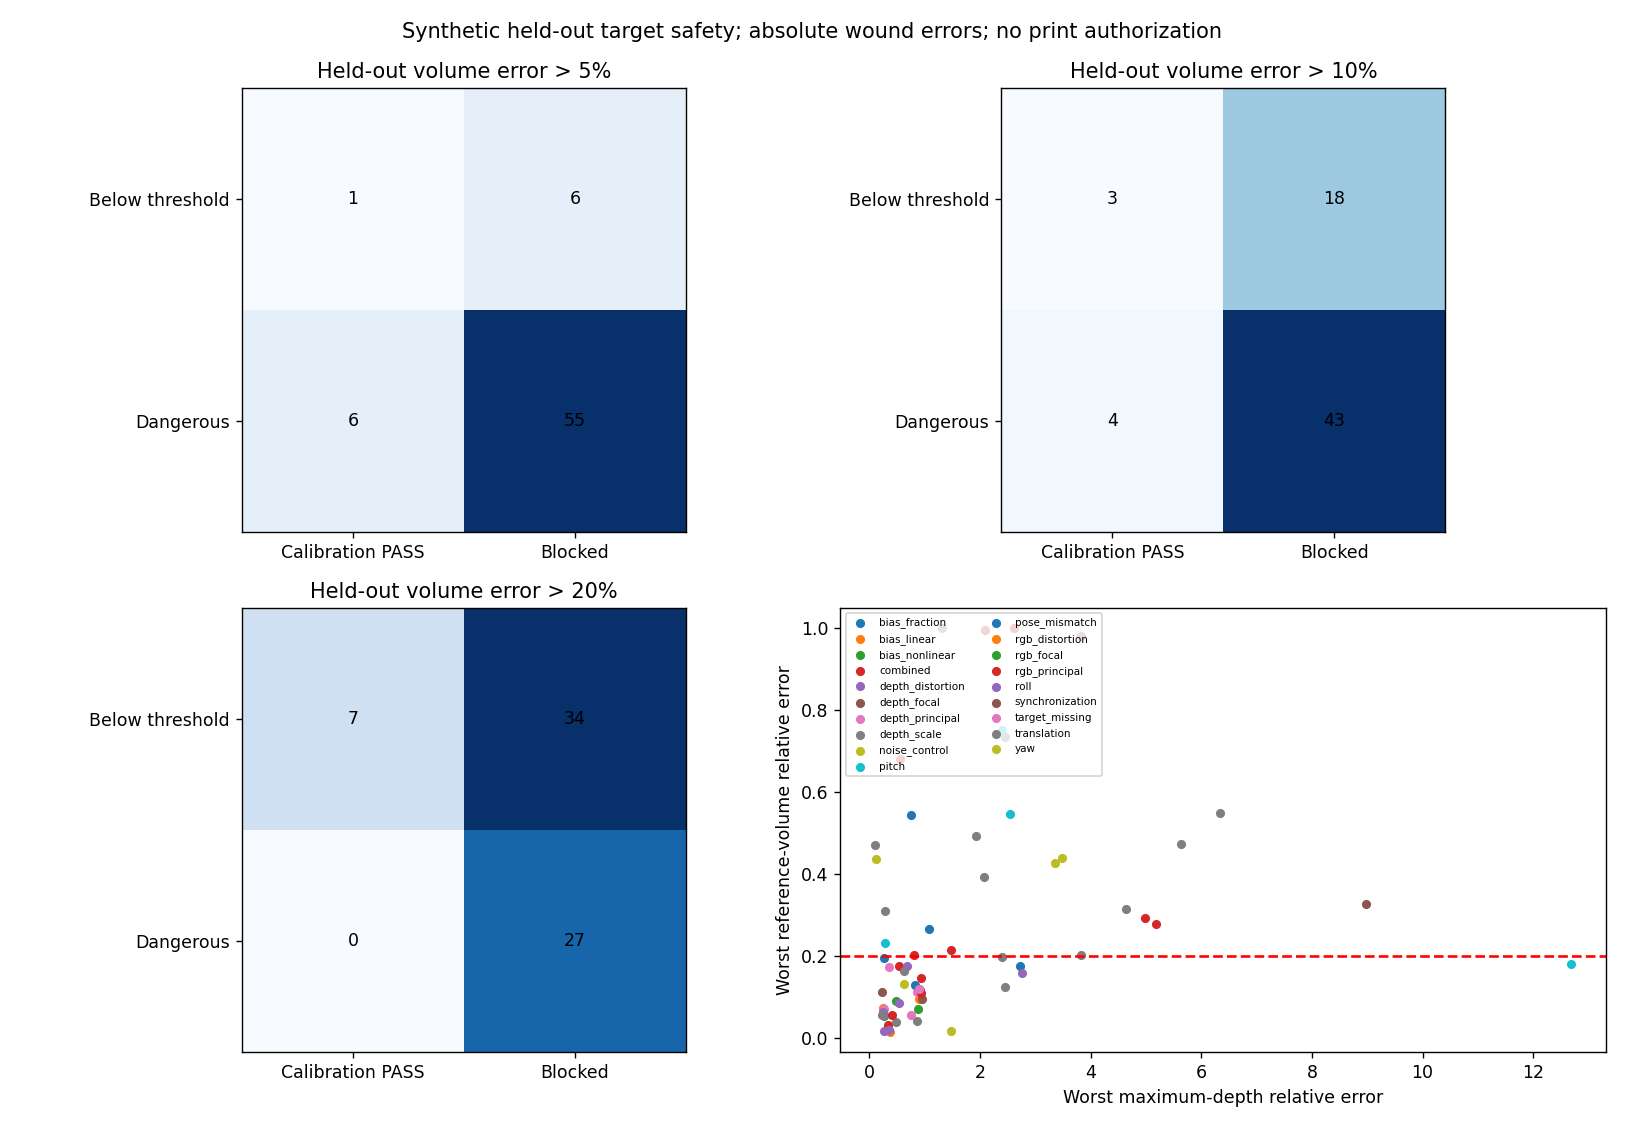

In [67]:
from pathlib import Path
import hashlib
import json
import numpy as np
STRICT_MEASUREMENT_POLICY = dict(stable_fraction_min=0.8, retained_fraction_min=0.9, boundary_resolution_min=100.0, reference_rmse_over_observed_width_max=0.02, depth_signal_to_uncertainty_min=5.0, volume_uncertainty_fraction_max=0.1, subset_volume_disagreement_max=0.1, subset_depth_disagreement_max=0.1, research_total_volume_error_max=0.1, research_total_max_depth_error_max=0.05, print_authorized=False, provenance='New fixed engineering measurement policy; not tuned on strict holdout labels or clinical thresholds.')

def s_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')

def s_freeze_measurement_policy(base):
    path = Path(base) / 'measurement_policy.json'
    if path.exists() and json.loads(path.read_text()) != STRICT_MEASUREMENT_POLICY:
        raise ValueError('Strict measurement policy changed.')
    if not path.exists():
        s_json(path, STRICT_MEASUREMENT_POLICY)
    return hashlib.sha256(path.read_bytes()).hexdigest()

def s_measurement_gate(observable, policy=None):
    policy = STRICT_MEASUREMENT_POLICY if policy is None else policy
    required = ('stable_fraction', 'retained_fraction', 'components', 'wound_width_px', 'reference_rmse_over_observed_width', 'depth_signal_to_uncertainty', 'volume_uncertainty_fraction', 'volume_positive', 'healthy_samples', 'subset_volume_disagreement', 'subset_depth_disagreement')
    if any((k not in observable or observable[k] is None or (not np.isfinite(observable[k])) for k in required)):
        decision = 'MEASUREMENT_INCONCLUSIVE'
    elif observable['stable_fraction'] < policy['stable_fraction_min'] or observable['retained_fraction'] < policy['retained_fraction_min'] or observable['components'] != 1:
        decision = 'WOUND_SURFACE_INCOMPLETE'
    elif observable['healthy_samples'] < 30 or observable['reference_rmse_over_observed_width'] > policy['reference_rmse_over_observed_width_max']:
        decision = 'REFERENCE_SURFACE_UNSTABLE'
    elif observable['wound_width_px'] < policy['boundary_resolution_min'] or observable['depth_signal_to_uncertainty'] < policy['depth_signal_to_uncertainty_min']:
        decision = 'SHALLOW_DEPTH_UNRELIABLE'
    elif not observable['volume_positive'] or observable['volume_uncertainty_fraction'] > policy['volume_uncertainty_fraction_max']:
        decision = 'VOLUME_ESTIMATE_UNSUPPORTED'
    elif observable.get('subset_volume_disagreement', 0.0) > policy['subset_volume_disagreement_max'] or observable.get('subset_depth_disagreement', 0.0) > policy['subset_depth_disagreement_max']:
        decision = 'MEASUREMENT_INCONCLUSIVE'
    else:
        decision = 'MEASUREMENT_SUPPORTED'
    return dict(decision=decision, supported=decision == 'MEASUREMENT_SUPPORTED', print_authorized=False, quality_basis='OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT', systematic_bias_certified=False)

def s_two_gate(calibration_decision, measurement):
    mapping = {'RGB_DEPTH_EXTRINSICS_FAILED': 'EXTRINSICS_FAILED', 'RGB_INTRINSICS_FAILED': 'INTRINSICS_FAILED', 'TARGET_NOT_OBSERVED': 'CALIBRATION_INCONCLUSIVE', 'REFUSE_WOUND_RECONSTRUCTION': 'CALIBRATION_INCONCLUSIVE'}
    calibration = mapping.get(calibration_decision, calibration_decision)
    allowed = {'CALIBRATION_PASS', 'CALIBRATION_WARNING', 'EXTRINSICS_FAILED', 'INTRINSICS_FAILED', 'DEPTH_SCALE_FAILED', 'SYNCHRONIZATION_FAILED', 'CALIBRATION_INCONCLUSIVE'}
    if calibration not in allowed:
        raise ValueError('Unknown strict calibration decision: ' + calibration)
    accepted = calibration == 'CALIBRATION_PASS' and measurement['decision'] == 'MEASUREMENT_SUPPORTED'
    return dict(calibration_gate=calibration, measurement_gate=measurement['decision'], reconstruction_accepted=accepted, print_authorized=False, decision='RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION' if accepted else 'REFUSE_WOUND_RECONSTRUCTION', physical_metric_validation=False)

def s_measurement_observables(consensus, K, pose, mask, helpers):
    online = helpers['g_online_consensus'](consensus, mask, K)
    width = online['observed_wound_width_depth_units']
    if width is None or width <= 0.0:
        return dict(stable_fraction=online['stable_fraction'], measurement_reason='NO_FINITE_DEPTH')
    (mesh, diagnostic) = helpers['sensor_mesh'](consensus, K, pose, mask, width, helpers)
    points = diagnostic.get('allxyz', np.empty((0, 3)))
    inside = diagnostic.get('inside', np.empty(0, bool))
    stable = diagnostic.get('stable_rows', np.empty(0, bool))
    healthy = points[~inside & stable] if len(points) else np.empty((0, 3))
    measured = helpers['sensor_measure'](mesh, healthy, pose, helpers)
    result = dict(stable_fraction=online['stable_fraction'], retained_fraction=diagnostic['retained'], components=1 if len(mesh.triangles) else 0, healthy_samples=len(healthy), wound_width_px=float(np.ptp(np.where(mask)[1])) if mask.any() else 0.0, observed_width_depth_units=width, observed_cross_view_iqr_over_width=online['cross_view_iqr_over_width'], reference_rmse_over_observed_width=None, depth_signal_to_uncertainty=None, volume_uncertainty_fraction=None, volume_positive=False)
    if measured['max_depth'] is None:
        return result
    rmse = float(measured['reference_holdout_RMSE'][measured['reference_kind']])
    sigma_fusion = float(np.median(consensus[:, 3])) / 1.349
    uncertainty = float(np.hypot(rmse, sigma_fusion))
    peak = measured['max_depth']
    volume = measured['volume']
    result.update(reference_rmse_over_observed_width=rmse / width, depth_signal_to_uncertainty=peak / max(uncertainty, 1e-12), volume_uncertainty_fraction=2.0 * uncertainty * measured['area'] / max(abs(volume), 1e-18), volume_positive=volume > 0, depth_uncertainty_depth_units=uncertainty, observable_max_depth_depth_units=peak, observable_volume_depth_units_cubed=volume, uncertainty_caveat='Conservative estimated random/reference-fit uncertainty; cannot certify systematic calibration/measurement bias.')
    return result

def s_error_triplet(prediction, clean_prediction, source_reference):

    def relative(value, reference):
        return abs(value - reference) / abs(reference) if value is not None and reference is not None and (np.isfinite(value) and np.isfinite(reference) and (reference != 0.0)) else None
    (total, clean) = (relative(prediction, source_reference), relative(clean_prediction, source_reference))
    incremental = relative(prediction, clean_prediction)
    signed = (prediction - clean_prediction) / abs(source_reference) if total is not None and clean is not None else None
    return dict(TOTAL_MEASUREMENT_ERROR=total, CLEAN_BASELINE_ERROR=clean, INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT=incremental, incremental_over_source=abs(signed) if signed is not None else None, signed_increment_over_source=signed, status='SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED' if all((x is not None for x in (total, clean, incremental))) else 'UNAVAILABLE_NOT_ASSUMED_ZERO')

def s_research_measurement_validity(row, policy=None):
    """Evaluation-only measurement validity; never an online detector input."""
    policy = STRICT_MEASUREMENT_POLICY if policy is None else policy
    if not row['surface_gate']:
        decision = 'WOUND_SURFACE_INCOMPLETE'
    elif row['volume_relative_error'] is None or row['max_depth_relative_error'] is None:
        decision = 'MEASUREMENT_INCONCLUSIVE'
    elif row['max_depth_relative_error'] > policy['research_total_max_depth_error_max']:
        decision = 'SHALLOW_DEPTH_UNRELIABLE'
    elif row['volume_relative_error'] > policy['research_total_volume_error_max']:
        decision = 'VOLUME_ESTIMATE_UNSUPPORTED'
    else:
        decision = 'MEASUREMENT_SUPPORTED'
    return dict(decision=decision, supported=decision == 'MEASUREMENT_SUPPORTED', evaluation_only_uses_source_reference=True, cannot_override_online_gate=True)

# Strict calibration holdout: frozen detector, two independent gates

The previous PARTIAL calibration milestone is immutable. This new evaluation
uses 240 fresh configurations: 48 normal clean, 168 calibration faults and
24 separate target-design stresses. Private manifest hashing precedes detector
execution; every target decision is frozen before labels are unlocked. There
were no holdout smoke checks. The original V2 detector and thresholds are
unchanged; no post-hoc stricter thresholds were adopted.

Four already-reviewed public wound sequences use new reference poses
6/12/18/24 and matched disjoint 20-view subsets. These are **not new independent
wound identities**. Clean baseline error, total error and additional error
relative to the matched clean reconstruction remain separate. Missing
measurements are not treated as zero error.

Calibration recall counts target decisions only, never measurement rejections.
The independent observable measurement gate uses coverage, reference-fit
uncertainty, depth signal and subset disagreement. GT-based measurement
validity is reported separately and is not available online. Neither gate
certifies common systematic bias. Calibration PASS cannot override measurement
failure. Printing is disabled in every case.

Select `ACTION="STRICT_CALIBRATION_HOLDOUT"`, `DATASET="SYN3DWOUND"`,
`METHOD="COLMAP"`, `LICENCE_ACKNOWLEDGED=True`. Attach the frozen `target_study`
under `RGB_STRICT_HOLDOUT_OUTPUT`, the unchanged generalization masks/depth
caches under `RGB_GENERALIZATION_INPUT`, and the public source data under
`RGB_RESCUE_INPUT`. This mode verifies and resumes the sealed study rather
than silently generating a replacement holdout. Default REPLAY displays the
completed recorded results without acquisitions or detector tuning.

The full-image fault model still uses synthetic co-located RGB/depth cameras,
not a measured physical stereo baseline. Depth discontinuity distortion is a
smooth range-transition stress, not an empirically measured sensor artifact.
The target is proposed, not physically validated. No hardware, LingBot,
event camera, robot, printing planner or production refactor is included.


In [68]:
import hashlib, json, sys, importlib
STRICT_EXPERIMENT_SOURCES = {'calibration_target_v2.py': '"""Synthetic RGB-D calibration target generator and detector, protocol v2.\n\nv1 (calibration_target.py; results/rgb_wound/calibration_safety/target) is\nimmutable. v2 fixes the causes found by the post-freeze v1 held-out CLEAN audit:\n1. CLEAN/fault view association: each configuration renders its OWN two views\n   (own seed, view index 0 and 1). No pooled capture substitution.\n2. Step blocks sit BESIDE the ChArUco grid on a common base plate, so no\n   fiducial is occluded. A 10x7 ChArUco (54 corners) is rendered with 3x\n   supersampling and pixel-centre-correct texture mapping.\n3. Depth features are sampled only where the known layout, rendered at the\n   OBSERVED RGB PnP pose with DECLARED intrinsics, predicts an unoccluded,\n   edge-free surface. The true pose is never used online.\n4. Step tops are segmented in registered depth, which gives a depth-only 6-DoF\n   target pose used for RGB-depth extrinsic and synchronization checks.\nUnits are normalized to working distance 1.0. The RGB and depth cameras are\nco-located (no baseline modeled), and true lens distortion is zero. RGB and\ndepth sensor noise is included. Synthetic only: no physical, clinical, or\nprinting validation.\n"""\n\nfrom __future__ import annotations\n\nimport ast\nimport hashlib\nimport inspect\nimport json\nimport math\nimport os\nimport textwrap\nfrom datetime import datetime, timezone\nfrom pathlib import Path\nfrom typing import Any\n\nimport cv2\nimport numpy as np\n\n\n_PROTOCOL_VERSION = "v2"\n_WIDTH, _HEIGHT = 640, 480\n_WORKING_DISTANCE = 1.0\n_GRID = (10, 7)\n_SQUARE = 0.03\n_MARKER = 0.021\n_BOARD_W, _BOARD_H = _GRID[0] * _SQUARE, _GRID[1] * _SQUARE\n_PLATE_XYXY = (-0.015, -0.015, 0.42, 0.225)\n_TABLE_OFFSET = 0.01\n_BLOCKS = (\n    {"xywh": [0.345, 0.015, 0.045, 0.045], "height": 0.02},\n    {"xywh": [0.345, 0.0825, 0.045, 0.045], "height": 0.04},\n    {"xywh": [0.345, 0.15, 0.045, 0.045], "height": 0.06},\n)\n_IMAGE_K = np.array([[1000.0, 0.0, _WIDTH / 2],\n                     [0.0, 1000.0, _HEIGHT / 2],\n                     [0.0, 0.0, 1.0]], dtype=np.float64)\n_ZERO_DIST = np.zeros(5, dtype=np.float64)\n_DICT_ID = cv2.aruco.DICT_4X4_50\n_DICT_NAME = "DICT_4X4_50"\n_SUPERSAMPLE = 3\n_TEX_PX_PER_WD = 3000\n_RGB_NOISE_SIGMA = 2.0\n_DEPTH_NOISE_SIGMA = 0.0005\n_TABLE_GRAY = 90.0\n_FACE_GRAY = (228.0, 150.0, 175.0, 200.0, 130.0)\n_MIN_CORNERS = 12\n_STEP_ROI_DILATION = 0.01\n_THRESHOLD_FACTOR = 1.5\n_THRESHOLD_FLOORS = {\n    "rgb_reprojection_px": 0.5,\n    "depth_scale_error_fraction": 0.002,\n    "rigid_fit_rmse_fraction": 0.001,\n    "rgb_depth_rotation_deg": 0.15,\n    "rgb_depth_translation_fraction": 0.002,\n    "plane_residual_fraction": 0.0005,\n    "step_height_error_fraction": 0.001,\n    "normal_angle_deg": 0.15,\n    "alignment_reprojection_px": 0.5,\n    "cross_view_translation_std_fraction": 0.001,\n    "cross_view_rotation_std_deg": 0.1,\n}\n_METRIC_RULES = {\n    "rgb_reprojection_px": "RGB_INTRINSICS_FAILED",\n    "depth_scale_error_fraction": "DEPTH_SCALE_FAILED",\n    "rgb_depth_rotation_deg": "RGB_DEPTH_EXTRINSICS_FAILED",\n    "rgb_depth_translation_fraction": "RGB_DEPTH_EXTRINSICS_FAILED",\n    "alignment_reprojection_px": "RGB_DEPTH_EXTRINSICS_FAILED",\n    "normal_angle_deg": "RGB_DEPTH_EXTRINSICS_FAILED",\n    "cross_view_translation_std_fraction": "SYNCHRONIZATION_FAILED",\n    "cross_view_rotation_std_deg": "SYNCHRONIZATION_FAILED",\n    "plane_residual_fraction": "CALIBRATION_WARNING",\n    "step_height_error_fraction": "CALIBRATION_WARNING",\n    "rigid_fit_rmse_fraction": "CALIBRATION_WARNING",\n}\n_DECISION_PRIORITY = ("SYNCHRONIZATION_FAILED", "RGB_INTRINSICS_FAILED", "DEPTH_SCALE_FAILED",\n                      "RGB_DEPTH_EXTRINSICS_FAILED", "CALIBRATION_WARNING")\n_TEXTURE_CACHE: dict[str, np.ndarray] = {}\n\n\ndef _utc() -> str:\n    return datetime.now(timezone.utc).isoformat()\n\n\ndef _sha(data: bytes) -> str:\n    return hashlib.sha256(data).hexdigest()\n\n\ndef _json_bytes(value: Any) -> bytes:\n    return json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False).encode("utf-8")\n\n\ndef _json_write(path: Path, value: Any) -> None:\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False) + "\\n", encoding="utf-8")\n\n\ndef _json_load(path: Path) -> Any:\n    return json.loads(Path(path).read_text(encoding="utf-8"))\n\n\ndef _artifact_sha(path: Path) -> str:\n    path = Path(path)\n    if path.is_file():\n        return _sha(path.read_bytes())\n    entries = [{"name": p.relative_to(path).as_posix(), "sha256": _sha(p.read_bytes())}\n               for p in sorted(path.rglob("*")) if p.is_file()]\n    return _sha(_json_bytes(entries))\n\n\ndef _finite(value: Any) -> bool:\n    try:\n        return value is not None and bool(np.isfinite(float(value)))\n    except (TypeError, ValueError):\n        return False\n\n\ndef _jsonable(value: Any) -> Any:\n    if isinstance(value, dict):\n        return {str(k): _jsonable(v) for k, v in value.items()}\n    if isinstance(value, (list, tuple)):\n        return [_jsonable(v) for v in value]\n    if isinstance(value, np.ndarray):\n        return _jsonable(value.tolist())\n    if isinstance(value, (np.integer,)):\n        return int(value)\n    if isinstance(value, (float, np.floating)):\n        return float(value) if np.isfinite(value) else None\n    return value\n\n\ndef _safe_id(family: str, payload: dict[str, Any]) -> str:\n    return f"{family.lower().replace(\' \', \'_\')}-{_sha(_json_bytes(payload))[:10]}"\n\n\ndef _board():\n    dictionary = cv2.aruco.getPredefinedDictionary(_DICT_ID)\n    board = cv2.aruco.CharucoBoard(_GRID, _SQUARE, _MARKER, dictionary)\n    return dictionary, board\n\n\ndef _rot_xyz(degrees: list[float] | tuple[float, ...]) -> np.ndarray:\n    x, y, z = np.deg2rad(np.asarray(degrees, dtype=np.float64))\n    rx = np.array([[1, 0, 0], [0, math.cos(x), -math.sin(x)], [0, math.sin(x), math.cos(x)]])\n    ry = np.array([[math.cos(y), 0, math.sin(y)], [0, 1, 0], [-math.sin(y), 0, math.cos(y)]])\n    rz = np.array([[math.cos(z), -math.sin(z), 0], [math.sin(z), math.cos(z), 0], [0, 0, 1]])\n    return rz @ ry @ rx\n\n\ndef _pose_matrix(rvec: np.ndarray) -> np.ndarray:\n    return cv2.Rodrigues(np.asarray(rvec, dtype=np.float64).reshape(3))[0]\n\n\ndef _project(xyz: np.ndarray, rvec: np.ndarray, tvec: np.ndarray,\n             K: np.ndarray, dist: np.ndarray | None = None) -> np.ndarray:\n    p, _ = cv2.projectPoints(np.asarray(xyz, dtype=np.float64).reshape(-1, 1, 3),\n                             np.asarray(rvec, dtype=np.float64).reshape(3),\n                             np.asarray(tvec, dtype=np.float64).reshape(3),\n                             np.asarray(K, dtype=np.float64), dist)\n    return p.reshape(-1, 2)\n\n\ndef c_project(points: np.ndarray, K: np.ndarray, dist: np.ndarray | None = None) -> np.ndarray:\n    """Project camera-frame points (Nx3) to Nx2 pixel coordinates."""\n    xyz = np.asarray(points, dtype=np.float64).reshape(-1, 3)\n    if not len(xyz):\n        return np.empty((0, 2), dtype=np.float64)\n    return _project(xyz, np.zeros(3), np.zeros(3), K, dist)\n\n\ndef c_rgb_calibration(Ktrue: np.ndarray, fault: dict[str, Any],\n                      shape: tuple[int, ...]) -> tuple[np.ndarray, np.ndarray]:\n    """Return the RGB intrinsics/distortion declared to the detector (shape=(h,w))."""\n    h, w = int(shape[0]), int(shape[1])\n    k = np.asarray(Ktrue, dtype=np.float64).copy()\n    k[0, 0] *= 1.0 + float(fault.get("rgb_focal_scale", 0.0))\n    k[1, 1] *= 1.0 + float(fault.get("rgb_focal_scale", 0.0))\n    pp = fault.get("rgb_principal_fraction", [0.0, 0.0])\n    k[0, 2] += float(pp[0]) * w\n    k[1, 2] += float(pp[1]) * h\n    return k, np.asarray(fault.get("rgb_distortion", [0, 0, 0, 0, 0]), dtype=np.float64)\n\n\ndef c_fault_points(points_camera: np.ndarray, fault: dict[str, Any],\n                   Ktrue: np.ndarray, working_distance: float) -> np.ndarray:\n    """Corrupt camera-frame 3D points using declared depth calibration faults.\n\n    Semantics are identical to v1. Scale-like keys are fractional deltas\n    (depth_scale=0.02 means +2%). ``sync_delta`` is not applied here. Invalid\n    input rows and points transformed behind the camera are returned as NaN.\n    """\n    src = np.asarray(points_camera, dtype=np.float64).reshape(-1, 3)\n    out = np.full_like(src, np.nan, dtype=np.float64)\n    valid = np.isfinite(src).all(axis=1) & (src[:, 2] > 0)\n    if not valid.any():\n        return out\n    points = src[valid].copy()\n    ktrue = np.asarray(Ktrue, dtype=np.float64)\n    pix = c_project(points, ktrue, np.zeros(5))\n    kdecl = ktrue.copy()\n    sf = 1.0 + float(fault.get("focal_scale", 0.0))\n    kdecl[0, 0] *= sf\n    kdecl[1, 1] *= sf\n    pp = fault.get("principal_fraction", [0.0, 0.0])\n    # Fractions use the camera image size, inferred from the principal point.\n    width, height = 2.0 * ktrue[0, 2], 2.0 * ktrue[1, 2]\n    kdecl[0, 2] += float(pp[0]) * width\n    kdecl[1, 2] += float(pp[1]) * height\n    ddecl = np.asarray(fault.get("distortion", [0, 0, 0, 0, 0]), dtype=np.float64).reshape(1, 5)\n    normalized = cv2.undistortPoints(pix.reshape(-1, 1, 2), kdecl, ddecl).reshape(-1, 2)\n    z = points[:, 2].copy()\n    z *= 1.0 + float(fault.get("depth_scale", 0.0))\n    z += float(fault.get("bias_fraction", 0.0)) * working_distance\n    z += float(fault.get("bias_linear", 0.0)) * (points[:, 2] - working_distance)\n    z += float(fault.get("bias_nonlinear", 0.0)) * ((points[:, 2] - working_distance) ** 2) / working_distance\n    xyz = np.column_stack((normalized[:, 0] * z, normalized[:, 1] * z, z))\n    if "depth_noise_sigma_fraction" in fault:\n        rng = np.random.default_rng(int(fault.get("noise_seed", 0)))\n        xyz += rng.normal(0.0, float(fault["depth_noise_sigma_fraction"]) * working_distance, xyz.shape)\n    xyz = (_rot_xyz(fault.get("rotation_deg", [0, 0, 0])) @ xyz.T).T\n    tr = np.asarray(fault.get("translation_fraction", [0, 0, 0]), dtype=np.float64) * working_distance\n    xyz += tr\n    pose_r = np.asarray(fault.get("pose_rotation_deg", [0, 0, 0]), dtype=np.float64)\n    xyz = (_rot_xyz(pose_r) @ xyz.T).T\n    xyz += np.asarray(fault.get("pose_translation_fraction", [0, 0, 0]), dtype=np.float64) * working_distance\n    good = np.isfinite(xyz).all(axis=1) & (xyz[:, 2] > 0)\n    ix = np.flatnonzero(valid)\n    out[ix[good]] = xyz[good]\n    return out\n\n\ndef _fault_catalogue() -> list[dict[str, Any]]:\n    """Same 190 fault dicts, families, splits and sequences as v1; new v2 seeds/IDs."""\n    configs: list[dict[str, Any]] = []\n\n    def add(family: str, fault: dict[str, Any], split: str = "TEST",\n            target_kind: str = "STEPPED", sequence: str | None = None) -> None:\n        n = len(configs)\n        seq = sequence or ("shoulder" if split == "TRAIN" else\n                           ("arm", "hand", "sacrum_phi")[n % 3])\n        magnitudes = []\n        for value in fault.values():\n            try:\n                magnitudes.extend(np.abs(np.asarray(value, dtype=np.float64)).reshape(-1).tolist())\n            except (TypeError, ValueError):\n                continue\n        payload = {"family": family, "fault": fault, "split": split, "protocol": "v2",\n                   "sequence": seq, "target_kind": target_kind, "index": n}\n        configs.append({"id": _safe_id(family, payload), "split": split,\n                        "sequence": seq, "family": family, "magnitude": max(magnitudes, default=0.0),\n                        "fault": fault, "seed": 50021 + n * 41,\n                        "target_kind": target_kind})\n\n    for i in range(8):\n        add("CLEAN", {}, "TRAIN", sequence="shoulder")\n    for i in range(24):\n        add("CLEAN", {}, "TEST", sequence=("arm", "hand", "sacrum_phi")[i % 3])\n\n    def split_magnitude(magnitude: float, train_values: tuple[float, ...]) -> str:\n        return "TRAIN" if any(abs(magnitude - t) < 1e-8 for t in train_values) else "TEST"\n\n    for axis, key in enumerate(("translation_fraction",) * 3):\n        for mag in (0.0025, 0.005, 0.01, 0.02, 0.05):\n            for sign in (-1, 1):\n                v = [0.0, 0.0, 0.0]\n                v[axis] = sign * mag\n                add("translation", {key: v}, split_magnitude(mag, (0.0025, 0.01, 0.05)))\n    for axis in range(3):\n        for mag in (0.1, 0.25, 0.5, 1.0, 2.0, 5.0):\n            for sign in (-1, 1):\n                v = [0.0, 0.0, 0.0]\n                v[axis] = sign * mag\n                add(("pitch", "yaw", "roll")[axis], {"rotation_deg": v},\n                    split_magnitude(mag, (0.1, 0.5, 2.0)))\n    for mag in (0.005, 0.01, 0.02, 0.05, 0.1):\n        for sign in (-1, 1):\n            add("depth_scale", {"depth_scale": sign * mag},\n                split_magnitude(mag, (0.005, 0.02, 0.1)))\n    for key, values, train in (\n        ("bias_fraction", (0.005, 0.01, 0.02), (0.005, 0.02)),\n        ("bias_linear", (0.01, 0.03, 0.06), (0.01, 0.06)),\n        ("bias_nonlinear", (0.02, 0.05, 0.1), (0.02, 0.1)),\n    ):\n        for mag in values:\n            for sign in (-1, 1):\n                add(key, {key: sign * mag}, split_magnitude(mag, train))\n    for rgb in (False, True):\n        prefix = "rgb_" if rgb else ""\n        key = prefix + "focal_scale" if rgb else "focal_scale"\n        for mag in (0.01, 0.03, 0.05):\n            for sign in (-1, 1):\n                add("rgb_focal" if rgb else "depth_focal", {key: sign * mag},\n                    split_magnitude(mag, (0.01, 0.05)))\n        key = prefix + "principal_fraction" if rgb else "principal_fraction"\n        for axis in range(2):\n            for mag in (0.002, 0.005, 0.01):\n                for sign in (-1, 1):\n                    v = [0.0, 0.0]\n                    v[axis] = sign * mag\n                    add("rgb_principal" if rgb else "depth_principal", {key: v},\n                        split_magnitude(mag, (0.002, 0.01)))\n        for mag in (0.02, 0.05):\n            for sign in (-1, 1):\n                d = [0.0, 0.0, 0.0, 0.0, 0.0]\n                d[0] = sign * mag\n                add("rgb_distortion" if rgb else "depth_distortion",\n                    {"rgb_distortion" if rgb else "distortion": d},\n                    split_magnitude(mag, (0.02,)))\n    for delta in (-1, 1):\n        add("synchronization", {"sync_delta": delta})\n    for axis, mag in ((0, 0.25), (1, 0.5), (2, 0.25)):\n        r = [0.0, 0.0, 0.0]\n        r[axis] = mag\n        add("pose_mismatch", {"pose_rotation_deg": r})\n    combos = [\n        {"rotation_deg": [0.0, 1.0, 0.0], "depth_scale": 0.02},\n        {"rotation_deg": [0.0, -2.0, 0.0], "depth_scale": -0.05},\n        {"translation_fraction": [0.0, 0.0, 0.01], "bias_fraction": 0.02},\n        {"translation_fraction": [0.0, 0.0, -0.02], "bias_linear": -0.03},\n        {"focal_scale": 0.03, "rotation_deg": [0.0, 0.0, 1.0]},\n        {"principal_fraction": [0.005, 0.0], "translation_fraction": [0.005, 0.0, 0.0]},\n        {"rgb_focal_scale": -0.03, "rotation_deg": [1.0, 0.0, 0.0]},\n        {"depth_scale": 0.02, "bias_nonlinear": 0.05},\n        {"rotation_deg": [0.0, 1.0, 0.0], "bias_fraction": 0.01},\n        {"rgb_principal_fraction": [0.0, 0.005], "depth_scale": -0.02},\n        {"rotation_deg": [0.0, 0.0, 2.0], "pose_translation_fraction": [0.005, 0.0, 0.0]},\n        {"rgb_distortion": [0.05, 0.0, 0.0, 0.0, 0.0], "focal_scale": -0.02},\n    ]\n    for i, fault in enumerate(combos):\n        add("combined", fault, "TRAIN" if i in (0, 3, 7) else "TEST")\n    add("noise_control", {"depth_noise_sigma_fraction": 0.001, "noise_seed": 13}, "TRAIN")\n    add("noise_control", {"depth_noise_sigma_fraction": 0.002, "noise_seed": 29}, "TEST")\n    add("target_missing", {"target_missing": True}, "TEST")\n    return configs\n\n\ndef c_fault_catalogue(base: str | os.PathLike[str]) -> list[dict[str, Any]]:\n    """Return the deterministic 190-row TRAIN/TEST catalogue (94 TRAIN, 96 TEST).\n\n    Fault dicts, families, splits and sequences are identical to v1 row-by-row;\n    only seeds and IDs differ (see v1_v2_config_map.json).\n    """\n    return _fault_catalogue()\n\n\ndef _v1_equivalent_ids() -> list[dict[str, Any]]:\n    rows = []\n    for n, cfg in enumerate(_fault_catalogue()):\n        payload = {"family": cfg["family"], "fault": cfg["fault"], "split": cfg["split"],\n                   "sequence": cfg["sequence"], "target_kind": cfg["target_kind"], "index": n}\n        rows.append({"v2_id": cfg["id"], "v1_id": _safe_id(cfg["family"], payload),\n                     "split": cfg["split"], "sequence": cfg["sequence"], "family": cfg["family"],\n                     "fault": cfg["fault"]})\n    return rows\n\n\ndef _calibration_clean_configs() -> list[dict[str, Any]]:\n    """Additional TRAIN-only shoulder CLEAN captures used solely for thresholds."""\n    rows = []\n    for i in range(32):\n        payload = {"family": "CLEAN", "role": "threshold_calibration_only", "index": i, "protocol": "v2"}\n        rows.append({"id": "cal" + _safe_id("CLEAN", payload), "split": "TRAIN",\n                     "sequence": "shoulder", "family": "CLEAN", "magnitude": 0.0, "fault": {},\n                     "seed": 90001 + i * 53, "target_kind": "STEPPED",\n                     "role": "threshold_calibration_only"})\n    return rows\n\n\ndef _layout(kind: str) -> dict[str, Any]:\n    blocks = [] if kind == "PLANAR" else [{"xywh": list(b["xywh"]), "height": b["height"]} for b in _BLOCKS]\n    board_points = [[(i + 0.5) * _SQUARE, (j + 0.5) * _SQUARE, 0.0]\n                    for j in range(_GRID[1]) for i in range(_GRID[0])]\n    tops = [[b["xywh"][0] + b["xywh"][2] / 2, b["xywh"][1] + b["xywh"][3] / 2, -b["height"]]\n            for b in blocks]\n    return {"kind": kind, "plate_xyxy": list(_PLATE_XYXY), "board_width": _BOARD_W,\n            "board_height": _BOARD_H, "square_length": _SQUARE, "marker_length": _MARKER,\n            "dictionary": _DICT_NAME, "grid": list(_GRID), "blocks": blocks,\n            "landmark_xyz": board_points + tops,\n            "landmark_plane": [True] * len(board_points) + [False] * len(tops),\n            "step_heights": [b["height"] for b in blocks]}\n\n\ndef _camera_pose(seed: int, sequence: str, index: int) -> tuple[np.ndarray, np.ndarray]:\n    rng = np.random.default_rng(int(seed) + int(index) * 997)\n    seq_offset = {"shoulder": 0.0, "arm": -2.0, "hand": 1.5, "sacrum_phi": 2.5}.get(sequence, 0.0)\n    tilt = rng.uniform(-9.0, 9.0) + seq_offset\n    yaw = rng.uniform(-11.0, 11.0)\n    roll = rng.uniform(-7.0, 7.0)\n    R = _rot_xyz([tilt, yaw, roll])\n    center = np.array([(_PLATE_XYXY[0] + _PLATE_XYXY[2]) / 2, (_PLATE_XYXY[1] + _PLATE_XYXY[3]) / 2, 0.0])\n    tvec = np.array([rng.uniform(-0.02, 0.02), rng.uniform(-0.015, 0.015),\n                     1.0 + rng.uniform(-0.04, 0.04)]) - R @ center\n    return cv2.Rodrigues(R)[0].reshape(3), tvec\n\n\ndef _frame_pose(seed: int, sequence: str, index: int, frame: int) -> tuple[np.ndarray, np.ndarray]:\n    """Target pose in an adjacent frame (hand-held motion model, eval-only truth)."""\n    rvec, tvec = _camera_pose(seed, sequence, index)\n    if not frame:\n        return rvec, tvec\n    rng = np.random.default_rng([int(seed), int(index), 7])\n    axis = rng.normal(size=3)\n    axis /= np.linalg.norm(axis)\n    rate = np.deg2rad(rng.uniform(0.6, 1.2))\n    vel = rng.normal(size=3)\n    vel *= rng.uniform(0.004, 0.008) / np.linalg.norm(vel)\n    Rm = _pose_matrix(axis * rate * frame)\n    R = Rm @ _pose_matrix(rvec)\n    return cv2.Rodrigues(R)[0].reshape(3), Rm @ tvec + vel * frame\n\n\ndef _raycast(layout: dict[str, Any], rvec: np.ndarray, tvec: np.ndarray, K: np.ndarray,\n             dist: np.ndarray | None, us: np.ndarray, vs: np.ndarray,\n             include_table: bool = True, include_target: bool = True) -> tuple[np.ndarray, np.ndarray]:\n    """Ray-cast known geometry. Returns camera z and surface code per pixel.\n\n    Codes: -1 none, 0 base plate, 1 table, 10*(i+1)+f for block i with face f\n    (0 top, 1 x-low, 2 x-high, 3 y-low, 4 y-high side).\n    """\n    shape = np.shape(us)\n    pix = np.column_stack((np.ravel(us), np.ravel(vs))).astype(np.float64)\n    K = np.asarray(K, dtype=np.float64)\n    if dist is None or not np.any(np.asarray(dist)):\n        xn = (pix[:, 0] - K[0, 2]) / K[0, 0]\n        yn = (pix[:, 1] - K[1, 2]) / K[1, 1]\n    else:\n        nrm = cv2.undistortPoints(pix.reshape(-1, 1, 2), K,\n                                  np.asarray(dist, dtype=np.float64).reshape(1, -1)).reshape(-1, 2)\n        xn, yn = nrm[:, 0], nrm[:, 1]\n    dc = np.column_stack((xn, yn, np.ones_like(xn)))\n    R = _pose_matrix(rvec)\n    o = -R.T @ np.asarray(tvec, dtype=np.float64).reshape(3)\n    d = dc @ R\n    best = np.full(len(d), np.inf)\n    surf = np.full(len(d), -1, dtype=np.int32)\n    with np.errstate(divide="ignore", invalid="ignore"):\n        if include_target:\n            tp = (0.0 - o[2]) / d[:, 2]\n            hx = o[0] + tp * d[:, 0]\n            hy = o[1] + tp * d[:, 1]\n            x0, y0, x1, y1 = layout["plate_xyxy"]\n            good = np.isfinite(tp) & (tp > 0) & (hx >= x0) & (hx <= x1) & (hy >= y0) & (hy <= y1)\n            best[good] = tp[good]\n            surf[good] = 0\n        if include_table:\n            tt = (_TABLE_OFFSET - o[2]) / d[:, 2]\n            good = np.isfinite(tt) & (tt > 0) & (tt < best)\n            best[good] = tt[good]\n            surf[good] = 1\n        if include_target:\n            for i, b in enumerate(layout["blocks"]):\n                bx, by, bw, bh = b["xywh"]\n                lo = np.array([bx, by, -b["height"]])\n                hi = np.array([bx + bw, by + bh, 0.0])\n                t1 = (lo - o) / d\n                t2 = (hi - o) / d\n                tmn = np.fmin(t1, t2)\n                tmx = np.fmax(t1, t2)\n                tin = np.fmax.reduce(tmn, axis=1)\n                tout = np.fmin.reduce(tmx, axis=1)\n                hit = np.isfinite(tin) & (tout >= tin) & (tin > 0) & (tin < best)\n                ax = np.argmax(np.where(np.isnan(tmn), -np.inf, tmn), axis=1)\n                face = np.where(ax == 2, 0, np.where(ax == 0, np.where(d[:, 0] > 0, 1, 2),\n                                                     np.where(d[:, 1] > 0, 3, 4)))\n                best[hit] = tin[hit]\n                surf[hit] = 10 * (i + 1) + face[hit]\n    best[~np.isfinite(best)] = np.nan\n    # Camera-frame ray directions have unit z, so the ray parameter is camera z.\n    return best.reshape(shape), surf.reshape(shape)\n\n\ndef _plate_texture() -> np.ndarray:\n    if "plate" not in _TEXTURE_CACHE:\n        _, board = _board()\n        s = _TEX_PX_PER_WD\n        bw, bh = int(round(_BOARD_W * s)), int(round(_BOARD_H * s))\n        img = board.generateImage((bw, bh), marginSize=0, borderBits=1)\n        x0, y0, x1, y1 = _PLATE_XYXY\n        tex = np.full((int(round((y1 - y0) * s)), int(round((x1 - x0) * s))), 255, np.uint8)\n        ox, oy = int(round(-x0 * s)), int(round(-y0 * s))\n        tex[oy:oy + bh, ox:ox + bw] = img\n        _TEXTURE_CACHE["plate"] = tex\n    return _TEXTURE_CACHE["plate"]\n\n\ndef _supersample_K(K: np.ndarray, s: int) -> np.ndarray:\n    Ks = np.asarray(K, dtype=np.float64).copy()\n    Ks[0, 0] *= s\n    Ks[1, 1] *= s\n    Ks[0, 2] = (K[0, 2] + 0.5) * s - 0.5\n    Ks[1, 2] = (K[1, 2] + 0.5) * s - 0.5\n    return Ks\n\n\ndef _render_rgb(layout: dict[str, Any], rvec: np.ndarray, tvec: np.ndarray, K: np.ndarray,\n                rng: np.random.Generator, missing: bool = False,\n                noise_sigma: float = _RGB_NOISE_SIGMA,\n                occluder: dict[str, float] | None = None) -> np.ndarray:\n    s = _SUPERSAMPLE\n    Ks = _supersample_K(K, s)\n    hs, ws = _HEIGHT * s, _WIDTH * s\n    img = np.full((hs, ws), _TABLE_GRAY, np.float32)\n    if not missing:\n        tex = _plate_texture().astype(np.float32)\n        th, tw = tex.shape\n        x0, y0, x1, y1 = layout["plate_xyxy"]\n        src = np.float32([[-0.5, -0.5], [tw - 0.5, -0.5], [tw - 0.5, th - 0.5], [-0.5, th - 0.5]])\n        dst = _project(np.array([[x0, y0, 0], [x1, y0, 0], [x1, y1, 0], [x0, y1, 0]], float),\n                       rvec, tvec, Ks).astype(np.float32)\n        Hm = cv2.getPerspectiveTransform(src, dst)\n        warped = cv2.warpPerspective(tex, Hm, (ws, hs), flags=cv2.INTER_LINEAR,\n                                     borderMode=cv2.BORDER_CONSTANT, borderValue=0)\n        cover = cv2.warpPerspective(np.ones_like(tex), Hm, (ws, hs), flags=cv2.INTER_LINEAR,\n                                    borderMode=cv2.BORDER_CONSTANT, borderValue=0)\n        img = img * (1.0 - cover) + warped\n        if layout["blocks"]:\n            verts = []\n            for b in layout["blocks"]:\n                x, y, w, h = b["xywh"]\n                for z in (0.0, -b["height"]):\n                    verts += [[x, y, z], [x + w, y, z], [x + w, y + h, z], [x, y + h, z]]\n            pv = _project(np.array(verts), rvec, tvec, Ks)\n            u0 = max(0, int(np.floor(pv[:, 0].min())) - 2)\n            u1 = min(ws, int(np.ceil(pv[:, 0].max())) + 3)\n            v0 = max(0, int(np.floor(pv[:, 1].min())) - 2)\n            v1 = min(hs, int(np.ceil(pv[:, 1].max())) + 3)\n            if u1 > u0 and v1 > v0:\n                vv, uu = np.mgrid[v0:v1, u0:u1]\n                _, surf = _raycast(layout, rvec, tvec, Ks, None, uu.astype(float), vv.astype(float))\n                box = surf >= 10\n                lut = np.asarray(_FACE_GRAY, np.float32)\n                patch = img[v0:v1, u0:u1]\n                patch[box] = lut[surf[box] % 10]\n    if occluder:\n        cv2.circle(img, (int(round((occluder["u"] + 0.5) * s - 0.5)), int(round((occluder["v"] + 0.5) * s - 0.5))),\n                   int(round(occluder["r"] * s)), float(occluder.get("gray", 170.0)), -1, cv2.LINE_AA)\n    small = cv2.resize(img, (_WIDTH, _HEIGHT), interpolation=cv2.INTER_AREA)\n    small = small + rng.normal(0.0, noise_sigma, small.shape)\n    gray = np.clip(np.rint(small), 0, 255).astype(np.uint8)\n    return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)\n\n\ndef _render_depth(layout: dict[str, Any], rvec: np.ndarray, tvec: np.ndarray, K: np.ndarray,\n                  rng: np.random.Generator, missing: bool = False,\n                  occluder: dict[str, float] | None = None,\n                  dropout: float = 0.0) -> tuple[np.ndarray, np.ndarray, np.ndarray]:\n    vv, uu = np.mgrid[0:_HEIGHT, 0:_WIDTH]\n    z, surf = _raycast(layout, rvec, tvec, K, None, uu.astype(float), vv.astype(float),\n                       include_table=True, include_target=not missing)\n    visible = (surf == 0) | (surf >= 10)\n    if occluder:\n        disc = (uu - occluder["u"]) ** 2 + (vv - occluder["v"]) ** 2 <= occluder["r"] ** 2\n        z = np.where(disc, float(occluder.get("z", 0.85)), z)\n        visible = visible & ~disc\n        surf = np.where(disc, -2, surf)\n    noisy = z + rng.normal(0.0, 1.0, z.shape) * _DEPTH_NOISE_SIGMA * np.nan_to_num(z) ** 2\n    if dropout > 0:\n        noisy = np.where(rng.random(z.shape) < dropout, np.nan, noisy)\n    return noisy.astype(np.float32), (visible.astype(np.uint8) * 255), surf\n\n\ndef _depth_cloud(depth: np.ndarray, K: np.ndarray) -> np.ndarray:\n    vv, uu = np.mgrid[0:depth.shape[0], 0:depth.shape[1]]\n    z = depth.astype(np.float64)\n    return np.stack(((uu - K[0, 2]) / K[0, 0] * z, (vv - K[1, 2]) / K[1, 1] * z, z), axis=-1).reshape(-1, 3)\n\n\ndef _declared_calibration(fault: dict[str, Any], Ktrue: np.ndarray) -> dict[str, Any]:\n    rgbk, rgbd = c_rgb_calibration(Ktrue, fault, (_HEIGHT, _WIDTH))\n    depthk = np.asarray(Ktrue, dtype=np.float64).copy()\n    depthk[0, 0] *= 1.0 + float(fault.get("focal_scale", 0.0))\n    depthk[1, 1] *= 1.0 + float(fault.get("focal_scale", 0.0))\n    pp = fault.get("principal_fraction", [0.0, 0.0])\n    depthk[0, 2] += pp[0] * _WIDTH\n    depthk[1, 2] += pp[1] * _HEIGHT\n    return {"rgb_K": rgbk.tolist(), "rgb_distortion": rgbd.tolist(),\n            "depth_K": depthk.tolist(), "image_shape": [_HEIGHT, _WIDTH],\n            "depth_distortion": list(fault.get("distortion", [0, 0, 0, 0, 0]))}\n\n\ndef _make_views(cfg: dict[str, Any], kind: str | None = None,\n                controls: dict[str, Any] | None = None) -> tuple[list[dict[str, Any]], list[dict[str, Any]], dict[str, Any]]:\n    """Render the configuration\'s OWN two views. Returns observations, eval-only truth, declared."""\n    controls = controls or {}\n    kind = kind or cfg["target_kind"]\n    layout = _layout(kind)\n    fault = cfg["fault"]\n    sync = int(fault.get("sync_delta", 0))\n    views, truths = [], []\n    for view in (0, 1):\n        rvec, tvec = _camera_pose(cfg["seed"], cfg["sequence"], view)\n        drv, dtv = _frame_pose(cfg["seed"], cfg["sequence"], view, sync)\n        missing = bool(fault.get("target_missing", False)) or controls.get("missing_view") == view\n        occluder = None\n        if controls.get("occluder"):\n            orng = np.random.default_rng([int(cfg["seed"]), view, 3])\n            centre = _project(np.array([[_BOARD_W * orng.uniform(0.3, 0.7), _BOARD_H * orng.uniform(0.3, 0.7), 0.0]]),\n                              rvec, tvec, _IMAGE_K)[0]\n            occluder = {"u": float(centre[0]), "v": float(centre[1]), "r": 55.0, "z": 0.85, "gray": 170.0}\n        image = _render_rgb(layout, rvec, tvec, _IMAGE_K, np.random.default_rng([int(cfg["seed"]), view, 1]),\n                            missing, float(controls.get("rgb_noise_sigma", _RGB_NOISE_SIGMA)), occluder)\n        depth, visibility, _ = _render_depth(layout, drv, dtv, _IMAGE_K,\n                                             np.random.default_rng([int(cfg["seed"]), view, 2]),\n                                             missing, occluder, float(controls.get("depth_dropout", 0.0)))\n        cloud = c_fault_points(_depth_cloud(depth, _IMAGE_K), fault, _IMAGE_K, _WORKING_DISTANCE)\n        views.append({"rgb": image, "depth": depth,\n                      "depth_points_camera": cloud.reshape(_HEIGHT, _WIDTH, 3)})\n        truths.append({"view": view, "rvec": rvec, "tvec": tvec, "depth_rvec": drv, "depth_tvec": dtv,\n                       "visibility": visibility, "kind": kind, "target_missing": bool(missing),\n                       "occluder": occluder})\n    return views, truths, _declared_calibration(fault, _IMAGE_K)\n\n\ndef _vector_angle(a: np.ndarray, b: np.ndarray) -> float:\n    a = a / max(float(np.linalg.norm(a)), 1e-12)\n    b = b / max(float(np.linalg.norm(b)), 1e-12)\n    return float(np.degrees(np.arccos(np.clip(abs(float(a @ b)), -1.0, 1.0))))\n\n\ndef _rigid_fit(source: np.ndarray, target: np.ndarray) -> tuple[np.ndarray, np.ndarray]:\n    a = np.asarray(source, dtype=np.float64)\n    b = np.asarray(target, dtype=np.float64)\n    ac, bc = a.mean(axis=0), b.mean(axis=0)\n    u, _, vt = np.linalg.svd((a - ac).T @ (b - bc))\n    d = np.eye(3)\n    d[2, 2] = np.linalg.det(vt.T @ u.T)\n    R = vt.T @ d @ u.T\n    return R, bc - R @ ac\n\n\ndef _rotation_difference(Ra: np.ndarray, Rb: np.ndarray) -> float:\n    R = Ra.T @ Rb\n    return float(np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1.0, 1.0))))\n\n\ndef _metric_template() -> dict[str, float]:\n    return {k: float("nan") for k in (\n        "rgb_reprojection_px", "depth_scale_error_fraction", "rigid_fit_rmse_fraction",\n        "rgb_depth_rotation_deg", "rgb_depth_translation_fraction", "plane_residual_fraction",\n        "step_height_error_fraction", "normal_angle_deg", "alignment_reprojection_px",\n        "cross_view_translation_std_fraction", "cross_view_rotation_std_deg")}\n\n\ndef _fit_plane(points: np.ndarray) -> tuple[np.ndarray, np.ndarray, float]:\n    c = points.mean(axis=0)\n    _, _, vt = np.linalg.svd(points - c)\n    n = vt[-1]\n    if float(n @ (-c)) < 0:\n        n = -n\n    return c, n, float(np.sqrt(np.mean(((points - c) @ n) ** 2)))\n\n\ndef _register(cloud: np.ndarray, K: np.ndarray, dist: np.ndarray) -> np.ndarray:\n    """Z-buffer the declared-frame depth cloud into RGB pixels using declared RGB calibration."""\n    pts = np.asarray(cloud, dtype=np.float64).reshape(-1, 3)\n    reg = np.full((_HEIGHT * _WIDTH, 3), np.nan)\n    ok = np.isfinite(pts).all(axis=1) & (pts[:, 2] > 0)\n    if not ok.any():\n        return reg.reshape(_HEIGHT, _WIDTH, 3)\n    P = pts[ok]\n    pix = c_project(P, K, dist)\n    good = np.isfinite(pix).all(axis=1)\n    ui = np.rint(np.where(good, pix[:, 0], -1)).astype(np.int64)\n    vi = np.rint(np.where(good, pix[:, 1], -1)).astype(np.int64)\n    inb = good & (ui >= 0) & (ui < _WIDTH) & (vi >= 0) & (vi < _HEIGHT)\n    P, ui, vi = P[inb], ui[inb], vi[inb]\n    lin = vi * _WIDTH + ui\n    order = np.lexsort((P[:, 2], lin))\n    lin_s = lin[order]\n    first = np.ones(len(order), dtype=bool)\n    first[1:] = lin_s[1:] != lin_s[:-1]\n    sel = order[first]\n    reg[lin[sel]] = P[sel]\n    return reg.reshape(_HEIGHT, _WIDTH, 3)\n\n\ndef _block_silhouette_mask(blocks: list[dict[str, Any]], rvec: np.ndarray, tvec: np.ndarray,\n                           K: np.ndarray, dist: np.ndarray, dilate_px: int = 4,\n                           expand: float = 0.0) -> list[np.ndarray]:\n    masks = []\n    for b in blocks:\n        x, y, w, h = b["xywh"]\n        x, y, w, h = x - expand, y - expand, w + 2 * expand, h + 2 * expand\n        verts = [[x, y, z] for z in (0.0, -b["height"])] + [[x + w, y, z] for z in (0.0, -b["height"])] + \\\n                [[x + w, y + h, z] for z in (0.0, -b["height"])] + [[x, y + h, z] for z in (0.0, -b["height"])]\n        pv = _project(np.array(verts, float), rvec, tvec, K, dist)\n        m = np.zeros((_HEIGHT, _WIDTH), np.uint8)\n        if np.isfinite(pv).all():\n            hull = cv2.convexHull(np.rint(pv).astype(np.int32))\n            cv2.fillConvexPoly(m, hull, 1)\n            if dilate_px:\n                m = cv2.dilate(m, np.ones((2 * dilate_px + 1, 2 * dilate_px + 1), np.uint8))\n        masks.append(m)\n    return masks\n\n\ndef _observe_one(obs: dict[str, Any], declared: dict[str, Any], model: dict[str, Any]) -> dict[str, Any]:\n    """Single-view target measurement from RGB + declared-frame depth cloud only."""\n    metrics = _metric_template()\n    blocks = list(model.get("blocks", []))\n    info: dict[str, Any] = {"observed": False, "metrics": metrics, "corner_ids": [], "corner_pixels": [],\n                            "corners_detected": 0, "corners_used": 0, "corners_excluded_step_visibility": 0,\n                            "depth_landmarks_used": 0, "steps_found": 0, "steps_expected": len(blocks),\n                            "steps_missing": False, "pose": None, "delta": None}\n    _, board = _board()\n    rgb = np.asarray(obs["rgb"])\n    gray = cv2.cvtColor(rgb, cv2.COLOR_BGR2GRAY) if rgb.ndim == 3 else rgb\n    corners, ids, _, _ = cv2.aruco.CharucoDetector(board).detectBoard(gray)\n    if ids is not None and corners is not None:\n        info["corner_ids"] = ids.reshape(-1).astype(int).tolist()\n        info["corner_pixels"] = np.asarray(corners, dtype=np.float64).reshape(-1, 2).tolist()\n        info["corners_detected"] = len(info["corner_ids"])\n    if info["corners_detected"] < _MIN_CORNERS:\n        return info\n    ids_a = np.asarray(info["corner_ids"], dtype=np.int64)\n    px = np.asarray(info["corner_pixels"], dtype=np.float64)\n    obj_all = np.asarray(model["charuco_corners_xyz"], dtype=np.float64)\n    K = np.asarray(declared["rgb_K"], dtype=np.float64)\n    dist = np.asarray(declared["rgb_distortion"], dtype=np.float64)\n\n    def solve(sel: np.ndarray) -> tuple[bool, np.ndarray, np.ndarray]:\n        ok, rv, tv = cv2.solvePnP(obj_all[ids_a[sel]], px[sel], K, dist, flags=cv2.SOLVEPNP_IPPE)\n        if not ok:\n            return False, np.zeros(3), np.zeros(3)\n        rv, tv = cv2.solvePnPRefineLM(obj_all[ids_a[sel]], px[sel], K, dist, rv, tv)\n        return True, rv.reshape(3), tv.reshape(3)\n\n    keep = np.ones(len(ids_a), dtype=bool)\n    ok, rvec, tvec = solve(keep)\n    if not ok or tvec[2] <= 0:\n        return info\n    if blocks:\n        masks = _block_silhouette_mask(blocks, rvec, tvec, K, dist, dilate_px=4)\n        union = np.any(np.stack(masks), axis=0)\n        ui = np.clip(np.rint(px[:, 0]).astype(int), 0, _WIDTH - 1)\n        vi = np.clip(np.rint(px[:, 1]).astype(int), 0, _HEIGHT - 1)\n        keep = ~union[vi, ui]\n        info["corners_excluded_step_visibility"] = int((~keep).sum())\n        if (~keep).any():\n            if keep.sum() < _MIN_CORNERS:\n                return info\n            ok, rvec, tvec = solve(keep)\n            if not ok:\n                return info\n    info["observed"] = True\n    info["corners_used"] = int(keep.sum())\n    info["used_corner_mask"] = keep\n    projected = _project(obj_all[ids_a[keep]], rvec, tvec, K, dist)\n    metrics["rgb_reprojection_px"] = float(np.sqrt(np.mean(np.sum((projected - px[keep]) ** 2, axis=1))))\n    Rr = _pose_matrix(rvec)\n    info["pose"] = (rvec, tvec)\n\n    cloud = np.asarray(obs["depth_points_camera"], dtype=np.float64).reshape(-1, 3)\n    if cloud.shape[0] != _HEIGHT * _WIDTH:\n        return info\n    reg = _register(cloud, K, dist)\n    vv, uu = np.mgrid[0:_HEIGHT, 0:_WIDTH]\n    _, expected = _raycast(model, rvec, tvec, K, dist, uu.astype(float), vv.astype(float), include_table=False)\n    L = np.asarray(model["landmark_xyz"], dtype=np.float64)\n    plane_flag = np.asarray(model["landmark_plane"], dtype=bool)\n    BL = L[plane_flag]\n    lpix = _project(BL, rvec, tvec, K, dist)\n    meas = np.full((len(BL), 3), np.nan)\n    guard = 3\n    for i, (u, v) in enumerate(lpix):\n        if not np.isfinite([u, v]).all():\n            continue\n        ui, vi = int(round(u)), int(round(v))\n        if not (guard <= ui < _WIDTH - guard and guard <= vi < _HEIGHT - guard):\n            continue\n        if not np.all(expected[vi - guard:vi + guard + 1, ui - guard:ui + guard + 1] == 0):\n            continue\n        patch = reg[vi - 2:vi + 3, ui - 2:ui + 3].reshape(-1, 3)\n        patch = patch[np.isfinite(patch).all(axis=1)]\n        if len(patch) >= 5:\n            meas[i] = np.median(patch, axis=0)\n    okb = np.isfinite(meas).all(axis=1)\n    info["depth_landmarks_used"] = int(okb.sum())\n    info["landmark_index"] = np.flatnonzero(okb)\n    info["landmark_pixels"] = lpix[okb]\n    info["landmark_measured"] = meas[okb]\n    if okb.sum() < 10:\n        return info\n    src, dst = BL[okb], meas[okb]\n    c, n, rms = _fit_plane(dst)\n    info["plane"] = (c, n)\n    metrics["plane_residual_fraction"] = rms / _WORKING_DISTANCE\n    metrics["normal_angle_deg"] = _vector_angle(n, Rr[:, 2])\n    md = np.linalg.norm(src[:, None, :] - src[None, :, :], axis=2)\n    od = np.linalg.norm(dst[:, None, :] - dst[None, :, :], axis=2)\n    pair = np.triu(np.ones(md.shape, dtype=bool), 1) & (md > 0.05)\n    if pair.any():\n        ratio = float(np.median(od[pair] / md[pair]))\n        info["depth_scale_estimate"] = ratio\n        metrics["depth_scale_error_fraction"] = abs(ratio - 1.0)\n    steps = []\n    if blocks:\n        roi_masks = _block_silhouette_mask(blocks, rvec, tvec, K, dist, dilate_px=0,\n                                           expand=_STEP_ROI_DILATION)\n        for b, m in zip(blocks, roi_masks):\n            P = reg[m > 0]\n            P = P[np.isfinite(P).all(axis=1)]\n            H = float(b["height"])\n            if len(P) < 25:\n                steps.append(None)\n                continue\n            hgt = (P - c) @ n\n            coarse = np.abs(hgt - H) < 0.4 * H\n            if coarse.sum() < 25:\n                steps.append(None)\n                continue\n            hm = float(np.median(hgt[coarse]))\n            mad = 1.4826 * float(np.median(np.abs(hgt[coarse] - hm)))\n            fine = np.abs(hgt - hm) < max(0.002, 4.0 * mad)\n            if fine.sum() < 25:\n                steps.append(None)\n                continue\n            x, y, w, h = b["xywh"]\n            steps.append({"centroid": P[fine].mean(axis=0), "height": float(np.median(hgt[fine])),\n                          "known_height": H, "model_top": np.array([x + w / 2, y + h / 2, -H]),\n                          "model_foot": np.array([x + w / 2, y + h / 2, 0.0]), "points": int(fine.sum())})\n        found = [s for s in steps if s is not None]\n        info["steps"] = steps\n        info["steps_found"] = len(found)\n        if found:\n            metrics["step_height_error_fraction"] = max(abs(s["height"] - s["known_height"]) for s in found) / _WORKING_DISTANCE\n        if len(found) < 2:\n            info["steps_missing"] = True\n            return info\n        msrc = np.vstack([np.vstack((s["model_top"], s["model_foot"])) for s in found])\n        mdst = np.vstack([np.vstack((s["centroid"], s["centroid"] - s["height"] * n)) for s in found])\n        Rd, td = _rigid_fit(msrc, mdst)\n        info["depth_pose"] = (Rd, td)\n        Rdel = Rd @ Rr.T\n        centre = msrc.mean(axis=0)\n        disp = (Rd @ centre + td) - (Rr @ centre + tvec)\n        metrics["rgb_depth_rotation_deg"] = _rotation_difference(np.eye(3), Rdel)\n        metrics["rgb_depth_translation_fraction"] = float(np.linalg.norm(disp)) / _WORKING_DISTANCE\n        meas_px = c_project(np.vstack([s["centroid"] for s in found]), K, dist)\n        model_px = _project(np.vstack([s["model_top"] for s in found]), rvec, tvec, K, dist)\n        metrics["alignment_reprojection_px"] = float(np.sqrt(np.mean(np.sum((meas_px - model_px) ** 2, axis=1))))\n        all_src = np.vstack((src, msrc))\n        all_dst = np.vstack((dst, mdst))\n        info["delta"] = (Rdel, disp)\n    else:\n        all_src, all_dst = src, dst\n        rgb_n = Rr[:, 2] if float(Rr[:, 2] @ (-tvec)) > 0 else -Rr[:, 2]\n        axis = np.cross(rgb_n, n)\n        ang = math.asin(min(1.0, float(np.linalg.norm(axis))))\n        Rdel = _pose_matrix(axis / max(float(np.linalg.norm(axis)), 1e-12) * ang) if ang > 0 else np.eye(3)\n        centre = src.mean(axis=0)\n        offset = float(n @ (c - (Rr @ centre + tvec)))\n        disp = n * offset\n        metrics["rgb_depth_rotation_deg"] = _rotation_difference(np.eye(3), Rdel)\n        metrics["rgb_depth_translation_fraction"] = abs(offset) / _WORKING_DISTANCE\n        info["delta"] = (Rdel, disp)\n    Rf, tf = _rigid_fit(all_src, all_dst)\n    resid = np.linalg.norm((Rf @ all_src.T).T + tf - all_dst, axis=1)\n    metrics["rigid_fit_rmse_fraction"] = float(np.sqrt(np.mean(resid ** 2))) / _WORKING_DISTANCE\n    return info\n\n\ndef _required_metrics(stepped: bool, views: int) -> list[str]:\n    keys = list(_metric_template())\n    if not stepped:\n        keys = [k for k in keys if k not in ("alignment_reprojection_px", "step_height_error_fraction")]\n    if views < 2:\n        keys = [k for k in keys if not k.startswith("cross_view")]\n    return keys\n\n\ndef c_detect(observations: list[dict[str, Any]] | dict[str, Any],\n             declared: dict[str, Any], model: dict[str, Any],\n             thresholds: dict[str, float]) -> dict[str, Any]:\n    """Pure target-only detector.\n\n    Inputs: RGB images and declared-frame depth clouds (``depth_points_camera``),\n    declared calibration, and the known manufactured target model. No fault\n    labels, true poses or true extrinsics are accepted or used.\n    """\n    obs_list = observations if isinstance(observations, list) else [observations]\n    results = [_observe_one(o, declared, model) for o in obs_list]\n    detected = [r for r in results if r["observed"]]\n    per_view = [{"observed": r["observed"], "corners_detected": r["corners_detected"],\n                 "corners_used": r["corners_used"],\n                 "corners_excluded_step_visibility": r["corners_excluded_step_visibility"],\n                 "depth_landmarks_used": r["depth_landmarks_used"], "steps_found": r["steps_found"],\n                 "steps_expected": r["steps_expected"], "metrics": _jsonable(r["metrics"])} for r in results]\n    base = {"rgb_corner_locations_px": [r["corner_pixels"] for r in results],\n            "rgb_corner_ids": [r["corner_ids"] for r in results],\n            "detected_views": len(detected), "total_views": len(obs_list),\n            "print_authorized": False, "protocol_version": _PROTOCOL_VERSION, "per_view": per_view}\n    if not detected:\n        return dict(base, decision="TARGET_NOT_OBSERVED", status="FAIL",\n                    observations={k: None for k in _metric_template()}, confidence=0.99,\n                    recommendedaction="REFUSE_WOUND_RECONSTRUCTION", reconstruction_allowed=False,\n                    check_ratios={}, max_metric_ratio=None, structural_failures=[],\n                    inconclusive_reasons=["no ChArUco target observed in any view"])\n    metrics: dict[str, float] = {}\n    for key in _metric_template():\n        vals = [r["metrics"][key] for r in detected if np.isfinite(r["metrics"][key])]\n        metrics[key] = float(max(vals)) if vals else float("nan")\n    deltas = [r["delta"] for r in detected if r["delta"] is not None]\n    if len(deltas) >= 2:\n        angles, trans = [], []\n        mean_d = np.mean([d[1] for d in deltas], axis=0)\n        for i in range(len(deltas)):\n            trans.append(float(np.linalg.norm(deltas[i][1] - mean_d)))\n            for j in range(i + 1, len(deltas)):\n                angles.append(_rotation_difference(deltas[i][0], deltas[j][0]) / 2.0)\n        metrics["cross_view_rotation_std_deg"] = float(np.sqrt(np.mean(np.square(angles))))\n        metrics["cross_view_translation_std_fraction"] = float(np.sqrt(np.mean(np.square(trans)))) / _WORKING_DISTANCE\n    stepped = bool(model.get("blocks"))\n    structural = []\n    if stepped and any(r.get("steps_missing") for r in detected):\n        structural.append("EXPECTED_STEPS_NOT_FOUND_IN_DEPTH")\n    failed = set()\n    for key, category in _METRIC_RULES.items():\n        value, limit = metrics.get(key), thresholds.get(key)\n        if _finite(value) and limit is not None and value > float(limit):\n            failed.add(category)\n    if structural:\n        failed.add("RGB_DEPTH_EXTRINSICS_FAILED")\n    decision = next((name for name in _DECISION_PRIORITY if name in failed), "CALIBRATION_PASS")\n    reasons = []\n    if len(detected) < len(obs_list):\n        reasons.append(f"target observed in {len(detected)}/{len(obs_list)} views")\n    missing = [k for k in _required_metrics(stepped, len(obs_list)) if not np.isfinite(metrics[k])]\n    if missing:\n        reasons.append("unobservable required metrics: " + ",".join(missing))\n    if decision == "CALIBRATION_PASS" and reasons:\n        decision = "CALIBRATION_INCONCLUSIVE"\n    ratios = {k: (float(metrics[k]) / float(thresholds[k]) if _finite(metrics.get(k)) and\n                  thresholds.get(k) else None) for k in _METRIC_RULES}\n    finite_ratios = [v for v in ratios.values() if v is not None]\n    max_ratio = max(finite_ratios) if finite_ratios else None\n    if decision == "CALIBRATION_PASS":\n        confidence = float(np.clip(0.5 + 0.49 * (1.0 - (max_ratio or 0.0)), 0.5, 0.99))\n    elif decision == "CALIBRATION_INCONCLUSIVE":\n        confidence = 0.5\n    else:\n        confidence = float(np.clip(0.5 + 0.49 * min(1.0, (max_ratio or 1.0) - 1.0), 0.5, 0.99)) \\\n            if not structural else 0.9\n    status = "PASS" if decision == "CALIBRATION_PASS" else ("WARN" if decision == "CALIBRATION_WARNING" else "FAIL")\n    return dict(base, decision=decision, status=status, observations=_jsonable(metrics),\n                confidence=confidence,\n                recommendedaction=("RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION"\n                                   if decision == "CALIBRATION_PASS" else "REFUSE_WOUND_RECONSTRUCTION"),\n                reconstruction_allowed=decision == "CALIBRATION_PASS",\n                check_ratios=ratios, max_metric_ratio=max_ratio,\n                structural_failures=structural, inconclusive_reasons=reasons)\n\n\ndef _calibrate_thresholds(train_clean: list[dict[str, Any]]) -> dict[str, float]:\n    """Frozen rule (declared before data): max(floor, 1.5 x TRAIN-clean maximum)."""\n    thresholds = {}\n    for key, floor in _THRESHOLD_FLOORS.items():\n        vals = [float(r["observations"][key]) for r in train_clean if _finite(r["observations"].get(key))]\n        thresholds[key] = float(max(floor, _THRESHOLD_FACTOR * max(vals, default=0.0)))\n    return thresholds\n\n\n_OPEN_THRESHOLDS = {k: 1e9 for k in _THRESHOLD_FLOORS}\n\n\ndef c_freeze_manifest(base: str | os.PathLike[str]) -> tuple[dict[str, Any], dict[str, Any]]:\n    """Write (or verify) the v2 held-out manifest; must precede any v2 tuning."""\n    out = Path(base)\n    out.mkdir(parents=True, exist_ok=True)\n    test = [c for c in c_fault_catalogue(out) if c["split"] == "TEST"]\n    mp, rp = out / "heldout_fault_manifest.json", out / "heldout_manifest_receipt.json"\n    if mp.exists() or rp.exists():\n        manifest, receipt = _json_load(mp), _json_load(rp)\n        if (_sha(_json_bytes(manifest)) != receipt.get("sha256") or manifest.get("rows") != test or\n                receipt.get("row_count") != len(test)):\n            raise RuntimeError("Existing v2 held-out manifest failed verification")\n        return manifest, receipt\n    manifest = {"created_utc": _utc(), "protocol_version": _PROTOCOL_VERSION, "synthetic_only": True,\n                "rows": test}\n    receipt = {"sha256": _sha(_json_bytes(manifest)), "created_utc": manifest["created_utc"],\n               "row_count": len(test), "protocol_version": _PROTOCOL_VERSION,\n               "frozen_before_threshold_tuning": True,\n               "frozen_before_v2_generator_debugging": True,\n               "seeds_disjoint_from_v1": True,\n               "heldout_magnitudes_disjoint_from_train": "unchanged v1 split rule; TEST rows use unseen magnitudes, combinations, sync, pose mismatch, missing target"}\n    _json_write(mp, manifest)\n    _json_write(rp, receipt)\n    _json_write(out / "v1_v2_config_map.json",\n                {"note": "identical fault dict + sequence + split + family per row; v2 seeds/IDs differ",\n                 "rows": _v1_equivalent_ids()})\n    return manifest, receipt\n\n\ndef _clean_validation_view(obs: dict[str, Any], truth: dict[str, Any], declared: dict[str, Any],\n                           model: dict[str, Any]) -> dict[str, Any]:\n    """EVAL-ONLY comparison of detector internals with true pose (never fed back)."""\n    r = _observe_one(obs, declared, model)\n    row: dict[str, Any] = {"view": truth["view"], "observed": r["observed"],\n                           "corners_detected": r["corners_detected"], "corners_used": r["corners_used"],\n                           "corners_excluded_step_visibility": r["corners_excluded_step_visibility"]}\n    if not r["observed"]:\n        return row\n    Rt, tt = _pose_matrix(truth["rvec"]), np.asarray(truth["tvec"])\n    rvec, tvec = r["pose"]\n    obj = np.asarray(model["charuco_corners_xyz"])\n    ids = np.asarray(r["corner_ids"])[r["used_corner_mask"]]\n    px = np.asarray(r["corner_pixels"])[r["used_corner_mask"]]\n    err = np.linalg.norm(_project(obj[ids], truth["rvec"], tt, _IMAGE_K) - px, axis=1)\n    row.update(true_pose_corner_err_max_px=float(err.max()),\n               true_pose_corner_err_rms_px=float(np.sqrt(np.mean(err ** 2))),\n               pnp_rotation_err_deg=_rotation_difference(_pose_matrix(rvec), Rt),\n               pnp_translation_err_wd=float(np.linalg.norm(tvec - tt)),\n               depth_landmarks_used=r["depth_landmarks_used"])\n    if r["depth_landmarks_used"]:\n        lp = np.asarray(r["landmark_pixels"])\n        z, surf = _raycast(_layout(truth["kind"]), truth["depth_rvec"], truth["depth_tvec"], _IMAGE_K, None,\n                           np.rint(lp[:, 0]), np.rint(lp[:, 1]))\n        rays = np.column_stack(((np.rint(lp[:, 0]) - _IMAGE_K[0, 2]) / _IMAGE_K[0, 0],\n                                (np.rint(lp[:, 1]) - _IMAGE_K[1, 2]) / _IMAGE_K[1, 1], np.ones(len(lp))))\n        truepts = rays * z[:, None]\n        L = np.asarray(model["landmark_xyz"])[np.asarray(model["landmark_plane"], bool)][r["landmark_index"]]\n        model_cam = (Rt @ L.T).T + tt\n        meas = np.asarray(r["landmark_measured"])\n        row.update(landmarks_truly_visible_fraction=float(np.mean(surf == 0)),\n                   landmark_surface_point_err_max_wd=float(np.nanmax(np.linalg.norm(meas - truepts, axis=1))),\n                   landmark_known_coordinate_err_median_wd=float(np.median(np.linalg.norm(meas - model_cam, axis=1))),\n                   landmark_known_coordinate_err_max_wd=float(np.max(np.linalg.norm(meas - model_cam, axis=1))))\n    if "plane" in r:\n        c, n = r["plane"]\n        row.update(plane_normal_err_deg=_vector_angle(n, Rt[:, 2]),\n                   plane_offset_err_wd=float(abs(n @ (c - tt))),\n                   plane_residual_wd=r["metrics"]["plane_residual_fraction"])\n    found = [s for s in r.get("steps", []) if s is not None]\n    row["steps_found"] = len(found)\n    row["steps_expected"] = r["steps_expected"]\n    if found:\n        row["step_height_err_max_wd"] = float(max(abs(s["height"] - s["known_height"]) for s in found))\n        row["step_centroid_err_max_wd"] = float(max(np.linalg.norm(s["centroid"] - (Rt @ s["model_top"] + tt))\n                                                    for s in found))\n    if "depth_pose" in r:\n        Rd, td = r["depth_pose"]\n        centre = np.mean([s["model_top"] for s in found], axis=0)\n        row.update(depth_pose_rotation_err_deg=_rotation_difference(Rd, Rt),\n                   depth_pose_translation_err_wd=float(np.linalg.norm((Rd @ centre + td) - (Rt @ centre + tt))))\n    row["detector_metrics"] = _jsonable(r["metrics"])\n    return row\n\n\n_CLEAN_GATES = {\n    "G1_true_pose_corner_err_max_px_lt": 1.0,\n    "G2_pnp_rotation_err_median_deg_lt": 0.1,\n    "G2_pnp_rotation_err_max_deg_lt": 0.2,\n    "G3_landmarks_truly_visible_fraction_eq": 1.0,\n    "G4_step_height_err_max_wd_lt": 0.002,\n    "G4_all_steps_found": True,\n    "G5_step_centroid_err_max_wd_lt": 0.002,\n    "G6_depth_pose_rotation_err_max_deg_lt": 0.5,\n}\n\n\ndef _gate_summary(rows: list[dict[str, Any]]) -> dict[str, Any]:\n    obs = [r for r in rows if r.get("observed")]\n\n    def col(k):\n        return np.asarray([r[k] for r in obs if _finite(r.get(k))], dtype=np.float64)\n\n    def stats(k):\n        a = col(k)\n        return None if not a.size else {"median": float(np.median(a)), "p90": float(np.percentile(a, 90)),\n                                       "max": float(a.max()), "n": int(a.size)}\n    keys = ["true_pose_corner_err_max_px", "true_pose_corner_err_rms_px", "pnp_rotation_err_deg",\n            "pnp_translation_err_wd", "landmarks_truly_visible_fraction", "landmark_surface_point_err_max_wd",\n            "landmark_known_coordinate_err_median_wd", "landmark_known_coordinate_err_max_wd",\n            "plane_normal_err_deg", "plane_offset_err_wd", "plane_residual_wd", "step_height_err_max_wd",\n            "step_centroid_err_max_wd", "depth_pose_rotation_err_deg", "depth_pose_translation_err_wd",\n            "corners_used", "corners_excluded_step_visibility", "depth_landmarks_used"]\n    s = {k: stats(k) for k in keys}\n    g = _CLEAN_GATES\n\n    def lt(k, q, lim):\n        a = col(k)\n        return bool(a.size and (np.median(a) if q == "median" else a.max()) < lim)\n    gates = {\n        "G1": lt("true_pose_corner_err_max_px", "max", g["G1_true_pose_corner_err_max_px_lt"]),\n        "G2": lt("pnp_rotation_err_deg", "median", g["G2_pnp_rotation_err_median_deg_lt"]) and\n              lt("pnp_rotation_err_deg", "max", g["G2_pnp_rotation_err_max_deg_lt"]),\n        "G3": bool(col("landmarks_truly_visible_fraction").size and col("landmarks_truly_visible_fraction").min() >= 1.0),\n        "G4": lt("step_height_err_max_wd", "max", g["G4_step_height_err_max_wd_lt"]) and\n              all(r.get("steps_found") == r.get("steps_expected") for r in obs),\n        "G5": lt("step_centroid_err_max_wd", "max", g["G5_step_centroid_err_max_wd_lt"]),\n        "G6": lt("depth_pose_rotation_err_deg", "max", g["G6_depth_pose_rotation_err_max_deg_lt"]),\n        "all_views_observed": len(obs) == len(rows),\n    }\n    return {"views": len(rows), "observed_views": len(obs), "summary": s, "gate_limits": g,\n            "gates": gates, "overall": "PASS" if all(gates.values()) else "PARTIAL"}\n\n\ndef _target_model(kind: str = "STEPPED") -> dict[str, Any]:\n    layout = _layout(kind)\n    _, board = _board()\n    return {"synthetic_only": True, "protocol_version": _PROTOCOL_VERSION,\n            "units": "working_distance_fraction", "working_distance": _WORKING_DISTANCE,\n            "target_kind": kind, "rgb_depth_baseline_modeled": False,\n            "frame_convention": "target frame: origin at ChArUco top-left outer corner, x right, y down, "\n                                "z into the plate; step blocks extend toward the camera (negative z)",\n            "dictionary": _DICT_NAME, "grid": list(_GRID), "square_length_wd": _SQUARE,\n            "marker_length_wd": _MARKER, "board_size_wd": [_BOARD_W, _BOARD_H],\n            "plate_xyxy": layout["plate_xyxy"], "table_offset_wd": _TABLE_OFFSET,\n            "blocks": layout["blocks"], "step_heights_wd": layout["step_heights"],\n            "charuco_corners_xyz": np.asarray(board.getChessboardCorners(), dtype=np.float64).reshape(-1, 3).tolist(),\n            "landmark_xyz": layout["landmark_xyz"], "landmark_plane": layout["landmark_plane"],\n            "physical_scale_example": "1 WD = 250 mm: plate 108.75 x 60 mm, squares 7.5 mm, steps 5/10/15 mm",\n            "rendering": {"image_size": [_WIDTH, _HEIGHT], "K_true": _IMAGE_K.tolist(), "supersample": _SUPERSAMPLE,\n                          "rgb_noise_sigma_dn": _RGB_NOISE_SIGMA,\n                          "depth_noise_sigma_wd_at_z1": _DEPTH_NOISE_SIGMA, "depth_noise_model": "sigma*z^2",\n                          "views_per_configuration": 2,\n                          "sync_motion_model": "per-view constant rate 0.6-1.2 deg/frame about random axis + 0.004-0.008 WD/frame"},\n            "limitations": ["co-located ideal RGB/depth cameras (no baseline)", "zero true lens distortion",\n                            "ideal ray-cast depth without flying pixels, multipath or edge mixing",\n                            "Gaussian sensor noise only; no motion blur, defocus or rolling shutter",\n                            "no physical, clinical, or printing validation"]}\n\n\ndef _write_obj(path: Path, model: dict[str, Any], scale: float, plate_thickness: float, label: str) -> None:\n    x0, y0, x1, y1 = model["plate_xyxy"]\n    verts, faces = [], []\n\n    def box(lo, hi, skip_bottom=False):\n        b = len(verts) + 1\n        for z in (lo[2], hi[2]):\n            verts.extend([[lo[0], lo[1], z], [hi[0], lo[1], z], [hi[0], hi[1], z], [lo[0], hi[1], z]])\n        quads = [(0, 1, 2, 3), (4, 7, 6, 5), (0, 4, 5, 1), (1, 5, 6, 2), (2, 6, 7, 3), (3, 7, 4, 0)]\n        for q in quads[1 if skip_bottom else 0:]:\n            faces.append([b + i for i in q])\n    if plate_thickness > 0:\n        box([x0, y0, 0.0], [x1, y1, plate_thickness / scale])\n    else:\n        b = len(verts) + 1\n        verts.extend([[x0, y0, 0.0], [x1, y0, 0.0], [x1, y1, 0.0], [x0, y1, 0.0]])\n        faces.append([b, b + 1, b + 2, b + 3])\n    for blk in model["blocks"]:\n        x, y, w, h = blk["xywh"]\n        box([x, y, -blk["height"]], [x + w, y + h, 0.0], skip_bottom=False)\n    lines = [f"# {label}", f"# units: {\'mm\' if scale != 1.0 else \'working-distance fractions\'}; scale={scale}",\n             "# frame: x right, y down, z into plate; blocks extend to negative z (toward camera)"]\n    lines += [f"v {v[0] * scale:.9f} {v[1] * scale:.9f} {v[2] * scale:.9f}" for v in verts]\n    lines += ["f " + " ".join(str(i) for i in fc) for fc in faces]\n    path.write_text("\\n".join(lines) + "\\n", encoding="utf-8")\n\n\ndef _parse_obj(path: Path) -> np.ndarray:\n    return np.array([[float(t) for t in line.split()[1:4]] for line in path.read_text(encoding="utf-8").splitlines()\n                     if line.startswith("v ")])\n\n\ndef _export_geometry(out: Path, model: dict[str, Any], thresholds: dict[str, float] | None) -> dict[str, Any]:\n    _write_obj(out / "target_visual_wd.obj", model, 1.0, 0.0,\n               "EXACT renderer geometry (zero-thickness plate + step blocks), normalized WD units")\n    _write_obj(out / "target_visual_250mm.obj", model, 250.0, 3.0,\n               "VISUAL/proposed manufacturing model at 250 mm WD; 3 mm plate thickness is visual-only, not renderer truth")\n    v = _parse_obj(out / "target_visual_wd.obj")\n    checks = {"plate_vertices_match": bool(np.allclose(v[:4, :2], [[model["plate_xyxy"][0], model["plate_xyxy"][1]],\n                                                                    [model["plate_xyxy"][2], model["plate_xyxy"][1]],\n                                                                    [model["plate_xyxy"][2], model["plate_xyxy"][3]],\n                                                                    [model["plate_xyxy"][0], model["plate_xyxy"][3]]],\n                                                       atol=1e-9))}\n    for i, blk in enumerate(model["blocks"]):\n        bv = v[4 + 8 * i: 12 + 8 * i]\n        x, y, w, h = blk["xywh"]\n        checks[f"block{i}_footprint_match"] = bool(np.allclose([bv[:, 0].min(), bv[:, 1].min(), bv[:, 0].max(), bv[:, 1].max()],\n                                                               [x, y, x + w, y + h], atol=1e-9))\n        checks[f"block{i}_height_match"] = bool(abs(-bv[:, 2].min() - blk["height"]) < 1e-9)\n    v250 = _parse_obj(out / "target_visual_250mm.obj")\n    checks["mm_model_plate_span_mm"] = [float(v250[:, 0].max() - v250[:, 0].min()), float(v250[:, 1].max() - v250[:, 1].min())]\n    checks["mm_model_step_heights_mm"] = [float(-v250[8 + 8 * i: 16 + 8 * i, 2].min()) for i in range(len(model["blocks"]))]\n    tex = _plate_texture()\n    cv2.imwrite(str(out / "charuco_board.png"), tex)\n    _, board = _board()\n    corners, ids, _, _ = cv2.aruco.CharucoDetector(board).detectBoard(tex)\n    if ids is not None:\n        expect = (np.asarray(model["charuco_corners_xyz"])[ids.ravel(), :2] - np.array(_PLATE_XYXY[:2])) * _TEX_PX_PER_WD - 0.5\n        checks["board_png_corners_detected"] = int(len(ids))\n        checks["board_png_corner_err_max_px"] = float(np.max(np.linalg.norm(corners.reshape(-1, 2) - expect, axis=1)))\n    checks["board_png_px_per_wd"] = _TEX_PX_PER_WD\n    _json_write(out / "geometry_export_validation.json", {"synthetic_only": True, "checks": checks,\n                                                         "all_pass": all(v for k, v in checks.items() if isinstance(v, bool))})\n    mm = 250.0\n    design = {"synthetic_design_only": True, "working_distance_mm": mm, "scale_mm_per_wd": mm,\n              "units_note": "normalized WD values x 250 mm; NOT calibrated wound units",\n              "plate_mm": [(model["plate_xyxy"][2] - model["plate_xyxy"][0]) * mm,\n                           (model["plate_xyxy"][3] - model["plate_xyxy"][1]) * mm],\n              "charuco": {"grid": list(_GRID), "dictionary": _DICT_NAME, "square_mm": _SQUARE * mm,\n                          "marker_mm": _MARKER * mm, "board_mm": [_BOARD_W * mm, _BOARD_H * mm],\n                          "white_margin_mm": 0.015 * mm},\n              "steps": [{"footprint_xywh_mm": [c * mm for c in b["xywh"]], "height_mm": b["height"] * mm}\n                        for b in model["blocks"]],\n              "step_to_board_gap_mm": (_BLOCKS[0]["xywh"][0] - _BOARD_W) * mm,\n              "plate_thickness_mm_visual_only": 3.0,\n              "material": "matte, rigid, dimensionally stable polymer or anodized aluminium; matte print surface",\n              "meshes": {"exact_renderer_wd": "target_visual_wd.obj", "visual_250mm": "target_visual_250mm.obj"}}\n    if thresholds:\n        design["tolerance_recommendation_from_frozen_thresholds"] = {\n            "rule": "manufacturing error <= 1/4 of the frozen clean threshold (synthetic budget; unvalidated)",\n            "plate_flatness_mm": thresholds["plane_residual_fraction"] * mm / 4,\n            "step_height_mm": thresholds["step_height_error_fraction"] * mm / 4,\n            "print_scale_fraction": thresholds["depth_scale_error_fraction"] / 4,\n            "step_position_mm": thresholds["rgb_depth_translation_fraction"] * mm / 4}\n    _json_write(out / "physical_target_design.json", design)\n    return checks\n\n\n\ndef c_sensitivity(records: list[dict[str, Any]], thresholds: dict[str, float],\n                  multipliers: tuple[float, ...] = (0.5, 0.75, 1.0, 1.25, 1.5)) -> list[dict[str, Any]]:\n    """Post-hoc threshold sensitivity from frozen detector reports only (non-authorizing).\n\n    TARGET_NOT_OBSERVED, CALIBRATION_INCONCLUSIVE and structural failures (e.g.\n    expected steps absent in depth) stay blocked at every multiplier; reports\n    with inconclusive reasons can never become PASS.\n    """\n    factors = tuple(float(x) for x in multipliers)\n    if not factors or any(not np.isfinite(x) or x <= 0 for x in factors):\n        raise ValueError("multipliers must be finite positive values")\n    output = []\n    for row in records:\n        report = row.get("report", {})\n        original = report.get("decision", "CALIBRATION_INCONCLUSIVE")\n        observed = report.get("observations") or {}\n        structural = list(report.get("structural_failures") or [])\n        reasons = list(report.get("inconclusive_reasons") or [])\n        ratios0: dict[str, float | None] = {}\n        for key in _METRIC_RULES:\n            value, limit = observed.get(key), thresholds.get(key)\n            ratios0[key] = (float(value) / float(limit)) if _finite(value) and limit else None\n        active = [v for v in ratios0.values() if v is not None]\n        scenarios = []\n        for factor in factors:\n            if original in ("TARGET_NOT_OBSERVED", "CALIBRATION_INCONCLUSIVE") and not structural:\n                decision, basis = original, "forced_blocked_unobservable"\n            elif structural:\n                decision, basis = "RGB_DEPTH_EXTRINSICS_FAILED", "forced_blocked_structural"\n            else:\n                failed = {cat for key, cat in _METRIC_RULES.items()\n                          if ratios0[key] is not None and ratios0[key] > factor}\n                decision = next((n for n in _DECISION_PRIORITY if n in failed), "CALIBRATION_PASS")\n                if decision == "CALIBRATION_PASS" and reasons:\n                    decision = "CALIBRATION_INCONCLUSIVE"\n                basis = "metric_thresholds"\n            ratios = {k: (None if v is None else v / factor) for k, v in ratios0.items()}\n            scenarios.append({"threshold_multiplier": factor, "decision_under_multiplier": decision,\n                              "hypothetical_reconstruction_allowed": decision == "CALIBRATION_PASS",\n                              "posthoc_only": True, "authorization_changed": False,\n                              "max_metric_ratio": max(active) / factor if active else None,\n                              "threshold_margin_fraction": 1.0 - max(active) / factor if active else None,\n                              "check_ratios": ratios, "decision_basis": basis, "print_authorized": False})\n        output.append({"id": row.get("id"), "base_decision": original,\n                       "base_max_metric_ratio": max(active) if active else None,\n                       "base_check_ratios": ratios0, "structural_failures": structural,\n                       "scenarios": scenarios})\n    return output\n\n\n_PROTOCOL_FUNCTIONS = (\n    "_finite", "_jsonable", "_board", "_rot_xyz", "_pose_matrix", "_project", "c_project",\n    "c_rgb_calibration", "c_fault_points", "_raycast", "_register", "_block_silhouette_mask",\n    "_vector_angle", "_rigid_fit", "_rotation_difference", "_metric_template", "_fit_plane",\n    "_observe_one", "_required_metrics", "c_detect", "_calibrate_thresholds", "c_sensitivity",\n)\n_PROTOCOL_CONSTANTS = (\n    "_PROTOCOL_VERSION", "_WIDTH", "_HEIGHT", "_WORKING_DISTANCE", "_GRID", "_SQUARE", "_MARKER",\n    "_BOARD_W", "_BOARD_H", "_TABLE_OFFSET", "_IMAGE_K", "_ZERO_DIST", "_DICT_ID", "_DICT_NAME",\n    "_MIN_CORNERS", "_STEP_ROI_DILATION", "_THRESHOLD_FACTOR", "_THRESHOLD_FLOORS", "_METRIC_RULES",\n    "_DECISION_PRIORITY",\n)\n\n\ndef _protocol_ast_sha256() -> str | None:\n    """AST-normalized hash of detector protocol functions + constants.\n\n    Invariant to comments/formatting and to notebook inlining via ast.unparse.\n    Returns None when source is unavailable (e.g. functions defined by exec in a\n    notebook cell), in which case callers must fall back to the pinned constant.\n    """\n    try:\n        parts = []\n        for name in _PROTOCOL_FUNCTIONS:\n            tree = ast.parse(textwrap.dedent(inspect.getsource(globals()[name])))\n            parts.append(name + "\\n" + ast.dump(tree, annotate_fields=True, include_attributes=False))\n    except (OSError, TypeError, KeyError, SyntaxError, IndentationError):\n        return None\n    consts = {name: _jsonable(globals()[name]) for name in _PROTOCOL_CONSTANTS}\n    parts.append(json.dumps(consts, sort_keys=True, default=str))\n    return _sha("\\n".join(parts).encode("utf-8"))\n\n\n_FROZEN_DETECTOR_PROTOCOL_SHA256 = "607ec00b09717810d0829a027253256f221388852fa2856ff7a57e379766d11c"\n\n\ndef _detector_protocol_sha256() -> str:\n    live = _protocol_ast_sha256()\n    if live is not None:\n        return live\n    if _FROZEN_DETECTOR_PROTOCOL_SHA256 is None:\n        raise RuntimeError("detector source unavailable and no pinned protocol hash")\n    return _FROZEN_DETECTOR_PROTOCOL_SHA256\n\n\ndef c_detector_fingerprint() -> dict[str, Any]:\n    """Live detector fingerprint vs pinned frozen constant (no file path needed)."""\n    live = _protocol_ast_sha256()\n    return {"protocol_version": _PROTOCOL_VERSION, "scheme": "sha256(ast.dump per protocol function + constants JSON)",\n            "live_ast_sha256": live, "pinned_sha256": _FROZEN_DETECTOR_PROTOCOL_SHA256,\n            "source": "inspect_ast" if live is not None else "pinned_constant_source_unavailable",\n            "matches_pinned": (live == _FROZEN_DETECTOR_PROTOCOL_SHA256) if live is not None else None,\n            "functions": list(_PROTOCOL_FUNCTIONS), "constants": list(_PROTOCOL_CONSTANTS)}\n\n\ndef _detector_fingerprint() -> str:\n    return _detector_protocol_sha256()\n\n\ndef _module_sha_documentary() -> str | None:\n    path = globals().get("__file__")\n    try:\n        return _artifact_sha(Path(path)) if path else None\n    except OSError:\n        return None\n\n\n_EVAL_KEYS = ("rvec", "tvec", "depth_rvec", "depth_tvec")\n_ARTIFACTS = ("heldout_fault_manifest.json", "heldout_manifest_receipt.json", "target_model.json",\n              "charuco_board.png", "geometry_export_validation.json", "physical_target_design.json",\n              "target_visual_wd.obj", "target_visual_250mm.obj", "clean_validation_train.json", "train_calibration_data_receipt.json",\n              "frozen_detector_thresholds.json", "frozen_detector_receipt.json", "detector_outputs.json",\n              "planar_ablation_comparison.json", "negative_controls.json", "clean_validation_test.json",\n              "threshold_sensitivity_posthoc.json", "target_run_summary.json",\n              "eval_only/fault_evaluation_receipts.json", "run_output_receipt.json")\n\n\ndef _view_data_sha(views: list[dict[str, Any]]) -> str:\n    h = hashlib.sha256()\n    for v in views:\n        h.update(np.ascontiguousarray(v["rgb"]).tobytes())\n        h.update(np.ascontiguousarray(v["depth"], dtype=np.float32).tobytes())\n    return h.hexdigest()\n\n\ndef _eval_truth(truths: list[dict[str, Any]]) -> list[dict[str, Any]]:\n    return [{"view": t["view"], "target_kind": t["kind"], "target_missing": t["target_missing"],\n             **{k: np.asarray(t[k], dtype=np.float64).tolist() for k in _EVAL_KEYS}} for t in truths]\n\n\ndef _threshold_body(thresholds: dict[str, float], train_ids: list[str]) -> dict[str, Any]:\n    return {"created_utc": _utc(), "protocol_version": _PROTOCOL_VERSION,\n            "source": "TRAIN shoulder CLEAN only (8 catalogue + 32 calibration-only captures); "\n                      "rule max(floor, 1.5 x TRAIN-clean max) declared before data",\n            "floors": dict(_THRESHOLD_FLOORS), "factor": _THRESHOLD_FACTOR,\n            "thresholds": thresholds, "train_ids": train_ids}\n\n\ndef _save_capture(folder: Path, stem: str, views: list[dict[str, Any]], truths: list[dict[str, Any]]) -> list[str]:\n    folder.mkdir(parents=True, exist_ok=True)\n    names = []\n    for v, t in zip(views, truths):\n        s = f"{stem}_v{t[\'view\']}"\n        cv2.imwrite(str(folder / f"{s}_rgb.png"), v["rgb"])\n        np.save(folder / f"{s}_depth.npy", np.asarray(v["depth"], dtype=np.float32))\n        cv2.imwrite(str(folder / f"{s}_visibility.png"), t["visibility"])\n        names += [f"{s}_rgb.png", f"{s}_depth.npy", f"{s}_visibility.png"]\n    return names\n\n\ndef _diagnostic_image(path: Path, view: dict[str, Any], report: dict[str, Any], k: int, title: str) -> None:\n    img = np.asarray(view["rgb"]).copy()\n    pts = report["rgb_corner_locations_px"][k] if k < len(report["rgb_corner_locations_px"]) else []\n    for u, v in pts:\n        cv2.circle(img, (int(round(u)), int(round(v))), 3, (0, 255, 0), 1, cv2.LINE_AA)\n    cv2.putText(img, title[:70], (8, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1, cv2.LINE_AA)\n    cv2.putText(img, f"{report[\'decision\']} max_ratio={report.get(\'max_metric_ratio\')}"[:80], (8, 42),\n                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1, cv2.LINE_AA)\n    cv2.imwrite(str(path), img)\n\n\ndef _negative_control_configs() -> list[dict[str, Any]]:\n    controls = [("view_missing", {"missing_view": 1}), ("rgb_noise_high", {"rgb_noise_sigma": 8.0}),\n                ("depth_dropout", {"depth_dropout": 0.2}), ("occluder", {"occluder": True})]\n    seqs = ("arm", "hand", "sacrum_phi")\n    rows = []\n    for name, ctrl in controls:\n        for i in range(6):\n            rows.append({"id": f"nc-{name}-{i}", "split": "TEST_CONTROL", "sequence": seqs[i % 3],\n                         "family": "CLEAN", "magnitude": 0.0, "fault": {}, "seed": 70001 + i * 61 + len(rows) * 7,\n                         "target_kind": "STEPPED", "control": name, "controls": ctrl})\n    for i in range(6):\n        rows.append({"id": f"nc-target_missing-{i}", "split": "TEST_CONTROL", "sequence": seqs[i % 3],\n                     "family": "target_missing", "magnitude": 1.0, "fault": {"target_missing": True},\n                     "seed": 71001 + i * 67, "target_kind": "STEPPED", "control": "target_missing", "controls": {}})\n    return rows\n\n\ndef _family_table(configs: list[dict[str, Any]], reports: dict[str, dict[str, Any]]) -> dict[str, Any]:\n    table: dict[str, Any] = {}\n    for cfg in configs:\n        r = reports[cfg["id"]]\n        t = table.setdefault(cfg["family"], {"n": 0, "blocked": 0, "decisions": {}})\n        t["n"] += 1\n        t["blocked"] += int(not r["reconstruction_allowed"])\n        t["decisions"][r["decision"]] = t["decisions"].get(r["decision"], 0) + 1\n    for t in table.values():\n        t["block_rate"] = t["blocked"] / t["n"]\n    return table\n\n\ndef _c_run_target_fresh(base: str | os.PathLike[str]) -> list[dict[str, Any]]:\n    out = Path(base)\n    manifest, mreceipt = c_freeze_manifest(out)\n    live = _protocol_ast_sha256()\n    if _FROZEN_DETECTOR_PROTOCOL_SHA256 is None or live != _FROZEN_DETECTOR_PROTOCOL_SHA256:\n        raise RuntimeError("live detector protocol hash differs from pinned frozen constant")\n    models = {"STEPPED": _target_model("STEPPED"), "PLANAR": _target_model("PLANAR")}\n    _json_write(out / "target_model.json", models)\n\n    # 1) TRAIN-only clean calibration and eval-only clean validation (before any TEST rendering).\n    cal_cfgs = [c for c in c_fault_catalogue(out) if c["split"] == "TRAIN" and c["family"] == "CLEAN"]\n    cal_cfgs += _calibration_clean_configs()\n    cal_reports, val_rows, data_rows = [], [], []\n    for cfg in cal_cfgs:\n        views, truths, declared = _make_views(cfg)\n        model = models[cfg["target_kind"]]\n        cal_reports.append(c_detect(views, declared, model, _OPEN_THRESHOLDS))\n        for v, t in zip(views, truths):\n            val_rows.append(dict(_clean_validation_view(v, t, declared, model), id=cfg["id"]))\n        data_rows.append({"id": cfg["id"], "seed": cfg["seed"], "view_data_sha256": _view_data_sha(views)})\n    thresholds = _calibrate_thresholds(cal_reports)\n    train_gates = _gate_summary(val_rows)\n    _json_write(out / "clean_validation_train.json",\n                {"synthetic_only": True, "split": "TRAIN", "eval_only_true_pose_used": True,\n                 "used_for_thresholds": False, "gates": train_gates, "rows": _jsonable(val_rows),\n                 "train_clean_reports_open_thresholds": [{"id": c["id"], "observations": r["observations"]}\n                                                         for c, r in zip(cal_cfgs, cal_reports)]})\n    _json_write(out / "train_calibration_data_receipt.json",\n                {"note": "per-config SHA of rendered uint8 RGB + float32 depth (same numeric platform)",\n                 "rows": data_rows})\n    data_sha = _artifact_sha(out / "train_calibration_data_receipt.json")\n    tbody = _threshold_body(thresholds, [c["id"] for c in cal_cfgs])\n    tsha = _sha(_json_bytes(tbody))\n    _json_write(out / "frozen_detector_thresholds.json", dict(tbody, sha256=tsha))\n    _json_write(out / "frozen_detector_receipt.json", {\n        "created_utc": _utc(), "protocol_version": _PROTOCOL_VERSION,\n        "detector_protocol_sha256": live, "module_sha256": live,\n        "module_file_sha256_documentary_only": _module_sha_documentary(),\n        "fingerprint_scheme": c_detector_fingerprint()["scheme"],\n        "thresholds_sha256": tsha, "synthetic_data_sha256": data_sha,\n        "heldout_manifest_sha256": mreceipt["sha256"], "frozen_before_heldout_evaluation": True,\n        "clean_validation_gates_train": train_gates["overall"],\n        "detector_inputs": ["rgb", "depth_points_camera", "declared calibration", "known target model"],\n        "excluded_inputs": ["fault identity", "true poses", "true extrinsics", "wound data/consequences"]})\n    geometry_checks = _export_geometry(out, models["STEPPED"], thresholds)\n    if not all(v for v in geometry_checks.values() if isinstance(v, bool)):\n        raise RuntimeError("target geometry export validation failed")\n\n    # 2) Held-out TEST with frozen thresholds.\n    test = manifest["rows"]\n    records, planar, evals, test_val, diag = [], [], [], [], []\n    reports: dict[str, dict[str, Any]] = {}\n    preports: dict[str, dict[str, Any]] = {}\n    for cfg in test:\n        views, truths, declared = _make_views(cfg)\n        rep = c_detect(views, declared, models[cfg["target_kind"]], thresholds)\n        records.append({"id": cfg["id"], "report": rep})\n        reports[cfg["id"]] = rep\n        ev = {"id": cfg["id"], "fault": cfg["fault"], "family": cfg["family"], "sequence": cfg["sequence"],\n              "seed": cfg["seed"], "target_kind": cfg["target_kind"], "true_poses": _eval_truth(truths),\n              "view_data_sha256": _view_data_sha(views)}\n        if cfg["family"] == "CLEAN":\n            ev["clean_capture_files"] = _save_capture(out / "clean_captures", cfg["id"], views, truths)\n            for v, t in zip(views, truths):\n                test_val.append(dict(_clean_validation_view(v, t, declared, models[cfg["target_kind"]]),\n                                     id=cfg["id"]))\n        if (cfg["family"] == "CLEAN" and not rep["reconstruction_allowed"]) or cfg["fault"].get("target_missing"):\n            for k in range(len(views)):\n                name = f"{cfg[\'id\']}_v{k}.png"\n                (out / "diagnostic_images").mkdir(exist_ok=True)\n                _diagnostic_image(out / "diagnostic_images" / name, views[k], rep, k, cfg["id"])\n                diag.append(name)\n        evals.append(ev)\n        if cfg["target_kind"] == "STEPPED":\n            pv, pt, pdcl = _make_views(cfg, kind="PLANAR")\n            prep = c_detect(pv, pdcl, models["PLANAR"], thresholds)\n            preports[cfg["id"]] = prep\n            planar.append({"base_fault_config_id": cfg["id"], "consequence_reuse_id": cfg["id"],\n                           "family": cfg["family"], "report": prep})\n    _json_write(out / "eval_only" / "fault_evaluation_receipts.json",\n                {"eval_only": True, "not_detector_input": True, "rows": evals})\n\n    # 3) Negative controls (fresh TEST-like seeds, frozen thresholds).\n    nc_rows = []\n    for cfg in _negative_control_configs():\n        views, truths, declared = _make_views(cfg, controls=cfg["controls"])\n        rep = c_detect(views, declared, models["STEPPED"], thresholds)\n        nc_rows.append({"id": cfg["id"], "control": cfg["control"], "sequence": cfg["sequence"],\n                        "seed": cfg["seed"], "decision": rep["decision"],\n                        "reconstruction_allowed": rep["reconstruction_allowed"],\n                        "max_metric_ratio": rep["max_metric_ratio"],\n                        "inconclusive_reasons": rep["inconclusive_reasons"],\n                        "per_view": rep["per_view"]})\n        if cfg["control"] in ("view_missing", "target_missing", "occluder") and cfg["id"].endswith("-0"):\n            (out / "diagnostic_images").mkdir(exist_ok=True)\n            for k in range(len(views)):\n                name = f"{cfg[\'id\']}_v{k}.png"\n                _diagnostic_image(out / "diagnostic_images" / name, views[k], rep, k, cfg["id"])\n                diag.append(name)\n    nc_summary: dict[str, Any] = {}\n    for r in nc_rows:\n        s = nc_summary.setdefault(r["control"], {"n": 0, "allowed": 0, "decisions": {}})\n        s["n"] += 1\n        s["allowed"] += int(r["reconstruction_allowed"])\n        s["decisions"][r["decision"]] = s["decisions"].get(r["decision"], 0) + 1\n    _json_write(out / "negative_controls.json",\n                {"synthetic_only": True, "thresholds_sha256": tsha,\n                 "expected": {"view_missing": "CALIBRATION_INCONCLUSIVE (blocked)",\n                              "target_missing": "TARGET_NOT_OBSERVED (blocked)",\n                              "rgb_noise_high": "false-alarm probe (pass desired, block acceptable)",\n                              "depth_dropout": "false-alarm probe (pass desired, block acceptable)",\n                              "occluder": "false-alarm/robustness probe; must never fabricate a pass from wrong data"},\n                 "summary": nc_summary, "rows": nc_rows})\n    return _finalize_run(out, manifest, mreceipt, models, thresholds, tsha, live, train_gates, records,\n                         reports, planar, preports, test_val, diag, nc_summary)\n\n\ndef _finalize_run(out, manifest, mreceipt, models, thresholds, tsha, live, train_gates, records,\n                  reports, planar, preports, test_val, diag, nc_summary) -> list[dict[str, Any]]:\n    test = manifest["rows"]\n    test_gates = _gate_summary(test_val)\n    _json_write(out / "clean_validation_test.json",\n                {"synthetic_only": True, "split": "TEST", "post_freeze_eval_only": True,\n                 "used_for_thresholds": False, "gates": test_gates, "rows": _jsonable(test_val)})\n    sens = c_sensitivity(records, thresholds)\n    _json_write(out / "threshold_sensitivity_posthoc.json",\n                {"synthetic_only": True, "posthoc_only": True, "changes_frozen_detector": False,\n                 "multipliers": [0.5, 0.75, 1.0, 1.25, 1.5], "manifest_sha256": mreceipt["sha256"],\n                 "thresholds_sha256": tsha, "detector_sha256": live,\n                 "forced_blocked_count": sum(s["scenarios"][0]["decision_basis"].startswith("forced") for s in sens),\n                 "wound_consequence_analysis": "parent-owned; not inspected by target agent",\n                 "summary": {str(m): sum(s["scenarios"][i]["hypothetical_reconstruction_allowed"] for s in sens)\n                             for i, m in enumerate((0.5, 0.75, 1.0, 1.25, 1.5))},\n                 "records": sens})\n    _json_write(out / "detector_outputs.json", {"synthetic_only": True, "split": "TEST",\n                                                "protocol_version": _PROTOCOL_VERSION,\n                                                "manifest_sha256": mreceipt["sha256"], "thresholds_sha256": tsha,\n                                                "detector_sha256": live, "records": records})\n    stepped_cfgs = [c for c in test if c["id"] in preports]\n    planar_cmp = {"stepped": _family_table(stepped_cfgs, reports), "planar": _family_table(stepped_cfgs, preports)}\n    missed = sorted({c["family"] for c in stepped_cfgs if c["family"] != "CLEAN" and\n                     reports[c["id"]]["reconstruction_allowed"] is False and preports[c["id"]]["reconstruction_allowed"]})\n    _json_write(out / "planar_ablation_comparison.json",\n                {"synthetic_only": True, "detector_only": True, "manifest_sha256": mreceipt["sha256"],\n                 "thresholds_sha256": tsha, "protocol_version": _PROTOCOL_VERSION,\n                 "consequence_reuse_policy": "PLANAR rows reuse the wound consequence of consequence_reuse_id; "\n                                             "same fault dict, sequence and seed, PLANAR target only",\n                 "by_family": planar_cmp, "families_blocked_by_stepped_but_passed_by_planar": missed,\n                 "records": planar})\n    clean = [c for c in test if c["family"] == "CLEAN"]\n    clean_pass = sum(reports[c["id"]]["reconstruction_allowed"] for c in clean)\n    pclean = [c for c in clean if c["id"] in preports]\n    nonclean = [c for c in test if c["family"] != "CLEAN"]\n    decisions: dict[str, int] = {}\n    for r in reports.values():\n        decisions[r["decision"]] = decisions.get(r["decision"], 0) + 1\n    summary = {\n        "synthetic_only": True, "protocol_version": _PROTOCOL_VERSION,\n        "calibration_scope": "synthetic RGB-D target check only; no printing/physical/clinical validation",\n        "manifest_sha256": mreceipt["sha256"], "test_count": len(test), "thresholds": thresholds,\n        "target_model_sha256": _artifact_sha(out / "target_model.json"),\n        "clean_test_count": len(clean), "clean_pass_count": int(clean_pass),\n        "clean_false_alarm_count": len(clean) - int(clean_pass),\n        "clean_false_alarm_rate": (len(clean) - clean_pass) / max(1, len(clean)),\n        "v1_reference_clean_false_alarm": {"count": 6, "of": 24, "rate": 0.25,\n                                           "root_causes": ["pooled CLEAN captures (lowercase family check)",\n                                                           "fiducials occluded by step blocks",\n                                                           "depth landmarks without visibility test"]},\n        "fault_rejection_rate_nonclean": sum(not reports[c["id"]]["reconstruction_allowed"] for c in nonclean) / max(1, len(nonclean)),\n        "decision_counts": decisions, "by_family": _family_table(test, reports),\n        "planar_ablation_count": len(planar),\n        "planar_clean_false_alarm_count": sum(not preports[c["id"]]["reconstruction_allowed"] for c in pclean),\n        "planar_clean_false_alarm_rate": sum(not preports[c["id"]]["reconstruction_allowed"] for c in pclean) / max(1, len(pclean)),\n        "planar_fault_rejection_rate_nonclean": sum(not preports[c["id"]]["reconstruction_allowed"] for c in stepped_cfgs\n                                                    if c["family"] != "CLEAN") / max(1, sum(c["family"] != "CLEAN" for c in stepped_cfgs)),\n        "clean_validation_gates": {"TRAIN": train_gates["gates"], "TRAIN_overall": train_gates["overall"],\n                                   "TEST_posthoc": test_gates["gates"], "TEST_overall": test_gates["overall"]},\n        "negative_controls": nc_summary, "diagnostic_images": sorted(set(diag)),\n        "all_target_families": sorted({c["family"] for c in test}),\n        "limitations": models["STEPPED"]["limitations"] + [\n            "depth focal scale and depth scale are only partly separable (pairwise distances vs. step geometry)",\n            "PLANAR target cannot observe in-plane RGB-depth translation/rotation about the normal",\n            "z-translation sensitivity is limited by PnP depth precision",\n            "RGB distortion errors of small magnitude are largely absorbed by PnP"],\n        "detector_sha256": live}\n    _json_write(out / "target_run_summary.json", summary)\n    _json_write(out / "run_output_receipt.json", _output_receipt(out))\n    return records\n\n\ndef _output_receipt(out: Path) -> dict[str, Any]:\n    files = [n for n in _ARTIFACTS if n != "run_output_receipt.json"]\n    return {"created_utc": _utc(), "protocol_version": _PROTOCOL_VERSION,\n            "artifact_sha256": {n: _artifact_sha(out / n) for n in files},\n            "detector_outputs_sha256": _artifact_sha(out / "detector_outputs.json"),\n            "planar_ablation_sha256": _artifact_sha(out / "planar_ablation_comparison.json"),\n            "summary_sha256": _artifact_sha(out / "target_run_summary.json"),\n            "eval_faults_sha256": _artifact_sha(out / "eval_only" / "fault_evaluation_receipts.json")}\n\n\ndef _verified_existing_run(base: str | os.PathLike[str]) -> list[dict[str, Any]] | None:\n    out = Path(base)\n    if not (out / "run_output_receipt.json").exists() and not (out / "detector_outputs.json").exists():\n        return None\n    v = c_verify_target_run(out)\n    if not v["verified"]:\n        raise RuntimeError("Existing v2 calibration run failed verification: " +\n                           ",".join(k for k, ok in v["checks"].items() if not ok))\n    return _json_load(out / "detector_outputs.json")["records"]\n\n\ndef c_verify_target_run(base: str | os.PathLike[str], regenerate_train_data: bool = False) -> dict[str, Any]:\n    """Public hash verification of a frozen v2 run (no source-file path required)."""\n    out = Path(base)\n    checks: dict[str, bool] = {n: (out / n).is_file() for n in _ARTIFACTS}\n    if not all(checks.values()):\n        return {"verified": False, "checks": checks}\n    manifest, mrec = _json_load(out / "heldout_fault_manifest.json"), _json_load(out / "heldout_manifest_receipt.json")\n    th, drec = _json_load(out / "frozen_detector_thresholds.json"), _json_load(out / "frozen_detector_receipt.json")\n    outputs, orec = _json_load(out / "detector_outputs.json"), _json_load(out / "run_output_receipt.json")\n    body = dict(th)\n    tsha = body.pop("sha256", None)\n    live = _protocol_ast_sha256()\n    test_rows = [c for c in c_fault_catalogue(out) if c["split"] == "TEST"]\n    checks.update({\n        "manifest_sha": _sha(_json_bytes(manifest)) == mrec.get("sha256"),\n        "manifest_rows_match_catalogue": manifest.get("rows") == test_rows,\n        "thresholds_sha": _sha(_json_bytes(body)) == tsha == drec.get("thresholds_sha256"),\n        "pinned_protocol_matches_receipt": drec.get("detector_protocol_sha256") == _FROZEN_DETECTOR_PROTOCOL_SHA256,\n        "live_protocol_matches_pinned_or_unavailable": live is None or live == _FROZEN_DETECTOR_PROTOCOL_SHA256,\n        "train_data_receipt_sha": _artifact_sha(out / "train_calibration_data_receipt.json") == drec.get("synthetic_data_sha256"),\n        "outputs_bind_manifest_thresholds_detector": (outputs.get("manifest_sha256") == mrec.get("sha256") and\n                                                      outputs.get("thresholds_sha256") == tsha and\n                                                      outputs.get("detector_sha256") == _FROZEN_DETECTOR_PROTOCOL_SHA256),\n        "output_count": len(outputs.get("records", [])) == len(test_rows),\n    })\n    for n, h in orec.get("artifact_sha256", {}).items():\n        checks["artifact:" + n] = _artifact_sha(out / n) == h\n    if regenerate_train_data:\n        rows = _json_load(out / "train_calibration_data_receipt.json")["rows"]\n        cfgs = {c["id"]: c for c in [c for c in c_fault_catalogue(out) if c["split"] == "TRAIN"] + _calibration_clean_configs()}\n        checks["train_data_regenerated_bit_identical"] = all(\n            _view_data_sha(_make_views(cfgs[r["id"]])[0]) == r["view_data_sha256"] for r in rows)\n    return {"verified": all(checks.values()), "checks": checks, "live_protocol_sha256": live,\n            "pinned_protocol_sha256": _FROZEN_DETECTOR_PROTOCOL_SHA256,\n            "fingerprint_source": "inspect_ast" if live is not None else "pinned_constant"}\n\n\ndef c_run_target(base: str | os.PathLike[str]) -> list[dict[str, Any]]:\n    """Return the hash-verified frozen TEST run (96 records), or create it once."""\n    existing = _verified_existing_run(base)\n    if existing is not None:\n        return existing\n    return _c_run_target_fresh(base)\n\n\ndef c_run_training_target(base: str | os.PathLike[str]) -> list[dict[str, Any]]:\n    """94 TRAIN reports with the already-frozen detector (never tunes; TEST artifacts untouched)."""\n    out = Path(base)\n    if _verified_existing_run(out) is None:\n        raise RuntimeError("Run c_run_target first to freeze the v2 detector")\n    th = _json_load(out / "frozen_detector_thresholds.json")\n    configs = [c for c in c_fault_catalogue(out) if c["split"] == "TRAIN"]\n    path, rpath = out / "training_detector_outputs.json", out / "training_detector_receipt.json"\n    if path.exists() or rpath.exists():\n        if not (path.is_file() and rpath.is_file()):\n            raise RuntimeError("Partial v2 training artifacts; refusing overwrite")\n        rec, outputs = _json_load(rpath), _json_load(path)\n        if (rec.get("configs_sha256") != _sha(_json_bytes(configs)) or rec.get("thresholds_sha256") != th["sha256"] or\n                rec.get("outputs_sha256") != _artifact_sha(path) or\n                [r["id"] for r in outputs["records"]] != [c["id"] for c in configs]):\n            raise RuntimeError("Existing v2 training reports failed verification")\n        return outputs["records"]\n    models = _json_load(out / "target_model.json")\n    records = []\n    for cfg in configs:\n        views, _, declared = _make_views(cfg)\n        records.append({"id": cfg["id"], "report": c_detect(views, declared, models[cfg["target_kind"]], th["thresholds"])})\n    _json_write(path, {"synthetic_only": True, "split": "TRAIN", "protocol_version": _PROTOCOL_VERSION,\n                       "configs_sha256": _sha(_json_bytes(configs)), "thresholds_sha256": th["sha256"],\n                       "detector_sha256": _FROZEN_DETECTOR_PROTOCOL_SHA256,\n                       "note": "TRAIN CLEAN rows were also threshold-calibration inputs (not out-of-sample)",\n                       "records": records})\n    _json_write(rpath, {"created_utc": _utc(), "configs_sha256": _sha(_json_bytes(configs)),\n                        "thresholds_sha256": th["sha256"], "outputs_sha256": _artifact_sha(path),\n                        "heldout_outputs_unchanged": True, "thresholds_retuned": False})\n    return records\n\n\ndef c_run_all_target_reports(base: str | os.PathLike[str]) -> list[dict[str, Any]]:\n    """Convenience: 94 TRAIN + 96 TEST records in catalogue order (190)."""\n    by_id = {r["id"]: r for r in c_run_target(base) + c_run_training_target(base)}\n    return [by_id[c["id"]] for c in c_fault_catalogue(base)]\n\n\n__all__ = ["c_fault_catalogue", "c_fault_points", "c_rgb_calibration", "c_project", "c_detect",\n           "c_run_target", "c_run_training_target", "c_run_all_target_reports", "c_sensitivity",\n           "c_freeze_manifest", "c_verify_target_run", "c_detector_fingerprint"]\n', 'calibration_consequences.py': 'from pathlib import Path, PureWindowsPath\nimport ast\nimport csv\nimport gc\nimport hashlib\nimport json\nimport math\nimport os\nimport time\n\nimport cv2\nimport numpy as np\nimport open3d as o3d\nimport pycolmap\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nfrom scipy.spatial import Delaunay, cKDTree\nfrom scipy.ndimage import distance_transform_edt\n\n\ndef c_notebook_helpers(path):\n    scope = globals()\n    notebook = json.loads(Path(path).read_text(encoding="utf-8"))\n    def definitions(body):\n        for node in body:\n            if isinstance(node, ast.FunctionDef):\n                yield node\n            elif isinstance(node, ast.If):\n                yield from definitions(node.body)\n    for cell in notebook["cells"]:\n        if cell["cell_type"] == "code":\n            exec(compile(ast.Module(body=list(definitions(ast.parse(\n                "".join(cell["source"])).body)), type_ignores=[]),\n                "<sealed numerical helpers>", "exec"), scope)\n    return scope\n\n\ndef c_load_wound(generalization, ident, helpers, dataset_root):\n    generalization = Path(generalization)\n    selected = next(s for s in json.loads((generalization / "selection.json").read_text())[\n        "sequences"] if s["id"] == ident)\n    ann = json.loads((generalization / "blinded_masks" / ident / "FROZEN.json").read_text())\n    lo, hi = np.array(ann["lo"]), np.array(ann["hi"])\n    sequence = Path(dataset_root) / "Syn3DWound" / selected["subject"] / selected["sequence"]\n    K, poses, source = helpers["provided_scene"](sequence)\n    K[:2, 2] -= lo\n    names = [r["name"] for r in ann["records"]]\n    masks = {n: cv2.imread(str(generalization / "blinded_masks" / ident / n), 0) > 0 for n in names}\n    ref = names[0]\n    region = cv2.dilate(masks[ref].astype(np.uint8), np.ones((51, 51), np.uint8)) > 0\n    depths = {}\n    source_hash = hashlib.sha256((sequence / "cropped_mesh.obj").read_bytes()).hexdigest()\n    for n in names:\n        p = generalization / "runs" / ident / "synthetic_rendered_depth" / (Path(n).stem + ".npz")\n        with np.load(p) as saved:\n            if str(saved["source_sha256"]) != source_hash:\n                raise ValueError("Synthetic source changed: " + ident)\n            depths[n] = saved["depth"].copy()\n    reference = depths[ref]\n    width = json.loads((generalization / "runs" / ident / "evaluation_contract.json").read_text())[\n        "width_dataset_units"]\n    working_distance = float(np.nanmedian(reference[region]))\n    xyz, uv = helpers["sensor_unproject"](np.where(region, reference, np.nan), K, poses[ref])\n    inside = masks[ref][uv[:, 1], uv[:, 0]]\n    gtbed, gtskin = xyz[inside], xyz[~inside]\n    gtcons = np.column_stack([uv, reference[uv[:, 1], uv[:, 0]],\n                             np.zeros(len(uv)), np.full((len(uv), 2), 60)])\n    gtmesh, _ = helpers["sensor_mesh"](gtcons, K, poses[ref], masks[ref], width, helpers)\n    gtm = helpers["sensor_measure"](gtmesh, gtskin, poses[ref], helpers)\n    profile = dict(downsample=4, noise_over_width=.005, quantization_over_width=.001,\n                   missing_fraction=.1, edge_dropout=.3, specular_dropout=.3)\n    observed = {}\n    for n in names:\n        im = cv2.imread(str(generalization / "blinded_inputs" / ident / n))\n        if im is None:\n            raise ValueError("Missing RGB frame: " + n)\n        im = im[lo[1]:hi[1], lo[0]:hi[0]]\n        d, _ = helpers["sensor_corrupt"](depths[n], im, width, profile, 100 + names.index(n))\n        valid = cv2.dilate(masks[n].astype(np.uint8), np.ones((61, 61), np.uint8)) > 0\n        y, x = np.where(valid & np.isfinite(d) & (d > 0))\n        camera = np.column_stack([x, y, np.ones(len(x))]) @ np.linalg.inv(K).T * d[y, x, None]\n        observed[n] = dict(camera=camera, pixel_count=len(camera),\n                           coverage=float(np.isfinite(d[masks[n]]).mean()))\n    return dict(ident=ident, K=K, poses=poses, names=names, masks=masks, ref=ref,\n                region=region, width=width, working_distance=working_distance,\n                gtbed=gtbed, gtskin=gtskin, source=source, gtm=gtm,\n                gtboundary=helpers["g_boundary"](gtmesh), observed=observed, profile=profile)\n\n\ndef c_calibration_router(calibration, online):\n    """Calibration is checked before reconstruction eligibility; printing never follows."""\n    if calibration["decision"] != "CALIBRATION_PASS":\n        return dict(decision="REFUSE_WOUND_RECONSTRUCTION",\n                    calibration_decision=calibration["decision"], reconstruction_accepted=False,\n                    print_authorized=False)\n    acceptable = (online["coverage"] >= .70 and online["stable_fraction"] >= .70 and\n                  online["cross_view_iqr_over_width"] <= .03 and online["wound_width_px"] >= 100)\n    return dict(decision="RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION" if acceptable else\n                "REFUSE_WOUND_RECONSTRUCTION", calibration_decision="CALIBRATION_PASS",\n                reconstruction_accepted=bool(acceptable), print_authorized=False,\n                physical_metric_validation=False)\n\n\ndef c_consequence(wound, configuration, report, target_functions, helpers, output, visuals=False):\n    output = Path(output)\n    output.mkdir(parents=True, exist_ok=True)\n    fault = configuration["fault"]\n    K, reference_pose = wound["K"], wound["poses"][wound["ref"]]\n    # Undistort RGB annotation pixels into the declared pinhole projection. Wrong RGB\n    # distortion is an actual ray error, not a 2D offset surrogate.\n    reported_K, rgb_distortion = target_functions["c_rgb_calibration"](\n        K, fault, wound["region"].shape)\n    h, w = wound["region"].shape\n    grid_y, grid_x = np.mgrid[:h, :w]\n    rays = np.column_stack([(grid_x.ravel() - reported_K[0, 2]) / reported_K[0, 0],\n                           (grid_y.ravel() - reported_K[1, 2]) / reported_K[1, 1],\n                           np.ones(h * w)])\n    if fault.get("rgb_focal_scale", 0.) <= -1.:\n        raise ValueError("Declared RGB focal length must remain positive.")\n    distorted = target_functions["c_project"](rays, reported_K, rgb_distortion).reshape(h, w, 2)\n    mapx, mapy = distorted[:, :, 0].astype(np.float32), distorted[:, :, 1].astype(np.float32)\n    mask = cv2.remap(wound["masks"][wound["ref"]].astype(np.uint8), mapx, mapy,\n                     cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT) > 0\n    region = cv2.remap(wound["region"].astype(np.uint8), mapx, mapy,\n                       cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT) > 0\n    rows, meshes = [], {}\n    for subset, chosen in helpers["g_subsets"](wound["names"], 20).items():\n        start = time.perf_counter()\n        folder = output / subset\n        folder.mkdir(exist_ok=True)\n        xyzs, viewids, coverages = [], [], []\n        for n in chosen:\n            index = wound["names"].index(n)\n            paired = wound["names"][(index + int(fault.get("sync_delta", 0))) % len(wound["names"])]\n            observed = wound["observed"][paired]\n            camera = target_functions["c_fault_points"](\n                observed["camera"], fault, K, wound["working_distance"])\n            # A paired adjacent depth frame is deliberately interpreted with the current\n            # RGB pose. No true adjacent pose is used to repair synchronization.\n            rotation, translation = wound["poses"][n]\n            xyzs.append((camera - translation) @ rotation)\n            viewids.append(np.full(len(camera), len(viewids), np.int32))\n            coverages.append(observed["coverage"])\n        consensus = helpers["g_depth_consensus"](np.concatenate(xyzs), np.concatenate(viewids),\n            *reference_pose, reported_K, region)\n        online = dict(helpers["g_online_consensus"](consensus, mask, reported_K),\n                      coverage=float(np.mean(coverages)),\n                      wound_width_px=float(np.ptp(np.where(mask)[1])) if mask.any() else 0.,\n                      view_count=len(chosen))\n        metadata = dict(sequence=wound["ident"], route=configuration["id"], subset=subset,\n            views=len(chosen), has_depth=True, pose_source="SUPPLIED_SYNTHETIC_CAMERA_POSES_DIAGNOSTIC",\n            depth_source="SOURCE_MESH_RENDER_NOT_SENSOR", segmentation_oracle=False,\n            units="uncertified dataset units", wound_width_dataset_units=wound["width"],\n            effective_RGB_wound_width_px=online["wound_width_px"], fault=fault,\n            calibration_decision_before_geometry=report["decision"],\n            diagnostic_reconstruction_even_when_calibration_rejected=True,\n            registered_fraction=1., reprojection_error_px=None,\n            working_distance_observed_depth_units=wound["working_distance"],\n            runtime_seconds=time.perf_counter() - start, _gtpose=reference_pose,\n            _observable=dict(coverage=online["coverage"], boundary_disagreement=0.,\n                             calibration_observable=False))\n        row, mesh = helpers["g_evaluate"](folder, consensus, reported_K, reference_pose,\n            mask, wound["width"], helpers, wound["source"], wound["gtbed"], wound["gtm"],\n            wound["gtboundary"], metadata, visuals=False)\n        measure = json.loads((folder / "measurements_DATASET_UNITS.json").read_text())\n        denominator = wound["gtm"].get("max_depth")\n        row["max_depth_relative_error"] = (abs(measure["max_depth"] - denominator) / abs(denominator)\n            if denominator and measure["max_depth"] is not None else None)\n        row["measured_volume_dataset_units_cubed"] = measure.get("volume")\n        row["source_reference_volume_dataset_units_cubed"] = wound["gtm"].get("volume")\n        row["measured_max_depth_dataset_units"] = measure.get("max_depth")\n        row["source_reference_max_depth_dataset_units"] = denominator\n        row["fault_id"], row["split"], row["family"], row["magnitude"] = (\n            configuration["id"], configuration["split"], configuration["family"], configuration["magnitude"])\n        row["router"] = c_calibration_router(report, online)\n        row["fault_detected"] = report["decision"] != "CALIBRATION_PASS"\n        row["fault_detection_provenance"] = "INDEPENDENT_TARGET_NO_WOUND_GT"\n        row["online_gate_version"] = 3\n        row["runtime_seconds"] = time.perf_counter() - start\n        row["print_authorized"] = False\n        helpers["g_json"](folder / "result.json", row)\n        helpers["g_json"](folder / "online_quality_inputs.json", online)\n        meshes[subset] = mesh\n        if len(mesh.triangles):\n            o3d.io.write_triangle_mesh(str(folder / "wound_surface_DATASET_UNITS.ply"), mesh)\n        if visuals and len(mesh.triangles):\n            boundary = helpers["g_boundary"](mesh)\n            o3d.io.write_point_cloud(str(folder / "wound_boundary_DATASET_UNITS.ply"),\n                o3d.geometry.PointCloud(o3d.utility.Vector3dVector(boundary)))\n        rows.append(row)\n    repeat = helpers["g_repeat"](meshes["A"], meshes["B"], wound["width"])\n    for row in rows:\n        row["repeatability_mean_over_width"] = repeat["mean"]\n        row["repeatability_p95_over_width"] = repeat["p95"]\n        helpers["g_json"](output / row["subset"] / "result.json", row)\n    helpers["g_json"](output / "repeatability.json", repeat)\n    return rows\n\n\ndef c_run_consequences(base, generalization, dataset_root, target_functions, helpers):\n    base, generalization = Path(base), Path(generalization)\n    helpers["g_verify_masks"](generalization)\n    configurations = target_functions["c_fault_catalogue"](base / "target")\n    target_records = target_functions["c_run_target"](base / "target")\n    requested_split = os.environ.get("CALIBRATION_SPLIT")\n    if requested_split != "TEST" and "c_run_training_target" in target_functions:\n        target_records += target_functions["c_run_training_target"](base / "target")\n    by_id = {r["id"]: r["report"] for r in target_records}\n    if requested_split:\n        if requested_split not in ("TRAIN", "TEST"):\n            raise ValueError("CALIBRATION_SPLIT must be TRAIN or TEST.")\n        configurations = [r for r in configurations if r["split"] == requested_split]\n    missing = [r["id"] for r in configurations if r["id"] not in by_id]\n    if missing:\n        raise ValueError("Missing frozen target detector records: " + ", ".join(missing[:5]))\n    rows = []\n    for ident in ("shoulder", "arm", "hand", "sacrum_phi"):\n        selected = [r for r in configurations if r["sequence"] == ident]\n        if not selected:\n            continue\n        wound = c_load_wound(generalization, ident, helpers, dataset_root)\n        for config in selected:\n            folder = base / "consequences" / config["id"]\n            digest = hashlib.sha256(json.dumps(dict(configuration=config,\n                report=by_id[config["id"]]), sort_keys=True).encode()).hexdigest()\n            receipt = folder / "configuration_receipt.json"\n            if receipt.exists():\n                saved = json.loads(receipt.read_text())\n                if saved["sha256"] != digest:\n                    raise ValueError("Fault or frozen detector changed: " + config["id"])\n                current = [json.loads((folder / s / "result.json").read_text()) for s in ("A", "B")]\n                for r in current:\n                    if r.get("fault_detection_provenance") not in (\n                            "INDEPENDENT_TARGET_NO_WOUND_GT", "INDEPENDENT_TARGET_V2_NO_WOUND_GT"):\n                        r["fault_detected"] = by_id[config["id"]]["decision"] != "CALIBRATION_PASS"\n                        r["fault_detection_provenance"] = "INDEPENDENT_TARGET_NO_WOUND_GT"\n                        r["online_gate_version"] = 3\n                        helpers["g_json"](folder / r["subset"] / "result.json", r)\n                        helpers["g_json"](folder / "detection_metadata_correction.json", dict(\n                            numeric_geometry_changed=False, router_decisions_changed=False,\n                            reason="Inherited generalization fault_detected flag replaced with independent target decision.",\n                            print_authorized=False))\n            else:\n                current = c_consequence(wound, config, by_id[config["id"]], target_functions,\n                    helpers, folder, visuals=config["family"] == "CLEAN" or\n                    "combined" in config["family"].lower())\n                helpers["g_json"](receipt, dict(sha256=digest, print_authorized=False,\n                    calibration_checked_before_reconstruction=True,\n                    geometry_scored_after_rejection_for_diagnostic_consequences_only=True))\n            rows.extend(current)\n            helpers["g_json"](base / "consequence_progress.json",\n                dict(last=config["id"], completed_rows=len(rows)))\n            print(config["id"], ident, by_id[config["id"]]["decision"],\n                  "volumes", [r["volume_relative_error"] for r in current], flush=True)\n            gc.collect()\n        del wound\n        gc.collect()\n    if requested_split:\n        helpers["g_json"](base / ("partial_" + requested_split.lower() + "_consequences.json"), rows)\n        return rows\n    helpers["g_json"](base / "all_consequences.json", rows)\n    keys = sorted(set().union(*(r.keys() for r in rows)))\n    with (base / "all_consequences.csv").open("w", newline="", encoding="utf-8") as stream:\n        writer = csv.DictWriter(stream, fieldnames=keys)\n        writer.writeheader()\n        writer.writerows({k: json.dumps(v) if isinstance(v, (dict, list)) else v for k, v in r.items()}\n                         for r in rows)\n    return rows\n\n\nif __name__ == "__main__":\n    import calibration_target\n    root = Path.cwd()\n    helpers = c_notebook_helpers(root / "notebooks" / "01_rgb_wound_3d_reconstruction.ipynb")\n    c_run_consequences(root / "results" / "rgb_wound" / "calibration_safety",\n        root / "results" / "rgb_wound" / "sensor_generalization",\n        root / "data" / "rgb_wound" / "syn_audit",\n        vars(calibration_target), helpers)\n', 'strict_measurement.py': 'from pathlib import Path\nimport hashlib\nimport json\nimport numpy as np\n\n\nSTRICT_MEASUREMENT_POLICY = dict(\n    stable_fraction_min=.80, retained_fraction_min=.90, boundary_resolution_min=100.,\n    reference_rmse_over_observed_width_max=.02, depth_signal_to_uncertainty_min=5.,\n    volume_uncertainty_fraction_max=.10, subset_volume_disagreement_max=.10,\n    subset_depth_disagreement_max=.10, research_total_volume_error_max=.10,\n    research_total_max_depth_error_max=.05, print_authorized=False,\n    provenance="New fixed engineering measurement policy; not tuned on strict holdout labels or clinical thresholds.")\n\n\ndef s_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")\n\n\ndef s_freeze_measurement_policy(base):\n    path = Path(base) / "measurement_policy.json"\n    if path.exists() and json.loads(path.read_text()) != STRICT_MEASUREMENT_POLICY:\n        raise ValueError("Strict measurement policy changed.")\n    if not path.exists():\n        s_json(path, STRICT_MEASUREMENT_POLICY)\n    return hashlib.sha256(path.read_bytes()).hexdigest()\n\n\ndef s_measurement_gate(observable, policy=None):\n    policy = STRICT_MEASUREMENT_POLICY if policy is None else policy\n    required = ("stable_fraction", "retained_fraction", "components", "wound_width_px",\n                "reference_rmse_over_observed_width", "depth_signal_to_uncertainty",\n                "volume_uncertainty_fraction", "volume_positive", "healthy_samples",\n                "subset_volume_disagreement", "subset_depth_disagreement")\n    if any(k not in observable or observable[k] is None or not np.isfinite(observable[k])\n           for k in required):\n        decision = "MEASUREMENT_INCONCLUSIVE"\n    elif observable["stable_fraction"] < policy["stable_fraction_min"] or (\n            observable["retained_fraction"] < policy["retained_fraction_min"]) or (\n            observable["components"] != 1):\n        decision = "WOUND_SURFACE_INCOMPLETE"\n    elif observable["healthy_samples"] < 30 or (\n            observable["reference_rmse_over_observed_width"] > policy["reference_rmse_over_observed_width_max"]):\n        decision = "REFERENCE_SURFACE_UNSTABLE"\n    elif observable["wound_width_px"] < policy["boundary_resolution_min"] or (\n            observable["depth_signal_to_uncertainty"] < policy["depth_signal_to_uncertainty_min"]):\n        decision = "SHALLOW_DEPTH_UNRELIABLE"\n    elif not observable["volume_positive"] or (\n            observable["volume_uncertainty_fraction"] > policy["volume_uncertainty_fraction_max"]):\n        decision = "VOLUME_ESTIMATE_UNSUPPORTED"\n    elif observable.get("subset_volume_disagreement", 0.) > policy["subset_volume_disagreement_max"] or (\n            observable.get("subset_depth_disagreement", 0.) > policy["subset_depth_disagreement_max"]):\n        decision = "MEASUREMENT_INCONCLUSIVE"\n    else:\n        decision = "MEASUREMENT_SUPPORTED"\n    return dict(decision=decision, supported=decision == "MEASUREMENT_SUPPORTED",\n                print_authorized=False, quality_basis="OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT",\n                systematic_bias_certified=False)\n\n\ndef s_two_gate(calibration_decision, measurement):\n    mapping = {"RGB_DEPTH_EXTRINSICS_FAILED": "EXTRINSICS_FAILED",\n               "RGB_INTRINSICS_FAILED": "INTRINSICS_FAILED",\n               "TARGET_NOT_OBSERVED": "CALIBRATION_INCONCLUSIVE",\n               "REFUSE_WOUND_RECONSTRUCTION": "CALIBRATION_INCONCLUSIVE"}\n    calibration = mapping.get(calibration_decision, calibration_decision)\n    allowed = {"CALIBRATION_PASS", "CALIBRATION_WARNING", "EXTRINSICS_FAILED", "INTRINSICS_FAILED",\n               "DEPTH_SCALE_FAILED", "SYNCHRONIZATION_FAILED", "CALIBRATION_INCONCLUSIVE"}\n    if calibration not in allowed:\n        raise ValueError("Unknown strict calibration decision: " + calibration)\n    accepted = calibration == "CALIBRATION_PASS" and measurement["decision"] == "MEASUREMENT_SUPPORTED"\n    return dict(calibration_gate=calibration, measurement_gate=measurement["decision"],\n        reconstruction_accepted=accepted, print_authorized=False,\n        decision="RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION" if accepted else\n                 "REFUSE_WOUND_RECONSTRUCTION", physical_metric_validation=False)\n\n\ndef s_measurement_observables(consensus, K, pose, mask, helpers):\n    online = helpers["g_online_consensus"](consensus, mask, K)\n    width = online["observed_wound_width_depth_units"]\n    if width is None or width <= 0.:\n        return dict(stable_fraction=online["stable_fraction"], measurement_reason="NO_FINITE_DEPTH")\n    mesh, diagnostic = helpers["sensor_mesh"](consensus, K, pose, mask, width, helpers)\n    points = diagnostic.get("allxyz", np.empty((0, 3)))\n    inside = diagnostic.get("inside", np.empty(0, bool))\n    stable = diagnostic.get("stable_rows", np.empty(0, bool))\n    healthy = points[~inside & stable] if len(points) else np.empty((0, 3))\n    measured = helpers["sensor_measure"](mesh, healthy, pose, helpers)\n    result = dict(stable_fraction=online["stable_fraction"], retained_fraction=diagnostic["retained"],\n        components=1 if len(mesh.triangles) else 0, healthy_samples=len(healthy),\n        wound_width_px=float(np.ptp(np.where(mask)[1])) if mask.any() else 0.,\n        observed_width_depth_units=width, observed_cross_view_iqr_over_width=online["cross_view_iqr_over_width"],\n        reference_rmse_over_observed_width=None, depth_signal_to_uncertainty=None,\n        volume_uncertainty_fraction=None, volume_positive=False)\n    if measured["max_depth"] is None:\n        return result\n    rmse = float(measured["reference_holdout_RMSE"][measured["reference_kind"]])\n    sigma_fusion = float(np.median(consensus[:, 3])) / 1.349\n    uncertainty = float(np.hypot(rmse, sigma_fusion))\n    peak = measured["max_depth"]\n    volume = measured["volume"]\n    result.update(reference_rmse_over_observed_width=rmse / width,\n        depth_signal_to_uncertainty=peak / max(uncertainty, 1e-12),\n        volume_uncertainty_fraction=2. * uncertainty * measured["area"] / max(abs(volume), 1e-18),\n        volume_positive=volume > 0, depth_uncertainty_depth_units=uncertainty,\n        observable_max_depth_depth_units=peak, observable_volume_depth_units_cubed=volume,\n        uncertainty_caveat="Conservative estimated random/reference-fit uncertainty; cannot certify systematic calibration/measurement bias.")\n    return result\n\n\ndef s_error_triplet(prediction, clean_prediction, source_reference):\n    def relative(value, reference):\n        return abs(value - reference) / abs(reference) if value is not None and reference is not None and (\n            np.isfinite(value) and np.isfinite(reference) and reference != 0.) else None\n    total, clean = relative(prediction, source_reference), relative(clean_prediction, source_reference)\n    incremental = relative(prediction, clean_prediction)\n    signed = (prediction - clean_prediction) / abs(source_reference) if (\n        total is not None and clean is not None) else None\n    return dict(TOTAL_MEASUREMENT_ERROR=total, CLEAN_BASELINE_ERROR=clean,\n        INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT=incremental,\n        incremental_over_source=abs(signed) if signed is not None else None,\n        signed_increment_over_source=signed,\n        status="SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED" if (\n            all(x is not None for x in (total, clean, incremental))) else "UNAVAILABLE_NOT_ASSUMED_ZERO")\n\n\ndef s_research_measurement_validity(row, policy=None):\n    """Evaluation-only measurement validity; never an online detector input."""\n    policy = STRICT_MEASUREMENT_POLICY if policy is None else policy\n    if not row["surface_gate"]:\n        decision = "WOUND_SURFACE_INCOMPLETE"\n    elif row["volume_relative_error"] is None or row["max_depth_relative_error"] is None:\n        decision = "MEASUREMENT_INCONCLUSIVE"\n    elif row["max_depth_relative_error"] > policy["research_total_max_depth_error_max"]:\n        decision = "SHALLOW_DEPTH_UNRELIABLE"\n    elif row["volume_relative_error"] > policy["research_total_volume_error_max"]:\n        decision = "VOLUME_ESTIMATE_UNSUPPORTED"\n    else:\n        decision = "MEASUREMENT_SUPPORTED"\n    return dict(decision=decision, supported=decision == "MEASUREMENT_SUPPORTED",\n                evaluation_only_uses_source_reference=True, cannot_override_online_gate=True)\n', 'strict_consequences.py': 'from pathlib import Path\nimport csv\nimport hashlib\nimport json\nimport gc\nimport ast\nimport numpy as np\nimport cv2\nimport open3d as o3d\n\nfrom strict_measurement import (s_json, s_freeze_measurement_policy, s_measurement_observables,\n    s_measurement_gate, s_two_gate, s_error_triplet, s_research_measurement_validity)\nfrom calibration_consequences import c_load_wound, c_consequence, c_notebook_helpers\n\n\ndef s_numerical_helpers(path):\n    import calibration_consequences\n    scope = {**vars(calibration_consequences)}\n    def definitions(body):\n        for node in body:\n            if isinstance(node, ast.FunctionDef):\n                yield node\n            elif isinstance(node, ast.If):\n                yield from definitions(node.body)\n    notebook = json.loads(Path(path).read_text(encoding="utf-8"))\n    for cell in notebook["cells"]:\n        if cell["cell_type"] != "code" or cell.get("metadata", {}).get("calibration_safety") or (\n                cell.get("metadata", {}).get("strict_calibration_holdout")):\n            continue\n        exec(compile(ast.Module(body=list(definitions(ast.parse("".join(cell["source"])).body)),\n            type_ignores=[]), "<sealed wound numerics>", "exec"), scope)\n    return scope\n\n\ndef s_pose_wound(wound, reference_index, generalization, helpers):\n    names = wound["names"]\n    if reference_index < 0 or reference_index >= len(names):\n        raise ValueError("Reference index outside available reviewed views.")\n    ref = names[reference_index]\n    region = cv2.dilate(wound["masks"][ref].astype(np.uint8), np.ones((51, 51), np.uint8)) > 0\n    path = Path(generalization) / "runs" / wound["ident"] / "synthetic_rendered_depth" / (\n        Path(ref).stem + ".npz")\n    with np.load(path) as saved:\n        depth = saved["depth"].copy()\n    K, pose = wound["K"], wound["poses"][ref]\n    xyz, uv = helpers["sensor_unproject"](np.where(region, depth, np.nan), K, pose)\n    inside = wound["masks"][ref][uv[:, 1], uv[:, 0]]\n    gtbed, healthy = xyz[inside], xyz[~inside]\n    width = float(np.nanmedian(depth[wound["masks"][ref]]) *\n                  np.ptp(np.where(wound["masks"][ref])[1]) / K[0, 0])\n    consensus = np.column_stack([uv, depth[uv[:, 1], uv[:, 0]], np.zeros(len(uv)),\n                                 np.full((len(uv), 2), 60)])\n    mesh, _ = helpers["sensor_mesh"](consensus, K, pose, wound["masks"][ref], width, helpers)\n    return {**wound, "names": names[reference_index:] + names[:reference_index],\n        "ref": ref, "region": region, "width": width,\n        "working_distance": float(np.nanmedian(depth[region])),\n        "gtbed": gtbed, "gtskin": healthy,\n        "gtm": helpers["sensor_measure"](mesh, healthy, pose, helpers),\n        "gtboundary": helpers["g_boundary"](mesh), "reference_index": reference_index}\n\n\ndef s_case(wound, configuration, report, target_functions, helpers, output):\n    configuration = {"split": "STRICT_HOLDOUT", **configuration}\n    local_helpers = {**helpers}\n    original = helpers["g_evaluate"]\n    def measurement_evaluate(folder, consensus, K, pose, mask, width, numerics, source, gtbed,\n                             gtm, gtboundary, metadata, **kwargs):\n        row, mesh = original(folder, consensus, K, pose, mask, width, numerics,\n                             source, gtbed, gtm, gtboundary, metadata, **kwargs)\n        observable = s_measurement_observables(consensus, K, pose, mask, helpers)\n        row["measurement_observables"] = observable\n        row["measurement_gate_online"] = s_measurement_gate(observable)\n        return row, mesh\n    local_helpers["g_evaluate"] = measurement_evaluate\n    functions = dict(c_fault_points=target_functions["s_fault_points"],\n                     c_rgb_calibration=target_functions["s_rgb_calibration"],\n                     c_project=target_functions["s_project"])\n    rows = c_consequence(wound, configuration, report, functions, local_helpers, output,\n                          visuals=configuration["family"] == "CLEAN")\n    volume = [r["measured_volume_dataset_units_cubed"] for r in rows]\n    peak = [r["measured_max_depth_dataset_units"] for r in rows]\n    volume_disagreement = abs(volume[0] - volume[1]) / max(np.mean(np.abs(volume)), 1e-18) if (\n        all(v is not None for v in volume)) else None\n    peak_disagreement = abs(peak[0] - peak[1]) / max(np.mean(np.abs(peak)), 1e-18) if (\n        all(v is not None for v in peak)) else None\n    for r in rows:\n        observable = r["measurement_observables"]\n        observable.update(subset_volume_disagreement=volume_disagreement,\n                          subset_depth_disagreement=peak_disagreement)\n        if volume_disagreement is None or peak_disagreement is None:\n            gate = dict(decision="MEASUREMENT_INCONCLUSIVE", supported=False, print_authorized=False,\n                        quality_basis="OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT")\n        else:\n            gate = s_measurement_gate(observable)\n        r.update(measurement_gate_online=gate,\n            id=configuration["id"], calibration_decision=report["decision"],\n            router=s_two_gate(report["decision"], gate), online_gate_version=5,\n            fault_detection_provenance="FROZEN_STRICT_TARGET_DECISION_NO_WOUND_GT",\n            fault_detected=report["decision"] != "CALIBRATION_PASS",\n            measurement_validity_research=s_research_measurement_validity(r),\n            reference_index=wound["reference_index"], reference_name=wound["ref"],\n            scope=configuration.get("scope", "FAULT"), is_calibration_fault=configuration.get(\n                "is_calibration_fault", configuration["family"] != "CLEAN"))\n        s_json(Path(output) / r["subset"] / "measurement_online_inputs.json", observable)\n    return rows\n\n\ndef s_save_rows(folder, rows):\n    for row in rows:\n        s_json(Path(folder) / row["subset"] / "result.json", row)\n\n\ndef s_run_wounds(base, generalization, dataset_root, target_functions, helpers):\n    base, generalization = Path(base), Path(generalization)\n    s_freeze_measurement_policy(base)\n    helpers["g_verify_masks"](generalization)\n    # This is the sole label-unlock surface. Its target-side guard verifies every\n    # detector input/decision hash before exposing the private manifest.\n    configurations = target_functions["s_unlock_manifest"](base / "target_study")\n    reports = target_functions["s_report_records"](base / "target_study")\n    if isinstance(reports, list):\n        reports = {r["id"]: r["report"] for r in reports}\n    rows = []\n    for ident in ("shoulder", "arm", "hand", "sacrum_phi"):\n        selected = [r for r in configurations if r["sequence"] == ident]\n        if not selected:\n            continue\n        original_wound = c_load_wound(generalization, ident, helpers, dataset_root)\n        for reference_index in sorted({int(r.get("reference_index", 6)) for r in selected}):\n            wound = s_pose_wound(original_wound, reference_index, generalization, helpers)\n            baseline_id = f"clean_reference_{ident}_{reference_index}"\n            baseline_folder = base / "clean_wound_baselines" / baseline_id\n            if (baseline_folder / "A" / "result.json").exists():\n                baseline_rows = [json.loads((baseline_folder / s / "result.json").read_text()) for s in ("A", "B")]\n            else:\n                baseline_rows = s_case(wound, dict(id=baseline_id, family="CLEAN", split="BASELINE",\n                    magnitude=0., fault={}, scope="MATCHED_WOUND_BASELINE", is_calibration_fault=False),\n                    dict(decision="CALIBRATION_PASS"), target_functions, helpers, baseline_folder)\n                s_save_rows(baseline_folder, baseline_rows)\n            baseline_by_subset = {r["subset"]: r for r in baseline_rows}\n            for configuration in [r for r in selected if int(r.get("reference_index", 6)) == reference_index]:\n                folder = base / "consequences" / configuration["id"]\n                report = reports[configuration["id"]]\n                digest = hashlib.sha256(json.dumps(dict(configuration=configuration,\n                    report=report, policy=s_freeze_measurement_policy(base)), sort_keys=True).encode()).hexdigest()\n                receipt = folder / "configuration_receipt.json"\n                if receipt.exists():\n                    if json.loads(receipt.read_text())["sha256"] != digest:\n                        raise ValueError("Strict configuration/decision/measurement policy changed.")\n                    current = [json.loads((folder / s / "result.json").read_text()) for s in ("A", "B")]\n                else:\n                    current = s_case(wound, configuration, report, target_functions, helpers, folder)\n                    for r in current:\n                        baseline = baseline_by_subset[r["subset"]]\n                        for label, predicted, gt in (\n                            ("volume", "measured_volume_dataset_units_cubed", "source_reference_volume_dataset_units_cubed"),\n                            ("maximum_depth", "measured_max_depth_dataset_units", "source_reference_max_depth_dataset_units")):\n                            r[label + "_error_decomposition"] = s_error_triplet(\n                                r[predicted], baseline[predicted], r[gt])\n                        r["matched_clean_measurement_gate"] = baseline["measurement_gate_online"]\n                        r["matched_clean_research_validity"] = baseline["measurement_validity_research"]\n                        r["matched_clean_result_path"] = str((baseline_folder / r["subset"] /\n                                                              "result.json").relative_to(base))\n                        r["matched_clean_result_sha256"] = hashlib.sha256((baseline_folder /\n                            r["subset"] / "result.json").read_bytes()).hexdigest()\n                        # A known unreliable clean reconstruction cannot be rescued by a\n                        # calibration pass. Only observable baseline quality enters routing.\n                        if baseline["measurement_gate_online"]["decision"] != "MEASUREMENT_SUPPORTED":\n                            r["measurement_gate_online"] = {**baseline["measurement_gate_online"],\n                                "reason": "Matched clean observable measurement baseline is unreliable."}\n                            r["router"] = s_two_gate(report["decision"], r["measurement_gate_online"])\n                    s_save_rows(folder, current)\n                    s_json(receipt, dict(sha256=digest, labels_unlocked_only_after_detector_freeze=True,\n                        diagnostic_reconstruction_after_calibration_rejection=True, print_authorized=False))\n                rows.extend(current)\n                s_json(base / "progress.json", dict(completed_rows=len(rows), last=configuration["id"]))\n                print(configuration["id"], configuration["family"], ident, reference_index,\n                      report["decision"], [r["router"]["measurement_gate"] for r in current],\n                      [r["volume_relative_error"] for r in current], flush=True)\n                gc.collect()\n            del wound\n        del original_wound\n        gc.collect()\n    s_json(base / "all_consequences.json", rows)\n    keys = sorted(set().union(*(r.keys() for r in rows)))\n    with (base / "all_consequences.csv").open("w", newline="", encoding="utf-8") as stream:\n        writer = csv.DictWriter(stream, fieldnames=keys)\n        writer.writeheader()\n        writer.writerows({k: json.dumps(v) if isinstance(v, (dict, list)) else v for k, v in r.items()}\n                         for r in rows)\n    return rows\n\n\nif __name__ == "__main__":\n    import strict_target\n    root = Path.cwd()\n    helpers = s_numerical_helpers(root / "notebooks" / "01_rgb_wound_3d_reconstruction.ipynb")\n    s_run_wounds(root / "results" / "rgb_wound" / "strict_calibration_holdout",\n        root / "results" / "rgb_wound" / "sensor_generalization",\n        root / "data" / "rgb_wound" / "syn_audit", vars(strict_target), helpers)\n', 'strict_target.py': '"""Fresh synthetic holdout; immutable V2 decisions precede any label unlock.\n\nOnly DETECTOR_INPUT is read by the standalone detector process. Manufacturing\nstress changes simulated observed block dimensions, never the nominal model.\nScale keys are fractional deltas; nonlinear amplitudes are fractions of WD.\nNo wound meshes, masks, hardware, printing, or clinical claims are involved.\n"""\nfrom __future__ import annotations\n\nimport ast\nimport hashlib\nimport importlib.util\nimport inspect\nimport json\nimport math\nimport subprocess\nimport sys\nfrom datetime import datetime, timezone\nfrom pathlib import Path\n\nimport cv2\nimport numpy as np\n\n\n_SOURCE = Path(r"C:\\Users\\dpayalar\\.copilot\\session-state\\1892024b-c462-4b9c-bd33-739c1c374a4c\\files\\calibration_target_v2.py")\n_OLD = Path(r"C:\\Users\\dpayalar\\source\\bioprinting-pipeline-honeycomb\\results\\rgb_wound\\calibration_safety\\v2\\target")\n_DEFAULT = Path(r"C:\\Users\\dpayalar\\source\\bioprinting-pipeline-honeycomb\\results\\rgb_wound\\strict_calibration_holdout\\target_study")\n_AST = "607ec00b09717810d0829a027253256f221388852fa2856ff7a57e379766d11c"\n_THRESH = "d704b1d05803f7ceb814786a01ba9517ad54d765bcca833edd6e845da2d75726"\n_V2 = None\n\n\ndef _v2():\n    global _V2\n    if _V2 is None:\n        spec = importlib.util.spec_from_file_location("strict_original_v2", _SOURCE)\n        _V2 = importlib.util.module_from_spec(spec)\n        spec.loader.exec_module(_V2)\n    return _V2\n\n\ndef _sha(path):\n    return hashlib.sha256(Path(path).read_bytes()).hexdigest()\n\n\ndef _digest(value):\n    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":"),\n                                     allow_nan=False).encode()).hexdigest()\n\n\ndef _write(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False) + "\\n",\n                    encoding="utf-8")\n\n\ndef _read(path):\n    return json.loads(Path(path).read_text(encoding="utf-8"))\n\n\ndef _utc():\n    return datetime.now(timezone.utc).isoformat()\n\n\ndef _base(base):\n    return Path(base) if base is not None else _DEFAULT\n\n\ndef s_rgb_calibration(Ktrue, fault, shape):\n    return _v2().c_rgb_calibration(Ktrue, fault, shape)\n\n\ndef s_project(points, K, dist=None):\n    return _v2().c_project(points, K, dist)\n\n\ndef s_fault_points(points, fault, K, working_distance):\n    """V2 transform plus ray-preserving range nonlinearities, then rigid faults.\n\n    Nonlinearities depend only on observed camera rays and depth, not target or\n    wound boundaries. ``sync_delta`` remains a caller-owned adjacent-frame shift.\n    An empty fault is EXACT identity, including invalid rows.\n    """\n    src = np.asarray(points, dtype=np.float64).reshape(-1, 3)\n    if not fault:\n        return src.copy()\n    mode = fault.get("nonlinear_mode")\n    if not mode:\n        return _v2().c_fault_points(src, fault, K, working_distance)\n    wd = float(working_distance)\n    adjusted = src.copy()\n    good = np.isfinite(src).all(axis=1) & (src[:, 2] > 0)\n    p = src[good]\n    z = p[:, 2]\n    # Transverse coordinates at WD are angular camera-ray radius, not image warp.\n    ray = p[:, :2] / z[:, None] * wd\n    radius = np.linalg.norm(ray, axis=1) / wd\n    a = float(fault.get("nonlinear_amplitude", 0.0))\n    r = max(float(fault.get("nonlinear_radius", 0.18)), 1e-6)\n    q = (z / wd - float(fault.get("shallow_center", 1.0))) / r\n    if mode == "quadratic":\n        dz = a * wd * q ** 2\n    elif mode == "piecewise":\n        dz = a * wd * np.tanh(q * 4.0)\n    elif mode == "center_vs_edge":\n        dz = a * wd * (2.0 * (1.0 - np.exp(-(radius / r) ** 2)) - 1.0)\n    elif mode == "localwarp":\n        centre = np.asarray(fault.get("nonlinear_center", [0.08, -0.04])) * wd\n        dz = a * wd * np.exp(-np.sum((ray - centre) ** 2, axis=1) / (2 * (r * wd) ** 2))\n    elif mode == "range_drift":\n        dz = a * wd * q\n    elif mode == "shallowdepthcompression":\n        centre = float(fault.get("shallow_center", 1.0)) * wd\n        factor = float(fault.get("compression_factor", 1.0 - a))\n        dz = (factor - 1.0) * (z - centre) * np.exp(-0.5 * q ** 2)\n    elif mode == "depthdiscontinuitydistortion":\n        # Smooth range transition around sensor depth, never a GT discontinuity mask.\n        dz = float(fault.get("discontinuity_strength", a)) * wd * np.tanh(q * 6.0)\n    else:\n        raise ValueError(f"Unsupported nonlinear mode: {mode}")\n    adjusted[good] = p * ((z + dz) / z)[:, None]\n    return _v2().c_fault_points(adjusted, fault, K, wd)\n\n\ndef _configs():\n    rows = []\n    rng = np.random.default_rng(2601105703)\n\n    def add(family, fault, scope="FAULT", stress=None):\n        n = len(rows)\n        seed = 2601106000 + n * 1009\n        obsrng = np.random.default_rng(seed)\n        obs = {\n            "distance": float(obsrng.uniform(0.88, 1.18)),\n            "pose_deg": obsrng.uniform([-13, -16, -12], [13, 16, 12]).tolist(),\n            "image_offset_fraction": obsrng.uniform([-0.035, -0.025], [0.035, 0.025]).tolist(),\n            "gain": float(obsrng.uniform(0.78, 1.08)),\n            "light_gradient": float(obsrng.uniform(-0.18, 0.18)),\n            "rgb_noise_sigma": float(obsrng.uniform(1.0, 3.2)),\n            "depth_noise_sigma": float(obsrng.uniform(0.00025, 0.0007)),\n            "depth_dropout": float(obsrng.uniform(0.0, 0.07)),\n            "stress_kind": stress,\n        }\n        if stress == "partial_occlusion":\n            obs["occluder_radius_px"] = float(obsrng.uniform(35, 75))\n        elif stress == "oblique":\n            obs["pose_deg"] = [float(obsrng.uniform(25, 40)), float(obsrng.uniform(-35, 35)), 5.0]\n        elif stress == "edge_image":\n            obs["image_offset_fraction"] = [float(obsrng.choice([-1, 1]) * 0.26), 0.1]\n        elif stress == "noise_coverage":\n            obs.update(rgb_noise_sigma=10.0, depth_noise_sigma=0.002, depth_dropout=0.3)\n        elif stress == "manufacturing":\n            obs["manufacturing_height_delta_wd"] = obsrng.uniform(-0.001, 0.001, 3).tolist()\n            obs["manufacturing_xy_delta_wd"] = obsrng.uniform(-0.0005, 0.0005, (3, 2)).tolist()\n        elif stress == "mixed":\n            obs.update(occluder_radius_px=35.0, rgb_noise_sigma=6.0,\n                       depth_noise_sigma=0.001, depth_dropout=0.15)\n        vals = []\n        for value in fault.values():\n            if not isinstance(value, str):\n                vals.extend(np.abs(np.asarray(value, dtype=float)).reshape(-1).tolist())\n        rows.append({"id": hashlib.sha256(f"strict-v1-{seed}".encode()).hexdigest()[:24],\n                     "family": family, "magnitude": fault.get("nonlinear_amplitude", max(vals, default=0.0)), "seed": seed,\n                     "sequence": ("arm", "hand", "shoulder", "sacrum_phi")[n % 4],\n                     "reference_index": (6, 12, 18, 24)[(n // 4) % 4],\n                     "fault": fault, "observation_parameters": obs, "scope": scope,\n                     "is_calibration_fault": scope == "FAULT", "target_kind": "STEPPED"})\n\n    for _ in range(48):\n        add("CLEAN", {}, "NORMAL_CLEAN")\n    for stress in ("partial_occlusion", "oblique", "edge_image", "noise_coverage", "manufacturing", "mixed"):\n        for _ in range(4):\n            add("TARGET_DESIGN_STRESS", {}, "TARGET_DESIGN_STRESS", stress)\n    for mag in (0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50):\n        for sign in (-1, 1):\n            for _ in range(3):\n                add("roll_near_threshold", {"rotation_deg": [0, 0, sign * mag]})\n    for n in range(25):\n        fault = {"rotation_deg": [0, 0, float(rng.choice([-1, 1]) * rng.choice([.15, .25, .4, .5]))]}\n        components = (\n            {"translation_fraction": [float(rng.uniform(-.003, .003)), 0, float(rng.uniform(-.003, .003))]},\n            {"depth_scale": float(rng.choice([-1, 1]) * rng.choice([.001, .003, .005]))},\n            {"bias_fraction": float(rng.uniform(-.005, .005))},\n            {"focal_scale": float(rng.uniform(-.008, .008))},\n            {"rgb_principal_fraction": [float(rng.uniform(-.004, .004)), float(rng.uniform(-.004, .004))]},\n            {"sync_delta": int(rng.choice([-1, 1]))})\n        for ix in rng.choice(6, size=2 if n < 20 else 3, replace=False):\n            fault.update(components[ix])\n        add("roll_combined", fault)\n    modes = ("quadratic", "piecewise", "center_vs_edge", "localwarp", "range_drift",\n             "shallowdepthcompression", "depthdiscontinuitydistortion")\n    for mode in modes:\n        for mag in (.001, .002, .003, .005, .008):\n            fault = {"nonlinear_mode": mode, "nonlinear_amplitude": mag,\n                     "nonlinear_radius": .12 if mode == "localwarp" else .18,\n                     "shallow_center": 1.0}\n            if mode == "shallowdepthcompression":\n                fault["compression_factor"] = 1.0 - mag / .18\n            if mode == "depthdiscontinuitydistortion":\n                fault["discontinuity_strength"] = mag\n            add(mode, fault)\n    for kind in ("rgb_k1", "rgb_k2", "rgb_p1", "rgb_p2", "depth_k1", "depth_k2",\n                 "depth_p1p2", "rgb_focal", "rgb_principal", "depth_focal", "intrinsic_extrinsic"):\n        for sign in (-1, 1):\n            for mag in (.003, .01, .03):\n                if kind.startswith(("rgb_k", "rgb_p", "depth_k", "depth_p")) and kind not in ("rgb_principal",):\n                    d = [0.0] * 5\n                    index = {"k1": 0, "k2": 1, "p1": 2, "p2": 3, "p1p2": 2}[kind.split("_", 1)[1]]\n                    d[index] = sign * mag\n                    if kind == "depth_p1p2":\n                        d[3] = -sign * mag\n                    fault = {"rgb_distortion" if kind.startswith("rgb") else "distortion": d}\n                elif kind == "rgb_focal":\n                    fault = {"rgb_focal_scale": sign * mag}\n                elif kind == "depth_focal":\n                    fault = {"focal_scale": sign * mag}\n                elif kind == "rgb_principal":\n                    fault = {"rgb_principal_fraction": [sign * mag, -sign * mag / 2]}\n                else:\n                    fault = {"rgb_distortion": [sign * mag, -sign * mag, mag / 2, -mag / 2, 0],\n                             "focal_scale": sign * mag, "rotation_deg": [sign * .15, 0, sign * .25],\n                             "translation_fraction": [sign * .002, 0, 0]}\n                add(kind, fault)\n    assert len(rows) == 240\n    return rows\n\n\ndef _pose(cfg, view, frame=0):\n    v = _v2()\n    o = cfg["observation_parameters"]\n    rng = np.random.default_rng([cfg["seed"], view, 61])\n    degrees = np.asarray(o["pose_deg"]) + rng.uniform(-3, 3, 3)\n    R = v._rot_xyz(degrees)\n    centre = np.array([.2025, .105, 0])\n    offset = np.asarray(o["image_offset_fraction"]) + rng.uniform(-.015, .015, 2)\n    z = o["distance"] + float(rng.uniform(-.02, .02))\n    t = np.array([offset[0] * 640 / 1000 * z, offset[1] * 480 / 1000 * z, z]) - R @ centre\n    if frame:\n        motion = np.random.default_rng([cfg["seed"], view, 62])\n        M = v._rot_xyz(motion.uniform(-.9, .9, 3) * frame)\n        R = M @ R\n        t = M @ t + motion.uniform(-.006, .006, 3) * frame\n    return cv2.Rodrigues(R)[0].reshape(3), t\n\n\ndef _views(cfg):\n    v = _v2()\n    o = cfg["observation_parameters"]\n    layout = v._layout("STEPPED")\n    if o.get("manufacturing_height_delta_wd"):\n        for i, b in enumerate(layout["blocks"]):\n            b["height"] += o["manufacturing_height_delta_wd"][i]\n            b["xywh"][:2] = (np.asarray(b["xywh"][:2]) + o["manufacturing_xy_delta_wd"][i]).tolist()\n    views, truths = [], []\n    for view in (0, 1):\n        rv, tv = _pose(cfg, view)\n        drv, dtv = _pose(cfg, view, int(cfg["fault"].get("sync_delta", 0)))\n        occ = None\n        if o.get("occluder_radius_px"):\n            px = v._project(np.array([[.12, .105, 0]]), rv, tv, v._IMAGE_K)[0]\n            occ = {"u": float(px[0]), "v": float(px[1]), "r": o["occluder_radius_px"],\n                   "gray": 160., "z": o["distance"] - .15}\n        rgb = v._render_rgb(layout, rv, tv, v._IMAGE_K,\n                            np.random.default_rng([cfg["seed"], view, 1]),\n                            noise_sigma=o["rgb_noise_sigma"], occluder=occ)\n        yy, xx = np.mgrid[:480, :640]\n        light = o["gain"] * (1 + o["light_gradient"] * (xx / 639 - .5))\n        rgb = np.clip(np.rint(rgb.astype(float) * light[:, :, None]), 0, 255).astype(np.uint8)\n        depth_rng = np.random.default_rng([cfg["seed"], view, 2])\n        raw, visible, _ = v._render_depth(layout, drv, dtv, v._IMAGE_K, depth_rng,\n                                         occluder=occ, dropout=o["depth_dropout"])\n        # Replace the V2 noise draw with the configured sensor draw on raw depth.\n        z, _ = v._raycast(layout, drv, dtv, v._IMAGE_K, None, xx.astype(float), yy.astype(float))\n        if occ:\n            disc = (xx - occ["u"]) ** 2 + (yy - occ["v"]) ** 2 <= occ["r"] ** 2\n            z[disc] = occ["z"]\n        raw = np.where(np.isfinite(raw), z + depth_rng.normal(0, o["depth_noise_sigma"], z.shape) * z ** 2,\n                       np.nan).astype(np.float32)\n        points = s_fault_points(v._depth_cloud(raw, v._IMAGE_K), cfg["fault"], v._IMAGE_K, 1.0)\n        # The depth raster is corrupted BEFORE online registration/sampling/segmentation.\n        corrupt_depth = points[:, 2].reshape(480, 640).astype(np.float32)\n        views.append({"rgb": rgb, "depth": corrupt_depth,\n                      "depth_points_camera": points.reshape(480, 640, 3)})\n        truths.append({"view": view, "kind": "STEPPED", "rvec": rv.tolist(), "tvec": tv.tolist(),\n                       "depth_rvec": drv.tolist(), "depth_tvec": dtv.tolist(),\n                       "visible_fraction": float(np.mean(visible > 0)),\n                       "target_missing": False})\n    return views, truths, v._declared_calibration(cfg["fault"], v._IMAGE_K)\n\n\ndef _runtime_source():\n    """Extract only the frozen detector dependency closure, not generator code."""\n    v = _v2()\n    tree = ast.parse(_SOURCE.read_text(encoding="utf-8"))\n    definitions = {}\n    for node in tree.body:\n        if isinstance(node, (ast.FunctionDef, ast.ClassDef)):\n            definitions[node.name] = node\n        elif isinstance(node, ast.Assign):\n            for target in node.targets:\n                for name in ast.walk(target):\n                    if isinstance(name, ast.Name):\n                        definitions[name.id] = node\n        elif isinstance(node, ast.AnnAssign) and isinstance(node.target, ast.Name):\n            definitions[node.target.id] = node\n    required = set(v._PROTOCOL_FUNCTIONS) | set(v._PROTOCOL_CONSTANTS) | {\n        "_PROTOCOL_FUNCTIONS", "_PROTOCOL_CONSTANTS", "_FROZEN_DETECTOR_PROTOCOL_SHA256",\n        "_protocol_ast_sha256", "c_detector_fingerprint"}\n    pending = list(required)\n    while pending:\n        node = definitions.get(pending.pop())\n        if node is None:\n            continue\n        for name in ast.walk(node):\n            if isinstance(name, ast.Name) and name.id in definitions and name.id not in required:\n                required.add(name.id)\n                pending.append(name.id)\n    selected = [n for n in tree.body if isinstance(n, (ast.Import, ast.ImportFrom)) or\n                any(definitions.get(name) is n for name in required)]\n    source = ast.unparse(ast.Module(body=selected, type_ignores=[]))\n    # Worker implementation contains no generation, fault catalogue, labels, or true poses.\n    worker = inspect.getsource(_detect_worker).replace("def _detect_worker(", "def run(")\n    return source + "\\n\\n" + worker + "\\n\\nif __name__ == \'__main__\':\\n    import sys\\n    run(Path(sys.argv[2]))\\n"\n\n\ndef _detect_worker(input_dir):\n    """Standalone worker: all data and calibration read below DETECTOR_INPUT."""\n    def read(name):\n        return json.loads((input_dir / name).read_text(encoding="utf-8"))\n\n    def sha(path):\n        return hashlib.sha256(path.read_bytes()).hexdigest()\n\n    def write(path, value):\n        path.write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False) + "\\n",\n                        encoding="utf-8")\n\n    frozen = read("INPUT_FROZEN.json")\n    for name, expected in frozen["files"].items():\n        if sha(input_dir / name) != expected:\n            raise RuntimeError("Detector input integrity failure: " + name)\n    fp = c_detector_fingerprint()\n    if fp["live_ast_sha256"] != frozen["detector_ast_sha256"]:\n        raise RuntimeError("Detector requires live AST verification, not fallback")\n    index = read("manifest.json")\n    model = read("known_target_model.json")["STEPPED"]\n    train = read("TRAIN_CONFIG.json")\n    thresholds = read("frozen_detector_thresholds.json")["thresholds"]\n    if train["detector_ast_sha256"] != fp["live_ast_sha256"]:\n        raise RuntimeError("Training fingerprint mismatch")\n    records = []\n    for entry in index["observations"]:\n        if set(entry) != {"id", "views", "declared"}:\n            raise RuntimeError("Non-observable metadata in detector manifest")\n        observations = []\n        for view in entry["views"]:\n            if set(view) != {"rgb", "depth", "depth_points_camera"}:\n                raise RuntimeError("Unexpected observation fields")\n            observations.append({"rgb": cv2.imread(str(input_dir / view["rgb"]), cv2.IMREAD_COLOR),\n                                 "depth": np.load(input_dir / view["depth"], allow_pickle=False),\n                                 "depth_points_camera": np.load(input_dir / view["depth_points_camera"],\n                                                                allow_pickle=False)})\n        report = c_detect(observations, entry["declared"], model, thresholds)\n        records.append({"id": entry["id"], "report": report})\n    output = input_dir.parent / "detector_outputs.json"\n    if output.exists():\n        raise RuntimeError("Refusing to overwrite detector decisions")\n    write(output, records)\n    proof = {"completed_utc": datetime.now(timezone.utc).isoformat(),\n             "input_frozen_sha256": sha(input_dir / "INPUT_FROZEN.json"),\n             "detector_ast_sha256_live": fp["live_ast_sha256"],\n             "detector_outputs_sha256": sha(output), "record_count": len(records),\n             "reads": "DETECTOR_INPUT only", "fault_labels_received": False,\n             "true_poses_received": False, "print_authorized": False}\n    write(input_dir.parent / "DETECTOR_PROCESS_PROOF.json", proof)\n\n\ndef _training(base):\n    v = _v2()\n    fp = v.c_detector_fingerprint()\n    if fp["live_ast_sha256"] != _AST:\n        raise RuntimeError("Original detector live AST changed")\n    thresholds = _read(_OLD / "frozen_detector_thresholds.json")\n    body = {k: val for k, val in thresholds.items() if k != "sha256"}\n    if thresholds["sha256"] != _THRESH or _digest(body) != _THRESH:\n        raise RuntimeError("Original V2 thresholds changed")\n    train = {"created_utc": _utc(), "detector_ast_sha256": _AST,\n             "thresholds_canonical_sha256": _THRESH,\n             "threshold_file_sha256": _sha(_OLD / "frozen_detector_thresholds.json"),\n             "known_target_file_sha256": _sha(_OLD / "target_model.json"),\n             "generator_source_sha256": _sha(Path(__file__)),\n             "code_version": "strict-fresh-holdout-v1",\n             "original_detector_source_sha256_documentary": _sha(_SOURCE),\n             "training": "Original frozen V2 TRAIN only; no new fit or threshold change",\n             "development_seeds": [2601105001, 2601105002],\n             "development_not_in_holdout_or_report": True,\n             "budgets": {"manufacturing_height_wd": .001, "manufacturing_xy_wd": .0005,\n                         "normal_distance_wd": [.88, 1.18], "stress_rgb_noise_px": 10.0,\n                         "stress_depth_noise_wd": .002, "stress_dropout_fraction": .3},\n             "nominal_target_geometry_unchanged": True,\n             "print_authorized": False}\n    _write(base / "TRAIN_CONFIG.json", train)\n    return train\n\n\ndef _development_validation():\n    # Exclusively development seeds, BEFORE even constructing holdout configurations.\n    v = _v2()\n    p = np.array([[.01, -.03, 1.], [.1, .08, .94], [-.2, .1, 1.08]])\n    assert np.array_equal(s_fault_points(p, {}, v._IMAGE_K, 1.), p)\n    for fault in ({"depth_scale": .02}, {"rotation_deg": [0, 0, .25]},\n                  {"focal_scale": -.01, "bias_fraction": .003}):\n        assert np.array_equal(s_fault_points(p, fault, v._IMAGE_K, 1.),\n                              v.c_fault_points(p, fault, v._IMAGE_K, 1.))\n    for mode in ("quadratic", "piecewise", "center_vs_edge", "localwarp", "range_drift",\n                 "shallowdepthcompression", "depthdiscontinuitydistortion"):\n        transformed = s_fault_points(p, {"nonlinear_mode": mode, "nonlinear_amplitude": .003,\n                                        "compression_factor": .98}, v._IMAGE_K, 1.)\n        assert np.isfinite(transformed).all()\n        assert np.allclose(s_project(p, v._IMAGE_K), s_project(transformed, v._IMAGE_K))\n    thresholds = _read(_OLD / "frozen_detector_thresholds.json")["thresholds"]\n    for seed in (2601105001, 2601105002):\n        dev = {"seed": seed, "sequence": "shoulder", "fault": {}, "target_kind": "STEPPED"}\n        obs, _, declared = v._make_views(dev)\n        report = v.c_detect(obs, declared, _read(_OLD / "target_model.json")["STEPPED"], thresholds)\n        assert report["total_views"] == 2 and report["print_authorized"] is False\n\n\ndef _verify_files(base, files):\n    for name, digest in files.items():\n        if _sha(base / name) != digest:\n            raise RuntimeError("Sealed file changed: " + name)\n\n\ndef _verify_pre(base):\n    pre = _read(base / "GENERATION_FROZEN.json")\n    _verify_files(base, pre["files"])\n    train = _read(base / "TRAIN_CONFIG.json")\n    if train["generator_source_sha256"] != _sha(Path(__file__)):\n        raise RuntimeError("Generator code changed since training freeze")\n    if _v2().c_detector_fingerprint()["live_ast_sha256"] != _AST:\n        raise RuntimeError("Original live detector changed")\n    if train["threshold_file_sha256"] != _sha(_OLD / "frozen_detector_thresholds.json"):\n        raise RuntimeError("Original threshold file changed")\n    if train["known_target_file_sha256"] != _sha(_OLD / "target_model.json"):\n        raise RuntimeError("Original nominal model changed")\n    return pre\n\n\ndef _verify_decisions(base):\n    pre = _verify_pre(base)\n    freeze = _read(base / "DECISIONS_FROZEN.json")\n    if freeze["generation_frozen_sha256"] != _sha(base / "GENERATION_FROZEN.json"):\n        raise RuntimeError("Generation freeze changed")\n    _verify_files(base, freeze["files"])\n    if freeze["manifest_private_sha256"] != pre["manifest_private_sha256"]:\n        raise RuntimeError("Manifest freeze linkage failed")\n    if not freeze["labels_locked_at_decision_freeze"]:\n        raise RuntimeError("Missing blinding proof")\n    return freeze\n\n\ndef s_detect(observations, declared, model, thresholds):\n    """Pure dictionary detector API, same original frozen V2 c_detect."""\n    if _v2().c_detector_fingerprint()["live_ast_sha256"] != _AST:\n        raise RuntimeError("Live V2 detector changed")\n    if thresholds != _read(_OLD / "frozen_detector_thresholds.json")["thresholds"]:\n        raise RuntimeError("Only original frozen V2 thresholds are permitted")\n    return _v2().c_detect(observations, declared, model, thresholds)\n\n\ndef s_generate_and_detect(base=None):\n    """Generate once, seal, run isolated frozen detector, freeze all decisions."""\n    base = _base(base)\n    base.mkdir(parents=True, exist_ok=True)\n    if (base / "DECISIONS_FROZEN.json").exists():\n        _verify_decisions(base)\n        return _read(base / "PUBLIC_RECEIPT.json")\n    if not (base / "GENERATION_FROZEN.json").exists():\n        if (base / "detector_outputs.json").exists():\n            raise RuntimeError("Unsealed decisions cannot be regenerated")\n        if (base / "TRAIN_CONFIG.json").exists():\n            train = _read(base / "TRAIN_CONFIG.json")\n            if train["generator_source_sha256"] != _sha(Path(__file__)):\n                raise RuntimeError("Incomplete generation has a different code freeze")\n        else:\n            _development_validation()\n            train = _training(base)\n        configs = _configs()\n        manifest = {"created_utc": _utc(), "configs": configs, "new_seeds": True,\n                    "development_excluded": True, "count": len(configs),\n                    "original_v2_seed_overlap": False}\n        manifest_path = base / "HOLDOUT_MANIFEST_PRIVATE.json"\n        if manifest_path.exists():\n            manifest = _read(manifest_path)\n            if manifest["configs"] != configs:\n                raise RuntimeError("Private manifest changed on resume")\n        else:\n            oldseeds = {c["seed"] for c in _v2()._fault_catalogue() + _v2()._calibration_clean_configs()}\n            assert not oldseeds.intersection(c["seed"] for c in configs)\n            _write(manifest_path, manifest)\n        # Private manifest hash is fixed BEFORE rendering or detector execution.\n        manifest_freeze = base / "HOLDOUT_MANIFEST_FROZEN.json"\n        if manifest_freeze.exists():\n            if _read(manifest_freeze)["manifest_private_sha256"] != _sha(manifest_path):\n                raise RuntimeError("Private manifest freeze changed")\n        else:\n            _write(manifest_freeze,\n                   {"frozen_utc": _utc(), "manifest_private_sha256": _sha(manifest_path),\n                    "configs": len(configs), "detector_not_yet_executed": True})\n        inp = base / "DETECTOR_INPUT"\n        inp.mkdir(exist_ok=True)\n        for name, source in (("frozen_detector_thresholds.json", _OLD / "frozen_detector_thresholds.json"),\n                             ("known_target_model.json", _OLD / "target_model.json"),\n                             ("TRAIN_CONFIG.json", base / "TRAIN_CONFIG.json")):\n            (inp / name).write_bytes(source.read_bytes())\n        (inp / "detector_runtime.py").write_text(_runtime_source(), encoding="utf-8")\n        entries, truth_records = [], []\n        for cfg in configs:\n            obs, truths, declared = _views(cfg)\n            paths = []\n            for i, view in enumerate(obs):\n                stem = f"{cfg[\'id\']}_{i}"\n                paths.append({"rgb": stem + ".png", "depth": stem + "_depth.npy",\n                              "depth_points_camera": stem + "_cloud.npy"})\n                if not cv2.imwrite(str(inp / paths[-1]["rgb"]), view["rgb"]):\n                    raise RuntimeError("RGB write failed")\n                np.save(inp / paths[-1]["depth"], view["depth"], allow_pickle=False)\n                np.save(inp / paths[-1]["depth_points_camera"], view["depth_points_camera"], allow_pickle=False)\n            entries.append({"id": cfg["id"], "views": paths, "declared": declared})\n            truth_records.append({"id": cfg["id"], "views": truths})\n        _write(inp / "manifest.json", {"observations": entries})\n        _write(base / "EVAL_TRUTH_PRIVATE.json", truth_records)\n        input_files = {p.name: _sha(p) for p in sorted(inp.iterdir()) if p.is_file() and\n                       p.name != "INPUT_FROZEN.json"}\n        _write(inp / "INPUT_FROZEN.json",\n               {"frozen_utc": _utc(), "detector_ast_sha256": _AST, "files": input_files,\n                "known_nominal_geometry_sha256": train["known_target_file_sha256"]})\n        files = {str(p.relative_to(base)): _sha(p) for p in sorted(base.rglob("*")) if p.is_file()}\n        _write(base / "GENERATION_FROZEN.json",\n               {"frozen_utc": _utc(), "files": files,\n                "manifest_private_sha256": _sha(manifest_path),\n                "detector_executed": False, "labels_locked": True,\n                "no_holdout_smoke_checks": True})\n    pre = _verify_pre(base)\n    inp = base / "DETECTOR_INPUT"\n    if not (base / "detector_outputs.json").exists():\n        subprocess.run([sys.executable, str(inp / "detector_runtime.py"), "--detect", str(inp)],\n                       check=True, cwd=str(inp))\n    proof = _read(base / "DETECTOR_PROCESS_PROOF.json")\n    if proof["detector_outputs_sha256"] != _sha(base / "detector_outputs.json"):\n        raise RuntimeError("Detector process output mismatch")\n    if proof["input_frozen_sha256"] != _sha(inp / "INPUT_FROZEN.json"):\n        raise RuntimeError("Detector process input mismatch")\n    if (base / "LABELS_UNLOCKED.json").exists():\n        raise RuntimeError("Labels were unlocked before decision freeze")\n    records = _read(base / "detector_outputs.json")\n    if len(records) != 240 or len({r["id"] for r in records}) != 240:\n        raise RuntimeError("Incomplete detector decisions")\n    freeze = {"frozen_utc": _utc(), "record_count": len(records),\n              "manifest_private_sha256": pre["manifest_private_sha256"],\n              "generation_frozen_sha256": _sha(base / "GENERATION_FROZEN.json"),\n              "detector_ast_sha256": _AST, "thresholds_canonical_sha256": _THRESH,\n              "labels_locked_at_decision_freeze": True,\n              "files": {n: _sha(base / n) for n in ("detector_outputs.json", "DETECTOR_PROCESS_PROOF.json")},\n              "all_input_hashes": "GENERATION_FROZEN.json",\n              "print_authorized": False}\n    _write(base / "DECISIONS_FROZEN.json", freeze)\n    _verify_decisions(base)\n    receipt = {"base": str(base), "count": 240, "normal_clean_count": 48,\n               "calibration_fault_count": 168, "target_design_stress_count": 24,\n               "manifest_private_sha256": pre["manifest_private_sha256"],\n               "decisions_frozen_sha256": _sha(base / "DECISIONS_FROZEN.json"),\n               "input_frozen_sha256": _sha(inp / "INPUT_FROZEN.json"),\n               "detector_outputs_sha256": _sha(base / "detector_outputs.json"),\n               "known_target_geometry_sha256": _sha(inp / "known_target_model.json"),\n               "freeze_utc": freeze["frozen_utc"], "detector_ast_sha256": _AST,\n               "thresholds_canonical_sha256": _THRESH,\n               "process_separated": True, "labels_locked_at_decision_freeze": True,\n               "print_authorized": False}\n    _write(base / "PUBLIC_RECEIPT.json", receipt)\n    return receipt\n\n\ndef s_unlock_manifest(base=None):\n    """Only callable after every original decision and all hashes are frozen."""\n    base = _base(base)\n    freeze = _verify_decisions(base)\n    marker = base / "LABELS_UNLOCKED.json"\n    if not marker.exists():\n        _write(marker, {"unlocked_utc": _utc(), "decision_frozen_utc": freeze["frozen_utc"],\n                        "decisions_frozen_sha256": _sha(base / "DECISIONS_FROZEN.json"),\n                        "print_authorized": False})\n    elif _read(marker)["decisions_frozen_sha256"] != _sha(base / "DECISIONS_FROZEN.json"):\n        raise RuntimeError("Unlock marker changed")\n    return _read(base / "HOLDOUT_MANIFEST_PRIVATE.json")["configs"]\n\n\ndef s_report_records(base=None):\n    base = _base(base)\n    _verify_decisions(base)\n    return {r["id"]: r["report"] for r in _read(base / "detector_outputs.json")}\n\n\ndef s_postfreeze_validation(base=None):\n    """Standalone CLEAN observability and stress-by-pose evaluation; no retuning."""\n    base = _base(base)\n    configs = s_unlock_manifest(base)\n    reports = s_report_records(base)\n    inp = base / "DETECTOR_INPUT"\n    entries = {r["id"]: r for r in _read(inp / "manifest.json")["observations"]}\n    truths = {r["id"]: r for r in _read(base / "EVAL_TRUTH_PRIVATE.json")}\n    model = _read(inp / "known_target_model.json")["STEPPED"]\n    clean_eval, stress = [], []\n    for cfg in configs:\n        if cfg["scope"] == "NORMAL_CLEAN":\n            entry = entries[cfg["id"]]\n            for paths, truth in zip(entry["views"], truths[cfg["id"]]["views"]):\n                obs = {"rgb": cv2.imread(str(inp / paths["rgb"])),\n                       "depth": np.load(inp / paths["depth"], allow_pickle=False),\n                       "depth_points_camera": np.load(inp / paths["depth_points_camera"], allow_pickle=False)}\n                row = _v2()._clean_validation_view(obs, truth, entry["declared"], model)\n                row["id"] = cfg["id"]\n                clean_eval.append(row)\n        elif cfg["scope"] == "TARGET_DESIGN_STRESS":\n            stress.append({"id": cfg["id"], "pose": cfg["observation_parameters"]["pose_deg"],\n                           "observation_parameters": cfg["observation_parameters"],\n                           "visible_fraction_per_view": [t["visible_fraction"] for t in truths[cfg["id"]]["views"]],\n                           "is_calibration_fault": False, "original_report": reports[cfg["id"]]})\n    gates = _v2()._gate_summary(clean_eval)\n    normal = [c for c in configs if c["scope"] == "NORMAL_CLEAN"]\n    negative = [c for c in configs if not c["is_calibration_fault"]]\n    faults = [c for c in configs if c["is_calibration_fault"]]\n    fail = lambda group: sum(reports[c["id"]]["decision"] != "CALIBRATION_PASS" for c in group)\n    summary = {"evaluated_utc": _utc(), "decisions_frozen_sha256": _sha(base / "DECISIONS_FROZEN.json"),\n               "normal_clean_rejections": fail(normal), "normal_clean_count": len(normal),\n               "normal_clean_false_positive_rate": fail(normal) / len(normal),\n               "all_negative_rejections": fail(negative), "all_negative_count": len(negative),\n               "all_negative_rejection_rate": fail(negative) / len(negative),\n               "fault_refusals": fail(faults), "fault_count": len(faults),\n               "clean_observability_gates": gates, "thresholds_changed": False,\n               "status": "PARTIAL" if fail(normal) or fail(faults) < len(faults) or\n                         gates.get("status", gates.get("overall")) != "PASS" else "PASS",\n               "no_decisions_changed": True, "print_authorized": False,\n               "limitations": ["Co-located RGB/depth, no nonzero baseline", "Synthetic only",\n                               "Stress excluded from NORMAL_CLEAN FPR but included among all negatives",\n                               "Manufacturing stress alters observed blocks only, within TRAIN_CONFIG budget",\n                               "Smooth range-transition distortion, not a GT-boundary keyed fault",\n                               "No wound consequences evaluated here"]}\n    _write(base / "clean_observability_postfreeze.json", _v2()._jsonable({"rows": clean_eval, "gates": gates}))\n    _write(base / "design_stress_by_pose_postfreeze.json", stress)\n    _write(base / "target_summary_postfreeze.json", _v2()._jsonable(summary))\n    files = {str(p.relative_to(base)): _sha(p) for p in sorted(base.rglob("*"))\n             if p.is_file() and p.name != "POSTFREEZE_ALL_FILES_SEAL.json"}\n    _write(base / "POSTFREEZE_ALL_FILES_SEAL.json",\n           {"sealed_utc": _utc(), "files": files, "print_authorized": False})\n    _verify_decisions(base)\n    return summary\n\n\nif __name__ == "__main__":\n    if len(sys.argv) > 1 and sys.argv[1] == "--detect":\n        directory = Path(sys.argv[2])\n        subprocess.run([sys.executable, str(directory / "detector_runtime.py"), "--detect", str(directory)],\n                       check=True, cwd=str(directory))\n    else:\n        root = Path(sys.argv[1]) if len(sys.argv) > 1 else _DEFAULT\n        public = s_generate_and_detect(root)\n        s_postfreeze_validation(root)\n        print(json.dumps(public, sort_keys=True))\n', 'strict_report.py': 'from pathlib import Path\nimport json\nimport math\nfrom collections import Counter, defaultdict\nimport numpy as np\nfrom strict_measurement import s_json\n\n\ndef s_confusion(rows, label, threshold, basis):\n    eligible, unavailable = [], []\n    for row in rows:\n        if not row["is_calibration_fault"] or row["scope"] == "TARGET_DESIGN_STRESS":\n            continue\n        error = row[label + "_error_decomposition"]\n        total, incremental = error["TOTAL_MEASUREMENT_ERROR"], error["INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT"]\n        values = dict(total=total, incremental=incremental)\n        known = [v for v in (total, incremental) if v is not None]\n        value = (max(known) if known and (len(known) == 2 or max(known) > threshold) else None\n                 ) if basis == "total_or_incremental" else values.get(basis)\n        if value is None:\n            unavailable.append(row)\n        elif value > threshold:\n            eligible.append(row)\n    by_id = defaultdict(list)\n    for row in eligible:\n        by_id[row["id"]].append(row)\n    detected = sum(group[0]["fault_detected"] for group in by_id.values())\n    return dict(threshold=threshold, error_basis=basis, dangerous_configurations=len(by_id),\n        detected_configurations=detected, recall=detected / len(by_id) if by_id else None,\n        dangerous_subsets=len(eligible), measurement_unavailable_subsets=len(unavailable),\n        missed_ids=[ident for ident, group in by_id.items() if not group[0]["fault_detected"]])\n\n\ndef s_worst(rows, field):\n    valid = [r for r in rows if r["volume_error_decomposition"][field] is not None]\n    if not valid:\n        return None\n    row = max(valid, key=lambda r: r["volume_error_decomposition"][field])\n    return {k: row.get(k) for k in ("id", "family", "sequence", "reference_index", "subset", "magnitude",\n        "volume_error_decomposition", "maximum_depth_error_decomposition", "calibration_decision",\n        "router", "measurement_gate_online", "measurement_validity_research", "surface_gate")}\n\n\ndef s_group_metrics(rows):\n    by_id = {r["id"]: r for r in rows}\n    return dict(configurations=len(by_id), subsets=len(rows),\n        calibration_decisions=dict(Counter(r["router"]["calibration_gate"] for r in by_id.values())),\n        measurement_decisions=dict(Counter(r["measurement_gate_online"]["decision"] for r in rows)),\n        offline_accepted_subsets=sum(r["router"]["reconstruction_accepted"] for r in rows),\n        volume_recall={f"{threshold:.0%}": s_confusion(rows, "volume", threshold, "total_or_incremental")\n                       for threshold in (.05, .10, .20)},\n        maximum_depth_recall=s_confusion(rows, "maximum_depth", .05, "total_or_incremental"),\n        worst_calibration_accepted_total_error=s_worst([r for r in rows if not r["fault_detected"]],\n                                                      "TOTAL_MEASUREMENT_ERROR"),\n        worst_calibration_accepted_incremental_error=s_worst([r for r in rows if not r["fault_detected"]],\n                                      "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT"))\n\n\ndef s_analyze(base, configurations, rows, target_receipt):\n    base = Path(base)\n    public_by_id = {r["id"]: r for r in rows}\n    regular = [r for r in rows if r["scope"] != "TARGET_DESIGN_STRESS"]\n    configs = {r["id"]: r for r in configurations}\n    # Public target decisions, not measurement rejections, define detector recall.\n    clean = [r for r in public_by_id.values() if r["scope"] == "NORMAL_CLEAN"]\n    false_alarms = [r for r in clean if r["fault_detected"]]\n    fpr = len(false_alarms) / len(clean) if clean else None\n    confusion = {basis: {f"{t:.0%}": s_confusion(regular, "volume", t, basis) for t in (.05, .10, .20)}\n                 for basis in ("total", "incremental", "total_or_incremental")}\n    accepted = [r for r in regular if r["router"]["reconstruction_accepted"]]\n    support = [r for r in regular if not r["surface_gate"]]\n    target_missed_support = [r for r in support if not r["fault_detected"]]\n    accepted_support = [r for r in support if r["router"]["reconstruction_accepted"]]\n    baseline_files = sorted((base / "clean_wound_baselines").glob("*\\\\*\\\\result.json"))\n    baselines = [json.loads(p.read_text()) for p in baseline_files]\n    gates = {\n        "volume_above_20_detection_100_percent": confusion["total_or_incremental"]["20%"]["recall"] == 1.,\n        "volume_above_10_detection_at_least_95_percent": (\n            confusion["total_or_incremental"]["10%"]["recall"] is not None and\n            confusion["total_or_incremental"]["10%"]["recall"] >= .95),\n        "no_accepted_surface_support_failure": len(accepted_support) == 0,\n        "clean_false_alarm_rate_at_most_10_percent": fpr is not None and fpr <= .10,\n        "at_least_40_clean_controls": len(clean) >= 40,\n        "strict_target_blinding": bool(target_receipt.get("strict_blinding_confirmed", False))}\n    families = {family: s_group_metrics([r for r in rows if r["family"] == family])\n                for family in sorted({r["family"] for r in rows})}\n    roll = {str(magnitude): s_group_metrics([r for r in regular if configs[r["id"]]["fault"].get(\n        "rotation_deg", [0., 0., 0.])[2] == magnitude])\n        for magnitude in sorted({configs[r["id"]]["fault"].get("rotation_deg", [0., 0., 0.])[2]\n                                 for r in regular if "roll" in r["family"].lower()})}\n    clean_groups = defaultdict(list)\n    for row in clean:\n        observation = configs[row["id"]].get("observation", configs[row["id"]].get("observation_parameters", {}))\n        clean_groups[json.dumps(observation, sort_keys=True)].append(dict(id=row["id"],\n            false_alarm=row["fault_detected"], decision=row["calibration_decision"]))\n    summary = dict(status="PROVEN_SYNTHETICALLY" if all(gates.values()) else "FAILED_OR_PARTIAL",\n        engineering_gate="PASS" if all(gates.values()) else "FAIL", primary_gates=gates,\n        target_freeze_receipt=target_receipt, clean_configurations=len(clean),\n        faulty_configurations=sum(r["is_calibration_fault"] and r["scope"] != "TARGET_DESIGN_STRESS"\n                                  for r in public_by_id.values()),\n        target_design_stress_configurations=sum(r["scope"] == "TARGET_DESIGN_STRESS"\n                                               for r in public_by_id.values()),\n        evaluated_wound_subsets=len(rows), volume_recall=confusion,\n        maximum_depth_recall={basis: s_confusion(regular, "maximum_depth", .05, basis)\n                              for basis in ("total", "incremental", "total_or_incremental")},\n        clean_false_alarm_rate=fpr, clean_false_alarm_ids=[r["id"] for r in false_alarms],\n        clean_false_alarms_by_observation=dict(clean_groups),\n        calibration_gate_decisions=dict(Counter(r["router"]["calibration_gate"] for r in public_by_id.values())),\n        original_frozen_detector_decisions=dict(Counter(r["calibration_decision"] for r in public_by_id.values())),\n        measurement_gate_decisions=dict(Counter(r["measurement_gate_online"]["decision"] for r in rows)),\n        target_missed_surface_support_failure_subsets=len(target_missed_support),\n        target_missed_faulty_surface_support_failure_subsets=sum(r["is_calibration_fault"]\n                                                                for r in target_missed_support),\n        accepted_surface_support_failure_subsets=len(accepted_support),\n        offline_accepted_subsets=len(accepted),\n        worst_missed_fault=s_worst([r for r in regular if r["is_calibration_fault"] and not r["fault_detected"]],\n                                 "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT"),\n        worst_calibration_accepted_total_volume_error=s_worst([r for r in regular if not r["fault_detected"]],\n                                                            "TOTAL_MEASUREMENT_ERROR"),\n        worst_calibration_accepted_incremental_volume_error=s_worst([r for r in regular if not r["fault_detected"]],\n                                              "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT"),\n        worst_two_gate_accepted_total_volume_error=s_worst(accepted, "TOTAL_MEASUREMENT_ERROR"),\n        worst_two_gate_accepted_incremental_volume_error=s_worst(accepted, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT"),\n        matched_clean_baseline_subsets=len(baselines),\n        clean_baselines_failing_research_measurement_gate=sum(not r["measurement_validity_research"][\n            "supported"] for r in baselines),\n        clean_baselines_failing_observable_measurement_gate=sum(not r["measurement_gate_online"]["supported"]\n                                                               for r in baselines),\n        by_fault_family=families, near_threshold_roll=roll,\n        by_sequence={ident: s_group_metrics([r for r in regular if r["sequence"] == ident])\n                     for ident in sorted({r["sequence"] for r in regular})},\n        print_authorized=False, ground_truth_online=False, thresholds_retuned=False,\n        physical_validation=False, next_experiment="A separate development-only nonlinear depth/range "\n            "diagnostic and reference-surface uncertainty study, followed by a newly frozen detector "\n            "and another untouched holdout; do not retune this completed holdout.")\n    s_json(base / "analysis" / "summary.json", summary)\n    return summary\n'}

def s_notebook_strict_run(base, generalization, dataset, numerical_helpers):
    base = Path(base)
    if not (base/"target_study"/"DECISIONS_FROZEN.json").exists():
        raise FileNotFoundError("Attach the frozen strict target study; this mode does not create another holdout.")
    runtime = base/"experiment_runtime"
    runtime.mkdir(parents=True, exist_ok=True)
    for name, text in STRICT_EXPERIMENT_SOURCES.items():
        destination = runtime/name
        if destination.exists() and destination.read_text(encoding="utf-8") != text:
            raise ValueError("Sealed strict experiment source changed: " + name)
        if not destination.exists():
            destination.write_text(text, encoding="utf-8")
    if str(runtime) not in sys.path:
        sys.path.insert(0, str(runtime))
    target = importlib.import_module("strict_target")
    target._SOURCE = runtime/"calibration_target_v2.py"
    target._OLD = base/"frozen_v2_target"
    target._DEFAULT = base/"target_study"
    target._OLD.mkdir(exist_ok=True)
    for old, observed in (("frozen_detector_thresholds.json","frozen_detector_thresholds.json"),
                          ("target_model.json","known_target_model.json")):
        content = (base/"target_study"/"DETECTOR_INPUT"/observed).read_bytes()
        destination = target._OLD/old
        if destination.exists() and destination.read_bytes() != content:
            raise ValueError("Frozen V2 target/threshold copy changed.")
        if not destination.exists():
            destination.write_bytes(content)
    receipt = target.s_generate_and_detect(base/"target_study")
    workflow = importlib.import_module("strict_consequences")
    rows = workflow.s_run_wounds(base, generalization, dataset, vars(target), numerical_helpers)
    summary = importlib.import_module("strict_report").s_analyze(base,
        target.s_unlock_manifest(base/"target_study"), rows, receipt)
    print(json.dumps(dict(status=summary["status"], engineering_gate=summary["engineering_gate"],
        rows=len(rows), primary_gates=summary["primary_gates"], print_authorized=False), indent=2))
    return summary

if ACTION == "STRICT_CALIBRATION_HOLDOUT":
    if not LICENCE_ACKNOWLEDGED or DATASET != "SYN3DWOUND" or METHOD != "COLMAP":
        raise ValueError("Strict holdout requires acknowledged Syn3DWound input and COLMAP configuration.")
    STRICT_HOLDOUT_LIVE = s_notebook_strict_run(STRICT_HOLDOUT_OUTPUT,
        GENERALIZATION_INPUT, INPUT_ROOT, globals().copy())


In [69]:
if ACTION == "REPLAY":
    STRICT_HOLDOUT_RECORDED = json.loads('{"status": "FAILED_OR_PARTIAL", "engineering_gate": "FAIL", "primary_gates": {"volume_above_20_detection_100_percent": false, "volume_above_10_detection_at_least_95_percent": false, "no_accepted_surface_support_failure": true, "clean_false_alarm_rate_at_most_10_percent": true, "at_least_40_clean_controls": true, "strict_target_blinding": true}, "target_freeze_receipt": {"base": "C:\\\\Users\\\\dpayalar\\\\source\\\\bioprinting-pipeline-honeycomb\\\\results\\\\rgb_wound\\\\strict_calibration_holdout\\\\target_study", "calibration_fault_count": 168, "count": 240, "decisions_frozen_sha256": "b7746ac815dc051107e4ccd4ed5e86cd2f02a24c580712c2bbaf0b0ca85e78cd", "detector_ast_sha256": "607ec00b09717810d0829a027253256f221388852fa2856ff7a57e379766d11c", "detector_outputs_sha256": "b7448a818604d5787cb17043e254d33db39256b189d5b9a368bb8ac0dfd2e584", "freeze_utc": "2026-11-05T18:25:36.716933+00:00", "input_frozen_sha256": "54ad6171e4bb63444c419a78227919c0633e0f674eb6a4ad1ee9d3a8be3c5143", "known_target_geometry_sha256": "80774bba97885e004491dfc791be3f5c1528f16e22fd315650fdbabc0df68284", "labels_locked_at_decision_freeze": true, "labels_unlocked_utc": "2026-11-05T18:25:49.136539+00:00", "manifest_frozen_utc": "2026-11-05T18:04:21.513861+00:00", "manifest_private_sha256": "914cd3c73a678fa11451601290e737aa2b598bc7702400ec5beccd35332d673f", "normal_clean_count": 48, "print_authorized": false, "process_separated": true, "postfreeze_validation_status": "PARTIAL", "strict_blinding_confirmed": true, "target_design_stress_count": 24, "thresholds_canonical_sha256": "d704b1d05803f7ceb814786a01ba9517ad54d765bcca833edd6e845da2d75726"}, "clean_configurations": 48, "faulty_configurations": 168, "target_design_stress_configurations": 24, "evaluated_wound_subsets": 480, "volume_recall": {"total": {"5%": {"threshold": 0.05, "error_basis": "total", "dangerous_configurations": 112, "detected_configurations": 73, "recall": 0.6517857142857143, "dangerous_subsets": 199, "measurement_unavailable_subsets": 5, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "f1f5de9b5427920040666eb2", "7b12d1ebcdc923d5a94f4b28", "a09cbc20fddfc0ac0a37ec19", "28350d28efd43c8292d16c5e", "948767f0c5f3d3ea84026c8e", "1302105d6412d358fd5110e0", "2cb301a2a495d638a58c33d5", "444f535f88019f7ddcd665ef", "4086a1f9f61ad706b8a0fa41", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "0691660fa010ddc9b6093130", "20b7051422c4fd4953467993", "0a55a3913bc2931e6e7ab466", "47b63087a40c28beb3cbaddf", "ee186727b00379ff40ff63ec", "0f5803c5dd76aafee2900626", "4a474db2d4371a7926af185a", "487aaaf2ba0a701b3e883fc3", "684b5432875ea3d5683b4683", "b72a7bf6462aa4769eab7caf", "edac83047f64dd0e2820377f", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "86ae19571d92ab3df773ca8e", "bbfffb9f2dfd5d3681898be0", "9ca4ca0c1787dae85e4aa745", "91e68ad1f071b3554b498e9b", "3e618db03f0797af180dcec0", "cedb85579efea88f7960f1d6", "0ee6faa7d756c7fe6a24c86d", "843e77b57566cff0f763a03b", "1f29e4ffeecf3e6854c7e456", "9fb9c5cf85403e9f3603ae77", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff"]}, "10%": {"threshold": 0.1, "error_basis": "total", "dangerous_configurations": 86, "detected_configurations": 53, "recall": 0.6162790697674418, "dangerous_subsets": 131, "measurement_unavailable_subsets": 5, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "f1f5de9b5427920040666eb2", "7b12d1ebcdc923d5a94f4b28", "a09cbc20fddfc0ac0a37ec19", "28350d28efd43c8292d16c5e", "948767f0c5f3d3ea84026c8e", "1302105d6412d358fd5110e0", "2cb301a2a495d638a58c33d5", "444f535f88019f7ddcd665ef", "4086a1f9f61ad706b8a0fa41", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "0691660fa010ddc9b6093130", "20b7051422c4fd4953467993", "0a55a3913bc2931e6e7ab466", "47b63087a40c28beb3cbaddf", "ee186727b00379ff40ff63ec", "0f5803c5dd76aafee2900626", "4a474db2d4371a7926af185a", "487aaaf2ba0a701b3e883fc3", "684b5432875ea3d5683b4683", "b72a7bf6462aa4769eab7caf", "edac83047f64dd0e2820377f", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "86ae19571d92ab3df773ca8e", "bbfffb9f2dfd5d3681898be0", "9ca4ca0c1787dae85e4aa745", "843e77b57566cff0f763a03b", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff"]}, "20%": {"threshold": 0.2, "error_basis": "total", "dangerous_configurations": 29, "detected_configurations": 24, "recall": 0.8275862068965517, "dangerous_subsets": 50, "measurement_unavailable_subsets": 5, "missed_ids": ["843e77b57566cff0f763a03b", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff"]}}, "incremental": {"5%": {"threshold": 0.05, "error_basis": "incremental", "dangerous_configurations": 42, "detected_configurations": 41, "recall": 0.9761904761904762, "dangerous_subsets": 72, "measurement_unavailable_subsets": 5, "missed_ids": ["843e77b57566cff0f763a03b"]}, "10%": {"threshold": 0.1, "error_basis": "incremental", "dangerous_configurations": 29, "detected_configurations": 28, "recall": 0.9655172413793104, "dangerous_subsets": 48, "measurement_unavailable_subsets": 5, "missed_ids": ["843e77b57566cff0f763a03b"]}, "20%": {"threshold": 0.2, "error_basis": "incremental", "dangerous_configurations": 16, "detected_configurations": 16, "recall": 1.0, "dangerous_subsets": 27, "measurement_unavailable_subsets": 5, "missed_ids": []}}, "total_or_incremental": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 115, "detected_configurations": 76, "recall": 0.6608695652173913, "dangerous_subsets": 207, "measurement_unavailable_subsets": 5, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "f1f5de9b5427920040666eb2", "7b12d1ebcdc923d5a94f4b28", "a09cbc20fddfc0ac0a37ec19", "28350d28efd43c8292d16c5e", "948767f0c5f3d3ea84026c8e", "1302105d6412d358fd5110e0", "2cb301a2a495d638a58c33d5", "444f535f88019f7ddcd665ef", "4086a1f9f61ad706b8a0fa41", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "0691660fa010ddc9b6093130", "20b7051422c4fd4953467993", "0a55a3913bc2931e6e7ab466", "47b63087a40c28beb3cbaddf", "ee186727b00379ff40ff63ec", "0f5803c5dd76aafee2900626", "4a474db2d4371a7926af185a", "487aaaf2ba0a701b3e883fc3", "684b5432875ea3d5683b4683", "b72a7bf6462aa4769eab7caf", "edac83047f64dd0e2820377f", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "86ae19571d92ab3df773ca8e", "bbfffb9f2dfd5d3681898be0", "9ca4ca0c1787dae85e4aa745", "91e68ad1f071b3554b498e9b", "3e618db03f0797af180dcec0", "cedb85579efea88f7960f1d6", "0ee6faa7d756c7fe6a24c86d", "843e77b57566cff0f763a03b", "1f29e4ffeecf3e6854c7e456", "9fb9c5cf85403e9f3603ae77", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 91, "detected_configurations": 58, "recall": 0.6373626373626373, "dangerous_subsets": 140, "measurement_unavailable_subsets": 5, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "f1f5de9b5427920040666eb2", "7b12d1ebcdc923d5a94f4b28", "a09cbc20fddfc0ac0a37ec19", "28350d28efd43c8292d16c5e", "948767f0c5f3d3ea84026c8e", "1302105d6412d358fd5110e0", "2cb301a2a495d638a58c33d5", "444f535f88019f7ddcd665ef", "4086a1f9f61ad706b8a0fa41", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "0691660fa010ddc9b6093130", "20b7051422c4fd4953467993", "0a55a3913bc2931e6e7ab466", "47b63087a40c28beb3cbaddf", "ee186727b00379ff40ff63ec", "0f5803c5dd76aafee2900626", "4a474db2d4371a7926af185a", "487aaaf2ba0a701b3e883fc3", "684b5432875ea3d5683b4683", "b72a7bf6462aa4769eab7caf", "edac83047f64dd0e2820377f", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "86ae19571d92ab3df773ca8e", "bbfffb9f2dfd5d3681898be0", "9ca4ca0c1787dae85e4aa745", "843e77b57566cff0f763a03b", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 31, "detected_configurations": 26, "recall": 0.8387096774193549, "dangerous_subsets": 54, "measurement_unavailable_subsets": 5, "missed_ids": ["843e77b57566cff0f763a03b", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff"]}}}, "maximum_depth_recall": {"total": {"threshold": 0.05, "error_basis": "total", "dangerous_configurations": 164, "detected_configurations": 104, "recall": 0.6341463414634146, "dangerous_subsets": 327, "measurement_unavailable_subsets": 5, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "f1f5de9b5427920040666eb2", "7b12d1ebcdc923d5a94f4b28", "a09cbc20fddfc0ac0a37ec19", "28350d28efd43c8292d16c5e", "948767f0c5f3d3ea84026c8e", "1302105d6412d358fd5110e0", "2cb301a2a495d638a58c33d5", "444f535f88019f7ddcd665ef", "4086a1f9f61ad706b8a0fa41", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "0691660fa010ddc9b6093130", "20b7051422c4fd4953467993", "0a55a3913bc2931e6e7ab466", "47b63087a40c28beb3cbaddf", "ee186727b00379ff40ff63ec", "0f5803c5dd76aafee2900626", "4a474db2d4371a7926af185a", "487aaaf2ba0a701b3e883fc3", "684b5432875ea3d5683b4683", "b72a7bf6462aa4769eab7caf", "edac83047f64dd0e2820377f", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "86ae19571d92ab3df773ca8e", "bbfffb9f2dfd5d3681898be0", "9ca4ca0c1787dae85e4aa745", "91e68ad1f071b3554b498e9b", "3e618db03f0797af180dcec0", "22f4694fe7159398211b9497", "d5561930c2766e8a1c303b2c", "6697b83a90aa9ab927ecb851", "77035c73a38590b008e2c360", "6639bfcb0f33ac15e7b7448d", "7393193c9d8a3a29f569a780", "a2b36602f91e1634f4dbe256", "3fe88f57d248b56920dbd6f2", "cedb85579efea88f7960f1d6", "0ee6faa7d756c7fe6a24c86d", "843e77b57566cff0f763a03b", "1f29e4ffeecf3e6854c7e456", "9fb9c5cf85403e9f3603ae77", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff", "77e1a4873a3398cb67ef4f79", "7b9542b2435ec7a3376a79ea", "9c9c9d76ad58ac15e26dbe11", "d3e1ffbf80f90b83efd2008c", "ffe027037d113336ef39f072", "d122811cda06104804bd6a4e", "79c21f0a44c64e35de3b6b9e", "cdb3f25d91d17af85aed6d4d", "bd80581c78e3c0917e847f2b", "8614c075a077543e5aa8bc2f", "18d803da9070e439648fdf06", "09556ba22bd50e4805f3ec18", "c806a598c13c6449f021f56c"]}, "incremental": {"threshold": 0.05, "error_basis": "incremental", "dangerous_configurations": 65, "detected_configurations": 56, "recall": 0.8615384615384616, "dangerous_subsets": 106, "measurement_unavailable_subsets": 5, "missed_ids": ["a09cbc20fddfc0ac0a37ec19", "444f535f88019f7ddcd665ef", "ee186727b00379ff40ff63ec", "684b5432875ea3d5683b4683", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "9ca4ca0c1787dae85e4aa745", "cedb85579efea88f7960f1d6", "843e77b57566cff0f763a03b"]}, "total_or_incremental": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 166, "detected_configurations": 106, "recall": 0.6385542168674698, "dangerous_subsets": 331, "measurement_unavailable_subsets": 5, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "f1f5de9b5427920040666eb2", "7b12d1ebcdc923d5a94f4b28", "a09cbc20fddfc0ac0a37ec19", "28350d28efd43c8292d16c5e", "948767f0c5f3d3ea84026c8e", "1302105d6412d358fd5110e0", "2cb301a2a495d638a58c33d5", "444f535f88019f7ddcd665ef", "4086a1f9f61ad706b8a0fa41", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "0691660fa010ddc9b6093130", "20b7051422c4fd4953467993", "0a55a3913bc2931e6e7ab466", "47b63087a40c28beb3cbaddf", "ee186727b00379ff40ff63ec", "0f5803c5dd76aafee2900626", "4a474db2d4371a7926af185a", "487aaaf2ba0a701b3e883fc3", "684b5432875ea3d5683b4683", "b72a7bf6462aa4769eab7caf", "edac83047f64dd0e2820377f", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "86ae19571d92ab3df773ca8e", "bbfffb9f2dfd5d3681898be0", "9ca4ca0c1787dae85e4aa745", "91e68ad1f071b3554b498e9b", "3e618db03f0797af180dcec0", "22f4694fe7159398211b9497", "d5561930c2766e8a1c303b2c", "6697b83a90aa9ab927ecb851", "77035c73a38590b008e2c360", "6639bfcb0f33ac15e7b7448d", "7393193c9d8a3a29f569a780", "a2b36602f91e1634f4dbe256", "3fe88f57d248b56920dbd6f2", "cedb85579efea88f7960f1d6", "0ee6faa7d756c7fe6a24c86d", "843e77b57566cff0f763a03b", "1f29e4ffeecf3e6854c7e456", "9fb9c5cf85403e9f3603ae77", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff", "77e1a4873a3398cb67ef4f79", "7b9542b2435ec7a3376a79ea", "9c9c9d76ad58ac15e26dbe11", "d3e1ffbf80f90b83efd2008c", "ffe027037d113336ef39f072", "d122811cda06104804bd6a4e", "79c21f0a44c64e35de3b6b9e", "cdb3f25d91d17af85aed6d4d", "bd80581c78e3c0917e847f2b", "8614c075a077543e5aa8bc2f", "18d803da9070e439648fdf06", "09556ba22bd50e4805f3ec18", "c806a598c13c6449f021f56c"]}}, "clean_false_alarm_rate": 0.041666666666666664, "clean_false_alarm_ids": ["562554350dfc8632a359bf6a", "5b56c85f29bda8abf57cae4b"], "clean_false_alarms_by_observation": {"{\\"depth_dropout\\": 0.04904902930814183, \\"depth_noise_sigma\\": 0.0004622048916864943, \\"distance\\": 0.9000545694080518, \\"gain\\": 0.9132855510788829, \\"image_offset_fraction\\": [-0.0024769121086034365, -0.0054723162731299575], \\"light_gradient\\": -0.048065102111861824, \\"pose_deg\\": [-6.242247248755978, -0.8285787698611706, -3.512848591542408], \\"rgb_noise_sigma\\": 2.555150797968979, \\"stress_kind\\": null}": [{"id": "242886aaf1806b153ba35103", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.054463233084158943, \\"depth_noise_sigma\\": 0.0005390395756161149, \\"distance\\": 1.0853029939630172, \\"gain\\": 0.8147264405386674, \\"image_offset_fraction\\": [-0.020087855759838458, 0.0007160543924361155], \\"light_gradient\\": 0.050149248328541896, \\"pose_deg\\": [7.347393852824894, 6.947401641893894, 2.20289153313551], \\"rgb_noise_sigma\\": 1.0220169997468804, \\"stress_kind\\": null}": [{"id": "ca0827a31d0aeb53c570956a", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.027331347308416507, \\"depth_noise_sigma\\": 0.0006416071380356402, \\"distance\\": 0.9064298301721344, \\"gain\\": 1.0710942051506211, \\"image_offset_fraction\\": [-0.03483371953641321, 0.01833781241586726], \\"light_gradient\\": 0.14315179883286255, \\"pose_deg\\": [9.655056585112579, 8.132888721859796, 5.46917459485244], \\"rgb_noise_sigma\\": 1.5052751941738913, \\"stress_kind\\": null}": [{"id": "89e9fa5b1dd99db224858cbb", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.055642163896519894, \\"depth_noise_sigma\\": 0.0004708444775857237, \\"distance\\": 0.9059104421894169, \\"gain\\": 1.0025740246200832, \\"image_offset_fraction\\": [-0.026247105930894847, -0.0022227627836533745], \\"light_gradient\\": 0.15717014901672471, \\"pose_deg\\": [-3.1737145492819216, 12.21364166521257, 3.501488920322382], \\"rgb_noise_sigma\\": 3.1516100340941082, \\"stress_kind\\": null}": [{"id": "30db701f7b86c571c705176b", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.005939907197540894, \\"depth_noise_sigma\\": 0.0004651494615728782, \\"distance\\": 1.01156131158651, \\"gain\\": 0.8558358940089217, \\"image_offset_fraction\\": [0.011043122467850795, -0.0036091729923779584], \\"light_gradient\\": 0.12859195250471178, \\"pose_deg\\": [0.31389773952384203, 7.207851695799018, 9.358774503885027], \\"rgb_noise_sigma\\": 1.0700765864108204, \\"stress_kind\\": null}": [{"id": "e3a403d48887e3e8452ddf52", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.047228595578561204, \\"depth_noise_sigma\\": 0.00048401420475145337, \\"distance\\": 1.1174776477781188, \\"gain\\": 0.8594936642866622, \\"image_offset_fraction\\": [-0.02390346273472423, -0.0004923231714299356], \\"light_gradient\\": -0.17359764098117292, \\"pose_deg\\": [-6.11980895486427, 13.901959977218134, -6.4333238254875305], \\"rgb_noise_sigma\\": 2.9975992847234205, \\"stress_kind\\": null}": [{"id": "5c3e150c1ad69725a2a1a1b5", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.04226859215713585, \\"depth_noise_sigma\\": 0.0004610166670409319, \\"distance\\": 1.151964537015514, \\"gain\\": 0.7832444934381397, \\"image_offset_fraction\\": [-0.027933720444972318, 0.007528559884169651], \\"light_gradient\\": 0.061403784373162656, \\"pose_deg\\": [0.10896644457846705, 2.4084519017474904, -1.58375750450924], \\"rgb_noise_sigma\\": 2.5364464178364505, \\"stress_kind\\": null}": [{"id": "9eeeffa07a0454cedc95bd1b", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.0669055900560507, \\"depth_noise_sigma\\": 0.00032255073271533237, \\"distance\\": 1.114981030147673, \\"gain\\": 0.9780861947486466, \\"image_offset_fraction\\": [0.020103259581771768, 0.022193791100547887], \\"light_gradient\\": 0.17037018396850429, \\"pose_deg\\": [-11.243277330729507, -12.43511764825243, -4.189631657548241], \\"rgb_noise_sigma\\": 2.508160143046555, \\"stress_kind\\": null}": [{"id": "4df70a8d362bfe2018ecc9f3", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.03652280070293241, \\"depth_noise_sigma\\": 0.0002532704519246971, \\"distance\\": 0.9914524744036122, \\"gain\\": 0.8975404408136074, \\"image_offset_fraction\\": [-0.029797601469250777, 0.00042786017085381586], \\"light_gradient\\": -0.16607866930651807, \\"pose_deg\\": [-9.413970517044584, 12.160420836262372, -2.157538781975475], \\"rgb_noise_sigma\\": 2.5383292982436236, \\"stress_kind\\": null}": [{"id": "5c5286ed746451469412fdd6", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.06586582805123889, \\"depth_noise_sigma\\": 0.0004204343632684219, \\"distance\\": 0.9401275925517386, \\"gain\\": 0.8081441918958561, \\"image_offset_fraction\\": [-0.005883609056281238, 0.015898650340863574], \\"light_gradient\\": -0.0055420381935489815, \\"pose_deg\\": [-11.673896649427242, -3.649800148241251, -3.0998016793349983], \\"rgb_noise_sigma\\": 2.124669762930501, \\"stress_kind\\": null}": [{"id": "3f4d3431ee34c9cf5b326c5c", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.02734199965118186, \\"depth_noise_sigma\\": 0.0003133951175117217, \\"distance\\": 1.0758011056191903, \\"gain\\": 0.9721663683401235, \\"image_offset_fraction\\": [0.009478859631501003, 0.0020625893812375243], \\"light_gradient\\": 0.17555308622089033, \\"pose_deg\\": [1.0231531746255538, -6.281693720441801, -3.4432967623425483], \\"rgb_noise_sigma\\": 1.558324678562426, \\"stress_kind\\": null}": [{"id": "20fc0b717037e1f129cb3a6f", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.043217725714845966, \\"depth_noise_sigma\\": 0.0004860167941041669, \\"distance\\": 0.998490467121921, \\"gain\\": 0.9346348411972082, \\"image_offset_fraction\\": [0.003717378584590307, -0.0015697356842126094], \\"light_gradient\\": -0.01397569881089325, \\"pose_deg\\": [2.2230838960162522, 15.057483313154204, 4.7772876592282], \\"rgb_noise_sigma\\": 2.392660925870201, \\"stress_kind\\": null}": [{"id": "62fc5204bd76167466f4724f", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.013656923424885937, \\"depth_noise_sigma\\": 0.0005096761697772484, \\"distance\\": 0.9299222067524814, \\"gain\\": 1.018300770005983, \\"image_offset_fraction\\": [-0.008477063085240221, 0.01189482739997956], \\"light_gradient\\": 0.15576223415515317, \\"pose_deg\\": [2.5284116851238885, -12.713813206091189, -5.699937985415672], \\"rgb_noise_sigma\\": 1.3603037948169165, \\"stress_kind\\": null}": [{"id": "55430172241dedc0d6aa2a4a", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.006959108707528458, \\"depth_noise_sigma\\": 0.00034765415010522906, \\"distance\\": 0.9367993744999823, \\"gain\\": 0.8631407566214019, \\"image_offset_fraction\\": [-0.021200294861983937, -0.017430029881300286], \\"light_gradient\\": 0.12363839386340997, \\"pose_deg\\": [0.8247949843600377, 7.112603196595529, 6.063188335852789], \\"rgb_noise_sigma\\": 1.1281778744284539, \\"stress_kind\\": null}": [{"id": "6f4076fbe282207026224828", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.017503008454731177, \\"depth_noise_sigma\\": 0.000668765615191764, \\"distance\\": 1.0983923208407214, \\"gain\\": 1.0438943363975188, \\"image_offset_fraction\\": [0.01602345313895113, 0.010007108969900265], \\"light_gradient\\": 0.17315962490706788, \\"pose_deg\\": [-8.41160008803961, 5.360222503432098, -3.0103692877057746], \\"rgb_noise_sigma\\": 1.1055940144029233, \\"stress_kind\\": null}": [{"id": "68c949fecdfe47a57d64fc84", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.004508044504718042, \\"depth_noise_sigma\\": 0.00035757024107999584, \\"distance\\": 1.1709038025551743, \\"gain\\": 1.0209653822474603, \\"image_offset_fraction\\": [-0.028162530147404923, -0.002453779220352066], \\"light_gradient\\": -0.07137746440102118, \\"pose_deg\\": [1.2553921822849041, -0.8561269429898033, -9.470820041575747], \\"rgb_noise_sigma\\": 1.5593415454789117, \\"stress_kind\\": null}": [{"id": "4a2aa78b471a7614c488cfc8", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.01568680016788517, \\"depth_noise_sigma\\": 0.00038126969387546137, \\"distance\\": 1.1510405002975936, \\"gain\\": 1.0654432556496545, \\"image_offset_fraction\\": [-0.008161270371883533, -0.01582834116597842], \\"light_gradient\\": -0.03428056585596209, \\"pose_deg\\": [10.838554935571864, 9.719329086565224, 0.14355384694086482], \\"rgb_noise_sigma\\": 2.445183644203062, \\"stress_kind\\": null}": [{"id": "244b1397b07cdd736c19ac97", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.024703775173011953, \\"depth_noise_sigma\\": 0.000539011567583274, \\"distance\\": 0.9061146822857993, \\"gain\\": 0.806156237702683, \\"image_offset_fraction\\": [0.01082268255571036, -0.010554676885377435], \\"light_gradient\\": -0.15263109593479934, \\"pose_deg\\": [10.618747773887112, -10.453312696699939, 0.2710115085693694], \\"rgb_noise_sigma\\": 1.153963446685466, \\"stress_kind\\": null}": [{"id": "a8fab81915605e645904a3fa", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.06090180587878006, \\"depth_noise_sigma\\": 0.000532042529908803, \\"distance\\": 0.9250882788569983, \\"gain\\": 1.042534356341985, \\"image_offset_fraction\\": [-0.018225667681495496, -0.023517424626978086], \\"light_gradient\\": -0.13693051423470826, \\"pose_deg\\": [-7.773579579532898, 8.6753165269939, 3.255000156585151], \\"rgb_noise_sigma\\": 3.098126648926918, \\"stress_kind\\": null}": [{"id": "f1f00cf3cda0b0649fe0165c", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.06194305743189759, \\"depth_noise_sigma\\": 0.0005209906770916583, \\"distance\\": 0.8944981355098567, \\"gain\\": 0.8306958422171821, \\"image_offset_fraction\\": [-0.013082766883841402, 0.010267811824462778], \\"light_gradient\\": -0.10797222854216203, \\"pose_deg\\": [-12.241886626066373, -1.9321396546048852, -8.351373456059768], \\"rgb_noise_sigma\\": 2.7470218348086712, \\"stress_kind\\": null}": [{"id": "73a32a5df671c9480b8991f0", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.011607760146775014, \\"depth_noise_sigma\\": 0.00047386452057242013, \\"distance\\": 1.071459929671224, \\"gain\\": 0.9503918121477284, \\"image_offset_fraction\\": [-0.026954290162516943, -0.004946178097060154], \\"light_gradient\\": -0.09283743845046862, \\"pose_deg\\": [-9.93169876994709, -15.904059985479496, 0.4538397905320437], \\"rgb_noise_sigma\\": 1.6249265966110338, \\"stress_kind\\": null}": [{"id": "bc9056701d56c4b1bca5600c", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.043910762488831113, \\"depth_noise_sigma\\": 0.0003485465339833839, \\"distance\\": 1.1260351136710693, \\"gain\\": 0.915124449231186, \\"image_offset_fraction\\": [-0.004181597458236246, -0.02011006597539486], \\"light_gradient\\": -0.1326065329834521, \\"pose_deg\\": [-1.2226369625704727, 8.72007659263021, -2.1209581667785464], \\"rgb_noise_sigma\\": 1.7511469341745922, \\"stress_kind\\": null}": [{"id": "649169c1e5c8514b846f2d63", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.030347749411078352, \\"depth_noise_sigma\\": 0.0002583109901598911, \\"distance\\": 0.936459850232328, \\"gain\\": 0.844775824133574, \\"image_offset_fraction\\": [0.0146200421219407, 0.008391348675133005], \\"light_gradient\\": 0.046579787978183934, \\"pose_deg\\": [1.4341572316768474, -6.4642235276285085, 10.212849308488963], \\"rgb_noise_sigma\\": 1.3958644275724565, \\"stress_kind\\": null}": [{"id": "08e23f48b5d409e6e2a02d66", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.049734327629702875, \\"depth_noise_sigma\\": 0.0006347835418203684, \\"distance\\": 1.0842544706926616, \\"gain\\": 0.8468720354337357, \\"image_offset_fraction\\": [0.0013451991926507686, -0.0023454246258152907], \\"light_gradient\\": 0.03367138819274654, \\"pose_deg\\": [-4.705078716946344, -12.901146011556264, 10.523912591832826], \\"rgb_noise_sigma\\": 2.7382659096397868, \\"stress_kind\\": null}": [{"id": "6c8035fa57cbf47d6e53baf6", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.04386100613386908, \\"depth_noise_sigma\\": 0.0006211165196598806, \\"distance\\": 0.9165805356358072, \\"gain\\": 0.9394706638609952, \\"image_offset_fraction\\": [0.02309196635376609, -0.004024872509689026], \\"light_gradient\\": -0.00017238684456438724, \\"pose_deg\\": [4.280334007665235, -1.8045797849882454, -9.829241686985299], \\"rgb_noise_sigma\\": 1.5509273943037365, \\"stress_kind\\": null}": [{"id": "14f26c83ea1d7411658a7f63", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.05087171361112938, \\"depth_noise_sigma\\": 0.0006856743893294895, \\"distance\\": 1.159834528666792, \\"gain\\": 0.9900662676508758, \\"image_offset_fraction\\": [0.010668289263519218, 0.008363346036433614], \\"light_gradient\\": 0.02697443520702955, \\"pose_deg\\": [-8.219723989340089, 6.437005804095914, 1.0477765800458023], \\"rgb_noise_sigma\\": 3.013549211385556, \\"stress_kind\\": null}": [{"id": "814d84525fb219e25e01e114", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.010276048025939647, \\"depth_noise_sigma\\": 0.00046332576035438395, \\"distance\\": 0.9896941599702221, \\"gain\\": 0.8983110955667838, \\"image_offset_fraction\\": [-0.019137128575016205, 0.0011928035621681654], \\"light_gradient\\": 0.16664853282941422, \\"pose_deg\\": [0.9712933630841398, 7.563714851025384, -2.1991561477003607], \\"rgb_noise_sigma\\": 2.4464550445487463, \\"stress_kind\\": null}": [{"id": "7b2b891da1024c852ffdf1b1", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.0185305391215641, \\"depth_noise_sigma\\": 0.0006091406416699684, \\"distance\\": 0.9757372356772496, \\"gain\\": 0.9789325669206846, \\"image_offset_fraction\\": [-0.005392834077054886, -0.0011597181002473353], \\"light_gradient\\": -0.12059625990882458, \\"pose_deg\\": [11.798705528490324, -15.911746248861924, -0.9720228420301318], \\"rgb_noise_sigma\\": 2.432308434190741, \\"stress_kind\\": null}": [{"id": "562554350dfc8632a359bf6a", "false_alarm": true, "decision": "RGB_DEPTH_EXTRINSICS_FAILED"}], "{\\"depth_dropout\\": 0.02484609706430668, \\"depth_noise_sigma\\": 0.0003582557916472842, \\"distance\\": 1.0209282798513029, \\"gain\\": 0.8167289757313352, \\"image_offset_fraction\\": [-0.013325046116997561, 0.024917598190117095], \\"light_gradient\\": -0.005594904295582265, \\"pose_deg\\": [1.0064232402133868, 13.21215429050207, -1.3179268727717215], \\"rgb_noise_sigma\\": 2.86096357025004, \\"stress_kind\\": null}": [{"id": "b2b0f231bca4db2e276aa5a2", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.018919828283621612, \\"depth_noise_sigma\\": 0.0006268146272536779, \\"distance\\": 1.1619847285736804, \\"gain\\": 0.9287876770699385, \\"image_offset_fraction\\": [0.0184815506205162, -0.009884557613459945], \\"light_gradient\\": -0.06386633045367936, \\"pose_deg\\": [-7.117832421579924, 1.5819867857862953, 9.44898780341553], \\"rgb_noise_sigma\\": 2.1278506391474035, \\"stress_kind\\": null}": [{"id": "ab442f3a3f744f55a04a63aa", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.022446167274724593, \\"depth_noise_sigma\\": 0.0005642008920693347, \\"distance\\": 1.1348630835181595, \\"gain\\": 0.9437204275903064, \\"image_offset_fraction\\": [-0.017464648693954875, 0.01918147091518288], \\"light_gradient\\": -0.028274445098418893, \\"pose_deg\\": [0.09310244570098902, -14.656250438354824, 5.227911388616235], \\"rgb_noise_sigma\\": 2.6776524077642767, \\"stress_kind\\": null}": [{"id": "3628fedd764d9f1430111f06", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.007066580216371769, \\"depth_noise_sigma\\": 0.00034599338313268606, \\"distance\\": 1.157131318574167, \\"gain\\": 1.0296373901559672, \\"image_offset_fraction\\": [-0.0322040087548765, 0.0015579636923288114], \\"light_gradient\\": -0.11954721565002316, \\"pose_deg\\": [-1.5313517035488111, -1.8484754410376318, -6.851609143196106], \\"rgb_noise_sigma\\": 2.4952957180624518, \\"stress_kind\\": null}": [{"id": "6d0dc00a594e23899ea35cbc", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.06944325956526326, \\"depth_noise_sigma\\": 0.00048137397506768144, \\"distance\\": 0.8893084770019807, \\"gain\\": 1.0331735731951888, \\"image_offset_fraction\\": [-0.02604799858213977, -0.012173305393932576], \\"light_gradient\\": -0.1598103776865263, \\"pose_deg\\": [-5.751560746976063, 14.416431821540304, 5.588039176742527], \\"rgb_noise_sigma\\": 3.152978493742574, \\"stress_kind\\": null}": [{"id": "bb79a6587c491ffb85eb270b", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.020218355574425355, \\"depth_noise_sigma\\": 0.0006515411774549139, \\"distance\\": 1.1449865476125352, \\"gain\\": 0.8692550806163576, \\"image_offset_fraction\\": [-0.01732861606486994, 0.006417061231283702], \\"light_gradient\\": -0.15455649633720928, \\"pose_deg\\": [-8.544548626747186, 4.856741455895012, 1.8209742976032643], \\"rgb_noise_sigma\\": 1.0667256604750013, \\"stress_kind\\": null}": [{"id": "d201a057aa2d4ff7976042cb", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.004335080271123523, \\"depth_noise_sigma\\": 0.0003066737393290706, \\"distance\\": 1.1181708213070691, \\"gain\\": 1.0049281786862052, \\"image_offset_fraction\\": [-0.03146085021162205, 0.006409914013282551], \\"light_gradient\\": -0.031176636895005577, \\"pose_deg\\": [4.569419593698939, -13.522057609157244, -11.37927080043506], \\"rgb_noise_sigma\\": 1.086069647983403, \\"stress_kind\\": null}": [{"id": "b738e11514320e08a974c8f2", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.014475476569158159, \\"depth_noise_sigma\\": 0.0004318206282101889, \\"distance\\": 1.1132607012038924, \\"gain\\": 1.0606285884124054, \\"image_offset_fraction\\": [-0.009922129073099348, 0.00606043856425903], \\"light_gradient\\": 0.04209493793853711, \\"pose_deg\\": [4.037314319680689, 2.2188933134336146, 7.156662398695488], \\"rgb_noise_sigma\\": 1.465205455703635, \\"stress_kind\\": null}": [{"id": "d036a8152ee902a688230ad5", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.03796911251607847, \\"depth_noise_sigma\\": 0.00028746663236539974, \\"distance\\": 1.1530810043865847, \\"gain\\": 0.9184908251473309, \\"image_offset_fraction\\": [0.03005037261317127, 0.01834504787335755], \\"light_gradient\\": 0.10544613054374918, \\"pose_deg\\": [-8.662766838504282, -2.927511307643247, -4.832993101305914], \\"rgb_noise_sigma\\": 2.16354161003282, \\"stress_kind\\": null}": [{"id": "684b0552f31da79472ac8437", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.06527007156568716, \\"depth_noise_sigma\\": 0.000605926878431101, \\"distance\\": 1.1422524458079586, \\"gain\\": 0.848122933599138, \\"image_offset_fraction\\": [-0.024387273653586304, 0.020360260854633508], \\"light_gradient\\": -0.0328341054250704, \\"pose_deg\\": [3.4374323688281123, 7.288921767812653, -8.731816827087158], \\"rgb_noise_sigma\\": 1.2007588620056748, \\"stress_kind\\": null}": [{"id": "33a436577140441ef02afc50", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.008881021793261102, \\"depth_noise_sigma\\": 0.0005014558643462697, \\"distance\\": 0.8911741295501745, \\"gain\\": 0.9696533704120803, \\"image_offset_fraction\\": [-0.014431478232699656, -0.0033752220118210344], \\"light_gradient\\": -0.02293303438154118, \\"pose_deg\\": [-8.968579998667384, 10.351455634607838, 6.476395707833781], \\"rgb_noise_sigma\\": 1.7012084475260025, \\"stress_kind\\": null}": [{"id": "77179abcd4f7e855e3948496", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.019586358442491434, \\"depth_noise_sigma\\": 0.0006365903750515372, \\"distance\\": 0.9170773841524456, \\"gain\\": 0.9478933579293263, \\"image_offset_fraction\\": [0.01885195971585684, -0.01974146894236671], \\"light_gradient\\": 0.16261970709033935, \\"pose_deg\\": [-6.063394079684155, -10.34818509021041, -1.8798165339194384], \\"rgb_noise_sigma\\": 2.395665531988544, \\"stress_kind\\": null}": [{"id": "5dce15d5bcbccc5ecc39f9ce", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.04751026506447743, \\"depth_noise_sigma\\": 0.0002904804250460036, \\"distance\\": 0.8837249385752166, \\"gain\\": 0.8638786667022866, \\"image_offset_fraction\\": [-0.026982181610376445, -0.002952951639515894], \\"light_gradient\\": -0.021321108285599605, \\"pose_deg\\": [-6.03364611796091, 7.043454337310848, -5.884582725066594], \\"rgb_noise_sigma\\": 1.538964397084424, \\"stress_kind\\": null}": [{"id": "a7e9ccdd942a7609f71e239f", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.04888585167450127, \\"depth_noise_sigma\\": 0.00043269877319092786, \\"distance\\": 1.0418872594320987, \\"gain\\": 1.069283060811041, \\"image_offset_fraction\\": [0.010828855684347632, 0.014072006737423252], \\"light_gradient\\": -0.032989017212114474, \\"pose_deg\\": [-4.778648599974094, -1.8776739097097312, -3.528483653226907], \\"rgb_noise_sigma\\": 2.8356485322830824, \\"stress_kind\\": null}": [{"id": "5b56c85f29bda8abf57cae4b", "false_alarm": true, "decision": "RGB_DEPTH_EXTRINSICS_FAILED"}], "{\\"depth_dropout\\": 0.06494411093583555, \\"depth_noise_sigma\\": 0.0002797858147138549, \\"distance\\": 1.1681744318387848, \\"gain\\": 0.9641881285732222, \\"image_offset_fraction\\": [-0.009077632876648454, -0.007037191768946804], \\"light_gradient\\": 0.16523895786683168, \\"pose_deg\\": [8.394545186958883, -0.5888910933880034, -8.575846056654566], \\"rgb_noise_sigma\\": 2.21050312160334, \\"stress_kind\\": null}": [{"id": "815260610c873dc8d25d321a", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.0050379539544468405, \\"depth_noise_sigma\\": 0.0003231456403975479, \\"distance\\": 0.924185141107478, \\"gain\\": 0.8793948841086884, \\"image_offset_fraction\\": [0.016915780430914844, -0.018404857882650363], \\"light_gradient\\": -0.09432731791042508, \\"pose_deg\\": [11.67239789759514, -10.324106591399037, 8.331191934807968], \\"rgb_noise_sigma\\": 3.179263391034068, \\"stress_kind\\": null}": [{"id": "3ce9d22b0878ccba3092cc22", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.058702978422527946, \\"depth_noise_sigma\\": 0.0006397738257203839, \\"distance\\": 1.0479582303236619, \\"gain\\": 0.9950078398354927, \\"image_offset_fraction\\": [0.021664584002211586, -0.01561853272192248], \\"light_gradient\\": 0.14553543134292962, \\"pose_deg\\": [2.7920789339880425, 10.564216930009362, -11.489395168294173], \\"rgb_noise_sigma\\": 1.1937341412574343, \\"stress_kind\\": null}": [{"id": "fbdf58c9deb50ff4e422b5ad", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.03834125865720127, \\"depth_noise_sigma\\": 0.00029582685597153574, \\"distance\\": 0.9895201689948794, \\"gain\\": 0.9293615913887063, \\"image_offset_fraction\\": [-0.028385616132660794, 0.00838148146852799], \\"light_gradient\\": -0.030832517297577994, \\"pose_deg\\": [-0.906977073995467, -12.295733930695235, 11.09185030489758], \\"rgb_noise_sigma\\": 1.4433412644868424, \\"stress_kind\\": null}": [{"id": "e22f9c5c7918d9a4a6d79938", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.03646351918261411, \\"depth_noise_sigma\\": 0.0006072815554777741, \\"distance\\": 0.909876606838539, \\"gain\\": 1.0215933548904594, \\"image_offset_fraction\\": [-0.01973821424725003, 0.011525610666746025], \\"light_gradient\\": 0.1650652699850152, \\"pose_deg\\": [-3.269132857473492, -3.882480686487373, 5.431318311414842], \\"rgb_noise_sigma\\": 2.540697615648268, \\"stress_kind\\": null}": [{"id": "074e5864db81922e5cc72221", "false_alarm": false, "decision": "CALIBRATION_PASS"}], "{\\"depth_dropout\\": 0.04410742545781568, \\"depth_noise_sigma\\": 0.0003838916702051578, \\"distance\\": 0.9686618001168961, \\"gain\\": 0.9323615878526373, \\"image_offset_fraction\\": [0.009675772215787984, 0.013133762352553945], \\"light_gradient\\": 0.0878469723660823, \\"pose_deg\\": [-4.717114626100987, -9.114291296607732, -0.6313525881861501], \\"rgb_noise_sigma\\": 2.189744560997119, \\"stress_kind\\": null}": [{"id": "cdb6b29df6c977b2d919f798", "false_alarm": false, "decision": "CALIBRATION_PASS"}]}, "calibration_gate_decisions": {"CALIBRATION_PASS": 112, "SYNCHRONIZATION_FAILED": 22, "EXTRINSICS_FAILED": 68, "DEPTH_SCALE_FAILED": 37, "CALIBRATION_WARNING": 1}, "original_frozen_detector_decisions": {"CALIBRATION_PASS": 112, "SYNCHRONIZATION_FAILED": 22, "RGB_DEPTH_EXTRINSICS_FAILED": 68, "DEPTH_SCALE_FAILED": 37, "CALIBRATION_WARNING": 1}, "measurement_gate_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 480}, "target_missed_surface_support_failure_subsets": 42, "target_missed_faulty_surface_support_failure_subsets": 24, "accepted_surface_support_failure_subsets": 0, "offline_accepted_subsets": 0, "worst_missed_fault": {"id": "843e77b57566cff0f763a03b", "family": "depthdiscontinuitydistortion", "sequence": "hand", "reference_index": 18, "subset": "A", "magnitude": 0.001, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.23816773458037213, "CLEAN_BASELINE_ERROR": 0.07440462534982856, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.15242219306085164, "incremental_over_source": 0.16376310923054355, "signed_increment_over_source": 0.16376310923054355, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.5037745582740799, "CLEAN_BASELINE_ERROR": 0.5440558440092561, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.02608797207138752, "incremental_over_source": 0.040281285735176156, "signed_increment_over_source": -0.040281285735176156, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_calibration_accepted_total_volume_error": {"id": "688887bfa6f54b90d9a1843c", "family": "roll_near_threshold", "sequence": "hand", "reference_index": 24, "subset": "B", "magnitude": 0.25, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.49078607430938265, "CLEAN_BASELINE_ERROR": 0.4837956686024664, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.004711164653486454, "incremental_over_source": 0.00699040570691624, "signed_increment_over_source": 0.00699040570691624, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6739960465632906, "CLEAN_BASELINE_ERROR": 0.6739902791108279, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 3.4453321113774607e-06, "incremental_over_source": 5.767452462754253e-06, "signed_increment_over_source": 5.767452462754253e-06, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_calibration_accepted_incremental_volume_error": {"id": "843e77b57566cff0f763a03b", "family": "depthdiscontinuitydistortion", "sequence": "hand", "reference_index": 18, "subset": "A", "magnitude": 0.001, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.23816773458037213, "CLEAN_BASELINE_ERROR": 0.07440462534982856, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.15242219306085164, "incremental_over_source": 0.16376310923054355, "signed_increment_over_source": 0.16376310923054355, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.5037745582740799, "CLEAN_BASELINE_ERROR": 0.5440558440092561, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.02608797207138752, "incremental_over_source": 0.040281285735176156, "signed_increment_over_source": -0.040281285735176156, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_two_gate_accepted_total_volume_error": null, "worst_two_gate_accepted_incremental_volume_error": null, "matched_clean_baseline_subsets": 32, "clean_baselines_failing_research_measurement_gate": 32, "clean_baselines_failing_observable_measurement_gate": 32, "by_fault_family": {"CLEAN": {"configurations": 48, "subsets": 96, "calibration_decisions": {"CALIBRATION_PASS": 46, "EXTRINSICS_FAILED": 2}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 96}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}, "worst_calibration_accepted_total_error": {"id": "d201a057aa2d4ff7976042cb", "family": "CLEAN", "sequence": "hand", "reference_index": 24, "subset": "B", "magnitude": 0.0, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.4837956686024664, "CLEAN_BASELINE_ERROR": 0.4837956686024664, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0, "incremental_over_source": 0.0, "signed_increment_over_source": 0.0, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6739902791108279, "CLEAN_BASELINE_ERROR": 0.6739902791108279, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0, "incremental_over_source": 0.0, "signed_increment_over_source": 0.0, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_calibration_accepted_incremental_error": {"id": "242886aaf1806b153ba35103", "family": "CLEAN", "sequence": "shoulder", "reference_index": 6, "subset": "A", "magnitude": 0.0, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.10810384737429118, "CLEAN_BASELINE_ERROR": 0.10810384737429118, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0, "incremental_over_source": 0.0, "signed_increment_over_source": 0.0, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.2202666624693345, "CLEAN_BASELINE_ERROR": 0.2202666624693345, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0, "incremental_over_source": 0.0, "signed_increment_over_source": 0.0, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "TARGET_DESIGN_STRESS": {"configurations": 24, "subsets": 48, "calibration_decisions": {"SYNCHRONIZATION_FAILED": 10, "EXTRINSICS_FAILED": 8, "CALIBRATION_PASS": 6}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 48}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}, "worst_calibration_accepted_total_error": {"id": "fd031de712502c9ed70e59c0", "family": "TARGET_DESIGN_STRESS", "sequence": "hand", "reference_index": 24, "subset": "B", "magnitude": 0.0, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.4837956686024664, "CLEAN_BASELINE_ERROR": 0.4837956686024664, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0, "incremental_over_source": 0.0, "signed_increment_over_source": 0.0, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6739902791108279, "CLEAN_BASELINE_ERROR": 0.6739902791108279, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0, "incremental_over_source": 0.0, "signed_increment_over_source": 0.0, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_calibration_accepted_incremental_error": {"id": "e6ab48faf07c246820980244", "family": "TARGET_DESIGN_STRESS", "sequence": "arm", "reference_index": 6, "subset": "A", "magnitude": 0.0, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.11164041749789756, "CLEAN_BASELINE_ERROR": 0.11164041749789756, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0, "incremental_over_source": 0.0, "signed_increment_over_source": 0.0, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.7340807160562743, "CLEAN_BASELINE_ERROR": 0.7340807160562743, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0, "incremental_over_source": 0.0, "signed_increment_over_source": 0.0, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "center_vs_edge": {"configurations": 5, "subsets": 10, "calibration_decisions": {"EXTRINSICS_FAILED": 4, "CALIBRATION_WARNING": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 10}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 4, "recall": 1.0, "dangerous_subsets": 7, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 3, "recall": 1.0, "dangerous_subsets": 3, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 2, "recall": 1.0, "dangerous_subsets": 2, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 5, "recall": 1.0, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": []}, "worst_calibration_accepted_total_error": null, "worst_calibration_accepted_incremental_error": null}, "depth_focal": {"configurations": 6, "subsets": 12, "calibration_decisions": {"DEPTH_SCALE_FAILED": 2, "EXTRINSICS_FAILED": 3, "CALIBRATION_PASS": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 4, "recall": 1.0, "dangerous_subsets": 7, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 3, "recall": 1.0, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 1, "recall": 1.0, "dangerous_subsets": 1, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 5, "recall": 0.8333333333333334, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": ["d122811cda06104804bd6a4e"]}, "worst_calibration_accepted_total_error": {"id": "d122811cda06104804bd6a4e", "family": "depth_focal", "sequence": "sacrum_phi", "reference_index": 12, "subset": "A", "magnitude": 0.003, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.02424654461278892, "CLEAN_BASELINE_ERROR": 0.030915025744018592, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.006881214040439979, "incremental_over_source": 0.006668481131229675, "signed_increment_over_source": 0.006668481131229675, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.22392303382569628, "CLEAN_BASELINE_ERROR": 0.1914394113514679, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.027264183276749024, "incremental_over_source": 0.03248362247422839, "signed_increment_over_source": 0.03248362247422839, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "d122811cda06104804bd6a4e", "family": "depth_focal", "sequence": "sacrum_phi", "reference_index": 12, "subset": "A", "magnitude": 0.003, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.02424654461278892, "CLEAN_BASELINE_ERROR": 0.030915025744018592, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.006881214040439979, "incremental_over_source": 0.006668481131229675, "signed_increment_over_source": 0.006668481131229675, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.22392303382569628, "CLEAN_BASELINE_ERROR": 0.1914394113514679, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.027264183276749024, "incremental_over_source": 0.03248362247422839, "signed_increment_over_source": 0.03248362247422839, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "depth_k1": {"configurations": 6, "subsets": 12, "calibration_decisions": {"CALIBRATION_PASS": 6}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 8, "measurement_unavailable_subsets": 0, "missed_ids": ["948767f0c5f3d3ea84026c8e", "4086a1f9f61ad706b8a0fa41", "bbfffb9f2dfd5d3681898be0", "9fb9c5cf85403e9f3603ae77"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 3, "measurement_unavailable_subsets": 0, "missed_ids": ["948767f0c5f3d3ea84026c8e", "4086a1f9f61ad706b8a0fa41", "bbfffb9f2dfd5d3681898be0"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": ["948767f0c5f3d3ea84026c8e", "4086a1f9f61ad706b8a0fa41", "bbfffb9f2dfd5d3681898be0", "9fb9c5cf85403e9f3603ae77", "ffe027037d113336ef39f072", "bd80581c78e3c0917e847f2b"]}, "worst_calibration_accepted_total_error": {"id": "bbfffb9f2dfd5d3681898be0", "family": "depth_k1", "sequence": "arm", "reference_index": 18, "subset": "A", "magnitude": 0.03, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.11487281984570029, "CLEAN_BASELINE_ERROR": 0.11453409594403764, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0003825374868880847, "incremental_over_source": 0.00033872390166265375, "signed_increment_over_source": -0.00033872390166265375, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6673730234700117, "CLEAN_BASELINE_ERROR": 0.6676011580493457, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.00013680404228124535, "incremental_over_source": 0.0002281345793340364, "signed_increment_over_source": -0.0002281345793340364, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "bbfffb9f2dfd5d3681898be0", "family": "depth_k1", "sequence": "arm", "reference_index": 18, "subset": "B", "magnitude": 0.03, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.08892506291091232, "CLEAN_BASELINE_ERROR": 0.09042586041358477, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0016500001894896319, "incremental_over_source": 0.001500797502672454, "signed_increment_over_source": 0.001500797502672454, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.5060827812512828, "CLEAN_BASELINE_ERROR": 0.504985210632235, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.000729289969957047, "incremental_over_source": 0.0010975706190477828, "signed_increment_over_source": 0.0010975706190477828, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "depth_k2": {"configurations": 6, "subsets": 12, "calibration_decisions": {"CALIBRATION_PASS": 6}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 6, "measurement_unavailable_subsets": 0, "missed_ids": ["0a55a3913bc2931e6e7ab466", "487aaaf2ba0a701b3e883fc3", "3e618db03f0797af180dcec0", "2235e9727043f457aba21eff"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": ["0a55a3913bc2931e6e7ab466", "487aaaf2ba0a701b3e883fc3", "2235e9727043f457aba21eff"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 2, "measurement_unavailable_subsets": 0, "missed_ids": ["2235e9727043f457aba21eff"]}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": ["0a55a3913bc2931e6e7ab466", "487aaaf2ba0a701b3e883fc3", "3e618db03f0797af180dcec0", "6697b83a90aa9ab927ecb851", "2235e9727043f457aba21eff", "c806a598c13c6449f021f56c"]}, "worst_calibration_accepted_total_error": {"id": "2235e9727043f457aba21eff", "family": "depth_k2", "sequence": "hand", "reference_index": 24, "subset": "B", "magnitude": 0.01, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.4837956742733479, "CLEAN_BASELINE_ERROR": 0.4837956686024664, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 3.821874942779292e-09, "incremental_over_source": 5.670881486036213e-09, "signed_increment_over_source": 5.670881486036213e-09, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6739902816983344, "CLEAN_BASELINE_ERROR": 0.6739902791108279, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 1.545711804605136e-09, "incremental_over_source": 2.5875065352158526e-09, "signed_increment_over_source": 2.5875065352158526e-09, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_calibration_accepted_incremental_error": {"id": "487aaaf2ba0a701b3e883fc3", "family": "depth_k2", "sequence": "arm", "reference_index": 6, "subset": "B", "magnitude": 0.01, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.021419046259975122, "CLEAN_BASELINE_ERROR": 0.02149218229424808, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 7.474241181274909e-05, "incremental_over_source": 7.313603427295772e-05, "signed_increment_over_source": 7.313603427295772e-05, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.9337022468575518, "CLEAN_BASELINE_ERROR": 0.9336516826275063, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 2.6149606208672138e-05, "incremental_over_source": 5.056423004544557e-05, "signed_increment_over_source": 5.056423004544557e-05, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "depth_p1p2": {"configurations": 6, "subsets": 12, "calibration_decisions": {"CALIBRATION_PASS": 3, "EXTRINSICS_FAILED": 3}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 1, "recall": 0.3333333333333333, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": ["7b12d1ebcdc923d5a94f4b28", "1302105d6412d358fd5110e0"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 1, "recall": 0.3333333333333333, "dangerous_subsets": 3, "measurement_unavailable_subsets": 0, "missed_ids": ["7b12d1ebcdc923d5a94f4b28", "1302105d6412d358fd5110e0"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 3, "recall": 0.5, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": ["7b12d1ebcdc923d5a94f4b28", "1302105d6412d358fd5110e0", "3fe88f57d248b56920dbd6f2"]}, "worst_calibration_accepted_total_error": {"id": "1302105d6412d358fd5110e0", "family": "depth_p1p2", "sequence": "shoulder", "reference_index": 12, "subset": "A", "magnitude": 0.01, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.11271975230329992, "CLEAN_BASELINE_ERROR": 0.11164008083308005, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0012153536499399393, "incremental_over_source": 0.0010796714702198656, "signed_increment_over_source": -0.0010796714702198656, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.18100939572497526, "CLEAN_BASELINE_ERROR": 0.1939052937949239, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.010801441401568801, "incremental_over_source": 0.012895898069948654, "signed_increment_over_source": -0.012895898069948654, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "1302105d6412d358fd5110e0", "family": "depth_p1p2", "sequence": "shoulder", "reference_index": 12, "subset": "B", "magnitude": 0.01, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.09611702522089231, "CLEAN_BASELINE_ERROR": 0.09888606443807861, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.00307290688547567, "incremental_over_source": 0.0027690392171863076, "signed_increment_over_source": 0.0027690392171863076, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.2057757942928266, "CLEAN_BASELINE_ERROR": 0.2014815952224508, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0035740864341586307, "incremental_over_source": 0.004294199070375833, "signed_increment_over_source": 0.004294199070375833, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "depthdiscontinuitydistortion": {"configurations": 5, "subsets": 10, "calibration_decisions": {"DEPTH_SCALE_FAILED": 3, "CALIBRATION_PASS": 1, "SYNCHRONIZATION_FAILED": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 10}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 3, "recall": 0.75, "dangerous_subsets": 8, "measurement_unavailable_subsets": 0, "missed_ids": ["843e77b57566cff0f763a03b"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 1, "recall": 0.5, "dangerous_subsets": 4, "measurement_unavailable_subsets": 0, "missed_ids": ["843e77b57566cff0f763a03b"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 1, "recall": 0.5, "dangerous_subsets": 3, "measurement_unavailable_subsets": 0, "missed_ids": ["843e77b57566cff0f763a03b"]}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 4, "recall": 0.8, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": ["843e77b57566cff0f763a03b"]}, "worst_calibration_accepted_total_error": {"id": "843e77b57566cff0f763a03b", "family": "depthdiscontinuitydistortion", "sequence": "hand", "reference_index": 18, "subset": "A", "magnitude": 0.001, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.23816773458037213, "CLEAN_BASELINE_ERROR": 0.07440462534982856, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.15242219306085164, "incremental_over_source": 0.16376310923054355, "signed_increment_over_source": 0.16376310923054355, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.5037745582740799, "CLEAN_BASELINE_ERROR": 0.5440558440092561, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.02608797207138752, "incremental_over_source": 0.040281285735176156, "signed_increment_over_source": -0.040281285735176156, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_calibration_accepted_incremental_error": {"id": "843e77b57566cff0f763a03b", "family": "depthdiscontinuitydistortion", "sequence": "hand", "reference_index": 18, "subset": "A", "magnitude": 0.001, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.23816773458037213, "CLEAN_BASELINE_ERROR": 0.07440462534982856, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.15242219306085164, "incremental_over_source": 0.16376310923054355, "signed_increment_over_source": 0.16376310923054355, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.5037745582740799, "CLEAN_BASELINE_ERROR": 0.5440558440092561, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.02608797207138752, "incremental_over_source": 0.040281285735176156, "signed_increment_over_source": -0.040281285735176156, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}}, "intrinsic_extrinsic": {"configurations": 6, "subsets": 12, "calibration_decisions": {"EXTRINSICS_FAILED": 4, "DEPTH_SCALE_FAILED": 2}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 5, "recall": 1.0, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 5, "recall": 1.0, "dangerous_subsets": 9, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 3, "recall": 1.0, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 6, "recall": 1.0, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": []}, "worst_calibration_accepted_total_error": null, "worst_calibration_accepted_incremental_error": null}, "localwarp": {"configurations": 5, "subsets": 10, "calibration_decisions": {"CALIBRATION_PASS": 1, "DEPTH_SCALE_FAILED": 3, "EXTRINSICS_FAILED": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 10}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 3, "recall": 0.75, "dangerous_subsets": 8, "measurement_unavailable_subsets": 0, "missed_ids": ["444f535f88019f7ddcd665ef"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 3, "recall": 0.75, "dangerous_subsets": 7, "measurement_unavailable_subsets": 0, "missed_ids": ["444f535f88019f7ddcd665ef"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 2, "recall": 1.0, "dangerous_subsets": 4, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 4, "recall": 0.8, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": ["444f535f88019f7ddcd665ef"]}, "worst_calibration_accepted_total_error": {"id": "444f535f88019f7ddcd665ef", "family": "localwarp", "sequence": "shoulder", "reference_index": 18, "subset": "A", "magnitude": 0.001, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.10464756997557553, "CLEAN_BASELINE_ERROR": 0.10706576221926996, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.002708141474902467, "incremental_over_source": 0.0024181922436944166, "signed_increment_over_source": 0.0024181922436944166, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.21513502636746074, "CLEAN_BASELINE_ERROR": 0.20747499304879874, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.006343844272352919, "incremental_over_source": 0.007660033318662003, "signed_increment_over_source": 0.007660033318662003, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "444f535f88019f7ddcd665ef", "family": "localwarp", "sequence": "shoulder", "reference_index": 18, "subset": "B", "magnitude": 0.001, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.09838905723671866, "CLEAN_BASELINE_ERROR": 0.08971900813549423, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.009524585461754819, "incremental_over_source": 0.008670049101224427, "signed_increment_over_source": -0.008670049101224427, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.25964523376409054, "CLEAN_BASELINE_ERROR": 0.19455095781408857, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.05449267402465454, "incremental_over_source": 0.06509427595000199, "signed_increment_over_source": 0.06509427595000199, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "piecewise": {"configurations": 5, "subsets": 10, "calibration_decisions": {"DEPTH_SCALE_FAILED": 3, "CALIBRATION_PASS": 1, "EXTRINSICS_FAILED": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 10}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 3, "recall": 0.75, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": ["ee186727b00379ff40ff63ec"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 1, "recall": 0.5, "dangerous_subsets": 2, "measurement_unavailable_subsets": 0, "missed_ids": ["ee186727b00379ff40ff63ec"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 4, "recall": 0.8, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": ["ee186727b00379ff40ff63ec"]}, "worst_calibration_accepted_total_error": {"id": "ee186727b00379ff40ff63ec", "family": "piecewise", "sequence": "arm", "reference_index": 6, "subset": "A", "magnitude": 0.001, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.10488761653515696, "CLEAN_BASELINE_ERROR": 0.11164041749789756, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.007601427502724798, "incremental_over_source": 0.006752800962740601, "signed_increment_over_source": 0.006752800962740601, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.9127891969651742, "CLEAN_BASELINE_ERROR": 0.7340807160562743, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.1030566104877326, "incremental_over_source": 0.17870848090889987, "signed_increment_over_source": 0.17870848090889987, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "ee186727b00379ff40ff63ec", "family": "piecewise", "sequence": "arm", "reference_index": 6, "subset": "A", "magnitude": 0.001, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.10488761653515696, "CLEAN_BASELINE_ERROR": 0.11164041749789756, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.007601427502724798, "incremental_over_source": 0.006752800962740601, "signed_increment_over_source": 0.006752800962740601, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.9127891969651742, "CLEAN_BASELINE_ERROR": 0.7340807160562743, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.1030566104877326, "incremental_over_source": 0.17870848090889987, "signed_increment_over_source": 0.17870848090889987, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "quadratic": {"configurations": 5, "subsets": 10, "calibration_decisions": {"CALIBRATION_PASS": 3, "DEPTH_SCALE_FAILED": 2}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 10}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 1, "recall": 0.3333333333333333, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": ["0691660fa010ddc9b6093130", "91e68ad1f071b3554b498e9b"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 1, "recall": 0.5, "dangerous_subsets": 4, "measurement_unavailable_subsets": 0, "missed_ids": ["0691660fa010ddc9b6093130"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 1, "recall": 1.0, "dangerous_subsets": 2, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 2, "recall": 0.4, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": ["0691660fa010ddc9b6093130", "91e68ad1f071b3554b498e9b", "cdb3f25d91d17af85aed6d4d"]}, "worst_calibration_accepted_total_error": {"id": "0691660fa010ddc9b6093130", "family": "quadratic", "sequence": "shoulder", "reference_index": 24, "subset": "A", "magnitude": 0.005, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.10578219821350367, "CLEAN_BASELINE_ERROR": 0.1098250329188149, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.004541618058040174, "incremental_over_source": 0.004042834705311227, "signed_increment_over_source": 0.004042834705311227, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.21024586803779324, "CLEAN_BASELINE_ERROR": 0.18976687342060888, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.017212611205342065, "incremental_over_source": 0.02047899461718437, "signed_increment_over_source": 0.02047899461718437, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "91e68ad1f071b3554b498e9b", "family": "quadratic", "sequence": "arm", "reference_index": 24, "subset": "B", "magnitude": 0.002, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.08996060710281069, "CLEAN_BASELINE_ERROR": 0.09431721680933647, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.004810304211787839, "incremental_over_source": 0.004356609706525781, "signed_increment_over_source": 0.004356609706525781, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.1989146351806636, "CLEAN_BASELINE_ERROR": 0.20650893326975578, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.00629443999930518, "incremental_over_source": 0.007594298089092175, "signed_increment_over_source": -0.007594298089092175, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}}, "range_drift": {"configurations": 5, "subsets": 10, "calibration_decisions": {"DEPTH_SCALE_FAILED": 2, "CALIBRATION_PASS": 2, "EXTRINSICS_FAILED": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 10}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 1, "recall": 0.5, "dangerous_subsets": 3, "measurement_unavailable_subsets": 0, "missed_ids": ["0f5803c5dd76aafee2900626"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 1, "measurement_unavailable_subsets": 0, "missed_ids": ["0f5803c5dd76aafee2900626"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 3, "recall": 0.6, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": ["0f5803c5dd76aafee2900626", "18d803da9070e439648fdf06"]}, "worst_calibration_accepted_total_error": {"id": "0f5803c5dd76aafee2900626", "family": "range_drift", "sequence": "arm", "reference_index": 6, "subset": "A", "magnitude": 0.002, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.10810386975878661, "CLEAN_BASELINE_ERROR": 0.11164041749789756, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.003980986763434375, "incremental_over_source": 0.0035365477391109575, "signed_increment_over_source": 0.0035365477391109575, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.7554011570059833, "CLEAN_BASELINE_ERROR": 0.7340807160562743, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.012294953027444346, "incremental_over_source": 0.02132044094970895, "signed_increment_over_source": 0.02132044094970895, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "0f5803c5dd76aafee2900626", "family": "range_drift", "sequence": "arm", "reference_index": 6, "subset": "B", "magnitude": 0.002, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.01000800240031139, "CLEAN_BASELINE_ERROR": 0.02149218229424808, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.011736421197801924, "incremental_over_source": 0.011484179893936687, "signed_increment_over_source": 0.011484179893936687, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 1.0028442997356095, "CLEAN_BASELINE_ERROR": 0.9336516826275063, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.035783392495013486, "incremental_over_source": 0.0691926171081033, "signed_increment_over_source": 0.0691926171081033, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "rgb_focal": {"configurations": 6, "subsets": 12, "calibration_decisions": {"DEPTH_SCALE_FAILED": 4, "EXTRINSICS_FAILED": 2}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 5, "recall": 1.0, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 4, "recall": 1.0, "dangerous_subsets": 8, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 1, "recall": 1.0, "dangerous_subsets": 2, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 6, "recall": 1.0, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": []}, "worst_calibration_accepted_total_error": null, "worst_calibration_accepted_incremental_error": null}, "rgb_k1": {"configurations": 6, "subsets": 12, "calibration_decisions": {"CALIBRATION_PASS": 6}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": ["f1f5de9b5427920040666eb2", "20b7051422c4fd4953467993", "4a474db2d4371a7926af185a"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 4, "measurement_unavailable_subsets": 0, "missed_ids": ["f1f5de9b5427920040666eb2", "20b7051422c4fd4953467993", "4a474db2d4371a7926af185a"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": ["f1f5de9b5427920040666eb2", "20b7051422c4fd4953467993", "4a474db2d4371a7926af185a", "d5561930c2766e8a1c303b2c", "77e1a4873a3398cb67ef4f79", "09556ba22bd50e4805f3ec18"]}, "worst_calibration_accepted_total_error": {"id": "4a474db2d4371a7926af185a", "family": "rgb_k1", "sequence": "arm", "reference_index": 6, "subset": "A", "magnitude": 0.03, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.11164041749789741, "CLEAN_BASELINE_ERROR": 0.11164041749789756, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 1.8400905295797986e-16, "incremental_over_source": 1.6346620546235824e-16, "signed_increment_over_source": 1.6346620546235824e-16, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.7340807160562759, "CLEAN_BASELINE_ERROR": 0.7340807160562743, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 8.945202708558653e-16, "incremental_over_source": 1.5511703518125914e-15, "signed_increment_over_source": 1.5511703518125914e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "20b7051422c4fd4953467993", "family": "rgb_k1", "sequence": "shoulder", "reference_index": 24, "subset": "A", "magnitude": 0.003, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.10982503291881028, "CLEAN_BASELINE_ERROR": 0.1098250329188149, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 5.1821144962379035e-15, "incremental_over_source": 4.6129886010995075e-15, "signed_increment_over_source": 4.6129886010995075e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.18976687342061357, "CLEAN_BASELINE_ERROR": 0.18976687342060888, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 3.943268168866521e-15, "incremental_over_source": 4.691569840331329e-15, "signed_increment_over_source": 4.691569840331329e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "rgb_k2": {"configurations": 6, "subsets": 12, "calibration_decisions": {"CALIBRATION_PASS": 6}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 7, "measurement_unavailable_subsets": 0, "missed_ids": ["28350d28efd43c8292d16c5e", "edac83047f64dd0e2820377f", "86ae19571d92ab3df773ca8e", "1f29e4ffeecf3e6854c7e456"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 3, "measurement_unavailable_subsets": 0, "missed_ids": ["28350d28efd43c8292d16c5e", "edac83047f64dd0e2820377f", "86ae19571d92ab3df773ca8e"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": ["28350d28efd43c8292d16c5e", "edac83047f64dd0e2820377f", "86ae19571d92ab3df773ca8e", "a2b36602f91e1634f4dbe256", "1f29e4ffeecf3e6854c7e456", "d3e1ffbf80f90b83efd2008c"]}, "worst_calibration_accepted_total_error": {"id": "edac83047f64dd0e2820377f", "family": "rgb_k2", "sequence": "arm", "reference_index": 12, "subset": "A", "magnitude": 0.003, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.12715011730603956, "CLEAN_BASELINE_ERROR": 0.1271501173060365, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 3.4975878071969907e-15, "incremental_over_source": 3.0528691072237303e-15, "signed_increment_over_source": -3.0528691072237303e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6404217941057933, "CLEAN_BASELINE_ERROR": 0.6404217941057918, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 9.05761088664594e-16, "incremental_over_source": 1.4858302300983882e-15, "signed_increment_over_source": 1.4858302300983882e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "86ae19571d92ab3df773ca8e", "family": "rgb_k2", "sequence": "arm", "reference_index": 18, "subset": "A", "magnitude": 0.01, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.11453409594402252, "CLEAN_BASELINE_ERROR": 0.11453409594403764, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 1.70782205307564e-14, "incremental_over_source": 1.5122181981933313e-14, "signed_increment_over_source": 1.5122181981933313e-14, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6676011580493594, "CLEAN_BASELINE_ERROR": 0.6676011580493457, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 8.202175263497587e-15, "incremental_over_source": 1.3677956967932274e-14, "signed_increment_over_source": 1.3677956967932274e-14, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "rgb_p1": {"configurations": 6, "subsets": 12, "calibration_decisions": {"EXTRINSICS_FAILED": 4, "CALIBRATION_PASS": 1, "DEPTH_SCALE_FAILED": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 3, "recall": 0.75, "dangerous_subsets": 7, "measurement_unavailable_subsets": 0, "missed_ids": ["8fde45b2c42f5d84d62a3a39"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 2, "recall": 0.6666666666666666, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": ["8fde45b2c42f5d84d62a3a39"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 2, "measurement_unavailable_subsets": 0, "missed_ids": ["8fde45b2c42f5d84d62a3a39"]}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 5, "recall": 0.8333333333333334, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": ["8fde45b2c42f5d84d62a3a39"]}, "worst_calibration_accepted_total_error": {"id": "8fde45b2c42f5d84d62a3a39", "family": "rgb_p1", "sequence": "hand", "reference_index": 24, "subset": "B", "magnitude": 0.003, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.48379566860246176, "CLEAN_BASELINE_ERROR": 0.4837956686024664, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 3.155432615333007e-15, "incremental_over_source": 4.682017247198068e-15, "signed_increment_over_source": -4.682017247198068e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6739902791108264, "CLEAN_BASELINE_ERROR": 0.6739902791108279, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 8.342632812873483e-16, "incremental_over_source": 1.3965486230941231e-15, "signed_increment_over_source": -1.3965486230941231e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_calibration_accepted_incremental_error": {"id": "8fde45b2c42f5d84d62a3a39", "family": "rgb_p1", "sequence": "hand", "reference_index": 24, "subset": "B", "magnitude": 0.003, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.48379566860246176, "CLEAN_BASELINE_ERROR": 0.4837956686024664, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 3.155432615333007e-15, "incremental_over_source": 4.682017247198068e-15, "signed_increment_over_source": -4.682017247198068e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6739902791108264, "CLEAN_BASELINE_ERROR": 0.6739902791108279, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 8.342632812873483e-16, "incremental_over_source": 1.3965486230941231e-15, "signed_increment_over_source": -1.3965486230941231e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}}, "rgb_p2": {"configurations": 6, "subsets": 12, "calibration_decisions": {"DEPTH_SCALE_FAILED": 3, "EXTRINSICS_FAILED": 1, "SYNCHRONIZATION_FAILED": 1, "CALIBRATION_PASS": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 3, "recall": 1.0, "dangerous_subsets": 4, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 3, "recall": 1.0, "dangerous_subsets": 3, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 5, "recall": 0.8333333333333334, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": ["7b9542b2435ec7a3376a79ea"]}, "worst_calibration_accepted_total_error": {"id": "7b9542b2435ec7a3376a79ea", "family": "rgb_p2", "sequence": "sacrum_phi", "reference_index": 6, "subset": "B", "magnitude": 0.003, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.03867162628074855, "CLEAN_BASELINE_ERROR": 0.03867162628074773, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 8.485363502858595e-16, "incremental_over_source": 8.157220696619751e-16, "signed_increment_over_source": -8.157220696619751e-16, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.21818433871815793, "CLEAN_BASELINE_ERROR": 0.2181843387181594, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 1.2089502680745173e-15, "incremental_over_source": 1.4727242828574976e-15, "signed_increment_over_source": -1.4727242828574976e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "7b9542b2435ec7a3376a79ea", "family": "rgb_p2", "sequence": "sacrum_phi", "reference_index": 6, "subset": "B", "magnitude": 0.003, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.03867162628074855, "CLEAN_BASELINE_ERROR": 0.03867162628074773, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 8.485363502858595e-16, "incremental_over_source": 8.157220696619751e-16, "signed_increment_over_source": -8.157220696619751e-16, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.21818433871815793, "CLEAN_BASELINE_ERROR": 0.2181843387181594, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 1.2089502680745173e-15, "incremental_over_source": 1.4727242828574976e-15, "signed_increment_over_source": -1.4727242828574976e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "rgb_principal": {"configurations": 6, "subsets": 12, "calibration_decisions": {"DEPTH_SCALE_FAILED": 3, "EXTRINSICS_FAILED": 3}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 5, "recall": 1.0, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 4, "recall": 1.0, "dangerous_subsets": 8, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 4, "recall": 1.0, "dangerous_subsets": 8, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 6, "recall": 1.0, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": []}, "worst_calibration_accepted_total_error": null, "worst_calibration_accepted_incremental_error": null}, "roll_combined": {"configurations": 25, "subsets": 50, "calibration_decisions": {"DEPTH_SCALE_FAILED": 9, "SYNCHRONIZATION_FAILED": 10, "EXTRINSICS_FAILED": 4, "CALIBRATION_PASS": 2}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 50}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 19, "detected_configurations": 19, "recall": 1.0, "dangerous_subsets": 36, "measurement_unavailable_subsets": 5, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 18, "detected_configurations": 18, "recall": 1.0, "dangerous_subsets": 32, "measurement_unavailable_subsets": 5, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 10, "detected_configurations": 10, "recall": 1.0, "dangerous_subsets": 17, "measurement_unavailable_subsets": 5, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 23, "detected_configurations": 21, "recall": 0.9130434782608695, "dangerous_subsets": 45, "measurement_unavailable_subsets": 5, "missed_ids": ["22f4694fe7159398211b9497", "6639bfcb0f33ac15e7b7448d"]}, "worst_calibration_accepted_total_error": {"id": "22f4694fe7159398211b9497", "family": "roll_combined", "sequence": "hand", "reference_index": 6, "subset": "B", "magnitude": 0.15, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.014815628756992525, "CLEAN_BASELINE_ERROR": 0.003716985125875151, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.011140051035116392, "incremental_over_source": 0.011098643631117375, "signed_increment_over_source": -0.011098643631117375, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.3046011149778701, "CLEAN_BASELINE_ERROR": 0.3316429941026038, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.020307153827634712, "incremental_over_source": 0.02704187912473364, "signed_increment_over_source": -0.02704187912473364, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "6639bfcb0f33ac15e7b7448d", "family": "roll_combined", "sequence": "hand", "reference_index": 12, "subset": "A", "magnitude": 0.15, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.008004671187088978, "CLEAN_BASELINE_ERROR": 0.0046087952983119495, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.012671868533519037, "incremental_over_source": 0.012613466485400928, "signed_increment_over_source": 0.012613466485400928, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.40189320720981425, "CLEAN_BASELINE_ERROR": 0.3907007644126501, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.008048059714622456, "incremental_over_source": 0.011192442797164104, "signed_increment_over_source": 0.011192442797164104, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "roll_near_threshold": {"configurations": 42, "subsets": 84, "calibration_decisions": {"CALIBRATION_PASS": 17, "EXTRINSICS_FAILED": 25}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 84}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 28, "detected_configurations": 15, "recall": 0.5357142857142857, "dangerous_subsets": 51, "measurement_unavailable_subsets": 0, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "2cb301a2a495d638a58c33d5", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "47b63087a40c28beb3cbaddf", "684b5432875ea3d5683b4683", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "9ca4ca0c1787dae85e4aa745", "cedb85579efea88f7960f1d6", "0ee6faa7d756c7fe6a24c86d", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 19, "detected_configurations": 8, "recall": 0.42105263157894735, "dangerous_subsets": 26, "measurement_unavailable_subsets": 0, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "2cb301a2a495d638a58c33d5", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "47b63087a40c28beb3cbaddf", "684b5432875ea3d5683b4683", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "9ca4ca0c1787dae85e4aa745", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 1, "recall": 0.3333333333333333, "dangerous_subsets": 6, "measurement_unavailable_subsets": 0, "missed_ids": ["1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c"]}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 42, "detected_configurations": 25, "recall": 0.5952380952380952, "dangerous_subsets": 84, "measurement_unavailable_subsets": 0, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "2cb301a2a495d638a58c33d5", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "47b63087a40c28beb3cbaddf", "684b5432875ea3d5683b4683", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "9ca4ca0c1787dae85e4aa745", "77035c73a38590b008e2c360", "cedb85579efea88f7960f1d6", "0ee6faa7d756c7fe6a24c86d", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "9c9c9d76ad58ac15e26dbe11", "79c21f0a44c64e35de3b6b9e", "8614c075a077543e5aa8bc2f"]}, "worst_calibration_accepted_total_error": {"id": "688887bfa6f54b90d9a1843c", "family": "roll_near_threshold", "sequence": "hand", "reference_index": 24, "subset": "B", "magnitude": 0.25, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.49078607430938265, "CLEAN_BASELINE_ERROR": 0.4837956686024664, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.004711164653486454, "incremental_over_source": 0.00699040570691624, "signed_increment_over_source": 0.00699040570691624, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6739960465632906, "CLEAN_BASELINE_ERROR": 0.6739902791108279, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 3.4453321113774607e-06, "incremental_over_source": 5.767452462754253e-06, "signed_increment_over_source": 5.767452462754253e-06, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_calibration_accepted_incremental_error": {"id": "684b5432875ea3d5683b4683", "family": "roll_near_threshold", "sequence": "arm", "reference_index": 12, "subset": "B", "magnitude": 0.2, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.004987184663310143, "CLEAN_BASELINE_ERROR": 0.03903200601229138, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.03542763293052681, "incremental_over_source": 0.034044821348981236, "signed_increment_over_source": 0.034044821348981236, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.960989762134683, "CLEAN_BASELINE_ERROR": 0.7857095537285066, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.09815717681534313, "incremental_over_source": 0.17528020840617647, "signed_increment_over_source": 0.17528020840617647, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "shallowdepthcompression": {"configurations": 5, "subsets": 10, "calibration_decisions": {"CALIBRATION_PASS": 3, "EXTRINSICS_FAILED": 2}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 10}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 1, "recall": 0.3333333333333333, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": ["a09cbc20fddfc0ac0a37ec19", "b72a7bf6462aa4769eab7caf"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 1, "recall": 0.3333333333333333, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": ["a09cbc20fddfc0ac0a37ec19", "b72a7bf6462aa4769eab7caf"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 2, "recall": 0.4, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": ["a09cbc20fddfc0ac0a37ec19", "b72a7bf6462aa4769eab7caf", "7393193c9d8a3a29f569a780"]}, "worst_calibration_accepted_total_error": {"id": "b72a7bf6462aa4769eab7caf", "family": "shallowdepthcompression", "sequence": "arm", "reference_index": 12, "subset": "A", "magnitude": 0.001, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.12490218600937154, "CLEAN_BASELINE_ERROR": 0.1271501173060365, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.002575392792317237, "incremental_over_source": 0.0022479312966649794, "signed_increment_over_source": 0.0022479312966649794, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6235032763518348, "CLEAN_BASELINE_ERROR": 0.6404217941057918, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.010313516813021556, "incremental_over_source": 0.01691851775395707, "signed_increment_over_source": -0.01691851775395707, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "a09cbc20fddfc0ac0a37ec19", "family": "shallowdepthcompression", "sequence": "shoulder", "reference_index": 12, "subset": "B", "magnitude": 0.003, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.11118463829010422, "CLEAN_BASELINE_ERROR": 0.09888606443807861, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.013648189609182326, "incremental_over_source": 0.012298573852025608, "signed_increment_over_source": -0.012298573852025608, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.28828624590068214, "CLEAN_BASELINE_ERROR": 0.2014815952224508, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.07224800698021488, "incremental_over_source": 0.08680465067823133, "signed_increment_over_source": 0.08680465067823133, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}}, "near_threshold_roll": {"-0.5": {"configurations": 7, "subsets": 14, "calibration_decisions": {"EXTRINSICS_FAILED": 3, "SYNCHRONIZATION_FAILED": 3, "DEPTH_SCALE_FAILED": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 14}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 6, "recall": 1.0, "dangerous_subsets": 11, "measurement_unavailable_subsets": 2, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 5, "recall": 1.0, "dangerous_subsets": 9, "measurement_unavailable_subsets": 2, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 3, "recall": 1.0, "dangerous_subsets": 5, "measurement_unavailable_subsets": 2, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 6, "recall": 1.0, "dangerous_subsets": 12, "measurement_unavailable_subsets": 2, "missed_ids": []}, "worst_calibration_accepted_total_error": null, "worst_calibration_accepted_incremental_error": null}, "-0.4": {"configurations": 8, "subsets": 16, "calibration_decisions": {"EXTRINSICS_FAILED": 4, "SYNCHRONIZATION_FAILED": 3, "DEPTH_SCALE_FAILED": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 16}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 5, "recall": 1.0, "dangerous_subsets": 9, "measurement_unavailable_subsets": 3, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 4, "recall": 1.0, "dangerous_subsets": 6, "measurement_unavailable_subsets": 3, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 3, "recall": 1.0, "dangerous_subsets": 5, "measurement_unavailable_subsets": 3, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 7, "detected_configurations": 7, "recall": 1.0, "dangerous_subsets": 13, "measurement_unavailable_subsets": 3, "missed_ids": []}, "worst_calibration_accepted_total_error": null, "worst_calibration_accepted_incremental_error": null}, "-0.3": {"configurations": 3, "subsets": 6, "calibration_decisions": {"EXTRINSICS_FAILED": 3}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 6}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 2, "recall": 1.0, "dangerous_subsets": 3, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 1, "recall": 1.0, "dangerous_subsets": 1, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 3, "recall": 1.0, "dangerous_subsets": 6, "measurement_unavailable_subsets": 0, "missed_ids": []}, "worst_calibration_accepted_total_error": null, "worst_calibration_accepted_incremental_error": null}, "-0.25": {"configurations": 9, "subsets": 18, "calibration_decisions": {"EXTRINSICS_FAILED": 7, "DEPTH_SCALE_FAILED": 2}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 18}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 7, "detected_configurations": 7, "recall": 1.0, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 5, "recall": 1.0, "dangerous_subsets": 8, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 2, "recall": 1.0, "dangerous_subsets": 3, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 9, "detected_configurations": 9, "recall": 1.0, "dangerous_subsets": 18, "measurement_unavailable_subsets": 0, "missed_ids": []}, "worst_calibration_accepted_total_error": null, "worst_calibration_accepted_incremental_error": null}, "-0.2": {"configurations": 3, "subsets": 6, "calibration_decisions": {"EXTRINSICS_FAILED": 1, "CALIBRATION_PASS": 2}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 6}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 1, "recall": 0.5, "dangerous_subsets": 3, "measurement_unavailable_subsets": 0, "missed_ids": ["684b5432875ea3d5683b4683"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 1, "recall": 0.5, "dangerous_subsets": 2, "measurement_unavailable_subsets": 0, "missed_ids": ["684b5432875ea3d5683b4683"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 1, "recall": 0.3333333333333333, "dangerous_subsets": 6, "measurement_unavailable_subsets": 0, "missed_ids": ["684b5432875ea3d5683b4683", "77035c73a38590b008e2c360"]}, "worst_calibration_accepted_total_error": {"id": "684b5432875ea3d5683b4683", "family": "roll_near_threshold", "sequence": "arm", "reference_index": 12, "subset": "A", "magnitude": 0.2, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.11498855895421325, "CLEAN_BASELINE_ERROR": 0.1271501173060365, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.013933161466766578, "incremental_over_source": 0.01216155835182326, "signed_increment_over_source": 0.01216155835182326, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.7909250916602474, "CLEAN_BASELINE_ERROR": 0.6404217941057918, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.09174670691113089, "incremental_over_source": 0.1505032975544556, "signed_increment_over_source": 0.1505032975544556, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "684b5432875ea3d5683b4683", "family": "roll_near_threshold", "sequence": "arm", "reference_index": 12, "subset": "B", "magnitude": 0.2, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.004987184663310143, "CLEAN_BASELINE_ERROR": 0.03903200601229138, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.03542763293052681, "incremental_over_source": 0.034044821348981236, "signed_increment_over_source": 0.034044821348981236, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.960989762134683, "CLEAN_BASELINE_ERROR": 0.7857095537285066, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.09815717681534313, "incremental_over_source": 0.17528020840617647, "signed_increment_over_source": 0.17528020840617647, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "-0.15": {"configurations": 5, "subsets": 10, "calibration_decisions": {"CALIBRATION_PASS": 3, "DEPTH_SCALE_FAILED": 1, "EXTRINSICS_FAILED": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 10}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 1, "recall": 0.3333333333333333, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": ["6c004816e749cb5bcbbb77d8", "47b63087a40c28beb3cbaddf"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 1, "recall": 0.3333333333333333, "dangerous_subsets": 4, "measurement_unavailable_subsets": 0, "missed_ids": ["6c004816e749cb5bcbbb77d8", "47b63087a40c28beb3cbaddf"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 2, "recall": 0.4, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": ["6c004816e749cb5bcbbb77d8", "47b63087a40c28beb3cbaddf", "6639bfcb0f33ac15e7b7448d"]}, "worst_calibration_accepted_total_error": {"id": "6c004816e749cb5bcbbb77d8", "family": "roll_near_threshold", "sequence": "shoulder", "reference_index": 24, "subset": "A", "magnitude": 0.15, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.10816002311952883, "CLEAN_BASELINE_ERROR": 0.1098250329188149, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0018704298153266463, "incremental_over_source": 0.0016650097992860645, "signed_increment_over_source": 0.0016650097992860645, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.19602635296655818, "CLEAN_BASELINE_ERROR": 0.18976687342060888, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0052610975190065246, "incremental_over_source": 0.006259479545949315, "signed_increment_over_source": 0.006259479545949315, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "47b63087a40c28beb3cbaddf", "family": "roll_near_threshold", "sequence": "arm", "reference_index": 6, "subset": "B", "magnitude": 0.15, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.0025938507037459486, "CLEAN_BASELINE_ERROR": 0.02149218229424808, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.019313419114843564, "incremental_over_source": 0.01889833159050213, "signed_increment_over_source": 0.01889833159050213, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.9932357565656147, "CLEAN_BASELINE_ERROR": 0.9336516826275063, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.03081427460458841, "incremental_over_source": 0.05958407393810841, "signed_increment_over_source": 0.05958407393810841, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "-0.1": {"configurations": 3, "subsets": 6, "calibration_decisions": {"CALIBRATION_PASS": 3}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 6}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 6, "measurement_unavailable_subsets": 0, "missed_ids": ["2cb301a2a495d638a58c33d5", "f86c7aaf5217809e21b72a30", "cedb85579efea88f7960f1d6"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 2, "measurement_unavailable_subsets": 0, "missed_ids": ["2cb301a2a495d638a58c33d5", "f86c7aaf5217809e21b72a30"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 6, "measurement_unavailable_subsets": 0, "missed_ids": ["2cb301a2a495d638a58c33d5", "f86c7aaf5217809e21b72a30", "cedb85579efea88f7960f1d6"]}, "worst_calibration_accepted_total_error": {"id": "2cb301a2a495d638a58c33d5", "family": "roll_near_threshold", "sequence": "shoulder", "reference_index": 18, "subset": "A", "magnitude": 0.1, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.11079816077112804, "CLEAN_BASELINE_ERROR": 0.10706576221926996, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.004179925456923315, "incremental_over_source": 0.0037323985518580905, "signed_increment_over_source": -0.0037323985518580905, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.21137335032404433, "CLEAN_BASELINE_ERROR": 0.20747499304879874, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0032285200916687155, "incremental_over_source": 0.003898357275245589, "signed_increment_over_source": 0.003898357275245589, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "cedb85579efea88f7960f1d6", "family": "roll_near_threshold", "sequence": "hand", "reference_index": 18, "subset": "A", "magnitude": 0.1, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.08853498198491973, "CLEAN_BASELINE_ERROR": 0.07440462534982856, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.013151801752985092, "incremental_over_source": 0.014130356635091167, "signed_increment_over_source": 0.014130356635091167, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.5461790213414714, "CLEAN_BASELINE_ERROR": 0.5440558440092561, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0013750651185661616, "incremental_over_source": 0.002123177332215363, "signed_increment_over_source": 0.002123177332215363, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}}, "0.1": {"configurations": 3, "subsets": 6, "calibration_decisions": {"CALIBRATION_PASS": 3}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 6}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 4, "measurement_unavailable_subsets": 0, "missed_ids": ["9ca4ca0c1787dae85e4aa745", "1b46590b7538f259a846989c"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 3, "measurement_unavailable_subsets": 0, "missed_ids": ["9ca4ca0c1787dae85e4aa745", "1b46590b7538f259a846989c"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 2, "measurement_unavailable_subsets": 0, "missed_ids": ["1b46590b7538f259a846989c"]}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 6, "measurement_unavailable_subsets": 0, "missed_ids": ["9ca4ca0c1787dae85e4aa745", "1b46590b7538f259a846989c", "79c21f0a44c64e35de3b6b9e"]}, "worst_calibration_accepted_total_error": {"id": "1b46590b7538f259a846989c", "family": "roll_near_threshold", "sequence": "hand", "reference_index": 24, "subset": "B", "magnitude": 0.1, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.4846942977089103, "CLEAN_BASELINE_ERROR": 0.4837956686024664, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0006056286087492484, "incremental_over_source": 0.0008986291064438725, "signed_increment_over_source": 0.0008986291064438725, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.673729680919812, "CLEAN_BASELINE_ERROR": 0.6739902791108279, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.00015567485323405642, "incremental_over_source": 0.00026059819101581527, "signed_increment_over_source": -0.00026059819101581527, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_calibration_accepted_incremental_error": {"id": "9ca4ca0c1787dae85e4aa745", "family": "roll_near_threshold", "sequence": "arm", "reference_index": 24, "subset": "A", "magnitude": 0.1, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.06286692098360315, "CLEAN_BASELINE_ERROR": 0.0473774896431749, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.016259778844220633, "incremental_over_source": 0.015489431340428256, "signed_increment_over_source": -0.015489431340428256, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.1433048980344081, "CLEAN_BASELINE_ERROR": 0.24283506529571233, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.08008316633520687, "incremental_over_source": 0.09953016726130423, "signed_increment_over_source": -0.09953016726130423, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}}, "0.15": {"configurations": 6, "subsets": 12, "calibration_decisions": {"CALIBRATION_PASS": 2, "DEPTH_SCALE_FAILED": 2, "EXTRINSICS_FAILED": 2}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 12}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 2, "recall": 0.6666666666666666, "dangerous_subsets": 6, "measurement_unavailable_subsets": 0, "missed_ids": ["f56d71ec0126ef3f08a7f1aa"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 2, "recall": 0.6666666666666666, "dangerous_subsets": 5, "measurement_unavailable_subsets": 0, "missed_ids": ["f56d71ec0126ef3f08a7f1aa"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 1, "recall": 1.0, "dangerous_subsets": 1, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 4, "recall": 0.6666666666666666, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "22f4694fe7159398211b9497"]}, "worst_calibration_accepted_total_error": {"id": "f56d71ec0126ef3f08a7f1aa", "family": "roll_near_threshold", "sequence": "shoulder", "reference_index": 6, "subset": "A", "magnitude": 0.15, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.10751488259203466, "CLEAN_BASELINE_ERROR": 0.10810384737429118, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0006603512982118264, "incremental_over_source": 0.0005889647822565201, "signed_increment_over_source": 0.0005889647822565201, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.19448284221574957, "CLEAN_BASELINE_ERROR": 0.2202666624693345, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.021129660464056864, "incremental_over_source": 0.025783820253584916, "signed_increment_over_source": -0.025783820253584916, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "22f4694fe7159398211b9497", "family": "roll_combined", "sequence": "hand", "reference_index": 6, "subset": "B", "magnitude": 0.15, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.014815628756992525, "CLEAN_BASELINE_ERROR": 0.003716985125875151, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.011140051035116392, "incremental_over_source": 0.011098643631117375, "signed_increment_over_source": -0.011098643631117375, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.3046011149778701, "CLEAN_BASELINE_ERROR": 0.3316429941026038, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.020307153827634712, "incremental_over_source": 0.02704187912473364, "signed_increment_over_source": -0.02704187912473364, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "0.2": {"configurations": 3, "subsets": 6, "calibration_decisions": {"CALIBRATION_PASS": 3}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 6}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 4, "measurement_unavailable_subsets": 0, "missed_ids": ["cd5330e3ef9d44d8d10eb11a", "0ee6faa7d756c7fe6a24c86d"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 2, "measurement_unavailable_subsets": 0, "missed_ids": ["cd5330e3ef9d44d8d10eb11a"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 0, "recall": 0.0, "dangerous_subsets": 6, "measurement_unavailable_subsets": 0, "missed_ids": ["cd5330e3ef9d44d8d10eb11a", "0ee6faa7d756c7fe6a24c86d", "9c9c9d76ad58ac15e26dbe11"]}, "worst_calibration_accepted_total_error": {"id": "cd5330e3ef9d44d8d10eb11a", "family": "roll_near_threshold", "sequence": "arm", "reference_index": 18, "subset": "A", "magnitude": 0.2, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.1293927761688832, "CLEAN_BASELINE_ERROR": 0.11453409594403764, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.016780635094794657, "incremental_over_source": 0.014858680224845561, "signed_increment_over_source": -0.014858680224845561, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.43724007019072914, "CLEAN_BASELINE_ERROR": 0.6676011580493457, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.13813919878064754, "incremental_over_source": 0.2303610878586166, "signed_increment_over_source": -0.2303610878586166, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "cd5330e3ef9d44d8d10eb11a", "family": "roll_near_threshold", "sequence": "arm", "reference_index": 18, "subset": "A", "magnitude": 0.2, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.1293927761688832, "CLEAN_BASELINE_ERROR": 0.11453409594403764, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.016780635094794657, "incremental_over_source": 0.014858680224845561, "signed_increment_over_source": -0.014858680224845561, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.43724007019072914, "CLEAN_BASELINE_ERROR": 0.6676011580493457, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.13813919878064754, "incremental_over_source": 0.2303610878586166, "signed_increment_over_source": -0.2303610878586166, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "0.25": {"configurations": 9, "subsets": 18, "calibration_decisions": {"SYNCHRONIZATION_FAILED": 2, "CALIBRATION_PASS": 3, "EXTRINSICS_FAILED": 3, "DEPTH_SCALE_FAILED": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 18}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 7, "detected_configurations": 5, "recall": 0.7142857142857143, "dangerous_subsets": 14, "measurement_unavailable_subsets": 0, "missed_ids": ["d35c367242ac83277e94cd5f", "688887bfa6f54b90d9a1843c"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 7, "detected_configurations": 5, "recall": 0.7142857142857143, "dangerous_subsets": 13, "measurement_unavailable_subsets": 0, "missed_ids": ["d35c367242ac83277e94cd5f", "688887bfa6f54b90d9a1843c"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 3, "recall": 0.75, "dangerous_subsets": 8, "measurement_unavailable_subsets": 0, "missed_ids": ["688887bfa6f54b90d9a1843c"]}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 9, "detected_configurations": 6, "recall": 0.6666666666666666, "dangerous_subsets": 18, "measurement_unavailable_subsets": 0, "missed_ids": ["d35c367242ac83277e94cd5f", "688887bfa6f54b90d9a1843c", "8614c075a077543e5aa8bc2f"]}, "worst_calibration_accepted_total_error": {"id": "688887bfa6f54b90d9a1843c", "family": "roll_near_threshold", "sequence": "hand", "reference_index": 24, "subset": "B", "magnitude": 0.25, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.49078607430938265, "CLEAN_BASELINE_ERROR": 0.4837956686024664, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.004711164653486454, "incremental_over_source": 0.00699040570691624, "signed_increment_over_source": 0.00699040570691624, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6739960465632906, "CLEAN_BASELINE_ERROR": 0.6739902791108279, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 3.4453321113774607e-06, "incremental_over_source": 5.767452462754253e-06, "signed_increment_over_source": 5.767452462754253e-06, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_calibration_accepted_incremental_error": {"id": "8614c075a077543e5aa8bc2f", "family": "roll_near_threshold", "sequence": "sacrum_phi", "reference_index": 24, "subset": "B", "magnitude": 0.25, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.00928653187629612, "CLEAN_BASELINE_ERROR": 0.0005186259135446711, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.00980007521687863, "incremental_over_source": 0.00980515778984079, "signed_increment_over_source": -0.00980515778984079, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.21662753773747845, "CLEAN_BASELINE_ERROR": 0.26637698835228224, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.03928486625419037, "incremental_over_source": 0.049749450614803806, "signed_increment_over_source": -0.049749450614803806, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "0.3": {"configurations": 3, "subsets": 6, "calibration_decisions": {"EXTRINSICS_FAILED": 3}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 6}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 2, "recall": 1.0, "dangerous_subsets": 4, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 1, "recall": 1.0, "dangerous_subsets": 1, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 3, "recall": 1.0, "dangerous_subsets": 6, "measurement_unavailable_subsets": 0, "missed_ids": []}, "worst_calibration_accepted_total_error": null, "worst_calibration_accepted_incremental_error": null}, "0.4": {"configurations": 8, "subsets": 16, "calibration_decisions": {"DEPTH_SCALE_FAILED": 3, "EXTRINSICS_FAILED": 3, "SYNCHRONIZATION_FAILED": 2}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 16}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 7, "detected_configurations": 7, "recall": 1.0, "dangerous_subsets": 14, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 5, "detected_configurations": 5, "recall": 1.0, "dangerous_subsets": 10, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 2, "detected_configurations": 2, "recall": 1.0, "dangerous_subsets": 4, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 8, "detected_configurations": 8, "recall": 1.0, "dangerous_subsets": 16, "measurement_unavailable_subsets": 0, "missed_ids": []}, "worst_calibration_accepted_total_error": null, "worst_calibration_accepted_incremental_error": null}, "0.5": {"configurations": 3, "subsets": 6, "calibration_decisions": {"EXTRINSICS_FAILED": 3}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 6}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 1, "recall": 1.0, "dangerous_subsets": 2, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 1, "detected_configurations": 1, "recall": 1.0, "dangerous_subsets": 1, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 0, "detected_configurations": 0, "recall": null, "dangerous_subsets": 0, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 3, "detected_configurations": 3, "recall": 1.0, "dangerous_subsets": 6, "measurement_unavailable_subsets": 0, "missed_ids": []}, "worst_calibration_accepted_total_error": null, "worst_calibration_accepted_incremental_error": null}}, "by_sequence": {"arm": {"configurations": 54, "subsets": 108, "calibration_decisions": {"CALIBRATION_PASS": 27, "EXTRINSICS_FAILED": 16, "DEPTH_SCALE_FAILED": 8, "SYNCHRONIZATION_FAILED": 3}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 108}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 42, "detected_configurations": 27, "recall": 0.6428571428571429, "dangerous_subsets": 65, "measurement_unavailable_subsets": 0, "missed_ids": ["47b63087a40c28beb3cbaddf", "ee186727b00379ff40ff63ec", "0f5803c5dd76aafee2900626", "4a474db2d4371a7926af185a", "487aaaf2ba0a701b3e883fc3", "684b5432875ea3d5683b4683", "b72a7bf6462aa4769eab7caf", "edac83047f64dd0e2820377f", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "86ae19571d92ab3df773ca8e", "bbfffb9f2dfd5d3681898be0", "9ca4ca0c1787dae85e4aa745", "91e68ad1f071b3554b498e9b", "3e618db03f0797af180dcec0"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 32, "detected_configurations": 19, "recall": 0.59375, "dangerous_subsets": 43, "measurement_unavailable_subsets": 0, "missed_ids": ["47b63087a40c28beb3cbaddf", "ee186727b00379ff40ff63ec", "0f5803c5dd76aafee2900626", "4a474db2d4371a7926af185a", "487aaaf2ba0a701b3e883fc3", "684b5432875ea3d5683b4683", "b72a7bf6462aa4769eab7caf", "edac83047f64dd0e2820377f", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "86ae19571d92ab3df773ca8e", "bbfffb9f2dfd5d3681898be0", "9ca4ca0c1787dae85e4aa745"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 8, "detected_configurations": 8, "recall": 1.0, "dangerous_subsets": 13, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 42, "detected_configurations": 27, "recall": 0.6428571428571429, "dangerous_subsets": 84, "measurement_unavailable_subsets": 0, "missed_ids": ["47b63087a40c28beb3cbaddf", "ee186727b00379ff40ff63ec", "0f5803c5dd76aafee2900626", "4a474db2d4371a7926af185a", "487aaaf2ba0a701b3e883fc3", "684b5432875ea3d5683b4683", "b72a7bf6462aa4769eab7caf", "edac83047f64dd0e2820377f", "f86c7aaf5217809e21b72a30", "cd5330e3ef9d44d8d10eb11a", "86ae19571d92ab3df773ca8e", "bbfffb9f2dfd5d3681898be0", "9ca4ca0c1787dae85e4aa745", "91e68ad1f071b3554b498e9b", "3e618db03f0797af180dcec0"]}, "worst_calibration_accepted_total_error": {"id": "cd5330e3ef9d44d8d10eb11a", "family": "roll_near_threshold", "sequence": "arm", "reference_index": 18, "subset": "A", "magnitude": 0.2, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.1293927761688832, "CLEAN_BASELINE_ERROR": 0.11453409594403764, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.016780635094794657, "incremental_over_source": 0.014858680224845561, "signed_increment_over_source": -0.014858680224845561, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.43724007019072914, "CLEAN_BASELINE_ERROR": 0.6676011580493457, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.13813919878064754, "incremental_over_source": 0.2303610878586166, "signed_increment_over_source": -0.2303610878586166, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "684b5432875ea3d5683b4683", "family": "roll_near_threshold", "sequence": "arm", "reference_index": 12, "subset": "B", "magnitude": 0.2, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.004987184663310143, "CLEAN_BASELINE_ERROR": 0.03903200601229138, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.03542763293052681, "incremental_over_source": 0.034044821348981236, "signed_increment_over_source": 0.034044821348981236, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.960989762134683, "CLEAN_BASELINE_ERROR": 0.7857095537285066, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.09815717681534313, "incremental_over_source": 0.17528020840617647, "signed_increment_over_source": 0.17528020840617647, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "hand": {"configurations": 54, "subsets": 108, "calibration_decisions": {"CALIBRATION_PASS": 28, "EXTRINSICS_FAILED": 15, "DEPTH_SCALE_FAILED": 6, "SYNCHRONIZATION_FAILED": 4, "CALIBRATION_WARNING": 1}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 108}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 22, "detected_configurations": 13, "recall": 0.5909090909090909, "dangerous_subsets": 42, "measurement_unavailable_subsets": 4, "missed_ids": ["cedb85579efea88f7960f1d6", "0ee6faa7d756c7fe6a24c86d", "843e77b57566cff0f763a03b", "1f29e4ffeecf3e6854c7e456", "9fb9c5cf85403e9f3603ae77", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 15, "detected_configurations": 10, "recall": 0.6666666666666666, "dangerous_subsets": 29, "measurement_unavailable_subsets": 4, "missed_ids": ["843e77b57566cff0f763a03b", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 13, "detected_configurations": 8, "recall": 0.6153846153846154, "dangerous_subsets": 23, "measurement_unavailable_subsets": 4, "missed_ids": ["843e77b57566cff0f763a03b", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff"]}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 40, "detected_configurations": 23, "recall": 0.575, "dangerous_subsets": 80, "measurement_unavailable_subsets": 4, "missed_ids": ["22f4694fe7159398211b9497", "d5561930c2766e8a1c303b2c", "6697b83a90aa9ab927ecb851", "77035c73a38590b008e2c360", "6639bfcb0f33ac15e7b7448d", "7393193c9d8a3a29f569a780", "a2b36602f91e1634f4dbe256", "3fe88f57d248b56920dbd6f2", "cedb85579efea88f7960f1d6", "0ee6faa7d756c7fe6a24c86d", "843e77b57566cff0f763a03b", "1f29e4ffeecf3e6854c7e456", "9fb9c5cf85403e9f3603ae77", "1b46590b7538f259a846989c", "688887bfa6f54b90d9a1843c", "8fde45b2c42f5d84d62a3a39", "2235e9727043f457aba21eff"]}, "worst_calibration_accepted_total_error": {"id": "688887bfa6f54b90d9a1843c", "family": "roll_near_threshold", "sequence": "hand", "reference_index": 24, "subset": "B", "magnitude": 0.25, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.49078607430938265, "CLEAN_BASELINE_ERROR": 0.4837956686024664, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.004711164653486454, "incremental_over_source": 0.00699040570691624, "signed_increment_over_source": 0.00699040570691624, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.6739960465632906, "CLEAN_BASELINE_ERROR": 0.6739902791108279, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 3.4453321113774607e-06, "incremental_over_source": 5.767452462754253e-06, "signed_increment_over_source": 5.767452462754253e-06, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}, "worst_calibration_accepted_incremental_error": {"id": "843e77b57566cff0f763a03b", "family": "depthdiscontinuitydistortion", "sequence": "hand", "reference_index": 18, "subset": "A", "magnitude": 0.001, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.23816773458037213, "CLEAN_BASELINE_ERROR": 0.07440462534982856, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.15242219306085164, "incremental_over_source": 0.16376310923054355, "signed_increment_over_source": 0.16376310923054355, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.5037745582740799, "CLEAN_BASELINE_ERROR": 0.5440558440092561, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.02608797207138752, "incremental_over_source": 0.040281285735176156, "signed_increment_over_source": -0.040281285735176156, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "WOUND_SURFACE_INCOMPLETE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": false}}, "sacrum_phi": {"configurations": 54, "subsets": 108, "calibration_decisions": {"CALIBRATION_PASS": 24, "EXTRINSICS_FAILED": 17, "SYNCHRONIZATION_FAILED": 3, "DEPTH_SCALE_FAILED": 10}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 108}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 9, "detected_configurations": 9, "recall": 1.0, "dangerous_subsets": 17, "measurement_unavailable_subsets": 0, "missed_ids": []}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 7, "detected_configurations": 7, "recall": 1.0, "dangerous_subsets": 14, "measurement_unavailable_subsets": 0, "missed_ids": []}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 6, "detected_configurations": 6, "recall": 1.0, "dangerous_subsets": 12, "measurement_unavailable_subsets": 0, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 42, "detected_configurations": 29, "recall": 0.6904761904761905, "dangerous_subsets": 84, "measurement_unavailable_subsets": 0, "missed_ids": ["77e1a4873a3398cb67ef4f79", "7b9542b2435ec7a3376a79ea", "9c9c9d76ad58ac15e26dbe11", "d3e1ffbf80f90b83efd2008c", "ffe027037d113336ef39f072", "d122811cda06104804bd6a4e", "79c21f0a44c64e35de3b6b9e", "cdb3f25d91d17af85aed6d4d", "bd80581c78e3c0917e847f2b", "8614c075a077543e5aa8bc2f", "18d803da9070e439648fdf06", "09556ba22bd50e4805f3ec18", "c806a598c13c6449f021f56c"]}, "worst_calibration_accepted_total_error": {"id": "77e1a4873a3398cb67ef4f79", "family": "rgb_k1", "sequence": "sacrum_phi", "reference_index": 6, "subset": "B", "magnitude": 0.03, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.03867162628074855, "CLEAN_BASELINE_ERROR": 0.03867162628074773, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 8.485363502858595e-16, "incremental_over_source": 8.157220696619751e-16, "signed_increment_over_source": -8.157220696619751e-16, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.21818433871815793, "CLEAN_BASELINE_ERROR": 0.2181843387181594, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 1.2089502680745173e-15, "incremental_over_source": 1.4727242828574976e-15, "signed_increment_over_source": -1.4727242828574976e-15, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "8614c075a077543e5aa8bc2f", "family": "roll_near_threshold", "sequence": "sacrum_phi", "reference_index": 24, "subset": "B", "magnitude": 0.25, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.00928653187629612, "CLEAN_BASELINE_ERROR": 0.0005186259135446711, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.00980007521687863, "incremental_over_source": 0.00980515778984079, "signed_increment_over_source": -0.00980515778984079, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.21662753773747845, "CLEAN_BASELINE_ERROR": 0.26637698835228224, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.03928486625419037, "incremental_over_source": 0.049749450614803806, "signed_increment_over_source": -0.049749450614803806, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}, "shoulder": {"configurations": 54, "subsets": 108, "calibration_decisions": {"CALIBRATION_PASS": 27, "EXTRINSICS_FAILED": 12, "DEPTH_SCALE_FAILED": 13, "SYNCHRONIZATION_FAILED": 2}, "measurement_decisions": {"SHALLOW_DEPTH_UNRELIABLE": 108}, "offline_accepted_subsets": 0, "volume_recall": {"5%": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 42, "detected_configurations": 27, "recall": 0.6428571428571429, "dangerous_subsets": 83, "measurement_unavailable_subsets": 1, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "f1f5de9b5427920040666eb2", "7b12d1ebcdc923d5a94f4b28", "a09cbc20fddfc0ac0a37ec19", "28350d28efd43c8292d16c5e", "948767f0c5f3d3ea84026c8e", "1302105d6412d358fd5110e0", "2cb301a2a495d638a58c33d5", "444f535f88019f7ddcd665ef", "4086a1f9f61ad706b8a0fa41", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "0691660fa010ddc9b6093130", "20b7051422c4fd4953467993", "0a55a3913bc2931e6e7ab466"]}, "10%": {"threshold": 0.1, "error_basis": "total_or_incremental", "dangerous_configurations": 37, "detected_configurations": 22, "recall": 0.5945945945945946, "dangerous_subsets": 54, "measurement_unavailable_subsets": 1, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "f1f5de9b5427920040666eb2", "7b12d1ebcdc923d5a94f4b28", "a09cbc20fddfc0ac0a37ec19", "28350d28efd43c8292d16c5e", "948767f0c5f3d3ea84026c8e", "1302105d6412d358fd5110e0", "2cb301a2a495d638a58c33d5", "444f535f88019f7ddcd665ef", "4086a1f9f61ad706b8a0fa41", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "0691660fa010ddc9b6093130", "20b7051422c4fd4953467993", "0a55a3913bc2931e6e7ab466"]}, "20%": {"threshold": 0.2, "error_basis": "total_or_incremental", "dangerous_configurations": 4, "detected_configurations": 4, "recall": 1.0, "dangerous_subsets": 6, "measurement_unavailable_subsets": 1, "missed_ids": []}}, "maximum_depth_recall": {"threshold": 0.05, "error_basis": "total_or_incremental", "dangerous_configurations": 42, "detected_configurations": 27, "recall": 0.6428571428571429, "dangerous_subsets": 83, "measurement_unavailable_subsets": 1, "missed_ids": ["f56d71ec0126ef3f08a7f1aa", "f1f5de9b5427920040666eb2", "7b12d1ebcdc923d5a94f4b28", "a09cbc20fddfc0ac0a37ec19", "28350d28efd43c8292d16c5e", "948767f0c5f3d3ea84026c8e", "1302105d6412d358fd5110e0", "2cb301a2a495d638a58c33d5", "444f535f88019f7ddcd665ef", "4086a1f9f61ad706b8a0fa41", "6c004816e749cb5bcbbb77d8", "d35c367242ac83277e94cd5f", "0691660fa010ddc9b6093130", "20b7051422c4fd4953467993", "0a55a3913bc2931e6e7ab466"]}, "worst_calibration_accepted_total_error": {"id": "a09cbc20fddfc0ac0a37ec19", "family": "shallowdepthcompression", "sequence": "shoulder", "reference_index": 12, "subset": "A", "magnitude": 0.003, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.11582900247528909, "CLEAN_BASELINE_ERROR": 0.11164008083308005, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.0047153429053139765, "incremental_over_source": 0.004188921642209033, "signed_increment_over_source": -0.004188921642209033, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.23429721793845892, "CLEAN_BASELINE_ERROR": 0.1939052937949239, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.033831765679793624, "incremental_over_source": 0.04039192414353503, "signed_increment_over_source": 0.04039192414353503, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}, "worst_calibration_accepted_incremental_error": {"id": "a09cbc20fddfc0ac0a37ec19", "family": "shallowdepthcompression", "sequence": "shoulder", "reference_index": 12, "subset": "B", "magnitude": 0.003, "volume_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.11118463829010422, "CLEAN_BASELINE_ERROR": 0.09888606443807861, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.013648189609182326, "incremental_over_source": 0.012298573852025608, "signed_increment_over_source": -0.012298573852025608, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "maximum_depth_error_decomposition": {"TOTAL_MEASUREMENT_ERROR": 0.28828624590068214, "CLEAN_BASELINE_ERROR": 0.2014815952224508, "INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT": 0.07224800698021488, "incremental_over_source": 0.08680465067823133, "signed_increment_over_source": 0.08680465067823133, "status": "SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED"}, "calibration_decision": "CALIBRATION_PASS", "router": {"calibration_gate": "CALIBRATION_PASS", "measurement_gate": "SHALLOW_DEPTH_UNRELIABLE", "reconstruction_accepted": false, "print_authorized": false, "decision": "REFUSE_WOUND_RECONSTRUCTION", "physical_metric_validation": false}, "measurement_gate_online": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "print_authorized": false, "quality_basis": "OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT", "systematic_bias_certified": false, "reason": "Matched clean observable measurement baseline is unreliable."}, "measurement_validity_research": {"decision": "SHALLOW_DEPTH_UNRELIABLE", "supported": false, "evaluation_only_uses_source_reference": true, "cannot_override_online_gate": true}, "surface_gate": true}}}, "print_authorized": false, "ground_truth_online": false, "thresholds_retuned": false, "physical_validation": false, "next_experiment": "A separate development-only nonlinear depth/range diagnostic and reference-surface uncertainty study, followed by a newly frozen detector and another untouched holdout; do not retune this completed holdout."}')
    display(STRICT_HOLDOUT_RECORDED)


{'status': 'FAILED_OR_PARTIAL',
 'engineering_gate': 'FAIL',
 'primary_gates': {'volume_above_20_detection_100_percent': False,
  'volume_above_10_detection_at_least_95_percent': False,
  'no_accepted_surface_support_failure': True,
  'clean_false_alarm_rate_at_most_10_percent': True,
  'at_least_40_clean_controls': True,
  'strict_target_blinding': True},
 'target_freeze_receipt': {'base': 'C:\\Users\\dpayalar\\source\\bioprinting-pipeline-honeycomb\\results\\rgb_wound\\strict_calibration_holdout\\target_study',
  'calibration_fault_count': 168,
  'count': 240,
  'decisions_frozen_sha256': 'b7746ac815dc051107e4ccd4ed5e86cd2f02a24c580712c2bbaf0b0ca85e78cd',
  'detector_ast_sha256': '607ec00b09717810d0829a027253256f221388852fa2856ff7a57e379766d11c',
  'detector_outputs_sha256': 'b7448a818604d5787cb17043e254d33db39256b189d5b9a368bb8ac0dfd2e584',
  'freeze_utc': '2026-11-05T18:25:36.716933+00:00',
  'input_frozen_sha256': '54ad6171e4bb63444c419a78227919c0633e0f674eb6a4ad1ee9d3a8be3c5143',

# Clean measurement validity: separate surface, boundary and missing closure

The completed strict calibration holdout stays immutable. Its calibration-only
incremental recall passes the initial >10%/>20% gates, but overall system validity
fails. No detector/threshold tuning is performed here.

This study uses exact supplied camera poses/intrinsics and mesh-rendered depth
with **no added noise, holes or misalignment**, four public wound identities,
disjoint20-view fusion subsets, six healthy-only reference models, six ring widths,
boundary shifts, incomplete rings, depth perturbations and resolution sweeps.

**Critical limitation:** supplied masks are shaded RGB label renderings; their
white-region extraction is reviewed but not an exact continuous3D anatomical
boundary. No counterfactual pre-injury skin, official wound volume, certified
physical scale or independent healthy-skin region is supplied. Therefore the
source-based oracle is explicitly **conditional COMPUTED REFERENCE VOLUME**.
Its zero self-comparison error cannot validate physiological closure.

Analytic shapes independently verify the shared volume kernel. Mixed-sign
triangle deficits are clipped at zero instead of averaging positive vertices.
Uncertainty is a deterministic perturbation envelope, not a statistical confidence
interval. Unsupported/unresolved outputs are null, not forced numeric results.
Calibration PASS never supplies a measurement reference or printing permission.

Set `ACTION="CLEAN_MEASUREMENT_VALIDITY"`, `DATASET="SYN3DWOUND"` and
`LICENCE_ACKNOWLEDGED=True`. Default REPLAY displays completed recorded results.
Actual mode verifies the numerical result seal on resume; fresh runs require the
unchanged source-data/generalization layout beneath ROOT. No LingBot, event
camera, hardware, robot or printing-planner work is started. Printing is disabled.


In [70]:
import hashlib, json, sys, importlib
CLEAN_MEASUREMENT_SOURCES = {'measurement_kernel.py': 'from pathlib import Path\nimport json\nimport numpy as np\n\n\nMEASUREMENT_POLICY = dict(analytic_relative_tolerance=.01, integration_residual_max=.01,\n    support_min=.95, volume_uncertainty_fraction_max=.10, depth_uncertainty_fraction_max=.20,\n    boundary_volume_fraction_max=.10, reference_volume_fraction_max=.10,\n    depth_signal_to_uncertainty_min=5., print_authorized=False,\n    rationale="Fixed engineering tolerances before wound results; no clinical accuracy claim.")\n\n\ndef m_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")\n\n\ndef m_boundary(faces):\n    edges = np.concatenate((faces[:, [0, 1]], faces[:, [1, 2]], faces[:, [2, 0]]))\n    ordered = np.sort(edges, axis=1)\n    unique, inverse, counts = np.unique(ordered, axis=0, return_inverse=True, return_counts=True)\n    return edges[counts[inverse] == 1], dict(nonmanifold_edges=int((counts > 2).sum()),\n        boundary_edges=int((counts == 1).sum()))\n\n\ndef m_cross2(first,second):\n    return first[...,0]*second[...,1]-first[...,1]*second[...,0]\n\n\ndef m_prism_volume(bottom,top):\n    vertices=np.vstack((bottom,top))\n    vertices-=vertices.mean(axis=0)\n    faces=np.array([[0,2,1],[3,4,5],[0,1,4],[0,4,3],[1,2,5],[1,5,4],[2,0,3],[2,3,5]])\n    triangles=vertices[faces]\n    return float(np.einsum("ij,ij->i",triangles[:,0],\n        np.cross(triangles[:,1],triangles[:,2])).sum()/6.)\n\n\ndef m_integrate(vertices, faces, reference_z):\n    """Positive linear deficit integral on projected triangles in a local 2.5D frame."""\n    vertices, faces, reference_z = np.asarray(vertices, float), np.asarray(faces, int), np.asarray(reference_z, float)\n    if vertices.ndim != 2 or vertices.shape[1] != 3 or faces.ndim != 2 or faces.shape[1] != 3:\n        raise ValueError("Expected Nx3 vertices and Mx3 triangles.")\n    if not len(faces) or len(reference_z) != len(vertices) or not np.isfinite(vertices).all() or (\n            not np.isfinite(reference_z).all()):\n        raise ValueError("Finite supported geometry and one reference height per vertex required.")\n    if np.any(faces < 0) or np.any(faces >= len(vertices)):\n        raise ValueError("Triangle vertex index outside mesh.")\n    if len(np.unique(np.sort(faces,axis=1),axis=0))!=len(faces):\n        raise ValueError("Duplicate faces invalidate volume integration.")\n    xy = vertices[:, :2]\n    cross = m_cross2(xy[faces[:, 1]] - xy[faces[:, 0]], xy[faces[:, 2]] - xy[faces[:, 0]])\n    area = np.abs(cross) / 2.\n    if np.any(area <= 1e-18):\n        raise ValueError("Degenerate projected triangles cannot support 2.5D integration.")\n    depth = reference_z - vertices[:, 2]\n    df = depth[faces]\n    positive, negative = (df >= 0).all(1), (df <= 0).all(1)\n    contributions = np.zeros(len(faces))\n    contributions[positive] = area[positive] * df[positive].mean(1)\n    clipped_prism_volume=0.\n    for index in np.flatnonzero(~positive & ~negative):\n        polygon = np.column_stack((xy[faces[index]], df[index]))\n        clipped = []\n        for first, second in zip(polygon, np.roll(polygon, -1, axis=0)):\n            if first[2] >= 0:\n                clipped.append(first)\n            if (first[2] < 0) != (second[2] < 0):\n                clipped.append(first + (second - first) * first[2] / (first[2] - second[2]))\n        clipped = np.asarray(clipped)\n        for j in range(1, len(clipped) - 1):\n            tri = clipped[[0, j, j + 1]]\n            contributions[index] += abs(m_cross2(tri[1, :2] - tri[0, :2],\n                                                 tri[2, :2] - tri[0, :2])) / 2. * tri[:, 2].mean()\n            if m_cross2(tri[1,:2]-tri[0,:2],tri[2,:2]-tri[0,:2])<0:\n                tri=tri[[0,2,1]]\n            original=vertices[faces[index]]\n            coefficients=np.linalg.solve(np.column_stack((original[:,:2],np.ones(3))),original[:,2])\n            bottom_z=np.column_stack((tri[:,:2],np.ones(3)))@coefficients\n            bottom=np.column_stack((tri[:,:2],bottom_z))\n            top=np.column_stack((tri[:,:2],bottom_z+tri[:,2]))\n            clipped_prism_volume+=m_prism_volume(bottom,top)\n    bed_area = np.linalg.norm(np.cross(vertices[faces[:, 1]] - vertices[faces[:, 0]],\n        vertices[faces[:, 2]] - vertices[faces[:, 0]]), axis=1).sum() / 2.\n    boundary, topology = m_boundary(faces)\n    perimeter = np.linalg.norm(vertices[boundary[:, 0]] - vertices[boundary[:, 1]], axis=1).sum()\n    volume = float(contributions.sum())\n    # Replace vertex-clamped mixed-sign prisms with their exact clipped caps;\n    # otherwise the shell comparison would use a different closure definition.\n    ccw = faces.copy()\n    ccw[cross < 0] = ccw[cross < 0][:, [0, 2, 1]]\n    edges, _ = m_boundary(ccw)\n    cap = vertices.copy()\n    cap[:, 2] = np.maximum(reference_z, vertices[:, 2])\n    n = len(vertices)\n    shell_vertices = np.vstack((vertices, cap))\n    sides = np.concatenate((np.column_stack((edges[:, 0], edges[:, 1], edges[:, 1] + n)),\n                            np.column_stack((edges[:, 0], edges[:, 1] + n, edges[:, 0] + n))))\n    shell_faces = np.vstack((ccw[:, [0, 2, 1]], ccw + n, sides))\n    shell = shell_vertices[shell_faces]\n    shell -= shell_vertices.mean(axis=0)\n    vertex_cap_signed = float(np.einsum("ij,ij->i", shell[:, 0], np.cross(shell[:, 1], shell[:, 2])).sum() / 6.)\n    mixed=~positive & ~negative\n    vertex_cap_mixed=float((area[mixed]*np.maximum(df[mixed],0).mean(1)).sum())\n    signed=vertex_cap_signed-vertex_cap_mixed+clipped_prism_volume\n    legacy = float((area * np.maximum(df, 0).mean(1)).sum())\n    residual = abs(signed - volume) / max(volume, 1e-18)\n    closed_edges, closed_topology = m_boundary(shell_faces)\n    return dict(volume=volume, signed_closed_shell_volume=signed,\n        legacy_vertex_clamped_shell_volume=vertex_cap_signed,\n        integration_residual=residual, legacy_positive_vertex_volume=legacy,\n        legacy_clipping_bias_fraction=(legacy - volume) / max(volume, 1e-18),\n        max_depth=float(np.maximum(depth, 0).max()), mean_depth=volume / float(area.sum()),\n        bed_area=float(bed_area), opening_area=float(area.sum()), perimeter=float(perimeter),\n        negative_deficit_vertex_fraction=float((depth < 0).mean()),\n        mixed_sign_triangles=int((~positive & ~negative).sum()),\n        signed_shell_agreement_applicable=True,\n        legacy_vertex_cap_same_as_zero_clipped_closure=not bool(mixed.any()),\n        topology={**topology, "closed_shell_boundary_edges": len(closed_edges),\n            "closed_shell_nonmanifold_edges": closed_topology["nonmanifold_edges"],\n            "duplicate_vertices": len(vertices) - len(np.unique(vertices, axis=0)),\n            "duplicate_faces": len(faces) - len(np.unique(np.sort(faces, axis=1), axis=0)),\n            "self_intersections_checked": False, "folded_projection_checked": False},\n        units="uncertified dataset gauge; volume is COMPUTED REFERENCE VOLUME, not clinical GT")\n\n\ndef m_gate(evidence, policy=None):\n    policy = MEASUREMENT_POLICY if policy is None else policy\n    required = ("oracle_verified", "analytic_verified", "integration_residual", "support",\n        "reference_volume_fraction", "boundary_volume_fraction", "depth_signal_to_uncertainty",\n        "volume_uncertainty_fraction", "depth_uncertainty_fraction", "closure_identifiable")\n    missing = any(k not in evidence or evidence[k] is None for k in required)\n    invalid = any(isinstance(evidence.get(k), (int, float)) and not np.isfinite(evidence[k])\n                  for k in required)\n    invalid_flags=any(k in evidence and not isinstance(evidence[k],(bool,np.bool_))\n        for k in ("oracle_verified","analytic_verified","closure_identifiable"))\n    if missing or invalid or invalid_flags:\n        decision = "MEASUREMENT_INCONCLUSIVE"\n    elif not evidence["oracle_verified"] or not evidence["analytic_verified"] or (\n            evidence["integration_residual"] > policy["integration_residual_max"]):\n        decision = "VOLUME_INTEGRATION_FAILED"\n    elif evidence["support"] < policy["support_min"]:\n        decision = "WOUND_SURFACE_INCOMPLETE"\n    elif evidence["boundary_volume_fraction"] > policy["boundary_volume_fraction_max"]:\n        decision = "BOUNDARY_UNCERTAIN"\n    elif not evidence["closure_identifiable"] or (\n            evidence["reference_volume_fraction"] > policy["reference_volume_fraction_max"]):\n        decision = "REFERENCE_SURFACE_UNSTABLE"\n    elif evidence["depth_signal_to_uncertainty"] < policy["depth_signal_to_uncertainty_min"] or (\n            evidence["depth_uncertainty_fraction"] > policy["depth_uncertainty_fraction_max"]):\n        decision = "SHALLOW_DEPTH_UNRESOLVED"\n    elif evidence["volume_uncertainty_fraction"] > policy["volume_uncertainty_fraction_max"]:\n        decision = "MEASUREMENT_INCONCLUSIVE"\n    else:\n        decision = "MEASUREMENT_SUPPORTED"\n    return dict(decision=decision, accepted=decision == "MEASUREMENT_SUPPORTED",\n        print_authorized=False, clinical_validation=False)\n', 'measurement_reference.py': 'import numpy as np\nfrom scipy.interpolate import RBFInterpolator, BSpline\nfrom scipy.spatial import cKDTree\n\n\nREFERENCE_METHODS = ("plane", "ransac_plane", "quadratic", "thin_plate_spline",\n                     "bspline", "local_rbf")\n\n\ndef m_design(xy, kind):\n    x, y = np.asarray(xy).T\n    columns = (np.ones(len(x)), x, y)\n    if kind == "quadratic":\n        columns += (x*x, x*y, y*y)\n    return np.column_stack(columns)\n\n\ndef m_fit_reference(xy, z, method):\n    xy, z = np.asarray(xy, float), np.asarray(z, float)\n    if len(xy) < 30 or method not in REFERENCE_METHODS:\n        raise ValueError("Reference requires >=30 healthy-only points and known model.")\n    if not np.isfinite(xy).all() or not np.isfinite(z).all():\n        raise ValueError("Nonfinite healthy reference points.")\n    if method in ("plane", "quadratic", "ransac_plane"):\n        kind = "quadratic" if method == "quadratic" else "plane"\n        design = m_design(xy, kind)\n        if method == "ransac_plane":\n            rng = np.random.default_rng(190734)\n            best, score = None, -1\n            sigma = max(float(np.median(np.abs(z - np.median(z))))*.05, 1e-5)\n            for _ in range(100):\n                subset = rng.choice(len(z), 3, replace=False)\n                if np.linalg.matrix_rank(design[subset]) < 3:\n                    continue\n                coef = np.linalg.solve(design[subset], z[subset])\n                inlier = abs(design@coef-z) <= 2.5*sigma\n                if inlier.sum() > score:\n                    best, score = inlier, inlier.sum()\n            if best is None or best.sum() < 3:\n                raise ValueError("RANSAC found no supported healthy plane.")\n            design_fit, z_fit = design[best], z[best]\n        else:\n            design_fit, z_fit = design, z\n        coef, _, rank, _ = np.linalg.lstsq(design_fit, z_fit, rcond=None)\n        if rank != design.shape[1]:\n            raise ValueError("Rank-deficient healthy reference fit.")\n        return lambda q: m_design(q, kind)@coef\n    if method in ("thin_plate_spline", "local_rbf"):\n        if method == "thin_plate_spline":\n            idx = np.linspace(0, len(z)-1, min(len(z), 350)).astype(int)\n            fit = RBFInterpolator(xy[idx], z[idx], kernel="thin_plate_spline", smoothing=1e-7)\n        else:\n            fit = RBFInterpolator(xy, z, neighbors=min(24, len(z)),\n                kernel="multiquadric", epsilon=2., smoothing=1e-7, degree=1)\n        return lambda q: np.asarray(fit(np.asarray(q)))\n    # Tensor-product cubic regression B-spline, fixed knots and curvature penalty.\n    knots = np.r_[[-1.2]*4, [-.6, 0., .6], [1.2]*4]\n    def basis(q):\n        x = BSpline.design_matrix(np.clip(q[:, 0], -1.19999, 1.19999), knots, 3).toarray()\n        y = BSpline.design_matrix(np.clip(q[:, 1], -1.19999, 1.19999), knots, 3).toarray()\n        return np.einsum("ni,nj->nij", x, y).reshape(len(q), -1)\n    design = basis(xy)\n    trend=np.linalg.lstsq(m_design(xy,"plane"),z,rcond=None)[0]\n    residual=z-m_design(xy,"plane")@trend\n    coef = np.linalg.solve(design.T@design + np.eye(design.shape[1])*1e-5, design.T@residual)\n    return lambda q: m_design(np.asarray(q),"plane")@trend+basis(np.asarray(q))@coef\n\n\ndef m_reference_study(healthy_xy, healthy_z, query_xy, boundary_xy, wound_width_px,\n                      distance_px, ring_width, method, incomplete=False):\n    ring = (distance_px > max(1., .01*wound_width_px)) & (\n        distance_px <= ring_width*wound_width_px)\n    if incomplete:\n        ring &= np.arctan2(healthy_xy[:, 1], healthy_xy[:, 0]) < np.pi/2\n    idx = np.flatnonzero(ring)\n    if len(idx) < 50:\n        return None, dict(status="INSUFFICIENT_HEALTHY_RING", method=method,\n                          ring_width=ring_width, healthy_samples=len(idx), incomplete=incomplete)\n    # Spatially blocked test sectors reveal extrapolation; no wound-bed targets.\n    angles = np.arctan2(healthy_xy[idx, 1], healthy_xy[idx, 0])\n    sector = ((angles + np.pi)/(2*np.pi)*12).astype(int).clip(0, 11)\n    test = sector % 4 == 0\n    if min(test.sum(), (~test).sum()) < 20:\n        return None, dict(status="INSUFFICIENT_BLOCKED_HOLDOUT", method=method,\n                          ring_width=ring_width, healthy_samples=len(idx), incomplete=incomplete)\n    train_idx = idx[~test]\n    if len(train_idx) > 1800:\n        train_idx = train_idx[np.linspace(0, len(train_idx)-1, 1800).astype(int)]\n    heldout = idx[test]\n    fit = m_fit_reference(healthy_xy[train_idx], healthy_z[train_idx], method)\n    residual = fit(healthy_xy[heldout]) - healthy_z[heldout]\n    training = fit(healthy_xy[train_idx]) - healthy_z[train_idx]\n    all_idx = idx if len(idx) <= 2400 else idx[np.linspace(0, len(idx)-1, 2400).astype(int)]\n    final = m_fit_reference(healthy_xy[all_idx], healthy_z[all_idx], method)\n    diagnostic_query=query_xy[np.linspace(0,len(query_xy)-1,min(len(query_xy),600)).astype(int)]\n    predicted = final(diagnostic_query)\n    b = final(boundary_xy)\n    shifted = diagnostic_query + [1e-3, 0.]\n    curvature = (final(shifted) - 2*predicted + final(diagnostic_query-[1e-3, 0.]))/1e-6\n    angles_present = len(np.unique(sector)) / 12.\n    return final, dict(status="OK", method=method, ring_width=ring_width, incomplete=incomplete,\n        healthy_samples=len(idx), angular_coverage=angles_present,\n        fit_rmse=float(np.sqrt(np.mean(training**2))),\n        blocked_holdout_rmse=float(np.sqrt(np.mean(residual**2))),\n        extrapolation_z_range=float(np.ptp(predicted)), boundary_reference_range=float(np.ptp(b)),\n        curvature_median=float(np.median(curvature)), curvature_p95=float(np.percentile(abs(curvature),95)),\n        healthy_ring_only=True, wound_bed_used_for_fit=False)\n', 'measurement_analytic.py': 'from __future__ import annotations\n\nimport csv\nimport hashlib\nimport json\nimport math\nimport sys\nfrom pathlib import Path\nfrom typing import Callable\n\nimport numpy as np\n\n_KERNEL_PATH = Path(__file__).with_name("measurement_kernel.py")\nif not _KERNEL_PATH.is_file():\n    raise FileNotFoundError(f"Shared measurement kernel not found: {_KERNEL_PATH}")\nsys.path.insert(0, str(_KERNEL_PATH.parent))\nfrom measurement_kernel import MEASUREMENT_POLICY, m_gate, m_integrate, m_json  # noqa: E402\n\nRESOLUTIONS = (8, 16, 32, 64, 128)\nRADIAL_SHAPES = ("spherical_cap", "ellipsoidal_depression", "cone", "cylinder")\nGAUSSIAN_AMPLITUDES = (0.02, 0.05, 0.10, 0.25)\n\n\ndef _disk_mesh(radial_segments: int, a: float, b: float,\n              depth_fn: Callable[[np.ndarray], np.ndarray]) -> tuple[np.ndarray, np.ndarray]:\n    """Triangulate an ellipse by mapped concentric rings; return local XYZ and faces."""\n    angular_segments = 4 * radial_segments\n    radii = np.linspace(0.0, 1.0, radial_segments + 1)\n    theta = np.arange(angular_segments, dtype=float) * (2.0 * math.pi / angular_segments)\n    xy = [(0.0, 0.0)]\n    for radius in radii[1:]:\n        xy.extend(zip(a * radius * np.cos(theta), b * radius * np.sin(theta)))\n    xy_array = np.asarray(xy, dtype=float)\n    rho = np.sqrt((xy_array[:, 0] / a) ** 2 + (xy_array[:, 1] / b) ** 2)\n    depths = np.asarray(depth_fn(rho), dtype=float)\n    vertices = np.column_stack((xy_array, -depths))\n\n    faces = []\n    first_ring = 1\n    for j in range(angular_segments):\n        faces.append((0, first_ring + j, first_ring + (j + 1) % angular_segments))\n    for ring in range(1, radial_segments):\n        inner = 1 + (ring - 1) * angular_segments\n        outer = 1 + ring * angular_segments\n        for j in range(angular_segments):\n            following = (j + 1) % angular_segments\n            faces.append((inner + j, outer + j, outer + following))\n            faces.append((inner + j, outer + following, inner + following))\n    return vertices, np.asarray(faces, dtype=np.int64)\n\n\ndef _shape_cases() -> list[dict]:\n    a, b = 8.0, 5.0\n    sphere_radius = 10.0\n    sphere_edge_z = math.sqrt(sphere_radius**2 - a**2)\n    sphere_h = sphere_radius - sphere_edge_z\n    cases = [\n        ("spherical_cap", a, a, lambda r: np.sqrt(np.maximum(sphere_radius**2 - (a * r)**2, 0.0)) - sphere_edge_z,\n         math.pi * sphere_h**2 * (sphere_radius - sphere_h / 3.0)),\n        ("ellipsoidal_depression", a, b, lambda r: 1.2 * np.sqrt(np.maximum(1.0 - r**2, 0.0)),\n         (2.0 / 3.0) * math.pi * a * b * 1.2),\n        ("cone", a, a, lambda r: 1.2 * (1.0 - r), math.pi * a**2 * 1.2 / 3.0),\n        ("cylinder", a, a, lambda r: np.full_like(r, 1.2), math.pi * a**2 * 1.2),\n    ]\n    output = []\n    for name, aa, bb, depth_fn, exact in cases:\n        output.append(dict(name=name, a=aa, b=bb, depth_fn=depth_fn,\n                           exact_volume=float(exact), amplitude=None))\n    for amplitude in GAUSSIAN_AMPLITUDES:\n        sigma = 2.5\n        exact = 2.0 * math.pi * amplitude * sigma**2 * (1.0 - math.exp(-a**2 / (2.0 * sigma**2)))\n        output.append(dict(name="bounded_shallow_gaussian", a=a, b=a,\n                           depth_fn=lambda r, amp=amplitude: amp * np.exp(-(a * r)**2 / (2.0 * sigma**2)),\n                           exact_volume=float(exact), amplitude=amplitude))\n    return output\n\n\ndef _boundary_components(edges: np.ndarray) -> int:\n    if not len(edges):\n        return 0\n    adjacency: dict[int, set[int]] = {}\n    for u, v in edges:\n        adjacency.setdefault(int(u), set()).add(int(v))\n        adjacency.setdefault(int(v), set()).add(int(u))\n    if any(len(neighbors) != 2 for neighbors in adjacency.values()):\n        return -1\n    components = 0\n    unseen = set(adjacency)\n    while unseen:\n        components += 1\n        stack = [unseen.pop()]\n        while stack:\n            for neighbor in adjacency[stack.pop()]:\n                if neighbor in unseen:\n                    unseen.remove(neighbor)\n                    stack.append(neighbor)\n    return components\n\n\ndef _xy_orientation(vertices: np.ndarray, faces: np.ndarray) -> str:\n    xy = vertices[:, :2]\n    cross = np.cross(xy[faces[:, 1]] - xy[faces[:, 0]], xy[faces[:, 2]] - xy[faces[:, 0]])\n    if np.all(cross > 0):\n        return "counterclockwise"\n    if np.all(cross < 0):\n        return "clockwise"\n    return "mixed_or_degenerate"\n\n\ndef _analytic_crossing_test() -> dict:\n    # One linear triangle has depths (1,-1,-1): its positive clipped subtriangle\n    # has area 1/2 and mean depth 1/3, hence exact positive volume 1/6.\n    vertices = np.array([[0.0, 0.0, -1.0], [2.0, 0.0, 1.0], [0.0, 2.0, 1.0]])\n    faces = np.array([[0, 1, 2]], dtype=np.int64)\n    result = m_integrate(vertices, faces, np.zeros(3))\n    exact = 1.0 / 6.0\n    error = abs(result["volume"] - exact) / exact\n    legacy_error = (result["legacy_positive_vertex_volume"] - exact) / exact\n    return dict(case="linear_triangle_positive_zero_crossing", exact_positive_volume=exact,\n                result=result, relative_error=error, legacy_positive_vertex_relative_bias=legacy_error,\n                passed=error <= MEASUREMENT_POLICY["analytic_relative_tolerance"])\n\n\ndef _gate_tests(finest_residual: float) -> dict:\n    resolved = dict(oracle_verified=True, analytic_verified=True,\n        integration_residual=finest_residual, support=1.0, reference_volume_fraction=0.0,\n        boundary_volume_fraction=0.0, depth_signal_to_uncertainty=1e9,\n        volume_uncertainty_fraction=0.0, depth_uncertainty_fraction=0.0,\n        closure_identifiable=True)\n    shallow = dict(resolved, depth_signal_to_uncertainty=4.0,\n                   depth_uncertainty_fraction=0.25, volume_uncertainty_fraction=0.05)\n    resolved_result = m_gate(resolved)\n    shallow_result = m_gate(shallow)\n    return dict(known_closure_zero_uncertainty=dict(evidence=resolved, result=resolved_result,\n             passed=resolved_result["decision"] == "MEASUREMENT_SUPPORTED"),\n        shallow_unresolved=dict(evidence=shallow, result=shallow_result,\n             passed=shallow_result["decision"] == "SHALLOW_DEPTH_UNRESOLVED"),\n        policy=MEASUREMENT_POLICY)\n\n\ndef _diagnostic_tests(vertices: np.ndarray, faces: np.ndarray, reference_z: np.ndarray,\n                      baseline: dict) -> dict:\n    reversed_result = m_integrate(vertices, faces[:, ::-1], reference_z)\n    reversed_pass = math.isclose(reversed_result["volume"], baseline["volume"], rel_tol=1e-12, abs_tol=1e-12)\n\n    scale = 2.75\n    scaled = m_integrate(vertices * scale, faces, reference_z * scale)\n    scale_ratio = scaled["volume"] / baseline["volume"]\n    scale_pass = math.isclose(scale_ratio, scale**3, rel_tol=1e-10, abs_tol=1e-10)\n\n    translated_vertices = vertices + np.array([123.0, -71.0, 251.0])\n    translated_reference = reference_z + 251.0\n    translated = m_integrate(translated_vertices, faces, translated_reference)\n    translation_pass = math.isclose(translated["volume"], baseline["volume"], rel_tol=1e-9, abs_tol=1e-9)\n\n    # Remove a strictly interior triangle: the open mesh gains a second boundary loop.\n    hole_faces = np.delete(faces, len(faces) // 2, axis=0)\n    hole_result = m_integrate(vertices, hole_faces, reference_z)\n    # m_integrate exposes edge counts, not boundary coordinates; derive the loops directly.\n    from measurement_kernel import m_boundary\n    base_edges, _ = m_boundary(faces)\n    hole_edges, _ = m_boundary(hole_faces)\n    base_components = _boundary_components(base_edges)\n    hole_components = _boundary_components(hole_edges)\n    hole_pass = hole_components > base_components and hole_result["topology"]["boundary_edges"] > baseline["topology"]["boundary_edges"]\n\n    duplicate_faces = np.vstack((faces, faces[0]))\n    duplicate_pass=False\n    try:\n        m_integrate(vertices, duplicate_faces, reference_z)\n    except ValueError as error:\n        if "Duplicate faces" not in str(error):\n            raise\n        duplicate_pass=True\n\n    return dict(reversed_orientation=dict(volume=reversed_result["volume"], orientation=_xy_orientation(vertices, faces[:, ::-1]), passed=reversed_pass),\n        cubic_scaling=dict(scale=scale, observed_ratio=scale_ratio, expected_ratio=scale**3, passed=scale_pass),\n        coordinate_translation=dict(offset=[123.0, -71.0, 251.0], observed_volume=translated["volume"], passed=translation_pass),\n        hole=dict(base_boundary_components=base_components, hole_boundary_components=hole_components,\n                  diagnostics=hole_result["topology"], passed=hole_pass),\n        duplicate_face=dict(explicit_duplicate_face_rejection=True, passed=duplicate_pass))\n\n\ndef m_run_analytic(base, output=None) -> dict:\n    """Run deterministic analytic validation; base is the repository root."""\n    base = Path(base).resolve()\n    output_dir = Path(output) if output is not None else base / "results" / "rgb_wound" / "clean_measurement_validity" / "analytic"\n    output_dir.mkdir(parents=True, exist_ok=True)\n    rows = []\n    meshes: dict[str, tuple[np.ndarray, np.ndarray, np.ndarray, dict]] = {}\n    shape_counts = {"spherical_cap": 0, "ellipsoidal_depression": 0, "cone": 0,\n                    "cylinder": 0, "bounded_shallow_gaussian": 0}\n\n    for case in _shape_cases():\n        for resolution in RESOLUTIONS:\n            vertices, faces = _disk_mesh(resolution, case["a"], case["b"], case["depth_fn"])\n            reference_z = np.zeros(len(vertices))\n            result = m_integrate(vertices, faces, reference_z)\n            relative_error = (result["volume"] - case["exact_volume"]) / case["exact_volume"]\n            opening_exact = math.pi * case["a"] * case["b"]\n            perimeter_exact = (2.0 * math.pi * case["a"] if case["a"] == case["b"] else\n                math.pi * (3.0 * (case["a"] + case["b"]) - math.sqrt((3.0 * case["a"] + case["b"]) * (case["a"] + 3.0 * case["b"]))))\n            row = dict(shape=case["name"], amplitude=case["amplitude"], radial_resolution=resolution,\n                angular_resolution=4 * resolution, vertex_count=len(vertices), face_count=len(faces),\n                exact_volume=case["exact_volume"], measured_volume=result["volume"], signed_closed_shell_volume=result["signed_closed_shell_volume"],\n                relative_volume_error=relative_error, absolute_relative_volume_error=abs(relative_error),\n                integration_residual=result["integration_residual"], legacy_positive_vertex_volume=result["legacy_positive_vertex_volume"],\n                legacy_clipping_bias_fraction=result["legacy_clipping_bias_fraction"], opening_area=result["opening_area"],\n                exact_opening_area=opening_exact, opening_area_relative_error=(result["opening_area"] - opening_exact) / opening_exact,\n                perimeter=result["perimeter"], analytic_perimeter=perimeter_exact,\n                perimeter_relative_error=(result["perimeter"] - perimeter_exact) / perimeter_exact,\n                bed_area=result["bed_area"], max_depth=result["max_depth"], mean_depth=result["mean_depth"],\n                mixed_sign_triangles=result["mixed_sign_triangles"], topology=result["topology"], units=result["units"],\n                xy_orientation=_xy_orientation(vertices, faces),\n                self_intersections="excluded_by_constructed_single_valued_graph_and_nonoverlapping_ring_triangulation")\n            rows.append(row)\n            if resolution == RESOLUTIONS[-1]:\n                shape_counts[case["name"]] += 1\n                meshes[case["name"] if case["amplitude"] is None else f"gaussian_{case[\'amplitude\']}"] = (vertices, faces, reference_z, result)\n\n    crossing = _analytic_crossing_test()\n    reference_vertices, reference_faces, reference_z, reference_result = meshes["spherical_cap"]\n    diagnostics = _diagnostic_tests(reference_vertices, reference_faces, reference_z, reference_result)\n    gates = _gate_tests(reference_result["integration_residual"])\n\n    tolerance = MEASUREMENT_POLICY["analytic_relative_tolerance"]\n    residual_limit = MEASUREMENT_POLICY["integration_residual_max"]\n    row_passes = [row["absolute_relative_volume_error"] <= tolerance and row["integration_residual"] <= residual_limit\n                  for row in rows if row["radial_resolution"]==RESOLUTIONS[-1]]\n    checks = dict(all_finest_shape_errors_within_fixed_policy=all(row_passes),\n        exact_zero_crossing_clipping=bool(crossing["passed"]),\n        all_diagnostic_controls_pass=all(v["passed"] for v in diagnostics.values()),\n        gate_zero_uncertainty_accepts=gates["known_closure_zero_uncertainty"]["passed"],\n        gate_shallow_unresolved_rejects=gates["shallow_unresolved"]["passed"],\n        closed_shell_watertight=all(row["topology"]["closed_shell_boundary_edges"] == 0 and row["topology"]["closed_shell_nonmanifold_edges"] == 0 for row in rows),\n        no_duplicate_faces_in_generated_meshes=all(row["topology"]["duplicate_faces"] == 0 for row in rows))\n    # The generated triangulation is a disk by construction; assert its one-loop boundary and explicit orientation.\n    disk_checks = []\n    for case in _shape_cases():\n        key = case["name"] if case["amplitude"] is None else f"gaussian_{case[\'amplitude\']}"\n        v, f, _, _ = meshes[key]\n        from measurement_kernel import m_boundary\n        boundary, _ = m_boundary(f)\n        disk_checks.append(_boundary_components(boundary) == 1 and _xy_orientation(v, f) == "counterclockwise")\n    checks["disk_mesh_has_one_opening_boundary"] = all(disk_checks)\n    max_finest_error = max(row["absolute_relative_volume_error"] for row in rows if row["radial_resolution"] == RESOLUTIONS[-1])\n    overall_pass = all(checks.values())\n    kernel_hash = hashlib.sha256(_KERNEL_PATH.read_bytes()).hexdigest()\n    summary = dict(overall_pass=bool(overall_pass), max_error_finest=float(max_finest_error),\n        shape_counts=shape_counts, resolutions=list(RESOLUTIONS), kernel_source_hash=kernel_hash,\n        fixed_policy=MEASUREMENT_POLICY, checks=checks,\n        crossing_test={k: v for k, v in crossing.items() if k != "result"},\n        diagnostics=diagnostics, gate_tests=gates, output_directory=str(output_dir),\n        units="uncertified; geometry specified in arbitrary consistent units")\n\n    # Store every scale/resolution row and full reproducible diagnostics in this milestone only.\n    with (output_dir / "analytic_volumes.csv").open("w", newline="", encoding="utf-8") as handle:\n        fieldnames = [key for key, value in rows[0].items() if not isinstance(value, (dict, list))]\n        writer = csv.DictWriter(handle, fieldnames=fieldnames)\n        writer.writeheader()\n        writer.writerows({key: value for key, value in row.items() if key in fieldnames} for row in rows)\n    detail = dict(summary=summary, cases=rows, positive_zero_crossing=crossing,\n                  orientation_scaling_translation_hole_duplicate=diagnostics, gate_controls=gates)\n    m_json(output_dir / "analytic_validation.json", detail)\n    m_json(output_dir / "summary.json",summary)\n    report = [\n        "CLEAN MEASUREMENT VALIDITY — analytic volume validation",\n        f"Overall: {\'PASS\' if overall_pass else \'FAIL\'}; finest maximum relative volume error: {max_finest_error:.8g}.",\n        f"Shapes: {shape_counts}; radial resolutions: {list(RESOLUTIONS)} (angular=4x radial).",\n        f"Linear positive zero-crossing exact integral: {crossing[\'exact_positive_volume\']:.12g}; measured: {crossing[\'result\'][\'volume\']:.12g}; legacy positive vertex-average bias: {crossing[\'legacy_positive_vertex_relative_bias\']:.6g}.",\n        f"Orientation/scale/translation/hole/duplicate diagnostics: {\'PASS\' if checks[\'all_diagnostic_controls_pass\'] else \'FAIL\'}.",\n        f"Known closure with zero declared uncertainty: {gates[\'known_closure_zero_uncertainty\'][\'result\'][\'decision\']}; shallow-unresolved control: {gates[\'shallow_unresolved\'][\'result\'][\'decision\']}.",\n        f"Policy unchanged: analytic tolerance={MEASUREMENT_POLICY[\'analytic_relative_tolerance\']}, integration residual max={MEASUREMENT_POLICY[\'integration_residual_max\']}; kernel SHA-256={kernel_hash}.",\n        "Volumes are computed reference volumes in arbitrary consistent, uncertified units; no physical or clinical claim.",\n    ]\n    (output_dir / "report.txt").write_text("\\n".join(report) + "\\n", encoding="utf-8")\n    return summary\n\n\nif __name__ == "__main__":\n    repository_root = Path(sys.argv[1]) if len(sys.argv) > 1 else Path.cwd()\n    result = m_run_analytic(repository_root)\n    print(json.dumps(result, indent=2, allow_nan=False))\n    raise SystemExit(0 if result["overall_pass"] else 1)\n', 'measurement_study.py': 'from pathlib import Path\nimport csv\nimport hashlib\nimport json\nimport gc\nimport numpy as np\nimport cv2\nimport open3d as o3d\nfrom scipy.spatial import cKDTree\nfrom scipy.ndimage import distance_transform_edt, map_coordinates\nfrom measurement_kernel import m_json, m_integrate, m_boundary, m_gate, MEASUREMENT_POLICY\nfrom measurement_reference import REFERENCE_METHODS, m_fit_reference, m_reference_study, m_design\nfrom strict_consequences import s_numerical_helpers\n\n\ndef m_extract_label(render, reviewed):\n    gray = cv2.cvtColor(render, cv2.COLOR_BGR2GRAY)\n    yy, xx = np.where(reviewed)\n    box = (max(0, yy.min()-15), min(gray.shape[0], yy.max()+16),\n           max(0, xx.min()-15), min(gray.shape[1], xx.max()+16))\n    y0, y1, x0, x1 = box\n    threshold, _ = cv2.threshold(gray[y0:y1, x0:x1], 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)\n    binary = np.zeros_like(gray)\n    binary[y0:y1, x0:x1] = (gray[y0:y1, x0:x1] > threshold).astype(np.uint8)\n    count, labels, stats, _ = cv2.connectedComponentsWithStats(binary)\n    if count < 2:\n        raise ValueError("No distinguishable official wound-label component.")\n    return labels == 1+np.argmax(stats[1:, cv2.CC_STAT_AREA]), float(threshold)\n\n\ndef m_local_points(depth, K):\n    y, x = np.where(np.isfinite(depth) & (depth > 0))\n    camera = np.column_stack((x, y, np.ones(len(x))))@np.linalg.inv(K).T*depth[y,x,None]\n    return camera*np.array([1., -1., -1.]), np.column_stack((x,y))\n\n\ndef m_grid_mesh(depth, K, mask, step=1):\n    depth, mask = depth[::step, ::step], mask[::step, ::step]\n    K = K.copy()\n    K[:2] /= step\n    vertices, uv = m_local_points(depth, K)\n    indices = np.full(depth.shape, -1, np.int32)\n    indices[uv[:,1],uv[:,0]] = np.arange(len(uv))\n    a,b,c,d = indices[:-1,:-1],indices[:-1,1:],indices[1:,:-1],indices[1:,1:]\n    faces = np.vstack((np.column_stack((a.ravel(),b.ravel(),d.ravel())),\n                       np.column_stack((a.ravel(),d.ravel(),c.ravel()))))\n    good = (faces >= 0).all(1)\n    faces = faces[good]\n    inside = mask[uv[:,1],uv[:,0]]\n    faces = faces[inside[faces].all(1)]\n    return m_compact(vertices, faces)\n\n\ndef m_compact(vertices, faces):\n    if not len(faces):\n        raise ValueError("Wound has no supported triangles.")\n    used, inverse = np.unique(faces, return_inverse=True)\n    return vertices[used], inverse.reshape(-1,3)\n\n\ndef m_source_mesh(data, mask, offset=0., irregular=False, missing=False):\n    vertices, faces, uv, visible = (data[k] for k in ("source_local", "source_faces",\n                                                   "source_uv", "source_visible"))\n    sdf = distance_transform_edt(~mask)-distance_transform_edt(mask)\n    centroids = uv[faces].mean(1)\n    field = map_coordinates(sdf, centroids[:,::-1].T, order=1, mode="constant", cval=1e6)\n    limit = offset\n    if irregular:\n        limit = offset + 2.*np.sin(centroids[:,0]/9.)*np.cos(centroids[:,1]/11.)\n    keep = (field <= limit) & visible[faces].all(1)\n    if missing:\n        center = np.array(np.where(mask)[::-1]).mean(1)\n        angle = np.arctan2(centroids[:,1]-center[1],centroids[:,0]-center[0])\n        keep &= ~((angle > -.3) & (angle < .3))\n    return m_compact(vertices,faces[keep])\n\n\ndef m_compare(vertices, faces, fit, reference, width, reference_fit):\n    z = fit(vertices[:,:2]/width)*width\n    result = m_integrate(vertices, faces, z)\n    result["reference_surface_RMSE"] = float(np.sqrt(np.mean((\n        z-reference_fit(vertices[:,:2]/width)*width)**2)))\n    result["reference_surface_error_definition"] = "difference from fixed computed closure, not unobserved healthy-skin GT"\n    if reference is not None:\n        metrics = {}\n        for key in ("perimeter", "bed_area", "max_depth", "mean_depth", "volume"):\n            gt = reference[key]\n            metrics[key+"_absolute_error"] = abs(result[key]-gt)\n            metrics[key+"_relative_error"] = abs(result[key]-gt)/abs(gt) if gt else None\n        metrics["max_depth_error_over_width"] = abs(result["max_depth"]-reference["max_depth"])/width\n        result.update(metrics)\n    return result\n\n\ndef m_boundary_displacement(vertices, faces, reference_vertices, reference_faces):\n    a,_ = m_boundary(faces)\n    b,_ = m_boundary(reference_faces)\n    first,second = vertices[np.unique(a)],reference_vertices[np.unique(b)]\n    d1 = cKDTree(first).query(second)[0]\n    d2 = cKDTree(second).query(first)[0]\n    return dict(mean=float((d1.mean()+d2.mean())/2), maximum=float(max(d1.max(),d2.max())),\n                definition="symmetric Euclidean displacement of supported 3D boundary vertices")\n\n\ndef m_load(root, ident, helpers):\n    g = root/"results"/"rgb_wound"/"sensor_generalization"\n    selected = next(s for s in json.loads((g/"selection.json").read_text())["sequences"] if s["id"]==ident)\n    annotation = json.loads((g/"blinded_masks"/ident/"FROZEN.json").read_text())\n    lo, hi = np.array(annotation["lo"]), np.array(annotation["hi"])\n    seq = root/"data"/"rgb_wound"/"syn_audit"/"Syn3DWound"/selected["subject"]/selected["sequence"]\n    K, poses, mesh = helpers["provided_scene"](seq)\n    K[:2,2] -= lo\n    ref = "image_000.png"\n    reviewed = cv2.imread(str(g/"blinded_masks"/ident/ref),0)>0\n    render = cv2.imread(str(seq/"mask"/"mask_000.png"))\n    if render is None:\n        raise ValueError("Missing official mask render.")\n    mask, threshold = m_extract_label(render[lo[1]:hi[1],lo[0]:hi[0]],reviewed)\n    depth_path = g/"runs"/ident/"synthetic_rendered_depth"/"image_000.npz"\n    with np.load(depth_path) as saved:\n        if str(saved["source_sha256"]) != hashlib.sha256((seq/"cropped_mesh.obj").read_bytes()).hexdigest():\n            raise ValueError("Cached exact depth source mismatch.")\n        depth = saved["depth"].copy()\n    local, uv = m_local_points(depth,K)\n    width_px = float(np.ptp(np.where(mask)[1]))\n    width = float(np.nanmedian(depth[mask])*width_px/K[0,0])\n    center = np.median(local[mask[uv[:,1],uv[:,0]]],axis=0)\n    R,t = poses[ref]\n    source_local = (np.asarray(mesh.vertices)@R.T+t)*[1.,-1.,-1.]-center\n    camera = (source_local+center)*[1.,-1.,-1.]\n    projected = camera@K.T\n    source_uv = projected[:,:2]/projected[:,2:]\n    sample = map_coordinates(depth,source_uv[:,::-1].T,order=0,mode="constant",cval=float("nan"))\n    visible = np.isfinite(sample)&(abs(sample-camera[:,2]) < width*.01)\n    return dict(ident=ident,sequence=seq,K=K,poses=poses,source_mesh=mesh,depth=depth,mask=mask,\n        reviewed=reviewed,threshold=threshold,width=width,width_px=width_px,center=center,\n        local=local-center,uv=uv,source_local=source_local,source_faces=np.asarray(mesh.triangles),\n        source_uv=source_uv,source_visible=visible,g=g,annotation=annotation,\n        source_sha256=hashlib.sha256((seq/"cropped_mesh.obj").read_bytes()).hexdigest())\n\n\ndef m_reconstruct(data, helpers, subset):\n    depth,K,mask = data["depth"],data["K"],data["mask"]\n    region = cv2.dilate(mask.astype(np.uint8),np.ones((101,101),np.uint8))>0\n    xyzs,ids=[],[]\n    names = [r["name"] for r in data["annotation"]["records"]]\n    selected = helpers["g_subsets"](names,20)[subset]\n    for index,name in enumerate(selected):\n        path=data["g"]/"runs"/data["ident"]/"synthetic_rendered_depth"/(Path(name).stem+".npz")\n        with np.load(path) as saved:\n            clean = saved["depth"].copy()\n        reviewed=cv2.imread(str(data["g"]/"blinded_masks"/data["ident"]/name),0)>0\n        support=cv2.dilate(reviewed.astype(np.uint8),np.ones((101,101),np.uint8))>0\n        world,uv=helpers["sensor_unproject"](np.where(support,clean,np.nan),K,data["poses"][name])\n        xyzs.append(world);ids.append(np.full(len(world),index,np.int32))\n    consensus=helpers["g_depth_consensus"](np.concatenate(xyzs),np.concatenate(ids),\n        *data["poses"]["image_000.png"],K,region)\n    reconstruction,diagnostic=helpers["sensor_mesh"](consensus,K,data["poses"]["image_000.png"],\n        mask,data["width"],helpers)\n    if not len(reconstruction.triangles):\n        return None,dict(status="WOUND_SURFACE_INCOMPLETE",views=selected)\n    R,t=data["poses"]["image_000.png"]\n    local=(np.asarray(reconstruction.vertices)@R.T+t)*[1.,-1.,-1.]-data["center"]\n    faces=np.asarray(reconstruction.triangles)\n    reviewed_mesh,reviewed_diag=helpers["sensor_mesh"](consensus,K,data["poses"]["image_000.png"],\n        data["reviewed"],data["width"],helpers)\n    if not len(reviewed_mesh.triangles):\n        reviewed_surface=None\n    else:\n        reviewed_local=(np.asarray(reviewed_mesh.vertices)@R.T+t)*[1.,-1.,-1.]-data["center"]\n        reviewed_surface=(reviewed_local,np.asarray(reviewed_mesh.triangles))\n    return ((local,faces),reviewed_surface),dict(status="OK",stable=diagnostic["stable"],\n        retained=diagnostic["retained"],components=diagnostic["components"],views=selected,\n        reviewed_stable=reviewed_diag["stable"],\n        synthetic_noise=False,holes_injected=False,calibration_fault=False,\n        crossview_iqr_median=float(np.median(consensus[:,3])),pose_source="EXACT_SUPPLIED")\n\n\ndef m_run_sequence(root, base, ident, helpers):\n    folder=base/"sequences"/ident\n    data=m_load(root,ident,helpers)\n    np.savez_compressed(folder.parent/(ident+"_oracle_inputs.npz"),exact_depth=data["depth"],\n        official_label_extracted=data["mask"],reviewed_rgb_boundary=data["reviewed"],K=data["K"],\n        source_sha256=data["source_sha256"])\n    width=data["width"]\n    mask=data["mask"]\n    source_vertices,source_faces=m_source_mesh(data,mask)\n    edges,_=m_boundary(source_faces)\n    boundary=source_vertices[np.unique(edges),:2]/width\n    skin=~mask[data["uv"][:,1],data["uv"][:,0]]\n    distances=distance_transform_edt(~mask)[data["uv"][:,1],data["uv"][:,0]]\n    healthy_xy,healthy_z=data["local"][skin,:2]/width,data["local"][skin,2]/width\n    distance=distances[skin]\n    select=(distance>max(1.,.01*data["width_px"]))&(distance<=.2*data["width_px"])\n    closure=m_fit_reference(healthy_xy[select],healthy_z[select],"quadratic")\n    computed=m_compare(source_vertices,source_faces,closure,None,width,closure)\n    computed.update(label="COMPUTED REFERENCE VOLUME",\n        oracle_closure_available=False,official_volume_available=False,physical_scale_known=False,\n        reference_definition="Fixed quadratic healthy-ring interpolant,20%width,>=1px inner guard; not true pre-injury surface.")\n    m_json(folder/"computed_reference.json",computed)\n    cv2.imwrite(str(folder/"oracle_label_extracted.png"),mask.astype(np.uint8)*255)\n    ring_rows=[]\n    fits={}\n    for ring in (.05,.10,.15,.20,.30,.40):\n        for incomplete in (False,True):\n            for method in REFERENCE_METHODS:\n                fit,record=m_reference_study(healthy_xy,healthy_z,source_vertices[:,:2]/width,\n                    boundary,data["width_px"],distance,ring,method,incomplete)\n                if fit is not None:\n                    metric=m_compare(source_vertices,source_faces,fit,computed,width,closure)\n                    record.update(measurements=metric,\n                        boundary_continuity_rmse=float(np.sqrt(np.mean((\n                            fit(boundary)*width-source_vertices[np.unique(edges),2])**2))))\n                    if not incomplete:\n                        fits[(ring,method)]=fit\n                ring_rows.append(record)\n    m_json(folder/"reference_ring_ablation.json",ring_rows)\n    valid=[r for r in ring_rows if r["status"]=="OK" and not r["incomplete"]]\n    best=min(valid,key=lambda r:r["blocked_holdout_rmse"])\n    selected_fit=fits[(best["ring_width"],best["method"])]\n    selected_metric=m_compare(source_vertices,source_faces,selected_fit,computed,width,closure)\n    m_json(folder/"best_healthy_holdout_model.json",dict(**best,\n        selected_by="spatially blocked held-out healthy geometry ONLY; computed reference difference reported, not optimized"))\n    configurations=[]\n    def add(label,v,f,fit,subset=None,support=1.):\n        measurement=m_compare(v,f,fit,computed,width,closure)\n        measurement.update(configuration=label,subset=subset,supported_wound_bed_fraction=support,\n            boundary_displacement=m_boundary_displacement(v,f,source_vertices,source_faces),\n            oracle_boundary_continuous_exact=False,closure_conditioned=True)\n        configurations.append(measurement)\n        return measurement\n    add("A_CONDITIONAL_ORACLE_EVERYTHING",source_vertices,source_faces,closure)\n    add("B_ORACLE_SURFACE_ESTIMATED_REFERENCE",source_vertices,source_faces,selected_fit)\n    reviewed_v,reviewed_f=m_source_mesh(data,data["reviewed"])\n    add("C_ORACLE_SURFACE_REVIEWED_RGB_BOUNDARY",reviewed_v,reviewed_f,closure)\n    reconstructions={}\n    previous_region=cv2.dilate(data["reviewed"].astype(np.uint8),np.ones((51,51),np.uint8))>0\n    old_healthy=(previous_region&~data["reviewed"])[data["uv"][:,1],data["uv"][:,0]]\n    old_xy=data["local"][old_healthy,:2]/width\n    old_z=data["local"][old_healthy,2]/width\n    training=np.arange(len(old_z))%5!=0\n    scores={}\n    for method in ("plane","quadratic"):\n        design=m_design(old_xy,method)\n        coefficient=np.linalg.lstsq(design[training],old_z[training],rcond=None)[0]\n        scores[method]=float(np.sqrt(np.mean((design[~training]@coefficient-old_z[~training])**2)))\n    old_kind="quadratic" if scores["quadratic"]<.9*scores["plane"] else "plane"\n    old_reference=m_fit_reference(old_xy,old_z,old_kind)\n    m_json(folder/"current_reference_selection.json",dict(method=old_kind,\n        interleaved_not_spatially_blocked_holdout_scores=scores,ring_outer_radius_px=25,\n        source="Same legacy plane/quadratic selection and reviewed healthy ring, but zero sensor noise."))\n    for subset in ("A","B"):\n        reconstruction,diagnostic=m_reconstruct(data,helpers,subset)\n        m_json(folder/("reconstruction_"+subset+"_diagnostic.json"),diagnostic)\n        if reconstruction is None:\n            continue\n        (v,f),reviewed_surface=reconstruction\n        reconstructions[subset]=(v,f)\n        add("D_RECONSTRUCTED_SURFACE_ORACLE_BOUNDARY",v,f,selected_fit,subset,diagnostic["stable"])\n        add("E_RECONSTRUCTED_SURFACE_FIXED_COMPUTED_REFERENCE",v,f,closure,subset,diagnostic["stable"])\n        if reviewed_surface is not None:\n            rv,rf=reviewed_surface\n            add("F_CURRENT_CLEAN_EXACT_DEPTH_REVIEWED_BOUNDARY",rv,rf,old_reference,subset,diagnostic["reviewed_stable"])\n    # Original strict clean baselines used a noisy, low-resolution stereo profile,\n    # not oracle/no-noise data. Their immutable measurements stay separate.\n    strict=root/"results"/"rgb_wound"/"strict_calibration_holdout"\n    preserved=[]\n    for p in (strict/"clean_wound_baselines").glob(f"clean_reference_{ident}_*\\\\*\\\\result.json"):\n        r=json.loads(p.read_text())\n        preserved.append(dict(reference_index=r["reference_index"],subset=r["subset"],\n            volume_relative_error=r["volume_relative_error"],max_depth_relative_error=r["max_depth_relative_error"],\n            volume=r["measured_volume_dataset_units_cubed"],maximum_depth=r["measured_max_depth_dataset_units"],\n            original_source_reference_volume=r["source_reference_volume_dataset_units_cubed"],\n            original_source_reference_maximum_depth=r["source_reference_max_depth_dataset_units"],\n            measurement_observables=r["measurement_observables"],\n            source_result_sha256=hashlib.sha256(p.read_bytes()).hexdigest(),\n            meaning="No calibration fault, BUT depth noise/downsample4/holes were injected; not perfect depth"))\n    m_json(folder/"preserved_previous_clean_baselines.json",preserved)\n    offsets=[]\n    for shift in (-4.,-2.,-1.,-.5,-.25,0.,.25,.5,1.,2.,4.):\n        v,f=m_source_mesh(data,mask,offset=shift)\n        value=m_compare(v,f,closure,computed,width,closure)\n        value.update(perturbation="uniform_signed_offset",offset_px=shift,\n            boundary_displacement=m_boundary_displacement(v,f,source_vertices,source_faces))\n        # Refit healthy ring around the perturbed mask without using wound bed.\n        shifted_mask=(distance_transform_edt(~mask)-distance_transform_edt(mask))<=shift\n        distance_new=distance_transform_edt(~shifted_mask)[data["uv"][:,1],data["uv"][:,0]]\n        healthy_new=~shifted_mask[data["uv"][:,1],data["uv"][:,0]]\n        new_ring=healthy_new&(distance_new>1)&(distance_new<=.2*data["width_px"])\n        fit=m_fit_reference(data["local"][new_ring,:2]/width,data["local"][new_ring,2]/width,"quadratic")\n        value["refitted_reference_measurements"]=m_compare(v,f,fit,computed,width,closure)\n        offsets.append(value)\n    for label,kwargs in (("local_irregular",dict(irregular=True)),("missing_section",dict(missing=True))):\n        v,f=m_source_mesh(data,mask,**kwargs)\n        value=m_compare(v,f,closure,computed,width,closure)\n        value.update(perturbation=label,offset_px=None,boundary_displacement=m_boundary_displacement(v,f,source_vertices,source_faces))\n        offsets.append(value)\n    m_json(folder/"boundary_sensitivity.json",offsets)\n    reviewed_ring=cv2.dilate(data["reviewed"].astype(np.uint8),np.ones((51,51),np.uint8))>0\n    reviewed_ring &= ~data["reviewed"]\n    m_json(folder/"previous_ring_audit.json",dict(\n        previous_ring_outer_radius_px=25,previous_ring_radius_over_official_width=25/data["width_px"],\n        previous_healthy_ring_pixels=int(reviewed_ring.sum()),\n        official_wound_pixels_contaminating_previous_ring=int((reviewed_ring&mask).sum()),\n        contamination_fraction=float((reviewed_ring&mask).sum()/max(reviewed_ring.sum(),1)),\n        previous_clean_profile=dict(downsample=4,noise_over_width=.005,quantization_over_width=.001,\n            missing_fraction=.1,edge_dropout=.3,specular_dropout=.3),\n        old_uncertainty_problem="Per-pixel IQR is dispersion, not independent fused standard error; multiplying by total bed area assumes fully correlated depth errors. Yet ring fit/closure systematic error can remain unbounded."))\n    resolution=[]\n    for step in (1,2,4,8):\n        v,f=m_grid_mesh(data["depth"],data["K"],mask,step)\n        v-=data["center"]\n        value=m_compare(v,f,closure,computed,width,closure)\n        value.update(pixel_step=step,vertices=len(v),triangles=len(f),\n            depth_over_lateral_resolution=computed["max_depth"]/(width/data["width_px"]*step))\n        resolution.append(value)\n    m_json(folder/"resolution_sensitivity.json",resolution)\n    noise=[]\n    rng=np.random.default_rng(86421)\n    for fraction in (0.,.00001,.00005,.0001,.0005,.001,.005):\n        for replicate in range(4):\n            perturbed=source_vertices.copy()\n            perturbed[:,2]+=rng.normal(0,fraction*width,len(perturbed))\n            value=m_compare(perturbed,source_faces,closure,computed,width,closure)\n            value.update(sigma_over_width=fraction,replicate=replicate,\n                true_depth_to_noise=computed["max_depth"]/(fraction*width) if fraction else None,\n                absolute_max_depth_error=value["max_depth_absolute_error"],\n                max_depth_error_percent_width=100*value["max_depth_error_over_width"],\n                max_depth_error_percent_reference_depth=100*value["max_depth_relative_error"]\n                    if value["max_depth_relative_error"] is not None else None)\n            noise.append(value)\n    m_json(folder/"shallow_noise_sensitivity.json",noise)\n    uncertainty=m_uncertainty(data,computed,ring_rows,offsets,resolution,noise,configurations)\n    m_json(folder/"uncertainty.json",uncertainty)\n    gates=[]\n    analytic_file=base/"analytic"/"summary.json"\n    analytic=json.loads(analytic_file.read_text()) if analytic_file.exists() else {}\n    for r in configurations:\n        if r["configuration"].startswith(("A_","B_","C_")):\n            continue\n        evidence=dict(oracle_verified=False,analytic_verified=bool(analytic.get("overall_pass",False)),\n            integration_residual=r["integration_residual"],support=r["supported_wound_bed_fraction"],\n            reference_volume_fraction=uncertainty["reference_volume_fraction"],\n            boundary_volume_fraction=uncertainty["boundary_volume_fraction"],\n            depth_signal_to_uncertainty=uncertainty["depth_signal_to_uncertainty"],\n            volume_uncertainty_fraction=uncertainty["volume_uncertainty_fraction"],\n            depth_uncertainty_fraction=uncertainty["depth_uncertainty_fraction"],\n            closure_identifiable=False)\n        # Oracle numerical consistency is separate from missing physical/closure GT.\n        evidence["oracle_verified"]=computed["topology"]["nonmanifold_edges"]==0 and (\n            computed["integration_residual"]<=MEASUREMENT_POLICY["integration_residual_max"])\n        gate=m_gate(evidence)\n        gates.append(dict(configuration=r["configuration"],subset=r["subset"],\n            evidence=evidence,gate=gate,uncertainty=uncertainty,\n            reported_maximum_depth=r["max_depth"] if gate["accepted"] else None,\n            reported_volume=r["volume"] if gate["accepted"] else None,\n            diagnostic_estimates_withheld_from_operational_output=True,\n            unresolved_closure="Counterfactual pre-injury surface absent; computed closure cannot certify actual wound depth/volume."))\n    m_json(folder/"measurement_gates.json",gates)\n    m_json(folder/"decomposition.json",configurations)\n    mesh=o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(source_vertices),\n                                  o3d.utility.Vector3iVector(source_faces))\n    topology=dict(is_edge_manifold=mesh.is_edge_manifold(allow_boundary_edges=True),\n        is_vertex_manifold=mesh.is_vertex_manifold(),is_orientable=mesh.is_orientable(),\n        is_watertight=mesh.is_watertight(),is_self_intersecting=mesh.is_self_intersecting(),\n        open_bed_expected=True,closure_not_part_of_original_source=True)\n    m_json(folder/"source_topology.json",topology)\n    roundtrip=helpers["sensor_score"](mesh,data["source_mesh"],source_vertices,.001*width)\n    result=dict(id=ident,width_dataset_units=width,wound_width_px=data["width_px"],\n        source_sha256=data["source_sha256"],label_threshold=data["threshold"],\n        frame="Reference camera axes X,-Y,-Z with fixed source-wound median translation; dataset units",\n        computed_reference=computed,source_surface_roundtrip_mean=roundtrip["mean"],\n        source_surface_roundtrip_max=float(roundtrip["distances"].max()),\n        best_reference=dict(method=best["method"],ring_width=best["ring_width"],\n            blocked_holdout_rmse_dataset_units=best["blocked_holdout_rmse"]*width),\n        depth_over_width=computed["max_depth"]/width,non_oracle_gate_count=len(gates),\n        non_oracle_accepted=sum(g["gate"]["accepted"] for g in gates),\n        oracle_conditional_consistency=configurations[0]["volume_relative_error"]==0.,\n        exact_preinjury_closure_available=False,official_volume_available=False,\n        physical_metric_scale_available=False,uncertainty=uncertainty,source_topology=topology)\n    m_json(folder/"summary.json",result)\n    print(ident,json.dumps(dict(depth_over_width=result["depth_over_width"],best=result["best_reference"],\n        uncertainty=uncertainty,gates=[r["gate"]["decision"] for r in gates])),flush=True)\n    return result\n\n\ndef m_uncertainty(data,computed,rings,boundary,resolution,noise,configurations):\n    volume,depth=computed["volume"],computed["max_depth"]\n    def halfspan(values):\n        return float(np.ptp(values)/2) if len(values)>1 else 0.\n    references=[r["measurements"] for r in rings if r["status"]=="OK" and not r["incomplete"]]\n    b=[r for r in boundary if r["perturbation"]=="uniform_signed_offset" and abs(r["offset_px"])<=1.]\n    n=[r for r in noise if r["sigma_over_width"]==.0001]\n    rec=[r for r in configurations if r["configuration"]=="E_RECONSTRUCTED_SURFACE_FIXED_COMPUTED_REFERENCE"]\n    groups=dict(reference_surface=references,boundary=b,mesh_resolution=resolution[:3],\n        depth=n,view_subset=rec,ring_selection=[r["measurements"] for r in rings if r["status"]=="OK"\n            and r["method"]=="quadratic" and not r["incomplete"]])\n    sensitivities={key:dict(volume_half_range=halfspan([r["volume"] for r in rows]),\n        depth_half_range=halfspan([r["max_depth"] for r in rows])) for key,rows in groups.items()}\n    # Full deterministic perturbation envelope, not a statistically calibrated CI.\n    all_values=[computed]+[r for rows in groups.values() for r in rows]\n    vlow,vhigh=min(r["volume"] for r in all_values),max(r["volume"] for r in all_values)\n    dlow,dhigh=min(r["max_depth"] for r in all_values),max(r["max_depth"] for r in all_values)\n    vu=max(volume-vlow,vhigh-volume)\n    du=max(depth-dlow,dhigh-depth)\n    all_metrics={}\n    for metric in ("perimeter","bed_area","opening_area","max_depth","mean_depth","volume"):\n        estimates=[r[metric] for r in all_values]\n        all_metrics[metric]=dict(point_estimate=computed[metric],interval=[min(estimates),max(estimates)],\n            sensitivity_by_input={key:halfspan([r[metric] for r in rows]) for key,rows in groups.items()},\n            dominant_source=max(groups,key=lambda key:halfspan([r[metric] for r in groups[key]])))\n    return dict(point_estimate_volume=volume,point_estimate_maximum_depth=depth,\n        volume_interval=[vlow,vhigh],maximum_depth_interval=[dlow,dhigh],\n        interval_kind="Controlled perturbation envelope, NOT confidence interval; no unobserved closure-bias coverage guarantee.",\n        reference_volume_fraction=sensitivities["reference_surface"]["volume_half_range"]/max(volume,1e-18),\n        boundary_volume_fraction=sensitivities["boundary"]["volume_half_range"]/max(volume,1e-18),\n        volume_uncertainty_fraction=vu/max(volume,1e-18),depth_uncertainty_fraction=du/max(depth,1e-18),\n        depth_signal_to_uncertainty=depth/max(du,1e-18),\n        input_sensitivities=sensitivities,\n        all_measurements=all_metrics,\n        dominant_volume_source=max(sensitivities,key=lambda k:sensitivities[k]["volume_half_range"]),\n        missing_systematic_source="Unknown counterfactual healthy surface and uncertified physical scale",\n        print_authorized=False)\n\n\ndef m_run_study(root, base=None):\n    root=Path(root)\n    base=Path(base) if base is not None else root/"results"/"rgb_wound"/"clean_measurement_validity"\n    helpers=s_numerical_helpers(root/"notebooks"/"01_rgb_wound_3d_reconstruction.ipynb")\n    results=[]\n    (base/"sequences").mkdir(parents=True,exist_ok=True)\n    for ident in ("arm","shoulder","hand","sacrum_phi"):\n        results.append(m_run_sequence(root,base,ident,helpers))\n        gc.collect()\n    ordered=sorted(results,key=lambda r:r["depth_over_width"])\n    for index,r in enumerate(ordered):\n        r["depth_category"]="shallow" if index==0 else "deep" if index==len(ordered)-1 else "medium"\n        r["depth_category_basis"]="Within-cohort source-computed closure-conditioned ranking, not clinical depth class"\n        m_json(base/"sequences"/r["id"]/"summary.json",r)\n    m_json(base/"sequence_results.json",results)\n    return results\n\n\nif __name__=="__main__":\n    m_run_study(Path.cwd())\n', 'measurement_report.py': 'from pathlib import Path\nimport csv\nimport hashlib\nimport json\nfrom collections import Counter\nimport numpy as np\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nfrom measurement_kernel import m_json, m_gate, MEASUREMENT_POLICY\n\n\ndef m_percent(value):\n    return "unavailable" if value is None else f"{100*value:.3f}%"\n\n\ndef m_finalize_gates(base):\n    analytic=json.loads((base/"analytic"/"summary.json").read_text())\n    rows=[]\n    for ident in ("arm","shoulder","hand","sacrum_phi"):\n        folder=base/"sequences"/ident\n        gates=json.loads((folder/"measurement_gates.json").read_text())\n        summary=json.loads((folder/"summary.json").read_text())\n        graph=json.loads((folder/"projected_graph_audit.json").read_text())\n        decomposition={(r["configuration"],r["subset"]):r for r in json.loads(\n            (folder/"decomposition.json").read_text())}\n        for r in gates:\n            point=decomposition[(r["configuration"],r["subset"])]\n            uncertainty=json.loads(json.dumps(summary["uncertainty"]))\n            for key,record in uncertainty["all_measurements"].items():\n                record["point_estimate"]=point[key]\n                record["interval"]=[min(record["interval"][0],point[key]),\n                                    max(record["interval"][1],point[key])]\n            uncertainty["point_estimate_volume"]=point["volume"]\n            uncertainty["point_estimate_maximum_depth"]=point["max_depth"]\n            uncertainty["volume_interval"]=uncertainty["all_measurements"]["volume"]["interval"]\n            uncertainty["maximum_depth_interval"]=uncertainty["all_measurements"]["max_depth"]["interval"]\n            vu=max(abs(v-point["volume"]) for v in uncertainty["volume_interval"])\n            du=max(abs(v-point["max_depth"]) for v in uncertainty["maximum_depth_interval"])\n            uncertainty["volume_uncertainty_fraction"]=vu/max(point["volume"],1e-18)\n            uncertainty["depth_uncertainty_fraction"]=du/max(point["max_depth"],1e-18)\n            uncertainty["depth_signal_to_uncertainty"]=point["max_depth"]/max(du,1e-18)\n            uncertainty["reference_volume_fraction"]=uncertainty["input_sensitivities"][\n                "reference_surface"]["volume_half_range"]/max(point["volume"],1e-18)\n            uncertainty["boundary_volume_fraction"]=uncertainty["input_sensitivities"][\n                "boundary"]["volume_half_range"]/max(point["volume"],1e-18)\n            uncertainty["case_interval_caveat"]="Source-conditioned perturbation envelope plus this case\'s point; not independently calibrated reconstruction-specific uncertainty."\n            r["point_estimates"]={key:point[key] for key in uncertainty["all_measurements"]}\n            r["uncertainty"]=uncertainty\n            for key in ("volume_uncertainty_fraction","depth_uncertainty_fraction",\n                        "depth_signal_to_uncertainty","reference_volume_fraction","boundary_volume_fraction"):\n                r["evidence"][key]=uncertainty[key]\n            r["evidence"]["analytic_verified"]=bool(analytic["overall_pass"])\n            r["evidence"]["oracle_verified"]=bool(r["evidence"]["oracle_verified"] and (\n                graph["sampled_2_5d_graph_consistent"] and not graph["source_bed_self_intersecting"]))\n            r["geometry_graph_audit"]=graph\n            r["gate"]=m_gate(r["evidence"])\n            r["reported_maximum_depth"]=None\n            r["reported_volume"]=None\n            if r["gate"]["accepted"]:\n                raise ValueError("Unidentified physiological closure cannot be an accepted measurement.")\n            r["sequence"]=ident\n            rows.append(r)\n        m_json(folder/"measurement_gates.json",gates)\n        summary["non_oracle_accepted"]=sum(r["gate"]["accepted"] for r in gates)\n        m_json(folder/"summary.json",summary)\n    m_json(base/"all_measurement_gates.json",rows)\n    return rows\n\n\ndef m_report(root,base=None):\n    root=Path(root)\n    base=Path(base) if base is not None else root/"results"/"rgb_wound"/"clean_measurement_validity"\n    sequences=json.loads((base/"sequence_results.json").read_text())\n    analytic=json.loads((base/"analytic"/"summary.json").read_text())\n    gates=m_finalize_gates(base)\n    decompositions=[]\n    references=[]\n    boundaries=[]\n    noise=[]\n    for seq in sequences:\n        folder=base/"sequences"/seq["id"]\n        for dest,filename in ((decompositions,"decomposition.json"),(references,"reference_ring_ablation.json"),\n                              (boundaries,"boundary_sensitivity.json"),(noise,"shallow_noise_sensitivity.json")):\n            for r in json.loads((folder/filename).read_text()):\n                dest.append(dict(sequence=seq["id"],**r))\n    for row in references:\n        row["reference_coordinates_and_fit_residual_units"]="wound-width normalized"\n        row["measurement_units"]="uncertified dataset gauge"\n    for name,rows in (("decomposition",decompositions),("reference_ring_ablation",references),\n                      ("boundary_sensitivity",boundaries),("shallow_noise_sensitivity",noise)):\n        keys=sorted(set().union(*(r.keys() for r in rows)))\n        with (base/(name+".csv")).open("w",encoding="utf-8",newline="") as stream:\n            writer=csv.DictWriter(stream,fieldnames=keys);writer.writeheader()\n            writer.writerows({k:json.dumps(v) if isinstance(v,(dict,list)) else v for k,v in r.items()} for r in rows)\n    by_method={}\n    for method in sorted({s["best_reference"]["method"] for s in sequences}):\n        by_method[method]=[s["id"] for s in sequences if s["best_reference"]["method"]==method]\n    passes=dict(oracle_numerical_integration_verified=bool(analytic["overall_pass"]),\n        full_oracle_wound_measurements_verified=False,\n        analytic_volumes_verified=bool(analytic["overall_pass"]),\n        dominant_clean_sensitivity_identified=all(s["uncertainty"]["dominant_volume_source"]=="reference_surface"\n                                                 for s in sequences),\n        at_least_one_non_oracle_clean_case_accepted=any(r["gate"]["accepted"] for r in gates),\n        unsupported_shallow_rejected=bool(analytic["gate_tests"]["shallow_unresolved"]["passed"]),\n        accepted_cases_have_justified_intervals=False,\n        thresholds_not_chosen_for_acceptance=True)\n    summary=dict(status="FAIL" if not all(passes.values()) else "PASS",pass_conditions=passes,\n        sequences=len(sequences),non_oracle_clean_cases=len(gates),\n        clean_cases_accepted=sum(r["gate"]["accepted"] for r in gates),\n        clean_cases_rejected=sum(not r["gate"]["accepted"] for r in gates),\n        measurement_decisions=dict(Counter(r["gate"]["decision"] for r in gates)),\n        best_methods_by_healthy_holdout=by_method,analytic=analytic,\n        fixed_closure_surface_volume_error_by_sequence={s["id"]:max(r["volume_relative_error"]\n            for r in decompositions if r["sequence"]==s["id"] and r["configuration"].startswith("E_"))\n            for s in sequences},\n        oracle_physiological_closure_available=False,official_clinical_volume=False,\n        reference_volume_label="COMPUTED REFERENCE VOLUME",\n        true_healthy_skin_labels_available=False,physical_scale_certified=False,\n        dominant_remaining_blocker="Counterfactual healthy reference/closure is unobserved, and healthy-ring "\n            "model extrapolation over the wound is unstable. Perfect depth does not identify missing skin.",\n        next_experiment="One independent analytic curved-skin phantom with a known pre-depression surface "\n            "and withheld wound region, to test blocked healthy-ring extrapolation and uncertainty coverage; "\n            "freeze method selection before a separate held-out phantom. No sensor/robot transfer.",\n        print_authorized=False,calibration_changed=False,lingbot_started=False)\n    m_json(base/"summary.json",summary)\n    lines=["# CLEAN MEASUREMENT VALIDITY", "", "**Completed synthetic diagnostic; overall FAIL. Printing disabled.**", "",\n        "## PROVEN", "",\n        "- Previous strict holdout remains immutable. Incremental calibration recall passes initial "\n        ">10% and >20% gates (96.55%, 100%); >5% 97.62%; clean false alarms 4.17%; worst miss 15.24%. "\n        "The detector is not perfect and was not changed.",\n        "- Previous \'clean\' meant no injected calibration fault, **not perfect depth**: downsampling4, "\n        "noise0.005 wound width, quantization0.001 width, dropout/edge/specular holes remained. "\n        "Their errors cannot be attributed entirely to calibration or measurement implementation.",\n        "- This new first-stage geometry uses supplied exact cameras, source-mesh camera-Z depth, "\n        "no added noise, holes, calibration errors or RGB-pose estimation.",\n        "- Known analytic closures test the integration implementation independently. "\n        "Conditional source/ray-mesh comparisons isolate reconstruction from reference-model choice.",\n        "", "## PARTIAL", "",\n        "- Public `mask/` files are shaded RGB segmentation renders, **not binary arrays**. Global Otsu "\n        "included the background and was rejected before measurements. Local Otsu of the white "\n        "component was reviewed on paired RGB/render/extraction sheets. Anti-aliasing and the "\n        "absence of continuous 3D boundary labels preclude calling extracted edges exact anatomy.",\n        "- Only the cropped source and current injured skin are supplied: no pre-injury surface, "\n        "official wound volume, certified unit conversion or independent healthy-skin labels.",\n        "- A_ORACLE is therefore **conditional**, not \'oracle everything\': exact source triangles "\n        "under the extracted rendered label, fixed computed quadratic closure, exact dataset gauge. "\n        "Its zero self-comparison error does not validate the missing physiological closure.",\n        "- All uncertainty intervals are deterministic controlled-perturbation envelopes, "\n        "**not calibrated confidence intervals**, and do not bound unidentified closure bias.",\n        "", "## FAILED", "",\n        f"- {summary[\'clean_cases_accepted\']}/{summary[\'non_oracle_clean_cases\']} non-oracle clean cases "\n        f"accepted. Rejections: {summary[\'measurement_decisions\']}.",\n        "- Reference model/ring extrapolation dominates the measured perturbation envelope, not "\n        "small numerical integration residual or noise-free surface recovery. Good held-out skin "\n        "fit alone does not establish accuracy inside an unobserved wound opening.",\n        "- No operational acceptance region is demonstrated on these wound sequences.",\n        "", "## NOT YET PROVEN", "",\n        "Clinical or physical volume/depth accuracy; true pre-injury closure; exact continuous "\n        "anatomical boundary; metric scale; uncertainty coverage; reflective/wet tissue; real sensors. "\n        "No LingBot, event camera, hardware request, printer/robot/planner integration.",\n        "", "## Definitions: identical quantities only", "",\n        "- **Frame:** fixed reference camera image000 axes X,-Y,-Z with fixed source-wound median "\n        "translation. Depth is along that camera-facing Z, **not geodesic distance or skin-normal depth**. "\n        "Changing reference pose changes this definition unless a common frame is retained.",\n        "- **Closure:** fixed quadratic healthy-ring interpolant fitted outside the official rendered "\n        "label, 20% wound-width outer ring, at least1px/1%width inner guard. It is a computational "\n        "convention, not the unknown pre-injury skin. Other ring models test sensitivity.",\n        "- **Perimeter:** Euclidean length of 3D boundary edges of selected supported wound mesh, "\n        "**including holes**; not 2D pixel contour length or a clinically annotated geodesic.",\n        "- **Area:** bed triangle area; projected opening area is reported separately.",\n        "- **Maximum depth:** greatest positive reference-minus-bed height. **Mean depth:** "\n        "positive deficit volume / projected opening area. Negative deficits are not cavities.",\n        "- **Volume:** integrate positive piecewise-linear height deficit over nondegenerate projected "\n        "triangles; clip mixed-sign triangles at zero. Independently compare oriented closed-shell "\n        "volume. This is **COMPUTED REFERENCE VOLUME**, never GROUND-TRUTH CLINICAL VOLUME.",\n        "- **Scale:** exact dataset gauge only. Unknown length multiplier s gives perimeter/depth*s, "\n        "area*s^2, volume*s^3. There is no justified conversion to mm/mL.",\n        "- **Reference-surface error:** difference from the fixed computed closure, not error against "\n        "an unavailable anatomical healthy surface. Healthy heldout residuals are separately named.",\n        "", "## Sequence-level clean reference results", "",\n        "| Sequence | Relative depth category | Width(px) | Max depth(dataset units) | Depth/width | Computed volume | Best healthy-holdout model / ring |",\n        "|---|---|---:|---:|---:|---:|---|"]\n    for seq in sequences:\n        c=seq["computed_reference"];b=seq["best_reference"]\n        lines.append(f"| {seq[\'id\']} | {seq.get(\'depth_category\',\'unclassified\')} | {seq[\'wound_width_px\']:.0f} | "\n            f"{c[\'max_depth\']:.8g} | {m_percent(seq[\'depth_over_width\'])} | {c[\'volume\']:.8g} | "\n            f"{b[\'method\']} / {m_percent(b[\'ring_width\'])} |")\n    lines += ["", "Categories rank this small cohort under the computed closure; they are not clinical depth classes.",\n        "", "## Oracle and decomposition", "",\n        "| Sequence | Configuration/subset | Volume error vs computed reference | Max-depth error | Perimeter error | Bed-area error | Support |",\n        "|---|---|---:|---:|---:|---:|---:|"]\n    for r in decompositions:\n        lines.append(f"| {r[\'sequence\']} | {r[\'configuration\']}/{r[\'subset\']} | {m_percent(r[\'volume_relative_error\'])} | "\n            f"{m_percent(r[\'max_depth_relative_error\'])} | {m_percent(r[\'perimeter_relative_error\'])} | "\n            f"{m_percent(r[\'bed_area_relative_error\'])} | {m_percent(r[\'supported_wound_bed_fraction\'])} |")\n    lines += ["", "A: source triangles + fixed computed closure. B: source + selected healthy-only model. "\n        "C: source + reviewed RGB boundary. D: exact-depth fused surface + rendered boundary + selected "\n        "reference. E: same fused surface + fixed computed closure. F: fused surface + reviewed RGB "\n        "boundary + legacy plane/quadratic ring selection, zero sensor faults. Legacy noisy baselines "\n        "are copied by hash into separate records, not redefined or overwritten.",\n        "", "### Intermediate surface and topology checks", "",\n        "| Sequence | A/B mean surface distance / width | Sampled projected folds | Source self-intersection |",\n        "|---|---|---:|---|"]\n    for seq in sequences:\n        folder=base/"sequences"/seq["id"]\n        surface=[json.loads((folder/("reconstruction_"+subset+"_surface_error.json")).read_text())\n                 for subset in ("A","B")]\n        graph=json.loads((folder/"projected_graph_audit.json").read_text())\n        lines.append(f"| {seq[\'id\']} | {surface[0][\'mean_distance_over_width\']:.6g} / "\n            f"{surface[1][\'mean_distance_over_width\']:.6g} | {graph[\'rays_with_multiple_distinct_surface_heights\']} | "\n            f"{graph[\'source_bed_self_intersecting\']} |")\n    lines += ["", "Source/open-bed and fused meshes plus reference-height arrays are saved per sequence. "\n        "Projected folding is checked with 2,397 sampled vertical rays, not an exhaustive geometric proof. "\n        "Open beds are expected; holes, boundary loops, manifoldness and signed cap conventions remain "\n        "explicit. Pixel support does not establish complete anatomical support.",\n        "", "| Sequence | Independent integration residual | Legacy positive-vertex clipping bias |",\n        "|---|---:|---:|"]\n    for seq in sequences:\n        c=seq["computed_reference"]\n        lines.append(f"| {seq[\'id\']} | {m_percent(c[\'integration_residual\'])} | "\n                     f"{m_percent(c[\'legacy_clipping_bias_fraction\'])} |")\n    lines += ["", "The sacrum source patch is not vertex-manifold and its whole-shell residual is "\n        "larger than the other patches; sampled absence of projected folds is not an exhaustive "\n        "topology certificate. These defects remain visible and are not \'corrected\' by changing "\n        "the frozen source. The analytic kernel test does not certify every anatomical mesh.",\n        "", "## Analytic integration validation", "", "```json",json.dumps(analytic,indent=2),"```",\n        "", "## Reference surface and ring sensitivity", "",\n        "Plane, RANSAC plane, quadratic, thin-plate spline, tensor-product cubic B-spline, local RBF; "\n        "healthy-only rings5/10/15/20/30/40%, full and missing angular sector. Spatially blocked "\n        "healthy sectors are held out; fitting never uses wound-bed points. The lowest healthy "\n        "blocked residual selects a model. Measurement differences against the computed closure "\n        "are reported, **not used as anatomical GT to force model selection**.",\n        "", "Model extrapolation, boundary continuity, curvature, complete/incomplete ring coverage, "\n        "volume and depth are in [reference_ring_ablation.csv](reference_ring_ablation.csv). "\n        "Fit residuals/model coordinates are normalized by wound width; nested measurement errors "\n        "are in dataset units or explicitly named relative fractions. There is no universally "\n        "justified reference model from current evidence.",\n        "", "### Previous ring contamination", "",\n        "| Sequence | Old ring width / wound width | Render-label wound pixels in old healthy ring | Fraction |",\n        "|---|---:|---:|---:|"]\n    for seq in sequences:\n        r=json.loads((base/"sequences"/seq["id"]/"previous_ring_audit.json").read_text())\n        lines.append(f"| {seq[\'id\']} | {m_percent(r[\'previous_ring_radius_over_official_width\'])} | "\n                     f"{r[\'official_wound_pixels_contaminating_previous_ring\']} | {m_percent(r[\'contamination_fraction\'])} |")\n    lines += ["", "A narrower ring can have low interpolation residual yet unstable continuation; "\n        "a broad ring can violate a local plane. Reviewed-boundary undercoverage contaminates "\n        "\'healthy\' support. These are separate effects; no single ring width is certified.",\n        "", "## Boundary sensitivity", "",\n        "Offsets +/-0.25/0.5/1/2/4px, local irregularity and missing sector are applied to source-face "\n        "centroid membership, both fixed-reference and refitted-reference measurements. This is "\n        "**source-triangle-resolution boundary sampling**, not exact continuous subpixel clipping: "\n        "small offsets can have quantized/unchanged effects. Boundary accuracy requirements remain "\n        "conditional on closure and source tessellation.",\n        "", "| Sequence | Largest tested symmetric offset with <=10% volume change (fixed closure) |",\n        "|---|---:|"]\n    for seq in sequences:\n        rows=[r for r in boundaries if r["sequence"]==seq["id"] and r["perturbation"]=="uniform_signed_offset"]\n        passing=[]\n        for offset in (.25,.5,1.,2.,4.):\n            eligible=[r for r in rows if abs(r["offset_px"])<=offset]\n            if all(r["volume_relative_error"] is not None and r["volume_relative_error"]<=.10 for r in eligible):\n                passing.append(offset)\n        lines.append(f"| {seq[\'id\']} | {max(passing) if passing else \'none\'} px |")\n    lines += ["", "See [boundary_sensitivity.csv](boundary_sensitivity.csv). These are not transferable "\n        "camera-resolution purchase requirements.",\n        "", "## Shallow-depth and numerical resolution", "",\n        "Report absolute dataset-unit error, error/wound-width and error/reference-depth. Near-zero "\n        "relative depth percentages alone are misleading. Pixel sampling1/2/4/8 and independent "\n        "depth perturbations0 through0.005 width are evaluated.",\n        "", "| Sequence | Minimum tested depth/noise ratio satisfying <=20% maximum-depth and <=10% volume error in all replicates |",\n        "|---|---|"]\n    for seq in sequences:\n        rows=[r for r in noise if r["sequence"]==seq["id"] and r["sigma_over_width"]>0]\n        qualifying=[]\n        for sigma in sorted({r["sigma_over_width"] for r in rows}):\n            selected=[r for r in rows if r["sigma_over_width"]==sigma]\n            if all(r["max_depth_relative_error"] is not None and r["max_depth_relative_error"]<=.2\n                   and r["volume_relative_error"]<=.1 for r in selected):\n                qualifying.append(selected[0]["true_depth_to_noise"])\n        lines.append(f"| {seq[\'id\']} | {min(qualifying):.3g} |" if qualifying else f"| {seq[\'id\']} | none |")\n    lines += ["", "Finite tested ratios are conditional simulation limits, not a population guarantee or "\n        "physical depth-resolution specification. Gate requires depth/uncertainty>=5, depth uncertainty<=20%, "\n        "volume uncertainty<=10%; unknown reference closure can still veto a numerically resolved depth.",\n        "", "## Uncertainty intervals and rejection reasons", "",\n        "| Sequence | Diagnostic volume point / interval | Diagnostic maximum depth point / interval | Dominant sensitivity |",\n        "|---|---|---|---|"]\n    for seq in sequences:\n        u=seq["uncertainty"]\n        lines.append(f"| {seq[\'id\']} | {u[\'point_estimate_volume\']:.7g} / {u[\'volume_interval\']} | "\n            f"{u[\'point_estimate_maximum_depth\']:.7g} / {u[\'maximum_depth_interval\']} | {u[\'dominant_volume_source\']} |")\n    lines += ["", "Every perimeter, bed area, opening area, mean depth, maximum depth and volume has a "\n        "point estimate, perturbation envelope and per-input sensitivity in each sequence\'s "\n        "`uncertainty.json`. Operational depth/volume are **null for rejected cases**; diagnostic "\n        "numbers are not forced into accepted measurement outputs. Each gate record includes its "\n        "own point estimates and source-conditioned envelope expanded to include them. These are "\n        "**not independently calibrated reconstruction-specific confidence bounds**.",\n        "", "## Revised measurement gate", "",\n        "Fixed before wound runs: analytic error<=1%; independent integration discrepancy<=1%; "\n        "support>=95%; reference and boundary volume sensitivities<=10%; depth/uncertainty>=5; "\n        "depth uncertainty<=20%; volume uncertainty<=10%; identifiable closure required. "\n        "Decisions: MEASUREMENT_SUPPORTED, BOUNDARY_UNCERTAIN, REFERENCE_SURFACE_UNSTABLE, "\n        "SHALLOW_DEPTH_UNRESOLVED, WOUND_SURFACE_INCOMPLETE, VOLUME_INTEGRATION_FAILED, "\n        "MEASUREMENT_INCONCLUSIVE. No threshold was relaxed for acceptance.",\n        "", "```json",json.dumps(summary["measurement_decisions"],indent=2),"```",\n        "", "## Dominant remaining blocker", "",summary["dominant_remaining_blocker"],\n        "", "## Single smallest justified next experiment", "",summary["next_experiment"],\n        "", "No physical target or sensing performance is validated; printing stays disabled."]\n    (base/"CLEAN_MEASUREMENT_VALIDITY_REPORT.md").write_text("\\n".join(lines)+"\\n",encoding="utf-8")\n    fig,axes=plt.subplots(1,2,figsize=(12,5))\n    for seq in sequences:\n        rows=[r for r in references if r["sequence"]==seq["id"] and r["status"]=="OK"\n              and not r["incomplete"] and r["method"]=="quadratic"]\n        axes[0].plot([r["ring_width"]*100 for r in rows],\n            [r["measurements"]["volume"]/seq["computed_reference"]["volume"] for r in rows],marker="o",label=seq["id"])\n        rows=[r for r in decompositions if r["sequence"]==seq["id"] and r["configuration"].startswith("E_")]\n        axes[1].scatter([seq["id"]]*len(rows),[r["volume_relative_error"]*100 for r in rows])\n    axes[0].set(xlabel="Healthy ring width (% wound width)",ylabel="Volume / fixed computed reference")\n    axes[0].legend()\n    axes[1].set(ylabel="Perfect-depth fused surface volume error (%)",title="Fixed closure, exact camera poses")\n    fig.suptitle("Clean measurement diagnosis: synthetic, no clinical volume GT, no printing")\n    fig.tight_layout();fig.savefig(base/"measurement_diagnostics.png",dpi=140);plt.close(fig)\n    return summary\n\n\nif __name__=="__main__":\n    print(json.dumps(m_report(Path.cwd()),indent=2))\n', 'measurement_topology.py': 'import numpy as np\nimport open3d as o3d\n\n\ndef m_graph_audit(vertices,faces):\n    vertices,faces=np.asarray(vertices),np.asarray(faces)\n    mesh=o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(vertices),\n                                  o3d.utility.Vector3iVector(faces))\n    low,high=vertices[:,:2].min(0),vertices[:,:2].max(0)\n    x=np.linspace(low[0],high[0],53)[1:-1]\n    y=np.linspace(low[1],high[1],49)[1:-1]\n    xx,yy=np.meshgrid(x,y)\n    origins=np.column_stack((xx.ravel(),yy.ravel(),np.full(xx.size,vertices[:,2].max()+1.)))\n    rays=np.column_stack((origins,np.tile([0.,0.,-1.],(len(origins),1)))).astype(np.float32)\n    scene=o3d.t.geometry.RaycastingScene()\n    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh))\n    hits=scene.list_intersections(o3d.core.Tensor(rays))\n    # A ray on an edge can hit both adjacent faces at the same height; unique\n    # depth intersections, not triangle multiplicity, diagnose projected folds.\n    splits=hits["ray_splits"].numpy()\n    distances=hits["t_hit"].numpy()\n    counts=[]\n    for first,last in zip(splits[:-1],splits[1:]):\n        z=np.sort(distances[first:last])\n        counts.append(0 if not len(z) else 1+int((np.diff(z)>1e-6).sum()))\n    counts=np.asarray(counts)\n    return dict(sampled_vertical_rays=len(rays),supported_rays=int((counts>0).sum()),\n        rays_with_multiple_distinct_surface_heights=int((counts>1).sum()),\n        sampled_2_5d_graph_consistent=bool((counts<=1).all()),\n        sampled_not_exhaustive=True,source_bed_self_intersecting=mesh.is_self_intersecting(),\n        edge_manifold=mesh.is_edge_manifold(allow_boundary_edges=True),\n        vertex_manifold=mesh.is_vertex_manifold(),orientable=mesh.is_orientable(),\n        watertight=mesh.is_watertight(),open_bed_expected=True)\n', 'measurement_artifacts.py': 'from pathlib import Path\nimport json\nimport hashlib\nimport numpy as np\nimport open3d as o3d\nfrom scipy.ndimage import distance_transform_edt\nfrom measurement_study import m_load,m_source_mesh,m_reconstruct,s_numerical_helpers,m_compare\nfrom measurement_reference import m_reference_study,m_fit_reference\nfrom measurement_kernel import m_json,m_boundary\nfrom measurement_topology import m_graph_audit\n\n\ndef m_save_mesh(path,vertices,faces):\n    mesh=o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(vertices),\n                                  o3d.utility.Vector3iVector(faces))\n    if not o3d.io.write_triangle_mesh(str(path),mesh):\n        raise OSError("Could not save diagnostic geometry: "+str(path))\n\n\ndef m_artifacts(root,base=None):\n    root=Path(root)\n    base=Path(base) if base is not None else root/"results"/"rgb_wound"/"clean_measurement_validity"\n    helpers=s_numerical_helpers(root/"notebooks"/"01_rgb_wound_3d_reconstruction.ipynb")\n    inputs=[]\n    for ident in ("arm","shoulder","hand","sacrum_phi"):\n        folder=base/"sequences"/ident\n        data=m_load(root,ident,helpers)\n        paths=[data["sequence"]/"cropped_mesh.obj",data["sequence"]/"mask"/"mask_000.png"]\n        paths+=list(next(data["sequence"].glob("*colmap")).glob("*.txt"))\n        paths+=list((data["g"]/"blinded_masks"/ident).glob("*.png"))\n        paths+=list((data["g"]/"runs"/ident/"synthetic_rendered_depth").glob("*.npz"))\n        for file in paths:\n            inputs.append(dict(path=str(file.relative_to(root)),sha256=hashlib.sha256(file.read_bytes()).hexdigest()))\n        v,f=m_source_mesh(data,data["mask"])\n        audit=m_graph_audit(v,f)\n        m_json(folder/"projected_graph_audit.json",audit)\n        m_save_mesh(folder/"source_wound_bed_DATASET_UNITS.ply",v,f)\n        width=data["width"]\n        skin=~data["mask"][data["uv"][:,1],data["uv"][:,0]]\n        distance=distance_transform_edt(~data["mask"])[data["uv"][:,1],data["uv"][:,0]][skin]\n        xy,z=data["local"][skin,:2]/width,data["local"][skin,2]/width\n        selected=(distance>max(1.,.01*data["width_px"]))&(distance<=.2*data["width_px"])\n        closure=m_fit_reference(xy[selected],z[selected],"quadratic")\n        best=json.loads((folder/"best_healthy_holdout_model.json").read_text())\n        boundary,_=m_boundary(f)\n        fit,record=m_reference_study(xy,z,v[:,:2]/width,v[np.unique(boundary),:2]/width,\n            data["width_px"],distance,best["ring_width"],best["method"])\n        if fit is None:\n            raise ValueError("Selected healthy reference no longer supported.")\n        expected=json.loads((folder/"computed_reference.json").read_text())\n        measured=m_compare(v,f,closure,None,width,closure)\n        if not np.isclose(measured["volume"],expected["volume"],rtol=1e-12):\n            raise ValueError("Oracle artifact measurements differ from recorded study.")\n        np.savez_compressed(folder/"reference_surface_artifacts.npz",bed_vertices=v,faces=f,\n            computed_closure_z=closure(v[:,:2]/width)*width,\n            selected_healthy_reference_z=fit(v[:,:2]/width)*width,\n            healthy_local_points=data["local"][skin],healthy_distance_px=distance,\n            local_frame_center=data["center"],K=data["K"])\n        rows=json.loads((folder/"decomposition.json").read_text())\n        for subset in ("A","B"):\n            reconstructed,diagnostic=m_reconstruct(data,helpers,subset)\n            if reconstructed is None:\n                continue\n            (rv,rf),reviewed=reconstructed\n            current=m_compare(rv,rf,closure,expected,width,closure)\n            prior=next(r for r in rows if r["configuration"]=="E_RECONSTRUCTED_SURFACE_FIXED_COMPUTED_REFERENCE"\n                       and r["subset"]==subset)\n            if not np.isclose(current["volume"],prior["volume"],rtol=1e-12):\n                raise ValueError("Exact-depth artifact replay changed measured geometry.")\n            R,t=data["poses"]["image_000.png"]\n            world=((rv+data["center"])*[1.,-1.,-1.]-t)@R\n            source_points=((v+data["center"])*[1.,-1.,-1.]-t)@R\n            world_mesh=o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(world),\n                o3d.utility.Vector3iVector(rf))\n            score=helpers["sensor_score"](world_mesh,data["source_mesh"],source_points,.001*width)\n            m_json(folder/("reconstruction_"+subset+"_surface_error.json"),dict(\n                mean_distance_dataset_units=score["mean"],p95_distance_dataset_units=score["p95"],\n                mean_distance_over_width=score["mean"]/width if score["mean"] is not None else None,\n                completeness_at_0_1_percent_width=score["completeness"],\n                roi="Available selected source-bed vertices, not independently labeled anatomy",\n                exact_depth=True,estimated_poses=False))\n            m_save_mesh(folder/("exact_depth_fusion_"+subset+"_DATASET_UNITS.ply"),rv,rf)\n            if reviewed is not None:\n                m_save_mesh(folder/("reviewed_boundary_fusion_"+subset+"_DATASET_UNITS.ply"),*reviewed)\n        print("Saved and numerically replay-verified:",ident,audit,flush=True)\n    m_json(base/"input_manifest.json",dict(files=inputs,exact_pose_input=True,\n        rendered_depth_source="SOURCE_MESH_DIAGNOSTIC",estimated_rgb_poses=False,print_authorized=False))\n\n\nif __name__=="__main__":\n    m_artifacts(Path.cwd())\n', 'strict_consequences.py': 'from pathlib import Path\nimport csv\nimport hashlib\nimport json\nimport gc\nimport ast\nimport numpy as np\nimport cv2\nimport open3d as o3d\n\nfrom strict_measurement import (s_json, s_freeze_measurement_policy, s_measurement_observables,\n    s_measurement_gate, s_two_gate, s_error_triplet, s_research_measurement_validity)\nfrom calibration_consequences import c_load_wound, c_consequence, c_notebook_helpers\n\n\ndef s_numerical_helpers(path):\n    import calibration_consequences\n    scope = {**vars(calibration_consequences)}\n    def definitions(body):\n        for node in body:\n            if isinstance(node, ast.FunctionDef):\n                yield node\n            elif isinstance(node, ast.If):\n                yield from definitions(node.body)\n    notebook = json.loads(Path(path).read_text(encoding="utf-8"))\n    for cell in notebook["cells"]:\n        if cell["cell_type"] != "code" or cell.get("metadata", {}).get("calibration_safety") or (\n                cell.get("metadata", {}).get("strict_calibration_holdout")):\n            continue\n        exec(compile(ast.Module(body=list(definitions(ast.parse("".join(cell["source"])).body)),\n            type_ignores=[]), "<sealed wound numerics>", "exec"), scope)\n    return scope\n\n\ndef s_pose_wound(wound, reference_index, generalization, helpers):\n    names = wound["names"]\n    if reference_index < 0 or reference_index >= len(names):\n        raise ValueError("Reference index outside available reviewed views.")\n    ref = names[reference_index]\n    region = cv2.dilate(wound["masks"][ref].astype(np.uint8), np.ones((51, 51), np.uint8)) > 0\n    path = Path(generalization) / "runs" / wound["ident"] / "synthetic_rendered_depth" / (\n        Path(ref).stem + ".npz")\n    with np.load(path) as saved:\n        depth = saved["depth"].copy()\n    K, pose = wound["K"], wound["poses"][ref]\n    xyz, uv = helpers["sensor_unproject"](np.where(region, depth, np.nan), K, pose)\n    inside = wound["masks"][ref][uv[:, 1], uv[:, 0]]\n    gtbed, healthy = xyz[inside], xyz[~inside]\n    width = float(np.nanmedian(depth[wound["masks"][ref]]) *\n                  np.ptp(np.where(wound["masks"][ref])[1]) / K[0, 0])\n    consensus = np.column_stack([uv, depth[uv[:, 1], uv[:, 0]], np.zeros(len(uv)),\n                                 np.full((len(uv), 2), 60)])\n    mesh, _ = helpers["sensor_mesh"](consensus, K, pose, wound["masks"][ref], width, helpers)\n    return {**wound, "names": names[reference_index:] + names[:reference_index],\n        "ref": ref, "region": region, "width": width,\n        "working_distance": float(np.nanmedian(depth[region])),\n        "gtbed": gtbed, "gtskin": healthy,\n        "gtm": helpers["sensor_measure"](mesh, healthy, pose, helpers),\n        "gtboundary": helpers["g_boundary"](mesh), "reference_index": reference_index}\n\n\ndef s_case(wound, configuration, report, target_functions, helpers, output):\n    configuration = {"split": "STRICT_HOLDOUT", **configuration}\n    local_helpers = {**helpers}\n    original = helpers["g_evaluate"]\n    def measurement_evaluate(folder, consensus, K, pose, mask, width, numerics, source, gtbed,\n                             gtm, gtboundary, metadata, **kwargs):\n        row, mesh = original(folder, consensus, K, pose, mask, width, numerics,\n                             source, gtbed, gtm, gtboundary, metadata, **kwargs)\n        observable = s_measurement_observables(consensus, K, pose, mask, helpers)\n        row["measurement_observables"] = observable\n        row["measurement_gate_online"] = s_measurement_gate(observable)\n        return row, mesh\n    local_helpers["g_evaluate"] = measurement_evaluate\n    functions = dict(c_fault_points=target_functions["s_fault_points"],\n                     c_rgb_calibration=target_functions["s_rgb_calibration"],\n                     c_project=target_functions["s_project"])\n    rows = c_consequence(wound, configuration, report, functions, local_helpers, output,\n                          visuals=configuration["family"] == "CLEAN")\n    volume = [r["measured_volume_dataset_units_cubed"] for r in rows]\n    peak = [r["measured_max_depth_dataset_units"] for r in rows]\n    volume_disagreement = abs(volume[0] - volume[1]) / max(np.mean(np.abs(volume)), 1e-18) if (\n        all(v is not None for v in volume)) else None\n    peak_disagreement = abs(peak[0] - peak[1]) / max(np.mean(np.abs(peak)), 1e-18) if (\n        all(v is not None for v in peak)) else None\n    for r in rows:\n        observable = r["measurement_observables"]\n        observable.update(subset_volume_disagreement=volume_disagreement,\n                          subset_depth_disagreement=peak_disagreement)\n        if volume_disagreement is None or peak_disagreement is None:\n            gate = dict(decision="MEASUREMENT_INCONCLUSIVE", supported=False, print_authorized=False,\n                        quality_basis="OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT")\n        else:\n            gate = s_measurement_gate(observable)\n        r.update(measurement_gate_online=gate,\n            id=configuration["id"], calibration_decision=report["decision"],\n            router=s_two_gate(report["decision"], gate), online_gate_version=5,\n            fault_detection_provenance="FROZEN_STRICT_TARGET_DECISION_NO_WOUND_GT",\n            fault_detected=report["decision"] != "CALIBRATION_PASS",\n            measurement_validity_research=s_research_measurement_validity(r),\n            reference_index=wound["reference_index"], reference_name=wound["ref"],\n            scope=configuration.get("scope", "FAULT"), is_calibration_fault=configuration.get(\n                "is_calibration_fault", configuration["family"] != "CLEAN"))\n        s_json(Path(output) / r["subset"] / "measurement_online_inputs.json", observable)\n    return rows\n\n\ndef s_save_rows(folder, rows):\n    for row in rows:\n        s_json(Path(folder) / row["subset"] / "result.json", row)\n\n\ndef s_run_wounds(base, generalization, dataset_root, target_functions, helpers):\n    base, generalization = Path(base), Path(generalization)\n    s_freeze_measurement_policy(base)\n    helpers["g_verify_masks"](generalization)\n    # This is the sole label-unlock surface. Its target-side guard verifies every\n    # detector input/decision hash before exposing the private manifest.\n    configurations = target_functions["s_unlock_manifest"](base / "target_study")\n    reports = target_functions["s_report_records"](base / "target_study")\n    if isinstance(reports, list):\n        reports = {r["id"]: r["report"] for r in reports}\n    rows = []\n    for ident in ("shoulder", "arm", "hand", "sacrum_phi"):\n        selected = [r for r in configurations if r["sequence"] == ident]\n        if not selected:\n            continue\n        original_wound = c_load_wound(generalization, ident, helpers, dataset_root)\n        for reference_index in sorted({int(r.get("reference_index", 6)) for r in selected}):\n            wound = s_pose_wound(original_wound, reference_index, generalization, helpers)\n            baseline_id = f"clean_reference_{ident}_{reference_index}"\n            baseline_folder = base / "clean_wound_baselines" / baseline_id\n            if (baseline_folder / "A" / "result.json").exists():\n                baseline_rows = [json.loads((baseline_folder / s / "result.json").read_text()) for s in ("A", "B")]\n            else:\n                baseline_rows = s_case(wound, dict(id=baseline_id, family="CLEAN", split="BASELINE",\n                    magnitude=0., fault={}, scope="MATCHED_WOUND_BASELINE", is_calibration_fault=False),\n                    dict(decision="CALIBRATION_PASS"), target_functions, helpers, baseline_folder)\n                s_save_rows(baseline_folder, baseline_rows)\n            baseline_by_subset = {r["subset"]: r for r in baseline_rows}\n            for configuration in [r for r in selected if int(r.get("reference_index", 6)) == reference_index]:\n                folder = base / "consequences" / configuration["id"]\n                report = reports[configuration["id"]]\n                digest = hashlib.sha256(json.dumps(dict(configuration=configuration,\n                    report=report, policy=s_freeze_measurement_policy(base)), sort_keys=True).encode()).hexdigest()\n                receipt = folder / "configuration_receipt.json"\n                if receipt.exists():\n                    if json.loads(receipt.read_text())["sha256"] != digest:\n                        raise ValueError("Strict configuration/decision/measurement policy changed.")\n                    current = [json.loads((folder / s / "result.json").read_text()) for s in ("A", "B")]\n                else:\n                    current = s_case(wound, configuration, report, target_functions, helpers, folder)\n                    for r in current:\n                        baseline = baseline_by_subset[r["subset"]]\n                        for label, predicted, gt in (\n                            ("volume", "measured_volume_dataset_units_cubed", "source_reference_volume_dataset_units_cubed"),\n                            ("maximum_depth", "measured_max_depth_dataset_units", "source_reference_max_depth_dataset_units")):\n                            r[label + "_error_decomposition"] = s_error_triplet(\n                                r[predicted], baseline[predicted], r[gt])\n                        r["matched_clean_measurement_gate"] = baseline["measurement_gate_online"]\n                        r["matched_clean_research_validity"] = baseline["measurement_validity_research"]\n                        r["matched_clean_result_path"] = str((baseline_folder / r["subset"] /\n                                                              "result.json").relative_to(base))\n                        r["matched_clean_result_sha256"] = hashlib.sha256((baseline_folder /\n                            r["subset"] / "result.json").read_bytes()).hexdigest()\n                        # A known unreliable clean reconstruction cannot be rescued by a\n                        # calibration pass. Only observable baseline quality enters routing.\n                        if baseline["measurement_gate_online"]["decision"] != "MEASUREMENT_SUPPORTED":\n                            r["measurement_gate_online"] = {**baseline["measurement_gate_online"],\n                                "reason": "Matched clean observable measurement baseline is unreliable."}\n                            r["router"] = s_two_gate(report["decision"], r["measurement_gate_online"])\n                    s_save_rows(folder, current)\n                    s_json(receipt, dict(sha256=digest, labels_unlocked_only_after_detector_freeze=True,\n                        diagnostic_reconstruction_after_calibration_rejection=True, print_authorized=False))\n                rows.extend(current)\n                s_json(base / "progress.json", dict(completed_rows=len(rows), last=configuration["id"]))\n                print(configuration["id"], configuration["family"], ident, reference_index,\n                      report["decision"], [r["router"]["measurement_gate"] for r in current],\n                      [r["volume_relative_error"] for r in current], flush=True)\n                gc.collect()\n            del wound\n        del original_wound\n        gc.collect()\n    s_json(base / "all_consequences.json", rows)\n    keys = sorted(set().union(*(r.keys() for r in rows)))\n    with (base / "all_consequences.csv").open("w", newline="", encoding="utf-8") as stream:\n        writer = csv.DictWriter(stream, fieldnames=keys)\n        writer.writeheader()\n        writer.writerows({k: json.dumps(v) if isinstance(v, (dict, list)) else v for k, v in r.items()}\n                         for r in rows)\n    return rows\n\n\nif __name__ == "__main__":\n    import strict_target\n    root = Path.cwd()\n    helpers = s_numerical_helpers(root / "notebooks" / "01_rgb_wound_3d_reconstruction.ipynb")\n    s_run_wounds(root / "results" / "rgb_wound" / "strict_calibration_holdout",\n        root / "results" / "rgb_wound" / "sensor_generalization",\n        root / "data" / "rgb_wound" / "syn_audit", vars(strict_target), helpers)\n', 'strict_measurement.py': 'from pathlib import Path\nimport hashlib\nimport json\nimport numpy as np\n\n\nSTRICT_MEASUREMENT_POLICY = dict(\n    stable_fraction_min=.80, retained_fraction_min=.90, boundary_resolution_min=100.,\n    reference_rmse_over_observed_width_max=.02, depth_signal_to_uncertainty_min=5.,\n    volume_uncertainty_fraction_max=.10, subset_volume_disagreement_max=.10,\n    subset_depth_disagreement_max=.10, research_total_volume_error_max=.10,\n    research_total_max_depth_error_max=.05, print_authorized=False,\n    provenance="New fixed engineering measurement policy; not tuned on strict holdout labels or clinical thresholds.")\n\n\ndef s_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")\n\n\ndef s_freeze_measurement_policy(base):\n    path = Path(base) / "measurement_policy.json"\n    if path.exists() and json.loads(path.read_text()) != STRICT_MEASUREMENT_POLICY:\n        raise ValueError("Strict measurement policy changed.")\n    if not path.exists():\n        s_json(path, STRICT_MEASUREMENT_POLICY)\n    return hashlib.sha256(path.read_bytes()).hexdigest()\n\n\ndef s_measurement_gate(observable, policy=None):\n    policy = STRICT_MEASUREMENT_POLICY if policy is None else policy\n    required = ("stable_fraction", "retained_fraction", "components", "wound_width_px",\n                "reference_rmse_over_observed_width", "depth_signal_to_uncertainty",\n                "volume_uncertainty_fraction", "volume_positive", "healthy_samples",\n                "subset_volume_disagreement", "subset_depth_disagreement")\n    if any(k not in observable or observable[k] is None or not np.isfinite(observable[k])\n           for k in required):\n        decision = "MEASUREMENT_INCONCLUSIVE"\n    elif observable["stable_fraction"] < policy["stable_fraction_min"] or (\n            observable["retained_fraction"] < policy["retained_fraction_min"]) or (\n            observable["components"] != 1):\n        decision = "WOUND_SURFACE_INCOMPLETE"\n    elif observable["healthy_samples"] < 30 or (\n            observable["reference_rmse_over_observed_width"] > policy["reference_rmse_over_observed_width_max"]):\n        decision = "REFERENCE_SURFACE_UNSTABLE"\n    elif observable["wound_width_px"] < policy["boundary_resolution_min"] or (\n            observable["depth_signal_to_uncertainty"] < policy["depth_signal_to_uncertainty_min"]):\n        decision = "SHALLOW_DEPTH_UNRELIABLE"\n    elif not observable["volume_positive"] or (\n            observable["volume_uncertainty_fraction"] > policy["volume_uncertainty_fraction_max"]):\n        decision = "VOLUME_ESTIMATE_UNSUPPORTED"\n    elif observable.get("subset_volume_disagreement", 0.) > policy["subset_volume_disagreement_max"] or (\n            observable.get("subset_depth_disagreement", 0.) > policy["subset_depth_disagreement_max"]):\n        decision = "MEASUREMENT_INCONCLUSIVE"\n    else:\n        decision = "MEASUREMENT_SUPPORTED"\n    return dict(decision=decision, supported=decision == "MEASUREMENT_SUPPORTED",\n                print_authorized=False, quality_basis="OBSERVABLE_RECONSTRUCTION_ONLY_NO_GT",\n                systematic_bias_certified=False)\n\n\ndef s_two_gate(calibration_decision, measurement):\n    mapping = {"RGB_DEPTH_EXTRINSICS_FAILED": "EXTRINSICS_FAILED",\n               "RGB_INTRINSICS_FAILED": "INTRINSICS_FAILED",\n               "TARGET_NOT_OBSERVED": "CALIBRATION_INCONCLUSIVE",\n               "REFUSE_WOUND_RECONSTRUCTION": "CALIBRATION_INCONCLUSIVE"}\n    calibration = mapping.get(calibration_decision, calibration_decision)\n    allowed = {"CALIBRATION_PASS", "CALIBRATION_WARNING", "EXTRINSICS_FAILED", "INTRINSICS_FAILED",\n               "DEPTH_SCALE_FAILED", "SYNCHRONIZATION_FAILED", "CALIBRATION_INCONCLUSIVE"}\n    if calibration not in allowed:\n        raise ValueError("Unknown strict calibration decision: " + calibration)\n    accepted = calibration == "CALIBRATION_PASS" and measurement["decision"] == "MEASUREMENT_SUPPORTED"\n    return dict(calibration_gate=calibration, measurement_gate=measurement["decision"],\n        reconstruction_accepted=accepted, print_authorized=False,\n        decision="RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION" if accepted else\n                 "REFUSE_WOUND_RECONSTRUCTION", physical_metric_validation=False)\n\n\ndef s_measurement_observables(consensus, K, pose, mask, helpers):\n    online = helpers["g_online_consensus"](consensus, mask, K)\n    width = online["observed_wound_width_depth_units"]\n    if width is None or width <= 0.:\n        return dict(stable_fraction=online["stable_fraction"], measurement_reason="NO_FINITE_DEPTH")\n    mesh, diagnostic = helpers["sensor_mesh"](consensus, K, pose, mask, width, helpers)\n    points = diagnostic.get("allxyz", np.empty((0, 3)))\n    inside = diagnostic.get("inside", np.empty(0, bool))\n    stable = diagnostic.get("stable_rows", np.empty(0, bool))\n    healthy = points[~inside & stable] if len(points) else np.empty((0, 3))\n    measured = helpers["sensor_measure"](mesh, healthy, pose, helpers)\n    result = dict(stable_fraction=online["stable_fraction"], retained_fraction=diagnostic["retained"],\n        components=1 if len(mesh.triangles) else 0, healthy_samples=len(healthy),\n        wound_width_px=float(np.ptp(np.where(mask)[1])) if mask.any() else 0.,\n        observed_width_depth_units=width, observed_cross_view_iqr_over_width=online["cross_view_iqr_over_width"],\n        reference_rmse_over_observed_width=None, depth_signal_to_uncertainty=None,\n        volume_uncertainty_fraction=None, volume_positive=False)\n    if measured["max_depth"] is None:\n        return result\n    rmse = float(measured["reference_holdout_RMSE"][measured["reference_kind"]])\n    sigma_fusion = float(np.median(consensus[:, 3])) / 1.349\n    uncertainty = float(np.hypot(rmse, sigma_fusion))\n    peak = measured["max_depth"]\n    volume = measured["volume"]\n    result.update(reference_rmse_over_observed_width=rmse / width,\n        depth_signal_to_uncertainty=peak / max(uncertainty, 1e-12),\n        volume_uncertainty_fraction=2. * uncertainty * measured["area"] / max(abs(volume), 1e-18),\n        volume_positive=volume > 0, depth_uncertainty_depth_units=uncertainty,\n        observable_max_depth_depth_units=peak, observable_volume_depth_units_cubed=volume,\n        uncertainty_caveat="Conservative estimated random/reference-fit uncertainty; cannot certify systematic calibration/measurement bias.")\n    return result\n\n\ndef s_error_triplet(prediction, clean_prediction, source_reference):\n    def relative(value, reference):\n        return abs(value - reference) / abs(reference) if value is not None and reference is not None and (\n            np.isfinite(value) and np.isfinite(reference) and reference != 0.) else None\n    total, clean = relative(prediction, source_reference), relative(clean_prediction, source_reference)\n    incremental = relative(prediction, clean_prediction)\n    signed = (prediction - clean_prediction) / abs(source_reference) if (\n        total is not None and clean is not None) else None\n    return dict(TOTAL_MEASUREMENT_ERROR=total, CLEAN_BASELINE_ERROR=clean,\n        INCREMENTAL_ERROR_DUE_TO_CALIBRATION_FAULT=incremental,\n        incremental_over_source=abs(signed) if signed is not None else None,\n        signed_increment_over_source=signed,\n        status="SOURCE_REFERENCE_AND_MATCHED_CLEAN_RECONSTRUCTION_SEPARATED" if (\n            all(x is not None for x in (total, clean, incremental))) else "UNAVAILABLE_NOT_ASSUMED_ZERO")\n\n\ndef s_research_measurement_validity(row, policy=None):\n    """Evaluation-only measurement validity; never an online detector input."""\n    policy = STRICT_MEASUREMENT_POLICY if policy is None else policy\n    if not row["surface_gate"]:\n        decision = "WOUND_SURFACE_INCOMPLETE"\n    elif row["volume_relative_error"] is None or row["max_depth_relative_error"] is None:\n        decision = "MEASUREMENT_INCONCLUSIVE"\n    elif row["max_depth_relative_error"] > policy["research_total_max_depth_error_max"]:\n        decision = "SHALLOW_DEPTH_UNRELIABLE"\n    elif row["volume_relative_error"] > policy["research_total_volume_error_max"]:\n        decision = "VOLUME_ESTIMATE_UNSUPPORTED"\n    else:\n        decision = "MEASUREMENT_SUPPORTED"\n    return dict(decision=decision, supported=decision == "MEASUREMENT_SUPPORTED",\n                evaluation_only_uses_source_reference=True, cannot_override_online_gate=True)\n', 'calibration_consequences.py': 'from pathlib import Path, PureWindowsPath\nimport ast\nimport csv\nimport gc\nimport hashlib\nimport json\nimport math\nimport os\nimport time\n\nimport cv2\nimport numpy as np\nimport open3d as o3d\nimport pycolmap\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nfrom scipy.spatial import Delaunay, cKDTree\nfrom scipy.ndimage import distance_transform_edt\n\n\ndef c_notebook_helpers(path):\n    scope = globals()\n    notebook = json.loads(Path(path).read_text(encoding="utf-8"))\n    def definitions(body):\n        for node in body:\n            if isinstance(node, ast.FunctionDef):\n                yield node\n            elif isinstance(node, ast.If):\n                yield from definitions(node.body)\n    for cell in notebook["cells"]:\n        if cell["cell_type"] == "code":\n            exec(compile(ast.Module(body=list(definitions(ast.parse(\n                "".join(cell["source"])).body)), type_ignores=[]),\n                "<sealed numerical helpers>", "exec"), scope)\n    return scope\n\n\ndef c_load_wound(generalization, ident, helpers, dataset_root):\n    generalization = Path(generalization)\n    selected = next(s for s in json.loads((generalization / "selection.json").read_text())[\n        "sequences"] if s["id"] == ident)\n    ann = json.loads((generalization / "blinded_masks" / ident / "FROZEN.json").read_text())\n    lo, hi = np.array(ann["lo"]), np.array(ann["hi"])\n    sequence = Path(dataset_root) / "Syn3DWound" / selected["subject"] / selected["sequence"]\n    K, poses, source = helpers["provided_scene"](sequence)\n    K[:2, 2] -= lo\n    names = [r["name"] for r in ann["records"]]\n    masks = {n: cv2.imread(str(generalization / "blinded_masks" / ident / n), 0) > 0 for n in names}\n    ref = names[0]\n    region = cv2.dilate(masks[ref].astype(np.uint8), np.ones((51, 51), np.uint8)) > 0\n    depths = {}\n    source_hash = hashlib.sha256((sequence / "cropped_mesh.obj").read_bytes()).hexdigest()\n    for n in names:\n        p = generalization / "runs" / ident / "synthetic_rendered_depth" / (Path(n).stem + ".npz")\n        with np.load(p) as saved:\n            if str(saved["source_sha256"]) != source_hash:\n                raise ValueError("Synthetic source changed: " + ident)\n            depths[n] = saved["depth"].copy()\n    reference = depths[ref]\n    width = json.loads((generalization / "runs" / ident / "evaluation_contract.json").read_text())[\n        "width_dataset_units"]\n    working_distance = float(np.nanmedian(reference[region]))\n    xyz, uv = helpers["sensor_unproject"](np.where(region, reference, np.nan), K, poses[ref])\n    inside = masks[ref][uv[:, 1], uv[:, 0]]\n    gtbed, gtskin = xyz[inside], xyz[~inside]\n    gtcons = np.column_stack([uv, reference[uv[:, 1], uv[:, 0]],\n                             np.zeros(len(uv)), np.full((len(uv), 2), 60)])\n    gtmesh, _ = helpers["sensor_mesh"](gtcons, K, poses[ref], masks[ref], width, helpers)\n    gtm = helpers["sensor_measure"](gtmesh, gtskin, poses[ref], helpers)\n    profile = dict(downsample=4, noise_over_width=.005, quantization_over_width=.001,\n                   missing_fraction=.1, edge_dropout=.3, specular_dropout=.3)\n    observed = {}\n    for n in names:\n        im = cv2.imread(str(generalization / "blinded_inputs" / ident / n))\n        if im is None:\n            raise ValueError("Missing RGB frame: " + n)\n        im = im[lo[1]:hi[1], lo[0]:hi[0]]\n        d, _ = helpers["sensor_corrupt"](depths[n], im, width, profile, 100 + names.index(n))\n        valid = cv2.dilate(masks[n].astype(np.uint8), np.ones((61, 61), np.uint8)) > 0\n        y, x = np.where(valid & np.isfinite(d) & (d > 0))\n        camera = np.column_stack([x, y, np.ones(len(x))]) @ np.linalg.inv(K).T * d[y, x, None]\n        observed[n] = dict(camera=camera, pixel_count=len(camera),\n                           coverage=float(np.isfinite(d[masks[n]]).mean()))\n    return dict(ident=ident, K=K, poses=poses, names=names, masks=masks, ref=ref,\n                region=region, width=width, working_distance=working_distance,\n                gtbed=gtbed, gtskin=gtskin, source=source, gtm=gtm,\n                gtboundary=helpers["g_boundary"](gtmesh), observed=observed, profile=profile)\n\n\ndef c_calibration_router(calibration, online):\n    """Calibration is checked before reconstruction eligibility; printing never follows."""\n    if calibration["decision"] != "CALIBRATION_PASS":\n        return dict(decision="REFUSE_WOUND_RECONSTRUCTION",\n                    calibration_decision=calibration["decision"], reconstruction_accepted=False,\n                    print_authorized=False)\n    acceptable = (online["coverage"] >= .70 and online["stable_fraction"] >= .70 and\n                  online["cross_view_iqr_over_width"] <= .03 and online["wound_width_px"] >= 100)\n    return dict(decision="RECONSTRUCTION_ACCEPTED_FOR_OFFLINE_EVALUATION" if acceptable else\n                "REFUSE_WOUND_RECONSTRUCTION", calibration_decision="CALIBRATION_PASS",\n                reconstruction_accepted=bool(acceptable), print_authorized=False,\n                physical_metric_validation=False)\n\n\ndef c_consequence(wound, configuration, report, target_functions, helpers, output, visuals=False):\n    output = Path(output)\n    output.mkdir(parents=True, exist_ok=True)\n    fault = configuration["fault"]\n    K, reference_pose = wound["K"], wound["poses"][wound["ref"]]\n    # Undistort RGB annotation pixels into the declared pinhole projection. Wrong RGB\n    # distortion is an actual ray error, not a 2D offset surrogate.\n    reported_K, rgb_distortion = target_functions["c_rgb_calibration"](\n        K, fault, wound["region"].shape)\n    h, w = wound["region"].shape\n    grid_y, grid_x = np.mgrid[:h, :w]\n    rays = np.column_stack([(grid_x.ravel() - reported_K[0, 2]) / reported_K[0, 0],\n                           (grid_y.ravel() - reported_K[1, 2]) / reported_K[1, 1],\n                           np.ones(h * w)])\n    if fault.get("rgb_focal_scale", 0.) <= -1.:\n        raise ValueError("Declared RGB focal length must remain positive.")\n    distorted = target_functions["c_project"](rays, reported_K, rgb_distortion).reshape(h, w, 2)\n    mapx, mapy = distorted[:, :, 0].astype(np.float32), distorted[:, :, 1].astype(np.float32)\n    mask = cv2.remap(wound["masks"][wound["ref"]].astype(np.uint8), mapx, mapy,\n                     cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT) > 0\n    region = cv2.remap(wound["region"].astype(np.uint8), mapx, mapy,\n                       cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT) > 0\n    rows, meshes = [], {}\n    for subset, chosen in helpers["g_subsets"](wound["names"], 20).items():\n        start = time.perf_counter()\n        folder = output / subset\n        folder.mkdir(exist_ok=True)\n        xyzs, viewids, coverages = [], [], []\n        for n in chosen:\n            index = wound["names"].index(n)\n            paired = wound["names"][(index + int(fault.get("sync_delta", 0))) % len(wound["names"])]\n            observed = wound["observed"][paired]\n            camera = target_functions["c_fault_points"](\n                observed["camera"], fault, K, wound["working_distance"])\n            # A paired adjacent depth frame is deliberately interpreted with the current\n            # RGB pose. No true adjacent pose is used to repair synchronization.\n            rotation, translation = wound["poses"][n]\n            xyzs.append((camera - translation) @ rotation)\n            viewids.append(np.full(len(camera), len(viewids), np.int32))\n            coverages.append(observed["coverage"])\n        consensus = helpers["g_depth_consensus"](np.concatenate(xyzs), np.concatenate(viewids),\n            *reference_pose, reported_K, region)\n        online = dict(helpers["g_online_consensus"](consensus, mask, reported_K),\n                      coverage=float(np.mean(coverages)),\n                      wound_width_px=float(np.ptp(np.where(mask)[1])) if mask.any() else 0.,\n                      view_count=len(chosen))\n        metadata = dict(sequence=wound["ident"], route=configuration["id"], subset=subset,\n            views=len(chosen), has_depth=True, pose_source="SUPPLIED_SYNTHETIC_CAMERA_POSES_DIAGNOSTIC",\n            depth_source="SOURCE_MESH_RENDER_NOT_SENSOR", segmentation_oracle=False,\n            units="uncertified dataset units", wound_width_dataset_units=wound["width"],\n            effective_RGB_wound_width_px=online["wound_width_px"], fault=fault,\n            calibration_decision_before_geometry=report["decision"],\n            diagnostic_reconstruction_even_when_calibration_rejected=True,\n            registered_fraction=1., reprojection_error_px=None,\n            working_distance_observed_depth_units=wound["working_distance"],\n            runtime_seconds=time.perf_counter() - start, _gtpose=reference_pose,\n            _observable=dict(coverage=online["coverage"], boundary_disagreement=0.,\n                             calibration_observable=False))\n        row, mesh = helpers["g_evaluate"](folder, consensus, reported_K, reference_pose,\n            mask, wound["width"], helpers, wound["source"], wound["gtbed"], wound["gtm"],\n            wound["gtboundary"], metadata, visuals=False)\n        measure = json.loads((folder / "measurements_DATASET_UNITS.json").read_text())\n        denominator = wound["gtm"].get("max_depth")\n        row["max_depth_relative_error"] = (abs(measure["max_depth"] - denominator) / abs(denominator)\n            if denominator and measure["max_depth"] is not None else None)\n        row["measured_volume_dataset_units_cubed"] = measure.get("volume")\n        row["source_reference_volume_dataset_units_cubed"] = wound["gtm"].get("volume")\n        row["measured_max_depth_dataset_units"] = measure.get("max_depth")\n        row["source_reference_max_depth_dataset_units"] = denominator\n        row["fault_id"], row["split"], row["family"], row["magnitude"] = (\n            configuration["id"], configuration["split"], configuration["family"], configuration["magnitude"])\n        row["router"] = c_calibration_router(report, online)\n        row["fault_detected"] = report["decision"] != "CALIBRATION_PASS"\n        row["fault_detection_provenance"] = "INDEPENDENT_TARGET_NO_WOUND_GT"\n        row["online_gate_version"] = 3\n        row["runtime_seconds"] = time.perf_counter() - start\n        row["print_authorized"] = False\n        helpers["g_json"](folder / "result.json", row)\n        helpers["g_json"](folder / "online_quality_inputs.json", online)\n        meshes[subset] = mesh\n        if len(mesh.triangles):\n            o3d.io.write_triangle_mesh(str(folder / "wound_surface_DATASET_UNITS.ply"), mesh)\n        if visuals and len(mesh.triangles):\n            boundary = helpers["g_boundary"](mesh)\n            o3d.io.write_point_cloud(str(folder / "wound_boundary_DATASET_UNITS.ply"),\n                o3d.geometry.PointCloud(o3d.utility.Vector3dVector(boundary)))\n        rows.append(row)\n    repeat = helpers["g_repeat"](meshes["A"], meshes["B"], wound["width"])\n    for row in rows:\n        row["repeatability_mean_over_width"] = repeat["mean"]\n        row["repeatability_p95_over_width"] = repeat["p95"]\n        helpers["g_json"](output / row["subset"] / "result.json", row)\n    helpers["g_json"](output / "repeatability.json", repeat)\n    return rows\n\n\ndef c_run_consequences(base, generalization, dataset_root, target_functions, helpers):\n    base, generalization = Path(base), Path(generalization)\n    helpers["g_verify_masks"](generalization)\n    configurations = target_functions["c_fault_catalogue"](base / "target")\n    target_records = target_functions["c_run_target"](base / "target")\n    requested_split = os.environ.get("CALIBRATION_SPLIT")\n    if requested_split != "TEST" and "c_run_training_target" in target_functions:\n        target_records += target_functions["c_run_training_target"](base / "target")\n    by_id = {r["id"]: r["report"] for r in target_records}\n    if requested_split:\n        if requested_split not in ("TRAIN", "TEST"):\n            raise ValueError("CALIBRATION_SPLIT must be TRAIN or TEST.")\n        configurations = [r for r in configurations if r["split"] == requested_split]\n    missing = [r["id"] for r in configurations if r["id"] not in by_id]\n    if missing:\n        raise ValueError("Missing frozen target detector records: " + ", ".join(missing[:5]))\n    rows = []\n    for ident in ("shoulder", "arm", "hand", "sacrum_phi"):\n        selected = [r for r in configurations if r["sequence"] == ident]\n        if not selected:\n            continue\n        wound = c_load_wound(generalization, ident, helpers, dataset_root)\n        for config in selected:\n            folder = base / "consequences" / config["id"]\n            digest = hashlib.sha256(json.dumps(dict(configuration=config,\n                report=by_id[config["id"]]), sort_keys=True).encode()).hexdigest()\n            receipt = folder / "configuration_receipt.json"\n            if receipt.exists():\n                saved = json.loads(receipt.read_text())\n                if saved["sha256"] != digest:\n                    raise ValueError("Fault or frozen detector changed: " + config["id"])\n                current = [json.loads((folder / s / "result.json").read_text()) for s in ("A", "B")]\n                for r in current:\n                    if r.get("fault_detection_provenance") not in (\n                            "INDEPENDENT_TARGET_NO_WOUND_GT", "INDEPENDENT_TARGET_V2_NO_WOUND_GT"):\n                        r["fault_detected"] = by_id[config["id"]]["decision"] != "CALIBRATION_PASS"\n                        r["fault_detection_provenance"] = "INDEPENDENT_TARGET_NO_WOUND_GT"\n                        r["online_gate_version"] = 3\n                        helpers["g_json"](folder / r["subset"] / "result.json", r)\n                        helpers["g_json"](folder / "detection_metadata_correction.json", dict(\n                            numeric_geometry_changed=False, router_decisions_changed=False,\n                            reason="Inherited generalization fault_detected flag replaced with independent target decision.",\n                            print_authorized=False))\n            else:\n                current = c_consequence(wound, config, by_id[config["id"]], target_functions,\n                    helpers, folder, visuals=config["family"] == "CLEAN" or\n                    "combined" in config["family"].lower())\n                helpers["g_json"](receipt, dict(sha256=digest, print_authorized=False,\n                    calibration_checked_before_reconstruction=True,\n                    geometry_scored_after_rejection_for_diagnostic_consequences_only=True))\n            rows.extend(current)\n            helpers["g_json"](base / "consequence_progress.json",\n                dict(last=config["id"], completed_rows=len(rows)))\n            print(config["id"], ident, by_id[config["id"]]["decision"],\n                  "volumes", [r["volume_relative_error"] for r in current], flush=True)\n            gc.collect()\n        del wound\n        gc.collect()\n    if requested_split:\n        helpers["g_json"](base / ("partial_" + requested_split.lower() + "_consequences.json"), rows)\n        return rows\n    helpers["g_json"](base / "all_consequences.json", rows)\n    keys = sorted(set().union(*(r.keys() for r in rows)))\n    with (base / "all_consequences.csv").open("w", newline="", encoding="utf-8") as stream:\n        writer = csv.DictWriter(stream, fieldnames=keys)\n        writer.writeheader()\n        writer.writerows({k: json.dumps(v) if isinstance(v, (dict, list)) else v for k, v in r.items()}\n                         for r in rows)\n    return rows\n\n\nif __name__ == "__main__":\n    import calibration_target\n    root = Path.cwd()\n    helpers = c_notebook_helpers(root / "notebooks" / "01_rgb_wound_3d_reconstruction.ipynb")\n    c_run_consequences(root / "results" / "rgb_wound" / "calibration_safety",\n        root / "results" / "rgb_wound" / "sensor_generalization",\n        root / "data" / "rgb_wound" / "syn_audit",\n        vars(calibration_target), helpers)\n'}

def m_clean_notebook_run(root, base):
    base = Path(base)
    runtime = base/"experiment_runtime"
    runtime.mkdir(parents=True, exist_ok=True)
    for name, text in CLEAN_MEASUREMENT_SOURCES.items():
        file = runtime/name
        if file.exists() and file.read_text(encoding="utf-8") != text:
            raise ValueError("Clean measurement source changed: "+name)
        if not file.exists():
            file.write_text(text, encoding="utf-8")
    if str(runtime) not in sys.path:
        sys.path.insert(0,str(runtime))
    if (base/"numerical_results_seal.json").exists():
        seal = json.loads((base/"numerical_results_seal.json").read_text())
        from pathlib import PureWindowsPath
        for record in seal["files"]:
            file=base.joinpath(*PureWindowsPath(record["path"]).parts)
            if hashlib.sha256(file.read_bytes()).hexdigest()!=record["sha256"]:
                raise ValueError("Sealed clean measurement result changed: "+str(file))
        summary=json.loads((base/"summary.json").read_text())
        print("Verified completed clean measurement numerical results:",len(seal["files"]))
    else:
        # Fresh execution uses public source data and supplied poses, never a
        # calibration-detector rerun or learned-depth replacement.
        analytic=importlib.import_module("measurement_analytic")
        analytic.m_run_analytic(root,output=base/"analytic")
        importlib.import_module("measurement_study").m_run_study(root,base)
        importlib.import_module("measurement_artifacts").m_artifacts(root,base)
        summary=importlib.import_module("measurement_report").m_report(root,base)
    assert not summary["print_authorized"]
    print(json.dumps({k:summary[k] for k in ("status","clean_cases_accepted","clean_cases_rejected",
        "measurement_decisions","dominant_remaining_blocker","print_authorized")},indent=2))
    return summary

if ACTION == "CLEAN_MEASUREMENT_VALIDITY":
    if DATASET!="SYN3DWOUND" or not LICENCE_ACKNOWLEDGED:
        raise ValueError("Clean measurement diagnostics require acknowledged SYN3DWOUND source data.")
    CLEAN_MEASUREMENT_LIVE=m_clean_notebook_run(ROOT,CLEAN_MEASUREMENT_OUTPUT)


In [71]:
if ACTION == "REPLAY":
    CLEAN_MEASUREMENT_RECORDED = json.loads('{"status": "FAIL", "pass_conditions": {"oracle_numerical_integration_verified": true, "full_oracle_wound_measurements_verified": false, "analytic_volumes_verified": true, "dominant_clean_sensitivity_identified": true, "at_least_one_non_oracle_clean_case_accepted": false, "unsupported_shallow_rejected": true, "accepted_cases_have_justified_intervals": false, "thresholds_not_chosen_for_acceptance": true}, "sequences": 4, "non_oracle_clean_cases": 24, "clean_cases_accepted": 0, "clean_cases_rejected": 24, "measurement_decisions": {"REFERENCE_SURFACE_UNSTABLE": 24}, "best_methods_by_healthy_holdout": {"bspline": ["arm", "shoulder"], "local_rbf": ["hand"], "thin_plate_spline": ["sacrum_phi"]}, "analytic": {"overall_pass": true, "max_error_finest": 0.0006181380528517217, "shape_counts": {"spherical_cap": 1, "ellipsoidal_depression": 1, "cone": 1, "cylinder": 1, "bounded_shallow_gaussian": 4}, "resolutions": [8, 16, 32, 64, 128], "kernel_source_hash": "359697b993730c5e331f44a1eb37b58e87257caa401ece52ce6a5acbfaa1cf1a", "fixed_policy": {"analytic_relative_tolerance": 0.01, "integration_residual_max": 0.01, "support_min": 0.95, "volume_uncertainty_fraction_max": 0.1, "depth_uncertainty_fraction_max": 0.2, "boundary_volume_fraction_max": 0.1, "reference_volume_fraction_max": 0.1, "depth_signal_to_uncertainty_min": 5.0, "print_authorized": false, "rationale": "Fixed engineering tolerances before wound results; no clinical accuracy claim."}, "checks": {"all_finest_shape_errors_within_fixed_policy": true, "exact_zero_crossing_clipping": true, "all_diagnostic_controls_pass": true, "gate_zero_uncertainty_accepts": true, "gate_shallow_unresolved_rejects": true, "closed_shell_watertight": true, "no_duplicate_faces_in_generated_meshes": true, "disk_mesh_has_one_opening_boundary": true}, "crossing_test": {"case": "linear_triangle_positive_zero_crossing", "exact_positive_volume": 0.16666666666666666, "relative_error": 0.0, "legacy_positive_vertex_relative_bias": 3.0, "passed": true}, "diagnostics": {"reversed_orientation": {"volume": 435.6096125231488, "orientation": "clockwise", "passed": true}, "cubic_scaling": {"scale": 2.75, "observed_ratio": 20.796875, "expected_ratio": 20.796875, "passed": true}, "coordinate_translation": {"offset": [123.0, -71.0, 251.0], "observed_volume": 435.60961252314866, "passed": true}, "hole": {"base_boundary_components": 1, "hole_boundary_components": 2, "diagnostics": {"nonmanifold_edges": 0, "boundary_edges": 515, "closed_shell_boundary_edges": 0, "closed_shell_nonmanifold_edges": 0, "duplicate_vertices": 0, "duplicate_faces": 0, "self_intersections_checked": false, "folded_projection_checked": false}, "passed": true}, "duplicate_face": {"explicit_duplicate_face_rejection": true, "passed": true}}, "gate_tests": {"known_closure_zero_uncertainty": {"evidence": {"oracle_verified": true, "analytic_verified": true, "integration_residual": 1.30491654055929e-16, "support": 1.0, "reference_volume_fraction": 0.0, "boundary_volume_fraction": 0.0, "depth_signal_to_uncertainty": 1000000000.0, "volume_uncertainty_fraction": 0.0, "depth_uncertainty_fraction": 0.0, "closure_identifiable": true}, "result": {"decision": "MEASUREMENT_SUPPORTED", "accepted": true, "print_authorized": false, "clinical_validation": false}, "passed": true}, "shallow_unresolved": {"evidence": {"oracle_verified": true, "analytic_verified": true, "integration_residual": 1.30491654055929e-16, "support": 1.0, "reference_volume_fraction": 0.0, "boundary_volume_fraction": 0.0, "depth_signal_to_uncertainty": 4.0, "volume_uncertainty_fraction": 0.05, "depth_uncertainty_fraction": 0.25, "closure_identifiable": true}, "result": {"decision": "SHALLOW_DEPTH_UNRESOLVED", "accepted": false, "print_authorized": false, "clinical_validation": false}, "passed": true}, "policy": {"analytic_relative_tolerance": 0.01, "integration_residual_max": 0.01, "support_min": 0.95, "volume_uncertainty_fraction_max": 0.1, "depth_uncertainty_fraction_max": 0.2, "boundary_volume_fraction_max": 0.1, "reference_volume_fraction_max": 0.1, "depth_signal_to_uncertainty_min": 5.0, "print_authorized": false, "rationale": "Fixed engineering tolerances before wound results; no clinical accuracy claim."}}, "output_directory": "C:\\\\Users\\\\dpayalar\\\\source\\\\bioprinting-pipeline-honeycomb\\\\results\\\\rgb_wound\\\\clean_measurement_validity\\\\analytic", "units": "uncertified; geometry specified in arbitrary consistent units"}, "fixed_closure_surface_volume_error_by_sequence": {"arm": 0.011375656662921585, "shoulder": 0.0015283332691365691, "hand": 0.00944719574328436, "sacrum_phi": 0.003718220852841423}, "oracle_physiological_closure_available": false, "official_clinical_volume": false, "reference_volume_label": "COMPUTED REFERENCE VOLUME", "true_healthy_skin_labels_available": false, "physical_scale_certified": false, "dominant_remaining_blocker": "Counterfactual healthy reference/closure is unobserved, and healthy-ring model extrapolation over the wound is unstable. Perfect depth does not identify missing skin.", "next_experiment": "One independent analytic curved-skin phantom with a known pre-depression surface and withheld wound region, to test blocked healthy-ring extrapolation and uncertainty coverage; freeze method selection before a separate held-out phantom. No sensor/robot transfer.", "print_authorized": false, "calibration_changed": false, "lingbot_started": false}')
    display({k:CLEAN_MEASUREMENT_RECORDED[k] for k in ("status","pass_conditions",
        "clean_cases_accepted","clean_cases_rejected","measurement_decisions",
        "best_methods_by_healthy_holdout","dominant_remaining_blocker","next_experiment","print_authorized")})


{'status': 'FAIL',
 'pass_conditions': {'oracle_numerical_integration_verified': True,
  'full_oracle_wound_measurements_verified': False,
  'analytic_volumes_verified': True,
  'dominant_clean_sensitivity_identified': True,
  'at_least_one_non_oracle_clean_case_accepted': False,
  'unsupported_shallow_rejected': True,
  'accepted_cases_have_justified_intervals': False,
  'thresholds_not_chosen_for_acceptance': True},
 'clean_cases_accepted': 0,
 'clean_cases_rejected': 24,
 'measurement_decisions': {'REFERENCE_SURFACE_UNSTABLE': 24},
 'best_methods_by_healthy_holdout': {'bspline': ['arm', 'shoulder'],
  'local_rbf': ['hand'],
  'thin_plate_spline': ['sacrum_phi']},
 'dominant_remaining_blocker': 'Counterfactual healthy reference/closure is unobserved, and healthy-ring model extrapolation over the wound is unstable. Perfect depth does not identify missing skin.',
 'next_experiment': 'One independent analytic curved-skin phantom with a known pre-depression surface and withheld wound reg

# Observable-geometry bioprinting representation

**CLEAN MEASUREMENT VALIDITY stays sealed as FAIL.** The dominant uncertainty is
the counterfactual healthy-skin closure, not perfect-depth geometry or integration
in the controlled synthetic study. Fixed-computed-closure volume error was
<=1.14%; analytic error approximately0.0618%. There is no official anatomical
volume, known pre-wound surface or certified physical scale. Inferred closures
are not anatomical ground truth.

Visible bed/boundary, normals, area and spatial support do not require anatomical
volume. Confidence/uncertainty are qualified observation-derived estimates.
Fill height, layer count and any reference-defined volume are policy dependent.
True missing-tissue and anatomical-restoration volumes remain NOT IDENTIFIABLE.

This mode generates offline supported meshes, all boundary loops, boundary-based
coordinates, normals, maps, edge-geodesics, sensitivity envelopes and five explicit
fill policies. Geometry and planning-reference statuses are independent.
Nominal DIAGNOSTIC_ONLY layers are separate from eligible candidate layers.
No anatomical volume gate is used to accept visible geometry.

Set ACTION="OBSERVABLE_GEOMETRY", DATASET="SYN3DWOUND",
LICENCE_ACKNOWLEDGED=True. The same notebook preserves every earlier mode;
default REPLAY never reruns sensing or planning. The frozen predecessor layout
must be attached beneath ROOT; writable output may be outside ROOT.
The numerical seal is verified on resume. This is not a production package.

**No robot/printer commands or authorization. No calibration changes, LingBot,
event camera, hardware, new closure-fitting search, or physical safety claims.**


In [72]:
import hashlib, json, sys, importlib
from pathlib import Path, PureWindowsPath
OBSERVABLE_SOURCES = {'observable_geometry.py': 'import json\nfrom pathlib import Path\n\nimport numpy as np\nimport open3d as o3d\nfrom scipy.sparse import coo_matrix\nfrom scipy.sparse.csgraph import connected_components, dijkstra\nfrom scipy.spatial import cKDTree\n\n\nCLASSIFICATION = {\n    "DIRECTLY_OBSERVABLE": [\n        "visible_wound_bed_surface", "visible_3d_boundary", "local_surface_normals",\n        "visible_surface_area", "spatial_support"],\n    "OBSERVATION_DERIVED_NOT_CALIBRATED": [\n        "confidence_score", "subset_uncertainty_proxy", "boundary_geodesic_edge_distance"],\n    "REFERENCE_DEPENDENT": [\n        "declared_reference_depth", "fill_height", "layer_count", "reference_defined_volume"],\n    "NOT_IDENTIFIABLE": [\n        "pre_wound_skin_surface", "missing_tissue_volume", "anatomical_restoration_volume"],\n}\n\nENGINEERING_POLICY = dict(\n    support_distance_over_width=.01, support_min=.95, boundary_width_px_min=100.,\n    boundary_margin_over_width=.02, uncertainty_over_layer_max=.5,\n    healthy_holdout_rmse_over_width_max=.01, healthy_angular_coverage_min=.75,\n    reference_disagreement_over_layer_max=1., reference_disagreement_over_depth_max=.1,\n    layer_thickness_over_width=.002, uniform_thickness_over_width=.006,\n    max_height_over_width=.004, print_authorized=False,\n    qualification="Provisional offline engineering thresholds; not biological safety limits.")\n\nPOLICIES = ("UNIFORM_OFFSET", "BOUNDARY_INTERPOLATED_CAP", "OPERATOR_DEFINED_TARGET_SURFACE",\n            "STAGED_PARTIAL_FILL", "MAXIMUM_SAFE_HEIGHT")\n\n\ndef save_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")\n\n\ndef mesh_object(v, f):\n    return o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(v),\n                                    o3d.utility.Vector3iVector(f))\n\n\ndef save_mesh(path, v, f):\n    if not len(f):\n        raise ValueError("Cannot export an empty candidate mesh.")\n    if not o3d.io.write_triangle_mesh(str(path), mesh_object(v, f)):\n        raise OSError("Mesh export failed: " + str(path))\n\n\ndef edges_and_boundary(f):\n    edges = np.sort(np.concatenate([f[:, [0, 1]], f[:, [1, 2]], f[:, [2, 0]]]), axis=1)\n    unique, counts = np.unique(edges, axis=0, return_counts=True)\n    return unique, unique[counts == 1], counts\n\n\ndef clean_mesh(v, f):\n    v, raw_f = np.asarray(v, float), np.asarray(f)\n    if v.ndim != 2 or v.shape[1] != 3 or not len(v) or not np.isfinite(v).all():\n        raise ValueError("Finite Nx3 observed vertices required.")\n    if raw_f.ndim != 2 or raw_f.shape[1] != 3 or not len(raw_f) or (\n            not np.issubdtype(raw_f.dtype, np.integer)):\n        raise ValueError("Integer Mx3 observed triangles required.")\n    f = raw_f.astype(np.int64)\n    if np.any(f < 0) or np.any(f >= len(v)):\n        raise ValueError("Triangle index outside observed mesh.")\n    _, first = np.unique(np.sort(f, axis=1), axis=0, return_index=True)\n    f = f[np.sort(first)]\n    area = np.linalg.norm(np.cross(v[f[:, 1]]-v[f[:, 0]], v[f[:, 2]]-v[f[:, 0]]), axis=1)\n    f = f[area > max(float(np.ptp(v, axis=0).max())**2 * 1e-14, 1e-30)]\n    if not len(f):\n        raise ValueError("No nondegenerate supported triangles.")\n    used = np.unique(f)\n    remap = np.full(len(v), -1, dtype=int)\n    remap[used] = np.arange(len(used))\n    result_f = remap[f]\n    return v[used], result_f, dict(\n        input_vertices=len(v), output_vertices=len(used), input_faces=len(raw_f),\n        output_faces=len(result_f), faces_removed=len(raw_f)-len(result_f),\n        hole_filling=False, smoothing=False, inferred_vertices_added=0)\n\n\ndef topology(v, f):\n    if not len(f):\n        return dict(self_intersections=0, components=0, edge_manifold=False,\n                    vertex_manifold=False, orientable=False, boundary_regular=False,\n                    projected_positive=False, continuous=False)\n    mesh = mesh_object(v, f)\n    edges, boundary, counts = edges_and_boundary(f)\n    used = np.unique(f)\n    graph = coo_matrix((np.ones(len(edges)*2),\n        (np.r_[edges[:, 0], edges[:, 1]], np.r_[edges[:, 1], edges[:, 0]])),\n        shape=(len(v), len(v))).tocsr()\n    components = connected_components(graph[used][:, used], directed=False, return_labels=False)\n    degree = np.bincount(boundary.ravel(), minlength=len(v))\n    p = v[f]\n    cross = np.cross(p[:, 1]-p[:, 0], p[:, 2]-p[:, 0])\n    positive = bool(np.all(cross[:, 2] > 1e-20))\n    intersections = len(mesh.get_self_intersecting_triangles())\n    return dict(self_intersections=intersections, components=int(components),\n        edge_manifold=bool(np.all(counts <= 2)), vertex_manifold=mesh.is_vertex_manifold(),\n        orientable=mesh.is_orientable(), boundary_regular=bool(\n            len(boundary) and np.all(degree[degree > 0] == 2)),\n        projected_positive=positive, continuous=bool(components == 1),\n        open_surface_expected=True)\n\n\ndef geometry_maps(v, f, other_v, width, boundary_width_px, base_uncertainty=0.):\n    if not np.isfinite(width) or width <= 0 or not np.isfinite(boundary_width_px) or (\n            not np.isfinite(base_uncertainty)) or base_uncertainty < 0:\n        raise ValueError("Finite positive width and nonnegative uncertainty required.")\n    v, f, cleaning = clean_mesh(v, f)\n    cross = np.cross(v[f[:, 1]]-v[f[:, 0]], v[f[:, 2]]-v[f[:, 0]])\n    flip = cross[:, 2] < 0\n    f[flip] = f[flip][:, [0, 2, 1]]\n    cross[flip] *= -1\n    normals = np.zeros_like(v)\n    for column in range(3):\n        np.add.at(normals, f[:, column], cross)\n    length = np.linalg.norm(normals, axis=1)\n    if np.any(length <= 0):\n        raise ValueError("Unresolved vertex normal.")\n    normals /= length[:, None]\n    edges, boundary, _ = edges_and_boundary(f)\n    if not len(boundary):\n        raise ValueError("Visible boundary required; closed anatomical surface is not assumed.")\n    distance = np.linalg.norm(v[edges[:, 1]]-v[edges[:, 0]], axis=1)\n    graph = coo_matrix((np.r_[distance, distance],\n        (np.r_[edges[:, 0], edges[:, 1]], np.r_[edges[:, 1], edges[:, 0]])),\n        shape=(len(v), len(v))).tocsr()\n    geodesic = dijkstra(graph, directed=False, indices=np.unique(boundary), min_only=True)\n    if other_v is None:\n        residual = np.full(len(v), width)\n        crossview_available = False\n    else:\n        other_v = np.asarray(other_v, float)\n        if other_v.ndim != 2 or other_v.shape[1] != 3 or not len(other_v) or (\n                not np.isfinite(other_v).all()):\n            raise ValueError("Finite independent-subset vertices required.")\n        residual = cKDTree(other_v).query(v)[0]\n        crossview_available = True\n    uncertainty = np.maximum(residual, base_uncertainty)\n    supported = residual <= ENGINEERING_POLICY["support_distance_over_width"]*width\n    confidence = np.exp(-residual / (ENGINEERING_POLICY["support_distance_over_width"]*width))\n    audit = topology(v, f)\n    support_fraction = float(np.average(supported[f].all(1), weights=np.linalg.norm(cross, axis=1)))\n    status = geometry_status(support_fraction, boundary_width_px, crossview_available, audit)\n    origin = v[np.unique(boundary)].mean(0)\n    _, _, axes = np.linalg.svd(v[np.unique(boundary), :2]-origin[:2], full_matrices=False)\n    xaxis = np.r_[axes[0], 0.]\n    yaxis = np.cross([0., 0., 1.], xaxis)\n    frame = np.column_stack((xaxis, yaxis, [0., 0., 1.]))\n    boundary_margin = ENGINEERING_POLICY["boundary_margin_over_width"]*width\n    base_no_print = (~supported) | ~np.isfinite(geodesic) | (geodesic < boundary_margin) | (\n        status != "OBSERVED_GEOMETRY_SUPPORTED")\n    return dict(vertices=v, faces=f, normals=normals, boundary_edges=boundary,\n        coordinates=(v-origin)@frame, frame_origin=origin, frame_axes=frame,\n        geodesic=geodesic, supported=supported, confidence=confidence,\n        uncertainty=uncertainty, subset_residual=residual, topology=audit,\n        cleaning=cleaning, boundary_margin=boundary_margin,\n        base_no_print=base_no_print,\n        no_print=base_no_print | (\n            uncertainty > ENGINEERING_POLICY["uncertainty_over_layer_max"]\n            *ENGINEERING_POLICY["layer_thickness_over_width"]*width),\n        width=width, status=status, support_fraction=support_fraction,\n        visible_surface_area=float(np.linalg.norm(cross, axis=1).sum()/2))\n\n\ndef geometry_status(support, boundary_width_px, crossview_available, audit):\n    required = ("boundary_regular", "edge_manifold", "vertex_manifold", "orientable",\n                "projected_positive", "continuous")\n    if not all(isinstance(audit.get(k), bool) for k in required) or (\n            not isinstance(audit.get("self_intersections"), int)):\n        return "GEOMETRY_INCONCLUSIVE"\n    if not np.isfinite(support) or not 0 <= support <= 1 or (\n            not isinstance(crossview_available, bool)) or not crossview_available:\n        return "GEOMETRY_INCONCLUSIVE"\n    if support < ENGINEERING_POLICY["support_min"]:\n        return "SURFACE_INCOMPLETE"\n    if not np.isfinite(boundary_width_px):\n        return "GEOMETRY_INCONCLUSIVE"\n    if boundary_width_px < ENGINEERING_POLICY["boundary_width_px_min"] or not audit["boundary_regular"]:\n        return "BOUNDARY_UNCERTAIN"\n    if audit["self_intersections"] or not all(audit[k] for k in (\n            "edge_manifold", "vertex_manifold", "orientable", "projected_positive", "continuous")):\n        return "GEOMETRY_INCONCLUSIVE"\n    return "OBSERVED_GEOMETRY_SUPPORTED"\n\n\ndef boundary_cap(v, f):\n    """Discrete harmonic height extension with every observed boundary loop fixed."""\n    from scipy.sparse import diags\n    from scipy.sparse.linalg import spsolve\n    edges, boundary, _ = edges_and_boundary(f)\n    fixed = np.unique(boundary)\n    if not len(fixed):\n        raise ValueError("Boundary constraints required.")\n    adjacency = coo_matrix((np.ones(len(edges)*2),\n        (np.r_[edges[:, 0], edges[:, 1]], np.r_[edges[:, 1], edges[:, 0]])),\n        shape=(len(v), len(v))).tocsr()\n    laplacian = diags(np.asarray(adjacency.sum(1)).ravel())-adjacency\n    interior = np.setdiff1d(np.arange(len(v)), fixed)\n    result = v[:, 2].copy()\n    if len(interior):\n        result[interior] = spsolve(laplacian[interior][:, interior],\n                                  -laplacian[interior][:, fixed]@result[fixed])\n    if not np.isfinite(result).all():\n        raise ValueError("Unconstrained boundary-cap component.")\n    return result\n\n\ndef reference_envelope(v, references, layer_thickness):\n    if not np.isfinite(layer_thickness) or layer_thickness <= 0:\n        raise ValueError("Positive declared layer thickness required.")\n    kept, excluded = {}, {}\n    for name, record in references.items():\n        z = np.asarray(record["z"], float)\n        if z.shape != (len(v),) or not np.isfinite(z).all():\n            raise ValueError("Invalid reference surface: " + name)\n        stable = bool(record["holdout_rmse_over_width"] <=\n            ENGINEERING_POLICY["healthy_holdout_rmse_over_width_max"] and\n            record["angular_coverage"] >= ENGINEERING_POLICY["healthy_angular_coverage_min"])\n        if stable:\n            kept[name] = np.maximum(z-v[:, 2], 0.)\n        else:\n            excluded[name] = "Frozen healthy holdout/coverage fails provisional stability check"\n    if len(kept) < 3:\n        return dict(available=False, included=list(kept), excluded=excluded,\n                    reason="Fewer than three supported references; no confident envelope.")\n    heights = np.array(list(kept.values()))\n    low, middle, high = heights.min(0), np.median(heights, axis=0), heights.max(0)\n    spread = high-low\n    return dict(available=True, included=list(kept), excluded=excluded,\n        minimum=low, median=middle, maximum=high, disagreement=spread,\n        flagged=(spread > layer_thickness) | (spread > .1*np.maximum(middle, layer_thickness)),\n        interpretation="Model-disagreement envelope, NOT confidence interval or anatomical closure.")\n\n\ndef _positive_parameter(parameters, key):\n    value = parameters.get(key)\n    if not isinstance(value, (int, float)) or isinstance(value, bool) or (\n            not np.isfinite(value)) or value <= 0:\n        raise ValueError("Finite positive policy parameter required: " + key)\n    return float(value)\n\n\ndef make_plan(maps, policy, parameters, layer_thickness, target_z=None, envelope=None,\n              reference_surface=None):\n    if policy not in POLICIES:\n        raise ValueError("Unknown explicit fill policy: " + policy)\n    if not np.isfinite(layer_thickness) or layer_thickness <= 0:\n        raise ValueError("Finite positive layer thickness required.")\n    v, f = maps["vertices"], maps["faces"]\n    displacement = np.zeros_like(v)\n    reference_required = policy in ("OPERATOR_DEFINED_TARGET_SURFACE", "STAGED_PARTIAL_FILL",\n                                    "MAXIMUM_SAFE_HEIGHT")\n    if policy == "UNIFORM_OFFSET":\n        displacement = maps["normals"]*_positive_parameter(parameters, "thickness")\n        reference_surface = "Observed bed; outward local vertex normals"\n    elif policy == "BOUNDARY_INTERPOLATED_CAP":\n        z = boundary_cap(v, f)\n        displacement[:, 2] = np.maximum(z-v[:, 2], 0.)\n        reference_surface = "Observed boundary harmonic cap; planning convention only"\n    elif target_z is not None:\n        z = np.asarray(target_z, float)\n        if z.shape != (len(v),) or not np.isfinite(z).all() or not reference_surface:\n            raise ValueError("Finite registered target heights and declared reference required.")\n        if np.any(z < v[:, 2]-1e-12):\n            raise ValueError("Target intersects below observed bed; operator revision required.")\n        displacement[:, 2] = z-v[:, 2]\n        if policy == "STAGED_PARTIAL_FILL":\n            fraction = _positive_parameter(parameters, "fraction")\n            if fraction > 1:\n                raise ValueError("Staged fill fraction must be in (0,1].")\n            displacement *= fraction\n        elif policy == "MAXIMUM_SAFE_HEIGHT":\n            limit = _positive_parameter(parameters, "maximum_height")\n            clearance = parameters.get("uncertainty_clearance", 1.)\n            if not isinstance(clearance, (int, float)) or isinstance(clearance, bool) or (\n                    not np.isfinite(clearance)) or clearance < 0:\n                raise ValueError("Nonnegative finite uncertainty clearance required.")\n            displacement[:, 2] = np.maximum(0., np.minimum(\n                displacement[:, 2], limit)-maps["uncertainty"]*clearance)\n    missing = reference_required and target_z is None\n    height = np.linalg.norm(displacement, axis=1)\n    target = v+displacement\n    no_print = maps["base_no_print"].copy() | (\n        maps["uncertainty"] > ENGINEERING_POLICY["uncertainty_over_layer_max"]*layer_thickness)\n    if missing:\n        no_print[:] = True\n    if policy == "BOUNDARY_INTERPOLATED_CAP":\n        no_print |= z < v[:, 2]-1e-12\n    reference_disagreement = np.zeros(len(v), dtype=bool)\n    if envelope is not None and policy != "UNIFORM_OFFSET":\n        if envelope["available"]:\n            reference_disagreement = envelope["flagged"].copy()\n        else:\n            reference_disagreement[:] = True\n        no_print |= reference_disagreement\n    if policy == "MAXIMUM_SAFE_HEIGHT":\n        no_print |= height <= 0\n    audit = topology(target, f)\n    boundary = np.unique(maps["boundary_edges"])\n    containment = projected_containment(target, v, f)\n    if not all(containment[boundary]) and policy != "UNIFORM_OFFSET":\n        raise ValueError("Axis-height policy violated boundary containment.")\n    no_print |= ~containment\n    usable = (~no_print)[f].all(1) & (height[f].min(1) > 0)\n    invalid_target = bool(audit["self_intersections"] or not audit["projected_positive"]\n                          or not audit["edge_manifold"] or not audit["vertex_manifold"])\n    if missing:\n        status = "OPERATOR_REFERENCE_REQUIRED"\n    elif invalid_target:\n        status = "TARGET_SURFACE_UNSUPPORTED"\n    elif reference_disagreement.any():\n        status = "REFERENCE_MODEL_DISAGREEMENT"\n    elif not usable.any():\n        status = "TARGET_SURFACE_UNSUPPORTED"\n    else:\n        status = "EXPLICIT_POLICY_VALID"\n    if invalid_target:\n        no_print[:] = True\n        usable[:] = False\n    # Keep only complete supported triangles; never bridge a no-print region.\n    layers, diagnostic_layers = [], []\n    levels = int(np.ceil(float(height.max())/layer_thickness-1e-12))\n    if levels > 500:\n        raise ValueError("Offline layer count exceeds fixed 500-layer resource bound.")\n    for number in range(1, levels+1):\n        level = number*layer_thickness\n        fraction = np.minimum(level/np.maximum(height, 1e-30), 1.)\n        points = v+displacement*fraction[:, None]\n        nominal_faces = f[height[f].max(1) > (number-1)*layer_thickness+1e-14]\n        if len(nominal_faces):\n            diagnostic_layers.append(dict(number=number, nominal_height=level, vertices=points,\n                faces=nominal_faces, topology=topology(points, nominal_faces)))\n        # A partial final layer is retained locally, with no duplicate completed patches.\n        active = usable & (height[f].max(1) > (number-1)*layer_thickness+1e-14)\n        if active.any():\n            layer_audit = topology(points, f[active])\n            if layer_audit["self_intersections"] or not layer_audit["projected_positive"]:\n                no_print[np.unique(f[active])] = True\n            layers.append(dict(number=number, nominal_height=level, vertices=points,\n                               faces=f[active], topology=layer_audit))\n    # Fail closed if any intermediate surface is invalid, not just the final target.\n    if any(layer["topology"]["self_intersections"] or not layer["topology"]["projected_positive"]\n           for layer in diagnostic_layers):\n        layers = []\n        status = "TARGET_SURFACE_UNSUPPORTED"\n        no_print[:] = True\n    cross = np.cross(v[f[:, 1]]-v[f[:, 0]], v[f[:, 2]]-v[f[:, 0]])\n    unsupported_area = float(np.average(no_print[f].any(1), weights=np.linalg.norm(cross, axis=1)))\n    return dict(policy=policy, parameters=dict(parameters, layer_thickness=layer_thickness),\n        reference_surface=reference_surface, status=status, target=target, displacement=displacement,\n        height=height, no_print=no_print, candidate_faces=f[(~no_print)[f].all(1)],\n        layers=layers, diagnostic_layers=diagnostic_layers, topology=audit, unsupported_area_rate=unsupported_area,\n        containment_rate=float(containment.mean()), missing_operator_reference=missing,\n        reference_flagged_fraction=float(reference_disagreement.mean()), print_authorized=False)\n\n\ndef projected_containment(query, v, f):\n    """Exact triangle-union containment; no convex-hull shortcut across holes."""\n    scene = o3d.t.geometry.RaycastingScene()\n    # A horizontal projected copy avoids height/perspective dependence.\n    flat = np.column_stack((v[:, :2], np.zeros(len(v))))\n    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_object(flat, f)))\n    rays = np.column_stack((query[:, :2], np.ones(len(query)), np.tile([0., 0., -1.], (len(query), 1))))\n    hit = scene.cast_rays(o3d.core.Tensor(rays.astype(np.float32)))["t_hit"].numpy()\n    inside = np.isfinite(hit)\n    # Float32 ray tests can miss exact edge/vertex hits; only boundary-distance epsilon is allowed.\n    _, boundary, _ = edges_and_boundary(f)\n    for index in np.flatnonzero(~inside):\n        q = query[index, :2]\n        first, delta = v[boundary[:, 0], :2], v[boundary[:, 1], :2]-v[boundary[:, 0], :2]\n        t = np.clip(np.einsum("ij,ij->i", q-first, delta)/\n                    np.maximum(np.einsum("ij,ij->i", delta, delta), 1e-30), 0, 1)\n        dist = np.linalg.norm(q-(first+t[:, None]*delta), axis=1).min()\n        inside[index] = dist <= max(float(np.ptp(v[:, :2], axis=0).max())*1e-6, 1e-12)\n    return inside\n\n\ndef export_plan(folder, maps, plan):\n    folder = Path(folder)\n    folder.mkdir(parents=True, exist_ok=True)\n    if (folder/"metadata.json").exists():\n        old = json.loads((folder/"metadata.json").read_text(encoding="utf-8"))\n        for record in old.get("candidate_layers", [])+old.get("diagnostic_layers", []):\n            name = record["file"]\n            if Path(name).name != name or not name.endswith(".ply"):\n                raise ValueError("Invalid previous layer artifact name.")\n            if (folder/name).exists():\n                (folder/name).unlink()\n    v, f = maps["vertices"], maps["faces"]\n    save_mesh(folder/"selected_policy_surface_DIAGNOSTIC.ply", plan["target"], f)\n    np.savez_compressed(folder/"deposition_maps.npz", vertices=v, faces=f,\n        target=plan["target"], deposition_height=plan["height"], no_print=plan["no_print"],\n        uncertainty=maps["uncertainty"], confidence=maps["confidence"],\n        unsupported=~maps["supported"], candidate_faces=plan["candidate_faces"],\n        boundary_margin=maps["boundary_margin"])\n    diagnostics = []\n    for layer in plan["diagnostic_layers"]:\n        name = "nominal_layer_%03d_DIAGNOSTIC_ONLY.ply" % layer["number"]\n        save_mesh(folder/name, layer["vertices"], layer["faces"])\n        diagnostics.append(dict(file=name, number=layer["number"], topology=layer["topology"],\n                                eligible_for_deposition=False))\n    layers = []\n    for layer in plan["layers"]:\n        name = "candidate_layer_%03d.ply" % layer["number"]\n        save_mesh(folder/name, layer["vertices"], layer["faces"])\n        layers.append(dict(file=name, number=layer["number"], nominal_height=layer["nominal_height"],\n                           topology=layer["topology"]))\n    metadata = {k: plan[k] for k in ("policy", "parameters", "reference_surface", "status",\n        "unsupported_area_rate", "containment_rate", "missing_operator_reference",\n        "reference_flagged_fraction", "topology", "print_authorized")}\n    metadata.update(geometry_status=maps["status"], candidate_layers=layers, diagnostic_layers=diagnostics,\n        classification=CLASSIFICATION, units="UNCERTIFIED_DATASET_UNITS",\n        uncertainty="Independent-subset nearest-vertex residual plus declared reconstruction floor; NOT CI",\n        unsupported_regions="See deposition_maps.npz; no triangles bridge excluded vertices.",\n        boundary_safety_margin=maps["boundary_margin"],\n        maximum_height_violation=max(\n            (float(np.maximum(np.linalg.norm(layer["vertices"]-v, axis=1)-plan["height"], 0).max())\n             for layer in plan["diagnostic_layers"]), default=0.),\n        height_violation_basis="Each layer displacement is explicitly capped by the declared policy target; "\n            "this is not an anatomical or biological safety bound.",\n        nominal_layers_not_eligibility="Diagnostic layers include excluded regions; use candidate layers "\n            "and no_print masks together. Empty candidate layers mean no supported deposition.",\n        assumptions=["Visible surface only; no inferred pre-wound anatomy.",\n                     "No certified physical scale, nozzle model, material or biological safety model.",\n                     "MAXIMUM_SAFE_HEIGHT is an engineering envelope, NOT demonstrated clinical safety.",\n                     "Offline candidate surfaces only, not executable paths or print authorization."],\n        physical_print_authorized=False)\n    save_json(folder/"metadata.json", metadata)\n    return metadata\n', 'observable_study.py': 'from pathlib import Path, PureWindowsPath\nfrom datetime import datetime, timezone\nimport hashlib\nimport json\n\nimport numpy as np\nimport open3d as o3d\n\nfrom observable_geometry import (\n    CLASSIFICATION, ENGINEERING_POLICY, geometry_maps, reference_envelope, make_plan,\n    export_plan, save_json, save_mesh, projected_containment, topology, boundary_cap)\n\n\nCENTRAL_CONCLUSION = {\n    "sealed_milestone": "CLEAN_MEASUREMENT_VALIDITY",\n    "status": "FAIL",\n    "dominant_uncertainty": "Counterfactual healthy-skin closure surface, not integration, "\n        "camera calibration or perfect-depth geometry in these controlled synthetic experiments.",\n    "fixed_computed_closure_perfect_depth_max_volume_error_percent": 1.14,\n    "analytic_finest_max_error_percent": .06181380528517217,\n    "analytic_rounded_error_percent": .0618,\n    "no_official_anatomical_volume": True,\n    "no_known_pre_wound_surface": True,\n    "no_certified_physical_scale": True,\n    "inferred_closure_is_not_anatomical_ground_truth": True,\n    "force_previous_gate_to_pass": False,\n    "print_authorized": False,\n}\n\n\ndef verify_seal(base, seal_name="completed_measurement_seal.json"):\n    base = Path(base)\n    path = base/seal_name\n    seal = json.loads(path.read_text(encoding="utf-8"))\n    for r in seal["files"]:\n        file = base.joinpath(*PureWindowsPath(r["path"]).parts)\n        if hashlib.sha256(file.read_bytes()).hexdigest() != r["sha256"]:\n            raise ValueError("Preserved result hash mismatch: " + str(file))\n    return dict(seal_sha256=hashlib.sha256(path.read_bytes()).hexdigest(),\n                files_verified=len(seal["files"]))\n\n\ndef verify_predecessors(root):\n    root = Path(root)\n    results = root/"results"/"rgb_wound"\n    strict = results/"strict_calibration_holdout"\n    calibration = results/"calibration_safety"\n    generalization = results/"sensor_generalization"\n    records = {}\n    for label, manifest, anchor in (\n        ("strict_holdout", strict/"completed_strict_seal.json", strict),\n        ("partial_calibration", strict/"partial_calibration_seal.json", root),\n        ("generalization", calibration/"generalization_seal.json", root),\n        ("failed_V1", calibration/"v1_completed_seal.json", calibration),\n        ("original_11_routes", generalization/"sealed_11_route_manifest.json", root),\n        ("original_RGB", results/"salve_native"/"sealed_synthetic"/"manifest.json", root),\n        ("frozen_masks", generalization/"mask_freeze.json", generalization),\n        ("clean_inputs", results/"clean_measurement_validity"/"input_manifest.json", root)):\n        items = json.loads(manifest.read_text(encoding="utf-8"))["files"]\n        for r in items:\n            file = anchor.joinpath(*PureWindowsPath(r["path"]).parts)\n            if hashlib.sha256(file.read_bytes()).hexdigest() != r["sha256"]:\n                raise ValueError("Predecessor/input modified: "+str(file))\n        records[label] = len(items)\n    return records\n\n\ndef grid_fixture(n=17):\n    x, y = np.meshgrid(np.linspace(-1., 1., n), np.linspace(-1., 1., n))\n    v = np.column_stack((x.ravel(), y.ravel(), np.zeros(n*n)))\n    faces = []\n    for row in range(n-1):\n        for col in range(n-1):\n            i = row*n+col\n            faces.extend([[i, i+1, i+n+1], [i, i+n+1, i+n]])\n    return v, np.asarray(faces)\n\n\ndef synthetic_validation(base):\n    base = Path(base)\n    records = []\n    for n in (9, 17, 25):\n        v, f = grid_fixture(n)\n        x, y = v[:, 0], v[:, 1]\n        bed = -.4*(1-x*x)*(1-y*y)\n        for name in ("uniform_1", "planar_cap", "quadratic_cap", "staged_50",\n                     "boundary_cap", "maximum_height", "staged_25", "staged_75"):\n            points = v.copy()\n            points[:, 2] = 0. if name == "uniform_1" else bed\n            maps = geometry_maps(points, f, points.copy(), 2., 200.)\n            parameters, reference, target = {}, None, None\n            if name == "uniform_1":\n                policy, parameters = "UNIFORM_OFFSET", dict(thickness=1.)\n                expected = points+[0., 0., 1.]\n            elif name == "boundary_cap":\n                policy = "BOUNDARY_INTERPOLATED_CAP"\n                expected = points.copy()\n                expected[:, 2] = 0.\n            else:\n                target = np.full(len(v), .2)\n                reference = "DEFINED_SYNTHETIC_PLANAR_CAP_Z_0.2"\n                if name == "quadratic_cap":\n                    target += .1*x*x+.05*y*y\n                    reference = "DEFINED_SYNTHETIC_QUADRATIC_CAP"\n                policy = "OPERATOR_DEFINED_TARGET_SURFACE"\n                fraction = 1.\n                if name.startswith("staged"):\n                    fraction = float(name.split("_")[1])/100\n                    parameters, policy = dict(fraction=fraction), "STAGED_PARTIAL_FILL"\n                if name == "maximum_height":\n                    parameters, policy = dict(maximum_height=.15), "MAXIMUM_SAFE_HEIGHT"\n                expected = points.copy()\n                expected[:, 2] += (target-points[:, 2])*fraction\n                if name == "maximum_height":\n                    expected[:, 2] = points[:, 2]+.15\n            plan = make_plan(maps, policy, parameters, .25, target_z=target,\n                             reference_surface=reference)\n            expected_displacement = expected-points\n            expected_height = np.linalg.norm(expected_displacement, axis=1)\n            target_error = float(np.linalg.norm(plan["target"]-expected, axis=1).max())\n            layer_error, layer_intersections, component_max = 0., 0, 0\n            for layer in plan["layers"]:\n                h = layer["number"]*.25\n                fraction = np.minimum(h/np.maximum(expected_height, 1e-30), 1.)\n                desired = points+expected_displacement*fraction[:, None]\n                selected = np.unique(layer["faces"])\n                layer_error = max(layer_error, float(np.linalg.norm(\n                    layer["vertices"][selected]-desired[selected], axis=1).max()))\n                layer_intersections += layer["topology"]["self_intersections"]\n                component_max = max(component_max, layer["topology"]["components"])\n            maximum_height_violation = float(np.maximum(\n                np.linalg.norm(plan["target"]-points, axis=1)-expected_height, 0).max())\n            boundary_containment = float(projected_containment(\n                plan["target"][np.unique(maps["boundary_edges"])], points, f).mean())\n            supported_violation = sum(int(maps["no_print"][layer["faces"]].any(1).sum())\n                                      for layer in plan["layers"])\n            record = dict(n=n, target=name, target_surface_error=target_error,\n                layer_surface_error=layer_error, boundary_containment=boundary_containment,\n                maximum_height_violation=maximum_height_violation,\n                unsupported_area_rate=plan["unsupported_area_rate"],\n                unsupported_triangles_deposited=supported_violation,\n                self_intersections=plan["topology"]["self_intersections"]+layer_intersections,\n                mesh_continuity_components_max=component_max, layers=len(plan["layers"]),\n                planning_status=plan["status"], print_authorized=False)\n            record["passed"] = bool(target_error < 1e-10 and layer_error < 1e-10 and\n                boundary_containment == 1 and maximum_height_violation < 1e-10 and\n                supported_violation == 0 and record["self_intersections"] == 0 and\n                plan["status"] == "EXPLICIT_POLICY_VALID" and len(plan["layers"]) > 0)\n            records.append(record)\n            export_plan(base/"synthetic_targets"/("%s_%s" % (n, name)), maps, plan)\n    # A withheld-height uncertainty floor must shrink eligibility, not improve confidence.\n    sensitivity = []\n    v, f = grid_fixture()\n    for sigma in (0., .0002, .002, .004):\n        maps = geometry_maps(v, f, v.copy(), 2., 200., base_uncertainty=sigma)\n        plan = make_plan(maps, "UNIFORM_OFFSET", dict(thickness=.012), .004)\n        sensitivity.append(dict(uncertainty=sigma, unsupported_area_rate=plan["unsupported_area_rate"],\n            layers=len(plan["layers"]), planning_status=plan["status"]))\n    if not all(r["passed"] for r in records):\n        raise AssertionError("Defined-target planning validation failed: " +\n                             str([r for r in records if not r["passed"]]))\n    if not all(b["unsupported_area_rate"] >= a["unsupported_area_rate"]\n               for a, b in zip(sensitivity, sensitivity[1:])):\n        raise AssertionError("Uncertainty failed to monotonically reduce support.")\n    summary = dict(passed=True, configurations=len(records), records=records,\n        sensitivity=sensitivity, scope="Planning mathematics only; no anatomical validation.",\n        max_target_error=max(r["target_surface_error"] for r in records),\n        max_layer_error=max(r["layer_surface_error"] for r in records), print_authorized=False)\n    save_json(base/"synthetic_validation.json", summary)\n    return summary\n\n\ndef frozen_references(folder, maps, seq_summary):\n    # Exact replay of the already-compared complete 20%-ring methods, not a new fit search.\n    from measurement_reference import m_reference_study\n    from measurement_kernel import m_integrate\n    arrays = np.load(folder/"reference_surface_artifacts.npz")\n    healthy = arrays["healthy_local_points"]\n    distance = arrays["healthy_distance_px"]\n    width = seq_summary["width_dataset_units"]\n    source_v, source_f = arrays["bed_vertices"], arrays["faces"]\n    from observable_geometry import edges_and_boundary\n    _, boundary, _ = edges_and_boundary(source_f)\n    prior = json.loads((folder/"reference_ring_ablation.json").read_text())\n    methods = ("ransac_plane", "quadratic", "thin_plate_spline", "bspline", "local_rbf")\n    references, replay = {}, []\n    for method in methods:\n        fit, record = m_reference_study(healthy[:, :2]/width, healthy[:, 2]/width,\n            source_v[:, :2]/width, source_v[np.unique(boundary), :2]/width,\n            seq_summary["wound_width_px"], distance, .2, method)\n        old = next(r for r in prior if r["method"] == method and\n                   r["ring_width"] == .2 and not r["incomplete"])\n        if fit is None or record["status"] != old["status"]:\n            raise ValueError("Frozen reference replay lost support: " + method)\n        source_z = fit(source_v[:, :2]/width)*width\n        volume = m_integrate(source_v, source_f, source_z)["volume"]\n        if not np.isclose(volume, old["measurements"]["volume"], rtol=1e-11, atol=1e-20):\n            raise ValueError("Frozen reference replay differs from sealed comparison: " + method)\n        references[method] = dict(z=fit(maps["vertices"][:, :2]/width)*width,\n            holdout_rmse_over_width=old["blocked_holdout_rmse"],\n            angular_coverage=old["angular_coverage"])\n        replay.append(dict(method=method, ring_width=.2, source_volume_matches_sealed=True,\n                           blocked_holdout_rmse_over_width=old["blocked_holdout_rmse"]))\n    return references, replay\n\n\ndef run_sequence(root, base, ident):\n    previous = Path(root)/"results"/"rgb_wound"/"clean_measurement_validity"/"sequences"/ident\n    folder = Path(base)/"sequences"/ident\n    folder.mkdir(parents=True, exist_ok=True)\n    seq_summary = json.loads((previous/"summary.json").read_text())\n    meshes = [o3d.io.read_triangle_mesh(str(previous/\n        ("reviewed_boundary_fusion_%s_DATASET_UNITS.ply" % s))) for s in ("A", "B")]\n    v, f = np.asarray(meshes[0].vertices), np.asarray(meshes[0].triangles)\n    other_v = np.asarray(meshes[1].vertices)\n    width = seq_summary["width_dataset_units"]\n    diagnostic = json.loads((previous/"reconstruction_A_diagnostic.json").read_text())\n    # IQR is a conservative perturbation floor, not a standard error or calibrated CI.\n    floor = diagnostic["crossview_iqr_median"]\n    maps = geometry_maps(v, f, other_v, width, seq_summary["wound_width_px"], floor)\n    save_mesh(folder/"supported_observed_bed_DATASET_UNITS.ply", maps["vertices"], maps["faces"])\n    np.savez_compressed(folder/"observed_geometry_maps.npz", vertices=maps["vertices"],\n        faces=maps["faces"], normals=maps["normals"], boundary_edges=maps["boundary_edges"],\n        boundary_xyz=maps["vertices"][maps["boundary_edges"]], local_coordinates=maps["coordinates"],\n        frame_origin=maps["frame_origin"], frame_axes=maps["frame_axes"],\n        confidence=maps["confidence"], uncertainty=maps["uncertainty"],\n        supported=maps["supported"], geodesic_edge_distance=maps["geodesic"],\n        no_print=maps["no_print"])\n    refs, replay = frozen_references(previous, maps, seq_summary)\n    layer = width*ENGINEERING_POLICY["layer_thickness_over_width"]\n    envelope = reference_envelope(maps["vertices"], refs, layer)\n    env_meta = {k: envelope[k] for k in ("available", "included", "excluded")}\n    if envelope["available"]:\n        np.savez_compressed(folder/"reference_disagreement_maps.npz",\n            **{k: envelope[k] for k in ("minimum", "median", "maximum", "disagreement", "flagged")},\n            **{"reference_"+k: r["z"] for k, r in refs.items()})\n        env_meta.update(median_disagreement=float(np.median(envelope["disagreement"])),\n            maximum_disagreement=float(envelope["disagreement"].max()),\n            maximum_disagreement_in_layers=float(envelope["disagreement"].max()/layer),\n            flagged_fraction=float(envelope["flagged"].mean()),\n            interpretation=envelope["interpretation"])\n    save_json(folder/"frozen_reference_replay.json", replay)\n    save_json(folder/"reference_envelope.json", env_meta)\n    v = maps["vertices"]\n    cap = np.maximum(boundary_cap(v, maps["faces"]), v[:, 2])\n    plans = []\n    definitions = [\n        ("uniform", "UNIFORM_OFFSET", dict(thickness=width*.006), None, None, None),\n        ("boundary_cap", "BOUNDARY_INTERPOLATED_CAP", {}, None, None, envelope),\n        ("operator_missing", "OPERATOR_DEFINED_TARGET_SURFACE", {}, None, None, None),\n        # Explicit externally supplied synthetic targets demonstrate the interface, not a human decision.\n        ("operator_fixture", "OPERATOR_DEFINED_TARGET_SURFACE", {},\n         v[:, 2]+width*.006, "EXTERNALLY_SUPPLIED_SYNTHETIC_FIXTURE_NOT_ANATOMY", None),\n        ("maximum_height", "MAXIMUM_SAFE_HEIGHT", dict(maximum_height=width*.004),\n         cap, "BOUNDARY_HARMONIC_CAP_WITH_EXPLICIT_HEIGHT_LIMIT", envelope)]\n    definitions += [("staged_%d" % percent, "STAGED_PARTIAL_FILL", dict(fraction=percent/100),\n        cap, "BOUNDARY_HARMONIC_CAP_PLANNING_CONVENTION", envelope) for percent in (25, 50, 75)]\n    for name, policy, params, target, reference, env in definitions:\n        plan = make_plan(maps, policy, params, layer, target, env, reference)\n        metadata = export_plan(folder/name, maps, plan)\n        metadata["configuration"] = name\n        plans.append(metadata)\n    result = dict(id=ident, geometry_status=maps["status"], topology=maps["topology"],\n        cleaning=maps["cleaning"], width_dataset_units=width, width_px=seq_summary["wound_width_px"],\n        visible_surface_area=maps["visible_surface_area"], support_fraction=maps["support_fraction"],\n        uncertainty_floor=floor, uncertainty_median=float(np.median(maps["uncertainty"])),\n        confidence_median=float(np.median(maps["confidence"])), envelope=env_meta,\n        classification=CLASSIFICATION, plans=plans, print_authorized=False)\n    save_json(folder/"observable_metadata.json", dict(\n        geometry_status=maps["status"], classification=CLASSIFICATION, units="UNCERTIFIED_DATASET_UNITS",\n        directly_visible_quantities_conditioned_on="Reviewed RGB masks, exact supplied poses and "\n            "same-source synthetic depth; not independent physical metrology.",\n        frame="Inherited camera-oriented local frame; boundary-centered PCA axes saved in maps.",\n        normals="Area-weighted discrete observed normals; upward camera-axis orientation.",\n        confidence="Nearest-vertex agreement score across disjoint subsets; NOT a probability.",\n        uncertainty="max(independent-subset distance, preserved cross-view IQR floor); NOT CI.",\n        geodesic="Multi-source shortest path on mesh edges; approximation, not exact continuous geodesic.",\n        boundary="All open supported mesh boundary edges, including any holes; not certified anatomy.",\n        surface_area="Sum of visible supported triangle areas only; gauge units squared.",\n        input_files={p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in (\n            previous/"reviewed_boundary_fusion_A_DATASET_UNITS.ply",\n            previous/"reviewed_boundary_fusion_B_DATASET_UNITS.ply",\n            previous/"reference_surface_artifacts.npz", previous/"reconstruction_A_diagnostic.json")},\n        print_authorized=False))\n    save_json(folder/"summary.json", result)\n    print(ident, maps["status"], "envelope", env_meta, flush=True)\n    return result\n\n\ndef planner_audit(root):\n    files = ("modules/trajectory_planner.py", "modules/wound_to_trajectory.py",\n             "modules/conformal_mapping.py")\n    return dict(files={p: hashlib.sha256((Path(root)/Path(p)).read_bytes()).hexdigest() for p in files},\n        scalar_wound_volume_required=False, arbitrary_target_mesh_supported_currently=False,\n        current_constraints=["plan_full_trajectory: void bounds, global shell_thickness and cylinder parameters",\n            "physical_to_void_bounds reduces depth profile to its mean for shell_thickness",\n            "uv_to_xyz maps only to a cylinder; no arbitrary mesh or exclusion mask argument",\n            "generate_uv_trajectories uses uniform layers with inward negative heights",\n            "Current coordinate signs/physical units cannot be reused without explicit conversion."],\n        smallest_future_adapter={\n            "observed_mesh": "vertices Nx3, faces Mx3, frame_id, units and scale certificate",\n            "target_surface": "registered per-vertex target XYZ plus policy and assumption metadata",\n            "layers": "per-layer supported mesh or displacement field with face eligibility",\n            "constraints": "all boundary loops, boundary margin and no-print masks",\n            "material_spacing": "externally measured spacing/nozzle parameters; currently UNKNOWN",\n            "layer_thickness": "declared positive thickness with certified units before physical use",\n            "quality": "geometry status, policy status, uncertainty and provenance",\n            "authority": "offline_only=True; print_authorized=False"},\n        required_future_change="Add arbitrary-surface sampling and boundary/no-print clipping in a separately "\n            "validated adapter; not implemented or called in this milestone.",\n        modified=False, executed=False)\n\n\ndef run_study(root, base):\n    root, base = Path(root), Path(base)\n    base.mkdir(parents=True, exist_ok=True)\n    previous = root/"results"/"rgb_wound"/"clean_measurement_validity"\n    preservation = verify_seal(previous)\n    old_seals = verify_predecessors(root)\n    save_json(base/"previous_milestone_receipt.json",\n              dict(**CENTRAL_CONCLUSION, preservation=preservation, older_seals=old_seals))\n    save_json(base/"engineering_policy.json", ENGINEERING_POLICY)\n    analytic = synthetic_validation(base)\n    sequences = [run_sequence(root, base, ident) for ident in ("arm", "shoulder", "hand", "sacrum_phi")]\n    audit = planner_audit(root)\n    save_json(base/"planner_interface_audit.json", audit)\n    # Revalidate immutable predecessor after every new experiment.\n    if verify_seal(previous) != preservation or verify_predecessors(root) != old_seals:\n        raise ValueError("Predecessor seal changed.")\n    counts = {}\n    for s in sequences:\n        counts[s["geometry_status"]] = counts.get(s["geometry_status"], 0)+1\n    summary = dict(status="PARTIAL_OFFLINE_REPRESENTATION_ONLY", UTC=datetime.now(timezone.utc).isoformat(),\n        previous_milestone=CENTRAL_CONCLUSION, preservation=preservation, older_seals=old_seals,\n        classification=CLASSIFICATION,\n        synthetic_validation={k: analytic[k] for k in ("passed", "configurations", "max_target_error",\n                                                       "max_layer_error", "scope")},\n        sequences=sequences, geometry_status_counts=counts, planner_interface=audit,\n        anatomy_identifiable=False, physical_scale_certified=False, print_authorized=False)\n    save_json(base/"summary.json", summary)\n    return summary\n', 'observable_report.py': 'from pathlib import Path\nimport csv\n\nimport numpy as np\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\n\ndef write_report(base, summary):\n    base = Path(base)\n    sequences = summary["sequences"]\n    table, policy_table, rows = [], [], []\n    for sequence in sequences:\n        env = sequence["envelope"]\n        table.append("| %s | %.0f | %s | %.3g | %.3g | %.2f | %.1f%% |" % (\n            sequence["id"], sequence["width_px"], sequence["geometry_status"],\n            env.get("median_disagreement", float("nan")), env.get("maximum_disagreement", float("nan")),\n            env.get("maximum_disagreement_in_layers", float("nan")), 100*env.get("flagged_fraction", 1.)))\n        for p in sequence["plans"]:\n            row = dict(sequence=sequence["id"], configuration=p["configuration"],\n                geometry_status=sequence["geometry_status"], planning_status=p["status"],\n                nominal_layers=len(p["diagnostic_layers"]), eligible_layers=len(p["candidate_layers"]),\n                excluded_area_fraction=p["unsupported_area_rate"],\n                policy_boundary_containment=p["containment_rate"],\n                target_self_intersections=p["topology"]["self_intersections"],\n                maximum_height_violation=p["maximum_height_violation"],\n                target_components=p["topology"]["components"], print_authorized=False)\n            rows.append(row)\n            policy_table.append("| %s | %s | %s | %d / %d | %.1f%% |" % (\n                sequence["id"], p["configuration"], p["status"], row["eligible_layers"],\n                row["nominal_layers"], row["excluded_area_fraction"]*100))\n    with (base/"policy_results.csv").open("w", newline="", encoding="utf-8") as file:\n        writer = csv.DictWriter(file, fieldnames=list(rows[0]))\n        writer.writeheader()\n        writer.writerows(rows)\n    fig, axes = plt.subplots(4, 3, figsize=(14, 15), constrained_layout=True)\n    for index, sequence in enumerate(sequences):\n        folder = base/"sequences"/sequence["id"]\n        a = np.load(folder/"observed_geometry_maps.npz")\n        e = np.load(folder/"reference_disagreement_maps.npz")\n        x, y = a["vertices"][:, :2].T\n        width = sequence["width_dataset_units"]\n        for col, values, title in (\n                (0, a["uncertainty"]/width, "Subset/IQR uncertainty proxy / width"),\n                (1, e["disagreement"]/(width*.002), "Reference disagreement / layer"),\n                (2, a["no_print"].astype(int), "Base excluded vertices (1 = excluded)")):\n            scatter = axes[index, col].scatter(x/width, y/width, c=values, s=4, cmap="viridis")\n            axes[index, col].set_aspect("equal")\n            axes[index, col].set_title(sequence["id"]+": "+title)\n            fig.colorbar(scatter, ax=axes[index, col], shrink=.7)\n    fig.savefig(base/"observable_geometry_diagnostics.png", dpi=150)\n    plt.close(fig)\n    validation = summary["synthetic_validation"]\n    valid_geometry = sum(s["geometry_status"] == "OBSERVED_GEOMETRY_SUPPORTED" for s in sequences)\n    uniform_supported = [s["id"] for s in sequences\n                        if next(p for p in s["plans"] if p["configuration"] == "uniform")[\n                            "status"] == "EXPLICIT_POLICY_VALID"]\n    report = """# Observable-geometry bioprinting representation\n\n## Status: PARTIAL -- offline mathematical representation only\n\nPrinting remains disabled in every artifact, including accepted explicit policies.\nNo robot/printer interface, calibration detector, old wound masks, old integration\ntests, or prior experiment results were changed. No LingBot, event camera,\nadditional closure-fit search or hardware work was started.\n\n## Predecessor sealed as FAIL\n\nThe dominant uncertainty in CLEAN MEASUREMENT VALIDITY is the **counterfactual\nhealthy-skin closure surface**, not volume integration, camera calibration or\nperfect-depth geometry in these controlled synthetic conditions. Holding the\ncomputed closure fixed, maximum perfect-depth volume error was <=1.14%%.\nIndependent analytic integration error at finest resolution was\n0.0618138053%% (approximately 0.0618%% at the previously reported precision).\nThis is not a new improved integration result.\n\nNo official anatomical volume, known pre-wound healthy skin, or certified physical\nscale exists in the current data. An inferred closure is not anatomical ground\ntruth. The old absolute-volume gate still FAILS; it has not been weakened or\nforced to pass. The predecessor seal contains 141 files and is verified before\nand after execution. Previous calibration/mask/reconstruction seals are also\nverified at finalization; all predecessor results remain byte-identical.\n\n## PROVEN (within the defined synthetic experiments)\n\n- Visible surface representation does not require anatomical volume.\n- %d defined-target configurations reproduce uniform 1-unit offset, known planar\n  and quadratic caps, boundary-harmonic cap, 25/50/75%% staged fill, and maximum-height\n  constraint. Maximum target error %.3g; maximum eligible-layer error %.3g.\n- Those configurations have full boundary containment, zero height violations,\n  zero unsupported triangles in eligible layers, and zero checked intersections.\n  Continuity/components are reported rather than silently repaired.\n- Disjoint-subset agreement, visible area, discrete normals, boundary coordinates,\n  edge-geodesic distances, uncertainty proxy and explicit no-print maps are exported.\n- %d/4 visible reconstructions pass the provisional *geometry* gate independently\n  of the old absolute-volume failure.\n- The existing planner does not require scalar wound volume.\n\n## PARTIAL\n\n- One policy is an explicit deposition convention, not a reconstruction of missing\n  anatomy. Reference disagreement remains large, even after unstable fits are\n  excluded. Exclusion does not guarantee that the remaining envelope covers reality.\n- At the fixed .002-width layer thickness and .006-width normal offset, eligible\n  uniform layers exist for: **%s**. Other wounds retain diagnostic nominal layers\n  but have no eligible deposition under the unchanged provisional uncertainty rule.\n- Confidence is an agreement score, not a calibrated probability. Uncertainty is\n  max(disjoint-subset nearest-vertex residual, frozen cross-view IQR floor), not a\n  confidence interval. Common-mode, segmentation, calibration and physical-sensor\n  errors can be shared by both subsets and remain unmeasured.\n- Surface-conformal means observed normal-offset geometry here, not an\n  angle-preserving/isothermal atlas or a validated executable trajectory.\n\n## FAILED / UNSUPPORTED\n\n- Absolute anatomical volume remains unidentifiable, not merely numerically noisy.\n- No closure-inferred plan establishes anatomical restoration.\n- The hand boundary (69 pixels wide) fails the provisional 100-pixel boundary gate.\n- A missing operator reference returns OPERATOR_REFERENCE_REQUIRED with no eligible\n  layers; it is not replaced by a guessed healthy surface.\n- Inferred-reference policies flag extensive disagreement and require operator\n  review. Full supported deposition is not established on every wound.\n- The existing cylindrical planner cannot directly consume an arbitrary target\n  mesh, per-face exclusions, or spatially varying conformal layer surfaces.\n\n## NOT YET PROVEN\n\nPhysical scale, physical sensing, independent mask/boundary accuracy, calibrated\nuncertainty, tissue motion, wet/reflective surfaces, nozzle clearance, collision\navoidance, material flow, bioink behavior, tissue tolerance, clinical validity,\nsterility and physical printing safety.\n\n## Quantities and identifiability\n\n**DIRECTLY OBSERVABLE, conditioned on sensing/segmentation:** visible wound-bed\nsurface; visible 3D boundary; local normals; visible surface area; spatial support.\nNormals/area are discrete estimates derived from the observed mesh. Confidence\nand uncertainty maps describe observable agreement, but are not directly measured\nerror probabilities. They are labeled OBSERVATION_DERIVED_NOT_CALIBRATED in metadata.\nAll units are uncertified dataset gauge: no conversion to mm or mL is made.\n\n**REFERENCE-DEPENDENT:** declared-reference depth, deposition/fill height, layer\ncount and reference-defined volume. This milestone does not require or generate\na scalar volume. Any future volume must carry an explicit policy name such as\nPLANAR_REFERENCE_VOLUME, QUADRATIC_REFERENCE_VOLUME, SPLINE_REFERENCE_VOLUME or\nOPERATOR_DEFINED_FILL_VOLUME; never an anatomical/ground-truth label.\n\n**NOT IDENTIFIABLE:** true pre-wound skin, missing-tissue volume and anatomical\nrestoration volume. These are withheld, not assigned zero.\n\n## Construction and provenance\n\nThe inputs are the unchanged reviewed-boundary exact-depth fusion meshes A and B\nfrom CLEAN MEASUREMENT VALIDITY, each formed from disjoint 20-view subsets. No\nmesh ground truth is consulted for support/confidence, policy selection or gates.\nSame-source rendered depth and exact provided poses make this a software diagnostic,\nnot independent sensing validation.\n\nCleaning only removes duplicate/degenerate faces and unreferenced vertices; no\nhole filling, smoothing, invented bed or boundary correction occurs. All observed\nopen boundary loops, including support holes, remain explicit. Multi-source\nshortest paths on mesh edges approximate boundary geodesics; no exact continuous\ngeodesic accuracy is claimed. Boundary-centered PCA defines an orthonormal local\nframe without pretending to flatten the surface isometrically.\n\nThe sensitivity envelope replays **only** the frozen complete 20%%-ring settings\nfor RANSAC plane, quadratic, TPS, B-spline and local RBF. Each replay is checked\nagainst its sealed prior source-conditioned volume. This check is solely\nreproducibility, not anatomical validation. No fit method or parameter is searched\nto improve acceptance. Models with frozen healthy holdout RMSE >.01 width or\nangular coverage <.75 are excluded, explicitly retained as excluded in metadata.\nAt least three eligible references are required for an envelope.\n\nThe per-vertex min/median/max positive fill heights and full disagreement are\nsaved. Flag if disagreement exceeds **one .002-width layer OR 10%% of the local\nmedian proposed fill** (with a one-layer denominator floor). This is a conservative\nengineering trigger, not a biological tolerance. The median is never silently\nchosen as a true closure or used as the selected policy target.\n\n## Sequence results\n\nDisagreement values are uncertified dataset units; no averaging hides the maximum.\n\n| Sequence | Width px | GEOMETRY_STATUS | Median disagreement | Maximum | Max / layer | Flagged vertices |\n|---|---:|---|---:|---:|---:|---:|\n%s\n\nThe robust plane is excluded on every sequence. Quadratic is excluded on hand\nand sacrum; local RBF is excluded on shoulder. See each reference_envelope.json\nand reference_disagreement_maps.npz for all per-location values and exclusions.\n\n## Explicit policies and eligibility\n\n- **UNIFORM_OFFSET:** explicit positive thickness along area-weighted observed\n  vertex normals; layer surfaces follow those normals. Not an anatomical fill.\n- **BOUNDARY_INTERPOLATED_CAP:** discrete harmonic height extension with every\n  observed boundary loop fixed; a planning convention. Where the raw cap falls\n  below the observed bed, deposition is excluded rather than removing tissue.\n- **OPERATOR_DEFINED_TARGET_SURFACE:** registered per-vertex heights and declared\n  reference required. Missing, nonfinite, below-bed or unregistered data cannot pass.\n  The operator_fixture case is externally supplied **synthetic** input, not a\n  claim that a person selected a safe target.\n- **STAGED_PARTIAL_FILL:** 25/50/75%% of the declared boundary cap distance.\n- **MAXIMUM_SAFE_HEIGHT:** min(selected-cap distance, .004 width) minus one\n  uncertainty proxy. The requested name is retained, but this is an engineering\n  height envelope, NOT demonstrated clinical safety.\n\nCaps/staged/maximum-height use upward camera-axis displacement; uniform offset uses\nnormals. These different conventions are recorded explicitly. Surfaces are not\nsilently treated as interchangeable.\n\nNo-print vertices include unsupported cross-subset geometry, unknown/uncertain\nboundary geometry, .02-width boundary margin, uncertainty >half a layer, target\ncontainment violations and (where relevant) reference-model disagreement. Any\neligible triangle must have all vertices outside the no-print mask.\nFull nominal layers are saved as **DIAGNOSTIC_ONLY** even when no eligible layers\nremain. These are visual hypotheses, not permission to deposit. Empty eligible\nlayers are explicitly reported.\n\n| Sequence | Configuration | PLANNING_REFERENCE_STATUS | Eligible / nominal layers | Excluded area |\n|---|---|---|---:|---:|\n%s\n\n## Defined-target validation\n\nSee synthetic_validation.json for all 24 cases at 9x9, 17x17 and 25x25 resolutions.\nTargets are defined independently by analytical formulas; a boundary-zero\ndepression has a known constant harmonic cap. Layer positions are compared with\nindependent capped-displacement formulas, not an unknown healthy surface.\nSelf-intersections are tested with Open3D triangle-pair checks on target and every\nnominal/eligible layer. Components, manifoldness and projected orientation are\nreported. Open layers need not be watertight.\n\nUncertainty-floor perturbations 0, .0002, .002 and .004 dataset units never\nincrease eligible area. The last level excludes all deposition at .004 layer\nthickness. This is a conservative gating stress, not a measured physical-noise law.\n\n## Planner interface audit (read-only)\n\n[plan_full_trajectory](../../../modules/trajectory_planner.py) consumes void bounds,\ncylinder parameters and global layer height. It reads shell_thickness, not a\nscalar volume. [physical_to_void_bounds](../../../modules/wound_to_trajectory.py)\ncollapses per-angle depth to its mean for shell_thickness. The planner therefore\nalready works without volume, but [uv_to_xyz](../../../modules/conformal_mapping.py)\nis cylinder-specific; arbitrary target surfaces and no-print masks are unsupported.\nNo existing planner or robot function was called or modified here.\n\nSmallest future adapter contract:\n\n1. observed mesh vertices/faces, frame ID, units and independently certified scale;\n2. registered policy target surface/displacement and policy/assumption metadata;\n3. layer thickness, candidate layer surfaces and per-face eligibility;\n4. all boundary loops, safety margin and no-print regions;\n5. independently chosen material spacing/nozzle parameters (UNKNOWN here);\n6. geometry status, reference status, confidence/uncertainty and provenance;\n7. offline_only=True, print_authorized=False.\n\nAn adapter still needs separately validated surface sampling and boundary/no-print\nclipping. It must not drop exclusions, substitute mean thickness, assume mm,\nreuse the old inward-height sign, or emit executable commands by default.\nMachine-readable contract and unchanged interface hashes: planner_interface_audit.json.\n\n## Answers to the eight milestone questions\n\n1. **Observable:** visible bed/boundary, local normals, visible area, spatial\n   support; agreement-derived confidence/uncertainty are explicitly qualified.\n2. **Assumed-reference dependent:** fill height, reference depth, layer count and\n   any future reference-defined volume. Pre-wound anatomy remains unknowable here.\n3. **Layers without anatomical volume:** yes, all defined-target controls and\n   offline nominal wound layers; eligible deposition still depends on support.\n4. **Existing planner target surface:** no direct arbitrary-mesh interface today;\n   no scalar volume requirement either. The minimal geometric adapter is above.\n5. **Policy disagreement:** per-sequence maxima and affected fractions are in the\n   table, with all per-location maps. Worst-case disagreement is retained.\n6. **Operator input:** all missing operator targets, reference-flagged regions,\n   unresolved boundaries and unsupported/uncertain areas. Input cannot manufacture\n   missing sensor support; rescanning or independent evidence may be required.\n7. **Before physical printing:** certified metric scale, independent geometry\n   validation, calibrated uncertainty, reviewed policy/targets, nozzle/material\n   models, motion/collision/clearance validation, safety governance and independent\n   authorization. No current status supplies any of these.\n8. **Smallest justified next experiment:** one independent curved-bed phantom with\n   certified geometry, scale and a prescribed uniform-offset deposition target;\n   freeze this adapter contract and compare exported layers against independent\n   metrology, still without tissue/robot execution. No true-skin closure is needed.\n   This next experiment is proposed only, NOT started.\n\n## Artifacts and usage\n\nUse the same [notebook](../../../notebooks/01_rgb_wound_3d_reconstruction.ipynb),\nACTION="OBSERVABLE_GEOMETRY", DATASET="SYN3DWOUND", LICENCE_ACKNOWLEDGED=True.\nDefault REPLAY displays recorded statuses. The new mode writes only its own\noutput directory, verifies predecessor hashes, and resumes by verifying its own\nnumerical seal. A fresh run requires the preserved predecessor layout beneath ROOT.\nExecution is local, not a claimed fresh Kaggle execution.\n\nPer-sequence geometry/maps, per-policy selected target, nominal and eligible layer\nmeshes, metadata and deposition/no-print maps are stored alongside this report.\npolicy_results.csv summarizes every policy without suppressing failures.\n""" % (validation["configurations"], validation["max_target_error"], validation["max_layer_error"],\n       valid_geometry, ", ".join(uniform_supported) or "none", "\\n".join(table), "\\n".join(policy_table))\n    (base/"OBSERVABLE_GEOMETRY_REPORT.md").write_text(report, encoding="utf-8")\n    return rows\n', 'measurement_reference.py': 'import numpy as np\nfrom scipy.interpolate import RBFInterpolator, BSpline\nfrom scipy.spatial import cKDTree\n\n\nREFERENCE_METHODS = ("plane", "ransac_plane", "quadratic", "thin_plate_spline",\n                     "bspline", "local_rbf")\n\n\ndef m_design(xy, kind):\n    x, y = np.asarray(xy).T\n    columns = (np.ones(len(x)), x, y)\n    if kind == "quadratic":\n        columns += (x*x, x*y, y*y)\n    return np.column_stack(columns)\n\n\ndef m_fit_reference(xy, z, method):\n    xy, z = np.asarray(xy, float), np.asarray(z, float)\n    if len(xy) < 30 or method not in REFERENCE_METHODS:\n        raise ValueError("Reference requires >=30 healthy-only points and known model.")\n    if not np.isfinite(xy).all() or not np.isfinite(z).all():\n        raise ValueError("Nonfinite healthy reference points.")\n    if method in ("plane", "quadratic", "ransac_plane"):\n        kind = "quadratic" if method == "quadratic" else "plane"\n        design = m_design(xy, kind)\n        if method == "ransac_plane":\n            rng = np.random.default_rng(190734)\n            best, score = None, -1\n            sigma = max(float(np.median(np.abs(z - np.median(z))))*.05, 1e-5)\n            for _ in range(100):\n                subset = rng.choice(len(z), 3, replace=False)\n                if np.linalg.matrix_rank(design[subset]) < 3:\n                    continue\n                coef = np.linalg.solve(design[subset], z[subset])\n                inlier = abs(design@coef-z) <= 2.5*sigma\n                if inlier.sum() > score:\n                    best, score = inlier, inlier.sum()\n            if best is None or best.sum() < 3:\n                raise ValueError("RANSAC found no supported healthy plane.")\n            design_fit, z_fit = design[best], z[best]\n        else:\n            design_fit, z_fit = design, z\n        coef, _, rank, _ = np.linalg.lstsq(design_fit, z_fit, rcond=None)\n        if rank != design.shape[1]:\n            raise ValueError("Rank-deficient healthy reference fit.")\n        return lambda q: m_design(q, kind)@coef\n    if method in ("thin_plate_spline", "local_rbf"):\n        if method == "thin_plate_spline":\n            idx = np.linspace(0, len(z)-1, min(len(z), 350)).astype(int)\n            fit = RBFInterpolator(xy[idx], z[idx], kernel="thin_plate_spline", smoothing=1e-7)\n        else:\n            fit = RBFInterpolator(xy, z, neighbors=min(24, len(z)),\n                kernel="multiquadric", epsilon=2., smoothing=1e-7, degree=1)\n        return lambda q: np.asarray(fit(np.asarray(q)))\n    # Tensor-product cubic regression B-spline, fixed knots and curvature penalty.\n    knots = np.r_[[-1.2]*4, [-.6, 0., .6], [1.2]*4]\n    def basis(q):\n        x = BSpline.design_matrix(np.clip(q[:, 0], -1.19999, 1.19999), knots, 3).toarray()\n        y = BSpline.design_matrix(np.clip(q[:, 1], -1.19999, 1.19999), knots, 3).toarray()\n        return np.einsum("ni,nj->nij", x, y).reshape(len(q), -1)\n    design = basis(xy)\n    trend=np.linalg.lstsq(m_design(xy,"plane"),z,rcond=None)[0]\n    residual=z-m_design(xy,"plane")@trend\n    coef = np.linalg.solve(design.T@design + np.eye(design.shape[1])*1e-5, design.T@residual)\n    return lambda q: m_design(np.asarray(q),"plane")@trend+basis(np.asarray(q))@coef\n\n\ndef m_reference_study(healthy_xy, healthy_z, query_xy, boundary_xy, wound_width_px,\n                      distance_px, ring_width, method, incomplete=False):\n    ring = (distance_px > max(1., .01*wound_width_px)) & (\n        distance_px <= ring_width*wound_width_px)\n    if incomplete:\n        ring &= np.arctan2(healthy_xy[:, 1], healthy_xy[:, 0]) < np.pi/2\n    idx = np.flatnonzero(ring)\n    if len(idx) < 50:\n        return None, dict(status="INSUFFICIENT_HEALTHY_RING", method=method,\n                          ring_width=ring_width, healthy_samples=len(idx), incomplete=incomplete)\n    # Spatially blocked test sectors reveal extrapolation; no wound-bed targets.\n    angles = np.arctan2(healthy_xy[idx, 1], healthy_xy[idx, 0])\n    sector = ((angles + np.pi)/(2*np.pi)*12).astype(int).clip(0, 11)\n    test = sector % 4 == 0\n    if min(test.sum(), (~test).sum()) < 20:\n        return None, dict(status="INSUFFICIENT_BLOCKED_HOLDOUT", method=method,\n                          ring_width=ring_width, healthy_samples=len(idx), incomplete=incomplete)\n    train_idx = idx[~test]\n    if len(train_idx) > 1800:\n        train_idx = train_idx[np.linspace(0, len(train_idx)-1, 1800).astype(int)]\n    heldout = idx[test]\n    fit = m_fit_reference(healthy_xy[train_idx], healthy_z[train_idx], method)\n    residual = fit(healthy_xy[heldout]) - healthy_z[heldout]\n    training = fit(healthy_xy[train_idx]) - healthy_z[train_idx]\n    all_idx = idx if len(idx) <= 2400 else idx[np.linspace(0, len(idx)-1, 2400).astype(int)]\n    final = m_fit_reference(healthy_xy[all_idx], healthy_z[all_idx], method)\n    diagnostic_query=query_xy[np.linspace(0,len(query_xy)-1,min(len(query_xy),600)).astype(int)]\n    predicted = final(diagnostic_query)\n    b = final(boundary_xy)\n    shifted = diagnostic_query + [1e-3, 0.]\n    curvature = (final(shifted) - 2*predicted + final(diagnostic_query-[1e-3, 0.]))/1e-6\n    angles_present = len(np.unique(sector)) / 12.\n    return final, dict(status="OK", method=method, ring_width=ring_width, incomplete=incomplete,\n        healthy_samples=len(idx), angular_coverage=angles_present,\n        fit_rmse=float(np.sqrt(np.mean(training**2))),\n        blocked_holdout_rmse=float(np.sqrt(np.mean(residual**2))),\n        extrapolation_z_range=float(np.ptp(predicted)), boundary_reference_range=float(np.ptp(b)),\n        curvature_median=float(np.median(curvature)), curvature_p95=float(np.percentile(abs(curvature),95)),\n        healthy_ring_only=True, wound_bed_used_for_fit=False)\n', 'measurement_kernel.py': 'from pathlib import Path\nimport json\nimport numpy as np\n\n\nMEASUREMENT_POLICY = dict(analytic_relative_tolerance=.01, integration_residual_max=.01,\n    support_min=.95, volume_uncertainty_fraction_max=.10, depth_uncertainty_fraction_max=.20,\n    boundary_volume_fraction_max=.10, reference_volume_fraction_max=.10,\n    depth_signal_to_uncertainty_min=5., print_authorized=False,\n    rationale="Fixed engineering tolerances before wound results; no clinical accuracy claim.")\n\n\ndef m_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")\n\n\ndef m_boundary(faces):\n    edges = np.concatenate((faces[:, [0, 1]], faces[:, [1, 2]], faces[:, [2, 0]]))\n    ordered = np.sort(edges, axis=1)\n    unique, inverse, counts = np.unique(ordered, axis=0, return_inverse=True, return_counts=True)\n    return edges[counts[inverse] == 1], dict(nonmanifold_edges=int((counts > 2).sum()),\n        boundary_edges=int((counts == 1).sum()))\n\n\ndef m_cross2(first,second):\n    return first[...,0]*second[...,1]-first[...,1]*second[...,0]\n\n\ndef m_prism_volume(bottom,top):\n    vertices=np.vstack((bottom,top))\n    vertices-=vertices.mean(axis=0)\n    faces=np.array([[0,2,1],[3,4,5],[0,1,4],[0,4,3],[1,2,5],[1,5,4],[2,0,3],[2,3,5]])\n    triangles=vertices[faces]\n    return float(np.einsum("ij,ij->i",triangles[:,0],\n        np.cross(triangles[:,1],triangles[:,2])).sum()/6.)\n\n\ndef m_integrate(vertices, faces, reference_z):\n    """Positive linear deficit integral on projected triangles in a local 2.5D frame."""\n    vertices, faces, reference_z = np.asarray(vertices, float), np.asarray(faces, int), np.asarray(reference_z, float)\n    if vertices.ndim != 2 or vertices.shape[1] != 3 or faces.ndim != 2 or faces.shape[1] != 3:\n        raise ValueError("Expected Nx3 vertices and Mx3 triangles.")\n    if not len(faces) or len(reference_z) != len(vertices) or not np.isfinite(vertices).all() or (\n            not np.isfinite(reference_z).all()):\n        raise ValueError("Finite supported geometry and one reference height per vertex required.")\n    if np.any(faces < 0) or np.any(faces >= len(vertices)):\n        raise ValueError("Triangle vertex index outside mesh.")\n    if len(np.unique(np.sort(faces,axis=1),axis=0))!=len(faces):\n        raise ValueError("Duplicate faces invalidate volume integration.")\n    xy = vertices[:, :2]\n    cross = m_cross2(xy[faces[:, 1]] - xy[faces[:, 0]], xy[faces[:, 2]] - xy[faces[:, 0]])\n    area = np.abs(cross) / 2.\n    if np.any(area <= 1e-18):\n        raise ValueError("Degenerate projected triangles cannot support 2.5D integration.")\n    depth = reference_z - vertices[:, 2]\n    df = depth[faces]\n    positive, negative = (df >= 0).all(1), (df <= 0).all(1)\n    contributions = np.zeros(len(faces))\n    contributions[positive] = area[positive] * df[positive].mean(1)\n    clipped_prism_volume=0.\n    for index in np.flatnonzero(~positive & ~negative):\n        polygon = np.column_stack((xy[faces[index]], df[index]))\n        clipped = []\n        for first, second in zip(polygon, np.roll(polygon, -1, axis=0)):\n            if first[2] >= 0:\n                clipped.append(first)\n            if (first[2] < 0) != (second[2] < 0):\n                clipped.append(first + (second - first) * first[2] / (first[2] - second[2]))\n        clipped = np.asarray(clipped)\n        for j in range(1, len(clipped) - 1):\n            tri = clipped[[0, j, j + 1]]\n            contributions[index] += abs(m_cross2(tri[1, :2] - tri[0, :2],\n                                                 tri[2, :2] - tri[0, :2])) / 2. * tri[:, 2].mean()\n            if m_cross2(tri[1,:2]-tri[0,:2],tri[2,:2]-tri[0,:2])<0:\n                tri=tri[[0,2,1]]\n            original=vertices[faces[index]]\n            coefficients=np.linalg.solve(np.column_stack((original[:,:2],np.ones(3))),original[:,2])\n            bottom_z=np.column_stack((tri[:,:2],np.ones(3)))@coefficients\n            bottom=np.column_stack((tri[:,:2],bottom_z))\n            top=np.column_stack((tri[:,:2],bottom_z+tri[:,2]))\n            clipped_prism_volume+=m_prism_volume(bottom,top)\n    bed_area = np.linalg.norm(np.cross(vertices[faces[:, 1]] - vertices[faces[:, 0]],\n        vertices[faces[:, 2]] - vertices[faces[:, 0]]), axis=1).sum() / 2.\n    boundary, topology = m_boundary(faces)\n    perimeter = np.linalg.norm(vertices[boundary[:, 0]] - vertices[boundary[:, 1]], axis=1).sum()\n    volume = float(contributions.sum())\n    # Replace vertex-clamped mixed-sign prisms with their exact clipped caps;\n    # otherwise the shell comparison would use a different closure definition.\n    ccw = faces.copy()\n    ccw[cross < 0] = ccw[cross < 0][:, [0, 2, 1]]\n    edges, _ = m_boundary(ccw)\n    cap = vertices.copy()\n    cap[:, 2] = np.maximum(reference_z, vertices[:, 2])\n    n = len(vertices)\n    shell_vertices = np.vstack((vertices, cap))\n    sides = np.concatenate((np.column_stack((edges[:, 0], edges[:, 1], edges[:, 1] + n)),\n                            np.column_stack((edges[:, 0], edges[:, 1] + n, edges[:, 0] + n))))\n    shell_faces = np.vstack((ccw[:, [0, 2, 1]], ccw + n, sides))\n    shell = shell_vertices[shell_faces]\n    shell -= shell_vertices.mean(axis=0)\n    vertex_cap_signed = float(np.einsum("ij,ij->i", shell[:, 0], np.cross(shell[:, 1], shell[:, 2])).sum() / 6.)\n    mixed=~positive & ~negative\n    vertex_cap_mixed=float((area[mixed]*np.maximum(df[mixed],0).mean(1)).sum())\n    signed=vertex_cap_signed-vertex_cap_mixed+clipped_prism_volume\n    legacy = float((area * np.maximum(df, 0).mean(1)).sum())\n    residual = abs(signed - volume) / max(volume, 1e-18)\n    closed_edges, closed_topology = m_boundary(shell_faces)\n    return dict(volume=volume, signed_closed_shell_volume=signed,\n        legacy_vertex_clamped_shell_volume=vertex_cap_signed,\n        integration_residual=residual, legacy_positive_vertex_volume=legacy,\n        legacy_clipping_bias_fraction=(legacy - volume) / max(volume, 1e-18),\n        max_depth=float(np.maximum(depth, 0).max()), mean_depth=volume / float(area.sum()),\n        bed_area=float(bed_area), opening_area=float(area.sum()), perimeter=float(perimeter),\n        negative_deficit_vertex_fraction=float((depth < 0).mean()),\n        mixed_sign_triangles=int((~positive & ~negative).sum()),\n        signed_shell_agreement_applicable=True,\n        legacy_vertex_cap_same_as_zero_clipped_closure=not bool(mixed.any()),\n        topology={**topology, "closed_shell_boundary_edges": len(closed_edges),\n            "closed_shell_nonmanifold_edges": closed_topology["nonmanifold_edges"],\n            "duplicate_vertices": len(vertices) - len(np.unique(vertices, axis=0)),\n            "duplicate_faces": len(faces) - len(np.unique(np.sort(faces, axis=1), axis=0)),\n            "self_intersections_checked": False, "folded_projection_checked": False},\n        units="uncertified dataset gauge; volume is COMPUTED REFERENCE VOLUME, not clinical GT")\n\n\ndef m_gate(evidence, policy=None):\n    policy = MEASUREMENT_POLICY if policy is None else policy\n    required = ("oracle_verified", "analytic_verified", "integration_residual", "support",\n        "reference_volume_fraction", "boundary_volume_fraction", "depth_signal_to_uncertainty",\n        "volume_uncertainty_fraction", "depth_uncertainty_fraction", "closure_identifiable")\n    missing = any(k not in evidence or evidence[k] is None for k in required)\n    invalid = any(isinstance(evidence.get(k), (int, float)) and not np.isfinite(evidence[k])\n                  for k in required)\n    invalid_flags=any(k in evidence and not isinstance(evidence[k],(bool,np.bool_))\n        for k in ("oracle_verified","analytic_verified","closure_identifiable"))\n    if missing or invalid or invalid_flags:\n        decision = "MEASUREMENT_INCONCLUSIVE"\n    elif not evidence["oracle_verified"] or not evidence["analytic_verified"] or (\n            evidence["integration_residual"] > policy["integration_residual_max"]):\n        decision = "VOLUME_INTEGRATION_FAILED"\n    elif evidence["support"] < policy["support_min"]:\n        decision = "WOUND_SURFACE_INCOMPLETE"\n    elif evidence["boundary_volume_fraction"] > policy["boundary_volume_fraction_max"]:\n        decision = "BOUNDARY_UNCERTAIN"\n    elif not evidence["closure_identifiable"] or (\n            evidence["reference_volume_fraction"] > policy["reference_volume_fraction_max"]):\n        decision = "REFERENCE_SURFACE_UNSTABLE"\n    elif evidence["depth_signal_to_uncertainty"] < policy["depth_signal_to_uncertainty_min"] or (\n            evidence["depth_uncertainty_fraction"] > policy["depth_uncertainty_fraction_max"]):\n        decision = "SHALLOW_DEPTH_UNRESOLVED"\n    elif evidence["volume_uncertainty_fraction"] > policy["volume_uncertainty_fraction_max"]:\n        decision = "MEASUREMENT_INCONCLUSIVE"\n    else:\n        decision = "MEASUREMENT_SUPPORTED"\n    return dict(decision=decision, accepted=decision == "MEASUREMENT_SUPPORTED",\n        print_authorized=False, clinical_validation=False)\n'}

def observable_notebook_run(root, base):
    root, base = Path(root), Path(base)
    runtime = base/"experiment_runtime"
    runtime.mkdir(parents=True, exist_ok=True)
    for name, text in OBSERVABLE_SOURCES.items():
        path = runtime/name
        if path.exists() and path.read_text(encoding="utf-8") != text:
            raise ValueError("Offline representation source changed: "+name)
        if not path.exists():
            path.write_text(text, encoding="utf-8")
    sys.path.insert(0,str(runtime))
    importlib.invalidate_caches()
    study = importlib.import_module("observable_study")
    prior = root/"results"/"rgb_wound"/"clean_measurement_validity"
    study.verify_seal(prior)
    if (base/"numerical_results_seal.json").exists():
        seal = json.loads((base/"numerical_results_seal.json").read_text())
        for r in seal["files"]:
            file = base.joinpath(*PureWindowsPath(r["path"]).parts)
            if hashlib.sha256(file.read_bytes()).hexdigest() != r["sha256"]:
                raise ValueError("Sealed offline representation changed: "+str(file))
        summary = json.loads((base/"summary.json").read_text())
    else:
        summary = study.run_study(root, base)
        importlib.import_module("observable_report").write_report(base, summary)
    assert not summary["print_authorized"]
    assert not summary["anatomy_identifiable"]
    print(json.dumps({k:summary[k] for k in ("status", "classification", "geometry_status_counts",
        "synthetic_validation", "print_authorized")}, indent=2))
    return summary

if ACTION == "OBSERVABLE_GEOMETRY":
    if DATASET != "SYN3DWOUND" or not LICENCE_ACKNOWLEDGED:
        raise ValueError("Offline representation requires acknowledged SYN3DWOUND experiment inputs.")
    OBSERVABLE_LIVE = observable_notebook_run(ROOT, OBSERVABLE_OUTPUT)


In [73]:
if ACTION == "REPLAY":
    OBSERVABLE_RECORDED = {'status': 'PARTIAL_OFFLINE_REPRESENTATION_ONLY', 'classification': {'DIRECTLY_OBSERVABLE': ['visible_wound_bed_surface', 'visible_3d_boundary', 'local_surface_normals', 'visible_surface_area', 'spatial_support'], 'OBSERVATION_DERIVED_NOT_CALIBRATED': ['confidence_score', 'subset_uncertainty_proxy', 'boundary_geodesic_edge_distance'], 'REFERENCE_DEPENDENT': ['declared_reference_depth', 'fill_height', 'layer_count', 'reference_defined_volume'], 'NOT_IDENTIFIABLE': ['pre_wound_skin_surface', 'missing_tissue_volume', 'anatomical_restoration_volume']}, 'geometry_status_counts': {'OBSERVED_GEOMETRY_SUPPORTED': 3, 'BOUNDARY_UNCERTAIN': 1}, 'synthetic_validation': {'passed': True, 'configurations': 24, 'max_target_error': 0.0, 'max_layer_error': 0.0, 'scope': 'Planning mathematics only; no anatomical validation.'}, 'anatomy_identifiable': False, 'physical_scale_certified': False, 'print_authorized': False, 'sequences': [{'id': 'arm', 'geometry_status': 'OBSERVED_GEOMETRY_SUPPORTED', 'envelope': {'available': True, 'included': ['quadratic', 'thin_plate_spline', 'bspline', 'local_rbf'], 'excluded': {'ransac_plane': 'Frozen healthy holdout/coverage fails provisional stability check'}, 'median_disagreement': 0.00013213498607115263, 'maximum_disagreement': 0.0005369543009851889, 'maximum_disagreement_in_layers': 4.9336794284629555, 'flagged_fraction': 0.9207688701359588, 'interpretation': 'Model-disagreement envelope, NOT confidence interval or anatomical closure.'}, 'plans': [{'configuration': 'uniform', 'status': 'TARGET_SURFACE_UNSUPPORTED', 'eligible_layers': 0, 'nominal_layers': 3}, {'configuration': 'boundary_cap', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 2}, {'configuration': 'operator_missing', 'status': 'OPERATOR_REFERENCE_REQUIRED', 'eligible_layers': 0, 'nominal_layers': 0}, {'configuration': 'operator_fixture', 'status': 'TARGET_SURFACE_UNSUPPORTED', 'eligible_layers': 0, 'nominal_layers': 3}, {'configuration': 'maximum_height', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 1}, {'configuration': 'staged_25', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 1}, {'configuration': 'staged_50', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 1}, {'configuration': 'staged_75', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 2}]}, {'id': 'shoulder', 'geometry_status': 'OBSERVED_GEOMETRY_SUPPORTED', 'envelope': {'available': True, 'included': ['quadratic', 'thin_plate_spline', 'bspline'], 'excluded': {'ransac_plane': 'Frozen healthy holdout/coverage fails provisional stability check', 'local_rbf': 'Frozen healthy holdout/coverage fails provisional stability check'}, 'median_disagreement': 0.0005594114457178787, 'maximum_disagreement': 0.0008661582760517941, 'maximum_disagreement_in_layers': 9.27373858517997, 'flagged_fraction': 0.9712699179140512, 'interpretation': 'Model-disagreement envelope, NOT confidence interval or anatomical closure.'}, 'plans': [{'configuration': 'uniform', 'status': 'EXPLICIT_POLICY_VALID', 'eligible_layers': 3, 'nominal_layers': 3}, {'configuration': 'boundary_cap', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 4, 'nominal_layers': 7}, {'configuration': 'operator_missing', 'status': 'OPERATOR_REFERENCE_REQUIRED', 'eligible_layers': 0, 'nominal_layers': 0}, {'configuration': 'operator_fixture', 'status': 'EXPLICIT_POLICY_VALID', 'eligible_layers': 3, 'nominal_layers': 3}, {'configuration': 'maximum_height', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 2, 'nominal_layers': 2}, {'configuration': 'staged_25', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 1, 'nominal_layers': 2}, {'configuration': 'staged_50', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 2, 'nominal_layers': 4}, {'configuration': 'staged_75', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 3, 'nominal_layers': 6}]}, {'id': 'hand', 'geometry_status': 'BOUNDARY_UNCERTAIN', 'envelope': {'available': True, 'included': ['thin_plate_spline', 'bspline', 'local_rbf'], 'excluded': {'ransac_plane': 'Frozen healthy holdout/coverage fails provisional stability check', 'quadratic': 'Frozen healthy holdout/coverage fails provisional stability check'}, 'median_disagreement': 0.0001541177902052617, 'maximum_disagreement': 0.0012407474685136154, 'maximum_disagreement_in_layers': 20.02088621242636, 'flagged_fraction': 0.9612434396447316, 'interpretation': 'Model-disagreement envelope, NOT confidence interval or anatomical closure.'}, 'plans': [{'configuration': 'uniform', 'status': 'TARGET_SURFACE_UNSUPPORTED', 'eligible_layers': 0, 'nominal_layers': 3}, {'configuration': 'boundary_cap', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 1}, {'configuration': 'operator_missing', 'status': 'OPERATOR_REFERENCE_REQUIRED', 'eligible_layers': 0, 'nominal_layers': 0}, {'configuration': 'operator_fixture', 'status': 'TARGET_SURFACE_UNSUPPORTED', 'eligible_layers': 0, 'nominal_layers': 3}, {'configuration': 'maximum_height', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 0}, {'configuration': 'staged_25', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 1}, {'configuration': 'staged_50', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 1}, {'configuration': 'staged_75', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 1}]}, {'id': 'sacrum_phi', 'geometry_status': 'OBSERVED_GEOMETRY_SUPPORTED', 'envelope': {'available': True, 'included': ['thin_plate_spline', 'bspline', 'local_rbf'], 'excluded': {'ransac_plane': 'Frozen healthy holdout/coverage fails provisional stability check', 'quadratic': 'Frozen healthy holdout/coverage fails provisional stability check'}, 'median_disagreement': 0.00020233989602500176, 'maximum_disagreement': 0.0014391290686507784, 'maximum_disagreement_in_layers': 11.797953854891821, 'flagged_fraction': 0.7821312702770152, 'interpretation': 'Model-disagreement envelope, NOT confidence interval or anatomical closure.'}, 'plans': [{'configuration': 'uniform', 'status': 'TARGET_SURFACE_UNSUPPORTED', 'eligible_layers': 0, 'nominal_layers': 3}, {'configuration': 'boundary_cap', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 18}, {'configuration': 'operator_missing', 'status': 'OPERATOR_REFERENCE_REQUIRED', 'eligible_layers': 0, 'nominal_layers': 0}, {'configuration': 'operator_fixture', 'status': 'TARGET_SURFACE_UNSUPPORTED', 'eligible_layers': 0, 'nominal_layers': 3}, {'configuration': 'maximum_height', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 2}, {'configuration': 'staged_25', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 5}, {'configuration': 'staged_50', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 9}, {'configuration': 'staged_75', 'status': 'REFERENCE_MODEL_DISAGREEMENT', 'eligible_layers': 0, 'nominal_layers': 13}]}]}
    display(OBSERVABLE_RECORDED)


{'status': 'PARTIAL_OFFLINE_REPRESENTATION_ONLY',
 'classification': {'DIRECTLY_OBSERVABLE': ['visible_wound_bed_surface',
   'visible_3d_boundary',
   'local_surface_normals',
   'visible_surface_area',
   'spatial_support'],
  'OBSERVATION_DERIVED_NOT_CALIBRATED': ['confidence_score',
   'subset_uncertainty_proxy',
   'boundary_geodesic_edge_distance'],
  'REFERENCE_DEPENDENT': ['declared_reference_depth',
   'fill_height',
   'layer_count',
   'reference_defined_volume'],
  'NOT_IDENTIFIABLE': ['pre_wound_skin_surface',
   'missing_tissue_volume',
   'anatomical_restoration_volume']},
 'geometry_status_counts': {'OBSERVED_GEOMETRY_SUPPORTED': 3,
  'BOUNDARY_UNCERTAIN': 1},
 'synthetic_validation': {'passed': True,
  'configurations': 24,
  'max_target_error': 0.0,
  'max_layer_error': 0.0,
  'scope': 'Planning mathematics only; no anatomical validation.'},
 'anatomy_identifiable': False,
 'physical_scale_certified': False,
 'print_authorized': False,
 'sequences': [{'id': 'arm',
   